## Data Integration

### 1. Load Data

In [1]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
from pathlib import Path


# ============================================================
# 2. DEFINE ONEDRIVE DATA FOLDER
# ============================================================

DATA_FOLDER = (
    Path.home()
    / "OneDrive"
    / "Recreation"
    / "Sports"
    / "Futbol"
    / "Futbol Datalake"
)

print("Data folder:")
print(DATA_FOLDER)
print("\nFolder exists:", DATA_FOLDER.exists())


# ============================================================
# 3. DEFINE FILE PATHS
# ============================================================

fbref_file = (
    DATA_FOLDER
    / "2026_World_Cup_Player_Log_FBREF_Standard_Stats.csv"
)

squawka_file = (
    DATA_FOLDER
    / "2026_World_Cup_Player_Log_Squawka_Stats.csv"
)

sofascore_file = (
    DATA_FOLDER
    / "2026_World_Cup_Player_Log_SofaScore_Stats.csv"
)


# ============================================================
# 4. CHECK FILES
# ============================================================

print("\nFBREF file exists:", fbref_file.exists())
print("Squawka file exists:", squawka_file.exists())
print("SofaScore file exists:", sofascore_file.exists())


# ============================================================
# 5. CSV LOADING FUNCTION
#    Tries common encodings automatically
#    Removes empty columns named "Unnamed: ..."
# ============================================================

def load_csv(file_path):

    encodings = [
        "utf-8",
        "utf-8-sig",
        "cp1252",
        "latin1"
    ]

    last_error = None

    for encoding in encodings:

        try:

            df = pd.read_csv(
                file_path,
                encoding=encoding
            )

            # ------------------------------------------------
            # Identify columns automatically named "Unnamed:"
            # ------------------------------------------------

            unnamed_columns = [
                col
                for col in df.columns
                if str(col).startswith("Unnamed:")
            ]

            # ------------------------------------------------
            # Remove only unnamed columns that are fully empty
            # ------------------------------------------------

            empty_unnamed_columns = [
                col
                for col in unnamed_columns
                if df[col].isna().all()
            ]

            if empty_unnamed_columns:

                df = df.drop(
                    columns=empty_unnamed_columns
                )

                print(
                    f"Removed empty unnamed columns from "
                    f"{file_path.name}: "
                    f"{empty_unnamed_columns}"
                )

            print(
                f"Loaded {file_path.name} "
                f"using encoding: {encoding}"
            )

            return df

        except UnicodeDecodeError as error:

            last_error = error
            continue

        except FileNotFoundError:

            raise FileNotFoundError(
                f"File not found:\n{file_path}"
            )

        except pd.errors.EmptyDataError:

            raise ValueError(
                f"The file is empty:\n{file_path}"
            )

        except pd.errors.ParserError as error:

            raise ValueError(
                f"Unable to parse CSV file:\n"
                f"{file_path}\n\n"
                f"Parser error: {error}"
            )

    raise ValueError(
        f"Unable to read {file_path.name} "
        f"using the expected encodings.\n\n"
        f"Last error: {last_error}"
    )


# ============================================================
# 6. VERIFY ALL REQUIRED FILES EXIST
# ============================================================

required_files = {
    "FBREF": fbref_file,
    "Squawka": squawka_file,
    "SofaScore": sofascore_file
}

missing_files = [
    f"{source}: {file_path}"
    for source, file_path in required_files.items()
    if not file_path.exists()
]

if missing_files:

    raise FileNotFoundError(
        "The following required files were not found:\n\n"
        + "\n".join(missing_files)
    )


# ============================================================
# 7. LOAD CSV FILES
# ============================================================

fbref_df = load_csv(fbref_file)
squawka_df = load_csv(squawka_file)
sofascore_df = load_csv(sofascore_file)


# ============================================================
# 8. CONFIRM SUCCESSFUL LOAD
# ============================================================

print("\nFiles loaded successfully!")

print("\nFBREF")
print("Shape:", fbref_df.shape)
print("Columns:", len(fbref_df.columns))

print("\nSQUAWKA")
print("Shape:", squawka_df.shape)
print("Columns:", len(squawka_df.columns))

print("\nSOFASCORE")
print("Shape:", sofascore_df.shape)
print("Columns:", len(sofascore_df.columns))


# ============================================================
# 9. PREVIEW DATA
# ============================================================

print("\nFBREF PREVIEW")
display(fbref_df.head())

print("\nSQUAWKA PREVIEW")
display(squawka_df.head())

print("\nSOFASCORE PREVIEW")
display(sofascore_df.head())


# ============================================================
# 10. REVIEW FINAL COLUMN NAMES
# ============================================================

print("\nFBREF COLUMNS")
print(fbref_df.columns.tolist())

print("\nSQUAWKA COLUMNS")
print(squawka_df.columns.tolist())

print("\nSOFASCORE COLUMNS")
print(sofascore_df.columns.tolist())

Data folder:
C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Datalake

Folder exists: True

FBREF file exists: True
Squawka file exists: True
SofaScore file exists: True
Loaded 2026_World_Cup_Player_Log_FBREF_Standard_Stats.csv using encoding: cp1252
Loaded 2026_World_Cup_Player_Log_Squawka_Stats.csv using encoding: utf-8
Loaded 2026_World_Cup_Player_Log_SofaScore_Stats.csv using encoding: utf-8

Files loaded successfully!

FBREF
Shape: (1039, 25)
Columns: 25

SQUAWKA
Shape: (1248, 97)
Columns: 97

SOFASCORE
Shape: (963, 7)
Columns: 7

FBREF PREVIEW


,Rk,Player,Pos,Squad,Age,Club,Born,MP,Starts,Min,...,PK,PKatt,CrdY,CrdR,Gls.1,Ast.1,G+A.1,G-PK.1,G+A-PK,Matches
0,1,Emiliano Martínez,GK,ar Argentina,33,1.eng Aston Villa,1992,8,8,810,...,0,0,0,0,0.00,0.00,0.00,0.00,0.00,Matches
1,2,Unai Simón,GK,es Spain,29,1.es Athletic Club,1997,8,8,750,...,0,0,0,0,0.00,0.00,0.00,0.00,0.00,Matches
2,3,Alexis Mac Allister,MF,ar Argentina,27,1.eng Liverpool,1998,8,7,750,...,0,0,1,0,0.12,0.12,0.24,0.12,0.24,Matches
3,4,Marc Cucurella,DF,es Spain,27,1.eng Chelsea,1998,8,8,750,...,0,0,1,0,0.00,0.24,0.24,0.00,0.24,Matches
4,5,Pau Cubarsí,DF,es Spain,19,1.es Barcelona,2007,8,8,750,...,0,0,1,0,0.00,0.00,0.00,0.00,0.00,Matches



SQUAWKA PREVIEW


,_Scraped Page,№,Team,Player,Goals,Assists,Chances Created,Tackles Made,Fouls,Total Cards,...,Yellow Cards,Red Cards,Handballs,Corners Won,Touches,Ball Recoveries,Possession Lost,Offsides,Touches in Opposition Box,Times Tackled
0,1,1,France,Kylian Mbappé,10,4,18,1,6,1,...,1,0,1,11,385,14,100,7,69,37
1,1,2,Argentina,Lionel Messi,8,4,25,11,3,0,...,0,0,0,9,581,19,156,5,43,38
2,1,3,England,Jude Bellingham,7,1,8,14,9,1,...,1,0,1,5,383,27,88,1,37,22
3,1,3,Norway,Erling Haaland,7,0,6,1,5,0,...,0,0,0,2,120,3,37,0,29,11
4,1,5,France,Ousmane Dembélé,6,2,18,3,0,0,...,0,0,0,6,409,16,117,3,39,13



SOFASCORE PREVIEW


,Team,Player,Distance covered (per 90) (km),Number of Sprints (per 90),Top speed (km/h),Big Chances Missed,Big Chances Created
0,ALG,Adil Boulbina,16.3,21.2,27.9,0,0
1,ALG,Ahmed Nadhir Benbouali,9.7,10.0,28.7,0,0
2,ALG,Aissa Mandi,8.8,5.3,32.1,0,0
3,ALG,Amine Gouiri,9.6,7.5,29.6,0,0
4,ALG,Anis Hadj Moussa,10.8,10.2,29.6,0,0



FBREF COLUMNS
['Rk', 'Player', 'Pos', 'Squad', 'Age', 'Club', 'Born', 'MP', 'Starts', 'Min', '90s', 'Gls', 'Ast', 'G+A', 'G-PK', 'PK', 'PKatt', 'CrdY', 'CrdR', 'Gls.1', 'Ast.1', 'G+A.1', 'G-PK.1', 'G+A-PK', 'Matches']

SQUAWKA COLUMNS
['_Scraped Page', '№', 'Team', 'Player', 'Goals', 'Assists', 'Chances Created', 'Tackles Made', 'Fouls', 'Total Cards', 'Games', 'Minutes', 'Starts', 'Subbed on', 'Subbed off', 'Shots (excl blocks)', 'Shot Accuracy % (excl blocks)', 'Shots On Target', 'Shots Off Target', 'Shots Blocked', 'Shots from Set Pieces', 'Penalties Taken', 'Hit Woodwork', 'Saves Made', 'Saves Made from Inside Box', 'Saves Made from Outside Box', 'Save Percentage %', 'Penalties Faced', 'Penalties Saved', 'Winning Goal', 'Away Goals', 'Home Goals', 'Other Goals', 'Non-penalty Goals', 'Penalty Goals', 'Goals from Inside Box', 'Goals from Outside Box', 'Right Foot Goals', 'Left Foot Goals', 'Conversion Rate %', 'Open-play Passes completed', 'Open Play Passes', 'Passes Attempted', 'Pa

### 2. Register Data in DuckDB

In [2]:
import duckdb

con = duckdb.connect()

con.register("squawka", squawka_df)
con.register("fbref", fbref_df)
con.register("sofascore", sofascore_df)

print("Datasets registered in DuckDB.")

# Optional confirmation
print("\nRegistered DuckDB tables:")
display(con.sql("SHOW TABLES").df())

Datasets registered in DuckDB.

Registered DuckDB tables:


,name
0,fbref
1,sofascore
2,squawka


### 3. Inspect for Duplicate Lines

In [3]:
duplicate_check = con.sql("""
WITH all_sources AS (

    SELECT
        'Squawka' AS source,
        Player,
        Team
    FROM squawka

    UNION ALL

    SELECT
        'FBREF' AS source,
        Player,
        Squad AS Team
    FROM fbref

    UNION ALL

    SELECT
        'SofaScore' AS source,
        Player,
        Team
    FROM sofascore
)

SELECT
    source,
    Player,
    Team,
    COUNT(*) AS rows
FROM all_sources
GROUP BY
    source,
    Player,
    Team
HAVING COUNT(*) > 1
ORDER BY
    rows DESC,
    source,
    Team,
    Player
""").df()

display(duplicate_check)

,source,Player,Team,rows


### 4. Source Cleaning

In [4]:
# ============================================================
# SOURCE CLEANING FOR SQUAWKA, FBREF, AND SOFASCORE
# ============================================================


# ============================================================
# 1. CREATE CLEAN SQUAWKA VIEW
# ============================================================

con.sql("""
CREATE OR REPLACE VIEW squawka_clean AS

SELECT
    *,

    LOWER(
        REGEXP_REPLACE(
            STRIP_ACCENTS(TRIM(Player)),
            '[^a-zA-Z0-9]',
            '',
            'g'
        )
    ) AS player_key,

    LOWER(
        REGEXP_REPLACE(
            STRIP_ACCENTS(TRIM(Team)),
            '[^a-zA-Z0-9]',
            '',
            'g'
        )
    ) AS source_team_key

FROM squawka
""")

print("squawka_clean created.")


# ============================================================
# 2. CREATE CLEAN FBREF VIEW
# ============================================================

con.sql("""
CREATE OR REPLACE VIEW fbref_clean AS

SELECT
    *,

    LOWER(
        REGEXP_REPLACE(
            STRIP_ACCENTS(TRIM(Player)),
            '[^a-zA-Z0-9]',
            '',
            'g'
        )
    ) AS player_key,

    LOWER(
        REGEXP_REPLACE(
            STRIP_ACCENTS(
                REGEXP_REPLACE(
                    TRIM(Squad),
                    '^[A-Za-z]{2,3}[ ]+',
                    ''
                )
            ),
            '[^a-zA-Z0-9]',
            '',
            'g'
        )
    ) AS source_team_key

FROM fbref
""")

print("fbref_clean created.")


# ============================================================
# 3. CREATE CLEAN SOFASCORE VIEW
# ============================================================

con.sql("""
CREATE OR REPLACE VIEW sofascore_clean AS

SELECT
    *,

    LOWER(
        REGEXP_REPLACE(
            STRIP_ACCENTS(TRIM(Player)),
            '[^a-zA-Z0-9]',
            '',
            'g'
        )
    ) AS player_key,

    LOWER(
        REGEXP_REPLACE(
            STRIP_ACCENTS(TRIM(Team)),
            '[^a-zA-Z0-9]',
            '',
            'g'
        )
    ) AS source_team_key

FROM sofascore
""")

print("sofascore_clean created.")


# ============================================================
# 4. VALIDATE CLEAN VIEWS
# ============================================================

source_cleaning_summary = con.sql("""
SELECT
    'Squawka' AS source,
    COUNT(*) AS rows,
    COUNT(DISTINCT player_key) AS distinct_player_keys,
    COUNT(DISTINCT source_team_key) AS distinct_source_team_keys,
    SUM(
        CASE
            WHEN player_key IS NULL OR player_key = ''
            THEN 1
            ELSE 0
        END
    ) AS missing_player_keys,
    SUM(
        CASE
            WHEN source_team_key IS NULL OR source_team_key = ''
            THEN 1
            ELSE 0
        END
    ) AS missing_source_team_keys
FROM squawka_clean

UNION ALL

SELECT
    'FBREF' AS source,
    COUNT(*) AS rows,
    COUNT(DISTINCT player_key) AS distinct_player_keys,
    COUNT(DISTINCT source_team_key) AS distinct_source_team_keys,
    SUM(
        CASE
            WHEN player_key IS NULL OR player_key = ''
            THEN 1
            ELSE 0
        END
    ) AS missing_player_keys,
    SUM(
        CASE
            WHEN source_team_key IS NULL OR source_team_key = ''
            THEN 1
            ELSE 0
        END
    ) AS missing_source_team_keys
FROM fbref_clean

UNION ALL

SELECT
    'SofaScore' AS source,
    COUNT(*) AS rows,
    COUNT(DISTINCT player_key) AS distinct_player_keys,
    COUNT(DISTINCT source_team_key) AS distinct_source_team_keys,
    SUM(
        CASE
            WHEN player_key IS NULL OR player_key = ''
            THEN 1
            ELSE 0
        END
    ) AS missing_player_keys,
    SUM(
        CASE
            WHEN source_team_key IS NULL OR source_team_key = ''
            THEN 1
            ELSE 0
        END
    ) AS missing_source_team_keys
FROM sofascore_clean
""").df()

display(source_cleaning_summary)


# ============================================================
# 5. PREVIEW CLEANED IDENTIFIERS
# ============================================================

print("\nSQUAWKA CLEAN PREVIEW")

display(
    con.sql("""
    SELECT
        Team,
        Player,
        player_key,
        source_team_key
    FROM squawka_clean
    LIMIT 10
    """).df()
)


print("\nFBREF CLEAN PREVIEW")

display(
    con.sql("""
    SELECT
        Squad,
        Player,
        player_key,
        source_team_key
    FROM fbref_clean
    LIMIT 10
    """).df()
)


print("\nSOFASCORE CLEAN PREVIEW")

display(
    con.sql("""
    SELECT
        Team,
        Player,
        player_key,
        source_team_key
    FROM sofascore_clean
    LIMIT 10
    """).df()
)

squawka_clean created.
fbref_clean created.
sofascore_clean created.


,source,rows,distinct_player_keys,distinct_source_team_keys,missing_player_keys,missing_source_team_keys
0,Squawka,1248,1247,48,0.0,0.0
1,FBREF,1039,1039,48,0.0,0.0
2,SofaScore,963,963,48,0.0,0.0



SQUAWKA CLEAN PREVIEW


,Team,Player,player_key,source_team_key
0,France,Kylian Mbappé,kylianmbappe,france
1,Argentina,Lionel Messi,lionelmessi,argentina
2,England,Jude Bellingham,judebellingham,england
3,Norway,Erling Haaland,erlinghaaland,norway
4,France,Ousmane Dembélé,ousmanedembele,france
5,England,Harry Kane,harrykane,england
6,Spain,Mikel Oyarzabal,mikeloyarzabal,spain
7,Brazil,Vinícius Júnior,viniciusjunior,brazil
8,Mexico,Julián Quiñones,julianquinones,mexico
9,Senegal,Ismaïla Sarr,ismailasarr,senegal



FBREF CLEAN PREVIEW


,Squad,Player,player_key,source_team_key
0,ar Argentina,Emiliano Martínez,emilianomartinez,argentina
1,es Spain,Unai Simón,unaisimon,spain
2,ar Argentina,Alexis Mac Allister,alexismacallister,argentina
3,es Spain,Marc Cucurella,marccucurella,spain
4,es Spain,Pau Cubarsí,paucubarsi,spain
5,ar Argentina,Lionel Messi,lionelmessi,argentina
6,es Spain,Aymeric Laporte,aymericlaporte,spain
7,fr France,Mike Maignan,mikemaignan,france
8,es Spain,Rodri,rodri,spain
9,fr France,Kylian Mbappé,kylianmbappe,france



SOFASCORE CLEAN PREVIEW


,Team,Player,player_key,source_team_key
0,ALG,Adil Boulbina,adilboulbina,alg
1,ALG,Ahmed Nadhir Benbouali,ahmednadhirbenbouali,alg
2,ALG,Aissa Mandi,aissamandi,alg
3,ALG,Amine Gouiri,aminegouiri,alg
4,ALG,Anis Hadj Moussa,anishadjmoussa,alg
5,ALG,Fares Chaibi,fareschaibi,alg
6,ALG,Hicham Boudaoui,hichamboudaoui,alg
7,ALG,Houssem Aouar,houssemaouar,alg
8,ALG,Ibrahim Maza,ibrahimmaza,alg
9,ALG,Jaouen Hadjam,jaouenhadjam,alg


### 5. Audit Player-Name Collisions

In [5]:
# ============================================================
# STEP 5 — AUDIT PLAYER-NAME COLLISIONS
# ============================================================
#
# Run this after:
#   Step 4 — Source Cleaning
#
# Run this before:
#   Step 6 — Validate Team Mapping
#
# A collision is defined as:
# The same normalized player_key appearing for more than one
# team WITHIN THE SAME SOURCE.
#
# We do not compare source_team_key values across providers yet,
# because team identities have not been harmonized at this stage.
#
# This step does not alter the source datasets.
# ============================================================


# ============================================================
# 1. CREATE CONSOLIDATED PLAYER-TEAM VIEW
# ============================================================

con.sql("""
CREATE OR REPLACE VIEW all_clean_player_teams AS

SELECT
    'Squawka' AS source,
    Player AS player_name,
    Team AS team_name,
    player_key,
    source_team_key
FROM squawka_clean

UNION ALL

SELECT
    'FBREF' AS source,
    Player AS player_name,
    Squad AS team_name,
    player_key,
    source_team_key
FROM fbref_clean

UNION ALL

SELECT
    'SofaScore' AS source,
    Player AS player_name,
    Team AS team_name,
    player_key,
    source_team_key
FROM sofascore_clean
""")

print("all_clean_player_teams created.")


# ============================================================
# 2. IDENTIFY SAME-NAME COLLISIONS WITHIN EACH SOURCE
# ============================================================

same_name_within_source = con.sql("""
SELECT
    source,
    player_key,

    COUNT(DISTINCT source_team_key)
        AS distinct_teams,

    STRING_AGG(
        DISTINCT player_name,
        ', '
        ORDER BY player_name
    ) AS player_names,

    STRING_AGG(
        DISTINCT team_name,
        ' | '
        ORDER BY team_name
    ) AS teams

FROM all_clean_player_teams

GROUP BY
    source,
    player_key

HAVING COUNT(DISTINCT source_team_key) > 1

ORDER BY
    source,
    distinct_teams DESC,
    player_key
""").df()

print("\n" + "=" * 70)
print("SAME-NAME COLLISIONS WITHIN EACH SOURCE")
print("=" * 70)

print(
    "Collision groups:",
    len(same_name_within_source)
)

display(same_name_within_source)


# ============================================================
# 3. SHOW DETAIL ROWS FOR EACH COLLISION
# ============================================================

same_name_collision_details = con.sql("""
WITH collision_keys AS (

    SELECT
        source,
        player_key

    FROM all_clean_player_teams

    GROUP BY
        source,
        player_key

    HAVING COUNT(DISTINCT source_team_key) > 1
)

SELECT
    p.source,
    p.player_name,
    p.team_name,
    p.player_key,
    p.source_team_key

FROM all_clean_player_teams p

INNER JOIN collision_keys c
    ON p.source = c.source
    AND p.player_key = c.player_key

ORDER BY
    p.source,
    p.player_key,
    p.team_name,
    p.player_name
""").df()

print("\nCOLLISION DETAIL ROWS")
display(same_name_collision_details)


# ============================================================
# 4. CREATE SOURCE-SPECIFIC COLLISION TABLE
# ============================================================
#
# IMPORTANT:
# Both source and player_key are stored.
#
# A collision in one provider does not automatically exclude
# the same normalized name from another provider.
# ============================================================

con.sql("""
CREATE OR REPLACE TABLE player_name_collision_keys AS

SELECT
    source,
    player_key,

    COUNT(DISTINCT source_team_key)
        AS distinct_source_teams

FROM all_clean_player_teams

GROUP BY
    source,
    player_key

HAVING COUNT(DISTINCT source_team_key) > 1
""")

print("\nplayer_name_collision_keys created.")


# ============================================================
# 5. COLLISION SUMMARY BY SOURCE
# ============================================================

collision_summary = con.sql("""
WITH source_list AS (

    SELECT 'Squawka' AS source

    UNION ALL

    SELECT 'FBREF' AS source

    UNION ALL

    SELECT 'SofaScore' AS source
),

collision_counts AS (

    SELECT
        source,
        COUNT(*) AS collision_groups

    FROM player_name_collision_keys

    GROUP BY source
)

SELECT
    s.source,

    COALESCE(
        c.collision_groups,
        0
    ) AS collision_groups

FROM source_list s

LEFT JOIN collision_counts c
    ON s.source = c.source

ORDER BY s.source
""").df()

print("\nCOLLISION SUMMARY BY SOURCE")
display(collision_summary)


# ============================================================
# 6. SPECIFIC CHECK FOR EMILIANO MARTINEZ
# ============================================================

emiliano_martinez_check = con.sql("""
SELECT
    source,
    player_name,
    team_name,
    player_key,
    source_team_key

FROM all_clean_player_teams

WHERE player_key = 'emilianomartinez'

ORDER BY
    source,
    team_name,
    player_name
""").df()

print("\nEMILIANO MARTINEZ RECORDS")
display(emiliano_martinez_check)


# ============================================================
# 7. VERIFY EMILIANO MARTINEZ COLLISION STATUS
# ============================================================

emiliano_collision_status = con.sql("""
SELECT
    source,
    player_key,
    distinct_source_teams

FROM player_name_collision_keys

WHERE player_key = 'emilianomartinez'

ORDER BY source
""").df()

print("\nEMILIANO MARTINEZ COLLISION STATUS")
display(emiliano_collision_status)


# ============================================================
# 8. COUNT TOTAL COLLISION GROUPS
# ============================================================

total_collision_count = con.sql("""
SELECT
    COUNT(*) AS total_source_specific_collision_groups
FROM player_name_collision_keys
""").df()

print("\nTOTAL SOURCE-SPECIFIC COLLISION GROUPS")
display(total_collision_count)


# ============================================================
# 9. FINAL VALIDATION
# ============================================================

collision_table_check = con.sql("""
SELECT
    COUNT(*) AS rows,
    COUNT(DISTINCT source) AS sources_with_collisions,
    COUNT(DISTINCT player_key) AS distinct_collision_names

FROM player_name_collision_keys
""").df()

print("\nCOLLISION TABLE VALIDATION")
display(collision_table_check)


# ============================================================
# 10. FINAL CONFIRMATION
# ============================================================

print("\n" + "=" * 70)
print("STEP 5 COMPLETE — PLAYER-NAME COLLISIONS AUDITED")
print("=" * 70)

print(
    "Only names appearing for multiple teams within the same "
    "provider have been flagged."
)

print(
    "Different team representations across providers have not "
    "been treated as player-name collisions."
)

print(
    "Step 6 must join player_name_collision_keys using both "
    "source and player_key."
)

print("=" * 70)

all_clean_player_teams created.

SAME-NAME COLLISIONS WITHIN EACH SOURCE
Collision groups: 1


,source,player_key,distinct_teams,player_names,teams
0,Squawka,emilianomartinez,2,Emiliano Martínez,Argentina | Uruguay



COLLISION DETAIL ROWS


,source,player_name,team_name,player_key,source_team_key
0,Squawka,Emiliano Martínez,Argentina,emilianomartinez,argentina
1,Squawka,Emiliano Martínez,Uruguay,emilianomartinez,uruguay



player_name_collision_keys created.

COLLISION SUMMARY BY SOURCE


...


TOTAL SOURCE-SPECIFIC COLLISION GROUPS


,total_source_specific_collision_groups
0,1



COLLISION TABLE VALIDATION


,rows,sources_with_collisions,distinct_collision_names
0,1,1,1



STEP 5 COMPLETE — PLAYER-NAME COLLISIONS AUDITED
Only names appearing for multiple teams within the same provider have been flagged.
Different team representations across providers have not been treated as player-name collisions.
Step 6 must join player_name_collision_keys using both source and player_key.


### 6. Validate Team Mapping

In [6]:
# ============================================================
# VALIDATE AND STORE CANONICAL TEAM MAPPING
# ============================================================
#
# Prerequisites:
#
#   squawka_clean
#   fbref_clean
#   sofascore_clean
#   player_name_collision_keys
#
# This step:
#
# 1. Excludes ambiguous same-name player keys.
# 2. Uses exact player matches to infer team relationships.
# 3. Selects the strongest team match for each source.
# 4. Validates one-to-one team mappings.
# 5. Stores one reusable canonical team mapping table.
#
# Squawka is used as the canonical team reference because it
# contains the complete 48-team roster.
# ============================================================


# ============================================================
# 1. VERIFY REQUIRED TABLES AND VIEWS EXIST
# ============================================================

required_objects = [
    "squawka_clean",
    "fbref_clean",
    "sofascore_clean",
    "player_name_collision_keys"
]

available_objects = con.sql("""
SELECT table_name
FROM information_schema.tables

UNION

SELECT table_name
FROM information_schema.views
""").df()["table_name"].tolist()

missing_objects = [
    obj
    for obj in required_objects
    if obj not in available_objects
]

if missing_objects:
    raise RuntimeError(
        "Missing required DuckDB objects:\n"
        + "\n".join(missing_objects)
    )

print("All required clean views and collision tables found.")


# ============================================================
# 2. CREATE SAFE PLAYER-MATCH VIEWS
# ============================================================
#
# Remove normalized player names that are associated with more
# than one team.
#
# These names must not be used to infer team mappings.
# ============================================================

con.sql("""
CREATE OR REPLACE VIEW squawka_team_mapping_safe AS

SELECT s.*
FROM squawka_clean s

LEFT JOIN player_name_collision_keys c
    ON s.player_key = c.player_key

WHERE c.player_key IS NULL
""")

con.sql("""
CREATE OR REPLACE VIEW fbref_team_mapping_safe AS

SELECT f.*
FROM fbref_clean f

LEFT JOIN player_name_collision_keys c
    ON f.player_key = c.player_key

WHERE c.player_key IS NULL
""")

con.sql("""
CREATE OR REPLACE VIEW sofascore_team_mapping_safe AS

SELECT sf.*
FROM sofascore_clean sf

LEFT JOIN player_name_collision_keys c
    ON sf.player_key = c.player_key

WHERE c.player_key IS NULL
""")

print("Safe team-mapping views created.")


# ============================================================
# 3. COUNT SQUAWKA ↔ FBREF TEAM-PAIR MATCHES
# ============================================================

con.sql("""
CREATE OR REPLACE TABLE squawka_fbref_team_pair_counts AS

SELECT
    s.Team AS squawka_team,
    s.source_team_key AS squawka_source_team_key,

    f.Squad AS fbref_team,
    f.source_team_key AS fbref_source_team_key,

    COUNT(*) AS matching_players

FROM squawka_team_mapping_safe s

INNER JOIN fbref_team_mapping_safe f
    ON s.player_key = f.player_key

GROUP BY
    s.Team,
    s.source_team_key,
    f.Squad,
    f.source_team_key
""")

print("Squawka-FBREF team-pair counts created.")


# ============================================================
# 4. RANK SQUAWKA ↔ FBREF TEAM MATCHES
# ============================================================

con.sql("""
CREATE OR REPLACE TABLE squawka_fbref_team_mapping AS

WITH ranked AS (

    SELECT
        *,

        ROW_NUMBER() OVER (
            PARTITION BY squawka_source_team_key
            ORDER BY
                matching_players DESC,
                fbref_source_team_key
        ) AS mapping_rank,

        LEAD(matching_players) OVER (
            PARTITION BY squawka_source_team_key
            ORDER BY
                matching_players DESC,
                fbref_source_team_key
        ) AS second_best_matching_players

    FROM squawka_fbref_team_pair_counts
)

SELECT
    squawka_team,
    squawka_source_team_key,

    fbref_team,
    fbref_source_team_key,

    matching_players,

    COALESCE(
        second_best_matching_players,
        0
    ) AS second_best_matching_players,

    matching_players
        - COALESCE(
            second_best_matching_players,
            0
        ) AS match_margin

FROM ranked

WHERE mapping_rank = 1
""")

print("Best Squawka-FBREF team mappings selected.")


# ============================================================
# 5. COUNT SQUAWKA ↔ SOFASCORE TEAM-PAIR MATCHES
# ============================================================

con.sql("""
CREATE OR REPLACE TABLE squawka_sofascore_team_pair_counts AS

SELECT
    s.Team AS squawka_team,
    s.source_team_key AS squawka_source_team_key,

    sf.Team AS sofascore_team,
    sf.source_team_key AS sofascore_source_team_key,

    COUNT(*) AS matching_players

FROM squawka_team_mapping_safe s

INNER JOIN sofascore_team_mapping_safe sf
    ON s.player_key = sf.player_key

GROUP BY
    s.Team,
    s.source_team_key,
    sf.Team,
    sf.source_team_key
""")

print("Squawka-SofaScore team-pair counts created.")


# ============================================================
# 6. RANK SQUAWKA ↔ SOFASCORE TEAM MATCHES
# ============================================================

con.sql("""
CREATE OR REPLACE TABLE squawka_sofascore_team_mapping AS

WITH ranked AS (

    SELECT
        *,

        ROW_NUMBER() OVER (
            PARTITION BY squawka_source_team_key
            ORDER BY
                matching_players DESC,
                sofascore_source_team_key
        ) AS mapping_rank,

        LEAD(matching_players) OVER (
            PARTITION BY squawka_source_team_key
            ORDER BY
                matching_players DESC,
                sofascore_source_team_key
        ) AS second_best_matching_players

    FROM squawka_sofascore_team_pair_counts
)

SELECT
    squawka_team,
    squawka_source_team_key,

    sofascore_team,
    sofascore_source_team_key,

    matching_players,

    COALESCE(
        second_best_matching_players,
        0
    ) AS second_best_matching_players,

    matching_players
        - COALESCE(
            second_best_matching_players,
            0
        ) AS match_margin

FROM ranked

WHERE mapping_rank = 1
""")

print("Best Squawka-SofaScore team mappings selected.")


# ============================================================
# 7. CREATE CONSOLIDATED THREE-SOURCE TEAM MAPPING
# ============================================================

con.sql("""
CREATE OR REPLACE TABLE canonical_team_mapping AS

SELECT
    s.Team AS canonical_team_name,

    -- Squawka clean team representation becomes canonical
    s.source_team_key AS canonical_team_key,

    s.Team AS squawka_team,
    s.source_team_key AS squawka_source_team_key,

    f.fbref_team,
    f.fbref_source_team_key,

    sf.sofascore_team,
    sf.sofascore_source_team_key,

    f.matching_players
        AS squawka_fbref_matching_players,

    f.second_best_matching_players
        AS squawka_fbref_second_best,

    f.match_margin
        AS squawka_fbref_match_margin,

    sf.matching_players
        AS squawka_sofascore_matching_players,

    sf.second_best_matching_players
        AS squawka_sofascore_second_best,

    sf.match_margin
        AS squawka_sofascore_match_margin

FROM (

    SELECT DISTINCT
        Team,
        source_team_key

    FROM squawka_clean

) s

LEFT JOIN squawka_fbref_team_mapping f
    ON s.source_team_key
       = f.squawka_source_team_key

LEFT JOIN squawka_sofascore_team_mapping sf
    ON s.source_team_key
       = sf.squawka_source_team_key
""")

print("canonical_team_mapping created.")


# ============================================================
# 8. DISPLAY CONSOLIDATED TEAM MAPPING
# ============================================================

team_mapping_check = con.sql("""
SELECT *
FROM canonical_team_mapping
ORDER BY canonical_team_name
""").df()

print("\nCONSOLIDATED CANONICAL TEAM MAPPING")
display(team_mapping_check)


# ============================================================
# 9. VALIDATE TEAM COVERAGE
# ============================================================

team_mapping_summary = con.sql("""
SELECT
    COUNT(*) AS canonical_teams,

    COUNT(DISTINCT squawka_source_team_key)
        AS squawka_teams,

    COUNT(DISTINCT fbref_source_team_key)
        AS fbref_teams,

    COUNT(DISTINCT sofascore_source_team_key)
        AS sofascore_teams,

    SUM(
        CASE
            WHEN fbref_source_team_key IS NULL
            THEN 1
            ELSE 0
        END
    ) AS missing_fbref_mappings,

    SUM(
        CASE
            WHEN sofascore_source_team_key IS NULL
            THEN 1
            ELSE 0
        END
    ) AS missing_sofascore_mappings

FROM canonical_team_mapping
""").df()

print("\nTEAM-MAPPING COVERAGE")
display(team_mapping_summary)


# ============================================================
# 10. CHECK FOR ONE SOURCE TEAM MAPPING TO MULTIPLE
#     CANONICAL TEAMS
# ============================================================

mapping_ambiguities = con.sql("""
WITH mappings AS (

    SELECT
        'Squawka' AS source,
        squawka_source_team_key AS source_team_key,
        canonical_team_key
    FROM canonical_team_mapping

    UNION ALL

    SELECT
        'FBREF' AS source,
        fbref_source_team_key AS source_team_key,
        canonical_team_key
    FROM canonical_team_mapping
    WHERE fbref_source_team_key IS NOT NULL

    UNION ALL

    SELECT
        'SofaScore' AS source,
        sofascore_source_team_key AS source_team_key,
        canonical_team_key
    FROM canonical_team_mapping
    WHERE sofascore_source_team_key IS NOT NULL
)

SELECT
    source,
    source_team_key,

    COUNT(DISTINCT canonical_team_key)
        AS canonical_team_count,

    STRING_AGG(
        DISTINCT canonical_team_key,
        ', '
        ORDER BY canonical_team_key
    ) AS canonical_teams

FROM mappings

GROUP BY
    source,
    source_team_key

HAVING COUNT(DISTINCT canonical_team_key) > 1

ORDER BY
    source,
    source_team_key
""").df()

print(
    "\nAmbiguous source-team mappings:",
    len(mapping_ambiguities)
)

display(mapping_ambiguities)


# ============================================================
# 11. IDENTIFY LOW-CONFIDENCE TEAM MAPPINGS
# ============================================================
#
# Diagnostic only.
#
# These mappings should be reviewed when:
#
# - very few players matched, or
# - the best match barely beat the second-best match.
# ============================================================

low_confidence_mappings = con.sql("""
SELECT
    canonical_team_name,

    fbref_team,
    squawka_fbref_matching_players,
    squawka_fbref_second_best,
    squawka_fbref_match_margin,

    sofascore_team,
    squawka_sofascore_matching_players,
    squawka_sofascore_second_best,
    squawka_sofascore_match_margin

FROM canonical_team_mapping

WHERE
       squawka_fbref_matching_players < 5
    OR squawka_sofascore_matching_players < 5
    OR squawka_fbref_match_margin <= 2
    OR squawka_sofascore_match_margin <= 2

ORDER BY canonical_team_name
""").df()

print(
    "\nLow-confidence mappings requiring review:",
    len(low_confidence_mappings)
)

display(low_confidence_mappings)


# ============================================================
# 12. CREATE REUSABLE TEAM ALIAS MAP
# ============================================================
#
# This table is what the next harmonization step will use.
#
# Each row maps one source-specific team key to one canonical
# team key.
# ============================================================

con.sql("""
CREATE OR REPLACE TABLE team_alias_map AS

SELECT
    'Squawka' AS source,
    squawka_source_team_key AS source_team_key,
    canonical_team_name,
    canonical_team_key

FROM canonical_team_mapping

UNION ALL

SELECT
    'FBREF' AS source,
    fbref_source_team_key AS source_team_key,
    canonical_team_name,
    canonical_team_key

FROM canonical_team_mapping

WHERE fbref_source_team_key IS NOT NULL

UNION ALL

SELECT
    'SofaScore' AS source,
    sofascore_source_team_key AS source_team_key,
    canonical_team_name,
    canonical_team_key

FROM canonical_team_mapping

WHERE sofascore_source_team_key IS NOT NULL
""")

print("team_alias_map created.")


# ============================================================
# 13. VALIDATE TEAM ALIAS MAP
# ============================================================

team_alias_map_summary = con.sql("""
SELECT
    source,

    COUNT(*) AS mapping_rows,

    COUNT(DISTINCT source_team_key)
        AS source_team_keys,

    COUNT(DISTINCT canonical_team_key)
        AS canonical_team_keys

FROM team_alias_map

GROUP BY source

ORDER BY source
""").df()

print("\nTEAM ALIAS MAP SUMMARY")
display(team_alias_map_summary)


# ============================================================
# 14. HARD VALIDATION
# ============================================================

validation_values = con.sql("""
SELECT
    COUNT(*) AS canonical_teams,

    COUNT(DISTINCT squawka_source_team_key)
        AS squawka_teams,

    COUNT(DISTINCT fbref_source_team_key)
        AS fbref_teams,

    COUNT(DISTINCT sofascore_source_team_key)
        AS sofascore_teams,

    SUM(
        CASE
            WHEN fbref_source_team_key IS NULL
              OR sofascore_source_team_key IS NULL
            THEN 1
            ELSE 0
        END
    ) AS incomplete_team_rows

FROM canonical_team_mapping
""").df().iloc[0]

if validation_values["canonical_teams"] != 48:
    raise RuntimeError(
        "Expected 48 canonical teams, but found "
        f"{validation_values['canonical_teams']}."
    )

if validation_values["squawka_teams"] != 48:
    raise RuntimeError(
        "Squawka does not have 48 unique mapped teams."
    )

if validation_values["fbref_teams"] != 48:
    raise RuntimeError(
        "FBREF does not have 48 unique mapped teams."
    )

if validation_values["sofascore_teams"] != 48:
    raise RuntimeError(
        "SofaScore does not have 48 unique mapped teams."
    )

if validation_values["incomplete_team_rows"] != 0:
    raise RuntimeError(
        "At least one canonical team is missing a source mapping."
    )

if len(mapping_ambiguities) > 0:
    raise RuntimeError(
        "At least one source team maps to multiple canonical teams."
    )


# ============================================================
# 15. FINAL CONFIRMATION
# ============================================================

print("\n" + "=" * 70)
print("STEP 6 COMPLETE — TEAM MAPPING VALIDATED")
print("=" * 70)

print("Canonical teams: 48")
print("Squawka mappings: 48")
print("FBREF mappings: 48")
print("SofaScore mappings: 48")
print("Ambiguous mappings: 0")

print("\nReusable mapping table:")
print("team_alias_map")

print("\nNext step:")
print("Create harmonized views with canonical team_key values.")

print("=" * 70)

All required clean views and collision tables found.
Safe team-mapping views created.
Squawka-FBREF team-pair counts created.
Best Squawka-FBREF team mappings selected.
Squawka-SofaScore team-pair counts created.
Best Squawka-SofaScore team mappings selected.
canonical_team_mapping created.

CONSOLIDATED CANONICAL TEAM MAPPING


,canonical_team_name,canonical_team_key,squawka_team,squawka_source_team_key,fbref_team,fbref_source_team_key,sofascore_team,sofascore_source_team_key,squawka_fbref_matching_players,squawka_fbref_second_best,squawka_fbref_match_margin,squawka_sofascore_matching_players,squawka_sofascore_second_best,squawka_sofascore_match_margin
0,Algeria,algeria,Algeria,algeria,dz Algeria,algeria,ALG,alg,21,0,21,17,0,17
1,Argentina,argentina,Argentina,argentina,ar Argentina,argentina,ARG,arg,20,0,20,22,0,22
2,Australia,australia,Australia,australia,au Australia,australia,AUS,aus,21,0,21,21,0,21
3,Austria,austria,Austria,austria,at Austria,austria,AUT,aut,20,0,20,19,0,19
4,Belgium,belgium,Belgium,belgium,be Belgium,belgium,BEL,bel,23,0,23,21,0,21
5,Bosnia-Herzegovina,bosniaherzegovina,Bosnia-Herzegovina,bosniaherzegovina,ba Bosnia–Herz,bosniaherz,BIH,bih,23,0,23,22,0,22
6,Brazil,brazil,Brazil,brazil,br Brazil,brazil,BRA,bra,21,0,21,21,0,21
7,Canada,canada,Canada,canada,ca Canada,canada,CAN,can,22,0,22,20,0,20
8,Cape Verde Islands,capeverdeislands,Cape Verde Islands,capeverdeislands,cv Cabo Verde,caboverde,CPV,cpv,16,0,16,17,0,17
9,Colombia,colombia,Colombia,colombia,co Colombia,colombia,COL,col,19,0,19,18,0,18



TEAM-MAPPING COVERAGE


,canonical_teams,squawka_teams,fbref_teams,sofascore_teams,missing_fbref_mappings,missing_sofascore_mappings
0,48,48,48,48,0.0,0.0



Ambiguous source-team mappings: 0


...


Low-confidence mappings requiring review: 0


,canonical_team_name,fbref_team,squawka_fbref_matching_players,squawka_fbref_second_best,squawka_fbref_match_margin,sofascore_team,squawka_sofascore_matching_players,squawka_sofascore_second_best,squawka_sofascore_match_margin


team_alias_map created.

TEAM ALIAS MAP SUMMARY


,source,mapping_rows,source_team_keys,canonical_team_keys
0,FBREF,48,48,48
1,SofaScore,48,48,48
2,Squawka,48,48,48



STEP 6 COMPLETE — TEAM MAPPING VALIDATED
Canonical teams: 48
Squawka mappings: 48
FBREF mappings: 48
SofaScore mappings: 48
Ambiguous mappings: 0

Reusable mapping table:
team_alias_map

Next step:
Create harmonized views with canonical team_key values.


### 7. Create Harmonized Source Views

In [7]:
# ============================================================
# STEP 7 — CREATE HARMONIZED SOURCE VIEWS
# ============================================================
#
# Prerequisites:
#
#   squawka_clean
#   fbref_clean
#   sofascore_clean
#   team_alias_map
#
# This step:
#
# 1. Joins each cleaned source to team_alias_map.
# 2. Adds one shared canonical team_key.
# 3. Preserves the original source-specific team fields.
# 4. Validates that every row receives a canonical team_key.
#
# These harmonized views will be used for player matching and
# dataset blending.
# ============================================================


# ============================================================
# 1. VERIFY REQUIRED OBJECTS EXIST
# ============================================================

required_objects = [
    "squawka_clean",
    "fbref_clean",
    "sofascore_clean",
    "team_alias_map"
]

available_objects = con.sql("""
SELECT table_name
FROM information_schema.tables

UNION

SELECT table_name
FROM information_schema.views
""").df()["table_name"].tolist()

missing_objects = [
    obj
    for obj in required_objects
    if obj not in available_objects
]

if missing_objects:
    raise RuntimeError(
        "Missing required DuckDB objects:\n"
        + "\n".join(missing_objects)
    )

print("All required clean views and mapping tables found.")


# ============================================================
# 2. CREATE HARMONIZED SQUAWKA VIEW
# ============================================================

con.sql("""
CREATE OR REPLACE VIEW squawka_harmonized AS

SELECT
    s.*,

    m.canonical_team_name,
    m.canonical_team_key AS team_key

FROM squawka_clean s

LEFT JOIN team_alias_map m
    ON m.source = 'Squawka'
    AND s.source_team_key = m.source_team_key
""")

print("squawka_harmonized created.")


# ============================================================
# 3. CREATE HARMONIZED FBREF VIEW
# ============================================================

con.sql("""
CREATE OR REPLACE VIEW fbref_harmonized AS

SELECT
    f.*,

    m.canonical_team_name,
    m.canonical_team_key AS team_key

FROM fbref_clean f

LEFT JOIN team_alias_map m
    ON m.source = 'FBREF'
    AND f.source_team_key = m.source_team_key
""")

print("fbref_harmonized created.")


# ============================================================
# 4. CREATE HARMONIZED SOFASCORE VIEW
# ============================================================

con.sql("""
CREATE OR REPLACE VIEW sofascore_harmonized AS

SELECT
    sf.*,

    m.canonical_team_name,
    m.canonical_team_key AS team_key

FROM sofascore_clean sf

LEFT JOIN team_alias_map m
    ON m.source = 'SofaScore'
    AND sf.source_team_key = m.source_team_key
""")

print("sofascore_harmonized created.")


# ============================================================
# 5. VALIDATE ROW COUNTS
# ============================================================

row_count_validation = con.sql("""
SELECT
    'Squawka' AS source,

    (SELECT COUNT(*) FROM squawka_clean)
        AS clean_rows,

    (SELECT COUNT(*) FROM squawka_harmonized)
        AS harmonized_rows

UNION ALL

SELECT
    'FBREF' AS source,

    (SELECT COUNT(*) FROM fbref_clean)
        AS clean_rows,

    (SELECT COUNT(*) FROM fbref_harmonized)
        AS harmonized_rows

UNION ALL

SELECT
    'SofaScore' AS source,

    (SELECT COUNT(*) FROM sofascore_clean)
        AS clean_rows,

    (SELECT COUNT(*) FROM sofascore_harmonized)
        AS harmonized_rows
""").df()

row_count_validation["row_difference"] = (
    row_count_validation["harmonized_rows"]
    - row_count_validation["clean_rows"]
)

print("\nROW COUNT VALIDATION")
display(row_count_validation)


# ============================================================
# 6. VALIDATE TEAM-KEY COVERAGE
# ============================================================

team_key_coverage = con.sql("""
SELECT
    'Squawka' AS source,

    COUNT(*) AS rows,

    COUNT(DISTINCT source_team_key)
        AS source_team_keys,

    COUNT(DISTINCT team_key)
        AS canonical_team_keys,

    SUM(
        CASE
            WHEN team_key IS NULL OR team_key = ''
            THEN 1
            ELSE 0
        END
    ) AS missing_team_key_rows

FROM squawka_harmonized

UNION ALL

SELECT
    'FBREF' AS source,

    COUNT(*) AS rows,

    COUNT(DISTINCT source_team_key)
        AS source_team_keys,

    COUNT(DISTINCT team_key)
        AS canonical_team_keys,

    SUM(
        CASE
            WHEN team_key IS NULL OR team_key = ''
            THEN 1
            ELSE 0
        END
    ) AS missing_team_key_rows

FROM fbref_harmonized

UNION ALL

SELECT
    'SofaScore' AS source,

    COUNT(*) AS rows,

    COUNT(DISTINCT source_team_key)
        AS source_team_keys,

    COUNT(DISTINCT team_key)
        AS canonical_team_keys,

    SUM(
        CASE
            WHEN team_key IS NULL OR team_key = ''
            THEN 1
            ELSE 0
        END
    ) AS missing_team_key_rows

FROM sofascore_harmonized
""").df()

print("\nTEAM-KEY COVERAGE")
display(team_key_coverage)


# ============================================================
# 7. IDENTIFY UNMAPPED TEAM VALUES
# ============================================================

unmapped_team_values = con.sql("""
SELECT DISTINCT
    'Squawka' AS source,
    Team AS source_team_name,
    source_team_key

FROM squawka_harmonized

WHERE team_key IS NULL

UNION ALL

SELECT DISTINCT
    'FBREF' AS source,
    Squad AS source_team_name,
    source_team_key

FROM fbref_harmonized

WHERE team_key IS NULL

UNION ALL

SELECT DISTINCT
    'SofaScore' AS source,
    Team AS source_team_name,
    source_team_key

FROM sofascore_harmonized

WHERE team_key IS NULL

ORDER BY
    source,
    source_team_name
""").df()

print(
    "\nUnmapped source-team values:",
    len(unmapped_team_values)
)

display(unmapped_team_values)


# ============================================================
# 8. VALIDATE CANONICAL TEAM SETS
# ============================================================

canonical_team_set_validation = con.sql("""
WITH source_team_sets AS (

    SELECT DISTINCT
        'Squawka' AS source,
        team_key
    FROM squawka_harmonized
    WHERE team_key IS NOT NULL

    UNION ALL

    SELECT DISTINCT
        'FBREF' AS source,
        team_key
    FROM fbref_harmonized
    WHERE team_key IS NOT NULL

    UNION ALL

    SELECT DISTINCT
        'SofaScore' AS source,
        team_key
    FROM sofascore_harmonized
    WHERE team_key IS NOT NULL
)

SELECT
    source,
    COUNT(DISTINCT team_key) AS canonical_teams

FROM source_team_sets

GROUP BY source

ORDER BY source
""").df()

print("\nCANONICAL TEAM SET VALIDATION")
display(canonical_team_set_validation)


# ============================================================
# 9. COMPARE FBREF TEAM SET AGAINST SQUAWKA
# ============================================================

fbref_missing_from_squawka = con.sql("""
SELECT DISTINCT
    team_key

FROM fbref_harmonized

WHERE team_key IS NOT NULL

EXCEPT

SELECT DISTINCT
    team_key

FROM squawka_harmonized

WHERE team_key IS NOT NULL
""").df()

squawka_missing_from_fbref = con.sql("""
SELECT DISTINCT
    team_key

FROM squawka_harmonized

WHERE team_key IS NOT NULL

EXCEPT

SELECT DISTINCT
    team_key

FROM fbref_harmonized

WHERE team_key IS NOT NULL
""").df()

print(
    "\nFBREF teams not found in Squawka:",
    len(fbref_missing_from_squawka)
)
display(fbref_missing_from_squawka)

print(
    "\nSquawka teams not found in FBREF:",
    len(squawka_missing_from_fbref)
)
display(squawka_missing_from_fbref)


# ============================================================
# 10. COMPARE SOFASCORE TEAM SET AGAINST SQUAWKA
# ============================================================

sofascore_missing_from_squawka = con.sql("""
SELECT DISTINCT
    team_key

FROM sofascore_harmonized

WHERE team_key IS NOT NULL

EXCEPT

SELECT DISTINCT
    team_key

FROM squawka_harmonized

WHERE team_key IS NOT NULL
""").df()

squawka_missing_from_sofascore = con.sql("""
SELECT DISTINCT
    team_key

FROM squawka_harmonized

WHERE team_key IS NOT NULL

EXCEPT

SELECT DISTINCT
    team_key

FROM sofascore_harmonized

WHERE team_key IS NOT NULL
""").df()

print(
    "\nSofaScore teams not found in Squawka:",
    len(sofascore_missing_from_squawka)
)
display(sofascore_missing_from_squawka)

print(
    "\nSquawka teams not found in SofaScore:",
    len(squawka_missing_from_sofascore)
)
display(squawka_missing_from_sofascore)


# ============================================================
# 11. PREVIEW HARMONIZED IDENTIFIERS
# ============================================================

print("\nSQUAWKA HARMONIZED PREVIEW")

display(
    con.sql("""
    SELECT
        Team,
        Player,
        player_key,
        source_team_key,
        canonical_team_name,
        team_key
    FROM squawka_harmonized
    ORDER BY Team, Player
    LIMIT 10
    """).df()
)


print("\nFBREF HARMONIZED PREVIEW")

display(
    con.sql("""
    SELECT
        Squad,
        Player,
        player_key,
        source_team_key,
        canonical_team_name,
        team_key
    FROM fbref_harmonized
    ORDER BY Squad, Player
    LIMIT 10
    """).df()
)


print("\nSOFASCORE HARMONIZED PREVIEW")

display(
    con.sql("""
    SELECT
        Team,
        Player,
        player_key,
        source_team_key,
        canonical_team_name,
        team_key
    FROM sofascore_harmonized
    ORDER BY Team, Player
    LIMIT 10
    """).df()
)


# ============================================================
# 12. CHECK PLAYER-TEAM KEY UNIQUENESS
# ============================================================
#
# The intended blend key is:
#
#   player_key + team_key
#
# This check identifies duplicate records under that key within
# each source.
# ============================================================

duplicate_player_team_keys = con.sql("""
SELECT
    'Squawka' AS source,
    player_key,
    team_key,
    COUNT(*) AS rows

FROM squawka_harmonized

GROUP BY
    player_key,
    team_key

HAVING COUNT(*) > 1

UNION ALL

SELECT
    'FBREF' AS source,
    player_key,
    team_key,
    COUNT(*) AS rows

FROM fbref_harmonized

GROUP BY
    player_key,
    team_key

HAVING COUNT(*) > 1

UNION ALL

SELECT
    'SofaScore' AS source,
    player_key,
    team_key,
    COUNT(*) AS rows

FROM sofascore_harmonized

GROUP BY
    player_key,
    team_key

HAVING COUNT(*) > 1

ORDER BY
    source,
    rows DESC,
    player_key,
    team_key
""").df()

print(
    "\nDuplicate player_key + team_key groups:",
    len(duplicate_player_team_keys)
)

display(duplicate_player_team_keys)


# ============================================================
# 13. HARD VALIDATION
# ============================================================

row_count_errors = row_count_validation[
    row_count_validation["row_difference"] != 0
]

if len(row_count_errors) > 0:
    raise RuntimeError(
        "At least one harmonized view changed the source row count."
    )

missing_team_key_total = int(
    team_key_coverage["missing_team_key_rows"].sum()
)

if missing_team_key_total != 0:
    raise RuntimeError(
        f"{missing_team_key_total} rows are missing a canonical team_key."
    )

for source in ["Squawka", "FBREF", "SofaScore"]:
    source_result = canonical_team_set_validation[
        canonical_team_set_validation["source"] == source
    ]

    if len(source_result) != 1:
        raise RuntimeError(
            f"Canonical team validation is missing source: {source}"
        )

    canonical_teams = int(
        source_result.iloc[0]["canonical_teams"]
    )

    if canonical_teams != 48:
        raise RuntimeError(
            f"{source} has {canonical_teams} canonical teams; expected 48."
        )

if len(fbref_missing_from_squawka) > 0:
    raise RuntimeError(
        "FBREF contains canonical team keys not found in Squawka."
    )

if len(squawka_missing_from_fbref) > 0:
    raise RuntimeError(
        "Squawka contains canonical team keys not found in FBREF."
    )

if len(sofascore_missing_from_squawka) > 0:
    raise RuntimeError(
        "SofaScore contains canonical team keys not found in Squawka."
    )

if len(squawka_missing_from_sofascore) > 0:
    raise RuntimeError(
        "Squawka contains canonical team keys not found in SofaScore."
    )


# ============================================================
# 14. FINAL CONFIRMATION
# ============================================================

print("\n" + "=" * 70)
print("STEP 7 COMPLETE — SOURCE TEAMS HARMONIZED")
print("=" * 70)

print("Harmonized views created:")
print("  squawka_harmonized")
print("  fbref_harmonized")
print("  sofascore_harmonized")

print("\nShared identifiers available:")
print("  player_key")
print("  team_key")

print("\nValidated canonical teams:")
print("  Squawka: 48")
print("  FBREF: 48")
print("  SofaScore: 48")

print("\nNext step:")
print(
    "Validate exact player matches using player_key + team_key."
)

print("=" * 70)

All required clean views and mapping tables found.
squawka_harmonized created.
fbref_harmonized created.
sofascore_harmonized created.

ROW COUNT VALIDATION


,source,clean_rows,harmonized_rows,row_difference
0,Squawka,1248,1248,0
1,FBREF,1039,1039,0
2,SofaScore,963,963,0



TEAM-KEY COVERAGE


,source,rows,source_team_keys,canonical_team_keys,missing_team_key_rows
0,Squawka,1248,48,48,0.0
1,FBREF,1039,48,48,0.0
2,SofaScore,963,48,48,0.0



Unmapped source-team values: 0


...


SOFASCORE HARMONIZED PREVIEW


,Team,Player,player_key,source_team_key,canonical_team_name,team_key
0,ALG,Adil Boulbina,adilboulbina,alg,Algeria,algeria
1,ALG,Ahmed Nadhir Benbouali,ahmednadhirbenbouali,alg,Algeria,algeria
2,ALG,Aissa Mandi,aissamandi,alg,Algeria,algeria
3,ALG,Amine Gouiri,aminegouiri,alg,Algeria,algeria
4,ALG,Anis Hadj Moussa,anishadjmoussa,alg,Algeria,algeria
5,ALG,Fares Chaibi,fareschaibi,alg,Algeria,algeria
6,ALG,Hicham Boudaoui,hichamboudaoui,alg,Algeria,algeria
7,ALG,Houssem Aouar,houssemaouar,alg,Algeria,algeria
8,ALG,Ibrahim Maza,ibrahimmaza,alg,Algeria,algeria
9,ALG,Jaouen Hadjam,jaouenhadjam,alg,Algeria,algeria



Duplicate player_key + team_key groups: 0


,source,player_key,team_key,rows



STEP 7 COMPLETE — SOURCE TEAMS HARMONIZED
Harmonized views created:
  squawka_harmonized
  fbref_harmonized
  sofascore_harmonized

Shared identifiers available:
  player_key
  team_key

Validated canonical teams:
  Squawka: 48
  FBREF: 48
  SofaScore: 48

Next step:
Validate exact player matches using player_key + team_key.


### 8. Validate Exact Player Matches

In [8]:
# ============================================================
# STEP 8 — IDENTIFY THE SMALLEST DATASET AND VALIDATE
#          THREE-SOURCE PLAYER CONNECTIONS
# ============================================================
#
# Purpose:
#
# Use the smallest player dataset as the reference population.
#
# The smallest dataset is the most conservative starting point
# because its players have the strongest chance of possessing
# usable statistics across all three sources.
#
# This step:
#
# 1. Validates player_key + team_key uniqueness.
# 2. Counts players in Squawka, FBREF, and SofaScore.
# 3. Dynamically identifies the smallest dataset.
# 4. Uses only players from that smallest dataset as the
#    reference population.
# 5. Separates those players into exactly two categories:
#
#       Matched in all three datasets
#       Not matched in all three datasets
#
# 6. Prints every reference player not exactly matched across
#    all three sources.
# 7. Creates reusable tables for the reconciliation step.
#
# Exact identity key:
#
#   player_key + team_key
#
# This step does not perform fuzzy matching, nickname matching,
# alias resolution, or statistical blending.
# ============================================================


# ============================================================
# 1. VERIFY REQUIRED HARMONIZED OBJECTS EXIST
# ============================================================

required_objects = [
    "squawka_harmonized",
    "fbref_harmonized",
    "sofascore_harmonized"
]

available_objects = con.sql("""
SELECT table_name
FROM information_schema.tables

UNION

SELECT table_name
FROM information_schema.views
""").df()["table_name"].tolist()

missing_objects = [
    object_name
    for object_name in required_objects
    if object_name not in available_objects
]

if missing_objects:
    raise RuntimeError(
        "Missing required DuckDB objects:\n"
        + "\n".join(missing_objects)
    )

print("All required harmonized objects found.")


# ============================================================
# 2. VALIDATE PLAYER_KEY + TEAM_KEY UNIQUENESS
# ============================================================
#
# Every source must contain no more than one row for each:
#
#   player_key + team_key
#
# Otherwise, later joins could duplicate player records.
# ============================================================

duplicate_player_team_keys = con.sql("""
SELECT
    'Squawka' AS source,
    player_key,
    team_key,
    COUNT(*) AS row_count

FROM squawka_harmonized

GROUP BY
    player_key,
    team_key

HAVING COUNT(*) > 1

UNION ALL

SELECT
    'FBREF' AS source,
    player_key,
    team_key,
    COUNT(*) AS row_count

FROM fbref_harmonized

GROUP BY
    player_key,
    team_key

HAVING COUNT(*) > 1

UNION ALL

SELECT
    'SofaScore' AS source,
    player_key,
    team_key,
    COUNT(*) AS row_count

FROM sofascore_harmonized

GROUP BY
    player_key,
    team_key

HAVING COUNT(*) > 1

ORDER BY
    source,
    row_count DESC,
    team_key,
    player_key
""").df()

print("\nDUPLICATE PLAYER_KEY + TEAM_KEY GROUPS")
print("Duplicate groups:", len(duplicate_player_team_keys))

display(duplicate_player_team_keys)

if len(duplicate_player_team_keys) > 0:
    raise RuntimeError(
        "At least one source contains duplicate "
        "player_key + team_key records. Resolve those "
        "duplicates before continuing."
    )


# ============================================================
# 3. CREATE STANDARDIZED PLAYER-IDENTITY VIEWS
# ============================================================
#
# All three views use the same column structure:
#
#   source
#   player_key
#   team_key
#   canonical_team_name
#   source_player
#   source_team
#
# This allows the smallest dataset to be selected dynamically.
# ============================================================

con.sql("""
CREATE OR REPLACE VIEW squawka_player_identity AS

SELECT DISTINCT
    'Squawka' AS source,

    player_key,
    team_key,
    canonical_team_name,

    Player AS source_player,
    Team AS source_team

FROM squawka_harmonized
""")

con.sql("""
CREATE OR REPLACE VIEW fbref_player_identity AS

SELECT DISTINCT
    'FBREF' AS source,

    player_key,
    team_key,
    canonical_team_name,

    Player AS source_player,
    Squad AS source_team

FROM fbref_harmonized
""")

con.sql("""
CREATE OR REPLACE VIEW sofascore_player_identity AS

SELECT DISTINCT
    'SofaScore' AS source,

    player_key,
    team_key,
    canonical_team_name,

    Player AS source_player,
    Team AS source_team

FROM sofascore_harmonized
""")

print("\nStandardized player-identity views created.")


# ============================================================
# 4. CREATE COMBINED SOURCE-IDENTITY VIEW
# ============================================================

con.sql("""
CREATE OR REPLACE VIEW all_source_player_identities AS

SELECT *
FROM squawka_player_identity

UNION ALL

SELECT *
FROM fbref_player_identity

UNION ALL

SELECT *
FROM sofascore_player_identity
""")

print("all_source_player_identities created.")


# ============================================================
# 5. COUNT PLAYERS IN EACH DATASET
# ============================================================

con.sql("""
CREATE OR REPLACE TABLE source_player_counts AS

SELECT
    source,

    COUNT(*) AS player_identities,

    COUNT(DISTINCT player_key)
        AS distinct_player_keys,

    COUNT(DISTINCT team_key)
        AS teams

FROM all_source_player_identities

GROUP BY source
""")

source_player_counts_output = con.sql("""
SELECT
    source,
    player_identities,
    distinct_player_keys,
    teams

FROM source_player_counts

ORDER BY
    player_identities,
    source
""").df()

print("\nPLAYER COUNTS BY SOURCE")
display(source_player_counts_output)


# ============================================================
# 6. IDENTIFY THE SMALLEST DATASET
# ============================================================

smallest_source_result = con.sql("""
WITH minimum_count AS (

    SELECT
        MIN(player_identities)
            AS minimum_player_count

    FROM source_player_counts
)

SELECT
    s.source,
    s.player_identities,
    s.distinct_player_keys,
    s.teams

FROM source_player_counts s

CROSS JOIN minimum_count m

WHERE s.player_identities
    = m.minimum_player_count

ORDER BY s.source
""").df()

print("\nSMALLEST DATASET CANDIDATE")
display(smallest_source_result)

if len(smallest_source_result) == 0:
    raise RuntimeError(
        "The smallest dataset could not be identified."
    )

if len(smallest_source_result) > 1:
    raise RuntimeError(
        "Multiple sources contain the same minimum number "
        "of player identities. A reference source must be "
        "selected explicitly."
    )

smallest_source = (
    smallest_source_result.iloc[0]["source"]
)

smallest_source_player_count = int(
    smallest_source_result.iloc[0]["player_identities"]
)

print("\nSmallest dataset identified:")
print(f"  {smallest_source}")

print("\nReference player population:")
print(f"  {smallest_source_player_count}")


# ============================================================
# 7. MAP THE SMALLEST SOURCE TO ITS IDENTITY VIEW
# ============================================================

source_view_map = {
    "Squawka": "squawka_player_identity",
    "FBREF": "fbref_player_identity",
    "SofaScore": "sofascore_player_identity"
}

if smallest_source not in source_view_map:
    raise RuntimeError(
        f"No identity-view mapping exists for "
        f"{smallest_source}."
    )

smallest_source_view = source_view_map[
    smallest_source
]

print("\nReference identity view:")
print(f"  {smallest_source_view}")


# ============================================================
# 8. CREATE SMALLEST-DATASET REFERENCE TABLE
# ============================================================
#
# This table contains one row per player identity in the
# smallest source.
# ============================================================

con.sql(f"""
CREATE OR REPLACE TABLE smallest_dataset_players AS

SELECT
    source AS reference_source,

    player_key,
    team_key,
    canonical_team_name,

    source_player AS reference_player,
    source_team AS reference_team

FROM {smallest_source_view}
""")

print("\nsmallest_dataset_players created.")


# ============================================================
# 9. VALIDATE REFERENCE-POPULATION COUNT
# ============================================================

reference_count_validation = con.sql("""
SELECT
    COUNT(*) AS reference_rows,

    COUNT(
        DISTINCT (player_key, team_key)
    ) AS distinct_reference_identities,

    COUNT(
        DISTINCT team_key
    ) AS reference_teams

FROM smallest_dataset_players
""").df()

print("\nREFERENCE POPULATION VALIDATION")
display(reference_count_validation)

reference_validation_row = (
    reference_count_validation.iloc[0]
)

if (
    int(reference_validation_row["reference_rows"])
    != smallest_source_player_count
):
    raise RuntimeError(
        "The smallest-dataset reference table does not "
        "contain the expected number of players."
    )

if (
    int(
        reference_validation_row[
            "reference_rows"
        ]
    )
    != int(
        reference_validation_row[
            "distinct_reference_identities"
        ]
    )
):
    raise RuntimeError(
        "smallest_dataset_players contains duplicate "
        "player_key + team_key identities."
    )


# ============================================================
# 10. CREATE EXACT MATCH TABLE FOR ALL THREE SOURCES
# ============================================================
#
# This table contains every exact player_key + team_key that
# exists in all three datasets.
# ============================================================

con.sql("""
CREATE OR REPLACE TABLE exact_matches_all_three AS

SELECT
    s.player_key,
    s.team_key,
    s.canonical_team_name,

    s.source_player
        AS squawka_player,

    s.source_team
        AS squawka_team,

    f.source_player
        AS fbref_player,

    f.source_team
        AS fbref_team,

    sf.source_player
        AS sofascore_player,

    sf.source_team
        AS sofascore_team

FROM squawka_player_identity s

INNER JOIN fbref_player_identity f
    ON s.player_key = f.player_key
    AND s.team_key = f.team_key

INNER JOIN sofascore_player_identity sf
    ON s.player_key = sf.player_key
    AND s.team_key = sf.team_key
""")

print("exact_matches_all_three created.")


# ============================================================
# 11. CREATE REFERENCE-PLAYER MATCH STATUS
# ============================================================
#
# Every row represents one player from the smallest dataset.
#
# Exactly two final categories are created:
#
#   Matched in all three datasets
#   Not matched in all three datasets
# ============================================================

con.sql("""
CREATE OR REPLACE TABLE smallest_dataset_match_status AS

SELECT
    base.reference_source,
    base.reference_player,
    base.reference_team,

    base.player_key,
    base.team_key,
    base.canonical_team_name,

    s.source_player
        AS squawka_player,

    f.source_player
        AS fbref_player,

    sf.source_player
        AS sofascore_player,

    CASE
        WHEN s.player_key IS NOT NULL
        THEN 1
        ELSE 0
    END AS in_squawka,

    CASE
        WHEN f.player_key IS NOT NULL
        THEN 1
        ELSE 0
    END AS in_fbref,

    CASE
        WHEN sf.player_key IS NOT NULL
        THEN 1
        ELSE 0
    END AS in_sofascore,

    (
        CASE
            WHEN s.player_key IS NOT NULL
            THEN 1
            ELSE 0
        END

        +

        CASE
            WHEN f.player_key IS NOT NULL
            THEN 1
            ELSE 0
        END

        +

        CASE
            WHEN sf.player_key IS NOT NULL
            THEN 1
            ELSE 0
        END
    ) AS source_count,

    CASE
        WHEN s.player_key IS NOT NULL
         AND f.player_key IS NOT NULL
         AND sf.player_key IS NOT NULL
        THEN 'Matched in all three datasets'

        ELSE 'Not matched in all three datasets'
    END AS match_category,

    CASE
        WHEN s.player_key IS NOT NULL
         AND f.player_key IS NOT NULL
         AND sf.player_key IS NOT NULL
        THEN 'None'

        WHEN s.player_key IS NULL
         AND f.player_key IS NOT NULL
         AND sf.player_key IS NOT NULL
        THEN 'Squawka'

        WHEN s.player_key IS NOT NULL
         AND f.player_key IS NULL
         AND sf.player_key IS NOT NULL
        THEN 'FBREF'

        WHEN s.player_key IS NOT NULL
         AND f.player_key IS NOT NULL
         AND sf.player_key IS NULL
        THEN 'SofaScore'

        WHEN s.player_key IS NULL
         AND f.player_key IS NULL
         AND sf.player_key IS NOT NULL
        THEN 'Squawka + FBREF'

        WHEN s.player_key IS NULL
         AND f.player_key IS NOT NULL
         AND sf.player_key IS NULL
        THEN 'Squawka + SofaScore'

        WHEN s.player_key IS NOT NULL
         AND f.player_key IS NULL
         AND sf.player_key IS NULL
        THEN 'FBREF + SofaScore'

        ELSE 'Unexpected source combination'
    END AS missing_sources,

    CASE
        WHEN s.player_key IS NOT NULL
         AND f.player_key IS NOT NULL
         AND sf.player_key IS NOT NULL
        THEN 'Squawka + FBREF + SofaScore'

        WHEN s.player_key IS NOT NULL
         AND f.player_key IS NOT NULL
        THEN 'Squawka + FBREF'

        WHEN s.player_key IS NOT NULL
         AND sf.player_key IS NOT NULL
        THEN 'Squawka + SofaScore'

        WHEN f.player_key IS NOT NULL
         AND sf.player_key IS NOT NULL
        THEN 'FBREF + SofaScore'

        WHEN s.player_key IS NOT NULL
        THEN 'Squawka only'

        WHEN f.player_key IS NOT NULL
        THEN 'FBREF only'

        WHEN sf.player_key IS NOT NULL
        THEN 'SofaScore only'

        ELSE 'No source found'
    END AS sources_present

FROM smallest_dataset_players base

LEFT JOIN squawka_player_identity s
    ON base.player_key = s.player_key
    AND base.team_key = s.team_key

LEFT JOIN fbref_player_identity f
    ON base.player_key = f.player_key
    AND base.team_key = f.team_key

LEFT JOIN sofascore_player_identity sf
    ON base.player_key = sf.player_key
    AND base.team_key = sf.team_key
""")

print("\nsmallest_dataset_match_status created.")


# ============================================================
# 12. CREATE MATCHED REFERENCE-PLAYER TABLE
# ============================================================

con.sql("""
CREATE OR REPLACE TABLE smallest_dataset_matched_all_three AS

SELECT *

FROM smallest_dataset_match_status

WHERE match_category
    = 'Matched in all three datasets'
""")

print("smallest_dataset_matched_all_three created.")


# ============================================================
# 13. CREATE UNMATCHED REFERENCE-PLAYER TABLE
# ============================================================

con.sql("""
CREATE OR REPLACE TABLE smallest_dataset_not_matched_all_three AS

SELECT *

FROM smallest_dataset_match_status

WHERE match_category
    = 'Not matched in all three datasets'
""")

print("smallest_dataset_not_matched_all_three created.")


# ============================================================
# 14. CREATE TWO-CATEGORY SUMMARY
# ============================================================

con.sql("""
CREATE OR REPLACE TABLE smallest_dataset_match_summary AS

SELECT
    match_category,

    COUNT(*) AS players,

    ROUND(
        100.0 * COUNT(*)
        / SUM(COUNT(*)) OVER (),
        2
    ) AS percent_of_reference_players

FROM smallest_dataset_match_status

GROUP BY match_category
""")

smallest_dataset_match_summary_output = con.sql("""
SELECT
    match_category,
    players,
    percent_of_reference_players

FROM smallest_dataset_match_summary

ORDER BY
    CASE match_category
        WHEN 'Matched in all three datasets'
        THEN 1

        WHEN 'Not matched in all three datasets'
        THEN 2

        ELSE 3
    END
""").df()

print("\nSMALLEST-DATASET MATCH SUMMARY")
display(smallest_dataset_match_summary_output)


# ============================================================
# 15. DISPLAY REFERENCE PLAYERS MATCHED IN ALL THREE
# ============================================================

matched_reference_players_output = con.sql("""
SELECT
    canonical_team_name,

    reference_player,

    squawka_player,
    fbref_player,
    sofascore_player,

    player_key,
    team_key,

    sources_present,
    match_category

FROM smallest_dataset_matched_all_three

ORDER BY
    canonical_team_name,
    reference_player
""").df()

print(
    "\nREFERENCE PLAYERS MATCHED IN ALL THREE DATASETS:",
    len(matched_reference_players_output)
)

display(matched_reference_players_output)


# ============================================================
# 16. PRINT ALL REFERENCE PLAYERS NOT MATCHED IN ALL THREE
# ============================================================
#
# This is the principal output for the next reconciliation
# stage.
# ============================================================

unmatched_reference_players_output = con.sql("""
SELECT
    canonical_team_name,

    reference_source,
    reference_player,

    squawka_player,
    fbref_player,
    sofascore_player,

    player_key,
    team_key,

    in_squawka,
    in_fbref,
    in_sofascore,

    source_count,
    sources_present,
    missing_sources,
    match_category

FROM smallest_dataset_not_matched_all_three

ORDER BY
    canonical_team_name,

    CASE sources_present
        WHEN 'Squawka + FBREF'
        THEN 1

        WHEN 'Squawka + SofaScore'
        THEN 2

        WHEN 'FBREF + SofaScore'
        THEN 3

        WHEN 'Squawka only'
        THEN 4

        WHEN 'FBREF only'
        THEN 5

        WHEN 'SofaScore only'
        THEN 6

        ELSE 7
    END,

    reference_player
""").df()

print(
    "\nREFERENCE PLAYERS NOT MATCHED IN ALL THREE DATASETS:",
    len(unmatched_reference_players_output)
)

display(unmatched_reference_players_output)


# ============================================================
# 17. SUMMARIZE UNMATCHED PLAYERS BY MISSING SOURCE
# ============================================================

unmatched_by_missing_source = con.sql("""
SELECT
    missing_sources,
    sources_present,

    COUNT(*) AS players,

    ROUND(
        100.0 * COUNT(*)
        / SUM(COUNT(*)) OVER (),
        2
    ) AS percent_of_unmatched_reference_players

FROM smallest_dataset_not_matched_all_three

GROUP BY
    missing_sources,
    sources_present

ORDER BY
    players DESC,
    missing_sources
""").df()

print("\nUNMATCHED REFERENCE PLAYERS BY MISSING SOURCE")
display(unmatched_by_missing_source)


# ============================================================
# 18. SUMMARIZE UNMATCHED PLAYERS BY TEAM
# ============================================================

unmatched_reference_players_by_team = con.sql("""
SELECT
    canonical_team_name,

    COUNT(*) AS unmatched_reference_players,

    SUM(
        CASE
            WHEN in_squawka = 0
            THEN 1
            ELSE 0
        END
    ) AS missing_from_squawka,

    SUM(
        CASE
            WHEN in_fbref = 0
            THEN 1
            ELSE 0
        END
    ) AS missing_from_fbref,

    SUM(
        CASE
            WHEN in_sofascore = 0
            THEN 1
            ELSE 0
        END
    ) AS missing_from_sofascore

FROM smallest_dataset_not_matched_all_three

GROUP BY canonical_team_name

ORDER BY
    unmatched_reference_players DESC,
    canonical_team_name
""").df()

print("\nUNMATCHED REFERENCE PLAYERS BY TEAM")
display(unmatched_reference_players_by_team)


# ============================================================
# 19. VALIDATE CATEGORY ASSIGNMENTS
# ============================================================

invalid_category_assignments = con.sql("""
SELECT *

FROM smallest_dataset_match_status

WHERE
    (
        match_category
            = 'Matched in all three datasets'

        AND NOT (
            in_squawka = 1
            AND in_fbref = 1
            AND in_sofascore = 1
        )
    )

    OR

    (
        match_category
            = 'Not matched in all three datasets'

        AND (
            in_squawka = 1
            AND in_fbref = 1
            AND in_sofascore = 1
        )
    )
""").df()

print(
    "\nInvalid category assignments:",
    len(invalid_category_assignments)
)

display(invalid_category_assignments)

if len(invalid_category_assignments) > 0:
    raise RuntimeError(
        "At least one reference player was assigned to the "
        "wrong match category."
    )


# ============================================================
# 20. VALIDATE MATCH-STATUS UNIQUENESS
# ============================================================

match_status_duplicates = con.sql("""
SELECT
    player_key,
    team_key,
    COUNT(*) AS row_count

FROM smallest_dataset_match_status

GROUP BY
    player_key,
    team_key

HAVING COUNT(*) > 1
""").df()

print(
    "\nDuplicate identities in match-status table:",
    len(match_status_duplicates)
)

display(match_status_duplicates)

if len(match_status_duplicates) > 0:
    raise RuntimeError(
        "smallest_dataset_match_status contains duplicate "
        "player_key + team_key identities."
    )


# ============================================================
# 21. VALIDATE REFERENCE POPULATION COUNTS
# ============================================================

reference_population_validation = con.sql("""
SELECT
    (
        SELECT COUNT(*)
        FROM smallest_dataset_players
    ) AS reference_players,

    (
        SELECT COUNT(*)
        FROM smallest_dataset_match_status
    ) AS classified_players,

    (
        SELECT COUNT(*)
        FROM smallest_dataset_matched_all_three
    ) AS matched_all_three,

    (
        SELECT COUNT(*)
        FROM smallest_dataset_not_matched_all_three
    ) AS not_matched_all_three
""").df()

reference_population_validation[
    "classification_difference"
] = (
    reference_population_validation[
        "classified_players"
    ]
    - reference_population_validation[
        "reference_players"
    ]
)

reference_population_validation[
    "category_total_difference"
] = (
    reference_population_validation[
        "matched_all_three"
    ]
    + reference_population_validation[
        "not_matched_all_three"
    ]
    - reference_population_validation[
        "reference_players"
    ]
)

print("\nREFERENCE POPULATION COUNT VALIDATION")
display(reference_population_validation)

population_validation_row = (
    reference_population_validation.iloc[0]
)

if (
    population_validation_row[
        "classification_difference"
    ] != 0
):
    raise RuntimeError(
        "The classified player count does not equal the "
        "smallest-dataset reference population."
    )

if (
    population_validation_row[
        "category_total_difference"
    ] != 0
):
    raise RuntimeError(
        "Matched and unmatched categories do not add up to "
        "the reference-player population."
    )


# ============================================================
# 22. VALIDATE THAT THE REFERENCE SOURCE IS PRESENT
# ============================================================

invalid_reference_presence = con.sql(f"""
SELECT *

FROM smallest_dataset_match_status

WHERE
    CASE
        WHEN '{smallest_source}' = 'Squawka'
        THEN in_squawka

        WHEN '{smallest_source}' = 'FBREF'
        THEN in_fbref

        WHEN '{smallest_source}' = 'SofaScore'
        THEN in_sofascore

        ELSE 0
    END <> 1
""").df()

print(
    "\nReference players missing from their own source:",
    len(invalid_reference_presence)
)

display(invalid_reference_presence)

if len(invalid_reference_presence) > 0:
    raise RuntimeError(
        "At least one reference player is marked as absent "
        "from the smallest dataset."
    )


# ============================================================
# 23. AUDIT SAME PLAYER_KEY ON DIFFERENT TEAMS
# ============================================================
#
# Same normalized names remain distinct because team_key is
# part of the exact identity.
# ============================================================

same_name_different_teams = con.sql("""
SELECT
    player_key,

    COUNT(DISTINCT team_key)
        AS distinct_teams,

    STRING_AGG(
        DISTINCT canonical_team_name,
        ' | '
        ORDER BY canonical_team_name
    ) AS canonical_teams

FROM all_source_player_identities

GROUP BY player_key

HAVING COUNT(DISTINCT team_key) > 1

ORDER BY
    distinct_teams DESC,
    player_key
""").df()

print("\nSAME NORMALIZED NAME ON DIFFERENT TEAMS")
display(same_name_different_teams)


# ============================================================
# 24. SPECIFIC EMILIANO MARTINEZ VALIDATION
# ============================================================

emiliano_martinez_check = con.sql("""
SELECT
    source,
    canonical_team_name,
    source_player,

    player_key,
    team_key

FROM all_source_player_identities

WHERE player_key = 'emilianomartinez'

ORDER BY
    canonical_team_name,
    source
""").df()

print("\nEMILIANO MARTINEZ IDENTITY CHECK")
display(emiliano_martinez_check)


# ============================================================
# 25. CREATE RECONCILIATION INPUT TABLE
# ============================================================
#
# The next step should reconcile only these players.
#
# Every row comes from the smallest dataset and failed to
# connect exactly across all three sources.
# ============================================================

con.sql("""
CREATE OR REPLACE TABLE smallest_dataset_players_to_reconcile AS

SELECT
    canonical_team_name,

    reference_source,
    reference_player,
    reference_team,

    squawka_player,
    fbref_player,
    sofascore_player,

    player_key,
    team_key,

    in_squawka,
    in_fbref,
    in_sofascore,

    source_count,
    sources_present,
    missing_sources

FROM smallest_dataset_not_matched_all_three
""")

print("\nsmallest_dataset_players_to_reconcile created.")


# ============================================================
# 26. FINAL COUNTS
# ============================================================

step8_final_counts = con.sql("""
SELECT
    (
        SELECT player_identities
        FROM source_player_counts
        WHERE source = 'Squawka'
    ) AS squawka_players,

    (
        SELECT player_identities
        FROM source_player_counts
        WHERE source = 'FBREF'
    ) AS fbref_players,

    (
        SELECT player_identities
        FROM source_player_counts
        WHERE source = 'SofaScore'
    ) AS sofascore_players,

    (
        SELECT COUNT(*)
        FROM smallest_dataset_players
    ) AS reference_players,

    (
        SELECT COUNT(*)
        FROM smallest_dataset_matched_all_three
    ) AS matched_all_three,

    (
        SELECT COUNT(*)
        FROM smallest_dataset_not_matched_all_three
    ) AS not_matched_all_three
""").df().iloc[0]


# ============================================================
# 27. FINAL CONFIRMATION
# ============================================================

print("\n" + "=" * 70)
print(
    "STEP 8 COMPLETE — SMALLEST-DATASET PLAYER "
    "CONNECTIONS VALIDATED"
)
print("=" * 70)

print("Player counts:")
print(
    f"  Squawka:  "
    f"{int(step8_final_counts['squawka_players'])}"
)
print(
    f"  FBREF:    "
    f"{int(step8_final_counts['fbref_players'])}"
)
print(
    f"  SofaScore:"
    f" {int(step8_final_counts['sofascore_players'])}"
)

print("\nSmallest reference dataset:")
print(f"  {smallest_source}")

print("\nReference-player population:")
print(
    f"  {int(step8_final_counts['reference_players'])}"
)

print("\nMatched in all three datasets:")
print(
    f"  {int(step8_final_counts['matched_all_three'])}"
)

print("\nNot matched in all three datasets:")
print(
    f"  {int(step8_final_counts['not_matched_all_three'])}"
)

print("\nExact identity key:")
print("  player_key + team_key")

print("\nTwo categories created:")
print("  Matched in all three datasets")
print("  Not matched in all three datasets")

print("\nReusable objects created:")
print("  source_player_counts")
print("  smallest_dataset_players")
print("  exact_matches_all_three")
print("  smallest_dataset_match_status")
print("  smallest_dataset_matched_all_three")
print("  smallest_dataset_not_matched_all_three")
print("  smallest_dataset_match_summary")
print("  smallest_dataset_players_to_reconcile")

print("\nNext step:")
print(
    "Reconcile the smallest-dataset players that do not "
    "currently connect across all three sources."
)

print("=" * 70)

All required harmonized objects found.

DUPLICATE PLAYER_KEY + TEAM_KEY GROUPS
Duplicate groups: 0


,source,player_key,team_key,row_count



Standardized player-identity views created.
all_source_player_identities created.

PLAYER COUNTS BY SOURCE


,source,player_identities,distinct_player_keys,teams
0,SofaScore,963,963,48
1,FBREF,1039,1039,48
2,Squawka,1248,1247,48



SMALLEST DATASET CANDIDATE


...


SAME NORMALIZED NAME ON DIFFERENT TEAMS


,player_key,distinct_teams,canonical_teams
0,emilianomartinez,2,Argentina | Uruguay



EMILIANO MARTINEZ IDENTITY CHECK


,source,canonical_team_name,source_player,player_key,team_key
0,FBREF,Argentina,Emiliano Martínez,emilianomartinez,argentina
1,Squawka,Argentina,Emiliano Martínez,emilianomartinez,argentina
2,Squawka,Uruguay,Emiliano Martínez,emilianomartinez,uruguay



smallest_dataset_players_to_reconcile created.

STEP 8 COMPLETE — SMALLEST-DATASET PLAYER CONNECTIONS VALIDATED
Player counts:
  Squawka:  1248
  FBREF:    1039
  SofaScore: 963

Smallest reference dataset:
  SofaScore

Reference-player population:
  963

Matched in all three datasets:
  840

Not matched in all three datasets:
  123

Exact identity key:
  player_key + team_key

Two categories created:
  Matched in all three datasets
  Not matched in all three datasets

Reusable objects created:
  source_player_counts
  smallest_dataset_players
  exact_matches_all_three
  smallest_dataset_match_status
  smallest_dataset_matched_all_three
  smallest_dataset_not_matched_all_three
  smallest_dataset_match_summary
  smallest_dataset_players_to_reconcile

Next step:
Reconcile the smallest-dataset players that do not currently connect across all three sources.


### 9. Identify Unresolved Players

In [9]:
# ============================================================
# STEP 9 — IDENTIFY AND PRINT ALL UNRESOLVED
#          SOFASCORE PLAYERS
# ============================================================
#
# Purpose:
#
# Step 8 identified SofaScore as the smallest dataset and used
# its players as the reference population.
#
# This step:
#
# 1. Verifies the required Step 8 objects.
# 2. Identifies every SofaScore player not matched exactly
#    across all three datasets.
# 3. Classifies the exact-match problem.
# 4. Prints the complete unresolved-player table.
# 5. Prevents pandas from truncating rows or columns.
# 6. Prints separate complete lists for:
#
#       Missing exact FBREF match
#       Missing exact Squawka match
#       Missing both exact matches
#
# 7. Creates reusable reconciliation tables.
#
# No name reconciliation is performed in this step.
#
# Exact identity key:
#
#   player_key + team_key
# ============================================================


# ============================================================
# 1. IMPORT PANDAS
# ============================================================

import pandas as pd


# ============================================================
# 2. CONFIGURE PANDAS TO SHOW COMPLETE TABLES
# ============================================================
#
# These settings prevent:
#
# - row truncation
# - column truncation
# - shortened column contents
# - wrapping caused by a narrow display width
#
# The script also uses DataFrame.to_string() later, which
# guarantees that all rows are printed in the notebook output.
# ============================================================

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)
pd.set_option("display.expand_frame_repr", False)
pd.set_option("display.max_seq_items", None)

print("Pandas configured to display complete tables.")


# ============================================================
# 3. DEFINE COMPLETE-DATAFRAME PRINTING FUNCTION
# ============================================================
#
# display() is useful for formatted notebook tables, but some
# notebook interfaces still create scrollable or abbreviated
# displays.
#
# print(df.to_string()) guarantees that every row is included
# directly in the cell output.
# ============================================================

def print_full_dataframe(
    dataframe,
    title,
    show_index=False
):
    """
    Print every row and every column of a pandas DataFrame.

    Parameters
    ----------
    dataframe : pandas.DataFrame
        DataFrame to print.

    title : str
        Heading printed before the DataFrame.

    show_index : bool
        Whether to include the pandas row index.
    """

    print("\n" + "=" * 100)
    print(title)
    print("=" * 100)

    print(f"Rows: {len(dataframe)}")
    print(f"Columns: {len(dataframe.columns)}")

    if dataframe.empty:
        print("\nNo rows found.")
        return

    print(
        "\n"
        + dataframe.to_string(
            index=show_index,
            max_rows=None,
            max_cols=None,
            line_width=None,
            max_colwidth=None
        )
    )


# ============================================================
# 4. VERIFY REQUIRED STEP 8 OBJECTS EXIST
# ============================================================

required_objects = [
    "smallest_dataset_players",
    "smallest_dataset_match_status",
    "smallest_dataset_matched_all_three",
    "smallest_dataset_not_matched_all_three",
    "smallest_dataset_players_to_reconcile",
    "squawka_player_identity",
    "fbref_player_identity",
    "sofascore_player_identity"
]

available_objects = con.sql("""
SELECT table_name
FROM information_schema.tables

UNION

SELECT table_name
FROM information_schema.views
""").df()["table_name"].tolist()

missing_objects = [
    object_name
    for object_name in required_objects
    if object_name not in available_objects
]

if missing_objects:
    raise RuntimeError(
        "Missing required Step 8 DuckDB objects:\n"
        + "\n".join(missing_objects)
    )

print("\nAll required Step 8 objects found.")


# ============================================================
# 5. VERIFY THAT SOFASCORE IS THE REFERENCE SOURCE
# ============================================================

reference_source_check = con.sql("""
SELECT
    reference_source,
    COUNT(*) AS players

FROM smallest_dataset_players

GROUP BY reference_source

ORDER BY reference_source
""").df()

print_full_dataframe(
    reference_source_check,
    "REFERENCE SOURCE CHECK"
)

if len(reference_source_check) != 1:
    raise RuntimeError(
        "smallest_dataset_players contains more than one "
        "reference source."
    )

reference_source = str(
    reference_source_check.iloc[0]["reference_source"]
)

reference_player_count = int(
    reference_source_check.iloc[0]["players"]
)

if reference_source != "SofaScore":
    raise RuntimeError(
        "The current smallest-dataset reference source is not "
        f"SofaScore. Found: {reference_source}"
    )

print("\nReference source confirmed:")
print(f"  {reference_source}")

print("\nReference-player population:")
print(f"  {reference_player_count}")


# ============================================================
# 6. RECREATE THE UNRESOLVED SOFASCORE PLAYER TABLE
# ============================================================
#
# One row is retained for every SofaScore reference identity
# that does not have the same:
#
#   player_key + team_key
#
# in Squawka, FBREF, and SofaScore.
# ============================================================

con.sql("""
CREATE OR REPLACE TABLE unresolved_sofascore_players AS

SELECT
    reference_source,
    reference_player,
    reference_team,

    player_key,
    team_key,
    canonical_team_name,

    squawka_player,
    fbref_player,
    sofascore_player,

    in_squawka,
    in_fbref,
    in_sofascore,

    source_count,
    sources_present,
    missing_sources,
    match_category

FROM smallest_dataset_match_status

WHERE match_category
    = 'Not matched in all three datasets'
""")

print("\nunresolved_sofascore_players created.")


# ============================================================
# 7. VALIDATE THE REFERENCE, MATCHED, AND UNRESOLVED COUNTS
# ============================================================

unresolved_count_validation = con.sql("""
SELECT
    (
        SELECT COUNT(*)
        FROM smallest_dataset_players
    ) AS reference_players,

    (
        SELECT COUNT(*)
        FROM smallest_dataset_matched_all_three
    ) AS matched_players,

    (
        SELECT COUNT(*)
        FROM unresolved_sofascore_players
    ) AS unresolved_players
""").df()

unresolved_count_validation[
    "count_difference"
] = (
    unresolved_count_validation["matched_players"]
    + unresolved_count_validation["unresolved_players"]
    - unresolved_count_validation["reference_players"]
)

print_full_dataframe(
    unresolved_count_validation,
    "UNRESOLVED COUNT VALIDATION"
)

validation_row = unresolved_count_validation.iloc[0]

if validation_row["count_difference"] != 0:
    raise RuntimeError(
        "Matched and unresolved player counts do not equal "
        "the SofaScore reference population."
    )

unresolved_player_count = int(
    validation_row["unresolved_players"]
)

print("\nUnresolved SofaScore reference players:")
print(f"  {unresolved_player_count}")


# ============================================================
# 8. VALIDATE THAT EVERY UNRESOLVED PLAYER IS IN SOFASCORE
# ============================================================

invalid_sofascore_reference_rows = con.sql("""
SELECT *

FROM unresolved_sofascore_players

WHERE in_sofascore <> 1
   OR sofascore_player IS NULL
""").df()

print_full_dataframe(
    invalid_sofascore_reference_rows,
    "UNRESOLVED ROWS MISSING A SOFASCORE IDENTITY"
)

if len(invalid_sofascore_reference_rows) > 0:
    raise RuntimeError(
        "At least one unresolved reference player is not "
        "present in SofaScore."
    )


# ============================================================
# 9. CLASSIFY THE EXACT-MATCH ISSUE
# ============================================================
#
# Because SofaScore is the reference dataset, each unresolved
# record should fall into one of these three issue groups:
#
# 1. Missing exact FBREF match
# 2. Missing exact Squawka match
# 3. Missing exact Squawka and FBREF matches
#
# These labels mean that the exact normalized key failed.
# They do not prove that the real player is absent from the
# other dataset.
# ============================================================

con.sql("""
CREATE OR REPLACE TABLE unresolved_sofascore_player_issues AS

SELECT
    *,

    CASE
        WHEN in_squawka = 1
         AND in_fbref = 0
         AND in_sofascore = 1
        THEN 'Missing exact FBREF match'

        WHEN in_squawka = 0
         AND in_fbref = 1
         AND in_sofascore = 1
        THEN 'Missing exact Squawka match'

        WHEN in_squawka = 0
         AND in_fbref = 0
         AND in_sofascore = 1
        THEN 'Missing exact Squawka and FBREF matches'

        ELSE 'Unexpected unresolved pattern'
    END AS unresolved_issue_type,

    CASE
        WHEN in_squawka = 1
         AND in_fbref = 0
        THEN
            'Compare SofaScore player with same-team FBREF players'

        WHEN in_squawka = 0
         AND in_fbref = 1
        THEN
            'Compare SofaScore player with same-team Squawka players'

        WHEN in_squawka = 0
         AND in_fbref = 0
        THEN
            'Compare SofaScore player with both same-team sources'

        ELSE
            'Review source-presence fields'
    END AS recommended_next_action

FROM unresolved_sofascore_players
""")

print("unresolved_sofascore_player_issues created.")


# ============================================================
# 10. CREATE UNRESOLVED ISSUE SUMMARY
# ============================================================

unresolved_issue_summary = con.sql("""
SELECT
    unresolved_issue_type,

    COUNT(*) AS players,

    ROUND(
        100.0 * COUNT(*)
        / SUM(COUNT(*)) OVER (),
        2
    ) AS percent_of_unresolved_players

FROM unresolved_sofascore_player_issues

GROUP BY unresolved_issue_type

ORDER BY
    CASE unresolved_issue_type
        WHEN 'Missing exact FBREF match'
        THEN 1

        WHEN 'Missing exact Squawka match'
        THEN 2

        WHEN 'Missing exact Squawka and FBREF matches'
        THEN 3

        ELSE 4
    END
""").df()

print_full_dataframe(
    unresolved_issue_summary,
    "UNRESOLVED PLAYER ISSUE SUMMARY"
)


# ============================================================
# 11. CREATE COMPLETE 128-PLAYER OUTPUT
# ============================================================
#
# This DataFrame contains every unresolved reference player.
#
# It is printed with to_string(), so there will be no:
#
#   ...
#   hidden rows
#   hidden columns
# ============================================================

unresolved_players_output = con.sql("""
SELECT
    canonical_team_name,

    reference_player
        AS sofascore_reference_player,

    squawka_player,
    fbref_player,

    player_key
        AS sofascore_player_key,

    team_key,

    in_squawka,
    in_fbref,
    in_sofascore,

    source_count,
    sources_present,
    missing_sources,

    unresolved_issue_type,
    recommended_next_action

FROM unresolved_sofascore_player_issues

ORDER BY
    canonical_team_name,

    CASE unresolved_issue_type
        WHEN 'Missing exact FBREF match'
        THEN 1

        WHEN 'Missing exact Squawka match'
        THEN 2

        WHEN 'Missing exact Squawka and FBREF matches'
        THEN 3

        ELSE 4
    END,

    reference_player
""").df()


# ============================================================
# 12. PRINT ALL UNRESOLVED PLAYERS WITHOUT TRUNCATION
# ============================================================

print_full_dataframe(
    unresolved_players_output,
    (
        "ALL UNRESOLVED SOFASCORE REFERENCE PLAYERS "
        "— COMPLETE LIST"
    )
)

if len(unresolved_players_output) != unresolved_player_count:
    raise RuntimeError(
        "The printed unresolved-player DataFrame does not "
        "contain the full unresolved population."
    )


# ============================================================
# 13. OPTIONAL NOTEBOOK DISPLAY OF ALL UNRESOLVED PLAYERS
# ============================================================
#
# The printed output above is the guaranteed complete output.
#
# This display() call provides a formatted notebook table.
# Because display.max_rows is None, pandas should not abbreviate
# it, although some notebook front ends may make it scrollable.
# ============================================================

print(
    "\nFORMATTED NOTEBOOK DISPLAY OF ALL UNRESOLVED PLAYERS"
)

display(unresolved_players_output)


# ============================================================
# 14. CREATE AND PRINT COMPLETE LIST:
#     MISSING EXACT FBREF MATCH
# ============================================================

missing_exact_fbref_output = con.sql("""
SELECT
    canonical_team_name,

    reference_player
        AS sofascore_reference_player,

    squawka_player,

    player_key
        AS sofascore_player_key,

    team_key,

    sources_present,
    missing_sources,
    unresolved_issue_type

FROM unresolved_sofascore_player_issues

WHERE in_fbref = 0

ORDER BY
    canonical_team_name,
    reference_player
""").df()

print_full_dataframe(
    missing_exact_fbref_output,
    "ALL PLAYERS MISSING AN EXACT FBREF MATCH"
)


# ============================================================
# 15. CREATE AND PRINT COMPLETE LIST:
#     MISSING EXACT SQUAWKA MATCH
# ============================================================

missing_exact_squawka_output = con.sql("""
SELECT
    canonical_team_name,

    reference_player
        AS sofascore_reference_player,

    fbref_player,

    player_key
        AS sofascore_player_key,

    team_key,

    sources_present,
    missing_sources,
    unresolved_issue_type

FROM unresolved_sofascore_player_issues

WHERE in_squawka = 0

ORDER BY
    canonical_team_name,
    reference_player
""").df()

print_full_dataframe(
    missing_exact_squawka_output,
    "ALL PLAYERS MISSING AN EXACT SQUAWKA MATCH"
)


# ============================================================
# 16. CREATE AND PRINT COMPLETE LIST:
#     MISSING BOTH EXACT MATCHES
# ============================================================

missing_both_exact_matches_output = con.sql("""
SELECT
    canonical_team_name,

    reference_player
        AS sofascore_reference_player,

    player_key
        AS sofascore_player_key,

    team_key,

    sources_present,
    missing_sources,

    unresolved_issue_type,
    recommended_next_action

FROM unresolved_sofascore_player_issues

WHERE in_squawka = 0
  AND in_fbref = 0

ORDER BY
    canonical_team_name,
    reference_player
""").df()

print_full_dataframe(
    missing_both_exact_matches_output,
    (
        "ALL PLAYERS MISSING BOTH EXACT SQUAWKA "
        "AND FBREF MATCHES"
    )
)


# ============================================================
# 17. SUMMARIZE UNRESOLVED PLAYERS BY TEAM
# ============================================================

unresolved_players_by_team = con.sql("""
SELECT
    canonical_team_name,

    COUNT(*) AS unresolved_players,

    SUM(
        CASE
            WHEN in_squawka = 0
            THEN 1
            ELSE 0
        END
    ) AS missing_exact_squawka_match,

    SUM(
        CASE
            WHEN in_fbref = 0
            THEN 1
            ELSE 0
        END
    ) AS missing_exact_fbref_match,

    SUM(
        CASE
            WHEN in_squawka = 0
             AND in_fbref = 0
            THEN 1
            ELSE 0
        END
    ) AS missing_both_exact_matches

FROM unresolved_sofascore_player_issues

GROUP BY canonical_team_name

ORDER BY
    unresolved_players DESC,
    canonical_team_name
""").df()

print_full_dataframe(
    unresolved_players_by_team,
    "UNRESOLVED PLAYERS BY TEAM"
)


# ============================================================
# 18. SUMMARIZE UNRESOLVED PLAYERS BY SOURCE PRESENCE
# ============================================================

unresolved_source_presence_summary = con.sql("""
SELECT
    sources_present,
    missing_sources,

    COUNT(*) AS players,

    ROUND(
        100.0 * COUNT(*)
        / SUM(COUNT(*)) OVER (),
        2
    ) AS percent_of_unresolved_players

FROM unresolved_sofascore_player_issues

GROUP BY
    sources_present,
    missing_sources

ORDER BY
    players DESC,
    sources_present
""").df()

print_full_dataframe(
    unresolved_source_presence_summary,
    "UNRESOLVED PLAYERS BY SOURCE PRESENCE"
)


# ============================================================
# 19. CREATE TEAM-LEVEL REVIEW QUEUE
# ============================================================

con.sql("""
CREATE OR REPLACE TABLE unresolved_sofascore_teams AS

SELECT
    canonical_team_name,
    team_key,

    COUNT(*) AS unresolved_players,

    SUM(
        CASE
            WHEN in_squawka = 0
            THEN 1
            ELSE 0
        END
    ) AS missing_exact_squawka_match,

    SUM(
        CASE
            WHEN in_fbref = 0
            THEN 1
            ELSE 0
        END
    ) AS missing_exact_fbref_match,

    SUM(
        CASE
            WHEN in_squawka = 0
             AND in_fbref = 0
            THEN 1
            ELSE 0
        END
    ) AS missing_both_exact_matches

FROM unresolved_sofascore_player_issues

GROUP BY
    canonical_team_name,
    team_key
""")

print("\nunresolved_sofascore_teams created.")


# ============================================================
# 20. PRINT COMPLETE TEAM REVIEW PRIORITY
# ============================================================

team_review_priority_output = con.sql("""
SELECT
    canonical_team_name,
    team_key,

    unresolved_players,
    missing_exact_squawka_match,
    missing_exact_fbref_match,
    missing_both_exact_matches

FROM unresolved_sofascore_teams

ORDER BY
    unresolved_players DESC,
    missing_both_exact_matches DESC,
    canonical_team_name
""").df()

print_full_dataframe(
    team_review_priority_output,
    "TEAM RECONCILIATION PRIORITY"
)


# ============================================================
# 21. CREATE RECONCILIATION INPUT TABLE
# ============================================================
#
# This is the clean input for the next matching stage.
# ============================================================

con.sql("""
CREATE OR REPLACE TABLE unresolved_sofascore_players_to_reconcile AS

SELECT
    canonical_team_name,
    team_key,

    reference_source,

    reference_player
        AS sofascore_player,

    player_key
        AS sofascore_player_key,

    squawka_player,
    fbref_player,

    in_squawka,
    in_fbref,
    in_sofascore,

    source_count,
    sources_present,
    missing_sources,

    unresolved_issue_type,
    recommended_next_action

FROM unresolved_sofascore_player_issues
""")

print(
    "\nunresolved_sofascore_players_to_reconcile created."
)


# ============================================================
# 22. VALIDATE ISSUE-TYPE CLASSIFICATIONS
# ============================================================

invalid_issue_types = con.sql("""
SELECT *

FROM unresolved_sofascore_player_issues

WHERE
    (
        unresolved_issue_type
            = 'Missing exact FBREF match'

        AND NOT (
            in_squawka = 1
            AND in_fbref = 0
            AND in_sofascore = 1
        )
    )

    OR

    (
        unresolved_issue_type
            = 'Missing exact Squawka match'

        AND NOT (
            in_squawka = 0
            AND in_fbref = 1
            AND in_sofascore = 1
        )
    )

    OR

    (
        unresolved_issue_type
            = 'Missing exact Squawka and FBREF matches'

        AND NOT (
            in_squawka = 0
            AND in_fbref = 0
            AND in_sofascore = 1
        )
    )

    OR unresolved_issue_type
        = 'Unexpected unresolved pattern'
""").df()

print_full_dataframe(
    invalid_issue_types,
    "INVALID UNRESOLVED ISSUE CLASSIFICATIONS"
)

if len(invalid_issue_types) > 0:
    raise RuntimeError(
        "At least one unresolved player received an invalid "
        "issue-type classification."
    )


# ============================================================
# 23. VALIDATE UNRESOLVED IDENTITY UNIQUENESS
# ============================================================

unresolved_duplicates = con.sql("""
SELECT
    player_key,
    team_key,
    COUNT(*) AS row_count

FROM unresolved_sofascore_players

GROUP BY
    player_key,
    team_key

HAVING COUNT(*) > 1

ORDER BY
    row_count DESC,
    team_key,
    player_key
""").df()

print_full_dataframe(
    unresolved_duplicates,
    "DUPLICATE UNRESOLVED PLAYER IDENTITIES"
)

if len(unresolved_duplicates) > 0:
    raise RuntimeError(
        "unresolved_sofascore_players contains duplicate "
        "player_key + team_key identities."
    )


# ============================================================
# 24. VALIDATE THAT MATCHED PLAYERS ARE NOT UNRESOLVED
# ============================================================

matched_players_in_unresolved_table = con.sql("""
SELECT
    u.*

FROM unresolved_sofascore_players u

INNER JOIN smallest_dataset_matched_all_three m
    ON u.player_key = m.player_key
    AND u.team_key = m.team_key
""").df()

print_full_dataframe(
    matched_players_in_unresolved_table,
    "MATCHED PLAYERS INCORRECTLY INCLUDED AS UNRESOLVED"
)

if len(matched_players_in_unresolved_table) > 0:
    raise RuntimeError(
        "At least one matched player appears in the unresolved "
        "player table."
    )


# ============================================================
# 25. VALIDATE PRINTED OUTPUT ROW COUNT
# ============================================================

printed_output_validation = pd.DataFrame(
    {
        "expected_unresolved_players": [
            unresolved_player_count
        ],
        "printed_unresolved_players": [
            len(unresolved_players_output)
        ],
        "difference": [
            len(unresolved_players_output)
            - unresolved_player_count
        ]
    }
)

print_full_dataframe(
    printed_output_validation,
    "PRINTED OUTPUT COUNT VALIDATION"
)

if (
    printed_output_validation.iloc[0]["difference"]
    != 0
):
    raise RuntimeError(
        "The complete unresolved-player output does not "
        "contain every unresolved player."
    )


# ============================================================
# 26. FINAL STEP 9 COUNTS
# ============================================================

step9_final_counts = con.sql("""
SELECT
    (
        SELECT COUNT(*)
        FROM smallest_dataset_players
    ) AS reference_players,

    (
        SELECT COUNT(*)
        FROM smallest_dataset_matched_all_three
    ) AS matched_all_three,

    (
        SELECT COUNT(*)
        FROM unresolved_sofascore_players
    ) AS unresolved_players,

    (
        SELECT COUNT(*)
        FROM unresolved_sofascore_player_issues
        WHERE in_fbref = 0
    ) AS missing_exact_fbref,

    (
        SELECT COUNT(*)
        FROM unresolved_sofascore_player_issues
        WHERE in_squawka = 0
    ) AS missing_exact_squawka,

    (
        SELECT COUNT(*)
        FROM unresolved_sofascore_player_issues
        WHERE in_fbref = 0
          AND in_squawka = 0
    ) AS missing_both_exact_matches,

    (
        SELECT COUNT(DISTINCT team_key)
        FROM unresolved_sofascore_players
    ) AS teams_with_unresolved_players
""").df().iloc[0]


# ============================================================
# 27. FINAL CONFIRMATION
# ============================================================

print("\n" + "=" * 100)
print(
    "STEP 9 COMPLETE — ALL UNRESOLVED "
    "SOFASCORE PLAYERS PRINTED"
)
print("=" * 100)

print("Reference dataset:")
print("  SofaScore")

print("\nReference-player population:")
print(
    f"  {int(step9_final_counts['reference_players'])}"
)

print("\nMatched in all three datasets:")
print(
    f"  {int(step9_final_counts['matched_all_three'])}"
)

print("\nUnresolved reference players:")
print(
    f"  {int(step9_final_counts['unresolved_players'])}"
)

print("\nRows printed in the complete unresolved list:")
print(
    f"  {len(unresolved_players_output)}"
)

print("\nMissing an exact FBREF match:")
print(
    f"  {int(step9_final_counts['missing_exact_fbref'])}"
)

print("\nMissing an exact Squawka match:")
print(
    f"  {int(step9_final_counts['missing_exact_squawka'])}"
)

print("\nMissing exact matches in both sources:")
print(
    f"  {int(step9_final_counts['missing_both_exact_matches'])}"
)

print("\nTeams containing unresolved players:")
print(
    f"  {int(step9_final_counts['teams_with_unresolved_players'])}"
)

print("\nReusable objects created:")
print("  unresolved_sofascore_players")
print("  unresolved_sofascore_player_issues")
print("  unresolved_sofascore_teams")
print("  unresolved_sofascore_players_to_reconcile")

print("\nComplete untruncated DataFrame:")
print("  unresolved_players_output")

print("\nNext step:")
print(
    "Generate same-team Squawka and FBREF candidates for the "
    "complete unresolved SofaScore population."
)

print("=" * 100)

Pandas configured to display complete tables.

All required Step 8 objects found.

REFERENCE SOURCE CHECK
Rows: 1
Columns: 2

reference_source  players
       SofaScore      963

Reference source confirmed:
  SofaScore

Reference-player population:
  963

unresolved_sofascore_players created.

UNRESOLVED COUNT VALIDATION
Rows: 1
Columns: 4

 reference_players  matched_players  unresolved_players  count_difference
               963              840                 123                 0

Unresolved SofaScore reference players:
  123

UNRESOLVED ROWS MISSING A SOFASCORE IDENTITY
Rows: 0
Columns: 16

No rows found.
unresolved_sofascore_player_issues created.

UNRESOLVED PLAYER ISSUE SUMMARY
Rows: 3
Columns: 3

                  unresolved_issue_type  players  percent_of_unresolved_players
              Missing exact FBREF match       31                          25.20
            Missing exact Squawka match       22                          17.89
Missing exact Squawka and FBREF matches    

,canonical_team_name,sofascore_reference_player,squawka_player,fbref_player,sofascore_player_key,team_key,in_squawka,in_fbref,in_sofascore,source_count,sources_present,missing_sources,unresolved_issue_type,recommended_next_action
0,Algeria,Mohamed Amoura,NaN,Mohamed Amoura,mohamedamoura,algeria,0,1,1,2,FBREF + SofaScore,Squawka,Missing exact Squawka match,Compare SofaScore player with same-team Squawka players
1,Algeria,Ahmed Nadhir Benbouali,NaN,NaN,ahmednadhirbenbouali,algeria,0,0,1,1,SofaScore only,Squawka + FBREF,Missing exact Squawka and FBREF matches,Compare SofaScore player with both same-team sources
2,Argentina,Jose Manuel Lopez,José Manuel López,NaN,josemanuellopez,argentina,1,0,1,2,Squawka + SofaScore,FBREF,Missing exact FBREF match,Compare SofaScore player with same-team FBREF players
3,Argentina,Nico Paz,Nico Paz,NaN,nicopaz,argentina,1,0,1,2,Squawka + SofaScore,FBREF,Missing exact FBREF match,Compare SofaScore player with same-team FBREF players
4,Argentina,Nicolas Gonzalez,NaN,Nicolás González,nicolasgonzalez,argentina,0,1,1,2,FBREF + SofaScore,Squawka,Missing exact Squawka match,Compare SofaScore player with same-team Squawka players
5,Australia,Jordan Bos,Jordan Bos,NaN,jordanbos,australia,1,0,1,2,Squawka + SofaScore,FBREF,Missing exact FBREF match,Compare SofaScore player with same-team FBREF players
6,Australia,Mohamed Toure,Mohamed Touré,NaN,mohamedtoure,australia,1,0,1,2,Squawka + SofaScore,FBREF,Missing exact FBREF match,Compare SofaScore player with same-team FBREF players
7,Brazil,Ederson,Ederson,NaN,ederson,brazil,1,0,1,2,Squawka + SofaScore,FBREF,Missing exact FBREF match,Compare SofaScore player with same-team FBREF players
8,Canada,Nathan-Dylan Saliba,NaN,NaN,nathandylansaliba,canada,0,0,1,1,SofaScore only,Squawka + FBREF,Missing exact Squawka and FBREF matches,Compare SofaScore player with both same-team sources
9,Cape Verde Islands,Diney Borges,Diney Borges,NaN,dineyborges,capeverdeislands,1,0,1,2,Squawka + SofaScore,FBREF,Missing exact FBREF match,Compare SofaScore player with same-team FBREF players



ALL PLAYERS MISSING AN EXACT FBREF MATCH
Rows: 101
Columns: 8

canonical_team_name  sofascore_reference_player              squawka_player      sofascore_player_key         team_key     sources_present missing_sources                   unresolved_issue_type
            Algeria      Ahmed Nadhir Benbouali                         NaN      ahmednadhirbenbouali          algeria      SofaScore only Squawka + FBREF Missing exact Squawka and FBREF matches
          Argentina           Jose Manuel Lopez           José Manuel López           josemanuellopez        argentina Squawka + SofaScore           FBREF               Missing exact FBREF match
          Argentina                    Nico Paz                    Nico Paz                   nicopaz        argentina Squawka + SofaScore           FBREF               Missing exact FBREF match
          Australia                  Jordan Bos                  Jordan Bos                 jordanbos        australia Squawka + SofaScore           FBREF  

### 10. Approve Obvious Same-Team Player Name Matches

In [10]:
# ============================================================
# STEP 10 — APPROVE OBVIOUS MATCHES AND SPLIT PLAYERS INTO:
#
#   1. Resolved across all three datasets
#   2. Not resolved across all three datasets
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import sys
import re
import subprocess
import importlib
import unicodedata

import pandas as pd
import numpy as np

from IPython.display import display, HTML


# ============================================================
# 2. INSTALL RAPIDFUZZ IF NEEDED
# ============================================================

try:
    from rapidfuzz import fuzz
    from rapidfuzz.distance import JaroWinkler

except ModuleNotFoundError:

    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "rapidfuzz"
        ]
    )

    importlib.invalidate_caches()

    from rapidfuzz import fuzz
    from rapidfuzz.distance import JaroWinkler


# ============================================================
# 3. DISPLAY FUNCTION
# ============================================================

def display_table(dataframe, title):
    """
    Display all rows in a clean notebook table.
    """

    display(
        HTML(
            f"""
            <h3>{title}</h3>
            <p>
                Rows: {len(dataframe):,}
            </p>
            """
        )
    )

    if dataframe.empty:
        display(
            HTML("<p>No rows found.</p>")
        )
        return

    styled = (
        dataframe.style
        .hide(axis="index")
        .format(
            {
                "Squawka score": "{:.2f}",
                "FBREF score": "{:.2f}"
            },
            na_rep=""
        )
        .set_table_styles(
            [
                {
                    "selector": "table",
                    "props": [
                        ("border-collapse", "collapse"),
                        ("font-family", "Arial, sans-serif"),
                        ("font-size", "12px"),
                        ("width", "100%")
                    ]
                },
                {
                    "selector": "th",
                    "props": [
                        ("border", "1px solid #bdbdbd"),
                        ("padding", "7px"),
                        ("text-align", "left"),
                        ("white-space", "normal"),
                        ("position", "sticky"),
                        ("top", "0")
                    ]
                },
                {
                    "selector": "td",
                    "props": [
                        ("border", "1px solid #d6d6d6"),
                        ("padding", "6px"),
                        ("text-align", "left"),
                        ("vertical-align", "top"),
                        ("white-space", "normal")
                    ]
                }
            ]
        )
    )

    display(
        HTML(
            f"""
            <div style="width:100%; overflow-x:auto;">
                {styled.to_html()}
            </div>
            """
        )
    )


# ============================================================
# 4. MATCHING THRESHOLDS
# ============================================================

FUZZY_SCORE_THRESHOLD = 96.0
JARO_WINKLER_THRESHOLD = 97.0
MINIMUM_SCORE_MARGIN = 8.0


# ============================================================
# 5. LOAD THE 128 UNRESOLVED SOFASCORE PLAYERS
# ============================================================

unresolved_df = con.sql("""
SELECT
    canonical_team_name,
    team_key,

    sofascore_player,
    sofascore_player_key,

    squawka_player,
    fbref_player,

    in_squawka,
    in_fbref,
    in_sofascore

FROM unresolved_sofascore_players_to_reconcile

ORDER BY
    canonical_team_name,
    sofascore_player
""").df()

print(
    "Unresolved SofaScore players loaded:",
    len(unresolved_df)
)


# ============================================================
# 6. LOAD SOURCE CANDIDATES
# ============================================================

squawka_candidates = con.sql("""
SELECT
    source_player AS candidate_player,
    player_key AS candidate_player_key,
    team_key

FROM squawka_player_identity
""").df()

fbref_candidates = con.sql("""
SELECT
    source_player AS candidate_player,
    player_key AS candidate_player_key,
    team_key

FROM fbref_player_identity
""").df()


# ============================================================
# 7. REMOVE IDENTITIES ALREADY USED BY EXACT MATCHES
# ============================================================

exact_match_keys = con.sql("""
SELECT DISTINCT
    player_key,
    team_key

FROM smallest_dataset_matched_all_three
""").df()

reserved_pairs = set(
    zip(
        exact_match_keys["player_key"],
        exact_match_keys["team_key"]
    )
)


def remove_reserved(candidate_df):

    candidate_df = candidate_df.copy()

    candidate_df["identity_pair"] = list(
        zip(
            candidate_df["candidate_player_key"],
            candidate_df["team_key"]
        )
    )

    candidate_df = candidate_df[
        ~candidate_df["identity_pair"].isin(
            reserved_pairs
        )
    ].copy()

    return candidate_df.drop(
        columns=["identity_pair"]
    )


squawka_candidates = remove_reserved(
    squawka_candidates
)

fbref_candidates = remove_reserved(
    fbref_candidates
)


# ============================================================
# 8. NAME-NORMALIZATION FUNCTIONS
# ============================================================

def remove_accents(value):

    if pd.isna(value):
        return ""

    value = unicodedata.normalize(
        "NFKD",
        str(value)
    )

    return "".join(
        character
        for character in value
        if not unicodedata.combining(character)
    )


def normalize_spaced(value):

    value = remove_accents(
        value
    ).lower()

    value = re.sub(
        r"[^a-z0-9]+",
        " ",
        value
    )

    return re.sub(
        r"\s+",
        " ",
        value
    ).strip()


def normalize_compact(value):

    return re.sub(
        r"[^a-z0-9]",
        "",
        normalize_spaced(value)
    )


def normalize_token_sorted(value):

    return " ".join(
        sorted(
            normalize_spaced(value).split()
        )
    )


# ============================================================
# 9. SCORE ONE NAME PAIR
# ============================================================

def score_name_pair(
    reference_name,
    candidate_name
):

    reference_spaced = normalize_spaced(
        reference_name
    )

    candidate_spaced = normalize_spaced(
        candidate_name
    )

    exact_compact = int(
        normalize_compact(reference_name)
        == normalize_compact(candidate_name)
    )

    exact_token_sorted = int(
        normalize_token_sorted(reference_name)
        == normalize_token_sorted(candidate_name)
    )

    fuzzy_score = max(
        fuzz.ratio(
            reference_spaced,
            candidate_spaced
        ),
        fuzz.WRatio(
            reference_spaced,
            candidate_spaced
        ),
        fuzz.token_sort_ratio(
            reference_spaced,
            candidate_spaced
        ),
        fuzz.token_set_ratio(
            reference_spaced,
            candidate_spaced
        )
    )

    jaro_score = (
        100.0
        * JaroWinkler.normalized_similarity(
            reference_spaced,
            candidate_spaced
        )
    )

    return {
        "exact_compact":
            exact_compact,

        "exact_token_sorted":
            exact_token_sorted,

        "fuzzy_score":
            float(fuzzy_score),

        "jaro_score":
            float(jaro_score)
    }


# ============================================================
# 10. FIND THE BEST SAME-TEAM CANDIDATE
# ============================================================

def find_best_candidate(
    sofascore_name,
    team_key,
    candidate_df
):

    team_candidates = candidate_df[
        candidate_df["team_key"]
        == team_key
    ]

    if team_candidates.empty:
        return {
            "candidate_player": None,
            "candidate_player_key": None,
            "fuzzy_score": np.nan,
            "jaro_score": np.nan,
            "score_margin": np.nan,
            "approved": False
        }

    scored_candidates = []

    for _, candidate in team_candidates.iterrows():

        scores = score_name_pair(
            sofascore_name,
            candidate["candidate_player"]
        )

        scored_candidates.append(
            {
                "candidate_player":
                    candidate["candidate_player"],

                "candidate_player_key":
                    candidate[
                        "candidate_player_key"
                    ],

                **scores
            }
        )

    scored_df = pd.DataFrame(
        scored_candidates
    )

    scored_df = scored_df.sort_values(
        by=[
            "exact_compact",
            "exact_token_sorted",
            "fuzzy_score",
            "jaro_score"
        ],
        ascending=[
            False,
            False,
            False,
            False
        ]
    ).reset_index(drop=True)

    best = scored_df.iloc[0]

    second_score = (
        scored_df.iloc[1]["fuzzy_score"]
        if len(scored_df) > 1
        else 0.0
    )

    score_margin = (
        best["fuzzy_score"]
        - second_score
    )

    approved = bool(
        best["exact_compact"] == 1
        or best["exact_token_sorted"] == 1
        or (
            best["fuzzy_score"]
            >= FUZZY_SCORE_THRESHOLD
            and best["jaro_score"]
            >= JARO_WINKLER_THRESHOLD
            and score_margin
            >= MINIMUM_SCORE_MARGIN
        )
    )

    return {
        "candidate_player":
            best["candidate_player"],

        "candidate_player_key":
            best["candidate_player_key"],

        "fuzzy_score":
            float(best["fuzzy_score"]),

        "jaro_score":
            float(best["jaro_score"]),

        "score_margin":
            float(score_margin),

        "approved":
            approved
    }


# ============================================================
# 11. MATCH EACH UNRESOLVED PLAYER
# ============================================================

result_rows = []

for _, player in unresolved_df.iterrows():

    sofa_name = player[
        "sofascore_player"
    ]

    team_key = player[
        "team_key"
    ]

    # Existing exact Squawka connection
    if player["in_squawka"] == 1:

        squawka_result = {
            "candidate_player":
                player["squawka_player"],

            "candidate_player_key":
                player["sofascore_player_key"],

            "fuzzy_score":
                100.0,

            "approved":
                True
        }

    else:

        squawka_result = find_best_candidate(
            sofascore_name=sofa_name,
            team_key=team_key,
            candidate_df=squawka_candidates
        )

    # Existing exact FBREF connection
    if player["in_fbref"] == 1:

        fbref_result = {
            "candidate_player":
                player["fbref_player"],

            "candidate_player_key":
                player["sofascore_player_key"],

            "fuzzy_score":
                100.0,

            "approved":
                True
        }

    else:

        fbref_result = find_best_candidate(
            sofascore_name=sofa_name,
            team_key=team_key,
            candidate_df=fbref_candidates
        )

    resolved_all_three = bool(
        squawka_result["approved"]
        and fbref_result["approved"]
    )

    result_rows.append(
        {
            "canonical_team_name":
                player["canonical_team_name"],

            "team_key":
                team_key,

            "sofascore_player":
                sofa_name,

            "sofascore_player_key":
                player[
                    "sofascore_player_key"
                ],

            "matched_squawka_player":
                squawka_result[
                    "candidate_player"
                ],

            "squawka_score":
                squawka_result[
                    "fuzzy_score"
                ],

            "matched_fbref_player":
                fbref_result[
                    "candidate_player"
                ],

            "fbref_score":
                fbref_result[
                    "fuzzy_score"
                ],

            "resolved_all_three":
                int(resolved_all_three),

            "resolution_status":
                (
                    "Resolved across all three"
                    if resolved_all_three
                    else "Not resolved across all three"
                )
        }
    )


match_results = pd.DataFrame(
    result_rows
)


# ============================================================
# 12. SPLIT INTO ONLY TWO OUTPUT GROUPS
# ============================================================

resolved_all_three = (
    match_results[
        match_results[
            "resolved_all_three"
        ] == 1
    ]
    .copy()
)

not_resolved_all_three = (
    match_results[
        match_results[
            "resolved_all_three"
        ] == 0
    ]
    .copy()
)


# ============================================================
# 13. CREATE DUCKDB TABLES
# ============================================================

con.register(
    "step10_match_results_df",
    match_results
)

con.register(
    "step10_resolved_all_three_df",
    resolved_all_three
)

con.register(
    "step10_not_resolved_all_three_df",
    not_resolved_all_three
)

con.sql("""
CREATE OR REPLACE TABLE step10_match_results AS

SELECT *
FROM step10_match_results_df
""")

con.sql("""
CREATE OR REPLACE TABLE step10_resolved_all_three AS

SELECT *
FROM step10_resolved_all_three_df
""")

con.sql("""
CREATE OR REPLACE TABLE step10_not_resolved_all_three AS

SELECT *
FROM step10_not_resolved_all_three_df
""")


# ============================================================
# 14. PREPARE CLEAN OUTPUT TABLES
# ============================================================

resolved_output = (
    resolved_all_three[
        [
            "canonical_team_name",
            "sofascore_player",
            "matched_squawka_player",
            "squawka_score",
            "matched_fbref_player",
            "fbref_score",
            "resolution_status"
        ]
    ]
    .rename(
        columns={
            "canonical_team_name":
                "Team",

            "sofascore_player":
                "SofaScore player",

            "matched_squawka_player":
                "Squawka player",

            "squawka_score":
                "Squawka score",

            "matched_fbref_player":
                "FBREF player",

            "fbref_score":
                "FBREF score",

            "resolution_status":
                "Status"
        }
    )
    .sort_values(
        by=[
            "Team",
            "SofaScore player"
        ]
    )
)

not_resolved_output = (
    not_resolved_all_three[
        [
            "canonical_team_name",
            "sofascore_player",
            "matched_squawka_player",
            "squawka_score",
            "matched_fbref_player",
            "fbref_score",
            "resolution_status"
        ]
    ]
    .rename(
        columns={
            "canonical_team_name":
                "Team",

            "sofascore_player":
                "SofaScore player",

            "matched_squawka_player":
                "Best Squawka candidate",

            "squawka_score":
                "Squawka score",

            "matched_fbref_player":
                "Best FBREF candidate",

            "fbref_score":
                "FBREF score",

            "resolution_status":
                "Status"
        }
    )
    .sort_values(
        by=[
            "Team",
            "SofaScore player"
        ]
    )
)


# ============================================================
# 15. DISPLAY RESOLVED PLAYERS
# ============================================================

display_table(
    resolved_output,
    "Resolved across all three datasets"
)


# ============================================================
# 16. DISPLAY PLAYERS NOT RESOLVED
# ============================================================

display_table(
    not_resolved_output,
    "Not resolved across all three datasets"
)


# ============================================================
# 17. VALIDATE COUNTS
# ============================================================

if (
    len(resolved_all_three)
    + len(not_resolved_all_three)
    != len(unresolved_df)
):
    raise RuntimeError(
        "Resolved and unresolved counts do not equal "
        "the original unresolved population."
    )


# ============================================================
# 18. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("STEP 10 COMPLETE")
print("=" * 70)

print("Original unresolved players:")
print(f"  {len(unresolved_df)}")

print("\nResolved across all three:")
print(f"  {len(resolved_all_three)}")

print("\nNot resolved across all three:")
print(f"  {len(not_resolved_all_three)}")

print("\nDuckDB tables created:")
print("  step10_match_results")
print("  step10_resolved_all_three")
print("  step10_not_resolved_all_three")

print("=" * 70)

Unresolved SofaScore players loaded: 123


Team,SofaScore player,Squawka player,Squawka score,FBREF player,FBREF score,Status
Congo DR,Meschak Elia,Meschack Elia,96.00,Meschak Elia,100.00,Resolved across all three
France,Kylan Mbappe,Kylian Mbappé,96.00,Kylian Mbappé,96.00,Resolved across all three
Iran,Mohammad Mohebi,Mohammad Mohebbi,96.77,Mohammad Mohebi,100.00,Resolved across all three
Korea Republic,Gi-Hyuk Lee,Lee Gi-Hyuk,100.00,Lee Gi-hyuk,100.00,Resolved across all three
Korea Republic,Gue-sung Cho,Cho Gue-Sung,100.00,Cho Gue-sung,100.00,Resolved across all three
Korea Republic,Han-Beom Lee,Lee Han-Beom,100.00,Lee Han-beom,100.00,Resolved across all three
Korea Republic,Hyeon-gyu Oh,Oh Hyeon-Gyu,100.00,Oh Hyeon-gyu,100.00,Resolved across all three
Korea Republic,Jae-sung Lee,Lee Jae-Sung,100.00,Lee Jae-sung,100.00,Resolved across all three
Korea Republic,Ji-sung Eom,Eom Ji-Sung,100.00,Eom Ji-sung,100.00,Resolved across all three
Korea Republic,Jin-gyu Kim,Kim Jin-Gyu,100.00,Kim Jin-gyu,100.00,Resolved across all three


Team,SofaScore player,Best Squawka candidate,Squawka score,Best FBREF candidate,FBREF score,Status
Algeria,Ahmed Nadhir Benbouali,Nadhir Benbouali,100.00,Nadhir Benbouali,100.00,Not resolved across all three
Algeria,Mohamed Amoura,Mohammed Amoura,96.55,Mohamed Amoura,100.00,Not resolved across all three
Argentina,Jose Manuel Lopez,José Manuel López,100.00,Flaco López,85.50,Not resolved across all three
Argentina,Nico Paz,Nico Paz,100.00,Nicolás Paz,84.21,Not resolved across all three
Argentina,Nicolas Gonzalez,Nico González,89.66,Nicolás González,100.00,Not resolved across all three
Australia,Jordan Bos,Jordan Bos,100.00,Jordy Bos,84.21,Not resolved across all three
Australia,Mohamed Toure,Mohamed Touré,100.00,Mo Touré,85.50,Not resolved across all three
Brazil,Ederson,Ederson,100.00,Éderson Silva,100.00,Not resolved across all three
Canada,Nathan-Dylan Saliba,Nathan Saliba,100.00,Nathan Saliba,100.00,Not resolved across all three
Cape Verde Islands,Dailon Rocha Livramento,Dailon Livramento,100.00,Dailon Livramento,100.00,Not resolved across all three



STEP 10 COMPLETE
Original unresolved players:
  123

Resolved across all three:
  18

Not resolved across all three:
  105

DuckDB tables created:
  step10_match_results
  step10_resolved_all_three
  step10_not_resolved_all_three


### 11. Structured Second-Pass Player Reconciliation

In [11]:
# ============================================================
# STEP 11 — STRUCTURED SECOND-PASS PLAYER RECONCILIATION
# ============================================================
#
# Run this after Steps 1–10 in the same notebook session.
#
# This step attempts to reduce the 107 players left unresolved
# after Step 10 by applying structured name-matching rules.
#
# Main patterns:
#
# 1. Accents and special characters
# 2. Name-order and hyphen differences
# 3. Expanded and shortened names
# 4. Optional particles such as Al, El, De, Abu
# 5. Common nickname and spelling variants
# 6. Minor first-name and surname spelling differences
# 7. Agreement between Squawka and FBREF candidates
#
# Outputs:
#
#   step11_match_results
#   step11_resolved_all_three
#   step11_not_resolved_all_three
#   step11_best_candidates
#
# The script displays only:
#
#   1. Newly resolved players
#   2. Players still unresolved
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import sys
import re
import subprocess
import importlib
import unicodedata

import numpy as np
import pandas as pd

from IPython.display import display


# ============================================================
# 2. USE THE EXISTING DUCKDB CONNECTION
# ============================================================
#
# Do not create a new DuckDB connection here.
# The connection from Steps 1–10 must remain active.
# ============================================================

try:
    con

except NameError:
    raise RuntimeError(
        "The DuckDB connection named `con` is not active.\n\n"
        "Rerun Steps 1–10 in the same notebook session, then "
        "run Step 11 without restarting the kernel."
    )

print("Existing DuckDB connection found.")


# ============================================================
# 3. INSTALL RAPIDFUZZ IF NEEDED
# ============================================================

try:
    from rapidfuzz import fuzz
    from rapidfuzz.distance import JaroWinkler

except ModuleNotFoundError:

    print("Installing RapidFuzz...")

    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "rapidfuzz"
        ]
    )

    importlib.invalidate_caches()

    from rapidfuzz import fuzz
    from rapidfuzz.distance import JaroWinkler

print("RapidFuzz loaded successfully.")


# ============================================================
# 4. VERIFY REQUIRED OBJECTS
# ============================================================

required_objects = [
    "step10_not_resolved_all_three",
    "step10_resolved_all_three",
    "smallest_dataset_matched_all_three",
    "unresolved_sofascore_players_to_reconcile",
    "squawka_player_identity",
    "fbref_player_identity"
]

available_objects = set(
    con.sql("""
        SELECT table_name
        FROM information_schema.tables

        UNION

        SELECT table_name
        FROM information_schema.views
    """).df()["table_name"].tolist()
)

missing_objects = [
    object_name
    for object_name in required_objects
    if object_name not in available_objects
]

if missing_objects:
    raise RuntimeError(
        "The following required objects are missing:\n\n"
        + "\n".join(
            f"- {object_name}"
            for object_name in missing_objects
        )
        + "\n\nRerun Steps 1–10 in the same notebook session."
    )

print("All required Step 11 objects are available.")


# ============================================================
# 5. LOAD THE PLAYERS LEFT AFTER STEP 10
# ============================================================
#
# Join to the original unresolved table so we retain:
#
#   in_squawka
#   in_fbref
#
# These fields identify source connections that were already
# exact before Step 11 and must not be rematched.
# ============================================================

remaining_df = con.sql("""
SELECT
    s10.canonical_team_name,
    s10.team_key,

    s10.sofascore_player,
    s10.sofascore_player_key,

    original.squawka_player
        AS existing_exact_squawka_player,

    original.fbref_player
        AS existing_exact_fbref_player,

    original.in_squawka,
    original.in_fbref,

    s10.matched_squawka_player
        AS step10_best_squawka_candidate,

    s10.squawka_score
        AS step10_squawka_score,

    s10.matched_fbref_player
        AS step10_best_fbref_candidate,

    s10.fbref_score
        AS step10_fbref_score

FROM step10_not_resolved_all_three s10

LEFT JOIN unresolved_sofascore_players_to_reconcile original
    ON s10.sofascore_player_key
        = original.sofascore_player_key
    AND s10.team_key
        = original.team_key

ORDER BY
    s10.canonical_team_name,
    s10.sofascore_player
""").df()

print("\nPlayers entering Step 11:")
print(f"  {len(remaining_df)}")

if remaining_df.empty:
    raise RuntimeError(
        "step10_not_resolved_all_three contains no rows."
    )


# ============================================================
# 6. CONVERT SOURCE FLAGS TO NUMERIC
# ============================================================

remaining_df["in_squawka"] = (
    pd.to_numeric(
        remaining_df["in_squawka"],
        errors="coerce"
    )
    .fillna(0)
    .astype(int)
)

remaining_df["in_fbref"] = (
    pd.to_numeric(
        remaining_df["in_fbref"],
        errors="coerce"
    )
    .fillna(0)
    .astype(int)
)


# ============================================================
# 7. VALIDATE UNIQUE SOFASCORE IDENTITIES
# ============================================================

duplicate_reference_players = remaining_df[
    remaining_df.duplicated(
        subset=[
            "sofascore_player_key",
            "team_key"
        ],
        keep=False
    )
].copy()

if not duplicate_reference_players.empty:

    display(
        duplicate_reference_players[
            [
                "canonical_team_name",
                "sofascore_player",
                "sofascore_player_key",
                "team_key"
            ]
        ]
    )

    raise RuntimeError(
        "Duplicate SofaScore identities were found in the "
        "Step 10 unresolved population."
    )


# ============================================================
# 8. LOAD SQUAWKA AND FBREF CANDIDATES
# ============================================================

squawka_candidates = con.sql("""
SELECT
    source_player AS candidate_player,
    player_key AS candidate_player_key,
    team_key,
    canonical_team_name

FROM squawka_player_identity
""").df()

fbref_candidates = con.sql("""
SELECT
    source_player AS candidate_player,
    player_key AS candidate_player_key,
    team_key,
    canonical_team_name

FROM fbref_player_identity
""").df()


# ============================================================
# 9. RESERVE IDENTITIES USED BY ORIGINAL EXACT MATCHES
# ============================================================

exact_reserved_df = con.sql("""
SELECT DISTINCT
    player_key,
    team_key

FROM smallest_dataset_matched_all_three
""").df()

reserved_squawka_pairs = set(
    zip(
        exact_reserved_df["player_key"],
        exact_reserved_df["team_key"]
    )
)

reserved_fbref_pairs = set(
    zip(
        exact_reserved_df["player_key"],
        exact_reserved_df["team_key"]
    )
)


# ============================================================
# 10. RESERVE IDENTITIES USED BY STEP 10
# ============================================================

step10_reserved_squawka = con.sql("""
SELECT DISTINCT
    identity.player_key,
    resolved.team_key

FROM step10_resolved_all_three resolved

INNER JOIN squawka_player_identity identity
    ON resolved.team_key = identity.team_key
    AND resolved.matched_squawka_player
        = identity.source_player
""").df()

reserved_squawka_pairs.update(
    zip(
        step10_reserved_squawka["player_key"],
        step10_reserved_squawka["team_key"]
    )
)

step10_reserved_fbref = con.sql("""
SELECT DISTINCT
    identity.player_key,
    resolved.team_key

FROM step10_resolved_all_three resolved

INNER JOIN fbref_player_identity identity
    ON resolved.team_key = identity.team_key
    AND resolved.matched_fbref_player
        = identity.source_player
""").df()

reserved_fbref_pairs.update(
    zip(
        step10_reserved_fbref["player_key"],
        step10_reserved_fbref["team_key"]
    )
)


# ============================================================
# 11. REMOVE ALREADY ASSIGNED SOURCE CANDIDATES
# ============================================================

def remove_reserved_candidates(
    candidate_df,
    reserved_pairs
):
    result = candidate_df.copy()

    result["identity_pair"] = list(
        zip(
            result["candidate_player_key"],
            result["team_key"]
        )
    )

    result = result[
        ~result["identity_pair"].isin(
            reserved_pairs
        )
    ].copy()

    return result.drop(
        columns=["identity_pair"]
    )


squawka_candidates = remove_reserved_candidates(
    squawka_candidates,
    reserved_squawka_pairs
)

fbref_candidates = remove_reserved_candidates(
    fbref_candidates,
    reserved_fbref_pairs
)

print("\nAvailable source candidates:")
print(f"  Squawka: {len(squawka_candidates)}")
print(f"  FBREF:   {len(fbref_candidates)}")


# ============================================================
# 12. DEFINE SPECIAL-CHARACTER TRANSLITERATION
# ============================================================

SPECIAL_CHARACTER_MAP = str.maketrans(
    {
        "ø": "o",
        "Ø": "O",
        "ß": "ss",
        "ẞ": "SS",
        "ł": "l",
        "Ł": "L",
        "đ": "d",
        "Đ": "D",
        "ð": "d",
        "Ð": "D",
        "þ": "th",
        "Þ": "Th",
        "æ": "ae",
        "Æ": "AE",
        "œ": "oe",
        "Œ": "OE",
        "ı": "i",
        "İ": "I",
        "?": " "
    }
)


# ============================================================
# 13. DEFINE OPTIONAL NAME PARTICLES
# ============================================================

OPTIONAL_PARTICLES = {
    "al",
    "el",
    "bin",
    "ben",
    "abu",
    "abou",
    "ibn",
    "de",
    "del",
    "da",
    "di",
    "dos",
    "du",
    "van",
    "von"
}


# ============================================================
# 14. DEFINE COMMON NAME-VARIANT GROUPS
# ============================================================

NAME_VARIANT_GROUPS = [
    {"alexander", "alex"},
    {"alejandro", "alex"},
    {"anthony", "tony"},
    {"benjamin", "ben"},
    {"giovanni", "gio"},
    {"maximilian", "max"},
    {"maximiliano", "maxi"},
    {"mohammad", "mohamed", "mohamad", "mohammed"},
    {"musa", "mousa"},
    {"nicolas", "nico"},
    {"patrick", "patrik"},
    {"william", "willian"},
    {"hamdy", "hamdi"},
    {"rami", "ramy"},
    {"ehsan", "ehsen", "ihsan"},
    {"aymen", "ayman"},
    {"aria", "arya"},
    {"mehdi", "mahdi"},
    {"abdulaziz", "abdelaziz"},
    {"ferasy", "firas"},
    {"feras", "firas"},
    {"salim", "saleem"},
    {"sultan", "soltan"},
    {"zico", "ziko"}
]


# ============================================================
# 15. DEFINE NORMALIZATION FUNCTIONS
# ============================================================

def remove_accents(value):

    if pd.isna(value):
        return ""

    translated_value = str(value).translate(
        SPECIAL_CHARACTER_MAP
    )

    normalized_value = unicodedata.normalize(
        "NFKD",
        translated_value
    )

    return "".join(
        character
        for character in normalized_value
        if not unicodedata.combining(character)
    )


def normalize_spaced(value):

    normalized_value = remove_accents(
        value
    ).lower()

    normalized_value = re.sub(
        r"[^a-z0-9]+",
        " ",
        normalized_value
    )

    normalized_value = re.sub(
        r"\s+",
        " ",
        normalized_value
    ).strip()

    return normalized_value


def normalize_compact(value):

    return re.sub(
        r"[^a-z0-9]",
        "",
        normalize_spaced(value)
    )


def tokenize(value):

    return [
        token
        for token in normalize_spaced(value).split()
        if token
    ]


def tokens_without_particles(value):

    return [
        token
        for token in tokenize(value)
        if token not in OPTIONAL_PARTICLES
    ]


def canonical_name_variant(token):

    for group_number, variant_group in enumerate(
        NAME_VARIANT_GROUPS
    ):
        if token in variant_group:
            return f"name_variant_{group_number}"

    return token


def variant_normalized_tokens(value):

    return [
        canonical_name_variant(token)
        for token in tokens_without_particles(value)
    ]


def sorted_compact_tokens(value):

    return "".join(
        sorted(
            tokens_without_particles(value)
        )
    )


def sorted_variant_tokens(value):

    return "".join(
        sorted(
            variant_normalized_tokens(value)
        )
    )


def first_core_token(value):

    tokens = tokens_without_particles(value)

    return tokens[0] if tokens else ""


def last_core_token(value):

    tokens = tokens_without_particles(value)

    return tokens[-1] if tokens else ""


# ============================================================
# 16. DEFINE STRUCTURED NAME-PATTERN FUNCTIONS
# ============================================================

def token_containment(name_a, name_b):

    tokens_a = set(
        tokens_without_particles(name_a)
    )

    tokens_b = set(
        tokens_without_particles(name_b)
    )

    if not tokens_a or not tokens_b:
        return False

    return bool(
        tokens_a.issubset(tokens_b)
        or tokens_b.issubset(tokens_a)
    )


def variant_token_containment(name_a, name_b):

    tokens_a = set(
        variant_normalized_tokens(name_a)
    )

    tokens_b = set(
        variant_normalized_tokens(name_b)
    )

    if not tokens_a or not tokens_b:
        return False

    return bool(
        tokens_a.issubset(tokens_b)
        or tokens_b.issubset(tokens_a)
    )


def mononym_containment(name_a, name_b):

    tokens_a = tokens_without_particles(name_a)
    tokens_b = tokens_without_particles(name_b)

    if len(tokens_a) == 1 and len(tokens_b) > 1:

        token = tokens_a[0]

        return bool(
            len(token) >= 4
            and token in tokens_b
        )

    if len(tokens_b) == 1 and len(tokens_a) > 1:

        token = tokens_b[0]

        return bool(
            len(token) >= 4
            and token in tokens_a
        )

    return False


def shared_distinctive_token(name_a, name_b):

    tokens_a = set(
        tokens_without_particles(name_a)
    )

    tokens_b = set(
        tokens_without_particles(name_b)
    )

    shared_tokens = tokens_a.intersection(
        tokens_b
    )

    return int(
        any(
            len(token) >= 5
            for token in shared_tokens
        )
    )


# ============================================================
# 17. SCORE ONE NAME PAIR
# ============================================================

def score_name_pair(
    sofascore_name,
    candidate_name
):

    sofa_spaced = normalize_spaced(
        sofascore_name
    )

    candidate_spaced = normalize_spaced(
        candidate_name
    )

    exact_compact = int(
        normalize_compact(sofascore_name)
        == normalize_compact(candidate_name)
    )

    exact_sorted_tokens = int(
        sorted_compact_tokens(sofascore_name)
        == sorted_compact_tokens(candidate_name)
    )

    exact_variant_tokens = int(
        sorted_variant_tokens(sofascore_name)
        == sorted_variant_tokens(candidate_name)
    )

    containment = int(
        token_containment(
            sofascore_name,
            candidate_name
        )
    )

    variant_containment = int(
        variant_token_containment(
            sofascore_name,
            candidate_name
        )
    )

    mononym_match = int(
        mononym_containment(
            sofascore_name,
            candidate_name
        )
    )

    distinctive_token_match = (
        shared_distinctive_token(
            sofascore_name,
            candidate_name
        )
    )

    ratio_score = float(
        fuzz.ratio(
            sofa_spaced,
            candidate_spaced
        )
    )

    weighted_score = float(
        fuzz.WRatio(
            sofa_spaced,
            candidate_spaced
        )
    )

    token_sort_score = float(
        fuzz.token_sort_ratio(
            sofa_spaced,
            candidate_spaced
        )
    )

    token_set_score = float(
        fuzz.token_set_ratio(
            sofa_spaced,
            candidate_spaced
        )
    )

    partial_score = float(
        fuzz.partial_ratio(
            sofa_spaced,
            candidate_spaced
        )
    )

    jaro_score = float(
        100.0
        * JaroWinkler.normalized_similarity(
            sofa_spaced,
            candidate_spaced
        )
    )

    first_name_score = float(
        fuzz.ratio(
            first_core_token(sofascore_name),
            first_core_token(candidate_name)
        )
    )

    surname_score = float(
        fuzz.ratio(
            last_core_token(sofascore_name),
            last_core_token(candidate_name)
        )
    )

    composite_score = max(
        ratio_score,
        weighted_score,
        token_sort_score,
        token_set_score,
        jaro_score
    )

    return {
        "exact_compact":
            exact_compact,

        "exact_sorted_tokens":
            exact_sorted_tokens,

        "exact_variant_tokens":
            exact_variant_tokens,

        "token_containment":
            containment,

        "variant_token_containment":
            variant_containment,

        "mononym_containment":
            mononym_match,

        "shared_distinctive_token":
            distinctive_token_match,

        "ratio_score":
            ratio_score,

        "weighted_score":
            weighted_score,

        "token_sort_score":
            token_sort_score,

        "token_set_score":
            token_set_score,

        "partial_score":
            partial_score,

        "jaro_score":
            jaro_score,

        "first_name_score":
            first_name_score,

        "surname_score":
            surname_score,

        "composite_score":
            composite_score
    }


# ============================================================
# 18. GENERATE SAME-TEAM CANDIDATE SCORES
# ============================================================

def generate_candidate_scores(
    players,
    candidate_pool,
    target_source
):

    candidate_rows = []

    for _, player in players.iterrows():

        if (
            target_source == "Squawka"
            and player["in_squawka"] == 1
        ):
            continue

        if (
            target_source == "FBREF"
            and player["in_fbref"] == 1
        ):
            continue

        same_team_candidates = candidate_pool[
            candidate_pool["team_key"]
            == player["team_key"]
        ]

        for _, candidate in same_team_candidates.iterrows():

            scores = score_name_pair(
                player["sofascore_player"],
                candidate["candidate_player"]
            )

            candidate_rows.append(
                {
                    "canonical_team_name":
                        player[
                            "canonical_team_name"
                        ],

                    "team_key":
                        player["team_key"],

                    "sofascore_player":
                        player["sofascore_player"],

                    "sofascore_player_key":
                        player[
                            "sofascore_player_key"
                        ],

                    "target_source":
                        target_source,

                    "candidate_player":
                        candidate[
                            "candidate_player"
                        ],

                    "candidate_player_key":
                        candidate[
                            "candidate_player_key"
                        ],

                    **scores
                }
            )

    return pd.DataFrame(
        candidate_rows
    )


squawka_scores = generate_candidate_scores(
    remaining_df,
    squawka_candidates,
    "Squawka"
)

fbref_scores = generate_candidate_scores(
    remaining_df,
    fbref_candidates,
    "FBREF"
)

candidate_frames = [
    frame
    for frame in [
        squawka_scores,
        fbref_scores
    ]
    if not frame.empty
]

if not candidate_frames:
    raise RuntimeError(
        "No Step 11 candidate scores were generated."
    )

all_scores = pd.concat(
    candidate_frames,
    ignore_index=True
)


# ============================================================
# 19. RANK CANDIDATES
# ============================================================

all_scores = all_scores.sort_values(
    by=[
        "target_source",
        "team_key",
        "sofascore_player_key",
        "exact_compact",
        "exact_sorted_tokens",
        "exact_variant_tokens",
        "token_containment",
        "variant_token_containment",
        "mononym_containment",
        "composite_score",
        "jaro_score",
        "candidate_player"
    ],
    ascending=[
        True,
        True,
        True,
        False,
        False,
        False,
        False,
        False,
        False,
        False,
        False,
        True
    ]
).reset_index(drop=True)

all_scores["candidate_rank"] = (
    all_scores
    .groupby(
        [
            "target_source",
            "team_key",
            "sofascore_player_key"
        ],
        dropna=False
    )
    .cumcount()
    + 1
)


# ============================================================
# 20. CALCULATE BEST-CANDIDATE SCORE MARGINS
# ============================================================

best_two = (
    all_scores[
        all_scores["candidate_rank"] <= 2
    ]
    .pivot_table(
        index=[
            "target_source",
            "team_key",
            "sofascore_player_key"
        ],
        columns="candidate_rank",
        values="composite_score",
        aggfunc="first"
    )
    .reset_index()
)

best_two.columns.name = None

best_two = best_two.rename(
    columns={
        1: "best_score",
        2: "second_best_score"
    }
)

if "second_best_score" not in best_two.columns:
    best_two["second_best_score"] = 0.0

best_two["second_best_score"] = (
    pd.to_numeric(
        best_two["second_best_score"],
        errors="coerce"
    )
    .fillna(0.0)
)

best_two["best_score"] = pd.to_numeric(
    best_two["best_score"],
    errors="coerce"
)

best_two["score_margin"] = (
    best_two["best_score"]
    - best_two["second_best_score"]
)

all_scores = all_scores.merge(
    best_two[
        [
            "target_source",
            "team_key",
            "sofascore_player_key",
            "second_best_score",
            "score_margin"
        ]
    ],
    on=[
        "target_source",
        "team_key",
        "sofascore_player_key"
    ],
    how="left",
    validate="many_to_one"
)

best_candidates = all_scores[
    all_scores["candidate_rank"] == 1
].copy()


# ============================================================
# 21. CREATE CROSS-SOURCE CONSENSUS
# ============================================================
#
# Cross-source consensus is calculated only where both sources
# still required matching.
# ============================================================

best_squawka = best_candidates[
    best_candidates["target_source"]
    == "Squawka"
].copy()

best_fbref = best_candidates[
    best_candidates["target_source"]
    == "FBREF"
].copy()

consensus_df = best_squawka[
    [
        "team_key",
        "sofascore_player_key",
        "candidate_player",
        "composite_score"
    ]
].merge(
    best_fbref[
        [
            "team_key",
            "sofascore_player_key",
            "candidate_player",
            "composite_score"
        ]
    ],
    on=[
        "team_key",
        "sofascore_player_key"
    ],
    how="outer",
    suffixes=(
        "_squawka",
        "_fbref"
    )
)


def calculate_consensus(row):

    squawka_name = row.get(
        "candidate_player_squawka"
    )

    fbref_name = row.get(
        "candidate_player_fbref"
    )

    if (
        pd.isna(squawka_name)
        or pd.isna(fbref_name)
    ):
        return pd.Series(
            {
                "dual_source_similarity":
                    0.0,

                "dual_source_consensus":
                    0
            }
        )

    structured_consensus = bool(
        normalize_compact(squawka_name)
        == normalize_compact(fbref_name)

        or sorted_compact_tokens(squawka_name)
        == sorted_compact_tokens(fbref_name)

        or sorted_variant_tokens(squawka_name)
        == sorted_variant_tokens(fbref_name)

        or variant_token_containment(
            squawka_name,
            fbref_name
        )
    )

    squawka_normalized = normalize_spaced(
        squawka_name
    )

    fbref_normalized = normalize_spaced(
        fbref_name
    )

    similarity = max(
        fuzz.ratio(
            squawka_normalized,
            fbref_normalized
        ),
        fuzz.WRatio(
            squawka_normalized,
            fbref_normalized
        ),
        fuzz.token_set_ratio(
            squawka_normalized,
            fbref_normalized
        ),
        100.0
        * JaroWinkler.normalized_similarity(
            squawka_normalized,
            fbref_normalized
        )
    )

    squawka_score = pd.to_numeric(
        pd.Series(
            [row.get("composite_score_squawka")]
        ),
        errors="coerce"
    ).iloc[0]

    fbref_score = pd.to_numeric(
        pd.Series(
            [row.get("composite_score_fbref")]
        ),
        errors="coerce"
    ).iloc[0]

    consensus = int(
        (
            structured_consensus
            or similarity >= 90.0
        )
        and squawka_score >= 82.0
        and fbref_score >= 82.0
    )

    return pd.Series(
        {
            "dual_source_similarity":
                float(similarity),

            "dual_source_consensus":
                consensus
        }
    )


if consensus_df.empty:

    consensus_df = pd.DataFrame(
        columns=[
            "team_key",
            "sofascore_player_key",
            "dual_source_similarity",
            "dual_source_consensus"
        ]
    )

else:

    consensus_results = consensus_df.apply(
        calculate_consensus,
        axis=1
    )

    consensus_df = pd.concat(
        [
            consensus_df.reset_index(drop=True),
            consensus_results.reset_index(drop=True)
        ],
        axis=1
    )


best_candidates = best_candidates.merge(
    consensus_df[
        [
            "team_key",
            "sofascore_player_key",
            "dual_source_similarity",
            "dual_source_consensus"
        ]
    ],
    on=[
        "team_key",
        "sofascore_player_key"
    ],
    how="left",
    validate="many_to_one"
)

best_candidates["dual_source_similarity"] = (
    pd.to_numeric(
        best_candidates[
            "dual_source_similarity"
        ],
        errors="coerce"
    )
    .fillna(0.0)
)

best_candidates["dual_source_consensus"] = (
    pd.to_numeric(
        best_candidates[
            "dual_source_consensus"
        ],
        errors="coerce"
    )
    .fillna(0)
    .astype(int)
)


# ============================================================
# 22. APPLY STRUCTURED APPROVAL RULES
# ============================================================

def classify_match(row):

    if row["exact_compact"] == 1:

        return pd.Series(
            {
                "approved":
                    True,

                "approval_reason":
                    "Enhanced normalized equality"
            }
        )

    if row["exact_sorted_tokens"] == 1:

        return pd.Series(
            {
                "approved":
                    True,

                "approval_reason":
                    "Name-order, spacing, or hyphen variation"
            }
        )

    if row["exact_variant_tokens"] == 1:

        return pd.Series(
            {
                "approved":
                    True,

                "approval_reason":
                    "Known first-name or spelling variation"
            }
        )

    if (
        row["token_containment"] == 1
        and row["composite_score"] >= 82.0
        and row["score_margin"] >= 5.0
        and row["shared_distinctive_token"] == 1
    ):

        return pd.Series(
            {
                "approved":
                    True,

                "approval_reason":
                    "Expanded or shortened name"
            }
        )

    if (
        row["variant_token_containment"] == 1
        and row["composite_score"] >= 82.0
        and row["score_margin"] >= 5.0
    ):

        return pd.Series(
            {
                "approved":
                    True,

                "approval_reason":
                    "Name variant with expanded or shortened name"
            }
        )

    if (
        row["mononym_containment"] == 1
        and row["score_margin"] >= 7.0
    ):

        return pd.Series(
            {
                "approved":
                    True,

                "approval_reason":
                    "Unique mononym or preferred name"
            }
        )

    if (
        row["dual_source_consensus"] == 1
        and row["score_margin"] >= 5.0
    ):

        return pd.Series(
            {
                "approved":
                    True,

                "approval_reason":
                    "Squawka and FBREF candidate consensus"
            }
        )

    if (
        row["composite_score"] >= 89.0
        and row["jaro_score"] >= 90.0
        and row["score_margin"] >= 7.0
        and row["first_name_score"] >= 80.0
        and row["surname_score"] >= 87.0
    ):

        return pd.Series(
            {
                "approved":
                    True,

                "approval_reason":
                    "High first-name and surname similarity"
            }
        )

    if (
        row["composite_score"] >= 92.0
        and row["jaro_score"] >= 92.0
        and row["score_margin"] >= 8.0
    ):

        return pd.Series(
            {
                "approved":
                    True,

                "approval_reason":
                    "High-confidence spelling variation"
            }
        )

    return pd.Series(
        {
            "approved":
                False,

            "approval_reason":
                "Still requires review"
        }
    )


approval_results = best_candidates.apply(
    classify_match,
    axis=1
)

best_candidates = pd.concat(
    [
        best_candidates.reset_index(drop=True),
        approval_results.reset_index(drop=True)
    ],
    axis=1
)


# ============================================================
# 23. ENFORCE ONE-TO-ONE SOURCE ASSIGNMENTS
# ============================================================

approved_before_conflicts = best_candidates[
    best_candidates["approved"] == True
].copy()

assignment_counts = (
    approved_before_conflicts
    .groupby(
        [
            "target_source",
            "team_key",
            "candidate_player_key"
        ],
        dropna=False
    )
    .size()
    .reset_index(
        name="assignment_count"
    )
)

best_candidates = best_candidates.merge(
    assignment_counts,
    on=[
        "target_source",
        "team_key",
        "candidate_player_key"
    ],
    how="left",
    validate="many_to_one"
)

best_candidates["assignment_count"] = (
    best_candidates["assignment_count"]
    .fillna(0)
    .astype(int)
)

conflict_mask = (
    best_candidates["approved"] == True
) & (
    best_candidates["assignment_count"] > 1
)

best_candidates.loc[
    conflict_mask,
    "approved"
] = False

best_candidates.loc[
    conflict_mask,
    "approval_reason"
] = "One-to-one assignment conflict"


# ============================================================
# 24. CREATE APPROVED SOURCE LOOKUPS
# ============================================================

approved_squawka = best_candidates[
    (
        best_candidates["target_source"]
        == "Squawka"
    )
    &
    (
        best_candidates["approved"]
        == True
    )
].copy()

approved_fbref = best_candidates[
    (
        best_candidates["target_source"]
        == "FBREF"
    )
    &
    (
        best_candidates["approved"]
        == True
    )
].copy()

approved_squawka_lookup = {
    (
        row["sofascore_player_key"],
        row["team_key"]
    ): row

    for _, row in approved_squawka.iterrows()
}

approved_fbref_lookup = {
    (
        row["sofascore_player_key"],
        row["team_key"]
    ): row

    for _, row in approved_fbref.iterrows()
}


# ============================================================
# 25. FIND KEYS FOR EXISTING EXACT SOURCE MATCHES
# ============================================================

squawka_identity_lookup = {
    (
        row["team_key"],
        row["candidate_player"]
    ): row["candidate_player_key"]

    for _, row in con.sql("""
        SELECT
            team_key,
            source_player AS candidate_player,
            player_key AS candidate_player_key

        FROM squawka_player_identity
    """).df().iterrows()
}

fbref_identity_lookup = {
    (
        row["team_key"],
        row["candidate_player"]
    ): row["candidate_player_key"]

    for _, row in con.sql("""
        SELECT
            team_key,
            source_player AS candidate_player,
            player_key AS candidate_player_key

        FROM fbref_player_identity
    """).df().iterrows()
}


# ============================================================
# 26. CREATE PLAYER-LEVEL STEP 11 RESULTS
# ============================================================

result_rows = []

for _, player in remaining_df.iterrows():

    identity = (
        player["sofascore_player_key"],
        player["team_key"]
    )

    # --------------------------------------------------------
    # Squawka
    # --------------------------------------------------------

    if player["in_squawka"] == 1:

        squawka_approved = True

        final_squawka_player = (
            player[
                "existing_exact_squawka_player"
            ]
        )

        final_squawka_key = (
            squawka_identity_lookup.get(
                (
                    player["team_key"],
                    final_squawka_player
                )
            )
        )

        final_squawka_score = 100.0

        squawka_reason = (
            "Existing exact match before Step 11"
        )

    else:

        squawka_match = (
            approved_squawka_lookup.get(
                identity
            )
        )

        squawka_approved = (
            squawka_match is not None
        )

        if squawka_approved:

            final_squawka_player = (
                squawka_match[
                    "candidate_player"
                ]
            )

            final_squawka_key = (
                squawka_match[
                    "candidate_player_key"
                ]
            )

            final_squawka_score = (
                float(
                    squawka_match[
                        "composite_score"
                    ]
                )
            )

            squawka_reason = (
                squawka_match[
                    "approval_reason"
                ]
            )

        else:

            final_squawka_player = (
                player[
                    "step10_best_squawka_candidate"
                ]
            )

            final_squawka_key = None

            final_squawka_score = (
                pd.to_numeric(
                    pd.Series(
                        [
                            player[
                                "step10_squawka_score"
                            ]
                        ]
                    ),
                    errors="coerce"
                ).iloc[0]
            )

            squawka_reason = "Not approved"

    # --------------------------------------------------------
    # FBREF
    # --------------------------------------------------------

    if player["in_fbref"] == 1:

        fbref_approved = True

        final_fbref_player = (
            player[
                "existing_exact_fbref_player"
            ]
        )

        final_fbref_key = (
            fbref_identity_lookup.get(
                (
                    player["team_key"],
                    final_fbref_player
                )
            )
        )

        final_fbref_score = 100.0

        fbref_reason = (
            "Existing exact match before Step 11"
        )

    else:

        fbref_match = (
            approved_fbref_lookup.get(
                identity
            )
        )

        fbref_approved = (
            fbref_match is not None
        )

        if fbref_approved:

            final_fbref_player = (
                fbref_match[
                    "candidate_player"
                ]
            )

            final_fbref_key = (
                fbref_match[
                    "candidate_player_key"
                ]
            )

            final_fbref_score = (
                float(
                    fbref_match[
                        "composite_score"
                    ]
                )
            )

            fbref_reason = (
                fbref_match[
                    "approval_reason"
                ]
            )

        else:

            final_fbref_player = (
                player[
                    "step10_best_fbref_candidate"
                ]
            )

            final_fbref_key = None

            final_fbref_score = (
                pd.to_numeric(
                    pd.Series(
                        [
                            player[
                                "step10_fbref_score"
                            ]
                        ]
                    ),
                    errors="coerce"
                ).iloc[0]
            )

            fbref_reason = "Not approved"

    resolved_all_three = bool(
        squawka_approved
        and fbref_approved
    )

    result_rows.append(
        {
            "canonical_team_name":
                player[
                    "canonical_team_name"
                ],

            "team_key":
                player["team_key"],

            "sofascore_player":
                player["sofascore_player"],

            "sofascore_player_key":
                player[
                    "sofascore_player_key"
                ],

            "matched_squawka_player":
                final_squawka_player,

            "matched_squawka_player_key":
                final_squawka_key,

            "squawka_score":
                final_squawka_score,

            "squawka_approval_reason":
                squawka_reason,

            "matched_fbref_player":
                final_fbref_player,

            "matched_fbref_player_key":
                final_fbref_key,

            "fbref_score":
                final_fbref_score,

            "fbref_approval_reason":
                fbref_reason,

            "resolved_all_three":
                int(resolved_all_three),

            "resolution_status":
                (
                    "Resolved across all three"
                    if resolved_all_three
                    else "Not resolved across all three"
                )
        }
    )


step11_results = pd.DataFrame(
    result_rows
)


# ============================================================
# 27. SPLIT INTO TWO OUTPUT GROUPS
# ============================================================

step11_resolved = (
    step11_results[
        step11_results[
            "resolved_all_three"
        ] == 1
    ]
    .copy()
)

step11_not_resolved = (
    step11_results[
        step11_results[
            "resolved_all_three"
        ] == 0
    ]
    .copy()
)


# ============================================================
# 28. SAVE STEP 11 RESULTS TO DUCKDB
# ============================================================

con.register(
    "step11_match_results_df",
    step11_results
)

con.register(
    "step11_resolved_all_three_df",
    step11_resolved
)

con.register(
    "step11_not_resolved_all_three_df",
    step11_not_resolved
)

con.register(
    "step11_best_candidates_df",
    best_candidates
)

con.sql("""
CREATE OR REPLACE TABLE step11_match_results AS

SELECT *
FROM step11_match_results_df
""")

con.sql("""
CREATE OR REPLACE TABLE step11_resolved_all_three AS

SELECT *
FROM step11_resolved_all_three_df
""")

con.sql("""
CREATE OR REPLACE TABLE step11_not_resolved_all_three AS

SELECT *
FROM step11_not_resolved_all_three_df
""")

con.sql("""
CREATE OR REPLACE TABLE step11_best_candidates AS

SELECT *
FROM step11_best_candidates_df
""")


# ============================================================
# 29. PREPARE CLEAN DISPLAY TABLES
# ============================================================
#
# Scores are explicitly converted to numeric before display.
# No custom Styler formatting is used.
# ============================================================

resolved_output = (
    step11_resolved[
        [
            "canonical_team_name",
            "sofascore_player",
            "matched_squawka_player",
            "squawka_score",
            "squawka_approval_reason",
            "matched_fbref_player",
            "fbref_score",
            "fbref_approval_reason",
            "resolution_status"
        ]
    ]
    .copy()
    .rename(
        columns={
            "canonical_team_name":
                "Team",

            "sofascore_player":
                "SofaScore player",

            "matched_squawka_player":
                "Squawka player",

            "squawka_score":
                "Squawka score",

            "squawka_approval_reason":
                "Squawka reason",

            "matched_fbref_player":
                "FBREF player",

            "fbref_score":
                "FBREF score",

            "fbref_approval_reason":
                "FBREF reason",

            "resolution_status":
                "Status"
        }
    )
)

not_resolved_output = (
    step11_not_resolved[
        [
            "canonical_team_name",
            "sofascore_player",
            "matched_squawka_player",
            "squawka_score",
            "matched_fbref_player",
            "fbref_score",
            "resolution_status"
        ]
    ]
    .copy()
    .rename(
        columns={
            "canonical_team_name":
                "Team",

            "sofascore_player":
                "SofaScore player",

            "matched_squawka_player":
                "Best Squawka candidate",

            "squawka_score":
                "Squawka score",

            "matched_fbref_player":
                "Best FBREF candidate",

            "fbref_score":
                "FBREF score",

            "resolution_status":
                "Status"
        }
    )
)


# ============================================================
# 30. CONVERT SCORES SAFELY
# ============================================================

for output_dataframe in [
    resolved_output,
    not_resolved_output
]:

    output_dataframe["Squawka score"] = (
        pd.to_numeric(
            output_dataframe[
                "Squawka score"
            ],
            errors="coerce"
        )
        .round(2)
    )

    output_dataframe["FBREF score"] = (
        pd.to_numeric(
            output_dataframe[
                "FBREF score"
            ],
            errors="coerce"
        )
        .round(2)
    )


# ============================================================
# 31. SORT OUTPUTS
# ============================================================

resolved_output = (
    resolved_output
    .sort_values(
        by=[
            "Team",
            "SofaScore player"
        ]
    )
    .reset_index(drop=True)
)

not_resolved_output = (
    not_resolved_output
    .sort_values(
        by=[
            "Team",
            "SofaScore player"
        ]
    )
    .reset_index(drop=True)
)


# ============================================================
# 32. DISPLAY ONLY THE TWO MAIN TABLES
# ============================================================

print("\nRESOLVED ACROSS ALL THREE DATASETS IN STEP 11")
print(f"Rows: {len(resolved_output)}")

display(
    resolved_output
)


print("\nSTILL NOT RESOLVED ACROSS ALL THREE DATASETS")
print(f"Rows: {len(not_resolved_output)}")

display(
    not_resolved_output
)


# ============================================================
# 33. VALIDATE COUNTS
# ============================================================

if (
    len(step11_resolved)
    + len(step11_not_resolved)
    != len(remaining_df)
):
    raise RuntimeError(
        "Step 11 resolved and unresolved counts do not equal "
        "the number of players entering Step 11."
    )


# ============================================================
# 34. CALCULATE TOTAL RESOLVED POPULATION
# ============================================================

step8_exact_count = int(
    con.sql("""
        SELECT COUNT(*)
        FROM smallest_dataset_matched_all_three
    """).fetchone()[0]
)

step10_resolved_count = int(
    con.sql("""
        SELECT COUNT(*)
        FROM step10_resolved_all_three
    """).fetchone()[0]
)

step11_resolved_count = int(
    len(step11_resolved)
)

total_resolved_so_far = (
    step8_exact_count
    + step10_resolved_count
    + step11_resolved_count
)


# ============================================================
# 35. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("STEP 11 COMPLETE")
print("=" * 75)

print("Players entering Step 11:")
print(f"  {len(remaining_df)}")

print("\nNewly resolved in Step 11:")
print(f"  {step11_resolved_count}")

print("\nStill unresolved after Step 11:")
print(f"  {len(step11_not_resolved)}")

print("\nTotal resolved reference players so far:")
print(f"  {total_resolved_so_far}")

print("\nDuckDB tables created:")
print("  step11_match_results")
print("  step11_resolved_all_three")
print("  step11_not_resolved_all_three")
print("  step11_best_candidates")

print("=" * 75)

Existing DuckDB connection found.
RapidFuzz loaded successfully.
All required Step 11 objects are available.

Players entering Step 11:
  105

Available source candidates:
  Squawka: 390
  FBREF:   181

RESOLVED ACROSS ALL THREE DATASETS IN STEP 11
Rows: 90


,Team,SofaScore player,Squawka player,Squawka score,Squawka reason,FBREF player,FBREF score,FBREF reason,Status
0,Algeria,Ahmed Nadhir Benbouali,Nadhir Benbouali,100.00,Expanded or shortened name,Nadhir Benbouali,100.00,Expanded or shortened name,Resolved across all three
1,Algeria,Mohamed Amoura,Mohammed Amoura,96.55,Known first-name or spelling variation,Mohamed Amoura,100.00,Existing exact match before Step 11,Resolved across all three
2,Argentina,Nico Paz,Nico Paz,100.00,Existing exact match before Step 11,Nicolás Paz,92.05,Known first-name or spelling variation,Resolved across all three
3,Argentina,Nicolas Gonzalez,Nico González,91.63,Known first-name or spelling variation,Nicolás González,100.00,Existing exact match before Step 11,Resolved across all three
4,Australia,Jordan Bos,Jordan Bos,100.00,Existing exact match before Step 11,Jordy Bos,93.78,High-confidence spelling variation,Resolved across all three
5,Brazil,Ederson,Ederson,100.00,Existing exact match before Step 11,Éderson Silva,100.00,Expanded or shortened name,Resolved across all three
6,Canada,Nathan-Dylan Saliba,Nathan Saliba,100.00,Expanded or shortened name,Nathan Saliba,100.00,Expanded or shortened name,Resolved across all three
7,Cape Verde Islands,Dailon Rocha Livramento,Dailon Livramento,100.00,Expanded or shortened name,Dailon Livramento,100.00,Expanded or shortened name,Resolved across all three
8,Cape Verde Islands,Diney Borges,Diney Borges,100.00,Existing exact match before Step 11,Diney,100.00,Expanded or shortened name,Resolved across all three
9,Cape Verde Islands,Joao Paulo,João Paulo,100.00,Existing exact match before Step 11,João Paulo Fernandes,100.00,Expanded or shortened name,Resolved across all three



STILL NOT RESOLVED ACROSS ALL THREE DATASETS
Rows: 15


,Team,SofaScore player,Best Squawka candidate,Squawka score,Best FBREF candidate,FBREF score,Status
0,Argentina,Jose Manuel Lopez,José Manuel López,100.00,Flaco López,85.50,Not resolved across all three
1,Australia,Mohamed Toure,Mohamed Touré,100.00,Mo Touré,85.50,Not resolved across all three
2,Cape Verde Islands,Gilson Tavares,Gilson Benchimol,60.00,Gilson Benchimol,60.00,Not resolved across all three
3,Cape Verde Islands,Sidney Lopes Cabral,Sidny Cabral,85.50,Sidny Lopes Cabral,97.30,Not resolved across all three
4,Iraq,Manaf Younis,Munaf Younus,83.33,Manaf Younis,100.00,Not resolved across all three
5,Jordan,Husam Ali Mohammad Abudahab,Husam Abu Dahab,85.50,Husam Abu Dahab,85.50,Not resolved across all three
6,Jordan,Mo Abualnadi,Mohammad Abu Al Nadi,75.00,Mo Abualnadi,100.00,Not resolved across all three
7,Jordan,Mohamad Abu Zrayq,Mohammad Abu Zraiq,96.60,Mohammad Abu Hasheesh,68.42,Not resolved across all three
8,Paraguay,Alejandro Romero,Alejandro Romero,100.00,Braian Ojeda,42.86,Not resolved across all three
9,Qatar,Homam Al-Amin,Homam El Amin,95.26,Homam Ahmed,66.67,Not resolved across all three



STEP 11 COMPLETE
Players entering Step 11:
  105

Newly resolved in Step 11:
  90

Still unresolved after Step 11:
  15

Total resolved reference players so far:
  948

DuckDB tables created:
  step11_match_results
  step11_resolved_all_three
  step11_not_resolved_all_three
  step11_best_candidates


### 12. Hard-Coding Remaining Names

In [12]:
# ============================================================
# STEP 12 — FINAL MANUAL HARDCODED RECONCILIATION
# ============================================================
#
# This is the final identity-reconciliation step.
#
# Final tables:
#
#   step12_manual_approvals
#   step12_final_resolved
#   step12_final_unresolved
#   step12_final_reconciliation_map
#
# Run this after Steps 1–11 in the same notebook session.
#
# IMPORTANT:
#
#   This script does NOT assume a hardcoded expected number of
#   resolved or unresolved players.
#
#   Final counts are calculated dynamically from the data.
#
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import re
import unicodedata

import numpy as np
import pandas as pd

from IPython.display import display


# ============================================================
# 2. USE THE EXISTING DUCKDB CONNECTION
# ============================================================

try:
    con

except NameError:
    raise RuntimeError(
        "The DuckDB connection named `con` is not active.\n\n"
        "Run Steps 1–11 in the same notebook session before "
        "running Step 12."
    )

print("Existing DuckDB connection found.")


# ============================================================
# 3. VERIFY REQUIRED TABLES
# ============================================================

required_objects = [
    "step10_resolved_all_three",
    "step11_resolved_all_three",
    "step11_not_resolved_all_three",
    "squawka_player_identity",
    "fbref_player_identity"
]

available_objects = set(
    con.sql("""
        SELECT table_name
        FROM information_schema.tables

        UNION

        SELECT table_name
        FROM information_schema.views
    """).df()["table_name"].tolist()
)

missing_objects = [
    object_name
    for object_name in required_objects
    if object_name not in available_objects
]

if missing_objects:
    raise RuntimeError(
        "The following required objects are missing:\n\n"
        + "\n".join(
            f"- {object_name}"
            for object_name in missing_objects
        )
        + "\n\nRun Steps 1–11 before running Step 12."
    )

print("All required Step 12 objects are available.")


# ============================================================
# 4. LOAD STEP 10 AND STEP 11 RESULTS
# ============================================================

step10_resolved = con.sql("""
SELECT *
FROM step10_resolved_all_three
""").df()

step11_resolved = con.sql("""
SELECT *
FROM step11_resolved_all_three
""").df()

step11_unresolved = con.sql("""
SELECT *
FROM step11_not_resolved_all_three
""").df()


# Total number of players entering the Step 10–12
# reconciliation process.

starting_reconciliation_count = (
    len(step10_resolved)
    + len(step11_resolved)
    + len(step11_unresolved)
)


print("\nInput counts:")

print(
    f"  Step 10 resolved:   "
    f"{len(step10_resolved)}"
)

print(
    f"  Step 11 resolved:   "
    f"{len(step11_resolved)}"
)

print(
    f"  Step 11 unresolved: "
    f"{len(step11_unresolved)}"
)

print(
    f"  Total entering reconciliation: "
    f"{starting_reconciliation_count}"
)


# ============================================================
# 5. LOAD SOURCE IDENTITY TABLES
# ============================================================

squawka_identity = con.sql("""
SELECT
    canonical_team_name,
    team_key,
    source_player,
    player_key

FROM squawka_player_identity
""").df()

fbref_identity = con.sql("""
SELECT
    canonical_team_name,
    team_key,
    source_player,
    player_key

FROM fbref_player_identity
""").df()


# ============================================================
# 6. DEFINE NORMALIZATION FOR MANUAL LOOKUPS
# ============================================================

SPECIAL_CHARACTER_MAP = str.maketrans(
    {
        "ø": "o",
        "Ø": "O",
        "ß": "ss",
        "ẞ": "SS",
        "ł": "l",
        "Ł": "L",
        "đ": "d",
        "Đ": "D",
        "ð": "d",
        "Ð": "D",
        "þ": "th",
        "Þ": "Th",
        "æ": "ae",
        "Æ": "AE",
        "œ": "oe",
        "Œ": "OE",
        "ı": "i",
        "İ": "I",
        "?": " "
    }
)


def normalize_name(value):
    """
    Normalize a player name for controlled source lookup.
    """

    if pd.isna(value):
        return ""

    value = str(value).translate(
        SPECIAL_CHARACTER_MAP
    )

    value = unicodedata.normalize(
        "NFKD",
        value
    )

    value = "".join(
        character
        for character in value
        if not unicodedata.combining(character)
    )

    value = value.lower()

    value = re.sub(
        r"[^a-z0-9]+",
        "",
        value
    )

    return value


squawka_identity[
    "normalized_source_player"
] = (
    squawka_identity[
        "source_player"
    ]
    .apply(
        normalize_name
    )
)


fbref_identity[
    "normalized_source_player"
] = (
    fbref_identity[
        "source_player"
    ]
    .apply(
        normalize_name
    )
)


# ============================================================
# 7. DEFINE SOURCE-IDENTITY LOOKUP FUNCTION
# ============================================================

def resolve_source_identity(
    identity_dataframe,
    team_key,
    requested_player_name,
    source_name
):
    """
    Resolve a hardcoded source player to exactly one source row
    using team_key and normalized player name.
    """

    if (
        requested_player_name is None
        or pd.isna(
            requested_player_name
        )
    ):

        return {
            "source_player": None,
            "player_key": None
        }


    normalized_requested_name = normalize_name(
        requested_player_name
    )


    matches = identity_dataframe[
        (
            identity_dataframe[
                "team_key"
            ]
            == team_key
        )
        &
        (
            identity_dataframe[
                "normalized_source_player"
            ]
            == normalized_requested_name
        )
    ].copy()


    if len(matches) == 0:

        raise RuntimeError(
            f"No {source_name} identity was found for:\n"
            f"  Team key: {team_key}\n"
            f"  Requested name: {requested_player_name}"
        )


    if len(matches) > 1:

        display(
            matches[
                [
                    "canonical_team_name",
                    "team_key",
                    "source_player",
                    "player_key"
                ]
            ]
        )

        raise RuntimeError(
            f"More than one {source_name} identity matched:\n"
            f"  Team key: {team_key}\n"
            f"  Requested name: {requested_player_name}"
        )


    match = matches.iloc[0]


    return {
        "source_player":
            match[
                "source_player"
            ],

        "player_key":
            match[
                "player_key"
            ]
    }


# ============================================================
# 8. IDENTIFY THE BRAZIL EDERSON STEP 11 RECORD
# ============================================================

ederson_mask = (
    step11_resolved[
        "canonical_team_name"
    ]
    .astype(str)
    .str.strip()
    .str.casefold()
    .eq(
        "brazil"
    )
) & (
    step11_resolved[
        "sofascore_player"
    ]
    .astype(str)
    .str.strip()
    .str.casefold()
    .eq(
        "ederson"
    )
)


ederson_step11 = (
    step11_resolved[
        ederson_mask
    ]
    .copy()
)


if len(ederson_step11) == 0:

    raise RuntimeError(
        "Brazil's SofaScore player Ederson was not found in "
        "step11_resolved_all_three."
    )


if len(ederson_step11) > 1:

    display(
        ederson_step11
    )

    raise RuntimeError(
        "More than one Brazil SofaScore player named Ederson "
        "was found in Step 11."
    )


print(
    "\nStep 11 Ederson record located."
)


display(
    ederson_step11[
        [
            "canonical_team_name",
            "sofascore_player",
            "matched_squawka_player",
            "matched_fbref_player"
        ]
    ]
)


# ============================================================
# 9. REMOVE THE INCORRECT EDERSON STEP 11 APPROVAL
# ============================================================

accepted_step11_resolved = (
    step11_resolved[
        ~ederson_mask
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


print(
    "\nAccepted Step 11 matches after removing Ederson:"
)

print(
    f"  {len(accepted_step11_resolved)}"
)


# ============================================================
# 10. DEFINE FINAL MANUAL APPROVALS
# ============================================================

manual_approval_definitions = [
    {
        "canonical_team_name":
            "Brazil",

        "sofascore_player":
            "Ederson",

        "squawka_player":
            "Éderson Silva",

        "fbref_player":
            "Éderson Silva",

        "manual_reason":
            "Corrected goalkeeper/midfielder identity conflict"
    },
    {
        "canonical_team_name":
            "Argentina",

        "sofascore_player":
            "Jose Manuel Lopez",

        "squawka_player":
            "José Manuel López",

        "fbref_player":
            "Flaco López",

        "manual_reason":
            "FBREF preferred-name alias"
    },
    {
        "canonical_team_name":
            "Australia",

        "sofascore_player":
            "Mohamed Toure",

        "squawka_player":
            "Mohamed Touré",

        "fbref_player":
            "Mo Touré",

        "manual_reason":
            "Shortened first-name alias"
    },
    {
        "canonical_team_name":
            "Cape Verde Islands",

        "sofascore_player":
            "Sidney Lopes Cabral",

        "squawka_player":
            "Sidny Cabral",

        "fbref_player":
            "Sidny Lopes Cabral",

        "manual_reason":
            "Spelling and shortened-name variation"
    },
    {
        "canonical_team_name":
            "Iraq",

        "sofascore_player":
            "Manaf Younis",

        "squawka_player":
            "Munaf Younus",

        "fbref_player":
            "Manaf Younis",

        "manual_reason":
            "Transliteration variation"
    },
    {
        "canonical_team_name":
            "Jordan",

        "sofascore_player":
            "Husam Ali Mohammad Abudahab",

        "squawka_player":
            "Husam Abu Dahab",

        "fbref_player":
            "Husam Abu Dahab",

        "manual_reason":
            "Expanded versus shortened Arabic name"
    },
    {
        "canonical_team_name":
            "Jordan",

        "sofascore_player":
            "Mo Abualnadi",

        "squawka_player":
            "Mohammad Abu Al Nadi",

        "fbref_player":
            "Mo Abualnadi",

        "manual_reason":
            "Nickname and expanded Arabic name"
    },
    {
        "canonical_team_name":
            "Qatar",

        "sofascore_player":
            "Mohamed Naceur Almanai",

        "squawka_player":
            "Mohammad Al Manai",

        "fbref_player":
            "Mohamed Manai",

        "manual_reason":
            "Expanded-name and transliteration variation"
    },
    {
        "canonical_team_name":
            "Qatar",

        "sofascore_player":
            "Pedro Miguel",

        "squawka_player":
            "Pedro Miguel",

        "fbref_player":
            "Ró-Ró",

        "manual_reason":
            "FBREF preferred-name alias"
    },
    {
        "canonical_team_name":
            "Saudi Arabia",

        "sofascore_player":
            "Firas Al-Buraikan",

        "squawka_player":
            "Feras Al Brikan",

        "fbref_player":
            "Firas Al-Buraikan",

        "manual_reason":
            "Transliteration and particle variation"
    },
    {
        "canonical_team_name":
            "South Africa",

        "sofascore_player":
            "Sphephelo Sithole",

        "squawka_player":
            "Yaya Sithole",

        "fbref_player":
            "Sphephelo Sithole",

        "manual_reason":
            "Squawka preferred-name alias"
    },
    {
        "canonical_team_name":
            "United States",

        "sofascore_player":
            "Alex Zendejas",

        "squawka_player":
            "Álex Zendejas",

        "fbref_player":
            "Alejandro Zendejas",

        "manual_reason":
            "Shortened first-name alias"
    }
]


manual_definitions_df = pd.DataFrame(
    manual_approval_definitions
)


# ============================================================
# 11. BUILD A REFERENCE LOOKUP FROM STEP 11 RESULTS
# ============================================================

all_step11_players = pd.concat(
    [
        step11_resolved,
        step11_unresolved
    ],
    ignore_index=True
)


all_step11_players[
    "normalized_sofascore_player"
] = (
    all_step11_players[
        "sofascore_player"
    ]
    .apply(
        normalize_name
    )
)


all_step11_players[
    "normalized_team_name"
] = (
    all_step11_players[
        "canonical_team_name"
    ]
    .astype(str)
    .str.strip()
    .str.casefold()
)


# ============================================================
# 12. RESOLVE THE MANUAL APPROVALS TO SOURCE KEYS
# ============================================================

manual_approval_rows = []


for manual_definition in manual_approval_definitions:

    team_name = manual_definition[
        "canonical_team_name"
    ]

    sofascore_name = manual_definition[
        "sofascore_player"
    ]


    reference_matches = all_step11_players[
        (
            all_step11_players[
                "normalized_team_name"
            ]
            == team_name.strip().casefold()
        )
        &
        (
            all_step11_players[
                "normalized_sofascore_player"
            ]
            == normalize_name(
                sofascore_name
            )
        )
    ].copy()


    if len(reference_matches) == 0:

        raise RuntimeError(
            "No Step 11 SofaScore reference was found for:\n"
            f"  Team: {team_name}\n"
            f"  SofaScore player: {sofascore_name}"
        )


    if len(reference_matches) > 1:

        display(
            reference_matches
        )

        raise RuntimeError(
            "Multiple Step 11 references were found for:\n"
            f"  Team: {team_name}\n"
            f"  SofaScore player: {sofascore_name}"
        )


    reference = reference_matches.iloc[0]

    team_key = reference[
        "team_key"
    ]


    squawka_match = resolve_source_identity(
        identity_dataframe=squawka_identity,
        team_key=team_key,
        requested_player_name=manual_definition[
            "squawka_player"
        ],
        source_name="Squawka"
    )


    fbref_match = resolve_source_identity(
        identity_dataframe=fbref_identity,
        team_key=team_key,
        requested_player_name=manual_definition[
            "fbref_player"
        ],
        source_name="FBREF"
    )


    manual_approval_rows.append(
        {
            "canonical_team_name":
                reference[
                    "canonical_team_name"
                ],

            "team_key":
                team_key,

            "sofascore_player":
                reference[
                    "sofascore_player"
                ],

            "sofascore_player_key":
                reference[
                    "sofascore_player_key"
                ],

            "matched_squawka_player":
                squawka_match[
                    "source_player"
                ],

            "matched_squawka_player_key":
                squawka_match[
                    "player_key"
                ],

            "squawka_score":
                100.0,

            "squawka_approval_reason":
                "Step 12 manual hardcoded approval",

            "matched_fbref_player":
                fbref_match[
                    "source_player"
                ],

            "matched_fbref_player_key":
                fbref_match[
                    "player_key"
                ],

            "fbref_score":
                100.0,

            "fbref_approval_reason":
                "Step 12 manual hardcoded approval",

            "manual_reason":
                manual_definition[
                    "manual_reason"
                ],

            "resolution_method":
                "Step 12 manual hardcoded correction",

            "resolved_all_three":
                1,

            "resolution_status":
                "Resolved across all three"
        }
    )


step12_manual_approvals = pd.DataFrame(
    manual_approval_rows
)


# ============================================================
# 13. DISPLAY MANUAL APPROVALS
# ============================================================

print(
    "\nSTEP 12 MANUAL APPROVALS"
)

print(
    f"Rows: "
    f"{len(step12_manual_approvals)}"
)


display(
    step12_manual_approvals[
        [
            "canonical_team_name",
            "sofascore_player",
            "matched_squawka_player",
            "matched_fbref_player",
            "manual_reason"
        ]
    ]
)


# ============================================================
# 14. DEFINE FINAL UNRESOLVED PLAYERS
# ============================================================

final_unresolved_definitions = [
    {
        "canonical_team_name":
            "Cape Verde Islands",

        "sofascore_player":
            "Gilson Tavares",

        "approved_squawka_player":
            None,

        "approved_fbref_player":
            None,

        "unresolved_reason":
            "Gilson Benchimol is a different player; no valid "
            "Squawka or FBREF match established"
    },
    {
        "canonical_team_name":
            "Jordan",

        "sofascore_player":
            "Mohamad Abu Zrayq",

        "approved_squawka_player":
            "Mohammad Abu Zraiq",

        "approved_fbref_player":
            None,

        "unresolved_reason":
            "Squawka match is valid, but FBREF candidate "
            "Mohammad Abu Hasheesh is a different player"
    },
    {
        "canonical_team_name":
            "Paraguay",

        "sofascore_player":
            "Alejandro Romero",

        "approved_squawka_player":
            "Alejandro Romero",

        "approved_fbref_player":
            None,

        "unresolved_reason":
            "Squawka match is valid, but FBREF candidate "
            "Braian Ojeda is a different player"
    },
    {
        "canonical_team_name":
            "Qatar",

        "sofascore_player":
            "Homam Al-Amin",

        "approved_squawka_player":
            "Homam El Amin",

        "approved_fbref_player":
            None,

        "unresolved_reason":
            "Squawka match is valid, but FBREF candidate "
            "Homam Ahmed is a different player"
    }
]


# ============================================================
# 15. BUILD FINAL UNRESOLVED RECORDS
# ============================================================

final_unresolved_rows = []


for unresolved_definition in final_unresolved_definitions:

    team_name = unresolved_definition[
        "canonical_team_name"
    ]

    sofascore_name = unresolved_definition[
        "sofascore_player"
    ]


    reference_matches = step11_unresolved[
        (
            step11_unresolved[
                "canonical_team_name"
            ]
            .astype(str)
            .str.strip()
            .str.casefold()
            == team_name.strip().casefold()
        )
        &
        (
            step11_unresolved[
                "sofascore_player"
            ]
            .apply(
                normalize_name
            )
            == normalize_name(
                sofascore_name
            )
        )
    ].copy()


    if len(reference_matches) != 1:

        display(
            reference_matches
        )

        raise RuntimeError(
            "Expected exactly one unresolved reference for:\n"
            f"  Team: {team_name}\n"
            f"  SofaScore player: {sofascore_name}\n"
            f"  Rows found: {len(reference_matches)}"
        )


    reference = reference_matches.iloc[0]

    team_key = reference[
        "team_key"
    ]


    approved_squawka_name = unresolved_definition[
        "approved_squawka_player"
    ]

    approved_fbref_name = unresolved_definition[
        "approved_fbref_player"
    ]


    if approved_squawka_name is not None:

        squawka_match = resolve_source_identity(
            identity_dataframe=squawka_identity,
            team_key=team_key,
            requested_player_name=approved_squawka_name,
            source_name="Squawka"
        )

    else:

        squawka_match = {
            "source_player": None,
            "player_key": None
        }


    if approved_fbref_name is not None:

        fbref_match = resolve_source_identity(
            identity_dataframe=fbref_identity,
            team_key=team_key,
            requested_player_name=approved_fbref_name,
            source_name="FBREF"
        )

    else:

        fbref_match = {
            "source_player": None,
            "player_key": None
        }


    final_unresolved_rows.append(
        {
            "canonical_team_name":
                reference[
                    "canonical_team_name"
                ],

            "team_key":
                team_key,

            "sofascore_player":
                reference[
                    "sofascore_player"
                ],

            "sofascore_player_key":
                reference[
                    "sofascore_player_key"
                ],

            "matched_squawka_player":
                squawka_match[
                    "source_player"
                ],

            "matched_squawka_player_key":
                squawka_match[
                    "player_key"
                ],

            "matched_fbref_player":
                fbref_match[
                    "source_player"
                ],

            "matched_fbref_player_key":
                fbref_match[
                    "player_key"
                ],

            "resolution_method":
                "Step 12 manual review",

            "resolved_all_three":
                0,

            "resolution_status":
                "Not resolved across all three",

            "unresolved_reason":
                unresolved_definition[
                    "unresolved_reason"
                ]
        }
    )


step12_final_unresolved = pd.DataFrame(
    final_unresolved_rows
)


# ============================================================
# 16. STANDARDIZE EXISTING RESOLVED RESULTS
# ============================================================

def standardize_existing_resolved(
    dataframe,
    resolution_method
):
    """
    Standardize Step 10 or Step 11 resolved records and resolve
    their source player keys where needed.
    """

    standardized_rows = []


    for _, row in dataframe.iterrows():

        squawka_match = resolve_source_identity(
            identity_dataframe=squawka_identity,
            team_key=row[
                "team_key"
            ],
            requested_player_name=row[
                "matched_squawka_player"
            ],
            source_name="Squawka"
        )


        fbref_match = resolve_source_identity(
            identity_dataframe=fbref_identity,
            team_key=row[
                "team_key"
            ],
            requested_player_name=row[
                "matched_fbref_player"
            ],
            source_name="FBREF"
        )


        standardized_rows.append(
            {
                "canonical_team_name":
                    row[
                        "canonical_team_name"
                    ],

                "team_key":
                    row[
                        "team_key"
                    ],

                "sofascore_player":
                    row[
                        "sofascore_player"
                    ],

                "sofascore_player_key":
                    row[
                        "sofascore_player_key"
                    ],

                "matched_squawka_player":
                    squawka_match[
                        "source_player"
                    ],

                "matched_squawka_player_key":
                    squawka_match[
                        "player_key"
                    ],

                "matched_fbref_player":
                    fbref_match[
                        "source_player"
                    ],

                "matched_fbref_player_key":
                    fbref_match[
                        "player_key"
                    ],

                "resolution_method":
                    resolution_method,

                "resolved_all_three":
                    1,

                "resolution_status":
                    "Resolved across all three"
            }
        )


    return pd.DataFrame(
        standardized_rows
    )


step10_resolved_standardized = (
    standardize_existing_resolved(
        step10_resolved,
        "Step 10 high-confidence automatic match"
    )
)


step11_resolved_standardized = (
    standardize_existing_resolved(
        accepted_step11_resolved,
        "Step 11 structured automatic match"
    )
)


# ============================================================
# 17. STANDARDIZE STEP 12 MANUAL APPROVALS
# ============================================================

step12_manual_standardized = (
    step12_manual_approvals[
        [
            "canonical_team_name",
            "team_key",
            "sofascore_player",
            "sofascore_player_key",
            "matched_squawka_player",
            "matched_squawka_player_key",
            "matched_fbref_player",
            "matched_fbref_player_key",
            "resolution_method",
            "resolved_all_three",
            "resolution_status"
        ]
    ]
    .copy()
)


# ============================================================
# 18. CREATE FINAL RESOLVED RECONCILIATION TABLE
# ============================================================

step12_final_resolved = pd.concat(
    [
        step10_resolved_standardized,
        step11_resolved_standardized,
        step12_manual_standardized
    ],
    ignore_index=True
)


step12_final_resolved = (
    step12_final_resolved
    .sort_values(
        by=[
            "canonical_team_name",
            "sofascore_player"
        ]
    )
    .reset_index(
        drop=True
    )
)


# ============================================================
# 19. CREATE FINAL RECONCILIATION MAP
# ============================================================

final_unresolved_for_map = (
    step12_final_unresolved[
        [
            "canonical_team_name",
            "team_key",
            "sofascore_player",
            "sofascore_player_key",
            "matched_squawka_player",
            "matched_squawka_player_key",
            "matched_fbref_player",
            "matched_fbref_player_key",
            "resolution_method",
            "resolved_all_three",
            "resolution_status"
        ]
    ]
    .copy()
)


step12_final_reconciliation_map = pd.concat(
    [
        step12_final_resolved,
        final_unresolved_for_map
    ],
    ignore_index=True
)


step12_final_reconciliation_map = (
    step12_final_reconciliation_map
    .sort_values(
        by=[
            "resolved_all_three",
            "canonical_team_name",
            "sofascore_player"
        ],
        ascending=[
            False,
            True,
            True
        ]
    )
    .reset_index(
        drop=True
    )
)


# ============================================================
# 20. REPORT FINAL COUNTS
# ============================================================
#
# No expected resolved/unresolved numbers are hardcoded.
#
# Counts are calculated entirely from the current data.
#
# Differences in total row count are reported but do not stop
# the script.
#
# ============================================================

actual_final_resolved = len(
    step12_final_resolved
)


actual_final_unresolved = len(
    step12_final_unresolved
)


actual_final_total = len(
    step12_final_reconciliation_map
)


rows_corrected_in_step12 = len(
    step12_manual_standardized
)


total_row_difference = (
    actual_final_total
    - starting_reconciliation_count
)


print("\n" + "=" * 80)
print("FINAL RECONCILIATION COUNT CHECK")
print("=" * 80)


print(
    f"\nPlayers entering reconciliation: "
    f"{starting_reconciliation_count}"
)


print(
    f"Final resolved players: "
    f"{actual_final_resolved}"
)


print(
    f"Final unresolved players: "
    f"{actual_final_unresolved}"
)


print(
    f"Final reconciliation rows: "
    f"{actual_final_total}"
)


print(
    f"Rows manually corrected/approved in Step 12: "
    f"{rows_corrected_in_step12}"
)


print(
    f"Difference between starting and final row count: "
    f"{total_row_difference:+d}"
)


if total_row_difference == 0:

    print(
        "Row-count status: MATCH"
    )

else:

    print(
        "Row-count status: DIFFERENCE DETECTED — "
        "script will continue."
    )


# ============================================================
# 21. VALIDATE UNIQUE SOFASCORE IDENTITIES
# ============================================================

duplicate_reference_identities = (
    step12_final_reconciliation_map[
        step12_final_reconciliation_map.duplicated(
            subset=[
                "sofascore_player_key",
                "team_key"
            ],
            keep=False
        )
    ]
)


if not duplicate_reference_identities.empty:

    display(
        duplicate_reference_identities
    )

    raise RuntimeError(
        "Duplicate SofaScore identities exist in the final "
        "Step 12 reconciliation map."
    )


# ============================================================
# 22. VALIDATE ONE-TO-ONE SQUAWKA ASSIGNMENTS
# ============================================================

resolved_squawka_duplicates = (
    step12_final_resolved[
        step12_final_resolved.duplicated(
            subset=[
                "matched_squawka_player_key",
                "team_key"
            ],
            keep=False
        )
    ]
)


if not resolved_squawka_duplicates.empty:

    display(
        resolved_squawka_duplicates
    )

    raise RuntimeError(
        "A Squawka identity was assigned to more than one "
        "resolved SofaScore player."
    )


# ============================================================
# 23. VALIDATE ONE-TO-ONE FBREF ASSIGNMENTS
# ============================================================

resolved_fbref_duplicates = (
    step12_final_resolved[
        step12_final_resolved.duplicated(
            subset=[
                "matched_fbref_player_key",
                "team_key"
            ],
            keep=False
        )
    ]
)


if not resolved_fbref_duplicates.empty:

    display(
        resolved_fbref_duplicates
    )

    raise RuntimeError(
        "An FBREF identity was assigned to more than one "
        "resolved SofaScore player."
    )


# ============================================================
# 24. SAVE FINAL STEP 12 TABLES TO DUCKDB
# ============================================================

con.register(
    "step12_manual_approvals_df",
    step12_manual_approvals
)


con.register(
    "step12_final_resolved_df",
    step12_final_resolved
)


con.register(
    "step12_final_unresolved_df",
    step12_final_unresolved
)


con.register(
    "step12_final_reconciliation_map_df",
    step12_final_reconciliation_map
)


con.sql("""
CREATE OR REPLACE TABLE step12_manual_approvals AS

SELECT *
FROM step12_manual_approvals_df
""")


con.sql("""
CREATE OR REPLACE TABLE step12_final_resolved AS

SELECT *
FROM step12_final_resolved_df
""")


con.sql("""
CREATE OR REPLACE TABLE step12_final_unresolved AS

SELECT *
FROM step12_final_unresolved_df
""")


con.sql("""
CREATE OR REPLACE TABLE step12_final_reconciliation_map AS

SELECT *
FROM step12_final_reconciliation_map_df
""")


# ============================================================
# 25. DISPLAY FINAL MANUAL APPROVALS
# ============================================================

print(
    "\nFINAL STEP 12 MANUAL APPROVALS"
)

print(
    f"Rows: "
    f"{len(step12_manual_approvals)}"
)


display(
    step12_manual_approvals[
        [
            "canonical_team_name",
            "sofascore_player",
            "matched_squawka_player",
            "matched_fbref_player",
            "manual_reason"
        ]
    ]
)


# ============================================================
# 26. DISPLAY FINAL UNRESOLVED PLAYERS
# ============================================================

print(
    "\nFINAL PLAYERS NOT RESOLVED ACROSS ALL THREE"
)

print(
    f"Rows: "
    f"{len(step12_final_unresolved)}"
)


display(
    step12_final_unresolved[
        [
            "canonical_team_name",
            "sofascore_player",
            "matched_squawka_player",
            "matched_fbref_player",
            "unresolved_reason"
        ]
    ]
)


# ============================================================
# 27. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("STEP 12 COMPLETE — RECONCILIATION FINALIZED")
print("=" * 80)


print(
    "\nPlayers entering reconciliation:"
)

print(
    f"  {starting_reconciliation_count}"
)


print(
    "\nResolved in Step 10:"
)

print(
    f"  {len(step10_resolved_standardized)}"
)


print(
    "\nAccepted from Step 11:"
)

print(
    f"  {len(step11_resolved_standardized)}"
)


print(
    "\nRows manually corrected/approved in Step 12:"
)

print(
    f"  {rows_corrected_in_step12}"
)


print(
    "\nFinal resolved:"
)

print(
    f"  {actual_final_resolved}"
)


print(
    "\nFinal unresolved:"
)

print(
    f"  {actual_final_unresolved}"
)


print(
    "\nFinal reconciliation total:"
)

print(
    f"  {actual_final_total}"
)


print(
    "\nFinal reconciliation coverage:"
)

if actual_final_total > 0:

    print(
        f"  "
        f"{100 * actual_final_resolved / actual_final_total:.2f}%"
    )

else:

    print(
        "  N/A"
    )


print(
    "\nDuckDB tables created:"
)

print(
    "  step12_manual_approvals"
)

print(
    "  step12_final_resolved"
)

print(
    "  step12_final_unresolved"
)

print(
    "  step12_final_reconciliation_map"
)


print(
    "\nThe final reconciliation map is ready for merging:"
)

print(
    "  step12_final_reconciliation_map"
)


print("=" * 80)

Existing DuckDB connection found.
All required Step 12 objects are available.

Input counts:
  Step 10 resolved:   18
  Step 11 resolved:   90
  Step 11 unresolved: 15
  Total entering reconciliation: 123

Step 11 Ederson record located.


,canonical_team_name,sofascore_player,matched_squawka_player,matched_fbref_player
5,Brazil,Ederson,Ederson,Éderson Silva



Accepted Step 11 matches after removing Ederson:
  89

STEP 12 MANUAL APPROVALS
Rows: 12


,canonical_team_name,sofascore_player,matched_squawka_player,matched_fbref_player,manual_reason
0,Brazil,Ederson,Éderson Silva,Éderson Silva,Corrected goalkeeper/midfielder identity conflict
1,Argentina,Jose Manuel Lopez,José Manuel López,Flaco López,FBREF preferred-name alias
2,Australia,Mohamed Toure,Mohamed Touré,Mo Touré,Shortened first-name alias
3,Cape Verde Islands,Sidney Lopes Cabral,Sidny Cabral,Sidny Lopes Cabral,Spelling and shortened-name variation
4,Iraq,Manaf Younis,Munaf Younus,Manaf Younis,Transliteration variation
5,Jordan,Husam Ali Mohammad Abudahab,Husam Abu Dahab,Husam Abu Dahab,Expanded versus shortened Arabic name
6,Jordan,Mo Abualnadi,Mohammad Abu Al Nadi,Mo Abualnadi,Nickname and expanded Arabic name
7,Qatar,Mohamed Naceur Almanai,Mohammad Al Manai,Mohamed Manai,Expanded-name and transliteration variation
8,Qatar,Pedro Miguel,Pedro Miguel,Ró-Ró,FBREF preferred-name alias
9,Saudi Arabia,Firas Al-Buraikan,Feras Al Brikan,Firas Al-Buraikan,Transliteration and particle variation



FINAL RECONCILIATION COUNT CHECK

Players entering reconciliation: 123
Final resolved players: 119
Final unresolved players: 4
Final reconciliation rows: 123
Rows manually corrected/approved in Step 12: 12
Difference between starting and final row count: +0
Row-count status: MATCH

FINAL STEP 12 MANUAL APPROVALS
Rows: 12


,canonical_team_name,sofascore_player,matched_squawka_player,matched_fbref_player,manual_reason
0,Brazil,Ederson,Éderson Silva,Éderson Silva,Corrected goalkeeper/midfielder identity conflict
1,Argentina,Jose Manuel Lopez,José Manuel López,Flaco López,FBREF preferred-name alias
2,Australia,Mohamed Toure,Mohamed Touré,Mo Touré,Shortened first-name alias
3,Cape Verde Islands,Sidney Lopes Cabral,Sidny Cabral,Sidny Lopes Cabral,Spelling and shortened-name variation
4,Iraq,Manaf Younis,Munaf Younus,Manaf Younis,Transliteration variation
5,Jordan,Husam Ali Mohammad Abudahab,Husam Abu Dahab,Husam Abu Dahab,Expanded versus shortened Arabic name
6,Jordan,Mo Abualnadi,Mohammad Abu Al Nadi,Mo Abualnadi,Nickname and expanded Arabic name
7,Qatar,Mohamed Naceur Almanai,Mohammad Al Manai,Mohamed Manai,Expanded-name and transliteration variation
8,Qatar,Pedro Miguel,Pedro Miguel,Ró-Ró,FBREF preferred-name alias
9,Saudi Arabia,Firas Al-Buraikan,Feras Al Brikan,Firas Al-Buraikan,Transliteration and particle variation



FINAL PLAYERS NOT RESOLVED ACROSS ALL THREE
Rows: 4


,canonical_team_name,sofascore_player,matched_squawka_player,matched_fbref_player,unresolved_reason
0,Cape Verde Islands,Gilson Tavares,NaN,None,Gilson Benchimol is a different player; no valid Squawka or FBREF match established
1,Jordan,Mohamad Abu Zrayq,Mohammad Abu Zraiq,None,"Squawka match is valid, but FBREF candidate Mohammad Abu Hasheesh is a different player"
2,Paraguay,Alejandro Romero,Alejandro Romero,None,"Squawka match is valid, but FBREF candidate Braian Ojeda is a different player"
3,Qatar,Homam Al-Amin,Homam El Amin,None,"Squawka match is valid, but FBREF candidate Homam Ahmed is a different player"



STEP 12 COMPLETE — RECONCILIATION FINALIZED

Players entering reconciliation:
  123

Resolved in Step 10:
  18

Accepted from Step 11:
  89

Rows manually corrected/approved in Step 12:
  12

Final resolved:
  119

Final unresolved:
  4

Final reconciliation total:
  123

Final reconciliation coverage:
  96.75%

DuckDB tables created:
  step12_manual_approvals
  step12_final_resolved
  step12_final_unresolved
  step12_final_reconciliation_map

The final reconciliation map is ready for merging:
  step12_final_reconciliation_map


### 13. Connect all datasets

In [13]:
# ==================================================================================================
# STEP 13 — CONNECT SOFASCORE, SQUAWKA, AND FBREF
# LEAN / EXTERNAL-OUTPUT VERSION
# ==================================================================================================
#
# PURPOSE
# -------
# Use the completed player reconciliation to create one master dataset containing statistics from:
#
#   - SofaScore
#   - Squawka
#   - FBREF
#
# This version preserves the original Step 13 analytical logic and downstream object/table names,
# but removes large notebook-rendered tables and the embedded Base64 CSV download button.
#
# MAIN DOWNSTREAM OBJECTS PRESERVED
# ---------------------------------
# DuckDB:
#   final_three_source_player_map
#   step13_merge_validation
#   step13_players_missing_source_rows
#   world_cup_players_master_three_source
#
# pandas:
#   final_player_map
#   merge_validation
#   master_sample
#   world_cup_players_master_three_source
#
# OUTPUT POLICY
# -------------
# - No display(...)
# - No HTML(...)
# - No Base64 embedded downloads
# - No wide DataFrame rendering
# - Detailed tables exported externally
# - Only a compact notebook summary is printed
#
# ==================================================================================================

from pathlib import Path
import re
import numpy as np
import pandas as pd


# ==================================================================================================
# 1. USE EXISTING DUCKDB CONNECTION
# ==================================================================================================

try:
    con
except NameError:
    raise RuntimeError(
        "The DuckDB connection named `con` is not active.\n\n"
        "Run Steps 1–12 in the same notebook session before running Step 13."
    )


# ==================================================================================================
# 2. SETTINGS
# ==================================================================================================

MASTER_TABLE = "world_cup_players_master_three_source"

OUTPUT_DIR = (
    Path("outputs")
    / "STEP_13_connect_three_sources"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Preserve the original CSV filename.
OUTPUT_FILENAME = "2026_World_Cup_Player_Log_Three_Source_Blend.csv"
OUTPUT_FILE = OUTPUT_DIR / OUTPUT_FILENAME

AUDIT_WORKBOOK = OUTPUT_DIR / "STEP_13_three_source_merge_audit.xlsx"
PLAYER_MAP_CSV = OUTPUT_DIR / "STEP_13_final_three_source_player_map.csv"
MERGE_VALIDATION_CSV = OUTPUT_DIR / "STEP_13_merge_validation.csv"
MASTER_SAMPLE_CSV = OUTPUT_DIR / "STEP_13_master_sample.csv"
MASTER_COLUMNS_CSV = OUTPUT_DIR / "STEP_13_master_columns.csv"
SUMMARY_TXT = OUTPUT_DIR / "STEP_13_summary.txt"
CONSOLE_LOG_TXT = OUTPUT_DIR / "STEP_13_console_log.txt"


# ==================================================================================================
# 3. LIGHTWEIGHT LOGGING
# ==================================================================================================

step13_log_lines = []

def log(message=""):
    step13_log_lines.append(str(message))


# ==================================================================================================
# 4. VERIFY REQUIRED TABLES / VIEWS
# ==================================================================================================

required_objects = [
    "smallest_dataset_matched_all_three",
    "step12_final_resolved",
    "step12_final_unresolved",
    "sofascore_player_identity",
    "squawka_player_identity",
    "fbref_player_identity",
    "sofascore_harmonized",
    "squawka_harmonized",
    "fbref_harmonized",
]

available_objects = set(
    con.sql("""
        SELECT table_name
        FROM information_schema.tables

        UNION

        SELECT table_name
        FROM information_schema.views
    """).df()["table_name"].tolist()
)

missing_objects = [
    object_name
    for object_name in required_objects
    if object_name not in available_objects
]

if missing_objects:
    raise RuntimeError(
        "The following required DuckDB objects are missing:\n\n"
        + "\n".join(f"- {object_name}" for object_name in missing_objects)
        + "\n\nRun the previous steps before running Step 13."
    )

log("All required Step 13 objects are available.")


# ==================================================================================================
# 5. CHECK STEP 8 / STEP 12 COUNTS
# ==================================================================================================

step8_exact_count = int(
    con.sql("""
        SELECT COUNT(*)
        FROM smallest_dataset_matched_all_three
    """).fetchone()[0]
)

step12_resolved_count = int(
    con.sql("""
        SELECT COUNT(*)
        FROM step12_final_resolved
    """).fetchone()[0]
)

step12_unresolved_count = int(
    con.sql("""
        SELECT COUNT(*)
        FROM step12_final_unresolved
    """).fetchone()[0]
)

log(f"Step 8 exact matches: {step8_exact_count}")
log(f"Step 12 resolved matches: {step12_resolved_count}")
log(f"Step 12 unresolved players: {step12_unresolved_count}")


# ==================================================================================================
# 6. CREATE ORIGINAL EXACT-MATCH PLAYER MAP
# ==================================================================================================

con.sql("""
CREATE OR REPLACE TABLE step13_exact_player_map AS

SELECT
    sofa.canonical_team_name,
    exact_matches.team_key,

    sofa.source_player
        AS sofascore_player,

    exact_matches.player_key
        AS sofascore_player_key,

    squawka.source_player
        AS matched_squawka_player,

    exact_matches.player_key
        AS matched_squawka_player_key,

    fbref.source_player
        AS matched_fbref_player,

    exact_matches.player_key
        AS matched_fbref_player_key,

    'Step 8 exact player_key + team_key match'
        AS resolution_method,

    1 AS resolved_all_three,

    'Resolved across all three'
        AS resolution_status

FROM smallest_dataset_matched_all_three exact_matches

INNER JOIN sofascore_player_identity sofa
    ON exact_matches.player_key = sofa.player_key
    AND exact_matches.team_key = sofa.team_key

INNER JOIN squawka_player_identity squawka
    ON exact_matches.player_key = squawka.player_key
    AND exact_matches.team_key = squawka.team_key

INNER JOIN fbref_player_identity fbref
    ON exact_matches.player_key = fbref.player_key
    AND exact_matches.team_key = fbref.team_key
""")


# ==================================================================================================
# 7. STANDARDIZE STEP 12 RESOLVED MAP
# ==================================================================================================

con.sql("""
CREATE OR REPLACE TABLE step13_reconciled_player_map AS

SELECT
    canonical_team_name,
    team_key,

    sofascore_player,
    sofascore_player_key,

    matched_squawka_player,
    matched_squawka_player_key,

    matched_fbref_player,
    matched_fbref_player_key,

    resolution_method,
    resolved_all_three,
    resolution_status

FROM step12_final_resolved

WHERE resolved_all_three = 1
""")


# ==================================================================================================
# 8. COMBINE EXACT + RECONCILED PLAYER MAPS
# ==================================================================================================

con.sql("""
CREATE OR REPLACE TABLE final_three_source_player_map AS

SELECT *
FROM step13_exact_player_map

UNION ALL

SELECT *
FROM step13_reconciled_player_map
""")


# ==================================================================================================
# 9. LOAD FINAL PLAYER MAP
# ==================================================================================================

final_player_map = con.sql("""
SELECT *
FROM final_three_source_player_map

ORDER BY
    canonical_team_name,
    sofascore_player
""").df()

derived_final_count = (
    step8_exact_count
    + step12_resolved_count
)

actual_final_count = len(final_player_map)

final_map_count_difference = (
    actual_final_count
    - derived_final_count
)

log(f"Derived reference player-map total: {derived_final_count}")
log(f"Actual final player-map rows: {actual_final_count}")
log(f"Player-map count difference: {final_map_count_difference:+d}")


# ==================================================================================================
# 10. VALIDATE ONE-TO-ONE PLAYER ASSIGNMENTS
# ==================================================================================================

duplicate_sofascore_assignments = con.sql("""
SELECT
    sofascore_player_key,
    team_key,
    COUNT(*) AS row_count

FROM final_three_source_player_map

GROUP BY
    sofascore_player_key,
    team_key

HAVING COUNT(*) > 1

ORDER BY row_count DESC
""").df()

if not duplicate_sofascore_assignments.empty:
    duplicate_sofascore_assignments.to_csv(
        OUTPUT_DIR / "STEP_13_ERROR_duplicate_sofascore_assignments.csv",
        index=False
    )
    raise RuntimeError(
        "Duplicate SofaScore identities exist in the final three-source player map. "
        "The offending rows were exported externally."
    )

duplicate_squawka_assignments = con.sql("""
SELECT
    matched_squawka_player_key,
    team_key,
    COUNT(*) AS row_count

FROM final_three_source_player_map

GROUP BY
    matched_squawka_player_key,
    team_key

HAVING COUNT(*) > 1

ORDER BY row_count DESC
""").df()

if not duplicate_squawka_assignments.empty:
    duplicate_squawka_assignments.to_csv(
        OUTPUT_DIR / "STEP_13_ERROR_duplicate_squawka_assignments.csv",
        index=False
    )
    raise RuntimeError(
        "A Squawka identity was assigned to more than one SofaScore player. "
        "The offending rows were exported externally."
    )

duplicate_fbref_assignments = con.sql("""
SELECT
    matched_fbref_player_key,
    team_key,
    COUNT(*) AS row_count

FROM final_three_source_player_map

GROUP BY
    matched_fbref_player_key,
    team_key

HAVING COUNT(*) > 1

ORDER BY row_count DESC
""").df()

if not duplicate_fbref_assignments.empty:
    duplicate_fbref_assignments.to_csv(
        OUTPUT_DIR / "STEP_13_ERROR_duplicate_fbref_assignments.csv",
        index=False
    )
    raise RuntimeError(
        "An FBREF identity was assigned to more than one SofaScore player. "
        "The offending rows were exported externally."
    )

log("One-to-one player assignments validated successfully.")


# ==================================================================================================
# 11. VALIDATE SOURCE-TABLE UNIQUENESS
# ==================================================================================================

source_tables = [
    "sofascore_harmonized",
    "squawka_harmonized",
    "fbref_harmonized",
]

for source_table in source_tables:
    duplicates = con.sql(f"""
        SELECT
            player_key,
            team_key,
            COUNT(*) AS row_count

        FROM {source_table}

        GROUP BY
            player_key,
            team_key

        HAVING COUNT(*) > 1

        ORDER BY row_count DESC
    """).df()

    if not duplicates.empty:
        error_path = (
            OUTPUT_DIR
            / f"STEP_13_ERROR_{source_table}_duplicate_identities.csv"
        )
        duplicates.to_csv(error_path, index=False)

        raise RuntimeError(
            f"{source_table} contains duplicate player_key + team_key rows. "
            f"The offending rows were exported to {error_path}."
        )

log("All three harmonized source tables are unique by identity.")


# ==================================================================================================
# 12. SQL IDENTIFIER HELPERS
# ==================================================================================================

def quote_identifier(identifier):
    """Safely quote a DuckDB column or table identifier."""
    escaped_identifier = str(identifier).replace('"', '""')
    return f'"{escaped_identifier}"'


def clean_alias(value):
    """Convert a source column name into a safe SQL alias."""
    alias = str(value).strip().lower()

    alias = re.sub(
        r"[^a-z0-9]+",
        "_",
        alias
    )

    alias = re.sub(
        r"_+",
        "_",
        alias
    ).strip("_")

    if not alias:
        alias = "unnamed_column"

    if alias[0].isdigit():
        alias = f"column_{alias}"

    return alias


def get_table_columns(table_name):
    """Return DuckDB column names in their original order."""
    describe_df = con.sql(
        f"DESCRIBE {quote_identifier(table_name)}"
    ).df()

    return describe_df["column_name"].tolist()


# ==================================================================================================
# 13. GET SOURCE COLUMN NAMES
# ==================================================================================================

sofascore_columns = get_table_columns("sofascore_harmonized")
squawka_columns = get_table_columns("squawka_harmonized")
fbref_columns = get_table_columns("fbref_harmonized")

source_column_summary = pd.DataFrame(
    [
        {"source": "SofaScore", "columns": len(sofascore_columns)},
        {"source": "Squawka", "columns": len(squawka_columns)},
        {"source": "FBREF", "columns": len(fbref_columns)},
    ]
)

log(
    "Source columns — "
    f"SofaScore: {len(sofascore_columns)}, "
    f"Squawka: {len(squawka_columns)}, "
    f"FBREF: {len(fbref_columns)}"
)


# ==================================================================================================
# 14. BUILD PREFIXED SOURCE SELECT LISTS
# ==================================================================================================

join_columns_to_exclude = {
    "player_key",
    "team_key",
    "canonical_team_name",
}


def build_prefixed_select_list(
    table_alias,
    source_prefix,
    columns
):
    """
    Create source-prefixed SQL expressions.

    Duplicate cleaned aliases receive numeric suffixes.
    """
    select_expressions = []
    used_aliases = {}

    for column in columns:
        if column in join_columns_to_exclude:
            continue

        base_alias = (
            f"{source_prefix}_"
            f"{clean_alias(column)}"
        )

        alias_count = used_aliases.get(
            base_alias,
            0
        )

        if alias_count == 0:
            final_alias = base_alias
        else:
            final_alias = (
                f"{base_alias}_"
                f"{alias_count + 1}"
            )

        used_aliases[base_alias] = (
            alias_count + 1
        )

        expression = (
            f"{table_alias}."
            f"{quote_identifier(column)} "
            f"AS "
            f"{quote_identifier(final_alias)}"
        )

        select_expressions.append(
            expression
        )

    return select_expressions


sofascore_select_expressions = build_prefixed_select_list(
    table_alias="sofa",
    source_prefix="sofascore",
    columns=sofascore_columns
)

squawka_select_expressions = build_prefixed_select_list(
    table_alias="squawka",
    source_prefix="squawka",
    columns=squawka_columns
)

fbref_select_expressions = build_prefixed_select_list(
    table_alias="fbref",
    source_prefix="fbref",
    columns=fbref_columns
)

all_source_select_expressions = (
    sofascore_select_expressions
    + squawka_select_expressions
    + fbref_select_expressions
)


# ==================================================================================================
# 15. CREATE FINAL THREE-SOURCE MASTER TABLE
# ==================================================================================================

master_select_columns = [
    "map.canonical_team_name",
    "map.team_key",

    "map.sofascore_player",
    "map.sofascore_player_key",

    "map.matched_squawka_player",
    "map.matched_squawka_player_key",

    "map.matched_fbref_player",
    "map.matched_fbref_player_key",

    "map.resolution_method",
    "map.resolution_status",
]

master_select_columns.extend(
    all_source_select_expressions
)

master_select_sql = ",\n    ".join(
    master_select_columns
)

create_master_sql = f"""
CREATE OR REPLACE TABLE
    {MASTER_TABLE}
AS

SELECT
    {master_select_sql}

FROM final_three_source_player_map map

INNER JOIN sofascore_harmonized sofa
    ON map.sofascore_player_key = sofa.player_key
    AND map.team_key = sofa.team_key

INNER JOIN squawka_harmonized squawka
    ON map.matched_squawka_player_key = squawka.player_key
    AND map.team_key = squawka.team_key

INNER JOIN fbref_harmonized fbref
    ON map.matched_fbref_player_key = fbref.player_key
    AND map.team_key = fbref.team_key
"""

con.sql(create_master_sql)


# ==================================================================================================
# 16. CHECK FOR PLAYER-MAP ROWS MISSING A SOURCE RECORD
# ==================================================================================================

con.sql("""
CREATE OR REPLACE TABLE step13_players_missing_source_rows AS

SELECT
    map.canonical_team_name,
    map.team_key,

    map.sofascore_player,
    map.sofascore_player_key,

    map.matched_squawka_player,
    map.matched_squawka_player_key,

    map.matched_fbref_player,
    map.matched_fbref_player_key,

    CASE
        WHEN sofa.player_key IS NULL
        THEN 1
        ELSE 0
    END AS missing_sofascore_row,

    CASE
        WHEN squawka.player_key IS NULL
        THEN 1
        ELSE 0
    END AS missing_squawka_row,

    CASE
        WHEN fbref.player_key IS NULL
        THEN 1
        ELSE 0
    END AS missing_fbref_row

FROM final_three_source_player_map map

LEFT JOIN sofascore_harmonized sofa
    ON map.sofascore_player_key = sofa.player_key
    AND map.team_key = sofa.team_key

LEFT JOIN squawka_harmonized squawka
    ON map.matched_squawka_player_key = squawka.player_key
    AND map.team_key = squawka.team_key

LEFT JOIN fbref_harmonized fbref
    ON map.matched_fbref_player_key = fbref.player_key
    AND map.team_key = fbref.team_key

WHERE
    sofa.player_key IS NULL
    OR squawka.player_key IS NULL
    OR fbref.player_key IS NULL

ORDER BY
    map.canonical_team_name,
    map.sofascore_player
""")

missing_source_rows = con.sql("""
SELECT *
FROM step13_players_missing_source_rows
""").df()

if not missing_source_rows.empty:
    missing_source_rows.to_csv(
        OUTPUT_DIR / "STEP_13_ERROR_players_missing_source_rows.csv",
        index=False
    )

    raise RuntimeError(
        "The final player map contains source keys that did not join to all three "
        "harmonized datasets. The offending rows were exported externally."
    )

log("Every approved player joined to all three source tables.")


# ==================================================================================================
# 17. CHECK FINAL MASTER ROW COUNT
# ==================================================================================================

final_master_count = int(
    con.sql(f"""
        SELECT COUNT(*)
        FROM {MASTER_TABLE}
    """).fetchone()[0]
)

approved_player_map_count = len(
    final_player_map
)

master_count_difference = (
    final_master_count
    - approved_player_map_count
)

log(f"Approved player-map rows: {approved_player_map_count}")
log(f"Final master-table rows: {final_master_count}")
log(f"Master count difference: {master_count_difference:+d}")


# ==================================================================================================
# 18. VALIDATE FINAL MASTER IDENTITY UNIQUENESS
# ==================================================================================================

master_duplicates = con.sql(f"""
SELECT
    sofascore_player_key,
    team_key,
    COUNT(*) AS row_count

FROM {MASTER_TABLE}

GROUP BY
    sofascore_player_key,
    team_key

HAVING COUNT(*) > 1

ORDER BY row_count DESC
""").df()

if not master_duplicates.empty:
    master_duplicates.to_csv(
        OUTPUT_DIR / "STEP_13_ERROR_master_duplicate_identities.csv",
        index=False
    )

    raise RuntimeError(
        "The final master dataset contains duplicate SofaScore reference identities. "
        "The offending rows were exported externally."
    )

log("Final master identities are unique.")


# ==================================================================================================
# 19. CREATE MERGE-VALIDATION SUMMARY
# ==================================================================================================

con.sql("""
CREATE OR REPLACE TABLE step13_merge_validation AS

SELECT
    'Exact Step 8 matches' AS validation_item,
    COUNT(*)::BIGINT AS row_count

FROM step13_exact_player_map

UNION ALL

SELECT
    'Reconciled Step 10–12 matches',
    COUNT(*)::BIGINT

FROM step13_reconciled_player_map

UNION ALL

SELECT
    'Final approved player map',
    COUNT(*)::BIGINT

FROM final_three_source_player_map

UNION ALL

SELECT
    'Final three-source master table',
    COUNT(*)::BIGINT

FROM world_cup_players_master_three_source

UNION ALL

SELECT
    'Final unresolved players',
    COUNT(*)::BIGINT

FROM step12_final_unresolved

UNION ALL

SELECT
    'Approved players missing source rows',
    COUNT(*)::BIGINT

FROM step13_players_missing_source_rows
""")

merge_validation = con.sql("""
SELECT *
FROM step13_merge_validation
""").df()


# ==================================================================================================
# 20. CREATE SMALL MASTER SAMPLE — EXTERNAL ONLY
# ==================================================================================================

master_sample = con.sql(f"""
SELECT *
FROM {MASTER_TABLE}

ORDER BY
    canonical_team_name,
    sofascore_player

LIMIT 10
""").df()


# ==================================================================================================
# 21. FINAL MASTER TABLE DIMENSIONS
# ==================================================================================================

master_column_count = int(
    con.sql(f"""
        SELECT COUNT(*)
        FROM information_schema.columns
        WHERE table_name = '{MASTER_TABLE}'
    """).fetchone()[0]
)

master_columns = get_table_columns(
    MASTER_TABLE
)

master_columns_df = pd.DataFrame(
    {
        "column_number": np.arange(
            1,
            len(master_columns) + 1
        ),
        "column_name": master_columns,
    }
)


# ==================================================================================================
# 22. LOAD COMPLETE MASTER TABLE INTO PANDAS
# ==================================================================================================
#
# Preserved because downstream steps may rely on this exact object.
#
# ==================================================================================================

world_cup_players_master_three_source = con.sql(f"""
SELECT *
FROM {MASTER_TABLE}

ORDER BY
    canonical_team_name,
    sofascore_player
""").df()


# ==================================================================================================
# 23. EXPORT FINAL MASTER CSV — NO EMBEDDED DOWNLOAD BUTTON
# ==================================================================================================

if OUTPUT_FILE.exists():
    OUTPUT_FILE.unlink()

duckdb_output_path = (
    OUTPUT_FILE
    .as_posix()
    .replace("'", "''")
)

con.execute(
    f"""
    COPY {MASTER_TABLE}
    TO '{duckdb_output_path}'
    (
        FORMAT CSV,
        HEADER TRUE,
        DELIMITER ',',
        QUOTE '"',
        ESCAPE '"'
    )
    """
)

if not OUTPUT_FILE.exists():
    raise RuntimeError(
        "The final three-source CSV was not created successfully."
    )

file_size_bytes = OUTPUT_FILE.stat().st_size

if file_size_bytes == 0:
    raise RuntimeError(
        "The final three-source CSV was created but is empty."
    )


# ==================================================================================================
# 24. EXPORT AUDIT TABLES EXTERNALLY
# ==================================================================================================

final_player_map.to_csv(
    PLAYER_MAP_CSV,
    index=False
)

merge_validation.to_csv(
    MERGE_VALIDATION_CSV,
    index=False
)

master_sample.to_csv(
    MASTER_SAMPLE_CSV,
    index=False
)

master_columns_df.to_csv(
    MASTER_COLUMNS_CSV,
    index=False
)


# ==================================================================================================
# 25. CREATE EXTERNAL EXCEL AUDIT WORKBOOK
# ==================================================================================================

try:
    with pd.ExcelWriter(
        AUDIT_WORKBOOK,
        engine="openpyxl"
    ) as writer:

        merge_validation.to_excel(
            writer,
            sheet_name="Merge_Validation",
            index=False
        )

        source_column_summary.to_excel(
            writer,
            sheet_name="Source_Column_Counts",
            index=False
        )

        final_player_map.to_excel(
            writer,
            sheet_name="Final_Player_Map",
            index=False
        )

        master_sample.to_excel(
            writer,
            sheet_name="Master_Sample",
            index=False
        )

        master_columns_df.to_excel(
            writer,
            sheet_name="Master_Columns",
            index=False
        )

        missing_source_rows.to_excel(
            writer,
            sheet_name="Missing_Source_Rows",
            index=False
        )

except ImportError:
    AUDIT_WORKBOOK = None
    log(
        "openpyxl is unavailable, so the Excel audit workbook "
        "was skipped. CSV audit outputs were still created."
    )


# ==================================================================================================
# 26. WRITE EXTERNAL LOG + SUMMARY
# ==================================================================================================

summary_lines = [
    "STEP 13 — CONNECT SOFASCORE, SQUAWKA, AND FBREF",
    "",
    f"Step 8 exact matches: {step8_exact_count}",
    f"Step 12 resolved matches: {step12_resolved_count}",
    f"Step 12 unresolved players: {step12_unresolved_count}",
    f"Derived player-map total: {derived_final_count}",
    f"Actual final player-map rows: {actual_final_count}",
    f"Player-map count difference: {final_map_count_difference:+d}",
    "",
    f"Final master rows: {final_master_count}",
    f"Final master columns: {master_column_count}",
    f"Master count difference: {master_count_difference:+d}",
    f"Missing approved source rows: {len(missing_source_rows)}",
    f"Duplicate master identities: {len(master_duplicates)}",
    "",
    f"CSV: {OUTPUT_FILE}",
    f"CSV size MB: {file_size_bytes / 1024 / 1024:.2f}",
]

SUMMARY_TXT.write_text(
    "\n".join(summary_lines),
    encoding="utf-8"
)

CONSOLE_LOG_TXT.write_text(
    "\n".join(step13_log_lines),
    encoding="utf-8"
)


# ==================================================================================================
# 27. VERIFY OUTPUTS
# ==================================================================================================

required_outputs = [
    OUTPUT_FILE,
    PLAYER_MAP_CSV,
    MERGE_VALIDATION_CSV,
    MASTER_SAMPLE_CSV,
    MASTER_COLUMNS_CSV,
    SUMMARY_TXT,
    CONSOLE_LOG_TXT,
]

for output_path in required_outputs:
    if not output_path.exists():
        raise RuntimeError(
            f"Step 13 expected output was not created: {output_path}"
        )


# ==================================================================================================
# 28. FINAL COMPACT NOTEBOOK OUTPUT
# ==================================================================================================

print("\n" + "=" * 92)
print("STEP 13 COMPLETE — THREE-SOURCE MASTER DATASET CREATED")
print("=" * 92)
print(f"Final player map: {actual_final_count:,} players")
print(
    f"Master dataset:  {final_master_count:,} rows × "
    f"{master_column_count:,} columns"
)
print(f"Missing source rows: {len(missing_source_rows):,}")
print(f"Duplicate master identities: {len(master_duplicates):,}")
print(f"External outputs: {OUTPUT_DIR.resolve()}")
print("No DataFrames or embedded downloads were rendered in Jupyter.")
print("=" * 92)


STEP 13 COMPLETE — THREE-SOURCE MASTER DATASET CREATED
Final player map: 959 players
Master dataset:  959 rows × 142 columns
Missing source rows: 0
Duplicate master identities: 0
External outputs: C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_13_connect_three_sources
No DataFrames or embedded downloads were rendered in Jupyter.


### 14. Validate the Three-Source Blended Dataset

In [14]:
# ============================================================
# STEP 14 — VALIDATE THE THREE-SOURCE BLENDED DATASET
# ============================================================
#
# Automated validations:
#
# 1. Row counts
# 2. Unique player identities
# 3. Source identity and displayed-name consistency
# 4. Missing source rows
# 5. Full column-by-column value comparison
# 6. Null-pattern comparison
# 7. Numeric aggregate-total comparison
# 8. Exported CSV versus DuckDB comparison
#
# Manual validation:
#
# 9. Targeted player spot-check sample
#
# Expected final matched population:
#
#   959 players
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

from pathlib import Path
import re

import numpy as np
import pandas as pd

from IPython.display import display


# ============================================================
# 2. USE THE EXISTING DUCKDB CONNECTION
# ============================================================

try:
    con

except NameError:
    raise RuntimeError(
        "The DuckDB connection named `con` is not active.\n\n"
        "Run Steps 1–13 in the same notebook session before "
        "running Step 14."
    )

print("Existing DuckDB connection found.")


# ============================================================
# 3. VALIDATION SETTINGS
# ============================================================

MASTER_TABLE = (
    "world_cup_players_master_three_source"
)

PLAYER_MAP_TABLE = (
    "final_three_source_player_map"
)

CSV_FILENAME = (
    "2026_World_Cup_Player_Log_Three_Source_Blend.csv"
)

CSV_FILE = Path.cwd() / CSV_FILENAME

EXPECTED_FINAL_ROWS = 959
EXPECTED_FINAL_UNRESOLVED = 4

NUMERIC_ABSOLUTE_TOLERANCE = 1e-8
NUMERIC_RELATIVE_TOLERANCE = 1e-8

MANUAL_SAMPLE_SIZE = 20
RANDOM_SEED = 42


# ============================================================
# 4. VERIFY REQUIRED DUCKDB OBJECTS
# ============================================================

required_objects = [
    PLAYER_MAP_TABLE,
    MASTER_TABLE,
    "sofascore_harmonized",
    "squawka_harmonized",
    "fbref_harmonized",
    "sofascore_player_identity",
    "squawka_player_identity",
    "fbref_player_identity",
    "step12_manual_approvals",
    "step12_final_unresolved"
]

available_objects = set(
    con.sql("""
        SELECT table_name
        FROM information_schema.tables

        UNION

        SELECT table_name
        FROM information_schema.views
    """).df()["table_name"].tolist()
)

missing_objects = [
    object_name
    for object_name in required_objects
    if object_name not in available_objects
]

if missing_objects:
    raise RuntimeError(
        "The following required DuckDB objects are missing:\n\n"
        + "\n".join(
            f"- {object_name}"
            for object_name in missing_objects
        )
        + "\n\nRun the previous workflow steps before Step 14."
    )

print("All required Step 14 objects are available.")


# ============================================================
# 5. HELPER FUNCTIONS
# ============================================================

def quote_identifier(identifier):
    """
    Safely quote a DuckDB identifier.
    """

    escaped_identifier = str(identifier).replace(
        '"',
        '""'
    )

    return f'"{escaped_identifier}"'


def clean_alias(value):
    """
    Reproduce the source-column alias logic used in Step 13.
    """

    alias = str(value).strip().lower()

    alias = re.sub(
        r"[^a-z0-9]+",
        "_",
        alias
    )

    alias = re.sub(
        r"_+",
        "_",
        alias
    ).strip("_")

    if not alias:
        alias = "unnamed_column"

    if alias[0].isdigit():
        alias = f"column_{alias}"

    return alias


def get_table_schema(table_name):
    """
    Return DuckDB schema metadata.
    """

    return con.sql(
        f"DESCRIBE {quote_identifier(table_name)}"
    ).df()


def get_table_columns(table_name):
    """
    Return columns in their original order.
    """

    return get_table_schema(
        table_name
    )["column_name"].tolist()


def is_numeric_duckdb_type(type_name):
    """
    Determine whether a DuckDB type is numeric.
    """

    normalized_type = str(
        type_name
    ).upper()

    numeric_type_patterns = [
        "TINYINT",
        "SMALLINT",
        "INTEGER",
        "BIGINT",
        "HUGEINT",
        "UTINYINT",
        "USMALLINT",
        "UINTEGER",
        "UBIGINT",
        "FLOAT",
        "REAL",
        "DOUBLE",
        "DECIMAL",
        "NUMERIC"
    ]

    return any(
        normalized_type.startswith(
            numeric_pattern
        )
        for numeric_pattern
        in numeric_type_patterns
    )


def build_source_column_map(
    source_table,
    source_prefix
):
    """
    Recreate the relationship between original source columns
    and the prefixed master-table columns.
    """

    excluded_columns = {
        "player_key",
        "team_key",
        "canonical_team_name"
    }

    schema_df = get_table_schema(
        source_table
    )

    used_aliases = {}
    mapping_rows = []

    for _, schema_row in schema_df.iterrows():

        original_column = schema_row[
            "column_name"
        ]

        if original_column in excluded_columns:
            continue

        base_alias = (
            f"{source_prefix}_"
            f"{clean_alias(original_column)}"
        )

        previous_count = used_aliases.get(
            base_alias,
            0
        )

        if previous_count == 0:
            master_column = base_alias

        else:
            master_column = (
                f"{base_alias}_"
                f"{previous_count + 1}"
            )

        used_aliases[base_alias] = (
            previous_count + 1
        )

        mapping_rows.append(
            {
                "source_table":
                    source_table,

                "source_prefix":
                    source_prefix,

                "original_column":
                    original_column,

                "master_column":
                    master_column,

                "duckdb_type":
                    schema_row["column_type"],

                "is_numeric":
                    int(
                        is_numeric_duckdb_type(
                            schema_row[
                                "column_type"
                            ]
                        )
                    )
            }
        )

    return pd.DataFrame(
        mapping_rows
    )


def compare_numeric_series(
    expected_series,
    actual_series,
    absolute_tolerance=NUMERIC_ABSOLUTE_TOLERANCE,
    relative_tolerance=NUMERIC_RELATIVE_TOLERANCE
):
    """
    Compare numeric values while treating paired nulls as equal
    and allowing a tiny floating-point tolerance.
    """

    expected_original_null = (
        expected_series.isna()
    )

    actual_original_null = (
        actual_series.isna()
    )

    null_mismatch_mask = (
        expected_original_null
        != actual_original_null
    )

    expected_numeric = pd.to_numeric(
        expected_series,
        errors="coerce"
    )

    actual_numeric = pd.to_numeric(
        actual_series,
        errors="coerce"
    )

    expected_conversion_failure = (
        ~expected_original_null
        & expected_numeric.isna()
    )

    actual_conversion_failure = (
        ~actual_original_null
        & actual_numeric.isna()
    )

    conversion_mismatch_mask = (
        expected_conversion_failure
        != actual_conversion_failure
    )

    both_numeric = (
        ~expected_numeric.isna()
        & ~actual_numeric.isna()
    )

    numeric_value_mismatch_mask = pd.Series(
        False,
        index=expected_series.index
    )

    numeric_value_mismatch_mask.loc[
        both_numeric
    ] = ~np.isclose(
        expected_numeric.loc[
            both_numeric
        ],
        actual_numeric.loc[
            both_numeric
        ],
        atol=absolute_tolerance,
        rtol=relative_tolerance,
        equal_nan=True
    )

    both_conversion_failures = (
        expected_conversion_failure
        & actual_conversion_failure
    )

    conversion_failure_text_mismatch = pd.Series(
        False,
        index=expected_series.index
    )

    conversion_failure_text_mismatch.loc[
        both_conversion_failures
    ] = (
        expected_series.loc[
            both_conversion_failures
        ].astype(str)
        != actual_series.loc[
            both_conversion_failures
        ].astype(str)
    )

    value_mismatch_mask = (
        numeric_value_mismatch_mask
        | conversion_mismatch_mask
        | conversion_failure_text_mismatch
    )

    mismatch_mask = (
        null_mismatch_mask
        | value_mismatch_mask
    )

    return {
        "mismatch_mask":
            mismatch_mask,

        "null_mismatch_mask":
            null_mismatch_mask,

        "value_mismatch_mask":
            value_mismatch_mask
    }


def compare_text_series(
    expected_series,
    actual_series
):
    """
    Compare text values exactly while treating paired nulls as
    equal.
    """

    expected_null = (
        expected_series.isna()
    )

    actual_null = (
        actual_series.isna()
    )

    null_mismatch_mask = (
        expected_null
        != actual_null
    )

    both_non_null = (
        ~expected_null
        & ~actual_null
    )

    value_mismatch_mask = pd.Series(
        False,
        index=expected_series.index
    )

    value_mismatch_mask.loc[
        both_non_null
    ] = (
        expected_series.loc[
            both_non_null
        ].astype(str)
        != actual_series.loc[
            both_non_null
        ].astype(str)
    )

    mismatch_mask = (
        null_mismatch_mask
        | value_mismatch_mask
    )

    return {
        "mismatch_mask":
            mismatch_mask,

        "null_mismatch_mask":
            null_mismatch_mask,

        "value_mismatch_mask":
            value_mismatch_mask
    }


def validation_status(passed):
    """
    Return PASS or FAIL.
    """

    return "PASS" if passed else "FAIL"


def is_minutes_column(column_name):
    """
    Identify minutes-related columns.
    """

    normalized_column = str(
        column_name
    ).strip().lower()

    normalized_column = re.sub(
        r"[^a-z0-9]+",
        "_",
        normalized_column
    )

    normalized_column = re.sub(
        r"_+",
        "_",
        normalized_column
    ).strip("_")

    column_tokens = set(
        normalized_column.split("_")
    )

    minute_tokens = {
        "min",
        "mins",
        "minute",
        "minutes"
    }

    return bool(
        column_tokens
        & minute_tokens
    )


def numeric_column_profile(
    dataframe,
    column_name
):
    """
    Profile a possible manual-review metric.
    """

    numeric_values = pd.to_numeric(
        dataframe[column_name],
        errors="coerce"
    )

    non_null_values = numeric_values.dropna()

    if non_null_values.empty:

        return {
            "usable": False,
            "non_null_count": 0,
            "nonzero_count": 0,
            "unique_count": 0,
            "total": np.nan
        }

    nonzero_count = int(
        (
            non_null_values.abs()
            > NUMERIC_ABSOLUTE_TOLERANCE
        ).sum()
    )

    unique_count = int(
        non_null_values.nunique()
    )

    return {
        "usable":
            (
                nonzero_count > 0
                and unique_count > 1
            ),

        "non_null_count":
            len(non_null_values),

        "nonzero_count":
            nonzero_count,

        "unique_count":
            unique_count,

        "total":
            float(
                non_null_values.sum()
            )
    }


def choose_representative_column(
    dataframe,
    column_map,
    preferred_terms,
    excluded_terms=None,
    require_nonzero=True
):
    """
    Select a useful numeric metric for manual review.
    """

    if excluded_terms is None:
        excluded_terms = []

    numeric_candidates = column_map[
        column_map[
            "is_numeric"
        ] == 1
    ].copy()

    candidate_rows = []

    for _, mapping_row in (
        numeric_candidates.iterrows()
    ):

        master_column = mapping_row[
            "master_column"
        ]

        original_column = mapping_row[
            "original_column"
        ]

        if master_column not in dataframe.columns:
            continue

        searchable_name = (
            f"{original_column} {master_column}"
        ).lower()

        excluded = any(
            excluded_term.lower()
            in searchable_name
            for excluded_term
            in excluded_terms
        )

        if excluded:
            continue

        profile = numeric_column_profile(
            dataframe,
            master_column
        )

        if (
            require_nonzero
            and not profile["usable"]
        ):
            continue

        preference_rank = (
            len(preferred_terms) + 1
        )

        matching_term = None

        for term_rank, preferred_term in enumerate(
            preferred_terms
        ):

            if (
                preferred_term.lower()
                in searchable_name
            ):

                preference_rank = term_rank
                matching_term = preferred_term
                break

        candidate_rows.append(
            {
                "original_column":
                    original_column,

                "master_column":
                    master_column,

                "preference_rank":
                    preference_rank,

                "matching_term":
                    matching_term,

                "non_null_count":
                    profile[
                        "non_null_count"
                    ],

                "nonzero_count":
                    profile[
                        "nonzero_count"
                    ],

                "unique_count":
                    profile[
                        "unique_count"
                    ],

                "total":
                    profile[
                        "total"
                    ]
            }
        )

    candidate_df = pd.DataFrame(
        candidate_rows
    )

    if candidate_df.empty:
        return None, candidate_df

    candidate_df = (
        candidate_df
        .sort_values(
            by=[
                "preference_rank",
                "nonzero_count",
                "unique_count"
            ],
            ascending=[
                True,
                False,
                False
            ]
        )
        .reset_index(drop=True)
    )

    selected_column = candidate_df.loc[
        0,
        "master_column"
    ]

    return selected_column, candidate_df


# ============================================================
# 6. BUILD SOURCE-COLUMN MAPS
# ============================================================

sofascore_column_map = build_source_column_map(
    source_table="sofascore_harmonized",
    source_prefix="sofascore"
)

squawka_column_map = build_source_column_map(
    source_table="squawka_harmonized",
    source_prefix="squawka"
)

fbref_column_map = build_source_column_map(
    source_table="fbref_harmonized",
    source_prefix="fbref"
)

all_column_maps = pd.concat(
    [
        sofascore_column_map,
        squawka_column_map,
        fbref_column_map
    ],
    ignore_index=True
)

master_columns = set(
    get_table_columns(
        MASTER_TABLE
    )
)

missing_master_columns = all_column_maps[
    ~all_column_maps[
        "master_column"
    ].isin(master_columns)
].copy()

if not missing_master_columns.empty:

    print(
        "\nExpected source columns missing from the "
        "blended table:"
    )

    display(missing_master_columns)

    raise RuntimeError(
        "Some expected prefixed source columns are missing "
        "from the blended master table."
    )

print("\nSource columns mapped to the blended table:")
print(f"  SofaScore: {len(sofascore_column_map)}")
print(f"  Squawka:   {len(squawka_column_map)}")
print(f"  FBREF:     {len(fbref_column_map)}")
print(f"  Total:     {len(all_column_maps)}")


# ============================================================
# VALIDATION 1 — ROW COUNTS
# ============================================================

print("\n" + "=" * 80)
print("VALIDATION 1 — ROW COUNTS")
print("=" * 80)

player_map_count = int(
    con.sql(
        f"""
        SELECT COUNT(*)
        FROM {quote_identifier(PLAYER_MAP_TABLE)}
        """
    ).fetchone()[0]
)

master_row_count = int(
    con.sql(
        f"""
        SELECT COUNT(*)
        FROM {quote_identifier(MASTER_TABLE)}
        """
    ).fetchone()[0]
)

unresolved_count = int(
    con.sql("""
        SELECT COUNT(*)
        FROM step12_final_unresolved
    """).fetchone()[0]
)

row_count_validation = pd.DataFrame(
    [
        {
            "validation_item":
                "Expected final matched population",

            "expected":
                EXPECTED_FINAL_ROWS,

            "actual":
                master_row_count,

            "difference":
                master_row_count
                - EXPECTED_FINAL_ROWS,

            "status":
                validation_status(
                    master_row_count
                    == EXPECTED_FINAL_ROWS
                )
        },
        {
            "validation_item":
                "Player map versus master table",

            "expected":
                player_map_count,

            "actual":
                master_row_count,

            "difference":
                master_row_count
                - player_map_count,

            "status":
                validation_status(
                    master_row_count
                    == player_map_count
                )
        },
        {
            "validation_item":
                "Final unresolved population",

            "expected":
                EXPECTED_FINAL_UNRESOLVED,

            "actual":
                unresolved_count,

            "difference":
                unresolved_count
                - EXPECTED_FINAL_UNRESOLVED,

            "status":
                validation_status(
                    unresolved_count
                    == EXPECTED_FINAL_UNRESOLVED
                )
        }
    ]
)

display(row_count_validation)


# ============================================================
# VALIDATION 2 — UNIQUE PLAYER IDENTITIES
# ============================================================

print("\n" + "=" * 80)
print("VALIDATION 2 — UNIQUE PLAYER IDENTITIES")
print("=" * 80)

duplicate_sofascore_keys = con.sql(
    f"""
    SELECT
        sofascore_player_key,
        team_key,
        COUNT(*) AS duplicate_count

    FROM {quote_identifier(MASTER_TABLE)}

    GROUP BY
        sofascore_player_key,
        team_key

    HAVING COUNT(*) > 1

    ORDER BY duplicate_count DESC
    """
).df()

duplicate_squawka_keys = con.sql(
    f"""
    SELECT
        matched_squawka_player_key,
        team_key,
        COUNT(*) AS duplicate_count

    FROM {quote_identifier(MASTER_TABLE)}

    GROUP BY
        matched_squawka_player_key,
        team_key

    HAVING COUNT(*) > 1

    ORDER BY duplicate_count DESC
    """
).df()

duplicate_fbref_keys = con.sql(
    f"""
    SELECT
        matched_fbref_player_key,
        team_key,
        COUNT(*) AS duplicate_count

    FROM {quote_identifier(MASTER_TABLE)}

    GROUP BY
        matched_fbref_player_key,
        team_key

    HAVING COUNT(*) > 1

    ORDER BY duplicate_count DESC
    """
).df()

unique_key_validation = pd.DataFrame(
    [
        {
            "source":
                "SofaScore",

            "duplicate_identities":
                len(duplicate_sofascore_keys),

            "status":
                validation_status(
                    duplicate_sofascore_keys.empty
                )
        },
        {
            "source":
                "Squawka",

            "duplicate_identities":
                len(duplicate_squawka_keys),

            "status":
                validation_status(
                    duplicate_squawka_keys.empty
                )
        },
        {
            "source":
                "FBREF",

            "duplicate_identities":
                len(duplicate_fbref_keys),

            "status":
                validation_status(
                    duplicate_fbref_keys.empty
                )
        }
    ]
)

display(unique_key_validation)

if not duplicate_sofascore_keys.empty:
    print("\nDuplicate SofaScore identities:")
    display(duplicate_sofascore_keys)

if not duplicate_squawka_keys.empty:
    print("\nDuplicate Squawka identities:")
    display(duplicate_squawka_keys)

if not duplicate_fbref_keys.empty:
    print("\nDuplicate FBREF identities:")
    display(duplicate_fbref_keys)


# ============================================================
# VALIDATION 3 — SOURCE IDENTITIES AND DISPLAYED NAMES
# ============================================================

print("\n" + "=" * 80)
print("VALIDATION 3 — SOURCE IDENTITIES AND DISPLAYED NAMES")
print("=" * 80)

identity_validation = con.sql(
    f"""
    SELECT
        master.canonical_team_name,
        master.team_key,

        master.sofascore_player,
        sofa.source_player
            AS original_sofascore_player,

        master.matched_squawka_player,
        squawka.source_player
            AS original_squawka_player,

        master.matched_fbref_player,
        fbref.source_player
            AS original_fbref_player,

        CASE
            WHEN master.sofascore_player
                IS NOT DISTINCT FROM sofa.source_player
            THEN 0
            ELSE 1
        END AS sofascore_name_mismatch,

        CASE
            WHEN master.matched_squawka_player
                IS NOT DISTINCT FROM squawka.source_player
            THEN 0
            ELSE 1
        END AS squawka_name_mismatch,

        CASE
            WHEN master.matched_fbref_player
                IS NOT DISTINCT FROM fbref.source_player
            THEN 0
            ELSE 1
        END AS fbref_name_mismatch

    FROM {quote_identifier(MASTER_TABLE)} master

    LEFT JOIN sofascore_player_identity sofa
        ON master.sofascore_player_key
            = sofa.player_key
        AND master.team_key
            = sofa.team_key

    LEFT JOIN squawka_player_identity squawka
        ON master.matched_squawka_player_key
            = squawka.player_key
        AND master.team_key
            = squawka.team_key

    LEFT JOIN fbref_player_identity fbref
        ON master.matched_fbref_player_key
            = fbref.player_key
        AND master.team_key
            = fbref.team_key
    """
).df()

identity_mismatches = identity_validation[
    (
        identity_validation[
            "sofascore_name_mismatch"
        ] == 1
    )
    |
    (
        identity_validation[
            "squawka_name_mismatch"
        ] == 1
    )
    |
    (
        identity_validation[
            "fbref_name_mismatch"
        ] == 1
    )
].copy()

identity_summary = pd.DataFrame(
    [
        {
            "source":
                "SofaScore",

            "name_mismatches":
                int(
                    identity_validation[
                        "sofascore_name_mismatch"
                    ].sum()
                ),

            "status":
                validation_status(
                    identity_validation[
                        "sofascore_name_mismatch"
                    ].sum() == 0
                )
        },
        {
            "source":
                "Squawka",

            "name_mismatches":
                int(
                    identity_validation[
                        "squawka_name_mismatch"
                    ].sum()
                ),

            "status":
                validation_status(
                    identity_validation[
                        "squawka_name_mismatch"
                    ].sum() == 0
                )
        },
        {
            "source":
                "FBREF",

            "name_mismatches":
                int(
                    identity_validation[
                        "fbref_name_mismatch"
                    ].sum()
                ),

            "status":
                validation_status(
                    identity_validation[
                        "fbref_name_mismatch"
                    ].sum() == 0
                )
        }
    ]
)

display(identity_summary)

if not identity_mismatches.empty:

    print("\nIdentity-name mismatches:")

    display(identity_mismatches)


# ============================================================
# VALIDATION 4 — MISSING SOURCE ROWS
# ============================================================

print("\n" + "=" * 80)
print("VALIDATION 4 — MISSING SOURCE ROWS")
print("=" * 80)

missing_source_rows = con.sql(
    f"""
    SELECT
        map.canonical_team_name,
        map.team_key,

        map.sofascore_player,
        map.sofascore_player_key,

        map.matched_squawka_player,
        map.matched_squawka_player_key,

        map.matched_fbref_player,
        map.matched_fbref_player_key,

        CASE
            WHEN sofa.player_key IS NULL
            THEN 1
            ELSE 0
        END AS missing_sofascore_row,

        CASE
            WHEN squawka.player_key IS NULL
            THEN 1
            ELSE 0
        END AS missing_squawka_row,

        CASE
            WHEN fbref.player_key IS NULL
            THEN 1
            ELSE 0
        END AS missing_fbref_row

    FROM {quote_identifier(PLAYER_MAP_TABLE)} map

    LEFT JOIN sofascore_harmonized sofa
        ON map.sofascore_player_key
            = sofa.player_key
        AND map.team_key
            = sofa.team_key

    LEFT JOIN squawka_harmonized squawka
        ON map.matched_squawka_player_key
            = squawka.player_key
        AND map.team_key
            = squawka.team_key

    LEFT JOIN fbref_harmonized fbref
        ON map.matched_fbref_player_key
            = fbref.player_key
        AND map.team_key
            = fbref.team_key

    WHERE
        sofa.player_key IS NULL
        OR squawka.player_key IS NULL
        OR fbref.player_key IS NULL

    ORDER BY
        map.canonical_team_name,
        map.sofascore_player
    """
).df()

if missing_source_rows.empty:

    missing_sofascore_count = 0
    missing_squawka_count = 0
    missing_fbref_count = 0

else:

    missing_sofascore_count = int(
        missing_source_rows[
            "missing_sofascore_row"
        ].sum()
    )

    missing_squawka_count = int(
        missing_source_rows[
            "missing_squawka_row"
        ].sum()
    )

    missing_fbref_count = int(
        missing_source_rows[
            "missing_fbref_row"
        ].sum()
    )

missing_source_summary = pd.DataFrame(
    [
        {
            "source":
                "SofaScore",

            "missing_rows":
                missing_sofascore_count,

            "status":
                validation_status(
                    missing_sofascore_count == 0
                )
        },
        {
            "source":
                "Squawka",

            "missing_rows":
                missing_squawka_count,

            "status":
                validation_status(
                    missing_squawka_count == 0
                )
        },
        {
            "source":
                "FBREF",

            "missing_rows":
                missing_fbref_count,

            "status":
                validation_status(
                    missing_fbref_count == 0
                )
        }
    ]
)

display(missing_source_summary)

if not missing_source_rows.empty:

    print("\nApproved players missing source rows:")

    display(missing_source_rows)


# ============================================================
# 7. LOAD PLAYER MAP AND MASTER DATAFRAMES
# ============================================================

player_map_df = con.sql(
    f"""
    SELECT *
    FROM {quote_identifier(PLAYER_MAP_TABLE)}
    """
).df()

master_df = con.sql(
    f"""
    SELECT *
    FROM {quote_identifier(MASTER_TABLE)}
    """
).df()

reference_identity_columns = [
    "sofascore_player_key",
    "team_key"
]

player_map_df = (
    player_map_df
    .sort_values(
        by=reference_identity_columns
    )
    .reset_index(drop=True)
)

master_df = (
    master_df
    .sort_values(
        by=reference_identity_columns
    )
    .reset_index(drop=True)
)


# ============================================================
# 8. BUILD EXPECTED SOURCE DATAFRAMES
# ============================================================

def build_expected_source_dataframe(
    source_table,
    source_column_map,
    map_player_key_column
):
    """
    Build expected source values for every approved player.

    The source-specific player key is renamed temporarily to
    avoid duplicate column labels.
    """

    source_df = con.sql(
        f"""
        SELECT *
        FROM {quote_identifier(source_table)}
        """
    ).df()

    required_source_columns = {
        "player_key",
        "team_key"
    }

    missing_required_source_columns = (
        required_source_columns
        - set(source_df.columns)
    )

    if missing_required_source_columns:
        raise RuntimeError(
            f"{source_table} is missing required identity "
            "columns:\n\n"
            + "\n".join(
                f"- {column}"
                for column
                in sorted(
                    missing_required_source_columns
                )
            )
        )

    source_duplicates = source_df[
        source_df.duplicated(
            subset=[
                "player_key",
                "team_key"
            ],
            keep=False
        )
    ].copy()

    if not source_duplicates.empty:

        print(
            f"\nDuplicate source identities found in "
            f"{source_table}:"
        )

        display(
            source_duplicates[
                [
                    "player_key",
                    "team_key"
                ]
            ]
        )

        raise RuntimeError(
            f"{source_table} is not unique by "
            "player_key + team_key."
        )

    required_map_columns = [
        "sofascore_player_key",
        "team_key"
    ]

    if (
        map_player_key_column
        not in required_map_columns
    ):
        required_map_columns.append(
            map_player_key_column
        )

    missing_map_columns = [
        column
        for column in required_map_columns
        if column not in player_map_df.columns
    ]

    if missing_map_columns:
        raise RuntimeError(
            "The final player map is missing required "
            "columns:\n\n"
            + "\n".join(
                f"- {column}"
                for column in missing_map_columns
            )
        )

    map_subset = player_map_df[
        required_map_columns
    ].copy()

    if (
        map_player_key_column
        == "sofascore_player_key"
    ):

        map_subset[
            "_source_player_key"
        ] = map_subset[
            "sofascore_player_key"
        ]

    else:

        map_subset = map_subset.rename(
            columns={
                map_player_key_column:
                    "_source_player_key"
            }
        )

    duplicate_map_source_keys = map_subset[
        map_subset.duplicated(
            subset=[
                "_source_player_key",
                "team_key"
            ],
            keep=False
        )
    ].copy()

    if not duplicate_map_source_keys.empty:

        print(
            f"\nDuplicate mapped identities found while "
            f"preparing {source_table}:"
        )

        display(
            duplicate_map_source_keys
        )

        raise RuntimeError(
            f"The mapped keys for {source_table} are not "
            "one-to-one."
        )

    expected_df = map_subset.merge(
        source_df,
        left_on=[
            "_source_player_key",
            "team_key"
        ],
        right_on=[
            "player_key",
            "team_key"
        ],
        how="left",
        validate="one_to_one",
        suffixes=(
            "_map",
            "_source"
        ),
        indicator=True
    )

    missing_joined_rows = expected_df[
        expected_df["_merge"]
        != "both"
    ].copy()

    if not missing_joined_rows.empty:

        print(
            f"\nMapped players missing from "
            f"{source_table}:"
        )

        display(
            missing_joined_rows[
                [
                    "sofascore_player_key",
                    "team_key",
                    "_source_player_key",
                    "_merge"
                ]
            ]
        )

        raise RuntimeError(
            f"Some mapped player identities did not join to "
            f"{source_table}."
        )

    rename_dictionary = {
        mapping_row["original_column"]:
            mapping_row["master_column"]

        for _, mapping_row
        in source_column_map.iterrows()
    }

    source_output_columns = (
        source_column_map[
            "original_column"
        ].tolist()
    )

    missing_source_columns = [
        column
        for column in source_output_columns
        if column not in expected_df.columns
    ]

    if missing_source_columns:
        raise RuntimeError(
            f"The following expected columns from "
            f"{source_table} are missing after the join:\n\n"
            + "\n".join(
                f"- {column}"
                for column
                in missing_source_columns
            )
        )

    expected_df = expected_df[
        [
            "sofascore_player_key",
            "team_key"
        ]
        + source_output_columns
    ].copy()

    expected_df = expected_df.rename(
        columns=rename_dictionary
    )

    expected_df = (
        expected_df
        .sort_values(
            by=[
                "sofascore_player_key",
                "team_key"
            ]
        )
        .reset_index(drop=True)
    )

    if len(expected_df) != len(player_map_df):
        raise RuntimeError(
            f"Unexpected row count while preparing "
            f"{source_table}.\n"
            f"Expected: {len(player_map_df)}\n"
            f"Actual:   {len(expected_df)}"
        )

    return expected_df


expected_sofascore_df = (
    build_expected_source_dataframe(
        source_table="sofascore_harmonized",
        source_column_map=sofascore_column_map,
        map_player_key_column=(
            "sofascore_player_key"
        )
    )
)

expected_squawka_df = (
    build_expected_source_dataframe(
        source_table="squawka_harmonized",
        source_column_map=squawka_column_map,
        map_player_key_column=(
            "matched_squawka_player_key"
        )
    )
)

expected_fbref_df = (
    build_expected_source_dataframe(
        source_table="fbref_harmonized",
        source_column_map=fbref_column_map,
        map_player_key_column=(
            "matched_fbref_player_key"
        )
    )
)

print("\nExpected source datasets prepared:")
print(
    f"  SofaScore rows: "
    f"{len(expected_sofascore_df)}"
)
print(
    f"  Squawka rows:   "
    f"{len(expected_squawka_df)}"
)
print(
    f"  FBREF rows:     "
    f"{len(expected_fbref_df)}"
)


# ============================================================
# VALIDATION 5 — FULL COLUMN-BY-COLUMN VALUE COMPARISON
# ============================================================

print("\n" + "=" * 80)
print("VALIDATION 5 — FULL COLUMN-BY-COLUMN VALUE COMPARISON")
print("=" * 80)

column_validation_rows = []
detailed_value_mismatch_rows = []


def validate_source_columns(
    expected_df,
    source_column_map,
    source_name
):
    """
    Compare every blended value against its source value.
    """

    if len(expected_df) != len(master_df):
        raise RuntimeError(
            f"{source_name} expected rows do not equal "
            "the blended master rows."
        )

    for _, mapping_row in (
        source_column_map.iterrows()
    ):

        original_column = mapping_row[
            "original_column"
        ]

        master_column = mapping_row[
            "master_column"
        ]

        is_numeric = bool(
            mapping_row[
                "is_numeric"
            ]
        )

        expected_series = expected_df[
            master_column
        ]

        actual_series = master_df[
            master_column
        ]

        if is_numeric:

            comparison = compare_numeric_series(
                expected_series,
                actual_series
            )

        else:

            comparison = compare_text_series(
                expected_series,
                actual_series
            )

        mismatch_mask = comparison[
            "mismatch_mask"
        ]

        null_mismatch_mask = comparison[
            "null_mismatch_mask"
        ]

        value_mismatch_mask = comparison[
            "value_mismatch_mask"
        ]

        mismatch_count = int(
            mismatch_mask.sum()
        )

        null_mismatch_count = int(
            null_mismatch_mask.sum()
        )

        value_mismatch_count = int(
            value_mismatch_mask.sum()
        )

        column_validation_rows.append(
            {
                "source":
                    source_name,

                "original_column":
                    original_column,

                "master_column":
                    master_column,

                "duckdb_type":
                    mapping_row[
                        "duckdb_type"
                    ],

                "rows_compared":
                    len(expected_series),

                "value_mismatches":
                    value_mismatch_count,

                "null_mismatches":
                    null_mismatch_count,

                "total_mismatches":
                    mismatch_count,

                "status":
                    validation_status(
                        mismatch_count == 0
                    )
            }
        )

        if mismatch_count > 0:

            mismatch_indexes = (
                mismatch_mask[
                    mismatch_mask
                ]
                .index
                .tolist()
            )

            for mismatch_index in (
                mismatch_indexes[:100]
            ):

                detailed_value_mismatch_rows.append(
                    {
                        "source":
                            source_name,

                        "original_column":
                            original_column,

                        "master_column":
                            master_column,

                        "canonical_team_name":
                            master_df.loc[
                                mismatch_index,
                                "canonical_team_name"
                            ],

                        "sofascore_player":
                            master_df.loc[
                                mismatch_index,
                                "sofascore_player"
                            ],

                        "sofascore_player_key":
                            master_df.loc[
                                mismatch_index,
                                "sofascore_player_key"
                            ],

                        "team_key":
                            master_df.loc[
                                mismatch_index,
                                "team_key"
                            ],

                        "expected_value":
                            expected_series.loc[
                                mismatch_index
                            ],

                        "actual_value":
                            actual_series.loc[
                                mismatch_index
                            ]
                    }
                )


validate_source_columns(
    expected_df=expected_sofascore_df,
    source_column_map=sofascore_column_map,
    source_name="SofaScore"
)

validate_source_columns(
    expected_df=expected_squawka_df,
    source_column_map=squawka_column_map,
    source_name="Squawka"
)

validate_source_columns(
    expected_df=expected_fbref_df,
    source_column_map=fbref_column_map,
    source_name="FBREF"
)

column_value_validation = pd.DataFrame(
    column_validation_rows
)

detailed_value_mismatches = pd.DataFrame(
    detailed_value_mismatch_rows,
    columns=[
        "source",
        "original_column",
        "master_column",
        "canonical_team_name",
        "sofascore_player",
        "sofascore_player_key",
        "team_key",
        "expected_value",
        "actual_value"
    ]
)

source_value_summary = (
    column_value_validation
    .groupby(
        "source",
        as_index=False
    )
    .agg(
        columns_compared=(
            "master_column",
            "count"
        ),
        columns_with_mismatches=(
            "total_mismatches",
            lambda values:
                int(
                    (
                        values > 0
                    ).sum()
                )
        ),
        total_value_mismatches=(
            "value_mismatches",
            "sum"
        ),
        total_null_mismatches=(
            "null_mismatches",
            "sum"
        ),
        total_mismatches=(
            "total_mismatches",
            "sum"
        )
    )
)

source_value_summary[
    "status"
] = source_value_summary[
    "total_mismatches"
].apply(
    lambda value:
        validation_status(
            value == 0
        )
)

display(source_value_summary)

columns_with_mismatches = (
    column_value_validation[
        column_value_validation[
            "total_mismatches"
        ] > 0
    ]
    .copy()
)

if not columns_with_mismatches.empty:

    print("\nColumns with value mismatches:")

    display(columns_with_mismatches)

    print(
        "\nDetailed mismatch examples "
        "(maximum 100 per column):"
    )

    display(detailed_value_mismatches)

else:

    print(
        "\nEvery copied source value matches its "
        "original source value."
    )


# ============================================================
# VALIDATION 6 — NULL-PATTERN VALIDATION
# ============================================================

print("\n" + "=" * 80)
print("VALIDATION 6 — NULL-PATTERN VALIDATION")
print("=" * 80)

null_validation = (
    column_value_validation[
        [
            "source",
            "original_column",
            "master_column",
            "rows_compared",
            "null_mismatches"
        ]
    ]
    .copy()
)

null_validation[
    "status"
] = null_validation[
    "null_mismatches"
].apply(
    lambda value:
        validation_status(
            value == 0
        )
)

null_summary = (
    null_validation
    .groupby(
        "source",
        as_index=False
    )
    .agg(
        columns_compared=(
            "master_column",
            "count"
        ),
        columns_with_null_mismatches=(
            "null_mismatches",
            lambda values:
                int(
                    (
                        values > 0
                    ).sum()
                )
        ),
        total_null_mismatches=(
            "null_mismatches",
            "sum"
        )
    )
)

null_summary[
    "status"
] = null_summary[
    "total_null_mismatches"
].apply(
    lambda value:
        validation_status(
            value == 0
        )
)

display(null_summary)


# ============================================================
# VALIDATION 7 — NUMERIC AGGREGATE TOTALS
# ============================================================

print("\n" + "=" * 80)
print("VALIDATION 7 — NUMERIC AGGREGATE TOTALS")
print("=" * 80)

aggregate_validation_rows = []


def validate_numeric_aggregates(
    expected_df,
    source_column_map,
    source_name
):
    """
    Compare numeric totals before and after the blend.
    """

    numeric_column_map = source_column_map[
        source_column_map[
            "is_numeric"
        ] == 1
    ]

    for _, mapping_row in (
        numeric_column_map.iterrows()
    ):

        master_column = mapping_row[
            "master_column"
        ]

        expected_numeric = pd.to_numeric(
            expected_df[
                master_column
            ],
            errors="coerce"
        )

        actual_numeric = pd.to_numeric(
            master_df[
                master_column
            ],
            errors="coerce"
        )

        expected_total = expected_numeric.sum(
            skipna=True
        )

        actual_total = actual_numeric.sum(
            skipna=True
        )

        totals_match = bool(
            np.isclose(
                expected_total,
                actual_total,
                atol=NUMERIC_ABSOLUTE_TOLERANCE,
                rtol=NUMERIC_RELATIVE_TOLERANCE,
                equal_nan=True
            )
        )

        aggregate_validation_rows.append(
            {
                "source":
                    source_name,

                "original_column":
                    mapping_row[
                        "original_column"
                    ],

                "master_column":
                    master_column,

                "original_mapped_total":
                    expected_total,

                "blended_total":
                    actual_total,

                "difference":
                    actual_total
                    - expected_total,

                "status":
                    validation_status(
                        totals_match
                    )
            }
        )


validate_numeric_aggregates(
    expected_df=expected_sofascore_df,
    source_column_map=sofascore_column_map,
    source_name="SofaScore"
)

validate_numeric_aggregates(
    expected_df=expected_squawka_df,
    source_column_map=squawka_column_map,
    source_name="Squawka"
)

validate_numeric_aggregates(
    expected_df=expected_fbref_df,
    source_column_map=fbref_column_map,
    source_name="FBREF"
)

aggregate_validation = pd.DataFrame(
    aggregate_validation_rows
)

aggregate_summary = (
    aggregate_validation
    .groupby(
        "source",
        as_index=False
    )
    .agg(
        numeric_columns_compared=(
            "master_column",
            "count"
        ),
        aggregate_mismatches=(
            "status",
            lambda values:
                int(
                    (
                        values == "FAIL"
                    ).sum()
                )
        )
    )
)

aggregate_summary[
    "status"
] = aggregate_summary[
    "aggregate_mismatches"
].apply(
    lambda value:
        validation_status(
            value == 0
        )
)

display(aggregate_summary)


# ============================================================
# VALIDATION 8 — CSV VERSUS DUCKDB
# ============================================================

print("\n" + "=" * 80)
print("VALIDATION 8 — CSV VERSUS DUCKDB")
print("=" * 80)

csv_validation_rows = []
csv_column_validation_rows = []
csv_detailed_mismatch_rows = []

csv_df = None

if not CSV_FILE.exists():

    csv_validation_rows.append(
        {
            "validation_item":
                "CSV file exists",

            "expected":
                "File available",

            "actual":
                "File not found",

            "difference":
                None,

            "status":
                "WARNING"
        }
    )

    print(
        "The CSV file was not found in the notebook's "
        "current working directory:"
    )

    print(f"  {CSV_FILE}")

else:

    csv_df = pd.read_csv(
        CSV_FILE,
        low_memory=False
    )

    csv_validation_rows.append(
        {
            "validation_item":
                "CSV file exists",

            "expected":
                "File available",

            "actual":
                "File available",

            "difference":
                None,

            "status":
                "PASS"
        }
    )

    csv_validation_rows.append(
        {
            "validation_item":
                "CSV row count",

            "expected":
                len(master_df),

            "actual":
                len(csv_df),

            "difference":
                len(csv_df)
                - len(master_df),

            "status":
                validation_status(
                    len(csv_df)
                    == len(master_df)
                )
        }
    )

    csv_validation_rows.append(
        {
            "validation_item":
                "CSV column count",

            "expected":
                len(master_df.columns),

            "actual":
                len(csv_df.columns),

            "difference":
                len(csv_df.columns)
                - len(master_df.columns),

            "status":
                validation_status(
                    len(csv_df.columns)
                    == len(master_df.columns)
                )
        }
    )

    csv_columns_match = (
        list(csv_df.columns)
        == list(master_df.columns)
    )

    csv_validation_rows.append(
        {
            "validation_item":
                "CSV column names and order",

            "expected":
                "Same as DuckDB",

            "actual":
                (
                    "Same as DuckDB"
                    if csv_columns_match
                    else "Different"
                ),

            "difference":
                None,

            "status":
                validation_status(
                    csv_columns_match
                )
        }
    )

    if {
        "sofascore_player_key",
        "team_key"
    }.issubset(csv_df.columns):

        csv_df = (
            csv_df
            .sort_values(
                by=[
                    "sofascore_player_key",
                    "team_key"
                ]
            )
            .reset_index(drop=True)
        )

    master_schema = get_table_schema(
        MASTER_TABLE
    )

    master_type_lookup = dict(
        zip(
            master_schema[
                "column_name"
            ],
            master_schema[
                "column_type"
            ]
        )
    )

    shared_columns = [
        column
        for column in master_df.columns
        if column in csv_df.columns
    ]

    if len(csv_df) == len(master_df):

        for column in shared_columns:

            expected_series = master_df[
                column
            ]

            actual_series = csv_df[
                column
            ]

            is_numeric_column = (
                is_numeric_duckdb_type(
                    master_type_lookup.get(
                        column,
                        ""
                    )
                )
            )

            if is_numeric_column:

                comparison = compare_numeric_series(
                    expected_series,
                    actual_series
                )

            else:

                comparison = compare_text_series(
                    expected_series,
                    actual_series
                )

            mismatch_count = int(
                comparison[
                    "mismatch_mask"
                ].sum()
            )

            csv_column_validation_rows.append(
                {
                    "column":
                        column,

                    "duckdb_type":
                        master_type_lookup.get(
                            column
                        ),

                    "mismatches":
                        mismatch_count,

                    "status":
                        validation_status(
                            mismatch_count == 0
                        )
                }
            )


csv_validation = pd.DataFrame(
    csv_validation_rows
)

csv_column_validation = pd.DataFrame(
    csv_column_validation_rows,
    columns=[
        "column",
        "duckdb_type",
        "mismatches",
        "status"
    ]
)

display(csv_validation)

if not csv_column_validation.empty:

    csv_column_summary = pd.DataFrame(
        [
            {
                "columns_compared":
                    len(
                        csv_column_validation
                    ),

                "columns_with_mismatches":
                    int(
                        (
                            csv_column_validation[
                                "mismatches"
                            ] > 0
                        ).sum()
                    ),

                "total_cell_mismatches":
                    int(
                        csv_column_validation[
                            "mismatches"
                        ].sum()
                    ),

                "status":
                    validation_status(
                        csv_column_validation[
                            "mismatches"
                        ].sum() == 0
                    )
            }
        ]
    )

    display(csv_column_summary)


# ============================================================
# VALIDATION 9 — TARGETED MANUAL SPOT-CHECK SAMPLE
# ============================================================

print("\n" + "=" * 80)
print("VALIDATION 9 — TARGETED MANUAL SPOT-CHECK SAMPLE")
print("=" * 80)


# ============================================================
# DEFINE PRIORITY MANUAL-REVIEW PLAYERS
# ============================================================

manual_priority_players = [
    ("Brazil", "Ederson"),
    ("Argentina", "Jose Manuel Lopez"),
    ("Australia", "Mohamed Toure"),
    (
        "Cape Verde Islands",
        "Sidney Lopes Cabral"
    ),
    ("Iraq", "Manaf Younis"),
    (
        "Jordan",
        "Husam Ali Mohammad Abudahab"
    ),
    ("Jordan", "Mo Abualnadi"),
    (
        "Qatar",
        "Mohamed Naceur Almanai"
    ),
    ("Qatar", "Pedro Miguel"),
    (
        "Saudi Arabia",
        "Firas Al-Buraikan"
    ),
    (
        "South Africa",
        "Sphephelo Sithole"
    ),
    (
        "United States",
        "Alex Zendejas"
    )
]


# ============================================================
# IDENTIFY PRIORITY PLAYERS
# ============================================================

priority_mask = pd.Series(
    False,
    index=master_df.index
)

for team_name, player_name in manual_priority_players:

    player_match = (
        master_df[
            "canonical_team_name"
        ]
        .astype(str)
        .eq(team_name)
        &
        master_df[
            "sofascore_player"
        ]
        .astype(str)
        .eq(player_name)
    )

    priority_mask = (
        priority_mask
        | player_match
    )

manual_priority_sample = master_df[
    priority_mask
].copy()


# ============================================================
# ADD RANDOM PLAYERS UNTIL SAMPLE REACHES 20
# ============================================================

remaining_sample_size = max(
    0,
    MANUAL_SAMPLE_SIZE
    - len(manual_priority_sample)
)

random_pool = master_df[
    ~priority_mask
].copy()

if remaining_sample_size > 0:

    random_sample = random_pool.sample(
        n=min(
            remaining_sample_size,
            len(random_pool)
        ),
        random_state=RANDOM_SEED
    )

else:

    random_sample = random_pool.iloc[
        0:0
    ].copy()

manual_sample = pd.concat(
    [
        manual_priority_sample,
        random_sample
    ],
    ignore_index=True
)


# ============================================================
# SELECT SOFASCORE METRIC
# ============================================================

sofascore_sample_metric, sofascore_metric_candidates = (
    choose_representative_column(
        dataframe=master_df,
        column_map=sofascore_column_map,
        preferred_terms=[
            "rating",
            "goals",
            "assists",
            "shots",
            "passes",
            "tackles",
            "interceptions",
            "appearances"
        ],
        excluded_terms=[],
        require_nonzero=True
    )
)


# ============================================================
# SELECT NON-MINUTES SQUAWKA METRIC
# ============================================================

squawka_non_minutes_map = (
    squawka_column_map[
        ~squawka_column_map[
            "original_column"
        ].apply(
            is_minutes_column
        )
        &
        ~squawka_column_map[
            "master_column"
        ].apply(
            is_minutes_column
        )
    ]
    .copy()
)

squawka_sample_metric, squawka_metric_candidates = (
    choose_representative_column(
        dataframe=master_df,
        column_map=squawka_non_minutes_map,
        preferred_terms=[
            "goals",
            "assists",
            "shots",
            "chances_created",
            "key_passes",
            "passes",
            "tackles",
            "interceptions",
            "clearances",
            "recoveries",
            "duels",
            "touches"
        ],
        excluded_terms=[
            "minute",
            "minutes",
            "mins"
        ],
        require_nonzero=True
    )
)

if squawka_sample_metric is None:

    raise RuntimeError(
        "No useful non-minutes Squawka numeric column was "
        "found.\n\n"
        "All available non-minutes Squawka numeric columns "
        "were blank, constant, or zero for every player."
    )


# ============================================================
# SELECT FBREF METRIC
# ============================================================

fbref_sample_metric, fbref_metric_candidates = (
    choose_representative_column(
        dataframe=master_df,
        column_map=fbref_column_map,
        preferred_terms=[
            "goals",
            "assists",
            "starts",
            "shots",
            "passes",
            "tackles",
            "interceptions",
            "cards"
        ],
        excluded_terms=[],
        require_nonzero=True
    )
)


# ============================================================
# GET ORIGINAL SOURCE COLUMN NAMES
# ============================================================

def get_original_metric_name(
    column_map,
    master_column
):
    """
    Return the original source-column name.
    """

    if master_column is None:
        return None

    matching_rows = column_map[
        column_map[
            "master_column"
        ] == master_column
    ]

    if matching_rows.empty:
        return master_column

    return matching_rows.iloc[0][
        "original_column"
    ]


sofascore_original_metric_name = (
    get_original_metric_name(
        sofascore_column_map,
        sofascore_sample_metric
    )
)

squawka_original_metric_name = (
    get_original_metric_name(
        squawka_column_map,
        squawka_sample_metric
    )
)

fbref_original_metric_name = (
    get_original_metric_name(
        fbref_column_map,
        fbref_sample_metric
    )
)


# ============================================================
# DISPLAY SELECTED METRICS
# ============================================================

print("\nMetrics selected for manual review:")

print(
    f"  SofaScore: "
    f"{sofascore_original_metric_name} "
    f"({sofascore_sample_metric})"
)

print(
    f"  Squawka:   "
    f"{squawka_original_metric_name} "
    f"({squawka_sample_metric})"
)

print(
    f"  FBREF:     "
    f"{fbref_original_metric_name} "
    f"({fbref_sample_metric})"
)

selected_squawka_profile = numeric_column_profile(
    master_df,
    squawka_sample_metric
)

print("\nSelected Squawka metric profile:")

print(
    f"  Non-null values: "
    f"{selected_squawka_profile['non_null_count']:,}"
)

print(
    f"  Nonzero values:  "
    f"{selected_squawka_profile['nonzero_count']:,}"
)

print(
    f"  Unique values:   "
    f"{selected_squawka_profile['unique_count']:,}"
)

print(
    f"  Column total:    "
    f"{selected_squawka_profile['total']:,.4f}"
)


# ============================================================
# BUILD MANUAL-REVIEW TABLE
# ============================================================
#
# Each player name is printed directly beside its source's
# metric name and value.
# ============================================================

manual_spot_check_sample = pd.DataFrame(
    {
        "team":
            manual_sample[
                "canonical_team_name"
            ],

        "sofascore_player":
            manual_sample[
                "sofascore_player"
            ],

        "sofascore_metric_name":
            sofascore_original_metric_name,

        "sofascore_metric_value":
            (
                manual_sample[
                    sofascore_sample_metric
                ]
                if (
                    sofascore_sample_metric
                    is not None
                )
                else np.nan
            ),

        "squawka_player":
            manual_sample[
                "matched_squawka_player"
            ],

        "squawka_metric_name":
            squawka_original_metric_name,

        "squawka_metric_value":
            manual_sample[
                squawka_sample_metric
            ],

        "fbref_player":
            manual_sample[
                "matched_fbref_player"
            ],

        "fbref_metric_name":
            fbref_original_metric_name,

        "fbref_metric_value":
            (
                manual_sample[
                    fbref_sample_metric
                ]
                if (
                    fbref_sample_metric
                    is not None
                )
                else np.nan
            ),

        "resolution_method":
            manual_sample[
                "resolution_method"
            ]
    }
)


# ============================================================
# SORT MANUAL TABLE
# ============================================================

manual_spot_check_sample = (
    manual_spot_check_sample
    .sort_values(
        by=[
            "team",
            "sofascore_player"
        ]
    )
    .reset_index(drop=True)
)


# ============================================================
# DISPLAY ALL MANUAL-REVIEW COLUMNS WITHOUT TRUNCATION
# ============================================================

previous_max_columns = pd.get_option(
    "display.max_columns"
)

previous_display_width = pd.get_option(
    "display.width"
)

previous_max_colwidth = pd.get_option(
    "display.max_colwidth"
)

pd.set_option(
    "display.max_columns",
    None
)

pd.set_option(
    "display.width",
    250
)

pd.set_option(
    "display.max_colwidth",
    40
)

print(
    "\nReview each source name and its adjacent metric value."
)

print(
    "\nThe Squawka metric is not a minutes column and has "
    "confirmed nonzero values."
)

display(
    manual_spot_check_sample
)

pd.set_option(
    "display.max_columns",
    previous_max_columns
)

pd.set_option(
    "display.width",
    previous_display_width
)

pd.set_option(
    "display.max_colwidth",
    previous_max_colwidth
)


# ============================================================
# DISPLAY TOP ELIGIBLE SQUAWKA METRICS
# ============================================================

print(
    "\nTop eligible non-minutes Squawka metrics:"
)

display(
    squawka_metric_candidates[
        [
            "original_column",
            "master_column",
            "matching_term",
            "non_null_count",
            "nonzero_count",
            "unique_count",
            "total"
        ]
    ].head(15)
)


# ============================================================
# 10. CREATE FINAL PASS/FAIL SUMMARY
# ============================================================

row_count_pass = bool(
    (
        row_count_validation[
            "status"
        ] == "PASS"
    ).all()
)

unique_keys_pass = bool(
    duplicate_sofascore_keys.empty
    and duplicate_squawka_keys.empty
    and duplicate_fbref_keys.empty
)

identity_pass = bool(
    identity_mismatches.empty
)

missing_rows_pass = bool(
    missing_source_rows.empty
)

value_comparison_pass = bool(
    column_value_validation[
        "total_mismatches"
    ].sum() == 0
)

null_validation_pass = bool(
    null_validation[
        "null_mismatches"
    ].sum() == 0
)

aggregate_validation_pass = bool(
    (
        aggregate_validation[
            "status"
        ] == "PASS"
    ).all()
)

if not CSV_FILE.exists():

    csv_validation_status = "WARNING"
    csv_issues_found = None

elif csv_column_validation.empty:

    csv_validation_status = "FAIL"
    csv_issues_found = None

else:

    csv_structure_pass = bool(
        (
            csv_validation[
                "status"
            ] == "PASS"
        ).all()
    )

    csv_values_pass = bool(
        csv_column_validation[
            "mismatches"
        ].sum() == 0
    )

    csv_validation_status = (
        "PASS"
        if (
            csv_structure_pass
            and csv_values_pass
        )
        else "FAIL"
    )

    csv_issues_found = int(
        csv_column_validation[
            "mismatches"
        ].sum()
    )


final_validation_summary = pd.DataFrame(
    [
        {
            "validation_number":
                1,

            "validation_name":
                "Row counts",

            "status":
                validation_status(
                    row_count_pass
                ),

            "issues_found":
                int(
                    (
                        row_count_validation[
                            "status"
                        ] == "FAIL"
                    ).sum()
                )
        },
        {
            "validation_number":
                2,

            "validation_name":
                "Unique player identities",

            "status":
                validation_status(
                    unique_keys_pass
                ),

            "issues_found":
                (
                    len(
                        duplicate_sofascore_keys
                    )
                    + len(
                        duplicate_squawka_keys
                    )
                    + len(
                        duplicate_fbref_keys
                    )
                )
        },
        {
            "validation_number":
                3,

            "validation_name":
                "Source identities and names",

            "status":
                validation_status(
                    identity_pass
                ),

            "issues_found":
                len(
                    identity_mismatches
                )
        },
        {
            "validation_number":
                4,

            "validation_name":
                "Missing source rows",

            "status":
                validation_status(
                    missing_rows_pass
                ),

            "issues_found":
                len(
                    missing_source_rows
                )
        },
        {
            "validation_number":
                5,

            "validation_name":
                "Column-by-column values",

            "status":
                validation_status(
                    value_comparison_pass
                ),

            "issues_found":
                int(
                    column_value_validation[
                        "total_mismatches"
                    ].sum()
                )
        },
        {
            "validation_number":
                6,

            "validation_name":
                "Null patterns",

            "status":
                validation_status(
                    null_validation_pass
                ),

            "issues_found":
                int(
                    null_validation[
                        "null_mismatches"
                    ].sum()
                )
        },
        {
            "validation_number":
                7,

            "validation_name":
                "Numeric aggregate totals",

            "status":
                validation_status(
                    aggregate_validation_pass
                ),

            "issues_found":
                int(
                    (
                        aggregate_validation[
                            "status"
                        ] == "FAIL"
                    ).sum()
                )
        },
        {
            "validation_number":
                8,

            "validation_name":
                "CSV versus DuckDB",

            "status":
                csv_validation_status,

            "issues_found":
                csv_issues_found
        },
        {
            "validation_number":
                9,

            "validation_name":
                "Manual spot-check sample",

            "status":
                "MANUAL REVIEW",

            "issues_found":
                None
        }
    ]
)


# ============================================================
# 11. SAVE VALIDATION TABLES TO DUCKDB
# ============================================================

validation_tables = {
    "step14_row_count_validation":
        row_count_validation,

    "step14_unique_key_validation":
        unique_key_validation,

    "step14_identity_mismatches":
        identity_mismatches,

    "step14_missing_source_rows":
        missing_source_rows,

    "step14_column_value_validation":
        column_value_validation,

    "step14_detailed_value_mismatches":
        detailed_value_mismatches,

    "step14_null_validation":
        null_validation,

    "step14_aggregate_validation":
        aggregate_validation,

    "step14_csv_validation":
        csv_validation,

    "step14_csv_column_validation":
        csv_column_validation,

    "step14_manual_spot_check_sample":
        manual_spot_check_sample,

    "step14_final_validation_summary":
        final_validation_summary
}

for (
    table_name,
    dataframe
) in validation_tables.items():

    dataframe_to_save = (
        dataframe.copy()
    )

    if len(
        dataframe_to_save.columns
    ) == 0:

        dataframe_to_save = pd.DataFrame(
            {
                "no_issues_found": [
                    True
                ]
            }
        )

    registration_name = (
        f"{table_name}_df"
    )

    try:
        con.unregister(
            registration_name
        )
    except Exception:
        pass

    con.register(
        registration_name,
        dataframe_to_save
    )

    con.sql(
        f"""
        CREATE OR REPLACE TABLE
            {quote_identifier(table_name)}
        AS

        SELECT *
        FROM {quote_identifier(registration_name)}
        """
    )


# ============================================================
# 12. DISPLAY FINAL VALIDATION SUMMARY
# ============================================================

print("\n" + "=" * 88)
print("STEP 14 — FINAL VALIDATION SUMMARY")
print("=" * 88)

display(final_validation_summary)

automated_results = (
    final_validation_summary[
        final_validation_summary[
            "validation_number"
        ] <= 8
    ]
)

automated_failures = int(
    (
        automated_results[
            "status"
        ] == "FAIL"
    ).sum()
)

automated_warnings = int(
    (
        automated_results[
            "status"
        ] == "WARNING"
    ).sum()
)

if automated_failures == 0:

    overall_status = (
        "AUTOMATED VALIDATION PASSED"
    )

else:

    overall_status = (
        "AUTOMATED VALIDATION FAILED"
    )

print("\nOverall automated status:")
print(f"  {overall_status}")

print("\nAutomated failures:")
print(f"  {automated_failures}")

print("\nAutomated warnings:")
print(f"  {automated_warnings}")

print("\nRows validated:")
print(f"  {master_row_count:,}")

print("\nSource columns validated:")
print(
    f"  "
    f"{len(column_value_validation):,}"
)

individual_values_compared = (
    master_row_count
    * len(
        column_value_validation
    )
)

print("\nIndividual source values compared:")
print(
    f"  "
    f"{individual_values_compared:,}"
)

total_source_mismatches = int(
    column_value_validation[
        "total_mismatches"
    ].sum()
)

print("\nTotal source-value mismatches:")
print(
    f"  "
    f"{total_source_mismatches:,}"
)

total_null_mismatches = int(
    null_validation[
        "null_mismatches"
    ].sum()
)

print("\nTotal null-pattern mismatches:")
print(
    f"  "
    f"{total_null_mismatches:,}"
)

numeric_aggregate_mismatches = int(
    (
        aggregate_validation[
            "status"
        ] == "FAIL"
    ).sum()
)

print("\nNumeric aggregate mismatches:")
print(
    f"  "
    f"{numeric_aggregate_mismatches:,}"
)

print("\nManual spot-check rows prepared:")
print(
    f"  "
    f"{len(manual_spot_check_sample)}"
)

print("\nManual-review Squawka metric:")
print(
    f"  "
    f"{squawka_original_metric_name}"
)

print("\nValidation tables created:")
print("  step14_row_count_validation")
print("  step14_unique_key_validation")
print("  step14_identity_mismatches")
print("  step14_missing_source_rows")
print("  step14_column_value_validation")
print("  step14_detailed_value_mismatches")
print("  step14_null_validation")
print("  step14_aggregate_validation")
print("  step14_csv_validation")
print("  step14_csv_column_validation")
print("  step14_manual_spot_check_sample")
print("  step14_final_validation_summary")

print("\nFinal human action:")
print(
    "Review each source name beside its adjacent metric value "
    "in the Validation 9 table."
)

print("=" * 88)

Existing DuckDB connection found.
All required Step 14 objects are available.

Source columns mapped to the blended table:
  SofaScore: 8
  Squawka:   98
  FBREF:     26
  Total:     132

VALIDATION 1 — ROW COUNTS


,validation_item,expected,actual,difference,status
0,Expected final matched population,959,959,0,PASS
1,Player map versus master table,959,959,0,PASS
2,Final unresolved population,4,4,0,PASS



VALIDATION 2 — UNIQUE PLAYER IDENTITIES


,source,duplicate_identities,status
0,SofaScore,0,PASS
1,Squawka,0,PASS
2,FBREF,0,PASS



VALIDATION 3 — SOURCE IDENTITIES AND DISPLAYED NAMES


...


Top eligible non-minutes Squawka metrics:


,original_column,master_column,matching_term,non_null_count,nonzero_count,unique_count,total
0,Goals Conceded,squawka_goals_conceded,goals,959,797,13,3049.0
1,Goals Conceded Inside Box,squawka_goals_conceded_inside_box,goals,959,774,11,2627.0
2,Goals Conceded Outside Box,squawka_goals_conceded_outside_box,goals,959,308,4,422.0
3,Goals,squawka_goals,goals,959,178,10,294.0
4,Non-penalty Goals,squawka_non_penalty_goals,goals,959,175,9,278.0
5,Goals from Inside Box,squawka_goals_from_inside_box,goals,959,152,9,251.0
6,Penalty Goals Conceded,squawka_penalty_goals_conceded,goals,959,136,3,155.0
7,Home Goals,squawka_home_goals,goals,959,112,7,168.0
8,Right Foot Goals,squawka_right_foot_goals,goals,959,111,6,160.0
9,Away Goals,squawka_away_goals,goals,959,95,6,126.0



STEP 14 — FINAL VALIDATION SUMMARY


,validation_number,validation_name,status,issues_found
0,1,Row counts,PASS,0.0
1,2,Unique player identities,PASS,0.0
2,3,Source identities and names,PASS,0.0
3,4,Missing source rows,PASS,0.0
4,5,Column-by-column values,PASS,0.0
5,6,Null patterns,PASS,0.0
6,7,Numeric aggregate totals,PASS,0.0
7,8,CSV versus DuckDB,PASS,0.0
8,9,Manual spot-check sample,MANUAL REVIEW,NaN



Overall automated status:
  AUTOMATED VALIDATION PASSED

Automated failures:
  0

Automated warnings:
  0

Rows validated:
  959

Source columns validated:
  132

Individual source values compared:
  126,588

Total source-value mismatches:
  0

Total null-pattern mismatches:
  0

Numeric aggregate mismatches:
  0

Manual spot-check rows prepared:
  20

Manual-review Squawka metric:
  Goals Conceded

Validation tables created:
  step14_row_count_validation
  step14_unique_key_validation
  step14_identity_mismatches
  step14_missing_source_rows
  step14_column_value_validation
  step14_detailed_value_mismatches
  step14_null_validation
  step14_aggregate_validation
  step14_csv_validation
  step14_csv_column_validation
  step14_manual_spot_check_sample
  step14_final_validation_summary

Final human action:
Review each source name beside its adjacent metric value in the Validation 9 table.


### 15. Validate Reconciled Identities

In [15]:
# ============================================================
# STEP 15 — MANUALLY AUDIT ALL RECONCILED IDENTITIES
# ============================================================
#
# Purpose:
#
# Create a review table containing every player whose identity
# required reconciliation rather than an exact three-source
# match.
#
# Visual order:
#
#   Team
#
#   SofaScore player
#   SofaScore statistic name
#   SofaScore statistic value
#
#   Squawka player
#   Squawka statistic name
#   Squawka statistic value
#
#   FBREF player
#   FBREF statistic name
#   FBREF statistic value
#
#   Resolution method
#   Manual review result
#   Manual review notes
#
# The Squawka statistic:
#
#   - cannot be a minutes field
#   - cannot be blank for everyone
#   - cannot be zero for everyone
#
# IMPORTANT:
#
#   No hardcoded expected reconciled-player count is used.
#
#   The number of reconciled players is derived dynamically
#   from the current reconciliation output.
#
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

from pathlib import Path

import base64
import html
import re

import numpy as np
import pandas as pd

from IPython.display import display, HTML


# ============================================================
# 2. CONFIRM THE DUCKDB CONNECTION EXISTS
# ============================================================

try:

    con

except NameError:

    raise RuntimeError(
        "The DuckDB connection named `con` is not active.\n\n"
        "Run Steps 1–14 in the same notebook session before "
        "running Step 15."
    )


print(
    "Existing DuckDB connection found."
)


# ============================================================
# 3. SETTINGS
# ============================================================

MASTER_TABLE = (
    "world_cup_players_master_three_source"
)


RECONCILED_MAP_TABLE = (
    "step13_reconciled_player_map"
)


NUMERIC_TOLERANCE = (
    1e-8
)


OUTPUT_FILENAME = (
    "2026_World_Cup_Reconciled_Player_Manual_Audit.csv"
)


OUTPUT_FILE = (
    Path.cwd()
    / OUTPUT_FILENAME
)


# ============================================================
# 4. HELPER FUNCTIONS
# ============================================================

def quote_identifier(identifier):
    """
    Safely quote a DuckDB identifier.
    """

    escaped_identifier = (
        str(identifier)
        .replace(
            '"',
            '""'
        )
    )

    return (
        f'"{escaped_identifier}"'
    )


def normalize_column_name(column_name):
    """
    Normalize a column name for keyword matching.
    """

    normalized = (
        str(column_name)
        .strip()
        .lower()
    )

    normalized = re.sub(
        r"[^a-z0-9]+",
        "_",
        normalized
    )

    normalized = re.sub(
        r"_+",
        "_",
        normalized
    ).strip(
        "_"
    )

    return normalized


def is_minutes_column(column_name):
    """
    Identify columns representing minutes.
    """

    normalized = normalize_column_name(
        column_name
    )

    tokens = set(
        normalized.split(
            "_"
        )
    )

    minute_tokens = {
        "min",
        "mins",
        "minute",
        "minutes"
    }

    return bool(
        tokens
        & minute_tokens
    )


def numeric_column_profile(
    dataframe,
    column_name
):
    """
    Profile a numeric column to determine whether it is useful
    for manual review.
    """

    numeric_values = pd.to_numeric(
        dataframe[
            column_name
        ],
        errors="coerce"
    )

    non_null_values = (
        numeric_values
        .dropna()
    )

    if non_null_values.empty:

        return {
            "usable":
                False,

            "non_null_count":
                0,

            "nonzero_count":
                0,

            "unique_count":
                0,

            "total":
                np.nan
        }


    nonzero_count = int(
        (
            non_null_values.abs()
            > NUMERIC_TOLERANCE
        )
        .sum()
    )


    unique_count = int(
        non_null_values
        .nunique()
    )


    return {
        "usable":
            (
                nonzero_count > 0
                and unique_count > 1
            ),

        "non_null_count":
            int(
                len(
                    non_null_values
                )
            ),

        "nonzero_count":
            nonzero_count,

        "unique_count":
            unique_count,

        "total":
            float(
                non_null_values
                .sum()
            )
    }


def choose_source_metric(
    dataframe,
    source_prefix,
    preferred_terms,
    exclude_minutes=False
):
    """
    Automatically choose a useful numeric source statistic.

    The function prioritizes familiar football statistics and
    requires the selected column to contain nonzero variation.
    """

    source_columns = [
        column
        for column in dataframe.columns
        if column.startswith(
            f"{source_prefix}_"
        )
    ]


    candidate_rows = []


    for column in source_columns:

        if (
            exclude_minutes
            and is_minutes_column(
                column
            )
        ):

            continue


        profile = numeric_column_profile(
            dataframe,
            column
        )


        if not profile[
            "usable"
        ]:

            continue


        normalized_column = normalize_column_name(
            column
        )


        preference_rank = (
            len(
                preferred_terms
            )
            + 1
        )


        matching_term = (
            None
        )


        for rank, preferred_term in enumerate(
            preferred_terms
        ):

            normalized_term = normalize_column_name(
                preferred_term
            )


            if (
                normalized_term
                in normalized_column
            ):

                preference_rank = (
                    rank
                )

                matching_term = (
                    preferred_term
                )

                break


        candidate_rows.append(
            {
                "column":
                    column,

                "matching_term":
                    matching_term,

                "preference_rank":
                    preference_rank,

                "non_null_count":
                    profile[
                        "non_null_count"
                    ],

                "nonzero_count":
                    profile[
                        "nonzero_count"
                    ],

                "unique_count":
                    profile[
                        "unique_count"
                    ],

                "total":
                    profile[
                        "total"
                    ]
            }
        )


    candidate_df = pd.DataFrame(
        candidate_rows
    )


    if candidate_df.empty:

        raise RuntimeError(
            f"No useful numeric metric was found for "
            f"{source_prefix}."
        )


    candidate_df = (
        candidate_df
        .sort_values(
            by=[
                "preference_rank",
                "nonzero_count",
                "unique_count"
            ],
            ascending=[
                True,
                False,
                False
            ]
        )
        .reset_index(
            drop=True
        )
    )


    selected_column = (
        candidate_df
        .loc[
            0,
            "column"
        ]
    )


    return (
        selected_column,
        candidate_df
    )


def readable_metric_name(
    source_prefix,
    master_column
):
    """
    Convert a prefixed master-table column into a readable
    source statistic name.
    """

    prefix = (
        f"{source_prefix}_"
    )


    if master_column.startswith(
        prefix
    ):

        metric_name = (
            master_column[
                len(prefix):
            ]
        )

    else:

        metric_name = (
            master_column
        )


    metric_name = (
        metric_name
        .replace(
            "_",
            " "
        )
    )


    return (
        metric_name
    )


# ============================================================
# 5. VERIFY REQUIRED TABLES
# ============================================================

available_objects = set(
    con.sql("""
        SELECT table_name
        FROM information_schema.tables

        UNION

        SELECT table_name
        FROM information_schema.views
    """).df()[
        "table_name"
    ].tolist()
)


required_objects = [
    MASTER_TABLE
]


missing_objects = [
    table_name
    for table_name in required_objects
    if table_name not in available_objects
]


if missing_objects:

    raise RuntimeError(
        "Required DuckDB objects are missing:\n\n"
        + "\n".join(
            f"- {table_name}"
            for table_name
            in missing_objects
        )
    )


# ============================================================
# 6. LOAD THE FINAL MASTER TABLE
# ============================================================

master_df = con.sql(
    f"""
    SELECT *
    FROM {quote_identifier(MASTER_TABLE)}
    """
).df()


print(
    "\nFinal master table loaded:"
)


print(
    f"  Rows:    "
    f"{len(master_df):,}"
)


print(
    f"  Columns: "
    f"{len(master_df.columns):,}"
)


# ============================================================
# 7. IDENTIFY ALL RECONCILED PLAYERS
# ============================================================
#
# Preferred method:
#
#   Use step13_reconciled_player_map
#
# Fallback:
#
#   Filter the master table using resolution_method.
#
# No expected population size is hardcoded.
#
# ============================================================

if (
    RECONCILED_MAP_TABLE
    in available_objects
):

    reconciled_map_df = con.sql(
        f"""
        SELECT *
        FROM {quote_identifier(RECONCILED_MAP_TABLE)}
        """
    ).df()


    required_map_keys = {
        "sofascore_player_key",
        "team_key"
    }


    missing_map_keys = (
        required_map_keys
        - set(
            reconciled_map_df.columns
        )
    )


    if missing_map_keys:

        raise RuntimeError(
            f"{RECONCILED_MAP_TABLE} is missing:\n\n"
            + "\n".join(
                f"- {column}"
                for column
                in sorted(
                    missing_map_keys
                )
            )
        )


    reconciled_df = master_df.merge(
        reconciled_map_df[
            [
                "sofascore_player_key",
                "team_key"
            ]
        ]
        .drop_duplicates(),

        on=[
            "sofascore_player_key",
            "team_key"
        ],

        how="inner",

        validate="one_to_one"
    )


    reconciliation_source = (
        RECONCILED_MAP_TABLE
    )


else:

    if (
        "resolution_method"
        not in master_df.columns
    ):

        raise RuntimeError(
            "The reconciled map table was not found, and the "
            "master table does not contain resolution_method."
        )


    resolution_text = (
        master_df[
            "resolution_method"
        ]
        .fillna(
            ""
        )
        .astype(
            str
        )
        .str.lower()
    )


    reconciled_df = (
        master_df[
            ~resolution_text
            .str.contains(
                "exact",
                regex=False
            )
        ]
        .copy()
    )


    reconciliation_source = (
        "resolution_method fallback"
    )


# ============================================================
# 8. REPORT RECONCILED POPULATION
# ============================================================
#
# The reconciled population is whatever the current upstream
# reconciliation process produces.
#
# No fixed expected number is used.
#
# ============================================================

actual_reconciled_rows = len(
    reconciled_df
)


print(
    "\nReconciled population source:"
)


print(
    f"  {reconciliation_source}"
)


print(
    "\nReconciled players found:"
)


print(
    f"  {actual_reconciled_rows:,}"
)


if actual_reconciled_rows == 0:

    raise RuntimeError(
        "No reconciled players were found. "
        "There is therefore nothing to audit."
    )


print(
    "\nReconciled population loaded successfully."
)


# ============================================================
# 9. SELECT A SOFASCORE STATISTIC
# ============================================================

sofascore_metric, sofascore_candidates = (
    choose_source_metric(
        dataframe=
            reconciled_df,

        source_prefix=
            "sofascore",

        preferred_terms=[
            "rating",
            "goals",
            "assists",
            "shots",
            "key passes",
            "passes",
            "tackles",
            "interceptions",
            "appearances",
            "minutes"
        ],

        exclude_minutes=
            False
    )
)


# ============================================================
# 10. SELECT A NON-MINUTES SQUAWKA STATISTIC
# ============================================================

squawka_metric, squawka_candidates = (
    choose_source_metric(
        dataframe=
            reconciled_df,

        source_prefix=
            "squawka",

        preferred_terms=[
            "goals",
            "assists",
            "shots",
            "chances created",
            "key passes",
            "passes",
            "tackles",
            "interceptions",
            "recoveries",
            "clearances",
            "duels",
            "touches"
        ],

        exclude_minutes=
            True
    )
)


if is_minutes_column(
    squawka_metric
):

    raise RuntimeError(
        "The automatically selected Squawka statistic is a "
        "minutes column. The audit table was not created."
    )


# ============================================================
# 11. SELECT AN FBREF STATISTIC
# ============================================================

fbref_metric, fbref_candidates = (
    choose_source_metric(
        dataframe=
            reconciled_df,

        source_prefix=
            "fbref",

        preferred_terms=[
            "goals",
            "assists",
            "starts",
            "shots",
            "passes",
            "tackles",
            "interceptions",
            "cards",
            "minutes"
        ],

        exclude_minutes=
            False
    )
)


# ============================================================
# 12. CREATE READABLE STATISTIC NAMES
# ============================================================

sofascore_metric_name = (
    readable_metric_name(
        source_prefix=
            "sofascore",

        master_column=
            sofascore_metric
    )
)


squawka_metric_name = (
    readable_metric_name(
        source_prefix=
            "squawka",

        master_column=
            squawka_metric
    )
)


fbref_metric_name = (
    readable_metric_name(
        source_prefix=
            "fbref",

        master_column=
            fbref_metric
    )
)


# ============================================================
# 13. DISPLAY THE SELECTED STATISTICS
# ============================================================

print(
    "\nStatistics selected for the reconciled-player audit:"
)


print(
    f"  SofaScore: "
    f"{sofascore_metric_name} "
    f"({sofascore_metric})"
)


print(
    f"  Squawka:   "
    f"{squawka_metric_name} "
    f"({squawka_metric})"
)


print(
    f"  FBREF:     "
    f"{fbref_metric_name} "
    f"({fbref_metric})"
)


squawka_profile = numeric_column_profile(
    reconciled_df,
    squawka_metric
)


print(
    "\nSelected Squawka statistic profile:"
)


print(
    f"  Non-null values: "
    f"{squawka_profile['non_null_count']:,}"
)


print(
    f"  Nonzero values:  "
    f"{squawka_profile['nonzero_count']:,}"
)


print(
    f"  Unique values:   "
    f"{squawka_profile['unique_count']:,}"
)


print(
    f"  Column total:    "
    f"{squawka_profile['total']:,.4f}"
)


# ============================================================
# 14. BUILD THE MANUAL-AUDIT TABLE
# ============================================================
#
# Each source's player name, statistic name, and statistic value
# are placed immediately next to each other.
#
# ============================================================

required_identity_columns = [
    "canonical_team_name",
    "sofascore_player",
    "matched_squawka_player",
    "matched_fbref_player"
]


missing_identity_columns = [
    column
    for column
    in required_identity_columns
    if column
    not in reconciled_df.columns
]


if missing_identity_columns:

    raise RuntimeError(
        "The master table is missing identity columns:\n\n"
        + "\n".join(
            f"- {column}"
            for column
            in missing_identity_columns
        )
    )


if (
    "resolution_method"
    in reconciled_df.columns
):

    resolution_method_values = (
        reconciled_df[
            "resolution_method"
        ]
    )

else:

    resolution_method_values = (
        "Reconciled"
    )


manual_audit = pd.DataFrame(
    {
        # ----------------------------------------------------
        # Team
        # ----------------------------------------------------

        "team":
            reconciled_df[
                "canonical_team_name"
            ],


        # ----------------------------------------------------
        # SofaScore block
        # ----------------------------------------------------

        "sofascore_player":
            reconciled_df[
                "sofascore_player"
            ],

        "sofascore_statistic":
            sofascore_metric_name,

        "sofascore_value":
            reconciled_df[
                sofascore_metric
            ],


        # ----------------------------------------------------
        # Squawka block
        # ----------------------------------------------------

        "squawka_player":
            reconciled_df[
                "matched_squawka_player"
            ],

        "squawka_statistic":
            squawka_metric_name,

        "squawka_value":
            reconciled_df[
                squawka_metric
            ],


        # ----------------------------------------------------
        # FBREF block
        # ----------------------------------------------------

        "fbref_player":
            reconciled_df[
                "matched_fbref_player"
            ],

        "fbref_statistic":
            fbref_metric_name,

        "fbref_value":
            reconciled_df[
                fbref_metric
            ],


        # ----------------------------------------------------
        # Reconciliation details
        # ----------------------------------------------------

        "resolution_method":
            resolution_method_values,


        # ----------------------------------------------------
        # Fields for manual review
        # ----------------------------------------------------

        "manual_review_result":
            "",

        "manual_review_notes":
            ""
    }
)


# ============================================================
# 15. ADD AUDIT ROW NUMBERS
# ============================================================

manual_audit = (
    manual_audit
    .sort_values(
        by=[
            "team",
            "sofascore_player"
        ]
    )
    .reset_index(
        drop=True
    )
)


manual_audit.insert(
    0,
    "audit_number",
    range(
        1,
        len(
            manual_audit
        )
        + 1
    )
)


# ============================================================
# 16. VALIDATE THE AUDIT TABLE DYNAMICALLY
# ============================================================
#
# The audit table must contain the same number of rows as the
# reconciled population identified above.
#
# No hardcoded expected population is used.
#
# ============================================================

audit_row_count = len(
    manual_audit
)


audit_count_difference = (
    audit_row_count
    - actual_reconciled_rows
)


print(
    "\nManual-audit row-count check:"
)


print(
    f"  Reconciled players identified: "
    f"{actual_reconciled_rows:,}"
)


print(
    f"  Audit-table rows created:      "
    f"{audit_row_count:,}"
)


print(
    f"  Difference:                    "
    f"{audit_count_difference:+d}"
)


if audit_count_difference == 0:

    print(
        "  Status: MATCH"
    )

else:

    print(
        "  Status: DIFFERENCE DETECTED — script will continue."
    )


# ------------------------------------------------------------
# Check for duplicate reconciled identities
# ------------------------------------------------------------

duplicate_audit_rows = reconciled_df[
    reconciled_df.duplicated(
        subset=[
            "sofascore_player_key",
            "team_key"
        ],
        keep=False
    )
].copy()


if not duplicate_audit_rows.empty:

    print(
        "\nDuplicated reconciled identities:"
    )


    display(
        duplicate_audit_rows[
            [
                "canonical_team_name",
                "sofascore_player",
                "sofascore_player_key",
                "team_key"
            ]
        ]
    )


    raise RuntimeError(
        "Duplicate reconciled identities were found."
    )


print(
    "\nManual-audit identity validation:"
)


print(
    f"  PASS — "
    f"{audit_row_count:,} unique reconciled identities."
)


# ============================================================
# 17. PRINT ALL RECONCILED ROWS WITHOUT TRUNCATION
# ============================================================

previous_max_rows = pd.get_option(
    "display.max_rows"
)


previous_max_columns = pd.get_option(
    "display.max_columns"
)


previous_width = pd.get_option(
    "display.width"
)


previous_max_colwidth = pd.get_option(
    "display.max_colwidth"
)


pd.set_option(
    "display.max_rows",
    None
)


pd.set_option(
    "display.max_columns",
    None
)


pd.set_option(
    "display.width",
    320
)


pd.set_option(
    "display.max_colwidth",
    45
)


print(
    "\n"
    + "=" * 100
)


print(
    f"ALL {audit_row_count:,} RECONCILED PLAYERS — "
    "MANUAL AUDIT"
)


print(
    "=" * 100
)


print(
    "\nFor each row, compare the adjacent player name and "
    "statistic against the corresponding original dataset."
)


print(
    "\nEnter PASS or FAIL in manual_review_result and record "
    "any relevant explanation in manual_review_notes."
)


display(
    manual_audit
)


pd.set_option(
    "display.max_rows",
    previous_max_rows
)


pd.set_option(
    "display.max_columns",
    previous_max_columns
)


pd.set_option(
    "display.width",
    previous_width
)


pd.set_option(
    "display.max_colwidth",
    previous_max_colwidth
)


# ============================================================
# 18. SAVE THE AUDIT TABLE TO DUCKDB
# ============================================================

registration_name = (
    "step15_manual_audit_df"
)


try:

    con.unregister(
        registration_name
    )

except Exception:

    pass


con.register(
    registration_name,
    manual_audit
)


con.sql("""
    CREATE OR REPLACE TABLE
        step15_manual_audit
    AS

    SELECT *
    FROM step15_manual_audit_df
""")


print(
    "\nDuckDB table created:"
)


print(
    "  step15_manual_audit"
)


# ============================================================
# 19. EXPORT THE MANUAL-AUDIT CHECKLIST TO CSV
# ============================================================

manual_audit.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding="utf-8-sig"
)


if not OUTPUT_FILE.exists():

    raise RuntimeError(
        "The audit CSV was not created."
    )


if (
    OUTPUT_FILE
    .stat()
    .st_size
    == 0
):

    raise RuntimeError(
        "The audit CSV was created but is empty."
    )


print(
    "\nAudit CSV created successfully:"
)


print(
    f"  File: "
    f"{OUTPUT_FILENAME}"
)


print(
    f"  Rows: "
    f"{audit_row_count:,}"
)


print(
    f"  Size: "
    f"{OUTPUT_FILE.stat().st_size / 1024:.2f} KB"
)


# ============================================================
# 20. CREATE AN EMBEDDED DOWNLOAD BUTTON
# ============================================================

with open(
    OUTPUT_FILE,
    "rb"
) as audit_file:

    audit_bytes = (
        audit_file
        .read()
    )


audit_base64 = base64.b64encode(
    audit_bytes
).decode(
    "ascii"
)


safe_filename = html.escape(
    OUTPUT_FILENAME,
    quote=True
)


download_html = f"""
<div style="margin-top:18px; margin-bottom:18px;">
    <a
        href="data:text/csv;base64,{audit_base64}"
        download="{safe_filename}"
        style="
            display:inline-block;
            padding:12px 18px;
            font-size:16px;
            font-weight:600;
            text-decoration:none;
            border:1px solid #777;
            border-radius:7px;
            cursor:pointer;
        "
    >
        Download the reconciled-player manual audit
    </a>
</div>
"""


print(
    "\nDownload the editable manual-audit checklist:"
)


display(
    HTML(
        download_html
    )
)


# ============================================================
# 21. DISPLAY ALTERNATIVE SQUAWKA STATISTICS
# ============================================================

print(
    "\nTop eligible non-minutes Squawka statistics:"
)


display(
    squawka_candidates[
        [
            "column",
            "matching_term",
            "non_null_count",
            "nonzero_count",
            "unique_count",
            "total"
        ]
    ]
    .head(
        15
    )
)


# ============================================================
# 22. FINAL SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 100
)


print(
    "STEP 15 COMPLETE — "
    "RECONCILED PLAYERS READY FOR REVIEW"
)


print(
    "=" * 100
)


print(
    "\nPlayers included:"
)


print(
    f"  {audit_row_count:,}"
)


print(
    "\nReconciliation source:"
)


print(
    f"  {reconciliation_source}"
)


print(
    "\nSofaScore statistic:"
)


print(
    f"  {sofascore_metric_name}"
)


print(
    "\nSquawka statistic:"
)


print(
    f"  {squawka_metric_name}"
)


print(
    "\nFBREF statistic:"
)


print(
    f"  {fbref_metric_name}"
)


print(
    "\nManual result column:"
)


print(
    "  manual_review_result"
)


print(
    "\nSuggested entries:"
)


print(
    "  PASS"
)


print(
    "  FAIL"
)


print(
    "\nNotes column:"
)


print(
    "  manual_review_notes"
)


print(
    "\nDuckDB table:"
)


print(
    "  step15_manual_audit"
)


print(
    "\nCSV checklist:"
)


print(
    f"  {OUTPUT_FILENAME}"
)


print(
    "\nCompletion rule:"
)


print(
    f"  All {audit_row_count:,} rows should contain PASS or FAIL "
    "before the identity audit is considered complete."
)


print(
    "=" * 100
)

Existing DuckDB connection found.

Final master table loaded:
  Rows:    959
  Columns: 142

Reconciled population source:
  step13_reconciled_player_map

Reconciled players found:
  119

Reconciled population loaded successfully.

Statistics selected for the reconciled-player audit:
  SofaScore: top speed km h (sofascore_top_speed_km_h)
  Squawka:   goals conceded (squawka_goals_conceded)
  FBREF:     starts (fbref_starts)

Selected Squawka statistic profile:
  Non-null values: 119
  Nonzero values:  97
  Unique values:   12
  Column total:    355.0000

Manual-audit row-count check:
  Reconciled players identified: 119
  Audit-table rows created:      119
  Difference:                    +0
  Status: MATCH

Manual-audit identity validation:
  PASS — 119 unique reconciled identities.

ALL 119 RECONCILED PLAYERS — MANUAL AUDIT

For each row, compare the adjacent player name and statistic against the corresponding original dataset.

Enter PASS or FAIL in manual_review_result and record a

,audit_number,team,sofascore_player,sofascore_statistic,sofascore_value,squawka_player,squawka_statistic,squawka_value,fbref_player,fbref_statistic,fbref_value,resolution_method,manual_review_result,manual_review_notes
0,1,Algeria,Ahmed Nadhir Benbouali,top speed km h,28.7,Nadhir Benbouali,goals conceded,0,Nadhir Benbouali,starts,0,Step 11 structured automatic match,,
1,2,Algeria,Mohamed Amoura,top speed km h,30.3,Mohammed Amoura,goals conceded,1,Mohamed Amoura,starts,0,Step 11 structured automatic match,,
2,3,Argentina,Jose Manuel Lopez,top speed km h,25.3,José Manuel López,goals conceded,0,Flaco López,starts,0,Step 12 manual hardcoded correction,,
3,4,Argentina,Nico Paz,top speed km h,31.9,Nico Paz,goals conceded,1,Nicolás Paz,starts,1,Step 11 structured automatic match,,
4,5,Argentina,Nicolas Gonzalez,top speed km h,35.4,Nico González,goals conceded,2,Nicolás González,starts,1,Step 11 structured automatic match,,
5,6,Australia,Jordan Bos,top speed km h,34.7,Jordan Bos,goals conceded,3,Jordy Bos,starts,4,Step 11 structured automatic match,,
6,7,Australia,Mohamed Toure,top speed km h,34.7,Mohamed Touré,goals conceded,2,Mo Touré,starts,2,Step 12 manual hardcoded correction,,
7,8,Brazil,Ederson,top speed km h,32.6,Éderson Silva,goals conceded,2,Éderson Silva,starts,0,Step 12 manual hardcoded correction,,
8,9,Canada,Nathan-Dylan Saliba,top speed km h,34.9,Nathan Saliba,goals conceded,2,Nathan Saliba,starts,2,Step 11 structured automatic match,,
9,10,Cape Verde Islands,Dailon Rocha Livramento,top speed km h,34.0,Dailon Livramento,goals conceded,2,Dailon Livramento,starts,2,Step 11 structured automatic match,,



DuckDB table created:
  step15_manual_audit

Audit CSV created successfully:
  File: 2026_World_Cup_Reconciled_Player_Manual_Audit.csv
  Rows: 119
  Size: 16.92 KB

Download the editable manual-audit checklist:



Top eligible non-minutes Squawka statistics:


,column,matching_term,non_null_count,nonzero_count,unique_count,total
0,squawka_goals_conceded,goals,119,97,12,355.0
1,squawka_goals_conceded_inside_box,goals,119,93,10,297.0
2,squawka_goals_conceded_outside_box,goals,119,40,4,58.0
3,squawka_penalty_goals_conceded,goals,119,20,3,22.0
4,squawka_goals,goals,119,17,4,29.0
5,squawka_non_penalty_goals,goals,119,17,4,28.0
6,squawka_goals_from_inside_box,goals,119,15,4,24.0
7,squawka_home_goals,goals,119,12,4,21.0
8,squawka_right_foot_goals,goals,119,7,4,14.0
9,squawka_away_goals,goals,119,7,3,8.0



STEP 15 COMPLETE — RECONCILED PLAYERS READY FOR REVIEW

Players included:
  119

Reconciliation source:
  step13_reconciled_player_map

SofaScore statistic:
  top speed km h

Squawka statistic:
  goals conceded

FBREF statistic:
  starts

Manual result column:
  manual_review_result

Suggested entries:
  PASS
  FAIL

Notes column:
  manual_review_notes

DuckDB table:
  step15_manual_audit

CSV checklist:
  2026_World_Cup_Reconciled_Player_Manual_Audit.csv

Completion rule:
  All 119 rows should contain PASS or FAIL before the identity audit is considered complete.


## Performance Data Preprocessing

### 16. Remove Literal Duplicate Features

In [16]:
### Did not find a definitive way of doing this step that is backed up by papers
### Decided to use ChatGPT to give me the best interpretation of duplicate columns

In [17]:
# ============================================================
# REMOVE OBVIOUS DUPLICATE COLUMNS — RAW MASTER DATA ONLY
# ============================================================
#
# Purpose:
#
#   Remove obvious duplicate variables directly from the
#   upstream blended/reconciled master table BEFORE the later
#   per-90 conversion step.
#
#
# IMPORTANT:
#
#   This script uses ONLY:
#
#       world_cup_players_master_three_source
#
#   It DOES NOT:
#
#       - use world_cup_players_final
#       - search arbitrary CSV files
#       - define per-90 duplicate groups
#       - depend on later-stage PCA datasets
#
#
# SOURCE RETENTION RULES
#
#   Goals:
#
#       KEEP:
#           squawka_goals
#
#       REMOVE:
#           fbref_gls
#           fbref_gls_1
#
#
#   Assists:
#
#       KEEP:
#           squawka_assists
#
#       REMOVE:
#           fbref_ast
#           fbref_ast_1
#
#
#   Non-penalty goals:
#
#       KEEP:
#           squawka_non_penalty_goals
#
#       REMOVE:
#           fbref_g_pk
#           fbref_g_pk_1
#
#
#   Goals + assists duplicate:
#
#       KEEP:
#           fbref_g_a
#
#       REMOVE:
#           fbref_g_a_1
#
#
#   Appearances / matches:
#
#       KEEP:
#           fbref_mp
#
#       REMOVE:
#           fbref_matches
#           squawka_games
#
#
#   Minutes:
#
#       KEEP:
#           fbref_min
#
#       REMOVE:
#           squawka_minutes
#
#
#   Starts:
#
#       KEEP:
#           fbref_starts
#
#       REMOVE:
#           squawka_starts
#
#
#   Player/team identities:
#
#       Keep one canonical representation.
#
#
# Output DataFrame:
#
#   world_cup_players_master_deduplicated
#
#
# Output DuckDB table:
#
#   world_cup_players_master_deduplicated
#
#
# Output CSV:
#
#   2026_World_Cup_Player_Master_Deduplicated.csv
#
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

from pathlib import Path

import base64
import html

import numpy as np
import pandas as pd

from IPython.display import display, HTML


# ============================================================
# 2. CONFIRM DUCKDB CONNECTION EXISTS
# ============================================================

try:

    con

except NameError:

    raise RuntimeError(
        "The DuckDB connection named `con` is not active.\n\n"
        "Run the preceding blending/reconciliation steps in "
        "the same notebook session before running this step."
    )


# ============================================================
# 3. SETTINGS
# ============================================================

SOURCE_TABLE = (
    "world_cup_players_master_three_source"
)


OUTPUT_TABLE = (
    "world_cup_players_master_deduplicated"
)


OUTPUT_FILENAME = (
    "2026_World_Cup_Player_Master_Deduplicated.csv"
)


OUTPUT_FILE = (
    Path.cwd()
    / OUTPUT_FILENAME
)


# ============================================================
# 4. VERIFY SOURCE TABLE EXISTS
# ============================================================

available_objects = set(
    con.sql("""
        SELECT table_name
        FROM information_schema.tables

        UNION

        SELECT table_name
        FROM information_schema.views
    """).df()[
        "table_name"
    ].tolist()
)


if SOURCE_TABLE not in available_objects:

    raise RuntimeError(
        f"Required source table not found:\n\n"
        f"  {SOURCE_TABLE}\n\n"
        "Run the upstream blending/reconciliation steps first."
    )


# ============================================================
# 5. LOAD RAW MASTER TABLE
# ============================================================

source_df = con.sql(
    f"""
    SELECT *
    FROM {SOURCE_TABLE}
    """
).df()


SOURCE_NAME = (
    f"{SOURCE_TABLE} "
    "(DuckDB master table)"
)


print(
    "=" * 100
)


print(
    "REMOVE OBVIOUS DUPLICATE COLUMNS — RAW MASTER DATA"
)


print(
    "=" * 100
)


print(
    "\nSource dataset:"
)


print(
    f"  {SOURCE_NAME}"
)


print(
    f"\nSource rows: "
    f"{len(source_df):,}"
)


print(
    f"Source columns: "
    f"{source_df.shape[1]:,}"
)


# ============================================================
# 6. HELPER FUNCTION
# ============================================================

def existing_columns(
    dataframe,
    candidates
):

    return [
        column
        for column in candidates
        if column in dataframe.columns
    ]


# ============================================================
# 7. DEFINE RAW DUPLICATE GROUPS
# ============================================================

duplicate_groups = []


# ============================================================
# 7A. APPEARANCES / MATCHES / GAMES
# ============================================================

if "fbref_mp" not in source_df.columns:

    raise RuntimeError(
        "`fbref_mp` is missing. "
        "The appearances retention rule cannot be applied."
    )


duplicate_groups.append(
    {
        "category":
            "Appearances / matches / games",

        "retain":
            "fbref_mp",

        "remove":
            existing_columns(
                source_df,
                [
                    "fbref_matches",
                    "squawka_games"
                ]
            )
    }
)


# ============================================================
# 7B. MINUTES
# ============================================================

if "fbref_min" not in source_df.columns:

    raise RuntimeError(
        "`fbref_min` is missing. "
        "The minutes retention rule cannot be applied."
    )


duplicate_groups.append(
    {
        "category":
            "Minutes",

        "retain":
            "fbref_min",

        "remove":
            existing_columns(
                source_df,
                [
                    "squawka_minutes"
                ]
            )
    }
)


# ============================================================
# 7C. STARTS
# ============================================================

if "fbref_starts" in source_df.columns:

    duplicate_groups.append(
        {
            "category":
                "Starts",

            "retain":
                "fbref_starts",

            "remove":
                existing_columns(
                    source_df,
                    [
                        "squawka_starts"
                    ]
                )
        }
    )


# ============================================================
# 7D. GOALS
# ============================================================
#
# KEEP:
#
#   squawka_goals
#
# REMOVE:
#
#   fbref_gls
#   fbref_gls_1
#
# ============================================================

if "squawka_goals" not in source_df.columns:

    raise RuntimeError(
        "`squawka_goals` is missing. "
        "The requested goals retention rule cannot be applied."
    )


duplicate_groups.append(
    {
        "category":
            "Goals",

        "retain":
            "squawka_goals",

        "remove":
            existing_columns(
                source_df,
                [
                    "fbref_gls",
                    "fbref_gls_1"
                ]
            )
    }
)


# ============================================================
# 7E. ASSISTS
# ============================================================
#
# KEEP:
#
#   squawka_assists
#
# REMOVE:
#
#   fbref_ast
#   fbref_ast_1
#
# ============================================================

if "squawka_assists" not in source_df.columns:

    raise RuntimeError(
        "`squawka_assists` is missing. "
        "The requested assists retention rule cannot be applied."
    )


duplicate_groups.append(
    {
        "category":
            "Assists",

        "retain":
            "squawka_assists",

        "remove":
            existing_columns(
                source_df,
                [
                    "fbref_ast",
                    "fbref_ast_1"
                ]
            )
    }
)


# ============================================================
# 7F. NON-PENALTY GOALS
# ============================================================
#
# KEEP:
#
#   squawka_non_penalty_goals
#
# REMOVE:
#
#   fbref_g_pk
#   fbref_g_pk_1
#
# ============================================================

if "squawka_non_penalty_goals" not in source_df.columns:

    raise RuntimeError(
        "`squawka_non_penalty_goals` is missing. "
        "The requested non-penalty-goals retention rule "
        "cannot be applied."
    )


duplicate_groups.append(
    {
        "category":
            "Non-penalty goals",

        "retain":
            "squawka_non_penalty_goals",

        "remove":
            existing_columns(
                source_df,
                [
                    "fbref_g_pk",
                    "fbref_g_pk_1"
                ]
            )
    }
)


# ============================================================
# 7G. GOALS + ASSISTS DUPLICATE
# ============================================================
#
# KEEP:
#
#   fbref_g_a
#
# REMOVE:
#
#   fbref_g_a_1
#
# ============================================================

if "fbref_g_a" in source_df.columns:

    duplicate_groups.append(
        {
            "category":
                "Goals + assists",

            "retain":
                "fbref_g_a",

            "remove":
                existing_columns(
                    source_df,
                    [
                        "fbref_g_a_1"
                    ]
                )
        }
    )


# ============================================================
# 7H. PENALTY GOALS
# ============================================================
#
# Retain FBref version if present.
#
# ============================================================

raw_fbref_pk_candidates = existing_columns(
    source_df,
    [
        "fbref_pk",
        "fbref_pk_1"
    ]
)


if raw_fbref_pk_candidates:

    duplicate_groups.append(
        {
            "category":
                "Penalty goals",

            "retain":
                raw_fbref_pk_candidates[
                    0
                ],

            "remove":
                existing_columns(
                    source_df,
                    [
                        "squawka_penalty_goals",
                        "squawka_penalty_goal"
                    ]
                )
        }
    )


# ============================================================
# 7I. PENALTY ATTEMPTS
# ============================================================

raw_fbref_pkatt_candidates = existing_columns(
    source_df,
    [
        "fbref_pkatt",
        "fbref_pkatt_1"
    ]
)


if raw_fbref_pkatt_candidates:

    duplicate_groups.append(
        {
            "category":
                "Penalty attempts",

            "retain":
                raw_fbref_pkatt_candidates[
                    0
                ],

            "remove":
                existing_columns(
                    source_df,
                    [
                        "squawka_penalties_taken",
                        "squawka_penalty_attempts"
                    ]
                )
        }
    )


# ============================================================
# 7J. YELLOW CARDS
# ============================================================

raw_fbref_yellow_candidates = existing_columns(
    source_df,
    [
        "fbref_crdy",
        "fbref_crdy_1"
    ]
)


if raw_fbref_yellow_candidates:

    duplicate_groups.append(
        {
            "category":
                "Yellow cards",

            "retain":
                raw_fbref_yellow_candidates[
                    0
                ],

            "remove":
                existing_columns(
                    source_df,
                    [
                        "squawka_yellow_cards",
                        "squawka_yellow_card"
                    ]
                )
        }
    )


# ============================================================
# 7K. RED CARDS
# ============================================================

raw_fbref_red_candidates = existing_columns(
    source_df,
    [
        "fbref_crdr",
        "fbref_crdr_1"
    ]
)


if raw_fbref_red_candidates:

    duplicate_groups.append(
        {
            "category":
                "Red cards",

            "retain":
                raw_fbref_red_candidates[
                    0
                ],

            "remove":
                existing_columns(
                    source_df,
                    [
                        "squawka_red_cards",
                        "squawka_red_card"
                    ]
                )
        }
    )


# ============================================================
# 7L. PLAYER NAME
# ============================================================

if "sofascore_player" not in source_df.columns:

    raise RuntimeError(
        "`sofascore_player` is missing."
    )


duplicate_groups.append(
    {
        "category":
            "Player name",

        "retain":
            "sofascore_player",

        "remove":
            existing_columns(
                source_df,
                [
                    "sofascore_player_1",
                    "squawka_player",
                    "fbref_player",
                    "matched_squawka_player",
                    "matched_fbref_player"
                ]
            )
    }
)


# ============================================================
# 7M. PLAYER KEY
# ============================================================

if "sofascore_player_key" in source_df.columns:

    duplicate_groups.append(
        {
            "category":
                "Player key",

            "retain":
                "sofascore_player_key",

            "remove":
                existing_columns(
                    source_df,
                    [
                        "matched_squawka_player_key",
                        "matched_fbref_player_key"
                    ]
                )
        }
    )


# ============================================================
# 7N. TEAM NAME
# ============================================================

if "canonical_team_name" not in source_df.columns:

    raise RuntimeError(
        "`canonical_team_name` is missing."
    )


duplicate_groups.append(
    {
        "category":
            "Team name",

        "retain":
            "canonical_team_name",

        "remove":
            existing_columns(
                source_df,
                [
                    "sofascore_team",
                    "squawka_team",
                    "fbref_squad"
                ]
            )
    }
)


# ============================================================
# 7O. TEAM KEY
# ============================================================

if "team_key" in source_df.columns:

    duplicate_groups.append(
        {
            "category":
                "Team key",

            "retain":
                "team_key",

            "remove":
                existing_columns(
                    source_df,
                    [
                        "sofascore_source_team_key",
                        "squawka_source_team_key",
                        "fbref_source_team_key"
                    ]
                )
        }
    )


# ============================================================
# 8. CHECK RAW BLOCKED-SHOTS VARIABLES
# ============================================================
#
# These are NOT automatically assumed to be duplicates:
#
#   squawka_blocked_shots
#   squawka_shots_blocked
#
# One is removed only if values are identical.
#
# ============================================================

BLOCKED_SHOTS_KEEP = (
    "squawka_blocked_shots"
)


BLOCKED_SHOTS_CANDIDATE = (
    "squawka_shots_blocked"
)


blocked_shots_duplicate_confirmed = (
    False
)


if (
    BLOCKED_SHOTS_KEEP in source_df.columns
    and
    BLOCKED_SHOTS_CANDIDATE in source_df.columns
):

    keep_values = pd.to_numeric(
        source_df[
            BLOCKED_SHOTS_KEEP
        ],
        errors="coerce"
    )


    candidate_values = pd.to_numeric(
        source_df[
            BLOCKED_SHOTS_CANDIDATE
        ],
        errors="coerce"
    )


    both_present = (
        keep_values.notna()
        &
        candidate_values.notna()
    )


    one_missing_only = (
        keep_values.isna()
        ^
        candidate_values.isna()
    )


    if both_present.any():

        max_difference = float(
            (
                keep_values[
                    both_present
                ]
                -
                candidate_values[
                    both_present
                ]
            )
            .abs()
            .max()
        )


    else:

        max_difference = (
            0.0
        )


    missing_pattern_equal = (
        not one_missing_only.any()
    )


    blocked_shots_duplicate_confirmed = (
        max_difference
        <= 1e-12
        and
        missing_pattern_equal
    )


    print(
        "\n"
        + "=" * 100
    )


    print(
        "RAW BLOCKED-SHOTS DUPLICATION CHECK"
    )


    print(
        "=" * 100
    )


    print(
        f"\nMaximum absolute difference: "
        f"{max_difference:.12f}"
    )


    print(
        f"Missing-value patterns identical: "
        f"{missing_pattern_equal}"
    )


    print(
        f"Duplicate confirmed: "
        f"{blocked_shots_duplicate_confirmed}"
    )


    if blocked_shots_duplicate_confirmed:

        duplicate_groups.append(
            {
                "category":
                    "Blocked shots — identical raw columns",

                "retain":
                    BLOCKED_SHOTS_KEEP,

                "remove":
                    [
                        BLOCKED_SHOTS_CANDIDATE
                    ]
            }
        )


# ============================================================
# 9. BUILD REMOVAL PLAN
# ============================================================

removal_rows = []


columns_to_remove = []


for group in duplicate_groups:

    retained_column = (
        group[
            "retain"
        ]
    )


    if retained_column not in source_df.columns:

        continue


    for duplicate_column in group[
        "remove"
    ]:

        if duplicate_column == retained_column:

            continue


        if duplicate_column in source_df.columns:

            removal_rows.append(
                {
                    "category":
                        group[
                            "category"
                        ],

                    "retained_column":
                        retained_column,

                    "duplicate_column":
                        duplicate_column
                }
            )


            columns_to_remove.append(
                duplicate_column
            )


columns_to_remove = list(
    dict.fromkeys(
        columns_to_remove
    )
)


duplicate_removal_plan = pd.DataFrame(
    removal_rows
)


# ============================================================
# 10. PRINT REMOVAL PLAN
# ============================================================

print(
    "\n"
    + "=" * 100
)


print(
    "RAW DUPLICATE REMOVAL PLAN"
)


print(
    "=" * 100
)


if duplicate_removal_plan.empty:

    print(
        "\nNo raw duplicate columns found."
    )


else:

    display(
        duplicate_removal_plan
    )


# ============================================================
# 11. PRINT RETENTION PLAN
# ============================================================

print(
    "\n"
    + "=" * 100
)


print(
    "FIELDS RETAINED"
)


print(
    "=" * 100
)


for group in duplicate_groups:

    retained_column = (
        group[
            "retain"
        ]
    )


    if retained_column not in source_df.columns:

        continue


    print(
        f"\n{group['category']}:"
    )


    print(
        f"  KEEP: "
        f"{retained_column}"
    )


    existing_removed = [
        column
        for column in group[
            "remove"
        ]
        if column in source_df.columns
    ]


    if existing_removed:

        for column in existing_removed:

            print(
                f"  REMOVE: "
                f"{column}"
            )


    else:

        print(
            "  REMOVE: None found"
        )


# ============================================================
# 12. CREATE DEDUPLICATED MASTER DATASET
# ============================================================

world_cup_players_master_deduplicated = (
    source_df
    .drop(
        columns=columns_to_remove,
        errors="raise"
    )
    .copy()
)


# ============================================================
# 13. VALIDATE ROW COUNT
# ============================================================

if (
    len(
        world_cup_players_master_deduplicated
    )
    != len(
        source_df
    )
):

    raise RuntimeError(
        "Row count changed unexpectedly during duplicate "
        "column removal."
    )


print(
    "\nRow-count validation: PASS"
)


# ============================================================
# 14. VALIDATE REMOVED COLUMNS ARE GONE
# ============================================================

remaining_removed_columns = [
    column
    for column in columns_to_remove
    if column
    in world_cup_players_master_deduplicated.columns
]


if remaining_removed_columns:

    raise RuntimeError(
        "One or more duplicate columns remain:\n"
        +
        "\n".join(
            remaining_removed_columns
        )
    )


print(
    "Duplicate-column removal validation: PASS"
)


# ============================================================
# 15. VALIDATE SQUAWKA ATTACKING VARIABLES RETAINED
# ============================================================

required_squawka_variables = [
    "squawka_goals",
    "squawka_assists",
    "squawka_non_penalty_goals"
]


missing_squawka_variables = [
    column
    for column in required_squawka_variables
    if column
    not in world_cup_players_master_deduplicated.columns
]


if missing_squawka_variables:

    raise RuntimeError(
        "One or more required Squawka variables disappeared:\n"
        +
        "\n".join(
            missing_squawka_variables
        )
    )


print(
    "Squawka goals/assists/non-penalty goals retention: PASS"
)


# ============================================================
# 16. VALIDATE ALL CONFIRMED FBREF DUPLICATES REMOVED
# ============================================================

confirmed_fbref_duplicates = [
    "fbref_gls",
    "fbref_gls_1",
    "fbref_ast",
    "fbref_ast_1",
    "fbref_g_pk",
    "fbref_g_pk_1",
    "fbref_g_a_1"
]


remaining_confirmed_duplicates = [
    column
    for column in confirmed_fbref_duplicates
    if column
    in world_cup_players_master_deduplicated.columns
]


if remaining_confirmed_duplicates:

    raise RuntimeError(
        "One or more confirmed FBref duplicates remain:\n"
        +
        "\n".join(
            remaining_confirmed_duplicates
        )
    )


print(
    "Confirmed FBref duplicate removal: PASS"
)


# ============================================================
# 17. VALIDATE FBREF_G_A RETAINED
# ============================================================

if "fbref_g_a" in source_df.columns:

    if (
        "fbref_g_a"
        not in world_cup_players_master_deduplicated.columns
    ):

        raise RuntimeError(
            "`fbref_g_a` disappeared unexpectedly."
        )


print(
    "Goals + assists duplicate validation: PASS"
)


# ============================================================
# 18. VALIDATE APPEARANCES
# ============================================================

if (
    "fbref_mp"
    not in world_cup_players_master_deduplicated.columns
):

    raise RuntimeError(
        "`fbref_mp` disappeared unexpectedly."
    )


for duplicate_column in [
    "fbref_matches",
    "squawka_games"
]:

    if (
        duplicate_column
        in world_cup_players_master_deduplicated.columns
    ):

        raise RuntimeError(
            f"`{duplicate_column}` remains after deduplication."
        )


print(
    "Appearances / matches validation: PASS"
)


# ============================================================
# 19. VALIDATE MINUTES
# ============================================================

if (
    "fbref_min"
    not in world_cup_players_master_deduplicated.columns
):

    raise RuntimeError(
        "`fbref_min` disappeared unexpectedly."
    )


if (
    "squawka_minutes"
    in world_cup_players_master_deduplicated.columns
):

    raise RuntimeError(
        "`squawka_minutes` remains after deduplication."
    )


print(
    "Minutes validation: PASS"
)


# ============================================================
# 20. CALCULATE SUMMARY
# ============================================================

original_column_count = (
    source_df.shape[
        1
    ]
)


final_column_count = (
    world_cup_players_master_deduplicated.shape[
        1
    ]
)


number_removed = (
    original_column_count
    - final_column_count
)


# ============================================================
# 21. DISPLAY REMOVED COLUMNS
# ============================================================

removed_columns_df = pd.DataFrame(
    {
        "removed_column":
            columns_to_remove
    }
)


print(
    "\n"
    + "=" * 100
)


print(
    "COLUMNS REMOVED"
)


print(
    "=" * 100
)


if removed_columns_df.empty:

    print(
        "\nNone."
    )


else:

    display(
        removed_columns_df
    )


# ============================================================
# 22. DISPLAY FINAL COLUMN LIST
# ============================================================

print(
    "\n"
    + "=" * 100
)


print(
    "FINAL DEDUPLICATED MASTER COLUMN LIST"
)


print(
    "=" * 100
)


for (
    column_number,
    column
) in enumerate(
    world_cup_players_master_deduplicated.columns,
    start=1
):

    print(
        f"{column_number:>3}. "
        f"{column}"
    )


# ============================================================
# 23. SAVE DEDUPLICATED MASTER TO DUCKDB
# ============================================================

registration_name = (
    "world_cup_players_master_deduplicated_df"
)


try:

    con.unregister(
        registration_name
    )


except Exception:

    pass


con.register(
    registration_name,
    world_cup_players_master_deduplicated
)


con.sql(
    f"""
    CREATE OR REPLACE TABLE
        {OUTPUT_TABLE}
    AS

    SELECT *
    FROM
        {registration_name}
    """
)


print(
    "\nDuckDB table created:"
)


print(
    f"  {OUTPUT_TABLE}"
)


# ============================================================
# 24. EXPORT TO CSV
# ============================================================

world_cup_players_master_deduplicated.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 25. VALIDATE SAVED CSV
# ============================================================

if not OUTPUT_FILE.exists():

    raise RuntimeError(
        "The deduplicated CSV was not created."
    )


if (
    OUTPUT_FILE.stat().st_size
    == 0
):

    raise RuntimeError(
        "The deduplicated CSV was created but is empty."
    )


csv_validation = pd.read_csv(
    OUTPUT_FILE,
    low_memory=False
)


if (
    csv_validation.shape
    != world_cup_players_master_deduplicated.shape
):

    raise RuntimeError(
        "Saved CSV dimensions do not match the deduplicated "
        "master DataFrame."
    )


if (
    list(
        csv_validation.columns
    )
    != list(
        world_cup_players_master_deduplicated.columns
    )
):

    raise RuntimeError(
        "Saved CSV column names/order do not match the "
        "deduplicated master DataFrame."
    )


print(
    "CSV validation: PASS"
)


# ============================================================
# 26. CREATE DOWNLOAD BUTTON
# ============================================================

with open(
    OUTPUT_FILE,
    "rb"
) as csv_file:

    csv_bytes = (
        csv_file.read()
    )


csv_base64 = base64.b64encode(
    csv_bytes
).decode(
    "ascii"
)


safe_filename = html.escape(
    OUTPUT_FILENAME,
    quote=True
)


download_html = f"""
<div style="margin-top:20px; margin-bottom:20px;">
    <a
        href="data:text/csv;base64,{csv_base64}"
        download="{safe_filename}"
        style="
            display:inline-block;
            padding:13px 19px;
            font-size:16px;
            font-weight:600;
            text-decoration:none;
            border:1px solid #777;
            border-radius:7px;
            cursor:pointer;
        "
    >
        Download deduplicated World Cup player master dataset
    </a>
</div>
"""


display(
    HTML(
        download_html
    )
)


# ============================================================
# 27. FINAL SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 100
)


print(
    "RAW MASTER DEDUPLICATION COMPLETE"
)


print(
    "=" * 100
)


print(
    "\nSource table:"
)


print(
    f"  {SOURCE_TABLE}"
)


print(
    f"\nRows preserved: "
    f"{len(world_cup_players_master_deduplicated):,}"
)


print(
    f"\nOriginal columns: "
    f"{original_column_count:,}"
)


print(
    f"Duplicate columns removed: "
    f"{number_removed:,}"
)


print(
    f"Final columns: "
    f"{final_column_count:,}"
)


print(
    "\nSquawka attacking metrics retained:"
)


print(
    "  squawka_goals"
)


print(
    "  squawka_assists"
)


print(
    "  squawka_non_penalty_goals"
)


print(
    "\nConfirmed FBref duplicates removed:"
)


for column in confirmed_fbref_duplicates:

    if column in source_df.columns:

        print(
            f"  {column}"
        )


print(
    "\nGoals + assists retained:"
)


if "fbref_g_a" in world_cup_players_master_deduplicated.columns:

    print(
        "  fbref_g_a"
    )


print(
    "\nAppearances retained:"
)


print(
    "  fbref_mp"
)


print(
    "\nMinutes retained:"
)


print(
    "  fbref_min"
)


print(
    "\nOutput pandas DataFrame:"
)


print(
    "  world_cup_players_master_deduplicated"
)


print(
    "\nOutput DuckDB table:"
)


print(
    f"  {OUTPUT_TABLE}"
)


print(
    "\nOutput CSV:"
)


print(
    f"  {OUTPUT_FILE}"
)


print(
    "\nNEXT STEP:"
)


print(
    "  Use world_cup_players_master_deduplicated as the "
    "upstream dataset for all subsequent cleaning."
)


print(
    "=" * 100
)

REMOVE OBVIOUS DUPLICATE COLUMNS — RAW MASTER DATA

Source dataset:
  world_cup_players_master_three_source (DuckDB master table)

Source rows: 959
Source columns: 142

RAW BLOCKED-SHOTS DUPLICATION CHECK

Maximum absolute difference: 0.000000000000
Missing-value patterns identical: True
Duplicate confirmed: True

RAW DUPLICATE REMOVAL PLAN


,category,retained_column,duplicate_column
0,Appearances / matches / games,fbref_mp,fbref_matches
1,Appearances / matches / games,fbref_mp,squawka_games
2,Minutes,fbref_min,squawka_minutes
3,Starts,fbref_starts,squawka_starts
4,Goals,squawka_goals,fbref_gls
5,Goals,squawka_goals,fbref_gls_1
6,Assists,squawka_assists,fbref_ast
7,Assists,squawka_assists,fbref_ast_1
8,Non-penalty goals,squawka_non_penalty_goals,fbref_g_pk
9,Non-penalty goals,squawka_non_penalty_goals,fbref_g_pk_1



FIELDS RETAINED

Appearances / matches / games:
  KEEP: fbref_mp
  REMOVE: fbref_matches
  REMOVE: squawka_games

Minutes:
  KEEP: fbref_min
  REMOVE: squawka_minutes

Starts:
  KEEP: fbref_starts
  REMOVE: squawka_starts

Goals:
  KEEP: squawka_goals
  REMOVE: fbref_gls
  REMOVE: fbref_gls_1

Assists:
  KEEP: squawka_assists
  REMOVE: fbref_ast
  REMOVE: fbref_ast_1

Non-penalty goals:
  KEEP: squawka_non_penalty_goals
  REMOVE: fbref_g_pk
  REMOVE: fbref_g_pk_1

Goals + assists:
  KEEP: fbref_g_a
  REMOVE: fbref_g_a_1

Penalty goals:
  KEEP: fbref_pk
  REMOVE: squawka_penalty_goals

Penalty attempts:
  KEEP: fbref_pkatt
  REMOVE: squawka_penalties_taken

Yellow cards:
  KEEP: fbref_crdy
  REMOVE: squawka_yellow_cards

Red cards:
  KEEP: fbref_crdr
  REMOVE: squawka_red_cards

Player name:
  KEEP: sofascore_player
  REMOVE: sofascore_player_1
  REMOVE: squawka_player
  REMOVE: fbref_player
  REMOVE: matched_squawka_player
  REMOVE: matched_fbref_player

Player key:
  KEEP: sofascore_

,removed_column
0,fbref_matches
1,squawka_games
2,squawka_minutes
3,squawka_starts
4,fbref_gls
5,fbref_gls_1
6,fbref_ast
7,fbref_ast_1
8,fbref_g_pk
9,fbref_g_pk_1



FINAL DEDUPLICATED MASTER COLUMN LIST
  1. canonical_team_name
  2. team_key
  3. sofascore_player
  4. sofascore_player_key
  5. resolution_method
  6. resolution_status
  7. sofascore_distance_covered_per_90_km
  8. sofascore_number_of_sprints_per_90
  9. sofascore_top_speed_km_h
 10. sofascore_big_chances_missed
 11. sofascore_big_chances_created
 12. squawka_scraped_page
 13. squawka_unnamed_column
 14. squawka_goals
 15. squawka_assists
 16. squawka_chances_created
 17. squawka_tackles_made
 18. squawka_fouls
 19. squawka_total_cards
 20. squawka_subbed_on
 21. squawka_subbed_off
 22. squawka_shots_excl_blocks
 23. squawka_shot_accuracy_excl_blocks
 24. squawka_shots_on_target
 25. squawka_shots_off_target
 26. squawka_shots_from_set_pieces
 27. squawka_hit_woodwork
 28. squawka_saves_made
 29. squawka_saves_made_from_inside_box
 30. squawka_saves_made_from_outside_box
 31. squawka_save_percentage
 32. squawka_penalties_faced
 33. squawka_penalties_saved
 34. squawka_winning_goal


RAW MASTER DEDUPLICATION COMPLETE

Source table:
  world_cup_players_master_three_source

Rows preserved: 959

Original columns: 142
Duplicate columns removed: 29
Final columns: 113

Squawka attacking metrics retained:
  squawka_goals
  squawka_assists
  squawka_non_penalty_goals

Confirmed FBref duplicates removed:
  fbref_gls
  fbref_gls_1
  fbref_ast
  fbref_ast_1
  fbref_g_pk
  fbref_g_pk_1
  fbref_g_a_1

Goals + assists retained:
  fbref_g_a

Appearances retained:
  fbref_mp

Minutes retained:
  fbref_min

Output pandas DataFrame:
  world_cup_players_master_deduplicated

Output DuckDB table:
  world_cup_players_master_deduplicated

Output CSV:
  C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\2026_World_Cup_Player_Master_Deduplicated.csv

NEXT STEP:
  Use world_cup_players_master_deduplicated as the upstream dataset for all subsequent cleaning.


### 17. Remove Mathematical Duplication Features

In [18]:
# ============================================================
# REMOVE MATHEMATICALLY REDUNDANT VARIABLES
# ============================================================
#
# Purpose:
#
#   Continue directly from the completed literal-duplication
#   step and remove the mathematically redundant aggregate
#   variables that you approved.
#
#
# Starting dataset:
#
#   world_cup_players_master_deduplicated
#
#
# Approved mathematical redundancy removals:
#
#   REMOVE:
#       fbref_g_a
#
#   RETAIN:
#       squawka_goals
#       squawka_assists
#
#
#   REMOVE:
#       fbref_g_a_pk
#
#   RETAIN:
#       squawka_non_penalty_goals
#       squawka_assists
#
#
#   REMOVE:
#       fbref_column_90s
#
#   RETAIN:
#       fbref_min
#
#
#   REMOVE:
#       squawka_duels_contested
#
#   RETAIN:
#       squawka_ground_duels_contested
#       squawka_aerial_duels_contested
#
#
#   REMOVE:
#       squawka_duels_won
#
#   RETAIN:
#       squawka_ground_duels_won
#       squawka_aerial_duels_won
#
#
#   REMOVE:
#       squawka_saves_made
#
#   RETAIN:
#       squawka_saves_made_from_inside_box
#       squawka_saves_made_from_outside_box
#
#
#   REMOVE:
#       squawka_shots_on_target_faced
#
#   RETAIN:
#       squawka_shots_on_target_faced_inside_the_box
#       squawka_shots_on_target_faced_outside_the_box
#
#
#   REMOVE:
#       squawka_goals_conceded
#
#   RETAIN:
#       squawka_goals_conceded_inside_box
#       squawka_goals_conceded_outside_box
#
#
#   REMOVE:
#       squawka_total_cards
#
#   RETAIN:
#       fbref_crdy
#       fbref_crdr
#
#
# IMPORTANT PIPELINE CONNECTION:
#
#   Step 17 expects:
#
#       world_cup_players_master_three_source
#
#   Therefore this script replaces that DuckDB table with the
#   mathematically deduplicated dataset after first preserving
#   the original master as a backup.
#
#
# Backup table:
#
#   world_cup_players_master_three_source_pre_deduplication
#
#
# Intermediate pandas DataFrame:
#
#   world_cup_players_master_math_deduplicated
#
#
# Final DuckDB table used by Step 17:
#
#   world_cup_players_master_three_source
#
#
# Output CSV:
#
#   2026_World_Cup_Player_Master_Mathematically_Deduplicated.csv
#
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

from pathlib import Path

import base64
import html

import pandas as pd

from IPython.display import display, HTML


# ============================================================
# 2. SETTINGS
# ============================================================

SOURCE_TABLE = (
    "world_cup_players_master_deduplicated"
)


ORIGINAL_MASTER_TABLE = (
    "world_cup_players_master_three_source"
)


BACKUP_TABLE = (
    "world_cup_players_master_three_source_pre_deduplication"
)


FINAL_TABLE = (
    "world_cup_players_master_three_source"
)


OUTPUT_FILENAME = (
    "2026_World_Cup_Player_Master_Mathematically_Deduplicated.csv"
)


OUTPUT_FILE = (
    Path.cwd()
    / OUTPUT_FILENAME
)


# ============================================================
# 3. CONFIRM DUCKDB CONNECTION
# ============================================================

try:

    con

except NameError:

    raise RuntimeError(
        "The DuckDB connection named `con` is not active.\n\n"
        "Run the preceding workflow steps in the same notebook "
        "session before running this step."
    )


# ============================================================
# 4. CHECK AVAILABLE TABLES / VIEWS
# ============================================================

available_objects = set(
    con.sql("""
        SELECT table_name
        FROM information_schema.tables

        UNION

        SELECT table_name
        FROM information_schema.views
    """).df()[
        "table_name"
    ].tolist()
)


# ============================================================
# 5. LOAD OUTPUT FROM LITERAL-DUPLICATION STEP
# ============================================================

source_df = None

SOURCE_NAME = None


if (
    "world_cup_players_master_deduplicated"
    in globals()
):

    candidate_df = globals()[
        "world_cup_players_master_deduplicated"
    ]


    if isinstance(
        candidate_df,
        pd.DataFrame
    ):

        source_df = (
            candidate_df
            .copy()
        )


        SOURCE_NAME = (
            "world_cup_players_master_deduplicated "
            "(pandas DataFrame)"
        )


if source_df is None:

    if SOURCE_TABLE not in available_objects:

        raise RuntimeError(
            "Could not find the output from the literal "
            "duplication step:\n\n"
            f"  {SOURCE_TABLE}"
        )


    source_df = con.sql(
        f"""
        SELECT *
        FROM {SOURCE_TABLE}
        """
    ).df()


    SOURCE_NAME = (
        f"{SOURCE_TABLE} "
        "(DuckDB table)"
    )


# ============================================================
# 6. REPORT SOURCE DATASET
# ============================================================

print(
    "=" * 100
)


print(
    "MATHEMATICAL REDUNDANCY REMOVAL"
)


print(
    "=" * 100
)


print(
    "\nSource dataset:"
)


print(
    f"  {SOURCE_NAME}"
)


print(
    f"\nRows: "
    f"{len(source_df):,}"
)


print(
    f"Columns before mathematical deduplication: "
    f"{source_df.shape[1]:,}"
)


# ============================================================
# 7. DEFINE MATHEMATICAL REDUNDANCY RULES
# ============================================================

mathematical_redundancy_rules = [

    {
        "concept":
            "Goals + assists",

        "remove":
            "fbref_g_a",

        "retain":
            [
                "squawka_goals",
                "squawka_assists"
            ]
    },


    {
        "concept":
            "Non-penalty goals + assists",

        "remove":
            "fbref_g_a_pk",

        "retain":
            [
                "squawka_non_penalty_goals",
                "squawka_assists"
            ]
    },


    {
        "concept":
            "90-minute equivalents",

        "remove":
            "fbref_column_90s",

        "retain":
            [
                "fbref_min"
            ]
    },


    {
        "concept":
            "Total duels contested",

        "remove":
            "squawka_duels_contested",

        "retain":
            [
                "squawka_ground_duels_contested",
                "squawka_aerial_duels_contested"
            ]
    },


    {
        "concept":
            "Total duels won",

        "remove":
            "squawka_duels_won",

        "retain":
            [
                "squawka_ground_duels_won",
                "squawka_aerial_duels_won"
            ]
    },


    {
        "concept":
            "Total saves",

        "remove":
            "squawka_saves_made",

        "retain":
            [
                "squawka_saves_made_from_inside_box",
                "squawka_saves_made_from_outside_box"
            ]
    },


    {
        "concept":
            "Total shots on target faced",

        "remove":
            "squawka_shots_on_target_faced",

        "retain":
            [
                "squawka_shots_on_target_faced_inside_the_box",
                "squawka_shots_on_target_faced_outside_the_box"
            ]
    },


    {
        "concept":
            "Total goals conceded",

        "remove":
            "squawka_goals_conceded",

        "retain":
            [
                "squawka_goals_conceded_inside_box",
                "squawka_goals_conceded_outside_box"
            ]
    },


    {
        "concept":
            "Total cards",

        "remove":
            "squawka_total_cards",

        "retain":
            [
                "fbref_crdy",
                "fbref_crdr"
            ]
    }
]


# ============================================================
# 8. VERIFY RETAINED COMPONENT VARIABLES EXIST
# ============================================================

missing_retained_variables = []


for rule in mathematical_redundancy_rules:

    for retained_variable in rule[
        "retain"
    ]:

        if retained_variable not in source_df.columns:

            missing_retained_variables.append(
                {
                    "concept":
                        rule[
                            "concept"
                        ],

                    "missing_variable":
                        retained_variable
                }
            )


if missing_retained_variables:

    missing_retained_df = pd.DataFrame(
        missing_retained_variables
    )


    print(
        "\n"
        + "=" * 100
    )


    print(
        "MISSING REQUIRED COMPONENT VARIABLES"
    )


    print(
        "=" * 100
    )


    display(
        missing_retained_df
    )


    raise RuntimeError(
        "One or more component variables required for the "
        "approved mathematical redundancy removals are missing."
    )


print(
    "\nUnderlying component-variable validation: PASS"
)


# ============================================================
# 9. BUILD MATHEMATICAL REMOVAL PLAN
# ============================================================

removal_rows = []

columns_to_remove = []


for rule in mathematical_redundancy_rules:

    redundant_variable = (
        rule[
            "remove"
        ]
    )


    exists = (
        redundant_variable
        in source_df.columns
    )


    removal_rows.append(
        {
            "concept":
                rule[
                    "concept"
                ],

            "remove_variable":
                redundant_variable,

            "retained_variables":
                " + ".join(
                    rule[
                        "retain"
                    ]
                ),

            "remove_variable_exists":
                exists
        }
    )


    if exists:

        columns_to_remove.append(
            redundant_variable
        )


columns_to_remove = list(
    dict.fromkeys(
        columns_to_remove
    )
)


mathematical_removal_plan = pd.DataFrame(
    removal_rows
)


# ============================================================
# 10. PRINT MATHEMATICAL REMOVAL PLAN
# ============================================================

print(
    "\n"
    + "=" * 100
)


print(
    "MATHEMATICAL REDUNDANCY REMOVAL PLAN"
)


print(
    "=" * 100
)


display(
    mathematical_removal_plan
)


# ============================================================
# 11. CREATE MATHEMATICALLY DEDUPLICATED DATASET
# ============================================================

world_cup_players_master_math_deduplicated = (
    source_df
    .drop(
        columns=columns_to_remove,
        errors="raise"
    )
    .copy()
)


# ============================================================
# 12. VALIDATE ROW COUNT
# ============================================================

if (
    len(
        world_cup_players_master_math_deduplicated
    )
    != len(
        source_df
    )
):

    raise RuntimeError(
        "Row count changed unexpectedly during mathematical "
        "redundancy removal."
    )


print(
    "\nRow-count validation: PASS"
)


# ============================================================
# 13. VALIDATE REMOVED VARIABLES ARE GONE
# ============================================================

remaining_redundant_variables = [
    column
    for column in columns_to_remove
    if column
    in world_cup_players_master_math_deduplicated.columns
]


if remaining_redundant_variables:

    raise RuntimeError(
        "One or more mathematically redundant variables "
        "remain:\n"
        +
        "\n".join(
            remaining_redundant_variables
        )
    )


print(
    "Mathematical-redundancy removal validation: PASS"
)


# ============================================================
# 14. VALIDATE UNDERLYING COMPONENT VARIABLES REMAIN
# ============================================================

required_retained_variables = []


for rule in mathematical_redundancy_rules:

    required_retained_variables.extend(
        rule[
            "retain"
        ]
    )


required_retained_variables = list(
    dict.fromkeys(
        required_retained_variables
    )
)


missing_after_removal = [
    column
    for column in required_retained_variables
    if column
    not in world_cup_players_master_math_deduplicated.columns
]


if missing_after_removal:

    raise RuntimeError(
        "One or more required underlying variables disappeared "
        "unexpectedly:\n"
        +
        "\n".join(
            missing_after_removal
        )
    )


print(
    "Underlying component-variable retention: PASS"
)


# ============================================================
# 15. CALCULATE SUMMARY
# ============================================================

original_row_count = (
    len(
        source_df
    )
)


final_row_count = (
    len(
        world_cup_players_master_math_deduplicated
    )
)


original_column_count = (
    source_df.shape[
        1
    ]
)


final_column_count = (
    world_cup_players_master_math_deduplicated.shape[
        1
    ]
)


number_removed = (
    original_column_count
    - final_column_count
)


# ============================================================
# 16. PRINT VARIABLES REMOVED
# ============================================================

removed_columns_df = pd.DataFrame(
    {
        "removed_mathematically_redundant_variable":
            columns_to_remove
    }
)


print(
    "\n"
    + "=" * 100
)


print(
    "MATHEMATICALLY REDUNDANT VARIABLES REMOVED"
)


print(
    "=" * 100
)


if removed_columns_df.empty:

    print(
        "\nNone."
    )


else:

    display(
        removed_columns_df
    )


# ============================================================
# 17. PRINT VARIABLES RETAINED INSTEAD
# ============================================================

print(
    "\n"
    + "=" * 100
)


print(
    "UNDERLYING VARIABLES RETAINED"
)


print(
    "=" * 100
)


for rule in mathematical_redundancy_rules:

    print(
        f"\n{rule['concept']}:"
    )


    print(
        f"  REMOVE: "
        f"{rule['remove']}"
    )


    for retained_variable in rule[
        "retain"
    ]:

        print(
            f"  KEEP:   "
            f"{retained_variable}"
        )


# ============================================================
# 18. DISPLAY FINAL COLUMN LIST
# ============================================================

print(
    "\n"
    + "=" * 100
)


print(
    "FINAL COLUMN LIST AFTER MATHEMATICAL REDUNDANCY REMOVAL"
)


print(
    "=" * 100
)


for (
    column_number,
    column
) in enumerate(
    world_cup_players_master_math_deduplicated.columns,
    start=1
):

    print(
        f"{column_number:>3}. "
        f"{column}"
    )


# ============================================================
# 19. CREATE BACKUP OF ORIGINAL THREE-SOURCE MASTER
# ============================================================

available_objects = set(
    con.sql("""
        SELECT table_name
        FROM information_schema.tables

        UNION

        SELECT table_name
        FROM information_schema.views
    """).df()[
        "table_name"
    ].tolist()
)


if BACKUP_TABLE not in available_objects:

    if ORIGINAL_MASTER_TABLE not in available_objects:

        raise RuntimeError(
            "The original three-source master table could not "
            "be found for backup."
        )


    con.sql(
        f"""
        CREATE TABLE
            {BACKUP_TABLE}
        AS

        SELECT *
        FROM
            {ORIGINAL_MASTER_TABLE}
        """
    )


    print(
        "\nOriginal master table backed up as:"
    )


    print(
        f"  {BACKUP_TABLE}"
    )


else:

    print(
        "\nOriginal master backup already exists:"
    )


    print(
        f"  {BACKUP_TABLE}"
    )


# ============================================================
# 20. REGISTER CLEANED DATAFRAME
# ============================================================

registration_name = (
    "world_cup_players_master_math_deduplicated_df"
)


try:

    con.unregister(
        registration_name
    )


except Exception:

    pass


con.register(
    registration_name,
    world_cup_players_master_math_deduplicated
)


# ============================================================
# 21. SAVE CLEANED DATASET USING STEP 17 SOURCE TABLE NAME
# ============================================================

con.sql(
    f"""
    CREATE OR REPLACE TABLE
        {FINAL_TABLE}
    AS

    SELECT *
    FROM
        {registration_name}
    """
)


print(
    "\nCleaned Step 17 source table created:"
)


print(
    f"  {FINAL_TABLE}"
)


# ============================================================
# 22. VALIDATE STEP 17 SOURCE TABLE
# ============================================================

step17_row_count = int(
    con.sql(
        f"""
        SELECT COUNT(*)
        FROM {FINAL_TABLE}
        """
    ).fetchone()[0]
)


step17_columns = con.sql(
    f"""
    DESCRIBE {FINAL_TABLE}
    """
).df()[
    "column_name"
].tolist()


if (
    step17_row_count
    != final_row_count
):

    raise RuntimeError(
        "The Step 17 source-table row count does not match "
        "the mathematically deduplicated dataset."
    )


if (
    step17_columns
    != list(
        world_cup_players_master_math_deduplicated.columns
    )
):

    raise RuntimeError(
        "The Step 17 source-table columns do not match "
        "the mathematically deduplicated dataset."
    )


print(
    "Step 17 source-table validation: PASS"
)


# ============================================================
# 23. EXPLICITLY VERIFY REMOVED VARIABLES ARE NOT IN STEP 17
# ============================================================

step17_redundant_variables = [
    column
    for column in columns_to_remove
    if column
    in step17_columns
]


if step17_redundant_variables:

    raise RuntimeError(
        "One or more mathematically redundant variables "
        "remain in the Step 17 source table:\n"
        +
        "\n".join(
            step17_redundant_variables
        )
    )


print(
    "Step 17 mathematical-redundancy validation: PASS"
)


# ============================================================
# 24. EXPORT CLEANED DATASET TO CSV
# ============================================================

world_cup_players_master_math_deduplicated.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 25. VALIDATE SAVED CSV
# ============================================================

if not OUTPUT_FILE.exists():

    raise RuntimeError(
        "The mathematically deduplicated CSV was not created."
    )


if (
    OUTPUT_FILE.stat().st_size
    == 0
):

    raise RuntimeError(
        "The mathematically deduplicated CSV was created "
        "but is empty."
    )


csv_validation = pd.read_csv(
    OUTPUT_FILE,
    low_memory=False
)


if (
    csv_validation.shape
    != world_cup_players_master_math_deduplicated.shape
):

    raise RuntimeError(
        "Saved CSV dimensions do not match the mathematically "
        "deduplicated DataFrame."
    )


if (
    list(
        csv_validation.columns
    )
    != list(
        world_cup_players_master_math_deduplicated.columns
    )
):

    raise RuntimeError(
        "Saved CSV column names/order do not match the "
        "mathematically deduplicated DataFrame."
    )


print(
    "CSV validation: PASS"
)


# ============================================================
# 26. CREATE DOWNLOAD BUTTON
# ============================================================

with open(
    OUTPUT_FILE,
    "rb"
) as csv_file:

    csv_bytes = (
        csv_file.read()
    )


csv_base64 = base64.b64encode(
    csv_bytes
).decode(
    "ascii"
)


safe_filename = html.escape(
    OUTPUT_FILENAME,
    quote=True
)


download_html = f"""
<div style="margin-top:20px; margin-bottom:20px;">
    <a
        href="data:text/csv;base64,{csv_base64}"
        download="{safe_filename}"
        style="
            display:inline-block;
            padding:13px 19px;
            font-size:16px;
            font-weight:600;
            text-decoration:none;
            border:1px solid #777;
            border-radius:7px;
            cursor:pointer;
        "
    >
        Download mathematically deduplicated World Cup dataset
    </a>
</div>
"""


display(
    HTML(
        download_html
    )
)


# ============================================================
# 27. FINAL SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 100
)


print(
    "MATHEMATICAL REDUNDANCY REMOVAL COMPLETE"
)


print(
    "=" * 100
)


print(
    "\nInput from literal-duplication step:"
)


print(
    f"  {SOURCE_NAME}"
)


print(
    f"\nRows preserved: "
    f"{final_row_count:,}"
)


print(
    f"\nColumns before: "
    f"{original_column_count:,}"
)


print(
    f"Mathematically redundant variables removed: "
    f"{number_removed:,}"
)


print(
    f"Columns after: "
    f"{final_column_count:,}"
)


print(
    "\nVariables removed:"
)


for column in columns_to_remove:

    print(
        f"  {column}"
    )


print(
    "\nOriginal blended-master backup:"
)


print(
    f"  {BACKUP_TABLE}"
)


print(
    "\nSource table now ready for Step 17:"
)


print(
    f"  {FINAL_TABLE}"
)


print(
    "\nIntermediate pandas DataFrame:"
)


print(
    "  world_cup_players_master_math_deduplicated"
)


print(
    "\nOutput CSV:"
)


print(
    f"  {OUTPUT_FILE}"
)


print(
    "\nSTEP 17 CONNECTION:"
)


print(
    "  Step 17 already uses:"
)


print(
    '  SOURCE_TABLE = "world_cup_players_master_three_source"'
)


print(
    "\n  No SOURCE_TABLE name change is required in Step 17."
)


print(
    "=" * 100
)

MATHEMATICAL REDUNDANCY REMOVAL

Source dataset:
  world_cup_players_master_deduplicated (pandas DataFrame)

Rows: 959
Columns before mathematical deduplication: 113

Underlying component-variable validation: PASS

MATHEMATICAL REDUNDANCY REMOVAL PLAN


,concept,remove_variable,retained_variables,remove_variable_exists
0,Goals + assists,fbref_g_a,squawka_goals + squawka_assists,True
1,Non-penalty goals + assists,fbref_g_a_pk,squawka_non_penalty_goals + squawka_assists,True
2,90-minute equivalents,fbref_column_90s,fbref_min,True
3,Total duels contested,squawka_duels_contested,squawka_ground_duels_contested + squawka_aerial_duels_contested,True
4,Total duels won,squawka_duels_won,squawka_ground_duels_won + squawka_aerial_duels_won,True
5,Total saves,squawka_saves_made,squawka_saves_made_from_inside_box + squawka_saves_made_from_outside_box,True
6,Total shots on target faced,squawka_shots_on_target_faced,squawka_shots_on_target_faced_inside_the_box + squawka_shots_on_target_faced_outside_the_box,True
7,Total goals conceded,squawka_goals_conceded,squawka_goals_conceded_inside_box + squawka_goals_conceded_outside_box,True
8,Total cards,squawka_total_cards,fbref_crdy + fbref_crdr,True



Row-count validation: PASS
Mathematical-redundancy removal validation: PASS
Underlying component-variable retention: PASS

MATHEMATICALLY REDUNDANT VARIABLES REMOVED


,removed_mathematically_redundant_variable
0,fbref_g_a
1,fbref_g_a_pk
2,fbref_column_90s
3,squawka_duels_contested
4,squawka_duels_won
5,squawka_saves_made
6,squawka_shots_on_target_faced
7,squawka_goals_conceded
8,squawka_total_cards



UNDERLYING VARIABLES RETAINED

Goals + assists:
  REMOVE: fbref_g_a
  KEEP:   squawka_goals
  KEEP:   squawka_assists

Non-penalty goals + assists:
  REMOVE: fbref_g_a_pk
  KEEP:   squawka_non_penalty_goals
  KEEP:   squawka_assists

90-minute equivalents:
  REMOVE: fbref_column_90s
  KEEP:   fbref_min

Total duels contested:
  REMOVE: squawka_duels_contested
  KEEP:   squawka_ground_duels_contested
  KEEP:   squawka_aerial_duels_contested

Total duels won:
  REMOVE: squawka_duels_won
  KEEP:   squawka_ground_duels_won
  KEEP:   squawka_aerial_duels_won

Total saves:
  REMOVE: squawka_saves_made
  KEEP:   squawka_saves_made_from_inside_box
  KEEP:   squawka_saves_made_from_outside_box

Total shots on target faced:
  REMOVE: squawka_shots_on_target_faced
  KEEP:   squawka_shots_on_target_faced_inside_the_box
  KEEP:   squawka_shots_on_target_faced_outside_the_box

Total goals conceded:
  REMOVE: squawka_goals_conceded
  KEEP:   squawka_goals_conceded_inside_box
  KEEP:   squawka_goals_


MATHEMATICAL REDUNDANCY REMOVAL COMPLETE

Input from literal-duplication step:
  world_cup_players_master_deduplicated (pandas DataFrame)

Rows preserved: 959

Columns before: 113
Mathematically redundant variables removed: 9
Columns after: 104

Variables removed:
  fbref_g_a
  fbref_g_a_pk
  fbref_column_90s
  squawka_duels_contested
  squawka_duels_won
  squawka_saves_made
  squawka_shots_on_target_faced
  squawka_goals_conceded
  squawka_total_cards

Original blended-master backup:
  world_cup_players_master_three_source_pre_deduplication

Source table now ready for Step 17:
  world_cup_players_master_three_source

Intermediate pandas DataFrame:
  world_cup_players_master_math_deduplicated

Output CSV:
  C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\2026_World_Cup_Player_Master_Mathematically_Deduplicated.csv

STEP 17 CONNECTION:
  Step 17 already uses:
  SOURCE_TABLE = "world_cup_players_master_three_source"

  No SOURCE_TABLE name change is required in Step 17

### 18. Convert Raw stats to per 90 Metrics

In [19]:
# ==================================================================================================
# STEP 18 — CREATE THE PER-90 ANALYSIS DATASET
# LEAN / EXTERNAL-OUTPUT VERSION
# ==================================================================================================
#
# PURPOSE
# -------
# Convert raw count statistics in the blended three-source player dataset to per-90 metrics while
# preserving identifiers, exposure variables, and metrics that are already normalized.
#
# IMPORTANT
# ---------
# - FBREF minutes (`fbref_min`) are the denominator for ALL raw-count per-90 conversions.
# - Raw count variables are removed after their corresponding *_per_90 variables are created.
# - The final analytical DataFrame remains available in memory as:
#
#       world_cup_players_master_three_source_per90
#
# - The final DuckDB table remains:
#
#       world_cup_players_master_three_source_per90
#
# LEAN NOTEBOOK POLICY
# --------------------
# This version intentionally creates NO rich notebook output:
# - no display(...)
# - no HTML tables
# - no embedded CSV download button
# - no full DataFrame preview
# - no full printed column lists
#
# Detailed diagnostics are written to external files under:
#
#       outputs/STEP_18_create_per90_analysis_dataset/
#
# ==================================================================================================

from pathlib import Path

import numpy as np
import pandas as pd


# ==================================================================================================
# 1. CONFIRM DUCKDB CONNECTION
# ==================================================================================================

try:
    con
except NameError as error:
    raise RuntimeError(
        "The DuckDB connection named `con` is not active.\n\n"
        "Run the previous workflow steps in the same notebook session before running Step 18."
    ) from error


# ==================================================================================================
# 2. SETTINGS
# ==================================================================================================

SOURCE_TABLE = "world_cup_players_master_three_source"
FINAL_TABLE = "world_cup_players_master_three_source_per90"
PER90_DENOMINATOR = "fbref_min"

STEP_18_OUTPUT_DIR = Path("outputs") / "STEP_18_create_per90_analysis_dataset"
STEP_18_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_FILENAME = "2026_World_Cup_Player_Log_Three_Source_Per90.csv"
OUTPUT_FILE = STEP_18_OUTPUT_DIR / OUTPUT_FILENAME

PARQUET_FILE = (
    STEP_18_OUTPUT_DIR
    / "2026_World_Cup_Player_Log_Three_Source_Per90.parquet"
)

AUDIT_WORKBOOK = (
    STEP_18_OUTPUT_DIR
    / "STEP_18_per90_transformation_audit.xlsx"
)

FEATURE_DICTIONARY_CSV = (
    STEP_18_OUTPUT_DIR
    / "STEP_18_feature_dictionary.csv"
)

PER90_VALIDATION_CSV = (
    STEP_18_OUTPUT_DIR
    / "STEP_18_per90_calculation_validation.csv"
)

FINAL_COLUMNS_CSV = (
    STEP_18_OUTPUT_DIR
    / "STEP_18_final_columns.csv"
)

SUMMARY_TXT = (
    STEP_18_OUTPUT_DIR
    / "STEP_18_per90_transformation_summary.txt"
)


# ==================================================================================================
# 3. HELPER FUNCTIONS
# ==================================================================================================

def quote_identifier(identifier):
    """Safely quote a DuckDB identifier."""
    escaped = str(identifier).replace('"', '""')
    return f'"{escaped}"'


def get_columns(table_name):
    """Return columns from a DuckDB table in their current order."""
    return con.sql(
        f"DESCRIBE {quote_identifier(table_name)}"
    ).df()["column_name"].tolist()


def keep_existing_columns(requested_columns, actual_columns):
    """Keep only requested columns that actually exist."""
    return [
        column
        for column in requested_columns
        if column in actual_columns
    ]


def export_excel_or_csv_fallback(tables, workbook_path, fallback_dir):
    """
    Export a dictionary of DataFrames to one Excel workbook.
    If no Excel engine is available, write each table as a CSV instead.
    Returns the output mode used.
    """
    try:
        with pd.ExcelWriter(workbook_path) as writer:
            for sheet_name, table in tables.items():
                table.to_excel(
                    writer,
                    sheet_name=sheet_name[:31],
                    index=False
                )
        return "Excel workbook"
    except Exception as excel_error:
        fallback_dir.mkdir(parents=True, exist_ok=True)
        for sheet_name, table in tables.items():
            safe_name = (
                sheet_name
                .replace(" ", "_")
                .replace("/", "_")
            )
            table.to_csv(
                fallback_dir / f"{safe_name}.csv",
                index=False
            )
        return (
            "CSV fallback "
            f"(Excel export unavailable: {type(excel_error).__name__})"
        )


# ==================================================================================================
# 4. VERIFY SOURCE TABLE
# ==================================================================================================

available_objects = set(
    con.sql(
        """
        SELECT table_name
        FROM information_schema.tables

        UNION

        SELECT table_name
        FROM information_schema.views
        """
    ).df()["table_name"].tolist()
)

if SOURCE_TABLE not in available_objects:
    raise RuntimeError(
        "The blended source table was not found:\n\n"
        f"  {SOURCE_TABLE}"
    )

source_columns = get_columns(SOURCE_TABLE)

source_row_count = int(
    con.sql(
        f"""
        SELECT COUNT(*)
        FROM {quote_identifier(SOURCE_TABLE)}
        """
    ).fetchone()[0]
)


# ==================================================================================================
# 5. CATEGORY 1 — IDENTIFIERS / METADATA
# ==================================================================================================

identifier_columns_requested = ['canonical_team_name',
 'team_key',
 'sofascore_player',
 'sofascore_player_key',
 'matched_squawka_player',
 'matched_squawka_player_key',
 'matched_fbref_player',
 'matched_fbref_player_key',
 'resolution_method',
 'sofascore_team',
 'sofascore_player_1',
 'sofascore_source_team_key',
 'squawka_scraped_page',
 'squawka_unnamed_column',
 'squawka_no',
 'squawka_team',
 'squawka_player',
 'squawka_source_team_key',
 'fbref_rk',
 'fbref_player',
 'fbref_pos',
 'fbref_squad',
 'fbref_age',
 'fbref_club',
 'fbref_born',
 'fbref_matches',
 'fbref_source_team_key']

identifier_columns = keep_existing_columns(
    identifier_columns_requested,
    source_columns
)


# ==================================================================================================
# 6. AUTOMATICALLY CAPTURE OTHER MASTER-LEVEL METADATA
# ==================================================================================================

source_prefixes = (
    "sofascore_",
    "squawka_",
    "fbref_"
)

for column in source_columns:
    if (
        not column.startswith(source_prefixes)
        and column not in identifier_columns
    ):
        identifier_columns.append(column)


# ==================================================================================================
# 7. CATEGORY 2 — EXPOSURE / PARTICIPATION
# ==================================================================================================

exposure_columns_requested = ['fbref_mp',
 'fbref_starts',
 'fbref_min',
 'fbref_column_90s',
 'fbref_90s',
 'squawka_games',
 'squawka_minutes',
 'squawka_starts',
 'squawka_subbed_on',
 'squawka_subbed_off']

exposure_columns = keep_existing_columns(
    exposure_columns_requested,
    source_columns
)


# ==================================================================================================
# 8. VERIFY AND VALIDATE FBREF MINUTES
# ==================================================================================================

if PER90_DENOMINATOR not in source_columns:
    raise RuntimeError(
        "The required per-90 denominator is missing:\n\n"
        f"  {PER90_DENOMINATOR}"
    )

minutes_validation = con.sql(
    f"""
    SELECT
        COUNT(*) AS total_rows,

        COUNT(*) FILTER (
            WHERE {quote_identifier(PER90_DENOMINATOR)} IS NULL
        ) AS null_minutes,

        COUNT(*) FILTER (
            WHERE {quote_identifier(PER90_DENOMINATOR)} = 0
        ) AS zero_minutes,

        COUNT(*) FILTER (
            WHERE {quote_identifier(PER90_DENOMINATOR)} < 0
        ) AS negative_minutes,

        MIN({quote_identifier(PER90_DENOMINATOR)}) AS minimum_minutes,
        MAX({quote_identifier(PER90_DENOMINATOR)}) AS maximum_minutes

    FROM {quote_identifier(SOURCE_TABLE)}
    """
).df()

invalid_minutes = int(
    minutes_validation.loc[0, "null_minutes"]
    + minutes_validation.loc[0, "zero_minutes"]
    + minutes_validation.loc[0, "negative_minutes"]
)

if invalid_minutes > 0:
    minutes_validation.to_csv(
        STEP_18_OUTPUT_DIR / "STEP_18_minutes_validation_FAILED.csv",
        index=False
    )
    raise RuntimeError(
        "FBREF minutes contain null, zero, or negative values.\n\n"
        "Per-90 conversion has been stopped.\n"
        "See STEP_18_minutes_validation_FAILED.csv for details."
    )


# ==================================================================================================
# 9. CATEGORY 3 — RAW COUNT STATISTICS
# ==================================================================================================

raw_count_columns_requested = ['sofascore_big_chances_missed',
 'sofascore_big_chances_created',
 'squawka_goals',
 'squawka_assists',
 'squawka_chances_created',
 'squawka_shots_excl_blocks',
 'squawka_shots_on_target',
 'squawka_shots_off_target',
 'squawka_shots_blocked',
 'squawka_shots_from_set_pieces',
 'squawka_penalties_taken',
 'squawka_hit_woodwork',
 'squawka_winning_goal',
 'squawka_away_goals',
 'squawka_home_goals',
 'squawka_other_goals',
 'squawka_non_penalty_goals',
 'squawka_penalty_goals',
 'squawka_goals_from_inside_box',
 'squawka_goals_from_outside_box',
 'squawka_right_foot_goals',
 'squawka_left_foot_goals',
 'squawka_open_play_passes_completed',
 'squawka_open_play_passes',
 'squawka_passes_attempted',
 'squawka_passes_completed',
 'squawka_long_passes_attempted',
 'squawka_long_passes_completed',
 'squawka_crosses_attempted',
 'squawka_crosses_completed',
 'squawka_open_play_crosses_completed',
 'squawka_corners_taken',
 'squawka_through_balls',
 'squawka_lay_offs_completed',
 'squawka_passes_completed_opp_half',
 'squawka_passes_completed_own_half',
 'squawka_forward_passes',
 'squawka_backward_passes',
 'squawka_sideways_passes',
 'squawka_take_ons_overrun',
 'squawka_duels_contested',
 'squawka_fouls_from_tackle_attempts',
 'squawka_last_man_tackles_made',
 'squawka_take_ons_completed',
 'squawka_fouls_won',
 'squawka_penalties_won',
 'squawka_aerial_duels_contested',
 'squawka_aerial_duels_won',
 'squawka_ground_duels_contested',
 'squawka_ground_duels_won',
 'squawka_duels_won',
 'squawka_tackles_made',
 'squawka_fouls',
 'squawka_total_cards',
 'squawka_clearances',
 'squawka_interceptions',
 'squawka_blocked_shots',
 'squawka_clean_sheets',
 'squawka_goals_conceded',
 'squawka_goals_conceded_inside_box',
 'squawka_goals_conceded_outside_box',
 'squawka_own_goals',
 'squawka_penalty_goals_conceded',
 'squawka_yellow_cards',
 'squawka_red_cards',
 'squawka_handballs',
 'squawka_saves_made',
 'squawka_saves_made_from_inside_box',
 'squawka_saves_made_from_outside_box',
 'squawka_penalties_faced',
 'squawka_penalties_saved',
 'squawka_shots_on_target_faced',
 'squawka_shots_on_target_faced_inside_the_box',
 'squawka_shots_on_target_faced_outside_the_box',
 'squawka_corners_won',
 'squawka_touches',
 'squawka_ball_recoveries',
 'squawka_possession_lost',
 'squawka_offsides',
 'squawka_touches_in_opposition_box',
 'squawka_times_tackled',
 'fbref_gls',
 'fbref_ast',
 'fbref_g_a',
 'fbref_g_pk',
 'fbref_pk',
 'fbref_pkatt',
 'fbref_crdy',
 'fbref_crdr']

raw_count_columns = keep_existing_columns(
    raw_count_columns_requested,
    source_columns
)


# ==================================================================================================
# 10. CATEGORY 4 — ALREADY NORMALIZED / LEAVE AS IS
# ==================================================================================================

leave_as_is_columns_requested = ['sofascore_distance_covered_per_90_km',
 'sofascore_number_of_sprints_per_90',
 'sofascore_top_speed_km_h',
 'squawka_shot_accuracy_excl_blocks',
 'squawka_save_percentage',
 'squawka_conversion_rate',
 'squawka_passing_accuracy',
 'squawka_long_pass_accuracy',
 'squawka_crossing_accuracy',
 'squawka_take_on_success',
 'squawka_aerial_duel_success',
 'squawka_ground_duel_success',
 'fbref_gls_1',
 'fbref_ast_1',
 'fbref_g_a_1',
 'fbref_g_pk_1',
 'fbref_g_a_pk']

leave_as_is_columns = keep_existing_columns(
    leave_as_is_columns_requested,
    source_columns
)


# ==================================================================================================
# 11. CHECK FOR OVERLAPPING CLASSIFICATIONS
# ==================================================================================================

category_sets = {
    "IDENTIFIER_METADATA": set(identifier_columns),
    "EXPOSURE_PARTICIPATION": set(exposure_columns),
    "RAW_COUNT": set(raw_count_columns),
    "LEAVE_AS_IS": set(leave_as_is_columns),
}

overlap_rows = []
category_names = list(category_sets.keys())

for i in range(len(category_names)):
    for j in range(i + 1, len(category_names)):
        category_a = category_names[i]
        category_b = category_names[j]

        overlap = (
            category_sets[category_a]
            & category_sets[category_b]
        )

        for column in sorted(overlap):
            overlap_rows.append(
                {
                    "column": column,
                    "category_1": category_a,
                    "category_2": category_b
                }
            )

classification_overlaps = pd.DataFrame(
    overlap_rows,
    columns=[
        "column",
        "category_1",
        "category_2"
    ]
)

if not classification_overlaps.empty:
    failure_file = (
        STEP_18_OUTPUT_DIR
        / "STEP_18_classification_overlaps_FAILED.csv"
    )
    classification_overlaps.to_csv(
        failure_file,
        index=False
    )
    raise RuntimeError(
        "Column-category overlap detected.\n"
        f"See: {failure_file}"
    )


# ==================================================================================================
# 12. FIND ANY UNCLASSIFIED COLUMNS
# ==================================================================================================

classified_columns = (
    set(identifier_columns)
    | set(exposure_columns)
    | set(raw_count_columns)
    | set(leave_as_is_columns)
)

unclassified_columns = [
    column
    for column in source_columns
    if column not in classified_columns
]

if unclassified_columns:
    unclassified_df = pd.DataFrame(
        {"unclassified_column": unclassified_columns}
    )

    failure_file = (
        STEP_18_OUTPUT_DIR
        / "STEP_18_unclassified_columns_FAILED.csv"
    )

    unclassified_df.to_csv(
        failure_file,
        index=False
    )

    raise RuntimeError(
        f"{len(unclassified_columns)} columns remain unclassified.\n\n"
        "The transformation has been intentionally stopped so that no "
        "variables are accidentally deleted or misclassified.\n"
        f"See: {failure_file}"
    )


# ==================================================================================================
# 13. CREATE CLASSIFICATION SUMMARY
# ==================================================================================================

classification_summary = pd.DataFrame(
    [
        {
            "category": "1. Identifier / metadata",
            "columns": len(identifier_columns),
            "final_action": "KEEP"
        },
        {
            "category": "2. Exposure / participation",
            "columns": len(exposure_columns),
            "final_action": "KEEP"
        },
        {
            "category": "3. Raw count",
            "columns": len(raw_count_columns),
            "final_action": "CONVERT TO PER 90, THEN REMOVE RAW"
        },
        {
            "category": "4. Already normalized / rate / intensity",
            "columns": len(leave_as_is_columns),
            "final_action": "KEEP AS IS"
        }
    ]
)


# ==================================================================================================
# 14. CREATE FULL FEATURE DICTIONARY
# ==================================================================================================

feature_dictionary_rows = []

for column in identifier_columns:
    feature_dictionary_rows.append(
        {
            "original_column": column,
            "category": "IDENTIFIER_METADATA",
            "transformation": "KEEP",
            "final_column": column
        }
    )

for column in exposure_columns:
    feature_dictionary_rows.append(
        {
            "original_column": column,
            "category": "EXPOSURE_PARTICIPATION",
            "transformation": "KEEP",
            "final_column": column
        }
    )

for column in leave_as_is_columns:
    feature_dictionary_rows.append(
        {
            "original_column": column,
            "category": "LEAVE_AS_IS",
            "transformation": "KEEP",
            "final_column": column
        }
    )

for column in raw_count_columns:
    feature_dictionary_rows.append(
        {
            "original_column": column,
            "category": "RAW_COUNT",
            "transformation": "DIVIDE BY fbref_min AND MULTIPLY BY 90",
            "final_column": f"{column}_per_90"
        }
    )

feature_dictionary = pd.DataFrame(
    feature_dictionary_rows
)

category_order = {
    "IDENTIFIER_METADATA": 1,
    "EXPOSURE_PARTICIPATION": 2,
    "LEAVE_AS_IS": 3,
    "RAW_COUNT": 4
}

feature_dictionary["_category_order"] = (
    feature_dictionary["category"].map(category_order)
)

feature_dictionary = (
    feature_dictionary
    .sort_values(
        by=[
            "_category_order",
            "original_column"
        ]
    )
    .drop(columns=["_category_order"])
    .reset_index(drop=True)
)

feature_dictionary.to_csv(
    FEATURE_DICTIONARY_CSV,
    index=False
)


# ==================================================================================================
# 15. SAVE FEATURE DICTIONARY TO DUCKDB
# ==================================================================================================
#
# The legacy Step-16 object/table names are intentionally preserved here for downstream compatibility
# with the original notebook.
#
# ==================================================================================================

try:
    con.unregister("step16_feature_dictionary_df")
except Exception:
    pass

con.register(
    "step16_feature_dictionary_df",
    feature_dictionary
)

con.sql(
    """
    CREATE OR REPLACE TABLE step16_feature_dictionary AS
    SELECT *
    FROM step16_feature_dictionary_df
    """
)


# ==================================================================================================
# 16. BUILD FINAL SELECT LIST
# ==================================================================================================

final_select_expressions = []

for column in identifier_columns:
    final_select_expressions.append(
        quote_identifier(column)
    )

for column in exposure_columns:
    final_select_expressions.append(
        quote_identifier(column)
    )

for column in leave_as_is_columns:
    final_select_expressions.append(
        quote_identifier(column)
    )

for column in raw_count_columns:
    raw_identifier = quote_identifier(column)
    denominator_identifier = quote_identifier(
        PER90_DENOMINATOR
    )
    new_column_name = f"{column}_per_90"
    new_identifier = quote_identifier(new_column_name)

    expression = f"""
        CASE
            WHEN {denominator_identifier} > 0
            THEN (
                CAST({raw_identifier} AS DOUBLE)
                / CAST({denominator_identifier} AS DOUBLE)
            ) * 90.0
            ELSE NULL
        END AS {new_identifier}
    """

    final_select_expressions.append(expression)


# ==================================================================================================
# 17. CREATE FINAL PER-90 DUCKDB TABLE
# ==================================================================================================

final_select_sql = ",\n".join(
    final_select_expressions
)

con.sql(
    f"""
    CREATE OR REPLACE TABLE {quote_identifier(FINAL_TABLE)} AS

    SELECT
        {final_select_sql}

    FROM
        {quote_identifier(SOURCE_TABLE)}
    """
)


# ==================================================================================================
# 18. LOAD FINAL DATASET INTO PANDAS
# ==================================================================================================

world_cup_players_master_three_source_per90 = (
    con.sql(
        f"""
        SELECT *
        FROM {quote_identifier(FINAL_TABLE)}
        """
    ).df()
)


# ==================================================================================================
# 19. VALIDATE ROW COUNT
# ==================================================================================================

final_row_count = len(
    world_cup_players_master_three_source_per90
)

if final_row_count != source_row_count:
    raise RuntimeError(
        "Row count changed during the per-90 transformation.\n\n"
        f"Before: {source_row_count:,}\n"
        f"After:  {final_row_count:,}"
    )


# ==================================================================================================
# 20. VALIDATE RAW COUNT COLUMNS WERE REMOVED
# ==================================================================================================

final_columns = list(
    world_cup_players_master_three_source_per90.columns
)

raw_columns_still_present = [
    column
    for column in raw_count_columns
    if column in final_columns
]

if raw_columns_still_present:
    failure_file = (
        STEP_18_OUTPUT_DIR
        / "STEP_18_raw_columns_still_present_FAILED.csv"
    )

    pd.DataFrame(
        {"raw_column": raw_columns_still_present}
    ).to_csv(
        failure_file,
        index=False
    )

    raise RuntimeError(
        "Raw count columns remain in the final dataset.\n"
        f"See: {failure_file}"
    )


# ==================================================================================================
# 21. VALIDATE EVERY EXPECTED PER-90 COLUMN EXISTS
# ==================================================================================================

expected_per90_columns = [
    f"{column}_per_90"
    for column in raw_count_columns
]

missing_per90_columns = [
    column
    for column in expected_per90_columns
    if column not in final_columns
]

if missing_per90_columns:
    failure_file = (
        STEP_18_OUTPUT_DIR
        / "STEP_18_missing_per90_columns_FAILED.csv"
    )

    pd.DataFrame(
        {"missing_per90_column": missing_per90_columns}
    ).to_csv(
        failure_file,
        index=False
    )

    raise RuntimeError(
        "One or more per-90 variables were not created.\n"
        f"See: {failure_file}"
    )


# ==================================================================================================
# 22. INDEPENDENTLY VALIDATE EVERY PER-90 CALCULATION
# ==================================================================================================

source_df_validation = con.sql(
    f"""
    SELECT *
    FROM {quote_identifier(SOURCE_TABLE)}
    """
).df()

per90_validation_rows = []

for raw_column in raw_count_columns:
    per90_column = f"{raw_column}_per_90"

    expected_values = (
        pd.to_numeric(
            source_df_validation[raw_column],
            errors="coerce"
        )
        /
        pd.to_numeric(
            source_df_validation[PER90_DENOMINATOR],
            errors="coerce"
        )
        * 90.0
    )

    actual_values = pd.to_numeric(
        world_cup_players_master_three_source_per90[
            per90_column
        ],
        errors="coerce"
    )

    matching = np.isclose(
        expected_values,
        actual_values,
        rtol=1e-10,
        atol=1e-10,
        equal_nan=True
    )

    mismatch_count = int(
        (~matching).sum()
    )

    per90_validation_rows.append(
        {
            "raw_column": raw_column,
            "per90_column": per90_column,
            "rows_checked": len(actual_values),
            "mismatches": mismatch_count,
            "status": (
                "PASS"
                if mismatch_count == 0
                else "FAIL"
            )
        }
    )

per90_calculation_validation = pd.DataFrame(
    per90_validation_rows
)

per90_calculation_failures = (
    per90_calculation_validation[
        per90_calculation_validation["status"] == "FAIL"
    ]
    .copy()
)

per90_calculation_validation.to_csv(
    PER90_VALIDATION_CSV,
    index=False
)

if not per90_calculation_failures.empty:
    failure_file = (
        STEP_18_OUTPUT_DIR
        / "STEP_18_per90_calculation_failures_FAILED.csv"
    )

    per90_calculation_failures.to_csv(
        failure_file,
        index=False
    )

    raise RuntimeError(
        "One or more per-90 calculations failed validation.\n"
        f"See: {failure_file}"
    )


# ==================================================================================================
# 23. SAVE PER-90 VALIDATION TABLE TO DUCKDB
# ==================================================================================================
#
# Legacy names are preserved for compatibility with the original notebook.
#
# ==================================================================================================

try:
    con.unregister("step16_per90_validation_df")
except Exception:
    pass

con.register(
    "step16_per90_validation_df",
    per90_calculation_validation
)

con.sql(
    """
    CREATE OR REPLACE TABLE step16_per90_calculation_validation AS
    SELECT *
    FROM step16_per90_validation_df
    """
)


# ==================================================================================================
# 24. CREATE FINAL DATASET SUMMARY
# ==================================================================================================

final_identifier_count = len(
    identifier_columns
)

final_exposure_count = len(
    exposure_columns
)

final_leave_as_is_count = len(
    leave_as_is_columns
)

final_per90_count = len(
    expected_per90_columns
)

expected_final_column_count = (
    final_identifier_count
    + final_exposure_count
    + final_leave_as_is_count
    + final_per90_count
)

actual_final_column_count = len(
    final_columns
)

final_dataset_summary = pd.DataFrame(
    [
        {
            "final_category": "Identifier / metadata",
            "columns": final_identifier_count
        },
        {
            "final_category": "Exposure / participation",
            "columns": final_exposure_count
        },
        {
            "final_category": "Leave as is",
            "columns": final_leave_as_is_count
        },
        {
            "final_category": "New per-90 metrics",
            "columns": final_per90_count
        }
    ]
)

if expected_final_column_count != actual_final_column_count:
    raise RuntimeError(
        "Final dataset column count does not match the expected "
        "four-category structure."
    )


# ==================================================================================================
# 25. CREATE EXTERNAL COLUMN INVENTORY
# ==================================================================================================

final_column_inventory_rows = []

for column in identifier_columns:
    final_column_inventory_rows.append(
        {
            "final_category": "IDENTIFIER_METADATA",
            "column": column
        }
    )

for column in exposure_columns:
    final_column_inventory_rows.append(
        {
            "final_category": "EXPOSURE_PARTICIPATION",
            "column": column
        }
    )

for column in leave_as_is_columns:
    final_column_inventory_rows.append(
        {
            "final_category": "LEAVE_AS_IS",
            "column": column
        }
    )

for column in expected_per90_columns:
    final_column_inventory_rows.append(
        {
            "final_category": "NEW_PER_90",
            "column": column
        }
    )

final_column_inventory = pd.DataFrame(
    final_column_inventory_rows
)

final_column_inventory.to_csv(
    FINAL_COLUMNS_CSV,
    index=False
)


# ==================================================================================================
# 26. CREATE A SMALL EXTERNAL PREVIEW
# ==================================================================================================

final_dataset_preview = (
    world_cup_players_master_three_source_per90
    .head(10)
    .copy()
)

FINAL_PREVIEW_CSV = (
    STEP_18_OUTPUT_DIR
    / "STEP_18_final_dataset_preview_first_10_rows.csv"
)

final_dataset_preview.to_csv(
    FINAL_PREVIEW_CSV,
    index=False
)


# ==================================================================================================
# 27. EXPORT FINAL DATASET
# ==================================================================================================

world_cup_players_master_three_source_per90.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding="utf-8-sig"
)

if not OUTPUT_FILE.exists():
    raise RuntimeError(
        "The final per-90 CSV was not created."
    )

if OUTPUT_FILE.stat().st_size == 0:
    raise RuntimeError(
        "The final per-90 CSV was created but is empty."
    )


# Optional compact Parquet copy.
PARQUET_STATUS = "not written"

try:
    world_cup_players_master_three_source_per90.to_parquet(
        PARQUET_FILE,
        index=False
    )
    PARQUET_STATUS = "written"
except Exception as parquet_error:
    PARQUET_STATUS = (
        "unavailable "
        f"({type(parquet_error).__name__})"
    )


# ==================================================================================================
# 28. EXPORT ALL AUDIT TABLES EXTERNALLY
# ==================================================================================================

audit_tables = {
    "Minutes_Validation":
        minutes_validation,

    "Classification_Summary":
        classification_summary,

    "Feature_Dictionary":
        feature_dictionary,

    "Per90_Validation":
        per90_calculation_validation,

    "Final_Dataset_Summary":
        final_dataset_summary,

    "Final_Columns":
        final_column_inventory,

    "Final_Preview":
        final_dataset_preview,
}

AUDIT_EXPORT_MODE = export_excel_or_csv_fallback(
    tables=audit_tables,
    workbook_path=AUDIT_WORKBOOK,
    fallback_dir=(
        STEP_18_OUTPUT_DIR
        / "STEP_18_audit_tables_csv"
    )
)


# ==================================================================================================
# 29. WRITE EXTERNAL TEXT SUMMARY
# ==================================================================================================

summary_text = f"""
STEP 18 — CREATE THE PER-90 ANALYSIS DATASET

Source DuckDB table:
{SOURCE_TABLE}

Final DuckDB table:
{FINAL_TABLE}

Final in-memory DataFrame:
world_cup_players_master_three_source_per90

Rows:
{final_row_count:,}

Columns:
{actual_final_column_count:,}

Identifier / metadata columns:
{final_identifier_count:,}

Exposure / participation columns:
{final_exposure_count:,}

Leave-as-is metrics:
{final_leave_as_is_count:,}

Raw count metrics converted:
{len(raw_count_columns):,}

New per-90 metrics created:
{final_per90_count:,}

Raw count metrics retained:
0

Per-90 denominator:
{PER90_DENOMINATOR}

Validation:
PASS — all rows preserved
PASS — all source columns classified exactly once
PASS — raw count columns removed
PASS — all expected per-90 columns created
PASS — every per-90 calculation independently rechecked

Final CSV:
{OUTPUT_FILE.resolve()}

Final CSV size:
{OUTPUT_FILE.stat().st_size / 1024 / 1024:.2f} MB

Parquet:
{PARQUET_STATUS}

Audit export:
{AUDIT_EXPORT_MODE}
""".strip()

SUMMARY_TXT.write_text(
    summary_text,
    encoding="utf-8"
)


# ==================================================================================================
# 30. FINAL COMPACT NOTEBOOK OUTPUT
# ==================================================================================================

print("=" * 94)
print("STEP 18 COMPLETE — PER-90 ANALYSIS DATASET CREATED")
print("=" * 94)
print(f"Rows preserved:             {final_row_count:,}")
print(f"Final columns:              {actual_final_column_count:,}")
print(f"Raw metrics converted:      {len(raw_count_columns):,}")
print(f"Per-90 metrics validated:   {len(per90_calculation_validation):,} / "
      f"{len(per90_calculation_validation):,} PASS")
print(f"Per-90 denominator:         {PER90_DENOMINATOR}")
print(f"External output directory:  {STEP_18_OUTPUT_DIR.resolve()}")
print(f"Final CSV:                  {OUTPUT_FILE.name}")
print(f"Audit export:               {AUDIT_EXPORT_MODE}")
print(f"Parquet:                    {PARQUET_STATUS}")
print("No DataFrames or HTML were rendered in the notebook.")
print("=" * 94)


STEP 18 COMPLETE — PER-90 ANALYSIS DATASET CREATED
Rows preserved:             959
Final columns:              104
Raw metrics converted:      74
Per-90 metrics validated:   74 / 74 PASS
Per-90 denominator:         fbref_min
External output directory:  C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_18_create_per90_analysis_dataset
Final CSV:                  2026_World_Cup_Player_Log_Three_Source_Per90.csv
Audit export:               Excel workbook
Parquet:                    written
No DataFrames or HTML were rendered in the notebook.


### 19. Remove Goalkeepers

In [20]:
# ============================================================
# STEP 19 — REMOVE GOALKEEPERS
# ============================================================
#
# Starting dataset:
#
#   world_cup_players_master_three_source_per90
#
#
# Goal:
#
#   Remove all players whose FBREF position contains "GK".
#
#
# Final dataset:
#
#   world_cup_players_master_three_source_per90_no_gk
#
#
# IMPORTANT:
#
#   Earlier deduplication steps removed redundant player-name
#   fields such as:
#
#       matched_squawka_player
#       matched_fbref_player
#
#   Therefore this script uses the retained canonical player
#   identifier:
#
#       sofascore_player
#
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd

from IPython.display import display


# ============================================================
# 2. CONFIRM DUCKDB CONNECTION
# ============================================================

try:

    con

except NameError:

    raise RuntimeError(
        "The DuckDB connection named `con` is not active.\n\n"
        "Run the previous workflow steps in the same notebook "
        "session before running this step."
    )


# ============================================================
# 3. SETTINGS
# ============================================================

SOURCE_TABLE = (
    "world_cup_players_master_three_source_per90"
)


FINAL_TABLE = (
    "world_cup_players_master_three_source_per90_no_gk"
)


POSITION_COLUMN = (
    "fbref_pos"
)


PLAYER_COLUMN = (
    "sofascore_player"
)


TEAM_COLUMN = (
    "canonical_team_name"
)


MINUTES_COLUMN = (
    "fbref_min"
)


# ============================================================
# 4. VERIFY SOURCE TABLE EXISTS
# ============================================================

available_objects = set(
    con.sql("""
        SELECT table_name
        FROM information_schema.tables

        UNION

        SELECT table_name
        FROM information_schema.views
    """).df()[
        "table_name"
    ].tolist()
)


if SOURCE_TABLE not in available_objects:

    raise RuntimeError(
        f"The source table was not found:\n\n"
        f"  {SOURCE_TABLE}"
    )


# ============================================================
# 5. GET SOURCE COLUMNS
# ============================================================

source_columns = con.sql(
    f"""
    DESCRIBE "{SOURCE_TABLE}"
    """
).df()[
    "column_name"
].tolist()


# ============================================================
# 6. VERIFY REQUIRED COLUMNS EXIST
# ============================================================

required_columns = [
    TEAM_COLUMN,
    PLAYER_COLUMN,
    POSITION_COLUMN,
    MINUTES_COLUMN
]


missing_required_columns = [
    column
    for column in required_columns
    if column not in source_columns
]


if missing_required_columns:

    raise RuntimeError(
        "The following required columns are missing:\n\n"
        +
        "\n".join(
            missing_required_columns
        )
    )


# ============================================================
# 7. COUNT PLAYERS BEFORE FILTERING
# ============================================================

before_count = int(
    con.sql(
        f"""
        SELECT COUNT(*)
        FROM "{SOURCE_TABLE}"
        """
    ).fetchone()[0]
)


# ============================================================
# 8. INSPECT FBREF POSITION VALUES
# ============================================================

print(
    "\nFBREF position values before filtering:"
)


position_counts = con.sql(
    f"""
    SELECT
        "{POSITION_COLUMN}" AS position,
        COUNT(*) AS players

    FROM "{SOURCE_TABLE}"

    GROUP BY
        "{POSITION_COLUMN}"

    ORDER BY
        players DESC,
        position
    """
).df()


display(
    position_counts
)


# ============================================================
# 9. IDENTIFY GOALKEEPERS
# ============================================================
#
# This catches:
#
#   GK
#   GK,DF
#   DF,GK
#
# and any other FBREF position string containing "GK".
#
# ============================================================

goalkeepers = con.sql(
    f"""
    SELECT
        "{TEAM_COLUMN}" AS canonical_team_name,
        "{PLAYER_COLUMN}" AS player,
        "{POSITION_COLUMN}" AS fbref_position,
        "{MINUTES_COLUMN}" AS fbref_min

    FROM "{SOURCE_TABLE}"

    WHERE
        UPPER(
            COALESCE(
                CAST(
                    "{POSITION_COLUMN}"
                    AS VARCHAR
                ),
                ''
            )
        ) LIKE '%GK%'

    ORDER BY
        "{TEAM_COLUMN}",
        "{PLAYER_COLUMN}"
    """
).df()


# ============================================================
# 10. DISPLAY PLAYERS THAT WILL BE REMOVED
# ============================================================

print(
    "\nGoalkeepers identified for removal:"
)


print(
    f"  {len(goalkeepers):,}"
)


display(
    goalkeepers
)


# ============================================================
# 11. CREATE OUTFIELD-ONLY TABLE
# ============================================================

con.sql(
    f"""
    CREATE OR REPLACE TABLE
        "{FINAL_TABLE}"
    AS

    SELECT *
    FROM "{SOURCE_TABLE}"

    WHERE
        UPPER(
            COALESCE(
                CAST(
                    "{POSITION_COLUMN}"
                    AS VARCHAR
                ),
                ''
            )
        ) NOT LIKE '%GK%'
    """
)


# ============================================================
# 12. LOAD FINAL DATASET INTO PANDAS
# ============================================================

world_cup_players_master_three_source_per90_no_gk = (
    con.sql(
        f"""
        SELECT *
        FROM "{FINAL_TABLE}"
        """
    ).df()
)


# ============================================================
# 13. COUNT PLAYERS AFTER FILTERING
# ============================================================

after_count = len(
    world_cup_players_master_three_source_per90_no_gk
)


removed_count = (
    before_count
    - after_count
)


# ============================================================
# 14. VALIDATE NO GOALKEEPERS REMAIN
# ============================================================

remaining_goalkeepers = int(
    con.sql(
        f"""
        SELECT COUNT(*)

        FROM "{FINAL_TABLE}"

        WHERE
            UPPER(
                COALESCE(
                    CAST(
                        "{POSITION_COLUMN}"
                        AS VARCHAR
                    ),
                    ''
                )
            ) LIKE '%GK%'
        """
    ).fetchone()[0]
)


if remaining_goalkeepers != 0:

    raise RuntimeError(
        "Goalkeeper filtering failed. "
        f"{remaining_goalkeepers} goalkeeper rows remain."
    )


# ============================================================
# 15. VALIDATE REMOVED COUNT
# ============================================================

if removed_count != len(
    goalkeepers
):

    raise RuntimeError(
        "The number of removed rows does not match the "
        "number of goalkeeper rows identified before filtering."
    )


# ============================================================
# 16. VALIDATE COLUMN COUNT DID NOT CHANGE
# ============================================================

final_columns = con.sql(
    f"""
    DESCRIBE "{FINAL_TABLE}"
    """
).df()[
    "column_name"
].tolist()


if len(
    final_columns
) != len(
    source_columns
):

    raise RuntimeError(
        "Column count changed unexpectedly while removing "
        "goalkeepers."
    )


# ============================================================
# 17. DISPLAY VALIDATION SUMMARY
# ============================================================

filter_validation = pd.DataFrame(
    [
        {
            "validation_item":
                "Players before filtering",

            "value":
                before_count
        },

        {
            "validation_item":
                "Goalkeepers identified",

            "value":
                len(
                    goalkeepers
                )
        },

        {
            "validation_item":
                "Players removed",

            "value":
                removed_count
        },

        {
            "validation_item":
                "Players remaining",

            "value":
                after_count
        },

        {
            "validation_item":
                "Goalkeepers remaining",

            "value":
                remaining_goalkeepers
        }
    ]
)


print(
    "\n"
    + "=" * 80
)


print(
    "GOALKEEPER FILTER VALIDATION"
)


print(
    "=" * 80
)


display(
    filter_validation
)


# ============================================================
# 18. DISPLAY POSITION VALUES AFTER FILTERING
# ============================================================

print(
    "\nFBREF position values after filtering:"
)


position_counts_after = con.sql(
    f"""
    SELECT
        "{POSITION_COLUMN}" AS position,
        COUNT(*) AS players

    FROM "{FINAL_TABLE}"

    GROUP BY
        "{POSITION_COLUMN}"

    ORDER BY
        players DESC,
        position
    """
).df()


display(
    position_counts_after
)


# ============================================================
# 19. PREVIEW FINAL OUTFIELD DATASET
# ============================================================

print(
    "\nFinal outfield-only dataset preview:"
)


display(
    world_cup_players_master_three_source_per90_no_gk.head(
        10
    )
)


# ============================================================
# 20. FINAL SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 90
)


print(
    "STEP 17 COMPLETE — GOALKEEPERS REMOVED"
)


print(
    "=" * 90
)


print(
    "\nStarting table:"
)


print(
    f"  {SOURCE_TABLE}"
)


print(
    "\nFinal table:"
)


print(
    f"  {FINAL_TABLE}"
)


print(
    "\nFinal pandas DataFrame:"
)


print(
    "  world_cup_players_master_three_source_per90_no_gk"
)


print(
    "\nPlayers before:"
)


print(
    f"  {before_count:,}"
)


print(
    "\nGoalkeepers removed:"
)


print(
    f"  {removed_count:,}"
)


print(
    "\nOutfield players remaining:"
)


print(
    f"  {after_count:,}"
)


print(
    "\nGoalkeepers remaining:"
)


print(
    f"  {remaining_goalkeepers:,}"
)


print(
    "=" * 90
)


FBREF position values before filtering:


,position,players
0,MF,342
1,DF,297
2,FW,156
3,FWMF,74
4,DFMF,37
5,MFFW,36
6,MFDF,12
7,DFFW,3
8,GK,2



Goalkeepers identified for removal:
  2


,canonical_team_name,player,fbref_position,fbref_min
0,Cape Verde Islands,Vozinha,GK,390
1,Panama,Orlando Mosquera,GK,270



GOALKEEPER FILTER VALIDATION


...


FBREF position values after filtering:


,position,players
0,MF,342
1,DF,297
2,FW,156
3,FWMF,74
4,DFMF,37
5,MFFW,36
6,MFDF,12
7,DFFW,3



Final outfield-only dataset preview:


,canonical_team_name,team_key,sofascore_player,sofascore_player_key,resolution_method,squawka_scraped_page,squawka_unnamed_column,fbref_rk,fbref_pos,fbref_age,fbref_club,fbref_born,resolution_status,fbref_mp,fbref_starts,fbref_min,squawka_subbed_on,squawka_subbed_off,sofascore_distance_covered_per_90_km,sofascore_number_of_sprints_per_90,sofascore_top_speed_km_h,squawka_shot_accuracy_excl_blocks,squawka_save_percentage,squawka_conversion_rate,squawka_passing_accuracy,squawka_long_pass_accuracy,squawka_crossing_accuracy,squawka_take_on_success,squawka_aerial_duel_success,squawka_ground_duel_success,sofascore_big_chances_missed_per_90,sofascore_big_chances_created_per_90,squawka_goals_per_90,squawka_assists_per_90,squawka_chances_created_per_90,squawka_shots_excl_blocks_per_90,squawka_shots_on_target_per_90,squawka_shots_off_target_per_90,squawka_shots_from_set_pieces_per_90,squawka_hit_woodwork_per_90,squawka_winning_goal_per_90,squawka_away_goals_per_90,squawka_home_goals_per_90,squawka_other_goals_per_90,squawka_non_penalty_goals_per_90,squawka_goals_from_inside_box_per_90,squawka_goals_from_outside_box_per_90,squawka_right_foot_goals_per_90,squawka_left_foot_goals_per_90,squawka_open_play_passes_completed_per_90,squawka_open_play_passes_per_90,squawka_passes_attempted_per_90,squawka_passes_completed_per_90,squawka_long_passes_attempted_per_90,squawka_long_passes_completed_per_90,squawka_crosses_attempted_per_90,squawka_crosses_completed_per_90,squawka_open_play_crosses_completed_per_90,squawka_corners_taken_per_90,squawka_through_balls_per_90,squawka_lay_offs_completed_per_90,squawka_passes_completed_opp_half_per_90,squawka_passes_completed_own_half_per_90,squawka_forward_passes_per_90,squawka_backward_passes_per_90,squawka_sideways_passes_per_90,squawka_take_ons_overrun_per_90,squawka_fouls_from_tackle_attempts_per_90,squawka_last_man_tackles_made_per_90,squawka_take_ons_completed_per_90,squawka_fouls_won_per_90,squawka_penalties_won_per_90,squawka_aerial_duels_contested_per_90,squawka_aerial_duels_won_per_90,squawka_ground_duels_contested_per_90,squawka_ground_duels_won_per_90,squawka_tackles_made_per_90,squawka_fouls_per_90,squawka_clearances_per_90,squawka_interceptions_per_90,squawka_blocked_shots_per_90,squawka_clean_sheets_per_90,squawka_goals_conceded_inside_box_per_90,squawka_goals_conceded_outside_box_per_90,squawka_own_goals_per_90,squawka_penalty_goals_conceded_per_90,squawka_handballs_per_90,squawka_saves_made_from_inside_box_per_90,squawka_saves_made_from_outside_box_per_90,squawka_penalties_faced_per_90,squawka_penalties_saved_per_90,squawka_shots_on_target_faced_inside_the_box_per_90,squawka_shots_on_target_faced_outside_the_box_per_90,squawka_corners_won_per_90,squawka_touches_per_90,squawka_ball_recoveries_per_90,squawka_possession_lost_per_90,squawka_offsides_per_90,squawka_touches_in_opposition_box_per_90,squawka_times_tackled_per_90,fbref_pk_per_90,fbref_pkatt_per_90,fbref_crdy_per_90,fbref_crdr_per_90
0,France,france,Kylan Mbappe,kylanmbappe,Step 10 high-confidence automatic match,1,1,10,FW,27,1.es Real Madrid,1998,Resolved across all three,8,8,695,0,4,8.5,12.6,35.3,63.89,0.0,24.39,85.90,80.00,0.00,41.03,50.00,35.21,1.035971,0.258993,1.294964,0.517986,2.330935,4.661871,2.978417,1.683453,0.000000,0.258993,0.517986,0.129496,1.165468,0.0,1.165468,1.035971,0.258993,0.906475,0.388489,24.345324,28.618705,30.302158,26.028777,2.589928,2.071942,0.647482,0.000000,0.000000,0.647482,0.647482,1.683453,22.791367,3.237410,6.863309,7.640288,15.798561,1.035971,0.000000,0.00000,2.071942,1.035971,0.129496,0.258993,0.129496,9.194245,3.237410,0.129496,0.776978,0.000000,0.000000,0.647482,0.129496,1.165468,0.129496,0.0,0.258993,0.129496,0.0,0.0,0.0,0.0,1.165468,0.129496,1.424460,49.856115,1.812950,12.949640,0.906475,8.935252,4.791367,0.129496,0.258993,0.129496,0.0
1,Argentina,argentina,Lionel Messi,lionelmessi,Step 8 exact player_key + team_key match,1,2,6,FW,38,1.us Inter Miami,1987,Resolved across all three,8,7,740,1,1,6.6,


STEP 17 COMPLETE — GOALKEEPERS REMOVED

Starting table:
  world_cup_players_master_three_source_per90

Final table:
  world_cup_players_master_three_source_per90_no_gk

Final pandas DataFrame:
  world_cup_players_master_three_source_per90_no_gk

Players before:
  959

Goalkeepers removed:
  2

Outfield players remaining:
  957

Goalkeepers remaining:
  0


### 20. Perform an Elbow Analysis for Minimum Exposure Threshold

In [21]:
# ============================================================
# MINIMUM EXPOSURE THRESHOLD — GEOMETRIC ELBOW ANALYSIS
# ============================================================
#
# This step identifies a data-driven minimum playing-time
# threshold before PCA / ROBPCA / Sparse PCA.
#
# Player exposure is defined as:
#
#       player minutes / team available minutes
#
# Thresholds from 5% to 70% are tested and the proportion of
# players retained at each threshold is calculated, producing
# a sample-retention curve.
#
# The elbow is identified using a geometric maximum-distance
# criterion. First, both axes of the retention curve are
# normalized to a 0–1 scale. A straight line ("endpoint chord")
# is then drawn between the first point of the curve (5%
# threshold) and the final point (70% threshold).
#
# For every threshold, the perpendicular distance between the
# observed retention curve and this endpoint chord is calculated.
# The threshold with the greatest distance is interpreted as the
# elbow: the point of greatest departure from a simple linear
# trade-off between increasing exposure requirements and losing
# observations.
#
# This approach belongs to the broader family of geometric
# knee/elbow-detection methods. Methodological precedent includes
# Phillips & Rosenfeld (1987), who describe maximum-deviation
# approaches for detecting dominant points on curves, and
# Satopää et al. (2011), who formalized automated knee detection
# for normalized system-behavior curves in the Kneedle framework.
#
# NOTE: The procedure implemented here is a geometric
# maximum-distance-from-chord criterion; it should not be
# described as the complete Kneedle algorithm.
#
# In this dataset, the maximum distance occurs at approximately
# 21% of team-available minutes, retaining 684 of 957 players
# (71.47%) while maintaining representation from all 48 teams.
#
# No performance variables or PCA results are used to identify
# this threshold, keeping the exposure decision independent of
# the subsequent multivariate analysis.
#
# References:
# Phillips, T.Y. & Rosenfeld, A. (1987). A method of curve
# partitioning using arc-chord distance.
# Pattern Recognition Letters, 5(4), 285–288.
#
# Satopää, V., Albrecht, J., Irwin, D. & Raghavan, B. (2011).
# Finding a "Kneedle" in a Haystack: Detecting Knee Points in
# System Behavior. 31st International Conference on Distributed
# Computing Systems Workshops.
# ============================================================

In [22]:
# ============================================================
# PREPROCESSING DIAGNOSTIC
# MINIMUM EXPOSURE THRESHOLD USING ELBOW ANALYSIS
# PLOTLY VERSION
# ============================================================
#
# PURPOSE
# -------
#
# Identify a data-driven candidate minimum playing-time
# exposure criterion BEFORE PCA / ROBPCA / SPCA.
#
#
# Player exposure is defined as:
#
#       player minutes
#       ----------------------
#       team available minutes
#
#
# The script:
#
#   1. Starts from the goalkeeper-filtered outfield dataset.
#
#   2. Attaches the official total available minutes for each
#      national team.
#
#   3. Calculates each player's proportion of available team
#      minutes played.
#
#   4. Tests participation thresholds from 5% to 70% in
#      increments of 1 percentage point.
#
#   5. At every threshold records:
#
#          players retained
#          players removed
#          percentage retained
#          percentage removed
#          teams retained
#          players retained per team
#          median actual minutes among retained players
#
#   6. Constructs the:
#
#          participation threshold
#                    vs
#          sample retention
#
#      curve.
#
#   7. Detects the geometric elbow using the maximum
#      perpendicular distance from the straight line
#      connecting the first and final points of the
#      normalized retention curve.
#
#
# INTERPRETATION
# --------------
#
# The detected elbow is treated as a CANDIDATE minimum
# exposure threshold.
#
# It identifies the point where increasingly strict exposure
# requirements begin producing greater sample loss relative
# to the change in the retention curve.
#
#
# IMPORTANT
# ---------
#
# This analysis uses ONLY:
#
#   - player minutes
#   - team available minutes
#   - sample retention
#   - team representation
#
# It DOES NOT use:
#
#   - performance variables
#   - PCA
#   - ROBPCA
#   - Sparse PCA
#   - component scores
#   - loadings
#   - outlier classifications
#
#
# Therefore the exposure threshold is determined independently
# of the later multivariate analysis.
#
#
# This script is DIAGNOSTIC ONLY.
#
# It does NOT permanently delete players.
#
#
# PLOTTING
# --------
#
# Plotly is used instead of Matplotlib.
#
# This avoids the local Matplotlib font error caused by the
# missing LastResortHE-Regular.ttf file.
#
#
# Starting dataset:
#
#   world_cup_players_master_three_source_per90_no_gk
#
#
# Main outputs:
#
#   elbow_threshold_curve
#   elbow_candidate_threshold
#   elbow_candidate_percentage
#   elbow_candidate_summary
#   elbow_neighborhood
#   elbow_team_retention
#   elbow_team_size_diagnostic
#   elbow_players_retained
#   elbow_players_removed
#
#   fig_elbow_retention
#   fig_elbow_distance
#   fig_team_retention
#
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path


# ------------------------------------------------------------
# Plotly
# ------------------------------------------------------------

try:

    import plotly.graph_objects as go
    import plotly.io as pio

except ImportError as error:

    raise RuntimeError(
        "Plotly is not installed.\n\n"
        "Run this once in a notebook cell:\n\n"
        "    %pip install plotly\n\n"
        "Then restart the kernel and rerun this script."
    ) from error


# ============================================================
# 2. PLOTLY RENDERER
# ============================================================
#
# In most Jupyter environments, Plotly automatically selects
# the correct renderer.
#
# We leave it on automatic/default behavior.
#
# ============================================================

print(
    "\nPlotly renderer:"
)

print(
    f"  {pio.renderers.default}"
)


# ============================================================
# 3. SETTINGS
# ============================================================

SOURCE_DATAFRAME = (
    "world_cup_players_master_three_source_per90_no_gk"
)


SOURCE_TABLE = (
    "world_cup_players_master_three_source_per90_no_gk"
)


TEAM_COLUMN = (
    "canonical_team_name"
)


PLAYER_COLUMN = (
    "sofascore_player"
)


MINUTES_COLUMN = (
    "fbref_min"
)


POSITION_COLUMN = (
    "fbref_pos"
)


# ------------------------------------------------------------
# Elbow search range
# ------------------------------------------------------------

MIN_THRESHOLD = 0.05

MAX_THRESHOLD = 0.70

THRESHOLD_STEP = 0.01


# ============================================================
# 3A. STEP 20 EXTERNAL OUTPUT SETTINGS
# ============================================================
#
# Heavy tables and Plotly figures are saved outside the
# notebook so they do not inflate the .ipynb file.
#
# Every output directory / filename is explicitly labeled
# STEP_20.
#
# ============================================================

STEP_20_OUTPUT_DIR = (
    Path("outputs")
    / "STEP_20_minimum_exposure_threshold"
)

STEP_20_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


STEP_20_EXCEL_PATH = (
    STEP_20_OUTPUT_DIR
    / "STEP_20_elbow_analysis_tables.xlsx"
)


STEP_20_PLOT_RETENTION_HTML = (
    STEP_20_OUTPUT_DIR
    / "STEP_20_plot_01_sample_retention_curve.html"
)


STEP_20_PLOT_DISTANCE_HTML = (
    STEP_20_OUTPUT_DIR
    / "STEP_20_plot_02_geometric_elbow_distance.html"
)


STEP_20_PLOT_TEAM_HTML = (
    STEP_20_OUTPUT_DIR
    / "STEP_20_plot_03_team_representation.html"
)


STEP_20_SUMMARY_TXT = (
    STEP_20_OUTPUT_DIR
    / "STEP_20_elbow_analysis_summary.txt"
)


STEP_20_RETAINED_PARQUET = (
    STEP_20_OUTPUT_DIR
    / "STEP_20_players_retained.parquet"
)


STEP_20_REMOVED_PARQUET = (
    STEP_20_OUTPUT_DIR
    / "STEP_20_players_removed.parquet"
)


STEP_20_RETAINED_CSV = (
    STEP_20_OUTPUT_DIR
    / "STEP_20_players_retained.csv"
)


STEP_20_REMOVED_CSV = (
    STEP_20_OUTPUT_DIR
    / "STEP_20_players_removed.csv"
)


# ============================================================
# 4. HARD-CODED OFFICIAL TEAM AVAILABLE MINUTES
# ============================================================

TEAM_AVAILABLE_MINUTES = {

    "Argentina": 810,
    "England": 750,
    "Spain": 750,
    "France": 720,

    "Switzerland": 600,

    "Belgium": 570,
    "Morocco": 570,
    "Norway": 570,

    "Colombia": 480,
    "Egypt": 480,
    "Paraguay": 480,

    "Brazil": 450,
    "Canada": 450,
    "Mexico": 450,
    "Portugal": 450,
    "United States": 450,

    "Australia": 390,
    "Cape Verde Islands": 390,
    "Germany": 390,
    "Netherlands": 390,
    "Senegal": 390,

    "Algeria": 360,
    "Austria": 360,
    "Bosnia-Herzegovina": 360,
    "Congo DR": 360,
    "Côte d'Ivoire": 360,
    "Croatia": 360,
    "Ecuador": 360,
    "Ghana": 360,
    "Japan": 360,
    "South Africa": 360,
    "Sweden": 360,

    "Curaçao": 270,
    "Czechia": 270,
    "Haiti": 270,
    "IR Iran": 270,
    "Iraq": 270,
    "Jordan": 270,
    "Korea Republic": 270,
    "New Zealand": 270,
    "Panama": 270,
    "Qatar": 270,
    "Saudi Arabia": 270,
    "Scotland": 270,
    "Tunisia": 270,
    "Türkiye": 270,
    "Uruguay": 270,
    "Uzbekistan": 270
}


# ============================================================
# 5. TEAM-NAME ALIASES
# ============================================================

TEAM_NAME_ALIASES = {

    "USA":
        "United States",

    "United States of America":
        "United States",

    "Cabo Verde":
        "Cape Verde Islands",

    "Cape Verde":
        "Cape Verde Islands",

    "Bosnia and Herzegovina":
        "Bosnia-Herzegovina",

    "Bosnia & Herzegovina":
        "Bosnia-Herzegovina",

    "Bosnia–Herzegovina":
        "Bosnia-Herzegovina",

    "Iran":
        "IR Iran",

    "Ivory Coast":
        "Côte d'Ivoire",

    "Cote d'Ivoire":
        "Côte d'Ivoire",

    "Cote dIvoire":
        "Côte d'Ivoire",

    "Curacao":
        "Curaçao",

    "Turkey":
        "Türkiye",

    "Czech Republic":
        "Czechia",

    "South Korea":
        "Korea Republic"
}


# ============================================================
# 6. LOAD SOURCE DATASET
# ============================================================

source_df = None

SOURCE_NAME = None


if (
    SOURCE_DATAFRAME in globals()
    and
    isinstance(
        globals()[SOURCE_DATAFRAME],
        pd.DataFrame
    )
):

    source_df = (

        globals()[SOURCE_DATAFRAME]

        .copy()

        .reset_index(
            drop=True
        )
    )


    SOURCE_NAME = (
        f"{SOURCE_DATAFRAME} "
        "(pandas DataFrame)"
    )


else:

    if "con" not in globals():

        raise RuntimeError(
            "Could not find the source pandas DataFrame and "
            "DuckDB connection `con` is not active."
        )


    available_objects = set(

        con.sql(
            """
            SELECT table_name
            FROM information_schema.tables

            UNION

            SELECT table_name
            FROM information_schema.views
            """
        )

        .df()[
            "table_name"
        ]

        .tolist()
    )


    if SOURCE_TABLE not in available_objects:

        raise RuntimeError(
            "Could not find source dataset:\n\n"
            f"  {SOURCE_DATAFRAME}\n"
            f"  or\n"
            f"  {SOURCE_TABLE}"
        )


    source_df = (

        con.sql(
            f"""
            SELECT *
            FROM "{SOURCE_TABLE}"
            """
        )

        .df()
    )


    SOURCE_NAME = (
        f"{SOURCE_TABLE} "
        "(DuckDB table)"
    )


# ============================================================
# 7. VERIFY REQUIRED COLUMNS
# ============================================================

required_columns = [

    TEAM_COLUMN,
    PLAYER_COLUMN,
    MINUTES_COLUMN,
    POSITION_COLUMN
]


missing_columns = [

    column

    for column
    in required_columns

    if column
    not in source_df.columns
]


if missing_columns:

    raise RuntimeError(
        "Required columns are missing:\n\n"
        +
        "\n".join(
            missing_columns
        )
    )


# ============================================================
# 8. VERIFY GOALKEEPERS HAVE ALREADY BEEN REMOVED
# ============================================================

goalkeeper_mask = (

    source_df[
        POSITION_COLUMN
    ]

    .fillna("")

    .astype(str)

    .str.upper()

    .str.contains(
        "GK",
        regex=False
    )
)


remaining_goalkeepers = int(
    goalkeeper_mask.sum()
)


if remaining_goalkeepers != 0:

    raise RuntimeError(
        f"{remaining_goalkeepers:,} goalkeeper observations "
        "remain.\n\n"
        "Run the goalkeeper-removal step before this "
        "exposure analysis."
    )


# ============================================================
# 9. CONVERT MINUTES TO NUMERIC
# ============================================================

source_df[
    MINUTES_COLUMN
] = pd.to_numeric(

    source_df[
        MINUTES_COLUMN
    ],

    errors="coerce"
)


# ============================================================
# 10. VALIDATE PLAYER MINUTES
# ============================================================

missing_minutes = int(

    source_df[
        MINUTES_COLUMN
    ]

    .isna()

    .sum()
)


if missing_minutes > 0:

    raise RuntimeError(
        f"{missing_minutes:,} players have missing minutes."
    )


if (
    source_df[
        MINUTES_COLUMN
    ]
    <
    0
).any():

    raise RuntimeError(
        "Negative player-minute values were found."
    )


# ============================================================
# 11. VERIFY PLAYER / TEAM UNIQUENESS
# ============================================================

duplicate_mask = (

    source_df

    .duplicated(

        subset=[
            TEAM_COLUMN,
            PLAYER_COLUMN
        ],

        keep=False
    )
)


if duplicate_mask.any():

    duplicate_rows = (

        source_df.loc[
            duplicate_mask,
            [
                TEAM_COLUMN,
                PLAYER_COLUMN,
                MINUTES_COLUMN
            ]
        ]

        .sort_values(
            [
                TEAM_COLUMN,
                PLAYER_COLUMN
            ]
        )

        .reset_index(
            drop=True
        )
    )


    print(
        "\nDuplicate player/team rows:"
    )


    print(
        duplicate_rows.to_string(
            index=False
        )
    )


    raise RuntimeError(
        "Duplicate player/team observations remain."
    )


# ============================================================
# 12. CREATE WORKING DATASET
# ============================================================

working_df = (

    source_df

    .copy()

    .reset_index(
        drop=True
    )
)


# ============================================================
# 13. NORMALIZE TEAM NAMES
# ============================================================

working_df[
    "_team_lookup_name"
] = (

    working_df[
        TEAM_COLUMN
    ]

    .astype(str)

    .replace(
        TEAM_NAME_ALIASES
    )
)


# ============================================================
# 14. VERIFY ALL TEAMS MATCH OFFICIAL TEAM MINUTES
# ============================================================

unmatched_teams = sorted(

    set(
        working_df[
            "_team_lookup_name"
        ]
        .unique()
        .tolist()
    )

    -

    set(
        TEAM_AVAILABLE_MINUTES.keys()
    )
)


if unmatched_teams:

    print(
        "\nUnmatched team names:"
    )


    for team in unmatched_teams:

        print(
            f"  {team}"
        )


    raise RuntimeError(
        "One or more teams could not be matched to the "
        "official team-minute dictionary."
    )


# ============================================================
# 15. ATTACH TEAM AVAILABLE MINUTES
# ============================================================

working_df[
    "team_available_minutes"
] = (

    working_df[
        "_team_lookup_name"
    ]

    .map(
        TEAM_AVAILABLE_MINUTES
    )
)


if (
    working_df[
        "team_available_minutes"
    ]
    .isna()
    .any()
):

    raise RuntimeError(
        "One or more teams have missing available minutes."
    )


# ============================================================
# 16. CALCULATE PARTICIPATION RATIO
# ============================================================

working_df[
    "team_participation_ratio"
] = (

    working_df[
        MINUTES_COLUMN
    ]

    /

    working_df[
        "team_available_minutes"
    ]
)


working_df[
    "team_participation_percentage"
] = (

    working_df[
        "team_participation_ratio"
    ]

    *
    100
)


# ============================================================
# 17. VALIDATE PARTICIPATION RATIOS
# ============================================================

if not np.isfinite(

    working_df[
        "team_participation_ratio"
    ]

).all():

    raise RuntimeError(
        "Non-finite participation ratios were found."
    )


if (
    working_df[
        "team_participation_ratio"
    ]
    <
    0
).any():

    raise RuntimeError(
        "Negative participation ratios were found."
    )


# ============================================================
# 18. BASIC DATASET INFORMATION
# ============================================================

original_players = len(
    working_df
)


all_teams = sorted(

    working_df[
        TEAM_COLUMN
    ]

    .unique()

    .tolist()
)


original_teams = len(
    all_teams
)


print(
    "\n"
    + "=" * 120
)


print(
    "MINIMUM EXPOSURE ELBOW ANALYSIS"
)


print(
    "=" * 120
)


print(
    "\nSource dataset:"
)


print(
    f"  {SOURCE_NAME}"
)


print(
    "\nOriginal outfield players:"
)


print(
    f"  {original_players:,}"
)


print(
    "\nTeams:"
)


print(
    f"  {original_teams:,}"
)


print(
    "\nParticipation threshold range:"
)


print(
    f"  {MIN_THRESHOLD * 100:.0f}% "
    f"to "
    f"{MAX_THRESHOLD * 100:.0f}%"
)


print(
    "\nIncrement:"
)


print(
    f"  {THRESHOLD_STEP * 100:.0f} "
    "percentage point"
)


# ============================================================
# 19. PARTICIPATION-RATIO DESCRIPTIVES
# ============================================================

participation_summary = pd.DataFrame(
    {

        "statistic": [

            "minimum",
            "Q1",
            "median",
            "mean",
            "Q3",
            "maximum"
        ],

        "participation_percentage": [

            working_df[
                "team_participation_percentage"
            ].min(),

            working_df[
                "team_participation_percentage"
            ].quantile(
                0.25
            ),

            working_df[
                "team_participation_percentage"
            ].median(),

            working_df[
                "team_participation_percentage"
            ].mean(),

            working_df[
                "team_participation_percentage"
            ].quantile(
                0.75
            ),

            working_df[
                "team_participation_percentage"
            ].max()
        ]
    }
)


participation_summary[
    "participation_percentage"
] = (

    participation_summary[
        "participation_percentage"
    ]

    .round(
        2
    )
)


print(
    "\n"
    + "=" * 120
)


print(
    "PARTICIPATION DISTRIBUTION"
)


print(
    "=" * 120
)


# participation_summary is saved externally in the Step 20 workbook.


# ============================================================
# 20. CREATE DENSE PARTICIPATION THRESHOLD GRID
# ============================================================

threshold_grid = np.arange(

    MIN_THRESHOLD,

    MAX_THRESHOLD
    +
    (
        THRESHOLD_STEP
        /
        2
    ),

    THRESHOLD_STEP
)


threshold_grid = np.round(
    threshold_grid,
    4
)


# ============================================================
# 21. BUILD SAMPLE-RETENTION CURVE
# ============================================================

elbow_rows = []

team_threshold_rows = []


for threshold in threshold_grid:

    # --------------------------------------------------------
    # Players satisfying this exposure threshold
    # --------------------------------------------------------

    eligible_mask = (

        working_df[
            "team_participation_ratio"
        ]

        >=
        threshold
    )


    eligible_df = (

        working_df.loc[
            eligible_mask
        ]

        .copy()
    )


    # --------------------------------------------------------
    # Player counts
    # --------------------------------------------------------

    players_retained = len(
        eligible_df
    )


    players_removed = (

        original_players

        -
        players_retained
    )


    percentage_retained = (

        players_retained

        /
        original_players

        *
        100
    )


    percentage_removed = (

        players_removed

        /
        original_players

        *
        100
    )


    # --------------------------------------------------------
    # Number of teams represented
    # --------------------------------------------------------

    teams_retained = int(

        eligible_df[
            TEAM_COLUMN
        ]

        .nunique()
    )


    # --------------------------------------------------------
    # Player counts for every team
    # --------------------------------------------------------

    retained_by_team = (

        eligible_df

        .groupby(
            TEAM_COLUMN
        )

        .size()

        .reindex(
            all_teams,
            fill_value=0
        )
    )


    mean_players_per_team = float(
        retained_by_team.mean()
    )


    median_players_per_team = float(
        retained_by_team.median()
    )


    Q1_players_per_team = float(

        retained_by_team.quantile(
            0.25
        )
    )


    Q3_players_per_team = float(

        retained_by_team.quantile(
            0.75
        )
    )


    minimum_players_per_team = int(
        retained_by_team.min()
    )


    maximum_players_per_team = int(
        retained_by_team.max()
    )


    # --------------------------------------------------------
    # Actual player-minute descriptives
    # --------------------------------------------------------

    if players_retained > 0:

        mean_minutes_retained = float(

            eligible_df[
                MINUTES_COLUMN
            ]

            .mean()
        )


        median_minutes_retained = float(

            eligible_df[
                MINUTES_COLUMN
            ]

            .median()
        )


        minimum_minutes_retained = float(

            eligible_df[
                MINUTES_COLUMN
            ]

            .min()
        )


    else:

        mean_minutes_retained = np.nan

        median_minutes_retained = np.nan

        minimum_minutes_retained = np.nan


    # --------------------------------------------------------
    # Threshold-level output
    # --------------------------------------------------------

    elbow_rows.append(
        {

            "threshold_decimal":
                threshold,

            "threshold_percentage":
                threshold * 100,

            "players_retained":
                players_retained,

            "players_removed":
                players_removed,

            "percentage_retained":
                percentage_retained,

            "percentage_removed":
                percentage_removed,

            "teams_retained":
                teams_retained,

            "mean_players_per_team":
                mean_players_per_team,

            "median_players_per_team":
                median_players_per_team,

            "Q1_players_per_team":
                Q1_players_per_team,

            "Q3_players_per_team":
                Q3_players_per_team,

            "minimum_players_per_team":
                minimum_players_per_team,

            "maximum_players_per_team":
                maximum_players_per_team,

            "mean_minutes_retained":
                mean_minutes_retained,

            "median_minutes_retained":
                median_minutes_retained,

            "minimum_minutes_retained":
                minimum_minutes_retained
        }
    )


    # --------------------------------------------------------
    # Team-level output
    # --------------------------------------------------------

    for team in all_teams:

        team_available_minutes = int(

            working_df.loc[
                working_df[
                    TEAM_COLUMN
                ]
                ==
                team,
                "team_available_minutes"
            ]

            .iloc[
                0
            ]
        )


        minimum_required_minutes = int(

            np.ceil(
                team_available_minutes
                *
                threshold
            )
        )


        team_threshold_rows.append(
            {

                "threshold_decimal":
                    threshold,

                "threshold_percentage":
                    threshold * 100,

                TEAM_COLUMN:
                    team,

                "team_available_minutes":
                    team_available_minutes,

                "minimum_required_minutes":
                    minimum_required_minutes,

                "players_retained":
                    int(
                        retained_by_team.loc[
                            team
                        ]
                    )
            }
        )


# ============================================================
# 22. CREATE RETENTION DATAFRAMES
# ============================================================

elbow_threshold_curve = pd.DataFrame(
    elbow_rows
)


team_retention_all_thresholds = pd.DataFrame(
    team_threshold_rows
)


# ============================================================
# 23. CALCULATE ADDITIONAL PLAYER LOSS AT EACH STEP
# ============================================================

elbow_threshold_curve[
    "additional_players_lost_from_previous_1pct"
] = (

    elbow_threshold_curve[
        "players_retained"
    ]

    .shift(
        1
    )

    -

    elbow_threshold_curve[
        "players_retained"
    ]
)


elbow_threshold_curve.loc[
    0,
    "additional_players_lost_from_previous_1pct"
] = np.nan


# ============================================================
# 24. NORMALIZE RETENTION CURVE
# ============================================================

x = (

    elbow_threshold_curve[
        "threshold_percentage"
    ]

    .to_numpy(
        dtype=float
    )
)


y = (

    elbow_threshold_curve[
        "percentage_retained"
    ]

    .to_numpy(
        dtype=float
    )
)


x_range = (

    x.max()

    -

    x.min()
)


y_range = (

    y.max()

    -

    y.min()
)


if x_range == 0:

    raise RuntimeError(
        "Threshold range is zero."
    )


if y_range == 0:

    raise RuntimeError(
        "Retention curve does not vary."
    )


x_normalized = (

    (
        x
        -
        x.min()
    )

    /

    x_range
)


y_normalized = (

    (
        y
        -
        y.min()
    )

    /

    y_range
)


# ============================================================
# 25. DEFINE ENDPOINT CHORD
# ============================================================

x1 = float(
    x_normalized[
        0
    ]
)


y1 = float(
    y_normalized[
        0
    ]
)


x2 = float(
    x_normalized[
        -1
    ]
)


y2 = float(
    y_normalized[
        -1
    ]
)


# ============================================================
# 26. CALCULATE PERPENDICULAR DISTANCE
# ============================================================

numerator = np.abs(

    (
        y2
        -
        y1
    )
    *
    x_normalized

    -

    (
        x2
        -
        x1
    )
    *
    y_normalized

    +

    (
        x2
        *
        y1
    )

    -

    (
        y2
        *
        x1
    )
)


denominator = np.sqrt(

    (
        y2
        -
        y1
    )
    ** 2

    +

    (
        x2
        -
        x1
    )
    ** 2
)


if denominator == 0:

    raise RuntimeError(
        "The normalized retention-curve endpoints are "
        "identical."
    )


elbow_distances = (

    numerator

    /

    denominator
)


elbow_threshold_curve[
    "elbow_distance"
] = elbow_distances


# ============================================================
# 27. IDENTIFY ELBOW
# ============================================================

elbow_index = int(

    np.argmax(
        elbow_distances
    )
)


elbow_candidate_threshold = float(

    elbow_threshold_curve.loc[
        elbow_index,
        "threshold_decimal"
    ]
)


elbow_candidate_percentage = float(

    elbow_threshold_curve.loc[
        elbow_index,
        "threshold_percentage"
    ]
)


elbow_max_distance = float(

    elbow_threshold_curve.loc[
        elbow_index,
        "elbow_distance"
    ]
)


# ============================================================
# 28. CREATE ELBOW SUMMARY
# ============================================================

elbow_candidate_summary = (

    elbow_threshold_curve.loc[
        [
            elbow_index
        ],
        [
            "threshold_decimal",
            "threshold_percentage",
            "players_retained",
            "players_removed",
            "percentage_retained",
            "percentage_removed",
            "teams_retained",
            "mean_players_per_team",
            "median_players_per_team",
            "Q1_players_per_team",
            "Q3_players_per_team",
            "minimum_players_per_team",
            "maximum_players_per_team",
            "mean_minutes_retained",
            "median_minutes_retained",
            "minimum_minutes_retained",
            "elbow_distance"
        ]
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


print(
    "\n"
    + "=" * 120
)


print(
    "DETECTED SAMPLE-RETENTION ELBOW"
)


print(
    "=" * 120
)


print(
    "\nCandidate minimum participation threshold:"
)


print(
    f"  {elbow_candidate_percentage:.0f}%"
)


print(
    "\nMaximum normalized distance from endpoint chord:"
)


print(
    f"  {elbow_max_distance:.6f}"
)


# elbow_candidate_summary is saved externally in the Step 20 workbook.


# ============================================================
# 29. CREATE ELBOW NEIGHBORHOOD
# ============================================================

local_lower = (

    elbow_candidate_threshold

    -

    0.05
)


local_upper = (

    elbow_candidate_threshold

    +

    0.05
)


elbow_neighborhood = (

    elbow_threshold_curve[
        (
            elbow_threshold_curve[
                "threshold_decimal"
            ]
            >=
            local_lower
        )

        &

        (
            elbow_threshold_curve[
                "threshold_decimal"
            ]
            <=
            local_upper
        )
    ][
        [
            "threshold_percentage",
            "players_retained",
            "players_removed",
            "percentage_retained",
            "percentage_removed",
            "additional_players_lost_from_previous_1pct",
            "median_players_per_team",
            "minimum_players_per_team",
            "median_minutes_retained",
            "elbow_distance"
        ]
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


print(
    "\n"
    + "=" * 120
)


print(
    "THRESHOLDS AROUND THE ELBOW"
)


print(
    "=" * 120
)


# elbow_neighborhood is saved externally in the Step 20 workbook.


# ============================================================
# 30. CREATE RETAINED / REMOVED PLAYER DATASETS
# ============================================================

elbow_keep_mask = (

    working_df[
        "team_participation_ratio"
    ]

    >=
    elbow_candidate_threshold
)


elbow_players_retained = (

    working_df.loc[
        elbow_keep_mask
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


elbow_players_removed = (

    working_df.loc[
        ~elbow_keep_mask
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


# ============================================================
# 31. TEAM RETENTION AT ELBOW
# ============================================================

elbow_team_retention = (

    team_retention_all_thresholds[
        np.isclose(
            team_retention_all_thresholds[
                "threshold_decimal"
            ],
            elbow_candidate_threshold
        )
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


# ============================================================
# 32. ADD ORIGINAL PLAYER COUNTS PER TEAM
# ============================================================

players_before_by_team = (

    working_df

    .groupby(
        TEAM_COLUMN
    )

    .size()

    .rename(
        "players_before"
    )

    .reset_index()
)


elbow_team_retention = (

    elbow_team_retention

    .merge(

        players_before_by_team,

        on=
            TEAM_COLUMN,

        how=
            "left"
    )
)


# ============================================================
# 33. CALCULATE TEAM-LEVEL RETENTION
# ============================================================

elbow_team_retention[
    "players_removed"
] = (

    elbow_team_retention[
        "players_before"
    ]

    -

    elbow_team_retention[
        "players_retained"
    ]
)


elbow_team_retention[
    "percentage_players_retained"
] = (

    elbow_team_retention[
        "players_retained"
    ]

    /

    elbow_team_retention[
        "players_before"
    ]

    *
    100
)


elbow_team_retention[
    "percentage_players_retained"
] = (

    elbow_team_retention[
        "percentage_players_retained"
    ]

    .round(
        2
    )
)


elbow_team_retention = (

    elbow_team_retention[
        [
            TEAM_COLUMN,
            "team_available_minutes",
            "minimum_required_minutes",
            "players_before",
            "players_retained",
            "players_removed",
            "percentage_players_retained"
        ]
    ]

    .sort_values(
        [
            "players_retained",
            "team_available_minutes",
            TEAM_COLUMN
        ],

        ascending=[
            True,
            False,
            True
        ]
    )

    .reset_index(
        drop=True
    )
)


print(
    "\n"
    + "=" * 130
)


print(
    "TEAM REPRESENTATION AT ELBOW THRESHOLD"
)


print(
    "=" * 130
)


# elbow_team_retention is saved externally in the Step 20 workbook.


# ============================================================
# 34. TEAM-SIZE DIAGNOSTIC
# ============================================================

team_size_diagnostic_rows = []


for cutoff in [
    5,
    6,
    7,
    8,
    9,
    10,
    11,
    12
]:

    teams_below_cutoff = int(

        (
            elbow_team_retention[
                "players_retained"
            ]

            <
            cutoff
        )

        .sum()
    )


    team_size_diagnostic_rows.append(
        {

            "players_per_team_cutoff":
                f"< {cutoff}",

            "teams_below_cutoff":
                teams_below_cutoff
        }
    )


elbow_team_size_diagnostic = pd.DataFrame(
    team_size_diagnostic_rows
)


print(
    "\n"
    + "=" * 120
)


print(
    "TEAM-SIZE DIAGNOSTIC AT ELBOW"
)


print(
    "=" * 120
)


# elbow_team_size_diagnostic is saved externally in the Step 20 workbook.


# ============================================================
# 35. PLOT 1 — SAMPLE RETENTION CURVE
# ============================================================

fig_elbow_retention = go.Figure()


fig_elbow_retention.add_trace(

    go.Scatter(

        x=
            elbow_threshold_curve[
                "threshold_percentage"
            ],

        y=
            elbow_threshold_curve[
                "percentage_retained"
            ],

        mode=
            "lines+markers",

        name=
            "Sample retention",

        customdata=
            elbow_threshold_curve[
                [
                    "players_retained",
                    "players_removed",
                    "median_players_per_team",
                    "minimum_players_per_team"
                ]
            ]
            .to_numpy(),

        hovertemplate=
            (
                "<b>Threshold: %{x:.0f}%</b><br>"
                "Sample retained: %{y:.2f}%<br>"
                "Players retained: %{customdata[0]:,.0f}<br>"
                "Players removed: %{customdata[1]:,.0f}<br>"
                "Median players/team: %{customdata[2]:.1f}<br>"
                "Minimum players/team: %{customdata[3]:.0f}"
                "<extra></extra>"
            )
    )
)


fig_elbow_retention.add_trace(

    go.Scatter(

        x=[
            elbow_candidate_percentage
        ],

        y=[
            elbow_threshold_curve.loc[
                elbow_index,
                "percentage_retained"
            ]
        ],

        mode=
            "markers+text",

        name=
            "Detected elbow",

        text=[
            (
                f"ELBOW = "
                f"{elbow_candidate_percentage:.0f}%"
            )
        ],

        textposition=
            "top right",

        marker=dict(
            size=16
        ),

        hovertemplate=
            (
                "<b>Detected elbow</b><br>"
                "Threshold: %{x:.0f}%<br>"
                "Sample retained: %{y:.2f}%"
                "<extra></extra>"
            )
    )
)


fig_elbow_retention.add_vline(

    x=
        elbow_candidate_percentage,

    line_dash=
        "dash",

    annotation_text=
        (
            f"Elbow "
            f"{elbow_candidate_percentage:.0f}%"
        ),

    annotation_position=
        "top"
)


fig_elbow_retention.update_layout(

    title=dict(
        text=
            "STEP 20 — Participation Threshold vs Sample Retention",
        x=
            0.5
    ),

    xaxis_title=
        "Minimum team participation threshold (%)",

    yaxis_title=
        "Original players retained (%)",

    template=
        "plotly_white",

    width=
        1000,

    height=
        600,

    hovermode=
        "closest"
)


fig_elbow_retention.update_xaxes(

    range=[
        MIN_THRESHOLD * 100 - 1,
        MAX_THRESHOLD * 100 + 1
    ],

    dtick=
        5
)


fig_elbow_retention.update_yaxes(

    rangemode=
        "tozero"
)


# Figure is saved externally in Section 39; not rendered in notebook.


# ============================================================
# 36. PLOT 2 — GEOMETRIC ELBOW DISTANCE
# ============================================================

fig_elbow_distance = go.Figure()


fig_elbow_distance.add_trace(

    go.Scatter(

        x=
            elbow_threshold_curve[
                "threshold_percentage"
            ],

        y=
            elbow_threshold_curve[
                "elbow_distance"
            ],

        mode=
            "lines+markers",

        name=
            "Normalized chord distance",

        hovertemplate=
            (
                "Threshold: %{x:.0f}%<br>"
                "Normalized distance: %{y:.6f}"
                "<extra></extra>"
            )
    )
)


fig_elbow_distance.add_trace(

    go.Scatter(

        x=[
            elbow_candidate_percentage
        ],

        y=[
            elbow_max_distance
        ],

        mode=
            "markers+text",

        name=
            "Maximum distance",

        text=[
            (
                f"MAX = "
                f"{elbow_candidate_percentage:.0f}%"
            )
        ],

        textposition=
            "top right",

        marker=dict(
            size=16
        ),

        hovertemplate=
            (
                "<b>Maximum chord distance</b><br>"
                "Threshold: %{x:.0f}%<br>"
                "Distance: %{y:.6f}"
                "<extra></extra>"
            )
    )
)


fig_elbow_distance.add_vline(

    x=
        elbow_candidate_percentage,

    line_dash=
        "dash",

    annotation_text=
        (
            f"Elbow "
            f"{elbow_candidate_percentage:.0f}%"
        ),

    annotation_position=
        "top"
)


fig_elbow_distance.update_layout(

    title=dict(
        text=
            "STEP 20 — Geometric Elbow Detection",
        x=
            0.5
    ),

    xaxis_title=
        "Minimum team participation threshold (%)",

    yaxis_title=
        "Normalized distance from endpoint chord",

    template=
        "plotly_white",

    width=
        1000,

    height=
        600,

    hovermode=
        "closest"
)


fig_elbow_distance.update_xaxes(

    range=[
        MIN_THRESHOLD * 100 - 1,
        MAX_THRESHOLD * 100 + 1
    ],

    dtick=
        5
)


# Figure is saved externally in Section 39; not rendered in notebook.


# ============================================================
# 37. PLOT 3 — TEAM REPRESENTATION
# ============================================================

fig_team_retention = go.Figure()


fig_team_retention.add_trace(

    go.Scatter(

        x=
            elbow_threshold_curve[
                "threshold_percentage"
            ],

        y=
            elbow_threshold_curve[
                "median_players_per_team"
            ],

        mode=
            "lines+markers",

        name=
            "Median players per team",

        hovertemplate=
            (
                "Threshold: %{x:.0f}%<br>"
                "Median players/team: %{y:.1f}"
                "<extra></extra>"
            )
    )
)


fig_team_retention.add_trace(

    go.Scatter(

        x=
            elbow_threshold_curve[
                "threshold_percentage"
            ],

        y=
            elbow_threshold_curve[
                "minimum_players_per_team"
            ],

        mode=
            "lines+markers",

        name=
            "Minimum players per team",

        hovertemplate=
            (
                "Threshold: %{x:.0f}%<br>"
                "Minimum players/team: %{y:.0f}"
                "<extra></extra>"
            )
    )
)


fig_team_retention.add_vline(

    x=
        elbow_candidate_percentage,

    line_dash=
        "dash",

    annotation_text=
        (
            f"Elbow "
            f"{elbow_candidate_percentage:.0f}%"
        ),

    annotation_position=
        "top"
)


fig_team_retention.update_layout(

    title=dict(
        text=
            "STEP 20 — Team Representation Across Exposure Thresholds",
        x=
            0.5
    ),

    xaxis_title=
        "Minimum team participation threshold (%)",

    yaxis_title=
        "Players retained per team",

    template=
        "plotly_white",

    width=
        1000,

    height=
        600,

    hovermode=
        "closest"
)


fig_team_retention.update_xaxes(

    range=[
        MIN_THRESHOLD * 100 - 1,
        MAX_THRESHOLD * 100 + 1
    ],

    dtick=
        5
)


# Figure is saved externally in Section 39; not rendered in notebook.


# ============================================================
# 38. FULL RETENTION CURVE DISPLAY
# ============================================================

elbow_curve_display = (

    elbow_threshold_curve[
        [
            "threshold_percentage",
            "players_retained",
            "players_removed",
            "percentage_retained",
            "percentage_removed",
            "teams_retained",
            "median_players_per_team",
            "minimum_players_per_team",
            "maximum_players_per_team",
            "median_minutes_retained",
            "additional_players_lost_from_previous_1pct",
            "elbow_distance"
        ]
    ]

    .copy()
)


print(
    "\n"
    + "=" * 140
)


print(
    "FULL PARTICIPATION-THRESHOLD RETENTION CURVE"
)


print(
    "=" * 140
)


# elbow_curve_display is saved externally in the Step 20 workbook.


# ============================================================
# 39. SAVE STEP 20 RESULTS EXTERNALLY
# ============================================================
#
# This section preserves the full Step 20 results outside the
# notebook while leaving all Python objects available in memory
# for downstream steps.
#
# ============================================================

candidate_row = (

    elbow_threshold_curve.loc[
        elbow_index
    ]
)


# ------------------------------------------------------------
# 39A. EXCEL WORKBOOK — STEP 20 TABLES
# ------------------------------------------------------------

with pd.ExcelWriter(
    STEP_20_EXCEL_PATH,
    engine="openpyxl"
) as writer:

    participation_summary.to_excel(
        writer,
        sheet_name="Participation_Summary",
        index=False
    )

    elbow_candidate_summary.to_excel(
        writer,
        sheet_name="Elbow_Candidate",
        index=False
    )

    elbow_neighborhood.to_excel(
        writer,
        sheet_name="Elbow_Neighborhood",
        index=False
    )

    elbow_team_retention.to_excel(
        writer,
        sheet_name="Team_Retention_At_Elbow",
        index=False
    )

    elbow_team_size_diagnostic.to_excel(
        writer,
        sheet_name="Team_Size_Diagnostic",
        index=False
    )

    elbow_curve_display.to_excel(
        writer,
        sheet_name="Retention_Curve",
        index=False
    )

    team_retention_all_thresholds.to_excel(
        writer,
        sheet_name="Team_Retention_All",
        index=False
    )


# ------------------------------------------------------------
# 39B. INTERACTIVE PLOTLY FIGURES — STEP 20
# ------------------------------------------------------------
#
# IMPORTANT:
#
# No figure.show() calls are used.
#
# This prevents Plotly output from being embedded inside the
# notebook and also prevents a browser window from being opened
# automatically.
#
# include_plotlyjs="cdn" keeps each external HTML file small.
#
# ------------------------------------------------------------

fig_elbow_retention.write_html(
    STEP_20_PLOT_RETENTION_HTML,
    include_plotlyjs="cdn",
    full_html=True
)


fig_elbow_distance.write_html(
    STEP_20_PLOT_DISTANCE_HTML,
    include_plotlyjs="cdn",
    full_html=True
)


fig_team_retention.write_html(
    STEP_20_PLOT_TEAM_HTML,
    include_plotlyjs="cdn",
    full_html=True
)


# ------------------------------------------------------------
# 39C. PLAYER-LEVEL RETAINED / REMOVED DATASETS
# ------------------------------------------------------------
#
# Prefer Parquet for Python-to-Python reuse.
# Fall back to CSV if a Parquet engine is not installed.
#
# ------------------------------------------------------------

STEP_20_PLAYER_EXPORT_FORMAT = None


try:

    elbow_players_retained.to_parquet(
        STEP_20_RETAINED_PARQUET,
        index=False
    )

    elbow_players_removed.to_parquet(
        STEP_20_REMOVED_PARQUET,
        index=False
    )

    STEP_20_PLAYER_EXPORT_FORMAT = "Parquet"


except (
    ImportError,
    ModuleNotFoundError
):

    elbow_players_retained.to_csv(
        STEP_20_RETAINED_CSV,
        index=False
    )

    elbow_players_removed.to_csv(
        STEP_20_REMOVED_CSV,
        index=False
    )

    STEP_20_PLAYER_EXPORT_FORMAT = "CSV"


# ------------------------------------------------------------
# 39D. PLAIN-TEXT STEP 20 SUMMARY
# ------------------------------------------------------------

step_20_summary_text = f"""
STEP 20 — MINIMUM EXPOSURE THRESHOLD
GEOMETRIC ELBOW ANALYSIS

Dataset analysed:
{SOURCE_NAME}

Original outfield players:
{original_players:,}

Original teams:
{original_teams:,}

Candidate elbow threshold:
{elbow_candidate_percentage:.0f}%

Players retained:
{int(candidate_row['players_retained']):,}

Players removed:
{int(candidate_row['players_removed']):,}

Percentage retained:
{candidate_row['percentage_retained']:.2f}%

Percentage removed:
{candidate_row['percentage_removed']:.2f}%

Teams retained:
{int(candidate_row['teams_retained']):,}

Median players retained per team:
{candidate_row['median_players_per_team']:.1f}

Minimum players retained by any team:
{int(candidate_row['minimum_players_per_team'])}

Median actual minutes among retained players:
{candidate_row['median_minutes_retained']:.1f}

Maximum normalized distance from endpoint chord:
{elbow_max_distance:.6f}

Method:
Geometric maximum-distance-from-endpoint-chord criterion.

Important:
This analysis used exposure and retention only.
No performance variables were used to select the elbow.
No PCA / ROBPCA / SPCA results were used.
No observations were permanently deleted.
No source DuckDB table was overwritten.
""".strip()


STEP_20_SUMMARY_TXT.write_text(
    step_20_summary_text,
    encoding="utf-8"
)


# ============================================================
# 40. FINAL COMPACT NOTEBOOK OUTPUT
# ============================================================

print(
    "\n"
    + "=" * 90
)


print(
    "STEP 20 — MINIMUM EXPOSURE THRESHOLD COMPLETE"
)


print(
    "=" * 90
)


print(
    f"\nCandidate elbow threshold: "
    f"{elbow_candidate_percentage:.0f}%"
)


print(
    f"Players retained:          "
    f"{int(candidate_row['players_retained']):,} / "
    f"{original_players:,} "
    f"({candidate_row['percentage_retained']:.2f}%)"
)


print(
    f"Players removed:           "
    f"{int(candidate_row['players_removed']):,}"
)


print(
    f"Teams retained:            "
    f"{int(candidate_row['teams_retained']):,} / "
    f"{original_teams:,}"
)


print(
    f"Minimum players/team:      "
    f"{int(candidate_row['minimum_players_per_team'])}"
)


print(
    "\nSTEP 20 external outputs:"
)


print(
    f"  Folder: "
    f"{STEP_20_OUTPUT_DIR.resolve()}"
)


print(
    f"\n  Tables:"
)


print(
    f"    {STEP_20_EXCEL_PATH.name}"
)


print(
    f"\n  Interactive figures:"
)


print(
    f"    {STEP_20_PLOT_RETENTION_HTML.name}"
)


print(
    f"    {STEP_20_PLOT_DISTANCE_HTML.name}"
)


print(
    f"    {STEP_20_PLOT_TEAM_HTML.name}"
)


print(
    f"\n  Player datasets:"
)


if (
    STEP_20_PLAYER_EXPORT_FORMAT
    ==
    "Parquet"
):

    print(
        f"    {STEP_20_RETAINED_PARQUET.name}"
    )

    print(
        f"    {STEP_20_REMOVED_PARQUET.name}"
    )


else:

    print(
        f"    {STEP_20_RETAINED_CSV.name}"
    )

    print(
        f"    {STEP_20_REMOVED_CSV.name}"
    )


print(
    f"\n  Summary:"
)


print(
    f"    {STEP_20_SUMMARY_TXT.name}"
)


print(
    "\nNo large DataFrames or Plotly figures were "
    "rendered inside the notebook."
)


print(
    "All Step 20 analytical objects remain available "
    "in memory for downstream steps."
)


print(
    "=" * 90
)


Plotly renderer:
  plotly_mimetype+notebook

MINIMUM EXPOSURE ELBOW ANALYSIS

Source dataset:
  world_cup_players_master_three_source_per90_no_gk (pandas DataFrame)

Original outfield players:
  957

Teams:
  48

Participation threshold range:
  5% to 70%

Increment:
  1 percentage point

PARTICIPATION DISTRIBUTION

DETECTED SAMPLE-RETENTION ELBOW

Candidate minimum participation threshold:
  21%

Maximum normalized distance from endpoint chord:
  0.065447

THRESHOLDS AROUND THE ELBOW

TEAM REPRESENTATION AT ELBOW THRESHOLD

TEAM-SIZE DIAGNOSTIC AT ELBOW

FULL PARTICIPATION-THRESHOLD RETENTION CURVE

STEP 20 — MINIMUM EXPOSURE THRESHOLD COMPLETE

Candidate elbow threshold: 21%
Players retained:          684 / 957 (71.47%)
Players removed:           273
Teams retained:            48 / 48
Minimum players/team:      12

STEP 20 external outputs:
  Folder: C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_20_minimum_exposure_threshold

  Tables:
    STEP_20_el

### 21. Validate Exposure Threshold with Bootstrap PCA Sensitivty Analysis

In [23]:
# ==================================================================================================
# BOOTSTRAP PCA STABILITY SENSITIVITY ANALYSIS
# ==================================================================================================
#
# PURPOSE
# -------
#
# The previous elbow analysis identified 21% of team-available
# minutes as a candidate minimum-exposure threshold using only
# playing-time and sample-retention information.
#
# This step does NOT search for a new threshold from scratch.
# Instead, it asks whether stricter exposure requirements above
# the 21% elbow materially improve the stability of the PCA
# structure.
#
# At each exposure threshold:
#
#   1. Eligible players are retained.
#   2. The performance variables are standardized.
#   3. A reference PCA is fitted.
#   4. Players are repeatedly resampled WITH REPLACEMENT.
#   5. PCA is re-fitted to every bootstrap sample.
#   6. Bootstrap components are matched to the reference
#      components.
#   7. Similarity between loading vectors is measured.
#
# Bootstrapping therefore asks:
#
#       "If the sample of players were slightly different,
#        would PCA recover approximately the same structure?"
#
# PCA components may reverse sign or switch order across
# bootstrap samples without representing genuinely different
# solutions. Absolute loading-vector similarity and the
# Hungarian assignment algorithm are therefore used to match
# components correctly.
#
# The important comparison is not whether PCA reaches an
# arbitrary stability cutoff. Instead, the analysis evaluates
# whether increasing the exposure requirement above the elbow
# produces a meaningful improvement in PCA stability.
#
# If stability remains approximately unchanged as the exposure
# threshold increases, there is little evidence that removing
# additional players provides a structural-stability benefit.
#
# PCA is used here only as a SENSITIVITY / ROBUSTNESS analysis.
# It is not the definitive PCA performed later in the pipeline.
#
# Missing performance values are not imputed. Complete-case
# filtering is performed separately at each threshold.
#
# References:
#
# Daudin, J.J., Duby, C. & Trecourt, P. (1988).
# Stability of principal component analysis studied by the
# bootstrap method. Statistics, 19(2), 241-258.
#
# Besse, P. (1992).
# PCA stability and choice of dimensionality.
# Statistics & Probability Letters, 13(5), 405-410.
#
# Timmerman, M.E., Kiers, H.A.L. & Smilde, A.K. (2007).
# Estimating confidence intervals for principal component
# loadings: A comparison between the bootstrap and asymptotic
# results. British Journal of Mathematical and Statistical
# Psychology, 60(2), 295-314.
#
# Linting, M., Meulman, J.J., Groenen, P.J.F. &
# van der Kooij, A.J. (2007).
# Stability of nonlinear principal components analysis:
# An empirical study using the balanced bootstrap.
# Psychological Methods, 12(3), 359-379.
#
# ==================================================================================================

In [24]:
# ==================================================================================================
# BOOTSTRAP PCA STABILITY SENSITIVITY ANALYSIS
# PLOTLY VERSION
# ==================================================================================================
#
# PURPOSE
# -------
#
# The previous elbow analysis identified 21% of team-available
# minutes as a candidate minimum-exposure threshold using only
# playing-time and sample-retention information.
#
# This step does NOT search for a new threshold from scratch.
# Instead, it asks whether stricter exposure requirements above
# the 21% elbow materially improve the stability of the PCA
# structure.
#
# At each exposure threshold:
#
#   1. Eligible players are retained.
#   2. The performance variables are standardized.
#   3. A reference PCA is fitted.
#   4. Players are repeatedly resampled WITH REPLACEMENT.
#   5. PCA is re-fitted to every bootstrap sample.
#   6. Bootstrap components are matched to the reference
#      components.
#   7. Similarity between loading vectors is measured.
#
# Bootstrapping therefore asks:
#
#       "If the sample of players were slightly different,
#        would PCA recover approximately the same structure?"
#
# PCA components may reverse sign or switch order across
# bootstrap samples without representing genuinely different
# solutions. Absolute loading-vector similarity and the
# Hungarian assignment algorithm are therefore used to match
# components correctly.
#
# The important comparison is not whether PCA reaches an
# arbitrary stability cutoff. Instead, the analysis evaluates
# whether increasing the exposure requirement above the elbow
# produces a meaningful improvement in PCA stability.
#
# If stability remains approximately unchanged, or declines,
# as the exposure threshold increases, then there is little
# evidence that removing additional players provides a
# structural-stability benefit.
#
# PCA is used here only as a SENSITIVITY / ROBUSTNESS analysis.
# It is not the definitive PCA performed later in the pipeline.
#
# Missing performance values are not imputed. Complete-case
# filtering is performed separately at each threshold.
#
#
# PLOTTING
# --------
#
# Plotly is used instead of Matplotlib.
#
# This avoids the local Matplotlib font error caused by the
# missing LastResortHE-Regular.ttf file.
#
#
# References:
#
# Daudin, J.J., Duby, C. & Trecourt, P. (1988).
# Stability of principal component analysis studied by the
# bootstrap method. Statistics, 19(2), 241-258.
#
# Besse, P. (1992).
# PCA stability and choice of dimensionality.
# Statistics & Probability Letters, 13(5), 405-410.
#
# Timmerman, M.E., Kiers, H.A.L. & Smilde, A.K. (2007).
# Estimating confidence intervals for principal component
# loadings: A comparison between the bootstrap and asymptotic
# results. British Journal of Mathematical and Statistical
# Psychology, 60(2), 295-314.
#
# Linting, M., Meulman, J.J., Groenen, P.J.F. &
# van der Kooij, A.J. (2007).
# Stability of nonlinear principal components analysis:
# An empirical study using the balanced bootstrap.
# Psychological Methods, 12(3), 359-379.
#
# ==================================================================================================


# ==================================================================================================
# 1. IMPORT LIBRARIES
# ==================================================================================================

import warnings
import builtins
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from scipy.optimize import linear_sum_assignment

from IPython.display import display


# ==================================================================================================
# LEAN NOTEBOOK OUTPUT / EXTERNAL OUTPUT DIRECTORY
# ==================================================================================================
#
# Step 21 previously rendered large pandas tables and Plotly figures directly
# inside the notebook. Those outputs were embedded in the .ipynb and became one
# of the largest contributors to notebook file size.
#
# This corrected version keeps every analytical object in memory but writes the
# human-readable outputs to external files instead.
#
# All ordinary print() calls from the original diagnostic are captured into an
# external text log. A compact completion message is printed only at the end.
#
# ==================================================================================================

STEP_21_OUTPUT_DIR = (
    Path("outputs")
    / "STEP_21_bootstrap_PCA_exposure_sensitivity"
)

STEP_21_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

STEP_21_EXCEL_PATH = (
    STEP_21_OUTPUT_DIR
    / "STEP_21_bootstrap_PCA_exposure_sensitivity.xlsx"
)

STEP_21_LOG_PATH = (
    STEP_21_OUTPUT_DIR
    / "STEP_21_full_console_log.txt"
)

STEP_21_SUMMARY_PATH = (
    STEP_21_OUTPUT_DIR
    / "STEP_21_bootstrap_PCA_sensitivity_summary.txt"
)

STEP_21_REFERENCE_LOADINGS_PARQUET = (
    STEP_21_OUTPUT_DIR
    / "STEP_21_reference_PCA_loadings_by_threshold.parquet"
)

STEP_21_REFERENCE_LOADINGS_CSV_GZ = (
    STEP_21_OUTPUT_DIR
    / "STEP_21_reference_PCA_loadings_by_threshold.csv.gz"
)

STEP_21_PLOT_PATHS = {
    "overall_stability": (
        STEP_21_OUTPUT_DIR
        / "STEP_21_plot_01_overall_PCA_stability.html"
    ),
    "worst_component": (
        STEP_21_OUTPUT_DIR
        / "STEP_21_plot_02_worst_component_stability.html"
    ),
    "change_from_elbow": (
        STEP_21_OUTPUT_DIR
        / "STEP_21_plot_03_change_from_elbow.html"
    )
}

STEP_21_PNG_PATHS = {
    "overall_stability": (
        STEP_21_OUTPUT_DIR
        / "STEP_21_plot_01_overall_PCA_stability.png"
    ),
    "worst_component": (
        STEP_21_OUTPUT_DIR
        / "STEP_21_plot_02_worst_component_stability.png"
    ),
    "change_from_elbow": (
        STEP_21_OUTPUT_DIR
        / "STEP_21_plot_03_change_from_elbow.png"
    )
}

_step21_log_messages = []


def _step21_capture_print(
    *args,
    sep=" ",
    end="\n",
    file=None,
    flush=False
):
    """
    Capture verbose diagnostic printing so it is written externally rather
    than embedded in the notebook output.
    """

    message = sep.join(
        str(value)
        for value in args
    )

    _step21_log_messages.append(
        message + end
    )


# Save the imported display function so it can be restored for later cells.
_step21_original_display = display


def _step21_no_display(
    *args,
    **kwargs
):
    """
    Suppress rich DataFrame HTML rendering inside the notebook.
    All important tables are exported externally at the end.
    """
    return None


# Temporarily redirect this cell's verbose output.
print = _step21_capture_print
display = _step21_no_display


# --------------------------------------------------------------------------------------------------
# Plotly
# --------------------------------------------------------------------------------------------------

try:

    import plotly.graph_objects as go
    import plotly.io as pio

except ImportError as error:

    raise RuntimeError(
        "Plotly is not installed.\n\n"
        "Run this once in a notebook cell:\n\n"
        "    %pip install plotly\n\n"
        "Then restart the kernel and rerun this script."
    ) from error


print(
    "\nPlotly renderer:"
)

print(
    f"  {pio.renderers.default}"
)


# ==================================================================================================
# 2. SETTINGS
# ==================================================================================================

SOURCE_DATAFRAME = (
    "world_cup_players_master_three_source_per90_no_gk"
)


TEAM_COLUMN = (
    "canonical_team_name"
)


PLAYER_COLUMN = (
    "sofascore_player"
)


MINUTES_COLUMN = (
    "fbref_min"
)


# --------------------------------------------------------------------------------------------------
# Starting threshold
# --------------------------------------------------------------------------------------------------

if (
    "elbow_candidate_threshold"
    in globals()
):

    START_THRESHOLD = float(
        elbow_candidate_threshold
    )

else:

    START_THRESHOLD = 0.21

    print(
        "\nWARNING:"
    )

    print(
        "  elbow_candidate_threshold was not found."
    )

    print(
        "  Falling back to 21%."
    )


# --------------------------------------------------------------------------------------------------
# Highest threshold tested
# --------------------------------------------------------------------------------------------------

MAX_THRESHOLD = 0.60


# --------------------------------------------------------------------------------------------------
# One-percentage-point increments
# --------------------------------------------------------------------------------------------------

THRESHOLD_STEP = 0.01


# --------------------------------------------------------------------------------------------------
# Number of bootstrap repetitions
#
# Use 100 while developing.
# Increase to 500-1000 for the final analysis.
# --------------------------------------------------------------------------------------------------

N_BOOTSTRAPS = 100


# --------------------------------------------------------------------------------------------------
# Random seed
# --------------------------------------------------------------------------------------------------

RANDOM_STATE = 42


# --------------------------------------------------------------------------------------------------
# Maximum number of PCs evaluated
# --------------------------------------------------------------------------------------------------

MAX_COMPONENTS_TO_TEST = 20


# --------------------------------------------------------------------------------------------------
# Practical tolerance for "material improvement"
#
# If the BEST median mean-PC similarity above the elbow improves
# by less than this amount, we interpret the gain as negligible.
#
# 0.01 = one percentage point of similarity.
# --------------------------------------------------------------------------------------------------

MATERIAL_IMPROVEMENT_THRESHOLD = 0.01


# ==================================================================================================
# 3. LOAD SOURCE DATASET
# ==================================================================================================

if (
    SOURCE_DATAFRAME
    in globals()
    and
    isinstance(
        globals()[
            SOURCE_DATAFRAME
        ],
        pd.DataFrame
    )
):

    bootstrap_source_df = (

        globals()[
            SOURCE_DATAFRAME
        ]

        .copy()

        .reset_index(
            drop=True
        )
    )


    SOURCE_NAME = (

        SOURCE_DATAFRAME
        +
        " (pandas DataFrame)"
    )


else:

    raise RuntimeError(
        f"Could not find pandas DataFrame:\n\n"
        f"  {SOURCE_DATAFRAME}\n\n"
        "Run the preceding preprocessing steps first."
    )


# ==================================================================================================
# 4. USE PARTICIPATION RATIOS FROM ELBOW STEP
# ==================================================================================================

if (
    "working_df"
    in globals()
    and
    isinstance(
        globals()[
            "working_df"
        ],
        pd.DataFrame
    )
    and
    "team_participation_ratio"
    in globals()[
        "working_df"
    ].columns
):

    analysis_df = (

        globals()[
            "working_df"
        ]

        .copy()

        .reset_index(
            drop=True
        )
    )


    PARTICIPATION_SOURCE = (
        "working_df from elbow-analysis step"
    )


else:

    raise RuntimeError(
        "Could not find `working_df` containing "
        "`team_participation_ratio`.\n\n"
        "Run the elbow-analysis step immediately before "
        "this bootstrap sensitivity analysis."
    )


# ==================================================================================================
# 5. BASIC VALIDATION
# ==================================================================================================

required_columns = [

    TEAM_COLUMN,

    PLAYER_COLUMN,

    MINUTES_COLUMN,

    "team_available_minutes",

    "team_participation_ratio"
]


missing_required_columns = [

    column

    for column
    in required_columns

    if column
    not in analysis_df.columns
]


if missing_required_columns:

    raise RuntimeError(
        "Required columns are missing:\n\n"
        +
        "\n".join(
            missing_required_columns
        )
    )


# ==================================================================================================
# 6. DETERMINE PERFORMANCE VARIABLES
# ==================================================================================================

performance_variables = None


# --------------------------------------------------------------------------------------------------
# Option A — existing pca_variables
# --------------------------------------------------------------------------------------------------

if (
    "pca_variables"
    in globals()
):

    candidate_variables = [

        column

        for column
        in list(
            globals()[
                "pca_variables"
            ]
        )

        if column
        in analysis_df.columns
    ]


    if (
        len(
            candidate_variables
        )
        >=
        2
    ):

        performance_variables = (
            candidate_variables
        )

        PERFORMANCE_VARIABLE_SOURCE = (
            "existing pca_variables"
        )


# --------------------------------------------------------------------------------------------------
# Option B — columns from existing X_df
# --------------------------------------------------------------------------------------------------

if (
    performance_variables
    is None
    and
    "X_df"
    in globals()
    and
    isinstance(
        globals()[
            "X_df"
        ],
        pd.DataFrame
    )
):

    candidate_variables = [

        column

        for column
        in globals()[
            "X_df"
        ].columns

        if column
        in analysis_df.columns
    ]


    if (
        len(
            candidate_variables
        )
        >=
        2
    ):

        performance_variables = (
            candidate_variables
        )

        PERFORMANCE_VARIABLE_SOURCE = (
            "existing X_df columns"
        )


# ==================================================================================================
# 7. FALLBACK PERFORMANCE-VARIABLE DETECTION
# ==================================================================================================

if (
    performance_variables
    is None
):

    numeric_columns = (

        analysis_df

        .select_dtypes(
            include=[
                np.number
            ]
        )

        .columns

        .tolist()
    )


    excluded_exact_columns = {

        MINUTES_COLUMN,

        "team_available_minutes",

        "team_participation_ratio",

        "team_participation_percentage"
    }


    excluded_name_fragments = [

        "minute",

        "90s",

        "appearance",

        "matches",

        "match_count",

        "starts",

        "start_count",

        "age",

        "shirt",

        "jersey",

        "_id",

        "index"
    ]


    performance_variables = []


    for column in numeric_columns:

        column_lower = (
            column.lower()
        )


        if (
            column
            in
            excluded_exact_columns
        ):

            continue


        if any(

            fragment
            in
            column_lower

            for fragment
            in excluded_name_fragments
        ):

            continue


        performance_variables.append(
            column
        )


    PERFORMANCE_VARIABLE_SOURCE = (
        "automatically detected numeric performance variables"
    )


# ==================================================================================================
# 8. VALIDATE PERFORMANCE VARIABLES
# ==================================================================================================

if (
    performance_variables
    is None
    or
    len(
        performance_variables
    )
    <
    2
):

    raise RuntimeError(
        "Could not identify enough performance variables "
        "for PCA."
    )


for column in performance_variables:

    analysis_df[
        column
    ] = pd.to_numeric(

        analysis_df[
            column
        ],

        errors="coerce"
    )


print(
    "\n"
    + "=" * 120
)


print(
    "BOOTSTRAP PCA STABILITY SENSITIVITY ANALYSIS"
)


print(
    "=" * 120
)


print(
    "\nSource:"
)


print(
    f"  {SOURCE_NAME}"
)


print(
    "\nParticipation ratios from:"
)


print(
    f"  {PARTICIPATION_SOURCE}"
)


print(
    "\nPerformance-variable source:"
)


print(
    f"  {PERFORMANCE_VARIABLE_SOURCE}"
)


print(
    "\nPerformance variables:"
)


print(
    f"  {len(performance_variables):,}"
)


print(
    "\nExposure thresholds:"
)


print(
    f"  {START_THRESHOLD * 100:.0f}% "
    f"to "
    f"{MAX_THRESHOLD * 100:.0f}%"
)


print(
    "\nBootstrap repetitions per threshold:"
)


print(
    f"  {N_BOOTSTRAPS:,}"
)


# ==================================================================================================
# 9. REPORT GLOBAL MISSINGNESS
# ==================================================================================================

missing_by_variable = (

    analysis_df[
        performance_variables
    ]

    .isna()

    .sum()

    .sort_values(
        ascending=False
    )
)


missing_by_variable = (

    missing_by_variable[
        missing_by_variable
        >
        0
    ]
)


print(
    "\n"
    + "=" * 120
)


print(
    "PERFORMANCE-VARIABLE MISSINGNESS"
)


print(
    "=" * 120
)


if (
    len(
        missing_by_variable
    )
    ==
    0
):

    print(
        "\nNo missing values in selected performance variables."
    )


else:

    display(

        missing_by_variable

        .rename(
            "missing_values"
        )

        .to_frame()
    )


# ==================================================================================================
# 10. HELPER — FIT STANDARDIZED PCA
# ==================================================================================================

def fit_standardized_pca(
    X,
    n_components
):

    scaler = StandardScaler()


    X_standardized = (

        scaler

        .fit_transform(
            X
        )
    )


    pca = PCA(
        n_components=
            n_components
    )


    pca.fit(
        X_standardized
    )


    loading_directions = (

        pca
        .components_
        .T
    )


    return (
        scaler,
        pca,
        loading_directions
    )


# ==================================================================================================
# 11. HELPER — NORMALIZE LOADING COLUMNS
# ==================================================================================================

def normalize_loading_columns(
    loadings
):

    norms = np.linalg.norm(

        loadings,

        axis=0,

        keepdims=True
    )


    norms[
        norms
        ==
        0
    ] = np.nan


    normalized = (

        loadings

        /
        norms
    )


    return normalized


# ==================================================================================================
# 12. HELPER — MATCH PCA COMPONENTS
# ==================================================================================================

def match_pca_components(
    reference_loadings,
    bootstrap_loadings
):

    reference_normalized = (

        normalize_loading_columns(
            reference_loadings
        )
    )


    bootstrap_normalized = (

        normalize_loading_columns(
            bootstrap_loadings
        )
    )


    similarity_matrix = np.abs(

        reference_normalized.T

        @

        bootstrap_normalized
    )


    row_indices, column_indices = (

        linear_sum_assignment(
            -
            similarity_matrix
        )
    )


    matched_similarities = (

        similarity_matrix[
            row_indices,
            column_indices
        ]
    )


    return (

        similarity_matrix,

        row_indices,

        column_indices,

        matched_similarities
    )


# ==================================================================================================
# 13. CREATE THRESHOLD GRID
# ==================================================================================================

bootstrap_start_threshold = (

    np.ceil(

        START_THRESHOLD

        /

        THRESHOLD_STEP
    )

    *

    THRESHOLD_STEP
)


threshold_grid = np.arange(

    bootstrap_start_threshold,

    MAX_THRESHOLD
    +
    (
        THRESHOLD_STEP
        /
        2
    ),

    THRESHOLD_STEP
)


threshold_grid = np.round(
    threshold_grid,
    4
)


# ==================================================================================================
# 14. RANDOM GENERATOR
# ==================================================================================================

rng = np.random.default_rng(
    RANDOM_STATE
)


# ==================================================================================================
# 15. STORAGE OBJECTS
# ==================================================================================================

threshold_summary_rows = []

component_summary_rows = []

bootstrap_iteration_rows = []

reference_solution_by_threshold = {}


all_teams = sorted(

    analysis_df[
        TEAM_COLUMN
    ]

    .unique()

    .tolist()
)


# ==================================================================================================
# 16. LOOP THROUGH EXPOSURE THRESHOLDS
# ==================================================================================================

for threshold_position, threshold in enumerate(

    threshold_grid,

    start=1
):

    print(
        "\n"
        + "-" * 120
    )


    print(
        f"THRESHOLD "
        f"{threshold * 100:.0f}% "
        f"({threshold_position}/"
        f"{len(threshold_grid)})"
    )


    # ==============================================================================================
    # 16A. APPLY EXPOSURE FILTER
    # ==============================================================================================

    threshold_df_before_complete_case = (

        analysis_df[
            analysis_df[
                "team_participation_ratio"
            ]
            >=
            threshold
        ]

        .copy()

        .reset_index(
            drop=True
        )
    )


    N_before_complete_case = len(
        threshold_df_before_complete_case
    )


    # ==============================================================================================
    # 16B. COMPLETE-CASE FILTER
    # ==============================================================================================

    complete_case_mask = (

        threshold_df_before_complete_case[
            performance_variables
        ]

        .notna()

        .all(
            axis=1
        )
    )


    threshold_df = (

        threshold_df_before_complete_case.loc[
            complete_case_mask
        ]

        .copy()

        .reset_index(
            drop=True
        )
    )


    N = len(
        threshold_df
    )


    players_removed_for_missingness = (

        N_before_complete_case
        -
        N
    )


    print(
        f"  Eligible before complete-case filter: "
        f"{N_before_complete_case:,}"
    )


    print(
        f"  Complete-case players: "
        f"{N:,}"
    )


    print(
        f"  Removed for missing performance values: "
        f"{players_removed_for_missingness:,}"
    )


    if (
        N
        <
        3
    ):

        print(
            "  Skipped: insufficient complete-case observations."
        )

        continue


    # ==============================================================================================
    # 16C. REMOVE ZERO-VARIANCE VARIABLES
    # ==============================================================================================

    threshold_variances = (

        threshold_df[
            performance_variables
        ]

        .var(
            ddof=0
        )
    )


    active_variables = (

        threshold_variances[
            threshold_variances
            >
            0
        ]

        .index

        .tolist()
    )


    P = len(
        active_variables
    )


    zero_variance_variables_removed = (

        len(
            performance_variables
        )

        -
        P
    )


    if (
        P
        <
        2
    ):

        print(
            "  Skipped: fewer than two active variables."
        )

        continue


    # ==============================================================================================
    # 16D. NUMBER OF COMPONENTS
    # ==============================================================================================

    n_components = min(

        MAX_COMPONENTS_TO_TEST,

        P,

        N
        -
        1
    )


    # ==============================================================================================
    # 16E. CREATE REFERENCE MATRIX
    # ==============================================================================================

    X_reference = (

        threshold_df[
            active_variables
        ]

        .to_numpy(
            dtype=float
        )
    )


    # ==============================================================================================
    # 16F. FIT REFERENCE PCA
    # ==============================================================================================

    (
        reference_scaler,
        reference_pca,
        reference_loadings

    ) = fit_standardized_pca(

        X_reference,

        n_components
    )


    reference_solution_by_threshold[
        threshold
    ] = {

        "N":
            N,

        "P":
            P,

        "variables":
            active_variables,

        "loadings":
            reference_loadings,

        "explained_variance_ratio":
            reference_pca
            .explained_variance_ratio_
            .copy(),

        "eigenvalues":
            reference_pca
            .explained_variance_
            .copy()
    }


    # ==============================================================================================
    # 16G. BOOTSTRAP STORAGE
    # ==============================================================================================

    bootstrap_mean_similarity = []

    bootstrap_median_similarity = []

    bootstrap_minimum_similarity = []


    component_similarity_values = [

        []

        for _
        in range(
            n_components
        )
    ]


    successful_bootstraps = 0

    skipped_bootstraps = 0


    # ==============================================================================================
    # 16H. BOOTSTRAP LOOP
    # ==============================================================================================

    for bootstrap_iteration in range(
        1,
        N_BOOTSTRAPS
        +
        1
    ):

        bootstrap_sample_indices = (

            rng

            .integers(

                low=0,

                high=N,

                size=N
            )
        )


        X_bootstrap = (

            X_reference[
                bootstrap_sample_indices,
                :
            ]
        )


        bootstrap_variances = np.var(

            X_bootstrap,

            axis=0
        )


        if (
            bootstrap_variances
            <=
            0
        ).any():

            skipped_bootstraps += 1

            continue


        try:

            (
                bootstrap_scaler,
                bootstrap_pca,
                bootstrap_loadings

            ) = fit_standardized_pca(

                X_bootstrap,

                n_components
            )


            (
                similarity_matrix,
                reference_indices,
                bootstrap_indices_matched,
                matched_similarities

            ) = match_pca_components(

                reference_loadings,
                bootstrap_loadings
            )


        except Exception as error:

            skipped_bootstraps += 1


            warnings.warn(
                f"Bootstrap {bootstrap_iteration} failed "
                f"at threshold {threshold * 100:.0f}%: "
                f"{error}"
            )


            continue


        successful_bootstraps += 1


        replicate_mean = float(
            np.mean(
                matched_similarities
            )
        )


        replicate_median = float(
            np.median(
                matched_similarities
            )
        )


        replicate_minimum = float(
            np.min(
                matched_similarities
            )
        )


        bootstrap_mean_similarity.append(
            replicate_mean
        )


        bootstrap_median_similarity.append(
            replicate_median
        )


        bootstrap_minimum_similarity.append(
            replicate_minimum
        )


        for (
            reference_component,
            similarity
        ) in zip(

            reference_indices,

            matched_similarities
        ):

            component_similarity_values[
                int(
                    reference_component
                )
            ].append(
                float(
                    similarity
                )
            )


        bootstrap_iteration_rows.append(
            {

                "threshold_decimal":
                    threshold,

                "threshold_percentage":
                    threshold
                    *
                    100,

                "bootstrap_iteration":
                    bootstrap_iteration,

                "mean_component_similarity":
                    replicate_mean,

                "median_component_similarity":
                    replicate_median,

                "minimum_component_similarity":
                    replicate_minimum
            }
        )


    # ==============================================================================================
    # 16I. CHECK BOOTSTRAP SUCCESS
    # ==============================================================================================

    if (
        successful_bootstraps
        ==
        0
    ):

        print(
            "  No successful bootstrap PCA replications."
        )

        continue


    bootstrap_mean_similarity = np.asarray(
        bootstrap_mean_similarity,
        dtype=float
    )


    bootstrap_median_similarity = np.asarray(
        bootstrap_median_similarity,
        dtype=float
    )


    bootstrap_minimum_similarity = np.asarray(
        bootstrap_minimum_similarity,
        dtype=float
    )


    # ==============================================================================================
    # 16J. TEAM REPRESENTATION
    # ==============================================================================================

    retained_by_team = (

        threshold_df

        .groupby(
            TEAM_COLUMN
        )

        .size()

        .reindex(
            all_teams,
            fill_value=0
        )
    )


    # ==============================================================================================
    # 16K. THRESHOLD-LEVEL SUMMARY
    # ==============================================================================================

    threshold_summary_rows.append(
        {

            "threshold_decimal":
                threshold,

            "threshold_percentage":
                threshold
                *
                100,

            "players_before_complete_case":
                N_before_complete_case,

            "players_after_complete_case":
                N,

            "players_removed_missing_performance":
                players_removed_for_missingness,

            "performance_variables":
                P,

            "zero_variance_variables_removed":
                zero_variance_variables_removed,

            "N_to_P":
                (
                    N
                    /
                    P
                ),

            "components_tested":
                n_components,

            "successful_bootstraps":
                successful_bootstraps,

            "skipped_bootstraps":
                skipped_bootstraps,

            "mean_of_bootstrap_mean_similarity":
                float(
                    np.mean(
                        bootstrap_mean_similarity
                    )
                ),

            "median_bootstrap_mean_similarity":
                float(
                    np.median(
                        bootstrap_mean_similarity
                    )
                ),

            "p10_bootstrap_mean_similarity":
                float(
                    np.quantile(
                        bootstrap_mean_similarity,
                        0.10
                    )
                ),

            "p90_bootstrap_mean_similarity":
                float(
                    np.quantile(
                        bootstrap_mean_similarity,
                        0.90
                    )
                ),

            "median_bootstrap_median_similarity":
                float(
                    np.median(
                        bootstrap_median_similarity
                    )
                ),

            "median_bootstrap_minimum_similarity":
                float(
                    np.median(
                        bootstrap_minimum_similarity
                    )
                ),

            "p10_bootstrap_minimum_similarity":
                float(
                    np.quantile(
                        bootstrap_minimum_similarity,
                        0.10
                    )
                ),

            "teams_retained":
                int(
                    threshold_df[
                        TEAM_COLUMN
                    ]
                    .nunique()
                ),

            "median_players_per_team":
                float(
                    retained_by_team.median()
                ),

            "minimum_players_per_team":
                int(
                    retained_by_team.min()
                ),

            "median_player_minutes":
                float(
                    threshold_df[
                        MINUTES_COLUMN
                    ]
                    .median()
                )
        }
    )


    # ==============================================================================================
    # 16L. COMPONENT-LEVEL SUMMARY
    # ==============================================================================================

    for component_index in range(
        n_components
    ):

        values = np.asarray(

            component_similarity_values[
                component_index
            ],

            dtype=float
        )


        if (
            len(
                values
            )
            ==
            0
        ):

            continue


        component_summary_rows.append(
            {

                "threshold_decimal":
                    threshold,

                "threshold_percentage":
                    threshold
                    *
                    100,

                "component":
                    (
                        f"PC"
                        f"{component_index + 1}"
                    ),

                "reference_eigenvalue":
                    float(
                        reference_pca
                        .explained_variance_[
                            component_index
                        ]
                    ),

                "reference_variance_explained":
                    float(
                        reference_pca
                        .explained_variance_ratio_[
                            component_index
                        ]
                    ),

                "mean_bootstrap_similarity":
                    float(
                        np.mean(
                            values
                        )
                    ),

                "median_bootstrap_similarity":
                    float(
                        np.median(
                            values
                        )
                    ),

                "p10_bootstrap_similarity":
                    float(
                        np.quantile(
                            values,
                            0.10
                        )
                    ),

                "p90_bootstrap_similarity":
                    float(
                        np.quantile(
                            values,
                            0.90
                        )
                    ),

                "minimum_bootstrap_similarity":
                    float(
                        np.min(
                            values
                        )
                    )
            }
        )


    print(
        f"  Variables: "
        f"{P:,}"
    )


    print(
        f"  N:P: "
        f"{N / P:.2f}:1"
    )


    print(
        f"  PCs compared: "
        f"{n_components}"
    )


    print(
        f"  Successful bootstraps: "
        f"{successful_bootstraps:,}"
    )


    print(
        f"  Median mean-PC similarity: "
        f"{np.median(bootstrap_mean_similarity):.4f}"
    )


    print(
        f"  Median worst-PC similarity: "
        f"{np.median(bootstrap_minimum_similarity):.4f}"
    )


# ==================================================================================================
# 17. BUILD RESULT TABLES
# ==================================================================================================

bootstrap_threshold_summary = (

    pd.DataFrame(
        threshold_summary_rows
    )

    .sort_values(
        "threshold_decimal"
    )

    .reset_index(
        drop=True
    )
)


bootstrap_component_summary = (

    pd.DataFrame(
        component_summary_rows
    )

    .sort_values(
        [
            "threshold_decimal",
            "component"
        ]
    )

    .reset_index(
        drop=True
    )
)


bootstrap_iteration_results = (

    pd.DataFrame(
        bootstrap_iteration_rows
    )

    .sort_values(
        [
            "threshold_decimal",
            "bootstrap_iteration"
        ]
    )

    .reset_index(
        drop=True
    )
)


# ==================================================================================================
# 18. CHANGE IN STABILITY RELATIVE TO ELBOW
# ==================================================================================================

if (
    len(
        bootstrap_threshold_summary
    )
    >
    0
):

    baseline_mean_similarity = float(

        bootstrap_threshold_summary.loc[
            0,
            "median_bootstrap_mean_similarity"
        ]
    )


    baseline_minimum_similarity = float(

        bootstrap_threshold_summary.loc[
            0,
            "median_bootstrap_minimum_similarity"
        ]
    )


    bootstrap_threshold_summary[
        "change_in_mean_similarity_from_elbow"
    ] = (

        bootstrap_threshold_summary[
            "median_bootstrap_mean_similarity"
        ]

        -
        baseline_mean_similarity
    )


    bootstrap_threshold_summary[
        "change_in_minimum_similarity_from_elbow"
    ] = (

        bootstrap_threshold_summary[
            "median_bootstrap_minimum_similarity"
        ]

        -
        baseline_minimum_similarity
    )


# ==================================================================================================
# 19. DISPLAY THRESHOLD RESULTS
# ==================================================================================================

print(
    "\n"
    + "=" * 160
)


print(
    "BOOTSTRAP PCA STABILITY BY EXPOSURE THRESHOLD"
)


print(
    "=" * 160
)


display(
    bootstrap_threshold_summary
)


# ==================================================================================================
# 20. DISPLAY COMPONENT RESULTS
# ==================================================================================================

print(
    "\n"
    + "=" * 160
)


print(
    "COMPONENT-LEVEL BOOTSTRAP STABILITY"
)


print(
    "=" * 160
)


display(
    bootstrap_component_summary
)


# ==================================================================================================
# 21. PLOTLY — OVERALL PCA STABILITY
# ==================================================================================================

fig_bootstrap_overall_stability = go.Figure()


fig_bootstrap_overall_stability.add_trace(

    go.Scatter(

        x=
            bootstrap_threshold_summary[
                "threshold_percentage"
            ],

        y=
            bootstrap_threshold_summary[
                "median_bootstrap_mean_similarity"
            ],

        mode=
            "lines+markers",

        name=
            "Median mean matched-PC similarity",

        customdata=
            bootstrap_threshold_summary[
                [
                    "players_after_complete_case",
                    "components_tested",
                    "N_to_P"
                ]
            ]
            .to_numpy(),

        hovertemplate=
            (
                "<b>Threshold: %{x:.0f}%</b><br>"
                "Median similarity: %{y:.4f}<br>"
                "Players: %{customdata[0]:,.0f}<br>"
                "PCs compared: %{customdata[1]:.0f}<br>"
                "N:P: %{customdata[2]:.2f}:1"
                "<extra></extra>"
            )
    )
)


fig_bootstrap_overall_stability.add_trace(

    go.Scatter(

        x=
            bootstrap_threshold_summary[
                "threshold_percentage"
            ],

        y=
            bootstrap_threshold_summary[
                "p10_bootstrap_mean_similarity"
            ],

        mode=
            "lines+markers",

        name=
            "10th percentile mean matched-PC similarity",

        hovertemplate=
            (
                "Threshold: %{x:.0f}%<br>"
                "10th percentile similarity: %{y:.4f}"
                "<extra></extra>"
            )
    )
)


fig_bootstrap_overall_stability.add_vline(

    x=
        START_THRESHOLD
        *
        100,

    line_dash=
        "dash",

    annotation_text=
        (
            f"Exposure elbow "
            f"{START_THRESHOLD * 100:.0f}%"
        ),

    annotation_position=
        "top"
)


fig_bootstrap_overall_stability.update_layout(

    title=dict(
        text=
            "PCA Stability Across Increasing Exposure Requirements",
        x=
            0.5
    ),

    xaxis_title=
        "Minimum team participation threshold (%)",

    yaxis_title=
        "Bootstrap PCA similarity",

    template=
        "plotly_white",

    width=
        1000,

    height=
        600,

    hovermode=
        "closest"
)


fig_bootstrap_overall_stability.update_xaxes(

    dtick=
        5
)


fig_bootstrap_overall_stability.update_yaxes(

    range=[
        0,
        1
    ]
)


# fig_bootstrap_overall_stability.show()  # intentionally suppressed; exported externally below


# ==================================================================================================
# 22. PLOTLY — WORST COMPONENT
# ==================================================================================================

fig_bootstrap_worst_component = go.Figure()


fig_bootstrap_worst_component.add_trace(

    go.Scatter(

        x=
            bootstrap_threshold_summary[
                "threshold_percentage"
            ],

        y=
            bootstrap_threshold_summary[
                "median_bootstrap_minimum_similarity"
            ],

        mode=
            "lines+markers",

        name=
            "Median worst matched-PC similarity",

        customdata=
            bootstrap_threshold_summary[
                [
                    "players_after_complete_case",
                    "components_tested"
                ]
            ]
            .to_numpy(),

        hovertemplate=
            (
                "<b>Threshold: %{x:.0f}%</b><br>"
                "Median worst-PC similarity: %{y:.4f}<br>"
                "Players: %{customdata[0]:,.0f}<br>"
                "PCs compared: %{customdata[1]:.0f}"
                "<extra></extra>"
            )
    )
)


fig_bootstrap_worst_component.add_trace(

    go.Scatter(

        x=
            bootstrap_threshold_summary[
                "threshold_percentage"
            ],

        y=
            bootstrap_threshold_summary[
                "p10_bootstrap_minimum_similarity"
            ],

        mode=
            "lines+markers",

        name=
            "10th percentile worst matched-PC similarity",

        hovertemplate=
            (
                "Threshold: %{x:.0f}%<br>"
                "10th percentile worst-PC similarity: %{y:.4f}"
                "<extra></extra>"
            )
    )
)


fig_bootstrap_worst_component.add_vline(

    x=
        START_THRESHOLD
        *
        100,

    line_dash=
        "dash",

    annotation_text=
        (
            f"Exposure elbow "
            f"{START_THRESHOLD * 100:.0f}%"
        ),

    annotation_position=
        "top"
)


fig_bootstrap_worst_component.update_layout(

    title=dict(
        text=
            "Least-Stable PCA Component Across Exposure Thresholds",
        x=
            0.5
    ),

    xaxis_title=
        "Minimum team participation threshold (%)",

    yaxis_title=
        "Bootstrap PCA similarity",

    template=
        "plotly_white",

    width=
        1000,

    height=
        600,

    hovermode=
        "closest"
)


fig_bootstrap_worst_component.update_xaxes(

    dtick=
        5
)


fig_bootstrap_worst_component.update_yaxes(

    range=[
        0,
        1
    ]
)


# fig_bootstrap_worst_component.show()  # intentionally suppressed; exported externally below


# ==================================================================================================
# 23. PLOTLY — CHANGE RELATIVE TO ELBOW
# ==================================================================================================

fig_bootstrap_change_from_elbow = go.Figure()


fig_bootstrap_change_from_elbow.add_trace(

    go.Scatter(

        x=
            bootstrap_threshold_summary[
                "threshold_percentage"
            ],

        y=
            bootstrap_threshold_summary[
                "change_in_mean_similarity_from_elbow"
            ],

        mode=
            "lines+markers",

        name=
            "Change from elbow",

        customdata=
            bootstrap_threshold_summary[
                [
                    "players_after_complete_case",
                    "median_bootstrap_mean_similarity"
                ]
            ]
            .to_numpy(),

        hovertemplate=
            (
                "<b>Threshold: %{x:.0f}%</b><br>"
                "Change from elbow: %{y:+.4f}<br>"
                "Players retained: %{customdata[0]:,.0f}<br>"
                "Median similarity: %{customdata[1]:.4f}"
                "<extra></extra>"
            )
    )
)


fig_bootstrap_change_from_elbow.add_hline(

    y=
        0,

    line_dash=
        "dash"
)


fig_bootstrap_change_from_elbow.add_hline(

    y=
        MATERIAL_IMPROVEMENT_THRESHOLD,

    line_dash=
        "dot",

    annotation_text=
        (
            f"Material improvement = "
            f"+{MATERIAL_IMPROVEMENT_THRESHOLD:.2f}"
        ),

    annotation_position=
        "top left"
)


fig_bootstrap_change_from_elbow.add_vline(

    x=
        START_THRESHOLD
        *
        100,

    line_dash=
        "dash",

    annotation_text=
        (
            f"Exposure elbow "
            f"{START_THRESHOLD * 100:.0f}%"
        ),

    annotation_position=
        "top"
)


fig_bootstrap_change_from_elbow.update_layout(

    title=dict(
        text=
            "Does a Stricter Exposure Filter Improve PCA Stability?",
        x=
            0.5
    ),

    xaxis_title=
        "Minimum team participation threshold (%)",

    yaxis_title=
        "Change in PCA stability relative to elbow",

    template=
        "plotly_white",

    width=
        1000,

    height=
        600,

    hovermode=
        "closest"
)


fig_bootstrap_change_from_elbow.update_xaxes(

    dtick=
        5
)


# fig_bootstrap_change_from_elbow.show()  # intentionally suppressed; exported externally below


# ==================================================================================================
# 24. KEY THRESHOLD COMPARISON
# ==================================================================================================

report_thresholds = sorted(
    set(
        [
            round(
                START_THRESHOLD
                *
                100
            ),

            30,

            40,

            50,

            60
        ]
    )
)


bootstrap_selected_threshold_comparison = (

    bootstrap_threshold_summary[
        bootstrap_threshold_summary[
            "threshold_percentage"
        ]
        .round()
        .isin(
            report_thresholds
        )
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


print(
    "\n"
    + "=" * 160
)


print(
    "KEY EXPOSURE-THRESHOLD COMPARISON"
)


print(
    "=" * 160
)


display(
    bootstrap_selected_threshold_comparison
)


# ==================================================================================================
# 25. AUTOMATED INTERPRETATION
# ==================================================================================================

if (
    len(
        bootstrap_threshold_summary
    )
    >
    0
):

    baseline_row = (
        bootstrap_threshold_summary.iloc[0]
    )


    stricter_rows = (

        bootstrap_threshold_summary.iloc[1:]

        .copy()
    )


    baseline_similarity = float(
        baseline_row[
            "median_bootstrap_mean_similarity"
        ]
    )


    baseline_n = int(
        baseline_row[
            "players_after_complete_case"
        ]
    )


    baseline_threshold_percentage = float(
        baseline_row[
            "threshold_percentage"
        ]
    )


    strictest_row = (
        bootstrap_threshold_summary.iloc[-1]
    )


    strictest_similarity = float(
        strictest_row[
            "median_bootstrap_mean_similarity"
        ]
    )


    strictest_n = int(
        strictest_row[
            "players_after_complete_case"
        ]
    )


    strictest_threshold_percentage = float(
        strictest_row[
            "threshold_percentage"
        ]
    )


    strictest_change = (

        strictest_similarity

        -

        baseline_similarity
    )


    if (
        len(
            stricter_rows
        )
        >
        0
    ):

        best_stricter_index = (

            stricter_rows[
                "median_bootstrap_mean_similarity"
            ]

            .idxmax()
        )


        best_stricter_row = (

            bootstrap_threshold_summary.loc[
                best_stricter_index
            ]
        )


        best_stricter_threshold_percentage = float(
            best_stricter_row[
                "threshold_percentage"
            ]
        )


        best_stricter_similarity = float(
            best_stricter_row[
                "median_bootstrap_mean_similarity"
            ]
        )


        best_stricter_n = int(
            best_stricter_row[
                "players_after_complete_case"
            ]
        )


        best_improvement = (

            best_stricter_similarity

            -

            baseline_similarity
        )


    else:

        best_stricter_threshold_percentage = np.nan

        best_stricter_similarity = np.nan

        best_stricter_n = np.nan

        best_improvement = np.nan


    players_lost_at_strictest = (

        baseline_n

        -

        strictest_n
    )


    percentage_sample_lost_relative_to_elbow = (

        players_lost_at_strictest

        /

        baseline_n

        *

        100
    )


    # ----------------------------------------------------------------------------------------------
    # Interpretation rule
    # ----------------------------------------------------------------------------------------------

    if (
        np.isnan(
            best_improvement
        )
    ):

        interpretation_code = (
            "INSUFFICIENT_COMPARISON"
        )


    elif (
        best_improvement
        <
        MATERIAL_IMPROVEMENT_THRESHOLD
    ):

        interpretation_code = (
            "NO_MATERIAL_IMPROVEMENT"
        )


    else:

        interpretation_code = (
            "MATERIAL_IMPROVEMENT_FOUND"
        )


# ==================================================================================================
# 26. PRINT AUTOMATED CONCLUSION
# ==================================================================================================

print(
    "\n"
    + "=" * 140
)


print(
    "BOOTSTRAP SENSITIVITY CONCLUSION"
)


print(
    "=" * 140
)


if (
    len(
        bootstrap_threshold_summary
    )
    ==
    0
):

    print(
        "\nNo valid bootstrap results were produced."
    )


else:

    print(
        "\nBaseline exposure threshold:"
    )


    print(
        f"  {baseline_threshold_percentage:.0f}%"
    )


    print(
        "\nPlayers retained at baseline:"
    )


    print(
        f"  {baseline_n:,}"
    )


    print(
        "\nMedian mean-PC similarity at baseline:"
    )


    print(
        f"  {baseline_similarity:.4f}"
    )


    print(
        "\nBest stricter threshold tested:"
    )


    print(
        f"  {best_stricter_threshold_percentage:.0f}%"
    )


    print(
        "\nBest median mean-PC similarity above baseline:"
    )


    print(
        f"  {best_stricter_similarity:.4f}"
    )


    print(
        "\nBest improvement over elbow:"
    )


    print(
        f"  {best_improvement:+.4f}"
    )


    print(
        "\nStrictest threshold tested:"
    )


    print(
        f"  {strictest_threshold_percentage:.0f}%"
    )


    print(
        "\nPlayers retained at strictest threshold:"
    )


    print(
        f"  {strictest_n:,}"
    )


    print(
        "\nChange in median mean-PC similarity at strictest "
        "threshold relative to elbow:"
    )


    print(
        f"  {strictest_change:+.4f}"
    )


    print(
        "\nAdditional players lost from elbow to strictest threshold:"
    )


    print(
        f"  {players_lost_at_strictest:,}"
    )


    print(
        "\nPercentage of elbow sample additionally lost:"
    )


    print(
        f"  {percentage_sample_lost_relative_to_elbow:.2f}%"
    )


    print(
        "\n"
        + "-" * 140
    )


    print(
        "INTERPRETATION"
    )


    print(
        "-" * 140
    )


    if (
        interpretation_code
        ==
        "NO_MATERIAL_IMPROVEMENT"
    ):

        print(
            "\nCONCLUSION:"
        )


        print(
            f"  Increasing the minimum exposure requirement "
            f"above the {baseline_threshold_percentage:.0f}% "
            "elbow did NOT produce a material improvement in "
            "bootstrap PCA stability."
        )


        print(
            "\nWHY:"
        )


        print(
            f"  The best stricter threshold improved median "
            f"mean-PC similarity by only "
            f"{best_improvement:+.4f}, which is below the "
            f"predefined material-improvement criterion of "
            f"{MATERIAL_IMPROVEMENT_THRESHOLD:.2f}."
        )


        print(
            f"  At the strictest tested threshold "
            f"({strictest_threshold_percentage:.0f}%), "
            f"median mean-PC similarity changed by "
            f"{strictest_change:+.4f} relative to the elbow."
        )


        print(
            f"  This stricter rule also reduced the sample "
            f"from {baseline_n:,} to {strictest_n:,} players, "
            f"removing an additional {players_lost_at_strictest:,} "
            "observations."
        )


        print(
            "\nDECISION:"
        )


        print(
            f"  The independently identified "
            f"{baseline_threshold_percentage:.0f}% exposure "
            "elbow remains the preferred preprocessing "
            "threshold because stricter filtering does not "
            "provide a meaningful PCA-stability benefit."
        )


    elif (
        interpretation_code
        ==
        "MATERIAL_IMPROVEMENT_FOUND"
    ):

        print(
            "\nCONCLUSION:"
        )


        print(
            "  At least one stricter exposure threshold produced "
            "a material improvement in bootstrap PCA stability."
        )


        print(
            "\nWHY:"
        )


        print(
            f"  The strongest improvement occurred at "
            f"{best_stricter_threshold_percentage:.0f}%, where "
            f"median mean-PC similarity increased by "
            f"{best_improvement:+.4f} relative to the elbow."
        )


        print(
            "\nDECISION:"
        )


        print(
            "  The exposure threshold should not be finalized "
            "from the elbow alone. The trade-off between this "
            "stability improvement and the additional sample "
            "loss should be reviewed."
        )


    else:

        print(
            "\nCONCLUSION:"
        )


        print(
            "  The bootstrap results were insufficient to compare "
            "the elbow against stricter exposure thresholds."
        )


# ==================================================================================================
# 27. CREATE MACHINE-READABLE CONCLUSION OBJECT
# ==================================================================================================

if (
    len(
        bootstrap_threshold_summary
    )
    >
    0
):

    bootstrap_sensitivity_conclusion = pd.DataFrame(
        [
            {

                "baseline_threshold_percentage":
                    baseline_threshold_percentage,

                "baseline_N":
                    baseline_n,

                "baseline_median_mean_pc_similarity":
                    baseline_similarity,

                "best_stricter_threshold_percentage":
                    best_stricter_threshold_percentage,

                "best_stricter_N":
                    best_stricter_n,

                "best_stricter_median_mean_pc_similarity":
                    best_stricter_similarity,

                "best_improvement_from_elbow":
                    best_improvement,

                "strictest_threshold_percentage":
                    strictest_threshold_percentage,

                "strictest_N":
                    strictest_n,

                "strictest_similarity":
                    strictest_similarity,

                "strictest_change_from_elbow":
                    strictest_change,

                "additional_players_lost_at_strictest":
                    players_lost_at_strictest,

                "additional_percentage_lost_at_strictest":
                    percentage_sample_lost_relative_to_elbow,

                "material_improvement_threshold":
                    MATERIAL_IMPROVEMENT_THRESHOLD,

                "interpretation":
                    interpretation_code
            }
        ]
    )


    print(
        "\n"
        + "=" * 140
    )


    print(
        "BOOTSTRAP SENSITIVITY CONCLUSION TABLE"
    )


    print(
        "=" * 140
    )


    display(
        bootstrap_sensitivity_conclusion
    )


# ==================================================================================================
# 28. FINAL SUMMARY
# ==================================================================================================

print(
    "\n"
    + "=" * 120
)


print(
    "BOOTSTRAP PCA SENSITIVITY ANALYSIS COMPLETE"
)


print(
    "=" * 120
)


print(
    "\nExposure elbow used as baseline:"
)


print(
    f"  {START_THRESHOLD * 100:.0f}%"
)


print(
    "\nHighest exposure threshold tested:"
)


print(
    f"  {MAX_THRESHOLD * 100:.0f}%"
)


print(
    "\nBootstrap repetitions per threshold:"
)


print(
    f"  {N_BOOTSTRAPS:,}"
)


print(
    "\nMaximum PCs evaluated:"
)


print(
    f"  {MAX_COMPONENTS_TO_TEST}"
)


print(
    "\nMaterial improvement criterion:"
)


print(
    f"  {MATERIAL_IMPROVEMENT_THRESHOLD:.2f}"
)


print(
    "\nPlot objects:"
)


print(
    "  fig_bootstrap_overall_stability"
)


print(
    "  fig_bootstrap_worst_component"
)


print(
    "  fig_bootstrap_change_from_elbow"
)


print(
    "\nMain output objects:"
)


print(
    "  bootstrap_threshold_summary"
)


print(
    "  bootstrap_component_summary"
)


print(
    "  bootstrap_iteration_results"
)


print(
    "  bootstrap_selected_threshold_comparison"
)


print(
    "  bootstrap_sensitivity_conclusion"
)


print(
    "  reference_solution_by_threshold"
)


print(
    "\nIMPORTANT:"
)


print(
    "  The elbow was identified independently of PCA."
)


print(
    "  Bootstrap PCA was used only to test whether stricter "
    "exposure filtering materially improved structural "
    "stability."
)


print(
    "  No source observations were permanently deleted."
)


print(
    "\nPlotting backend:"
)


print(
    "  Plotly"
)


print(
    "\n"
    + "=" * 120
)

# ==================================================================================================
# 29. EXTERNALIZE ALL STEP 21 OUTPUTS
# ==================================================================================================
#
# The analysis objects remain available in memory for later notebook steps.
# This section writes the human-readable and heavy diagnostic outputs outside
# the notebook so they do not inflate the .ipynb file.
#
# ==================================================================================================


# --------------------------------------------------------------------------------------------------
# 29A. BUILD GLOBAL MISSINGNESS TABLE
# --------------------------------------------------------------------------------------------------

if len(
    missing_by_variable
) > 0:

    bootstrap_missingness_summary = (

        missing_by_variable

        .rename(
            "missing_values"
        )

        .rename_axis(
            "variable"
        )

        .reset_index()
    )

else:

    bootstrap_missingness_summary = pd.DataFrame(
        {
            "variable": [],
            "missing_values": []
        }
    )


# --------------------------------------------------------------------------------------------------
# 29B. BUILD REFERENCE-PCA SUMMARY + LONG-FORM LOADING TABLE
# --------------------------------------------------------------------------------------------------

reference_solution_summary_rows = []
reference_loading_frames = []


for threshold_value, solution in sorted(
    reference_solution_by_threshold.items(),
    key=lambda item: item[0]
):

    variables_at_threshold = list(
        solution[
            "variables"
        ]
    )

    loading_array = np.asarray(
        solution[
            "loadings"
        ],
        dtype=float
    )

    eigenvalue_array = np.asarray(
        solution[
            "eigenvalues"
        ],
        dtype=float
    )

    variance_ratio_array = np.asarray(
        solution[
            "explained_variance_ratio"
        ],
        dtype=float
    )

    n_reference_components = min(
        loading_array.shape[1],
        len(
            eigenvalue_array
        ),
        len(
            variance_ratio_array
        )
    )


    for component_index in range(
        n_reference_components
    ):

        reference_solution_summary_rows.append(
            {
                "threshold_decimal":
                    float(
                        threshold_value
                    ),

                "threshold_percentage":
                    float(
                        threshold_value
                    )
                    *
                    100.0,

                "N":
                    int(
                        solution[
                            "N"
                        ]
                    ),

                "P":
                    int(
                        solution[
                            "P"
                        ]
                    ),

                "component":
                    f"PC{component_index + 1}",

                "eigenvalue":
                    float(
                        eigenvalue_array[
                            component_index
                        ]
                    ),

                "variance_explained":
                    float(
                        variance_ratio_array[
                            component_index
                        ]
                    )
            }
        )


    reference_component_names = [
        f"PC{component_index + 1}"
        for component_index
        in range(
            loading_array.shape[1]
        )
    ]


    reference_loading_df = pd.DataFrame(
        loading_array,
        index=
            variables_at_threshold,
        columns=
            reference_component_names
    )


    reference_loading_long = (

        reference_loading_df

        .rename_axis(
            "variable"
        )

        .reset_index()

        .melt(
            id_vars=[
                "variable"
            ],
            var_name=
                "component",
            value_name=
                "loading"
        )
    )


    reference_loading_long.insert(
        0,
        "threshold_percentage",
        float(
            threshold_value
        )
        *
        100.0
    )


    reference_loading_long.insert(
        0,
        "threshold_decimal",
        float(
            threshold_value
        )
    )


    reference_loading_frames.append(
        reference_loading_long
    )


bootstrap_reference_solution_summary = pd.DataFrame(
    reference_solution_summary_rows
)


if reference_loading_frames:

    bootstrap_reference_loadings_long = pd.concat(
        reference_loading_frames,
        ignore_index=True
    )

else:

    bootstrap_reference_loadings_long = pd.DataFrame(
        columns=[
            "threshold_decimal",
            "threshold_percentage",
            "variable",
            "component",
            "loading"
        ]
    )


# --------------------------------------------------------------------------------------------------
# 29C. SAVE FULL REFERENCE LOADINGS
# --------------------------------------------------------------------------------------------------

REFERENCE_LOADING_EXPORT_FORMAT = None
REFERENCE_LOADING_EXPORT_PATH = None


try:

    bootstrap_reference_loadings_long.to_parquet(
        STEP_21_REFERENCE_LOADINGS_PARQUET,
        index=False
    )

    REFERENCE_LOADING_EXPORT_FORMAT = (
        "Parquet"
    )

    REFERENCE_LOADING_EXPORT_PATH = (
        STEP_21_REFERENCE_LOADINGS_PARQUET
    )


except (
    ImportError,
    ModuleNotFoundError
):

    bootstrap_reference_loadings_long.to_csv(
        STEP_21_REFERENCE_LOADINGS_CSV_GZ,
        index=False,
        compression="gzip"
    )

    REFERENCE_LOADING_EXPORT_FORMAT = (
        "CSV.GZ"
    )

    REFERENCE_LOADING_EXPORT_PATH = (
        STEP_21_REFERENCE_LOADINGS_CSV_GZ
    )


# --------------------------------------------------------------------------------------------------
# 29D. BUILD README / RUN-METADATA TABLE
# --------------------------------------------------------------------------------------------------

interpretation_for_readme = (
    interpretation_code
    if (
        "interpretation_code"
        in globals()
    )
    else "NO_VALID_RESULT"
)


step21_readme = pd.DataFrame(
    [
        {
            "Section":
                "Purpose",

            "Description":
                (
                    "Validate whether exposure thresholds stricter than the "
                    "independently identified elbow materially improve bootstrap "
                    "PCA structural stability."
                )
        },

        {
            "Section":
                "Role in pipeline",

            "Description":
                (
                    "Sensitivity / robustness analysis only. This is not the "
                    "definitive PCA used later in the project."
                )
        },

        {
            "Section":
                "Source",

            "Description":
                SOURCE_NAME
        },

        {
            "Section":
                "Participation source",

            "Description":
                PARTICIPATION_SOURCE
        },

        {
            "Section":
                "Performance-variable source",

            "Description":
                PERFORMANCE_VARIABLE_SOURCE
        },

        {
            "Section":
                "Performance variables",

            "Description":
                str(
                    len(
                        performance_variables
                    )
                )
        },

        {
            "Section":
                "Baseline threshold",

            "Description":
                f"{START_THRESHOLD * 100:.0f}%"
        },

        {
            "Section":
                "Highest threshold tested",

            "Description":
                f"{MAX_THRESHOLD * 100:.0f}%"
        },

        {
            "Section":
                "Threshold increment",

            "Description":
                f"{THRESHOLD_STEP * 100:.0f} percentage point"
        },

        {
            "Section":
                "Bootstrap repetitions",

            "Description":
                f"{N_BOOTSTRAPS:,} per threshold"
        },

        {
            "Section":
                "Maximum PCs tested",

            "Description":
                str(
                    MAX_COMPONENTS_TO_TEST
                )
        },

        {
            "Section":
                "Material-improvement threshold",

            "Description":
                f"{MATERIAL_IMPROVEMENT_THRESHOLD:.4f}"
        },

        {
            "Section":
                "Automated interpretation",

            "Description":
                interpretation_for_readme
        },

        {
            "Section":
                "Notebook-output policy",

            "Description":
                (
                    "Large tables and all Plotly figures are exported externally. "
                    "The notebook prints only a compact completion summary."
                )
        }
    ]
)


# --------------------------------------------------------------------------------------------------
# 29E. EXPORT TABLES TO EXCEL
# --------------------------------------------------------------------------------------------------

with pd.ExcelWriter(
    STEP_21_EXCEL_PATH,
    engine="openpyxl"
) as writer:

    step21_readme.to_excel(
        writer,
        sheet_name="README",
        index=False
    )

    bootstrap_missingness_summary.to_excel(
        writer,
        sheet_name="Global_Missingness",
        index=False
    )

    bootstrap_threshold_summary.to_excel(
        writer,
        sheet_name="Threshold_Summary",
        index=False
    )

    bootstrap_component_summary.to_excel(
        writer,
        sheet_name="Component_Summary",
        index=False
    )

    bootstrap_iteration_results.to_excel(
        writer,
        sheet_name="Iteration_Results",
        index=False
    )

    bootstrap_selected_threshold_comparison.to_excel(
        writer,
        sheet_name="Selected_Thresholds",
        index=False
    )

    if (
        "bootstrap_sensitivity_conclusion"
        in globals()
        and
        isinstance(
            bootstrap_sensitivity_conclusion,
            pd.DataFrame
        )
    ):

        bootstrap_sensitivity_conclusion.to_excel(
            writer,
            sheet_name="Conclusion",
            index=False
        )

    bootstrap_reference_solution_summary.to_excel(
        writer,
        sheet_name="Reference_PCA_Summary",
        index=False
    )


    # ----------------------------------------------------------------------------------------------
    # Basic formatting only; avoid expensive cell-by-cell styling.
    # ----------------------------------------------------------------------------------------------

    for sheet_name, worksheet in writer.sheets.items():

        worksheet.freeze_panes = (
            "A2"
        )

        if (
            worksheet.max_row
            >=
            1
            and
            worksheet.max_column
            >=
            1
        ):

            worksheet.auto_filter.ref = (
                worksheet.dimensions
            )

        for cell in worksheet[
            1
        ]:

            cell.font = (
                cell.font.copy(
                    bold=True
                )
            )

        sample_rows = min(
            worksheet.max_row,
            250
        )

        for column_cells in worksheet.iter_cols(
            min_row=1,
            max_row=sample_rows
        ):

            column_letter = (
                column_cells[
                    0
                ]
                .column_letter
            )

            max_length = 0

            for cell in column_cells:

                try:

                    cell_text = (
                        ""
                        if cell.value
                        is None
                        else str(
                            cell.value
                        )
                    )

                    max_length = max(
                        max_length,
                        len(
                            cell_text
                        )
                    )

                except Exception:

                    pass

            worksheet.column_dimensions[
                column_letter
            ].width = min(
                max(
                    max_length
                    +
                    2,
                    10
                ),
                42
            )


# --------------------------------------------------------------------------------------------------
# 29F. EXPORT PLOTLY FIGURES AS STANDALONE HTML
# --------------------------------------------------------------------------------------------------
#
# include_plotlyjs="cdn" prevents a multi-megabyte Plotly JavaScript bundle
# from being duplicated into each HTML file.
#
# --------------------------------------------------------------------------------------------------

step21_figures = {
    "overall_stability":
        fig_bootstrap_overall_stability,

    "worst_component":
        fig_bootstrap_worst_component,

    "change_from_elbow":
        fig_bootstrap_change_from_elbow
}


for figure_key, figure_object in step21_figures.items():

    figure_object.write_html(
        STEP_21_PLOT_PATHS[
            figure_key
        ],
        include_plotlyjs="cdn",
        full_html=True
    )


# --------------------------------------------------------------------------------------------------
# 29G. OPTIONAL STATIC PNG EXPORT
# --------------------------------------------------------------------------------------------------
#
# Plotly static export requires Kaleido. If Kaleido is available, 300-ish-DPI
# PNG equivalents are also generated. If not, the standalone HTML figures are
# already complete and the analysis continues normally.
#
# --------------------------------------------------------------------------------------------------

STEP_21_STATIC_PNG_EXPORTS = []
STEP_21_STATIC_PNG_EXPORT_NOTE = None


try:

    for figure_key, figure_object in step21_figures.items():

        figure_object.write_image(
            STEP_21_PNG_PATHS[
                figure_key
            ],
            format="png",
            scale=2
        )

        STEP_21_STATIC_PNG_EXPORTS.append(
            STEP_21_PNG_PATHS[
                figure_key
            ]
        )


except Exception as image_export_error:

    STEP_21_STATIC_PNG_EXPORT_NOTE = (
        "Static PNG export was skipped because Plotly static-image "
        "export is unavailable in this environment. Standalone HTML "
        "plots were still created successfully. Error: "
        +
        str(
            image_export_error
        )
    )


# --------------------------------------------------------------------------------------------------
# 29H. WRITE FULL VERBOSE LOG
# --------------------------------------------------------------------------------------------------

STEP_21_LOG_PATH.write_text(
    "".join(
        _step21_log_messages
    ),
    encoding="utf-8"
)


# --------------------------------------------------------------------------------------------------
# 29I. WRITE COMPACT ANALYTICAL SUMMARY
# --------------------------------------------------------------------------------------------------

if len(
    bootstrap_threshold_summary
) > 0:

    compact_summary_lines = [
        "STEP 21 — BOOTSTRAP PCA EXPOSURE SENSITIVITY",
        "",
        f"Source: {SOURCE_NAME}",
        f"Baseline threshold: {START_THRESHOLD * 100:.0f}%",
        f"Highest threshold tested: {MAX_THRESHOLD * 100:.0f}%",
        f"Bootstrap repetitions per threshold: {N_BOOTSTRAPS:,}",
        f"Maximum PCs evaluated: {MAX_COMPONENTS_TO_TEST}",
        (
            "Material-improvement criterion: "
            f"{MATERIAL_IMPROVEMENT_THRESHOLD:.4f}"
        ),
        "",
        (
            "Baseline median mean-PC similarity: "
            f"{baseline_similarity:.4f}"
        ),
        (
            "Best stricter threshold: "
            f"{best_stricter_threshold_percentage:.0f}%"
        ),
        (
            "Best stricter median mean-PC similarity: "
            f"{best_stricter_similarity:.4f}"
        ),
        (
            "Best improvement from elbow: "
            f"{best_improvement:+.4f}"
        ),
        (
            "Strictest threshold tested: "
            f"{strictest_threshold_percentage:.0f}%"
        ),
        (
            "Strictest-threshold change from elbow: "
            f"{strictest_change:+.4f}"
        ),
        (
            "Additional players lost at strictest threshold: "
            f"{players_lost_at_strictest:,}"
        ),
        (
            "Additional percentage of elbow sample lost: "
            f"{percentage_sample_lost_relative_to_elbow:.2f}%"
        ),
        "",
        f"Automated interpretation: {interpretation_code}"
    ]

else:

    compact_summary_lines = [
        "STEP 21 — BOOTSTRAP PCA EXPOSURE SENSITIVITY",
        "",
        "No valid bootstrap results were produced."
    ]


if (
    STEP_21_STATIC_PNG_EXPORT_NOTE
    is not None
):

    compact_summary_lines.extend(
        [
            "",
            STEP_21_STATIC_PNG_EXPORT_NOTE
        ]
    )


STEP_21_SUMMARY_PATH.write_text(
    "\n".join(
        compact_summary_lines
    ),
    encoding="utf-8"
)


# ==================================================================================================
# 30. VERIFY EXTERNAL OUTPUTS
# ==================================================================================================

required_external_outputs = [
    STEP_21_EXCEL_PATH,
    STEP_21_LOG_PATH,
    STEP_21_SUMMARY_PATH,
    STEP_21_PLOT_PATHS[
        "overall_stability"
    ],
    STEP_21_PLOT_PATHS[
        "worst_component"
    ],
    STEP_21_PLOT_PATHS[
        "change_from_elbow"
    ],
    REFERENCE_LOADING_EXPORT_PATH
]


for required_output in required_external_outputs:

    if not Path(
        required_output
    ).exists():

        raise RuntimeError(
            f"Step 21 external output was not created: {required_output}"
        )


# ==================================================================================================
# 31. RESTORE NORMAL NOTEBOOK OUTPUT BEHAVIOR
# ==================================================================================================

# Restore display() for later notebook cells.
display = _step21_original_display

# Remove the temporary global print override so later cells use Python's
# normal built-in print().
del print


# ==================================================================================================
# 32. FINAL COMPACT NOTEBOOK OUTPUT
# ==================================================================================================

builtins.print(
    "\n"
    + "=" * 92
)

builtins.print(
    "STEP 21 — BOOTSTRAP PCA EXPOSURE SENSITIVITY COMPLETE"
)

builtins.print(
    "=" * 92
)

builtins.print(
    f"\nBaseline exposure threshold: "
    f"{START_THRESHOLD * 100:.0f}%"
)

builtins.print(
    f"Thresholds successfully analyzed: "
    f"{len(bootstrap_threshold_summary):,}"
)

if len(
    bootstrap_threshold_summary
) > 0:

    builtins.print(
        f"Automated interpretation: "
        f"{interpretation_code}"
    )

    builtins.print(
        f"Best stability improvement above elbow: "
        f"{best_improvement:+.4f}"
    )

builtins.print(
    "\nExternal output folder:"
)

builtins.print(
    f"  {STEP_21_OUTPUT_DIR.resolve()}"
)

builtins.print(
    "\nCreated:"
)

builtins.print(
    f"  Excel audit: {STEP_21_EXCEL_PATH.name}"
)

builtins.print(
    f"  Full log: {STEP_21_LOG_PATH.name}"
)

builtins.print(
    f"  Summary: {STEP_21_SUMMARY_PATH.name}"
)

builtins.print(
    f"  Reference loadings: "
    f"{Path(REFERENCE_LOADING_EXPORT_PATH).name}"
)

builtins.print(
    "  Plot 1: "
    + STEP_21_PLOT_PATHS[
        "overall_stability"
    ].name
)

builtins.print(
    "  Plot 2: "
    + STEP_21_PLOT_PATHS[
        "worst_component"
    ].name
)

builtins.print(
    "  Plot 3: "
    + STEP_21_PLOT_PATHS[
        "change_from_elbow"
    ].name
)

if STEP_21_STATIC_PNG_EXPORTS:

    builtins.print(
        f"  Static PNG plots: "
        f"{len(STEP_21_STATIC_PNG_EXPORTS)}"
    )

else:

    builtins.print(
        "  Static PNG plots: not available; standalone HTML plots created"
    )

builtins.print(
    "\nNo large DataFrames or Plotly figures were rendered in Jupyter."
)

builtins.print(
    "=" * 92
)


C:\Users\david\AppData\Local\Temp\ipykernel_5324\4085784031.py:3844: DeprecationWarning:

Call to deprecated function copy (Use copy(obj) or cell.obj = cell.obj + other).




STEP 21 — BOOTSTRAP PCA EXPOSURE SENSITIVITY COMPLETE

Baseline exposure threshold: 21%
Thresholds successfully analyzed: 40
Automated interpretation: NO_MATERIAL_IMPROVEMENT
Best stability improvement above elbow: +0.0076

External output folder:
  C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_21_bootstrap_PCA_exposure_sensitivity

Created:
  Excel audit: STEP_21_bootstrap_PCA_exposure_sensitivity.xlsx
  Full log: STEP_21_full_console_log.txt
  Summary: STEP_21_bootstrap_PCA_sensitivity_summary.txt
  Reference loadings: STEP_21_reference_PCA_loadings_by_threshold.parquet
  Plot 1: STEP_21_plot_01_overall_PCA_stability.html
  Plot 2: STEP_21_plot_02_worst_component_stability.html
  Plot 3: STEP_21_plot_03_change_from_elbow.html
  Static PNG plots: not available; standalone HTML plots created

No large DataFrames or Plotly figures were rendered in Jupyter.


### 22. Build Final Exposure-Filtered Dataset

In [25]:
# ============================================================
# STEP 22 — CREATE FINAL WORLD CUP PLAYER DATASET (LEAN OUTPUT VERSION)
# APPLY SELECTED 21% MINIMUM EXPOSURE THRESHOLD
# ============================================================
#
# Starting dataset:
#
#   world_cup_players_master_three_source_per90_no_gk
#
#
# This dataset already contains:
#
#   - validated three-source player matches
#   - literal duplicate variables removed upstream
#   - mathematically redundant variables removed upstream
#   - deduplicated identifiers / metadata
#   - exposure / participation variables
#   - leave-as-is normalized metrics
#   - raw count metrics converted to per 90
#   - original raw count metrics removed
#   - goalkeepers removed using FBREF position
#
#
# MINIMUM EXPOSURE DECISION
# -------------------------
#
# The preceding elbow analysis identified approximately 21%
# of team-available minutes as the data-driven minimum-exposure
# candidate.
#
# Bootstrap PCA sensitivity analysis subsequently showed that
# increasing the exposure threshold above 21% did not materially
# improve PCA stability, while substantially reducing the sample.
#
# Therefore this step applies:
#
#       player minutes
#       ----------------------   >= 0.21
#       team available minutes
#
#
# Players below this threshold are removed before the final
# analytical dataset is frozen.
#
#
# IMPORTANT:
#
# The downstream output names are intentionally kept EXACTLY
# the same as in the previous pipeline:
#
# Final DuckDB table:
#
#   world_cup_players_final
#
# Final pandas DataFrame:
#
#   world_cup_players_final
#
# Final CSV:
#
#   2026_World_Cup_Player_Log_Final.csv
#
#
# This preserves compatibility with all downstream scripts.
#
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd

# ============================================================
# LEAN NOTEBOOK OUTPUT LOGGER
# ============================================================
# All detailed console diagnostics are written externally.
# The notebook receives only one compact completion block.

STEP_22_OUTPUT_DIR = (
    Path.cwd()
    / "outputs"
    / "STEP_22_create_final_world_cup_player_dataset"
)

STEP_22_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

STEP_22_CONSOLE_LOG = (
    STEP_22_OUTPUT_DIR
    / "STEP_22_console_log.txt"
)

# Start a fresh log on every run.
STEP_22_CONSOLE_LOG.write_text(
    "",
    encoding="utf-8"
)


def step22_log_print(*args, sep=" ", end="\n", **kwargs):
    """
    External replacement for print() used throughout Step 22.

    It intentionally does not write to notebook stdout.
    """
    message = sep.join(
        str(arg)
        for arg in args
    ) + end

    with STEP_22_CONSOLE_LOG.open(
        "a",
        encoding="utf-8"
    ) as log_file:
        log_file.write(
            message
        )


# ============================================================
# 2. CONFIRM DUCKDB CONNECTION
# ============================================================

try:

    con

except NameError:

    raise RuntimeError(
        "The DuckDB connection named `con` is not active.\n\n"
        "Run the previous workflow steps in the same notebook "
        "session before running this step."
    )


step22_log_print(
    "Existing DuckDB connection found."
)


# ============================================================
# 3. SETTINGS
# ============================================================

SOURCE_TABLE = (
    "world_cup_players_master_three_source_per90_no_gk"
)


FINAL_TABLE = (
    "world_cup_players_final"
)


OUTPUT_FILENAME = (
    "2026_World_Cup_Player_Log_Final.csv"
)


OUTPUT_FILE = (
    Path.cwd()
    / OUTPUT_FILENAME
)

# ------------------------------------------------------------
# Lean-output audit directory.
# ------------------------------------------------------------
# The downstream-compatible final CSV remains in its original
# location/name. Diagnostic tables that were previously rendered
# in the notebook are written here instead.
# STEP_22_OUTPUT_DIR was initialized above so logging can begin
# before the first validation message.

STEP_22_AUDIT_WORKBOOK = (
    STEP_22_OUTPUT_DIR
    / "STEP_22_exposure_filter_audit.xlsx"
)

STEP_22_TEAM_RETENTION_CSV = (
    STEP_22_OUTPUT_DIR
    / "STEP_22_team_retention.csv"
)

STEP_22_FINAL_SUMMARY_CSV = (
    STEP_22_OUTPUT_DIR
    / "STEP_22_final_dataset_summary.csv"
)

STEP_22_FINAL_COLUMNS_CSV = (
    STEP_22_OUTPUT_DIR
    / "STEP_22_final_columns.csv"
)

STEP_22_FINAL_PREVIEW_CSV = (
    STEP_22_OUTPUT_DIR
    / "STEP_22_final_dataset_preview.csv"
)

STEP_22_REMOVED_PLAYERS_CSV = (
    STEP_22_OUTPUT_DIR
    / "STEP_22_players_removed_by_exposure_filter.csv"
)

STEP_22_SUMMARY_TXT = (
    STEP_22_OUTPUT_DIR
    / "STEP_22_summary.txt"
)


POSITION_COLUMN = (
    "fbref_pos"
)


MINUTES_COLUMN = (
    "fbref_min"
)


PLAYER_COLUMN = (
    "sofascore_player"
)


PLAYER_KEY_COLUMN = (
    "sofascore_player_key"
)


TEAM_COLUMN = (
    "canonical_team_name"
)


TEAM_KEY_COLUMN = (
    "team_key"
)


# ============================================================
# 4. SELECTED MINIMUM EXPOSURE THRESHOLD
# ============================================================
#
# Prefer the elbow-analysis object if it is available.
#
# Otherwise fall back to the selected 21% threshold.
#
# ============================================================

if (
    "elbow_candidate_threshold"
    in globals()
):

    MINIMUM_PARTICIPATION_THRESHOLD = float(
        elbow_candidate_threshold
    )


    THRESHOLD_SOURCE = (
        "elbow_candidate_threshold from prior analysis"
    )


else:

    MINIMUM_PARTICIPATION_THRESHOLD = 0.21


    THRESHOLD_SOURCE = (
        "hard-coded selected threshold: 21%"
    )


step22_log_print(
    "\nMinimum participation threshold:"
)


step22_log_print(
    f"  "
    f"{MINIMUM_PARTICIPATION_THRESHOLD * 100:.2f}%"
)


step22_log_print(
    "\nThreshold source:"
)


step22_log_print(
    f"  {THRESHOLD_SOURCE}"
)


# ============================================================
# 5. HARD-CODED OFFICIAL TEAM AVAILABLE MINUTES
# ============================================================

TEAM_AVAILABLE_MINUTES = {

    "Argentina": 810,
    "England": 750,
    "Spain": 750,
    "France": 720,

    "Switzerland": 600,

    "Belgium": 570,
    "Morocco": 570,
    "Norway": 570,

    "Colombia": 480,
    "Egypt": 480,
    "Paraguay": 480,

    "Brazil": 450,
    "Canada": 450,
    "Mexico": 450,
    "Portugal": 450,
    "United States": 450,

    "Australia": 390,
    "Cape Verde Islands": 390,
    "Germany": 390,
    "Netherlands": 390,
    "Senegal": 390,

    "Algeria": 360,
    "Austria": 360,
    "Bosnia-Herzegovina": 360,
    "Congo DR": 360,
    "Côte d'Ivoire": 360,
    "Croatia": 360,
    "Ecuador": 360,
    "Ghana": 360,
    "Japan": 360,
    "South Africa": 360,
    "Sweden": 360,

    "Curaçao": 270,
    "Czechia": 270,
    "Haiti": 270,
    "IR Iran": 270,
    "Iraq": 270,
    "Jordan": 270,
    "Korea Republic": 270,
    "New Zealand": 270,
    "Panama": 270,
    "Qatar": 270,
    "Saudi Arabia": 270,
    "Scotland": 270,
    "Tunisia": 270,
    "Türkiye": 270,
    "Uruguay": 270,
    "Uzbekistan": 270
}


# ============================================================
# 6. TEAM-NAME ALIASES
# ============================================================

TEAM_NAME_ALIASES = {

    "USA":
        "United States",

    "United States of America":
        "United States",

    "Cabo Verde":
        "Cape Verde Islands",

    "Cape Verde":
        "Cape Verde Islands",

    "Bosnia and Herzegovina":
        "Bosnia-Herzegovina",

    "Bosnia & Herzegovina":
        "Bosnia-Herzegovina",

    "Bosnia–Herzegovina":
        "Bosnia-Herzegovina",

    "Iran":
        "IR Iran",

    "Ivory Coast":
        "Côte d'Ivoire",

    "Cote d'Ivoire":
        "Côte d'Ivoire",

    "Cote dIvoire":
        "Côte d'Ivoire",

    "Curacao":
        "Curaçao",

    "Turkey":
        "Türkiye",

    "Czech Republic":
        "Czechia",

    "South Korea":
        "Korea Republic"
}


# ============================================================
# 7. HELPER FUNCTION
# ============================================================

def quote_identifier(
    identifier
):

    """
    Safely quote a DuckDB identifier.
    """

    escaped_identifier = (
        str(
            identifier
        )
        .replace(
            '"',
            '""'
        )
    )


    return (
        f'"{escaped_identifier}"'
    )


# ============================================================
# 8. VERIFY SOURCE TABLE EXISTS
# ============================================================

available_objects = set(
    con.sql("""
        SELECT table_name
        FROM information_schema.tables

        UNION

        SELECT table_name
        FROM information_schema.views
    """).df()[
        "table_name"
    ].tolist()
)


if SOURCE_TABLE not in available_objects:

    raise RuntimeError(
        "The outfield per-90 source dataset was not found:\n\n"
        f"  {SOURCE_TABLE}\n\n"
        "Run the upstream per-90 conversion and goalkeeper "
        "removal steps first."
    )


step22_log_print(
    "\nSource dataset found:"
)


step22_log_print(
    f"  {SOURCE_TABLE}"
)


# ============================================================
# 9. LOAD SOURCE DATASET INTO PANDAS
# ============================================================

source_df = con.sql(
    f"""
    SELECT *
    FROM {quote_identifier(SOURCE_TABLE)}
    """
).df()


source_row_count = len(
    source_df
)


source_column_count = len(
    source_df.columns
)


source_columns = list(
    source_df.columns
)


step22_log_print(
    "\nSource dataset dimensions:"
)


step22_log_print(
    f"  Rows:    "
    f"{source_row_count:,}"
)


step22_log_print(
    f"  Columns: "
    f"{source_column_count:,}"
)


# ============================================================
# 10. VERIFY CRITICAL COLUMNS
# ============================================================

required_columns = [

    TEAM_COLUMN,

    TEAM_KEY_COLUMN,

    PLAYER_COLUMN,

    PLAYER_KEY_COLUMN,

    POSITION_COLUMN,

    MINUTES_COLUMN
]


missing_required_columns = [
    column
    for column
    in required_columns
    if column
    not in source_columns
]


if missing_required_columns:

    step22_log_print(
        "\nRequired columns missing:"
    )


    step22_log_print(
        "  "
        + ", ".join(
            missing_required_columns
        )
    )


    raise RuntimeError(
        "The final source dataset is missing one or more "
        "critical columns."
    )


step22_log_print(
    "\nCritical-column validation:"
)


step22_log_print(
    "  PASS"
)


# ============================================================
# 11. VERIFY REMOVED DUPLICATE IDENTITY COLUMNS STAY REMOVED
# ============================================================

duplicate_identity_columns = [

    "matched_squawka_player",

    "matched_fbref_player",

    "matched_squawka_player_key",

    "matched_fbref_player_key",

    "squawka_player",

    "fbref_player"
]


duplicate_identity_columns_remaining = [
    column
    for column
    in duplicate_identity_columns
    if column
    in source_columns
]


if duplicate_identity_columns_remaining:

    step22_log_print(
        "\nDuplicate identity columns unexpectedly present:"
    )


    step22_log_print(
        "  "
        + ", ".join(
            duplicate_identity_columns_remaining
        )
    )


    raise RuntimeError(
        "One or more duplicate identity columns that were "
        "removed upstream have reappeared."
    )


step22_log_print(
    "\nDuplicate identity-column validation:"
)


step22_log_print(
    "  PASS"
)


# ============================================================
# 12. VERIFY REMOVED REDUNDANT VARIABLES STAY REMOVED
# ============================================================

forbidden_redundant_columns = [

    "fbref_gls",
    "fbref_gls_1",
    "fbref_gls_per_90",

    "fbref_ast",
    "fbref_ast_1",
    "fbref_ast_per_90",

    "fbref_g_pk",
    "fbref_g_pk_1",
    "fbref_g_pk_per_90",

    "fbref_g_a",
    "fbref_g_a_1",
    "fbref_g_a_per_90",

    "fbref_g_a_pk",
    "fbref_g_a_pk_per_90",

    "fbref_column_90s",

    "squawka_duels_contested",
    "squawka_duels_contested_per_90",

    "squawka_duels_won",
    "squawka_duels_won_per_90",

    "squawka_saves_made",
    "squawka_saves_made_per_90",

    "squawka_shots_on_target_faced",
    "squawka_shots_on_target_faced_per_90",

    "squawka_goals_conceded",
    "squawka_goals_conceded_per_90",

    "squawka_total_cards",
    "squawka_total_cards_per_90"
]


forbidden_columns_present = [
    column
    for column
    in forbidden_redundant_columns
    if column
    in source_columns
]


if forbidden_columns_present:

    step22_log_print(
        "\n"
        + "=" * 90
    )


    step22_log_print(
        "PIPELINE LINEAGE ERROR"
    )


    step22_log_print(
        "=" * 90
    )


    step22_log_print(
        "  "
        + ", ".join(
            forbidden_columns_present
        )
    )


    raise RuntimeError(
        "The source dataset contains variables that were "
        "removed upstream."
    )


step22_log_print(
    "\nLiteral / mathematical redundancy lineage validation:"
)


step22_log_print(
    "  PASS"
)


# ============================================================
# 13. VERIFY EXPECTED RETAINED VARIABLES STILL EXIST
# ============================================================

expected_retained_columns = [

    "squawka_goals_per_90",

    "squawka_assists_per_90",

    "squawka_non_penalty_goals_per_90",

    "squawka_ground_duels_contested_per_90",

    "squawka_aerial_duels_contested_per_90",

    "squawka_ground_duels_won_per_90",

    "squawka_aerial_duels_won_per_90"
]


missing_expected_retained_columns = [
    column
    for column
    in expected_retained_columns
    if column
    not in source_columns
]


if missing_expected_retained_columns:

    step22_log_print(
        "\nExpected retained variables missing:"
    )


    step22_log_print(
        "  "
        + ", ".join(
            missing_expected_retained_columns
        )
    )


    raise RuntimeError(
        "One or more expected retained performance variables "
        "are missing."
    )


step22_log_print(
    "\nRetained-component validation:"
)


step22_log_print(
    "  PASS"
)


# ============================================================
# 14. VERIFY NO GOALKEEPERS REMAIN
# ============================================================

goalkeeper_mask = (

    source_df[
        POSITION_COLUMN
    ]

    .fillna(
        ""
    )

    .astype(
        str
    )

    .str.upper()

    .str.contains(
        "GK",
        regex=False
    )
)


remaining_goalkeepers = int(
    goalkeeper_mask.sum()
)


step22_log_print(
    "\nGoalkeeper validation:"
)


step22_log_print(
    f"  Goalkeepers remaining: "
    f"{remaining_goalkeepers:,}"
)


if remaining_goalkeepers > 0:

    goalkeeper_rows = (

        source_df.loc[
            goalkeeper_mask,
            [
                TEAM_COLUMN,
                PLAYER_COLUMN,
                POSITION_COLUMN,
                MINUTES_COLUMN
            ]
        ]

        .copy()
    )


    goalkeeper_rows.to_csv(
        STEP_22_OUTPUT_DIR
        / "STEP_22_unexpected_goalkeepers.csv",
        index=False,
        encoding="utf-8-sig"
    )

    step22_log_print(
        "  Unexpected goalkeeper rows were exported externally."
    )


    raise RuntimeError(
        "Goalkeepers remain in the source dataset."
    )


step22_log_print(
    "  Status: PASS"
)


# ============================================================
# 15. VERIFY FBREF MINUTES ARE VALID
# ============================================================

source_df[
    MINUTES_COLUMN
] = pd.to_numeric(
    source_df[
        MINUTES_COLUMN
    ],
    errors="coerce"
)


minutes_validation = pd.DataFrame(
    [
        {
            "total_rows":
                len(
                    source_df
                ),

            "null_minutes":
                int(
                    source_df[
                        MINUTES_COLUMN
                    ]
                    .isna()
                    .sum()
                ),

            "nonpositive_minutes":
                int(
                    (
                        source_df[
                            MINUTES_COLUMN
                        ]
                        <=
                        0
                    )
                    .sum()
                ),

            "minimum_minutes":
                source_df[
                    MINUTES_COLUMN
                ]
                .min(),

            "maximum_minutes":
                source_df[
                    MINUTES_COLUMN
                ]
                .max()
        }
    ]
)


step22_log_print(
    "\nMinutes validation:"
)


step22_log_print(
    "  "
    f"rows={int(minutes_validation.loc[0, 'total_rows']):,}, "
    f"null={int(minutes_validation.loc[0, 'null_minutes']):,}, "
    f"nonpositive={int(minutes_validation.loc[0, 'nonpositive_minutes']):,}, "
    f"min={minutes_validation.loc[0, 'minimum_minutes']}, "
    f"max={minutes_validation.loc[0, 'maximum_minutes']}"
)


invalid_minutes = int(
    minutes_validation.loc[
        0,
        "null_minutes"
    ]
    +
    minutes_validation.loc[
        0,
        "nonpositive_minutes"
    ]
)


if invalid_minutes > 0:

    raise RuntimeError(
        "Invalid FBREF minutes remain in the final source "
        "dataset."
    )


step22_log_print(
    "Minutes validation status: PASS"
)


# ============================================================
# 16. NORMALIZE TEAM NAMES FOR EXPOSURE LOOKUP
# ============================================================

source_df[
    "_team_lookup_name"
] = (

    source_df[
        TEAM_COLUMN
    ]

    .astype(
        str
    )

    .replace(
        TEAM_NAME_ALIASES
    )
)


# ============================================================
# 17. VERIFY ALL TEAMS MATCH OFFICIAL TEAM MINUTES
# ============================================================

unmatched_teams = sorted(
    set(
        source_df[
            "_team_lookup_name"
        ]
        .unique()
        .tolist()
    )
    -
    set(
        TEAM_AVAILABLE_MINUTES.keys()
    )
)


if unmatched_teams:

    step22_log_print(
        "\nUnmatched teams:"
    )


    for team in unmatched_teams:

        step22_log_print(
            f"  {team}"
        )


    raise RuntimeError(
        "One or more teams could not be matched to official "
        "team-available minutes."
    )


step22_log_print(
    "\nTeam-minute lookup validation:"
)


step22_log_print(
    "  PASS"
)


# ============================================================
# 18. ATTACH TEAM AVAILABLE MINUTES
# ============================================================

source_df[
    "team_available_minutes"
] = (

    source_df[
        "_team_lookup_name"
    ]

    .map(
        TEAM_AVAILABLE_MINUTES
    )
)


# ============================================================
# 19. CALCULATE PARTICIPATION RATIO
# ============================================================

source_df[
    "team_participation_ratio"
] = (

    source_df[
        MINUTES_COLUMN
    ]

    /

    source_df[
        "team_available_minutes"
    ]
)


source_df[
    "team_participation_percentage"
] = (

    source_df[
        "team_participation_ratio"
    ]

    *
    100
)


# ============================================================
# 20. VALIDATE PARTICIPATION RATIOS
# ============================================================

if not np.isfinite(
    source_df[
        "team_participation_ratio"
    ]
).all():

    raise RuntimeError(
        "Non-finite participation ratios were found."
    )


if (
    source_df[
        "team_participation_ratio"
    ]
    <
    0
).any():

    raise RuntimeError(
        "Negative participation ratios were found."
    )


# ============================================================
# 21. APPLY SELECTED EXPOSURE THRESHOLD
# ============================================================

exposure_keep_mask = (

    source_df[
        "team_participation_ratio"
    ]

    >=
    MINIMUM_PARTICIPATION_THRESHOLD
)


players_before_exposure_filter = len(
    source_df
)


players_after_exposure_filter = int(
    exposure_keep_mask.sum()
)


players_removed_exposure_filter = (

    players_before_exposure_filter

    -
    players_after_exposure_filter
)


percentage_retained_exposure_filter = (

    players_after_exposure_filter

    /
    players_before_exposure_filter

    *
    100
)


percentage_removed_exposure_filter = (

    players_removed_exposure_filter

    /
    players_before_exposure_filter

    *
    100
)


step22_log_print(
    "\n"
    + "=" * 100
)


step22_log_print(
    "APPLY MINIMUM EXPOSURE THRESHOLD"
)


step22_log_print(
    "=" * 100
)


step22_log_print(
    "\nMinimum participation threshold:"
)


step22_log_print(
    f"  "
    f"{MINIMUM_PARTICIPATION_THRESHOLD * 100:.2f}%"
)


step22_log_print(
    "\nPlayers before exposure filter:"
)


step22_log_print(
    f"  "
    f"{players_before_exposure_filter:,}"
)


step22_log_print(
    "\nPlayers retained:"
)


step22_log_print(
    f"  "
    f"{players_after_exposure_filter:,}"
)


step22_log_print(
    "\nPlayers removed:"
)


step22_log_print(
    f"  "
    f"{players_removed_exposure_filter:,}"
)


step22_log_print(
    "\nPercentage retained:"
)


step22_log_print(
    f"  "
    f"{percentage_retained_exposure_filter:.2f}%"
)


step22_log_print(
    "\nPercentage removed:"
)


step22_log_print(
    f"  "
    f"{percentage_removed_exposure_filter:.2f}%"
)


# ============================================================
# 22. CREATE RETAINED AND REMOVED AUDIT DATASETS
# ============================================================

exposure_retained_players = (

    source_df.loc[
        exposure_keep_mask
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


exposure_removed_players = (

    source_df.loc[
        ~exposure_keep_mask
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


# ============================================================
# 23. TEAM-LEVEL RETENTION SUMMARY
# ============================================================

players_before_by_team = (

    source_df

    .groupby(
        TEAM_COLUMN
    )

    .size()

    .rename(
        "players_before"
    )

    .reset_index()
)


players_after_by_team = (

    exposure_retained_players

    .groupby(
        TEAM_COLUMN
    )

    .size()

    .rename(
        "players_retained"
    )

    .reset_index()
)


team_available_lookup = (

    source_df[
        [
            TEAM_COLUMN,
            "team_available_minutes"
        ]
    ]

    .drop_duplicates()
)


exposure_team_retention = (

    team_available_lookup

    .merge(
        players_before_by_team,
        on=
            TEAM_COLUMN,
        how=
            "left"
    )

    .merge(
        players_after_by_team,
        on=
            TEAM_COLUMN,
        how=
            "left"
    )
)


exposure_team_retention[
    "players_retained"
] = (

    exposure_team_retention[
        "players_retained"
    ]

    .fillna(
        0
    )

    .astype(
        int
    )
)


exposure_team_retention[
    "players_removed"
] = (

    exposure_team_retention[
        "players_before"
    ]

    -
    exposure_team_retention[
        "players_retained"
    ]
)


exposure_team_retention[
    "minimum_required_minutes"
] = np.ceil(

    exposure_team_retention[
        "team_available_minutes"
    ]

    *
    MINIMUM_PARTICIPATION_THRESHOLD
).astype(
    int
)


exposure_team_retention[
    "percentage_players_retained"
] = (

    exposure_team_retention[
        "players_retained"
    ]

    /
    exposure_team_retention[
        "players_before"
    ]

    *
    100
)


exposure_team_retention[
    "percentage_players_retained"
] = (

    exposure_team_retention[
        "percentage_players_retained"
    ]

    .round(
        2
    )
)


exposure_team_retention = (

    exposure_team_retention

    .sort_values(
        [
            "players_retained",
            TEAM_COLUMN
        ],

        ascending=[
            True,
            True
        ]
    )

    .reset_index(
        drop=True
    )
)


step22_log_print(
    "\n"
    + "=" * 110
)


step22_log_print(
    "TEAM REPRESENTATION AFTER EXPOSURE FILTER"
)


step22_log_print(
    "=" * 110
)


step22_log_print(
    f"  Detailed team-retention table saved externally "
    f"({len(exposure_team_retention):,} teams)."
)


# ============================================================
# 24. VERIFY ALL TEAMS REMAIN REPRESENTED
# ============================================================

teams_before_filter = int(
    source_df[
        TEAM_COLUMN
    ]
    .nunique()
)


teams_after_filter = int(
    exposure_retained_players[
        TEAM_COLUMN
    ]
    .nunique()
)


step22_log_print(
    "\nTeam representation:"
)


step22_log_print(
    f"  Teams before filter: "
    f"{teams_before_filter:,}"
)


step22_log_print(
    f"  Teams after filter:  "
    f"{teams_after_filter:,}"
)


if (
    teams_after_filter
    !=
    teams_before_filter
):

    missing_teams_after_filter = sorted(
        set(
            source_df[
                TEAM_COLUMN
            ]
            .unique()
        )
        -
        set(
            exposure_retained_players[
                TEAM_COLUMN
            ]
            .unique()
        )
    )


    step22_log_print(
        "\nWARNING — teams lost after exposure filter:"
    )


    for team in missing_teams_after_filter:

        step22_log_print(
            f"  {team}"
        )


else:

    step22_log_print(
        "  Status: PASS — all teams remain represented."
    )


# ============================================================
# 25. REMOVE TEMPORARY LOOKUP COLUMN
# ============================================================
#
# Keep the useful exposure diagnostics:
#
#   team_available_minutes
#   team_participation_ratio
#   team_participation_percentage
#
# Remove only the internal lookup helper.
#
# ============================================================

if (
    "_team_lookup_name"
    in exposure_retained_players.columns
):

    exposure_retained_players = (

        exposure_retained_players

        .drop(
            columns=[
                "_team_lookup_name"
            ]
        )
    )


if (
    "_team_lookup_name"
    in exposure_removed_players.columns
):

    exposure_removed_players = (

        exposure_removed_players

        .drop(
            columns=[
                "_team_lookup_name"
            ]
        )
    )


# ============================================================
# 26. VERIFY PLAYER IDENTITIES REMAIN UNIQUE
# ============================================================

duplicate_players = (

    exposure_retained_players

    .groupby(
        [
            PLAYER_KEY_COLUMN,
            TEAM_KEY_COLUMN
        ]
    )

    .size()

    .reset_index(
        name=
            "row_count"
    )
)


duplicate_players = (

    duplicate_players[
        duplicate_players[
            "row_count"
        ]
        >
        1
    ]

    .copy()
)


step22_log_print(
    "\nPlayer uniqueness validation:"
)


if duplicate_players.empty:

    step22_log_print(
        "  Duplicate player identities: 0"
    )


    step22_log_print(
        "  Status: PASS"
    )


else:

    duplicate_players.to_csv(
        STEP_22_OUTPUT_DIR
        / "STEP_22_duplicate_player_identities.csv",
        index=False,
        encoding="utf-8-sig"
    )

    step22_log_print(
        "  Duplicate identities were exported externally."
    )

    raise RuntimeError(
        "Duplicate player identities remain after exposure "
        "filtering."
    )


# ============================================================
# 27. IDENTIFY PER-90 COLUMNS
# ============================================================

retained_columns = list(
    exposure_retained_players.columns
)


per90_columns = [
    column
    for column
    in retained_columns
    if (
        column.endswith(
            "_per_90"
        )
        or
        "_per_90_" in column
    )
]


step22_log_print(
    "\nPer-90 metrics retained:"
)


step22_log_print(
    f"  {len(per90_columns):,}"
)


if not per90_columns:

    raise RuntimeError(
        "No per-90 metrics were found after exposure filtering."
    )


# ============================================================
# 28. CREATE FINAL DUCKDB TABLE
# ============================================================
#
# IMPORTANT:
#
# The output table name remains unchanged:
#
#   world_cup_players_final
#
# This preserves downstream automation.
#
# ============================================================

try:

    con.unregister(
        "world_cup_players_final_filtered_df"
    )

except Exception:

    pass


con.register(
    "world_cup_players_final_filtered_df",
    exposure_retained_players
)


con.sql(
    f"""
    CREATE OR REPLACE TABLE
        {quote_identifier(FINAL_TABLE)}
    AS

    SELECT *
    FROM
        world_cup_players_final_filtered_df
    """
)


step22_log_print(
    "\nFinal DuckDB table created:"
)


step22_log_print(
    f"  {FINAL_TABLE}"
)


# ============================================================
# 29. LOAD FINAL DATASET INTO PANDAS
# ============================================================

world_cup_players_final = con.sql(
    f"""
    SELECT *
    FROM {quote_identifier(FINAL_TABLE)}
    """
).df()


final_row_count = len(
    world_cup_players_final
)


final_column_count = len(
    world_cup_players_final.columns
)


# ============================================================
# 30. VALIDATE FINAL DIMENSIONS
# ============================================================

expected_final_rows = (
    players_after_exposure_filter
)


expected_final_columns = len(
    exposure_retained_players.columns
)


step22_log_print(
    "\nFinal dimension validation:"
)


step22_log_print(
    f"  Source rows before exposure filter: "
    f"{source_row_count:,}"
)


step22_log_print(
    f"  Expected retained rows:             "
    f"{expected_final_rows:,}"
)


step22_log_print(
    f"  Final rows:                         "
    f"{final_row_count:,}"
)


step22_log_print(
    f"  Expected columns: "
    f"{expected_final_columns:,}"
)


step22_log_print(
    f"  Final columns:    "
    f"{final_column_count:,}"
)


if (
    final_row_count
    !=
    expected_final_rows
):

    raise RuntimeError(
        "Final row count does not match the number of players "
        "retained by the exposure threshold."
    )


if (
    final_column_count
    !=
    expected_final_columns
):

    raise RuntimeError(
        "Final column count changed unexpectedly."
    )


step22_log_print(
    "  Status: PASS"
)


# ============================================================
# 31. VERIFY FINAL DATASET SATISFIES THRESHOLD
# ============================================================

below_threshold_final = int(
    (
        world_cup_players_final[
            "team_participation_ratio"
        ]
        <
        MINIMUM_PARTICIPATION_THRESHOLD
    )
    .sum()
)


step22_log_print(
    "\nFinal exposure-threshold validation:"
)


step22_log_print(
    f"  Players below threshold remaining: "
    f"{below_threshold_final:,}"
)


if (
    below_threshold_final
    !=
    0
):

    raise RuntimeError(
        "Players below the selected exposure threshold remain "
        "in world_cup_players_final."
    )


step22_log_print(
    "  Status: PASS"
)


# ============================================================
# 32. VERIFY FINAL TABLE HAS NO GOALKEEPERS
# ============================================================

final_goalkeeper_count = int(

    world_cup_players_final[
        POSITION_COLUMN
    ]

    .fillna(
        ""
    )

    .astype(
        str
    )

    .str.upper()

    .str.contains(
        "GK",
        regex=False
    )

    .sum()
)


if (
    final_goalkeeper_count
    !=
    0
):

    raise RuntimeError(
        "Goalkeeper validation failed after final-table "
        "creation."
    )


# ============================================================
# 33. FINAL LINEAGE CHECK
# ============================================================

final_forbidden_columns = [
    column
    for column
    in forbidden_redundant_columns
    if column
    in world_cup_players_final.columns
]


if final_forbidden_columns:

    raise RuntimeError(
        "A redundant variable reappeared after creation of "
        "`world_cup_players_final`:\n"
        +
        "\n".join(
            final_forbidden_columns
        )
    )


step22_log_print(
    "\nFinal lineage validation:"
)


step22_log_print(
    "  PASS"
)


# ============================================================
# 34. CLASSIFY FINAL COLUMNS FOR SUMMARY
# ============================================================

exposure_columns_expected = [

    "fbref_mp",

    "fbref_starts",

    "fbref_min",

    "squawka_subbed_on",

    "squawka_subbed_off",

    "team_available_minutes",

    "team_participation_ratio",

    "team_participation_percentage"
]


final_exposure_columns = [
    column
    for column
    in exposure_columns_expected
    if column
    in world_cup_players_final.columns
]


final_per90_columns = [
    column
    for column
    in world_cup_players_final.columns
    if (
        column.endswith(
            "_per_90"
        )
        or
        "_per_90_" in column
    )
]


# ============================================================
# 35. CREATE FINAL DATASET SUMMARY
# ============================================================

final_summary = pd.DataFrame(
    [

        {
            "item":
                "Players before exposure filter",

            "value":
                players_before_exposure_filter
        },

        {
            "item":
                "Minimum exposure threshold (%)",

            "value":
                MINIMUM_PARTICIPATION_THRESHOLD
                *
                100
        },

        {
            "item":
                "Players removed by exposure filter",

            "value":
                players_removed_exposure_filter
        },

        {
            "item":
                "Final rows",

            "value":
                final_row_count
        },

        {
            "item":
                "Percentage retained",

            "value":
                percentage_retained_exposure_filter
        },

        {
            "item":
                "Final columns",

            "value":
                final_column_count
        },

        {
            "item":
                "Teams retained",

            "value":
                teams_after_filter
        },

        {
            "item":
                "Goalkeepers remaining",

            "value":
                int(
                    final_goalkeeper_count
                )
        },

        {
            "item":
                "Per-90 metrics",

            "value":
                len(
                    final_per90_columns
                )
        },

        {
            "item":
                "Exposure columns retained",

            "value":
                len(
                    final_exposure_columns
                )
        },

        {
            "item":
                "Duplicate identities",

            "value":
                len(
                    duplicate_players
                )
        },

        {
            "item":
                "Forbidden redundant variables",

            "value":
                len(
                    final_forbidden_columns
                )
        },

        {
            "item":
                "Players below selected threshold",

            "value":
                below_threshold_final
        }
    ]
)


step22_log_print(
    "\n"
    + "=" * 100
)


step22_log_print(
    "FINAL DATASET SUMMARY"
)


step22_log_print(
    "=" * 100
)


step22_log_print(
    f"  Final summary contains {len(final_summary):,} audit rows "
    "and will be exported externally."
)


# ============================================================
# 36. CREATE FINAL COLUMN INVENTORY
# ============================================================
# Kept external to avoid a long notebook text output.

final_column_inventory = pd.DataFrame(
    {
        "column_number": np.arange(
            1,
            len(world_cup_players_final.columns) + 1
        ),
        "column_name": list(
            world_cup_players_final.columns
        )
    }
)

step22_log_print(
    "\nFinal column inventory:"
)
step22_log_print(
    f"  {len(final_column_inventory):,} columns "
    "will be saved externally."
)


# ============================================================
# 37. CREATE EXTERNAL FINAL DATASET PREVIEW
# ============================================================
# Do not render a wide DataFrame in Jupyter.

final_dataset_preview = (
    world_cup_players_final
    .head(10)
    .copy()
)

step22_log_print(
    "\nFinal dataset preview:"
)
step22_log_print(
    "  10-row preview will be saved externally."
)


# ============================================================
# 38. SAVE FINAL DATASET SUMMARY TO DUCKDB
# ============================================================

try:

    con.unregister(
        "step22_final_summary_df"
    )


except Exception:

    pass


con.register(
    "step22_final_summary_df",
    final_summary
)


con.sql("""
    CREATE OR REPLACE TABLE
        step22_final_dataset_summary
    AS

    SELECT *
    FROM
        step22_final_summary_df
""")


# ============================================================
# 39. SAVE EXPOSURE-RETENTION AUDIT TO DUCKDB
# ============================================================

try:

    con.unregister(
        "step22_exposure_team_retention_df"
    )


except Exception:

    pass


con.register(
    "step22_exposure_team_retention_df",
    exposure_team_retention
)


con.sql("""
    CREATE OR REPLACE TABLE
        step22_exposure_team_retention
    AS

    SELECT *
    FROM
        step22_exposure_team_retention_df
""")


# ============================================================
# 40. EXPORT FINAL DATASET TO CSV
# ============================================================
#
# IMPORTANT:
#
# The output filename remains exactly the same as before.
#
# ============================================================

world_cup_players_final.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding="utf-8-sig"
)


if not OUTPUT_FILE.exists():

    raise RuntimeError(
        "The final CSV file was not created."
    )


if (
    OUTPUT_FILE.stat().st_size
    ==
    0
):

    raise RuntimeError(
        "The final CSV file was created but is empty."
    )


# ============================================================
# 41. RELOAD EXPORTED CSV
# ============================================================

final_csv_validation = pd.read_csv(
    OUTPUT_FILE,
    low_memory=False
)


csv_row_count = len(
    final_csv_validation
)


csv_column_count = len(
    final_csv_validation.columns
)


step22_log_print(
    "\nExported CSV validation:"
)


step22_log_print(
    f"  DuckDB rows: "
    f"{final_row_count:,}"
)


step22_log_print(
    f"  CSV rows:    "
    f"{csv_row_count:,}"
)


step22_log_print(
    f"  DuckDB columns: "
    f"{final_column_count:,}"
)


step22_log_print(
    f"  CSV columns:    "
    f"{csv_column_count:,}"
)


if (
    csv_row_count
    !=
    final_row_count
):

    raise RuntimeError(
        "CSV row count does not match the final dataset."
    )


if (
    csv_column_count
    !=
    final_column_count
):

    raise RuntimeError(
        "CSV column count does not match the final dataset."
    )


if (
    list(
        final_csv_validation.columns
    )
    !=
    list(
        world_cup_players_final.columns
    )
):

    raise RuntimeError(
        "CSV column names/order do not match the final "
        "DuckDB dataset."
    )


step22_log_print(
    "  Status: PASS"
)


# ============================================================
# 42. DISPLAY FINAL CSV DETAILS
# ============================================================

step22_log_print(
    "\nFinal CSV created successfully:"
)


step22_log_print(
    f"  File: "
    f"{OUTPUT_FILENAME}"
)


step22_log_print(
    f"  Rows: "
    f"{final_row_count:,}"
)


step22_log_print(
    f"  Columns: "
    f"{final_column_count:,}"
)


step22_log_print(
    f"  File size: "
    f"{OUTPUT_FILE.stat().st_size / 1024 / 1024:.2f} MB"
)


# ============================================================
# 43. EXPORT LEAN EXTERNAL AUDIT OUTPUTS
# ============================================================
#
# The original final CSV already exists externally at OUTPUT_FILE.
# The additional audit tables below replace notebook-rendered
# DataFrames and the old embedded base64 download button.
# ============================================================

exposure_team_retention.to_csv(
    STEP_22_TEAM_RETENTION_CSV,
    index=False,
    encoding="utf-8-sig"
)

final_summary.to_csv(
    STEP_22_FINAL_SUMMARY_CSV,
    index=False,
    encoding="utf-8-sig"
)

final_column_inventory.to_csv(
    STEP_22_FINAL_COLUMNS_CSV,
    index=False,
    encoding="utf-8-sig"
)

final_dataset_preview.to_csv(
    STEP_22_FINAL_PREVIEW_CSV,
    index=False,
    encoding="utf-8-sig"
)

exposure_removed_players.to_csv(
    STEP_22_REMOVED_PLAYERS_CSV,
    index=False,
    encoding="utf-8-sig"
)

# One compact workbook for human-readable audit/review.
try:
    with pd.ExcelWriter(
        STEP_22_AUDIT_WORKBOOK,
        engine="openpyxl"
    ) as writer:

        final_summary.to_excel(
            writer,
            sheet_name="Final_Summary",
            index=False
        )

        minutes_validation.to_excel(
            writer,
            sheet_name="Minutes_Validation",
            index=False
        )

        exposure_team_retention.to_excel(
            writer,
            sheet_name="Team_Retention",
            index=False
        )

        final_column_inventory.to_excel(
            writer,
            sheet_name="Final_Columns",
            index=False
        )

        final_dataset_preview.to_excel(
            writer,
            sheet_name="Preview_10_Rows",
            index=False
        )

except (ImportError, ModuleNotFoundError):

    # CSV outputs above are sufficient if openpyxl is unavailable.
    STEP_22_AUDIT_WORKBOOK = None


step22_summary_text = f"""
STEP 22 — FINAL WORLD CUP PLAYER DATASET

Source dataset:
{SOURCE_TABLE}

Selected minimum participation threshold:
{MINIMUM_PARTICIPATION_THRESHOLD * 100:.2f}%

Threshold source:
{THRESHOLD_SOURCE}

Players before exposure filter:
{players_before_exposure_filter:,}

Players removed:
{players_removed_exposure_filter:,}

Players retained:
{final_row_count:,}

Percentage retained:
{percentage_retained_exposure_filter:.2f}%

Teams before filter:
{teams_before_filter:,}

Teams after filter:
{teams_after_filter:,}

Minimum players retained by any team:
{int(exposure_team_retention['players_retained'].min())}

Median players retained per team:
{exposure_team_retention['players_retained'].median():.1f}

Final columns:
{final_column_count:,}

Per-90 metrics retained:
{len(final_per90_columns):,}

Goalkeepers remaining:
{int(final_goalkeeper_count):,}

Players below threshold remaining:
{below_threshold_final:,}

Duplicate identities:
{len(duplicate_players):,}

Forbidden redundant variables remaining:
{len(final_forbidden_columns):,}

Final DuckDB table:
{FINAL_TABLE}

Final pandas DataFrame:
world_cup_players_final

Final CSV:
{OUTPUT_FILE.resolve()}

Audit directory:
{STEP_22_OUTPUT_DIR.resolve()}
""".strip()

STEP_22_SUMMARY_TXT.write_text(
    step22_summary_text,
    encoding="utf-8"
)

step22_log_print(
    "\nExternal audit outputs:"
)
step22_log_print(
    f"  {STEP_22_OUTPUT_DIR.resolve()}"
)
step22_log_print(
    "\nNo DataFrames or download payloads were embedded "
    "in the notebook."
)


# ============================================================
# 44. FINAL SUMMARY
# ============================================================

step22_log_print(
    "\n"
    + "=" * 110
)


step22_log_print(
    "STEP 22 COMPLETE — FINAL WORLD CUP PLAYER DATASET CREATED"
)


step22_log_print(
    "=" * 110
)


step22_log_print(
    "\nSource dataset:"
)


step22_log_print(
    f"  {SOURCE_TABLE}"
)


step22_log_print(
    "\nApplied minimum participation threshold:"
)


step22_log_print(
    f"  "
    f"{MINIMUM_PARTICIPATION_THRESHOLD * 100:.2f}%"
)


step22_log_print(
    "\nPlayers before exposure filter:"
)


step22_log_print(
    f"  "
    f"{players_before_exposure_filter:,}"
)


step22_log_print(
    "\nPlayers removed:"
)


step22_log_print(
    f"  "
    f"{players_removed_exposure_filter:,}"
)


step22_log_print(
    "\nPlayers retained:"
)


step22_log_print(
    f"  "
    f"{final_row_count:,}"
)


step22_log_print(
    "\nPercentage retained:"
)


step22_log_print(
    f"  "
    f"{percentage_retained_exposure_filter:.2f}%"
)


step22_log_print(
    "\nTeams retained:"
)


step22_log_print(
    f"  "
    f"{teams_after_filter:,}"
)


step22_log_print(
    "\nMinimum players retained by any team:"
)


step22_log_print(
    f"  "
    f"{int(exposure_team_retention['players_retained'].min())}"
)


step22_log_print(
    "\nMedian players retained per team:"
)


step22_log_print(
    f"  "
    f"{exposure_team_retention['players_retained'].median():.1f}"
)


step22_log_print(
    "\nFinal DuckDB table:"
)


step22_log_print(
    f"  {FINAL_TABLE}"
)


step22_log_print(
    "\nFinal pandas DataFrame:"
)


step22_log_print(
    "  world_cup_players_final"
)


step22_log_print(
    "\nFinal CSV:"
)


step22_log_print(
    f"  {OUTPUT_FILENAME}"
)


step22_log_print(
    "\nFinal columns:"
)


step22_log_print(
    f"  {final_column_count:,}"
)


step22_log_print(
    "\nGoalkeepers remaining:"
)


step22_log_print(
    f"  {int(final_goalkeeper_count):,}"
)


step22_log_print(
    "\nPlayers below selected exposure threshold:"
)


step22_log_print(
    f"  {below_threshold_final:,}"
)


step22_log_print(
    "\nPer-90 metrics retained:"
)


step22_log_print(
    f"  {len(final_per90_columns):,}"
)


step22_log_print(
    "\nForbidden redundant variables remaining:"
)


step22_log_print(
    f"  {len(final_forbidden_columns):,}"
)


step22_log_print(
    "\nFinal validation:"
)


step22_log_print(
    "  Selected minimum exposure criterion applied"
)


step22_log_print(
    "  Final row count matches retained exposure population"
)


step22_log_print(
    "  All retained players satisfy the exposure threshold"
)


step22_log_print(
    "  Player identities remain unique"
)


step22_log_print(
    "  No goalkeeper positions remain"
)


step22_log_print(
    "  Literal duplicate variables remain removed"
)


step22_log_print(
    "  Mathematical redundant variables remain removed"
)


step22_log_print(
    "  Per-90 metrics remain present"
)


step22_log_print(
    "  Exported CSV structure matches DuckDB"
)


step22_log_print(
    "\nDOWNSTREAM-COMPATIBLE FINAL DATASET READY:"
)


step22_log_print(
    "  world_cup_players_final"
)


step22_log_print(
    "\nDOWNSTREAM-COMPATIBLE FINAL TABLE READY:"
)


step22_log_print(
    "  world_cup_players_final"
)


step22_log_print(
    "\nDOWNSTREAM-COMPATIBLE CSV READY:"
)


step22_log_print(
    f"  {OUTPUT_FILENAME}"
)


step22_log_print(
    "=" * 110
)

# ============================================================
# FINAL COMPACT NOTEBOOK OUTPUT
# ============================================================
# Deliberately bypass the external logger only here.

import builtins as _builtins

_builtins.print("\n" + "=" * 92)
_builtins.print("STEP 22 COMPLETE — FINAL WORLD CUP PLAYER DATASET CREATED")
_builtins.print("=" * 92)
_builtins.print(
    f"Threshold: {MINIMUM_PARTICIPATION_THRESHOLD * 100:.2f}%"
)
_builtins.print(
    f"Players: {players_before_exposure_filter:,} → {final_row_count:,} "
    f"({players_removed_exposure_filter:,} removed)"
)
_builtins.print(
    f"Teams retained: {teams_after_filter:,}/{teams_before_filter:,}"
)
_builtins.print(
    f"Final dataset: {final_row_count:,} rows × {final_column_count:,} columns"
)
_builtins.print(
    f"Per-90 metrics retained: {len(final_per90_columns):,}"
)
_builtins.print(
    "Validation: PASS — threshold, uniqueness, goalkeeper, lineage, and CSV checks"
)
_builtins.print(
    f"Final CSV: {OUTPUT_FILE.resolve()}"
)
_builtins.print(
    f"Audit outputs: {STEP_22_OUTPUT_DIR.resolve()}"
)
_builtins.print(
    f"Detailed console log: {STEP_22_CONSOLE_LOG.resolve()}"
)
_builtins.print("=" * 92)



STEP 22 COMPLETE — FINAL WORLD CUP PLAYER DATASET CREATED
Threshold: 21.00%
Players: 957 → 684 (273 removed)
Teams retained: 48/48
Final dataset: 684 rows × 107 columns
Per-90 metrics retained: 76
Validation: PASS — threshold, uniqueness, goalkeeper, lineage, and CSV checks
Final CSV: C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\2026_World_Cup_Player_Log_Final.csv
Audit outputs: C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_22_create_final_world_cup_player_dataset
Detailed console log: C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_22_create_final_world_cup_player_dataset\STEP_22_console_log.txt


### 23. Remove Non-Performance Variables

In [26]:
### Done with Subject Matter Expertise. Leveraged ChatGPT for help

In [27]:

# ============================================================
# STEP 23 — CREATE PERFORMANCE-ONLY WORLD CUP PLAYER DATASET
# LEAN / EXTERNAL-OUTPUT VERSION
# ============================================================
#
# Goal:
#
#   Create a dataset containing only:
#
#       1. Player name
#       2. Team name
#       3. On-field performance variables
#
#
# Performance variables retained are:
#
#   - per-90 metrics
#   - percentages
#   - accuracies
#   - success rates
#   - other direct performance rates
#
#
# Explicitly removed:
#
#   - IDs / keys
#   - matching metadata
#   - age / birth / club
#   - position
#   - appearances
#   - starts
#   - minutes
#   - substitution variables
#   - goalkeeper-specific metrics
#   - non-performance metadata
#
#
# IMPORTANT:
#
#   Literal and mathematical redundancy were already handled
#   upstream.
#
#   Therefore this step MUST start only from:
#
#       world_cup_players_final
#
#   It must NOT use:
#
#       world_cup_players_final_deduplicated
#
#
# Starting DataFrame:
#
#   world_cup_players_final
#
#
# Output DataFrame:
#
#   world_cup_players_performance_only
#
#
# Output DuckDB table:
#
#   world_cup_players_performance_only
#
#
# Output CSV:
#
#   2026_World_Cup_Player_Performance_Only.csv
#
#
# NOTEBOOK OUTPUT POLICY
# ----------------------
#
#   - No display(...)
#   - No HTML(...)
#   - No embedded download button
#   - No wide DataFrame rendering
#   - Detailed outputs exported externally
#   - Only a compact completion summary printed in the notebook
#
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

from pathlib import Path
import pandas as pd


# ============================================================
# 2. LOAD SOURCE DATASET
# ============================================================
#
# IMPORTANT:
#
#   Use ONLY the final cleaned dataset created in Step 22.
#
# ============================================================

try:

    source_df = (
        world_cup_players_final
        .copy()
    )

    SOURCE_NAME = (
        "world_cup_players_final "
        "(pandas DataFrame)"
    )


except NameError:

    try:

        source_df = con.sql("""
            SELECT *
            FROM world_cup_players_final
        """).df()

        SOURCE_NAME = (
            "world_cup_players_final "
            "(DuckDB table)"
        )


    except Exception as exc:

        raise RuntimeError(
            "Could not locate `world_cup_players_final`.\n\n"
            "Run Step 22 before creating the performance-only "
            "dataset."
        ) from exc


# ============================================================
# 3. OUTPUT SETTINGS
# ============================================================

OUTPUT_TABLE = (
    "world_cup_players_performance_only"
)

OUTPUT_FILENAME = (
    "2026_World_Cup_Player_Performance_Only.csv"
)

OUTPUT_DIR = (
    Path("outputs")
    / "STEP_23_create_performance_only_dataset"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_FILE = (
    OUTPUT_DIR
    / OUTPUT_FILENAME
)

REMOVAL_AUDIT_FILE = (
    OUTPUT_DIR
    / "2026_World_Cup_Player_Performance_Removal_Audit.csv"
)

PERFORMANCE_VARIABLES_FILE = (
    OUTPUT_DIR
    / "STEP_23_performance_variables_retained.csv"
)

FINAL_COLUMNS_FILE = (
    OUTPUT_DIR
    / "STEP_23_final_dataset_columns.csv"
)

PREVIEW_FILE = (
    OUTPUT_DIR
    / "STEP_23_dataset_preview.csv"
)

SUMMARY_FILE = (
    OUTPUT_DIR
    / "STEP_23_summary.txt"
)

AUDIT_WORKBOOK = (
    OUTPUT_DIR
    / "STEP_23_performance_only_audit.xlsx"
)


# ============================================================
# 4. VERIFY OLD REDUNDANT VARIABLES HAVE NOT REAPPEARED
# ============================================================
#
# These variables were removed upstream during literal or
# mathematical redundancy cleaning.
#
# Their raw or per-90 descendants must NOT be present here.
#
# ============================================================

FORBIDDEN_REDUNDANT_COLUMNS = [

    # --------------------------------------------------------
    # OLD FBREF DUPLICATES OF RETAINED SQUAWKA VARIABLES
    # --------------------------------------------------------

    "fbref_gls",
    "fbref_gls_1",
    "fbref_gls_per_90",

    "fbref_ast",
    "fbref_ast_1",
    "fbref_ast_per_90",

    "fbref_g_pk",
    "fbref_g_pk_1",
    "fbref_g_pk_per_90",


    # --------------------------------------------------------
    # MATHEMATICALLY REDUNDANT FBREF VARIABLES
    # --------------------------------------------------------

    "fbref_g_a",
    "fbref_g_a_1",
    "fbref_g_a_per_90",

    "fbref_g_a_pk",
    "fbref_g_a_pk_per_90",

    "fbref_column_90s",


    # --------------------------------------------------------
    # MATHEMATICALLY REDUNDANT SQUAWKA AGGREGATES
    # --------------------------------------------------------

    "squawka_duels_contested",
    "squawka_duels_contested_per_90",

    "squawka_duels_won",
    "squawka_duels_won_per_90",

    "squawka_saves_made",
    "squawka_saves_made_per_90",

    "squawka_shots_on_target_faced",
    "squawka_shots_on_target_faced_per_90",

    "squawka_goals_conceded",
    "squawka_goals_conceded_per_90",

    "squawka_total_cards",
    "squawka_total_cards_per_90"
]


forbidden_columns_present = [

    column

    for column
    in FORBIDDEN_REDUNDANT_COLUMNS

    if column
    in source_df.columns
]


if forbidden_columns_present:

    pd.DataFrame(
        {
            "unexpected_redundant_column":
                forbidden_columns_present
        }
    ).to_csv(
        OUTPUT_DIR / "STEP_23_ERROR_unexpected_redundant_columns.csv",
        index=False
    )

    raise RuntimeError(
        "The performance-only source dataset contains variables "
        "that should have been removed upstream."
    )


# ============================================================
# 5. IDENTIFICATION COLUMNS TO RETAIN
# ============================================================
#
# Only the human-readable player and team names are retained.
#
# ============================================================

IDENTIFICATION_COLUMNS = [

    "sofascore_player",

    "canonical_team_name"
]


# ============================================================
# 6. VERIFY IDENTIFICATION COLUMNS EXIST
# ============================================================

missing_identification_columns = [

    column

    for column
    in IDENTIFICATION_COLUMNS

    if column
    not in source_df.columns
]


if missing_identification_columns:

    raise RuntimeError(
        "Required identification columns are missing:\n"
        +
        "\n".join(
            missing_identification_columns
        )
    )


# ============================================================
# 7. PERFORMANCE RATIO / RATE VARIABLES
# ============================================================
#
# These do not necessarily end with "_per_90", but they are
# direct player-performance rates or percentages.
#
# Goalkeeper save percentage is intentionally excluded.
#
# ============================================================

PERFORMANCE_RATIO_COLUMNS = [

    "sofascore_distance_covered_per_90_km",

    "sofascore_number_of_sprints_per_90",

    "sofascore_top_speed_km_h",

    "squawka_shot_accuracy_excl_blocks",

    "squawka_conversion_rate",

    "squawka_passing_accuracy",

    "squawka_long_pass_accuracy",

    "squawka_crossing_accuracy",

    "squawka_take_on_success",

    "squawka_aerial_duel_success",

    "squawka_ground_duel_success"
]


# ============================================================
# 8. GOALKEEPER-SPECIFIC VARIABLES TO EXCLUDE
# ============================================================

GOALKEEPER_COLUMNS = {

    "squawka_save_percentage",

    "squawka_clean_sheets_per_90",

    "squawka_goals_conceded_per_90",

    "squawka_goals_conceded_inside_box_per_90",

    "squawka_goals_conceded_outside_box_per_90",

    "squawka_penalty_goals_conceded_per_90",

    "squawka_saves_made_per_90",

    "squawka_saves_made_from_inside_box_per_90",

    "squawka_saves_made_from_outside_box_per_90",

    "squawka_penalties_faced_per_90",

    "squawka_penalties_saved_per_90",

    "squawka_shots_on_target_faced_per_90",

    "squawka_shots_on_target_faced_inside_the_box_per_90",

    "squawka_shots_on_target_faced_outside_the_box_per_90"
}


# ============================================================
# 9. VARIABLES EXPLICITLY EXCLUDED
# ============================================================

NON_PERFORMANCE_COLUMNS = {

    # --------------------------------------------------------
    # Identifiers / matching metadata
    # --------------------------------------------------------

    "team_key",

    "sofascore_player_key",

    "resolution_method",

    "resolution_status",

    "squawka_scraped_page",

    "squawka_unnamed_column",

    "fbref_rk",


    # --------------------------------------------------------
    # Player metadata
    # --------------------------------------------------------

    "fbref_pos",

    "fbref_age",

    "fbref_club",

    "fbref_born",


    # --------------------------------------------------------
    # Playing-time / participation
    # --------------------------------------------------------

    "fbref_mp",

    "fbref_starts",

    "fbref_min",

    "squawka_subbed_on",

    "squawka_subbed_off"
}


# ============================================================
# 10. IDENTIFY ALL PER-90 PERFORMANCE VARIABLES
# ============================================================
#
# General rule:
#
#   Keep columns ending in "_per_90"
#
# EXCEPT:
#
#   - goalkeeper-specific variables
#   - explicitly excluded non-performance variables
#   - previously removed redundant variables
#
# ============================================================

per90_performance_columns = [

    column

    for column
    in source_df.columns

    if (
        column.endswith(
            "_per_90"
        )

        and column
        not in GOALKEEPER_COLUMNS

        and column
        not in NON_PERFORMANCE_COLUMNS

        and column
        not in FORBIDDEN_REDUNDANT_COLUMNS
    )
]


# ============================================================
# 11. ADD PERFORMANCE RATIOS / RATES
# ============================================================

existing_ratio_columns = [

    column

    for column
    in PERFORMANCE_RATIO_COLUMNS

    if column
    in source_df.columns
]


performance_columns = list(
    dict.fromkeys(
        existing_ratio_columns
        +
        per90_performance_columns
    )
)


# ============================================================
# 12. VERIFY PERFORMANCE VARIABLES EXIST
# ============================================================

if not performance_columns:

    raise RuntimeError(
        "No performance variables were identified."
    )


# ============================================================
# 13. CREATE FINAL COLUMN LIST
# ============================================================

final_columns = (

    IDENTIFICATION_COLUMNS

    +

    performance_columns
)


final_columns = list(
    dict.fromkeys(
        final_columns
    )
)


# ============================================================
# 14. CREATE PERFORMANCE-ONLY DATASET
# ============================================================

world_cup_players_performance_only = (

    source_df[
        final_columns
    ]

    .copy()
)


# ============================================================
# 15. VALIDATE SOURCE ROW COUNT WAS PRESERVED
# ============================================================

if (
    len(
        world_cup_players_performance_only
    )
    != len(
        source_df
    )
):

    raise RuntimeError(
        "Row count changed unexpectedly while creating the "
        "performance-only dataset."
    )


# ============================================================
# 16. VALIDATE NO FORBIDDEN REDUNDANT VARIABLES REMAIN
# ============================================================

redundant_variables_remaining = [

    column

    for column
    in world_cup_players_performance_only.columns

    if column
    in FORBIDDEN_REDUNDANT_COLUMNS
]


if redundant_variables_remaining:

    raise RuntimeError(
        "Redundant variables remain in the performance-only "
        "dataset:\n"
        +
        "\n".join(
            redundant_variables_remaining
        )
    )


# ============================================================
# 17. VALIDATE NO GOALKEEPER VARIABLES REMAIN
# ============================================================

goalkeeper_variables_remaining = [

    column

    for column
    in world_cup_players_performance_only.columns

    if column
    in GOALKEEPER_COLUMNS
]


if goalkeeper_variables_remaining:

    raise RuntimeError(
        "Goalkeeper-specific variables remain unexpectedly:\n"
        +
        "\n".join(
            goalkeeper_variables_remaining
        )
    )


# ============================================================
# 18. VALIDATE PARTICIPATION VARIABLES ARE GONE
# ============================================================

PARTICIPATION_VARIABLES = {

    "fbref_mp",

    "fbref_starts",

    "fbref_min",

    "squawka_subbed_on",

    "squawka_subbed_off"
}


participation_variables_remaining = [

    column

    for column
    in world_cup_players_performance_only.columns

    if column
    in PARTICIPATION_VARIABLES
]


if participation_variables_remaining:

    raise RuntimeError(
        "Participation variables remain unexpectedly:\n"
        +
        "\n".join(
            participation_variables_remaining
        )
    )


# ============================================================
# 19. VERIFY ALL NON-ID VARIABLES ARE PERFORMANCE VARIABLES
# ============================================================

unexpected_columns = [

    column

    for column
    in world_cup_players_performance_only.columns

    if (
        column
        not in IDENTIFICATION_COLUMNS

        and column
        not in performance_columns
    )
]


if unexpected_columns:

    raise RuntimeError(
        "Unexpected columns found in performance dataset:\n"
        +
        "\n".join(
            unexpected_columns
        )
    )


# ============================================================
# 20. VERIFY ALL PERFORMANCE VARIABLES ARE NUMERIC
# ============================================================

non_numeric_performance_columns = [

    column

    for column
    in performance_columns

    if not pd.api.types.is_numeric_dtype(
        world_cup_players_performance_only[
            column
        ]
    )
]


if non_numeric_performance_columns:

    raise RuntimeError(
        "Non-numeric performance variables found:\n"
        +
        "\n".join(
            non_numeric_performance_columns
        )
    )


# ============================================================
# 21. CREATE REMOVAL AUDIT TABLE
# ============================================================

removed_columns = [

    column

    for column
    in source_df.columns

    if column
    not in final_columns
]


removal_audit_rows = []


for column in removed_columns:

    if column in GOALKEEPER_COLUMNS:

        reason = (
            "Goalkeeper-specific metric"
        )


    elif column in PARTICIPATION_VARIABLES:

        reason = (
            "Playing-time / participation variable"
        )


    elif column in FORBIDDEN_REDUNDANT_COLUMNS:

        reason = (
            "Literal or mathematical redundancy removed "
            "upstream"
        )


    elif column in NON_PERFORMANCE_COLUMNS:

        reason = (
            "Metadata / identifier / non-performance variable"
        )


    else:

        reason = (
            "Not selected as direct per-90 or ratio "
            "performance metric"
        )


    removal_audit_rows.append(
        {
            "column":
                column,

            "reason_removed":
                reason
        }
    )


removal_audit = pd.DataFrame(
    removal_audit_rows
)


# ============================================================
# 22. CREATE EXTERNAL AUDIT TABLES
# ============================================================

performance_columns_df = pd.DataFrame(
    {
        "variable_number": range(
            1,
            len(performance_columns) + 1
        ),
        "performance_variable": performance_columns
    }
)

final_columns_df = pd.DataFrame(
    {
        "column_number": range(
            1,
            len(final_columns) + 1
        ),
        "final_dataset_column": final_columns
    }
)

preview_df = (
    world_cup_players_performance_only
    .head(10)
    .copy()
)


# ============================================================
# 23. SAVE REMOVAL AUDIT AND SUPPORT TABLES
# ============================================================

removal_audit.to_csv(
    REMOVAL_AUDIT_FILE,
    index=False,
    encoding="utf-8-sig"
)

performance_columns_df.to_csv(
    PERFORMANCE_VARIABLES_FILE,
    index=False,
    encoding="utf-8-sig"
)

final_columns_df.to_csv(
    FINAL_COLUMNS_FILE,
    index=False,
    encoding="utf-8-sig"
)

preview_df.to_csv(
    PREVIEW_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 24. SAVE PERFORMANCE DATASET TO DUCKDB
# ============================================================

try:

    con

    duckdb_available = True


except NameError:

    duckdb_available = False


if duckdb_available:

    try:

        con.unregister(
            "world_cup_players_performance_only_df"
        )


    except Exception:

        pass


    con.register(
        "world_cup_players_performance_only_df",
        world_cup_players_performance_only
    )


    con.sql(
        f"""
        CREATE OR REPLACE TABLE
            {OUTPUT_TABLE}
        AS

        SELECT *
        FROM
            world_cup_players_performance_only_df
        """
    )


# ============================================================
# 25. EXPORT PERFORMANCE DATASET TO CSV
# ============================================================

world_cup_players_performance_only.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding="utf-8-sig"
)


if not OUTPUT_FILE.exists():

    raise RuntimeError(
        "Performance-only CSV was not created."
    )


if OUTPUT_FILE.stat().st_size == 0:

    raise RuntimeError(
        "Performance-only CSV is empty."
    )


# ============================================================
# 26. RELOAD AND VALIDATE CSV
# ============================================================

csv_validation = pd.read_csv(
    OUTPUT_FILE,
    low_memory=False
)


if (
    len(
        csv_validation
    )
    != len(
        world_cup_players_performance_only
    )
):

    raise RuntimeError(
        "CSV row count does not match performance dataset."
    )


if (
    csv_validation.shape[
        1
    ]
    != world_cup_players_performance_only.shape[
        1
    ]
):

    raise RuntimeError(
        "CSV column count does not match performance dataset."
    )


if (
    list(
        csv_validation.columns
    )
    != list(
        world_cup_players_performance_only.columns
    )
):

    raise RuntimeError(
        "CSV column order does not match performance dataset."
    )


# ============================================================
# 27. EXPORT EXCEL AUDIT WORKBOOK
# ============================================================

try:

    with pd.ExcelWriter(
        AUDIT_WORKBOOK,
        engine="openpyxl"
    ) as writer:

        removal_audit.to_excel(
            writer,
            sheet_name="Removal_Audit",
            index=False
        )

        performance_columns_df.to_excel(
            writer,
            sheet_name="Performance_Variables",
            index=False
        )

        final_columns_df.to_excel(
            writer,
            sheet_name="Final_Columns",
            index=False
        )

        preview_df.to_excel(
            writer,
            sheet_name="Preview_Head10",
            index=False
        )


except ImportError:

    AUDIT_WORKBOOK = None


# ============================================================
# 28. WRITE EXTERNAL SUMMARY
# ============================================================

summary_lines = [

    "STEP 23 — CREATE PERFORMANCE-ONLY WORLD CUP PLAYER DATASET",
    "",

    f"Source dataset: {SOURCE_NAME}",
    f"Rows retained: {len(world_cup_players_performance_only):,}",
    f"Original columns: {source_df.shape[1]:,}",
    f"Final columns: {world_cup_players_performance_only.shape[1]:,}",
    f"Identification columns retained: {len(IDENTIFICATION_COLUMNS):,}",
    f"Performance columns retained: {len(performance_columns):,}",
    f"Columns removed: {len(removed_columns):,}",
    "",

    "Identification columns retained:",
    "  - sofascore_player",
    "  - canonical_team_name",
    "",

    "Validation results:",
    "  - Row-count validation: PASS",
    "  - Redundancy validation: PASS",
    "  - Goalkeeper-variable validation: PASS",
    "  - Participation-variable validation: PASS",
    "  - Performance-variable validation: PASS",
    "  - Numeric performance-variable validation: PASS",
    "  - CSV validation: PASS",
    "",

    f"Output pandas DataFrame: world_cup_players_performance_only",
    f"Output DuckDB table: {OUTPUT_TABLE if duckdb_available else 'Skipped (no DuckDB connection found)'}",
    f"Output CSV: {OUTPUT_FILE}",
    f"Removal audit: {REMOVAL_AUDIT_FILE}",
    f"Performance variables list: {PERFORMANCE_VARIABLES_FILE}",
    f"Final columns list: {FINAL_COLUMNS_FILE}",
    f"Preview file: {PREVIEW_FILE}",
    f"Excel audit workbook: {AUDIT_WORKBOOK if AUDIT_WORKBOOK is not None else 'Skipped (openpyxl unavailable)'}",
    "",

    "PIPELINE LINEAGE:",
    "  world_cup_players_final",
    "  -> world_cup_players_performance_only",
    "",
    "No reference to world_cup_players_final_deduplicated remains."
]

SUMMARY_FILE.write_text(
    "\n".join(summary_lines),
    encoding="utf-8"
)


# ============================================================
# 29. VERIFY EXTERNAL OUTPUTS
# ============================================================

required_outputs = [
    OUTPUT_FILE,
    REMOVAL_AUDIT_FILE,
    PERFORMANCE_VARIABLES_FILE,
    FINAL_COLUMNS_FILE,
    PREVIEW_FILE,
    SUMMARY_FILE
]

for output_path in required_outputs:

    if not output_path.exists():

        raise RuntimeError(
            f"Expected Step 23 output was not created: {output_path}"
        )


# ============================================================
# 30. FINAL COMPACT NOTEBOOK OUTPUT
# ============================================================

print(
    "\n"
    + "=" * 100
)

print(
    "STEP 23 — PERFORMANCE-ONLY DATASET COMPLETE"
)

print(
    "=" * 100
)

print(
    f"\nSource dataset:"
)

print(
    f"  {SOURCE_NAME}"
)

print(
    f"\nRows retained:"
)

print(
    f"  {len(world_cup_players_performance_only):,}"
)

print(
    f"\nOriginal columns:"
)

print(
    f"  {source_df.shape[1]:,}"
)

print(
    f"\nFinal columns:"
)

print(
    f"  {world_cup_players_performance_only.shape[1]:,}"
)

print(
    f"\nIdentification columns retained:"
)

print(
    f"  {len(IDENTIFICATION_COLUMNS):,}"
)

print(
    f"\nPerformance columns retained:"
)

print(
    f"  {len(performance_columns):,}"
)

print(
    f"\nColumns removed:"
)

print(
    f"  {len(removed_columns):,}"
)

print(
    f"\nOutput pandas DataFrame:"
)

print(
    "  world_cup_players_performance_only"
)

if duckdb_available:

    print(
        f"\nOutput DuckDB table:"
    )

    print(
        f"  {OUTPUT_TABLE}"
    )

print(
    f"\nExternal outputs:"
)

print(
    f"  {OUTPUT_DIR.resolve()}"
)

print(
    "\nNo DataFrames, HTML, or embedded download buttons were rendered in Jupyter."
)

print(
    "=" * 100
)



STEP 23 — PERFORMANCE-ONLY DATASET COMPLETE

Source dataset:
  world_cup_players_final (pandas DataFrame)

Rows retained:
  684

Original columns:
  107

Final columns:
  77

Identification columns retained:
  2

Performance columns retained:
  75

Columns removed:
  30

Output pandas DataFrame:
  world_cup_players_performance_only

Output DuckDB table:
  world_cup_players_performance_only

External outputs:
  C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_23_create_performance_only_dataset

No DataFrames, HTML, or embedded download buttons were rendered in Jupyter.


### 24. Remove Observations with Missing Performance Data

In [28]:
# ============================================================
# DROP INSTANCES WITH MISSING VALUES
# ============================================================
#
# Purpose:
#
#   Remove every player observation containing at least one
#   missing value from the performance-only dataset.
#
# Starting dataset:
#
#   world_cup_players_performance_only
#
# Method:
#
#   pandas.DataFrame.dropna()
#
# Output DataFrame:
#
#   world_cup_players_performance_complete_cases
#
# Output DuckDB table:
#
#   world_cup_players_performance_complete_cases
#
# Output CSV:
#
#   2026_World_Cup_Player_Performance_Complete_Cases.csv
#
# The script reports:
#
#   - Original instances
#   - Remaining instances
#   - Instances dropped
#   - Percentage dropped
#
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

from pathlib import Path

import pandas as pd


# ============================================================
# 2. LOAD PERFORMANCE-ONLY DATASET
# ============================================================
#
# First use the pandas DataFrame created by the previous step.
#
# If it is not available, fall back to the DuckDB table.
#
# ============================================================

try:

    source_df = (
        world_cup_players_performance_only
        .copy()
    )

    SOURCE_NAME = (
        "world_cup_players_performance_only "
        "(pandas DataFrame)"
    )


except NameError:

    try:

        source_df = con.sql("""
            SELECT *
            FROM world_cup_players_performance_only
        """).df()

        SOURCE_NAME = (
            "world_cup_players_performance_only "
            "(DuckDB table)"
        )

    except Exception as exc:

        raise RuntimeError(
            "Could not locate "
            "`world_cup_players_performance_only`."
        ) from exc


# ============================================================
# 3. DEFINE OUTPUT SETTINGS
# ============================================================

OUTPUT_TABLE = (
    "world_cup_players_performance_complete_cases"
)


OUTPUT_FILENAME = (
    "2026_World_Cup_Player_Performance_Complete_Cases.csv"
)


OUTPUT_FILE = (
    Path.cwd()
    / OUTPUT_FILENAME
)


# ============================================================
# 4. COUNT ORIGINAL INSTANCES
# ============================================================

original_instances = len(
    source_df
)


if original_instances == 0:

    raise RuntimeError(
        "The performance-only dataset contains zero rows."
    )


# ============================================================
# 5. IDENTIFY ROWS CONTAINING MISSING VALUES
# ============================================================
#
# A row is marked for removal if ANY column contains NaN/NA.
#
# ============================================================

missing_row_mask = (
    source_df
    .isna()
    .any(
        axis=1
    )
)


instances_with_missing_values = int(
    missing_row_mask.sum()
)


# ============================================================
# 6. DROP ROWS CONTAINING MISSING VALUES
# ============================================================

world_cup_players_performance_complete_cases = (
    source_df
    .dropna()
    .copy()
    .reset_index(
        drop=True
    )
)


# ============================================================
# 7. CALCULATE FINAL COUNTS
# ============================================================

remaining_instances = len(
    world_cup_players_performance_complete_cases
)


instances_dropped = (
    original_instances
    - remaining_instances
)


percentage_dropped = (
    instances_dropped
    / original_instances
    * 100
)


# ============================================================
# 8. VALIDATE DROPNA RESULT
# ============================================================

remaining_missing_values = int(
    world_cup_players_performance_complete_cases
    .isna()
    .sum()
    .sum()
)


if remaining_missing_values != 0:

    raise RuntimeError(
        "Missing values remain after dropna()."
    )


if (
    instances_with_missing_values
    != instances_dropped
):

    raise RuntimeError(
        "The number of rows identified with missing values "
        "does not equal the number of rows dropped."
    )


# ============================================================
# 9. SAVE COMPLETE-CASE DATASET TO DUCKDB
# ============================================================

try:

    con

    duckdb_available = True


except NameError:

    duckdb_available = False


if duckdb_available:

    try:

        con.unregister(
            "world_cup_players_performance_complete_cases_df"
        )

    except Exception:

        pass


    con.register(
        "world_cup_players_performance_complete_cases_df",
        world_cup_players_performance_complete_cases
    )


    con.sql(
        f"""
        CREATE OR REPLACE TABLE
            {OUTPUT_TABLE}
        AS

        SELECT *
        FROM
            world_cup_players_performance_complete_cases_df
        """
    )


# ============================================================
# 10. EXPORT COMPLETE-CASE DATASET TO CSV
# ============================================================

world_cup_players_performance_complete_cases.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding="utf-8-sig"
)


if not OUTPUT_FILE.exists():

    raise RuntimeError(
        "The complete-case CSV was not created."
    )


if OUTPUT_FILE.stat().st_size == 0:

    raise RuntimeError(
        "The complete-case CSV was created but is empty."
    )


# ============================================================
# 11. PRINT DROPNA SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("MISSING-VALUE ROW FILTER COMPLETE")
print("=" * 80)


print(
    f"\nSource dataset:"
)

print(
    f"  {SOURCE_NAME}"
)


print(
    f"\nOriginal instances:"
)

print(
    f"  {original_instances:,}"
)


print(
    f"\nInstances dropped:"
)

print(
    f"  {instances_dropped:,}"
)


print(
    f"\nPercentage dropped:"
)

print(
    f"  {percentage_dropped:.2f}%"
)


print(
    f"\nRemaining instances:"
)

print(
    f"  {remaining_instances:,}"
)


print(
    f"\nRemaining missing values:"
)

print(
    f"  {remaining_missing_values:,}"
)


print(
    f"\nOutput pandas DataFrame:"
)

print(
    "  world_cup_players_performance_complete_cases"
)


if duckdb_available:

    print(
        f"\nOutput DuckDB table:"
    )

    print(
        f"  {OUTPUT_TABLE}"
    )


print(
    f"\nOutput CSV:"
)

print(
    f"  {OUTPUT_FILE}"
)


print("\n" + "=" * 80)


MISSING-VALUE ROW FILTER COMPLETE

Source dataset:
  world_cup_players_performance_only (pandas DataFrame)

Original instances:
  684

Instances dropped:
  0

Percentage dropped:
  0.00%

Remaining instances:
  684

Remaining missing values:
  0

Output pandas DataFrame:
  world_cup_players_performance_complete_cases

Output DuckDB table:
  world_cup_players_performance_complete_cases

Output CSV:
  C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\2026_World_Cup_Player_Performance_Complete_Cases.csv



## Prepare the Final PCA Sample

### 25. Establish the final sample size and the number of variables

In [29]:
# (1988) Guadagnoli & Velicer: Relation of Sample Size to the stability of component patters
## Results indicated that, contrary to the popular rules, sample size as a function of the number of variables was not an important
## factor in determining stability. Component saturation and absoulte sample size were the most important factors.

In [30]:
# ============================================================
# STEP 25 — FINAL PCA SAMPLE SIZE AND VARIABLE COUNT
# ============================================================
#
# Purpose:
#
# Report only:
#
#   N = number of player observations
#   p = number of performance variables intended for PCA
#
# Starting dataset:
#
#   world_cup_players_performance_complete_cases
#
# IMPORTANT:
#
# This is the complete-case dataset created in the immediately
# preceding missing-value filtering step.
#
# The following identification columns are NOT included in p:
#
#   sofascore_player
#   canonical_team_name
#
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd


# ============================================================
# 2. LOAD COMPLETE-CASE PERFORMANCE DATASET
# ============================================================
#
# First try the pandas DataFrame created in the previous step.
#
# If that is not available, fall back to the DuckDB table.
#
# ============================================================

try:

    source_df = (
        world_cup_players_performance_complete_cases
        .copy()
    )

    SOURCE_NAME = (
        "world_cup_players_performance_complete_cases "
        "(pandas DataFrame)"
    )


except NameError:

    try:

        source_df = con.sql("""
            SELECT *
            FROM world_cup_players_performance_complete_cases
        """).df()

        SOURCE_NAME = (
            "world_cup_players_performance_complete_cases "
            "(DuckDB table)"
        )


    except Exception as exc:

        raise RuntimeError(
            "Could not find "
            "`world_cup_players_performance_complete_cases`."
        ) from exc


# ============================================================
# 3. DEFINE IDENTIFICATION COLUMNS
# ============================================================

IDENTIFIER_COLUMNS = [
    "sofascore_player",
    "canonical_team_name"
]


# ============================================================
# 4. VERIFY IDENTIFICATION COLUMNS EXIST
# ============================================================

missing_identifier_columns = [
    column
    for column in IDENTIFIER_COLUMNS
    if column not in source_df.columns
]


if missing_identifier_columns:

    raise RuntimeError(
        "Missing required identification columns:\n"
        +
        "\n".join(
            missing_identifier_columns
        )
    )


# ============================================================
# 5. IDENTIFY PERFORMANCE VARIABLES ONLY
# ============================================================
#
# Player name and team name are excluded.
#
# Only the remaining performance variables are counted in p.
#
# ============================================================

pca_variables = [
    column
    for column in source_df.columns
    if column not in IDENTIFIER_COLUMNS
]


# ============================================================
# 6. VERIFY PERFORMANCE VARIABLES ARE NUMERIC
# ============================================================

non_numeric_variables = [
    column
    for column in pca_variables
    if not pd.api.types.is_numeric_dtype(
        source_df[
            column
        ]
    )
]


if non_numeric_variables:

    raise RuntimeError(
        "Non-numeric performance variables found:\n"
        +
        "\n".join(
            non_numeric_variables
        )
    )


# ============================================================
# 7. VERIFY COMPLETE-CASE DATASET HAS NO MISSING VALUES
# ============================================================

remaining_missing_values = int(
    source_df
    .isna()
    .sum()
    .sum()
)


if remaining_missing_values != 0:

    raise RuntimeError(
        "The complete-case performance dataset still contains "
        f"{remaining_missing_values:,} missing values."
    )


# ============================================================
# 8. CALCULATE FINAL SAMPLE SIZE N
# ============================================================

N = len(
    source_df
)


# ============================================================
# 9. CALCULATE FINAL NUMBER OF PCA VARIABLES p
# ============================================================
#
# p includes ONLY performance variables.
#
# It does NOT include:
#
#   - sofascore_player
#   - canonical_team_name
#
# ============================================================

p = len(
    pca_variables
)


# ============================================================
# 10. PRINT RESULTS
# ============================================================

print("\n" + "=" * 70)
print("STEP 25 — FINAL PCA SAMPLE SIZE AND VARIABLE COUNT")
print("=" * 70)


print(
    f"\nDataset used:"
)

print(
    f"  {SOURCE_NAME}"
)


print(
    f"\nFinal sample size (N): "
    f"{N:,}"
)


print(
    f"Final number of performance variables (p): "
    f"{p:,}"
)


print("=" * 70)


STEP 25 — FINAL PCA SAMPLE SIZE AND VARIABLE COUNT

Dataset used:
  world_cup_players_performance_complete_cases (pandas DataFrame)

Final sample size (N): 684
Final number of performance variables (p): 75


### 26. Calculate Sample Size Ratio and Absolute Ranges

In [31]:
# Minimum Sample Size Recommendations for Conducting Factor Analyses - Mundfrom, Shaw & Ke (2005)
## Suggested minimums for sample size include from 3 to 20 times the number of variables and absoulte ranges from 100 to 0ver 1000.
## For the most part, there is little empirical evidence to support these recommendations

In [32]:
# ============================================================
# STEP 26 — SAMPLE SIZE HEURISTIC CHECKS
# ============================================================
#
# Purpose:
#
# Calculate:
#
#   N:p = number of observations / number of PCA variables
#
# Then perform two descriptive heuristic checks:
#
#   1. Observations-to-variable ratio:
#      3:1 to 20:1
#
#   2. Absolute sample size:
#      100 to 1000+ observations
#
# Starting dataset:
#
#   world_cup_players_performance_complete_cases
#
# IMPORTANT:
#
# This is the complete-case dataset created after removing
# player observations containing missing values.
#
# Player name and team name are identification columns only
# and are NOT included in p.
#
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd


# ============================================================
# 2. LOAD COMPLETE-CASE PERFORMANCE DATASET
# ============================================================
#
# First try the pandas DataFrame created in the previous step.
#
# If that is not available, fall back to the DuckDB table.
#
# ============================================================

try:

    source_df = (
        world_cup_players_performance_complete_cases
        .copy()
    )

    SOURCE_NAME = (
        "world_cup_players_performance_complete_cases "
        "(pandas DataFrame)"
    )


except NameError:

    try:

        source_df = con.sql("""
            SELECT *
            FROM world_cup_players_performance_complete_cases
        """).df()

        SOURCE_NAME = (
            "world_cup_players_performance_complete_cases "
            "(DuckDB table)"
        )


    except Exception as exc:

        raise RuntimeError(
            "Could not find "
            "`world_cup_players_performance_complete_cases`."
        ) from exc


# ============================================================
# 3. DEFINE IDENTIFICATION COLUMNS
# ============================================================

IDENTIFIER_COLUMNS = [
    "sofascore_player",
    "canonical_team_name"
]


# ============================================================
# 4. VERIFY IDENTIFICATION COLUMNS EXIST
# ============================================================

missing_identifier_columns = [
    column
    for column in IDENTIFIER_COLUMNS
    if column not in source_df.columns
]


if missing_identifier_columns:

    raise RuntimeError(
        "Missing required identification columns:\n"
        +
        "\n".join(
            missing_identifier_columns
        )
    )


# ============================================================
# 5. IDENTIFY PCA PERFORMANCE VARIABLES
# ============================================================

pca_variables = [
    column
    for column in source_df.columns
    if column not in IDENTIFIER_COLUMNS
]


# ============================================================
# 6. VERIFY PCA VARIABLES ARE NUMERIC
# ============================================================

non_numeric_variables = [
    column
    for column in pca_variables
    if not pd.api.types.is_numeric_dtype(
        source_df[
            column
        ]
    )
]


if non_numeric_variables:

    raise RuntimeError(
        "Non-numeric PCA variables found:\n"
        +
        "\n".join(
            non_numeric_variables
        )
    )


# ============================================================
# 7. VERIFY COMPLETE-CASE DATASET HAS NO MISSING VALUES
# ============================================================

remaining_missing_values = int(
    source_df
    .isna()
    .sum()
    .sum()
)


if remaining_missing_values != 0:

    raise RuntimeError(
        "The complete-case performance dataset still contains "
        f"{remaining_missing_values:,} missing values."
    )


# ============================================================
# 8. CALCULATE N AND p
# ============================================================

N = len(
    source_df
)


p = len(
    pca_variables
)


if p == 0:

    raise RuntimeError(
        "No PCA performance variables were found."
    )


# ============================================================
# 9. CALCULATE OBSERVATIONS-TO-VARIABLE RATIO
# ============================================================

n_to_p_ratio = (
    N
    / p
)


# ============================================================
# 10. DEFINE N:p REFERENCE RANGE
# ============================================================

RATIO_LOWER_BOUND = 3.0

RATIO_UPPER_BOUND = 20.0


# ============================================================
# 11. N:p PASS / FAIL CHECK
# ============================================================

if (
    RATIO_LOWER_BOUND
    <= n_to_p_ratio
    <= RATIO_UPPER_BOUND
):

    ratio_result = (
        "PASS"
    )

else:

    ratio_result = (
        "FAIL"
    )


# ============================================================
# 12. DEFINE ABSOLUTE SAMPLE-SIZE REFERENCE
# ============================================================
#
# Absolute sample-size heuristic:
#
#   100 observations or more
#
# The literature reviewed in this stage also discusses
# recommendations extending to samples of 1000 or more.
#
# For this check:
#
#   N < 100    = FAIL
#   N >= 100   = PASS
#
# ============================================================

ABSOLUTE_N_MINIMUM = (
    100
)


# ============================================================
# 13. ABSOLUTE SAMPLE-SIZE PASS / FAIL CHECK
# ============================================================

if (
    N
    >= ABSOLUTE_N_MINIMUM
):

    absolute_n_result = (
        "PASS"
    )

else:

    absolute_n_result = (
        "FAIL"
    )


# ============================================================
# 14. CLASSIFY ABSOLUTE SAMPLE SIZE
# ============================================================

if N < 100:

    absolute_n_category = (
        "Below 100"
    )


elif N < 1000:

    absolute_n_category = (
        "100 to 999"
    )


else:

    absolute_n_category = (
        "1000 or more"
    )


# ============================================================
# 15. PRINT RESULTS
# ============================================================

print(
    "\n"
    + "=" * 80
)

print(
    "STEP 26 — SAMPLE SIZE HEURISTIC CHECKS"
)

print(
    "=" * 80
)


print(
    "\nDataset used:"
)

print(
    f"  {SOURCE_NAME}"
)


print(
    f"\nSample size (N): "
    f"{N:,}"
)


print(
    f"Number of PCA variables (p): "
    f"{p:,}"
)


# ------------------------------------------------------------
# N:p CHECK
# ------------------------------------------------------------

print(
    "\n"
    + "-" * 80
)

print(
    "OBSERVATIONS-TO-VARIABLE RATIO CHECK"
)

print(
    "-" * 80
)


print(
    f"\nN:p ratio: "
    f"{n_to_p_ratio:.2f}:1"
)


print(
    f"Reference range: "
    f"{RATIO_LOWER_BOUND:.0f}:1 "
    f"to "
    f"{RATIO_UPPER_BOUND:.0f}:1"
)


print(
    f"Result: "
    f"{ratio_result}"
)


# ------------------------------------------------------------
# ABSOLUTE N CHECK
# ------------------------------------------------------------

print(
    "\n"
    + "-" * 80
)

print(
    "ABSOLUTE SAMPLE-SIZE CHECK"
)

print(
    "-" * 80
)


print(
    f"\nAbsolute sample size: "
    f"{N:,}"
)


print(
    f"Reference minimum: "
    f"{ABSOLUTE_N_MINIMUM:,}"
)


print(
    f"Absolute sample-size category: "
    f"{absolute_n_category}"
)


print(
    f"Result: "
    f"{absolute_n_result}"
)


print(
    "\n"
    + "=" * 80
)

print(
    "STEP 26 COMPLETE"
)

print(
    "=" * 80
)


STEP 26 — SAMPLE SIZE HEURISTIC CHECKS

Dataset used:
  world_cup_players_performance_complete_cases (pandas DataFrame)

Sample size (N): 684
Number of PCA variables (p): 75

--------------------------------------------------------------------------------
OBSERVATIONS-TO-VARIABLE RATIO CHECK
--------------------------------------------------------------------------------

N:p ratio: 9.12:1
Reference range: 3:1 to 20:1
Result: PASS

--------------------------------------------------------------------------------
ABSOLUTE SAMPLE-SIZE CHECK
--------------------------------------------------------------------------------

Absolute sample size: 684
Reference minimum: 100
Absolute sample-size category: 100 to 999
Result: PASS

STEP 26 COMPLETE


### 27. Run a Robust Multivariate Outlier Diagnostic (ROBPCA)

In [33]:
# (2003) ROBPCA: A New Approach to Robust Principal Component Analysis
### As PCA is highly sensitive to outlying observations, I run this method to detect outliers. This separates the data in 4:
### Regular Observations, Good Leverage Points, Orthogonal Points and Bad Leverage Points
### Intuition says that we should remove the Bad Leverage Points to reduce the outliers in the dataset

In C:\Users\david\anaconda3_new\Lib\site-packages\matplotlib\mpl-data\stylelib\bmh.mplstyle: The text.hinting_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.
In C:\Users\david\anaconda3_new\Lib\site-packages\matplotlib\mpl-data\stylelib\classic.mplstyle: The text.hinting_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.
In C:\Users\david\anaconda3_new\Lib\site-packages\matplotlib\mpl-data\stylelib\_classic_test_patch.mplstyle: The text.kerning_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.
C:\Users\david\anaconda3_new\Lib\site-packages\sklearn\base.py:474: FutureWarning:

`BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.




Minutes successfully attached from:
  world_cup_players_final


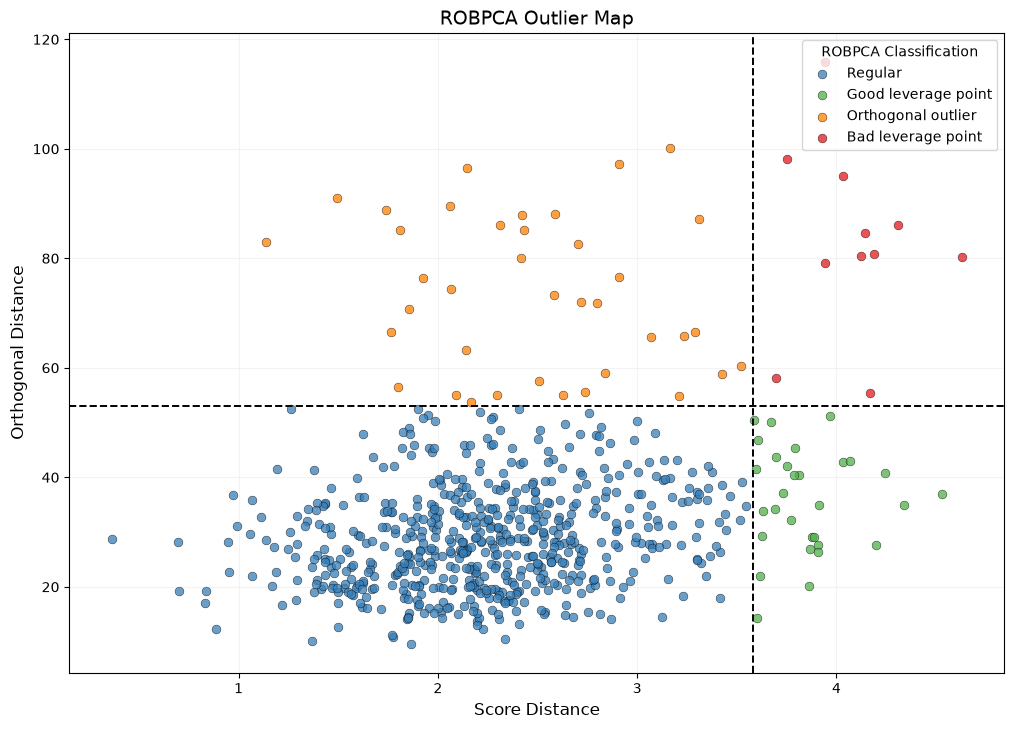

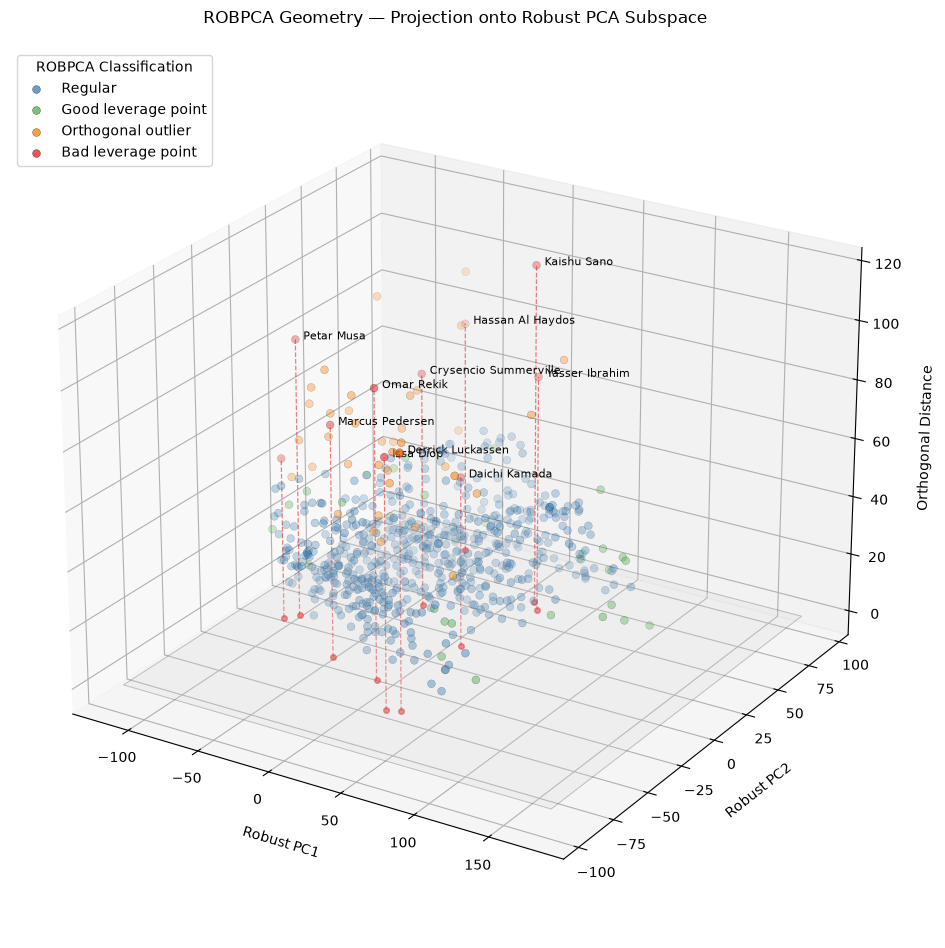


ROBPCA CLASSIFICATION SUMMARY


,classification,player_count,percentage
0,Regular,605,88.45
1,Good leverage point,30,4.39
2,Orthogonal outlier,38,5.56
3,Bad leverage point,11,1.61



PLAYING-TIME DIAGNOSTIC BY ROBPCA CATEGORY

Question:
  Are orthogonal outliers associated with substantially lower playing-time exposure?

Minutes source:
  world_cup_players_final

Primary statistic for interpretation:
  Median minutes



,robpca_classification,N,mean_minutes,median_minutes,Q1_minutes,Q3_minutes,minimum_minutes,maximum_minutes
0,Regular,605,267.23,254.0,166.00,349.0,61,750
1,Good leverage point,30,275.10,255.0,145.75,360.0,76,724
2,Orthogonal outlier,38,223.18,218.5,103.75,300.0,88,480
3,Bad leverage point,11,252.82,236.0,180.00,299.5,57,476



FOCUSED ROBPCA MINUTES COMPARISON

Median minutes — Regular:
  254.00

Median minutes — Good leverage point:
  255.00

Median minutes — Orthogonal outlier:
  218.50

Median minutes — Bad leverage point:
  236.00

Orthogonal outlier median minus Regular median:
  -35.50 minutes

Orthogonal median as proportion of Regular median:
  0.860
  (86.0%)

Orthogonal outlier median minus Good leverage median:
  -36.50 minutes

Orthogonal median as proportion of Good leverage median:
  0.857
  (85.7%)

FULL BAD LEVERAGE POINT TABLE

Bad leverage points: 11
Score-distance cutoff: 3.5822
Orthogonal-distance cutoff: 52.9911


,outlier_rank,sofascore_player,canonical_team_name,fbref_min,robpca_score_distance,robpca_orthogonal_distance,robust_PC1,robust_PC2,robpca_classification
0,1,Kaishu Sano,Japan,270,3.941552,115.875624,29.300396,48.943961,Bad leverage point
1,2,Omar Rekik,Tunisia,180,3.753260,98.189016,5.715954,-42.206722,Bad leverage point
2,3,Petar Musa,Croatia,110,4.033632,95.037424,-82.562501,-10.338376,Bad leverage point
3,4,Derrick Luckassen,Ghana,180,4.311013,86.021303,40.234258,-59.310033,Bad leverage point
4,5,Issa Diop,Morocco,476,4.141697,84.588739,32.274011,-61.789791,Bad leverage point
5,6,Yasser Ibrahim,Egypt,467,4.187239,80.816219,36.716732,43.048541,Bad leverage point
6,7,Crysencio Summerville,Netherlands,253,4.124287,80.359122,-26.372201,22.938444,Bad leverage point
7,8,Hassan Al Haydos,Qatar,57,4.628902,80.151311,-47.015794,75.812726,Bad leverage point
8,9,Marcus Pedersen,Norway,236,3.941513,79.167470,-33.192739,-34.496329,Bad leverage point
9,10,Daichi Kamada,Japan,329,3.694451,58.090268,23.952551,-0.272571,Bad leverage point



STEP 27 COMPLETE

Dataset used:
  world_cup_players_performance_complete_cases (pandas DataFrame)

Players analysed:
  684

Performance variables used:
  74

Regular observations:
  605

Good leverage points:
  30

Orthogonal outliers:
  38

Bad leverage points:
  11

Total flagged:
  79

Percentage flagged:
  11.55%

Minutes source:
  world_cup_players_final

Primary minutes diagnostic:
  minutes_by_robpca_category

Median comparison:
  robpca_minutes_median_comparison

DuckDB diagnostic tables:
  robpca_results_with_minutes
  minutes_by_robpca_category

IMPORTANT:
  No additional observations were removed by the playing-time diagnostic.
  The diagnostic only evaluates whether ROBPCA classification is associated with playing-time exposure.



In [34]:
# ============================================================
# STEP 27 — ROBUST PCA OUTLIER ASSESSMENT (ROBPCA)
# + PLAYING-TIME DIAGNOSTIC BY ROBPCA CATEGORY
# ============================================================
#
# Purpose:
#
#   Run ROBPCA on the complete-case performance dataset.
#
#   Produce:
#
#       1. ROBPCA Outlier Map
#
#          X = Score Distance
#          Y = Orthogonal Distance
#
#       2. Geometric ROBPCA projection visualization
#
#          X = Robust PC1
#          Y = Robust PC2
#          Z = Orthogonal Distance
#
#       3. Full Bad Leverage Point table
#
#       4. Minutes-played diagnostic by ROBPCA category:
#
#          - N
#          - Mean minutes
#          - Median minutes
#          - Q1
#          - Q3
#          - Minimum
#          - Maximum
#
#
# MAIN QUESTION OF NEW DIAGNOSTIC:
#
#   Are orthogonal outliers systematically associated
#   with substantially lower playing-time exposure?
#
#
# IMPORTANT:
#
#   This script DOES NOT remove orthogonal outliers.
#
#   It only evaluates whether ROBPCA classification is
#   associated with playing-time exposure.
#
#
# Published ROBPCA basis:
#
#   Hubert, M., Rousseeuw, P. J.,
#   & Vanden Branden, K. (2005)
#
#   "ROBPCA: A New Approach to Robust Principal
#   Component Analysis"
#
#
# Starting dataset:
#
#   world_cup_players_performance_complete_cases
#
#
# ROBPCA identification columns:
#
#   sofascore_player
#   canonical_team_name
#
#
# Minutes column:
#
#   fbref_min
#
#
# ============================================================


# ============================================================
# 1. INSTALL ROBPY IF NECESSARY
# ============================================================

import sys
import subprocess
import importlib.util


if importlib.util.find_spec("robpy") is None:

    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "robpy"
        ]
    )


# ============================================================
# 2. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt

from mpl_toolkits.mplot3d import Axes3D

from robpy.pca.robpca import ROBPCA

from IPython.display import display


# ============================================================
# 3. FIX MATPLOTLIB FONT ISSUE
# ============================================================

matplotlib.rcParams[
    "font.enable_last_resort"
] = False


matplotlib.rcParams[
    "font.family"
] = "DejaVu Sans"


# ============================================================
# 4. SETTINGS
# ============================================================

PLAYER_COLUMN = (
    "sofascore_player"
)


TEAM_COLUMN = (
    "canonical_team_name"
)


MINUTES_COLUMN = (
    "fbref_min"
)


IDENTIFIER_COLUMNS = [
    PLAYER_COLUMN,
    TEAM_COLUMN
]


# ============================================================
# 5. LOAD COMPLETE-CASE PERFORMANCE DATASET
# ============================================================

try:

    source_df = (
        world_cup_players_performance_complete_cases
        .copy()
    )

    SOURCE_NAME = (
        "world_cup_players_performance_complete_cases "
        "(pandas DataFrame)"
    )


except NameError:

    try:

        source_df = con.sql("""
            SELECT *
            FROM world_cup_players_performance_complete_cases
        """).df()

        SOURCE_NAME = (
            "world_cup_players_performance_complete_cases "
            "(DuckDB table)"
        )


    except Exception as exc:

        raise RuntimeError(
            "Could not find "
            "`world_cup_players_performance_complete_cases`."
        ) from exc


# ============================================================
# 6. VERIFY IDENTIFICATION COLUMNS EXIST
# ============================================================

missing_identifier_columns = [
    column
    for column
    in IDENTIFIER_COLUMNS
    if column
    not in source_df.columns
]


if missing_identifier_columns:

    raise RuntimeError(
        "Missing required identification columns:\n"
        +
        "\n".join(
            missing_identifier_columns
        )
    )


# ============================================================
# 7. CREATE A CLEAN PLAYER-IDENTITY KEY
# ============================================================
#
# We use:
#
#   sofascore_player
#   canonical_team_name
#
# to attach fbref_min later.
#
# ============================================================

player_identity_df = (

    source_df[
        IDENTIFIER_COLUMNS
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


# ============================================================
# 8. REMOVE KNOWN ZERO-VARIANCE VARIABLE
# ============================================================

ZERO_VARIANCE_COLUMNS_TO_REMOVE = [
    "squawka_other_goals_per_90"
]


removed_zero_variance_columns = []


for column in ZERO_VARIANCE_COLUMNS_TO_REMOVE:

    if column in source_df.columns:

        source_df = (
            source_df
            .drop(
                columns=[
                    column
                ]
            )
        )

        removed_zero_variance_columns.append(
            column
        )


# ============================================================
# 9. IDENTIFY ROBPCA PERFORMANCE VARIABLES
# ============================================================

pca_variables = [
    column
    for column
    in source_df.columns
    if column not in IDENTIFIER_COLUMNS
]


if len(pca_variables) == 0:

    raise RuntimeError(
        "No PCA performance variables were found."
    )


# ============================================================
# 10. IMPORTANT:
#     REMOVE MINUTES FROM ROBPCA IF PRESENT
# ============================================================
#
# fbref_min is being used only as a DIAGNOSTIC variable.
#
# It must NOT accidentally become a performance variable in
# the ROBPCA analysis.
#
# ============================================================

if MINUTES_COLUMN in pca_variables:

    pca_variables.remove(
        MINUTES_COLUMN
    )


# ============================================================
# 11. VERIFY PERFORMANCE VARIABLES ARE NUMERIC
# ============================================================

non_numeric_variables = [
    column
    for column
    in pca_variables
    if not pd.api.types.is_numeric_dtype(
        source_df[
            column
        ]
    )
]


if non_numeric_variables:

    raise RuntimeError(
        "Non-numeric PCA variables found:\n"
        +
        "\n".join(
            non_numeric_variables
        )
    )


# ============================================================
# 12. CREATE ROBPCA MATRIX
# ============================================================

X_df = (
    source_df[
        pca_variables
    ]
    .copy()
)


X_df = (
    X_df
    .replace(
        [
            np.inf,
            -np.inf
        ],
        np.nan
    )
)


# ============================================================
# 13. VERIFY NO MISSING VALUES REMAIN
# ============================================================

missing_count = int(
    X_df
    .isna()
    .sum()
    .sum()
)


if missing_count > 0:

    missing_by_variable = (
        X_df
        .isna()
        .sum()
    )


    missing_by_variable = (
        missing_by_variable[
            missing_by_variable > 0
        ]
        .sort_values(
            ascending=False
        )
    )


    display(
        missing_by_variable
        .rename(
            "missing_count"
        )
        .to_frame()
    )


    raise RuntimeError(
        "The ROBPCA matrix still contains missing "
        "or infinite values."
    )


# ============================================================
# 14. CHECK FOR ADDITIONAL ZERO-VARIANCE VARIABLES
# ============================================================

additional_zero_variance_variables = [
    column
    for column
    in pca_variables
    if X_df[
        column
    ].nunique(
        dropna=True
    ) <= 1
]


if additional_zero_variance_variables:

    print(
        "\nAdditional zero-variance variables found:"
    )


    for variable in additional_zero_variance_variables:

        print(
            f"  {variable}"
        )


    raise RuntimeError(
        "Additional zero-variance variables remain."
    )


# ============================================================
# 15. CONVERT TO NUMPY MATRIX
# ============================================================

X = (
    X_df
    .to_numpy(
        dtype=float
    )
)


N = X.shape[
    0
]


p = X.shape[
    1
]


# ============================================================
# 16. RUN ROBPCA
# ============================================================

robpca_model = ROBPCA(
    n_components=None,
    k_min_var_explained=0.80,
    alpha=0.75,
    final_MCD_step=True,
    random_seed=42
)


robpca_model.fit(
    X
)


# ============================================================
# 17. OBTAIN SCORE DISTANCE AND ORTHOGONAL DISTANCE
# ============================================================

(
    score_distances,
    orthogonal_distances,
    score_distance_cutoff,
    orthogonal_distance_cutoff
) = robpca_model.plot_outlier_map(
    X,
    return_distances=True
)


plt.close(
    "all"
)


score_distances = (
    np.asarray(
        score_distances
    )
    .reshape(
        -1
    )
)


orthogonal_distances = (
    np.asarray(
        orthogonal_distances
    )
    .reshape(
        -1
    )
)


score_distance_cutoff = float(
    score_distance_cutoff
)


orthogonal_distance_cutoff = float(
    orthogonal_distance_cutoff
)


# ============================================================
# 18. CLASSIFY EACH OBSERVATION
# ============================================================

def classify_robpca_observation(
    score_distance,
    orthogonal_distance
):

    high_score_distance = (
        score_distance
        > score_distance_cutoff
    )


    high_orthogonal_distance = (
        orthogonal_distance
        > orthogonal_distance_cutoff
    )


    if (
        not high_score_distance
        and
        not high_orthogonal_distance
    ):

        return (
            "Regular"
        )


    elif (
        high_score_distance
        and
        not high_orthogonal_distance
    ):

        return (
            "Good leverage point"
        )


    elif (
        not high_score_distance
        and
        high_orthogonal_distance
    ):

        return (
            "Orthogonal outlier"
        )


    else:

        return (
            "Bad leverage point"
        )


# ============================================================
# 19. CREATE PLAYER-LEVEL ROBPCA RESULTS
# ============================================================

robpca_results = (
    player_identity_df
    .copy()
    .reset_index(
        drop=True
    )
)


robpca_results[
    "robpca_score_distance"
] = (
    score_distances
)


robpca_results[
    "robpca_orthogonal_distance"
] = (
    orthogonal_distances
)


robpca_results[
    "robpca_classification"
] = [

    classify_robpca_observation(
        score_distance,
        orthogonal_distance
    )

    for (
        score_distance,
        orthogonal_distance
    )

    in zip(
        score_distances,
        orthogonal_distances
    )
]


# ============================================================
# 20. FUNCTION — CREATE SAFE MINUTES LOOKUP
# ============================================================
#
# Purpose:
#
#   Create one fbref_min value for each:
#
#       player + team
#
#   If duplicate player/team combinations contain conflicting
#   minute values, STOP instead of silently choosing one.
#
# ============================================================

def create_minutes_lookup(
    candidate_df,
    source_name
):

    required_columns = [
        PLAYER_COLUMN,
        TEAM_COLUMN,
        MINUTES_COLUMN
    ]


    if not all(
        column in candidate_df.columns
        for column in required_columns
    ):

        return None


    lookup = (

        candidate_df[
            required_columns
        ]

        .copy()
    )


    lookup[
        MINUTES_COLUMN
    ] = pd.to_numeric(
        lookup[
            MINUTES_COLUMN
        ],
        errors="coerce"
    )


    # --------------------------------------------------------
    # Check duplicate key consistency
    # --------------------------------------------------------

    duplicate_consistency = (

        lookup

        .groupby(
            [
                PLAYER_COLUMN,
                TEAM_COLUMN
            ],
            dropna=False
        )[
            MINUTES_COLUMN
        ]

        .nunique(
            dropna=False
        )
    )


    conflicting_keys = (
        duplicate_consistency[
            duplicate_consistency > 1
        ]
    )


    if len(
        conflicting_keys
    ) > 0:

        raise RuntimeError(
            "Conflicting minutes values were found for the "
            "same player/team combination in:\n\n"
            f"  {source_name}\n\n"
            "Do not attach minutes until these conflicts "
            "have been resolved."
        )


    lookup = (

        lookup

        .drop_duplicates(
            subset=[
                PLAYER_COLUMN,
                TEAM_COLUMN
            ]
        )

        .reset_index(
            drop=True
        )
    )


    return lookup


# ============================================================
# 21. ATTACH MINUTES TO ROBPCA RESULTS
# ============================================================
#
# Priority:
#
#   1. source_df itself, if fbref_min exists
#
#   2. world_cup_players_final
#
#   3. other likely aligned DataFrames
#
#   4. DuckDB fallback
#
#
# IMPORTANT:
#
# fbref_min is NOT used to fit ROBPCA.
#
# ============================================================

minutes_lookup = None

MINUTES_SOURCE_NAME = None


# ------------------------------------------------------------
# Candidate pandas DataFrames
# ------------------------------------------------------------

POSSIBLE_MINUTES_DATAFRAMES = [

    (
        "source_df",
        source_df
    )
]


possible_global_dataframe_names = [

    "world_cup_players_final",

    "world_cup_players_performance_only",

    "world_cup_players_performance_complete_cases",

    "world_cup_players_master_three_source_per90_no_gk",

    "world_cup_players_master_three_source_per90"
]


for dataframe_name in possible_global_dataframe_names:

    if dataframe_name in globals():

        candidate_object = globals()[
            dataframe_name
        ]


        if isinstance(
            candidate_object,
            pd.DataFrame
        ):

            POSSIBLE_MINUTES_DATAFRAMES.append(
                (
                    dataframe_name,
                    candidate_object
                )
            )


for (
    dataframe_name,
    candidate_dataframe
) in POSSIBLE_MINUTES_DATAFRAMES:

    candidate_lookup = (
        create_minutes_lookup(
            candidate_dataframe,
            dataframe_name
        )
    )


    if candidate_lookup is None:

        continue


    test_merge = (

        robpca_results[
            [
                PLAYER_COLUMN,
                TEAM_COLUMN
            ]
        ]

        .merge(
            candidate_lookup,
            on=[
                PLAYER_COLUMN,
                TEAM_COLUMN
            ],
            how="left",
            validate="one_to_one"
        )
    )


    recovered_minutes = int(
        test_merge[
            MINUTES_COLUMN
        ]
        .notna()
        .sum()
    )


    if recovered_minutes == len(
        robpca_results
    ):

        minutes_lookup = (
            candidate_lookup
        )


        MINUTES_SOURCE_NAME = (
            dataframe_name
        )


        break


# ------------------------------------------------------------
# DuckDB fallback
# ------------------------------------------------------------

if minutes_lookup is None:

    try:

        available_objects = set(
            con.sql("""
                SELECT table_name
                FROM information_schema.tables

                UNION

                SELECT table_name
                FROM information_schema.views
            """).df()[
                "table_name"
            ].tolist()
        )


        POSSIBLE_MINUTES_TABLES = [

            "world_cup_players_final",

            "world_cup_players_performance_only",

            "world_cup_players_performance_complete_cases",

            "world_cup_players_master_three_source_per90_no_gk",

            "world_cup_players_master_three_source_per90"
        ]


        for table_name in POSSIBLE_MINUTES_TABLES:

            if table_name not in available_objects:

                continue


            table_columns = con.sql(
                f"""
                DESCRIBE "{table_name}"
                """
            ).df()[
                "column_name"
            ].tolist()


            required_minutes_columns = [
                PLAYER_COLUMN,
                TEAM_COLUMN,
                MINUTES_COLUMN
            ]


            if not all(
                column in table_columns
                for column in required_minutes_columns
            ):

                continue


            candidate_dataframe = con.sql(
                f"""
                SELECT
                    "{PLAYER_COLUMN}",
                    "{TEAM_COLUMN}",
                    "{MINUTES_COLUMN}"

                FROM "{table_name}"
                """
            ).df()


            candidate_lookup = (
                create_minutes_lookup(
                    candidate_dataframe,
                    f"{table_name} (DuckDB)"
                )
            )


            test_merge = (

                robpca_results[
                    [
                        PLAYER_COLUMN,
                        TEAM_COLUMN
                    ]
                ]

                .merge(
                    candidate_lookup,
                    on=[
                        PLAYER_COLUMN,
                        TEAM_COLUMN
                    ],
                    how="left",
                    validate="one_to_one"
                )
            )


            recovered_minutes = int(
                test_merge[
                    MINUTES_COLUMN
                ]
                .notna()
                .sum()
            )


            if recovered_minutes == len(
                robpca_results
            ):

                minutes_lookup = (
                    candidate_lookup
                )


                MINUTES_SOURCE_NAME = (
                    f"{table_name} (DuckDB)"
                )


                break


    except Exception:

        pass


# ============================================================
# 22. REQUIRE MINUTES FOR THIS DIAGNOSTIC
# ============================================================

if minutes_lookup is None:

    raise RuntimeError(
        "ROBPCA completed, but `fbref_min` could not be "
        "matched to every ROBPCA observation.\n\n"
        "The new playing-time diagnostic therefore cannot "
        "be performed safely."
    )


# ============================================================
# 23. MERGE MINUTES INTO ROBPCA RESULTS
# ============================================================

robpca_results = (

    robpca_results

    .merge(
        minutes_lookup,
        on=[
            PLAYER_COLUMN,
            TEAM_COLUMN
        ],
        how="left",
        validate="one_to_one"
    )
)


robpca_results[
    MINUTES_COLUMN
] = pd.to_numeric(
    robpca_results[
        MINUTES_COLUMN
    ],
    errors="coerce"
)


missing_minutes_after_merge = int(
    robpca_results[
        MINUTES_COLUMN
    ]
    .isna()
    .sum()
)


if missing_minutes_after_merge > 0:

    raise RuntimeError(
        "Some ROBPCA observations are still missing minutes "
        "after the merge.\n\n"
        f"Missing minutes: "
        f"{missing_minutes_after_merge:,}"
    )


print(
    "\nMinutes successfully attached from:"
)


print(
    f"  {MINUTES_SOURCE_NAME}"
)


# ============================================================
# 24. DEFINE COLORS
# ============================================================

CLASS_COLORS = {

    "Regular":
        "#377eb8",

    "Good leverage point":
        "#4daf4a",

    "Orthogonal outlier":
        "#ff7f00",

    "Bad leverage point":
        "#e41a1c"
}


CLASS_ORDER = [

    "Regular",

    "Good leverage point",

    "Orthogonal outlier",

    "Bad leverage point"
]


# ============================================================
# 25. GRAPH 1 — ROBPCA OUTLIER MAP
# ============================================================

fig, ax = plt.subplots(
    figsize=(
        11,
        8
    )
)


for classification in CLASS_ORDER:

    mask = (
        robpca_results[
            "robpca_classification"
        ]
        == classification
    )


    ax.scatter(
        robpca_results.loc[
            mask,
            "robpca_score_distance"
        ],

        robpca_results.loc[
            mask,
            "robpca_orthogonal_distance"
        ],

        label=classification,

        color=CLASS_COLORS[
            classification
        ],

        s=40,

        alpha=0.75,

        edgecolors="black",

        linewidths=0.35
    )


ax.axvline(
    x=score_distance_cutoff,
    color="black",
    linestyle="--",
    linewidth=1.4
)


ax.axhline(
    y=orthogonal_distance_cutoff,
    color="black",
    linestyle="--",
    linewidth=1.4
)


ax.set_xlabel(
    "Score Distance",
    fontsize=12
)


ax.set_ylabel(
    "Orthogonal Distance",
    fontsize=12
)


ax.set_title(
    "ROBPCA Outlier Map",
    fontsize=14
)


ax.legend(
    title="ROBPCA Classification",
    loc="upper right"
)


ax.grid(
    alpha=0.15
)


fig.subplots_adjust(
    left=0.11,
    right=0.96,
    bottom=0.11,
    top=0.91
)


plt.show()


# ============================================================
# 26. OBTAIN ROBUST COMPONENT SCORES
# ============================================================

robust_scores = (
    robpca_model
    .transform(
        X
    )
)


robust_scores = (
    np.asarray(
        robust_scores
    )
)


# ============================================================
# 27. VERIFY AT LEAST TWO COMPONENTS EXIST
# ============================================================

if robust_scores.shape[
    1
] < 2:

    raise RuntimeError(
        "ROBPCA retained fewer than two components, so the "
        "geometric ROBPCA visualization cannot be created."
    )


# ============================================================
# 28. ADD ROBUST PC1 AND PC2 SCORES
# ============================================================

robpca_results[
    "robust_PC1"
] = (
    robust_scores[
        :,
        0
    ]
)


robpca_results[
    "robust_PC2"
] = (
    robust_scores[
        :,
        1
    ]
)


# ============================================================
# 29. CREATE BAD LEVERAGE POINT TABLE
# ============================================================

bad_leverage_points = (
    robpca_results[
        robpca_results[
            "robpca_classification"
        ]
        == "Bad leverage point"
    ]
    .copy()
)


bad_leverage_points = (
    bad_leverage_points
    .sort_values(
        by=[
            "robpca_orthogonal_distance",
            "robpca_score_distance"
        ],
        ascending=[
            False,
            False
        ]
    )
    .reset_index(
        drop=True
    )
)


bad_leverage_points.insert(
    0,
    "outlier_rank",
    range(
        1,
        len(
            bad_leverage_points
        )
        + 1
    )
)


# ============================================================
# 30. GRAPH 2 — GEOMETRIC ROBPCA PROJECTION
# ============================================================

fig = plt.figure(
    figsize=(
        13,
        10
    )
)


ax = fig.add_subplot(
    111,
    projection="3d"
)


# ============================================================
# 31. DEFINE ROBUST PCA PLANE
# ============================================================

pc1_min = (
    robpca_results[
        "robust_PC1"
    ]
    .min()
)


pc1_max = (
    robpca_results[
        "robust_PC1"
    ]
    .max()
)


pc2_min = (
    robpca_results[
        "robust_PC2"
    ]
    .min()
)


pc2_max = (
    robpca_results[
        "robust_PC2"
    ]
    .max()
)


pc1_padding = (
    (
        pc1_max
        - pc1_min
    )
    * 0.08
)


pc2_padding = (
    (
        pc2_max
        - pc2_min
    )
    * 0.08
)


plane_x = np.linspace(
    pc1_min - pc1_padding,
    pc1_max + pc1_padding,
    2
)


plane_y = np.linspace(
    pc2_min - pc2_padding,
    pc2_max + pc2_padding,
    2
)


plane_X, plane_Y = np.meshgrid(
    plane_x,
    plane_y
)


plane_Z = np.zeros_like(
    plane_X
)


# ============================================================
# 32. DRAW ROBUST PCA PLANE
# ============================================================

ax.plot_surface(
    plane_X,
    plane_Y,
    plane_Z,

    color="#d9d9d9",

    alpha=0.22,

    edgecolor="black",

    linewidth=0.7,

    shade=False
)


# ============================================================
# 33. PLOT ALL OBSERVATIONS
# ============================================================

for classification in CLASS_ORDER:

    mask = (
        robpca_results[
            "robpca_classification"
        ]
        == classification
    )


    ax.scatter(
        robpca_results.loc[
            mask,
            "robust_PC1"
        ],

        robpca_results.loc[
            mask,
            "robust_PC2"
        ],

        robpca_results.loc[
            mask,
            "robpca_orthogonal_distance"
        ],

        color=CLASS_COLORS[
            classification
        ],

        label=classification,

        s=32,

        alpha=0.75,

        edgecolors="black",

        linewidths=0.25
    )


# ============================================================
# 34. DRAW PROJECTION LINES FOR BAD LEVERAGE POINTS
# ============================================================

for _, row in bad_leverage_points.iterrows():

    x_value = (
        row[
            "robust_PC1"
        ]
    )

    y_value = (
        row[
            "robust_PC2"
        ]
    )

    z_value = (
        row[
            "robpca_orthogonal_distance"
        ]
    )


    ax.plot(
        [
            x_value,
            x_value
        ],

        [
            y_value,
            y_value
        ],

        [
            0,
            z_value
        ],

        linestyle="--",

        color=CLASS_COLORS[
            "Bad leverage point"
        ],

        linewidth=0.9,

        alpha=0.55
    )


    ax.scatter(
        [
            x_value
        ],

        [
            y_value
        ],

        [
            0
        ],

        color=CLASS_COLORS[
            "Bad leverage point"
        ],

        s=16,

        alpha=0.75
    )


# ============================================================
# 35. LABEL MOST EXTREME BAD LEVERAGE POINTS
# ============================================================

NUMBER_TO_LABEL = (
    10
)


bad_leverage_to_label = (
    bad_leverage_points
    .head(
        NUMBER_TO_LABEL
    )
)


for _, row in bad_leverage_to_label.iterrows():

    ax.text(
        row[
            "robust_PC1"
        ],

        row[
            "robust_PC2"
        ],

        row[
            "robpca_orthogonal_distance"
        ],

        "  "
        + str(
            row[
                PLAYER_COLUMN
            ]
        ),

        fontsize=8,

        color="black"
    )


# ============================================================
# 36. FORMAT GEOMETRIC ROBPCA PLOT
# ============================================================

ax.set_xlabel(
    "Robust PC1",
    labelpad=10
)


ax.set_ylabel(
    "Robust PC2",
    labelpad=10
)


ax.set_zlabel(
    "Orthogonal Distance",
    labelpad=10
)


ax.set_title(
    "ROBPCA Geometry — Projection onto Robust PCA Subspace",
    pad=18
)


ax.legend(
    title="ROBPCA Classification",
    loc="upper left"
)


ax.view_init(
    elev=24,
    azim=-58
)


fig.subplots_adjust(
    left=0.02,
    right=0.90,
    bottom=0.03,
    top=0.92
)


plt.show()


# ============================================================
# 37. CREATE CLASSIFICATION SUMMARY
# ============================================================

classification_counts = (
    robpca_results[
        "robpca_classification"
    ]
    .value_counts()
    .reindex(
        CLASS_ORDER,
        fill_value=0
    )
    .rename_axis(
        "classification"
    )
    .reset_index(
        name="player_count"
    )
)


classification_counts[
    "percentage"
] = (
    classification_counts[
        "player_count"
    ]
    / len(
        robpca_results
    )
    * 100
)


classification_counts[
    "percentage"
] = (
    classification_counts[
        "percentage"
    ]
    .round(
        2
    )
)


# ============================================================
# 38. PRINT CLASSIFICATION SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 100
)


print(
    "ROBPCA CLASSIFICATION SUMMARY"
)


print(
    "=" * 100
)


display(
    classification_counts
)


# ============================================================
# 39. NEW ANALYSIS:
#     MINUTES PLAYED BY ROBPCA CATEGORY
# ============================================================
#
# This is the focused diagnostic we agreed on.
#
# For each ROBPCA category report:
#
#   N
#   Mean
#   Median
#   Q1
#   Q3
#   Minimum
#   Maximum
#
#
# PRIMARY descriptive quantity:
#
#   MEDIAN MINUTES
#
# because playing-time distributions can be strongly skewed.
#
# ============================================================

minutes_by_robpca_category = (

    robpca_results

    .groupby(
        "robpca_classification"
    )[
        MINUTES_COLUMN
    ]

    .agg(
        N="count",

        mean_minutes="mean",

        median_minutes="median",

        minimum_minutes="min",

        maximum_minutes="max"
    )

    .reset_index()
)


# ------------------------------------------------------------
# Add Q1
# ------------------------------------------------------------

q1_minutes = (

    robpca_results

    .groupby(
        "robpca_classification"
    )[
        MINUTES_COLUMN
    ]

    .quantile(
        0.25
    )

    .rename(
        "Q1_minutes"
    )

    .reset_index()
)


# ------------------------------------------------------------
# Add Q3
# ------------------------------------------------------------

q3_minutes = (

    robpca_results

    .groupby(
        "robpca_classification"
    )[
        MINUTES_COLUMN
    ]

    .quantile(
        0.75
    )

    .rename(
        "Q3_minutes"
    )

    .reset_index()
)


minutes_by_robpca_category = (

    minutes_by_robpca_category

    .merge(
        q1_minutes,
        on="robpca_classification",
        how="left"
    )

    .merge(
        q3_minutes,
        on="robpca_classification",
        how="left"
    )
)


# ============================================================
# 40. REORDER COLUMNS
# ============================================================

minutes_by_robpca_category = (

    minutes_by_robpca_category[
        [
            "robpca_classification",
            "N",
            "mean_minutes",
            "median_minutes",
            "Q1_minutes",
            "Q3_minutes",
            "minimum_minutes",
            "maximum_minutes"
        ]
    ]
)


# ============================================================
# 41. ORDER ROBPCA CATEGORIES CONSISTENTLY
# ============================================================

minutes_by_robpca_category[
    "robpca_classification"
] = pd.Categorical(
    minutes_by_robpca_category[
        "robpca_classification"
    ],
    categories=CLASS_ORDER,
    ordered=True
)


minutes_by_robpca_category = (

    minutes_by_robpca_category

    .sort_values(
        "robpca_classification"
    )

    .reset_index(
        drop=True
    )
)


# ============================================================
# 42. ROUND DESCRIPTIVE STATISTICS
# ============================================================

minutes_columns_to_round = [

    "mean_minutes",

    "median_minutes",

    "Q1_minutes",

    "Q3_minutes",

    "minimum_minutes",

    "maximum_minutes"
]


minutes_by_robpca_category[
    minutes_columns_to_round
] = (

    minutes_by_robpca_category[
        minutes_columns_to_round
    ]

    .round(
        2
    )
)


# ============================================================
# 43. PRINT MINUTES DIAGNOSTIC
# ============================================================

print(
    "\n"
    + "=" * 120
)


print(
    "PLAYING-TIME DIAGNOSTIC BY ROBPCA CATEGORY"
)


print(
    "=" * 120
)


print(
    "\nQuestion:"
)


print(
    "  Are orthogonal outliers associated with "
    "substantially lower playing-time exposure?"
)


print(
    "\nMinutes source:"
)


print(
    f"  {MINUTES_SOURCE_NAME}"
)


print(
    "\nPrimary statistic for interpretation:"
)


print(
    "  Median minutes"
)


print()


display(
    minutes_by_robpca_category
)


# ============================================================
# 44. FOCUSED MEDIAN COMPARISON
# ============================================================
#
# We compare:
#
#   Orthogonal outliers
#
# against:
#
#   Regular observations
#
# and:
#
#   Good leverage points
#
#
# No hypothesis test is performed here.
#
# This is deliberately a descriptive diagnostic.
#
# ============================================================

def get_category_median(
    category_name
):

    matching_rows = (

        minutes_by_robpca_category[
            minutes_by_robpca_category[
                "robpca_classification"
            ]
            ==
            category_name
        ]
    )


    if matching_rows.empty:

        return np.nan


    return float(
        matching_rows.iloc[
            0
        ][
            "median_minutes"
        ]
    )


regular_median_minutes = (
    get_category_median(
        "Regular"
    )
)


good_leverage_median_minutes = (
    get_category_median(
        "Good leverage point"
    )
)


orthogonal_median_minutes = (
    get_category_median(
        "Orthogonal outlier"
    )
)


bad_leverage_median_minutes = (
    get_category_median(
        "Bad leverage point"
    )
)


# ============================================================
# 45. CALCULATE DESCRIPTIVE DIFFERENCES
# ============================================================

orthogonal_vs_regular_difference = np.nan


orthogonal_vs_good_difference = np.nan


orthogonal_vs_regular_ratio = np.nan


orthogonal_vs_good_ratio = np.nan


if (
    np.isfinite(
        orthogonal_median_minutes
    )
    and
    np.isfinite(
        regular_median_minutes
    )
):

    orthogonal_vs_regular_difference = (
        orthogonal_median_minutes
        -
        regular_median_minutes
    )


    if regular_median_minutes != 0:

        orthogonal_vs_regular_ratio = (
            orthogonal_median_minutes
            /
            regular_median_minutes
        )


if (
    np.isfinite(
        orthogonal_median_minutes
    )
    and
    np.isfinite(
        good_leverage_median_minutes
    )
):

    orthogonal_vs_good_difference = (
        orthogonal_median_minutes
        -
        good_leverage_median_minutes
    )


    if good_leverage_median_minutes != 0:

        orthogonal_vs_good_ratio = (
            orthogonal_median_minutes
            /
            good_leverage_median_minutes
        )


# ============================================================
# 46. PRINT FOCUSED MEDIAN RESULTS
# ============================================================

print(
    "\n"
    + "=" * 120
)


print(
    "FOCUSED ROBPCA MINUTES COMPARISON"
)


print(
    "=" * 120
)


print(
    "\nMedian minutes — Regular:"
)


if np.isfinite(
    regular_median_minutes
):

    print(
        f"  {regular_median_minutes:,.2f}"
    )

else:

    print(
        "  Category not present"
    )


print(
    "\nMedian minutes — Good leverage point:"
)


if np.isfinite(
    good_leverage_median_minutes
):

    print(
        f"  {good_leverage_median_minutes:,.2f}"
    )

else:

    print(
        "  Category not present"
    )


print(
    "\nMedian minutes — Orthogonal outlier:"
)


if np.isfinite(
    orthogonal_median_minutes
):

    print(
        f"  {orthogonal_median_minutes:,.2f}"
    )

else:

    print(
        "  Category not present"
    )


print(
    "\nMedian minutes — Bad leverage point:"
)


if np.isfinite(
    bad_leverage_median_minutes
):

    print(
        f"  {bad_leverage_median_minutes:,.2f}"
    )

else:

    print(
        "  Category not present"
    )


# ------------------------------------------------------------
# Orthogonal vs Regular
# ------------------------------------------------------------

if np.isfinite(
    orthogonal_vs_regular_difference
):

    print(
        "\nOrthogonal outlier median minus "
        "Regular median:"
    )


    print(
        f"  "
        f"{orthogonal_vs_regular_difference:,.2f} minutes"
    )


if np.isfinite(
    orthogonal_vs_regular_ratio
):

    print(
        "\nOrthogonal median as proportion "
        "of Regular median:"
    )


    print(
        f"  "
        f"{orthogonal_vs_regular_ratio:.3f}"
    )


    print(
        f"  "
        f"({orthogonal_vs_regular_ratio * 100:.1f}%)"
    )


# ------------------------------------------------------------
# Orthogonal vs Good Leverage
# ------------------------------------------------------------

if np.isfinite(
    orthogonal_vs_good_difference
):

    print(
        "\nOrthogonal outlier median minus "
        "Good leverage median:"
    )


    print(
        f"  "
        f"{orthogonal_vs_good_difference:,.2f} minutes"
    )


if np.isfinite(
    orthogonal_vs_good_ratio
):

    print(
        "\nOrthogonal median as proportion "
        "of Good leverage median:"
    )


    print(
        f"  "
        f"{orthogonal_vs_good_ratio:.3f}"
    )


    print(
        f"  "
        f"({orthogonal_vs_good_ratio * 100:.1f}%)"
    )


# ============================================================
# 47. CREATE SMALL MEDIAN-COMPARISON TABLE
# ============================================================

robpca_minutes_median_comparison = pd.DataFrame(
    [
        {
            "robpca_classification":
                "Regular",

            "median_minutes":
                regular_median_minutes
        },

        {
            "robpca_classification":
                "Good leverage point",

            "median_minutes":
                good_leverage_median_minutes
        },

        {
            "robpca_classification":
                "Orthogonal outlier",

            "median_minutes":
                orthogonal_median_minutes
        },

        {
            "robpca_classification":
                "Bad leverage point",

            "median_minutes":
                bad_leverage_median_minutes
        }
    ]
)


# ============================================================
# 48. PRINT FULL BAD LEVERAGE POINT TABLE
# ============================================================

print(
    "\n"
    + "=" * 120
)


print(
    "FULL BAD LEVERAGE POINT TABLE"
)


print(
    "=" * 120
)


print(
    f"\nBad leverage points: "
    f"{len(bad_leverage_points):,}"
)


print(
    f"Score-distance cutoff: "
    f"{score_distance_cutoff:.4f}"
)


print(
    f"Orthogonal-distance cutoff: "
    f"{orthogonal_distance_cutoff:.4f}"
)


previous_max_rows = pd.get_option(
    "display.max_rows"
)


previous_max_columns = pd.get_option(
    "display.max_columns"
)


previous_width = pd.get_option(
    "display.width"
)


previous_max_colwidth = pd.get_option(
    "display.max_colwidth"
)


pd.set_option(
    "display.max_rows",
    None
)


pd.set_option(
    "display.max_columns",
    None
)


pd.set_option(
    "display.width",
    300
)


pd.set_option(
    "display.max_colwidth",
    None
)


display(
    bad_leverage_points[
        [
            "outlier_rank",
            PLAYER_COLUMN,
            TEAM_COLUMN,
            MINUTES_COLUMN,
            "robpca_score_distance",
            "robpca_orthogonal_distance",
            "robust_PC1",
            "robust_PC2",
            "robpca_classification"
        ]
    ]
)


pd.set_option(
    "display.max_rows",
    previous_max_rows
)


pd.set_option(
    "display.max_columns",
    previous_max_columns
)


pd.set_option(
    "display.width",
    previous_width
)


pd.set_option(
    "display.max_colwidth",
    previous_max_colwidth
)


# ============================================================
# 49. SAVE DIAGNOSTIC TABLES TO DUCKDB IF AVAILABLE
# ============================================================

try:

    con

    duckdb_available = True


except NameError:

    duckdb_available = False


if duckdb_available:

    # --------------------------------------------------------
    # Full ROBPCA results including minutes
    # --------------------------------------------------------

    try:

        con.unregister(
            "robpca_results_with_minutes_df"
        )

    except Exception:

        pass


    con.register(
        "robpca_results_with_minutes_df",
        robpca_results
    )


    con.sql("""
        CREATE OR REPLACE TABLE
            robpca_results_with_minutes
        AS

        SELECT *
        FROM
            robpca_results_with_minutes_df
    """)


    # --------------------------------------------------------
    # Minutes summary
    # --------------------------------------------------------

    try:

        con.unregister(
            "minutes_by_robpca_category_df"
        )

    except Exception:

        pass


    con.register(
        "minutes_by_robpca_category_df",
        minutes_by_robpca_category
    )


    con.sql("""
        CREATE OR REPLACE TABLE
            minutes_by_robpca_category
        AS

        SELECT *
        FROM
            minutes_by_robpca_category_df
    """)


# ============================================================
# 50. FINAL COUNTS
# ============================================================

regular_count = int(
    (
        robpca_results[
            "robpca_classification"
        ]
        == "Regular"
    )
    .sum()
)


good_leverage_count = int(
    (
        robpca_results[
            "robpca_classification"
        ]
        == "Good leverage point"
    )
    .sum()
)


orthogonal_outlier_count = int(
    (
        robpca_results[
            "robpca_classification"
        ]
        == "Orthogonal outlier"
    )
    .sum()
)


bad_leverage_count = int(
    (
        robpca_results[
            "robpca_classification"
        ]
        == "Bad leverage point"
    )
    .sum()
)


total_flagged = (
    good_leverage_count
    + orthogonal_outlier_count
    + bad_leverage_count
)


percentage_flagged = (
    total_flagged
    / N
    * 100
)


# ============================================================
# 51. FINAL STEP 27 SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 100
)


print(
    "STEP 27 COMPLETE"
)


print(
    "=" * 100
)


print(
    "\nDataset used:"
)


print(
    f"  {SOURCE_NAME}"
)


print(
    "\nPlayers analysed:"
)


print(
    f"  {N:,}"
)


print(
    "\nPerformance variables used:"
)


print(
    f"  {p:,}"
)


print(
    "\nRegular observations:"
)


print(
    f"  {regular_count:,}"
)


print(
    "\nGood leverage points:"
)


print(
    f"  {good_leverage_count:,}"
)


print(
    "\nOrthogonal outliers:"
)


print(
    f"  {orthogonal_outlier_count:,}"
)


print(
    "\nBad leverage points:"
)


print(
    f"  {bad_leverage_count:,}"
)


print(
    "\nTotal flagged:"
)


print(
    f"  {total_flagged:,}"
)


print(
    "\nPercentage flagged:"
)


print(
    f"  {percentage_flagged:.2f}%"
)


print(
    "\nMinutes source:"
)


print(
    f"  {MINUTES_SOURCE_NAME}"
)


print(
    "\nPrimary minutes diagnostic:"
)


print(
    "  minutes_by_robpca_category"
)


print(
    "\nMedian comparison:"
)


print(
    "  robpca_minutes_median_comparison"
)


if duckdb_available:

    print(
        "\nDuckDB diagnostic tables:"
    )


    print(
        "  robpca_results_with_minutes"
    )


    print(
        "  minutes_by_robpca_category"
    )


print(
    "\nIMPORTANT:"
)


print(
    "  No additional observations were removed by the "
    "playing-time diagnostic."
)


print(
    "  The diagnostic only evaluates whether ROBPCA "
    "classification is associated with playing-time exposure."
)


print(
    "\n"
    + "=" * 100
)

### 28. Remove Bad Leverage Points & Orthogonal Outliers from Main Dataset

In [35]:
### Removing Bad Leverage Points from ROBPCA is a common practice

In [36]:
# ============================================================
# STEP 28 — REMOVE BAD LEVERAGE POINTS ONLY
# ============================================================
#
# Purpose:
#
#   Remove only observations classified by ROBPCA as:
#
#       "Bad leverage point"
#
#
# Retain:
#
#       "Regular"
#       "Good leverage point"
#       "Orthogonal outlier"
#
#
# Rationale:
#
#   Bad leverage points are unusual both in their position
#   within the PCA subspace and in their orthogonal distance
#   from that subspace. They are therefore treated as the
#   strongest multivariate outlier class identified by ROBPCA.
#
#   Orthogonal outliers are retained in this version so their
#   influence can be evaluated separately rather than removing
#   both ROBPCA outlier classes simultaneously.
#
#
# Starting dataset:
#
#   world_cup_players_performance_complete_cases
#
#
# ROBPCA results required:
#
#   robpca_results
#
#
# Output DataFrame:
#
#   world_cup_players_performance_robpca_clean
#
#
# Output DuckDB table:
#
#   world_cup_players_performance_robpca_clean
#
#
# Output CSV:
#
#   2026_World_Cup_Player_Performance_ROBPCA_Clean.csv
#
#
# NOTE:
#
#   Output object names are intentionally kept unchanged so
#   downstream scripts continue to run automatically.
#
#
# ROBPCA decision rule:
#
#   KEEP:
#
#       Regular
#       Good leverage point
#       Orthogonal outlier
#
#
#   REMOVE:
#
#       Bad leverage point
#
#
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

from pathlib import Path

import pandas as pd

from IPython.display import display


# ============================================================
# 2. SETTINGS
# ============================================================

IDENTIFIER_COLUMNS = [
    "sofascore_player",
    "canonical_team_name"
]


CLASSIFICATION_COLUMN = (
    "robpca_classification"
)


CLASSES_TO_REMOVE = [
    "Bad leverage point"
]


CLASSES_TO_RETAIN = [
    "Regular",
    "Good leverage point",
    "Orthogonal outlier"
]


OUTPUT_TABLE = (
    "world_cup_players_performance_robpca_clean"
)


OUTPUT_FILENAME = (
    "2026_World_Cup_Player_Performance_ROBPCA_Clean.csv"
)


OUTPUT_FILE = (
    Path.cwd()
    / OUTPUT_FILENAME
)


# ============================================================
# 3. LOAD COMPLETE-CASE PERFORMANCE DATASET
# ============================================================

try:

    source_df = (
        world_cup_players_performance_complete_cases
        .copy()
    )


    SOURCE_NAME = (
        "world_cup_players_performance_complete_cases "
        "(pandas DataFrame)"
    )


except NameError:

    try:

        source_df = con.sql("""
            SELECT *
            FROM world_cup_players_performance_complete_cases
        """).df()


        SOURCE_NAME = (
            "world_cup_players_performance_complete_cases "
            "(DuckDB table)"
        )


    except Exception as exc:

        raise RuntimeError(
            "Could not find "
            "`world_cup_players_performance_complete_cases`."
        ) from exc


# ============================================================
# 4. VERIFY ROBPCA RESULTS EXIST
# ============================================================

try:

    robpca_results


except NameError:

    raise RuntimeError(
        "Could not find `robpca_results`.\n\n"
        "Run the ROBPCA classification step before running "
        "this filtering step."
    )


if not isinstance(
    robpca_results,
    pd.DataFrame
):

    raise RuntimeError(
        "`robpca_results` exists but is not a pandas DataFrame."
    )


# ============================================================
# 5. VERIFY IDENTIFICATION COLUMNS EXIST
# ============================================================

missing_source_identifiers = [
    column
    for column
    in IDENTIFIER_COLUMNS
    if column
    not in source_df.columns
]


if missing_source_identifiers:

    raise RuntimeError(
        "The source dataset is missing identification "
        "columns:\n"
        +
        "\n".join(
            missing_source_identifiers
        )
    )


missing_robpca_identifiers = [
    column
    for column
    in IDENTIFIER_COLUMNS
    if column
    not in robpca_results.columns
]


if missing_robpca_identifiers:

    raise RuntimeError(
        "The ROBPCA results are missing identification "
        "columns:\n"
        +
        "\n".join(
            missing_robpca_identifiers
        )
    )


if (
    CLASSIFICATION_COLUMN
    not in robpca_results.columns
):

    raise RuntimeError(
        "`robpca_results` does not contain "
        "`robpca_classification`."
    )


# ============================================================
# 6. VERIFY ROBPCA CLASSIFICATIONS ARE VALID
# ============================================================

expected_classes = {
    "Regular",
    "Good leverage point",
    "Orthogonal outlier",
    "Bad leverage point"
}


observed_classes = set(
    robpca_results[
        CLASSIFICATION_COLUMN
    ]
    .dropna()
    .unique()
    .tolist()
)


unexpected_classes = (
    observed_classes
    -
    expected_classes
)


if unexpected_classes:

    raise RuntimeError(
        "Unexpected ROBPCA classifications found:\n\n"
        +
        "\n".join(
            sorted(
                unexpected_classes
            )
        )
    )


# ============================================================
# 7. VERIFY ROBPCA KEY UNIQUENESS
# ============================================================

duplicate_robpca_keys = (

    robpca_results

    .duplicated(
        subset=IDENTIFIER_COLUMNS,
        keep=False
    )
)


if duplicate_robpca_keys.any():

    duplicate_rows = (

        robpca_results.loc[
            duplicate_robpca_keys,
            IDENTIFIER_COLUMNS
            +
            [
                CLASSIFICATION_COLUMN
            ]
        ]

        .sort_values(
            IDENTIFIER_COLUMNS
        )

        .reset_index(
            drop=True
        )
    )


    print(
        "\nDuplicate ROBPCA player/team keys:"
    )


    display(
        duplicate_rows
    )


    raise RuntimeError(
        "Duplicate player/team keys exist in "
        "`robpca_results`."
    )


# ============================================================
# 8. VERIFY SOURCE KEY UNIQUENESS
# ============================================================

duplicate_source_keys = (

    source_df

    .duplicated(
        subset=IDENTIFIER_COLUMNS,
        keep=False
    )
)


if duplicate_source_keys.any():

    duplicate_rows = (

        source_df.loc[
            duplicate_source_keys,
            IDENTIFIER_COLUMNS
        ]

        .sort_values(
            IDENTIFIER_COLUMNS
        )

        .reset_index(
            drop=True
        )
    )


    print(
        "\nDuplicate source player/team keys:"
    )


    display(
        duplicate_rows
    )


    raise RuntimeError(
        "Duplicate player/team keys exist in the source "
        "performance dataset."
    )


# ============================================================
# 9. COUNT ORIGINAL OBSERVATIONS
# ============================================================

original_instances = len(
    source_df
)


# ============================================================
# 10. CREATE CLASSIFICATION COUNTS BEFORE REMOVAL
# ============================================================

classification_counts_before = (

    robpca_results[
        CLASSIFICATION_COLUMN
    ]

    .value_counts()

    .reindex(
        [
            "Regular",
            "Good leverage point",
            "Orthogonal outlier",
            "Bad leverage point"
        ],
        fill_value=0
    )

    .rename_axis(
        "robpca_classification"
    )

    .reset_index(
        name="player_count"
    )
)


classification_counts_before[
    "percentage"
] = (

    classification_counts_before[
        "player_count"
    ]
    /
    original_instances
    *
    100
)


classification_counts_before[
    "percentage"
] = (

    classification_counts_before[
        "percentage"
    ]

    .round(
        2
    )
)


# ============================================================
# 11. IDENTIFY REGULAR OBSERVATIONS
# ============================================================

regular_players = (

    robpca_results[
        robpca_results[
            CLASSIFICATION_COLUMN
        ]
        ==
        "Regular"
    ][
        IDENTIFIER_COLUMNS
        +
        [
            CLASSIFICATION_COLUMN
        ]
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


# ============================================================
# 12. IDENTIFY GOOD LEVERAGE POINTS
# ============================================================

good_leverage_players = (

    robpca_results[
        robpca_results[
            CLASSIFICATION_COLUMN
        ]
        ==
        "Good leverage point"
    ][
        IDENTIFIER_COLUMNS
        +
        [
            CLASSIFICATION_COLUMN
        ]
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


# ============================================================
# 13. IDENTIFY ORTHOGONAL OUTLIERS
# ============================================================
#
# IMPORTANT:
#
# These players are RETAINED in this version.
#
# ============================================================

orthogonal_outlier_players = (

    robpca_results[
        robpca_results[
            CLASSIFICATION_COLUMN
        ]
        ==
        "Orthogonal outlier"
    ][
        IDENTIFIER_COLUMNS
        +
        [
            CLASSIFICATION_COLUMN
        ]
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


# ============================================================
# 14. IDENTIFY BAD LEVERAGE POINTS
# ============================================================
#
# These are the ONLY observations removed.
#
# ============================================================

bad_leverage_players = (

    robpca_results[
        robpca_results[
            CLASSIFICATION_COLUMN
        ]
        ==
        "Bad leverage point"
    ][
        IDENTIFIER_COLUMNS
        +
        [
            CLASSIFICATION_COLUMN
        ]
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


# ============================================================
# 15. CREATE REMOVAL LIST
# ============================================================

robpca_players_to_remove = (

    robpca_results[
        robpca_results[
            CLASSIFICATION_COLUMN
        ]
        .isin(
            CLASSES_TO_REMOVE
        )
    ][
        IDENTIFIER_COLUMNS
        +
        [
            CLASSIFICATION_COLUMN
        ]
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


# ============================================================
# 16. CREATE RETAINED PLAYER LIST
# ============================================================

robpca_players_to_retain = (

    robpca_results[
        robpca_results[
            CLASSIFICATION_COLUMN
        ]
        .isin(
            CLASSES_TO_RETAIN
        )
    ][
        IDENTIFIER_COLUMNS
        +
        [
            CLASSIFICATION_COLUMN
        ]
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


# ============================================================
# 17. REPORT PRE-FILTER ROBPCA COUNTS
# ============================================================

print(
    "\n"
    + "=" * 100
)


print(
    "ROBPCA CLASSIFICATION COUNTS BEFORE REMOVAL"
)


print(
    "=" * 100
)


display(
    classification_counts_before
)


# ============================================================
# 18. MERGE ROBPCA CLASSIFICATION BACK TO MAIN DATASET
# ============================================================

classified_df = (

    source_df

    .merge(
        robpca_results[
            IDENTIFIER_COLUMNS
            +
            [
                CLASSIFICATION_COLUMN
            ]
        ],

        on=IDENTIFIER_COLUMNS,

        how="left",

        validate="one_to_one"
    )
)


# ============================================================
# 19. VERIFY EVERY SOURCE ROW RECEIVED A CLASSIFICATION
# ============================================================

unclassified_rows = int(
    classified_df[
        CLASSIFICATION_COLUMN
    ]
    .isna()
    .sum()
)


if unclassified_rows > 0:

    unclassified_players = (

        classified_df[
            classified_df[
                CLASSIFICATION_COLUMN
            ]
            .isna()
        ][
            IDENTIFIER_COLUMNS
        ]

        .copy()
    )


    print(
        "\nUnclassified observations:"
    )


    display(
        unclassified_players
    )


    raise RuntimeError(
        f"{unclassified_rows:,} source observations did not "
        "receive a ROBPCA classification."
    )


# ============================================================
# 20. VERIFY CLASSIFICATION MERGE PRESERVED ROW COUNT
# ============================================================

if (
    len(
        classified_df
    )
    !=
    original_instances
):

    raise RuntimeError(
        "The classification merge changed the number of "
        "source rows."
    )


# ============================================================
# 21. REMOVE BAD LEVERAGE POINTS ONLY
# ============================================================

world_cup_players_performance_robpca_clean = (

    classified_df[
        classified_df[
            CLASSIFICATION_COLUMN
        ]
        .isin(
            CLASSES_TO_RETAIN
        )
    ]

    .drop(
        columns=[
            CLASSIFICATION_COLUMN
        ]
    )

    .copy()

    .reset_index(
        drop=True
    )
)


# ============================================================
# 22. CALCULATE REMOVAL COUNTS
# ============================================================

regular_count = len(
    regular_players
)


good_leverage_count = len(
    good_leverage_players
)


orthogonal_outlier_count = len(
    orthogonal_outlier_players
)


bad_leverage_removed = len(
    bad_leverage_players
)


expected_total_removed = (
    bad_leverage_removed
)


final_instances = len(
    world_cup_players_performance_robpca_clean
)


instances_removed = (
    original_instances
    -
    final_instances
)


percentage_removed = (

    instances_removed

    /
    original_instances

    *
    100
)


percentage_retained = (

    final_instances

    /
    original_instances

    *
    100
)


# ============================================================
# 23. VALIDATE TOTAL REMOVAL COUNT
# ============================================================

if (
    instances_removed
    !=
    expected_total_removed
):

    raise RuntimeError(
        "The number of removed observations does not match "
        "the expected number of Bad leverage points.\n\n"
        f"Bad leverage points identified: "
        f"{bad_leverage_removed:,}\n"
        f"Rows actually removed: "
        f"{instances_removed:,}"
    )


# ============================================================
# 24. VERIFY NO BAD LEVERAGE POINTS REMAIN
# ============================================================

remaining_bad_leverage = (

    world_cup_players_performance_robpca_clean

    .merge(
        bad_leverage_players[
            IDENTIFIER_COLUMNS
        ],

        on=IDENTIFIER_COLUMNS,

        how="inner"
    )
)


if not remaining_bad_leverage.empty:

    print(
        "\nBad leverage points unexpectedly remaining:"
    )


    display(
        remaining_bad_leverage
    )


    raise RuntimeError(
        "One or more Bad leverage points remain in the "
        "filtered dataset."
    )


# ============================================================
# 25. VERIFY ORTHOGONAL OUTLIERS WERE RETAINED
# ============================================================

retained_orthogonal_check = (

    world_cup_players_performance_robpca_clean

    .merge(
        orthogonal_outlier_players[
            IDENTIFIER_COLUMNS
        ],

        on=IDENTIFIER_COLUMNS,

        how="inner"
    )
)


orthogonal_outliers_retained = len(
    retained_orthogonal_check
)


if (
    orthogonal_outliers_retained
    !=
    orthogonal_outlier_count
):

    raise RuntimeError(
        "Not all Orthogonal outliers were retained.\n\n"
        f"Orthogonal outliers identified: "
        f"{orthogonal_outlier_count:,}\n"
        f"Orthogonal outliers retained: "
        f"{orthogonal_outliers_retained:,}"
    )


# ============================================================
# 26. VERIFY ALL REMAINING PLAYERS BELONG TO RETAINED CLASSES
# ============================================================

remaining_classification_check = (

    world_cup_players_performance_robpca_clean

    .merge(
        robpca_results[
            IDENTIFIER_COLUMNS
            +
            [
                CLASSIFICATION_COLUMN
            ]
        ],

        on=IDENTIFIER_COLUMNS,

        how="left",

        validate="one_to_one"
    )
)


unexpected_remaining_classes = (

    set(
        remaining_classification_check[
            CLASSIFICATION_COLUMN
        ]
        .dropna()
        .unique()
        .tolist()
    )

    -

    set(
        CLASSES_TO_RETAIN
    )
)


if unexpected_remaining_classes:

    raise RuntimeError(
        "Unexpected ROBPCA classes remain after filtering:\n\n"
        +
        "\n".join(
            sorted(
                unexpected_remaining_classes
            )
        )
    )


# ============================================================
# 27. COUNT RETAINED ROBPCA CLASSES
# ============================================================

regular_retained = int(
    (
        remaining_classification_check[
            CLASSIFICATION_COLUMN
        ]
        ==
        "Regular"
    )
    .sum()
)


good_leverage_retained = int(
    (
        remaining_classification_check[
            CLASSIFICATION_COLUMN
        ]
        ==
        "Good leverage point"
    )
    .sum()
)


orthogonal_outliers_retained = int(
    (
        remaining_classification_check[
            CLASSIFICATION_COLUMN
        ]
        ==
        "Orthogonal outlier"
    )
    .sum()
)


bad_leverage_remaining = int(
    (
        remaining_classification_check[
            CLASSIFICATION_COLUMN
        ]
        ==
        "Bad leverage point"
    )
    .sum()
)


if (
    bad_leverage_remaining
    !=
    0
):

    raise RuntimeError(
        "Bad leverage points remain after filtering."
    )


# ============================================================
# 28. CREATE VALIDATION SUMMARY
# ============================================================

removal_validation = pd.DataFrame(
    [
        {
            "validation_item":
                "Original observations",

            "value":
                original_instances
        },

        {
            "validation_item":
                "Regular observations retained",

            "value":
                regular_retained
        },

        {
            "validation_item":
                "Good leverage points retained",

            "value":
                good_leverage_retained
        },

        {
            "validation_item":
                "Orthogonal outliers retained",

            "value":
                orthogonal_outliers_retained
        },

        {
            "validation_item":
                "Bad leverage points removed",

            "value":
                bad_leverage_removed
        },

        {
            "validation_item":
                "Total observations removed",

            "value":
                instances_removed
        },

        {
            "validation_item":
                "Final observations",

            "value":
                final_instances
        }
    ]
)


# ============================================================
# 29. CREATE RETAINED CLASSIFICATION SUMMARY
# ============================================================

retained_classification_summary = pd.DataFrame(
    [
        {
            "robpca_classification":
                "Regular",

            "players_retained":
                regular_retained
        },

        {
            "robpca_classification":
                "Good leverage point",

            "players_retained":
                good_leverage_retained
        },

        {
            "robpca_classification":
                "Orthogonal outlier",

            "players_retained":
                orthogonal_outliers_retained
        }
    ]
)


# ============================================================
# 30. SAVE FILTERED DATASET TO DUCKDB
# ============================================================

try:

    con

    duckdb_available = True


except NameError:

    duckdb_available = False


if duckdb_available:

    try:

        con.unregister(
            "world_cup_players_performance_robpca_clean_df"
        )

    except Exception:

        pass


    con.register(
        "world_cup_players_performance_robpca_clean_df",
        world_cup_players_performance_robpca_clean
    )


    con.sql(
        f"""
        CREATE OR REPLACE TABLE
            "{OUTPUT_TABLE}"
        AS

        SELECT *
        FROM
            world_cup_players_performance_robpca_clean_df
        """
    )


# ============================================================
# 31. EXPORT FILTERED DATASET TO CSV
# ============================================================

world_cup_players_performance_robpca_clean.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding="utf-8-sig"
)


if not OUTPUT_FILE.exists():

    raise RuntimeError(
        "The filtered CSV was not created."
    )


if (
    OUTPUT_FILE.stat().st_size
    ==
    0
):

    raise RuntimeError(
        "The filtered CSV was created but is empty."
    )


# ============================================================
# 32. PRINT BAD LEVERAGE POINTS REMOVED
# ============================================================

print(
    "\n"
    + "=" * 110
)


print(
    "BAD LEVERAGE POINTS REMOVED"
)


print(
    "=" * 110
)


print(
    f"\nBad leverage points removed: "
    f"{bad_leverage_removed:,}"
)


display(
    bad_leverage_players
)


# ============================================================
# 33. PRINT ORTHOGONAL OUTLIERS RETAINED
# ============================================================

print(
    "\n"
    + "=" * 110
)


print(
    "ORTHOGONAL OUTLIERS RETAINED"
)


print(
    "=" * 110
)


print(
    f"\nOrthogonal outliers retained: "
    f"{orthogonal_outliers_retained:,}"
)


display(
    orthogonal_outlier_players
)


# ============================================================
# 34. PRINT COMPLETE REMOVAL LIST
# ============================================================

print(
    "\n"
    + "=" * 110
)


print(
    "ALL ROBPCA OBSERVATIONS REMOVED"
)


print(
    "=" * 110
)


print(
    f"\nTotal observations removed: "
    f"{instances_removed:,}"
)


display(
    robpca_players_to_remove
)


# ============================================================
# 35. PRINT VALIDATION SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 110
)


print(
    "ROBPCA FILTER VALIDATION"
)


print(
    "=" * 110
)


display(
    removal_validation
)


# ============================================================
# 36. PRINT RETAINED CLASSIFICATION SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 110
)


print(
    "ROBPCA CLASSES RETAINED"
)


print(
    "=" * 110
)


display(
    retained_classification_summary
)


# ============================================================
# 37. PREVIEW FINAL DATASET
# ============================================================

print(
    "\n"
    + "=" * 110
)


print(
    "FINAL ROBPCA-CLEAN DATASET PREVIEW"
)


print(
    "=" * 110
)


display(
    world_cup_players_performance_robpca_clean
    .head(
        10
    )
)


# ============================================================
# 38. FINAL SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 110
)


print(
    "STEP 28 COMPLETE — BAD LEVERAGE POINT REMOVAL"
)


print(
    "=" * 110
)


print(
    "\nSource dataset:"
)


print(
    f"  {SOURCE_NAME}"
)


print(
    "\nOriginal observations:"
)


print(
    f"  {original_instances:,}"
)


print(
    "\nRegular observations retained:"
)


print(
    f"  {regular_retained:,}"
)


print(
    "\nGood leverage points retained:"
)


print(
    f"  {good_leverage_retained:,}"
)


print(
    "\nOrthogonal outliers retained:"
)


print(
    f"  {orthogonal_outliers_retained:,}"
)


print(
    "\nBad leverage points removed:"
)


print(
    f"  {bad_leverage_removed:,}"
)


print(
    "\nTotal observations removed:"
)


print(
    f"  {instances_removed:,}"
)


print(
    "\nPercentage removed:"
)


print(
    f"  {percentage_removed:.2f}%"
)


print(
    "\nFinal observations:"
)


print(
    f"  {final_instances:,}"
)


print(
    "\nPercentage retained:"
)


print(
    f"  {percentage_retained:.2f}%"
)


print(
    "\nOutput pandas DataFrame:"
)


print(
    "  world_cup_players_performance_robpca_clean"
)


if duckdb_available:

    print(
        "\nOutput DuckDB table:"
    )


    print(
        f"  {OUTPUT_TABLE}"
    )


print(
    "\nOutput CSV:"
)


print(
    f"  {OUTPUT_FILE}"
)


print(
    "\nROBPCA filtering rule:"
)


print(
    "  KEEP:"
)


print(
    "    Regular"
)


print(
    "    Good leverage point"
)


print(
    "    Orthogonal outlier"
)


print(
    "\n  REMOVE:"
)


print(
    "    Bad leverage point"
)


print(
    "\nValidation:"
)


print(
    f"  Bad leverage points remaining: "
    f"{bad_leverage_remaining:,}"
)


print(
    f"  Orthogonal outliers retained: "
    f"{orthogonal_outliers_retained:,}"
)


print(
    "\nDownstream-compatible object retained:"
)


print(
    "  world_cup_players_performance_robpca_clean"
)


print(
    "\n"
    + "=" * 110
)


ROBPCA CLASSIFICATION COUNTS BEFORE REMOVAL


,robpca_classification,player_count,percentage
0,Regular,605,88.45
1,Good leverage point,30,4.39
2,Orthogonal outlier,38,5.56
3,Bad leverage point,11,1.61



BAD LEVERAGE POINTS REMOVED

Bad leverage points removed: 11


,sofascore_player,canonical_team_name,robpca_classification
0,Brian Brobbey,Netherlands,Bad leverage point
1,Daichi Kamada,Japan,Bad leverage point
2,Crysencio Summerville,Netherlands,Bad leverage point
3,Yasser Ibrahim,Egypt,Bad leverage point
4,Hassan Al Haydos,Qatar,Bad leverage point
5,Petar Musa,Croatia,Bad leverage point
6,Kaishu Sano,Japan,Bad leverage point
7,Omar Rekik,Tunisia,Bad leverage point
8,Derrick Luckassen,Ghana,Bad leverage point
9,Marcus Pedersen,Norway,Bad leverage point



ORTHOGONAL OUTLIERS RETAINED

Orthogonal outliers retained: 38


...


ROBPCA CLASSES RETAINED


,robpca_classification,players_retained
0,Regular,605
1,Good leverage point,30
2,Orthogonal outlier,38



FINAL ROBPCA-CLEAN DATASET PREVIEW


,sofascore_player,canonical_team_name,sofascore_distance_covered_per_90_km,sofascore_number_of_sprints_per_90,sofascore_top_speed_km_h,squawka_shot_accuracy_excl_blocks,squawka_conversion_rate,squawka_passing_accuracy,squawka_long_pass_accuracy,squawka_crossing_accuracy,squawka_take_on_success,squawka_aerial_duel_success,squawka_ground_duel_success,sofascore_big_chances_missed_per_90,sofascore_big_chances_created_per_90,squawka_goals_per_90,squawka_assists_per_90,squawka_chances_created_per_90,squawka_shots_excl_blocks_per_90,squawka_shots_on_target_per_90,squawka_shots_off_target_per_90,squawka_shots_from_set_pieces_per_90,squawka_hit_woodwork_per_90,squawka_winning_goal_per_90,squawka_away_goals_per_90,squawka_home_goals_per_90,squawka_other_goals_per_90,squawka_non_penalty_goals_per_90,squawka_goals_from_inside_box_per_90,squawka_goals_from_outside_box_per_90,squawka_right_foot_goals_per_90,squawka_left_foot_goals_per_90,squawka_open_play_passes_completed_per_90,squawka_open_play_passes_per_90,squawka_passes_attempted_per_90,squawka_passes_completed_per_90,squawka_long_passes_attempted_per_90,squawka_long_passes_completed_per_90,squawka_crosses_attempted_per_90,squawka_crosses_completed_per_90,squawka_open_play_crosses_completed_per_90,squawka_corners_taken_per_90,squawka_through_balls_per_90,squawka_lay_offs_completed_per_90,squawka_passes_completed_opp_half_per_90,squawka_passes_completed_own_half_per_90,squawka_forward_passes_per_90,squawka_backward_passes_per_90,squawka_sideways_passes_per_90,squawka_take_ons_overrun_per_90,squawka_fouls_from_tackle_attempts_per_90,squawka_last_man_tackles_made_per_90,squawka_take_ons_completed_per_90,squawka_fouls_won_per_90,squawka_penalties_won_per_90,squawka_aerial_duels_contested_per_90,squawka_aerial_duels_won_per_90,squawka_ground_duels_contested_per_90,squawka_ground_duels_won_per_90,squawka_tackles_made_per_90,squawka_fouls_per_90,squawka_clearances_per_90,squawka_interceptions_per_90,squawka_blocked_shots_per_90,squawka_own_goals_per_90,squawka_handballs_per_90,squawka_corners_won_per_90,squawka_touches_per_90,squawka_ball_recoveries_per_90,squawka_possession_lost_per_90,squawka_offsides_per_90,squawka_touches_in_opposition_box_per_90,squawka_times_tackled_per_90,fbref_pk_per_90,fbref_pkatt_per_90,fbref_crdy_per_90,fbref_crdr_per_90
0,Kylan Mbappe,France,8.5,12.6,35.3,63.89,24.39,85.90,80.00,0.00,41.03,50.00,35.21,1.035971,0.258993,1.294964,0.517986,2.330935,4.661871,2.978417,1.683453,0.000000,0.258993,0.517986,0.129496,1.165468,0.0,1.165468,1.035971,0.258993,0.906475,0.388489,24.345324,28.618705,30.302158,26.028777,2.589928,2.071942,0.647482,0.000000,0.000000,0.647482,0.647482,1.683453,22.791367,3.237410,6.863309,7.640288,15.798561,1.035971,0.000000,0.00000,2.071942,1.035971,0.129496,0.258993,0.129496,9.194245,3.237410,0.129496,0.776978,0.000000,0.000000,0.647482,0.0,0.129496,1.424460,49.856115,1.812950,12.949640,0.906475,8.935252,4.791367,0.129496,0.258993,0.129496,0.0
1,Lionel Messi,Argentina,6.6,3.6,30.9,64.29,22.86,81.43,42.86,37.04,71.79,66.67,57.84,0.364865,0.972973,0.972973,0.486486,3.040541,3.405405,2.189189,1.216216,0.121622,0.121622,0.243243,0.121622,0.851351,0.0,0.972973,0.729730,0.243243,0.121622,0.851351,31.378378,38.797297,42.567568,34.662162,2.554054,1.094595,6.567568,2.432432,0.972973,4.621622,1.824324,2.554054,29.918919,7.175676,14.108108,8.756757,19.702703,0.729730,0.243243,0.00000,3.405405,2.432432,0.000000,0.364865,0.243243,12.405405,7.175676,1.337838,0.364865,0.121622,0.121622,0.851351,0.0,0.000000,1.094595,70.662162,2.310811,18.972973,0.608108,5.229730,4.621622,0.000000,0.243243,0.000000,0.0
2,Jude Bellingham,England,10.1,12.7,33.0,76.47,36.84,81.55,60.00,12.50,69.23,11.11,58.33,0.586319,0.439739,1.026059,0.146580,1.172638,2.491857,1.905537,0.586319,0.000000,0.146580,0.439739,0.879479,0.146580,0.0,1.026059,1.026059,0.000000,0.586319,0.293160,26.677524,32.980456,34.153094,27.850163,2.931596,1.758958,1.172638,0.146580,0.146580,0.000000,0.732899,3.224756,18


STEP 28 COMPLETE — BAD LEVERAGE POINT REMOVAL

Source dataset:
  world_cup_players_performance_complete_cases (pandas DataFrame)

Original observations:
  684

Regular observations retained:
  605

Good leverage points retained:
  30

Orthogonal outliers retained:
  38

Bad leverage points removed:
  11

Total observations removed:
  11

Percentage removed:
  1.61%

Final observations:
  673

Percentage retained:
  98.39%

Output pandas DataFrame:
  world_cup_players_performance_robpca_clean

Output DuckDB table:
  world_cup_players_performance_robpca_clean

Output CSV:
  C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\2026_World_Cup_Player_Performance_ROBPCA_Clean.csv

ROBPCA filtering rule:
  KEEP:
    Regular
    Good leverage point
    Orthogonal outlier

  REMOVE:
    Bad leverage point

Validation:
  Bad leverage points remaining: 0
  Orthogonal outliers retained: 38

Downstream-compatible object retained:
  world_cup_players_performance_robpca_clean



### 29. Recheck PCA Sample Size after preprocessing

In [37]:
# ============================================================
# STEP 29 — RECHECK PCA SAMPLE SIZE AFTER ROBPCA CLEANING
# ============================================================
#
# Purpose:
#
#   Recalculate the PCA sample-size diagnostics after:
#
#       - complete-case filtering
#       - zero-variance variable removal
#       - ROBPCA assessment
#       - removal of orthogonal outliers
#       - removal of bad leverage points
#
#
# Starting dataset:
#
#   world_cup_players_performance_robpca_clean
#
#
# Checks:
#
#   1. Final sample size (N)
#
#   2. Final number of PCA variables (p)
#
#   3. Observations-to-variable ratio (N:p)
#
#   4. Historical N:p heuristic:
#
#          3:1 to 20:1
#
#   5. Absolute sample-size heuristic:
#
#          N >= 100
#
#   6. Absolute sample-size category:
#
#          Below 100
#          100 to 999
#          1000 or more
#
#   7. Missing / infinite values
#
#   8. Remaining zero-variance variables
#
#
# IMPORTANT:
#
#   Player name and team name are identification columns only
#   and are NOT included in p.
#
#
#   The known zero-variance variable:
#
#       squawka_other_goals_per_90
#
#   is excluded if it is still present.
#
#
# Output objects:
#
#   source_df
#   pca_variables
#   analysis_df
#
# These can be used directly by the following standardization
# and PCA steps.
#
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np

from IPython.display import display


# ============================================================
# 2. SETTINGS
# ============================================================

SOURCE_DATAFRAME = (
    "world_cup_players_performance_robpca_clean"
)


SOURCE_TABLE = (
    "world_cup_players_performance_robpca_clean"
)


IDENTIFIER_COLUMNS = [
    "sofascore_player",
    "canonical_team_name"
]


KNOWN_ZERO_VARIANCE_COLUMNS = [
    "squawka_other_goals_per_90"
]


# ============================================================
# 3. LOAD STEP 25 ROBPCA-CLEAN DATASET
# ============================================================
#
# Priority:
#
#   1. pandas DataFrame
#   2. DuckDB table
#
# ============================================================

source_df = None

SOURCE_NAME = None


if (
    SOURCE_DATAFRAME in globals()
    and
    isinstance(
        globals()[
            SOURCE_DATAFRAME
        ],
        pd.DataFrame
    )
):

    source_df = (

        globals()[
            SOURCE_DATAFRAME
        ]

        .copy()
    )


    SOURCE_NAME = (
        f"{SOURCE_DATAFRAME} "
        "(pandas DataFrame)"
    )


else:

    try:

        source_df = con.sql(
            f"""
            SELECT *
            FROM "{SOURCE_TABLE}"
            """
        ).df()


        SOURCE_NAME = (
            f"{SOURCE_TABLE} "
            "(DuckDB table)"
        )


    except Exception as exc:

        raise RuntimeError(
            "Could not find the Step 25 ROBPCA-clean "
            "dataset.\n\n"
            "Expected:\n"
            f"  {SOURCE_DATAFRAME}\n\n"
            "Run Step 25 before running Step 26."
        ) from exc


# ============================================================
# 4. VERIFY SOURCE DATASET IS NOT EMPTY
# ============================================================

if source_df.empty:

    raise RuntimeError(
        "The Step 25 ROBPCA-clean dataset is empty."
    )


# ============================================================
# 5. VERIFY IDENTIFICATION COLUMNS EXIST
# ============================================================

missing_identifier_columns = [
    column
    for column
    in IDENTIFIER_COLUMNS
    if column
    not in source_df.columns
]


if missing_identifier_columns:

    raise RuntimeError(
        "Missing required identification columns:\n"
        +
        "\n".join(
            missing_identifier_columns
        )
    )


# ============================================================
# 6. CHECK FOR DUPLICATE PLAYER / TEAM KEYS
# ============================================================

duplicate_keys = (

    source_df

    .duplicated(
        subset=IDENTIFIER_COLUMNS,
        keep=False
    )
)


duplicate_key_count = int(
    duplicate_keys.sum()
)


if duplicate_key_count > 0:

    duplicate_rows = (

        source_df.loc[
            duplicate_keys,
            IDENTIFIER_COLUMNS
        ]

        .sort_values(
            IDENTIFIER_COLUMNS
        )

        .reset_index(
            drop=True
        )
    )


    print(
        "\nDuplicate player/team keys found:"
    )


    display(
        duplicate_rows
    )


    raise RuntimeError(
        "Duplicate player/team observations remain in the "
        "ROBPCA-clean dataset."
    )


# ============================================================
# 7. EXCLUDE KNOWN ZERO-VARIANCE VARIABLE
# ============================================================
#
# Step 24 identified:
#
#   squawka_other_goals_per_90
#
# as zero variance.
#
# Step 25 primarily removed observations, so this column may
# still be present in the persisted dataset.
#
# We remove it here before calculating p.
#
# ============================================================

zero_variance_columns_removed = []


for column in KNOWN_ZERO_VARIANCE_COLUMNS:

    if column in source_df.columns:

        source_df = (

            source_df

            .drop(
                columns=[
                    column
                ]
            )

            .copy()
        )


        zero_variance_columns_removed.append(
            column
        )


# ============================================================
# 8. IDENTIFY FINAL PCA PERFORMANCE VARIABLES
# ============================================================
#
# Everything except the identification columns should now
# represent a PCA performance variable.
#
# ============================================================

pca_variables = [
    column
    for column
    in source_df.columns
    if column
    not in IDENTIFIER_COLUMNS
]


if len(
    pca_variables
) == 0:

    raise RuntimeError(
        "No PCA performance variables were found."
    )


# ============================================================
# 9. VERIFY PCA VARIABLES ARE NUMERIC
# ============================================================

non_numeric_variables = [
    column
    for column
    in pca_variables
    if not pd.api.types.is_numeric_dtype(
        source_df[
            column
        ]
    )
]


if non_numeric_variables:

    print(
        "\nNon-numeric variables found:"
    )


    for variable in non_numeric_variables:

        print(
            f"  {variable}"
        )


    raise RuntimeError(
        "One or more PCA variables are non-numeric."
    )


# ============================================================
# 10. CREATE FINAL PCA ANALYSIS MATRIX
# ============================================================

analysis_df = (

    source_df[
        pca_variables
    ]

    .copy()

    .replace(
        [
            np.inf,
            -np.inf
        ],
        np.nan
    )
)


# ============================================================
# 11. RECHECK MISSING / INFINITE VALUES
# ============================================================

remaining_missing_values = int(
    analysis_df
    .isna()
    .sum()
    .sum()
)


if remaining_missing_values == 0:

    missing_value_result = (
        "PASS"
    )


else:

    missing_value_result = (
        "FAIL"
    )


# ------------------------------------------------------------
# Detailed missing-value table if needed
# ------------------------------------------------------------

missing_by_variable = (

    analysis_df
    .isna()
    .sum()
)


missing_by_variable = (

    missing_by_variable[
        missing_by_variable > 0
    ]

    .sort_values(
        ascending=False
    )
)


# ============================================================
# 12. RECHECK FOR ZERO-VARIANCE VARIABLES
# ============================================================

remaining_zero_variance_variables = [
    column
    for column
    in pca_variables
    if analysis_df[
        column
    ]
    .nunique(
        dropna=True
    )
    <= 1
]


if len(
    remaining_zero_variance_variables
) == 0:

    zero_variance_result = (
        "PASS"
    )


else:

    zero_variance_result = (
        "FAIL"
    )


# ============================================================
# 13. CALCULATE FINAL N AND p
# ============================================================

N = len(
    source_df
)


p = len(
    pca_variables
)


# ============================================================
# 14. VERIFY N AND p ARE VALID
# ============================================================

if N <= 0:

    raise RuntimeError(
        "Final sample size N is zero."
    )


if p <= 0:

    raise RuntimeError(
        "Final number of PCA variables p is zero."
    )


# ============================================================
# 15. CALCULATE OBSERVATIONS-TO-VARIABLE RATIO
# ============================================================

n_to_p_ratio = (
    N
    /
    p
)


# ============================================================
# 16. DEFINE N:p HEURISTIC RANGE
# ============================================================

RATIO_LOWER_BOUND = (
    3.0
)


RATIO_UPPER_BOUND = (
    20.0
)


# ============================================================
# 17. N:p PASS / FAIL CHECK
# ============================================================

if (
    RATIO_LOWER_BOUND
    <=
    n_to_p_ratio
    <=
    RATIO_UPPER_BOUND
):

    ratio_result = (
        "PASS"
    )


else:

    ratio_result = (
        "FAIL"
    )


# ============================================================
# 18. DEFINE ABSOLUTE SAMPLE-SIZE HEURISTIC
# ============================================================

ABSOLUTE_N_MINIMUM = (
    100
)


# ============================================================
# 19. ABSOLUTE SAMPLE-SIZE PASS / FAIL CHECK
# ============================================================

if (
    N
    >=
    ABSOLUTE_N_MINIMUM
):

    absolute_n_result = (
        "PASS"
    )


else:

    absolute_n_result = (
        "FAIL"
    )


# ============================================================
# 20. CLASSIFY ABSOLUTE SAMPLE SIZE
# ============================================================

if N < 100:

    absolute_n_category = (
        "Below 100"
    )


elif N < 1000:

    absolute_n_category = (
        "100 to 999"
    )


else:

    absolute_n_category = (
        "1000 or more"
    )


# ============================================================
# 21. CALCULATE N IMPLIED BY 3:1
# ============================================================

minimum_n_for_3_to_1 = (
    p
    *
    RATIO_LOWER_BOUND
)


# ============================================================
# 22. CALCULATE N CORRESPONDING TO 20:1
# ============================================================

n_for_20_to_1 = (
    p
    *
    RATIO_UPPER_BOUND
)


# ============================================================
# 23. CALCULATE SAMPLE-SIZE MARGIN ABOVE 3:1
# ============================================================

sample_size_margin_above_3_to_1 = (
    N
    -
    minimum_n_for_3_to_1
)


# ============================================================
# 24. CALCULATE PERCENTAGE ABOVE MINIMUM 3:1 N
# ============================================================

percentage_above_minimum_n = (

    sample_size_margin_above_3_to_1

    /
    minimum_n_for_3_to_1

    *
    100
)


# ============================================================
# 25. CREATE OVERALL STATUS
# ============================================================
#
# Overall PASS requires:
#
#   - N:p heuristic PASS
#   - absolute N PASS
#   - no missing/infinite values
#   - no remaining zero-variance variables
#
# ============================================================

if (
    ratio_result
    ==
    "PASS"

    and

    absolute_n_result
    ==
    "PASS"

    and

    missing_value_result
    ==
    "PASS"

    and

    zero_variance_result
    ==
    "PASS"
):

    overall_result = (
        "PASS"
    )


else:

    overall_result = (
        "FAIL"
    )


# ============================================================
# 26. CREATE FINAL VALIDATION SUMMARY TABLE
# ============================================================

sample_size_validation = pd.DataFrame(
    [
        {
            "validation_item":
                "Final sample size (N)",

            "value":
                N,

            "result":
                absolute_n_result
        },

        {
            "validation_item":
                "Final number of variables (p)",

            "value":
                p,

            "result":
                "INFO"
        },

        {
            "validation_item":
                "N:p ratio",

            "value":
                round(
                    n_to_p_ratio,
                    4
                ),

            "result":
                ratio_result
        },

        {
            "validation_item":
                "Missing / infinite values",

            "value":
                remaining_missing_values,

            "result":
                missing_value_result
        },

        {
            "validation_item":
                "Remaining zero-variance variables",

            "value":
                len(
                    remaining_zero_variance_variables
                ),

            "result":
                zero_variance_result
        },

        {
            "validation_item":
                "Duplicate player/team rows",

            "value":
                duplicate_key_count,

            "result":
                (
                    "PASS"
                    if duplicate_key_count == 0
                    else "FAIL"
                )
        }
    ]
)


# ============================================================
# 27. PRINT DATASET SOURCE
# ============================================================

print(
    "\n"
    + "=" * 100
)


print(
    "STEP 29 — PCA SAMPLE SIZE RECHECK "
    "AFTER ROBPCA CLEANING"
)


print(
    "=" * 100
)


print(
    "\nDataset used:"
)


print(
    f"  {SOURCE_NAME}"
)


print(
    "\nPreprocessing represented by this dataset:"
)


print(
    "  Complete-case filtering"
)


print(
    "  Zero-variance handling"
)


print(
    "  ROBPCA assessment"
)


print(
    "  Orthogonal outlier removal"
)


print(
    "  Bad leverage point removal"
)


# ============================================================
# 28. PRINT ZERO-VARIANCE COLUMN REMOVAL
# ============================================================

print(
    "\nKnown zero-variance columns removed here:"
)


if zero_variance_columns_removed:

    for variable in zero_variance_columns_removed:

        print(
            f"  {variable}"
        )


else:

    print(
        "  None — already absent"
    )


# ============================================================
# 29. PRINT FINAL N AND p
# ============================================================

print(
    "\n"
    + "-" * 100
)


print(
    "FINAL DATASET DIMENSIONS"
)


print(
    "-" * 100
)


print(
    "\nFinal sample size (N):"
)


print(
    f"  {N:,}"
)


print(
    "\nFinal number of PCA variables (p):"
)


print(
    f"  {p:,}"
)


# ============================================================
# 30. PRINT OBSERVATIONS-TO-VARIABLE CHECK
# ============================================================

print(
    "\n"
    + "-" * 100
)


print(
    "OBSERVATIONS-TO-VARIABLE RATIO CHECK"
)


print(
    "-" * 100
)


print(
    "\nN:p ratio:"
)


print(
    f"  {n_to_p_ratio:.2f}:1"
)


print(
    "\nReference range:"
)


print(
    f"  "
    f"{RATIO_LOWER_BOUND:.0f}:1 "
    f"to "
    f"{RATIO_UPPER_BOUND:.0f}:1"
)


print(
    "\nMinimum N for 3:1 with current p:"
)


print(
    f"  {minimum_n_for_3_to_1:,.0f}"
)


print(
    "\nCurrent N above 3:1 minimum by:"
)


print(
    f"  {sample_size_margin_above_3_to_1:,.0f} observations"
)


print(
    "\nPercentage above 3:1 minimum:"
)


print(
    f"  {percentage_above_minimum_n:.2f}%"
)


print(
    "\nN corresponding to 20:1 with current p:"
)


print(
    f"  {n_for_20_to_1:,.0f}"
)


print(
    "\nResult:"
)


print(
    f"  {ratio_result}"
)


# ============================================================
# 31. PRINT ABSOLUTE SAMPLE-SIZE CHECK
# ============================================================

print(
    "\n"
    + "-" * 100
)


print(
    "ABSOLUTE SAMPLE-SIZE CHECK"
)


print(
    "-" * 100
)


print(
    "\nAbsolute sample size:"
)


print(
    f"  {N:,}"
)


print(
    "\nReference minimum:"
)


print(
    f"  {ABSOLUTE_N_MINIMUM:,}"
)


print(
    "\nAbsolute sample-size category:"
)


print(
    f"  {absolute_n_category}"
)


print(
    "\nResult:"
)


print(
    f"  {absolute_n_result}"
)


# ============================================================
# 32. PRINT DATA-INTEGRITY RECHECKS
# ============================================================

print(
    "\n"
    + "-" * 100
)


print(
    "FINAL PCA MATRIX INTEGRITY CHECK"
)


print(
    "-" * 100
)


print(
    "\nMissing or infinite values:"
)


print(
    f"  {remaining_missing_values:,}"
)


print(
    "\nMissing-value result:"
)


print(
    f"  {missing_value_result}"
)


if remaining_missing_values > 0:

    print(
        "\nVariables containing missing/infinite values:"
    )


    display(
        missing_by_variable
        .rename(
            "missing_count"
        )
        .to_frame()
    )


print(
    "\nRemaining zero-variance variables:"
)


print(
    f"  {len(remaining_zero_variance_variables):,}"
)


if remaining_zero_variance_variables:

    for variable in remaining_zero_variance_variables:

        print(
            f"    - {variable}"
        )


print(
    "\nZero-variance result:"
)


print(
    f"  {zero_variance_result}"
)


print(
    "\nDuplicate player/team rows:"
)


print(
    f"  {duplicate_key_count:,}"
)


# ============================================================
# 33. DISPLAY COMPLETE VALIDATION TABLE
# ============================================================

print(
    "\n"
    + "-" * 100
)


print(
    "STEP 29 VALIDATION TABLE"
)


print(
    "-" * 100
)


display(
    sample_size_validation
)


# ============================================================
# 34. PRINT FINAL STEP RESULT
# ============================================================

print(
    "\n"
    + "=" * 100
)


print(
    "STEP 29 RESULT"
)


print(
    "=" * 100
)


print(
    f"\nFinal N: "
    f"{N:,}"
)


print(
    f"Final p: "
    f"{p:,}"
)


print(
    f"Final N:p: "
    f"{n_to_p_ratio:.2f}:1"
)


print(
    f"Absolute N category: "
    f"{absolute_n_category}"
)


print(
    f"\nMissing/infinite check: "
    f"{missing_value_result}"
)


print(
    f"Zero-variance check: "
    f"{zero_variance_result}"
)


print(
    f"N:p check: "
    f"{ratio_result}"
)


print(
    f"Absolute N check: "
    f"{absolute_n_result}"
)


print(
    f"\nOverall result: "
    f"{overall_result}"
)


# ============================================================
# 35. NEXT-STEP OBJECTS
# ============================================================
#
# These objects deliberately remain available for next step:
#
#   source_df
#       ROBPCA-clean player dataset
#
#   pca_variables
#       final list of performance variables
#
#   analysis_df
#       numeric PCA matrix before standardization
#
# ============================================================

print(
    "\nObjects ready for the next PCA step:"
)


print(
    "  source_df"
)


print(
    "  pca_variables"
)


print(
    "  analysis_df"
)


print(
    "\n"
    + "=" * 100
)


STEP 29 — PCA SAMPLE SIZE RECHECK AFTER ROBPCA CLEANING

Dataset used:
  world_cup_players_performance_robpca_clean (pandas DataFrame)

Preprocessing represented by this dataset:
  Complete-case filtering
  Zero-variance handling
  ROBPCA assessment
  Orthogonal outlier removal
  Bad leverage point removal

Known zero-variance columns removed here:
  squawka_other_goals_per_90

----------------------------------------------------------------------------------------------------
FINAL DATASET DIMENSIONS
----------------------------------------------------------------------------------------------------

Final sample size (N):
  673

Final number of PCA variables (p):
  74

----------------------------------------------------------------------------------------------------
OBSERVATIONS-TO-VARIABLE RATIO CHECK
----------------------------------------------------------------------------------------------------

N:p ratio:
  9.09:1

Reference range:
  3:1 to 20:1

Minimum N for 3:1 with cur

,validation_item,value,result
0,Final sample size (N),673.0000,PASS
1,Final number of variables (p),74.0000,INFO
2,N:p ratio,9.0946,PASS
3,Missing / infinite values,0.0000,PASS
4,Remaining zero-variance variables,0.0000,PASS
5,Duplicate player/team rows,0.0000,PASS



STEP 29 RESULT

Final N: 673
Final p: 74
Final N:p: 9.09:1
Absolute N category: 100 to 999

Missing/infinite check: PASS
Zero-variance check: PASS
N:p check: PASS
Absolute N check: PASS

Overall result: PASS

Objects ready for the next PCA step:
  source_df
  pca_variables
  analysis_df



### 30. Standardize Performance Variables Before PCA

In [38]:
# (2016) Jolliffe & Cadima - Principal Component Analysis: A review and Recent Developments
## "However, the properties of PCA have some undesirable features when these variables have different units of measurement.
## While there is nothing inherently wrong, from a strictly mathematical point of view, with linear combinations of variables with different 
## units of measurement (their use is widespread in, for instance, linear regression), the fact that PCA is deﬁned by a criterion (variance) 
## that depends on units of measurement implies that PCs based on the covariance matrix S will change if the units of 
## measurement on one or more of the variables change (unless all p variables undergo a common change of scale, in which case the 
## new covariance matrix is merely a scalar multiple of the old one, hence with the same eigenvectors and the same proportion of 
## total variance explained by each PC). 
## To overcome this undesirable feature, it is common practice to begin by standardizing the variables."

In [39]:
# ============================================================
# STEP 30 — STANDARDIZE PERFORMANCE VARIABLES BEFORE PCA
# BAD-LEVERAGE-ONLY REMOVAL VERSION
# ============================================================
#
# Purpose:
#
#   Standardize all PCA performance variables using z-scores:
#
#       z = (x - mean) / standard deviation
#
#
# STRICT STARTING DATASET:
#
#   world_cup_players_performance_robpca_clean
#
#
# This dataset must contain:
#
#   - Regular observations
#   - Good leverage points
#   - Orthogonal outliers
#
#
# It must NOT contain:
#
#   - Bad leverage points
#
#
# Expected current ROBPCA logic:
#
#   Regular                 -> KEEP
#   Good leverage point     -> KEEP
#   Orthogonal outlier      -> KEEP
#   Bad leverage point      -> REMOVE
#
#
# IMPORTANT:
#
#   This script deliberately validates the sample entering
#   standardization against `robpca_results`.
#
#   Expected retained observations are calculated as:
#
#       Regular
#       +
#       Good leverage point
#       +
#       Orthogonal outlier
#
#
# Identification columns:
#
#   sofascore_player
#   canonical_team_name
#
# These columns are preserved but are NOT standardized.
#
#
# Published basis:
#
#   Jolliffe, I. T. & Cadima, J. (2016)
#
#   "Principal component analysis:
#   a review and recent developments"
#
#
# Output DataFrame:
#
#   world_cup_players_performance_standardized
#
#
# Output DuckDB table:
#
#   world_cup_players_performance_standardized
#
#
# Objects preserved for PCA / Sparse PCA:
#
#   source_df
#   pca_variables
#   X_df
#   scaler
#   X_standardized
#   standardized_performance_df
#   world_cup_players_performance_standardized
#
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler

from IPython.display import display


# ============================================================
# 2. SETTINGS
# ============================================================

SOURCE_DATAFRAME = (
    "world_cup_players_performance_robpca_clean"
)


OUTPUT_TABLE = (
    "world_cup_players_performance_standardized"
)


PLAYER_COLUMN = (
    "sofascore_player"
)


TEAM_COLUMN = (
    "canonical_team_name"
)


IDENTIFIER_COLUMNS = [
    PLAYER_COLUMN,
    TEAM_COLUMN
]


KNOWN_ZERO_VARIANCE_COLUMNS = [
    "squawka_other_goals_per_90"
]


ROBPCA_CLASSIFICATION_COLUMN = (
    "robpca_classification"
)


# ============================================================
# CURRENT ROBPCA FILTERING RULE
# ============================================================

ROBPCA_CLASSES_TO_RETAIN = [
    "Regular",
    "Good leverage point",
    "Orthogonal outlier"
]


ROBPCA_CLASSES_TO_REMOVE = [
    "Bad leverage point"
]


TOLERANCE = (
    1e-10
)


# ============================================================
# 3. STRICTLY REQUIRE STEP 28 OUTPUT DATAFRAME
# ============================================================

if (
    SOURCE_DATAFRAME
    not in globals()
):

    raise RuntimeError(
        "Could not find the Step 28 dataset:\n\n"
        f"  {SOURCE_DATAFRAME}\n\n"
        "Run Step 28 first.\n\n"
        "Step 30 requires the dataset in which ONLY "
        "Bad Leverage Points were removed."
    )


if not isinstance(
    globals()[
        SOURCE_DATAFRAME
    ],
    pd.DataFrame
):

    raise RuntimeError(
        f"`{SOURCE_DATAFRAME}` exists but is not a "
        "pandas DataFrame."
    )


source_df = (

    globals()[
        SOURCE_DATAFRAME
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


SOURCE_NAME = (
    f"{SOURCE_DATAFRAME} "
    "(pandas DataFrame — Step 28 output)"
)


# ============================================================
# 4. VERIFY ROBPCA RESULTS EXIST
# ============================================================

if (
    "robpca_results"
    not in globals()
):

    raise RuntimeError(
        "`robpca_results` was not found.\n\n"
        "Run the ROBPCA classification step before Step 30."
    )


if not isinstance(
    robpca_results,
    pd.DataFrame
):

    raise RuntimeError(
        "`robpca_results` exists but is not a pandas DataFrame."
    )


# ============================================================
# 5. VERIFY ROBPCA CLASSIFICATION COLUMN
# ============================================================

if (
    ROBPCA_CLASSIFICATION_COLUMN
    not in robpca_results.columns
):

    raise RuntimeError(
        "`robpca_results` does not contain:\n\n"
        f"  {ROBPCA_CLASSIFICATION_COLUMN}"
    )


# ============================================================
# 6. VERIFY IDENTIFICATION COLUMNS EXIST
# ============================================================

missing_source_identifiers = [
    column
    for column
    in IDENTIFIER_COLUMNS
    if column
    not in source_df.columns
]


if missing_source_identifiers:

    raise RuntimeError(
        "The Step 28 source dataset is missing identification "
        "columns:\n\n"
        +
        "\n".join(
            missing_source_identifiers
        )
    )


missing_robpca_identifiers = [
    column
    for column
    in IDENTIFIER_COLUMNS
    if column
    not in robpca_results.columns
]


if missing_robpca_identifiers:

    raise RuntimeError(
        "ROBPCA results are missing identification columns:\n\n"
        +
        "\n".join(
            missing_robpca_identifiers
        )
    )


# ============================================================
# 7. VERIFY ROBPCA KEY UNIQUENESS
# ============================================================

duplicate_robpca_keys = (

    robpca_results

    .duplicated(
        subset=
            IDENTIFIER_COLUMNS,

        keep=False
    )
)


if duplicate_robpca_keys.any():

    duplicate_rows = (

        robpca_results.loc[
            duplicate_robpca_keys,
            IDENTIFIER_COLUMNS
            +
            [
                ROBPCA_CLASSIFICATION_COLUMN
            ]
        ]

        .sort_values(
            IDENTIFIER_COLUMNS
        )

        .reset_index(
            drop=True
        )
    )


    print(
        "\nDuplicate ROBPCA player/team keys:"
    )


    display(
        duplicate_rows
    )


    raise RuntimeError(
        "Duplicate player/team keys exist in "
        "`robpca_results`."
    )


# ============================================================
# 8. VERIFY SOURCE KEY UNIQUENESS
# ============================================================

duplicate_source_keys = (

    source_df

    .duplicated(
        subset=
            IDENTIFIER_COLUMNS,

        keep=False
    )
)


if duplicate_source_keys.any():

    duplicate_rows = (

        source_df.loc[
            duplicate_source_keys,
            IDENTIFIER_COLUMNS
        ]

        .sort_values(
            IDENTIFIER_COLUMNS
        )

        .reset_index(
            drop=True
        )
    )


    print(
        "\nDuplicate Step 28 player/team keys:"
    )


    display(
        duplicate_rows
    )


    raise RuntimeError(
        "Duplicate player/team rows remain in the "
        "ROBPCA-clean dataset."
    )


# ============================================================
# 9. CALCULATE EXPECTED SAMPLE DIRECTLY FROM ROBPCA
# ============================================================
#
# KEEP:
#
#   Regular
#   Good leverage point
#   Orthogonal outlier
#
#
# REMOVE:
#
#   Bad leverage point
#
# ============================================================

expected_retained = int(
    robpca_results[
        ROBPCA_CLASSIFICATION_COLUMN
    ]
    .isin(
        ROBPCA_CLASSES_TO_RETAIN
    )
    .sum()
)


expected_removed = int(
    robpca_results[
        ROBPCA_CLASSIFICATION_COLUMN
    ]
    .isin(
        ROBPCA_CLASSES_TO_REMOVE
    )
    .sum()
)


robpca_total = len(
    robpca_results
)


# ============================================================
# 10. CALCULATE CLASS-SPECIFIC COUNTS
# ============================================================

regular_expected = int(
    (
        robpca_results[
            ROBPCA_CLASSIFICATION_COLUMN
        ]
        ==
        "Regular"
    )
    .sum()
)


good_leverage_expected = int(
    (
        robpca_results[
            ROBPCA_CLASSIFICATION_COLUMN
        ]
        ==
        "Good leverage point"
    )
    .sum()
)


orthogonal_expected = int(
    (
        robpca_results[
            ROBPCA_CLASSIFICATION_COLUMN
        ]
        ==
        "Orthogonal outlier"
    )
    .sum()
)


bad_leverage_expected = int(
    (
        robpca_results[
            ROBPCA_CLASSIFICATION_COLUMN
        ]
        ==
        "Bad leverage point"
    )
    .sum()
)


# ============================================================
# 11. CALCULATE ACTUAL SAMPLE ENTERING STEP 30
# ============================================================

actual_retained = len(
    source_df
)


# ============================================================
# 12. PRINT STRICT SOURCE VALIDATION
# ============================================================

print(
    "\n"
    + "=" * 110
)


print(
    "STEP 30 — STRICT SOURCE VALIDATION"
)


print(
    "=" * 110
)


print(
    "\nROBPCA observations originally classified:"
)


print(
    f"  {robpca_total:,}"
)


print(
    "\nROBPCA class counts:"
)


print(
    f"  Regular:             "
    f"{regular_expected:,}"
)


print(
    f"  Good leverage point: "
    f"{good_leverage_expected:,}"
)


print(
    f"  Orthogonal outlier:  "
    f"{orthogonal_expected:,}"
)


print(
    f"  Bad leverage point:  "
    f"{bad_leverage_expected:,}"
)


print(
    "\nROBPCA observations expected to be removed:"
)


print(
    f"  {expected_removed:,}"
)


print(
    "\nROBPCA observations expected to remain:"
)


print(
    f"  {expected_retained:,}"
)


print(
    "\nRows actually entering Step 30:"
)


print(
    f"  {actual_retained:,}"
)


# ============================================================
# 13. STOP IF WRONG DATASET ENTERED STEP 30
# ============================================================

if (
    actual_retained
    !=
    expected_retained
):

    raise RuntimeError(
        "\nWRONG DATASET ENTERED STEP 30.\n\n"
        f"ROBPCA says {expected_retained:,} observations "
        "should remain after removing Bad Leverage Points "
        "ONLY.\n\n"
        f"But `{SOURCE_DATAFRAME}` contains "
        f"{actual_retained:,} observations.\n\n"
        "Expected filtering rule:\n"
        "  KEEP: Regular\n"
        "  KEEP: Good leverage point\n"
        "  KEEP: Orthogonal outlier\n"
        "  REMOVE: Bad leverage point\n\n"
        "Do NOT standardize this dataset.\n\n"
        "Rerun Step 28 first."
    )


print(
    "\nSTRICT SOURCE CHECK:"
)


print(
    "  PASS"
)


# ============================================================
# 14. VERIFY SOURCE DATASET IS NOT EMPTY
# ============================================================

if source_df.empty:

    raise RuntimeError(
        "The ROBPCA-clean dataset is empty."
    )


# ============================================================
# 15. VERIFY ACTUAL PLAYERS MATCH EXPECTED ROBPCA CLASSES
# ============================================================

classification_check = (

    source_df[
        IDENTIFIER_COLUMNS
    ]

    .merge(
        robpca_results[
            IDENTIFIER_COLUMNS
            +
            [
                ROBPCA_CLASSIFICATION_COLUMN
            ]
        ],

        on=
            IDENTIFIER_COLUMNS,

        how="left",

        validate="one_to_one"
    )
)


# ============================================================
# 16. VERIFY EVERY PLAYER RECEIVED CLASSIFICATION
# ============================================================

unmatched_classifications = int(
    classification_check[
        ROBPCA_CLASSIFICATION_COLUMN
    ]
    .isna()
    .sum()
)


if unmatched_classifications > 0:

    unmatched_players = (

        classification_check[
            classification_check[
                ROBPCA_CLASSIFICATION_COLUMN
            ]
            .isna()
        ]

        .copy()
    )


    print(
        "\nPlayers not found in ROBPCA results:"
    )


    display(
        unmatched_players
    )


    raise RuntimeError(
        f"{unmatched_classifications:,} Step 30 observations "
        "could not be matched back to ROBPCA results."
    )


# ============================================================
# 17. VERIFY NO BAD LEVERAGE POINTS REMAIN
# ============================================================

bad_leverage_rows_in_source = (

    classification_check[
        classification_check[
            ROBPCA_CLASSIFICATION_COLUMN
        ]
        ==
        "Bad leverage point"
    ]

    .copy()
)


if not bad_leverage_rows_in_source.empty:

    print(
        "\nBad leverage points unexpectedly entering Step 30:"
    )


    display(
        bad_leverage_rows_in_source
    )


    raise RuntimeError(
        "Step 30 source still contains one or more "
        "Bad Leverage Points."
    )


# ============================================================
# 18. VERIFY ORTHOGONAL OUTLIERS ARE PRESENT / RETAINED
# ============================================================

orthogonal_rows_in_source = int(
    (
        classification_check[
            ROBPCA_CLASSIFICATION_COLUMN
        ]
        ==
        "Orthogonal outlier"
    )
    .sum()
)


if (
    orthogonal_rows_in_source
    !=
    orthogonal_expected
):

    raise RuntimeError(
        "Orthogonal Outlier retention check failed.\n\n"
        f"Expected Orthogonal Outliers retained: "
        f"{orthogonal_expected:,}\n"
        f"Observed in Step 30 source: "
        f"{orthogonal_rows_in_source:,}"
    )


# ============================================================
# 19. VERIFY ONLY EXPECTED CLASSES REMAIN
# ============================================================

remaining_classes = set(
    classification_check[
        ROBPCA_CLASSIFICATION_COLUMN
    ]
    .unique()
    .tolist()
)


unexpected_classes = (

    remaining_classes

    -
    set(
        ROBPCA_CLASSES_TO_RETAIN
    )
)


if unexpected_classes:

    raise RuntimeError(
        "Unexpected ROBPCA classes remain in the Step 30 "
        "source dataset:\n\n"
        +
        "\n".join(
            sorted(
                unexpected_classes
            )
        )
    )


# ============================================================
# 20. PRINT RETAINED ROBPCA CLASS COUNTS
# ============================================================

retained_class_counts = (

    classification_check[
        ROBPCA_CLASSIFICATION_COLUMN
    ]

    .value_counts()

    .reindex(
        ROBPCA_CLASSES_TO_RETAIN,
        fill_value=0
    )

    .rename_axis(
        "robpca_classification"
    )

    .reset_index(
        name="observations"
    )
)


print(
    "\n"
    + "=" * 110
)


print(
    "ROBPCA CLASSES ENTERING STANDARDIZATION"
)


print(
    "=" * 110
)


display(
    retained_class_counts
)


# ============================================================
# 21. REMOVE KNOWN ZERO-VARIANCE VARIABLE IF STILL PRESENT
# ============================================================

removed_zero_variance_columns = []


for column in KNOWN_ZERO_VARIANCE_COLUMNS:

    if column in source_df.columns:

        source_df = (

            source_df

            .drop(
                columns=[
                    column
                ]
            )

            .copy()
        )


        removed_zero_variance_columns.append(
            column
        )


# ============================================================
# 22. IDENTIFY PERFORMANCE VARIABLES
# ============================================================

pca_variables = [
    column
    for column
    in source_df.columns
    if column
    not in IDENTIFIER_COLUMNS
]


if (
    len(
        pca_variables
    )
    ==
    0
):

    raise RuntimeError(
        "No PCA performance variables were found."
    )


# ============================================================
# 23. VERIFY PERFORMANCE VARIABLES ARE NUMERIC
# ============================================================

non_numeric_variables = [
    column
    for column
    in pca_variables
    if not pd.api.types.is_numeric_dtype(
        source_df[
            column
        ]
    )
]


if non_numeric_variables:

    print(
        "\nNon-numeric PCA variables found:"
    )


    for variable in non_numeric_variables:

        print(
            f"  {variable}"
        )


    raise RuntimeError(
        "One or more PCA variables are non-numeric."
    )


# ============================================================
# 24. CREATE PERFORMANCE MATRIX
# ============================================================

X_df = (

    source_df[
        pca_variables
    ]

    .copy()

    .replace(
        [
            np.inf,
            -np.inf
        ],
        np.nan
    )
)


# ============================================================
# 25. VERIFY NO MISSING / INFINITE VALUES REMAIN
# ============================================================

missing_count = int(
    X_df
    .isna()
    .sum()
    .sum()
)


if missing_count > 0:

    missing_by_variable = (

        X_df
        .isna()
        .sum()
    )


    missing_by_variable = (

        missing_by_variable[
            missing_by_variable
            >
            0
        ]

        .sort_values(
            ascending=False
        )
    )


    print(
        "\nVariables containing missing / infinite values:"
    )


    display(
        missing_by_variable
        .rename(
            "missing_count"
        )
        .to_frame()
    )


    raise RuntimeError(
        "The performance matrix contains missing or infinite "
        f"values: {missing_count:,}"
    )


# ============================================================
# 26. VERIFY NO ZERO-VARIANCE VARIABLES REMAIN
# ============================================================

zero_variance_variables = [
    column
    for column
    in pca_variables
    if X_df[
        column
    ]
    .nunique(
        dropna=True
    )
    <= 1
]


if zero_variance_variables:

    print(
        "\nZero-variance variables found:"
    )


    for variable in zero_variance_variables:

        print(
            f"  {variable}"
        )


    raise RuntimeError(
        "Zero-variance variables remain in the final "
        "performance matrix."
    )


# ============================================================
# 27. REPORT FINAL INPUT DIMENSIONS
# ============================================================

N = X_df.shape[
    0
]


p = X_df.shape[
    1
]


if (
    N
    !=
    expected_retained
):

    raise RuntimeError(
        "The final matrix row count changed before "
        "standardization."
    )


print(
    "\n"
    + "=" * 110
)


print(
    "STEP 30 — STANDARDIZATION INPUT"
)


print(
    "=" * 110
)


print(
    "\nDataset used:"
)


print(
    f"  {SOURCE_NAME}"
)


print(
    "\nObservations entering standardization:"
)


print(
    f"  {N:,}"
)


print(
    "\nExpected observations from ROBPCA:"
)


print(
    f"  {expected_retained:,}"
)


print(
    "\nPerformance variables:"
)


print(
    f"  {p:,}"
)


print(
    "\nKnown zero-variance variables removed in this step:"
)


if removed_zero_variance_columns:

    for variable in removed_zero_variance_columns:

        print(
            f"  {variable}"
        )


else:

    print(
        "  None — already absent"
    )


# ============================================================
# 28. CREATE STANDARD SCALER
# ============================================================

scaler = StandardScaler(
    with_mean=True,
    with_std=True
)


# ============================================================
# 29. STANDARDIZE PERFORMANCE VARIABLES
# ============================================================

X_standardized = (

    scaler

    .fit_transform(
        X_df
    )
)


# ============================================================
# 30. VERIFY STANDARDIZED MATRIX DIMENSIONS
# ============================================================

if (
    X_standardized.shape
    !=
    X_df.shape
):

    raise RuntimeError(
        "Standardization changed the matrix dimensions."
    )


# ============================================================
# 31. VERIFY STANDARDIZED ROW COUNT
# ============================================================

if (
    X_standardized.shape[
        0
    ]
    !=
    expected_retained
):

    raise RuntimeError(
        "The standardized matrix does not contain the "
        "expected ROBPCA-clean sample."
    )


# ============================================================
# 32. VERIFY STANDARDIZED MATRIX IS FINITE
# ============================================================

if not np.isfinite(
    X_standardized
).all():

    raise RuntimeError(
        "The standardized matrix contains NaN or "
        "infinite values."
    )


# ============================================================
# 33. CONVERT STANDARDIZED MATRIX BACK TO DATAFRAME
# ============================================================

standardized_performance_df = pd.DataFrame(

    X_standardized,

    columns=
        pca_variables,

    index=
        source_df.index
)


# ============================================================
# 34. REATTACH PLAYER AND TEAM IDENTIFIERS
# ============================================================

world_cup_players_performance_standardized = (

    pd.concat(
        [
            source_df[
                IDENTIFIER_COLUMNS
            ]
            .reset_index(
                drop=True
            ),

            standardized_performance_df
            .reset_index(
                drop=True
            )
        ],

        axis=1
    )
)


# ============================================================
# 35. VERIFY OUTPUT ROW COUNT
# ============================================================

standardized_output_rows = len(
    world_cup_players_performance_standardized
)


if (
    standardized_output_rows
    !=
    expected_retained
):

    raise RuntimeError(
        "The final standardized DataFrame has the wrong "
        "number of observations.\n\n"
        f"Expected: {expected_retained:,}\n"
        f"Observed: {standardized_output_rows:,}"
    )


# ============================================================
# 36. VERIFY OUTPUT COLUMN COUNT
# ============================================================

expected_output_columns = (
    len(
        IDENTIFIER_COLUMNS
    )
    +
    len(
        pca_variables
    )
)


if (
    world_cup_players_performance_standardized.shape[
        1
    ]
    !=
    expected_output_columns
):

    raise RuntimeError(
        "Unexpected number of columns in the standardized "
        "output dataset."
    )


# ============================================================
# 37. VERIFY BAD LEVERAGE POINTS DID NOT RETURN
# ============================================================

final_identity_check = (

    world_cup_players_performance_standardized[
        IDENTIFIER_COLUMNS
    ]

    .merge(
        robpca_results[
            IDENTIFIER_COLUMNS
            +
            [
                ROBPCA_CLASSIFICATION_COLUMN
            ]
        ],

        on=
            IDENTIFIER_COLUMNS,

        how="left",

        validate="one_to_one"
    )
)


bad_leverage_in_output = (

    final_identity_check[
        final_identity_check[
            ROBPCA_CLASSIFICATION_COLUMN
        ]
        ==
        "Bad leverage point"
    ]
)


if not bad_leverage_in_output.empty:

    print(
        "\nBad leverage points found in standardized output:"
    )


    display(
        bad_leverage_in_output
    )


    raise RuntimeError(
        "A Bad Leverage Point returned after standardization."
    )


# ============================================================
# 38. VERIFY ORTHOGONAL OUTLIERS REMAIN IN OUTPUT
# ============================================================

orthogonal_outliers_in_output = int(
    (
        final_identity_check[
            ROBPCA_CLASSIFICATION_COLUMN
        ]
        ==
        "Orthogonal outlier"
    )
    .sum()
)


if (
    orthogonal_outliers_in_output
    !=
    orthogonal_expected
):

    raise RuntimeError(
        "Orthogonal Outlier retention failed after "
        "standardization.\n\n"
        f"Expected: "
        f"{orthogonal_expected:,}\n"
        f"Observed: "
        f"{orthogonal_outliers_in_output:,}"
    )


# ============================================================
# 39. CALCULATE STANDARDIZATION CHECKS
# ============================================================

standardized_means = (
    standardized_performance_df
    .mean()
)


standardized_std = (
    standardized_performance_df
    .std(
        ddof=0
    )
)


maximum_absolute_mean = float(
    standardized_means
    .abs()
    .max()
)


maximum_std_deviation_from_one = float(
    (
        standardized_std
        -
        1
    )
    .abs()
    .max()
)


# ============================================================
# 40. CHECK STANDARDIZED MEANS
# ============================================================

if (
    maximum_absolute_mean
    <=
    TOLERANCE
):

    mean_check = (
        "PASS"
    )


else:

    mean_check = (
        "FAIL"
    )


# ============================================================
# 41. CHECK STANDARDIZED STANDARD DEVIATIONS
# ============================================================

if (
    maximum_std_deviation_from_one
    <=
    TOLERANCE
):

    std_check = (
        "PASS"
    )


else:

    std_check = (
        "FAIL"
    )


# ============================================================
# 42. CREATE FINAL STANDARDIZATION STATUS
# ============================================================

if (
    mean_check
    ==
    "PASS"

    and

    std_check
    ==
    "PASS"
):

    overall_standardization_result = (
        "PASS"
    )


else:

    overall_standardization_result = (
        "FAIL"
    )


# ============================================================
# 43. CREATE STANDARDIZATION VALIDATION TABLE
# ============================================================

standardization_validation = pd.DataFrame(
    [
        {
            "validation_item":
                "Expected ROBPCA-clean observations",

            "value":
                expected_retained,

            "result":
                "PASS"
        },

        {
            "validation_item":
                "Observations entering standardization",

            "value":
                N,

            "result":
                (
                    "PASS"
                    if N
                    ==
                    expected_retained
                    else
                    "FAIL"
                )
        },

        {
            "validation_item":
                "Observations in standardized output",

            "value":
                standardized_output_rows,

            "result":
                (
                    "PASS"
                    if standardized_output_rows
                    ==
                    expected_retained
                    else
                    "FAIL"
                )
        },

        {
            "validation_item":
                "Regular observations retained",

            "value":
                regular_expected,

            "result":
                "PASS"
        },

        {
            "validation_item":
                "Good leverage points retained",

            "value":
                good_leverage_expected,

            "result":
                "PASS"
        },

        {
            "validation_item":
                "Orthogonal outliers retained",

            "value":
                orthogonal_outliers_in_output,

            "result":
                (
                    "PASS"
                    if orthogonal_outliers_in_output
                    ==
                    orthogonal_expected
                    else
                    "FAIL"
                )
        },

        {
            "validation_item":
                "Bad leverage points in output",

            "value":
                len(
                    bad_leverage_in_output
                ),

            "result":
                (
                    "PASS"
                    if len(
                        bad_leverage_in_output
                    )
                    ==
                    0
                    else
                    "FAIL"
                )
        },

        {
            "validation_item":
                "Performance variables standardized",

            "value":
                p,

            "result":
                "PASS"
        },

        {
            "validation_item":
                "Maximum absolute standardized mean",

            "value":
                maximum_absolute_mean,

            "result":
                mean_check
        },

        {
            "validation_item":
                "Maximum SD deviation from 1",

            "value":
                maximum_std_deviation_from_one,

            "result":
                std_check
        },

        {
            "validation_item":
                "Missing / infinite standardized values",

            "value":
                int(
                    np.size(
                        X_standardized
                    )
                    -
                    np.isfinite(
                        X_standardized
                    )
                    .sum()
                ),

            "result":
                "PASS"
        }
    ]
)


# ============================================================
# 44. SAVE STANDARDIZED DATASET TO DUCKDB
# ============================================================

try:

    con

    duckdb_available = True


except NameError:

    duckdb_available = False


if duckdb_available:

    try:

        con.unregister(
            "world_cup_players_performance_standardized_df"
        )

    except Exception:

        pass


    con.register(
        "world_cup_players_performance_standardized_df",
        world_cup_players_performance_standardized
    )


    con.sql(
        f"""
        CREATE OR REPLACE TABLE
            "{OUTPUT_TABLE}"
        AS

        SELECT *
        FROM
            world_cup_players_performance_standardized_df
        """
    )


    persisted_row_count = int(
        con.sql(
            f"""
            SELECT COUNT(*)
            FROM "{OUTPUT_TABLE}"
            """
        ).fetchone()[
            0
        ]
    )


    if (
        persisted_row_count
        !=
        expected_retained
    ):

        raise RuntimeError(
            "The persisted standardized DuckDB table has "
            "the wrong number of rows.\n\n"
            f"Expected: {expected_retained:,}\n"
            f"Observed: {persisted_row_count:,}"
        )


else:

    persisted_row_count = None


# ============================================================
# 45. PRINT STANDARDIZATION VALIDATION TABLE
# ============================================================

print(
    "\n"
    + "=" * 110
)


print(
    "STEP 30 — STANDARDIZATION VALIDATION"
)


print(
    "=" * 110
)


display(
    standardization_validation
)


# ============================================================
# 46. PRINT STEP 30 SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 110
)


print(
    "STEP 30 — PERFORMANCE VARIABLE STANDARDIZATION COMPLETE"
)


print(
    "=" * 110
)


print(
    "\nDataset used:"
)


print(
    f"  {SOURCE_NAME}"
)


print(
    "\nROBPCA observations originally classified:"
)


print(
    f"  {robpca_total:,}"
)


print(
    "\nROBPCA filtering rule:"
)


print(
    "  KEEP:"
)


print(
    "    Regular"
)


print(
    "    Good leverage point"
)


print(
    "    Orthogonal outlier"
)


print(
    "\n  REMOVE:"
)


print(
    "    Bad leverage point"
)


print(
    "\nROBPCA observations removed upstream:"
)


print(
    f"  {expected_removed:,}"
)


print(
    "\nROBPCA observations retained:"
)


print(
    f"  {expected_retained:,}"
)


print(
    "\nRegular observations retained:"
)


print(
    f"  {regular_expected:,}"
)


print(
    "\nGood leverage points retained:"
)


print(
    f"  {good_leverage_expected:,}"
)


print(
    "\nOrthogonal outliers retained:"
)


print(
    f"  {orthogonal_outliers_in_output:,}"
)


print(
    "\nBad leverage points retained:"
)


print(
    f"  {len(bad_leverage_in_output):,}"
)


print(
    "\nObservations standardized:"
)


print(
    f"  {N:,}"
)


print(
    "\nFinal standardized observations:"
)


print(
    f"  {standardized_output_rows:,}"
)


print(
    "\nPerformance variables standardized:"
)


print(
    f"  {len(pca_variables):,}"
)


print(
    "\nIdentification columns preserved:"
)


for column in IDENTIFIER_COLUMNS:

    print(
        f"  {column}"
    )


print(
    "\nMaximum absolute standardized mean:"
)


print(
    f"  {maximum_absolute_mean:.12f}"
)


print(
    "\nMean ≈ 0 check:"
)


print(
    f"  {mean_check}"
)


print(
    "\nMaximum deviation of SD from 1:"
)


print(
    f"  {maximum_std_deviation_from_one:.12f}"
)


print(
    "\nStandard deviation ≈ 1 check:"
)


print(
    f"  {std_check}"
)


print(
    "\nOverall standardization result:"
)


print(
    f"  {overall_standardization_result}"
)


print(
    "\nOutput pandas DataFrame:"
)


print(
    "  world_cup_players_performance_standardized"
)


if duckdb_available:

    print(
        "\nOutput DuckDB table:"
    )


    print(
        f"  {OUTPUT_TABLE}"
    )


    print(
        "\nRows persisted to DuckDB:"
    )


    print(
        f"  {persisted_row_count:,}"
    )


# ============================================================
# 47. PRINT TOP 5 — BIG CHANCES CREATED PER 90
# ============================================================
#
# Uses ORIGINAL non-standardized values from the SAME
# Step 28 sample being standardized.
#
# ============================================================

BIG_CHANCES_CREATED_COLUMN = (
    "sofascore_big_chances_created_per_90"
)


if (
    BIG_CHANCES_CREATED_COLUMN
    not in source_df.columns
):

    raise RuntimeError(
        "Could not find the expected column:\n"
        f"  {BIG_CHANCES_CREATED_COLUMN}"
    )


top_5_big_chances_created = (

    source_df[
        [
            PLAYER_COLUMN,
            TEAM_COLUMN,
            BIG_CHANCES_CREATED_COLUMN
        ]
    ]

    .sort_values(
        by=
            BIG_CHANCES_CREATED_COLUMN,

        ascending=False
    )

    .head(
        5
    )

    .reset_index(
        drop=True
    )
)


top_5_big_chances_created.insert(
    0,
    "rank",
    range(
        1,
        len(
            top_5_big_chances_created
        )
        +
        1
    )
)


print(
    "\n"
    + "=" * 110
)


print(
    "TOP 5 — BIG CHANCES CREATED PER 90 "
    "(BAD-LEVERAGE-REMOVED SAMPLE)"
)


print(
    "=" * 110
)


display(
    top_5_big_chances_created
)


# ============================================================
# 48. FINAL STEP 30 PIPELINE CHECK
# ============================================================

print(
    "\n"
    + "=" * 110
)


print(
    "FINAL STEP 30 PIPELINE CHECK"
)


print(
    "=" * 110
)


print(
    "\nExpected retained after ROBPCA filtering:"
)


print(
    f"  {expected_retained:,}"
)


print(
    "\nRows entering scaler:"
)


print(
    f"  {X_df.shape[0]:,}"
)


print(
    "\nRows leaving scaler:"
)


print(
    f"  {X_standardized.shape[0]:,}"
)


print(
    "\nRows in standardized DataFrame:"
)


print(
    f"  {len(world_cup_players_performance_standardized):,}"
)


if (
    expected_retained
    ==
    X_df.shape[
        0
    ]
    ==
    X_standardized.shape[
        0
    ]
    ==
    len(
        world_cup_players_performance_standardized
    )
):

    print(
        "\nPIPELINE ROW-CONSISTENCY CHECK:"
    )


    print(
        "  PASS"
    )


else:

    raise RuntimeError(
        "Row-count inconsistency detected somewhere in "
        "Step 30."
    )


# ============================================================
# 49. FINAL ROBPCA CLASS RETENTION CHECK
# ============================================================

print(
    "\n"
    + "=" * 110
)


print(
    "FINAL ROBPCA CLASS RETENTION CHECK"
)


print(
    "=" * 110
)


final_class_counts = (

    final_identity_check[
        ROBPCA_CLASSIFICATION_COLUMN
    ]

    .value_counts()

    .reindex(
        [
            "Regular",
            "Good leverage point",
            "Orthogonal outlier",
            "Bad leverage point"
        ],
        fill_value=0
    )

    .rename_axis(
        "robpca_classification"
    )

    .reset_index(
        name="observations"
    )
)


display(
    final_class_counts
)


if (
    int(
        final_class_counts.loc[
            final_class_counts[
                "robpca_classification"
            ]
            ==
            "Bad leverage point",
            "observations"
        ]
        .iloc[
            0
        ]
    )
    !=
    0
):

    raise RuntimeError(
        "Bad Leverage Points remain in the standardized "
        "dataset."
    )


print(
    "\nROBPCA CLASS CHECK:"
)


print(
    "  PASS"
)


print(
    "\nOrthogonal Outliers were intentionally retained."
)


# ============================================================
# 50. KEEP CORE OBJECTS READY FOR PCA / SPARSE PCA
# ============================================================

print(
    "\n"
    + "=" * 110
)


print(
    "OBJECTS READY FOR PCA / SPARSE PCA"
)


print(
    "=" * 110
)


print(
    "\n  source_df"
)


print(
    "  pca_variables"
)


print(
    "  X_df"
)


print(
    "  scaler"
)


print(
    "  X_standardized"
)


print(
    "  standardized_performance_df"
)


print(
    "  world_cup_players_performance_standardized"
)


print(
    "\n"
    + "=" * 110
)


# ============================================================
# 51. STEP 30 COMPLETE
# ============================================================

print(
    "\n"
    + "=" * 110
)


print(
    "STEP 30 COMPLETE"
)


print(
    "=" * 110
)


print(
    "\nFiltering assumption entering this step:"
)


print(
    "  Regular observations retained"
)


print(
    "  Good leverage points retained"
)


print(
    "  Orthogonal outliers retained"
)


print(
    "  Bad leverage points removed"
)


print(
    "\nStandardized dataset ready:"
)


print(
    "  world_cup_players_performance_standardized"
)


print(
    "\n"
    + "=" * 110
)


STEP 30 — STRICT SOURCE VALIDATION

ROBPCA observations originally classified:
  684

ROBPCA class counts:
  Regular:             605
  Good leverage point: 30
  Orthogonal outlier:  38
  Bad leverage point:  11

ROBPCA observations expected to be removed:
  11

ROBPCA observations expected to remain:
  673

Rows actually entering Step 30:
  673

STRICT SOURCE CHECK:
  PASS

ROBPCA CLASSES ENTERING STANDARDIZATION


,robpca_classification,observations
0,Regular,605
1,Good leverage point,30
2,Orthogonal outlier,38



STEP 30 — STANDARDIZATION INPUT

Dataset used:
  world_cup_players_performance_robpca_clean (pandas DataFrame — Step 28 output)

Observations entering standardization:
  673

Expected observations from ROBPCA:
  673

Performance variables:
  74

Known zero-variance variables removed in this step:
  squawka_other_goals_per_90

STEP 30 — STANDARDIZATION VALIDATION


,validation_item,value,result
0,Expected ROBPCA-clean observations,6.730000e+02,PASS
1,Observations entering standardization,6.730000e+02,PASS
2,Observations in standardized output,6.730000e+02,PASS
3,Regular observations retained,6.050000e+02,PASS
4,Good leverage points retained,3.000000e+01,PASS
5,Orthogonal outliers retained,3.800000e+01,PASS
6,Bad leverage points in output,0.000000e+00,PASS
7,Performance variables standardized,7.400000e+01,PASS
8,Maximum absolute standardized mean,1.066342e-15,PASS
9,Maximum SD deviation from 1,2.187139e-14,PASS



STEP 30 — PERFORMANCE VARIABLE STANDARDIZATION COMPLETE

Dataset used:
  world_cup_players_performance_robpca_clean (pandas DataFrame — Step 28 output)

ROBPCA observations originally classified:
  684

ROBPCA filtering rule:
  KEEP:
    Regular
    Good leverage point
    Orthogonal outlier

  REMOVE:
    Bad leverage point

ROBPCA observations removed upstream:
  11

ROBPCA observations retained:
  673

Regular observations retained:
  605

Good leverage points retained:
  30

Orthogonal outliers retained:
  38

Bad leverage points retained:
  0

Observations standardized:
  673

Final standardized observations:
  673

Performance variables standardized:
  74

Identification columns preserved:
  sofascore_player
  canonical_team_name

Maximum absolute standardized mean:
  0.000000000000

Mean ≈ 0 check:
  PASS

Maximum deviation of SD from 1:
  0.000000000000

Standard deviation ≈ 1 check:
  PASS

Overall standardization result:
  PASS

Output pandas DataFrame:
  world_cup_players_p

,rank,sofascore_player,canonical_team_name,sofascore_big_chances_created_per_90
0,1,Juan Fernando Quintero,Colombia,2.231405
1,2,Houssem Aouar,Algeria,1.560694
2,3,Johan Manzambi,Switzerland,1.356784
3,4,Gabriel Martinelli,Brazil,1.258741
4,5,Aaron Hickey,Scotland,1.216216



FINAL STEP 30 PIPELINE CHECK

Expected retained after ROBPCA filtering:
  673

Rows entering scaler:
  673

Rows leaving scaler:
  673

Rows in standardized DataFrame:
  673

PIPELINE ROW-CONSISTENCY CHECK:
  PASS

FINAL ROBPCA CLASS RETENTION CHECK


,robpca_classification,observations
0,Regular,605
1,Good leverage point,30
2,Orthogonal outlier,38
3,Bad leverage point,0



ROBPCA CLASS CHECK:
  PASS

Orthogonal Outliers were intentionally retained.

OBJECTS READY FOR PCA / SPARSE PCA

  source_df
  pca_variables
  X_df
  scaler
  X_standardized
  standardized_performance_df
  world_cup_players_performance_standardized


STEP 30 COMPLETE

Filtering assumption entering this step:
  Regular observations retained
  Good leverage points retained
  Orthogonal outliers retained
  Bad leverage points removed

Standardized dataset ready:
  world_cup_players_performance_standardized



## Run Classic PCA and Interpret Results

### 31. Run Classical PCA

In [40]:
# ============================================================
# STEP 31 — CLASSICAL PRINCIPAL COMPONENT ANALYSIS
# ============================================================
#
# PURPOSE
# -------
#
# Perform Classical Principal Component Analysis (PCA) on the
# standardized player-performance matrix produced in Step 30.
#
# This step ONLY estimates the complete PCA solution.
#
# It does NOT yet decide how many principal components should
# be retained.
#
# Component-retention decisions will be evaluated separately
# in subsequent steps using methods such as:
#
#   - Scree plot
#   - Kaiser criterion
#   - Explained / cumulative variance
#   - Component saturation
#   - Parallel analysis or other retention diagnostics
#
#
# INPUTS FROM STEP 30
# -------------------
#
#   X_standardized
#   pca_variables
#   source_df
#
#
# PCA is fitted to the already standardized performance
# variables. Therefore, each variable enters the analysis on
# the same variance scale.
#
#
# THIS STEP PRODUCES
# ------------------
#
#   pca_model
#
#       Fitted sklearn PCA model.
#
#   pca_eigenvalues
#
#       Eigenvalue associated with every principal component.
#
#   pca_explained_variance_ratio
#
#       Proportion of total variance explained by each PC.
#
#   pca_explained_variance_percent
#
#       Percentage of total variance explained by each PC.
#
#   pca_cumulative_variance_percent
#
#       Cumulative percentage of variance explained.
#
#   pca_eigenvectors
#
#       Raw PCA eigenvectors.
#
#   pca_loadings
#
#       Variable-component loadings, calculated as:
#
#           eigenvector * sqrt(eigenvalue)
#
#   pca_scores
#
#       Player coordinates in the complete PCA space.
#
#   pca_summary
#
#       Component-level eigenvalue and explained-variance table.
#
#
# IMPORTANT
# ---------
#
# NO component-retention rule is applied in Step 31.
#
# All mathematically available principal components are kept.
#
# This allows Scree, Kaiser, component saturation, and other
# retention diagnostics to be applied independently afterward
# without changing or re-fitting the underlying PCA solution.
#
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd

from sklearn.decomposition import PCA

from IPython.display import display


# ============================================================
# 2. SETTINGS
# ============================================================

PLAYER_COLUMN = (
    "sofascore_player"
)


TEAM_COLUMN = (
    "canonical_team_name"
)


IDENTIFIER_COLUMNS = [
    PLAYER_COLUMN,
    TEAM_COLUMN
]


# Numerical tolerance used for validation.

TOLERANCE = 1e-10


# ============================================================
# 3. VERIFY STEP 30 OBJECTS EXIST
# ============================================================

required_objects = [
    "X_standardized",
    "pca_variables"
]


missing_objects = [
    object_name
    for object_name in required_objects
    if object_name not in globals()
]


if missing_objects:

    raise RuntimeError(
        "Required Step 30 objects are missing:\n\n"
        +
        "\n".join(
            missing_objects
        )
        +
        "\n\nRun Step 30 before running Step 31."
    )


# ============================================================
# 4. CREATE PCA INPUT MATRIX
# ============================================================

X_pca = np.asarray(
    X_standardized,
    dtype=float
)


# ============================================================
# 5. VERIFY MATRIX IS TWO-DIMENSIONAL
# ============================================================

if (
    X_pca.ndim
    !=
    2
):

    raise RuntimeError(
        "`X_standardized` must be a two-dimensional matrix."
    )


# ============================================================
# 6. GET SAMPLE DIMENSIONS
# ============================================================

N, P = X_pca.shape


# ============================================================
# 7. VERIFY VARIABLE COUNT
# ============================================================

if (
    P
    !=
    len(
        pca_variables
    )
):

    raise RuntimeError(
        "The number of columns in X_standardized does not "
        "match the number of pca_variables.\n\n"
        f"X_standardized columns: {P:,}\n"
        f"pca_variables:          {len(pca_variables):,}"
    )


# ============================================================
# 8. VERIFY MATRIX IS FINITE
# ============================================================

if not np.isfinite(
    X_pca
).all():

    raise RuntimeError(
        "The PCA input matrix contains NaN or infinite values."
    )


# ============================================================
# 9. VERIFY PCA MATRIX IS STANDARDIZED
# ============================================================
#
# Step 30 should already have standardized every variable to:
#
#       mean ≈ 0
#       standard deviation ≈ 1
#
# ============================================================

input_means = np.mean(
    X_pca,
    axis=0
)


input_standard_deviations = np.std(
    X_pca,
    axis=0,
    ddof=0
)


maximum_absolute_input_mean = float(
    np.max(
        np.abs(
            input_means
        )
    )
)


maximum_input_sd_deviation = float(
    np.max(
        np.abs(
            input_standard_deviations
            -
            1
        )
    )
)


if (
    maximum_absolute_input_mean
    >
    TOLERANCE
):

    raise RuntimeError(
        "The PCA matrix does not appear to be centered.\n\n"
        f"Maximum absolute variable mean: "
        f"{maximum_absolute_input_mean:.12f}"
    )


if (
    maximum_input_sd_deviation
    >
    TOLERANCE
):

    raise RuntimeError(
        "The PCA matrix does not appear to have unit "
        "variance.\n\n"
        f"Maximum SD deviation from 1: "
        f"{maximum_input_sd_deviation:.12f}"
    )


# ============================================================
# 10. PRINT INPUT VALIDATION
# ============================================================

print(
    "\n"
    + "=" * 110
)


print(
    "STEP 31 — CLASSICAL PCA INPUT VALIDATION"
)


print(
    "=" * 110
)


print(
    "\nObservations:"
)


print(
    f"  {N:,}"
)


print(
    "\nPerformance variables:"
)


print(
    f"  {P:,}"
)


print(
    "\nN:P ratio:"
)


print(
    f"  {N / P:.2f}:1"
)


print(
    "\nMaximum absolute variable mean:"
)


print(
    f"  {maximum_absolute_input_mean:.12f}"
)


print(
    "\nMaximum SD deviation from 1:"
)


print(
    f"  {maximum_input_sd_deviation:.12f}"
)


print(
    "\nStandardization validation:"
)


print(
    "  PASS"
)


# ============================================================
# 11. DETERMINE MAXIMUM NUMBER OF PCA COMPONENTS
# ============================================================
#
# PCA can estimate at most:
#
#       min(N, P)
#
# components.
#
# Since N > P in the current dataset, this should equal the
# number of performance variables.
#
# ============================================================

maximum_components = min(
    N,
    P
)


# ============================================================
# 12. FIT CLASSICAL PCA
# ============================================================
#
# No n_components restriction is specified.
#
# Therefore the FULL PCA solution is estimated.
#
# ============================================================

pca_model = PCA(
    n_components=None,
    svd_solver="full"
)


pca_scores_array = (

    pca_model

    .fit_transform(
        X_pca
    )
)


# ============================================================
# 13. EXTRACT PCA EIGENVALUES
# ============================================================

pca_eigenvalues = (

    pca_model
    .explained_variance_
    .copy()
)


# ============================================================
# 14. EXTRACT EXPLAINED-VARIANCE RATIOS
# ============================================================

pca_explained_variance_ratio = (

    pca_model
    .explained_variance_ratio_
    .copy()
)


# ============================================================
# 15. CONVERT EXPLAINED VARIANCE TO PERCENTAGE
# ============================================================

pca_explained_variance_percent = (

    pca_explained_variance_ratio

    *
    100
)


# ============================================================
# 16. CALCULATE CUMULATIVE EXPLAINED VARIANCE
# ============================================================

pca_cumulative_variance_percent = np.cumsum(

    pca_explained_variance_percent
)


# ============================================================
# 17. DETERMINE ACTUAL NUMBER OF COMPONENTS
# ============================================================

number_of_components = len(
    pca_eigenvalues
)


component_names = [
    f"PC{i}"
    for i in range(
        1,
        number_of_components + 1
    )
]


# ============================================================
# 18. EXTRACT RAW PCA EIGENVECTORS
# ============================================================
#
# sklearn returns:
#
#       components × variables
#
# For easier interpretation, transpose to:
#
#       variables × components
#
# ============================================================

pca_eigenvectors = pd.DataFrame(

    pca_model
    .components_
    .T,

    index=
        pca_variables,

    columns=
        component_names
)


# ============================================================
# 19. CALCULATE PCA LOADINGS
# ============================================================
#
# For PCA on standardized variables:
#
#       loading
#       =
#       eigenvector × sqrt(eigenvalue)
#
#
# These loadings express the relationship between each
# original standardized variable and each PC.
#
# ============================================================

pca_loadings_array = (

    pca_model
    .components_
    .T

    *

    np.sqrt(
        pca_eigenvalues
    )
)


pca_loadings = pd.DataFrame(

    pca_loadings_array,

    index=
        pca_variables,

    columns=
        component_names
)


# ============================================================
# 20. CREATE PCA SCORE DATAFRAME
# ============================================================

pca_scores_only = pd.DataFrame(

    pca_scores_array,

    columns=
        component_names
)


# ============================================================
# 21. ATTACH IDENTIFIERS TO PCA SCORES
# ============================================================

pca_scores = (
    pca_scores_only
    .copy()
)


if (
    "source_df"
    in globals()
    and
    isinstance(
        source_df,
        pd.DataFrame
    )
):

    available_identifier_columns = [
        column
        for column
        in IDENTIFIER_COLUMNS
        if column
        in source_df.columns
    ]


    if (
        len(
            available_identifier_columns
        )
        >
        0
    ):

        if (
            len(
                source_df
            )
            !=
            N
        ):

            raise RuntimeError(
                "`source_df` and X_standardized do not have "
                "the same number of observations."
            )


        pca_scores = (

            pd.concat(
                [
                    source_df[
                        available_identifier_columns
                    ]
                    .reset_index(
                        drop=True
                    ),

                    pca_scores_only
                    .reset_index(
                        drop=True
                    )
                ],

                axis=1
            )
        )


# ============================================================
# 22. CREATE PCA SUMMARY TABLE
# ============================================================

pca_summary = pd.DataFrame(
    {

        "component":
            component_names,

        "eigenvalue":
            pca_eigenvalues,

        "explained_variance_ratio":
            pca_explained_variance_ratio,

        "explained_variance_percent":
            pca_explained_variance_percent,

        "cumulative_variance_percent":
            pca_cumulative_variance_percent
    }
)


# ============================================================
# 23. CREATE DISPLAY VERSION OF PCA SUMMARY
# ============================================================

pca_summary_display = (
    pca_summary
    .copy()
)


pca_summary_display[
    "eigenvalue"
] = (

    pca_summary_display[
        "eigenvalue"
    ]

    .round(
        4
    )
)


pca_summary_display[
    "explained_variance_ratio"
] = (

    pca_summary_display[
        "explained_variance_ratio"
    ]

    .round(
        6
    )
)


pca_summary_display[
    "explained_variance_percent"
] = (

    pca_summary_display[
        "explained_variance_percent"
    ]

    .round(
        2
    )
)


pca_summary_display[
    "cumulative_variance_percent"
] = (

    pca_summary_display[
        "cumulative_variance_percent"
    ]

    .round(
        2
    )
)


# ============================================================
# 24. VERIFY EXPLAINED VARIANCE SUMS TO 100%
# ============================================================

total_explained_variance_percent = float(

    pca_explained_variance_percent
    .sum()
)


if not np.isclose(
    total_explained_variance_percent,
    100.0,
    atol=1e-8
):

    raise RuntimeError(
        "The full PCA solution does not explain approximately "
        "100% of the variance.\n\n"
        f"Observed total: "
        f"{total_explained_variance_percent:.12f}%"
    )


# ============================================================
# 25. VERIFY EIGENVALUES ARE NON-NEGATIVE
# ============================================================

if (
    pca_eigenvalues
    <
    -TOLERANCE
).any():

    raise RuntimeError(
        "Negative PCA eigenvalues were found."
    )


# ============================================================
# 26. VERIFY EIGENVALUES ARE ORDERED
# ============================================================

if not np.all(
    np.diff(
        pca_eigenvalues
    )
    <=
    TOLERANCE
):

    raise RuntimeError(
        "PCA eigenvalues are not ordered from largest "
        "to smallest."
    )


# ============================================================
# 27. VERIFY PCA SCORE DIMENSIONS
# ============================================================

if (
    pca_scores_array.shape
    !=
    (
        N,
        number_of_components
    )
):

    raise RuntimeError(
        "Unexpected PCA score-matrix dimensions."
    )


# ============================================================
# 28. VERIFY PCA LOADING DIMENSIONS
# ============================================================

if (
    pca_loadings.shape
    !=
    (
        P,
        number_of_components
    )
):

    raise RuntimeError(
        "Unexpected PCA loading-matrix dimensions."
    )


# ============================================================
# 29. VERIFY PCA SCORES ARE CENTERED
# ============================================================

maximum_absolute_score_mean = float(

    pca_scores_only
    .mean()
    .abs()
    .max()
)


if (
    maximum_absolute_score_mean
    >
    1e-8
):

    raise RuntimeError(
        "PCA component scores are not approximately centered."
    )


# ============================================================
# 30. PRINT PCA SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 120
)


print(
    "CLASSICAL PCA — COMPLETE COMPONENT SOLUTION"
)


print(
    "=" * 120
)


display(
    pca_summary_display
)


# ============================================================
# 31. PRINT PCA MODEL SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 110
)


print(
    "CLASSICAL PCA MODEL SUMMARY"
)


print(
    "=" * 110
)


print(
    "\nObservations:"
)


print(
    f"  {N:,}"
)


print(
    "\nOriginal performance variables:"
)


print(
    f"  {P:,}"
)


print(
    "\nPrincipal components estimated:"
)


print(
    f"  {number_of_components:,}"
)


print(
    "\nMaximum mathematically available components:"
)


print(
    f"  {maximum_components:,}"
)


print(
    "\nTotal variance represented:"
)


print(
    f"  {total_explained_variance_percent:.6f}%"
)


print(
    "\nLargest eigenvalue:"
)


print(
    f"  {pca_eigenvalues[0]:.6f}"
)


print(
    "\nSmallest eigenvalue:"
)


print(
    f"  {pca_eigenvalues[-1]:.6f}"
)


print(
    "\nMaximum absolute PCA-score mean:"
)


print(
    f"  {maximum_absolute_score_mean:.12f}"
)


# ============================================================
# 32. PREVIEW PCA LOADINGS
# ============================================================
#
# No loading threshold is applied.
#
# This is simply a preview of the complete loading matrix.
#
# ============================================================

print(
    "\n"
    + "=" * 120
)


print(
    "PCA LOADING MATRIX — PREVIEW"
)


print(
    "=" * 120
)


display(
    pca_loadings
    .iloc[
        :15,
        :10
    ]
    .round(
        4
    )
)


print(
    "\nPreview shown:"
)


print(
    "  First 15 variables × first 10 PCs"
)


print(
    "\nFull matrix remains available as:"
)


print(
    "  pca_loadings"
)


# ============================================================
# 33. PREVIEW PCA SCORES
# ============================================================

print(
    "\n"
    + "=" * 120
)


print(
    "PCA PLAYER SCORES — PREVIEW"
)


print(
    "=" * 120
)


display(
    pca_scores
    .head(
        10
    )
)


# ============================================================
# 34. CREATE PCA VALIDATION TABLE
# ============================================================

pca_validation = pd.DataFrame(
    [
        {
            "validation_item":
                "Observations entering PCA",

            "value":
                N,

            "result":
                "PASS"
        },

        {
            "validation_item":
                "Performance variables entering PCA",

            "value":
                P,

            "result":
                "PASS"
        },

        {
            "validation_item":
                "Principal components estimated",

            "value":
                number_of_components,

            "result":
                "PASS"
        },

        {
            "validation_item":
                "Total explained variance (%)",

            "value":
                total_explained_variance_percent,

            "result":
                "PASS"
        },

        {
            "validation_item":
                "PCA loading rows",

            "value":
                pca_loadings.shape[
                    0
                ],

            "result":
                (
                    "PASS"
                    if pca_loadings.shape[
                        0
                    ]
                    ==
                    P
                    else
                    "FAIL"
                )
        },

        {
            "validation_item":
                "PCA loading columns",

            "value":
                pca_loadings.shape[
                    1
                ],

            "result":
                (
                    "PASS"
                    if pca_loadings.shape[
                        1
                    ]
                    ==
                    number_of_components
                    else
                    "FAIL"
                )
        },

        {
            "validation_item":
                "PCA score rows",

            "value":
                pca_scores_array.shape[
                    0
                ],

            "result":
                (
                    "PASS"
                    if pca_scores_array.shape[
                        0
                    ]
                    ==
                    N
                    else
                    "FAIL"
                )
        },

        {
            "validation_item":
                "PCA score columns",

            "value":
                pca_scores_array.shape[
                    1
                ],

            "result":
                (
                    "PASS"
                    if pca_scores_array.shape[
                        1
                    ]
                    ==
                    number_of_components
                    else
                    "FAIL"
                )
        },

        {
            "validation_item":
                "Maximum absolute PC-score mean",

            "value":
                maximum_absolute_score_mean,

            "result":
                (
                    "PASS"
                    if maximum_absolute_score_mean
                    <=
                    1e-8
                    else
                    "FAIL"
                )
        }
    ]
)


# ============================================================
# 35. PRINT PCA VALIDATION
# ============================================================

print(
    "\n"
    + "=" * 120
)


print(
    "STEP 31 — PCA VALIDATION"
)


print(
    "=" * 120
)


display(
    pca_validation
)


# ============================================================
# 36. OPTIONAL DUCKDB OUTPUTS
# ============================================================
#
# These are useful downstream but do not alter the PCA.
#
# ============================================================

try:

    con

    duckdb_available = True


except NameError:

    duckdb_available = False


if duckdb_available:

    # --------------------------------------------------------
    # PCA scores
    # --------------------------------------------------------

    try:

        con.unregister(
            "step31_pca_scores_df"
        )

    except Exception:

        pass


    con.register(
        "step31_pca_scores_df",
        pca_scores
    )


    con.sql("""
        CREATE OR REPLACE TABLE
            step31_pca_scores
        AS

        SELECT *
        FROM
            step31_pca_scores_df
    """)


    # --------------------------------------------------------
    # PCA summary
    # --------------------------------------------------------

    try:

        con.unregister(
            "step31_pca_summary_df"
        )

    except Exception:

        pass


    con.register(
        "step31_pca_summary_df",
        pca_summary
    )


    con.sql("""
        CREATE OR REPLACE TABLE
            step31_pca_summary
        AS

        SELECT *
        FROM
            step31_pca_summary_df
    """)


    # --------------------------------------------------------
    # PCA loadings
    # --------------------------------------------------------

    pca_loadings_for_duckdb = (

        pca_loadings

        .reset_index()

        .rename(
            columns={
                "index":
                    "variable"
            }
        )
    )


    try:

        con.unregister(
            "step31_pca_loadings_df"
        )

    except Exception:

        pass


    con.register(
        "step31_pca_loadings_df",
        pca_loadings_for_duckdb
    )


    con.sql("""
        CREATE OR REPLACE TABLE
            step31_pca_loadings
        AS

        SELECT *
        FROM
            step31_pca_loadings_df
    """)


# ============================================================
# 37. FINAL STEP 31 SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 120
)


print(
    "STEP 31 COMPLETE — CLASSICAL PCA"
)


print(
    "=" * 120
)


print(
    "\nPCA was fitted to:"
)


print(
    f"  {N:,} observations"
)


print(
    f"  {P:,} standardized performance variables"
)


print(
    "\nComplete PCA solution:"
)


print(
    f"  {number_of_components:,} principal components"
)


print(
    "\nTotal variance represented:"
)


print(
    f"  {total_explained_variance_percent:.6f}%"
)


print(
    "\nNO component-retention rule was applied."
)


print(
    "\nNO components were removed."
)


print(
    "\nNO Kaiser criterion was applied."
)


print(
    "\nNO Scree cutoff was applied."
)


print(
    "\nNO component-saturation criterion was applied."
)


print(
    "\nCore objects ready for subsequent depuration steps:"
)


print(
    "  pca_model"
)


print(
    "  pca_eigenvalues"
)


print(
    "  pca_explained_variance_ratio"
)


print(
    "  pca_explained_variance_percent"
)


print(
    "  pca_cumulative_variance_percent"
)


print(
    "  pca_eigenvectors"
)


print(
    "  pca_loadings"
)


print(
    "  pca_scores"
)


print(
    "  pca_scores_only"
)


print(
    "  pca_summary"
)


if duckdb_available:

    print(
        "\nDuckDB outputs:"
    )


    print(
        "  step31_pca_scores"
    )


    print(
        "  step31_pca_summary"
    )


    print(
        "  step31_pca_loadings"
    )


print(
    "\nNEXT:"
)


print(
    "  Apply component-retention diagnostics separately."
)


print(
    "\n"
    + "=" * 120
)


STEP 31 — CLASSICAL PCA INPUT VALIDATION

Observations:
  673

Performance variables:
  74

N:P ratio:
  9.09:1

Maximum absolute variable mean:
  0.000000000000

Maximum SD deviation from 1:
  0.000000000000

Standardization validation:
  PASS

CLASSICAL PCA — COMPLETE COMPONENT SOLUTION


,component,eigenvalue,explained_variance_ratio,explained_variance_percent,cumulative_variance_percent
0,PC1,13.4065,0.180899,18.09,18.09
1,PC2,7.8197,0.105515,10.55,28.64
2,PC3,6.0584,0.081748,8.17,36.82
3,PC4,3.0061,0.040563,4.06,40.87
4,PC5,2.7332,0.036880,3.69,44.56
5,PC6,2.3808,0.032125,3.21,47.77
6,PC7,2.1573,0.029110,2.91,50.68
7,PC8,1.9208,0.025918,2.59,53.28
8,PC9,1.7126,0.023109,2.31,55.59
9,PC10,1.6301,0.021995,2.20,57.79



CLASSICAL PCA MODEL SUMMARY

Observations:
  673

Original performance variables:
  74

Principal components estimated:
  74

Maximum mathematically available components:
  74

Total variance represented:
  100.000000%

Largest eigenvalue:
  13.406477

Smallest eigenvalue:
  0.000000

Maximum absolute PCA-score mean:
  0.000000000000

PCA LOADING MATRIX — PREVIEW


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
sofascore_distance_covered_per_90_km,-0.2409,0.1633,-0.3279,-0.1901,-0.0267,-0.2147,0.2508,-0.1811,-0.0471,-0.0011
sofascore_number_of_sprints_per_90,-0.4696,0.0108,-0.2883,-0.0391,0.0799,-0.0747,-0.1052,-0.1874,0.4140,-0.1682
sofascore_top_speed_km_h,-0.2227,0.0603,0.0226,0.0502,-0.0191,0.0407,-0.2410,-0.0872,0.5266,0.0242
squawka_shot_accuracy_excl_blocks,-0.4125,0.2386,0.2730,0.0035,0.0148,0.0347,-0.0644,-0.0091,0.0321,-0.0061
squawka_conversion_rate,-0.5107,0.2751,0.5095,0.0754,-0.3796,0.0529,0.0443,-0.0911,0.0725,0.0414
squawka_passing_accuracy,0.4895,0.4616,0.1314,-0.0492,-0.0842,-0.3218,-0.2431,0.0419,0.1653,0.0310
squawka_long_pass_accuracy,0.1088,0.2749,-0.0932,-0.1160,0.1493,-0.1504,-0.0073,0.1269,-0.0675,0.1761
squawka_crossing_accuracy,-0.1028,0.2516,-0.2199,0.3726,-0.0997,-0.0495,0.1402,0.1214,0.1480,-0.0317
squawka_take_on_success,0.0154,0.2405,-0.1355,-0.0905,-0.1277,0.2518,-0.1731,0.0559,0.0203,0.0152
squawka_aerial_duel_success,0.2389,0.0405,0.2697,-0.0002,0.2043,0.2549,0.2022,-0.0336,0.2348,0.0455



Preview shown:
  First 15 variables × first 10 PCs

Full matrix remains available as:
  pca_loadings

PCA PLAYER SCORES — PREVIEW


,sofascore_player,canonical_team_name,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19,PC20,PC21,PC22,PC23,PC24,PC25,PC26,PC27,PC28,PC29,PC30,PC31,PC32,PC33,PC34,PC35,PC36,PC37,PC38,PC39,PC40,PC41,PC42,PC43,PC44,PC45,PC46,PC47,PC48,PC49,PC50,PC51,PC52,PC53,PC54,PC55,PC56,PC57,PC58,PC59,PC60,PC61,PC62,PC63,PC64,PC65,PC66,PC67,PC68,PC69,PC70,PC71,PC72,PC73,PC74
0,Kylan Mbappe,France,-12.014031,5.384771,8.374602,-0.751024,0.645151,-1.516780,-1.467953,3.800599,-1.378288,-0.288911,-0.523526,-3.432296,-2.688748,1.156225,-1.319422,0.099370,-0.192488,0.758612,0.565956,0.743864,-0.085574,-0.164516,-1.193849,0.549179,-0.262730,-1.045341,0.080429,0.561493,2.494117,-0.911415,1.173102,-0.092707,0.631896,-0.796964,-0.187897,-0.403711,-1.590848,1.180126,-0.447880,-0.493825,0.094058,-0.983058,-1.398348,0.505545,-0.793228,-0.853227,-1.182454,-0.169869,-0.829254,-0.046749,0.159917,-0.058684,-0.212647,0.579339,-0.238422,0.345005,0.853028,-1.012798,-0.079260,0.027994,-0.018183,-0.158461,0.006132,0.059480,0.002835,-0.010732,-0.017906,-0.002926,2.325139e-14,-3.560685e-15,1.197940e-15,-1.842686e-17,-2.377859e-15,-1.247045e-15
1,Lionel Messi,Argentina,-9.255780,9.076719,2.261141,3.133722,-0.511279,2.039734,0.671796,2.689526,-3.168693,1.194855,0.737480,-0.897450,-2.165364,-0.345794,1.930699,2.432836,-0.743056,1.372610,-0.387101,-1.004867,-1.066760,-0.883107,-1.725113,0.406368,-1.077196,-2.700817,1.505563,3.635102,0.925483,-0.515615,-0.969954,1.328440,-0.007340,-0.578532,-0.544682,1.099888,0.013674,1.462763,-0.072059,-0.452935,-1.485399,0.163994,0.595748,0.016690,0.724263,0.543280,-0.280677,-0.428035,-1.132441,0.199987,0.797119,-0.076299,0.380408,-0.023513,-0.731278,0.549393,2.200093,-2.173946,-0.105293,-0.472201,-0.065329,0.182436,-0.084789,0.009738,-0.043563,-0.062702,-0.002582,-0.000022,-1.396172e-15,4.085698e-15,-3.306402e-15,4.203733e-15,6.142438e-16,2.259211e-15
2,Jude Bellingham,England,-7.755620,4.260119,4.159703,-2.199212,-3.164481,1.622999,-0.557384,-0.593636,-1.025236,0.411927,-0.977806,0.389872,0.534352,0.123145,1.362297,-1.183394,-0.688964,-0.534718,1.607370,1.078005,-0.898015,0.535045,0.403435,2.121618,0.724158,2.014406,-0.998581,-0.702264,-1.181748,0.834922,-1.441805,1.418723,0.707135,0.165987,0.144715,0.887502,-0.473972,-0.035975,1.684537,-0.711665,0.176980,0.484289,-0.405870,-0.926435,-0.230364,0.060604,-0.154611,0.074747,-0.668793,0.165592,0.557454,-0.299133,0.400177,-0.306471,0.345286,0.201165,-0.018611,-0.052550,0.041595,0.121182,0.008385,0.085536,-0.021109,0.051648,-0.030076,-0.044057,0.013682,-0.001223,-5.988081e-15,2.942084e-15,6.966864e-15,-1.150861e-15,1.266957e-15,-1.700466e-15
3,Erling Haaland,Norway,-10.350739,-1.241921,10.284841,1.393043,-1.275523,2.327448,0.024527,-3.381187,-0.151053,-0.639693,-1.028376,0.800528,-0.070645,-0.492211,2.203240,0.302595,-1.533123,-0.164492,1.121999,2.007640,0.097752,-0.938143,-0.247309,0.725905,-1.333097,0.457875,0.214357,1.503983,-1.169121,0.075171,-2.552046,0.372411,0.217972,-0.298715,0.886944,-0.577961,-1.822409,1.296298,0.358567,-1.823418,1.565831,-0.908521,-0.189965,0.162220,-1.131922,-0.452619,-0.317816,-0.066161,-0.961459,0.217718,0.716704,-0.536086,-0.502193,-0.641800,-0.240070,0.409707,0.013257,0.152962,0.760167,0.408701,0.161545,0.092020,-0.167938,0.124543,0.005997,0.002432,0.032969,0.008542,-6.244705e-15,4.151835e-15,1.939108e-15,-2.408294e-15,2.562000e-15,5.204900e-15
4,Ousmane Dembele,France,-5.966615,5.859810,3.603501,4.139681,-0.338720,0.519311,0.136616,-1.826749,-0.840368,1.124770,0.827757,-1.623994,0.429369,0.288855,-0.100835,-0.436973,-0.230355,0.297274,-0.540537,0.517794,0.610968,-1.487749,-0.444208,0.658423,-0.731461,-0.141186,0.221569,0.782897,0.572942,-0.074621,-2.054796,0.541817,0.080016,-0.027851,-0.323464,-0.406279,-0.065930,1.490508,-1.002403,0.037482,0.024640,-0.635729,-0.061150,-0.084756,0.838355,-0.353779,-0.296788,-0.232711,-0.327491,1.103301,-0.230953,-0.929817,-0.226339,0.108039,0.135508,-0.382004,0.184293,0.326362,-0.432085,


STEP 31 — PCA VALIDATION


,validation_item,value,result
0,Observations entering PCA,6.730000e+02,PASS
1,Performance variables entering PCA,7.400000e+01,PASS
2,Principal components estimated,7.400000e+01,PASS
3,Total explained variance (%),1.000000e+02,PASS
4,PCA loading rows,7.400000e+01,PASS
5,PCA loading columns,7.400000e+01,PASS
6,PCA score rows,6.730000e+02,PASS
7,PCA score columns,7.400000e+01,PASS
8,Maximum absolute PC-score mean,2.005990e-16,PASS



STEP 31 COMPLETE — CLASSICAL PCA

PCA was fitted to:
  673 observations
  74 standardized performance variables

Complete PCA solution:
  74 principal components

Total variance represented:
  100.000000%

NO component-retention rule was applied.

NO components were removed.

NO Kaiser criterion was applied.

NO Scree cutoff was applied.

NO component-saturation criterion was applied.

Core objects ready for subsequent depuration steps:
  pca_model
  pca_eigenvalues
  pca_explained_variance_ratio
  pca_explained_variance_percent
  pca_cumulative_variance_percent
  pca_eigenvectors
  pca_loadings
  pca_scores
  pca_scores_only
  pca_summary

DuckDB outputs:
  step31_pca_scores
  step31_pca_summary
  step31_pca_loadings

NEXT:
  Apply component-retention diagnostics separately.



### 32. Calculate Scree Plot

In [41]:
### Cattell (1966) - The Scree Test for the Numebr of Factors


STEP 32 — SCREE TEST

Principal components evaluated:
  74

Eigenvalue profile:


,component,component_number,eigenvalue,explained_variance_percent,cumulative_variance_percent,eigenvalue_drop_to_next_pc,second_difference
0,PC1,1,13.4065,18.09,18.09,5.5868,NaN
1,PC2,2,7.8197,10.55,28.64,1.7613,3.8254
2,PC3,3,6.0584,8.17,36.82,3.0522,-1.2909
3,PC4,4,3.0061,4.06,40.87,0.2729,2.7793
4,PC5,5,2.7332,3.69,44.56,0.3524,-0.0794
5,PC6,6,2.3808,3.21,47.77,0.2235,0.1289
6,PC7,7,2.1573,2.91,50.68,0.2366,-0.0131
7,PC8,8,1.9208,2.59,53.28,0.2082,0.0284
8,PC9,9,1.7126,2.31,55.59,0.0825,0.1257
9,PC10,10,1.6301,2.20,57.79,0.1133,-0.0308


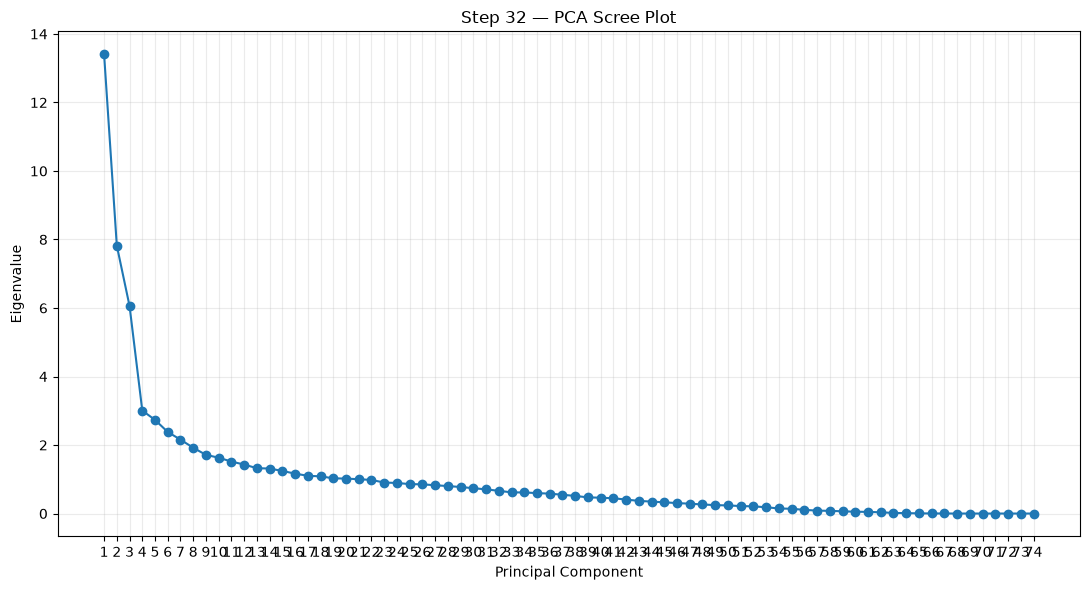

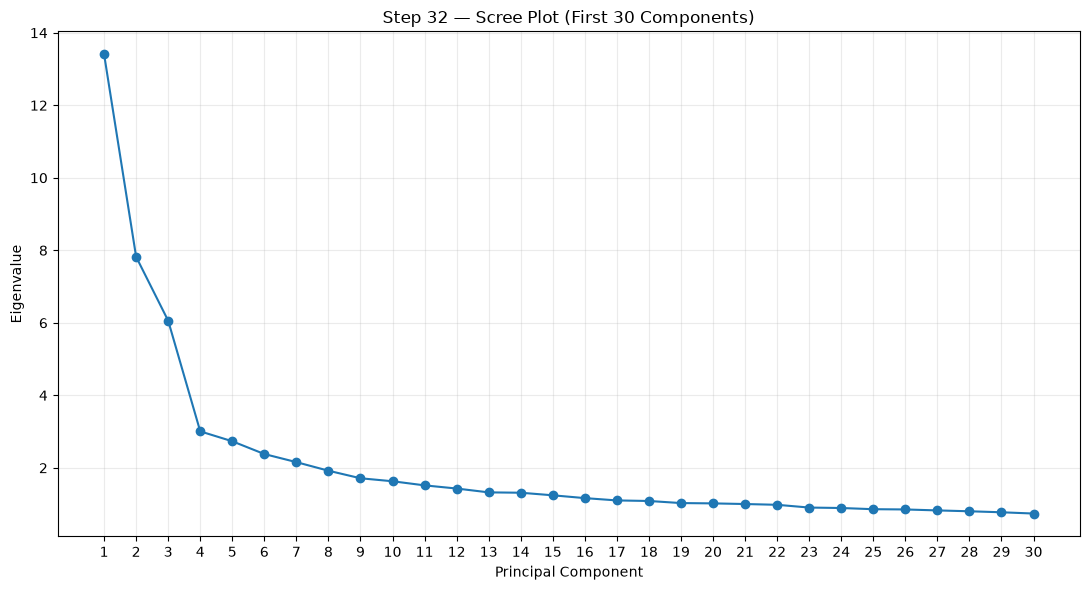


LARGEST EIGENVALUE DROPS

These are descriptive only.
They help identify where the Scree curve changes slope.


,component,component_number,eigenvalue,eigenvalue_drop_to_next_pc,explained_variance_percent,cumulative_variance_percent
0,PC1,1,13.4065,5.5868,18.0899,18.0899
1,PC3,3,6.0584,3.0522,8.1748,36.8162
2,PC2,2,7.8197,1.7613,10.5515,28.6414
3,PC5,5,2.7332,0.3524,3.6880,44.5605
4,PC4,4,3.0061,0.2729,4.0563,40.8725
5,PC7,7,2.1573,0.2366,2.9110,50.6840
6,PC6,6,2.3808,0.2235,3.2125,47.7730
7,PC8,8,1.9208,0.2082,2.5918,53.2758
8,PC10,10,1.6301,0.1133,2.1995,57.7862
9,PC12,12,1.4297,0.1061,1.9291,61.7620



STRONGEST CURVATURE CHANGES

These values are supplementary diagnostics only.


,component,component_number,eigenvalue,second_difference,explained_variance_percent,cumulative_variance_percent,absolute_second_difference
0,PC2,2,7.8197,3.8254,10.5515,28.6414,3.8254
1,PC4,4,3.0061,2.7793,4.0563,40.8725,2.7793
2,PC3,3,6.0584,-1.2909,8.1748,36.8162,1.2909
3,PC6,6,2.3808,0.1289,3.2125,47.7730,0.1289
4,PC9,9,1.7126,0.1257,2.3109,55.5866,0.1257
5,PC13,13,1.3235,0.0965,1.7859,63.5479,0.0965
6,PC5,5,2.7332,-0.0794,3.6880,44.5605,0.0794
7,PC23,23,0.9048,0.0635,1.2208,78.1816,0.0635
8,PC14,14,1.3139,-0.0614,1.7728,65.3207,0.0614
9,PC22,22,0.9807,-0.0547,1.3234,76.9608,0.0547



SCREE INSPECTION — FIRST COMPONENTS


,component,component_number,eigenvalue,explained_variance_percent,cumulative_variance_percent,eigenvalue_drop_to_next_pc,second_difference
0,PC1,1,13.4065,18.0899,18.0899,5.5868,NaN
1,PC2,2,7.8197,10.5515,28.6414,1.7613,3.8254
2,PC3,3,6.0584,8.1748,36.8162,3.0522,-1.2909
3,PC4,4,3.0061,4.0563,40.8725,0.2729,2.7793
4,PC5,5,2.7332,3.6880,44.5605,0.3524,-0.0794
5,PC6,6,2.3808,3.2125,47.7730,0.2235,0.1289
6,PC7,7,2.1573,2.9110,50.6840,0.2366,-0.0131
7,PC8,8,1.9208,2.5918,53.2758,0.2082,0.0284
8,PC9,9,1.7126,2.3109,55.5866,0.0825,0.1257
9,PC10,10,1.6301,2.1995,57.7862,0.1133,-0.0308



STEP 32 COMPLETE — SCREE TEST

PCA components evaluated:
  74

What this step did:
  Plotted the complete eigenvalue profile.
  Plotted the first 30 PCs for easier elbow inspection.
  Calculated eigenvalue drops between adjacent PCs.
  Calculated second-difference curvature diagnostics.

What this step did NOT do:
  No PCA components were removed.
  No final number of components was selected.
  No Kaiser criterion was applied.
  No component-saturation criterion was applied.

Main objects created:
  scree_summary
  scree_summary_display
  largest_drops
  curvature_summary
  scree_inspection

NEXT:
  Inspect the Scree plot and record the apparent component-retention region.



In [42]:
# ============================================================
# STEP 32 — SCREE PLOT / SCREE TEST
# ============================================================
#
# PURPOSE
# -------
#
# Evaluate the eigenvalue profile from the Classical PCA
# completed in Step 31.
#
# The Scree Test examines the ordered PCA eigenvalues and looks
# for the point where the steep decline transitions into a
# relatively flat region.
#
# Components before this bend are interpreted as carrying
# substantially more structure, while components in the flatter
# region increasingly resemble residual / lower-information
# dimensions.
#
# IMPORTANT
# ---------
#
# This step is DIAGNOSTIC ONLY.
#
# No components are removed here.
# No final retention decision is made here.
#
# The Scree result will later be combined with other
# component-retention diagnostics.
#
#
# Literature:
#
# Cattell, R. B. (1966).
# The Scree Test for the Number of Factors.
# Multivariate Behavioral Research, 1(2), 245–276.
#
# Zwick, W. R. & Velicer, W. F. (1986).
# Comparison of Five Rules for Determining the Number of
# Components to Retain.
# Psychological Bulletin, 99(3), 432–442.
#
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from IPython.display import display


# ============================================================
# 2. VERIFY STEP 31 OBJECTS EXIST
# ============================================================

required_objects = [
    "pca_eigenvalues",
    "pca_explained_variance_percent",
    "pca_cumulative_variance_percent"
]


missing_objects = [
    object_name
    for object_name in required_objects
    if object_name not in globals()
]


if missing_objects:

    raise RuntimeError(
        "Required Step 31 PCA objects are missing:\n\n"
        +
        "\n".join(
            missing_objects
        )
        +
        "\n\nRun Step 31 before running Step 32."
    )


# ============================================================
# 3. PREPARE EIGENVALUES
# ============================================================

eigenvalues = np.asarray(
    pca_eigenvalues,
    dtype=float
)


explained_variance_percent = np.asarray(
    pca_explained_variance_percent,
    dtype=float
)


cumulative_variance_percent = np.asarray(
    pca_cumulative_variance_percent,
    dtype=float
)


number_of_components = len(
    eigenvalues
)


component_numbers = np.arange(
    1,
    number_of_components + 1
)


# ============================================================
# 4. VALIDATE INPUT
# ============================================================

if (
    len(
        explained_variance_percent
    )
    !=
    number_of_components
):

    raise RuntimeError(
        "Explained-variance vector length does not match "
        "the number of PCA eigenvalues."
    )


if (
    len(
        cumulative_variance_percent
    )
    !=
    number_of_components
):

    raise RuntimeError(
        "Cumulative-variance vector length does not match "
        "the number of PCA eigenvalues."
    )


if not np.isfinite(
    eigenvalues
).all():

    raise RuntimeError(
        "PCA eigenvalues contain NaN or infinite values."
    )


# ============================================================
# 5. CREATE SCREE DATAFRAME
# ============================================================

scree_summary = pd.DataFrame(
    {
        "component":
            [
                f"PC{i}"
                for i in component_numbers
            ],

        "component_number":
            component_numbers,

        "eigenvalue":
            eigenvalues,

        "explained_variance_percent":
            explained_variance_percent,

        "cumulative_variance_percent":
            cumulative_variance_percent
    }
)


# ============================================================
# 6. CALCULATE FIRST DIFFERENCE IN EIGENVALUES
# ============================================================
#
# This shows how much the eigenvalue falls from one component
# to the next.
#
# Larger values indicate a sharper drop.
#
# ============================================================

scree_summary[
    "eigenvalue_drop_to_next_pc"
] = (

    scree_summary[
        "eigenvalue"
    ]

    -

    scree_summary[
        "eigenvalue"
    ]
    .shift(
        -1
    )
)


# ============================================================
# 7. CALCULATE SECOND DIFFERENCE
# ============================================================
#
# This is a simple curvature diagnostic.
#
# It is NOT the classical Scree Test itself, but it can help
# identify where the eigenvalue slope changes most strongly.
#
# ============================================================

first_difference = np.diff(
    eigenvalues
)


second_difference = np.diff(
    first_difference
)


scree_summary[
    "second_difference"
] = np.nan


if (
    len(
        second_difference
    )
    >
    0
):

    scree_summary.loc[
        1:
        number_of_components - 2,
        "second_difference"
    ] = second_difference


# ============================================================
# 8. CREATE DISPLAY VERSION
# ============================================================

scree_summary_display = (
    scree_summary
    .copy()
)


for column in [
    "eigenvalue",
    "eigenvalue_drop_to_next_pc",
    "second_difference"
]:

    scree_summary_display[
        column
    ] = (

        scree_summary_display[
            column
        ]

        .round(
            4
        )
    )


for column in [
    "explained_variance_percent",
    "cumulative_variance_percent"
]:

    scree_summary_display[
        column
    ] = (

        scree_summary_display[
            column
        ]

        .round(
            2
        )
    )


# ============================================================
# 9. PRINT SCREE SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 120
)


print(
    "STEP 32 — SCREE TEST"
)


print(
    "=" * 120
)


print(
    "\nPrincipal components evaluated:"
)


print(
    f"  {number_of_components:,}"
)


print(
    "\nEigenvalue profile:"
)


display(
    scree_summary_display
)


# ============================================================
# 10. PLOT FULL SCREE CURVE
# ============================================================

fig, ax = plt.subplots(
    figsize=(
        11,
        6
    )
)


ax.plot(

    component_numbers,

    eigenvalues,

    marker="o"
)


ax.set_xlabel(
    "Principal Component"
)


ax.set_ylabel(
    "Eigenvalue"
)


ax.set_title(
    "Step 32 — PCA Scree Plot"
)


ax.set_xticks(
    component_numbers
)


ax.grid(
    alpha=0.25
)


plt.tight_layout()


plt.show()


# ============================================================
# 11. PLOT FIRST 30 COMPONENTS
# ============================================================
#
# The bend is often much easier to inspect when the long tail
# of very small eigenvalues is not allowed to compress the
# beginning of the curve.
#
# ============================================================

components_to_show = min(
    30,
    number_of_components
)


fig, ax = plt.subplots(
    figsize=(
        11,
        6
    )
)


ax.plot(

    component_numbers[
        :components_to_show
    ],

    eigenvalues[
        :components_to_show
    ],

    marker="o"
)


ax.set_xlabel(
    "Principal Component"
)


ax.set_ylabel(
    "Eigenvalue"
)


ax.set_title(
    "Step 32 — Scree Plot (First 30 Components)"
)


ax.set_xticks(
    component_numbers[
        :components_to_show
    ]
)


ax.grid(
    alpha=0.25
)


plt.tight_layout()


plt.show()


# ============================================================
# 12. IDENTIFY LARGEST EIGENVALUE DROPS
# ============================================================
#
# This is descriptive support for the visual Scree Test.
#
# It does NOT automatically define the retention cutoff.
#
# ============================================================

largest_drops = (

    scree_summary[
        [
            "component",
            "component_number",
            "eigenvalue",
            "eigenvalue_drop_to_next_pc",
            "explained_variance_percent",
            "cumulative_variance_percent"
        ]
    ]

    .dropna(
        subset=[
            "eigenvalue_drop_to_next_pc"
        ]
    )

    .sort_values(
        "eigenvalue_drop_to_next_pc",
        ascending=False
    )

    .head(
        10
    )

    .reset_index(
        drop=True
    )
)


print(
    "\n"
    + "=" * 120
)


print(
    "LARGEST EIGENVALUE DROPS"
)


print(
    "=" * 120
)


print(
    "\nThese are descriptive only."
)


print(
    "They help identify where the Scree curve changes slope."
)


display(
    largest_drops.round(
        4
    )
)


# ============================================================
# 13. IDENTIFY STRONGEST CURVATURE POINTS
# ============================================================

curvature_summary = (

    scree_summary[
        [
            "component",
            "component_number",
            "eigenvalue",
            "second_difference",
            "explained_variance_percent",
            "cumulative_variance_percent"
        ]
    ]

    .dropna(
        subset=[
            "second_difference"
        ]
    )

    .assign(
        absolute_second_difference=
            lambda df:
            df[
                "second_difference"
            ]
            .abs()
    )

    .sort_values(
        "absolute_second_difference",
        ascending=False
    )

    .head(
        10
    )

    .reset_index(
        drop=True
    )
)


print(
    "\n"
    + "=" * 120
)


print(
    "STRONGEST CURVATURE CHANGES"
)


print(
    "=" * 120
)


print(
    "\nThese values are supplementary diagnostics only."
)


display(
    curvature_summary.round(
        4
    )
)


# ============================================================
# 14. CREATE COMPACT SCREE INSPECTION TABLE
# ============================================================
#
# Show the early part of the component structure where a Scree
# elbow is most likely to occur.
#
# ============================================================

inspection_limit = min(
    25,
    number_of_components
)


scree_inspection = (

    scree_summary
    .iloc[
        :inspection_limit
    ]
    .copy()
)


print(
    "\n"
    + "=" * 120
)


print(
    "SCREE INSPECTION — FIRST COMPONENTS"
)


print(
    "=" * 120
)


display(
    scree_inspection.round(
        4
    )
)


# ============================================================
# 15. FINAL STEP 32 SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 120
)


print(
    "STEP 32 COMPLETE — SCREE TEST"
)


print(
    "=" * 120
)


print(
    "\nPCA components evaluated:"
)


print(
    f"  {number_of_components:,}"
)


print(
    "\nWhat this step did:"
)


print(
    "  Plotted the complete eigenvalue profile."
)


print(
    "  Plotted the first 30 PCs for easier elbow inspection."
)


print(
    "  Calculated eigenvalue drops between adjacent PCs."
)


print(
    "  Calculated second-difference curvature diagnostics."
)


print(
    "\nWhat this step did NOT do:"
)


print(
    "  No PCA components were removed."
)


print(
    "  No final number of components was selected."
)


print(
    "  No Kaiser criterion was applied."
)


print(
    "  No component-saturation criterion was applied."
)


print(
    "\nMain objects created:"
)


print(
    "  scree_summary"
)


print(
    "  scree_summary_display"
)


print(
    "  largest_drops"
)


print(
    "  curvature_summary"
)


print(
    "  scree_inspection"
)


print(
    "\nNEXT:"
)


print(
    "  Inspect the Scree plot and record the apparent "
    "component-retention region."
)


print(
    "\n"
    + "=" * 120
)

### 33. Parallel Analysis

In [43]:
# ============================================================
# PARALLEL ANALYSIS — METHODOLOGICAL BASIS
# ============================================================
#
# Parallel Analysis determines how many PCs contain more
# structure than would be expected from random noise.
#
# Random datasets with the same dimensions as the real data
# (673 players × 74 variables) are generated and PCA is
# repeatedly applied.
#
# A PC is retained when its observed eigenvalue exceeds the
# 95th-percentile eigenvalue obtained from the random data.
#
# REFERENCES:
# Horn (1965) — introduced Parallel Analysis.
# Longman et al. (1989) — examined mean and 95th-percentile
#                         criteria for PCA Parallel Analysis.
# Hayton et al. (2004) — practical methodological guidance
#                        for Parallel Analysis.
#
# RESULT:
# Parallel Analysis supported PC1–PC12.
# PC13 was the first component below the random benchmark.
# ============================================================


STEP 33 — HORN'S PARALLEL ANALYSIS

Observed PCA:
  Observations: 673
  Variables:    74
  Components:   74

Parallel Analysis simulations:
  1,000

Random eigenvalue criterion:
  95th percentile

PARALLEL ANALYSIS — OBSERVED VS RANDOM EIGENVALUES


,component,component_number,observed_eigenvalue,random_mean_eigenvalue,random_median_eigenvalue,random_95th_percentile_eigenvalue,observed_minus_random_percentile,parallel_analysis_retain
0,PC1,1,13.4065,1.7235,1.7220,1.7789,11.6276,True
1,PC2,2,7.8197,1.6688,1.6677,1.7131,6.1066,True
2,PC3,3,6.0584,1.6290,1.6282,1.6642,4.3941,True
3,PC4,4,3.0061,1.5936,1.5935,1.6278,1.3783,True
4,PC5,5,2.7332,1.5623,1.5626,1.5903,1.1429,True
5,PC6,6,2.3808,1.5329,1.5326,1.5632,0.8176,True
6,PC7,7,2.1573,1.5065,1.5067,1.5338,0.6235,True
7,PC8,8,1.9208,1.4808,1.4809,1.5058,0.4150,True
8,PC9,9,1.7126,1.4554,1.4553,1.4797,0.2329,True
9,PC10,10,1.6301,1.4325,1.4320,1.4555,0.1746,True



PARALLEL ANALYSIS — RETENTION BOUNDARY


,component,component_number,observed_eigenvalue,random_mean_eigenvalue,random_median_eigenvalue,random_95th_percentile_eigenvalue,observed_minus_random_percentile,parallel_analysis_retain
0,PC9,9,1.7126,1.4554,1.4553,1.4797,0.2329,True
1,PC10,10,1.6301,1.4325,1.4320,1.4555,0.1746,True
2,PC11,11,1.5168,1.4098,1.4094,1.4322,0.0846,True
3,PC12,12,1.4297,1.3882,1.3886,1.4093,0.0203,True
4,PC13,13,1.3235,1.3671,1.3673,1.3877,-0.0642,False
5,PC14,14,1.3139,1.3463,1.3458,1.3649,-0.0511,False
6,PC15,15,1.2428,1.3266,1.3266,1.3459,-0.1031,False
7,PC16,16,1.1653,1.3074,1.3071,1.3271,-0.1618,False
8,PC17,17,1.1014,1.2884,1.2877,1.3077,-0.2063,False


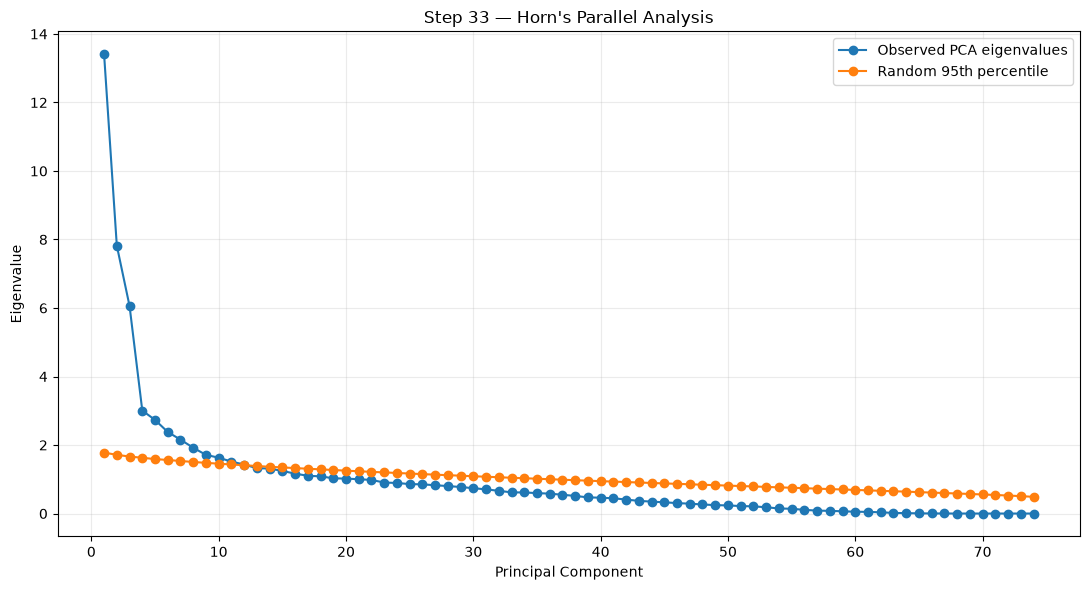

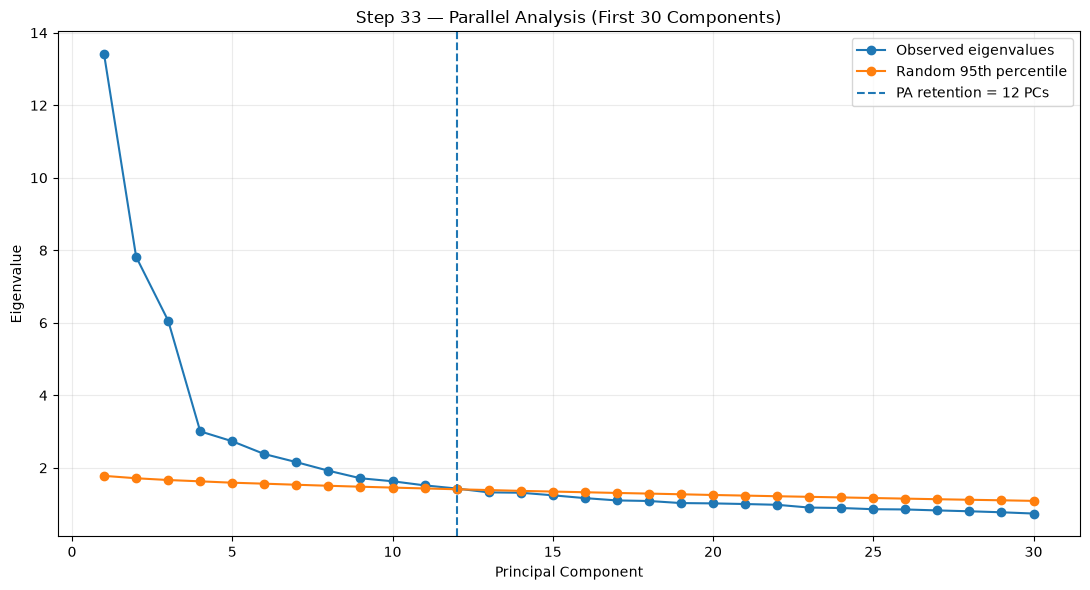


PARALLEL ANALYSIS RESULT

Retention criterion:
  Observed eigenvalue > 95th percentile random eigenvalue

Components retained:
  12

Retained PCs:
  PC1, PC2, PC3, PC4, PC5, PC6, PC7, PC8, PC9, PC10, PC11, PC12

STEP 33 — COMPACT RESULT


,observations,variables,simulations,random_percentile,components_retained,retained_components
0,673,74,1000,95,12,"PC1, PC2, PC3, PC4, PC5, PC6, PC7, PC8, PC9, PC10, PC11, PC12"



STEP 33 COMPLETE — HORN'S PARALLEL ANALYSIS

Observed PCA dimensions:
  N = 673
  P = 74

Random datasets simulated:
  1,000

Parallel Analysis criterion:
  95th percentile random eigenvalue

Parallel Analysis suggests retaining:
  12 principal components

IMPORTANT:
  No PCA components were removed.
  The full Step 31 PCA solution remains unchanged.
  This is an independent retention diagnostic.

Main output objects:
  random_eigenvalues
  random_mean_eigenvalues
  random_percentile_eigenvalues
  parallel_analysis_summary
  parallel_analysis_boundary
  parallel_analysis_result
  n_parallel_components
  parallel_retained_components



In [44]:
# ============================================================
# STEP 33 — HORN'S PARALLEL ANALYSIS
# ============================================================
#
# PURPOSE
# -------
#
# Determine how many principal components from the Classical
# PCA in Step 31 explain more variance than would be expected
# from random data alone.
#
# Parallel Analysis compares:
#
#       observed PCA eigenvalues
#
# against
#
#       eigenvalues generated from random datasets
#
# with the SAME:
#
#       number of observations (N)
#       number of variables (P)
#
#
# For each simulation:
#
#   1. Generate an N × P random normal matrix.
#   2. Standardize the random variables.
#   3. Run PCA.
#   4. Store the eigenvalues.
#
# After many simulations, the observed PCA eigenvalues are
# compared with the simulated eigenvalue distribution.
#
#
# RETENTION RULE
# --------------
#
# A component is retained when its observed eigenvalue exceeds
# the selected percentile of the corresponding random
# eigenvalue distribution.
#
# This script uses the 95th percentile as the primary
# Parallel Analysis criterion.
#
#
# IMPORTANT
# ---------
#
# This step is DIAGNOSTIC ONLY.
#
# It does NOT delete PCA components.
#
# It produces an independent component-retention estimate that
# will later be compared with the Scree Test and other
# diagnostics.
#
#
# REFERENCES
# ----------
#
# Horn, J. L. (1965).
# A rationale and test for the number of factors in factor
# analysis.
# Psychometrika, 30(2), 179–185.
#
# Zwick, W. R. & Velicer, W. F. (1986).
# Comparison of Five Rules for Determining the Number of
# Components to Retain.
# Psychological Bulletin, 99(3), 432–442.
#
# Hayton, J. C., Allen, D. G. & Scarpello, V. (2004).
# Factor Retention Decisions in Exploratory Factor Analysis:
# A Tutorial on Parallel Analysis.
# Organizational Research Methods, 7(2), 191–205.
#
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from IPython.display import display


# ============================================================
# 2. SETTINGS
# ============================================================

N_SIMULATIONS = 1000


RANDOM_STATE = 42


PARALLEL_PERCENTILE = 95


# ============================================================
# 3. VERIFY STEP 31 OBJECTS EXIST
# ============================================================

required_objects = [
    "pca_eigenvalues",
    "X_standardized",
    "pca_variables"
]


missing_objects = [
    object_name
    for object_name in required_objects
    if object_name not in globals()
]


if missing_objects:

    raise RuntimeError(
        "Required Step 31 objects are missing:\n\n"
        +
        "\n".join(
            missing_objects
        )
        +
        "\n\nRun Step 31 before running Step 33."
    )


# ============================================================
# 4. PREPARE OBSERVED PCA INFORMATION
# ============================================================

observed_eigenvalues = np.asarray(
    pca_eigenvalues,
    dtype=float
)


X_parallel = np.asarray(
    X_standardized,
    dtype=float
)


N, P = X_parallel.shape


number_of_components = len(
    observed_eigenvalues
)


component_numbers = np.arange(
    1,
    number_of_components + 1
)


component_names = [
    f"PC{i}"
    for i in component_numbers
]


# ============================================================
# 5. VALIDATE DIMENSIONS
# ============================================================

if (
    P
    !=
    len(
        pca_variables
    )
):

    raise RuntimeError(
        "The number of PCA variables does not match "
        "X_standardized."
    )


if (
    number_of_components
    !=
    min(
        N,
        P
    )
):

    raise RuntimeError(
        "Observed PCA eigenvalue count does not match the "
        "expected full PCA dimensionality."
    )


if not np.isfinite(
    observed_eigenvalues
).all():

    raise RuntimeError(
        "Observed PCA eigenvalues contain NaN or infinite "
        "values."
    )


# ============================================================
# 6. PRINT INPUT SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 120
)


print(
    "STEP 33 — HORN'S PARALLEL ANALYSIS"
)


print(
    "=" * 120
)


print(
    "\nObserved PCA:"
)


print(
    f"  Observations: {N:,}"
)


print(
    f"  Variables:    {P:,}"
)


print(
    f"  Components:   {number_of_components:,}"
)


print(
    "\nParallel Analysis simulations:"
)


print(
    f"  {N_SIMULATIONS:,}"
)


print(
    "\nRandom eigenvalue criterion:"
)


print(
    f"  {PARALLEL_PERCENTILE}th percentile"
)


# ============================================================
# 7. CREATE RANDOM NUMBER GENERATOR
# ============================================================

rng = np.random.default_rng(
    RANDOM_STATE
)


# ============================================================
# 8. STORAGE FOR RANDOM EIGENVALUES
# ============================================================

random_eigenvalues = np.empty(
    (
        N_SIMULATIONS,
        number_of_components
    ),
    dtype=float
)


# ============================================================
# 9. RUN PARALLEL ANALYSIS SIMULATIONS
# ============================================================

for simulation in range(
    N_SIMULATIONS
):

    # --------------------------------------------------------
    # Generate random independent normal variables
    # --------------------------------------------------------

    random_matrix = rng.normal(
        loc=0.0,
        scale=1.0,
        size=(
            N,
            P
        )
    )


    # --------------------------------------------------------
    # Standardize random matrix exactly as real PCA input
    # --------------------------------------------------------

    random_standardized = (

        StandardScaler(
            with_mean=True,
            with_std=True
        )

        .fit_transform(
            random_matrix
        )
    )


    # --------------------------------------------------------
    # Fit full PCA
    # --------------------------------------------------------

    random_pca = PCA(
        n_components=None,
        svd_solver="full"
    )


    random_pca.fit(
        random_standardized
    )


    # --------------------------------------------------------
    # Store simulated eigenvalues
    # --------------------------------------------------------

    random_eigenvalues[
        simulation,
        :
    ] = (
        random_pca
        .explained_variance_
    )


# ============================================================
# 10. CALCULATE RANDOM EIGENVALUE BENCHMARKS
# ============================================================

random_mean_eigenvalues = np.mean(
    random_eigenvalues,
    axis=0
)


random_median_eigenvalues = np.median(
    random_eigenvalues,
    axis=0
)


random_percentile_eigenvalues = np.percentile(
    random_eigenvalues,
    PARALLEL_PERCENTILE,
    axis=0
)


# ============================================================
# 11. APPLY PARALLEL ANALYSIS RETENTION RULE
# ============================================================
#
# Primary rule:
#
#   observed eigenvalue
#   >
#   95th percentile random eigenvalue
#
# ============================================================

parallel_retain_mask = (

    observed_eigenvalues

    >
    random_percentile_eigenvalues
)


# ============================================================
# 12. DETERMINE NUMBER OF RETAINED COMPONENTS
# ============================================================
#
# Standard PA interpretation assumes retained components occur
# consecutively from PC1 onward.
#
# We therefore find the first PC that fails the criterion.
#
# ============================================================

failed_indices = np.where(
    ~parallel_retain_mask
)[0]


if (
    len(
        failed_indices
    )
    ==
    0
):

    n_parallel_components = (
        number_of_components
    )


else:

    n_parallel_components = int(
        failed_indices[
            0
        ]
    )


parallel_retained_components = [
    f"PC{i}"
    for i in range(
        1,
        n_parallel_components + 1
    )
]


# ============================================================
# 13. CREATE PARALLEL ANALYSIS SUMMARY
# ============================================================

parallel_analysis_summary = pd.DataFrame(
    {

        "component":
            component_names,

        "component_number":
            component_numbers,

        "observed_eigenvalue":
            observed_eigenvalues,

        "random_mean_eigenvalue":
            random_mean_eigenvalues,

        "random_median_eigenvalue":
            random_median_eigenvalues,

        f"random_{PARALLEL_PERCENTILE}th_percentile_eigenvalue":
            random_percentile_eigenvalues,

        "observed_minus_random_percentile":
            (
                observed_eigenvalues
                -
                random_percentile_eigenvalues
            ),

        "parallel_analysis_retain":
            parallel_retain_mask
    }
)


# ============================================================
# 14. CREATE DISPLAY VERSION
# ============================================================

parallel_analysis_display = (
    parallel_analysis_summary
    .copy()
)


numeric_columns_to_round = [
    "observed_eigenvalue",
    "random_mean_eigenvalue",
    "random_median_eigenvalue",
    f"random_{PARALLEL_PERCENTILE}th_percentile_eigenvalue",
    "observed_minus_random_percentile"
]


for column in numeric_columns_to_round:

    parallel_analysis_display[
        column
    ] = (

        parallel_analysis_display[
            column
        ]

        .round(
            4
        )
    )


# ============================================================
# 15. PRINT COMPLETE PARALLEL ANALYSIS TABLE
# ============================================================

print(
    "\n"
    + "=" * 150
)


print(
    "PARALLEL ANALYSIS — OBSERVED VS RANDOM EIGENVALUES"
)


print(
    "=" * 150
)


display(
    parallel_analysis_display
)


# ============================================================
# 16. CREATE RETENTION-BOUNDARY TABLE
# ============================================================
#
# Display several PCs around the estimated cutoff.
#
# ============================================================

boundary_start = max(
    0,
    n_parallel_components - 4
)


boundary_end = min(
    number_of_components,
    n_parallel_components + 5
)


parallel_analysis_boundary = (

    parallel_analysis_summary

    .iloc[
        boundary_start:
        boundary_end
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


print(
    "\n"
    + "=" * 140
)


print(
    "PARALLEL ANALYSIS — RETENTION BOUNDARY"
)


print(
    "=" * 140
)


display(
    parallel_analysis_boundary.round(
        4
    )
)


# ============================================================
# 17. PLOT OBSERVED VS RANDOM EIGENVALUES
# ============================================================

fig, ax = plt.subplots(
    figsize=(
        11,
        6
    )
)


ax.plot(

    component_numbers,

    observed_eigenvalues,

    marker="o",

    label=
        "Observed PCA eigenvalues"
)


ax.plot(

    component_numbers,

    random_percentile_eigenvalues,

    marker="o",

    label=
        f"Random {PARALLEL_PERCENTILE}th percentile"
)


ax.set_xlabel(
    "Principal Component"
)


ax.set_ylabel(
    "Eigenvalue"
)


ax.set_title(
    "Step 33 — Horn's Parallel Analysis"
)


ax.legend()


ax.grid(
    alpha=0.25
)


plt.tight_layout()


plt.show()


# ============================================================
# 18. PLOT FIRST 30 COMPONENTS
# ============================================================

components_to_show = min(
    30,
    number_of_components
)


fig, ax = plt.subplots(
    figsize=(
        11,
        6
    )
)


ax.plot(

    component_numbers[
        :components_to_show
    ],

    observed_eigenvalues[
        :components_to_show
    ],

    marker="o",

    label=
        "Observed eigenvalues"
)


ax.plot(

    component_numbers[
        :components_to_show
    ],

    random_percentile_eigenvalues[
        :components_to_show
    ],

    marker="o",

    label=
        f"Random {PARALLEL_PERCENTILE}th percentile"
)


if (
    n_parallel_components
    >
    0
):

    ax.axvline(

        n_parallel_components,

        linestyle="--",

        label=
            f"PA retention = {n_parallel_components} PCs"
    )


ax.set_xlabel(
    "Principal Component"
)


ax.set_ylabel(
    "Eigenvalue"
)


ax.set_title(
    "Step 33 — Parallel Analysis (First 30 Components)"
)


ax.legend()


ax.grid(
    alpha=0.25
)


plt.tight_layout()


plt.show()


# ============================================================
# 19. PRINT PARALLEL ANALYSIS RESULT
# ============================================================

print(
    "\n"
    + "=" * 120
)


print(
    "PARALLEL ANALYSIS RESULT"
)


print(
    "=" * 120
)


print(
    "\nRetention criterion:"
)


print(
    f"  Observed eigenvalue > "
    f"{PARALLEL_PERCENTILE}th percentile "
    "random eigenvalue"
)


print(
    "\nComponents retained:"
)


print(
    f"  {n_parallel_components:,}"
)


print(
    "\nRetained PCs:"
)


if parallel_retained_components:

    print(
        "  "
        +
        ", ".join(
            parallel_retained_components
        )
    )


else:

    print(
        "  None"
    )


# ============================================================
# 20. CREATE COMPACT RESULT OBJECT
# ============================================================

parallel_analysis_result = pd.DataFrame(
    [
        {

            "observations":
                N,

            "variables":
                P,

            "simulations":
                N_SIMULATIONS,

            "random_percentile":
                PARALLEL_PERCENTILE,

            "components_retained":
                n_parallel_components,

            "retained_components":
                ", ".join(
                    parallel_retained_components
                )
        }
    ]
)


# ============================================================
# 21. PRINT COMPACT RESULT
# ============================================================

print(
    "\n"
    + "=" * 120
)


print(
    "STEP 33 — COMPACT RESULT"
)


print(
    "=" * 120
)


display(
    parallel_analysis_result
)


# ============================================================
# 22. FINAL STEP 33 SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 120
)


print(
    "STEP 33 COMPLETE — HORN'S PARALLEL ANALYSIS"
)


print(
    "=" * 120
)


print(
    "\nObserved PCA dimensions:"
)


print(
    f"  N = {N:,}"
)


print(
    f"  P = {P:,}"
)


print(
    "\nRandom datasets simulated:"
)


print(
    f"  {N_SIMULATIONS:,}"
)


print(
    "\nParallel Analysis criterion:"
)


print(
    f"  {PARALLEL_PERCENTILE}th percentile random eigenvalue"
)


print(
    "\nParallel Analysis suggests retaining:"
)


print(
    f"  {n_parallel_components:,} principal components"
)


print(
    "\nIMPORTANT:"
)


print(
    "  No PCA components were removed."
)


print(
    "  The full Step 31 PCA solution remains unchanged."
)


print(
    "  This is an independent retention diagnostic."
)


print(
    "\nMain output objects:"
)


print(
    "  random_eigenvalues"
)


print(
    "  random_mean_eigenvalues"
)


print(
    "  random_percentile_eigenvalues"
)


print(
    "  parallel_analysis_summary"
)


print(
    "  parallel_analysis_boundary"
)


print(
    "  parallel_analysis_result"
)


print(
    "  n_parallel_components"
)


print(
    "  parallel_retained_components"
)


print(
    "\n"
    + "=" * 120
)

### 34. Run Velicer's Map Test


STEP 34 — VELICER'S MINIMUM AVERAGE PARTIAL (MAP) TEST

Input matrix:
  Observations: 673
  Variables:    74

Previously obtained retention evidence:
  Scree Test:        4 PCs
  Parallel Analysis: 12 PCs

VELICER MAP — COMPLETE COMPONENT SEQUENCE


,components_partialled_out,original_MAP,revised_MAP,original_difference_from_minimum,revised_difference_from_minimum
0,0,0.049260,0.017246,0.031366,0.014043
1,1,0.040083,0.012937,0.022189,0.009735
2,2,0.033627,0.008398,0.015733,0.005195
3,3,0.023546,0.005531,0.005651,0.002328
4,4,0.022016,0.004730,0.004122,0.001527
5,5,0.019468,0.004524,0.001573,0.001321
6,6,0.019154,0.004375,0.001260,0.001172
7,7,0.019445,0.004364,0.001551,0.001161
8,8,0.019724,0.004191,0.001829,0.000988
9,9,0.019082,0.003895,0.001187,0.000692



ORIGINAL MAP — NEIGHBORHOOD AROUND MINIMUM


,components_partialled_out,original_MAP,revised_MAP,original_difference_from_minimum,revised_difference_from_minimum
0,6,0.019154,0.004375,0.001260,0.001172
1,7,0.019445,0.004364,0.001551,0.001161
2,8,0.019724,0.004191,0.001829,0.000988
3,9,0.019082,0.003895,0.001187,0.000692
4,10,0.018620,0.003710,0.000726,0.000508
5,11,0.017894,0.003507,0.000000,0.000304
6,12,0.017898,0.003360,0.000004,0.000157
7,13,0.018003,0.003335,0.000109,0.000132
8,14,0.018119,0.003334,0.000225,0.000131
9,15,0.018270,0.003311,0.000376,0.000108



REVISED MAP — NEIGHBORHOOD AROUND MINIMUM


,components_partialled_out,original_MAP,revised_MAP,original_difference_from_minimum,revised_difference_from_minimum
0,12,0.017898,0.003360,0.000004,0.000157
1,13,0.018003,0.003335,0.000109,0.000132
2,14,0.018119,0.003334,0.000225,0.000131
3,15,0.018270,0.003311,0.000376,0.000108
4,16,0.018263,0.003272,0.000369,0.000069
5,17,0.018132,0.003203,0.000237,0.000000
6,18,0.018597,0.003208,0.000703,0.000005
7,19,0.018860,0.003237,0.000966,0.000034
8,20,0.019293,0.003311,0.001399,0.000108
9,21,0.020090,0.003518,0.002195,0.000315


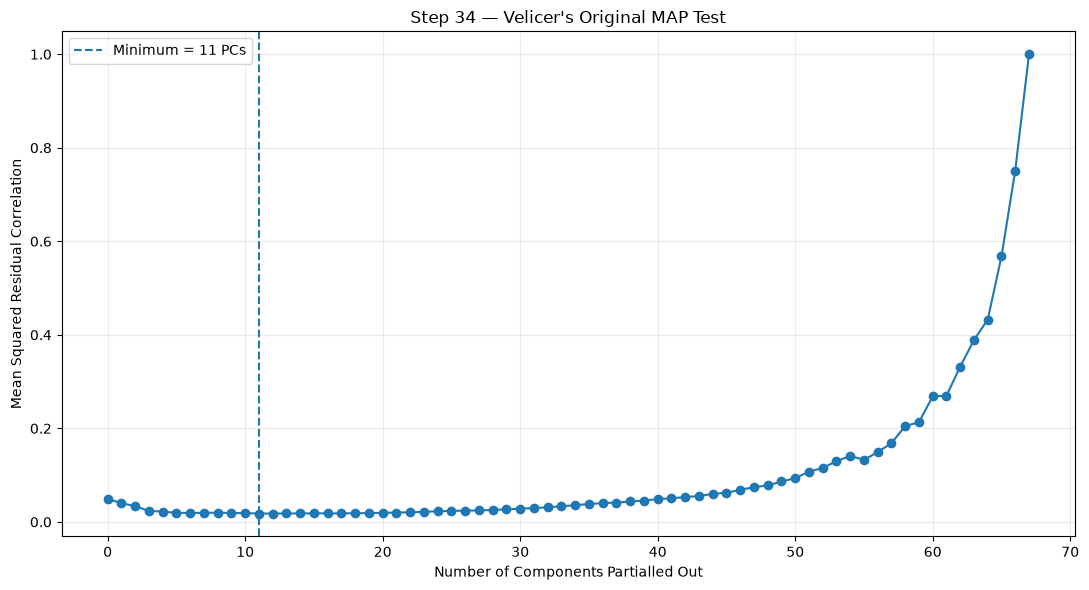

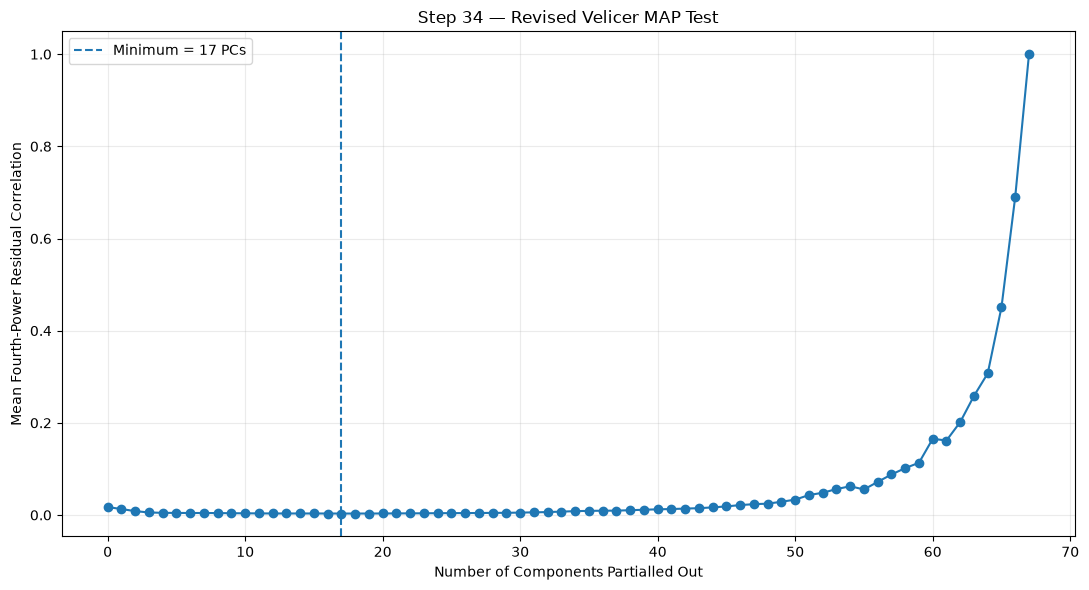


STEP 34 — COMPACT MAP RESULT


,observations,variables,original_MAP_components,original_MAP_minimum,revised_MAP_components,revised_MAP_minimum
0,673,74,11,0.017894,17,0.003203



COMPONENT RETENTION EVIDENCE SO FAR


,method,components_suggested
0,Cattell Scree Test,4
1,Horn Parallel Analysis,12
2,Velicer Original MAP,11
3,Velicer Revised MAP,17



VELICER MAP RESULT

Original MAP recommends:
  11 components

Revised MAP recommends:
  17 components

The original and revised MAP criteria do not select exactly the same number of components.
Treat both as retention evidence rather than forcing an immediate decision.

STEP 34 COMPLETE — VELICER'S MAP TEST

Dataset dimensions:
  N = 673
  P = 74

Retention evidence:
  Scree Test:             4 PCs
  Parallel Analysis:      12 PCs
  Original Velicer MAP:   11 PCs
  Revised Velicer MAP:    17 PCs

IMPORTANT:
  No components were removed.
  No observations were removed.
  The Step 31 PCA solution remains unchanged.
  MAP is being used as another independent retention diagnostic.

Main output objects:
  velicer_map_summary
  original_map_neighborhood
  revised_map_neighborhood
  velicer_map_result
  component_retention_comparison
  original_map_components
  revised_map_components



In [45]:
# ============================================================
# STEP 34 — VELICER'S MINIMUM AVERAGE PARTIAL (MAP) TEST
# ============================================================
#
# PURPOSE
# -------
#
# Estimate how many principal components should be retained
# using Velicer's Minimum Average Partial (MAP) criterion.
#
# MAP asks:
#
#   "After removing k principal components, how much
#    systematic correlation remains among the variables?"
#
# For k = 0, 1, 2, ... components, the correlation matrix is
# reproduced from the removed PCs and subtracted from the
# original correlation matrix.
#
# The residual covariance matrix is converted to a residual
# partial-correlation matrix.
#
# ORIGINAL MAP:
#   Calculates the mean squared off-diagonal residual
#   correlations.
#
# REVISED MAP:
#   Calculates the mean fourth-power off-diagonal residual
#   correlations.
#
# The number of components associated with the MINIMUM value
# is the MAP retention recommendation.
#
# IMPORTANT
# ---------
#
# This step is DIAGNOSTIC ONLY.
#
# No components are removed.
# No observations are removed.
# No source dataset is modified.
#
# The MAP result should be compared with:
#
#   Step 32 — Scree Test:        4 PCs
#   Step 33 — Parallel Analysis: 12 PCs
#
#
# REFERENCES
# ----------
#
# Velicer, W. F. (1976).
# Determining the Number of Components from the Matrix of
# Partial Correlations.
# Psychometrika, 41, 321–327.
#
# Velicer, W. F., Eaton, C. A., & Fava, J. L. (2000).
# Construct Explication through Factor or Component Analysis:
# A Review and Evaluation of Alternative Procedures for
# Determining the Number of Factors or Components.
#
# Zwick, W. R. & Velicer, W. F. (1986).
# Comparison of Five Rules for Determining the Number of
# Components to Retain.
# Psychological Bulletin, 99(3), 432–442.
#
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from IPython.display import display


# ============================================================
# 2. VERIFY REQUIRED STEP 31 OBJECT EXISTS
# ============================================================

required_objects = [
    "X_standardized"
]


missing_objects = [
    object_name
    for object_name in required_objects
    if object_name not in globals()
]


if missing_objects:

    raise RuntimeError(
        "Required Step 31 object is missing:\n\n"
        +
        "\n".join(
            missing_objects
        )
        +
        "\n\nRun Step 31 before running Step 34."
    )


# ============================================================
# 3. PREPARE STANDARDIZED PCA MATRIX
# ============================================================

X_map = np.asarray(
    X_standardized,
    dtype=float
)


if X_map.ndim != 2:

    raise RuntimeError(
        "X_standardized must be a two-dimensional matrix."
    )


N, P = X_map.shape


if N < 3:

    raise RuntimeError(
        "Too few observations to calculate the MAP test."
    )


if P < 2:

    raise RuntimeError(
        "Too few variables to calculate the MAP test."
    )


if not np.isfinite(
    X_map
).all():

    raise RuntimeError(
        "X_standardized contains NaN or infinite values."
    )


# ============================================================
# 4. PRINT INPUT SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 120
)

print(
    "STEP 34 — VELICER'S MINIMUM AVERAGE PARTIAL (MAP) TEST"
)

print(
    "=" * 120
)

print(
    "\nInput matrix:"
)

print(
    f"  Observations: {N:,}"
)

print(
    f"  Variables:    {P:,}"
)

print(
    "\nPreviously obtained retention evidence:"
)

print(
    "  Scree Test:        4 PCs"
)

print(
    "  Parallel Analysis: 12 PCs"
)


# ============================================================
# 5. CALCULATE CORRELATION MATRIX
# ============================================================
#
# np.corrcoef is used explicitly so the MAP test operates on
# the correlation matrix, matching the standardized PCA
# framework.
#
# ============================================================

correlation_matrix = np.corrcoef(
    X_map,
    rowvar=False
)


if not np.isfinite(
    correlation_matrix
).all():

    raise RuntimeError(
        "The correlation matrix contains NaN or infinite "
        "values. Check for zero-variance variables."
    )


# ============================================================
# 6. EIGENDECOMPOSITION OF CORRELATION MATRIX
# ============================================================
#
# eigh is appropriate because a correlation matrix is
# symmetric.
#
# numpy returns eigenvalues in ascending order, so they are
# reordered from largest to smallest.
#
# ============================================================

eigenvalues, eigenvectors = np.linalg.eigh(
    correlation_matrix
)


order = np.argsort(
    eigenvalues
)[::-1]


eigenvalues = eigenvalues[
    order
]


eigenvectors = eigenvectors[
    :,
    order
]


# ============================================================
# 7. NUMERICAL CLEANUP
# ============================================================
#
# Tiny negative eigenvalues can occur because of floating-point
# precision even when the theoretical eigenvalue is zero.
#
# ============================================================

eigenvalues[
    np.abs(
        eigenvalues
    )
    <
    1e-12
] = 0.0


# ============================================================
# 8. FUNCTION TO CONVERT RESIDUAL COVARIANCE TO
#    RESIDUAL CORRELATION MATRIX
# ============================================================

def covariance_to_correlation(
    covariance_matrix
):

    diagonal = np.diag(
        covariance_matrix
    )


    # Numerical protection
    diagonal = np.where(
        diagonal > 1e-12,
        diagonal,
        np.nan
    )


    standard_deviations = np.sqrt(
        diagonal
    )


    denominator = np.outer(
        standard_deviations,
        standard_deviations
    )


    correlation = (
        covariance_matrix
        /
        denominator
    )


    np.fill_diagonal(
        correlation,
        0.0
    )


    return correlation


# ============================================================
# 9. STORAGE FOR MAP RESULTS
# ============================================================

map_results = []


# ============================================================
# 10. CALCULATE MAP FOR k = 0 ... P-1 COMPONENTS
# ============================================================
#
# k = 0 means that no components have been partialled out.
#
# For each subsequent k:
#
#   reconstructed covariance from first k PCs
#
# is subtracted from:
#
#   original correlation matrix
#
# leaving the residual covariance matrix.
#
# ============================================================

for k in range(
    0,
    P
):


    # --------------------------------------------------------
    # No PCs removed
    # --------------------------------------------------------

    if k == 0:

        residual_covariance = (
            correlation_matrix.copy()
        )


    # --------------------------------------------------------
    # Remove first k principal components
    # --------------------------------------------------------

    else:

        retained_vectors = (
            eigenvectors[
                :,
                :k
            ]
        )


        retained_values = (
            eigenvalues[
                :k
            ]
        )


        reproduced_matrix = (

            retained_vectors

            @

            np.diag(
                retained_values
            )

            @

            retained_vectors.T
        )


        residual_covariance = (

            correlation_matrix

            -

            reproduced_matrix
        )


    # --------------------------------------------------------
    # Convert residual covariance to residual correlations
    # --------------------------------------------------------

    residual_correlation = (
        covariance_to_correlation(
            residual_covariance
        )
    )


    # --------------------------------------------------------
    # Extract off-diagonal residual correlations
    # --------------------------------------------------------

    upper_triangle_indices = np.triu_indices(
        P,
        k=1
    )


    residual_values = (
        residual_correlation[
            upper_triangle_indices
        ]
    )


    residual_values = residual_values[
        np.isfinite(
            residual_values
        )
    ]


    if len(
        residual_values
    ) == 0:

        original_map = np.nan
        revised_map = np.nan


    else:

        # ----------------------------------------------------
        # Original Velicer MAP
        # ----------------------------------------------------

        original_map = np.mean(
            residual_values ** 2
        )


        # ----------------------------------------------------
        # Revised MAP
        # ----------------------------------------------------

        revised_map = np.mean(
            residual_values ** 4
        )


    map_results.append(
        {
            "components_partialled_out":
                k,

            "original_MAP":
                original_map,

            "revised_MAP":
                revised_map
        }
    )


# ============================================================
# 11. CREATE MAP SUMMARY DATAFRAME
# ============================================================

velicer_map_summary = pd.DataFrame(
    map_results
)


# ============================================================
# 12. FIND ORIGINAL MAP MINIMUM
# ============================================================

valid_original = (

    velicer_map_summary[
        "original_MAP"
    ]

    .replace(
        [np.inf, -np.inf],
        np.nan
    )

    .dropna()
)


if valid_original.empty:

    raise RuntimeError(
        "No valid original MAP values were produced."
    )


original_map_components = int(

    velicer_map_summary.loc[
        valid_original.idxmin(),
        "components_partialled_out"
    ]
)


original_map_minimum = float(

    velicer_map_summary.loc[
        valid_original.idxmin(),
        "original_MAP"
    ]
)


# ============================================================
# 13. FIND REVISED MAP MINIMUM
# ============================================================

valid_revised = (

    velicer_map_summary[
        "revised_MAP"
    ]

    .replace(
        [np.inf, -np.inf],
        np.nan
    )

    .dropna()
)


if valid_revised.empty:

    raise RuntimeError(
        "No valid revised MAP values were produced."
    )


revised_map_components = int(

    velicer_map_summary.loc[
        valid_revised.idxmin(),
        "components_partialled_out"
    ]
)


revised_map_minimum = float(

    velicer_map_summary.loc[
        valid_revised.idxmin(),
        "revised_MAP"
    ]
)


# ============================================================
# 14. ADD DIFFERENCE FROM MINIMUM
# ============================================================

velicer_map_summary[
    "original_difference_from_minimum"
] = (

    velicer_map_summary[
        "original_MAP"
    ]

    -

    original_map_minimum
)


velicer_map_summary[
    "revised_difference_from_minimum"
] = (

    velicer_map_summary[
        "revised_MAP"
    ]

    -

    revised_map_minimum
)


# ============================================================
# 15. PRINT FULL MAP TABLE
# ============================================================

print(
    "\n"
    + "=" * 140
)

print(
    "VELICER MAP — COMPLETE COMPONENT SEQUENCE"
)

print(
    "=" * 140
)


display(
    velicer_map_summary.round(
        8
    )
)


# ============================================================
# 16. CREATE ORIGINAL MAP NEIGHBORHOOD
# ============================================================

original_start = max(
    0,
    original_map_components - 5
)


original_end = min(
    P,
    original_map_components + 6
)


original_map_neighborhood = (

    velicer_map_summary[
        (
            velicer_map_summary[
                "components_partialled_out"
            ]
            >=
            original_start
        )
        &
        (
            velicer_map_summary[
                "components_partialled_out"
            ]
            <
            original_end
        )
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


print(
    "\n"
    + "=" * 120
)

print(
    "ORIGINAL MAP — NEIGHBORHOOD AROUND MINIMUM"
)

print(
    "=" * 120
)


display(
    original_map_neighborhood.round(
        8
    )
)


# ============================================================
# 17. CREATE REVISED MAP NEIGHBORHOOD
# ============================================================

revised_start = max(
    0,
    revised_map_components - 5
)


revised_end = min(
    P,
    revised_map_components + 6
)


revised_map_neighborhood = (

    velicer_map_summary[
        (
            velicer_map_summary[
                "components_partialled_out"
            ]
            >=
            revised_start
        )
        &
        (
            velicer_map_summary[
                "components_partialled_out"
            ]
            <
            revised_end
        )
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


print(
    "\n"
    + "=" * 120
)

print(
    "REVISED MAP — NEIGHBORHOOD AROUND MINIMUM"
)

print(
    "=" * 120
)


display(
    revised_map_neighborhood.round(
        8
    )
)


# ============================================================
# 18. PLOT ORIGINAL MAP
# ============================================================

fig, ax = plt.subplots(
    figsize=(
        11,
        6
    )
)


ax.plot(

    velicer_map_summary[
        "components_partialled_out"
    ],

    velicer_map_summary[
        "original_MAP"
    ],

    marker="o"
)


ax.axvline(

    original_map_components,

    linestyle="--",

    label=(
        f"Minimum = "
        f"{original_map_components} PCs"
    )
)


ax.set_xlabel(
    "Number of Components Partialled Out"
)


ax.set_ylabel(
    "Mean Squared Residual Correlation"
)


ax.set_title(
    "Step 34 — Velicer's Original MAP Test"
)


ax.legend()


ax.grid(
    alpha=0.25
)


plt.tight_layout()


plt.show()


# ============================================================
# 19. PLOT REVISED MAP
# ============================================================

fig, ax = plt.subplots(
    figsize=(
        11,
        6
    )
)


ax.plot(

    velicer_map_summary[
        "components_partialled_out"
    ],

    velicer_map_summary[
        "revised_MAP"
    ],

    marker="o"
)


ax.axvline(

    revised_map_components,

    linestyle="--",

    label=(
        f"Minimum = "
        f"{revised_map_components} PCs"
    )
)


ax.set_xlabel(
    "Number of Components Partialled Out"
)


ax.set_ylabel(
    "Mean Fourth-Power Residual Correlation"
)


ax.set_title(
    "Step 34 — Revised Velicer MAP Test"
)


ax.legend()


ax.grid(
    alpha=0.25
)


plt.tight_layout()


plt.show()


# ============================================================
# 20. CREATE COMPACT MAP RESULT
# ============================================================

velicer_map_result = pd.DataFrame(
    [
        {
            "observations":
                N,

            "variables":
                P,

            "original_MAP_components":
                original_map_components,

            "original_MAP_minimum":
                original_map_minimum,

            "revised_MAP_components":
                revised_map_components,

            "revised_MAP_minimum":
                revised_map_minimum
        }
    ]
)


print(
    "\n"
    + "=" * 120
)

print(
    "STEP 34 — COMPACT MAP RESULT"
)

print(
    "=" * 120
)


display(
    velicer_map_result.round(
        8
    )
)


# ============================================================
# 21. COMPARE CURRENT RETENTION EVIDENCE
# ============================================================

component_retention_comparison = pd.DataFrame(
    {
        "method": [
            "Cattell Scree Test",
            "Horn Parallel Analysis",
            "Velicer Original MAP",
            "Velicer Revised MAP"
        ],

        "components_suggested": [
            4,
            12,
            original_map_components,
            revised_map_components
        ]
    }
)


print(
    "\n"
    + "=" * 120
)

print(
    "COMPONENT RETENTION EVIDENCE SO FAR"
)

print(
    "=" * 120
)


display(
    component_retention_comparison
)


# ============================================================
# 22. PRINT INTERPRETATION
# ============================================================

print(
    "\n"
    + "=" * 120
)

print(
    "VELICER MAP RESULT"
)

print(
    "=" * 120
)


print(
    "\nOriginal MAP recommends:"
)

print(
    f"  {original_map_components:,} components"
)


print(
    "\nRevised MAP recommends:"
)

print(
    f"  {revised_map_components:,} components"
)


if (
    original_map_components
    ==
    revised_map_components
):

    print(
        "\nThe original and revised MAP criteria agree."
    )

else:

    print(
        "\nThe original and revised MAP criteria do not "
        "select exactly the same number of components."
    )

    print(
        "Treat both as retention evidence rather than "
        "forcing an immediate decision."
    )


# ============================================================
# 23. FINAL STEP 34 SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 120
)

print(
    "STEP 34 COMPLETE — VELICER'S MAP TEST"
)

print(
    "=" * 120
)


print(
    "\nDataset dimensions:"
)

print(
    f"  N = {N:,}"
)

print(
    f"  P = {P:,}"
)


print(
    "\nRetention evidence:"
)

print(
    "  Scree Test:             4 PCs"
)

print(
    "  Parallel Analysis:      12 PCs"
)

print(
    f"  Original Velicer MAP:   "
    f"{original_map_components} PCs"
)

print(
    f"  Revised Velicer MAP:    "
    f"{revised_map_components} PCs"
)


print(
    "\nIMPORTANT:"
)

print(
    "  No components were removed."
)

print(
    "  No observations were removed."
)

print(
    "  The Step 31 PCA solution remains unchanged."
)

print(
    "  MAP is being used as another independent retention "
    "diagnostic."
)


print(
    "\nMain output objects:"
)

print(
    "  velicer_map_summary"
)

print(
    "  original_map_neighborhood"
)

print(
    "  revised_map_neighborhood"
)

print(
    "  velicer_map_result"
)

print(
    "  component_retention_comparison"
)

print(
    "  original_map_components"
)

print(
    "  revised_map_components"
)


print(
    "\n"
    + "=" * 120
)

### 35. Calculate Component Saturation / Loading Adequacy


STEP 35 — GUADAGNOLI & VELICER (1988) COMPONENT-PATTERN ASSESSMENT

Dataset:
  Observations (N): 673
  Variables (P):    74

Published assessment criteria used:
  >= 4 variables with |loading| >= .60
  approximately 10-12 variables around |loading| = .40
  weak / few-variable patterns require approximately N >= 300 before interpretation is considered

Current sample-size status:
  N = 673 >= 300
  Sample-size condition for weakly defined patterns is satisfied.

GUADAGNOLI & VELICER (1988) ASSESSMENT — PC1-PC17


,component,component_number,maximum_absolute_loading,variables_abs_loading_ge_040,variables_abs_loading_ge_060,criterion_4_or_more_ge_060,criterion_10_or_more_ge_040,sample_N_ge_150,sample_N_ge_300,GV_1988_assessment
0,PC1,1,0.8216,34,16,True,True,True,True,Meets G&V high-saturation criterion
1,PC2,2,0.8382,16,6,True,True,True,True,Meets G&V high-saturation criterion
2,PC3,3,0.6126,13,2,False,True,True,True,Meets G&V many-variable / ~.40 criterion
3,PC4,4,0.6202,8,1,False,False,True,True,Does not meet stronger loading-count criteria; N>=300 permits cautious interpretation of few/low-loading pattern
4,PC5,5,0.4688,3,0,False,False,True,True,Does not meet stronger loading-count criteria; N>=300 permits cautious interpretation of few/low-loading pattern
5,PC6,6,0.4868,3,0,False,False,True,True,Does not meet stronger loading-count criteria; N>=300 permits cautious interpretation of few/low-loading pattern
6,PC7,7,0.6421,2,2,False,False,True,True,Does not meet stronger loading-count criteria; N>=300 permits cautious interpretation of few/low-loading pattern
7,PC8,8,0.7595,2,2,False,False,True,True,Does not meet stronger loading-count criteria; N>=300 permits cautious interpretation of few/low-loading pattern
8,PC9,9,0.5266,2,0,False,False,True,True,Does not meet stronger loading-count criteria; N>=300 permits cautious interpretation of few/low-loading pattern
9,PC10,10,0.5732,2,0,False,False,True,True,Does not meet stronger loading-count criteria; N>=300 permits cautious interpretation of few/low-loading pattern



COMPONENTS WITH >= 4 LOADINGS AT |.60| OR ABOVE


,component,variables_abs_loading_ge_060,maximum_absolute_loading
0,PC1,16,0.8216
1,PC2,6,0.8382



COMPONENTS WITH >= 10 LOADINGS AT |.40| OR ABOVE


...

,variable,loading,absolute_loading,abs_loading_ge_040,abs_loading_ge_060
0,squawka_shot_accuracy_excl_blocks,0.3953,0.3953,False,False
1,squawka_shots_off_target_per_90,-0.2931,0.2931,False,False
2,squawka_take_on_success,-0.2499,0.2499,False,False
3,squawka_fouls_won_per_90,0.2484,0.2484,False,False
4,squawka_ball_recoveries_per_90,-0.2437,0.2437,False,False
5,squawka_interceptions_per_90,-0.2152,0.2152,False,False
6,squawka_take_ons_completed_per_90,-0.2100,0.2100,False,False
7,squawka_shots_from_set_pieces_per_90,-0.2041,0.2041,False,False
8,squawka_right_foot_goals_per_90,-0.2026,0.2026,False,False
9,sofascore_number_of_sprints_per_90,-0.2003,0.2003,False,False



------------------------------------------------------------------------------------------------------------------------
PC16
------------------------------------------------------------------------------------------------------------------------


,variable,loading,absolute_loading,abs_loading_ge_040,abs_loading_ge_060
0,fbref_crdr_per_90,0.3947,0.3947,False,False
1,squawka_last_man_tackles_made_per_90,-0.3174,0.3174,False,False
2,squawka_own_goals_per_90,-0.2966,0.2966,False,False
3,sofascore_number_of_sprints_per_90,-0.2514,0.2514,False,False
4,sofascore_distance_covered_per_90_km,-0.2425,0.2425,False,False
5,squawka_tackles_made_per_90,-0.2283,0.2283,False,False
6,squawka_fouls_won_per_90,0.2242,0.2242,False,False
7,sofascore_big_chances_missed_per_90,-0.2200,0.2200,False,False
8,squawka_crossing_accuracy,0.1958,0.1958,False,False
9,fbref_crdy_per_90,0.1947,0.1947,False,False



------------------------------------------------------------------------------------------------------------------------
PC17
------------------------------------------------------------------------------------------------------------------------


,variable,loading,absolute_loading,abs_loading_ge_040,abs_loading_ge_060
0,squawka_shots_from_set_pieces_per_90,0.3701,0.3701,False,False
1,squawka_take_on_success,-0.3157,0.3157,False,False
2,squawka_long_pass_accuracy,-0.2888,0.2888,False,False
3,squawka_left_foot_goals_per_90,-0.2667,0.2667,False,False
4,squawka_interceptions_per_90,-0.2654,0.2654,False,False
5,squawka_aerial_duel_success,-0.2476,0.2476,False,False
6,squawka_goals_from_outside_box_per_90,0.2354,0.2354,False,False
7,fbref_crdr_per_90,-0.2044,0.2044,False,False
8,squawka_ball_recoveries_per_90,-0.1965,0.1965,False,False
9,sofascore_distance_covered_per_90_km,-0.1892,0.1892,False,False


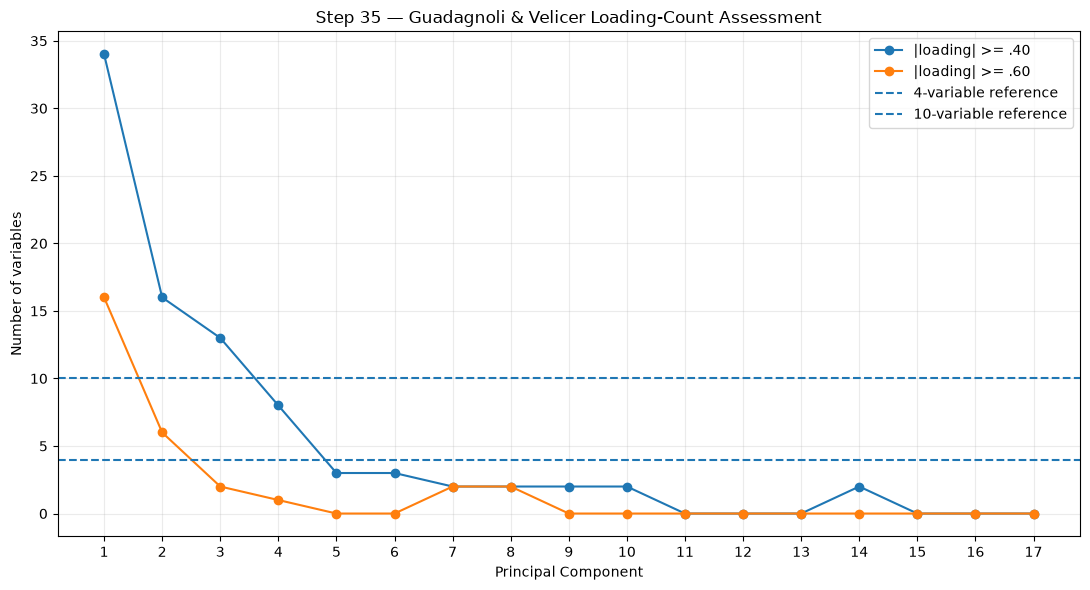


GUADAGNOLI & VELICER (1988) INTERPRETATION

Sample size:
  N = 673

Under the published recommendations:
  A component with >=4 loadings around |.60| or higher has particularly strong stability support.
  A component with approximately >=10 variables around |.40| can also be well supported when N is not very small.
  Components defined by only a few low loadings should be approached cautiously; G&V indicate that N around 300 or larger is required before such patterns are interpreted.

Current dataset:
  N = 673, so the absolute sample-size requirement for cautiously considering weakly defined patterns is satisfied.

However:
  Sample size alone does not make a weak component strongly defined.
  Loading magnitude and number of defining variables remain central to the assessment.

STEP 35 COMPLETE — GUADAGNOLI & VELICER (1988)

No invented saturation categories were used.

Assessment was based directly on:
  Number of variables loading on each component
  Magnitude of those loadings
  A

In [46]:
# ============================================================
# STEP 35 — GUADAGNOLI & VELICER (1988)
# COMPONENT-PATTERN STABILITY ASSESSMENT
# ============================================================
#
# PURPOSE
# -------
#
# Assess the stability / interpretability of the PCA component
# pattern using the post-analysis recommendations reported by:
#
# Guadagnoli, E. & Velicer, W. F. (1988).
# Relation of Sample Size to the Stability of Component Patterns.
# Psychological Bulletin, 103(2), 265-275.
#
#
# IMPORTANT METHODOLOGICAL NOTE
# -----------------------------
#
# This script does NOT attempt to reproduce the authors'
# complete Monte Carlo simulation study.
#
# Instead, it applies their published recommendations for
# assessing an observed component pattern after PCA.
#
#
# GUADAGNOLI & VELICER POST-ANALYSIS GUIDANCE
# --------------------------------------------
#
# The authors recommend evaluating:
#
#   1. The magnitude of component loadings.
#   2. The number of variables defining each component.
#   3. Absolute sample size.
#
#
# Their published recommendations include:
#
#   A. If a component has FOUR OR MORE variables with
#      loadings above approximately |.60|:
#
#          the pattern may be interpreted regardless
#          of sample size.
#
#
#   B. If a component is defined by MANY variables
#      (approximately 10-12) with relatively low loadings
#      around |.40|:
#
#          the solution should generally be accurate except
#          at very low sample sizes (N < 150).
#
#
#   C. If a component has only a FEW variables and LOW
#      component loadings:
#
#          the pattern should not generally be interpreted
#          unless the sample size is at least approximately
#          N = 300.
#
#
# In the present dataset:
#
#       N = 673
#
# Therefore, the sample-size condition in criterion C is met.
#
# HOWEVER:
#
# Meeting N >= 300 does NOT automatically make a weak
# component substantively meaningful.
#
# The script therefore reports the Guadagnoli & Velicer
# evidence directly and does NOT invent additional categories
# such as "well saturated", "moderately saturated", etc.
#
#
# No component is removed automatically in this step.
#
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from IPython.display import display


# ============================================================
# 2. SETTINGS FROM GUADAGNOLI & VELICER (1988)
# ============================================================

HIGH_LOADING_THRESHOLD = 0.60


LOW_LOADING_REFERENCE = 0.40


HIGH_LOADING_VARIABLE_COUNT = 4


MANY_VARIABLES_LOWER_BOUND = 10


MANY_VARIABLES_UPPER_BOUND = 12


LOW_SAMPLE_BOUND = 150


WEAK_PATTERN_SAMPLE_BOUND = 300


# ============================================================
# 3. CURRENT RETENTION DIAGNOSTICS
# ============================================================

SCREE_COMPONENTS = 4

PARALLEL_COMPONENTS = 12

ORIGINAL_MAP_COMPONENTS = 11

REVISED_MAP_COMPONENTS = 17


# ============================================================
# 4. VERIFY REQUIRED PCA OBJECTS
# ============================================================

required_objects = [
    "pca_loadings",
    "X_standardized"
]


missing_objects = [
    object_name
    for object_name in required_objects
    if object_name not in globals()
]


if missing_objects:

    raise RuntimeError(
        "Required PCA objects are missing:\n\n"
        +
        "\n".join(
            missing_objects
        )
        +
        "\n\nRun Step 31 before running Step 35."
    )


# ============================================================
# 5. VALIDATE PCA LOADING MATRIX
# ============================================================

if not isinstance(
    pca_loadings,
    pd.DataFrame
):

    raise RuntimeError(
        "`pca_loadings` is not a pandas DataFrame."
    )


if pca_loadings.empty:

    raise RuntimeError(
        "`pca_loadings` is empty."
    )


loading_matrix = (

    pca_loadings

    .astype(
        float
    )
)


if not np.isfinite(
    loading_matrix.to_numpy()
).all():

    raise RuntimeError(
        "The PCA loading matrix contains NaN or "
        "infinite values."
    )


# ============================================================
# 6. GET SAMPLE SIZE AND DIMENSIONS
# ============================================================

X_gv = np.asarray(
    X_standardized,
    dtype=float
)


if X_gv.ndim != 2:

    raise RuntimeError(
        "`X_standardized` must be two-dimensional."
    )


N, P = X_gv.shape


number_of_components = (
    loading_matrix.shape[1]
)


if (
    loading_matrix.shape[0]
    !=
    P
):

    raise RuntimeError(
        "The loading-matrix variable count does not match "
        "the standardized PCA matrix."
    )


# ============================================================
# 7. PRINT METHODOLOGICAL INPUT
# ============================================================

print(
    "\n"
    + "=" * 130
)


print(
    "STEP 35 — GUADAGNOLI & VELICER (1988) "
    "COMPONENT-PATTERN ASSESSMENT"
)


print(
    "=" * 130
)


print(
    "\nDataset:"
)


print(
    f"  Observations (N): {N:,}"
)


print(
    f"  Variables (P):    {P:,}"
)


print(
    "\nPublished assessment criteria used:"
)


print(
    "  >= 4 variables with |loading| >= .60"
)


print(
    "  approximately 10-12 variables around |loading| = .40"
)


print(
    "  weak / few-variable patterns require approximately "
    "N >= 300 before interpretation is considered"
)


print(
    "\nCurrent sample-size status:"
)


if N >= WEAK_PATTERN_SAMPLE_BOUND:

    print(
        f"  N = {N:,} >= {WEAK_PATTERN_SAMPLE_BOUND}"
    )


    print(
        "  Sample-size condition for weakly defined "
        "patterns is satisfied."
    )


elif N >= LOW_SAMPLE_BOUND:

    print(
        f"  {LOW_SAMPLE_BOUND} <= N < "
        f"{WEAK_PATTERN_SAMPLE_BOUND}"
    )


else:

    print(
        f"  N < {LOW_SAMPLE_BOUND}"
    )


# ============================================================
# 8. BUILD COMPONENT-LEVEL ASSESSMENT
# ============================================================

gv_rows = []


for component_number in range(
    1,
    number_of_components + 1
):

    component_name = (
        f"PC{component_number}"
    )


    component_loadings = (

        loading_matrix[
            component_name
        ]
    )


    absolute_loadings = (

        component_loadings
        .abs()
    )


    n_ge_060 = int(
        (
            absolute_loadings
            >=
            HIGH_LOADING_THRESHOLD
        )
        .sum()
    )


    n_ge_040 = int(
        (
            absolute_loadings
            >=
            LOW_LOADING_REFERENCE
        )
        .sum()
    )


    maximum_absolute_loading = float(
        absolute_loadings.max()
    )


    # --------------------------------------------------------
    # Direct criteria based on the paper's recommendations
    # --------------------------------------------------------

    criterion_four_at_060 = (
        n_ge_060
        >=
        HIGH_LOADING_VARIABLE_COUNT
    )


    criterion_many_at_040 = (
        n_ge_040
        >=
        MANY_VARIABLES_LOWER_BOUND
    )


    sample_ge_150 = (
        N
        >=
        LOW_SAMPLE_BOUND
    )


    sample_ge_300 = (
        N
        >=
        WEAK_PATTERN_SAMPLE_BOUND
    )


    # --------------------------------------------------------
    # Evidence statement
    #
    # No invented qualitative scale is used.
    # --------------------------------------------------------

    if criterion_four_at_060:

        gv_assessment = (
            "Meets G&V high-saturation criterion"
        )


    elif (
        criterion_many_at_040
        and
        sample_ge_150
    ):

        gv_assessment = (
            "Meets G&V many-variable / ~.40 criterion"
        )


    elif sample_ge_300:

        gv_assessment = (
            "Does not meet stronger loading-count criteria; "
            "N>=300 permits cautious interpretation of "
            "few/low-loading pattern"
        )


    else:

        gv_assessment = (
            "Weak/few-variable pattern with insufficient "
            "sample size under G&V guidance"
        )


    gv_rows.append(
        {

            "component":
                component_name,

            "component_number":
                component_number,

            "maximum_absolute_loading":
                maximum_absolute_loading,

            "variables_abs_loading_ge_040":
                n_ge_040,

            "variables_abs_loading_ge_060":
                n_ge_060,

            "criterion_4_or_more_ge_060":
                criterion_four_at_060,

            "criterion_10_or_more_ge_040":
                criterion_many_at_040,

            "sample_N_ge_150":
                sample_ge_150,

            "sample_N_ge_300":
                sample_ge_300,

            "GV_1988_assessment":
                gv_assessment
        }
    )


guadagnoli_velicer_component_assessment = pd.DataFrame(
    gv_rows
)


# ============================================================
# 9. DISPLAY PC1-PC17
# ============================================================

candidate_max_pc = min(
    17,
    number_of_components
)


gv_candidate_components = (

    guadagnoli_velicer_component_assessment[
        guadagnoli_velicer_component_assessment[
            "component_number"
        ]
        <=
        candidate_max_pc
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


print(
    "\n"
    + "=" * 170
)


print(
    "GUADAGNOLI & VELICER (1988) ASSESSMENT — PC1-PC17"
)


print(
    "=" * 170
)


display(
    gv_candidate_components.round(
        4
    )
)


# ============================================================
# 10. IDENTIFY COMPONENTS MEETING THE STRONGEST G&V RULE
# ============================================================

gv_high_saturation_components = (

    guadagnoli_velicer_component_assessment[
        guadagnoli_velicer_component_assessment[
            "criterion_4_or_more_ge_060"
        ]
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


print(
    "\n"
    + "=" * 140
)


print(
    "COMPONENTS WITH >= 4 LOADINGS AT |.60| OR ABOVE"
)


print(
    "=" * 140
)


if gv_high_saturation_components.empty:

    print(
        "\nNone."
    )


else:

    display(
        gv_high_saturation_components[
            [
                "component",
                "variables_abs_loading_ge_060",
                "maximum_absolute_loading"
            ]
        ]
        .round(
            4
        )
    )


# ============================================================
# 11. IDENTIFY COMPONENTS WITH >=10 LOADINGS AT |.40|
# ============================================================

gv_many_variable_components = (

    guadagnoli_velicer_component_assessment[
        guadagnoli_velicer_component_assessment[
            "criterion_10_or_more_ge_040"
        ]
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


print(
    "\n"
    + "=" * 140
)


print(
    "COMPONENTS WITH >= 10 LOADINGS AT |.40| OR ABOVE"
)


print(
    "=" * 140
)


if gv_many_variable_components.empty:

    print(
        "\nNone."
    )


else:

    display(
        gv_many_variable_components[
            [
                "component",
                "variables_abs_loading_ge_040",
                "maximum_absolute_loading"
            ]
        ]
        .round(
            4
        )
    )


# ============================================================
# 12. DISPLAY CURRENT RETENTION BOUNDARIES
# ============================================================

key_component_numbers = sorted(
    set(
        [
            SCREE_COMPONENTS,
            ORIGINAL_MAP_COMPONENTS,
            PARALLEL_COMPONENTS,
            REVISED_MAP_COMPONENTS
        ]
    )
)


gv_retention_boundary_comparison = (

    guadagnoli_velicer_component_assessment[
        guadagnoli_velicer_component_assessment[
            "component_number"
        ]
        .isin(
            key_component_numbers
        )
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


print(
    "\n"
    + "=" * 170
)


print(
    "GUADAGNOLI & VELICER ASSESSMENT "
    "AT CURRENT RETENTION BOUNDARIES"
)


print(
    "=" * 170
)


display(
    gv_retention_boundary_comparison.round(
        4
    )
)


# ============================================================
# 13. PRINT STRONGEST LOADINGS FOR PC1-PC17
# ============================================================

TOP_LOADINGS_TO_SHOW = 12


gv_top_loadings = {}


for component_number in range(
    1,
    candidate_max_pc + 1
):

    component_name = (
        f"PC{component_number}"
    )


    component_series = (

        loading_matrix[
            component_name
        ]
    )


    ordered_indices = (

        component_series
        .abs()

        .sort_values(
            ascending=False
        )

        .index
    )


    strongest = (

        component_series

        .loc[
            ordered_indices
        ]

        .head(
            TOP_LOADINGS_TO_SHOW
        )
    )


    strongest_table = pd.DataFrame(
        {

            "variable":
                strongest.index,

            "loading":
                strongest.values,

            "absolute_loading":
                strongest.abs().values
        }
    )


    strongest_table[
        "abs_loading_ge_040"
    ] = (

        strongest_table[
            "absolute_loading"
        ]
        >=
        LOW_LOADING_REFERENCE
    )


    strongest_table[
        "abs_loading_ge_060"
    ] = (

        strongest_table[
            "absolute_loading"
        ]
        >=
        HIGH_LOADING_THRESHOLD
    )


    gv_top_loadings[
        component_name
    ] = strongest_table


# ============================================================
# 14. DISPLAY LOADINGS AROUND IMPORTANT BOUNDARY
# ============================================================
#
# PC4-PC17 are shown because they span the competing
# retention recommendations.
#
# ============================================================

for component_number in range(
    4,
    candidate_max_pc + 1
):

    component_name = (
        f"PC{component_number}"
    )


    print(
        "\n"
        + "-" * 120
    )


    print(
        component_name
    )


    print(
        "-" * 120
    )


    display(
        gv_top_loadings[
            component_name
        ]
        .round(
            4
        )
    )


# ============================================================
# 15. PLOT NUMBER OF LOADINGS >= .40 AND >= .60
# ============================================================

plot_df = (

    gv_candidate_components

    .copy()
)


fig, ax = plt.subplots(
    figsize=(
        11,
        6
    )
)


ax.plot(

    plot_df[
        "component_number"
    ],

    plot_df[
        "variables_abs_loading_ge_040"
    ],

    marker="o",

    label=
        "|loading| >= .40"
)


ax.plot(

    plot_df[
        "component_number"
    ],

    plot_df[
        "variables_abs_loading_ge_060"
    ],

    marker="o",

    label=
        "|loading| >= .60"
)


ax.axhline(

    HIGH_LOADING_VARIABLE_COUNT,

    linestyle="--",

    label=
        "4-variable reference"
)


ax.axhline(

    MANY_VARIABLES_LOWER_BOUND,

    linestyle="--",

    label=
        "10-variable reference"
)


ax.set_xlabel(
    "Principal Component"
)


ax.set_ylabel(
    "Number of variables"
)


ax.set_title(
    "Step 35 — Guadagnoli & Velicer Loading-Count Assessment"
)


ax.set_xticks(
    range(
        1,
        candidate_max_pc + 1
    )
)


ax.legend()


ax.grid(
    alpha=0.25
)


plt.tight_layout()


plt.show()


# ============================================================
# 16. CREATE RETENTION-EVIDENCE TABLE
# ============================================================

component_retention_evidence = pd.DataFrame(
    {

        "method": [
            "Cattell Scree Test",
            "Horn Parallel Analysis",
            "Velicer Original MAP",
            "Velicer Revised MAP"
        ],

        "components_suggested": [
            SCREE_COMPONENTS,
            PARALLEL_COMPONENTS,
            ORIGINAL_MAP_COMPONENTS,
            REVISED_MAP_COMPONENTS
        ]
    }
)


# ============================================================
# 17. PRINT DIRECT METHODOLOGICAL CONCLUSION
# ============================================================

print(
    "\n"
    + "=" * 130
)


print(
    "GUADAGNOLI & VELICER (1988) INTERPRETATION"
)


print(
    "=" * 130
)


print(
    "\nSample size:"
)


print(
    f"  N = {N:,}"
)


print(
    "\nUnder the published recommendations:"
)


print(
    "  A component with >=4 loadings around |.60| or "
    "higher has particularly strong stability support."
)


print(
    "  A component with approximately >=10 variables "
    "around |.40| can also be well supported when N is "
    "not very small."
)


print(
    "  Components defined by only a few low loadings "
    "should be approached cautiously; G&V indicate that "
    "N around 300 or larger is required before such "
    "patterns are interpreted."
)


print(
    "\nCurrent dataset:"
)


print(
    f"  N = {N:,}, so the absolute sample-size requirement "
    "for cautiously considering weakly defined patterns "
    "is satisfied."
)


print(
    "\nHowever:"
)


print(
    "  Sample size alone does not make a weak component "
    "strongly defined."
)


print(
    "  Loading magnitude and number of defining variables "
    "remain central to the assessment."
)


# ============================================================
# 18. FINAL STEP 35 SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 130
)


print(
    "STEP 35 COMPLETE — GUADAGNOLI & VELICER (1988)"
)


print(
    "=" * 130
)


print(
    "\nNo invented saturation categories were used."
)


print(
    "\nAssessment was based directly on:"
)


print(
    "  Number of variables loading on each component"
)


print(
    "  Magnitude of those loadings"
)


print(
    "  Absolute sample size"
)


print(
    "\nKey loading references:"
)


print(
    "  |.60| with >=4 defining variables"
)


print(
    "  |.40| with approximately 10-12 defining variables"
)


print(
    "\nAbsolute sample-size references:"
)


print(
    "  N < 150: low-loading patterns are problematic"
)


print(
    "  N >= 300: few-variable / low-loading patterns may "
    "be cautiously interpreted"
)


print(
    "\nMain output objects:"
)


print(
    "  guadagnoli_velicer_component_assessment"
)


print(
    "  gv_candidate_components"
)


print(
    "  gv_high_saturation_components"
)


print(
    "  gv_many_variable_components"
)


print(
    "  gv_retention_boundary_comparison"
)


print(
    "  gv_top_loadings"
)


print(
    "\nIMPORTANT:"
)


print(
    "  No PCA components were removed."
)


print(
    "  No PCA was re-fitted."
)


print(
    "  Step 31 remains the underlying PCA solution."
)


print(
    "\n"
    + "=" * 130
)

### 36. Bootstrap PCA Component-Pattern Stability


STEP 36 — BOOTSTRAP PCA COMPONENT-PATTERN STABILITY

Dataset:
  Observations: 673
  Variables:    74

Bootstrap replications:
  1,000

Components evaluated:
  PC1-PC17

Bootstrap pipeline:
  Resample players with replacement
  Re-standardize within bootstrap sample
  Re-fit classical PCA
  Match bootstrap PCs to original PCs
  Correct arbitrary sign reversals
  Measure loading-pattern congruence

BOOTSTRAP COMPONENT-PATTERN STABILITY — PC1-PC17


,component,reference_eigenvalue,reference_variance_percent,mean_congruence,median_congruence,congruence_p5,congruence_p25,congruence_p75,congruence_p95,minimum_congruence,same_ordinal_PC_percent,median_matched_PC
0,PC1,13.4065,18.0899,0.9956,0.9962,0.9914,0.9948,0.9970,0.9978,0.9819,100.0,1.0
1,PC2,7.8197,10.5515,0.9834,0.9889,0.9531,0.9814,0.9922,0.9945,0.7975,100.0,2.0
2,PC3,6.0584,8.1748,0.9791,0.9841,0.9509,0.9767,0.9880,0.9915,0.7954,100.0,3.0
3,PC4,3.0061,4.0563,0.8809,0.9148,0.7030,0.8292,0.9497,0.9729,0.5916,84.6,4.0
4,PC5,2.7332,3.6880,0.8307,0.8512,0.6530,0.7609,0.9115,0.9533,0.4187,78.2,5.0
5,PC6,2.3808,3.2125,0.8135,0.8286,0.6278,0.7468,0.8916,0.9386,0.4481,81.2,6.0
6,PC7,2.1573,2.9110,0.7842,0.7979,0.6116,0.7177,0.8637,0.9175,0.3981,78.1,7.0
7,PC8,1.9208,2.5918,0.7737,0.7872,0.5788,0.7106,0.8562,0.9147,0.3354,80.2,8.0
8,PC9,1.7126,2.3109,0.7099,0.7193,0.5253,0.6281,0.7986,0.8752,0.3652,57.3,9.0
9,PC10,1.6301,2.1995,0.6627,0.6671,0.4573,0.5859,0.7485,0.8433,0.1837,43.4,10.0



FOCUSED STABILITY VIEW — PC1-PC10


,component,reference_eigenvalue,reference_variance_percent,mean_congruence,median_congruence,congruence_p5,congruence_p25,congruence_p75,congruence_p95,minimum_congruence,same_ordinal_PC_percent,median_matched_PC
0,PC1,13.4065,18.0899,0.9956,0.9962,0.9914,0.9948,0.9970,0.9978,0.9819,100.0,1.0
1,PC2,7.8197,10.5515,0.9834,0.9889,0.9531,0.9814,0.9922,0.9945,0.7975,100.0,2.0
2,PC3,6.0584,8.1748,0.9791,0.9841,0.9509,0.9767,0.9880,0.9915,0.7954,100.0,3.0
3,PC4,3.0061,4.0563,0.8809,0.9148,0.7030,0.8292,0.9497,0.9729,0.5916,84.6,4.0
4,PC5,2.7332,3.6880,0.8307,0.8512,0.6530,0.7609,0.9115,0.9533,0.4187,78.2,5.0
5,PC6,2.3808,3.2125,0.8135,0.8286,0.6278,0.7468,0.8916,0.9386,0.4481,81.2,6.0
6,PC7,2.1573,2.9110,0.7842,0.7979,0.6116,0.7177,0.8637,0.9175,0.3981,78.1,7.0
7,PC8,1.9208,2.5918,0.7737,0.7872,0.5788,0.7106,0.8562,0.9147,0.3354,80.2,8.0
8,PC9,1.7126,2.3109,0.7099,0.7193,0.5253,0.6281,0.7986,0.8752,0.3652,57.3,9.0
9,PC10,1.6301,2.1995,0.6627,0.6671,0.4573,0.5859,0.7485,0.8433,0.1837,43.4,10.0



BOOTSTRAP STABILITY — PC4-PC8 RETENTION BOUNDARY


...

,component,variable,reference_loading,bootstrap_median_loading,bootstrap_p5,bootstrap_p95,interval_excludes_zero,absolute_reference_loading
0,PC6,squawka_aerial_duels_won_per_90,0.4868,0.4121,0.0870,0.6442,True,0.4868
1,PC6,squawka_ground_duel_success,0.4616,0.3985,0.0945,0.5969,True,0.4616
2,PC6,squawka_aerial_duels_contested_per_90,0.4404,0.3780,0.0699,0.5944,True,0.4404
3,PC6,squawka_ground_duels_won_per_90,0.3911,0.3351,0.0945,0.5200,True,0.3911
4,PC6,squawka_clearances_per_90,0.3312,0.2833,0.1619,0.3653,True,0.3312
5,PC6,squawka_lay_offs_completed_per_90,-0.3300,-0.2874,-0.4077,-0.1412,True,0.3300
6,PC6,squawka_passing_accuracy,-0.3218,-0.2803,-0.4177,-0.0669,True,0.3218
7,PC6,squawka_backward_passes_per_90,-0.3098,-0.2610,-0.3601,-0.1354,True,0.3098
8,PC6,squawka_possession_lost_per_90,0.2970,0.2565,0.0809,0.3787,True,0.2970
9,PC6,squawka_tackles_made_per_90,0.2952,0.2539,-0.0038,0.4707,False,0.2952



--------------------------------------------------------------------------------------------------------------------------------------------
PC7 — STRONGEST LOADING BOOTSTRAP STABILITY
--------------------------------------------------------------------------------------------------------------------------------------------


,component,variable,reference_loading,bootstrap_median_loading,bootstrap_p5,bootstrap_p95,interval_excludes_zero,absolute_reference_loading
0,PC7,squawka_fouls_per_90,0.6421,0.5312,0.3271,0.6886,True,0.6421
1,PC7,squawka_fouls_from_tackle_attempts_per_90,0.6187,0.5098,0.3089,0.6628,True,0.6187
2,PC7,fbref_crdy_per_90,0.3652,0.2970,0.1033,0.4576,True,0.3652
3,PC7,squawka_aerial_duels_won_per_90,0.3117,0.2621,-0.0798,0.5526,False,0.3117
4,PC7,squawka_ground_duel_success,-0.3103,-0.2667,-0.5346,0.0926,False,0.3103
5,PC7,squawka_take_ons_completed_per_90,-0.2857,-0.2395,-0.3659,-0.0613,True,0.2857
6,PC7,squawka_aerial_duels_contested_per_90,0.2574,0.2114,-0.0889,0.4763,False,0.2574
7,PC7,sofascore_distance_covered_per_90_km,0.2508,0.2063,-0.0227,0.3680,False,0.2508
8,PC7,squawka_long_passes_attempted_per_90,0.2462,0.1977,-0.0198,0.3798,False,0.2462
9,PC7,squawka_passing_accuracy,-0.2431,-0.1947,-0.3780,0.0220,False,0.2431



--------------------------------------------------------------------------------------------------------------------------------------------
PC8 — STRONGEST LOADING BOOTSTRAP STABILITY
--------------------------------------------------------------------------------------------------------------------------------------------


,component,variable,reference_loading,bootstrap_median_loading,bootstrap_p5,bootstrap_p95,interval_excludes_zero,absolute_reference_loading
0,PC8,fbref_pkatt_per_90,0.7595,0.6234,0.4177,0.7657,True,0.7595
1,PC8,fbref_pk_per_90,0.7410,0.6120,0.3882,0.7580,True,0.7410
2,PC8,squawka_ground_duel_success,0.3397,0.2695,0.0374,0.4840,True,0.3397
3,PC8,squawka_penalties_won_per_90,0.3221,0.2626,0.0460,0.4327,True,0.3221
4,PC8,squawka_ground_duels_won_per_90,0.2444,0.1976,0.0506,0.3318,True,0.2444
5,PC8,squawka_offsides_per_90,0.2347,0.1606,-0.0946,0.4159,False,0.2347
6,PC8,squawka_tackles_made_per_90,0.2268,0.1810,-0.0183,0.3422,False,0.2268
7,PC8,squawka_fouls_won_per_90,0.2051,0.1687,0.0252,0.2899,True,0.2051
8,PC8,sofascore_number_of_sprints_per_90,-0.1874,-0.1567,-0.3509,0.0811,False,0.1874
9,PC8,sofascore_distance_covered_per_90_km,-0.1811,-0.1514,-0.3317,0.0333,False,0.1811


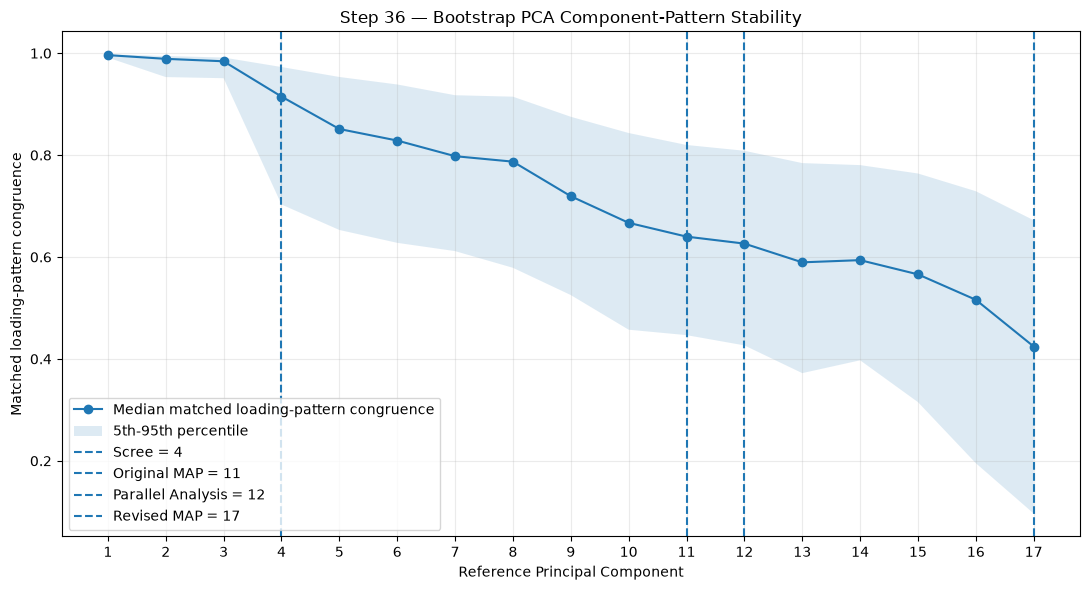

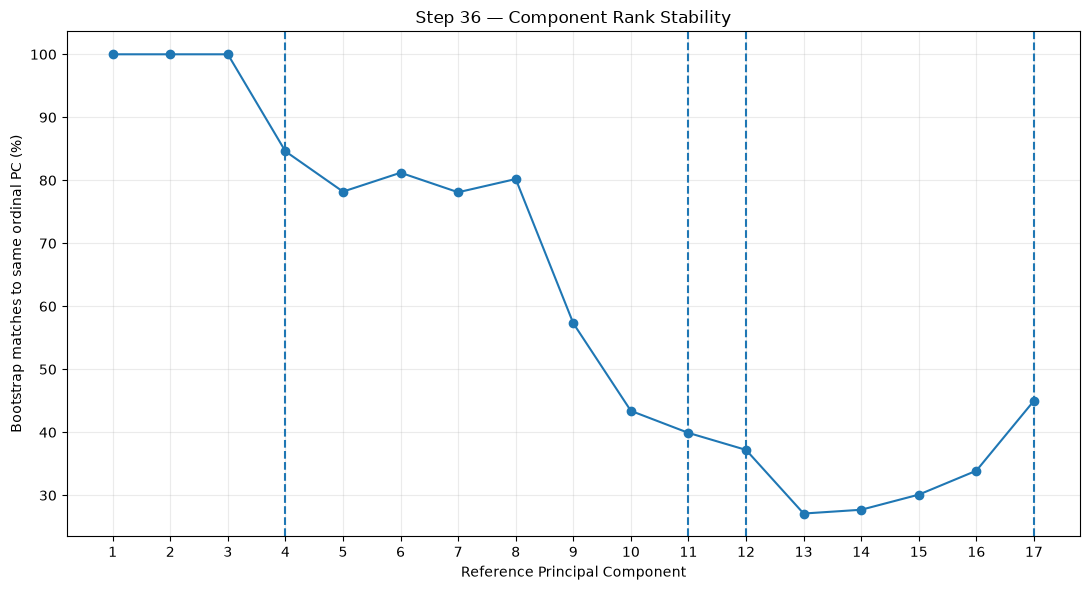


COMPONENT-RETENTION EVIDENCE INCLUDING BOOTSTRAP


,method,result
0,Cattell Scree Test,4 PCs
1,Horn Parallel Analysis,12 PCs
2,Velicer Original MAP,11 PCs
3,Velicer Revised MAP,17 PCs
4,Guadagnoli & Velicer loading-pattern assessment,Strongest support concentrated in early PCs
5,Bootstrap component-pattern stability,See bootstrap_component_stability



HOW TO INTERPRET STEP 36

The key column is:
  median_congruence

Also inspect:
  congruence_p5

This tells us whether a component usually reproduces its loading pattern and how weak that reproduction can be across bootstrap samples.

Pay particular attention to:
  PC1-PC4
  versus
  PC5-PC8

If PC1-PC4 show clearly stronger and more consistent loading-pattern congruence than later PCs, the bootstrap evidence would reinforce the 4-component Scree solution.

If PC5-PC6 reproduce almost as consistently as PC1-PC4, then a somewhat larger solution remains defensible.

Do not interpret component-order swaps alone as failure.
  Components with similar eigenvalues can change order.
  This is why the primary statistic uses optimal loading-pattern matching.

STEP 36 COMPLETE — BOOTSTRAP PCA PATTERN STABILITY

Bootstrap replications:
  1,000

Observations per bootstrap sample:
  673

Performance variables:
  74

Components evaluated:
  PC1-PC17

Matching procedure:
  Hungarian optimal one-to-on

In [47]:
# ============================================================
# STEP 36 — BOOTSTRAP PCA COMPONENT-PATTERN STABILITY
# ============================================================
#
# PURPOSE
# -------
#
# Empirically test whether the component patterns found in
# Step 31 reproduce when the player sample is resampled.
#
# This follows directly from the stability question raised by:
#
# Guadagnoli, E. & Velicer, W. F. (1988).
# Relation of Sample Size to the Stability of Component Patterns.
# Psychological Bulletin, 103(2), 265-275.
#
#
# IMPORTANT
# ---------
#
# Guadagnoli & Velicer (1988) studied component-pattern
# stability through simulation.
#
# This step does NOT claim to reproduce their Monte Carlo study
# verbatim.
#
# Instead, it performs an empirical bootstrap stability
# diagnostic on THIS dataset.
#
#
# PROCEDURE
# ---------
#
# For each bootstrap replication:
#
#   1. Sample N players WITH replacement.
#
#   2. Standardize all performance variables again inside
#      that bootstrap sample.
#
#   3. Re-run classical PCA.
#
#   4. Compare the bootstrap loading patterns with the
#      original Step 31 loading patterns.
#
#   5. Allow components to switch order.
#
#      PCA components can occasionally exchange positions
#      across bootstrap samples when eigenvalues are similar.
#
#      Therefore, components are matched using the Hungarian
#      assignment algorithm so that the bootstrap loading
#      patterns are paired with the most similar original
#      component patterns.
#
#   6. Correct arbitrary PCA sign reversals.
#
#      A loading vector and its negative represent the same
#      principal component mathematically.
#
#   7. Quantify component-pattern similarity using Tucker-style
#      congruence:
#
#            phi = (a' b) /
#                  sqrt[(a' a)(b' b)]
#
#
# PRIMARY QUESTION
# ----------------
#
# Do PC1-PC4 reproduce consistently?
#
# And, compared with them, how stable are PC5-PC17?
#
#
# CURRENT RETENTION EVIDENCE
# --------------------------
#
#   Scree Test:             4 PCs
#   Horn Parallel Analysis: 12 PCs
#   Velicer Original MAP:   11 PCs
#   Velicer Revised MAP:    17 PCs
#
#   Guadagnoli & Velicer loading assessment:
#
#       PC1-PC3 = strongest loading-pattern support
#       PC4     = plausible / interpretable
#       later PCs increasingly narrow or weakly defined
#
#
# THIS STEP IS DIAGNOSTIC ONLY.
#
# No PCA components are deleted.
# No player observations are deleted.
# Step 31 remains the reference PCA solution.
#
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from scipy.optimize import linear_sum_assignment

from IPython.display import display


# ============================================================
# 2. SETTINGS
# ============================================================

N_BOOTSTRAPS = 1000


RANDOM_STATE = 42


# ------------------------------------------------------------
# Examine all PCs implicated by the existing diagnostics.
# ------------------------------------------------------------

MAX_PC_TO_TEST = 17


# ------------------------------------------------------------
# Quantiles reported for bootstrap stability.
#
# These are descriptive uncertainty summaries.
# ------------------------------------------------------------

LOWER_PERCENTILE = 5

UPPER_PERCENTILE = 95


# ============================================================
# 3. VERIFY REQUIRED OBJECTS EXIST
# ============================================================

required_objects = [
    "X_df",
    "pca_loadings",
    "pca_eigenvalues",
    "pca_explained_variance_percent",
    "pca_variables"
]


missing_objects = [
    object_name
    for object_name in required_objects
    if object_name not in globals()
]


if missing_objects:

    raise RuntimeError(
        "Required PCA / preprocessing objects are missing:\n\n"
        +
        "\n".join(
            missing_objects
        )
        +
        "\n\nRun Steps 30 and 31 before running Step 36."
    )


# ============================================================
# 4. PREPARE ORIGINAL PERFORMANCE MATRIX
# ============================================================
#
# X_df contains the non-standardized performance variables
# entering Step 30.
#
# We deliberately resample X_df rather than simply resampling
# the already standardized matrix.
#
# This lets each bootstrap replication reproduce the pipeline:
#
#       sample players
#       -> standardize
#       -> PCA
#
# ============================================================

X_original_df = (

    X_df[
        pca_variables
    ]

    .copy()
)


X_original = X_original_df.to_numpy(
    dtype=float
)


if not np.isfinite(
    X_original
).all():

    raise RuntimeError(
        "The original performance matrix contains NaN or "
        "infinite values."
    )


N, P = X_original.shape


# ============================================================
# 5. VALIDATE PCA LOADING MATRIX
# ============================================================

if not isinstance(
    pca_loadings,
    pd.DataFrame
):

    raise RuntimeError(
        "`pca_loadings` is not a pandas DataFrame."
    )


if (
    pca_loadings.shape[
        0
    ]
    !=
    P
):

    raise RuntimeError(
        "The Step 31 loading matrix does not have the same "
        "number of variables as X_df."
    )


if (
    MAX_PC_TO_TEST
    >
    pca_loadings.shape[
        1
    ]
):

    MAX_PC_TO_TEST = (
        pca_loadings.shape[
            1
        ]
    )


# ============================================================
# 6. CREATE REFERENCE LOADING MATRIX
# ============================================================
#
# Only PC1-PC17 are used in the matching problem.
#
# Components can exchange positions within this candidate
# solution during bootstrap resampling.
#
# ============================================================

reference_component_names = [
    f"PC{i}"
    for i in range(
        1,
        MAX_PC_TO_TEST + 1
    )
]


reference_loadings = (

    pca_loadings[
        reference_component_names
    ]

    .to_numpy(
        dtype=float
    )
)


reference_eigenvalues = np.asarray(
    pca_eigenvalues[
        :MAX_PC_TO_TEST
    ],
    dtype=float
)


reference_variance = np.asarray(
    pca_explained_variance_percent[
        :MAX_PC_TO_TEST
    ],
    dtype=float
)


# ============================================================
# 7. TUCKER-STYLE CONGRUENCE FUNCTION
# ============================================================

def loading_congruence(
    vector_a,
    vector_b
):

    vector_a = np.asarray(
        vector_a,
        dtype=float
    )


    vector_b = np.asarray(
        vector_b,
        dtype=float
    )


    denominator = (

        np.sqrt(
            np.sum(
                vector_a ** 2
            )
        )

        *

        np.sqrt(
            np.sum(
                vector_b ** 2
            )
        )
    )


    if denominator <= 0:

        return np.nan


    return float(
        np.dot(
            vector_a,
            vector_b
        )
        /
        denominator
    )


# ============================================================
# 8. PRINT INPUT SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 130
)


print(
    "STEP 36 — BOOTSTRAP PCA COMPONENT-PATTERN STABILITY"
)


print(
    "=" * 130
)


print(
    "\nDataset:"
)


print(
    f"  Observations: {N:,}"
)


print(
    f"  Variables:    {P:,}"
)


print(
    "\nBootstrap replications:"
)


print(
    f"  {N_BOOTSTRAPS:,}"
)


print(
    "\nComponents evaluated:"
)


print(
    f"  PC1-PC{MAX_PC_TO_TEST}"
)


print(
    "\nBootstrap pipeline:"
)


print(
    "  Resample players with replacement"
)


print(
    "  Re-standardize within bootstrap sample"
)


print(
    "  Re-fit classical PCA"
)


print(
    "  Match bootstrap PCs to original PCs"
)


print(
    "  Correct arbitrary sign reversals"
)


print(
    "  Measure loading-pattern congruence"
)


# ============================================================
# 9. RANDOM NUMBER GENERATOR
# ============================================================

rng = np.random.default_rng(
    RANDOM_STATE
)


# ============================================================
# 10. STORAGE ARRAYS
# ============================================================
#
# Dimensions:
#
#   bootstrap × reference component
#
# ============================================================

bootstrap_congruence = np.full(
    (
        N_BOOTSTRAPS,
        MAX_PC_TO_TEST
    ),
    np.nan,
    dtype=float
)


bootstrap_matched_component = np.full(
    (
        N_BOOTSTRAPS,
        MAX_PC_TO_TEST
    ),
    np.nan,
    dtype=float
)


bootstrap_eigenvalues = np.full(
    (
        N_BOOTSTRAPS,
        MAX_PC_TO_TEST
    ),
    np.nan,
    dtype=float
)


bootstrap_explained_variance = np.full(
    (
        N_BOOTSTRAPS,
        MAX_PC_TO_TEST
    ),
    np.nan,
    dtype=float
)


# ------------------------------------------------------------
# Store aligned loading vectors:
#
#   bootstrap × variable × reference PC
# ------------------------------------------------------------

bootstrap_aligned_loadings = np.full(
    (
        N_BOOTSTRAPS,
        P,
        MAX_PC_TO_TEST
    ),
    np.nan,
    dtype=float
)


# ============================================================
# 11. RUN BOOTSTRAP PCA
# ============================================================

for bootstrap_index in range(
    N_BOOTSTRAPS
):

    # --------------------------------------------------------
    # Draw players with replacement
    # --------------------------------------------------------

    sampled_indices = rng.integers(
        low=0,
        high=N,
        size=N
    )


    X_bootstrap_raw = (

        X_original[
            sampled_indices,
            :
        ]
    )


    # --------------------------------------------------------
    # Re-standardize inside bootstrap sample
    # --------------------------------------------------------

    bootstrap_scaler = StandardScaler(
        with_mean=True,
        with_std=True
    )


    X_bootstrap_standardized = (

        bootstrap_scaler

        .fit_transform(
            X_bootstrap_raw
        )
    )


    # --------------------------------------------------------
    # Safety check
    # --------------------------------------------------------

    if not np.isfinite(
        X_bootstrap_standardized
    ).all():

        raise RuntimeError(
            "A bootstrap sample produced non-finite "
            "standardized values."
        )


    # --------------------------------------------------------
    # Fit PCA
    # --------------------------------------------------------

    bootstrap_pca = PCA(
        n_components=None,
        svd_solver="full"
    )


    bootstrap_pca.fit(
        X_bootstrap_standardized
    )


    # --------------------------------------------------------
    # Extract first candidate PCs
    # --------------------------------------------------------

    bootstrap_values = (

        bootstrap_pca
        .explained_variance_[
            :MAX_PC_TO_TEST
        ]
    )


    bootstrap_variance = (

        bootstrap_pca
        .explained_variance_ratio_[
            :MAX_PC_TO_TEST
        ]

        *
        100
    )


    # --------------------------------------------------------
    # Interpretive loadings
    #
    # eigenvector × sqrt(eigenvalue)
    # --------------------------------------------------------

    bootstrap_loading_matrix = (

        bootstrap_pca
        .components_[
            :MAX_PC_TO_TEST,
            :
        ]
        .T

        *

        np.sqrt(
            bootstrap_values
        )
    )


    # ========================================================
    # 12. CREATE SIMILARITY MATRIX
    # ========================================================
    #
    # Rows:
    #   original/reference PCs
    #
    # Columns:
    #   bootstrap PCs
    #
    # Absolute congruence is used for matching because PCA
    # signs are arbitrary.
    #
    # ========================================================

    similarity_matrix = np.zeros(
        (
            MAX_PC_TO_TEST,
            MAX_PC_TO_TEST
        ),
        dtype=float
    )


    signed_similarity_matrix = np.zeros(
        (
            MAX_PC_TO_TEST,
            MAX_PC_TO_TEST
        ),
        dtype=float
    )


    for reference_index in range(
        MAX_PC_TO_TEST
    ):

        reference_vector = (

            reference_loadings[
                :,
                reference_index
            ]
        )


        for bootstrap_pc_index in range(
            MAX_PC_TO_TEST
        ):

            bootstrap_vector = (

                bootstrap_loading_matrix[
                    :,
                    bootstrap_pc_index
                ]
            )


            similarity = loading_congruence(
                reference_vector,
                bootstrap_vector
            )


            signed_similarity_matrix[
                reference_index,
                bootstrap_pc_index
            ] = similarity


            similarity_matrix[
                reference_index,
                bootstrap_pc_index
            ] = abs(
                similarity
            )


    # ========================================================
    # 13. OPTIMAL COMPONENT MATCHING
    # ========================================================
    #
    # Hungarian assignment finds the one-to-one pairing that
    # maximizes total absolute congruence.
    #
    # ========================================================

    reference_indices, matched_bootstrap_indices = (

        linear_sum_assignment(
            -similarity_matrix
        )
    )


    # ========================================================
    # 14. STORE MATCHED / SIGN-ALIGNED RESULTS
    # ========================================================

    for (
        reference_index,
        bootstrap_pc_index
    ) in zip(
        reference_indices,
        matched_bootstrap_indices
    ):

        signed_similarity = (

            signed_similarity_matrix[
                reference_index,
                bootstrap_pc_index
            ]
        )


        # ----------------------------------------------------
        # Correct arbitrary PCA sign reversal
        # ----------------------------------------------------

        sign_multiplier = (

            1.0

            if signed_similarity >= 0

            else -1.0
        )


        aligned_loading_vector = (

            bootstrap_loading_matrix[
                :,
                bootstrap_pc_index
            ]

            *
            sign_multiplier
        )


        aligned_congruence = loading_congruence(

            reference_loadings[
                :,
                reference_index
            ],

            aligned_loading_vector
        )


        bootstrap_congruence[
            bootstrap_index,
            reference_index
        ] = aligned_congruence


        bootstrap_matched_component[
            bootstrap_index,
            reference_index
        ] = (
            bootstrap_pc_index
            +
            1
        )


        bootstrap_eigenvalues[
            bootstrap_index,
            reference_index
        ] = (

            bootstrap_values[
                bootstrap_pc_index
            ]
        )


        bootstrap_explained_variance[
            bootstrap_index,
            reference_index
        ] = (

            bootstrap_variance[
                bootstrap_pc_index
            ]
        )


        bootstrap_aligned_loadings[
            bootstrap_index,
            :,
            reference_index
        ] = aligned_loading_vector


# ============================================================
# 15. VERIFY BOOTSTRAP FINISHED CORRECTLY
# ============================================================

if np.isnan(
    bootstrap_congruence
).any():

    raise RuntimeError(
        "One or more bootstrap component matches failed."
    )


# ============================================================
# 16. BUILD COMPONENT STABILITY SUMMARY
# ============================================================

stability_rows = []


for component_index in range(
    MAX_PC_TO_TEST
):

    component_number = (
        component_index
        +
        1
    )


    component_name = (
        f"PC{component_number}"
    )


    congruence_values = (

        bootstrap_congruence[
            :,
            component_index
        ]
    )


    matched_positions = (

        bootstrap_matched_component[
            :,
            component_index
        ]
    )


    same_position_percent = (

        np.mean(
            matched_positions
            ==
            component_number
        )

        *
        100
    )


    stability_rows.append(
        {

            "component":
                component_name,

            "reference_eigenvalue":
                reference_eigenvalues[
                    component_index
                ],

            "reference_variance_percent":
                reference_variance[
                    component_index
                ],

            "mean_congruence":
                np.mean(
                    congruence_values
                ),

            "median_congruence":
                np.median(
                    congruence_values
                ),

            f"congruence_p{LOWER_PERCENTILE}":
                np.percentile(
                    congruence_values,
                    LOWER_PERCENTILE
                ),

            "congruence_p25":
                np.percentile(
                    congruence_values,
                    25
                ),

            "congruence_p75":
                np.percentile(
                    congruence_values,
                    75
                ),

            f"congruence_p{UPPER_PERCENTILE}":
                np.percentile(
                    congruence_values,
                    UPPER_PERCENTILE
                ),

            "minimum_congruence":
                np.min(
                    congruence_values
                ),

            "same_ordinal_PC_percent":
                same_position_percent,

            "median_matched_PC":
                np.median(
                    matched_positions
                )
        }
    )


bootstrap_component_stability = pd.DataFrame(
    stability_rows
)


# ============================================================
# 17. DISPLAY PC1-PC17 STABILITY
# ============================================================

print(
    "\n"
    + "=" * 160
)


print(
    "BOOTSTRAP COMPONENT-PATTERN STABILITY — PC1-PC17"
)


print(
    "=" * 160
)


display(
    bootstrap_component_stability.round(
        4
    )
)


# ============================================================
# 18. CREATE FOCUSED PC1-PC10 VIEW
# ============================================================
#
# Most relevant given the current evidence.
#
# ============================================================

bootstrap_stability_core = (

    bootstrap_component_stability

    .iloc[
        :min(
            10,
            MAX_PC_TO_TEST
        )
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


print(
    "\n"
    + "=" * 150
)


print(
    "FOCUSED STABILITY VIEW — PC1-PC10"
)


print(
    "=" * 150
)


display(
    bootstrap_stability_core.round(
        4
    )
)


# ============================================================
# 19. CREATE PC4-PC8 BOUNDARY VIEW
# ============================================================
#
# Particularly important because Scree suggests PC4 while
# later diagnostics retain more components.
#
# ============================================================

boundary_start = 4

boundary_end = min(
    8,
    MAX_PC_TO_TEST
)


bootstrap_stability_boundary = (

    bootstrap_component_stability[
        bootstrap_component_stability[
            "component"
        ]
        .isin(
            [
                f"PC{i}"
                for i in range(
                    boundary_start,
                    boundary_end + 1
                )
            ]
        )
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


print(
    "\n"
    + "=" * 150
)


print(
    "BOOTSTRAP STABILITY — PC4-PC8 RETENTION BOUNDARY"
)


print(
    "=" * 150
)


display(
    bootstrap_stability_boundary.round(
        4
    )
)


# ============================================================
# 20. BOOTSTRAP LOADING UNCERTAINTY
# ============================================================
#
# For each variable × component, calculate:
#
#   median bootstrap loading
#   5th percentile
#   95th percentile
#
# after component matching and sign alignment.
#
# ============================================================

loading_uncertainty_rows = []


for component_index in range(
    MAX_PC_TO_TEST
):

    component_name = (
        f"PC{component_index + 1}"
    )


    for variable_index, variable_name in enumerate(
        pca_variables
    ):

        bootstrap_loading_values = (

            bootstrap_aligned_loadings[
                :,
                variable_index,
                component_index
            ]
        )


        reference_loading = float(

            reference_loadings[
                variable_index,
                component_index
            ]
        )


        lower_value = float(
            np.percentile(
                bootstrap_loading_values,
                LOWER_PERCENTILE
            )
        )


        upper_value = float(
            np.percentile(
                bootstrap_loading_values,
                UPPER_PERCENTILE
            )
        )


        median_value = float(
            np.median(
                bootstrap_loading_values
            )
        )


        # ----------------------------------------------------
        # Whether the bootstrap interval preserves the
        # direction of the loading.
        #
        # This is descriptive only.
        # ----------------------------------------------------

        interval_excludes_zero = (
            (
                lower_value
                >
                0
            )

            or

            (
                upper_value
                <
                0
            )
        )


        loading_uncertainty_rows.append(
            {

                "component":
                    component_name,

                "variable":
                    variable_name,

                "reference_loading":
                    reference_loading,

                "bootstrap_median_loading":
                    median_value,

                f"bootstrap_p{LOWER_PERCENTILE}":
                    lower_value,

                f"bootstrap_p{UPPER_PERCENTILE}":
                    upper_value,

                "interval_excludes_zero":
                    interval_excludes_zero
            }
        )


bootstrap_loading_uncertainty = pd.DataFrame(
    loading_uncertainty_rows
)


# ============================================================
# 21. CREATE TOP-LOADING STABILITY TABLES
# ============================================================

bootstrap_top_loading_stability = {}


for component_number in range(
    1,
    MAX_PC_TO_TEST + 1
):

    component_name = (
        f"PC{component_number}"
    )


    component_reference = (

        bootstrap_loading_uncertainty[
            bootstrap_loading_uncertainty[
                "component"
            ]
            ==
            component_name
        ]

        .copy()
    )


    component_reference[
        "absolute_reference_loading"
    ] = (

        component_reference[
            "reference_loading"
        ]

        .abs()
    )


    component_reference = (

        component_reference

        .sort_values(
            "absolute_reference_loading",
            ascending=False
        )

        .head(
            12
        )

        .reset_index(
            drop=True
        )
    )


    bootstrap_top_loading_stability[
        component_name
    ] = component_reference


# ============================================================
# 22. DISPLAY TOP LOADING STABILITY FOR PC1-PC8
# ============================================================

top_display_end = min(
    8,
    MAX_PC_TO_TEST
)


for component_number in range(
    1,
    top_display_end + 1
):

    component_name = (
        f"PC{component_number}"
    )


    print(
        "\n"
        + "-" * 140
    )


    print(
        f"{component_name} — STRONGEST LOADING BOOTSTRAP STABILITY"
    )


    print(
        "-" * 140
    )


    display(
        bootstrap_top_loading_stability[
            component_name
        ]
        .round(
            4
        )
    )


# ============================================================
# 23. PLOT MEDIAN CONGRUENCE
# ============================================================

plot_df = (

    bootstrap_component_stability

    .copy()
)


component_numbers_plot = np.arange(
    1,
    MAX_PC_TO_TEST + 1
)


median_values = (

    plot_df[
        "median_congruence"
    ]

    .to_numpy()
)


lower_values = (

    plot_df[
        f"congruence_p{LOWER_PERCENTILE}"
    ]

    .to_numpy()
)


upper_values = (

    plot_df[
        f"congruence_p{UPPER_PERCENTILE}"
    ]

    .to_numpy()
)


fig, ax = plt.subplots(
    figsize=(
        11,
        6
    )
)


ax.plot(

    component_numbers_plot,

    median_values,

    marker="o",

    label=
        "Median matched loading-pattern congruence"
)


ax.fill_between(

    component_numbers_plot,

    lower_values,

    upper_values,

    alpha=0.15,

    label=
        f"{LOWER_PERCENTILE}th-"
        f"{UPPER_PERCENTILE}th percentile"
)


ax.axvline(
    4,
    linestyle="--",
    label=
        "Scree = 4"
)


ax.axvline(
    11,
    linestyle="--",
    label=
        "Original MAP = 11"
)


ax.axvline(
    12,
    linestyle="--",
    label=
        "Parallel Analysis = 12"
)


ax.axvline(
    17,
    linestyle="--",
    label=
        "Revised MAP = 17"
)


ax.set_xlabel(
    "Reference Principal Component"
)


ax.set_ylabel(
    "Matched loading-pattern congruence"
)


ax.set_title(
    "Step 36 — Bootstrap PCA Component-Pattern Stability"
)


ax.set_xticks(
    component_numbers_plot
)


ax.legend()


ax.grid(
    alpha=0.25
)


plt.tight_layout()


plt.show()


# ============================================================
# 24. PLOT SAME-ORDINAL-PC FREQUENCY
# ============================================================
#
# This is secondary information.
#
# Low same-position frequency does not necessarily mean the
# loading pattern is unstable because neighboring PCs may
# exchange order while representing the same structure.
#
# ============================================================

fig, ax = plt.subplots(
    figsize=(
        11,
        6
    )
)


ax.plot(

    component_numbers_plot,

    plot_df[
        "same_ordinal_PC_percent"
    ],

    marker="o"
)


ax.axvline(
    4,
    linestyle="--"
)


ax.axvline(
    11,
    linestyle="--"
)


ax.axvline(
    12,
    linestyle="--"
)


ax.axvline(
    17,
    linestyle="--"
)


ax.set_xlabel(
    "Reference Principal Component"
)


ax.set_ylabel(
    "Bootstrap matches to same ordinal PC (%)"
)


ax.set_title(
    "Step 36 — Component Rank Stability"
)


ax.set_xticks(
    component_numbers_plot
)


ax.grid(
    alpha=0.25
)


plt.tight_layout()


plt.show()


# ============================================================
# 25. CREATE CURRENT RETENTION-EVIDENCE TABLE
# ============================================================

retention_evidence_after_bootstrap = pd.DataFrame(
    {

        "method": [
            "Cattell Scree Test",
            "Horn Parallel Analysis",
            "Velicer Original MAP",
            "Velicer Revised MAP",
            "Guadagnoli & Velicer loading-pattern assessment",
            "Bootstrap component-pattern stability"
        ],

        "result": [
            "4 PCs",
            "12 PCs",
            "11 PCs",
            "17 PCs",
            "Strongest support concentrated in early PCs",
            "See bootstrap_component_stability"
        ]
    }
)


print(
    "\n"
    + "=" * 140
)


print(
    "COMPONENT-RETENTION EVIDENCE INCLUDING BOOTSTRAP"
)


print(
    "=" * 140
)


display(
    retention_evidence_after_bootstrap
)


# ============================================================
# 26. PRINT HOW TO INTERPRET THE RESULT
# ============================================================

print(
    "\n"
    + "=" * 130
)


print(
    "HOW TO INTERPRET STEP 36"
)


print(
    "=" * 130
)


print(
    "\nThe key column is:"
)


print(
    "  median_congruence"
)


print(
    "\nAlso inspect:"
)


print(
    f"  congruence_p{LOWER_PERCENTILE}"
)


print(
    "\nThis tells us whether a component usually reproduces "
    "its loading pattern and how weak that reproduction can "
    "be across bootstrap samples."
)


print(
    "\nPay particular attention to:"
)


print(
    "  PC1-PC4"
)


print(
    "  versus"
)


print(
    "  PC5-PC8"
)


print(
    "\nIf PC1-PC4 show clearly stronger and more consistent "
    "loading-pattern congruence than later PCs, the bootstrap "
    "evidence would reinforce the 4-component Scree solution."
)


print(
    "\nIf PC5-PC6 reproduce almost as consistently as PC1-PC4, "
    "then a somewhat larger solution remains defensible."
)


print(
    "\nDo not interpret component-order swaps alone as failure."
)


print(
    "  Components with similar eigenvalues can change order."
)


print(
    "  This is why the primary statistic uses optimal "
    "loading-pattern matching."
)


# ============================================================
# 27. FINAL STEP 36 SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 130
)


print(
    "STEP 36 COMPLETE — BOOTSTRAP PCA PATTERN STABILITY"
)


print(
    "=" * 130
)


print(
    "\nBootstrap replications:"
)


print(
    f"  {N_BOOTSTRAPS:,}"
)


print(
    "\nObservations per bootstrap sample:"
)


print(
    f"  {N:,}"
)


print(
    "\nPerformance variables:"
)


print(
    f"  {P:,}"
)


print(
    "\nComponents evaluated:"
)


print(
    f"  PC1-PC{MAX_PC_TO_TEST}"
)


print(
    "\nMatching procedure:"
)


print(
    "  Hungarian optimal one-to-one assignment"
)


print(
    "\nPattern-similarity measure:"
)


print(
    "  Tucker-style loading congruence"
)


print(
    "\nSign ambiguity:"
)


print(
    "  Corrected before similarity evaluation"
)


print(
    "\nMain output objects:"
)


print(
    "  bootstrap_congruence"
)


print(
    "  bootstrap_matched_component"
)


print(
    "  bootstrap_eigenvalues"
)


print(
    "  bootstrap_explained_variance"
)


print(
    "  bootstrap_aligned_loadings"
)


print(
    "  bootstrap_component_stability"
)


print(
    "  bootstrap_stability_core"
)


print(
    "  bootstrap_stability_boundary"
)


print(
    "  bootstrap_loading_uncertainty"
)


print(
    "  bootstrap_top_loading_stability"
)


print(
    "  retention_evidence_after_bootstrap"
)


print(
    "\nIMPORTANT:"
)


print(
    "  No PCA components were removed."
)


print(
    "  No source observations were removed."
)


print(
    "  Step 31 remains the reference PCA solution."
)


print(
    "\n"
    + "=" * 130
)

### 37. Bootstrap PCA Subspace Stability


STEP 37 — BOOTSTRAP PCA SUBSPACE STABILITY

Dataset:
  Observations: 673
  Variables:    74

Bootstrap replications:
  1,000

Candidate subspace dimensions:
  4, 5, 6, 8, 11, 12, 17

BOOTSTRAP PCA SUBSPACE STABILITY SUMMARY


,subspace_dimension,median_maximum_angle_deg,p5_maximum_angle_deg,p95_maximum_angle_deg,median_mean_angle_deg,median_rms_angle_deg,median_minimum_cosine,p5_minimum_cosine,median_mean_cosine,p5_mean_cosine
0,4,24.8153,13.4116,67.5770,10.5422,13.4963,0.9077,0.3814,0.9726,0.8414
1,5,24.2804,15.7655,56.0037,10.9752,13.4554,0.9115,0.5591,0.9727,0.9014
2,6,30.5314,18.8207,62.3736,12.3998,15.5334,0.8614,0.4637,0.9639,0.8954
3,8,33.2016,22.9855,62.4110,13.1781,16.3504,0.8367,0.4631,0.9600,0.9107
4,11,53.6311,33.4543,85.6269,16.0784,21.7207,0.5930,0.0763,0.9317,0.8823
5,12,54.1598,36.1436,85.3257,16.2292,21.8857,0.5855,0.0815,0.9307,0.8845
6,17,71.4814,50.2853,88.1665,17.1262,24.7104,0.3176,0.0320,0.9142,0.8883


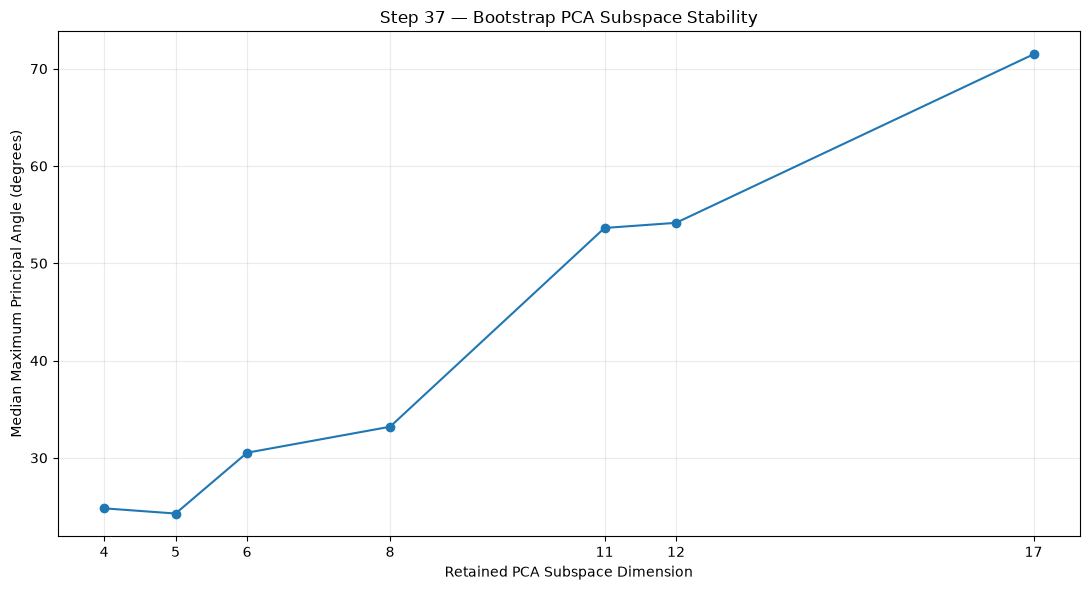

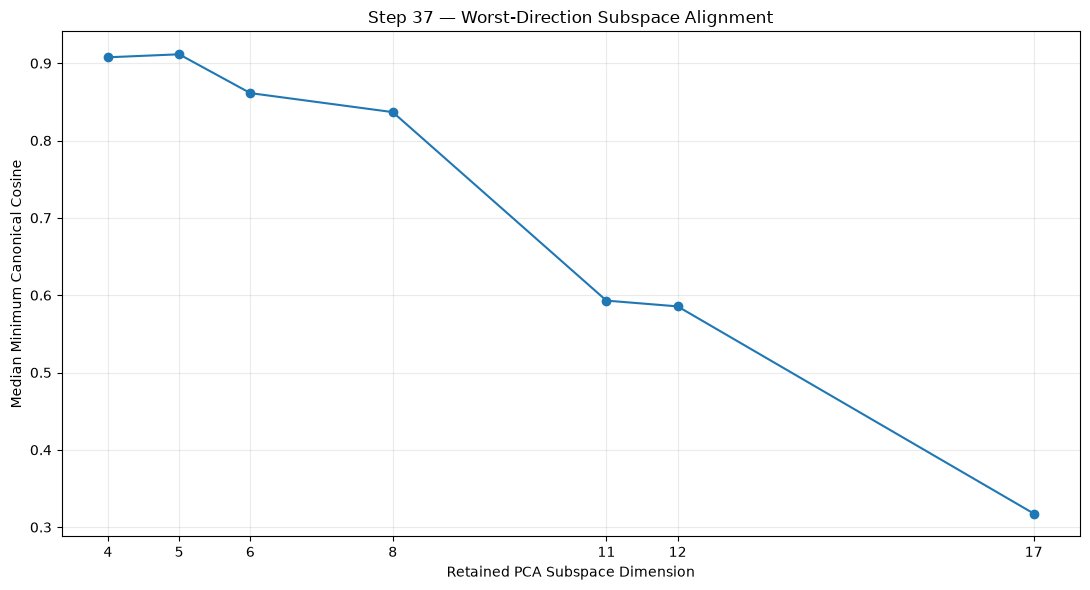

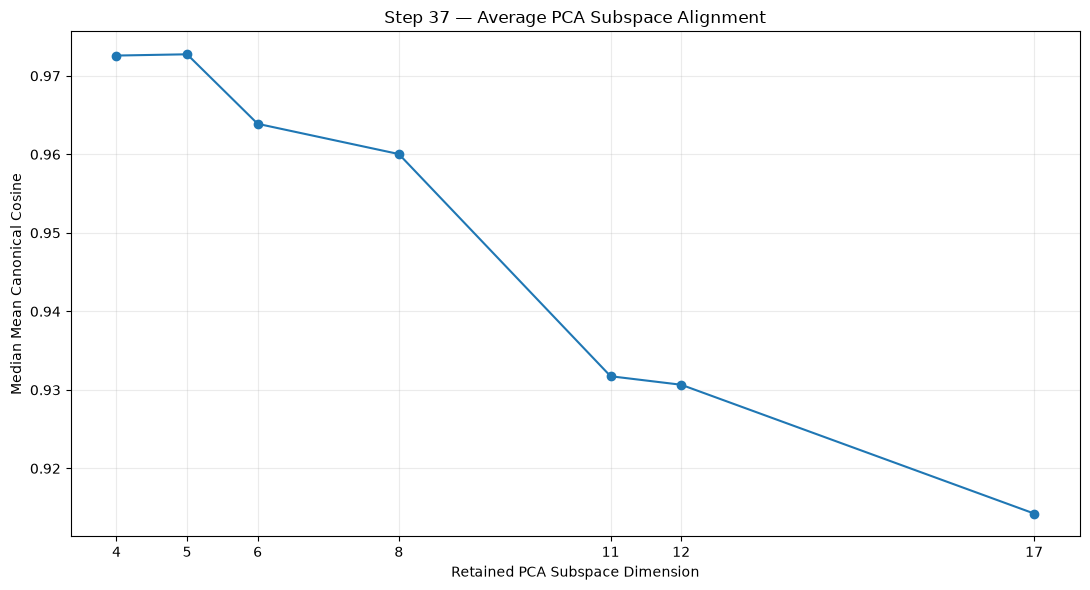


INCREMENTAL SUBSPACE-STABILITY CHANGE


,subspace_dimension,median_maximum_angle_deg,median_minimum_cosine,median_mean_cosine,change_in_median_max_angle_from_previous,change_in_median_min_cosine_from_previous
0,4,24.8153,0.9077,0.9726,NaN,NaN
1,5,24.2804,0.9115,0.9727,-0.5349,0.0039
2,6,30.5314,0.8614,0.9639,6.2510,-0.0502
3,8,33.2016,0.8367,0.9600,2.6702,-0.0246
4,11,53.6311,0.5930,0.9317,20.4295,-0.2438
5,12,54.1598,0.5855,0.9307,0.5288,-0.0075
6,17,71.4814,0.3176,0.9142,17.3215,-0.2679



COMPONENT-RETENTION EVIDENCE INCLUDING SUBSPACE STABILITY


,method,result
0,Cattell Scree Test,4 PCs
1,Horn Parallel Analysis,12 PCs
2,Velicer Original MAP,11 PCs
3,Velicer Revised MAP,17 PCs
4,Guadagnoli & Velicer loading-pattern assessment,Strongest support concentrated in early PCs
5,Bootstrap individual-PC stability,PC1-PC4 clearly strongest individual patterns
6,Bootstrap PCA subspace stability,See bootstrap_subspace_stability_summary



HOW TO INTERPRET STEP 37

Principal-angle interpretation:
  Smaller angles = more stable subspace.
  Larger angles = less stable subspace.

Canonical-cosine interpretation:
  Values near 1 = highly similar subspaces.
  Lower values = weaker alignment.

Most important columns:
  median_maximum_angle_deg
  median_minimum_cosine
  median_mean_cosine

Decision logic:
  If the 4D subspace is very stable and stability drops sharply at 5D or 6D, this reinforces the 4-component solution.

  If 5D or 6D remains nearly as stable as 4D, then the larger solution remains defensible.

  If 11D or 12D remains stable as a subspace even though individual PCs are unstable, then the apparent instability of PC9-PC12 may reflect rotation within a stable higher-dimensional space.

STEP 37 COMPLETE — BOOTSTRAP PCA SUBSPACE STABILITY

Bootstrap replications:
  1,000

Observations per bootstrap sample:
  673

Performance variables:
  74

Candidate subspace dimensions tested:
  4, 5, 6, 8, 11, 12, 17

Primary 

In [48]:
# ============================================================
# STEP 37 — BOOTSTRAP PCA SUBSPACE STABILITY
# PRINCIPAL-ANGLE ANALYSIS
# ============================================================
#
# PURPOSE
# -------
#
# Evaluate whether the MULTIDIMENSIONAL PCA SUBSPACE remains
# stable across bootstrap resamples.
#
# This is different from Step 36.
#
# Step 36 asked:
#
#   "Does PC5 reproduce specifically as PC5?"
#
# Step 37 asks:
#
#   "Does the space spanned by the first k PCs reproduce,
#    even if individual PCs rotate or swap order?"
#
#
# WHY THIS MATTERS
# ----------------
#
# When neighboring PCA eigenvalues are similar, individual
# component axes can rotate or exchange order across samples.
#
# In that case:
#
#   individual PCs may look unstable
#
# while:
#
#   the underlying k-dimensional subspace may still be stable.
#
#
# This step therefore compares the original PCA subspace with
# bootstrap PCA subspaces using PRINCIPAL ANGLES.
#
#
# PRINCIPAL ANGLES
# ----------------
#
# For two k-dimensional subspaces, principal angles measure
# how closely the two spaces align.
#
# Perfectly identical subspaces:
#
#   all angles = 0 degrees
#
# Greater angles:
#
#   weaker subspace agreement
#
#
# We also summarize:
#
#   - maximum principal angle
#   - mean principal angle
#   - RMS principal angle
#   - minimum canonical cosine
#   - mean canonical cosine
#
#
# CANDIDATE DIMENSIONS TESTED
# ---------------------------
#
# Based on previous retention diagnostics:
#
#   4  -> Scree
#   5  -> immediate post-Scree candidate
#   6  -> plausible expanded solution
#   8  -> broader narrow-component region
#   11 -> Original MAP
#   12 -> Parallel Analysis
#   17 -> Revised MAP
#
#
# IMPORTANT
# ---------
#
# This step is DIAGNOSTIC ONLY.
#
# No PCA components are deleted.
# No observations are deleted.
# No PCA is permanently re-fit.
#
#
# REFERENCES
# ----------
#
# Hotelling, H. (1936).
# Relations Between Two Sets of Variates.
# Biometrika, 28, 321-377.
#
# Björck, Å. & Golub, G. H. (1973).
# Numerical Methods for Computing Angles Between Linear
# Subspaces.
# Mathematics of Computation, 27(123), 579-594.
#
# Krzanowski, W. J. (1979).
# Between-Groups Comparison of Principal Components.
# Journal of the American Statistical Association,
# 74(367), 703-707.
#
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from scipy.linalg import subspace_angles

from IPython.display import display


# ============================================================
# 2. SETTINGS
# ============================================================

N_BOOTSTRAPS = 1000


RANDOM_STATE = 42


CANDIDATE_DIMENSIONS = [
    4,
    5,
    6,
    8,
    11,
    12,
    17
]


LOWER_PERCENTILE = 5

UPPER_PERCENTILE = 95


# ============================================================
# 3. VERIFY REQUIRED OBJECTS
# ============================================================

required_objects = [
    "X_df",
    "pca_model",
    "pca_variables"
]


missing_objects = [
    object_name
    for object_name in required_objects
    if object_name not in globals()
]


if missing_objects:

    raise RuntimeError(
        "Required objects are missing:\n\n"
        +
        "\n".join(
            missing_objects
        )
        +
        "\n\nRun Steps 30 and 31 before running Step 37."
    )


# ============================================================
# 4. PREPARE ORIGINAL DATA MATRIX
# ============================================================

X_original_df = (

    X_df[
        pca_variables
    ]

    .copy()
)


X_original = (

    X_original_df

    .to_numpy(
        dtype=float
    )
)


if not np.isfinite(
    X_original
).all():

    raise RuntimeError(
        "The original performance matrix contains NaN or "
        "infinite values."
    )


N, P = X_original.shape


# ============================================================
# 5. VALIDATE CANDIDATE DIMENSIONS
# ============================================================

maximum_available_components = min(
    N,
    P
)


invalid_dimensions = [
    k
    for k in CANDIDATE_DIMENSIONS
    if (
        k < 1
        or
        k > maximum_available_components
    )
]


if invalid_dimensions:

    raise RuntimeError(
        "One or more candidate dimensions are invalid:\n\n"
        +
        "\n".join(
            str(k)
            for k in invalid_dimensions
        )
    )


# ============================================================
# 6. CREATE ORIGINAL REFERENCE PCA BASIS
# ============================================================
#
# sklearn components_:
#
#   components × variables
#
# For subspace calculations we want:
#
#   variables × components
#
# ============================================================

reference_basis_full = (

    pca_model
    .components_
    .T
)


if (
    reference_basis_full.shape[
        0
    ]
    !=
    P
):

    raise RuntimeError(
        "Reference PCA basis does not match the number "
        "of performance variables."
    )


# ============================================================
# 7. PRINT INPUT SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 130
)


print(
    "STEP 37 — BOOTSTRAP PCA SUBSPACE STABILITY"
)


print(
    "=" * 130
)


print(
    "\nDataset:"
)


print(
    f"  Observations: {N:,}"
)


print(
    f"  Variables:    {P:,}"
)


print(
    "\nBootstrap replications:"
)


print(
    f"  {N_BOOTSTRAPS:,}"
)


print(
    "\nCandidate subspace dimensions:"
)


print(
    "  "
    +
    ", ".join(
        str(k)
        for k in CANDIDATE_DIMENSIONS
    )
)


# ============================================================
# 8. RANDOM NUMBER GENERATOR
# ============================================================

rng = np.random.default_rng(
    RANDOM_STATE
)


# ============================================================
# 9. STORAGE
# ============================================================
#
# One array per candidate dimensionality.
#
# ============================================================

subspace_results = {
    k: {
        "maximum_angle_degrees": [],
        "mean_angle_degrees": [],
        "rms_angle_degrees": [],
        "minimum_cosine": [],
        "mean_cosine": [],
        "all_angles_degrees": []
    }
    for k in CANDIDATE_DIMENSIONS
}


# ============================================================
# 10. BOOTSTRAP LOOP
# ============================================================

for bootstrap_index in range(
    N_BOOTSTRAPS
):

    # --------------------------------------------------------
    # Resample observations with replacement
    # --------------------------------------------------------

    sampled_indices = rng.integers(
        low=0,
        high=N,
        size=N
    )


    X_bootstrap_raw = (

        X_original[
            sampled_indices,
            :
        ]
    )


    # --------------------------------------------------------
    # Re-standardize bootstrap sample
    # --------------------------------------------------------

    scaler = StandardScaler(
        with_mean=True,
        with_std=True
    )


    X_bootstrap_standardized = (

        scaler

        .fit_transform(
            X_bootstrap_raw
        )
    )


    if not np.isfinite(
        X_bootstrap_standardized
    ).all():

        raise RuntimeError(
            "A bootstrap sample produced non-finite values."
        )


    # --------------------------------------------------------
    # Fit full classical PCA
    # --------------------------------------------------------

    bootstrap_pca = PCA(
        n_components=None,
        svd_solver="full"
    )


    bootstrap_pca.fit(
        X_bootstrap_standardized
    )


    bootstrap_basis_full = (

        bootstrap_pca
        .components_
        .T
    )


    # ========================================================
    # 11. COMPARE CANDIDATE SUBSPACES
    # ========================================================

    for k in CANDIDATE_DIMENSIONS:

        # ----------------------------------------------------
        # Original k-dimensional PCA basis
        # ----------------------------------------------------

        reference_basis = (

            reference_basis_full[
                :,
                :k
            ]
        )


        # ----------------------------------------------------
        # Bootstrap k-dimensional PCA basis
        # ----------------------------------------------------

        bootstrap_basis = (

            bootstrap_basis_full[
                :,
                :k
            ]
        )


        # ----------------------------------------------------
        # Principal angles
        #
        # scipy returns radians.
        # ----------------------------------------------------

        angles_radians = subspace_angles(
            reference_basis,
            bootstrap_basis
        )


        angles_degrees = np.degrees(
            angles_radians
        )


        # ----------------------------------------------------
        # Canonical cosines
        #
        # cos(angle) = 1 means perfect alignment
        # ----------------------------------------------------

        cosines = np.cos(
            angles_radians
        )


        # ----------------------------------------------------
        # Summary metrics
        # ----------------------------------------------------

        maximum_angle = float(
            np.max(
                angles_degrees
            )
        )


        mean_angle = float(
            np.mean(
                angles_degrees
            )
        )


        rms_angle = float(
            np.sqrt(
                np.mean(
                    angles_degrees ** 2
                )
            )
        )


        minimum_cosine = float(
            np.min(
                cosines
            )
        )


        mean_cosine = float(
            np.mean(
                cosines
            )
        )


        # ----------------------------------------------------
        # Store
        # ----------------------------------------------------

        subspace_results[
            k
        ][
            "maximum_angle_degrees"
        ].append(
            maximum_angle
        )


        subspace_results[
            k
        ][
            "mean_angle_degrees"
        ].append(
            mean_angle
        )


        subspace_results[
            k
        ][
            "rms_angle_degrees"
        ].append(
            rms_angle
        )


        subspace_results[
            k
        ][
            "minimum_cosine"
        ].append(
            minimum_cosine
        )


        subspace_results[
            k
        ][
            "mean_cosine"
        ].append(
            mean_cosine
        )


        subspace_results[
            k
        ][
            "all_angles_degrees"
        ].append(
            angles_degrees
        )


# ============================================================
# 12. CONVERT STORAGE TO NUMPY ARRAYS
# ============================================================

for k in CANDIDATE_DIMENSIONS:

    for metric in [
        "maximum_angle_degrees",
        "mean_angle_degrees",
        "rms_angle_degrees",
        "minimum_cosine",
        "mean_cosine"
    ]:

        subspace_results[
            k
        ][
            metric
        ] = np.asarray(
            subspace_results[
                k
            ][
                metric
            ],
            dtype=float
        )


# ============================================================
# 13. BUILD SUMMARY TABLE
# ============================================================

summary_rows = []


for k in CANDIDATE_DIMENSIONS:

    maximum_angles = (

        subspace_results[
            k
        ][
            "maximum_angle_degrees"
        ]
    )


    mean_angles = (

        subspace_results[
            k
        ][
            "mean_angle_degrees"
        ]
    )


    rms_angles = (

        subspace_results[
            k
        ][
            "rms_angle_degrees"
        ]
    )


    minimum_cosines = (

        subspace_results[
            k
        ][
            "minimum_cosine"
        ]
    )


    mean_cosines = (

        subspace_results[
            k
        ][
            "mean_cosine"
        ]
    )


    summary_rows.append(
        {

            "subspace_dimension":
                k,

            "median_maximum_angle_deg":
                np.median(
                    maximum_angles
                ),

            f"p{LOWER_PERCENTILE}_maximum_angle_deg":
                np.percentile(
                    maximum_angles,
                    LOWER_PERCENTILE
                ),

            f"p{UPPER_PERCENTILE}_maximum_angle_deg":
                np.percentile(
                    maximum_angles,
                    UPPER_PERCENTILE
                ),

            "median_mean_angle_deg":
                np.median(
                    mean_angles
                ),

            "median_rms_angle_deg":
                np.median(
                    rms_angles
                ),

            "median_minimum_cosine":
                np.median(
                    minimum_cosines
                ),

            f"p{LOWER_PERCENTILE}_minimum_cosine":
                np.percentile(
                    minimum_cosines,
                    LOWER_PERCENTILE
                ),

            "median_mean_cosine":
                np.median(
                    mean_cosines
                ),

            f"p{LOWER_PERCENTILE}_mean_cosine":
                np.percentile(
                    mean_cosines,
                    LOWER_PERCENTILE
                )
        }
    )


bootstrap_subspace_stability_summary = pd.DataFrame(
    summary_rows
)


# ============================================================
# 14. DISPLAY SUBSPACE STABILITY SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 170
)


print(
    "BOOTSTRAP PCA SUBSPACE STABILITY SUMMARY"
)


print(
    "=" * 170
)


display(
    bootstrap_subspace_stability_summary.round(
        4
    )
)


# ============================================================
# 15. CREATE LONG-FORM BOOTSTRAP RESULTS
# ============================================================

long_rows = []


for k in CANDIDATE_DIMENSIONS:

    for bootstrap_index in range(
        N_BOOTSTRAPS
    ):

        long_rows.append(
            {

                "bootstrap_iteration":
                    bootstrap_index + 1,

                "subspace_dimension":
                    k,

                "maximum_angle_degrees":
                    subspace_results[
                        k
                    ][
                        "maximum_angle_degrees"
                    ][
                        bootstrap_index
                    ],

                "mean_angle_degrees":
                    subspace_results[
                        k
                    ][
                        "mean_angle_degrees"
                    ][
                        bootstrap_index
                    ],

                "rms_angle_degrees":
                    subspace_results[
                        k
                    ][
                        "rms_angle_degrees"
                    ][
                        bootstrap_index
                    ],

                "minimum_cosine":
                    subspace_results[
                        k
                    ][
                        "minimum_cosine"
                    ][
                        bootstrap_index
                    ],

                "mean_cosine":
                    subspace_results[
                        k
                    ][
                        "mean_cosine"
                    ][
                        bootstrap_index
                    ]
            }
        )


bootstrap_subspace_stability_long = pd.DataFrame(
    long_rows
)


# ============================================================
# 16. PLOT MEDIAN MAXIMUM PRINCIPAL ANGLE
# ============================================================

plot_df = (

    bootstrap_subspace_stability_summary

    .copy()
)


fig, ax = plt.subplots(
    figsize=(
        11,
        6
    )
)


ax.plot(

    plot_df[
        "subspace_dimension"
    ],

    plot_df[
        "median_maximum_angle_deg"
    ],

    marker="o"
)


ax.set_xlabel(
    "Retained PCA Subspace Dimension"
)


ax.set_ylabel(
    "Median Maximum Principal Angle (degrees)"
)


ax.set_title(
    "Step 37 — Bootstrap PCA Subspace Stability"
)


ax.set_xticks(
    CANDIDATE_DIMENSIONS
)


ax.grid(
    alpha=0.25
)


plt.tight_layout()


plt.show()


# ============================================================
# 17. PLOT MEDIAN MINIMUM CANONICAL COSINE
# ============================================================

fig, ax = plt.subplots(
    figsize=(
        11,
        6
    )
)


ax.plot(

    plot_df[
        "subspace_dimension"
    ],

    plot_df[
        "median_minimum_cosine"
    ],

    marker="o"
)


ax.set_xlabel(
    "Retained PCA Subspace Dimension"
)


ax.set_ylabel(
    "Median Minimum Canonical Cosine"
)


ax.set_title(
    "Step 37 — Worst-Direction Subspace Alignment"
)


ax.set_xticks(
    CANDIDATE_DIMENSIONS
)


ax.grid(
    alpha=0.25
)


plt.tight_layout()


plt.show()


# ============================================================
# 18. PLOT MEDIAN MEAN CANONICAL COSINE
# ============================================================

fig, ax = plt.subplots(
    figsize=(
        11,
        6
    )
)


ax.plot(

    plot_df[
        "subspace_dimension"
    ],

    plot_df[
        "median_mean_cosine"
    ],

    marker="o"
)


ax.set_xlabel(
    "Retained PCA Subspace Dimension"
)


ax.set_ylabel(
    "Median Mean Canonical Cosine"
)


ax.set_title(
    "Step 37 — Average PCA Subspace Alignment"
)


ax.set_xticks(
    CANDIDATE_DIMENSIONS
)


ax.grid(
    alpha=0.25
)


plt.tight_layout()


plt.show()


# ============================================================
# 19. CALCULATE INCREMENTAL SUBSPACE CHANGE
# ============================================================
#
# This helps show whether adding more PCs causes a marked
# deterioration in reproducibility.
#
# ============================================================

bootstrap_subspace_stability_summary[
    "change_in_median_max_angle_from_previous"
] = (

    bootstrap_subspace_stability_summary[
        "median_maximum_angle_deg"
    ]

    .diff()
)


bootstrap_subspace_stability_summary[
    "change_in_median_min_cosine_from_previous"
] = (

    bootstrap_subspace_stability_summary[
        "median_minimum_cosine"
    ]

    .diff()
)


# ============================================================
# 20. PRINT INCREMENTAL COMPARISON
# ============================================================

print(
    "\n"
    + "=" * 150
)


print(
    "INCREMENTAL SUBSPACE-STABILITY CHANGE"
)


print(
    "=" * 150
)


display(
    bootstrap_subspace_stability_summary[
        [
            "subspace_dimension",
            "median_maximum_angle_deg",
            "median_minimum_cosine",
            "median_mean_cosine",
            "change_in_median_max_angle_from_previous",
            "change_in_median_min_cosine_from_previous"
        ]
    ]
    .round(
        4
    )
)


# ============================================================
# 21. CREATE CURRENT RETENTION EVIDENCE TABLE
# ============================================================

retention_evidence_with_subspace = pd.DataFrame(
    {

        "method": [
            "Cattell Scree Test",
            "Horn Parallel Analysis",
            "Velicer Original MAP",
            "Velicer Revised MAP",
            "Guadagnoli & Velicer loading-pattern assessment",
            "Bootstrap individual-PC stability",
            "Bootstrap PCA subspace stability"
        ],

        "result": [
            "4 PCs",
            "12 PCs",
            "11 PCs",
            "17 PCs",
            "Strongest support concentrated in early PCs",
            "PC1-PC4 clearly strongest individual patterns",
            "See bootstrap_subspace_stability_summary"
        ]
    }
)


print(
    "\n"
    + "=" * 150
)


print(
    "COMPONENT-RETENTION EVIDENCE INCLUDING SUBSPACE STABILITY"
)


print(
    "=" * 150
)


display(
    retention_evidence_with_subspace
)


# ============================================================
# 22. PRINT INTERPRETATION GUIDE
# ============================================================

print(
    "\n"
    + "=" * 130
)


print(
    "HOW TO INTERPRET STEP 37"
)


print(
    "=" * 130
)


print(
    "\nPrincipal-angle interpretation:"
)


print(
    "  Smaller angles = more stable subspace."
)


print(
    "  Larger angles = less stable subspace."
)


print(
    "\nCanonical-cosine interpretation:"
)


print(
    "  Values near 1 = highly similar subspaces."
)


print(
    "  Lower values = weaker alignment."
)


print(
    "\nMost important columns:"
)


print(
    "  median_maximum_angle_deg"
)


print(
    "  median_minimum_cosine"
)


print(
    "  median_mean_cosine"
)


print(
    "\nDecision logic:"
)


print(
    "  If the 4D subspace is very stable and stability "
    "drops sharply at 5D or 6D, this reinforces the "
    "4-component solution."
)


print(
    "\n  If 5D or 6D remains nearly as stable as 4D, "
    "then the larger solution remains defensible."
)


print(
    "\n  If 11D or 12D remains stable as a subspace even "
    "though individual PCs are unstable, then the apparent "
    "instability of PC9-PC12 may reflect rotation within a "
    "stable higher-dimensional space."
)


# ============================================================
# 23. FINAL STEP 37 SUMMARY
# ============================================================

print(
    "\n"
    + "=" * 130
)


print(
    "STEP 37 COMPLETE — BOOTSTRAP PCA SUBSPACE STABILITY"
)


print(
    "=" * 130
)


print(
    "\nBootstrap replications:"
)


print(
    f"  {N_BOOTSTRAPS:,}"
)


print(
    "\nObservations per bootstrap sample:"
)


print(
    f"  {N:,}"
)


print(
    "\nPerformance variables:"
)


print(
    f"  {P:,}"
)


print(
    "\nCandidate subspace dimensions tested:"
)


print(
    "  "
    +
    ", ".join(
        str(k)
        for k in CANDIDATE_DIMENSIONS
    )
)


print(
    "\nPrimary stability method:"
)


print(
    "  Principal angles between original and bootstrap "
    "PCA subspaces"
)


print(
    "\nMain output objects:"
)


print(
    "  subspace_results"
)


print(
    "  bootstrap_subspace_stability_summary"
)


print(
    "  bootstrap_subspace_stability_long"
)


print(
    "  retention_evidence_with_subspace"
)


print(
    "\nIMPORTANT:"
)


print(
    "  No PCA components were removed."
)


print(
    "  No observations were removed."
)


print(
    "  Step 31 remains the reference PCA solution."
)


print(
    "\n"
    + "=" * 130
)

### 38. Classic PCA Retention Conclusion

In [49]:
# ============================================================
# CONCLUSION — PCA COMPONENT-RETENTION ANALYSIS
# ============================================================
#
# The objective of Steps 32–37 was to determine how many
# principal components should be retained from the Step 31
# classical PCA solution.
#
# Multiple complementary methods were used rather than relying
# on a single component-retention criterion.
#
# RESULTS
# -------
#
# Cattell Scree Test:
#   -> Suggested 4 PCs.
#
# Horn's Parallel Analysis:
#   -> Suggested 12 PCs.
#
# Velicer's Original MAP:
#   -> Suggested 11 PCs.
#
# Velicer's Revised MAP:
#   -> Suggested 17 PCs.
#
# Guadagnoli & Velicer (1988) loading assessment:
#   -> Strongest loading support was concentrated in the
#      earlier components.
#   -> Later components became progressively more weakly
#      and narrowly defined.
#
# Bootstrap individual-component stability:
#   -> PC1-PC3 were extremely reproducible.
#   -> PC4 remained strongly supported.
#   -> PC5 showed weaker, but still meaningful, reproducibility.
#   -> Stability progressively deteriorated for later PCs.
#
# Bootstrap PCA subspace stability:
#   -> The 4-PC and 5-PC subspaces were essentially equally
#      reproducible.
#   -> Adding PC5 produced no meaningful loss of overall
#      subspace stability.
#   -> Stability began deteriorating after the 5-PC solution,
#      particularly as the solution approached 11-12 PCs.
#
#
# OVERALL CONCLUSION
# ------------------
#
# The evidence does not support interpreting all components
# identified by Parallel Analysis or MAP simply because they
# contain statistically detectable structure.
#
# Instead, the analyses consistently identify a much smaller
# core of stable and substantively interpretable dimensions.
#
# PC1-PC4 currently form the strongly supported core solution.
#
# PC5 is the remaining borderline component:
#   -> It contains meaningful structure.
#   -> It shows reasonable individual-component stability.
#   -> The 5-dimensional PCA subspace is essentially as stable
#      as the 4-dimensional subspace.
#
# Therefore, the final component-retention decision has been
# narrowed to:
#
#                       4 PCs vs 5 PCs
#
# The remaining decision should primarily be substantive rather
# than based on another automatic statistical cutoff.
#
# Specifically, PC5 should be retained if its positive and
# negative loading poles define a coherent, distinct, and useful
# football-performance dimension that adds meaningful information
# beyond PC1-PC4.
#
# If PC5 does not provide sufficient unique interpretive value,
# the more parsimonious 4-PC solution should be preferred.
#
# Thus, component retention is not yet finalized:
#
#   CURRENT CORE:       PC1-PC4
#   CANDIDATE ADDITION: PC5
#   FINAL DECISION:     Interpretation and added value of PC5
#
# No components have yet been permanently removed from the
# original Step 31 PCA solution.
# ============================================================

## Interpretability Audit of the Unrotated PCA

### 39. Inspect the Retained 5 PC from PCA

In [50]:
# ==================================================================================================
# STEP 39 — INSPECT THE FIRST FIVE UNROTATED PCA COMPONENTS
# CONSOLIDATED CLASSICAL PCA INTERPRETABILITY AUDIT
# ==================================================================================================
#
# PURPOSE
# -------
#
# Analyze PC1–PC5 together after the Classical PCA retention decision.
#
# This step is NOT intended to assign final football-trait names.
# Its purpose is to determine whether the retained unrotated PCA axes
# are substantively clean enough to interpret directly, or whether
# rotation is justified.
#
# The audit combines:
#
#   - exact PCA score reconstruction
#   - complete loading tables
#   - strongest positive / negative loadings
#   - loading-strength diagnostics
#   - player score distributions
#   - positive / negative player extremes
#   - position-level summaries when position metadata is available
#   - top player × variable score contributions
#   - a complete player × variable × component contribution file
#
# The heavy outputs are written externally.
#
# NO plots are created.
# NO large DataFrames are displayed in Jupyter.
#
#
# REQUIRED NOTEBOOK OBJECTS
# -------------------------
#
#   source_df
#   X_df
#   X_standardized
#   pca_scores
#   pca_loadings
#
# A fitted sklearn PCA model must also exist in the notebook.
# The script identifies the correct model by reconstructing PC1–PC5
# and comparing them against the stored PCA scores.
#
#
# OUTPUTS
# -------
#
# outputs/
# └── STEP_39_unrotated_PCA_5_component_audit/
#     ├── STEP_39_unrotated_PCA_5_component_audit.xlsx
#     ├── STEP_39_all_player_variable_contributions.parquet
#     │      OR .csv.gz if Parquet support is unavailable
#     └── STEP_39_component_summary.csv
#
#
# MAIN EXCEL SHEETS
# -----------------
#
#   README
#   Component_Summary
#   Pole_Summary
#   Top_Loadings
#   All_Loadings
#   Player_Scores
#   Player_Extremes
#   Position_Summary
#   Top_Player_Contrib
#   Model_Validation
#
#
# INTERPRETATION RULE
# -------------------
#
# Use this audit to assess the UNROTATED PCA solution.
#
# Do not treat the provisional PC poles as final player traits.
#
# The next methodological question is:
#
#     Do these variance-maximizing PCA axes provide sufficiently
#     clean football constructs, or is rotation warranted?
#
# ==================================================================================================


# ==================================================================================================
# 1. IMPORT LIBRARIES
# ==================================================================================================

from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.decomposition import PCA


# ==================================================================================================
# 2. SETTINGS
# ==================================================================================================

PLAYER_COLUMN = "sofascore_player"
TEAM_COLUMN = "canonical_team_name"

N_RETAINED_COMPONENTS = 5

RETAINED_COMPONENTS = [
    f"PC{i}"
    for i in range(
        1,
        N_RETAINED_COMPONENTS + 1
    )
]

TOP_LOADINGS_PER_POLE = 15
TOP_EXTREME_PLAYERS_PER_POLE = 30
TOP_CONTRIBUTIONS_PER_DIRECTION = 5

SALIENT_LOADING_THRESHOLDS = [
    0.30,
    0.40,
    0.50
]

RECONSTRUCTION_TOLERANCE = 1e-6


# ==================================================================================================
# 3. EXTERNAL OUTPUT PATHS
# ==================================================================================================

STEP_39_OUTPUT_DIR = (
    Path("outputs")
    / "STEP_39_unrotated_PCA_5_component_audit"
)

STEP_39_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


STEP_39_EXCEL_PATH = (
    STEP_39_OUTPUT_DIR
    / "STEP_39_unrotated_PCA_5_component_audit.xlsx"
)


STEP_39_COMPONENT_SUMMARY_CSV = (
    STEP_39_OUTPUT_DIR
    / "STEP_39_component_summary.csv"
)


STEP_39_FULL_CONTRIBUTIONS_PARQUET = (
    STEP_39_OUTPUT_DIR
    / "STEP_39_all_player_variable_contributions.parquet"
)


STEP_39_FULL_CONTRIBUTIONS_CSV_GZ = (
    STEP_39_OUTPUT_DIR
    / "STEP_39_all_player_variable_contributions.csv.gz"
)


# ==================================================================================================
# 4. VERIFY REQUIRED NOTEBOOK OBJECTS
# ==================================================================================================

required_objects = [
    "source_df",
    "X_df",
    "X_standardized",
    "pca_scores",
    "pca_loadings"
]


missing_objects = [
    object_name
    for object_name in required_objects
    if object_name not in globals()
]


if missing_objects:

    raise RuntimeError(
        "Missing required notebook objects:\n\n"
        + "\n".join(
            f"  - {object_name}"
            for object_name
            in missing_objects
        )
        + "\n\nRun the Classical PCA workflow before Step 39."
    )


if not isinstance(
    source_df,
    pd.DataFrame
):

    raise TypeError(
        "`source_df` must be a pandas DataFrame."
    )


if not isinstance(
    X_df,
    pd.DataFrame
):

    raise TypeError(
        "`X_df` must be a pandas DataFrame."
    )


if not isinstance(
    pca_scores,
    pd.DataFrame
):

    raise TypeError(
        "`pca_scores` must be a pandas DataFrame."
    )


if not isinstance(
    pca_loadings,
    pd.DataFrame
):

    raise TypeError(
        "`pca_loadings` must be a pandas DataFrame."
    )


# ==================================================================================================
# 5. VERIFY REQUIRED COLUMNS / COMPONENTS
# ==================================================================================================

if PLAYER_COLUMN not in source_df.columns:

    raise RuntimeError(
        f"`{PLAYER_COLUMN}` was not found in source_df."
    )


missing_score_components = [
    component
    for component in RETAINED_COMPONENTS
    if component not in pca_scores.columns
]


if missing_score_components:

    raise RuntimeError(
        "The following retained components are missing from pca_scores:\n\n"
        + "\n".join(
            missing_score_components
        )
    )


missing_loading_components = [
    component
    for component in RETAINED_COMPONENTS
    if component not in pca_loadings.columns
]


if missing_loading_components:

    raise RuntimeError(
        "The following retained components are missing from pca_loadings:\n\n"
        + "\n".join(
            missing_loading_components
        )
    )


# ==================================================================================================
# 6. VERIFY PCA POPULATION ALIGNMENT
# ==================================================================================================

n_players = len(
    source_df
)

n_variables = X_df.shape[1]


if not (
    len(source_df)
    ==
    len(X_df)
    ==
    len(X_standardized)
    ==
    len(pca_scores)
):

    raise RuntimeError(

        "PCA population row-count alignment failed.\n\n"

        f"source_df:       {len(source_df):,}\n"
        f"X_df:            {len(X_df):,}\n"
        f"X_standardized:  {len(X_standardized):,}\n"
        f"pca_scores:      {len(pca_scores):,}"
    )


# If pca_scores carries player identity, verify row identity directly.

if PLAYER_COLUMN in pca_scores.columns:

    source_players = (
        source_df[
            PLAYER_COLUMN
        ]
        .astype(str)
        .reset_index(
            drop=True
        )
    )


    score_players = (
        pca_scores[
            PLAYER_COLUMN
        ]
        .astype(str)
        .reset_index(
            drop=True
        )
    )


    if not source_players.equals(
        score_players
    ):

        raise RuntimeError(
            "Player identity order differs between source_df and pca_scores."
        )


# ==================================================================================================
# 7. BUILD NUMERIC MATRICES
# ==================================================================================================

feature_names = list(
    X_df.columns
)


X_z = np.asarray(
    X_standardized,
    dtype=float
)


if X_z.shape != (
    n_players,
    n_variables
):

    raise RuntimeError(

        "X_standardized dimensions do not match X_df.\n\n"

        f"Expected: {(n_players, n_variables)}\n"
        f"Observed: {X_z.shape}"
    )


if not np.isfinite(
    X_z
).all():

    raise RuntimeError(
        "X_standardized contains NaN or infinite values."
    )


X_raw = (
    X_df
    .to_numpy(
        dtype=float
    )
)


if not np.isfinite(
    X_raw
).all():

    raise RuntimeError(
        "X_df contains NaN or infinite values."
    )


stored_scores = (

    pca_scores[
        RETAINED_COMPONENTS
    ]

    .to_numpy(
        dtype=float
    )
)


if not np.isfinite(
    stored_scores
).all():

    raise RuntimeError(
        "Stored PCA scores contain NaN or infinite values."
    )


# ==================================================================================================
# 8. FIND ALL COMPATIBLE FITTED PCA MODELS
# ==================================================================================================

pca_model_candidates = []


for object_name, obj in list(
    globals().items()
):

    if not isinstance(
        obj,
        PCA
    ):

        continue


    if not hasattr(
        obj,
        "components_"
    ):

        continue


    if obj.components_.shape[1] != n_variables:

        continue


    if obj.components_.shape[0] < N_RETAINED_COMPONENTS:

        continue


    pca_model_candidates.append(
        (
            object_name,
            obj
        )
    )


# Remove duplicate references to the same fitted object.

unique_candidates = []

seen_object_ids = set()


for object_name, obj in pca_model_candidates:

    object_id = id(
        obj
    )


    if object_id in seen_object_ids:

        continue


    seen_object_ids.add(
        object_id
    )


    unique_candidates.append(
        (
            object_name,
            obj
        )
    )


pca_model_candidates = (
    unique_candidates
)


if len(
    pca_model_candidates
) == 0:

    raise RuntimeError(
        "No fitted sklearn PCA model aligned with X_df was found."
    )


# ==================================================================================================
# 9. IDENTIFY THE CORRECT PCA MODEL BY SCORE RECONSTRUCTION
# ==================================================================================================
#
# For each candidate PCA model:
#
#   reconstructed PCk = X_standardized @ components_[k]
#
# PCA signs are mathematically arbitrary, so each reconstructed component
# is compared both as-is and sign-flipped against the stored pca_scores.
#
# The candidate with the smallest mean reconstruction error across PC1–PC5
# is selected.
#
# ==================================================================================================

candidate_diagnostic_rows = []


for object_name, model in pca_model_candidates:

    component_signs = []

    component_maes = []

    component_max_errors = []


    for component_index in range(
        N_RETAINED_COMPONENTS
    ):

        reconstructed = (

            X_z

            @

            model.components_[
                component_index
            ]
        )


        stored = (
            stored_scores[
                :,
                component_index
            ]
        )


        mae_same_sign = float(

            np.mean(
                np.abs(
                    reconstructed
                    -
                    stored
                )
            )
        )


        mae_flipped_sign = float(

            np.mean(
                np.abs(
                    -reconstructed
                    -
                    stored
                )
            )
        )


        if mae_flipped_sign < mae_same_sign:

            sign_multiplier = -1.0

        else:

            sign_multiplier = 1.0


        best_reconstructed = (
            reconstructed
            *
            sign_multiplier
        )


        best_mae = float(

            np.mean(
                np.abs(
                    best_reconstructed
                    -
                    stored
                )
            )
        )


        max_error = float(

            np.max(
                np.abs(
                    best_reconstructed
                    -
                    stored
                )
            )
        )


        component_signs.append(
            sign_multiplier
        )


        component_maes.append(
            best_mae
        )


        component_max_errors.append(
            max_error
        )


    candidate_row = {

        "Object":
            object_name,

        "Mean_MAE_PC1_to_PC5":
            float(
                np.mean(
                    component_maes
                )
            ),

        "Maximum_Error_PC1_to_PC5":
            float(
                np.max(
                    component_max_errors
                )
            )
    }


    for component_index, component in enumerate(
        RETAINED_COMPONENTS
    ):

        candidate_row[
            f"{component}_Sign"
        ] = (
            component_signs[
                component_index
            ]
        )


        candidate_row[
            f"{component}_MAE"
        ] = (
            component_maes[
                component_index
            ]
        )


        candidate_row[
            f"{component}_Max_Error"
        ] = (
            component_max_errors[
                component_index
            ]
        )


    candidate_diagnostic_rows.append(
        candidate_row
    )


candidate_diagnostics_df = (

    pd.DataFrame(
        candidate_diagnostic_rows
    )

    .sort_values(
        [
            "Mean_MAE_PC1_to_PC5",
            "Maximum_Error_PC1_to_PC5"
        ],
        ascending=[
            True,
            True
        ]
    )

    .reset_index(
        drop=True
    )
)


best_model_name = str(

    candidate_diagnostics_df

    .iloc[
        0
    ][
        "Object"
    ]
)


pca_model = dict(
    pca_model_candidates
)[
    best_model_name
]


component_sign_multipliers = np.array(
    [
        float(
            candidate_diagnostics_df
            .iloc[
                0
            ][
                f"{component}_Sign"
            ]
        )

        for component
        in RETAINED_COMPONENTS
    ],
    dtype=float
)


# ==================================================================================================
# 10. EXTRACT SIGN-ALIGNED PCA SCORE COEFFICIENTS
# ==================================================================================================

score_coefficients = (

    pca_model.components_[
        :N_RETAINED_COMPONENTS,
        :
    ]

    .T

    *

    component_sign_multipliers
)


# ==================================================================================================
# 11. VERIFY SCORE RECONSTRUCTION
# ==================================================================================================

reconstructed_scores = (

    X_z

    @

    score_coefficients
)


score_reconstruction_error = (

    reconstructed_scores

    -

    stored_scores
)


component_reconstruction_rows = []


for component_index, component in enumerate(
    RETAINED_COMPONENTS
):

    component_error = (

        score_reconstruction_error[
            :,
            component_index
        ]
    )


    component_reconstruction_rows.append(
        {
            "Component":
                component,

            "Sign_Multiplier":
                component_sign_multipliers[
                    component_index
                ],

            "Mean_Absolute_Score_Error":
                float(
                    np.mean(
                        np.abs(
                            component_error
                        )
                    )
                ),

            "Maximum_Absolute_Score_Error":
                float(
                    np.max(
                        np.abs(
                            component_error
                        )
                    )
                )
        }
    )


component_reconstruction_validation = pd.DataFrame(
    component_reconstruction_rows
)


maximum_score_reconstruction_error = float(

    component_reconstruction_validation[
        "Maximum_Absolute_Score_Error"
    ]

    .max()
)


if (
    maximum_score_reconstruction_error
    >
    RECONSTRUCTION_TOLERANCE
):

    raise RuntimeError(

        "PCA score reconstruction is not numerically exact enough "
        "for player-level contribution analysis.\n\n"

        f"Maximum absolute reconstruction error: "
        f"{maximum_score_reconstruction_error:.12g}\n"

        f"Tolerance: {RECONSTRUCTION_TOLERANCE:.12g}"
    )


# ==================================================================================================
# 12. ALIGN CORRELATION LOADINGS WITH X_df
# ==================================================================================================

if set(
    feature_names
).issubset(
    set(
        pca_loadings.index
    )
):

    aligned_loadings = (

        pca_loadings

        .reindex(
            feature_names
        )[
            RETAINED_COMPONENTS
        ]

        .copy()
    )


elif len(
    pca_loadings
) == len(
    feature_names
):

    aligned_loadings = (

        pca_loadings[
            RETAINED_COMPONENTS
        ]

        .copy()
    )


    aligned_loadings.index = (
        feature_names
    )


else:

    raise RuntimeError(
        "pca_loadings cannot be aligned with X_df variables."
    )


aligned_loadings_array = (

    aligned_loadings

    .to_numpy(
        dtype=float
    )

    *

    component_sign_multipliers
)


if not np.isfinite(
    aligned_loadings_array
).all():

    raise RuntimeError(
        "Aligned PCA loadings contain NaN or infinite values."
    )


aligned_loadings = pd.DataFrame(

    aligned_loadings_array,

    index=
        feature_names,

    columns=
        RETAINED_COMPONENTS
)


# ==================================================================================================
# 13. EXTRACT EIGENVALUES / EXPLAINED VARIANCE
# ==================================================================================================

eigenvalues = np.asarray(
    pca_model.explained_variance_,
    dtype=float
)


explained_variance_percent = (

    np.asarray(
        pca_model.explained_variance_ratio_,
        dtype=float
    )

    *

    100.0
)


retained_eigenvalues = (
    eigenvalues[
        :N_RETAINED_COMPONENTS
    ]
)


retained_explained_variance_percent = (
    explained_variance_percent[
        :N_RETAINED_COMPONENTS
    ]
)


retained_cumulative_variance_percent = (

    np.cumsum(
        retained_explained_variance_percent
    )
)


# ==================================================================================================
# 14. VALIDATE LOADING DEFINITION
# ==================================================================================================
#
# Step 31 defined correlation-style PCA loadings as:
#
#     components_.T × sqrt(eigenvalue)
#
# This validation confirms that pca_loadings represents the same object.
#
# ==================================================================================================

expected_loadings_from_model = (

    score_coefficients

    *

    np.sqrt(
        retained_eigenvalues
    )
)


loading_definition_error = (

    aligned_loadings_array

    -

    expected_loadings_from_model
)


maximum_loading_definition_error = float(

    np.max(
        np.abs(
            loading_definition_error
        )
    )
)


# ==================================================================================================
# 15. BUILD PLAYER METADATA
# ==================================================================================================

player_metadata = pd.DataFrame(
    {
        "Player":
            source_df[
                PLAYER_COLUMN
            ]
            .astype(str)
            .reset_index(
                drop=True
            )
    }
)


if TEAM_COLUMN in source_df.columns:

    player_metadata[
        "Team"
    ] = (

        source_df[
            TEAM_COLUMN
        ]

        .reset_index(
            drop=True
        )
    )


# Use metadata already available in the exact PCA population when possible.

for metadata_column in [
    "fbref_pos",
    "fbref_min",
    "team_participation_percentage"
]:

    if metadata_column in source_df.columns:

        player_metadata[
            metadata_column
        ] = (

            source_df[
                metadata_column
            ]

            .reset_index(
                drop=True
            )
        )


# If position/minutes are not in source_df, try to attach descriptive metadata
# from world_cup_players_final by PLAYER + TEAM identity.
#
# This does NOT change the PCA population or its row order.

metadata_columns_needed = [
    column
    for column in [
        "fbref_pos",
        "fbref_min",
        "team_participation_percentage"
    ]
    if column not in player_metadata.columns
]


if (
    len(
        metadata_columns_needed
    )
    >
    0
    and
    "world_cup_players_final"
    in globals()
    and
    isinstance(
        world_cup_players_final,
        pd.DataFrame
    )
    and
    PLAYER_COLUMN
    in world_cup_players_final.columns
):

    lookup_columns = [
        PLAYER_COLUMN
    ]


    if (
        TEAM_COLUMN
        in world_cup_players_final.columns
        and
        "Team"
        in player_metadata.columns
    ):

        lookup_columns.append(
            TEAM_COLUMN
        )


    lookup_columns.extend(
        [
            column
            for column in metadata_columns_needed
            if column
            in world_cup_players_final.columns
        ]
    )


    metadata_lookup = (

        world_cup_players_final[
            lookup_columns
        ]

        .copy()
    )


    metadata_lookup[
        "_player_key"
    ] = (

        metadata_lookup[
            PLAYER_COLUMN
        ]

        .astype(str)

        .str.strip()

        .str.lower()
    )


    player_metadata[
        "_player_key"
    ] = (

        player_metadata[
            "Player"
        ]

        .astype(str)

        .str.strip()

        .str.lower()
    )


    merge_keys_left = [
        "_player_key"
    ]

    merge_keys_right = [
        "_player_key"
    ]


    if (
        TEAM_COLUMN
        in metadata_lookup.columns
        and
        "Team"
        in player_metadata.columns
    ):

        metadata_lookup[
            "_team_key"
        ] = (

            metadata_lookup[
                TEAM_COLUMN
            ]

            .astype(str)

            .str.strip()

            .str.lower()
        )


        player_metadata[
            "_team_key"
        ] = (

            player_metadata[
                "Team"
            ]

            .astype(str)

            .str.strip()

            .str.lower()
        )


        merge_keys_left.append(
            "_team_key"
        )

        merge_keys_right.append(
            "_team_key"
        )


    lookup_keep_columns = (
        merge_keys_right
        +
        [
            column
            for column
            in metadata_columns_needed
            if column
            in metadata_lookup.columns
        ]
    )


    metadata_lookup = (

        metadata_lookup[
            lookup_keep_columns
        ]

        .drop_duplicates(
            subset=
                merge_keys_right
        )
    )


    player_metadata = (

        player_metadata

        .merge(
            metadata_lookup,
            left_on=
                merge_keys_left,
            right_on=
                merge_keys_right,
            how="left",
            validate="many_to_one"
        )
    )


    player_metadata = (

        player_metadata

        .drop(
            columns=[
                "_player_key",
                "_team_key"
            ],
            errors="ignore"
        )
    )


# ==================================================================================================
# 16. BUILD COMPONENT SUMMARY
# ==================================================================================================

component_summary_rows = []


for component_index, component in enumerate(
    RETAINED_COMPONENTS
):

    component_loading_series = (

        aligned_loadings[
            component
        ]

        .astype(float)
    )


    component_abs = (
        component_loading_series.abs()
    )


    positive_loadings = (

        component_loading_series[
            component_loading_series
            >
            0
        ]

        .sort_values(
            ascending=False
        )
    )


    negative_loadings = (

        component_loading_series[
            component_loading_series
            <
            0
        ]

        .sort_values(
            ascending=True
        )
    )


    top_abs_sum = float(

        component_abs

        .nlargest(
            min(
                5,
                len(
                    component_abs
                )
            )
        )

        .sum()
    )


    total_abs_sum = float(
        component_abs.sum()
    )


    row = {

        "Component":
            component,

        "Eigenvalue":
            retained_eigenvalues[
                component_index
            ],

        "Explained_Variance_Pct":
            retained_explained_variance_percent[
                component_index
            ],

        "Cumulative_Variance_Pct":
            retained_cumulative_variance_percent[
                component_index
            ],

        "Score_SD":
            float(
                np.std(
                    stored_scores[
                        :,
                        component_index
                    ],
                    ddof=0
                )
            ),

        "Positive_Loading_Count":
            int(
                (
                    component_loading_series
                    >
                    0
                )
                .sum()
            ),

        "Negative_Loading_Count":
            int(
                (
                    component_loading_series
                    <
                    0
                )
                .sum()
            ),

        "Strongest_Positive_Variable":
            (
                positive_loadings
                .index[
                    0
                ]
                if len(
                    positive_loadings
                )
                >
                0
                else None
            ),

        "Strongest_Positive_Loading":
            (
                float(
                    positive_loadings
                    .iloc[
                        0
                    ]
                )
                if len(
                    positive_loadings
                )
                >
                0
                else np.nan
            ),

        "Strongest_Negative_Variable":
            (
                negative_loadings
                .index[
                    0
                ]
                if len(
                    negative_loadings
                )
                >
                0
                else None
            ),

        "Strongest_Negative_Loading":
            (
                float(
                    negative_loadings
                    .iloc[
                        0
                    ]
                )
                if len(
                    negative_loadings
                )
                >
                0
                else np.nan
            ),

        "Top5_Abs_Loading_Share_Pct":
            (
                top_abs_sum
                /
                total_abs_sum
                *
                100.0
                if total_abs_sum
                >
                0
                else np.nan
            ),

        "Maximum_Score_Reconstruction_Error":
            float(
                component_reconstruction_validation
                .loc[
                    component_reconstruction_validation[
                        "Component"
                    ]
                    ==
                    component,
                    "Maximum_Absolute_Score_Error"
                ]
                .iloc[
                    0
                ]
            )
    }


    for threshold in SALIENT_LOADING_THRESHOLDS:

        threshold_label = (
            str(
                threshold
            )
            .replace(
                ".",
                "_"
            )
        )


        row[
            f"N_Abs_Loading_GE_{threshold_label}"
        ] = int(

            (
                component_abs
                >=
                threshold
            )

            .sum()
        )


    component_summary_rows.append(
        row
    )


component_summary = pd.DataFrame(
    component_summary_rows
)


component_summary.to_csv(
    STEP_39_COMPONENT_SUMMARY_CSV,
    index=False
)


# ==================================================================================================
# 17. BUILD POSITIVE / NEGATIVE POLE SUMMARY
# ==================================================================================================

pole_summary_rows = []


for component in RETAINED_COMPONENTS:

    loadings = (

        aligned_loadings[
            component
        ]

        .astype(float)
    )


    for pole_name, pole_mask in [
        (
            "Positive",
            loadings > 0
        ),
        (
            "Negative",
            loadings < 0
        )
    ]:

        pole_loadings = (
            loadings[
                pole_mask
            ]
        )


        pole_abs = (
            pole_loadings.abs()
        )


        if pole_name == "Positive":

            ordered = (
                pole_loadings
                .sort_values(
                    ascending=False
                )
            )

        else:

            ordered = (
                pole_loadings
                .sort_values(
                    ascending=True
                )
            )


        if len(
            ordered
        ) > 0:

            strongest_variable = (
                ordered.index[
                    0
                ]
            )

            strongest_loading = float(
                ordered.iloc[
                    0
                ]
            )

        else:

            strongest_variable = None

            strongest_loading = np.nan


        row = {

            "Component":
                component,

            "Pole":
                pole_name,

            "Variables_On_Pole":
                int(
                    len(
                        pole_loadings
                    )
                ),

            "Absolute_Loading_Weight":
                float(
                    pole_abs.sum()
                ),

            "Strongest_Variable":
                strongest_variable,

            "Strongest_Loading":
                strongest_loading
        }


        for threshold in SALIENT_LOADING_THRESHOLDS:

            threshold_label = (
                str(
                    threshold
                )
                .replace(
                    ".",
                    "_"
                )
            )


            row[
                f"N_Abs_Loading_GE_{threshold_label}"
            ] = int(

                (
                    pole_abs
                    >=
                    threshold
                )

                .sum()
            )


        pole_summary_rows.append(
            row
        )


pole_summary = pd.DataFrame(
    pole_summary_rows
)


# ==================================================================================================
# 18. BUILD COMPLETE LONG-FORM LOADING TABLE
# ==================================================================================================

all_loading_rows = []


for component_index, component in enumerate(
    RETAINED_COMPONENTS
):

    component_loadings = (

        aligned_loadings[
            component
        ]

        .astype(float)
    )


    component_coefficients = (
        score_coefficients[
            :,
            component_index
        ]
    )


    absolute_rank = (

        component_loadings

        .abs()

        .rank(
            method="first",
            ascending=False
        )

        .astype(int)
    )


    positive_variables = (

        component_loadings[
            component_loadings
            >
            0
        ]

        .sort_values(
            ascending=False
        )
    )


    negative_variables = (

        component_loadings[
            component_loadings
            <
            0
        ]

        .sort_values(
            ascending=True
        )
    )


    positive_rank_lookup = {

        variable:
            rank

        for rank, variable
        in enumerate(
            positive_variables.index,
            start=1
        )
    }


    negative_rank_lookup = {

        variable:
            rank

        for rank, variable
        in enumerate(
            negative_variables.index,
            start=1
        )
    }


    for variable_index, variable in enumerate(
        feature_names
    ):

        loading_value = float(
            component_loadings.loc[
                variable
            ]
        )


        if loading_value > 0:

            direction = "Positive"

            pole_rank = (
                positive_rank_lookup[
                    variable
                ]
            )

        elif loading_value < 0:

            direction = "Negative"

            pole_rank = (
                negative_rank_lookup[
                    variable
                ]
            )

        else:

            direction = "Zero"

            pole_rank = np.nan


        all_loading_rows.append(
            {
                "Component":
                    component,

                "Variable":
                    variable,

                "PCA_Coefficient":
                    float(
                        component_coefficients[
                            variable_index
                        ]
                    ),

                "PCA_Loading":
                    loading_value,

                "Absolute_Loading":
                    abs(
                        loading_value
                    ),

                "Loading_Direction":
                    direction,

                "Absolute_Loading_Rank":
                    int(
                        absolute_rank.loc[
                            variable
                        ]
                    ),

                "Pole_Rank":
                    pole_rank
            }
        )


all_loadings = pd.DataFrame(
    all_loading_rows
)


all_loadings = (

    all_loadings

    .sort_values(
        [
            "Component",
            "Absolute_Loading_Rank"
        ],
        ascending=[
            True,
            True
        ]
    )

    .reset_index(
        drop=True
    )
)


# ==================================================================================================
# 19. BUILD TOP LOADING TABLE
# ==================================================================================================

top_loading_rows = []


for component in RETAINED_COMPONENTS:

    component_table = (

        all_loadings[
            all_loadings[
                "Component"
            ]
            ==
            component
        ]

        .copy()
    )


    positive_top = (

        component_table[
            component_table[
                "Loading_Direction"
            ]
            ==
            "Positive"
        ]

        .sort_values(
            "PCA_Loading",
            ascending=False
        )

        .head(
            TOP_LOADINGS_PER_POLE
        )
    )


    negative_top = (

        component_table[
            component_table[
                "Loading_Direction"
            ]
            ==
            "Negative"
        ]

        .sort_values(
            "PCA_Loading",
            ascending=True
        )

        .head(
            TOP_LOADINGS_PER_POLE
        )
    )


    for pole_name, pole_table in [
        (
            "Positive",
            positive_top
        ),
        (
            "Negative",
            negative_top
        )
    ]:

        pole_table = (
            pole_table
            .reset_index(
                drop=True
            )
        )


        for rank, (_, row) in enumerate(
            pole_table.iterrows(),
            start=1
        ):

            top_loading_rows.append(
                {
                    "Component":
                        component,

                    "Pole":
                        pole_name,

                    "Pole_Rank":
                        rank,

                    "Variable":
                        row[
                            "Variable"
                        ],

                    "PCA_Loading":
                        row[
                            "PCA_Loading"
                        ],

                    "Absolute_Loading":
                        row[
                            "Absolute_Loading"
                        ],

                    "PCA_Coefficient":
                        row[
                            "PCA_Coefficient"
                        ]
                }
            )


top_loadings = pd.DataFrame(
    top_loading_rows
)


# ==================================================================================================
# 20. BUILD COMPLETE PLAYER SCORE TABLE
# ==================================================================================================

player_scores_audit = (
    player_metadata
    .copy()
)


for component_index, component in enumerate(
    RETAINED_COMPONENTS
):

    component_scores = (
        stored_scores[
            :,
            component_index
        ]
    )


    component_mean = float(
        np.mean(
            component_scores
        )
    )


    component_sd = float(
        np.std(
            component_scores,
            ddof=0
        )
    )


    component_z = (

        (
            component_scores
            -
            component_mean
        )

        /

        component_sd
    )


    component_percentiles = (

        pd.Series(
            component_scores
        )

        .rank(
            method="average",
            pct=True
        )

        .to_numpy()

        *

        100.0
    )


    player_scores_audit[
        f"{component}_Raw"
    ] = (
        component_scores
    )


    player_scores_audit[
        f"{component}_Z"
    ] = (
        component_z
    )


    player_scores_audit[
        f"{component}_Percentile"
    ] = (
        component_percentiles
    )


# ==================================================================================================
# 21. CALCULATE PLAYER × VARIABLE CONTRIBUTIONS FOR PC1–PC5
# ==================================================================================================
#
# contribution_ijk =
#
#     standardized player value_ij × PCA score coefficient_jk
#
# Summing across all variables reproduces the player's PCk score.
#
# ==================================================================================================

contribution_arrays = {}


for component_index, component in enumerate(
    RETAINED_COMPONENTS
):

    contribution_arrays[
        component
    ] = (

        X_z

        *

        score_coefficients[
            :,
            component_index
        ]
    )


# ==================================================================================================
# 22. BUILD TOP PLAYER CONTRIBUTION TABLE
# ==================================================================================================

top_player_contribution_rows = []


for component_index, component in enumerate(
    RETAINED_COMPONENTS
):

    contribution_matrix = (
        contribution_arrays[
            component
        ]
    )


    for player_index in range(
        n_players
    ):

        player_name = (
            player_metadata[
                "Player"
            ]
            .iloc[
                player_index
            ]
        )


        team_name = (
            player_metadata[
                "Team"
            ]
            .iloc[
                player_index
            ]
            if "Team"
            in player_metadata.columns
            else None
        )


        player_contributions = (
            contribution_matrix[
                player_index,
                :
            ]
        )


        positive_order = (

            np.argsort(
                player_contributions
            )[
                ::-1
            ]
        )


        positive_order = [
            variable_index
            for variable_index
            in positive_order
            if player_contributions[
                variable_index
            ]
            >
            0
        ][
            :TOP_CONTRIBUTIONS_PER_DIRECTION
        ]


        negative_order = (

            np.argsort(
                player_contributions
            )
        )


        negative_order = [
            variable_index
            for variable_index
            in negative_order
            if player_contributions[
                variable_index
            ]
            <
            0
        ][
            :TOP_CONTRIBUTIONS_PER_DIRECTION
        ]


        for direction, ordered_indices in [
            (
                "Positive",
                positive_order
            ),
            (
                "Negative",
                negative_order
            )
        ]:

            for contribution_rank, variable_index in enumerate(
                ordered_indices,
                start=1
            ):

                top_player_contribution_rows.append(
                    {
                        "Component":
                            component,

                        "Player":
                            player_name,

                        "Team":
                            team_name,

                        "PC_Score":
                            float(
                                stored_scores[
                                    player_index,
                                    component_index
                                ]
                            ),

                        "Direction":
                            direction,

                        "Contribution_Rank":
                            contribution_rank,

                        "Variable":
                            feature_names[
                                variable_index
                            ],

                        "Raw_Value":
                            float(
                                X_raw[
                                    player_index,
                                    variable_index
                                ]
                            ),

                        "Standardized_Value":
                            float(
                                X_z[
                                    player_index,
                                    variable_index
                                ]
                            ),

                        "PCA_Coefficient":
                            float(
                                score_coefficients[
                                    variable_index,
                                    component_index
                                ]
                            ),

                        "PCA_Loading":
                            float(
                                aligned_loadings_array[
                                    variable_index,
                                    component_index
                                ]
                            ),

                        "Contribution":
                            float(
                                player_contributions[
                                    variable_index
                                ]
                            )
                    }
                )


top_player_contributions = pd.DataFrame(
    top_player_contribution_rows
)


# ==================================================================================================
# 23. BUILD PLAYER EXTREMES TABLE
# ==================================================================================================

player_extreme_rows = []


for component_index, component in enumerate(
    RETAINED_COMPONENTS
):

    component_scores = (
        stored_scores[
            :,
            component_index
        ]
    )


    component_z = (

        player_scores_audit[
            f"{component}_Z"
        ]

        .to_numpy(
            dtype=float
        )
    )


    component_percentiles = (

        player_scores_audit[
            f"{component}_Percentile"
        ]

        .to_numpy(
            dtype=float
        )
    )


    positive_indices = (

        np.argsort(
            component_scores
        )[
            ::-1
        ][
            :TOP_EXTREME_PLAYERS_PER_POLE
        ]
    )


    negative_indices = (

        np.argsort(
            component_scores
        )[
            :TOP_EXTREME_PLAYERS_PER_POLE
        ]
    )


    for pole_name, player_indices in [
        (
            "Positive",
            positive_indices
        ),
        (
            "Negative",
            negative_indices
        )
    ]:

        for pole_rank, player_index in enumerate(
            player_indices,
            start=1
        ):

            row = {

                "Component":
                    component,

                "Pole":
                    pole_name,

                "Pole_Rank":
                    pole_rank,

                "Player":
                    player_metadata[
                        "Player"
                    ]
                    .iloc[
                        player_index
                    ],

                "PC_Raw":
                    float(
                        component_scores[
                            player_index
                        ]
                    ),

                "PC_Z":
                    float(
                        component_z[
                            player_index
                        ]
                    ),

                "PC_Percentile":
                    float(
                        component_percentiles[
                            player_index
                        ]
                    )
            }


            if "Team" in player_metadata.columns:

                row[
                    "Team"
                ] = (
                    player_metadata[
                        "Team"
                    ]
                    .iloc[
                        player_index
                    ]
                )


            if "fbref_pos" in player_metadata.columns:

                row[
                    "fbref_pos"
                ] = (
                    player_metadata[
                        "fbref_pos"
                    ]
                    .iloc[
                        player_index
                    ]
                )


            player_extreme_rows.append(
                row
            )


player_extremes = pd.DataFrame(
    player_extreme_rows
)


# ==================================================================================================
# 24. BUILD POSITION SUMMARY
# ==================================================================================================

position_summary_rows = []


if "fbref_pos" in player_metadata.columns:

    position_series = (

        player_metadata[
            "fbref_pos"
        ]

        .fillna(
            "Missing"
        )

        .astype(str)
    )


    for component_index, component in enumerate(
        RETAINED_COMPONENTS
    ):

        temporary = pd.DataFrame(
            {
                "fbref_pos":
                    position_series,

                "PC_Raw":
                    stored_scores[
                        :,
                        component_index
                    ],

                "PC_Z":
                    player_scores_audit[
                        f"{component}_Z"
                    ]
                    .to_numpy(
                        dtype=float
                    )
            }
        )


        grouped = (

            temporary

            .groupby(
                "fbref_pos",
                dropna=False
            )

            .agg(
                Players=(
                    "PC_Raw",
                    "size"
                ),

                Mean_PC=(
                    "PC_Raw",
                    "mean"
                ),

                Median_PC=(
                    "PC_Raw",
                    "median"
                ),

                SD_PC=(
                    "PC_Raw",
                    "std"
                ),

                Mean_PC_Z=(
                    "PC_Z",
                    "mean"
                ),

                Median_PC_Z=(
                    "PC_Z",
                    "median"
                ),

                Minimum_PC=(
                    "PC_Raw",
                    "min"
                ),

                Maximum_PC=(
                    "PC_Raw",
                    "max"
                )
            )

            .reset_index()
        )


        grouped.insert(
            0,
            "Component",
            component
        )


        position_summary_rows.append(
            grouped
        )


    position_summary = pd.concat(
        position_summary_rows,
        ignore_index=True
    )


else:

    position_summary = pd.DataFrame(
        {
            "Note": [
                "fbref_pos was not available for the exact PCA population."
            ]
        }
    )


# ==================================================================================================
# 25. BUILD COMPLETE PLAYER × VARIABLE × COMPONENT CONTRIBUTION TABLE
# ==================================================================================================
#
# This is the heaviest diagnostic output.
#
# It is NOT written to the Excel workbook.
# It is saved separately as Parquet when possible.
#
# ==================================================================================================

full_contribution_frames = []


player_array = (

    player_metadata[
        "Player"
    ]

    .astype(str)

    .to_numpy()
)


team_array = (

    player_metadata[
        "Team"
    ]

    .astype(str)

    .to_numpy()

    if "Team"
    in player_metadata.columns

    else np.array(
        [
            None
        ]
        *
        n_players,
        dtype=object
    )
)


variable_array = np.asarray(
    feature_names,
    dtype=object
)


for component_index, component in enumerate(
    RETAINED_COMPONENTS
):

    contribution_matrix = (
        contribution_arrays[
            component
        ]
    )


    full_component_df = pd.DataFrame(
        {
            "Component":
                np.repeat(
                    component,
                    n_players
                    *
                    n_variables
                ),

            "Player":
                np.repeat(
                    player_array,
                    n_variables
                ),

            "Team":
                np.repeat(
                    team_array,
                    n_variables
                ),

            "PC_Raw":
                np.repeat(
                    stored_scores[
                        :,
                        component_index
                    ],
                    n_variables
                ),

            "Variable":
                np.tile(
                    variable_array,
                    n_players
                ),

            "Raw_Value":
                X_raw.reshape(
                    -1
                ),

            "Standardized_Value":
                X_z.reshape(
                    -1
                ),

            "PCA_Coefficient":
                np.tile(
                    score_coefficients[
                        :,
                        component_index
                    ],
                    n_players
                ),

            "PCA_Loading":
                np.tile(
                    aligned_loadings_array[
                        :,
                        component_index
                    ],
                    n_players
                ),

            "Contribution":
                contribution_matrix.reshape(
                    -1
                )
        }
    )


    full_component_df[
        "Absolute_Contribution"
    ] = (

        full_component_df[
            "Contribution"
        ]

        .abs()
    )


    full_component_df[
        "Contribution_Direction"
    ] = np.where(

        full_component_df[
            "Contribution"
        ]
        >
        0,

        "Positive",

        np.where(
            full_component_df[
                "Contribution"
            ]
            <
            0,
            "Negative",
            "Zero"
        )
    )


    full_contribution_frames.append(
        full_component_df
    )


all_player_variable_contributions = pd.concat(
    full_contribution_frames,
    ignore_index=True
)


# ==================================================================================================
# 26. VERIFY CONTRIBUTION RECONSTRUCTION
# ==================================================================================================

contribution_validation_rows = []


for component_index, component in enumerate(
    RETAINED_COMPONENTS
):

    contribution_sum = (

        contribution_arrays[
            component
        ]

        .sum(
            axis=1
        )
    )


    contribution_error = (

        contribution_sum

        -

        stored_scores[
            :,
            component_index
        ]
    )


    contribution_validation_rows.append(
        {
            "Component":
                component,

            "Mean_Absolute_Contribution_Sum_Error":
                float(
                    np.mean(
                        np.abs(
                            contribution_error
                        )
                    )
                ),

            "Maximum_Absolute_Contribution_Sum_Error":
                float(
                    np.max(
                        np.abs(
                            contribution_error
                        )
                    )
                )
        }
    )


contribution_reconstruction_validation = pd.DataFrame(
    contribution_validation_rows
)


maximum_contribution_reconstruction_error = float(

    contribution_reconstruction_validation[
        "Maximum_Absolute_Contribution_Sum_Error"
    ]

    .max()
)


if (
    maximum_contribution_reconstruction_error
    >
    RECONSTRUCTION_TOLERANCE
):

    raise RuntimeError(
        "Player contribution reconstruction failed."
    )


# ==================================================================================================
# 27. SAVE COMPLETE CONTRIBUTION FILE
# ==================================================================================================

FULL_CONTRIBUTION_EXPORT_FORMAT = None

FULL_CONTRIBUTION_EXPORT_PATH = None


try:

    all_player_variable_contributions.to_parquet(
        STEP_39_FULL_CONTRIBUTIONS_PARQUET,
        index=False
    )


    FULL_CONTRIBUTION_EXPORT_FORMAT = (
        "Parquet"
    )


    FULL_CONTRIBUTION_EXPORT_PATH = (
        STEP_39_FULL_CONTRIBUTIONS_PARQUET
    )


except (
    ImportError,
    ModuleNotFoundError
):

    all_player_variable_contributions.to_csv(
        STEP_39_FULL_CONTRIBUTIONS_CSV_GZ,
        index=False,
        compression="gzip"
    )


    FULL_CONTRIBUTION_EXPORT_FORMAT = (
        "CSV.GZ"
    )


    FULL_CONTRIBUTION_EXPORT_PATH = (
        STEP_39_FULL_CONTRIBUTIONS_CSV_GZ
    )


# ==================================================================================================
# 28. BUILD MODEL VALIDATION TABLE
# ==================================================================================================

selected_model_diagnostics = (

    candidate_diagnostics_df

    .head(
        1
    )

    .copy()
)


selected_model_diagnostics.insert(
    0,
    "Validation_Type",
    "Selected PCA model"
)


score_validation_for_export = (
    component_reconstruction_validation
    .copy()
)


score_validation_for_export.insert(
    0,
    "Validation_Type",
    "Stored score reconstruction"
)


contribution_validation_for_export = (
    contribution_reconstruction_validation
    .copy()
)


contribution_validation_for_export.insert(
    0,
    "Validation_Type",
    "Player contribution reconstruction"
)


loading_validation_for_export = pd.DataFrame(
    [
        {
            "Validation_Type":
                "Loading definition",

            "Metric":
                "Maximum absolute difference",

            "Value":
                maximum_loading_definition_error,

            "Expected_Definition":
                "components_.T * sqrt(eigenvalue)"
        }
    ]
)


# ==================================================================================================
# 29. BUILD README TABLE
# ==================================================================================================

readme_rows = [
    {
        "Section":
            "Purpose",

        "Description":
            (
                "Consolidated interpretability audit of the first five retained "
                "unrotated Classical PCA components."
            )
    },

    {
        "Section":
            "Research question",

        "Description":
            (
                "Do PC1-PC5 form substantively clean football-performance constructs "
                "when left in their variance-maximizing unrotated orientation?"
            )
    },

    {
        "Section":
            "Population",

        "Description":
            (
                f"{n_players:,} players and {n_variables:,} standardized performance variables."
            )
    },

    {
        "Section":
            "Retained components",

        "Description":
            "PC1-PC5."
    },

    {
        "Section":
            "Interpretation rule",

        "Description":
            (
                "Do not assign final football-trait names from one loading or one player. "
                "Inspect loading poles, player extremes, position summaries and player-level "
                "contributions jointly."
            )
    },

    {
        "Section":
            "Important",

        "Description":
            (
                "Positive and negative PCA signs are arbitrary. This script aligns each PC "
                "to the stored notebook scores and preserves that orientation consistently "
                "across coefficients, loadings and contributions."
            )
    },

    {
        "Section":
            "PCA coefficient",

        "Description":
            (
                "The sklearn components_ coefficient used to calculate player PCA scores."
            )
    },

    {
        "Section":
            "PCA loading",

        "Description":
            (
                "Correlation-style loading used for substantive component interpretation."
            )
    },

    {
        "Section":
            "Player contribution",

        "Description":
            (
                "Standardized player value × PCA score coefficient. Contributions across "
                "all variables sum exactly to that player's stored PC score."
            )
    },

    {
        "Section":
            "Top_Loadings",

        "Description":
            (
                f"Top {TOP_LOADINGS_PER_POLE} positive and negative loadings for each of PC1-PC5."
            )
    },

    {
        "Section":
            "Player_Extremes",

        "Description":
            (
                f"Top {TOP_EXTREME_PLAYERS_PER_POLE} players at each positive and negative "
                "component pole."
            )
    },

    {
        "Section":
            "Top_Player_Contrib",

        "Description":
            (
                f"Top {TOP_CONTRIBUTIONS_PER_DIRECTION} positive and negative variable "
                "contributions for every player on every retained PC."
            )
    },

    {
        "Section":
            "Full contribution file",

        "Description":
            (
                "Complete player × variable × PC contribution data is saved externally "
                "rather than placed in the Excel workbook."
            )
    },

    {
        "Section":
            "Next step",

        "Description":
            (
                "Use the consolidated evidence to assess interpretability of the unrotated "
                "solution. The Rodri diagnostic may then illustrate a specific ambiguity "
                "before Promax rotation is applied."
            )
    },

    {
        "Section":
            "Selected PCA model",

        "Description":
            best_model_name
    },

    {
        "Section":
            "Maximum score reconstruction error",

        "Description":
            f"{maximum_score_reconstruction_error:.12g}"
    },

    {
        "Section":
            "Maximum contribution reconstruction error",

        "Description":
            f"{maximum_contribution_reconstruction_error:.12g}"
    },

    {
        "Section":
            "Maximum loading-definition error",

        "Description":
            f"{maximum_loading_definition_error:.12g}"
    }
]


readme_table = pd.DataFrame(
    readme_rows
)


# ==================================================================================================
# 30. EXPORT HUMAN-READABLE AUDIT TO EXCEL
# ==================================================================================================

with pd.ExcelWriter(
    STEP_39_EXCEL_PATH,
    engine="openpyxl"
) as writer:

    readme_table.to_excel(
        writer,
        sheet_name="README",
        index=False
    )


    component_summary.to_excel(
        writer,
        sheet_name="Component_Summary",
        index=False
    )


    pole_summary.to_excel(
        writer,
        sheet_name="Pole_Summary",
        index=False
    )


    top_loadings.to_excel(
        writer,
        sheet_name="Top_Loadings",
        index=False
    )


    all_loadings.to_excel(
        writer,
        sheet_name="All_Loadings",
        index=False
    )


    player_scores_audit.to_excel(
        writer,
        sheet_name="Player_Scores",
        index=False
    )


    player_extremes.to_excel(
        writer,
        sheet_name="Player_Extremes",
        index=False
    )


    position_summary.to_excel(
        writer,
        sheet_name="Position_Summary",
        index=False
    )


    top_player_contributions.to_excel(
        writer,
        sheet_name="Top_Player_Contrib",
        index=False
    )


    candidate_diagnostics_df.to_excel(
        writer,
        sheet_name="Model_Validation",
        index=False,
        startrow=1
    )


    component_reconstruction_validation.to_excel(
        writer,
        sheet_name="Model_Validation",
        index=False,
        startrow=
            len(
                candidate_diagnostics_df
            )
            +
            5
    )


    contribution_reconstruction_validation.to_excel(
        writer,
        sheet_name="Model_Validation",
        index=False,
        startrow=
            len(
                candidate_diagnostics_df
            )
            +
            len(
                component_reconstruction_validation
            )
            +
            9
    )


    loading_validation_for_export.to_excel(
        writer,
        sheet_name="Model_Validation",
        index=False,
        startrow=
            len(
                candidate_diagnostics_df
            )
            +
            len(
                component_reconstruction_validation
            )
            +
            len(
                contribution_reconstruction_validation
            )
            +
            13
    )


    # ----------------------------------------------------------------------------------------------
    # Basic formatting
    # ----------------------------------------------------------------------------------------------

    workbook = (
        writer.book
    )


    for sheet_name, worksheet in writer.sheets.items():

        worksheet.freeze_panes = (
            "A2"
        )


        if (
            worksheet.max_row
            >=
            1
            and
            worksheet.max_column
            >=
            1
        ):

            worksheet.auto_filter.ref = (
                worksheet.dimensions
            )


        for cell in worksheet[
            1
        ]:

            cell.font = (
                cell.font.copy(
                    bold=True
                )
            )


        # Limit width calculations to the first 300 rows so formatting
        # remains fast even for Top_Player_Contrib.

        sample_rows = min(
            worksheet.max_row,
            300
        )


        for column_cells in worksheet.iter_cols(
            min_row=1,
            max_row=sample_rows
        ):

            column_letter = (
                column_cells[
                    0
                ]
                .column_letter
            )


            max_length = 0


            for cell in column_cells:

                try:

                    cell_text = (
                        ""
                        if cell.value
                        is None
                        else str(
                            cell.value
                        )
                    )


                    max_length = max(
                        max_length,
                        len(
                            cell_text
                        )
                    )


                except Exception:

                    pass


            worksheet.column_dimensions[
                column_letter
            ].width = min(
                max(
                    max_length
                    +
                    2,
                    10
                ),
                42
            )


    # README readability

    readme_sheet = (
        writer.sheets[
            "README"
        ]
    )


    readme_sheet.column_dimensions[
        "A"
    ].width = 36


    readme_sheet.column_dimensions[
        "B"
    ].width = 110


    for cell in readme_sheet[
        "B"
    ]:

        cell.alignment = (
            cell.alignment.copy(
                wrap_text=True,
                vertical="top"
            )
        )


# ==================================================================================================
# 31. VERIFY EXTERNAL OUTPUTS
# ==================================================================================================

if not STEP_39_EXCEL_PATH.exists():

    raise RuntimeError(
        "Step 39 Excel export failed."
    )


if not FULL_CONTRIBUTION_EXPORT_PATH.exists():

    raise RuntimeError(
        "Step 39 full contribution export failed."
    )


# ==================================================================================================
# 32. FINAL COMPACT JUPYTER OUTPUT
# ==================================================================================================

print(
    "\n"
    + "=" * 88
)


print(
    "STEP 39 — FIRST FIVE UNROTATED PCA COMPONENTS AUDITED"
)


print(
    "=" * 88
)


print(
    f"\nPopulation:       "
    f"{n_players:,} players × "
    f"{n_variables:,} variables"
)


print(
    f"Components:       "
    f"{', '.join(RETAINED_COMPONENTS)}"
)


print(
    f"Selected model:   "
    f"{best_model_name}"
)


print(
    f"Max score error:  "
    f"{maximum_score_reconstruction_error:.3e}"
)


print(
    f"Max contrib error:"
    f" {maximum_contribution_reconstruction_error:.3e}"
)


print(
    f"\nExcel audit:"
)


print(
    f"  {STEP_39_EXCEL_PATH.resolve()}"
)


print(
    f"\nFull contribution file "
    f"({FULL_CONTRIBUTION_EXPORT_FORMAT}):"
)


print(
    f"  {FULL_CONTRIBUTION_EXPORT_PATH.resolve()}"
)


print(
    "\nNo plots or large DataFrames were rendered in Jupyter."
)


print(
    "NEXT: assess whether the unrotated PC1–PC5 axes are "
    "substantively clean enough for direct interpretation."
)


print(
    "=" * 88
)


C:\Users\david\AppData\Local\Temp\ipykernel_5324\158493156.py:3451: DeprecationWarning:

Call to deprecated function copy (Use copy(obj) or cell.obj = cell.obj + other).

C:\Users\david\AppData\Local\Temp\ipykernel_5324\158493156.py:3546: DeprecationWarning:

Call to deprecated function copy (Use copy(obj) or cell.obj = cell.obj + other).




STEP 39 — FIRST FIVE UNROTATED PCA COMPONENTS AUDITED

Population:       673 players × 74 variables
Components:       PC1, PC2, PC3, PC4, PC5
Selected model:   pca_model
Max score error:  6.217e-14
Max contrib error: 6.217e-14

Excel audit:
  C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_39_unrotated_PCA_5_component_audit\STEP_39_unrotated_PCA_5_component_audit.xlsx

Full contribution file (Parquet):
  C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_39_unrotated_PCA_5_component_audit\STEP_39_all_player_variable_contributions.parquet

No plots or large DataFrames were rendered in Jupyter.
NEXT: assess whether the unrotated PC1–PC5 axes are substantively clean enough for direct interpretation.


### 40. Assess Interpretability of the Classic PCA

In [51]:
# ==================================================================================================
# STEP 40 — ASSESS INTERPRETABILITY OF THE UNROTATED PCA SOLUTION
# PC1–PC5 CONSOLIDATED SYNTHESIS
# ==================================================================================================
#
# PURPOSE
# -------
#
# Convert the detailed Step 39 audit into a compact, reproducible assessment of
# whether the first five UNROTATED Classical PCA components are substantively
# clean enough to interpret directly as football-performance traits.
#
# This step DOES NOT:
#
#   - rerun PCA
#   - change the retained dimensionality
#   - rotate the PCA solution
#   - create final football-trait names
#   - use Rodri to choose the method
#
# Instead, it asks:
#
#   "Do the variance-maximizing PCA axes themselves exhibit sufficiently
#    simple and coherent substantive structure for direct interpretation?"
#
#
# METHODOLOGICAL ROLE
# -------------------
#
# The intended pipeline is:
#
#   Classical PCA
#       ↓
#   Retain five-dimensional PCA space
#       ↓
#   Step 39: inspect PC1–PC5 in detail
#       ↓
#   Step 40: synthesize interpretability evidence
#       ↓
#   Step 41: Rodri player-level diagnostic
#       ↓
#   Step 42: Promax rotation
#
#
# IMPORTANT
# ---------
#
# PCA is NOT being declared statistically invalid.
#
# This step evaluates whether the UNROTATED PCA orientation is sufficiently
# interpretable for player-facing trait construction.
#
# The semantic-theme grouping below is a transparent DESCRIPTIVE diagnostic.
# It is based on variable names and is intentionally conservative.
#
# It must NOT be presented as an independently fitted statistical model.
#
#
# EXPECTED STEP 39 INPUT
# ----------------------
#
# outputs/
# └── STEP_39_unrotated_PCA_5_component_audit/
#     └── STEP_39_unrotated_PCA_5_component_audit.xlsx
#
#
# EXTERNAL OUTPUTS
# ----------------
#
# outputs/
# └── STEP_40_unrotated_PCA_interpretability_assessment/
#     ├── STEP_40_unrotated_PCA_interpretability_assessment.xlsx
#     ├── STEP_40_unrotated_PCA_interpretability_summary.txt
#     └── STEP_40_paper_transition.md
#
#
# NOTEBOOK OUTPUT POLICY
# ----------------------
#
# - No plots
# - No DataFrame HTML display
# - No long tables printed
# - Final console output is intentionally compact
#
# ==================================================================================================


# ==================================================================================================
# 1. IMPORT LIBRARIES
# ==================================================================================================

from pathlib import Path

import numpy as np
import pandas as pd


# ==================================================================================================
# 2. SETTINGS
# ==================================================================================================

RETAINED_COMPONENTS = [
    "PC1",
    "PC2",
    "PC3",
    "PC4",
    "PC5"
]


# The interpretability audit focuses on loadings that are large enough
# to be substantively meaningful.
#
# This is NOT used to alter the PCA solution.

SALIENT_LOADING_THRESHOLD = 0.30


# A theme must account for at least this share of a pole's salient absolute
# loading weight to count as a "material" secondary theme.

MATERIAL_THEME_SHARE = 0.15


# These thresholds are used only for a transparent descriptive flag.

COHERENT_DOMINANT_THEME_SHARE = 0.60

MIXED_DOMINANT_THEME_SHARE = 0.45


# Number of strongest variables shown in the compact external summary.

TOP_VARIABLES_PER_POLE = 8


# Historical provisional labels from the UNROTATED PCA exploration.
#
# These are intentionally marked as provisional.
# They are NOT the final Promax trait names.

PROVISIONAL_POLE_LABELS = {
    ("PC1", "Positive"): "Build-Up",
    ("PC1", "Negative"): "Attacking Threat",

    ("PC2", "Positive"): "Ball Involvement",
    ("PC2", "Negative"): "Unresolved / not used as final trait",

    ("PC3", "Positive"): "Finishing Output",
    ("PC3", "Negative"): "Dynamism",

    ("PC4", "Positive"): "Creation",
    ("PC4", "Negative"): "Direct Engagement",

    ("PC5", "Positive"): "Unresolved",
    ("PC5", "Negative"): "Unresolved"
}


# ==================================================================================================
# 3. INPUT / OUTPUT PATHS
# ==================================================================================================

STEP_39_DIR = (
    Path("outputs")
    / "STEP_39_unrotated_PCA_5_component_audit"
)


STEP_39_WORKBOOK = (
    STEP_39_DIR
    / "STEP_39_unrotated_PCA_5_component_audit.xlsx"
)


STEP_40_DIR = (
    Path("outputs")
    / "STEP_40_unrotated_PCA_interpretability_assessment"
)


STEP_40_DIR.mkdir(
    parents=True,
    exist_ok=True
)


STEP_40_WORKBOOK = (
    STEP_40_DIR
    / "STEP_40_unrotated_PCA_interpretability_assessment.xlsx"
)


STEP_40_SUMMARY_TXT = (
    STEP_40_DIR
    / "STEP_40_unrotated_PCA_interpretability_summary.txt"
)


STEP_40_PAPER_TRANSITION_MD = (
    STEP_40_DIR
    / "STEP_40_paper_transition.md"
)


# ==================================================================================================
# 4. VERIFY STEP 39 INPUT
# ==================================================================================================

if not STEP_39_WORKBOOK.exists():

    raise FileNotFoundError(

        "Step 39 workbook was not found.\n\n"

        f"Expected:\n"
        f"  {STEP_39_WORKBOOK.resolve()}\n\n"

        "Run Step 39 before Step 40."
    )


# ==================================================================================================
# 5. LOAD ONLY THE STEP 39 SHEETS NEEDED FOR SYNTHESIS
# ==================================================================================================

required_sheets = [
    "Component_Summary",
    "Pole_Summary",
    "Top_Loadings",
    "All_Loadings",
    "Player_Extremes"
]


excel_file = pd.ExcelFile(
    STEP_39_WORKBOOK
)


missing_sheets = [
    sheet_name
    for sheet_name
    in required_sheets
    if sheet_name
    not in excel_file.sheet_names
]


if missing_sheets:

    raise RuntimeError(
        "Step 39 workbook is missing required sheets:\n\n"
        + "\n".join(
            f"  - {sheet_name}"
            for sheet_name
            in missing_sheets
        )
    )


component_summary = pd.read_excel(
    STEP_39_WORKBOOK,
    sheet_name="Component_Summary"
)


pole_summary_step39 = pd.read_excel(
    STEP_39_WORKBOOK,
    sheet_name="Pole_Summary"
)


top_loadings_step39 = pd.read_excel(
    STEP_39_WORKBOOK,
    sheet_name="Top_Loadings"
)


all_loadings = pd.read_excel(
    STEP_39_WORKBOOK,
    sheet_name="All_Loadings"
)


player_extremes = pd.read_excel(
    STEP_39_WORKBOOK,
    sheet_name="Player_Extremes"
)


# Position summary is useful but not required.

if "Position_Summary" in excel_file.sheet_names:

    position_summary = pd.read_excel(
        STEP_39_WORKBOOK,
        sheet_name="Position_Summary"
    )

else:

    position_summary = pd.DataFrame()


# ==================================================================================================
# 6. VALIDATE STEP 39 CONTENT
# ==================================================================================================

required_component_columns = [
    "Component",
    "Explained_Variance_Pct",
    "Cumulative_Variance_Pct"
]


missing_component_columns = [
    column
    for column
    in required_component_columns
    if column
    not in component_summary.columns
]


if missing_component_columns:

    raise RuntimeError(
        "Component_Summary is missing required columns:\n\n"
        + "\n".join(
            missing_component_columns
        )
    )


required_loading_columns = [
    "Component",
    "Variable",
    "PCA_Loading",
    "Absolute_Loading",
    "Loading_Direction"
]


missing_loading_columns = [
    column
    for column
    in required_loading_columns
    if column
    not in all_loadings.columns
]


if missing_loading_columns:

    raise RuntimeError(
        "All_Loadings is missing required columns:\n\n"
        + "\n".join(
            missing_loading_columns
        )
    )


available_components = set(
    all_loadings[
        "Component"
    ]
    .astype(str)
    .unique()
)


missing_components = [
    component
    for component
    in RETAINED_COMPONENTS
    if component
    not in available_components
]


if missing_components:

    raise RuntimeError(
        "Step 39 All_Loadings does not contain all retained PCs:\n\n"
        + "\n".join(
            missing_components
        )
    )


# ==================================================================================================
# 7. VARIABLE-THEME CLASSIFICATION
# ==================================================================================================
#
# This dictionary is intentionally based on VARIABLE NAMES.
#
# The purpose is not to "discover" football themes statistically.
#
# The purpose is to summarize whether salient variables on an unrotated
# PCA pole come predominantly from one recognizable behavioral family
# or from several different families.
#
# Order matters: more specific categories appear before broader ones.
#
# ==================================================================================================

THEME_RULES = [

    (
        "Finishing / Scoring",
        [
            "conversion",
            "goals_per_90",
            "non_penalty_goals",
            "winning_goal",
            "away_goals",
            "home_goals",
            "goals_from_inside_box",
            "goals_from_outside_box",
            "right_foot_goals",
            "left_foot_goals",
            "shot_accuracy",
            "shots_excl_blocks",
            "shots_on_target",
            "shots_off_target",
            "shots_from_set_pieces",
            "hit_woodwork",
            "big_chances_missed",
            "fbref_pk_per_90",
            "fbref_pkatt_per_90"
        ]
    ),

    (
        "Creation / Crossing",
        [
            "big_chances_created",
            "chances_created",
            "assists_per_90",
            "crossing_accuracy",
            "crosses_attempted",
            "crosses_completed",
            "open_play_crosses",
            "corners_taken",
            "corners_won",
            "through_balls"
        ]
    ),

    (
        "Passing / Build-Up",
        [
            "passing_accuracy",
            "long_pass_accuracy",
            "open_play_passes_completed",
            "open_play_passes_per_90",
            "passes_attempted",
            "passes_completed_per_90",
            "long_passes_attempted",
            "long_passes_completed",
            "passes_completed_opp_half",
            "passes_completed_own_half",
            "forward_passes",
            "backward_passes",
            "sideways_passes"
        ]
    ),

    (
        "Attacking Box / Presence",
        [
            "touches_in_opposition_box",
            "offsides",
            "lay_offs_completed"
        ]
    ),

    (
        "Dribbling / Direct Ball Engagement",
        [
            "take_on_success",
            "take_ons_overrun",
            "take_ons_completed",
            "times_tackled",
            "fouls_won",
            "possession_lost"
        ]
    ),

    (
        "Ground Duels / Direct Defending",
        [
            "ground_duel_success",
            "ground_duels_contested",
            "ground_duels_won",
            "tackles_made",
            "fouls_from_tackle_attempts"
        ]
    ),

    (
        "Aerial Duels",
        [
            "aerial_duel_success",
            "aerial_duels_contested",
            "aerial_duels_won"
        ]
    ),

    (
        "Defensive Actions",
        [
            "last_man_tackles",
            "clearances",
            "interceptions",
            "blocked_shots",
            "ball_recoveries"
        ]
    ),

    (
        "General Involvement / Touches",
        [
            "touches_per_90"
        ]
    ),

    (
        "Physical Activity",
        [
            "distance_covered",
            "number_of_sprints",
            "top_speed"
        ]
    ),

    (
        "Discipline / Contact",
        [
            "fouls_per_90",
            "handballs",
            "fbref_crdy",
            "fbref_crdr"
        ]
    ),

    (
        "Other Rare Events",
        [
            "own_goals",
            "penalties_won"
        ]
    )
]


def classify_variable_theme(
    variable_name
):

    normalized = (
        str(
            variable_name
        )
        .strip()
        .lower()
    )


    for theme_name, patterns in THEME_RULES:

        for pattern in patterns:

            if pattern in normalized:

                return theme_name


    return "Other / Unclassified"


# ==================================================================================================
# 8. ADD THEMES TO THE COMPLETE LOADING TABLE
# ==================================================================================================

all_loadings = (
    all_loadings
    .copy()
)


all_loadings[
    "Theme"
] = (

    all_loadings[
        "Variable"
    ]

    .map(
        classify_variable_theme
    )
)


all_loadings[
    "Salient"
] = (

    all_loadings[
        "Absolute_Loading"
    ]

    >=

    SALIENT_LOADING_THRESHOLD
)


# ==================================================================================================
# 9. CREATE SALIENT-LOADING TABLE
# ==================================================================================================

salient_loadings = (

    all_loadings[
        all_loadings[
            "Salient"
        ]
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


# ==================================================================================================
# 10. CREATE POLE-THEME COMPOSITION
# ==================================================================================================

pole_theme_rows = []


for component in RETAINED_COMPONENTS:

    component_df = (

        salient_loadings[
            salient_loadings[
                "Component"
            ]
            ==
            component
        ]

        .copy()
    )


    for pole in [
        "Positive",
        "Negative"
    ]:

        pole_df = (

            component_df[
                component_df[
                    "Loading_Direction"
                ]
                ==
                pole
            ]

            .copy()
        )


        total_abs_loading = float(

            pole_df[
                "Absolute_Loading"
            ]

            .sum()
        )


        if pole_df.empty:

            continue


        grouped = (

            pole_df

            .groupby(
                "Theme",
                dropna=False
            )

            .agg(
                Variables=(
                    "Variable",
                    "count"
                ),

                Absolute_Loading_Weight=(
                    "Absolute_Loading",
                    "sum"
                ),

                Mean_Absolute_Loading=(
                    "Absolute_Loading",
                    "mean"
                ),

                Maximum_Absolute_Loading=(
                    "Absolute_Loading",
                    "max"
                )
            )

            .reset_index()
        )


        if total_abs_loading > 0:

            grouped[
                "Theme_Share_Pct"
            ] = (

                grouped[
                    "Absolute_Loading_Weight"
                ]

                /

                total_abs_loading

                *

                100.0
            )

        else:

            grouped[
                "Theme_Share_Pct"
            ] = 0.0


        grouped[
            "Component"
        ] = component


        grouped[
            "Pole"
        ] = pole


        grouped[
            "Provisional_Pole_Label"
        ] = (
            PROVISIONAL_POLE_LABELS.get(
                (
                    component,
                    pole
                ),
                "Unresolved"
            )
        )


        pole_theme_rows.append(
            grouped
        )


if pole_theme_rows:

    pole_theme_composition = pd.concat(
        pole_theme_rows,
        ignore_index=True
    )

else:

    pole_theme_composition = pd.DataFrame()


pole_theme_composition = (

    pole_theme_composition

    .sort_values(
        [
            "Component",
            "Pole",
            "Theme_Share_Pct"
        ],
        ascending=[
            True,
            True,
            False
        ]
    )

    .reset_index(
        drop=True
    )
)


# ==================================================================================================
# 11. CREATE COMPACT TOP-LOADING STRINGS FOR EACH POLE
# ==================================================================================================

def top_variable_string(
    component,
    pole,
    n=
        TOP_VARIABLES_PER_POLE
):

    component_pole_df = (

        all_loadings[
            (
                all_loadings[
                    "Component"
                ]
                ==
                component
            )
            &
            (
                all_loadings[
                    "Loading_Direction"
                ]
                ==
                pole
            )
        ]

        .copy()
    )


    if pole == "Positive":

        component_pole_df = (

            component_pole_df

            .sort_values(
                "PCA_Loading",
                ascending=False
            )
        )


    else:

        component_pole_df = (

            component_pole_df

            .sort_values(
                "PCA_Loading",
                ascending=True
            )
        )


    component_pole_df = (

        component_pole_df

        .head(
            n
        )
    )


    pieces = []


    for _, row in component_pole_df.iterrows():

        pieces.append(
            f"{row['Variable']} ({row['PCA_Loading']:+.3f})"
        )


    return "; ".join(
        pieces
    )


# ==================================================================================================
# 12. CREATE POLE-LEVEL INTERPRETABILITY ASSESSMENT
# ==================================================================================================

pole_assessment_rows = []


for component in RETAINED_COMPONENTS:

    for pole in [
        "Positive",
        "Negative"
    ]:

        pole_salient = (

            salient_loadings[
                (
                    salient_loadings[
                        "Component"
                    ]
                    ==
                    component
                )
                &
                (
                    salient_loadings[
                        "Loading_Direction"
                    ]
                    ==
                    pole
                )
            ]

            .copy()
        )


        n_salient = int(
            len(
                pole_salient
            )
        )


        total_abs_weight = float(

            pole_salient[
                "Absolute_Loading"
            ]

            .sum()
        )


        theme_summary = (

            pole_theme_composition[
                (
                    pole_theme_composition[
                        "Component"
                    ]
                    ==
                    component
                )
                &
                (
                    pole_theme_composition[
                        "Pole"
                    ]
                    ==
                    pole
                )
            ]

            .copy()
        )


        if theme_summary.empty:

            dominant_theme = (
                "None"
            )

            dominant_theme_share = (
                0.0
            )

            material_theme_count = (
                0
            )

            second_theme = (
                None
            )

            second_theme_share = (
                0.0
            )


        else:

            theme_summary = (

                theme_summary

                .sort_values(
                    "Theme_Share_Pct",
                    ascending=False
                )

                .reset_index(
                    drop=True
                )
            )


            dominant_theme = str(

                theme_summary
                .iloc[
                    0
                ][
                    "Theme"
                ]
            )


            dominant_theme_share = float(

                theme_summary
                .iloc[
                    0
                ][
                    "Theme_Share_Pct"
                ]
            ) / 100.0


            if len(
                theme_summary
            ) > 1:

                second_theme = str(

                    theme_summary
                    .iloc[
                        1
                    ][
                        "Theme"
                    ]
                )


                second_theme_share = float(

                    theme_summary
                    .iloc[
                        1
                    ][
                        "Theme_Share_Pct"
                    ]
                ) / 100.0


            else:

                second_theme = None

                second_theme_share = 0.0


            material_theme_count = int(

                (
                    theme_summary[
                        "Theme_Share_Pct"
                    ]

                    >=

                    (
                        MATERIAL_THEME_SHARE
                        *
                        100.0
                    )
                )

                .sum()
            )


        if n_salient == 0:

            pole_flag = (
                "Weak / no salient structure"
            )


        elif n_salient <= 2:

            pole_flag = (
                "Narrow"
            )


        elif (
            dominant_theme_share
            >=
            COHERENT_DOMINANT_THEME_SHARE
            and
            material_theme_count
            <=
            2
        ):

            pole_flag = (
                "Relatively coherent"
            )


        elif (
            dominant_theme_share
            <
            MIXED_DOMINANT_THEME_SHARE
            or
            material_theme_count
            >=
            3
        ):

            pole_flag = (
                "Mixed"
            )


        else:

            pole_flag = (
                "Moderately mixed"
            )


        pole_assessment_rows.append(
            {
                "Component":
                    component,

                "Pole":
                    pole,

                "Provisional_Pole_Label":
                    PROVISIONAL_POLE_LABELS.get(
                        (
                            component,
                            pole
                        ),
                        "Unresolved"
                    ),

                "N_Salient_Loadings":
                    n_salient,

                "Total_Absolute_Salient_Loading_Weight":
                    total_abs_weight,

                "Dominant_Theme":
                    dominant_theme,

                "Dominant_Theme_Share_Pct":
                    dominant_theme_share
                    *
                    100.0,

                "Second_Theme":
                    second_theme,

                "Second_Theme_Share_Pct":
                    second_theme_share
                    *
                    100.0,

                "Material_Theme_Count":
                    material_theme_count,

                "Pole_Interpretability_Flag":
                    pole_flag,

                "Top_Loadings":
                    top_variable_string(
                        component,
                        pole
                    )
            }
        )


pole_assessment = pd.DataFrame(
    pole_assessment_rows
)


# ==================================================================================================
# 13. CREATE COMPONENT-LEVEL INTERPRETABILITY ASSESSMENT
# ==================================================================================================

component_assessment_rows = []


for component in RETAINED_COMPONENTS:

    component_poles = (

        pole_assessment[
            pole_assessment[
                "Component"
            ]
            ==
            component
        ]

        .copy()
    )


    positive_row = (

        component_poles[
            component_poles[
                "Pole"
            ]
            ==
            "Positive"
        ]

        .iloc[
            0
        ]
    )


    negative_row = (

        component_poles[
            component_poles[
                "Pole"
            ]
            ==
            "Negative"
        ]

        .iloc[
            0
        ]
    )


    positive_flag = str(
        positive_row[
            "Pole_Interpretability_Flag"
        ]
    )


    negative_flag = str(
        negative_row[
            "Pole_Interpretability_Flag"
        ]
    )


    positive_n = int(
        positive_row[
            "N_Salient_Loadings"
        ]
    )


    negative_n = int(
        negative_row[
            "N_Salient_Loadings"
        ]
    )


    coherent_flags = {
        "Relatively coherent"
    }


    mixed_flags = {
        "Mixed",
        "Moderately mixed"
    }


    if (
        positive_flag
        in coherent_flags
        and
        negative_flag
        in coherent_flags
        and
        positive_n
        >=
        3
        and
        negative_n
        >=
        3
    ):

        component_flag = (
            "Potentially interpretable bipolar axis"
        )


    elif (
        positive_flag
        in coherent_flags
        and
        (
            negative_flag
            in {
                "Weak / no salient structure",
                "Narrow"
            }
            or
            negative_n
            <
            3
        )
    ):

        component_flag = (
            "Primarily positive-pole structure"
        )


    elif (
        negative_flag
        in coherent_flags
        and
        (
            positive_flag
            in {
                "Weak / no salient structure",
                "Narrow"
            }
            or
            positive_n
            <
            3
        )
    ):

        component_flag = (
            "Primarily negative-pole structure"
        )


    elif (
        positive_flag
        in mixed_flags
        or
        negative_flag
        in mixed_flags
    ):

        component_flag = (
            "Mixed unrotated structure"
        )


    else:

        component_flag = (
            "Ambiguous / requires substantive review"
        )


    component_base = (

        component_summary[
            component_summary[
                "Component"
            ]
            ==
            component
        ]

        .iloc[
            0
        ]
    )


    component_assessment_rows.append(
        {
            "Component":
                component,

            "Explained_Variance_Pct":
                float(
                    component_base[
                        "Explained_Variance_Pct"
                    ]
                ),

            "Cumulative_Variance_Pct":
                float(
                    component_base[
                        "Cumulative_Variance_Pct"
                    ]
                ),

            "Positive_Provisional_Label":
                positive_row[
                    "Provisional_Pole_Label"
                ],

            "Positive_Dominant_Theme":
                positive_row[
                    "Dominant_Theme"
                ],

            "Positive_Dominant_Theme_Share_Pct":
                positive_row[
                    "Dominant_Theme_Share_Pct"
                ],

            "Positive_N_Salient":
                positive_n,

            "Positive_Flag":
                positive_flag,

            "Negative_Provisional_Label":
                negative_row[
                    "Provisional_Pole_Label"
                ],

            "Negative_Dominant_Theme":
                negative_row[
                    "Dominant_Theme"
                ],

            "Negative_Dominant_Theme_Share_Pct":
                negative_row[
                    "Dominant_Theme_Share_Pct"
                ],

            "Negative_N_Salient":
                negative_n,

            "Negative_Flag":
                negative_flag,

            "Component_Interpretability_Assessment":
                component_flag
        }
    )


component_interpretability = pd.DataFrame(
    component_assessment_rows
)


# ==================================================================================================
# 14. CREATE CONDENSED TOP-LOADING TABLE
# ==================================================================================================

top_loading_condensed_rows = []


for component in RETAINED_COMPONENTS:

    for pole in [
        "Positive",
        "Negative"
    ]:

        pole_df = (

            all_loadings[
                (
                    all_loadings[
                        "Component"
                    ]
                    ==
                    component
                )
                &
                (
                    all_loadings[
                        "Loading_Direction"
                    ]
                    ==
                    pole
                )
            ]

            .copy()
        )


        if pole == "Positive":

            pole_df = (

                pole_df

                .sort_values(
                    "PCA_Loading",
                    ascending=False
                )
            )

        else:

            pole_df = (

                pole_df

                .sort_values(
                    "PCA_Loading",
                    ascending=True
                )
            )


        pole_df = (

            pole_df

            .head(
                TOP_VARIABLES_PER_POLE
            )

            .reset_index(
                drop=True
            )
        )


        for rank, (_, row) in enumerate(
            pole_df.iterrows(),
            start=1
        ):

            top_loading_condensed_rows.append(
                {
                    "Component":
                        component,

                    "Pole":
                        pole,

                    "Rank":
                        rank,

                    "Variable":
                        row[
                            "Variable"
                        ],

                    "Theme":
                        row[
                            "Theme"
                        ],

                    "PCA_Loading":
                        row[
                            "PCA_Loading"
                        ],

                    "Absolute_Loading":
                        row[
                            "Absolute_Loading"
                        ],

                    "Salient_GE_0_30":
                        bool(
                            row[
                                "Salient"
                            ]
                        )
                }
            )


top_loadings_condensed = pd.DataFrame(
    top_loading_condensed_rows
)


# ==================================================================================================
# 15. CREATE PLAYER-EXTREME SUMMARY
# ==================================================================================================

extreme_summary_rows = []


for component in RETAINED_COMPONENTS:

    component_extremes = (

        player_extremes[
            player_extremes[
                "Component"
            ]
            ==
            component
        ]

        .copy()
    )


    for pole in [
        "Positive",
        "Negative"
    ]:

        pole_extremes = (

            component_extremes[
                component_extremes[
                    "Pole"
                ]
                ==
                pole
            ]

            .sort_values(
                "Pole_Rank",
                ascending=True
            )

            .head(
                10
            )
        )


        player_names = (

            pole_extremes[
                "Player"
            ]

            .astype(str)

            .tolist()
        )


        extreme_summary_rows.append(
            {
                "Component":
                    component,

                "Pole":
                    pole,

                "Top_10_Extreme_Players":
                    "; ".join(
                        player_names
                    )
            }
        )


player_extreme_summary = pd.DataFrame(
    extreme_summary_rows
)


# ==================================================================================================
# 16. CREATE OVERALL INTERPRETABILITY CONCLUSION
# ==================================================================================================

component_flags = (

    component_interpretability[
        "Component_Interpretability_Assessment"
    ]

    .astype(str)
)


n_mixed_components = int(

    component_flags

    .str.contains(
        "Mixed",
        case=False,
        na=False
    )

    .sum()
)


n_ambiguous_components = int(

    component_flags

    .str.contains(
        "Ambiguous",
        case=False,
        na=False
    )

    .sum()
)


n_clean_bipolar = int(

    component_flags

    .str.contains(
        "Potentially interpretable bipolar",
        case=False,
        na=False
    )

    .sum()
)


n_one_sided = int(

    component_flags

    .str.contains(
        "Primarily",
        case=False,
        na=False
    )

    .sum()
)


rotation_support_count = (
    n_mixed_components
    +
    n_ambiguous_components
)


if rotation_support_count >= 2:

    overall_conclusion = (
        "The retained PCA space contains meaningful structure, but multiple "
        "unrotated components exhibit mixed or ambiguous substantive content. "
        "The evidence supports evaluating an interpretable rotation rather than "
        "treating the unrotated PCA axes as final football traits."
    )


elif rotation_support_count == 1:

    overall_conclusion = (
        "Most retained unrotated components are reasonably interpretable, "
        "but at least one component shows mixed or ambiguous substantive "
        "content. Rotation remains justified as an interpretability test."
    )


else:

    overall_conclusion = (
        "The automated descriptive audit does not identify strong evidence of "
        "widespread semantic mixing. Substantive review of the loading tables "
        "is still required before deciding whether rotation is necessary."
    )


# ==================================================================================================
# 17. BUILD PAPER-READY COMPONENT SENTENCES
# ==================================================================================================

paper_component_lines = []


for _, row in component_interpretability.iterrows():

    component = row[
        "Component"
    ]


    positive_label = row[
        "Positive_Provisional_Label"
    ]


    negative_label = row[
        "Negative_Provisional_Label"
    ]


    positive_theme = row[
        "Positive_Dominant_Theme"
    ]


    negative_theme = row[
        "Negative_Dominant_Theme"
    ]


    positive_share = float(
        row[
            "Positive_Dominant_Theme_Share_Pct"
        ]
    )


    negative_share = float(
        row[
            "Negative_Dominant_Theme_Share_Pct"
        ]
    )


    component_flag = row[
        "Component_Interpretability_Assessment"
    ]


    line = (
        f"{component}: provisional positive pole = {positive_label}; "
        f"dominant positive theme = {positive_theme} "
        f"({positive_share:.1f}% of salient absolute loading weight). "
        f"Provisional negative pole = {negative_label}; "
        f"dominant negative theme = {negative_theme} "
        f"({negative_share:.1f}%). "
        f"Assessment: {component_flag}."
    )


    paper_component_lines.append(
        line
    )


# ==================================================================================================
# 18. CREATE TEXT SUMMARY
# ==================================================================================================

retained_variance = float(

    component_summary[
        "Explained_Variance_Pct"
    ]

    .sum()
)


summary_text = f"""
STEP 40 — UNROTATED PCA INTERPRETABILITY ASSESSMENT

Retained components:
PC1–PC5

Total variance represented by PC1–PC5:
{retained_variance:.2f}%

Salient loading threshold used for this descriptive audit:
|loading| >= {SALIENT_LOADING_THRESHOLD:.2f}

Interpretability summary:
- Mixed components: {n_mixed_components}
- Ambiguous components: {n_ambiguous_components}
- Potentially interpretable bipolar components: {n_clean_bipolar}
- Primarily one-sided components: {n_one_sided}

Overall conclusion:
{overall_conclusion}

Component-level summaries:
{chr(10).join(paper_component_lines)}

Important methodological note:
This step does not declare Classical PCA statistically invalid. PCA has already
identified and quantified the retained lower-dimensional space. This step asks
whether the original variance-maximizing orientation is sufficiently simple
for direct football-trait interpretation.

The semantic-theme grouping is a transparent descriptive aid based on variable
names. Final substantive conclusions must still be checked against the actual
loading tables and player-level evidence.

Next step:
Use the Rodri case study as a specific player-level illustration of an
interpretability problem before applying Promax rotation.
""".strip()


STEP_40_SUMMARY_TXT.write_text(
    summary_text,
    encoding="utf-8"
)


# ==================================================================================================
# 19. CREATE PAPER-TRANSITION MARKDOWN
# ==================================================================================================

mixed_component_names = (

    component_interpretability.loc[
        component_interpretability[
            "Component_Interpretability_Assessment"
        ]
        .astype(str)
        .str.contains(
            "Mixed|Ambiguous",
            case=False,
            regex=True,
            na=False
        ),
        "Component"
    ]

    .astype(str)

    .tolist()
)


if mixed_component_names:

    mixed_component_phrase = (
        ", ".join(
            mixed_component_names
        )
    )


else:

    mixed_component_phrase = (
        "none automatically flagged"
    )


paper_transition = f"""## Interpretability of the Unrotated PCA Solution

The retention analysis supported carrying forward a five-dimensional PCA space,
representing {retained_variance:.2f}% of the variance in the standardized
performance data. The next question was not whether the PCA solution was
statistically valid, but whether the original variance-maximizing axes could be
interpreted cleanly as football-performance constructs.

To assess this, the positive and negative loading poles of PC1–PC5 were examined
jointly. Variables with absolute loadings of at least
{SALIENT_LOADING_THRESHOLD:.2f} were grouped into transparent descriptive
football-behavior families and compared with the provisional labels generated
during the initial exploratory interpretation.

The consolidated audit flagged the following components as mixed or ambiguous:
{mixed_component_phrase}.

This indicates that the retained PCA space contains meaningful structure while
the unrotated orientation does not consistently isolate substantively distinct
football behaviors. The issue is therefore one of interpretability rather than
dimensionality.

A player-level diagnostic is examined next using Rodri. That case study is used
only to illustrate the practical consequence of the loading-level ambiguity; it
does not determine the number of retained dimensions or independently justify
the choice of rotation.

Because football-performance dimensions need not be statistically independent,
the retained five-dimensional PCA space is subsequently evaluated using an
oblique Promax rotation.
"""


STEP_40_PAPER_TRANSITION_MD.write_text(
    paper_transition,
    encoding="utf-8"
)


# ==================================================================================================
# 20. BUILD README TABLE
# ==================================================================================================

readme_table = pd.DataFrame(
    [
        {
            "Section":
                "Purpose",

            "Description":
                (
                    "Synthesize the Step 39 PC1-PC5 audit into a compact "
                    "interpretability assessment of the unrotated PCA solution."
                )
        },

        {
            "Section":
                "Statistical role",

            "Description":
                (
                    "PCA dimensionality has already been established. This step "
                    "evaluates whether the original PCA orientation is sufficiently "
                    "simple for direct substantive interpretation."
                )
        },

        {
            "Section":
                "Salient loading threshold",

            "Description":
                (
                    f"|PCA loading| >= {SALIENT_LOADING_THRESHOLD:.2f}"
                )
        },

        {
            "Section":
                "Semantic grouping",

            "Description":
                (
                    "Descriptive lexical grouping based on variable names. "
                    "It is not a statistical clustering method and does not "
                    "replace substantive football interpretation."
                )
        },

        {
            "Section":
                "Pole assessment",

            "Description":
                (
                    "Each positive/negative pole is characterized by dominant "
                    "theme share, number of material themes, salient-loading "
                    "count and strongest variables."
                )
        },

        {
            "Section":
                "Component assessment",

            "Description":
                (
                    "Component-level flags summarize whether the unrotated axis "
                    "appears bipolar, one-sided, mixed or ambiguous."
                )
        },

        {
            "Section":
                "Important",

            "Description":
                (
                    "Mixed interpretability does not mean PCA failed. "
                    "It means rotation may provide a more useful orientation "
                    "of the already retained PCA space."
                )
        },

        {
            "Section":
                "Next step",

            "Description":
                (
                    "Step 41 — Rodri player-level interpretability diagnostic."
                )
        },

        {
            "Section":
                "Then",

            "Description":
                (
                    "Step 42 — evaluate Promax rotation of the retained "
                    "five-dimensional PCA space."
                )
        }
    ]
)


# ==================================================================================================
# 21. EXPORT STEP 40 WORKBOOK
# ==================================================================================================

with pd.ExcelWriter(
    STEP_40_WORKBOOK,
    engine="openpyxl"
) as writer:

    readme_table.to_excel(
        writer,
        sheet_name="README",
        index=False
    )


    component_interpretability.to_excel(
        writer,
        sheet_name="Component_Assessment",
        index=False
    )


    pole_assessment.to_excel(
        writer,
        sheet_name="Pole_Assessment",
        index=False
    )


    pole_theme_composition.to_excel(
        writer,
        sheet_name="Pole_Theme_Composition",
        index=False
    )


    top_loadings_condensed.to_excel(
        writer,
        sheet_name="Top_Loadings_Condensed",
        index=False
    )


    salient_loadings.to_excel(
        writer,
        sheet_name="Salient_Loadings",
        index=False
    )


    player_extreme_summary.to_excel(
        writer,
        sheet_name="Player_Extreme_Summary",
        index=False
    )


    # ----------------------------------------------------------------------------------------------
    # Basic workbook formatting
    # ----------------------------------------------------------------------------------------------

    for sheet_name, worksheet in writer.sheets.items():

        worksheet.freeze_panes = (
            "A2"
        )


        if (
            worksheet.max_row
            >=
            1
            and
            worksheet.max_column
            >=
            1
        ):

            worksheet.auto_filter.ref = (
                worksheet.dimensions
            )


        for cell in worksheet[
            1
        ]:

            cell.font = (
                cell.font.copy(
                    bold=True
                )
            )


        sample_rows = min(
            worksheet.max_row,
            250
        )


        for column_cells in worksheet.iter_cols(
            min_row=1,
            max_row=sample_rows
        ):

            column_letter = (
                column_cells[
                    0
                ]
                .column_letter
            )


            max_length = 0


            for cell in column_cells:

                try:

                    cell_text = (
                        ""
                        if cell.value
                        is None
                        else str(
                            cell.value
                        )
                    )


                    max_length = max(
                        max_length,
                        len(
                            cell_text
                        )
                    )


                except Exception:

                    pass


            worksheet.column_dimensions[
                column_letter
            ].width = min(
                max(
                    max_length
                    +
                    2,
                    10
                ),
                48
            )


    # Make README and assessment text columns easier to read.

    if "README" in writer.sheets:

        readme_sheet = (
            writer.sheets[
                "README"
            ]
        )


        readme_sheet.column_dimensions[
            "A"
        ].width = 34


        readme_sheet.column_dimensions[
            "B"
        ].width = 110


        for cell in readme_sheet[
            "B"
        ]:

            cell.alignment = (
                cell.alignment.copy(
                    wrap_text=True,
                    vertical="top"
                )
            )


    if "Pole_Assessment" in writer.sheets:

        pole_sheet = (
            writer.sheets[
                "Pole_Assessment"
            ]
        )


        # Top_Loadings column is the final column in this sheet.
        final_column = (
            pole_sheet.cell(
                row=1,
                column=pole_sheet.max_column
            )
            .column_letter
        )


        pole_sheet.column_dimensions[
            final_column
        ].width = 120


        for cell in pole_sheet[
            final_column
        ]:

            cell.alignment = (
                cell.alignment.copy(
                    wrap_text=True,
                    vertical="top"
                )
            )


# ==================================================================================================
# 22. VERIFY OUTPUTS
# ==================================================================================================

for required_output in [
    STEP_40_WORKBOOK,
    STEP_40_SUMMARY_TXT,
    STEP_40_PAPER_TRANSITION_MD
]:

    if not required_output.exists():

        raise RuntimeError(
            f"Step 40 output was not created: {required_output}"
        )


# ==================================================================================================
# 23. FINAL COMPACT NOTEBOOK OUTPUT
# ==================================================================================================

print(
    "\n"
    + "=" * 88
)


print(
    "STEP 40 — UNROTATED PCA INTERPRETABILITY ASSESSMENT COMPLETE"
)


print(
    "=" * 88
)


print(
    f"\nRetained components: "
    f"{', '.join(RETAINED_COMPONENTS)}"
)


print(
    f"Retained variance:   "
    f"{retained_variance:.2f}%"
)


print(
    f"Mixed components:    "
    f"{n_mixed_components}"
)


print(
    f"Ambiguous components:"
    f" {n_ambiguous_components}"
)


print(
    "\nConclusion:"
)


print(
    f"  {overall_conclusion}"
)


print(
    "\nExternal outputs:"
)


print(
    f"  {STEP_40_WORKBOOK.resolve()}"
)


print(
    f"  {STEP_40_SUMMARY_TXT.resolve()}"
)


print(
    f"  {STEP_40_PAPER_TRANSITION_MD.resolve()}"
)


print(
    "\nNo plots or large DataFrames were rendered in Jupyter."
)


print(
    "NEXT: Step 41 — Rodri player-level interpretability diagnostic."
)


print(
    "=" * 88
)



STEP 40 — UNROTATED PCA INTERPRETABILITY ASSESSMENT COMPLETE

Retained components: PC1, PC2, PC3, PC4, PC5
Retained variance:   44.56%
Mixed components:    4
Ambiguous components: 0

Conclusion:
  The retained PCA space contains meaningful structure, but multiple unrotated components exhibit mixed or ambiguous substantive content. The evidence supports evaluating an interpretable rotation rather than treating the unrotated PCA axes as final football traits.

External outputs:
  C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_40_unrotated_PCA_interpretability_assessment\STEP_40_unrotated_PCA_interpretability_assessment.xlsx
  C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_40_unrotated_PCA_interpretability_assessment\STEP_40_unrotated_PCA_interpretability_summary.txt
  C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_40_unrotated_PCA_interpretability_assessment\STEP_40_paper_transition.md

No pl

C:\Users\david\AppData\Local\Temp\ipykernel_5324\710620440.py:2203: DeprecationWarning:

Call to deprecated function copy (Use copy(obj) or cell.obj = cell.obj + other).

C:\Users\david\AppData\Local\Temp\ipykernel_5324\710620440.py:2297: DeprecationWarning:

Call to deprecated function copy (Use copy(obj) or cell.obj = cell.obj + other).

C:\Users\david\AppData\Local\Temp\ipykernel_5324\710620440.py:2333: DeprecationWarning:

Call to deprecated function copy (Use copy(obj) or cell.obj = cell.obj + other).



### 41. Rodri Player-Level Interpretability Diagnostic

In [52]:
# ==================================================================================================
# STEP 41 — RODRI PLAYER-LEVEL INTERPRETABILITY DIAGNOSTIC
# LEGACY UNROTATED PCA CASE STUDY
# ==================================================================================================
#
# PURPOSE
# -------
#
# This step uses Rodri as a PLAYER-LEVEL interpretability diagnostic
# for the UNROTATED Classical PCA solution.
#
# It does NOT:
#   - determine dimensionality
#   - change the retained PCA space
#   - replace the final Promax solution
#
# It DOES:
#   - reproduce Rodri's original seven PCA-derived profile metrics
#   - decompose Rodri's original PCA-derived "Finishing Output" score
#   - show whether the provisional unrotated interpretation is being
#     driven by substantively inconsistent variables
#
#
# METHODOLOGICAL ROLE
# -------------------
#
# Intended pipeline:
#
#   Classical PCA
#       ↓
#   Retain five-dimensional PCA space
#       ↓
#   Step 39: inspect PC1-PC5 in detail
#       ↓
#   Step 40: synthesize interpretability evidence
#       ↓
#   Step 41: Rodri player-level diagnostic   <-- YOU ARE HERE
#       ↓
#   Step 42: Promax rotation
#
#
# IMPORTANT
# ---------
#
# This step intentionally uses the ORIGINAL unrotated PCA-derived
# seven-metric player-profile framework because its purpose is to
# diagnose the limitations of the pre-Promax interpretation.
#
# This is NOT the final player model.
#
# The final player model is the five-component Promax solution.
#
#
# OUTPUT POLICY
# -------------
#
# To keep the notebook lean:
#
#   - only Rodri is analyzed
#   - no large DataFrames are displayed
#   - the Rodri image is saved externally
#   - the figure is NOT shown in the notebook by default
#
#
# EXTERNAL OUTPUTS
# ----------------
#
# outputs/
# └── STEP_41_Rodri_interpretability_diagnostic/
#     ├── STEP_41_Rodri_legacy_PCA_profile.png
#     ├── STEP_41_Rodri_legacy_PCA_percentiles.csv
#     ├── STEP_41_Rodri_finishing_output_decomposition.csv
#     ├── STEP_41_Rodri_observed_finishing_stats.csv
#     └── STEP_41_Rodri_interpretability_summary.txt
#
# ==================================================================================================


# ==================================================================================================
# 1. IMPORT LIBRARIES
# ==================================================================================================

from pathlib import Path
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import FancyBboxPatch


# ==================================================================================================
# 2. SETTINGS
# ==================================================================================================

PLAYER_COLUMN = "sofascore_player"
TEAM_COLUMN = "canonical_team_name"

TARGET_PLAYER = "Rodri"

TARGET_PLAYER_ALIASES = [
    "Rodri",
    "Rodrigo Hernandez",
    "Rodrigo Hernández",
    "Rodrigo Hernandez Cascante",
    "Rodrigo Hernández Cascante"
]


# -----------------------------------------------------------------------------------------------
# Retained ORIGINAL PCA components used by the legacy seven-metric framework.
# -----------------------------------------------------------------------------------------------

RETAINED_COMPONENTS = [
    "PC1",
    "PC2",
    "PC3",
    "PC4"
]


# -----------------------------------------------------------------------------------------------
# Output / display control
# -----------------------------------------------------------------------------------------------

# Keep this False to avoid embedding the figure in the notebook.
SHOW_RODRI_FIGURE_IN_NOTEBOOK = False


# -----------------------------------------------------------------------------------------------
# Spain national-team palette
# -----------------------------------------------------------------------------------------------
# Red = primary bar color
# Gold = accent/border
# Navy = secondary accent
# -----------------------------------------------------------------------------------------------

SPAIN_RED = "#C60B1E"
SPAIN_GOLD = "#FFC400"
SPAIN_NAVY = "#1E3765"


# ==================================================================================================
# 3. ORIGINAL SEVEN PCA-DERIVED METRICS
# ==================================================================================================
#
# These reproduce the legacy player-profile system built from the
# ORIGINAL UNROTATED PCA interpretation.
#
#   1. Attacking Threat      = negative side of PC1
#   2. Build-Up              = positive side of PC1
#   3. Ball Involvement      = positive side of PC2
#   4. Dynamism              = negative side of PC3
#   5. Finishing Output      = positive side of PC3
#   6. Direct Engagement     = negative side of PC4
#   7. Creation              = positive side of PC4
#
# ==================================================================================================

METRIC_DEFINITIONS = [

    {
        "metric": "Attacking Threat",
        "component": "PC1",
        "side": "negative"
    },

    {
        "metric": "Build-Up",
        "component": "PC1",
        "side": "positive"
    },

    {
        "metric": "Ball Involvement",
        "component": "PC2",
        "side": "positive"
    },

    {
        "metric": "Dynamism",
        "component": "PC3",
        "side": "negative"
    },

    {
        "metric": "Finishing Output",
        "component": "PC3",
        "side": "positive"
    },

    {
        "metric": "Direct Engagement",
        "component": "PC4",
        "side": "negative"
    },

    {
        "metric": "Creation",
        "component": "PC4",
        "side": "positive"
    }
]


METRIC_ORDER = [
    definition["metric"]
    for definition in METRIC_DEFINITIONS
]


# ==================================================================================================
# 4. EXTERNAL OUTPUT PATHS
# ==================================================================================================

STEP_41_OUTPUT_DIR = (
    Path("outputs")
    / "STEP_41_Rodri_interpretability_diagnostic"
)


STEP_41_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


RODRI_PROFILE_PNG = (
    STEP_41_OUTPUT_DIR
    / "STEP_41_Rodri_legacy_PCA_profile.png"
)


RODRI_PROFILE_CSV = (
    STEP_41_OUTPUT_DIR
    / "STEP_41_Rodri_legacy_PCA_percentiles.csv"
)


RODRI_FINISHING_DECOMPOSITION_CSV = (
    STEP_41_OUTPUT_DIR
    / "STEP_41_Rodri_finishing_output_decomposition.csv"
)


RODRI_FINISHING_STATS_CSV = (
    STEP_41_OUTPUT_DIR
    / "STEP_41_Rodri_observed_finishing_stats.csv"
)


RODRI_DIAGNOSTIC_SUMMARY_TXT = (
    STEP_41_OUTPUT_DIR
    / "STEP_41_Rodri_interpretability_summary.txt"
)


# ==================================================================================================
# 5. VERIFY REQUIRED NOTEBOOK OBJECTS
# ==================================================================================================

required_objects = [
    "source_df",
    "X_df",
    "X_standardized",
    "pca_loadings"
]


missing_objects = [
    object_name
    for object_name in required_objects
    if object_name not in globals()
]


if missing_objects:

    raise RuntimeError(
        "Required PCA objects are missing:\n\n"
        + "\n".join(missing_objects)
        + "\n\nRun the Classical PCA workflow before Step 41."
    )


if not isinstance(source_df, pd.DataFrame):
    raise RuntimeError("`source_df` is not a pandas DataFrame.")

if not isinstance(X_df, pd.DataFrame):
    raise RuntimeError("`X_df` is not a pandas DataFrame.")

if not isinstance(pca_loadings, pd.DataFrame):
    raise RuntimeError("`pca_loadings` is not a pandas DataFrame.")


# ==================================================================================================
# 6. VERIFY REQUIRED COLUMNS
# ==================================================================================================

missing_source_columns = [
    column
    for column in [PLAYER_COLUMN, TEAM_COLUMN]
    if column not in source_df.columns
]


if missing_source_columns:

    raise RuntimeError(
        "Missing source_df columns:\n\n"
        + "\n".join(missing_source_columns)
    )


missing_loading_components = [
    component
    for component in RETAINED_COMPONENTS
    if component not in pca_loadings.columns
]


if missing_loading_components:

    raise RuntimeError(
        "Missing PCA loading components:\n\n"
        + "\n".join(missing_loading_components)
    )


# ==================================================================================================
# 7. VERIFY POPULATION ALIGNMENT
# ==================================================================================================

n_players = len(source_df)
n_variables = X_df.shape[1]

if not (
    len(source_df)
    ==
    len(X_df)
    ==
    len(X_standardized)
):
    raise RuntimeError(
        "Population row alignment failed.\n\n"
        f"source_df:       {len(source_df):,}\n"
        f"X_df:            {len(X_df):,}\n"
        f"X_standardized:  {len(X_standardized):,}"
    )


# ==================================================================================================
# 8. BUILD STANDARDIZED ANALYTICAL MATRIX
# ==================================================================================================

feature_names = list(X_df.columns)

X_z = np.asarray(
    X_standardized,
    dtype=float
)

if X_z.shape != (n_players, n_variables):
    raise RuntimeError(
        "X_standardized dimensions do not match X_df.\n\n"
        f"Expected: {(n_players, n_variables)}\n"
        f"Observed: {X_z.shape}"
    )

if not np.isfinite(X_z).all():
    raise RuntimeError("X_standardized contains missing or infinite values.")


X_z_df = pd.DataFrame(
    X_z,
    columns=feature_names
)


# ==================================================================================================
# 9. ALIGN ORIGINAL PCA LOADINGS WITH ANALYTICAL VARIABLES
# ==================================================================================================

if set(feature_names).issubset(set(pca_loadings.index)):

    aligned_loadings = (
        pca_loadings
        .reindex(feature_names)[RETAINED_COMPONENTS]
        .copy()
    )

elif len(pca_loadings) == len(feature_names):

    aligned_loadings = (
        pca_loadings[RETAINED_COMPONENTS]
        .copy()
    )

    aligned_loadings.index = feature_names

else:
    raise RuntimeError(
        "pca_loadings cannot be aligned with X_df variables."
    )


if not np.isfinite(aligned_loadings.to_numpy(dtype=float)).all():
    raise RuntimeError(
        "Aligned PCA loadings contain missing or infinite values."
    )


# ==================================================================================================
# 10. BUILD ORIGINAL SEVEN METRIC LOADING FAMILIES
# ==================================================================================================

metric_loading_details = {}
metric_loading_rows = []


for definition in METRIC_DEFINITIONS:

    metric = definition["metric"]
    component = definition["component"]
    side = definition["side"]

    component_loadings = aligned_loadings[component].astype(float)

    if side == "positive":
        family_mask = component_loadings > 0

    elif side == "negative":
        family_mask = component_loadings < 0

    else:
        raise ValueError(
            f"Unknown loading side for {metric}: {side}"
        )

    family_loadings = component_loadings[family_mask].copy()

    if family_loadings.empty:
        raise RuntimeError(f"No variables found for {metric}.")

    family_weights = family_loadings.abs()

    metric_loading_details[metric] = {
        "component": component,
        "side": side,
        "variables": family_loadings.index.tolist(),
        "loadings": family_loadings.copy(),
        "weights": family_weights.copy()
    }

    for variable_name, loading_value in family_loadings.items():

        metric_loading_rows.append(
            {
                "Metric": metric,
                "Component": component,
                "Loading_Side": side,
                "Variable": variable_name,
                "Loading": float(loading_value),
                "Absolute_Loading": abs(float(loading_value))
            }
        )


metric_loading_table = pd.DataFrame(metric_loading_rows)

metric_loading_table = (
    metric_loading_table
    .sort_values(
        ["Metric", "Absolute_Loading"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)


# ==================================================================================================
# 11. CALCULATE ORIGINAL RAW TRAIT-EXPRESSION SCORES
# ==================================================================================================
#
# Raw legacy trait expression:
#
#   sum(standardized variable × abs(loading))
#   -----------------------------------------
#          sum(abs(loading))
#
# ==================================================================================================

metric_expression_raw = pd.DataFrame(
    index=np.arange(n_players)
)


for metric in METRIC_ORDER:

    details = metric_loading_details[metric]
    variables = details["variables"]

    weights = (
        details["weights"]
        .reindex(variables)
        .to_numpy(dtype=float)
    )

    variable_matrix = (
        X_z_df[variables]
        .to_numpy(dtype=float)
    )

    weighted_expression = (
        variable_matrix
        @
        weights
    ) / weights.sum()

    metric_expression_raw[metric] = weighted_expression


# ==================================================================================================
# 12. CONVERT RAW EXPRESSION INTO 0–100 PERCENTILES
# ==================================================================================================

def percentile_rank_series(series):

    series = pd.Series(series).astype(float)
    n = len(series)

    if n == 1:
        return pd.Series([50.0], index=series.index)

    ranks = series.rank(
        method="average",
        ascending=True
    )

    percentiles = (
        (ranks - 1)
        /
        (n - 1)
        *
        100.0
    )

    return percentiles


metric_expression_percentile = pd.DataFrame(
    index=metric_expression_raw.index
)


for metric in METRIC_ORDER:

    metric_expression_percentile[metric] = percentile_rank_series(
        metric_expression_raw[metric]
    )


metric_expression_percentile.columns = [
    f"{metric}_pct"
    for metric in METRIC_ORDER
]


# ==================================================================================================
# 13. BUILD COMPLETE PLAYER PROFILE DATASET
# ==================================================================================================

player_identity = (
    source_df[[PLAYER_COLUMN, TEAM_COLUMN]]
    .copy()
    .reset_index(drop=True)
)


metric_raw_columns = metric_expression_raw.rename(
    columns={
        metric: f"{metric}_raw"
        for metric in METRIC_ORDER
    }
)


player_metric_profiles = pd.concat(
    [
        player_identity,
        metric_raw_columns,
        metric_expression_percentile
    ],
    axis=1
)


# ==================================================================================================
# 14. TEXT NORMALIZATION
# ==================================================================================================

def normalize_text(value):

    value = str(value).strip().lower()

    value = unicodedata.normalize(
        "NFKD",
        value
    )

    value = "".join(
        character
        for character in value
        if not unicodedata.combining(character)
    )

    value = re.sub(r"[^a-z0-9]+", " ", value)
    value = re.sub(r"\s+", " ", value).strip()

    return value


player_metric_profiles["_player_search"] = (
    player_metric_profiles[PLAYER_COLUMN]
    .apply(normalize_text)
)


# ==================================================================================================
# 15. FIND RODRI
# ==================================================================================================

normalized_target_names = {
    normalize_text(name)
    for name in TARGET_PLAYER_ALIASES
}


rodri_matches = (
    player_metric_profiles[
        player_metric_profiles["_player_search"].isin(
            normalized_target_names
        )
    ]
    .copy()
)


if rodri_matches.empty:

    available_rodri_like = (
        player_metric_profiles.loc[
            player_metric_profiles["_player_search"]
            .str.contains("rodri", regex=False, na=False),
            [PLAYER_COLUMN, TEAM_COLUMN]
        ]
        .copy()
    )

    if not available_rodri_like.empty:
        print("\nRodri-like names found:")
        print(
            available_rodri_like.to_string(index=False)
        )

    raise RuntimeError(
        "Rodri could not be matched in player_metric_profiles."
    )


if len(rodri_matches) > 1:

    print("\nMultiple Rodri matches were found:")
    print(
        rodri_matches[
            [PLAYER_COLUMN, TEAM_COLUMN]
        ].to_string(index=False)
    )

    raise RuntimeError(
        "More than one Rodri match was found. "
        "Resolve the identity before continuing."
    )


rodri_profile = rodri_matches.iloc[0].copy()

rodri_row_index = int(
    rodri_matches.index[0]
)

rodri_source_row = (
    source_df
    .reset_index(drop=True)
    .iloc[rodri_row_index]
    .copy()
)


# ==================================================================================================
# 16. CREATE COMPACT RODRI PROFILE TABLE
# ==================================================================================================

rodri_profile_table = pd.DataFrame(
    [
        {
            "Player": rodri_profile[PLAYER_COLUMN],
            "Team": rodri_profile[TEAM_COLUMN],
            **{
                metric: float(
                    rodri_profile[f"{metric}_pct"]
                )
                for metric in METRIC_ORDER
            }
        }
    ]
)


rodri_profile_table.to_csv(
    RODRI_PROFILE_CSV,
    index=False
)


# ==================================================================================================
# 17. DECOMPOSE RODRI'S ORIGINAL PCA "FINISHING OUTPUT"
# ==================================================================================================
#
# For every variable on the positive side of PC3:
#
#     contribution =
#
#       standardized Rodri value
#       × abs(PC3 loading)
#       ------------------
#       total abs loading weight
#
# These contributions sum exactly to Rodri's raw original-PCA
# Finishing Output expression score.
#
# ==================================================================================================

FINISHING_METRIC = "Finishing Output"

finishing_details = metric_loading_details[FINISHING_METRIC]

finishing_variables = finishing_details["variables"]

finishing_loadings = (
    finishing_details["loadings"]
    .reindex(finishing_variables)
)

finishing_weights = (
    finishing_details["weights"]
    .reindex(finishing_variables)
)

finishing_weight_sum = float(
    finishing_weights.sum()
)

rodri_finishing_z = (
    X_z_df.loc[
        rodri_row_index,
        finishing_variables
    ]
    .astype(float)
)

rodri_finishing_contribution = (
    rodri_finishing_z
    *
    finishing_weights
    /
    finishing_weight_sum
)


# -----------------------------------------------------------------------------------------------
# Transparent diagnostic classification
# -----------------------------------------------------------------------------------------------
# This does NOT change the score.
# It is only used to summarize whether positive contributions came
# from variables that are clearly passing-related.
# -----------------------------------------------------------------------------------------------

PASSING_RELATED_PATTERNS = [
    "pass",
    "through_ball",
    "lay_off"
]


def classify_finishing_diagnostic_variable(variable_name):

    normalized_variable = str(variable_name).lower()

    if any(
        pattern in normalized_variable
        for pattern in PASSING_RELATED_PATTERNS
    ):
        return "Passing-related"

    if any(
        term in normalized_variable
        for term in [
            "goal",
            "shot",
            "conversion",
            "woodwork",
            "pk",
            "penalty"
        ]
    ):
        return "Finishing-related"

    return "Other"


rodri_finishing_decomposition = pd.DataFrame(
    {
        "Variable": finishing_variables,
        "Diagnostic_Category": [
            classify_finishing_diagnostic_variable(variable)
            for variable in finishing_variables
        ],
        "Rodri_Standardized_Value": (
            rodri_finishing_z
            .reindex(finishing_variables)
            .to_numpy(dtype=float)
        ),
        "PC3_Loading": finishing_loadings.to_numpy(dtype=float),
        "Absolute_Loading_Weight": finishing_weights.to_numpy(dtype=float),
        "Weighted_Contribution": (
            rodri_finishing_contribution
            .reindex(finishing_variables)
            .to_numpy(dtype=float)
        )
    }
)


rodri_finishing_decomposition["Positive_Contribution"] = (
    rodri_finishing_decomposition["Weighted_Contribution"]
    .clip(lower=0)
)


total_positive_finishing_contribution = float(
    rodri_finishing_decomposition["Positive_Contribution"].sum()
)


if total_positive_finishing_contribution > 0:

    rodri_finishing_decomposition[
        "Share_of_Positive_Contribution_Pct"
    ] = (
        rodri_finishing_decomposition["Positive_Contribution"]
        /
        total_positive_finishing_contribution
        *
        100.0
    )

else:

    rodri_finishing_decomposition[
        "Share_of_Positive_Contribution_Pct"
    ] = 0.0


rodri_finishing_decomposition = (
    rodri_finishing_decomposition
    .sort_values(
        "Weighted_Contribution",
        ascending=False
    )
    .reset_index(drop=True)
)


rodri_finishing_decomposition.to_csv(
    RODRI_FINISHING_DECOMPOSITION_CSV,
    index=False
)


# -----------------------------------------------------------------------------------------------
# Verify exact reconstruction
# -----------------------------------------------------------------------------------------------

reconstructed_finishing_raw = float(
    rodri_finishing_decomposition["Weighted_Contribution"].sum()
)

stored_finishing_raw = float(
    rodri_profile[f"{FINISHING_METRIC}_raw"]
)

reconstruction_error = abs(
    reconstructed_finishing_raw
    -
    stored_finishing_raw
)

if reconstruction_error > 1e-10:
    raise RuntimeError(
        "Rodri Finishing Output decomposition does not "
        "reconstruct the original raw score."
    )


# ==================================================================================================
# 18. SUMMARIZE PASSING-RELATED POSITIVE CONTRIBUTIONS
# ==================================================================================================

passing_positive_contribution = float(
    rodri_finishing_decomposition.loc[
        rodri_finishing_decomposition["Diagnostic_Category"]
        ==
        "Passing-related",
        "Positive_Contribution"
    ].sum()
)


if total_positive_finishing_contribution > 0:

    passing_share_of_positive_contribution = (
        passing_positive_contribution
        /
        total_positive_finishing_contribution
        *
        100.0
    )

else:

    passing_share_of_positive_contribution = np.nan


# ==================================================================================================
# 19. EXTRACT RODRI'S OBSERVED FINISHING STATISTICS
# ==================================================================================================

FINISHING_STAT_COLUMNS = [
    "squawka_goals_per_90",
    "squawka_non_penalty_goals_per_90",
    "squawka_shots_excl_blocks_per_90",
    "squawka_shots_on_target_per_90",
    "squawka_shots_off_target_per_90",
    "squawka_shot_accuracy_excl_blocks",
    "squawka_conversion_rate",
    "squawka_goals_from_inside_box_per_90",
    "squawka_goals_from_outside_box_per_90",
    "sofascore_big_chances_missed_per_90"
]


available_finishing_stat_columns = [
    column
    for column in FINISHING_STAT_COLUMNS
    if column in source_df.columns
]


rodri_observed_finishing_stats = pd.DataFrame(
    {
        "Variable": available_finishing_stat_columns,
        "Observed_Value": [
            rodri_source_row[column]
            for column in available_finishing_stat_columns
        ]
    }
)


rodri_observed_finishing_stats.to_csv(
    RODRI_FINISHING_STATS_CSV,
    index=False
)


# ==================================================================================================
# 20. RODRI VISUALIZATION
# ==================================================================================================
#
# The image is saved externally and NOT shown in the notebook by default.
# Color palette follows the Spanish national team.
#
# ==================================================================================================

percentile_values = [
    float(rodri_profile[f"{metric}_pct"])
    for metric in METRIC_ORDER
]

y_positions = np.arange(len(METRIC_ORDER))

fig = plt.figure(
    figsize=(12.4, 8.2),
    facecolor="#F7F7F7"
)

card = FancyBboxPatch(
    (0.025, 0.035),
    0.95,
    0.92,
    boxstyle="round,pad=0.012,rounding_size=0.025",
    transform=fig.transFigure,
    facecolor="white",
    edgecolor=SPAIN_GOLD,
    linewidth=2.4,
    zorder=-10
)

fig.patches.append(card)

fig.text(
    0.5,
    0.935,
    "PLAYER-LEVEL INTERPRETABILITY DIAGNOSTIC",
    ha="center",
    va="center",
    fontsize=10,
    fontweight="bold",
    color=SPAIN_NAVY,
    alpha=0.70
)

ax = fig.add_axes([0.25, 0.17, 0.62, 0.66])

for reference_value in [0, 25, 75, 100]:
    ax.axvline(
        reference_value,
        linewidth=0.7,
        alpha=0.10,
        color="black",
        zorder=0
    )

ax.axvline(
    50,
    linewidth=1.35,
    alpha=0.32,
    color=SPAIN_NAVY,
    zorder=1
)

ax.barh(
    y_positions,
    percentile_values,
    left=0,
    height=0.56,
    color=SPAIN_RED,
    alpha=0.92,
    zorder=3
)

for y_position, percentile_value in zip(
    y_positions,
    percentile_values
):

    if percentile_value <= 94:
        text_x = percentile_value + 1.2
        horizontal_alignment = "left"
        text_color = SPAIN_RED
    else:
        text_x = percentile_value - 1.3
        horizontal_alignment = "right"
        text_color = "white"

    ax.text(
        text_x,
        y_position,
        f"{percentile_value:.0f}",
        ha=horizontal_alignment,
        va="center",
        fontsize=10,
        fontweight="bold",
        color=text_color,
        zorder=5
    )

ax.set_yticks(y_positions)
ax.set_yticklabels(METRIC_ORDER, fontsize=10)
ax.tick_params(axis="y", length=0, pad=8)

ax.set_xlim(0, 100)
ax.set_ylim(len(METRIC_ORDER) - 0.35, -0.65)

ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xticklabels(["0", "25", "50", "75", "100"], fontsize=8.5)
ax.tick_params(axis="x", length=0, pad=6)

ax.set_xlabel(
    "Trait-expression percentile",
    fontsize=9,
    alpha=0.65,
    labelpad=9
)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_title(
    str(rodri_profile[PLAYER_COLUMN]),
    fontsize=19,
    fontweight="bold",
    pad=28
)

ax.text(
    0.5,
    1.045,
    str(rodri_profile[TEAM_COLUMN]),
    transform=ax.transAxes,
    ha="center",
    va="center",
    fontsize=10,
    fontweight="bold",
    color=SPAIN_RED
)

fig.text(
    0.5,
    0.091,
    (
        "Scores are percentile-normalized trait-expression measures "
        "from the original unrotated Classical PCA."
    ),
    ha="center",
    va="center",
    fontsize=8.3,
    alpha=0.64
)

fig.text(
    0.5,
    0.066,
    (
        "This figure is retained as an interpretability diagnostic; "
        "it is not the final Promax player model."
    ),
    ha="center",
    va="center",
    fontsize=8.0,
    alpha=0.58
)

fig.text(
    0.5,
    0.044,
    (
        "The 50th percentile is the analytical-sample midpoint; "
        "scores describe observed expression, not player ability."
    ),
    ha="center",
    va="center",
    fontsize=7.8,
    alpha=0.53
)

fig.savefig(
    RODRI_PROFILE_PNG,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

if SHOW_RODRI_FIGURE_IN_NOTEBOOK:
    plt.show()

plt.close(fig)


# ==================================================================================================
# 21. CREATE TEXT DIAGNOSTIC SUMMARY
# ==================================================================================================

rodri_finishing_percentile = float(
    rodri_profile["Finishing Output_pct"]
)

top_positive_contributors = (
    rodri_finishing_decomposition.loc[
        rodri_finishing_decomposition["Weighted_Contribution"] > 0
    ]
    .head(10)
    .copy()
)

top_contributor_text_lines = []

for _, row in top_positive_contributors.iterrows():

    top_contributor_text_lines.append(
        f"{row['Variable']}: "
        f"contribution={row['Weighted_Contribution']:.4f}, "
        f"share_positive={row['Share_of_Positive_Contribution_Pct']:.2f}%, "
        f"category={row['Diagnostic_Category']}"
    )

observed_stat_text_lines = []

for _, row in rodri_observed_finishing_stats.iterrows():

    observed_stat_text_lines.append(
        f"{row['Variable']}: {row['Observed_Value']}"
    )

summary_text = f"""
STEP 41 — RODRI PLAYER-LEVEL INTERPRETABILITY DIAGNOSTIC

Purpose:
This diagnostic reproduces the original seven PCA-derived player-facing
metrics for Rodri only. It is retained to evaluate the interpretability
of the unrotated Classical PCA before Promax rotation.

Analytical sample:
{n_players:,} players

Analytical variables:
{n_variables:,}

Rodri team:
{rodri_profile[TEAM_COLUMN]}

Original PCA-derived Finishing Output percentile:
{rodri_finishing_percentile:.2f}

Original PCA-derived Finishing Output raw score:
{stored_finishing_raw:.6f}

Passing-related share of POSITIVE Finishing Output contributions:
{passing_share_of_positive_contribution:.2f}%

Diagnostic classification rule:
A variable is classified as passing-related when its variable name
contains 'pass', 'through_ball', or 'lay_off'. This classification is
used only for interpretation and does not alter the PCA score.

Top positive contributors to Rodri's original PCA-derived Finishing Output:
{chr(10).join(top_contributor_text_lines)}

Observed finishing statistics available in source_df:
{chr(10).join(observed_stat_text_lines)}

Interpretive caution:
The original PCA solution is not being declared statistically invalid.
This diagnostic tests whether the unrotated component poles support
clear football-trait labels at the player level.

Final model:
Five-component Promax rotation.
""".strip()

RODRI_DIAGNOSTIC_SUMMARY_TXT.write_text(
    summary_text,
    encoding="utf-8"
)


# ==================================================================================================
# 22. VERIFY EXTERNAL OUTPUTS
# ==================================================================================================

for required_output in [
    RODRI_PROFILE_PNG,
    RODRI_PROFILE_CSV,
    RODRI_FINISHING_DECOMPOSITION_CSV,
    RODRI_FINISHING_STATS_CSV,
    RODRI_DIAGNOSTIC_SUMMARY_TXT
]:
    if not required_output.exists():
        raise RuntimeError(
            f"Step 41 output was not created: {required_output}"
        )


# ==================================================================================================
# 23. FINAL COMPACT NOTEBOOK OUTPUT
# ==================================================================================================

print(
    "\n"
    + "=" * 98
)

print(
    "STEP 41 — RODRI PLAYER-LEVEL INTERPRETABILITY DIAGNOSTIC COMPLETE"
)

print(
    "=" * 98
)

print(
    f"\nRodri match: "
    f"{rodri_profile[PLAYER_COLUMN]} "
    f"({rodri_profile[TEAM_COLUMN]})"
)

print(
    f"Analytical sample: {n_players:,} players × {n_variables:,} variables"
)

print(
    f"\nOriginal Finishing Output percentile: "
    f"{rodri_finishing_percentile:.1f}"
)

print(
    f"Passing-related share of positive Finishing Output contribution: "
    f"{passing_share_of_positive_contribution:.2f}%"
)

print(
    "\nExternal outputs:"
)

print(f"  {STEP_41_OUTPUT_DIR.resolve()}")

print(
    "\nFiles:"
)

print(f"  {RODRI_PROFILE_PNG.name}")
print(f"  {RODRI_PROFILE_CSV.name}")
print(f"  {RODRI_FINISHING_DECOMPOSITION_CSV.name}")
print(f"  {RODRI_FINISHING_STATS_CSV.name}")
print(f"  {RODRI_DIAGNOSTIC_SUMMARY_TXT.name}")

print(
    "\nNo large DataFrames were rendered in Jupyter."
)

print(
    "The Rodri image was saved externally."
)

if SHOW_RODRI_FIGURE_IN_NOTEBOOK:
    print("A single Rodri figure was also shown in the notebook.")
else:
    print("The Rodri figure was NOT shown in the notebook (lean-output mode).")

print(
    "\nNEXT: Step 42 — Promax rotation of the retained PCA space."
)

print(
    "=" * 98
)


STEP 41 — RODRI PLAYER-LEVEL INTERPRETABILITY DIAGNOSTIC COMPLETE

Rodri match: Rodri (Spain)
Analytical sample: 673 players × 74 variables

Original Finishing Output percentile: 78.9
Passing-related share of positive Finishing Output contribution: 90.86%

External outputs:
  C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_41_Rodri_interpretability_diagnostic

Files:
  STEP_41_Rodri_legacy_PCA_profile.png
  STEP_41_Rodri_legacy_PCA_percentiles.csv
  STEP_41_Rodri_finishing_output_decomposition.csv
  STEP_41_Rodri_observed_finishing_stats.csv
  STEP_41_Rodri_interpretability_summary.txt

No large DataFrames were rendered in Jupyter.
The Rodri image was saved externally.
The Rodri figure was NOT shown in the notebook (lean-output mode).

NEXT: Step 42 — Promax rotation of the retained PCA space.


## Run Promax

### 42. Apply Promax Rotation to the Retained PCA Space

In [53]:
# ============================================================
# STEP 42 — INSTALL / VERIFY PROMAX DEPENDENCY
# ============================================================
#
# PURPOSE
# -------
# Verify that the `factor_analyzer` package required for
# Promax rotation is available in the current Jupyter kernel.
#
# If the package is missing, install it automatically.
#
# This step only needs to install the package once.
#
# ============================================================


import sys
import subprocess
import importlib.util


# ============================================================
# 1. CHECK WHETHER FACTOR_ANALYZER IS INSTALLED
# ============================================================

package_name = "factor_analyzer"


package_available = (
    importlib.util.find_spec(
        package_name
    )
    is not None
)


# ============================================================
# 2. INSTALL PACKAGE IF NECESSARY
# ============================================================

if not package_available:

    print(
        "factor_analyzer not found."
    )

    print(
        "Installing factor_analyzer..."
    )


    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "factor_analyzer",
            "--quiet"
        ]
    )


    print(
        "factor_analyzer installed successfully."
    )


else:

    print(
        "factor_analyzer is already installed."
    )


# ============================================================
# 3. VERIFY IMPORT
# ============================================================

from factor_analyzer.rotator import Rotator


print(
    "Promax dependency verified."
)


# ============================================================
# STEP COMPLETE
# ============================================================

factor_analyzer is already installed.
Promax dependency verified.


In [54]:
# ============================================================
# PROMAX — FINAL 5-COMPONENT SOLUTION
# FULL PATTERN-MATRIX / POLE ANALYSIS EXPORT
# ============================================================
#
# PURPOSE
# -------
# Re-estimate the preferred 5-component Promax solution from
# the Classical PCA produced in Step 31 and create a complete
# Excel workbook for substantive interpretation.
#
#
# MAIN QUESTION
# -------------
#
# For each rotated Promax component:
#
#     Is it genuinely BIPOLAR?
#
#         coherent negative trait
#               <- 0 ->
#         coherent positive trait
#
#     OR is it primarily a LOW-to-HIGH expression dimension?
#
#         low expression
#               <- 0 ->
#         high expression of one trait
#
#
# IMPORTANT
# ---------
#
# This question CANNOT be answered simply by observing that
# some loadings are negative.
#
# A bipolar interpretation requires a coherent substantive
# cluster of sufficiently strong variables on BOTH sides.
#
# If one pole is strong and coherent while the opposite side
# contains only weak / scattered coefficients, the dimension
# should normally be interpreted as low-to-high expression.
#
#
# PRIMARY INTERPRETATION MATRIX
# -----------------------------
#
# Use the PATTERN MATRIX as the primary basis for interpreting
# Promax components.
#
# The STRUCTURE MATRIX is also exported for comparison.
#
#
# SALIENCE THRESHOLD
# ------------------
#
# |pattern loading| >= .30
#
# This is used descriptively.
#
# It does NOT delete variables and does NOT mechanically decide
# whether a PM is bipolar.
#
#
# EXCEL OUTPUT
# ------------
#
# The workbook contains:
#
#   README
#   Retention
#   Pole_Summary
#   Component_Summary
#   Pattern_Matrix
#   Structure_Matrix
#   Phi
#   Variable_Assignment
#   Cross_Loadings
#   No_Salient
#   PM1
#   PM2
#   PM3
#   PM4
#   PM5
#
# Each PM sheet contains ALL 74 variables.
#
# Variables are sorted:
#
#     strongest positive loading
#                 ↓
#                 0
#                 ↓
#     strongest negative loading
#
# This makes the two poles directly inspectable.
#
#
# NOTEBOOK-SIZE POLICY
# --------------------
#
# No large DataFrames are displayed in Jupyter.
# No plots are generated.
#
# The complete output is written to Excel instead.
#
# ============================================================


# ============================================================
# 1. IMPORT CORE LIBRARIES
# ============================================================

import sys
import subprocess
import importlib
import importlib.util

from pathlib import Path

import numpy as np
import pandas as pd


# ============================================================
# 2. VERIFY / INSTALL REQUIRED PACKAGES
# ============================================================

required_packages = [
    "factor_analyzer",
    "openpyxl"
]


for package_name in required_packages:

    package_available = (
        importlib.util.find_spec(
            package_name
        )
        is not None
    )


    if not package_available:

        print(
            f"{package_name} not found. Installing..."
        )


        subprocess.check_call(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                package_name,
                "--quiet"
            ]
        )


        importlib.invalidate_caches()


# ============================================================
# 3. IMPORT PROMAX / EXCEL COMPONENTS
# ============================================================

from factor_analyzer.rotator import Rotator

from openpyxl.styles import (
    Font,
    PatternFill,
    Alignment,
    Border,
    Side
)

from openpyxl.formatting.rule import CellIsRule


# ============================================================
# 4. SETTINGS
# ============================================================

N_COMPONENTS_TO_ROTATE = 5


PROMAX_POWER = 4


KAISER_NORMALIZATION = True


ORIENT_LARGEST_LOADING_POSITIVE = True


SALIENT_LOADING_THRESHOLD = 0.30


EXCEL_FILENAME = (
    "promax_5_component_full_loading_analysis.xlsx"
)


EXCEL_OUTPUT_PATH = (

    Path.cwd()

    /

    EXCEL_FILENAME
)


# ============================================================
# 5. VERIFY REQUIRED STEP 31 OBJECTS
# ============================================================

required_step31_objects = [
    "pca_eigenvalues",
    "pca_loadings",
    "pca_scores_only"
]


missing_objects = [
    object_name
    for object_name in required_step31_objects
    if object_name not in globals()
]


if missing_objects:

    raise RuntimeError(
        "\nRequired Step 31 objects are missing:\n\n"
        +
        "\n".join(
            missing_objects
        )
        +
        "\n\nRun Step 31 before running this script."
    )


# ============================================================
# 6. VALIDATE STEP 31 INPUTS
# ============================================================

if not isinstance(
    pca_loadings,
    pd.DataFrame
):

    raise TypeError(
        "`pca_loadings` must be the pandas DataFrame "
        "created in Step 31."
    )


if not isinstance(
    pca_scores_only,
    pd.DataFrame
):

    raise TypeError(
        "`pca_scores_only` must be the pandas DataFrame "
        "created in Step 31."
    )


eigenvalues = np.asarray(
    pca_eigenvalues,
    dtype=float
)


number_of_original_variables = (
    pca_loadings.shape[0]
)


number_of_available_components = (
    pca_loadings.shape[1]
)


number_of_observations = (
    pca_scores_only.shape[0]
)


K = N_COMPONENTS_TO_ROTATE


if K > number_of_available_components:

    raise ValueError(
        "Five retained components are not available "
        "in the Step 31 PCA solution."
    )


# ============================================================
# 7. DEFINE COMPONENT NAMES
# ============================================================

retained_pc_names = [
    f"PC{i}"
    for i in range(
        1,
        K + 1
    )
]


promax_component_names = [
    f"PM{i}"
    for i in range(
        1,
        K + 1
    )
]


# ============================================================
# 8. EXTRACT THE FIRST FIVE PCA LOADINGS
# ============================================================
#
# Step 31 defines PCA loadings as:
#
#     eigenvector × sqrt(eigenvalue)
#
# ============================================================

retained_pca_loadings = (

    pca_loadings
    .loc[
        :,
        retained_pc_names
    ]
    .copy()
)


unrotated_loading_array = (

    retained_pca_loadings

    .to_numpy(
        dtype=float
    )
)


if not np.isfinite(
    unrotated_loading_array
).all():

    raise RuntimeError(
        "Retained PCA loadings contain NaN or "
        "infinite values."
    )


# ============================================================
# 9. EXTRACT RETAINED PCA EIGENVALUES / VARIANCE
# ============================================================

retained_eigenvalues = (

    eigenvalues[
        :K
    ]
    .copy()
)


if (
    "pca_explained_variance_percent"
    in globals()
):

    retained_explained_variance_percent = (

        np.asarray(
            pca_explained_variance_percent,
            dtype=float
        )[
            :K
        ]
        .copy()
    )


else:

    retained_explained_variance_percent = (

        retained_eigenvalues

        /

        np.sum(
            eigenvalues
        )

        *

        100
    )


retained_cumulative_variance_percent = float(

    np.sum(
        retained_explained_variance_percent
    )
)


promax5_pca_retention_summary = pd.DataFrame(
    {
        "original_component":
            retained_pc_names,

        "eigenvalue":
            retained_eigenvalues,

        "explained_variance_percent":
            retained_explained_variance_percent,

        "cumulative_variance_percent":
            np.cumsum(
                retained_explained_variance_percent
            )
    }
)


# ============================================================
# 10. RUN PROMAX
# ============================================================

promax5_rotator = Rotator(
    method="promax",
    normalize=KAISER_NORMALIZATION,
    power=PROMAX_POWER
)


promax5_pattern_array = (

    promax5_rotator

    .fit_transform(
        unrotated_loading_array
    )
)


promax5_rotation_matrix = (

    np.asarray(
        promax5_rotator.rotation_,
        dtype=float
    )
    .copy()
)


promax5_phi_array = (

    np.asarray(
        promax5_rotator.phi_,
        dtype=float
    )
    .copy()
)


# ============================================================
# 11. VALIDATE RAW PROMAX OUTPUT
# ============================================================

if not np.isfinite(
    promax5_pattern_array
).all():

    raise RuntimeError(
        "Promax pattern matrix contains invalid values."
    )


if not np.isfinite(
    promax5_rotation_matrix
).all():

    raise RuntimeError(
        "Promax rotation matrix contains invalid values."
    )


if not np.isfinite(
    promax5_phi_array
).all():

    raise RuntimeError(
        "Promax Phi matrix contains invalid values."
    )


# ============================================================
# 12. ORIENT SIGNS CONSISTENTLY
# ============================================================
#
# Component sign is mathematically arbitrary.
#
# For easier interpretation, make the variable with the
# largest absolute pattern coefficient positive within
# each PM.
#
# IMPORTANT:
#
# This does NOT make positive = good.
#
# It is simply a reproducible sign convention.
#
# ============================================================

promax5_orientation_signs = np.ones(
    K,
    dtype=float
)


if ORIENT_LARGEST_LOADING_POSITIVE:

    for component_index in range(
        K
    ):

        component_values = (

            promax5_pattern_array[
                :,
                component_index
            ]
        )


        strongest_variable_index = int(

            np.argmax(
                np.abs(
                    component_values
                )
            )
        )


        if (
            component_values[
                strongest_variable_index
            ]
            <
            0
        ):

            promax5_orientation_signs[
                component_index
            ] = -1.0


orientation_matrix = np.diag(
    promax5_orientation_signs
)


promax5_pattern_array = (

    promax5_pattern_array

    @

    orientation_matrix
)


promax5_rotation_matrix = (

    promax5_rotation_matrix

    @

    orientation_matrix
)


promax5_phi_array = (

    orientation_matrix

    @

    promax5_phi_array

    @

    orientation_matrix
)


# ============================================================
# 13. CREATE FULL PATTERN MATRIX
# ============================================================

promax5_pattern = pd.DataFrame(

    promax5_pattern_array,

    index=
        retained_pca_loadings.index.copy(),

    columns=
        promax_component_names
)


promax5_pattern.index.name = "variable"


# ============================================================
# 14. CREATE PHI MATRIX
# ============================================================

promax5_phi = pd.DataFrame(

    promax5_phi_array,

    index=
        promax_component_names,

    columns=
        promax_component_names
)


# ============================================================
# 15. CREATE FULL STRUCTURE MATRIX
# ============================================================
#
# Structure = Pattern × Phi
#
# ============================================================

promax5_structure_array = (

    promax5_pattern_array

    @

    promax5_phi_array
)


promax5_structure = pd.DataFrame(

    promax5_structure_array,

    index=
        promax5_pattern.index.copy(),

    columns=
        promax_component_names
)


promax5_structure.index.name = "variable"


# ============================================================
# 16. CREATE ROTATED PLAYER COMPONENT SCORES
# ============================================================
#
# These remain available for player-profile visualization.
#
# ============================================================

retained_pca_scores_array = (

    pca_scores_only
    .loc[
        :,
        retained_pc_names
    ]
    .to_numpy(
        dtype=float
    )
)


standardized_retained_pca_scores = (

    retained_pca_scores_array

    /

    np.sqrt(
        retained_eigenvalues
    )
)


promax5_scores_array = (

    np.linalg.solve(
        promax5_rotation_matrix,
        standardized_retained_pca_scores.T
    )

    .T
)


promax5_scores_only = pd.DataFrame(

    promax5_scores_array,

    columns=
        promax_component_names
)


# ============================================================
# 17. ATTACH PLAYER IDENTIFIERS WHEN AVAILABLE
# ============================================================

promax5_scores = (

    promax5_scores_only
    .copy()
)


if (
    "pca_scores"
    in globals()
    and
    isinstance(
        pca_scores,
        pd.DataFrame
    )
):

    non_pc_columns = [
        column
        for column
        in pca_scores.columns
        if column
        not in pca_scores_only.columns
    ]


    if len(
        non_pc_columns
    ) > 0:

        identifier_df = (

            pca_scores[
                non_pc_columns
            ]

            .reset_index(
                drop=True
            )
        )


        if (
            len(
                identifier_df
            )
            ==
            len(
                promax5_scores_only
            )
        ):

            promax5_scores = pd.concat(
                [
                    identifier_df,

                    promax5_scores_only
                    .reset_index(
                        drop=True
                    )
                ],

                axis=1
            )


# ============================================================
# 18. CREATE SALIENCE MATRIX
# ============================================================

absolute_pattern = (

    promax5_pattern
    .abs()
)


salience_matrix = (

    absolute_pattern

    >=

    SALIENT_LOADING_THRESHOLD
)


number_salient_per_variable = (

    salience_matrix

    .sum(
        axis=1
    )
)


# ============================================================
# 19. PRIMARY COMPONENT FOR EVERY VARIABLE
# ============================================================

primary_component = (

    absolute_pattern

    .idxmax(
        axis=1
    )
)


primary_loading_values = []


for variable in promax5_pattern.index:

    component = (

        primary_component.loc[
            variable
        ]
    )


    primary_loading_values.append(

        promax5_pattern.loc[
            variable,
            component
        ]
    )


primary_loading = pd.Series(

    primary_loading_values,

    index=
        promax5_pattern.index
)


# ============================================================
# 20. SECOND-STRONGEST COMPONENT
# ============================================================

second_component_values = []

second_loading_values = []


for variable in promax5_pattern.index:

    row_abs = (

        absolute_pattern
        .loc[
            variable
        ]

        .sort_values(
            ascending=False
        )
    )


    second_component_name = (
        row_abs.index[1]
    )


    second_component_values.append(
        second_component_name
    )


    second_loading_values.append(

        promax5_pattern.loc[
            variable,
            second_component_name
        ]
    )


second_component = pd.Series(

    second_component_values,

    index=
        promax5_pattern.index
)


second_loading = pd.Series(

    second_loading_values,

    index=
        promax5_pattern.index
)


# ============================================================
# 21. VARIABLE-ASSIGNMENT TABLE
# ============================================================

promax5_variable_assignment = pd.DataFrame(
    {
        "variable":
            promax5_pattern.index,

        "primary_component":
            primary_component.values,

        "primary_pattern_loading":
            primary_loading.values,

        "absolute_primary_loading":
            np.abs(
                primary_loading.values
            ),

        "second_component":
            second_component.values,

        "second_pattern_loading":
            second_loading.values,

        "absolute_second_loading":
            np.abs(
                second_loading.values
            ),

        "primary_second_gap":
            (
                np.abs(
                    primary_loading.values
                )
                -
                np.abs(
                    second_loading.values
                )
            ),

        "number_salient_loadings":
            number_salient_per_variable.values
    }
)


promax5_variable_assignment = (

    promax5_variable_assignment

    .sort_values(
        [
            "primary_component",
            "absolute_primary_loading"
        ],

        ascending=[
            True,
            False
        ]
    )

    .reset_index(
        drop=True
    )
)


# ============================================================
# 22. IDENTIFY CROSS-LOADING VARIABLES
# ============================================================

cross_loading_mask = (

    number_salient_per_variable

    >=

    2
)


promax5_cross_loading_variables = (

    promax5_pattern

    .loc[
        cross_loading_mask
    ]

    .copy()
)


# ============================================================
# 23. IDENTIFY VARIABLES WITH NO SALIENT LOADING
# ============================================================

no_salient_mask = (

    number_salient_per_variable

    ==

    0
)


promax5_no_salient_loading_variables = (

    promax5_pattern

    .loc[
        no_salient_mask
    ]

    .copy()
)


# ============================================================
# 24. BUILD FULL PM-SPECIFIC TABLES
# ============================================================
#
# EVERY PM sheet contains ALL variables.
#
# Variables are sorted:
#
#     strongest positive
#           ↓
#         zero
#           ↓
#     strongest negative
#
# ============================================================

promax5_pm_tables = {}


for component in promax_component_names:

    component_pattern = (

        promax5_pattern[
            component
        ]
    )


    component_structure = (

        promax5_structure[
            component
        ]
    )


    pole_category = []


    for loading in component_pattern:

        if loading >= SALIENT_LOADING_THRESHOLD:

            pole_category.append(
                "Positive salient"
            )


        elif loading <= -SALIENT_LOADING_THRESHOLD:

            pole_category.append(
                "Negative salient"
            )


        elif loading > 0:

            pole_category.append(
                "Positive subthreshold"
            )


        elif loading < 0:

            pole_category.append(
                "Negative subthreshold"
            )


        else:

            pole_category.append(
                "Zero"
            )


    pm_table = pd.DataFrame(
        {
            "variable":
                promax5_pattern.index,

            "pattern_loading":
                component_pattern.values,

            "absolute_pattern_loading":
                np.abs(
                    component_pattern.values
                ),

            "structure_loading":
                component_structure.values,

            "pole_category":
                pole_category,

            "is_salient":
                (
                    np.abs(
                        component_pattern.values
                    )
                    >=
                    SALIENT_LOADING_THRESHOLD
                ),

            "primary_component":
                primary_component.values,

            "primary_pattern_loading":
                primary_loading.values,

            "number_salient_loadings":
                number_salient_per_variable.values,

            "is_primary_component":
                (
                    primary_component.values
                    ==
                    component
                )
        }
    )


    # --------------------------------------------------------
    # ABSOLUTE-LOADING RANK
    # --------------------------------------------------------

    pm_table[
        "absolute_loading_rank"
    ] = (

        pm_table[
            "absolute_pattern_loading"
        ]

        .rank(
            method="min",
            ascending=False
        )

        .astype(
            int
        )
    )


    # --------------------------------------------------------
    # SORT POSITIVE TO NEGATIVE
    # --------------------------------------------------------

    pm_table = (

        pm_table

        .sort_values(
            "pattern_loading",
            ascending=False
        )

        .reset_index(
            drop=True
        )
    )


    promax5_pm_tables[
        component
    ] = pm_table


# ============================================================
# 25. BUILD POLE SUMMARY
# ============================================================
#
# This table is DESCRIPTIVE.
#
# It does NOT automatically classify a PM as bipolar.
#
# ============================================================

pole_summary_records = []


for component in promax_component_names:

    component_series = (

        promax5_pattern[
            component
        ]
    )


    positive_salient = (

        component_series

        >=

        SALIENT_LOADING_THRESHOLD
    )


    negative_salient = (

        component_series

        <=

        -SALIENT_LOADING_THRESHOLD
    )


    positive_count = int(
        positive_salient.sum()
    )


    negative_count = int(
        negative_salient.sum()
    )


    subthreshold_count = int(

        (
            ~positive_salient
            &
            ~negative_salient
        )

        .sum()
    )


    strongest_positive_variable = (

        component_series

        .idxmax()
    )


    strongest_positive_loading = float(

        component_series.max()
    )


    strongest_negative_variable = (

        component_series

        .idxmin()
    )


    strongest_negative_loading = float(

        component_series.min()
    )


    pole_summary_records.append(
        {
            "component":
                component,

            "positive_salient_variables":
                positive_count,

            "negative_salient_variables":
                negative_count,

            "subthreshold_variables":
                subthreshold_count,

            "strongest_positive_variable":
                strongest_positive_variable,

            "strongest_positive_loading":
                strongest_positive_loading,

            "strongest_negative_variable":
                strongest_negative_variable,

            "strongest_negative_loading":
                strongest_negative_loading,

            "largest_absolute_loading":
                float(
                    component_series
                    .abs()
                    .max()
                ),

            "interpretation":
                "Review both salient poles substantively"
        }
    )


promax5_pole_summary = pd.DataFrame(

    pole_summary_records
)


# ============================================================
# 26. CREATE COMPONENT SUMMARY
# ============================================================

component_summary_records = []


for component in promax_component_names:

    component_abs = (

        promax5_pattern[
            component
        ]

        .abs()
    )


    component_summary_records.append(
        {
            "component":
                component,

            "largest_abs_pattern_loading":
                float(
                    component_abs.max()
                ),

            "n_abs_pattern_ge_0.30":
                int(
                    (
                        component_abs
                        >=
                        0.30
                    )
                    .sum()
                ),

            "n_abs_pattern_ge_0.40":
                int(
                    (
                        component_abs
                        >=
                        0.40
                    )
                    .sum()
                ),

            "n_abs_pattern_ge_0.50":
                int(
                    (
                        component_abs
                        >=
                        0.50
                    )
                    .sum()
                )
        }
    )


promax5_component_summary = pd.DataFrame(

    component_summary_records
)


# ============================================================
# 27. VALIDATE PHI
# ============================================================

maximum_phi_asymmetry = float(

    np.max(
        np.abs(
            promax5_phi_array
            -
            promax5_phi_array.T
        )
    )
)


maximum_phi_diagonal_deviation = float(

    np.max(
        np.abs(
            np.diag(
                promax5_phi_array
            )
            -
            1.0
        )
    )
)


# ============================================================
# 28. VALIDATE ROTATED SCORES AGAINST PHI
# ============================================================

promax5_score_correlation_array = np.corrcoef(

    promax5_scores_array,

    rowvar=False
)


maximum_score_phi_difference = float(

    np.max(
        np.abs(
            promax5_score_correlation_array
            -
            promax5_phi_array
        )
    )
)


# ============================================================
# 29. VALIDATE RETAINED PCA SPACE
# ============================================================

unrotated_reproduced_matrix = (

    unrotated_loading_array

    @

    unrotated_loading_array.T
)


promax5_reproduced_matrix = (

    promax5_pattern_array

    @

    promax5_phi_array

    @

    promax5_pattern_array.T
)


maximum_reproduction_difference = float(

    np.max(
        np.abs(
            unrotated_reproduced_matrix
            -
            promax5_reproduced_matrix
        )
    )
)


# ============================================================
# 30. VALIDATE RETAINED COMMUNALITIES
# ============================================================

unrotated_retained_communalities = np.sum(

    unrotated_loading_array ** 2,

    axis=1
)


promax5_retained_communalities = np.sum(

    promax5_pattern_array

    *

    promax5_structure_array,

    axis=1
)


maximum_communality_difference = float(

    np.max(
        np.abs(
            unrotated_retained_communalities
            -
            promax5_retained_communalities
        )
    )
)


# ============================================================
# 31. VALIDATION TABLE
# ============================================================

promax5_validation = pd.DataFrame(
    [
        {
            "validation":
                "Phi symmetry",

            "maximum_error":
                maximum_phi_asymmetry,

            "result":
                (
                    "PASS"
                    if maximum_phi_asymmetry < 1e-8
                    else "CHECK"
                )
        },

        {
            "validation":
                "Phi diagonal equals 1",

            "maximum_error":
                maximum_phi_diagonal_deviation,

            "result":
                (
                    "PASS"
                    if maximum_phi_diagonal_deviation < 1e-8
                    else "CHECK"
                )
        },

        {
            "validation":
                "Rotated-score correlations reproduce Phi",

            "maximum_error":
                maximum_score_phi_difference,

            "result":
                (
                    "PASS"
                    if maximum_score_phi_difference < 1e-8
                    else "CHECK"
                )
        },

        {
            "validation":
                "Retained PCA covariance space preserved",

            "maximum_error":
                maximum_reproduction_difference,

            "result":
                (
                    "PASS"
                    if maximum_reproduction_difference < 1e-8
                    else "CHECK"
                )
        },

        {
            "validation":
                "Retained communalities preserved",

            "maximum_error":
                maximum_communality_difference,

            "result":
                (
                    "PASS"
                    if maximum_communality_difference < 1e-8
                    else "CHECK"
                )
        }
    ]
)


# ============================================================
# 32. CONVENIENCE ALIASES
# ============================================================
#
# Keep generic names available for later player-profile code.
#
# ============================================================

promax_pattern = (
    promax5_pattern
)


promax_structure = (
    promax5_structure
)


promax_phi = (
    promax5_phi
)


promax_scores = (
    promax5_scores
)


promax_scores_only = (
    promax5_scores_only
)


promax_variable_assignment = (
    promax5_variable_assignment
)


# ============================================================
# 33. CREATE README CONTENT
# ============================================================

readme_rows = [
    [
        "PROMAX 5-COMPONENT FULL LOADING ANALYSIS",
        ""
    ],
    [
        "Purpose",
        "Determine whether each PM is genuinely bipolar or better interpreted as low-to-high trait expression."
    ],
    [
        "Primary matrix",
        "Pattern Matrix"
    ],
    [
        "Structure Matrix",
        "Simple variable-component correlations; secondary interpretation aid."
    ],
    [
        "Phi",
        "Correlations among the five rotated Promax dimensions."
    ],
    [
        "Salient loading threshold",
        f"|pattern loading| >= {SALIENT_LOADING_THRESHOLD:.2f}"
    ],
    [
        "Positive salient",
        f"Pattern loading >= +{SALIENT_LOADING_THRESHOLD:.2f}"
    ],
    [
        "Negative salient",
        f"Pattern loading <= -{SALIENT_LOADING_THRESHOLD:.2f}"
    ],
    [
        "Bipolar interpretation",
        "Requires coherent substantive clusters on BOTH positive and negative salient poles."
    ],
    [
        "Low-to-high interpretation",
        "Appropriate when one coherent pole dominates and the opposite coefficients are weak or substantively scattered."
    ],
    [
        "Important",
        "Positive does NOT mean good and negative does NOT mean bad."
    ],
    [
        "Sign convention",
        "Each PM was oriented so that its largest absolute pattern loading is positive."
    ],
    [
        "PM sheets",
        "Contain ALL original variables sorted from the most positive pattern loading to the most negative."
    ],
    [
        "Pattern vs Structure",
        "Pattern coefficients should be used as the primary evidence for naming Promax dimensions."
    ],
    [
        "Retained components",
        str(K)
    ],
    [
        "Retained PCA variance",
        f"{retained_cumulative_variance_percent:.2f}%"
    ],
    [
        "Promax power",
        str(PROMAX_POWER)
    ],
    [
        "Kaiser normalization",
        str(KAISER_NORMALIZATION)
    ]
]


promax5_readme = pd.DataFrame(
    readme_rows,
    columns=[
        "Item",
        "Explanation"
    ]
)


# ============================================================
# 34. PREPARE EXCEL-SAFE MATRICES
# ============================================================

pattern_export = (

    promax5_pattern

    .reset_index()
)


structure_export = (

    promax5_structure

    .reset_index()
)


phi_export = (

    promax5_phi

    .reset_index()

    .rename(
        columns={
            "index":
                "component"
        }
    )
)


# ============================================================
# 35. PREPARE CROSS-LOADING EXPORT
# ============================================================

if len(
    promax5_cross_loading_variables
) > 0:

    cross_loading_export = (

        promax5_cross_loading_variables

        .reset_index()
    )


    cross_loading_export[
        "number_salient_loadings"
    ] = (

        number_salient_per_variable

        .loc[
            promax5_cross_loading_variables.index
        ]

        .values
    )


else:

    cross_loading_export = pd.DataFrame(
        columns=[
            "variable"
        ]
        +
        promax_component_names
        +
        [
            "number_salient_loadings"
        ]
    )


# ============================================================
# 36. PREPARE NO-SALIENT EXPORT
# ============================================================

if len(
    promax5_no_salient_loading_variables
) > 0:

    no_salient_export = (

        promax5_variable_assignment

        .loc[
            promax5_variable_assignment[
                "number_salient_loadings"
            ]
            ==
            0
        ]

        .copy()
    )


else:

    no_salient_export = pd.DataFrame(
        columns=
            promax5_variable_assignment.columns
    )


# ============================================================
# 37. WRITE COMPLETE EXCEL WORKBOOK
# ============================================================

with pd.ExcelWriter(
    EXCEL_OUTPUT_PATH,
    engine="openpyxl"
) as writer:

    # --------------------------------------------------------
    # README
    # --------------------------------------------------------

    promax5_readme.to_excel(
        writer,
        sheet_name="README",
        index=False
    )


    # --------------------------------------------------------
    # RETENTION
    # --------------------------------------------------------

    promax5_pca_retention_summary.to_excel(
        writer,
        sheet_name="Retention",
        index=False
    )


    # --------------------------------------------------------
    # POLE SUMMARY
    # --------------------------------------------------------

    promax5_pole_summary.to_excel(
        writer,
        sheet_name="Pole_Summary",
        index=False
    )


    # --------------------------------------------------------
    # COMPONENT SUMMARY
    # --------------------------------------------------------

    promax5_component_summary.to_excel(
        writer,
        sheet_name="Component_Summary",
        index=False
    )


    # --------------------------------------------------------
    # FULL PATTERN MATRIX
    # --------------------------------------------------------

    pattern_export.to_excel(
        writer,
        sheet_name="Pattern_Matrix",
        index=False
    )


    # --------------------------------------------------------
    # FULL STRUCTURE MATRIX
    # --------------------------------------------------------

    structure_export.to_excel(
        writer,
        sheet_name="Structure_Matrix",
        index=False
    )


    # --------------------------------------------------------
    # PHI
    # --------------------------------------------------------

    phi_export.to_excel(
        writer,
        sheet_name="Phi",
        index=False
    )


    # --------------------------------------------------------
    # VARIABLE ASSIGNMENT
    # --------------------------------------------------------

    promax5_variable_assignment.to_excel(
        writer,
        sheet_name="Variable_Assignment",
        index=False
    )


    # --------------------------------------------------------
    # CROSS LOADINGS
    # --------------------------------------------------------

    cross_loading_export.to_excel(
        writer,
        sheet_name="Cross_Loadings",
        index=False
    )


    # --------------------------------------------------------
    # NO SALIENT LOADINGS
    # --------------------------------------------------------

    no_salient_export.to_excel(
        writer,
        sheet_name="No_Salient",
        index=False
    )


    # --------------------------------------------------------
    # FULL PM1-PM5 SHEETS
    # --------------------------------------------------------
    #
    # ALL variables are written.
    #
    # --------------------------------------------------------

    for component in promax_component_names:

        promax5_pm_tables[
            component
        ].to_excel(
            writer,
            sheet_name=component,
            index=False
        )


    # ========================================================
    # 38. FORMAT EXCEL WORKBOOK
    # ========================================================

    workbook = writer.book


    # --------------------------------------------------------
    # COLORS / STYLES
    # --------------------------------------------------------

    header_fill = PatternFill(
        fill_type="solid",
        fgColor="1F4E78"
    )


    header_font = Font(
        color="FFFFFF",
        bold=True
    )


    positive_fill = PatternFill(
        fill_type="solid",
        fgColor="DDEBF7"
    )


    negative_fill = PatternFill(
        fill_type="solid",
        fgColor="E4DFEC"
    )


    thin_gray = Side(
        style="thin",
        color="D9E1F2"
    )


    header_border = Border(
        bottom=thin_gray
    )


    # --------------------------------------------------------
    # GENERAL FORMATTING FOR EVERY SHEET
    # --------------------------------------------------------

    for worksheet in workbook.worksheets:

        worksheet.freeze_panes = "A2"

        worksheet.auto_filter.ref = (
            worksheet.dimensions
        )


        # Header formatting

        for cell in worksheet[1]:

            cell.fill = header_fill

            cell.font = header_font

            cell.alignment = Alignment(
                horizontal="center",
                vertical="center"
            )

            cell.border = header_border


        # General vertical alignment

        for row in worksheet.iter_rows(
            min_row=2
        ):

            for cell in row:

                cell.alignment = Alignment(
                    vertical="center"
                )


        # Autofit with a sensible width cap

        for column_cells in worksheet.columns:

            max_length = 0


            column_letter = (
                column_cells[0]
                .column_letter
            )


            for cell in column_cells:

                try:

                    cell_length = len(
                        str(
                            cell.value
                            if cell.value is not None
                            else ""
                        )
                    )


                    if cell_length > max_length:

                        max_length = cell_length


                except Exception:

                    pass


            adjusted_width = min(
                max(
                    max_length + 2,
                    10
                ),
                45
            )


            worksheet.column_dimensions[
                column_letter
            ].width = adjusted_width


    # ========================================================
    # 39. SPECIAL FORMAT — README
    # ========================================================

    readme_sheet = workbook[
        "README"
    ]


    readme_sheet.column_dimensions[
        "A"
    ].width = 28


    readme_sheet.column_dimensions[
        "B"
    ].width = 100


    for cell in readme_sheet[
        "B"
    ]:

        cell.alignment = Alignment(
            wrap_text=True,
            vertical="top"
        )


    # ========================================================
    # 40. SPECIAL FORMAT — NUMERIC MATRICES
    # ========================================================

    numeric_matrix_sheets = [
        "Pattern_Matrix",
        "Structure_Matrix",
        "Phi"
    ]


    for sheet_name in numeric_matrix_sheets:

        worksheet = workbook[
            sheet_name
        ]


        for row in worksheet.iter_rows(
            min_row=2,
            min_col=2
        ):

            for cell in row:

                if isinstance(
                    cell.value,
                    (
                        int,
                        float
                    )
                ):

                    cell.number_format = (
                        "0.000"
                    )


    # ========================================================
    # 41. HIGHLIGHT FULL PATTERN MATRIX
    # ========================================================
    #
    # CORRECTED VERSION
    #
    # Conditional formatting belongs to the worksheet:
    #
    #     pattern_sheet.conditional_formatting.add(...)
    #
    # It is NOT applied to pattern_sheet[loading_range].
    #
    # ========================================================

    pattern_sheet = workbook[
        "Pattern_Matrix"
    ]


    pattern_last_row = (
        pattern_sheet.max_row
    )


    for column_number in range(
        2,
        K + 2
    ):

        column_letter = (

            pattern_sheet.cell(
                row=1,
                column=column_number
            )

            .column_letter
        )


        loading_range = (
            f"{column_letter}2:"
            f"{column_letter}{pattern_last_row}"
        )


        # ----------------------------------------------------
        # POSITIVE SALIENT LOADINGS
        # ----------------------------------------------------

        pattern_sheet.conditional_formatting.add(
            loading_range,

            CellIsRule(
                operator="greaterThanOrEqual",

                formula=[
                    str(
                        SALIENT_LOADING_THRESHOLD
                    )
                ],

                fill=positive_fill
            )
        )


        # ----------------------------------------------------
        # NEGATIVE SALIENT LOADINGS
        # ----------------------------------------------------

        pattern_sheet.conditional_formatting.add(
            loading_range,

            CellIsRule(
                operator="lessThanOrEqual",

                formula=[
                    str(
                        -SALIENT_LOADING_THRESHOLD
                    )
                ],

                fill=negative_fill
            )
        )


    # ========================================================
    # 42. SPECIAL FORMAT — INDIVIDUAL PM SHEETS
    # ========================================================

    for component in promax_component_names:

        worksheet = workbook[
            component
        ]


        last_row = (
            worksheet.max_row
        )


        # ----------------------------------------------------
        # NUMBER FORMATS
        # ----------------------------------------------------

        for row_number in range(
            2,
            last_row + 1
        ):

            worksheet[
                f"B{row_number}"
            ].number_format = "0.000"


            worksheet[
                f"C{row_number}"
            ].number_format = "0.000"


            worksheet[
                f"D{row_number}"
            ].number_format = "0.000"


            worksheet[
                f"H{row_number}"
            ].number_format = "0.000"


        # ----------------------------------------------------
        # PATTERN-LOADING CONDITIONAL FORMATTING
        # --------------------------------------------------------
        #
        # Column B = pattern_loading
        #
        # Blue:
        #     positive salient pole
        #
        # Purple:
        #     negative salient pole
        #
        # ----------------------------------------------------

        loading_range = (
            f"B2:B{last_row}"
        )


        worksheet.conditional_formatting.add(
            loading_range,

            CellIsRule(
                operator="greaterThanOrEqual",

                formula=[
                    str(
                        SALIENT_LOADING_THRESHOLD
                    )
                ],

                fill=positive_fill
            )
        )


        worksheet.conditional_formatting.add(
            loading_range,

            CellIsRule(
                operator="lessThanOrEqual",

                formula=[
                    str(
                        -SALIENT_LOADING_THRESHOLD
                    )
                ],

                fill=negative_fill
            )
        )


        # ----------------------------------------------------
        # COLUMN WIDTHS
        # ----------------------------------------------------

        worksheet.column_dimensions[
            "A"
        ].width = 45


        worksheet.column_dimensions[
            "B"
        ].width = 18


        worksheet.column_dimensions[
            "C"
        ].width = 23


        worksheet.column_dimensions[
            "D"
        ].width = 18


        worksheet.column_dimensions[
            "E"
        ].width = 24


        worksheet.column_dimensions[
            "F"
        ].width = 12


        worksheet.column_dimensions[
            "G"
        ].width = 18


        worksheet.column_dimensions[
            "H"
        ].width = 23


        worksheet.column_dimensions[
            "I"
        ].width = 24


        worksheet.column_dimensions[
            "J"
        ].width = 22


        worksheet.column_dimensions[
            "K"
        ].width = 20


    # ========================================================
    # 43. FORMAT POLE SUMMARY
    # ========================================================

    pole_sheet = workbook[
        "Pole_Summary"
    ]


    for row in pole_sheet.iter_rows(
        min_row=2
    ):

        for cell in row:

            if isinstance(
                cell.value,
                float
            ):

                cell.number_format = "0.000"


    # ========================================================
    # 44. FORMAT RETENTION
    # ========================================================

    retention_sheet = workbook[
        "Retention"
    ]


    for row_number in range(
        2,
        retention_sheet.max_row + 1
    ):

        retention_sheet.cell(
            row=row_number,
            column=2
        ).number_format = "0.000"


        retention_sheet.cell(
            row=row_number,
            column=3
        ).number_format = "0.00"


        retention_sheet.cell(
            row=row_number,
            column=4
        ).number_format = "0.00"


# ============================================================
# 45. FINAL COMPACT JUPYTER OUTPUT
# ============================================================
#
# DO NOT display the full matrices in Jupyter.
#
# Their complete contents are stored in Excel.
#
# ============================================================

print(
    "\n"
    +
    "=" * 90
)


print(
    "PROMAX 5-COMPONENT FULL POLE ANALYSIS COMPLETE"
)


print(
    "=" * 90
)


print(
    f"\nObservations:              "
    f"{number_of_observations:,}"
)


print(
    f"Original variables:       "
    f"{number_of_original_variables}"
)


print(
    f"Retained components:      "
    f"{K}"
)


print(
    f"Retained PCA variance:    "
    f"{retained_cumulative_variance_percent:.2f}%"
)


print(
    f"Salience threshold:       "
    f"|loading| >= {SALIENT_LOADING_THRESHOLD:.2f}"
)


print(
    "\nComplete Excel workbook:"
)


print(
    f"  {EXCEL_OUTPUT_PATH.resolve()}"
)


print(
    "\nSheets created:"
)


print(
    "  README"
)


print(
    "  Retention"
)


print(
    "  Pole_Summary"
)


print(
    "  Component_Summary"
)


print(
    "  Pattern_Matrix"
)


print(
    "  Structure_Matrix"
)


print(
    "  Phi"
)


print(
    "  Variable_Assignment"
)


print(
    "  Cross_Loadings"
)


print(
    "  No_Salient"
)


for component in promax_component_names:

    print(
        f"  {component} — all "
        f"{number_of_original_variables} variables"
    )


print(
    "\nThe PM sheets are sorted from the strongest "
    "positive loading to the strongest negative loading."
)


print(
    "\nPositive salient loadings are highlighted in blue."
)


print(
    "Negative salient loadings are highlighted in purple."
)


print(
    "\nNo large DataFrames were rendered in Jupyter."
)


print(
    "\nNEXT:"
)


print(
    "  Inspect PM1-PM5 individually and determine whether "
    "each dimension is bipolar or low-to-high expression."
)


print(
    "\n"
    +
    "=" * 90
)


PROMAX 5-COMPONENT FULL POLE ANALYSIS COMPLETE

Observations:              673
Original variables:       74
Retained components:      5
Retained PCA variance:    44.56%
Salience threshold:       |loading| >= 0.30

Complete Excel workbook:
  C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\promax_5_component_full_loading_analysis.xlsx

Sheets created:
  README
  Retention
  Pole_Summary
  Component_Summary
  Pattern_Matrix
  Structure_Matrix
  Phi
  Variable_Assignment
  Cross_Loadings
  No_Salient
  PM1 — all 74 variables
  PM2 — all 74 variables
  PM3 — all 74 variables
  PM4 — all 74 variables
  PM5 — all 74 variables

The PM sheets are sorted from the strongest positive loading to the strongest negative loading.

Positive salient loadings are highlighted in blue.
Negative salient loadings are highlighted in purple.

No large DataFrames were rendered in Jupyter.

NEXT:
  Inspect PM1-PM5 individually and determine whether each dimension is bipolar or low-to-high expr

### 43. Evaluate the Four-Component Promax Solution

In [55]:

# ================================================================================================
# STEP 43 — EVALUATE THE 4-COMPONENT PROMAX SOLUTION
# LEAN / EXTERNAL-OUTPUT VERSION
# ================================================================================================
#
# PURPOSE
# -------
# Evaluate a deliberately more parsimonious 4-component Promax solution as a local sensitivity
# analysis around the preferred 5-component PCA retention decision.
#
# This step does NOT replace the 5-component solution.
#
# It asks:
#
#   If the retained PCA space is reduced from 5 dimensions to 4 and then rotated with Promax,
#   does the solution become cleaner without losing substantively distinct football structure?
#
# The 4-component solution is therefore an UNDER-EXTRACTION CHECK.
#
# Evidence collected here will later be compared with the 5- and 6-component solutions:
#
#   - retained PCA variance
#   - component support / salient loadings
#   - cross-loadings
#   - variables with no salient loading
#   - component correlations (Phi)
#   - pole coherence
#   - preservation of the retained PCA covariance space
#
# PRIMARY INTERPRETATION MATRIX
# -----------------------------
# Use the PATTERN MATRIX as the primary basis for interpretation.
#
# NOTEBOOK-SIZE POLICY
# --------------------
# No large DataFrames are displayed.
# No plots are generated.
# Detailed outputs are written externally.
#
# REQUIRED UPSTREAM OBJECTS
# -------------------------
#   pca_eigenvalues
#   pca_loadings
#   pca_scores_only
#
# Optional:
#   pca_explained_variance_percent
#   pca_scores
#
# ================================================================================================


# ================================================================================================
# 1. IMPORT LIBRARIES
# ================================================================================================

from pathlib import Path

import numpy as np
import pandas as pd

try:
    from factor_analyzer.rotator import Rotator
except ImportError as exc:
    raise ImportError(
        "Step 43 requires `factor_analyzer`. "
        "Install it before running this step."
    ) from exc

try:
    from openpyxl.styles import Font, PatternFill, Alignment
    from openpyxl.formatting.rule import CellIsRule
except ImportError as exc:
    raise ImportError(
        "Step 43 requires `openpyxl`. "
        "Install it before running this step."
    ) from exc


# ================================================================================================
# 2. SETTINGS
# ================================================================================================

N_COMPONENTS_TO_ROTATE = 4
PROMAX_POWER = 4
KAISER_NORMALIZATION = True
ORIENT_LARGEST_LOADING_POSITIVE = True
SALIENT_LOADING_THRESHOLD = 0.30

K = N_COMPONENTS_TO_ROTATE

OUTPUT_DIR = (
    Path("outputs")
    / "STEP_43_evaluate_4_component_promax"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EXCEL_OUTPUT_PATH = (
    OUTPUT_DIR
    / "STEP_43_promax_4_component_evaluation.xlsx"
)

COMPARISON_METRICS_CSV = (
    OUTPUT_DIR
    / "STEP_43_promax4_comparison_metrics.csv"
)

COMPONENT_SUMMARY_CSV = (
    OUTPUT_DIR
    / "STEP_43_promax4_component_summary.csv"
)

POLE_SUMMARY_CSV = (
    OUTPUT_DIR
    / "STEP_43_promax4_pole_summary.csv"
)

SUMMARY_TXT = (
    OUTPUT_DIR
    / "STEP_43_promax4_summary.txt"
)


# ================================================================================================
# 3. VERIFY REQUIRED STEP 31 OBJECTS
# ================================================================================================

required_step31_objects = [
    "pca_eigenvalues",
    "pca_loadings",
    "pca_scores_only",
]

missing_objects = [
    object_name
    for object_name in required_step31_objects
    if object_name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Required Step 31 objects are missing:\n\n"
        + "\n".join(missing_objects)
        + "\n\nRun Step 31 before Step 43."
    )


if not isinstance(pca_loadings, pd.DataFrame):
    raise TypeError(
        "`pca_loadings` must be the pandas DataFrame created in Step 31."
    )

if not isinstance(pca_scores_only, pd.DataFrame):
    raise TypeError(
        "`pca_scores_only` must be the pandas DataFrame created in Step 31."
    )


# ================================================================================================
# 4. PREPARE PCA INPUTS
# ================================================================================================

eigenvalues = np.asarray(
    pca_eigenvalues,
    dtype=float
)

number_of_original_variables = (
    pca_loadings.shape[0]
)

number_of_available_components = (
    pca_loadings.shape[1]
)

number_of_observations = (
    pca_scores_only.shape[0]
)

if K > number_of_available_components:
    raise ValueError(
        f"{K} retained components are not available in the Step 31 PCA solution."
    )

retained_pc_names = [
    f"PC{i}"
    for i in range(1, K + 1)
]

promax4_component_names = [
    f"PM{i}"
    for i in range(1, K + 1)
]

retained_pca_loadings = (
    pca_loadings
    .loc[:, retained_pc_names]
    .copy()
)

unrotated_loading_array = (
    retained_pca_loadings
    .to_numpy(dtype=float)
)

if not np.isfinite(unrotated_loading_array).all():
    raise RuntimeError(
        "The retained PCA loading matrix contains NaN or infinite values."
    )

retained_eigenvalues = (
    eigenvalues[:K]
    .copy()
)

if "pca_explained_variance_percent" in globals():

    retained_explained_variance_percent = (
        np.asarray(
            pca_explained_variance_percent,
            dtype=float
        )[:K]
        .copy()
    )

else:

    retained_explained_variance_percent = (
        retained_eigenvalues
        / np.sum(eigenvalues)
        * 100.0
    )

retained_cumulative_variance_percent = float(
    np.sum(retained_explained_variance_percent)
)

promax4_pca_retention_summary = pd.DataFrame(
    {
        "original_component": retained_pc_names,
        "eigenvalue": retained_eigenvalues,
        "explained_variance_percent":
            retained_explained_variance_percent,
        "cumulative_variance_percent":
            np.cumsum(
                retained_explained_variance_percent
            ),
    }
)


# ================================================================================================
# 5. RUN 4-COMPONENT PROMAX ROTATION
# ================================================================================================

promax4_rotator = Rotator(
    method="promax",
    normalize=KAISER_NORMALIZATION,
    power=PROMAX_POWER,
)

promax4_pattern_array = (
    promax4_rotator
    .fit_transform(
        unrotated_loading_array
    )
)

promax4_rotation_matrix = np.asarray(
    promax4_rotator.rotation_,
    dtype=float
).copy()

promax4_phi_array = np.asarray(
    promax4_rotator.phi_,
    dtype=float
).copy()


for array_name, array_value in [
    ("Promax pattern", promax4_pattern_array),
    ("Promax rotation matrix", promax4_rotation_matrix),
    ("Promax Phi", promax4_phi_array),
]:
    if not np.isfinite(array_value).all():
        raise RuntimeError(
            f"{array_name} contains NaN or infinite values."
        )


# ================================================================================================
# 6. ORIENT COMPONENT SIGNS CONSISTENTLY
# ================================================================================================
#
# Component signs are arbitrary.
# We orient each PM so that its largest absolute pattern loading is positive.
# Positive does NOT mean good.
#
# ================================================================================================

promax4_orientation_signs = np.ones(
    K,
    dtype=float
)

if ORIENT_LARGEST_LOADING_POSITIVE:

    for component_index in range(K):

        component_values = (
            promax4_pattern_array[
                :,
                component_index
            ]
        )

        strongest_variable_index = int(
            np.argmax(
                np.abs(
                    component_values
                )
            )
        )

        if (
            component_values[
                strongest_variable_index
            ]
            < 0
        ):
            promax4_orientation_signs[
                component_index
            ] = -1.0


orientation_matrix = np.diag(
    promax4_orientation_signs
)

promax4_pattern_array = (
    promax4_pattern_array
    @ orientation_matrix
)

promax4_rotation_matrix = (
    promax4_rotation_matrix
    @ orientation_matrix
)

promax4_phi_array = (
    orientation_matrix
    @ promax4_phi_array
    @ orientation_matrix
)


# ================================================================================================
# 7. CREATE PATTERN, PHI, AND STRUCTURE MATRICES
# ================================================================================================

promax4_pattern = pd.DataFrame(
    promax4_pattern_array,
    index=retained_pca_loadings.index.copy(),
    columns=promax4_component_names,
)
promax4_pattern.index.name = "variable"

promax4_phi = pd.DataFrame(
    promax4_phi_array,
    index=promax4_component_names,
    columns=promax4_component_names,
)

promax4_structure_array = (
    promax4_pattern_array
    @ promax4_phi_array
)

promax4_structure = pd.DataFrame(
    promax4_structure_array,
    index=promax4_pattern.index.copy(),
    columns=promax4_component_names,
)
promax4_structure.index.name = "variable"


# ================================================================================================
# 8. CREATE ROTATED PLAYER SCORES
# ================================================================================================

retained_pca_scores_array = (
    pca_scores_only
    .loc[:, retained_pc_names]
    .to_numpy(dtype=float)
)

standardized_retained_pca_scores = (
    retained_pca_scores_array
    / np.sqrt(
        retained_eigenvalues
    )
)

promax4_scores_array = (
    np.linalg.solve(
        promax4_rotation_matrix,
        standardized_retained_pca_scores.T
    )
    .T
)

promax4_scores_only = pd.DataFrame(
    promax4_scores_array,
    columns=promax4_component_names,
)

promax4_scores = (
    promax4_scores_only
    .copy()
)

if (
    "pca_scores" in globals()
    and isinstance(
        pca_scores,
        pd.DataFrame
    )
):

    non_pc_columns = [
        column
        for column in pca_scores.columns
        if column not in pca_scores_only.columns
    ]

    if non_pc_columns:

        identifier_df = (
            pca_scores[
                non_pc_columns
            ]
            .reset_index(
                drop=True
            )
        )

        if (
            len(identifier_df)
            == len(promax4_scores_only)
        ):

            promax4_scores = pd.concat(
                [
                    identifier_df,
                    promax4_scores_only
                    .reset_index(drop=True),
                ],
                axis=1,
            )


# ================================================================================================
# 9. SALIENCE / VARIABLE ASSIGNMENT
# ================================================================================================

absolute_pattern = (
    promax4_pattern
    .abs()
)

salience_matrix = (
    absolute_pattern
    >= SALIENT_LOADING_THRESHOLD
)

number_salient_per_variable = (
    salience_matrix
    .sum(axis=1)
)

primary_component = (
    absolute_pattern
    .idxmax(axis=1)
)

primary_loading_values = []

for variable in promax4_pattern.index:

    component = (
        primary_component
        .loc[variable]
    )

    primary_loading_values.append(
        promax4_pattern.loc[
            variable,
            component
        ]
    )

primary_loading = pd.Series(
    primary_loading_values,
    index=promax4_pattern.index,
)

second_component_values = []
second_loading_values = []

for variable in promax4_pattern.index:

    row_abs = (
        absolute_pattern
        .loc[variable]
        .sort_values(
            ascending=False
        )
    )

    second_component_name = (
        row_abs.index[1]
    )

    second_component_values.append(
        second_component_name
    )

    second_loading_values.append(
        promax4_pattern.loc[
            variable,
            second_component_name
        ]
    )

second_component = pd.Series(
    second_component_values,
    index=promax4_pattern.index,
)

second_loading = pd.Series(
    second_loading_values,
    index=promax4_pattern.index,
)


promax4_variable_assignment = pd.DataFrame(
    {
        "variable":
            promax4_pattern.index,

        "primary_component":
            primary_component.values,

        "primary_pattern_loading":
            primary_loading.values,

        "absolute_primary_loading":
            np.abs(
                primary_loading.values
            ),

        "second_component":
            second_component.values,

        "second_pattern_loading":
            second_loading.values,

        "absolute_second_loading":
            np.abs(
                second_loading.values
            ),

        "primary_second_gap":
            (
                np.abs(
                    primary_loading.values
                )
                -
                np.abs(
                    second_loading.values
                )
            ),

        "number_salient_loadings":
            number_salient_per_variable.values,
    }
)

promax4_variable_assignment = (
    promax4_variable_assignment
    .sort_values(
        [
            "primary_component",
            "absolute_primary_loading",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)


# ================================================================================================
# 10. CROSS-LOADINGS / NO-SALIENT VARIABLES
# ================================================================================================

cross_loading_mask = (
    number_salient_per_variable
    >= 2
)

no_salient_mask = (
    number_salient_per_variable
    == 0
)

promax4_cross_loading_variables = (
    promax4_pattern
    .loc[
        cross_loading_mask
    ]
    .copy()
)

promax4_no_salient_loading_variables = (
    promax4_pattern
    .loc[
        no_salient_mask
    ]
    .copy()
)


if len(
    promax4_cross_loading_variables
) > 0:

    cross_loading_export = (
        promax4_cross_loading_variables
        .reset_index()
    )

    cross_loading_export[
        "number_salient_loadings"
    ] = (
        number_salient_per_variable
        .loc[
            promax4_cross_loading_variables.index
        ]
        .values
    )

else:

    cross_loading_export = pd.DataFrame(
        columns=[
            "variable",
            *promax4_component_names,
            "number_salient_loadings",
        ]
    )


if len(
    promax4_no_salient_loading_variables
) > 0:

    no_salient_export = (
        promax4_variable_assignment
        .loc[
            promax4_variable_assignment[
                "number_salient_loadings"
            ]
            == 0
        ]
        .copy()
    )

else:

    no_salient_export = pd.DataFrame(
        columns=
            promax4_variable_assignment.columns
    )


# ================================================================================================
# 11. BUILD PM-SPECIFIC TABLES
# ================================================================================================

promax4_pm_tables = {}

for component in promax4_component_names:

    component_pattern = (
        promax4_pattern[
            component
        ]
    )

    component_structure = (
        promax4_structure[
            component
        ]
    )

    pole_category = []

    for loading in component_pattern:

        if loading >= SALIENT_LOADING_THRESHOLD:
            pole_category.append(
                "Positive salient"
            )

        elif loading <= -SALIENT_LOADING_THRESHOLD:
            pole_category.append(
                "Negative salient"
            )

        elif loading > 0:
            pole_category.append(
                "Positive subthreshold"
            )

        elif loading < 0:
            pole_category.append(
                "Negative subthreshold"
            )

        else:
            pole_category.append(
                "Zero"
            )


    pm_table = pd.DataFrame(
        {
            "variable":
                promax4_pattern.index,

            "pattern_loading":
                component_pattern.values,

            "absolute_pattern_loading":
                np.abs(
                    component_pattern.values
                ),

            "structure_loading":
                component_structure.values,

            "pole_category":
                pole_category,

            "is_salient":
                (
                    np.abs(
                        component_pattern.values
                    )
                    >= SALIENT_LOADING_THRESHOLD
                ),

            "primary_component":
                primary_component.values,

            "primary_pattern_loading":
                primary_loading.values,

            "number_salient_loadings":
                number_salient_per_variable.values,

            "is_primary_component":
                (
                    primary_component.values
                    == component
                ),
        }
    )

    pm_table[
        "absolute_loading_rank"
    ] = (
        pm_table[
            "absolute_pattern_loading"
        ]
        .rank(
            method="min",
            ascending=False,
        )
        .astype(int)
    )

    pm_table = (
        pm_table
        .sort_values(
            "pattern_loading",
            ascending=False,
        )
        .reset_index(
            drop=True
        )
    )

    promax4_pm_tables[
        component
    ] = pm_table


# ================================================================================================
# 12. POLE SUMMARY
# ================================================================================================

pole_summary_records = []

for component in promax4_component_names:

    component_series = (
        promax4_pattern[
            component
        ]
    )

    positive_salient = (
        component_series
        >= SALIENT_LOADING_THRESHOLD
    )

    negative_salient = (
        component_series
        <= -SALIENT_LOADING_THRESHOLD
    )

    pole_summary_records.append(
        {
            "component":
                component,

            "positive_salient_variables":
                int(
                    positive_salient.sum()
                ),

            "negative_salient_variables":
                int(
                    negative_salient.sum()
                ),

            "subthreshold_variables":
                int(
                    (
                        ~positive_salient
                        &
                        ~negative_salient
                    ).sum()
                ),

            "strongest_positive_variable":
                component_series.idxmax(),

            "strongest_positive_loading":
                float(
                    component_series.max()
                ),

            "strongest_negative_variable":
                component_series.idxmin(),

            "strongest_negative_loading":
                float(
                    component_series.min()
                ),

            "largest_absolute_loading":
                float(
                    component_series
                    .abs()
                    .max()
                ),

            "interpretation":
                "Review both poles substantively",
        }
    )

promax4_pole_summary = pd.DataFrame(
    pole_summary_records
)


# ================================================================================================
# 13. COMPONENT SUMMARY
# ================================================================================================

component_summary_records = []

for component in promax4_component_names:

    component_abs = (
        promax4_pattern[
            component
        ]
        .abs()
    )

    component_summary_records.append(
        {
            "component":
                component,

            "largest_abs_pattern_loading":
                float(
                    component_abs.max()
                ),

            "n_abs_pattern_ge_0.30":
                int(
                    (
                        component_abs
                        >= 0.30
                    ).sum()
                ),

            "n_abs_pattern_ge_0.40":
                int(
                    (
                        component_abs
                        >= 0.40
                    ).sum()
                ),

            "n_abs_pattern_ge_0.50":
                int(
                    (
                        component_abs
                        >= 0.50
                    ).sum()
                ),
        }
    )

promax4_component_summary = pd.DataFrame(
    component_summary_records
)


# ================================================================================================
# 14. SIMPLE-STRUCTURE SUMMARY
# ================================================================================================

n_no_salient = int(
    (
        number_salient_per_variable
        == 0
    ).sum()
)

n_exactly_one_salient = int(
    (
        number_salient_per_variable
        == 1
    ).sum()
)

n_cross_loading = int(
    (
        number_salient_per_variable
        >= 2
    ).sum()
)

pct_exactly_one_salient = float(
    n_exactly_one_salient
    / number_of_original_variables
    * 100.0
)

pct_cross_loading = float(
    n_cross_loading
    / number_of_original_variables
    * 100.0
)

pct_no_salient = float(
    n_no_salient
    / number_of_original_variables
    * 100.0
)


# ================================================================================================
# 15. PHI SUMMARY
# ================================================================================================

phi_off_diagonal = (
    promax4_phi_array
    .copy()
)

np.fill_diagonal(
    phi_off_diagonal,
    np.nan
)

maximum_absolute_phi = float(
    np.nanmax(
        np.abs(
            phi_off_diagonal
        )
    )
)

mean_absolute_phi = float(
    np.nanmean(
        np.abs(
            phi_off_diagonal
        )
    )
)


# ================================================================================================
# 16. VALIDATE PROMAX OUTPUT
# ================================================================================================

maximum_phi_asymmetry = float(
    np.max(
        np.abs(
            promax4_phi_array
            - promax4_phi_array.T
        )
    )
)

maximum_phi_diagonal_deviation = float(
    np.max(
        np.abs(
            np.diag(
                promax4_phi_array
            )
            - 1.0
        )
    )
)

promax4_score_correlation_array = np.corrcoef(
    promax4_scores_array,
    rowvar=False,
)

maximum_score_phi_difference = float(
    np.max(
        np.abs(
            promax4_score_correlation_array
            - promax4_phi_array
        )
    )
)

unrotated_reproduced_matrix = (
    unrotated_loading_array
    @ unrotated_loading_array.T
)

promax4_reproduced_matrix = (
    promax4_pattern_array
    @ promax4_phi_array
    @ promax4_pattern_array.T
)

maximum_reproduction_difference = float(
    np.max(
        np.abs(
            unrotated_reproduced_matrix
            - promax4_reproduced_matrix
        )
    )
)

unrotated_retained_communalities = np.sum(
    unrotated_loading_array ** 2,
    axis=1,
)

promax4_retained_communalities = np.sum(
    promax4_pattern_array
    * promax4_structure_array,
    axis=1,
)

maximum_communality_difference = float(
    np.max(
        np.abs(
            unrotated_retained_communalities
            - promax4_retained_communalities
        )
    )
)

promax4_validation = pd.DataFrame(
    [
        {
            "validation":
                "Phi symmetry",

            "maximum_error":
                maximum_phi_asymmetry,

            "result":
                (
                    "PASS"
                    if maximum_phi_asymmetry < 1e-8
                    else "CHECK"
                ),
        },

        {
            "validation":
                "Phi diagonal equals 1",

            "maximum_error":
                maximum_phi_diagonal_deviation,

            "result":
                (
                    "PASS"
                    if maximum_phi_diagonal_deviation < 1e-8
                    else "CHECK"
                ),
        },

        {
            "validation":
                "Rotated-score correlations reproduce Phi",

            "maximum_error":
                maximum_score_phi_difference,

            "result":
                (
                    "PASS"
                    if maximum_score_phi_difference < 1e-8
                    else "CHECK"
                ),
        },

        {
            "validation":
                "Retained PCA covariance space preserved",

            "maximum_error":
                maximum_reproduction_difference,

            "result":
                (
                    "PASS"
                    if maximum_reproduction_difference < 1e-8
                    else "CHECK"
                ),
        },

        {
            "validation":
                "Retained communalities preserved",

            "maximum_error":
                maximum_communality_difference,

            "result":
                (
                    "PASS"
                    if maximum_communality_difference < 1e-8
                    else "CHECK"
                ),
        },
    ]
)


# ================================================================================================
# 17. CREATE STEP-46-COMPATIBLE COMPARISON METRICS
# ================================================================================================

promax4_comparison_metrics = pd.DataFrame(
    [
        {
            "solution":
                "Promax 4-component",

            "n_components":
                K,

            "n_observations":
                number_of_observations,

            "n_variables":
                number_of_original_variables,

            "retained_pca_variance_percent":
                retained_cumulative_variance_percent,

            "salient_loading_threshold":
                SALIENT_LOADING_THRESHOLD,

            "variables_no_salient":
                n_no_salient,

            "variables_exactly_one_salient":
                n_exactly_one_salient,

            "variables_cross_loading":
                n_cross_loading,

            "pct_no_salient":
                pct_no_salient,

            "pct_exactly_one_salient":
                pct_exactly_one_salient,

            "pct_cross_loading":
                pct_cross_loading,

            "maximum_absolute_phi":
                maximum_absolute_phi,

            "mean_absolute_phi":
                mean_absolute_phi,

            "minimum_component_n_ge_0.30":
                int(
                    promax4_component_summary[
                        "n_abs_pattern_ge_0.30"
                    ].min()
                ),

            "minimum_component_n_ge_0.40":
                int(
                    promax4_component_summary[
                        "n_abs_pattern_ge_0.40"
                    ].min()
                ),

            "maximum_component_n_ge_0.30":
                int(
                    promax4_component_summary[
                        "n_abs_pattern_ge_0.30"
                    ].max()
                ),

            "maximum_component_n_ge_0.40":
                int(
                    promax4_component_summary[
                        "n_abs_pattern_ge_0.40"
                    ].max()
                ),

            "purpose":
                "Under-extraction sensitivity check against preferred 5-component solution",
        }
    ]
)


# ================================================================================================
# 18. README
# ================================================================================================

promax4_readme = pd.DataFrame(
    [
        [
            "STEP",
            "43 — Evaluate the 4-component Promax solution",
        ],
        [
            "Purpose",
            "Under-extraction sensitivity analysis around the preferred 5-component PCA retention decision.",
        ],
        [
            "Question",
            "Does reducing the retained PCA space from 5 dimensions to 4 make the rotated solution cleaner without collapsing substantively distinct football traits?",
        ],
        [
            "Primary matrix",
            "Pattern Matrix",
        ],
        [
            "Structure Matrix",
            "Variable-component correlations; secondary interpretation aid.",
        ],
        [
            "Phi",
            "Correlations among the four oblique Promax dimensions.",
        ],
        [
            "Salient loading threshold",
            f"|pattern loading| >= {SALIENT_LOADING_THRESHOLD:.2f}",
        ],
        [
            "Cross-loading",
            "Variable with salient loadings on two or more PMs.",
        ],
        [
            "No salient loading",
            "Variable with no |pattern loading| meeting the salience threshold.",
        ],
        [
            "Sign convention",
            "Each PM is oriented so that its largest absolute pattern loading is positive.",
        ],
        [
            "Important",
            "Positive does not mean good and negative does not mean bad.",
        ],
        [
            "Decision rule",
            "Do not select the final dimensionality in Step 43 alone. Compare the 4-, 5-, and 6-component solutions in the later model-comparison step.",
        ],
        [
            "Retained PCA variance",
            f"{retained_cumulative_variance_percent:.2f}%",
        ],
        [
            "Promax power",
            str(PROMAX_POWER),
        ],
        [
            "Kaiser normalization",
            str(KAISER_NORMALIZATION),
        ],
    ],
    columns=[
        "Item",
        "Explanation",
    ],
)


# ================================================================================================
# 19. PREPARE EXCEL EXPORT TABLES
# ================================================================================================

pattern_export = (
    promax4_pattern
    .reset_index()
)

structure_export = (
    promax4_structure
    .reset_index()
)

phi_export = (
    promax4_phi
    .reset_index()
    .rename(
        columns={
            "index": "component"
        }
    )
)


# ================================================================================================
# 20. EXPORT CSV SUMMARIES
# ================================================================================================

promax4_comparison_metrics.to_csv(
    COMPARISON_METRICS_CSV,
    index=False,
)

promax4_component_summary.to_csv(
    COMPONENT_SUMMARY_CSV,
    index=False,
)

promax4_pole_summary.to_csv(
    POLE_SUMMARY_CSV,
    index=False,
)


# ================================================================================================
# 21. WRITE COMPLETE EXCEL WORKBOOK
# ================================================================================================

with pd.ExcelWriter(
    EXCEL_OUTPUT_PATH,
    engine="openpyxl",
) as writer:

    promax4_readme.to_excel(
        writer,
        sheet_name="README",
        index=False,
    )

    promax4_pca_retention_summary.to_excel(
        writer,
        sheet_name="Retention",
        index=False,
    )

    promax4_comparison_metrics.to_excel(
        writer,
        sheet_name="Comparison_Metrics",
        index=False,
    )

    promax4_pole_summary.to_excel(
        writer,
        sheet_name="Pole_Summary",
        index=False,
    )

    promax4_component_summary.to_excel(
        writer,
        sheet_name="Component_Summary",
        index=False,
    )

    pattern_export.to_excel(
        writer,
        sheet_name="Pattern_Matrix",
        index=False,
    )

    structure_export.to_excel(
        writer,
        sheet_name="Structure_Matrix",
        index=False,
    )

    phi_export.to_excel(
        writer,
        sheet_name="Phi",
        index=False,
    )

    promax4_variable_assignment.to_excel(
        writer,
        sheet_name="Variable_Assignment",
        index=False,
    )

    cross_loading_export.to_excel(
        writer,
        sheet_name="Cross_Loadings",
        index=False,
    )

    no_salient_export.to_excel(
        writer,
        sheet_name="No_Salient",
        index=False,
    )

    promax4_validation.to_excel(
        writer,
        sheet_name="Validation",
        index=False,
    )

    for component in promax4_component_names:

        promax4_pm_tables[
            component
        ].to_excel(
            writer,
            sheet_name=component,
            index=False,
        )


    # --------------------------------------------------------------------------------------------
    # BASIC FORMATTING
    # --------------------------------------------------------------------------------------------

    workbook = writer.book

    header_fill = PatternFill(
        fill_type="solid",
        fgColor="1F4E78",
    )

    header_font = Font(
        color="FFFFFF",
        bold=True,
    )

    positive_fill = PatternFill(
        fill_type="solid",
        fgColor="DDEBF7",
    )

    negative_fill = PatternFill(
        fill_type="solid",
        fgColor="E4DFEC",
    )

    for worksheet in workbook.worksheets:

        worksheet.freeze_panes = "A2"

        if worksheet.max_row >= 1:
            worksheet.auto_filter.ref = (
                worksheet.dimensions
            )

        for cell in worksheet[1]:

            cell.fill = header_fill

            cell.font = header_font

            cell.alignment = Alignment(
                horizontal="center",
                vertical="center",
            )

        # Conservative column-width adjustment.
        for column_cells in worksheet.columns:

            column_letter = (
                column_cells[0]
                .column_letter
            )

            max_length = 0

            for cell in column_cells:

                value = (
                    ""
                    if cell.value is None
                    else str(cell.value)
                )

                max_length = max(
                    max_length,
                    len(value),
                )

            worksheet.column_dimensions[
                column_letter
            ].width = min(
                max(
                    max_length + 2,
                    10,
                ),
                45,
            )


    # --------------------------------------------------------------------------------------------
    # README
    # --------------------------------------------------------------------------------------------

    readme_sheet = workbook[
        "README"
    ]

    readme_sheet.column_dimensions[
        "A"
    ].width = 28

    readme_sheet.column_dimensions[
        "B"
    ].width = 100

    for cell in readme_sheet["B"]:

        cell.alignment = Alignment(
            wrap_text=True,
            vertical="top",
        )


    # --------------------------------------------------------------------------------------------
    # NUMERIC MATRIX FORMATTING
    # --------------------------------------------------------------------------------------------

    for sheet_name in [
        "Pattern_Matrix",
        "Structure_Matrix",
        "Phi",
    ]:

        worksheet = workbook[
            sheet_name
        ]

        for row in worksheet.iter_rows(
            min_row=2,
            min_col=2,
        ):

            for cell in row:

                if isinstance(
                    cell.value,
                    (int, float),
                ):

                    cell.number_format = (
                        "0.000"
                    )


    # --------------------------------------------------------------------------------------------
    # PATTERN MATRIX SALIENCE HIGHLIGHTING
    # --------------------------------------------------------------------------------------------

    pattern_sheet = workbook[
        "Pattern_Matrix"
    ]

    pattern_last_row = (
        pattern_sheet.max_row
    )

    for column_number in range(
        2,
        K + 2,
    ):

        column_letter = (
            pattern_sheet.cell(
                row=1,
                column=column_number,
            )
            .column_letter
        )

        loading_range = (
            f"{column_letter}2:"
            f"{column_letter}{pattern_last_row}"
        )

        pattern_sheet.conditional_formatting.add(
            loading_range,
            CellIsRule(
                operator="greaterThanOrEqual",
                formula=[
                    str(
                        SALIENT_LOADING_THRESHOLD
                    )
                ],
                fill=positive_fill,
            ),
        )

        pattern_sheet.conditional_formatting.add(
            loading_range,
            CellIsRule(
                operator="lessThanOrEqual",
                formula=[
                    str(
                        -SALIENT_LOADING_THRESHOLD
                    )
                ],
                fill=negative_fill,
            ),
        )


    # --------------------------------------------------------------------------------------------
    # PM SHEET SALIENCE HIGHLIGHTING
    # --------------------------------------------------------------------------------------------

    for component in promax4_component_names:

        worksheet = workbook[
            component
        ]

        last_row = (
            worksheet.max_row
        )

        loading_range = (
            f"B2:B{last_row}"
        )

        worksheet.conditional_formatting.add(
            loading_range,
            CellIsRule(
                operator="greaterThanOrEqual",
                formula=[
                    str(
                        SALIENT_LOADING_THRESHOLD
                    )
                ],
                fill=positive_fill,
            ),
        )

        worksheet.conditional_formatting.add(
            loading_range,
            CellIsRule(
                operator="lessThanOrEqual",
                formula=[
                    str(
                        -SALIENT_LOADING_THRESHOLD
                    )
                ],
                fill=negative_fill,
            ),
        )


# ================================================================================================
# 22. WRITE TEXT SUMMARY
# ================================================================================================

summary_lines = [
    "STEP 43 — 4-COMPONENT PROMAX EVALUATION",
    "",
    "Purpose:",
    "Under-extraction sensitivity analysis relative to the preferred 5-component solution.",
    "",
    f"Observations: {number_of_observations:,}",
    f"Original variables: {number_of_original_variables:,}",
    f"Components rotated: {K}",
    f"Retained PCA variance: {retained_cumulative_variance_percent:.2f}%",
    f"Salience threshold: |pattern loading| >= {SALIENT_LOADING_THRESHOLD:.2f}",
    "",
    "Simple structure:",
    f"Variables with no salient loading: {n_no_salient}",
    f"Variables with exactly one salient loading: {n_exactly_one_salient}",
    f"Cross-loading variables: {n_cross_loading}",
    f"Percent exactly one salient: {pct_exactly_one_salient:.2f}%",
    f"Percent cross-loading: {pct_cross_loading:.2f}%",
    "",
    "Component correlations:",
    f"Maximum |Phi| off diagonal: {maximum_absolute_phi:.3f}",
    f"Mean |Phi| off diagonal: {mean_absolute_phi:.3f}",
    "",
    "Interpretation:",
    "Do not choose the final solution from Step 43 alone.",
    "The key question is whether four components collapse structure that becomes distinct in the five-component solution.",
    "",
    f"Workbook: {EXCEL_OUTPUT_PATH}",
    f"Comparison metrics: {COMPARISON_METRICS_CSV}",
]

SUMMARY_TXT.write_text(
    "\n".join(summary_lines),
    encoding="utf-8",
)


# ================================================================================================
# 23. VERIFY EXTERNAL OUTPUTS
# ================================================================================================

required_outputs = [
    EXCEL_OUTPUT_PATH,
    COMPARISON_METRICS_CSV,
    COMPONENT_SUMMARY_CSV,
    POLE_SUMMARY_CSV,
    SUMMARY_TXT,
]

for output_path in required_outputs:

    if not output_path.exists():

        raise RuntimeError(
            f"Step 43 expected output was not created: {output_path}"
        )


# ================================================================================================
# 24. FINAL COMPACT NOTEBOOK OUTPUT
# ================================================================================================

print(
    "\n"
    + "=" * 92
)

print(
    "STEP 43 COMPLETE — 4-COMPONENT PROMAX SOLUTION EVALUATED"
)

print(
    "=" * 92
)

print(
    f"Observations:                  {number_of_observations:,}"
)

print(
    f"Original variables:           {number_of_original_variables:,}"
)

print(
    f"Retained components:          {K}"
)

print(
    f"Retained PCA variance:        {retained_cumulative_variance_percent:.2f}%"
)

print(
    f"No salient loading:           {n_no_salient}"
)

print(
    f"Exactly one salient loading:  {n_exactly_one_salient}"
)

print(
    f"Cross-loading variables:      {n_cross_loading}"
)

print(
    f"Maximum |Phi|:                {maximum_absolute_phi:.3f}"
)

print(
    f"External outputs:             {OUTPUT_DIR.resolve()}"
)

print(
    "\nInterpretation:"
)

print(
    "  Treat this as an under-extraction check, not as a replacement for the 5-component solution."
)

print(
    "  Step 46 will compare the 4-, 5-, and 6-component solutions directly."
)

print(
    "=" * 92
)



STEP 43 COMPLETE — 4-COMPONENT PROMAX SOLUTION EVALUATED
Observations:                  673
Original variables:           74
Retained components:          4
Retained PCA variance:        40.87%
No salient loading:           17
Exactly one salient loading:  47
Cross-loading variables:      10
Maximum |Phi|:                0.313
External outputs:             C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_43_evaluate_4_component_promax

Interpretation:
  Treat this as an under-extraction check, not as a replacement for the 5-component solution.
  Step 46 will compare the 4-, 5-, and 6-component solutions directly.


### 44. Evaluate the 5-Component Promax Solution

In [56]:

# ================================================================================================
# STEP 44 — EVALUATE THE 5-COMPONENT PROMAX SOLUTION
# LEAN / EXTERNAL-OUTPUT VERSION
# ================================================================================================
#
# PURPOSE
# -------
# Evaluate the preferred 5-component Promax solution using the same criteria used in Step 43
# for the 4-component solution.
#
# This is the MAIN CANDIDATE solution.
#
# The goal is to create directly comparable evidence for Step 46:
#
#   - retained PCA variance
#   - component support / salient loadings
#   - cross-loadings
#   - variables with no salient loading
#   - component correlations (Phi)
#   - pole coherence
#   - preservation of the retained PCA covariance space
#
# PRIMARY INTERPRETATION MATRIX
# -----------------------------
# Use the PATTERN MATRIX as the primary basis for interpretation.
#
# NOTEBOOK-SIZE POLICY
# --------------------
# No large DataFrames are displayed.
# No plots are generated.
# Detailed outputs are written externally.
#
# REQUIRED UPSTREAM OBJECTS
# -------------------------
#   pca_eigenvalues
#   pca_loadings
#   pca_scores_only
#
# Optional:
#   pca_explained_variance_percent
#   pca_scores
#
# IMPORTANT
# ---------
# This step creates only `promax5_*` objects.
# It does NOT assign generic final aliases such as `promax_pattern`.
# Those should be assigned only after the final solution is formally selected.
#
# ================================================================================================


# ================================================================================================
# 1. IMPORT LIBRARIES
# ================================================================================================

from pathlib import Path

import numpy as np
import pandas as pd

try:
    from factor_analyzer.rotator import Rotator
except ImportError as exc:
    raise ImportError(
        "Step 44 requires `factor_analyzer`. "
        "Install it before running this step."
    ) from exc

try:
    from openpyxl.styles import Font, PatternFill, Alignment
    from openpyxl.formatting.rule import CellIsRule
except ImportError as exc:
    raise ImportError(
        "Step 44 requires `openpyxl`. "
        "Install it before running this step."
    ) from exc


# ================================================================================================
# 2. SETTINGS
# ================================================================================================

N_COMPONENTS_TO_ROTATE = 5
PROMAX_POWER = 4
KAISER_NORMALIZATION = True
ORIENT_LARGEST_LOADING_POSITIVE = True
SALIENT_LOADING_THRESHOLD = 0.30

K = N_COMPONENTS_TO_ROTATE

OUTPUT_DIR = (
    Path("outputs")
    / "STEP_44_evaluate_5_component_promax"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EXCEL_OUTPUT_PATH = (
    OUTPUT_DIR
    / "STEP_44_promax_5_component_evaluation.xlsx"
)

COMPARISON_METRICS_CSV = (
    OUTPUT_DIR
    / "STEP_44_promax5_comparison_metrics.csv"
)

COMPONENT_SUMMARY_CSV = (
    OUTPUT_DIR
    / "STEP_44_promax5_component_summary.csv"
)

POLE_SUMMARY_CSV = (
    OUTPUT_DIR
    / "STEP_44_promax5_pole_summary.csv"
)

SUMMARY_TXT = (
    OUTPUT_DIR
    / "STEP_44_promax5_summary.txt"
)


# ================================================================================================
# 3. VERIFY REQUIRED STEP 31 OBJECTS
# ================================================================================================

required_step31_objects = [
    "pca_eigenvalues",
    "pca_loadings",
    "pca_scores_only",
]

missing_objects = [
    object_name
    for object_name in required_step31_objects
    if object_name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Required Step 31 objects are missing:\n\n"
        + "\n".join(missing_objects)
        + "\n\nRun Step 31 before Step 44."
    )


if not isinstance(pca_loadings, pd.DataFrame):
    raise TypeError(
        "`pca_loadings` must be the pandas DataFrame created in Step 31."
    )

if not isinstance(pca_scores_only, pd.DataFrame):
    raise TypeError(
        "`pca_scores_only` must be the pandas DataFrame created in Step 31."
    )


# ================================================================================================
# 4. PREPARE PCA INPUTS
# ================================================================================================

eigenvalues = np.asarray(
    pca_eigenvalues,
    dtype=float
)

number_of_original_variables = (
    pca_loadings.shape[0]
)

number_of_available_components = (
    pca_loadings.shape[1]
)

number_of_observations = (
    pca_scores_only.shape[0]
)

if K > number_of_available_components:
    raise ValueError(
        f"{K} retained components are not available in the Step 31 PCA solution."
    )

retained_pc_names = [
    f"PC{i}"
    for i in range(1, K + 1)
]

promax5_component_names = [
    f"PM{i}"
    for i in range(1, K + 1)
]

retained_pca_loadings = (
    pca_loadings
    .loc[:, retained_pc_names]
    .copy()
)

unrotated_loading_array = (
    retained_pca_loadings
    .to_numpy(dtype=float)
)

if not np.isfinite(unrotated_loading_array).all():
    raise RuntimeError(
        "The retained PCA loading matrix contains NaN or infinite values."
    )

retained_eigenvalues = (
    eigenvalues[:K]
    .copy()
)

if "pca_explained_variance_percent" in globals():

    retained_explained_variance_percent = (
        np.asarray(
            pca_explained_variance_percent,
            dtype=float
        )[:K]
        .copy()
    )

else:

    retained_explained_variance_percent = (
        retained_eigenvalues
        / np.sum(eigenvalues)
        * 100.0
    )

retained_cumulative_variance_percent = float(
    np.sum(retained_explained_variance_percent)
)

promax5_pca_retention_summary = pd.DataFrame(
    {
        "original_component": retained_pc_names,
        "eigenvalue": retained_eigenvalues,
        "explained_variance_percent":
            retained_explained_variance_percent,
        "cumulative_variance_percent":
            np.cumsum(
                retained_explained_variance_percent
            ),
    }
)


# ================================================================================================
# 5. RUN 5-COMPONENT PROMAX ROTATION
# ================================================================================================

promax5_rotator = Rotator(
    method="promax",
    normalize=KAISER_NORMALIZATION,
    power=PROMAX_POWER,
)

promax5_pattern_array = (
    promax5_rotator
    .fit_transform(
        unrotated_loading_array
    )
)

promax5_rotation_matrix = np.asarray(
    promax5_rotator.rotation_,
    dtype=float
).copy()

promax5_phi_array = np.asarray(
    promax5_rotator.phi_,
    dtype=float
).copy()


for array_name, array_value in [
    ("Promax pattern", promax5_pattern_array),
    ("Promax rotation matrix", promax5_rotation_matrix),
    ("Promax Phi", promax5_phi_array),
]:
    if not np.isfinite(array_value).all():
        raise RuntimeError(
            f"{array_name} contains NaN or infinite values."
        )


# ================================================================================================
# 6. ORIENT COMPONENT SIGNS CONSISTENTLY
# ================================================================================================

promax5_orientation_signs = np.ones(
    K,
    dtype=float
)

if ORIENT_LARGEST_LOADING_POSITIVE:

    for component_index in range(K):

        component_values = (
            promax5_pattern_array[
                :,
                component_index
            ]
        )

        strongest_variable_index = int(
            np.argmax(
                np.abs(
                    component_values
                )
            )
        )

        if (
            component_values[
                strongest_variable_index
            ]
            < 0
        ):
            promax5_orientation_signs[
                component_index
            ] = -1.0


orientation_matrix = np.diag(
    promax5_orientation_signs
)

promax5_pattern_array = (
    promax5_pattern_array
    @ orientation_matrix
)

promax5_rotation_matrix = (
    promax5_rotation_matrix
    @ orientation_matrix
)

promax5_phi_array = (
    orientation_matrix
    @ promax5_phi_array
    @ orientation_matrix
)


# ================================================================================================
# 7. CREATE PATTERN, PHI, AND STRUCTURE MATRICES
# ================================================================================================

promax5_pattern = pd.DataFrame(
    promax5_pattern_array,
    index=retained_pca_loadings.index.copy(),
    columns=promax5_component_names,
)
promax5_pattern.index.name = "variable"

promax5_phi = pd.DataFrame(
    promax5_phi_array,
    index=promax5_component_names,
    columns=promax5_component_names,
)

promax5_structure_array = (
    promax5_pattern_array
    @ promax5_phi_array
)

promax5_structure = pd.DataFrame(
    promax5_structure_array,
    index=promax5_pattern.index.copy(),
    columns=promax5_component_names,
)
promax5_structure.index.name = "variable"


# ================================================================================================
# 8. CREATE ROTATED PLAYER SCORES
# ================================================================================================

retained_pca_scores_array = (
    pca_scores_only
    .loc[:, retained_pc_names]
    .to_numpy(dtype=float)
)

standardized_retained_pca_scores = (
    retained_pca_scores_array
    / np.sqrt(
        retained_eigenvalues
    )
)

promax5_scores_array = (
    np.linalg.solve(
        promax5_rotation_matrix,
        standardized_retained_pca_scores.T
    )
    .T
)

promax5_scores_only = pd.DataFrame(
    promax5_scores_array,
    columns=promax5_component_names,
)

promax5_scores = (
    promax5_scores_only
    .copy()
)

if (
    "pca_scores" in globals()
    and isinstance(
        pca_scores,
        pd.DataFrame
    )
):

    non_pc_columns = [
        column
        for column in pca_scores.columns
        if column not in pca_scores_only.columns
    ]

    if non_pc_columns:

        identifier_df = (
            pca_scores[
                non_pc_columns
            ]
            .reset_index(
                drop=True
            )
        )

        if (
            len(identifier_df)
            == len(promax5_scores_only)
        ):

            promax5_scores = pd.concat(
                [
                    identifier_df,
                    promax5_scores_only
                    .reset_index(drop=True),
                ],
                axis=1,
            )


# ================================================================================================
# 9. SALIENCE / VARIABLE ASSIGNMENT
# ================================================================================================

absolute_pattern = (
    promax5_pattern
    .abs()
)

salience_matrix = (
    absolute_pattern
    >= SALIENT_LOADING_THRESHOLD
)

number_salient_per_variable = (
    salience_matrix
    .sum(axis=1)
)

primary_component = (
    absolute_pattern
    .idxmax(axis=1)
)

primary_loading_values = []

for variable in promax5_pattern.index:

    component = (
        primary_component
        .loc[variable]
    )

    primary_loading_values.append(
        promax5_pattern.loc[
            variable,
            component
        ]
    )

primary_loading = pd.Series(
    primary_loading_values,
    index=promax5_pattern.index,
)

second_component_values = []
second_loading_values = []

for variable in promax5_pattern.index:

    row_abs = (
        absolute_pattern
        .loc[variable]
        .sort_values(
            ascending=False
        )
    )

    second_component_name = (
        row_abs.index[1]
    )

    second_component_values.append(
        second_component_name
    )

    second_loading_values.append(
        promax5_pattern.loc[
            variable,
            second_component_name
        ]
    )

second_component = pd.Series(
    second_component_values,
    index=promax5_pattern.index,
)

second_loading = pd.Series(
    second_loading_values,
    index=promax5_pattern.index,
)


promax5_variable_assignment = pd.DataFrame(
    {
        "variable":
            promax5_pattern.index,

        "primary_component":
            primary_component.values,

        "primary_pattern_loading":
            primary_loading.values,

        "absolute_primary_loading":
            np.abs(
                primary_loading.values
            ),

        "second_component":
            second_component.values,

        "second_pattern_loading":
            second_loading.values,

        "absolute_second_loading":
            np.abs(
                second_loading.values
            ),

        "primary_second_gap":
            (
                np.abs(
                    primary_loading.values
                )
                -
                np.abs(
                    second_loading.values
                )
            ),

        "number_salient_loadings":
            number_salient_per_variable.values,
    }
)

promax5_variable_assignment = (
    promax5_variable_assignment
    .sort_values(
        [
            "primary_component",
            "absolute_primary_loading",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)


# ================================================================================================
# 10. CROSS-LOADINGS / NO-SALIENT VARIABLES
# ================================================================================================

cross_loading_mask = (
    number_salient_per_variable
    >= 2
)

no_salient_mask = (
    number_salient_per_variable
    == 0
)

promax5_cross_loading_variables = (
    promax5_pattern
    .loc[
        cross_loading_mask
    ]
    .copy()
)

promax5_no_salient_loading_variables = (
    promax5_pattern
    .loc[
        no_salient_mask
    ]
    .copy()
)


if len(
    promax5_cross_loading_variables
) > 0:

    cross_loading_export = (
        promax5_cross_loading_variables
        .reset_index()
    )

    cross_loading_export[
        "number_salient_loadings"
    ] = (
        number_salient_per_variable
        .loc[
            promax5_cross_loading_variables.index
        ]
        .values
    )

else:

    cross_loading_export = pd.DataFrame(
        columns=[
            "variable",
            *promax5_component_names,
            "number_salient_loadings",
        ]
    )


if len(
    promax5_no_salient_loading_variables
) > 0:

    no_salient_export = (
        promax5_variable_assignment
        .loc[
            promax5_variable_assignment[
                "number_salient_loadings"
            ]
            == 0
        ]
        .copy()
    )

else:

    no_salient_export = pd.DataFrame(
        columns=
            promax5_variable_assignment.columns
    )


# ================================================================================================
# 11. BUILD PM-SPECIFIC TABLES
# ================================================================================================

promax5_pm_tables = {}

for component in promax5_component_names:

    component_pattern = (
        promax5_pattern[
            component
        ]
    )

    component_structure = (
        promax5_structure[
            component
        ]
    )

    pole_category = []

    for loading in component_pattern:

        if loading >= SALIENT_LOADING_THRESHOLD:
            pole_category.append(
                "Positive salient"
            )

        elif loading <= -SALIENT_LOADING_THRESHOLD:
            pole_category.append(
                "Negative salient"
            )

        elif loading > 0:
            pole_category.append(
                "Positive subthreshold"
            )

        elif loading < 0:
            pole_category.append(
                "Negative subthreshold"
            )

        else:
            pole_category.append(
                "Zero"
            )


    pm_table = pd.DataFrame(
        {
            "variable":
                promax5_pattern.index,

            "pattern_loading":
                component_pattern.values,

            "absolute_pattern_loading":
                np.abs(
                    component_pattern.values
                ),

            "structure_loading":
                component_structure.values,

            "pole_category":
                pole_category,

            "is_salient":
                (
                    np.abs(
                        component_pattern.values
                    )
                    >= SALIENT_LOADING_THRESHOLD
                ),

            "primary_component":
                primary_component.values,

            "primary_pattern_loading":
                primary_loading.values,

            "number_salient_loadings":
                number_salient_per_variable.values,

            "is_primary_component":
                (
                    primary_component.values
                    == component
                ),
        }
    )

    pm_table[
        "absolute_loading_rank"
    ] = (
        pm_table[
            "absolute_pattern_loading"
        ]
        .rank(
            method="min",
            ascending=False,
        )
        .astype(int)
    )

    pm_table = (
        pm_table
        .sort_values(
            "pattern_loading",
            ascending=False,
        )
        .reset_index(
            drop=True
        )
    )

    promax5_pm_tables[
        component
    ] = pm_table


# ================================================================================================
# 12. POLE SUMMARY
# ================================================================================================

pole_summary_records = []

for component in promax5_component_names:

    component_series = (
        promax5_pattern[
            component
        ]
    )

    positive_salient = (
        component_series
        >= SALIENT_LOADING_THRESHOLD
    )

    negative_salient = (
        component_series
        <= -SALIENT_LOADING_THRESHOLD
    )

    pole_summary_records.append(
        {
            "component":
                component,

            "positive_salient_variables":
                int(
                    positive_salient.sum()
                ),

            "negative_salient_variables":
                int(
                    negative_salient.sum()
                ),

            "subthreshold_variables":
                int(
                    (
                        ~positive_salient
                        &
                        ~negative_salient
                    ).sum()
                ),

            "strongest_positive_variable":
                component_series.idxmax(),

            "strongest_positive_loading":
                float(
                    component_series.max()
                ),

            "strongest_negative_variable":
                component_series.idxmin(),

            "strongest_negative_loading":
                float(
                    component_series.min()
                ),

            "largest_absolute_loading":
                float(
                    component_series
                    .abs()
                    .max()
                ),

            "interpretation":
                "Review both poles substantively",
        }
    )

promax5_pole_summary = pd.DataFrame(
    pole_summary_records
)


# ================================================================================================
# 13. COMPONENT SUMMARY
# ================================================================================================

component_summary_records = []

for component in promax5_component_names:

    component_abs = (
        promax5_pattern[
            component
        ]
        .abs()
    )

    component_summary_records.append(
        {
            "component":
                component,

            "largest_abs_pattern_loading":
                float(
                    component_abs.max()
                ),

            "n_abs_pattern_ge_0.30":
                int(
                    (
                        component_abs
                        >= 0.30
                    ).sum()
                ),

            "n_abs_pattern_ge_0.40":
                int(
                    (
                        component_abs
                        >= 0.40
                    ).sum()
                ),

            "n_abs_pattern_ge_0.50":
                int(
                    (
                        component_abs
                        >= 0.50
                    ).sum()
                ),
        }
    )

promax5_component_summary = pd.DataFrame(
    component_summary_records
)


# ================================================================================================
# 14. SIMPLE-STRUCTURE SUMMARY
# ================================================================================================

n_no_salient = int(
    (
        number_salient_per_variable
        == 0
    ).sum()
)

n_exactly_one_salient = int(
    (
        number_salient_per_variable
        == 1
    ).sum()
)

n_cross_loading = int(
    (
        number_salient_per_variable
        >= 2
    ).sum()
)

pct_exactly_one_salient = float(
    n_exactly_one_salient
    / number_of_original_variables
    * 100.0
)

pct_cross_loading = float(
    n_cross_loading
    / number_of_original_variables
    * 100.0
)

pct_no_salient = float(
    n_no_salient
    / number_of_original_variables
    * 100.0
)


# ================================================================================================
# 15. PHI SUMMARY
# ================================================================================================

phi_off_diagonal = (
    promax5_phi_array
    .copy()
)

np.fill_diagonal(
    phi_off_diagonal,
    np.nan
)

maximum_absolute_phi = float(
    np.nanmax(
        np.abs(
            phi_off_diagonal
        )
    )
)

mean_absolute_phi = float(
    np.nanmean(
        np.abs(
            phi_off_diagonal
        )
    )
)


# ================================================================================================
# 16. VALIDATE PROMAX OUTPUT
# ================================================================================================

maximum_phi_asymmetry = float(
    np.max(
        np.abs(
            promax5_phi_array
            - promax5_phi_array.T
        )
    )
)

maximum_phi_diagonal_deviation = float(
    np.max(
        np.abs(
            np.diag(
                promax5_phi_array
            )
            - 1.0
        )
    )
)

promax5_score_correlation_array = np.corrcoef(
    promax5_scores_array,
    rowvar=False,
)

maximum_score_phi_difference = float(
    np.max(
        np.abs(
            promax5_score_correlation_array
            - promax5_phi_array
        )
    )
)

unrotated_reproduced_matrix = (
    unrotated_loading_array
    @ unrotated_loading_array.T
)

promax5_reproduced_matrix = (
    promax5_pattern_array
    @ promax5_phi_array
    @ promax5_pattern_array.T
)

maximum_reproduction_difference = float(
    np.max(
        np.abs(
            unrotated_reproduced_matrix
            - promax5_reproduced_matrix
        )
    )
)

unrotated_retained_communalities = np.sum(
    unrotated_loading_array ** 2,
    axis=1,
)

promax5_retained_communalities = np.sum(
    promax5_pattern_array
    * promax5_structure_array,
    axis=1,
)

maximum_communality_difference = float(
    np.max(
        np.abs(
            unrotated_retained_communalities
            - promax5_retained_communalities
        )
    )
)

promax5_validation = pd.DataFrame(
    [
        {
            "validation":
                "Phi symmetry",

            "maximum_error":
                maximum_phi_asymmetry,

            "result":
                (
                    "PASS"
                    if maximum_phi_asymmetry < 1e-8
                    else "CHECK"
                ),
        },

        {
            "validation":
                "Phi diagonal equals 1",

            "maximum_error":
                maximum_phi_diagonal_deviation,

            "result":
                (
                    "PASS"
                    if maximum_phi_diagonal_deviation < 1e-8
                    else "CHECK"
                ),
        },

        {
            "validation":
                "Rotated-score correlations reproduce Phi",

            "maximum_error":
                maximum_score_phi_difference,

            "result":
                (
                    "PASS"
                    if maximum_score_phi_difference < 1e-8
                    else "CHECK"
                ),
        },

        {
            "validation":
                "Retained PCA covariance space preserved",

            "maximum_error":
                maximum_reproduction_difference,

            "result":
                (
                    "PASS"
                    if maximum_reproduction_difference < 1e-8
                    else "CHECK"
                ),
        },

        {
            "validation":
                "Retained communalities preserved",

            "maximum_error":
                maximum_communality_difference,

            "result":
                (
                    "PASS"
                    if maximum_communality_difference < 1e-8
                    else "CHECK"
                ),
        },
    ]
)


# ================================================================================================
# 17. CREATE STEP-46-COMPATIBLE COMPARISON METRICS
# ================================================================================================

promax5_comparison_metrics = pd.DataFrame(
    [
        {
            "solution":
                "Promax 5-component",

            "n_components":
                K,

            "n_observations":
                number_of_observations,

            "n_variables":
                number_of_original_variables,

            "retained_pca_variance_percent":
                retained_cumulative_variance_percent,

            "salient_loading_threshold":
                SALIENT_LOADING_THRESHOLD,

            "variables_no_salient":
                n_no_salient,

            "variables_exactly_one_salient":
                n_exactly_one_salient,

            "variables_cross_loading":
                n_cross_loading,

            "pct_no_salient":
                pct_no_salient,

            "pct_exactly_one_salient":
                pct_exactly_one_salient,

            "pct_cross_loading":
                pct_cross_loading,

            "maximum_absolute_phi":
                maximum_absolute_phi,

            "mean_absolute_phi":
                mean_absolute_phi,

            "minimum_component_n_ge_0.30":
                int(
                    promax5_component_summary[
                        "n_abs_pattern_ge_0.30"
                    ].min()
                ),

            "minimum_component_n_ge_0.40":
                int(
                    promax5_component_summary[
                        "n_abs_pattern_ge_0.40"
                    ].min()
                ),

            "maximum_component_n_ge_0.30":
                int(
                    promax5_component_summary[
                        "n_abs_pattern_ge_0.30"
                    ].max()
                ),

            "maximum_component_n_ge_0.40":
                int(
                    promax5_component_summary[
                        "n_abs_pattern_ge_0.40"
                    ].max()
                ),

            "purpose":
                "Preferred candidate solution",
        }
    ]
)


# ================================================================================================
# 18. README
# ================================================================================================

promax5_readme = pd.DataFrame(
    [
        [
            "STEP",
            "44 — Evaluate the 5-component Promax solution",
        ],
        [
            "Purpose",
            "Evaluate the preferred 5-component candidate using the same criteria as the adjacent 4- and 6-component sensitivity solutions.",
        ],
        [
            "Question",
            "Does the 5-component solution provide a strong balance of retained variance, simple structure, component support, manageable correlation, and substantive distinctness?",
        ],
        [
            "Primary matrix",
            "Pattern Matrix",
        ],
        [
            "Structure Matrix",
            "Variable-component correlations; secondary interpretation aid.",
        ],
        [
            "Phi",
            "Correlations among the five oblique Promax dimensions.",
        ],
        [
            "Salient loading threshold",
            f"|pattern loading| >= {SALIENT_LOADING_THRESHOLD:.2f}",
        ],
        [
            "Cross-loading",
            "Variable with salient loadings on two or more PMs.",
        ],
        [
            "No salient loading",
            "Variable with no |pattern loading| meeting the salience threshold.",
        ],
        [
            "Sign convention",
            "Each PM is oriented so that its largest absolute pattern loading is positive.",
        ],
        [
            "Important",
            "Positive does not mean good and negative does not mean bad.",
        ],
        [
            "Decision rule",
            "Do not finalize the solution in Step 44 alone. Compare 4, 5, and 6 components in Step 46.",
        ],
        [
            "Retained PCA variance",
            f"{retained_cumulative_variance_percent:.2f}%",
        ],
        [
            "Promax power",
            str(PROMAX_POWER),
        ],
        [
            "Kaiser normalization",
            str(KAISER_NORMALIZATION),
        ],
    ],
    columns=[
        "Item",
        "Explanation",
    ],
)


# ================================================================================================
# 19. PREPARE EXCEL EXPORT TABLES
# ================================================================================================

pattern_export = (
    promax5_pattern
    .reset_index()
)

structure_export = (
    promax5_structure
    .reset_index()
)

phi_export = (
    promax5_phi
    .reset_index()
    .rename(
        columns={
            "index": "component"
        }
    )
)


# ================================================================================================
# 20. EXPORT CSV SUMMARIES
# ================================================================================================

promax5_comparison_metrics.to_csv(
    COMPARISON_METRICS_CSV,
    index=False,
)

promax5_component_summary.to_csv(
    COMPONENT_SUMMARY_CSV,
    index=False,
)

promax5_pole_summary.to_csv(
    POLE_SUMMARY_CSV,
    index=False,
)


# ================================================================================================
# 21. WRITE COMPLETE EXCEL WORKBOOK
# ================================================================================================

with pd.ExcelWriter(
    EXCEL_OUTPUT_PATH,
    engine="openpyxl",
) as writer:

    promax5_readme.to_excel(
        writer,
        sheet_name="README",
        index=False,
    )

    promax5_pca_retention_summary.to_excel(
        writer,
        sheet_name="Retention",
        index=False,
    )

    promax5_comparison_metrics.to_excel(
        writer,
        sheet_name="Comparison_Metrics",
        index=False,
    )

    promax5_pole_summary.to_excel(
        writer,
        sheet_name="Pole_Summary",
        index=False,
    )

    promax5_component_summary.to_excel(
        writer,
        sheet_name="Component_Summary",
        index=False,
    )

    pattern_export.to_excel(
        writer,
        sheet_name="Pattern_Matrix",
        index=False,
    )

    structure_export.to_excel(
        writer,
        sheet_name="Structure_Matrix",
        index=False,
    )

    phi_export.to_excel(
        writer,
        sheet_name="Phi",
        index=False,
    )

    promax5_variable_assignment.to_excel(
        writer,
        sheet_name="Variable_Assignment",
        index=False,
    )

    cross_loading_export.to_excel(
        writer,
        sheet_name="Cross_Loadings",
        index=False,
    )

    no_salient_export.to_excel(
        writer,
        sheet_name="No_Salient",
        index=False,
    )

    promax5_validation.to_excel(
        writer,
        sheet_name="Validation",
        index=False,
    )

    for component in promax5_component_names:

        promax5_pm_tables[
            component
        ].to_excel(
            writer,
            sheet_name=component,
            index=False,
        )


    # --------------------------------------------------------------------------------------------
    # BASIC FORMATTING
    # --------------------------------------------------------------------------------------------

    workbook = writer.book

    header_fill = PatternFill(
        fill_type="solid",
        fgColor="1F4E78",
    )

    header_font = Font(
        color="FFFFFF",
        bold=True,
    )

    positive_fill = PatternFill(
        fill_type="solid",
        fgColor="DDEBF7",
    )

    negative_fill = PatternFill(
        fill_type="solid",
        fgColor="E4DFEC",
    )

    for worksheet in workbook.worksheets:

        worksheet.freeze_panes = "A2"

        if worksheet.max_row >= 1:
            worksheet.auto_filter.ref = (
                worksheet.dimensions
            )

        for cell in worksheet[1]:

            cell.fill = header_fill

            cell.font = header_font

            cell.alignment = Alignment(
                horizontal="center",
                vertical="center",
            )

        for column_cells in worksheet.columns:

            column_letter = (
                column_cells[0]
                .column_letter
            )

            max_length = 0

            for cell in column_cells:

                value = (
                    ""
                    if cell.value is None
                    else str(cell.value)
                )

                max_length = max(
                    max_length,
                    len(value),
                )

            worksheet.column_dimensions[
                column_letter
            ].width = min(
                max(
                    max_length + 2,
                    10,
                ),
                45,
            )


    # --------------------------------------------------------------------------------------------
    # README
    # --------------------------------------------------------------------------------------------

    readme_sheet = workbook[
        "README"
    ]

    readme_sheet.column_dimensions[
        "A"
    ].width = 28

    readme_sheet.column_dimensions[
        "B"
    ].width = 100

    for cell in readme_sheet["B"]:

        cell.alignment = Alignment(
            wrap_text=True,
            vertical="top",
        )


    # --------------------------------------------------------------------------------------------
    # NUMERIC MATRIX FORMATTING
    # --------------------------------------------------------------------------------------------

    for sheet_name in [
        "Pattern_Matrix",
        "Structure_Matrix",
        "Phi",
    ]:

        worksheet = workbook[
            sheet_name
        ]

        for row in worksheet.iter_rows(
            min_row=2,
            min_col=2,
        ):

            for cell in row:

                if isinstance(
                    cell.value,
                    (int, float),
                ):

                    cell.number_format = (
                        "0.000"
                    )


    # --------------------------------------------------------------------------------------------
    # PATTERN MATRIX SALIENCE HIGHLIGHTING
    # --------------------------------------------------------------------------------------------

    pattern_sheet = workbook[
        "Pattern_Matrix"
    ]

    pattern_last_row = (
        pattern_sheet.max_row
    )

    for column_number in range(
        2,
        K + 2,
    ):

        column_letter = (
            pattern_sheet.cell(
                row=1,
                column=column_number,
            )
            .column_letter
        )

        loading_range = (
            f"{column_letter}2:"
            f"{column_letter}{pattern_last_row}"
        )

        pattern_sheet.conditional_formatting.add(
            loading_range,
            CellIsRule(
                operator="greaterThanOrEqual",
                formula=[
                    str(
                        SALIENT_LOADING_THRESHOLD
                    )
                ],
                fill=positive_fill,
            ),
        )

        pattern_sheet.conditional_formatting.add(
            loading_range,
            CellIsRule(
                operator="lessThanOrEqual",
                formula=[
                    str(
                        -SALIENT_LOADING_THRESHOLD
                    )
                ],
                fill=negative_fill,
            ),
        )


    # --------------------------------------------------------------------------------------------
    # PM SHEET SALIENCE HIGHLIGHTING
    # --------------------------------------------------------------------------------------------

    for component in promax5_component_names:

        worksheet = workbook[
            component
        ]

        last_row = (
            worksheet.max_row
        )

        loading_range = (
            f"B2:B{last_row}"
        )

        worksheet.conditional_formatting.add(
            loading_range,
            CellIsRule(
                operator="greaterThanOrEqual",
                formula=[
                    str(
                        SALIENT_LOADING_THRESHOLD
                    )
                ],
                fill=positive_fill,
            ),
        )

        worksheet.conditional_formatting.add(
            loading_range,
            CellIsRule(
                operator="lessThanOrEqual",
                formula=[
                    str(
                        -SALIENT_LOADING_THRESHOLD
                    )
                ],
                fill=negative_fill,
            ),
        )


# ================================================================================================
# 22. WRITE TEXT SUMMARY
# ================================================================================================

summary_lines = [
    "STEP 44 — 5-COMPONENT PROMAX EVALUATION",
    "",
    "Purpose:",
    "Evaluate the preferred candidate solution using the same criteria as Steps 43 and 45.",
    "",
    f"Observations: {number_of_observations:,}",
    f"Original variables: {number_of_original_variables:,}",
    f"Components rotated: {K}",
    f"Retained PCA variance: {retained_cumulative_variance_percent:.2f}%",
    f"Salience threshold: |pattern loading| >= {SALIENT_LOADING_THRESHOLD:.2f}",
    "",
    "Simple structure:",
    f"Variables with no salient loading: {n_no_salient}",
    f"Variables with exactly one salient loading: {n_exactly_one_salient}",
    f"Cross-loading variables: {n_cross_loading}",
    f"Percent exactly one salient: {pct_exactly_one_salient:.2f}%",
    f"Percent cross-loading: {pct_cross_loading:.2f}%",
    "",
    "Component correlations:",
    f"Maximum |Phi| off diagonal: {maximum_absolute_phi:.3f}",
    f"Mean |Phi| off diagonal: {mean_absolute_phi:.3f}",
    "",
    "Interpretation:",
    "This is the preferred candidate, but it is not formally selected here.",
    "Step 46 will compare the 4-, 5-, and 6-component solutions directly.",
    "",
    f"Workbook: {EXCEL_OUTPUT_PATH}",
    f"Comparison metrics: {COMPARISON_METRICS_CSV}",
]

SUMMARY_TXT.write_text(
    "\n".join(summary_lines),
    encoding="utf-8",
)


# ================================================================================================
# 23. VERIFY EXTERNAL OUTPUTS
# ================================================================================================

required_outputs = [
    EXCEL_OUTPUT_PATH,
    COMPARISON_METRICS_CSV,
    COMPONENT_SUMMARY_CSV,
    POLE_SUMMARY_CSV,
    SUMMARY_TXT,
]

for output_path in required_outputs:

    if not output_path.exists():

        raise RuntimeError(
            f"Step 44 expected output was not created: {output_path}"
        )


# ================================================================================================
# 24. FINAL COMPACT NOTEBOOK OUTPUT
# ================================================================================================

print(
    "\n"
    + "=" * 92
)

print(
    "STEP 44 COMPLETE — 5-COMPONENT PROMAX SOLUTION EVALUATED"
)

print(
    "=" * 92
)

print(
    f"Observations:                  {number_of_observations:,}"
)

print(
    f"Original variables:           {number_of_original_variables:,}"
)

print(
    f"Retained components:          {K}"
)

print(
    f"Retained PCA variance:        {retained_cumulative_variance_percent:.2f}%"
)

print(
    f"No salient loading:           {n_no_salient}"
)

print(
    f"Exactly one salient loading:  {n_exactly_one_salient}"
)

print(
    f"Cross-loading variables:      {n_cross_loading}"
)

print(
    f"Maximum |Phi|:                {maximum_absolute_phi:.3f}"
)

print(
    f"External outputs:             {OUTPUT_DIR.resolve()}"
)

print(
    "\nInterpretation:"
)

print(
    "  This is the preferred candidate solution."
)

print(
    "  Do not assign final generic Promax aliases until Step 47 formally selects the final solution."
)

print(
    "  Step 46 will compare the 4-, 5-, and 6-component solutions directly."
)

print(
    "=" * 92
)



STEP 44 COMPLETE — 5-COMPONENT PROMAX SOLUTION EVALUATED
Observations:                  673
Original variables:           74
Retained components:          5
Retained PCA variance:        44.56%
No salient loading:           14
Exactly one salient loading:  50
Cross-loading variables:      10
Maximum |Phi|:                0.396
External outputs:             C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_44_evaluate_5_component_promax

Interpretation:
  This is the preferred candidate solution.
  Do not assign final generic Promax aliases until Step 47 formally selects the final solution.
  Step 46 will compare the 4-, 5-, and 6-component solutions directly.


### 45. Evaluate the 6-Component Promax Solution

In [57]:

# ================================================================================================
# STEP 45 — EVALUATE THE 6-COMPONENT PROMAX SOLUTION
# LEAN / EXTERNAL-OUTPUT VERSION
# ================================================================================================
#
# PURPOSE
# -------
# Evaluate a deliberately more complex 6-component Promax solution as a local sensitivity analysis
# around the preferred 5-component PCA retention decision.
#
# This step does NOT replace the 5-component solution.
#
# It asks:
#
#   If the retained PCA space is expanded from 5 dimensions to 6 and then rotated with Promax,
#   does the sixth component add a substantively coherent and well-supported football dimension,
#   or does it mainly introduce fragmentation / over-extraction?
#
# The 6-component solution is therefore an OVER-EXTRACTION CHECK.
#
# Evidence collected here will later be compared with the 4- and 5-component solutions:
#
#   - retained PCA variance
#   - component support / salient loadings
#   - cross-loadings
#   - variables with no salient loading
#   - component correlations (Phi)
#   - pole coherence
#   - preservation of the retained PCA covariance space
#
# PRIMARY INTERPRETATION MATRIX
# -----------------------------
# Use the PATTERN MATRIX as the primary basis for interpretation.
#
# NOTEBOOK-SIZE POLICY
# --------------------
# No large DataFrames are displayed.
# No plots are generated.
# Detailed outputs are written externally.
#
# REQUIRED UPSTREAM OBJECTS
# -------------------------
#   pca_eigenvalues
#   pca_loadings
#   pca_scores_only
#
# Optional:
#   pca_explained_variance_percent
#   pca_scores
#
# IMPORTANT
# ---------
# This step creates only `promax6_*` objects.
# It does NOT assign generic final aliases such as `promax_pattern`.
#
# ================================================================================================


# ================================================================================================
# 1. IMPORT LIBRARIES
# ================================================================================================

from pathlib import Path

import numpy as np
import pandas as pd

try:
    from factor_analyzer.rotator import Rotator
except ImportError as exc:
    raise ImportError(
        "Step 45 requires `factor_analyzer`. "
        "Install it before running this step."
    ) from exc

try:
    from openpyxl.styles import Font, PatternFill, Alignment
    from openpyxl.formatting.rule import CellIsRule
except ImportError as exc:
    raise ImportError(
        "Step 45 requires `openpyxl`. "
        "Install it before running this step."
    ) from exc


# ================================================================================================
# 2. SETTINGS
# ================================================================================================

N_COMPONENTS_TO_ROTATE = 6
PROMAX_POWER = 4
KAISER_NORMALIZATION = True
ORIENT_LARGEST_LOADING_POSITIVE = True
SALIENT_LOADING_THRESHOLD = 0.30

K = N_COMPONENTS_TO_ROTATE

OUTPUT_DIR = (
    Path("outputs")
    / "STEP_45_evaluate_6_component_promax"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EXCEL_OUTPUT_PATH = (
    OUTPUT_DIR
    / "STEP_45_promax_6_component_evaluation.xlsx"
)

COMPARISON_METRICS_CSV = (
    OUTPUT_DIR
    / "STEP_45_promax6_comparison_metrics.csv"
)

COMPONENT_SUMMARY_CSV = (
    OUTPUT_DIR
    / "STEP_45_promax6_component_summary.csv"
)

POLE_SUMMARY_CSV = (
    OUTPUT_DIR
    / "STEP_45_promax6_pole_summary.csv"
)

SUMMARY_TXT = (
    OUTPUT_DIR
    / "STEP_45_promax6_summary.txt"
)


# ================================================================================================
# 3. VERIFY REQUIRED STEP 31 OBJECTS
# ================================================================================================

required_step31_objects = [
    "pca_eigenvalues",
    "pca_loadings",
    "pca_scores_only",
]

missing_objects = [
    object_name
    for object_name in required_step31_objects
    if object_name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Required Step 31 objects are missing:\n\n"
        + "\n".join(missing_objects)
        + "\n\nRun Step 31 before Step 45."
    )

if not isinstance(pca_loadings, pd.DataFrame):
    raise TypeError(
        "`pca_loadings` must be the pandas DataFrame created in Step 31."
    )

if not isinstance(pca_scores_only, pd.DataFrame):
    raise TypeError(
        "`pca_scores_only` must be the pandas DataFrame created in Step 31."
    )


# ================================================================================================
# 4. PREPARE PCA INPUTS
# ================================================================================================

eigenvalues = np.asarray(
    pca_eigenvalues,
    dtype=float
)

number_of_original_variables = (
    pca_loadings.shape[0]
)

number_of_available_components = (
    pca_loadings.shape[1]
)

number_of_observations = (
    pca_scores_only.shape[0]
)

if K > number_of_available_components:
    raise ValueError(
        f"{K} retained components are not available in the Step 31 PCA solution."
    )

retained_pc_names = [
    f"PC{i}"
    for i in range(1, K + 1)
]

promax6_component_names = [
    f"PM{i}"
    for i in range(1, K + 1)
]

retained_pca_loadings = (
    pca_loadings
    .loc[:, retained_pc_names]
    .copy()
)

unrotated_loading_array = (
    retained_pca_loadings
    .to_numpy(dtype=float)
)

if not np.isfinite(unrotated_loading_array).all():
    raise RuntimeError(
        "The retained PCA loading matrix contains NaN or infinite values."
    )

retained_eigenvalues = (
    eigenvalues[:K]
    .copy()
)

if "pca_explained_variance_percent" in globals():

    retained_explained_variance_percent = (
        np.asarray(
            pca_explained_variance_percent,
            dtype=float
        )[:K]
        .copy()
    )

else:

    retained_explained_variance_percent = (
        retained_eigenvalues
        / np.sum(eigenvalues)
        * 100.0
    )

retained_cumulative_variance_percent = float(
    np.sum(retained_explained_variance_percent)
)

promax6_pca_retention_summary = pd.DataFrame(
    {
        "original_component": retained_pc_names,
        "eigenvalue": retained_eigenvalues,
        "explained_variance_percent":
            retained_explained_variance_percent,
        "cumulative_variance_percent":
            np.cumsum(
                retained_explained_variance_percent
            ),
    }
)


# ================================================================================================
# 5. RUN 6-COMPONENT PROMAX ROTATION
# ================================================================================================

promax6_rotator = Rotator(
    method="promax",
    normalize=KAISER_NORMALIZATION,
    power=PROMAX_POWER,
)

promax6_pattern_array = (
    promax6_rotator
    .fit_transform(
        unrotated_loading_array
    )
)

promax6_rotation_matrix = np.asarray(
    promax6_rotator.rotation_,
    dtype=float
).copy()

promax6_phi_array = np.asarray(
    promax6_rotator.phi_,
    dtype=float
).copy()

for array_name, array_value in [
    ("Promax pattern", promax6_pattern_array),
    ("Promax rotation matrix", promax6_rotation_matrix),
    ("Promax Phi", promax6_phi_array),
]:
    if not np.isfinite(array_value).all():
        raise RuntimeError(
            f"{array_name} contains NaN or infinite values."
        )


# ================================================================================================
# 6. ORIENT COMPONENT SIGNS CONSISTENTLY
# ================================================================================================

promax6_orientation_signs = np.ones(
    K,
    dtype=float
)

if ORIENT_LARGEST_LOADING_POSITIVE:

    for component_index in range(K):

        component_values = (
            promax6_pattern_array[
                :,
                component_index
            ]
        )

        strongest_variable_index = int(
            np.argmax(
                np.abs(
                    component_values
                )
            )
        )

        if (
            component_values[
                strongest_variable_index
            ]
            < 0
        ):
            promax6_orientation_signs[
                component_index
            ] = -1.0


orientation_matrix = np.diag(
    promax6_orientation_signs
)

promax6_pattern_array = (
    promax6_pattern_array
    @ orientation_matrix
)

promax6_rotation_matrix = (
    promax6_rotation_matrix
    @ orientation_matrix
)

promax6_phi_array = (
    orientation_matrix
    @ promax6_phi_array
    @ orientation_matrix
)


# ================================================================================================
# 7. CREATE PATTERN, PHI, AND STRUCTURE MATRICES
# ================================================================================================

promax6_pattern = pd.DataFrame(
    promax6_pattern_array,
    index=retained_pca_loadings.index.copy(),
    columns=promax6_component_names,
)
promax6_pattern.index.name = "variable"

promax6_phi = pd.DataFrame(
    promax6_phi_array,
    index=promax6_component_names,
    columns=promax6_component_names,
)

promax6_structure_array = (
    promax6_pattern_array
    @ promax6_phi_array
)

promax6_structure = pd.DataFrame(
    promax6_structure_array,
    index=promax6_pattern.index.copy(),
    columns=promax6_component_names,
)
promax6_structure.index.name = "variable"


# ================================================================================================
# 8. CREATE ROTATED PLAYER SCORES
# ================================================================================================

retained_pca_scores_array = (
    pca_scores_only
    .loc[:, retained_pc_names]
    .to_numpy(dtype=float)
)

standardized_retained_pca_scores = (
    retained_pca_scores_array
    / np.sqrt(
        retained_eigenvalues
    )
)

promax6_scores_array = (
    np.linalg.solve(
        promax6_rotation_matrix,
        standardized_retained_pca_scores.T
    )
    .T
)

promax6_scores_only = pd.DataFrame(
    promax6_scores_array,
    columns=promax6_component_names,
)

promax6_scores = (
    promax6_scores_only
    .copy()
)

if (
    "pca_scores" in globals()
    and isinstance(
        pca_scores,
        pd.DataFrame
    )
):

    non_pc_columns = [
        column
        for column in pca_scores.columns
        if column not in pca_scores_only.columns
    ]

    if non_pc_columns:

        identifier_df = (
            pca_scores[
                non_pc_columns
            ]
            .reset_index(
                drop=True
            )
        )

        if (
            len(identifier_df)
            == len(promax6_scores_only)
        ):

            promax6_scores = pd.concat(
                [
                    identifier_df,
                    promax6_scores_only
                    .reset_index(drop=True),
                ],
                axis=1,
            )


# ================================================================================================
# 9. SALIENCE / VARIABLE ASSIGNMENT
# ================================================================================================

absolute_pattern = (
    promax6_pattern
    .abs()
)

salience_matrix = (
    absolute_pattern
    >= SALIENT_LOADING_THRESHOLD
)

number_salient_per_variable = (
    salience_matrix
    .sum(axis=1)
)

primary_component = (
    absolute_pattern
    .idxmax(axis=1)
)

primary_loading_values = []

for variable in promax6_pattern.index:

    component = (
        primary_component
        .loc[variable]
    )

    primary_loading_values.append(
        promax6_pattern.loc[
            variable,
            component
        ]
    )

primary_loading = pd.Series(
    primary_loading_values,
    index=promax6_pattern.index,
)

second_component_values = []
second_loading_values = []

for variable in promax6_pattern.index:

    row_abs = (
        absolute_pattern
        .loc[variable]
        .sort_values(
            ascending=False
        )
    )

    second_component_name = (
        row_abs.index[1]
    )

    second_component_values.append(
        second_component_name
    )

    second_loading_values.append(
        promax6_pattern.loc[
            variable,
            second_component_name
        ]
    )

second_component = pd.Series(
    second_component_values,
    index=promax6_pattern.index,
)

second_loading = pd.Series(
    second_loading_values,
    index=promax6_pattern.index,
)

promax6_variable_assignment = pd.DataFrame(
    {
        "variable":
            promax6_pattern.index,

        "primary_component":
            primary_component.values,

        "primary_pattern_loading":
            primary_loading.values,

        "absolute_primary_loading":
            np.abs(
                primary_loading.values
            ),

        "second_component":
            second_component.values,

        "second_pattern_loading":
            second_loading.values,

        "absolute_second_loading":
            np.abs(
                second_loading.values
            ),

        "primary_second_gap":
            (
                np.abs(
                    primary_loading.values
                )
                -
                np.abs(
                    second_loading.values
                )
            ),

        "number_salient_loadings":
            number_salient_per_variable.values,
    }
)

promax6_variable_assignment = (
    promax6_variable_assignment
    .sort_values(
        [
            "primary_component",
            "absolute_primary_loading",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)


# ================================================================================================
# 10. CROSS-LOADINGS / NO-SALIENT VARIABLES
# ================================================================================================

cross_loading_mask = (
    number_salient_per_variable
    >= 2
)

no_salient_mask = (
    number_salient_per_variable
    == 0
)

promax6_cross_loading_variables = (
    promax6_pattern
    .loc[
        cross_loading_mask
    ]
    .copy()
)

promax6_no_salient_loading_variables = (
    promax6_pattern
    .loc[
        no_salient_mask
    ]
    .copy()
)


if len(
    promax6_cross_loading_variables
) > 0:

    cross_loading_export = (
        promax6_cross_loading_variables
        .reset_index()
    )

    cross_loading_export[
        "number_salient_loadings"
    ] = (
        number_salient_per_variable
        .loc[
            promax6_cross_loading_variables.index
        ]
        .values
    )

else:

    cross_loading_export = pd.DataFrame(
        columns=[
            "variable",
            *promax6_component_names,
            "number_salient_loadings",
        ]
    )


if len(
    promax6_no_salient_loading_variables
) > 0:

    no_salient_export = (
        promax6_variable_assignment
        .loc[
            promax6_variable_assignment[
                "number_salient_loadings"
            ]
            == 0
        ]
        .copy()
    )

else:

    no_salient_export = pd.DataFrame(
        columns=
            promax6_variable_assignment.columns
    )


# ================================================================================================
# 11. BUILD PM-SPECIFIC TABLES
# ================================================================================================

promax6_pm_tables = {}

for component in promax6_component_names:

    component_pattern = (
        promax6_pattern[
            component
        ]
    )

    component_structure = (
        promax6_structure[
            component
        ]
    )

    pole_category = []

    for loading in component_pattern:

        if loading >= SALIENT_LOADING_THRESHOLD:
            pole_category.append(
                "Positive salient"
            )

        elif loading <= -SALIENT_LOADING_THRESHOLD:
            pole_category.append(
                "Negative salient"
            )

        elif loading > 0:
            pole_category.append(
                "Positive subthreshold"
            )

        elif loading < 0:
            pole_category.append(
                "Negative subthreshold"
            )

        else:
            pole_category.append(
                "Zero"
            )

    pm_table = pd.DataFrame(
        {
            "variable":
                promax6_pattern.index,

            "pattern_loading":
                component_pattern.values,

            "absolute_pattern_loading":
                np.abs(
                    component_pattern.values
                ),

            "structure_loading":
                component_structure.values,

            "pole_category":
                pole_category,

            "is_salient":
                (
                    np.abs(
                        component_pattern.values
                    )
                    >= SALIENT_LOADING_THRESHOLD
                ),

            "primary_component":
                primary_component.values,

            "primary_pattern_loading":
                primary_loading.values,

            "number_salient_loadings":
                number_salient_per_variable.values,

            "is_primary_component":
                (
                    primary_component.values
                    == component
                ),
        }
    )

    pm_table[
        "absolute_loading_rank"
    ] = (
        pm_table[
            "absolute_pattern_loading"
        ]
        .rank(
            method="min",
            ascending=False,
        )
        .astype(int)
    )

    pm_table = (
        pm_table
        .sort_values(
            "pattern_loading",
            ascending=False,
        )
        .reset_index(
            drop=True
        )
    )

    promax6_pm_tables[
        component
    ] = pm_table


# ================================================================================================
# 12. POLE SUMMARY
# ================================================================================================

pole_summary_records = []

for component in promax6_component_names:

    component_series = (
        promax6_pattern[
            component
        ]
    )

    positive_salient = (
        component_series
        >= SALIENT_LOADING_THRESHOLD
    )

    negative_salient = (
        component_series
        <= -SALIENT_LOADING_THRESHOLD
    )

    pole_summary_records.append(
        {
            "component":
                component,

            "positive_salient_variables":
                int(
                    positive_salient.sum()
                ),

            "negative_salient_variables":
                int(
                    negative_salient.sum()
                ),

            "subthreshold_variables":
                int(
                    (
                        ~positive_salient
                        &
                        ~negative_salient
                    ).sum()
                ),

            "strongest_positive_variable":
                component_series.idxmax(),

            "strongest_positive_loading":
                float(
                    component_series.max()
                ),

            "strongest_negative_variable":
                component_series.idxmin(),

            "strongest_negative_loading":
                float(
                    component_series.min()
                ),

            "largest_absolute_loading":
                float(
                    component_series
                    .abs()
                    .max()
                ),

            "interpretation":
                "Review both poles substantively",
        }
    )

promax6_pole_summary = pd.DataFrame(
    pole_summary_records
)


# ================================================================================================
# 13. COMPONENT SUMMARY
# ================================================================================================

component_summary_records = []

for component in promax6_component_names:

    component_abs = (
        promax6_pattern[
            component
        ]
        .abs()
    )

    component_summary_records.append(
        {
            "component":
                component,

            "largest_abs_pattern_loading":
                float(
                    component_abs.max()
                ),

            "n_abs_pattern_ge_0.30":
                int(
                    (
                        component_abs
                        >= 0.30
                    ).sum()
                ),

            "n_abs_pattern_ge_0.40":
                int(
                    (
                        component_abs
                        >= 0.40
                    ).sum()
                ),

            "n_abs_pattern_ge_0.50":
                int(
                    (
                        component_abs
                        >= 0.50
                    ).sum()
                ),
        }
    )

promax6_component_summary = pd.DataFrame(
    component_summary_records
)


# ================================================================================================
# 14. SIMPLE-STRUCTURE SUMMARY
# ================================================================================================

n_no_salient = int(
    (
        number_salient_per_variable
        == 0
    ).sum()
)

n_exactly_one_salient = int(
    (
        number_salient_per_variable
        == 1
    ).sum()
)

n_cross_loading = int(
    (
        number_salient_per_variable
        >= 2
    ).sum()
)

pct_exactly_one_salient = float(
    n_exactly_one_salient
    / number_of_original_variables
    * 100.0
)

pct_cross_loading = float(
    n_cross_loading
    / number_of_original_variables
    * 100.0
)

pct_no_salient = float(
    n_no_salient
    / number_of_original_variables
    * 100.0
)


# ================================================================================================
# 15. PHI SUMMARY
# ================================================================================================

phi_off_diagonal = (
    promax6_phi_array
    .copy()
)

np.fill_diagonal(
    phi_off_diagonal,
    np.nan
)

maximum_absolute_phi = float(
    np.nanmax(
        np.abs(
            phi_off_diagonal
        )
    )
)

mean_absolute_phi = float(
    np.nanmean(
        np.abs(
            phi_off_diagonal
        )
    )
)


# ================================================================================================
# 16. VALIDATE PROMAX OUTPUT
# ================================================================================================

maximum_phi_asymmetry = float(
    np.max(
        np.abs(
            promax6_phi_array
            - promax6_phi_array.T
        )
    )
)

maximum_phi_diagonal_deviation = float(
    np.max(
        np.abs(
            np.diag(
                promax6_phi_array
            )
            - 1.0
        )
    )
)

promax6_score_correlation_array = np.corrcoef(
    promax6_scores_array,
    rowvar=False,
)

maximum_score_phi_difference = float(
    np.max(
        np.abs(
            promax6_score_correlation_array
            - promax6_phi_array
        )
    )
)

unrotated_reproduced_matrix = (
    unrotated_loading_array
    @ unrotated_loading_array.T
)

promax6_reproduced_matrix = (
    promax6_pattern_array
    @ promax6_phi_array
    @ promax6_pattern_array.T
)

maximum_reproduction_difference = float(
    np.max(
        np.abs(
            unrotated_reproduced_matrix
            - promax6_reproduced_matrix
        )
    )
)

unrotated_retained_communalities = np.sum(
    unrotated_loading_array ** 2,
    axis=1,
)

promax6_retained_communalities = np.sum(
    promax6_pattern_array
    * promax6_structure_array,
    axis=1,
)

maximum_communality_difference = float(
    np.max(
        np.abs(
            unrotated_retained_communalities
            - promax6_retained_communalities
        )
    )
)

promax6_validation = pd.DataFrame(
    [
        {
            "validation":
                "Phi symmetry",

            "maximum_error":
                maximum_phi_asymmetry,

            "result":
                (
                    "PASS"
                    if maximum_phi_asymmetry < 1e-8
                    else "CHECK"
                ),
        },

        {
            "validation":
                "Phi diagonal equals 1",

            "maximum_error":
                maximum_phi_diagonal_deviation,

            "result":
                (
                    "PASS"
                    if maximum_phi_diagonal_deviation < 1e-8
                    else "CHECK"
                ),
        },

        {
            "validation":
                "Rotated-score correlations reproduce Phi",

            "maximum_error":
                maximum_score_phi_difference,

            "result":
                (
                    "PASS"
                    if maximum_score_phi_difference < 1e-8
                    else "CHECK"
                ),
        },

        {
            "validation":
                "Retained PCA covariance space preserved",

            "maximum_error":
                maximum_reproduction_difference,

            "result":
                (
                    "PASS"
                    if maximum_reproduction_difference < 1e-8
                    else "CHECK"
                ),
        },

        {
            "validation":
                "Retained communalities preserved",

            "maximum_error":
                maximum_communality_difference,

            "result":
                (
                    "PASS"
                    if maximum_communality_difference < 1e-8
                    else "CHECK"
                ),
        },
    ]
)


# ================================================================================================
# 17. CREATE STEP-46-COMPATIBLE COMPARISON METRICS
# ================================================================================================

promax6_comparison_metrics = pd.DataFrame(
    [
        {
            "solution":
                "Promax 6-component",

            "n_components":
                K,

            "n_observations":
                number_of_observations,

            "n_variables":
                number_of_original_variables,

            "retained_pca_variance_percent":
                retained_cumulative_variance_percent,

            "salient_loading_threshold":
                SALIENT_LOADING_THRESHOLD,

            "variables_no_salient":
                n_no_salient,

            "variables_exactly_one_salient":
                n_exactly_one_salient,

            "variables_cross_loading":
                n_cross_loading,

            "pct_no_salient":
                pct_no_salient,

            "pct_exactly_one_salient":
                pct_exactly_one_salient,

            "pct_cross_loading":
                pct_cross_loading,

            "maximum_absolute_phi":
                maximum_absolute_phi,

            "mean_absolute_phi":
                mean_absolute_phi,

            "minimum_component_n_ge_0.30":
                int(
                    promax6_component_summary[
                        "n_abs_pattern_ge_0.30"
                    ].min()
                ),

            "minimum_component_n_ge_0.40":
                int(
                    promax6_component_summary[
                        "n_abs_pattern_ge_0.40"
                    ].min()
                ),

            "maximum_component_n_ge_0.30":
                int(
                    promax6_component_summary[
                        "n_abs_pattern_ge_0.30"
                    ].max()
                ),

            "maximum_component_n_ge_0.40":
                int(
                    promax6_component_summary[
                        "n_abs_pattern_ge_0.40"
                    ].max()
                ),

            "purpose":
                "Over-extraction sensitivity check against preferred 5-component solution",
        }
    ]
)


# ================================================================================================
# 18. README
# ================================================================================================

promax6_readme = pd.DataFrame(
    [
        [
            "STEP",
            "45 — Evaluate the 6-component Promax solution",
        ],
        [
            "Purpose",
            "Over-extraction sensitivity analysis around the preferred 5-component PCA retention decision.",
        ],
        [
            "Question",
            "Does adding a sixth rotated dimension recover a substantively coherent and well-supported football trait, or does it mainly fragment the five-dimensional structure?",
        ],
        [
            "Primary matrix",
            "Pattern Matrix",
        ],
        [
            "Structure Matrix",
            "Variable-component correlations; secondary interpretation aid.",
        ],
        [
            "Phi",
            "Correlations among the six oblique Promax dimensions.",
        ],
        [
            "Salient loading threshold",
            f"|pattern loading| >= {SALIENT_LOADING_THRESHOLD:.2f}",
        ],
        [
            "Cross-loading",
            "Variable with salient loadings on two or more PMs.",
        ],
        [
            "No salient loading",
            "Variable with no |pattern loading| meeting the salience threshold.",
        ],
        [
            "Sign convention",
            "Each PM is oriented so that its largest absolute pattern loading is positive.",
        ],
        [
            "Important",
            "Positive does not mean good and negative does not mean bad.",
        ],
        [
            "Decision rule",
            "Do not select the final dimensionality in Step 45 alone. Compare 4, 5, and 6 components in Step 46.",
        ],
        [
            "Retained PCA variance",
            f"{retained_cumulative_variance_percent:.2f}%",
        ],
        [
            "Promax power",
            str(PROMAX_POWER),
        ],
        [
            "Kaiser normalization",
            str(KAISER_NORMALIZATION),
        ],
    ],
    columns=[
        "Item",
        "Explanation",
    ],
)


# ================================================================================================
# 19. PREPARE EXCEL EXPORT TABLES
# ================================================================================================

pattern_export = (
    promax6_pattern
    .reset_index()
)

structure_export = (
    promax6_structure
    .reset_index()
)

phi_export = (
    promax6_phi
    .reset_index()
    .rename(
        columns={
            "index": "component"
        }
    )
)


# ================================================================================================
# 20. EXPORT CSV SUMMARIES
# ================================================================================================

promax6_comparison_metrics.to_csv(
    COMPARISON_METRICS_CSV,
    index=False,
)

promax6_component_summary.to_csv(
    COMPONENT_SUMMARY_CSV,
    index=False,
)

promax6_pole_summary.to_csv(
    POLE_SUMMARY_CSV,
    index=False,
)


# ================================================================================================
# 21. WRITE COMPLETE EXCEL WORKBOOK
# ================================================================================================

with pd.ExcelWriter(
    EXCEL_OUTPUT_PATH,
    engine="openpyxl",
) as writer:

    promax6_readme.to_excel(
        writer,
        sheet_name="README",
        index=False,
    )

    promax6_pca_retention_summary.to_excel(
        writer,
        sheet_name="Retention",
        index=False,
    )

    promax6_comparison_metrics.to_excel(
        writer,
        sheet_name="Comparison_Metrics",
        index=False,
    )

    promax6_pole_summary.to_excel(
        writer,
        sheet_name="Pole_Summary",
        index=False,
    )

    promax6_component_summary.to_excel(
        writer,
        sheet_name="Component_Summary",
        index=False,
    )

    pattern_export.to_excel(
        writer,
        sheet_name="Pattern_Matrix",
        index=False,
    )

    structure_export.to_excel(
        writer,
        sheet_name="Structure_Matrix",
        index=False,
    )

    phi_export.to_excel(
        writer,
        sheet_name="Phi",
        index=False,
    )

    promax6_variable_assignment.to_excel(
        writer,
        sheet_name="Variable_Assignment",
        index=False,
    )

    cross_loading_export.to_excel(
        writer,
        sheet_name="Cross_Loadings",
        index=False,
    )

    no_salient_export.to_excel(
        writer,
        sheet_name="No_Salient",
        index=False,
    )

    promax6_validation.to_excel(
        writer,
        sheet_name="Validation",
        index=False,
    )

    for component in promax6_component_names:

        promax6_pm_tables[
            component
        ].to_excel(
            writer,
            sheet_name=component,
            index=False,
        )

    workbook = writer.book

    header_fill = PatternFill(
        fill_type="solid",
        fgColor="1F4E78",
    )

    header_font = Font(
        color="FFFFFF",
        bold=True,
    )

    positive_fill = PatternFill(
        fill_type="solid",
        fgColor="DDEBF7",
    )

    negative_fill = PatternFill(
        fill_type="solid",
        fgColor="E4DFEC",
    )

    for worksheet in workbook.worksheets:

        worksheet.freeze_panes = "A2"

        if worksheet.max_row >= 1:
            worksheet.auto_filter.ref = (
                worksheet.dimensions
            )

        for cell in worksheet[1]:

            cell.fill = header_fill

            cell.font = header_font

            cell.alignment = Alignment(
                horizontal="center",
                vertical="center",
            )

        for column_cells in worksheet.columns:

            column_letter = (
                column_cells[0]
                .column_letter
            )

            max_length = 0

            for cell in column_cells:

                value = (
                    ""
                    if cell.value is None
                    else str(cell.value)
                )

                max_length = max(
                    max_length,
                    len(value),
                )

            worksheet.column_dimensions[
                column_letter
            ].width = min(
                max(
                    max_length + 2,
                    10,
                ),
                45,
            )

    readme_sheet = workbook[
        "README"
    ]

    readme_sheet.column_dimensions[
        "A"
    ].width = 28

    readme_sheet.column_dimensions[
        "B"
    ].width = 100

    for cell in readme_sheet["B"]:

        cell.alignment = Alignment(
            wrap_text=True,
            vertical="top",
        )

    for sheet_name in [
        "Pattern_Matrix",
        "Structure_Matrix",
        "Phi",
    ]:

        worksheet = workbook[
            sheet_name
        ]

        for row in worksheet.iter_rows(
            min_row=2,
            min_col=2,
        ):

            for cell in row:

                if isinstance(
                    cell.value,
                    (int, float),
                ):

                    cell.number_format = (
                        "0.000"
                    )

    pattern_sheet = workbook[
        "Pattern_Matrix"
    ]

    pattern_last_row = (
        pattern_sheet.max_row
    )

    for column_number in range(
        2,
        K + 2,
    ):

        column_letter = (
            pattern_sheet.cell(
                row=1,
                column=column_number,
            )
            .column_letter
        )

        loading_range = (
            f"{column_letter}2:"
            f"{column_letter}{pattern_last_row}"
        )

        pattern_sheet.conditional_formatting.add(
            loading_range,
            CellIsRule(
                operator="greaterThanOrEqual",
                formula=[
                    str(
                        SALIENT_LOADING_THRESHOLD
                    )
                ],
                fill=positive_fill,
            ),
        )

        pattern_sheet.conditional_formatting.add(
            loading_range,
            CellIsRule(
                operator="lessThanOrEqual",
                formula=[
                    str(
                        -SALIENT_LOADING_THRESHOLD
                    )
                ],
                fill=negative_fill,
            ),
        )

    for component in promax6_component_names:

        worksheet = workbook[
            component
        ]

        last_row = (
            worksheet.max_row
        )

        loading_range = (
            f"B2:B{last_row}"
        )

        worksheet.conditional_formatting.add(
            loading_range,
            CellIsRule(
                operator="greaterThanOrEqual",
                formula=[
                    str(
                        SALIENT_LOADING_THRESHOLD
                    )
                ],
                fill=positive_fill,
            ),
        )

        worksheet.conditional_formatting.add(
            loading_range,
            CellIsRule(
                operator="lessThanOrEqual",
                formula=[
                    str(
                        -SALIENT_LOADING_THRESHOLD
                    )
                ],
                fill=negative_fill,
            ),
        )


# ================================================================================================
# 22. WRITE TEXT SUMMARY
# ================================================================================================

summary_lines = [
    "STEP 45 — 6-COMPONENT PROMAX EVALUATION",
    "",
    "Purpose:",
    "Over-extraction sensitivity analysis relative to the preferred 5-component solution.",
    "",
    f"Observations: {number_of_observations:,}",
    f"Original variables: {number_of_original_variables:,}",
    f"Components rotated: {K}",
    f"Retained PCA variance: {retained_cumulative_variance_percent:.2f}%",
    f"Salience threshold: |pattern loading| >= {SALIENT_LOADING_THRESHOLD:.2f}",
    "",
    "Simple structure:",
    f"Variables with no salient loading: {n_no_salient}",
    f"Variables with exactly one salient loading: {n_exactly_one_salient}",
    f"Cross-loading variables: {n_cross_loading}",
    f"Percent exactly one salient: {pct_exactly_one_salient:.2f}%",
    f"Percent cross-loading: {pct_cross_loading:.2f}%",
    "",
    "Component correlations:",
    f"Maximum |Phi| off diagonal: {maximum_absolute_phi:.3f}",
    f"Mean |Phi| off diagonal: {mean_absolute_phi:.3f}",
    "",
    "Interpretation:",
    "Do not choose the final solution from Step 45 alone.",
    "The key question is whether PM6 is substantively coherent and sufficiently supported to justify the added dimensionality.",
    "",
    f"Workbook: {EXCEL_OUTPUT_PATH}",
    f"Comparison metrics: {COMPARISON_METRICS_CSV}",
]

SUMMARY_TXT.write_text(
    "\n".join(summary_lines),
    encoding="utf-8",
)


# ================================================================================================
# 23. VERIFY EXTERNAL OUTPUTS
# ================================================================================================

required_outputs = [
    EXCEL_OUTPUT_PATH,
    COMPARISON_METRICS_CSV,
    COMPONENT_SUMMARY_CSV,
    POLE_SUMMARY_CSV,
    SUMMARY_TXT,
]

for output_path in required_outputs:

    if not output_path.exists():

        raise RuntimeError(
            f"Step 45 expected output was not created: {output_path}"
        )


# ================================================================================================
# 24. FINAL COMPACT NOTEBOOK OUTPUT
# ================================================================================================

print(
    "\n"
    + "=" * 92
)

print(
    "STEP 45 COMPLETE — 6-COMPONENT PROMAX SOLUTION EVALUATED"
)

print(
    "=" * 92
)

print(
    f"Observations:                  {number_of_observations:,}"
)

print(
    f"Original variables:           {number_of_original_variables:,}"
)

print(
    f"Retained components:          {K}"
)

print(
    f"Retained PCA variance:        {retained_cumulative_variance_percent:.2f}%"
)

print(
    f"No salient loading:           {n_no_salient}"
)

print(
    f"Exactly one salient loading:  {n_exactly_one_salient}"
)

print(
    f"Cross-loading variables:      {n_cross_loading}"
)

print(
    f"Maximum |Phi|:                {maximum_absolute_phi:.3f}"
)

print(
    f"External outputs:             {OUTPUT_DIR.resolve()}"
)

print(
    "\nInterpretation:"
)

print(
    "  Treat this as an over-extraction check, not as a replacement for the 5-component solution."
)

print(
    "  Step 46 will compare the 4-, 5-, and 6-component solutions directly."
)

print(
    "=" * 92
)



STEP 45 COMPLETE — 6-COMPONENT PROMAX SOLUTION EVALUATED
Observations:                  673
Original variables:           74
Retained components:          6
Retained PCA variance:        47.77%
No salient loading:           10
Exactly one salient loading:  49
Cross-loading variables:      15
Maximum |Phi|:                0.389
External outputs:             C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_45_evaluate_6_component_promax

Interpretation:
  Treat this as an over-extraction check, not as a replacement for the 5-component solution.
  Step 46 will compare the 4-, 5-, and 6-component solutions directly.


### 46. Compare Promax Solutions

In [58]:

# ================================================================================================
# STEP 46 — COMPARE THE 4-, 5-, AND 6-COMPONENT PROMAX SOLUTIONS
# LEAN / EXTERNAL-OUTPUT VERSION
# ================================================================================================
#
# PURPOSE
# -------
# Compare the three adjacent Promax solutions evaluated in Steps 43–45:
#
#   4 components = under-extraction check
#   5 components = preferred candidate
#   6 components = over-extraction check
#
# IMPORTANT
# ---------
# This step DOES NOT mechanically select the final solution.
#
# It organizes the quantitative and structural evidence needed for the final decision in Step 47.
# Substantive coherence still requires human interpretation of the Pattern Matrix.
#
# COMPARISON CRITERIA
# -------------------
#   - retained PCA variance
#   - variables with no salient loading
#   - variables with exactly one salient loading
#   - cross-loading variables
#   - component loading support
#   - maximum / mean absolute Phi
#   - strongest / weakest component support
#   - pole structure
#   - top component-defining variables
#   - validation status
#
# PRIMARY INTERPRETATION MATRIX
# -----------------------------
# Pattern Matrix.
#
# NOTEBOOK-SIZE POLICY
# --------------------
# No large DataFrames are displayed.
# No plots are generated.
# Detailed comparison outputs are exported externally.
#
# REQUIRED UPSTREAM OBJECTS
# -------------------------
# From Step 43:
#   promax4_comparison_metrics
#   promax4_component_summary
#   promax4_pole_summary
#   promax4_pattern
#   promax4_phi
#   promax4_validation
#
# From Step 44:
#   promax5_comparison_metrics
#   promax5_component_summary
#   promax5_pole_summary
#   promax5_pattern
#   promax5_phi
#   promax5_validation
#
# From Step 45:
#   promax6_comparison_metrics
#   promax6_component_summary
#   promax6_pole_summary
#   promax6_pattern
#   promax6_phi
#   promax6_validation
#
# ================================================================================================


# ================================================================================================
# 1. IMPORT LIBRARIES
# ================================================================================================

from pathlib import Path

import numpy as np
import pandas as pd

try:
    from openpyxl.styles import Font, PatternFill, Alignment
except ImportError as exc:
    raise ImportError(
        "Step 46 requires `openpyxl`. "
        "Install it before running this step."
    ) from exc


# ================================================================================================
# 2. SETTINGS
# ================================================================================================

TOP_ABSOLUTE_LOADINGS_PER_COMPONENT = 10
TOP_POSITIVE_LOADINGS_PER_COMPONENT = 5
TOP_NEGATIVE_LOADINGS_PER_COMPONENT = 5

OUTPUT_DIR = (
    Path("outputs")
    / "STEP_46_compare_promax_solutions"
)
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

EXCEL_OUTPUT_PATH = (
    OUTPUT_DIR
    / "STEP_46_promax_4_5_6_comparison.xlsx"
)

SOLUTION_COMPARISON_CSV = (
    OUTPUT_DIR
    / "STEP_46_solution_comparison.csv"
)

NEIGHBOR_DELTAS_CSV = (
    OUTPUT_DIR
    / "STEP_46_neighbor_solution_deltas.csv"
)

COMPONENT_SUPPORT_CSV = (
    OUTPUT_DIR
    / "STEP_46_component_support.csv"
)

TOP_LOADINGS_CSV = (
    OUTPUT_DIR
    / "STEP_46_top_component_loadings.csv"
)

SUMMARY_TXT = (
    OUTPUT_DIR
    / "STEP_46_summary.txt"
)


# ================================================================================================
# 3. VERIFY REQUIRED OBJECTS
# ================================================================================================

required_objects = [

    # Step 43
    "promax4_comparison_metrics",
    "promax4_component_summary",
    "promax4_pole_summary",
    "promax4_pattern",
    "promax4_phi",
    "promax4_validation",

    # Step 44
    "promax5_comparison_metrics",
    "promax5_component_summary",
    "promax5_pole_summary",
    "promax5_pattern",
    "promax5_phi",
    "promax5_validation",

    # Step 45
    "promax6_comparison_metrics",
    "promax6_component_summary",
    "promax6_pole_summary",
    "promax6_pattern",
    "promax6_phi",
    "promax6_validation",
]

missing_objects = [
    object_name
    for object_name in required_objects
    if object_name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Step 46 is missing required objects:\n\n"
        + "\n".join(
            f"- {object_name}"
            for object_name in missing_objects
        )
        + "\n\nRun Steps 43, 44, and 45 before Step 46."
    )


# ================================================================================================
# 4. VALIDATE OBJECT TYPES
# ================================================================================================

dataframe_objects = {
    "promax4_comparison_metrics": promax4_comparison_metrics,
    "promax4_component_summary": promax4_component_summary,
    "promax4_pole_summary": promax4_pole_summary,
    "promax4_pattern": promax4_pattern,
    "promax4_phi": promax4_phi,
    "promax4_validation": promax4_validation,

    "promax5_comparison_metrics": promax5_comparison_metrics,
    "promax5_component_summary": promax5_component_summary,
    "promax5_pole_summary": promax5_pole_summary,
    "promax5_pattern": promax5_pattern,
    "promax5_phi": promax5_phi,
    "promax5_validation": promax5_validation,

    "promax6_comparison_metrics": promax6_comparison_metrics,
    "promax6_component_summary": promax6_component_summary,
    "promax6_pole_summary": promax6_pole_summary,
    "promax6_pattern": promax6_pattern,
    "promax6_phi": promax6_phi,
    "promax6_validation": promax6_validation,
}

for object_name, object_value in dataframe_objects.items():

    if not isinstance(
        object_value,
        pd.DataFrame
    ):
        raise TypeError(
            f"`{object_name}` must be a pandas DataFrame."
        )


# ================================================================================================
# 5. COMBINE SOLUTION-LEVEL COMPARISON METRICS
# ================================================================================================

promax_solution_comparison = pd.concat(
    [
        promax4_comparison_metrics.copy(),
        promax5_comparison_metrics.copy(),
        promax6_comparison_metrics.copy(),
    ],
    ignore_index=True,
)

promax_solution_comparison = (
    promax_solution_comparison
    .sort_values(
        "n_components"
    )
    .reset_index(
        drop=True
    )
)


# ================================================================================================
# 6. ADD DERIVED COMPARISON FIELDS
# ================================================================================================

promax_solution_comparison[
    "salient_coverage_percent"
] = (
    100.0
    - promax_solution_comparison[
        "pct_no_salient"
    ]
)

promax_solution_comparison[
    "clean_single_assignment_percent"
] = (
    promax_solution_comparison[
        "pct_exactly_one_salient"
    ]
)

promax_solution_comparison[
    "cross_loading_percent"
] = (
    promax_solution_comparison[
        "pct_cross_loading"
    ]
)

promax_solution_comparison[
    "variance_per_component"
] = (
    promax_solution_comparison[
        "retained_pca_variance_percent"
    ]
    /
    promax_solution_comparison[
        "n_components"
    ]
)


# ================================================================================================
# 7. CREATE NEIGHBOR-SOLUTION DELTAS
# ================================================================================================
#
# These show what changes when moving:
#
#   4 -> 5 components
#   5 -> 6 components
#
# ================================================================================================

comparison_indexed = (
    promax_solution_comparison
    .set_index(
        "n_components"
    )
)

delta_metrics = [
    "retained_pca_variance_percent",
    "variables_no_salient",
    "variables_exactly_one_salient",
    "variables_cross_loading",
    "pct_no_salient",
    "pct_exactly_one_salient",
    "pct_cross_loading",
    "maximum_absolute_phi",
    "mean_absolute_phi",
    "minimum_component_n_ge_0.30",
    "minimum_component_n_ge_0.40",
    "maximum_component_n_ge_0.30",
    "maximum_component_n_ge_0.40",
]

neighbor_delta_records = []

for lower_k, upper_k in [
    (4, 5),
    (5, 6),
]:

    record = {
        "comparison":
            f"{lower_k} -> {upper_k} components",

        "from_components":
            lower_k,

        "to_components":
            upper_k,
    }

    for metric in delta_metrics:

        lower_value = (
            comparison_indexed
            .loc[
                lower_k,
                metric
            ]
        )

        upper_value = (
            comparison_indexed
            .loc[
                upper_k,
                metric
            ]
        )

        record[
            f"delta_{metric}"
        ] = (
            upper_value
            - lower_value
        )

    neighbor_delta_records.append(
        record
    )

promax_neighbor_deltas = pd.DataFrame(
    neighbor_delta_records
)


# ================================================================================================
# 8. COMBINE COMPONENT-SUPPORT TABLES
# ================================================================================================

component_summary_frames = []

for solution_label, component_count, component_summary in [

    (
        "Promax 4-component",
        4,
        promax4_component_summary,
    ),

    (
        "Promax 5-component",
        5,
        promax5_component_summary,
    ),

    (
        "Promax 6-component",
        6,
        promax6_component_summary,
    ),
]:

    temp = (
        component_summary
        .copy()
    )

    temp.insert(
        0,
        "solution",
        solution_label,
    )

    temp.insert(
        1,
        "n_components",
        component_count,
    )

    component_summary_frames.append(
        temp
    )

promax_component_support_comparison = pd.concat(
    component_summary_frames,
    ignore_index=True,
)


# ================================================================================================
# 9. IDENTIFY WEAKEST / STRONGEST SUPPORTED COMPONENTS
# ================================================================================================
#
# This is descriptive only.
#
# "Weakest" here means fewest |pattern loadings| >= .40.
# It does NOT automatically mean the component lacks substantive value.
#
# ================================================================================================

support_extreme_records = []

for component_count, component_summary in [

    (
        4,
        promax4_component_summary
    ),

    (
        5,
        promax5_component_summary
    ),

    (
        6,
        promax6_component_summary
    ),
]:

    temp = (
        component_summary
        .copy()
    )

    weakest_row = (
        temp
        .sort_values(
            [
                "n_abs_pattern_ge_0.40",
                "n_abs_pattern_ge_0.30",
                "largest_abs_pattern_loading",
            ],
            ascending=[
                True,
                True,
                True,
            ],
        )
        .iloc[0]
    )

    strongest_row = (
        temp
        .sort_values(
            [
                "n_abs_pattern_ge_0.40",
                "n_abs_pattern_ge_0.30",
                "largest_abs_pattern_loading",
            ],
            ascending=[
                False,
                False,
                False,
            ],
        )
        .iloc[0]
    )

    support_extreme_records.append(
        {
            "n_components":
                component_count,

            "solution":
                f"Promax {component_count}-component",

            "weakest_component":
                weakest_row[
                    "component"
                ],

            "weakest_n_ge_0.30":
                int(
                    weakest_row[
                        "n_abs_pattern_ge_0.30"
                    ]
                ),

            "weakest_n_ge_0.40":
                int(
                    weakest_row[
                        "n_abs_pattern_ge_0.40"
                    ]
                ),

            "weakest_largest_abs_loading":
                float(
                    weakest_row[
                        "largest_abs_pattern_loading"
                    ]
                ),

            "strongest_component":
                strongest_row[
                    "component"
                ],

            "strongest_n_ge_0.30":
                int(
                    strongest_row[
                        "n_abs_pattern_ge_0.30"
                    ]
                ),

            "strongest_n_ge_0.40":
                int(
                    strongest_row[
                        "n_abs_pattern_ge_0.40"
                    ]
                ),

            "strongest_largest_abs_loading":
                float(
                    strongest_row[
                        "largest_abs_pattern_loading"
                    ]
                ),
        }
    )

promax_component_support_extremes = pd.DataFrame(
    support_extreme_records
)


# ================================================================================================
# 10. COMBINE POLE SUMMARIES
# ================================================================================================

pole_summary_frames = []

for solution_label, component_count, pole_summary in [

    (
        "Promax 4-component",
        4,
        promax4_pole_summary,
    ),

    (
        "Promax 5-component",
        5,
        promax5_pole_summary,
    ),

    (
        "Promax 6-component",
        6,
        promax6_pole_summary,
    ),
]:

    temp = (
        pole_summary
        .copy()
    )

    temp.insert(
        0,
        "solution",
        solution_label,
    )

    temp.insert(
        1,
        "n_components",
        component_count,
    )

    pole_summary_frames.append(
        temp
    )

promax_pole_summary_comparison = pd.concat(
    pole_summary_frames,
    ignore_index=True,
)


# ================================================================================================
# 11. EXTRACT TOP ABSOLUTE LOADINGS FOR EACH COMPONENT
# ================================================================================================

def create_top_loading_table(
    pattern_df,
    solution_label,
    component_count,
):

    records = []

    for component in pattern_df.columns:

        component_series = (
            pattern_df[
                component
            ]
            .copy()
        )

        absolute_sorted = (
            component_series
            .abs()
            .sort_values(
                ascending=False
            )
        )

        top_variables = (
            absolute_sorted
            .head(
                TOP_ABSOLUTE_LOADINGS_PER_COMPONENT
            )
            .index
        )

        for rank_number, variable in enumerate(
            top_variables,
            start=1,
        ):

            loading = float(
                component_series.loc[
                    variable
                ]
            )

            records.append(
                {
                    "solution":
                        solution_label,

                    "n_components":
                        component_count,

                    "component":
                        component,

                    "absolute_rank":
                        rank_number,

                    "variable":
                        variable,

                    "pattern_loading":
                        loading,

                    "absolute_pattern_loading":
                        abs(
                            loading
                        ),

                    "sign":
                        (
                            "Positive"
                            if loading > 0
                            else (
                                "Negative"
                                if loading < 0
                                else "Zero"
                            )
                        ),
                }
            )

    return pd.DataFrame(
        records
    )


promax_top_component_loadings = pd.concat(
    [
        create_top_loading_table(
            promax4_pattern,
            "Promax 4-component",
            4,
        ),

        create_top_loading_table(
            promax5_pattern,
            "Promax 5-component",
            5,
        ),

        create_top_loading_table(
            promax6_pattern,
            "Promax 6-component",
            6,
        ),
    ],
    ignore_index=True,
)


# ================================================================================================
# 12. EXTRACT TOP POSITIVE / NEGATIVE POLES
# ================================================================================================

def create_pole_loading_table(
    pattern_df,
    solution_label,
    component_count,
):

    records = []

    for component in pattern_df.columns:

        component_series = (
            pattern_df[
                component
            ]
            .copy()
        )

        positive_variables = (
            component_series
            .sort_values(
                ascending=False
            )
            .head(
                TOP_POSITIVE_LOADINGS_PER_COMPONENT
            )
        )

        negative_variables = (
            component_series
            .sort_values(
                ascending=True
            )
            .head(
                TOP_NEGATIVE_LOADINGS_PER_COMPONENT
            )
        )

        for rank_number, (
            variable,
            loading
        ) in enumerate(
            positive_variables.items(),
            start=1,
        ):

            records.append(
                {
                    "solution":
                        solution_label,

                    "n_components":
                        component_count,

                    "component":
                        component,

                    "pole":
                        "Positive",

                    "pole_rank":
                        rank_number,

                    "variable":
                        variable,

                    "pattern_loading":
                        float(
                            loading
                        ),
                }
            )

        for rank_number, (
            variable,
            loading
        ) in enumerate(
            negative_variables.items(),
            start=1,
        ):

            records.append(
                {
                    "solution":
                        solution_label,

                    "n_components":
                        component_count,

                    "component":
                        component,

                    "pole":
                        "Negative",

                    "pole_rank":
                        rank_number,

                    "variable":
                        variable,

                    "pattern_loading":
                        float(
                            loading
                        ),
                }
            )

    return pd.DataFrame(
        records
    )


promax_pole_loading_comparison = pd.concat(
    [
        create_pole_loading_table(
            promax4_pattern,
            "Promax 4-component",
            4,
        ),

        create_pole_loading_table(
            promax5_pattern,
            "Promax 5-component",
            5,
        ),

        create_pole_loading_table(
            promax6_pattern,
            "Promax 6-component",
            6,
        ),
    ],
    ignore_index=True,
)


# ================================================================================================
# 13. PHI COMPARISON TABLES
# ================================================================================================

def phi_long_table(
    phi_df,
    solution_label,
    component_count,
):

    records = []

    component_names = list(
        phi_df.columns
    )

    for i in range(
        len(
            component_names
        )
    ):

        for j in range(
            i + 1,
            len(
                component_names
            )
        ):

            component_a = (
                component_names[
                    i
                ]
            )

            component_b = (
                component_names[
                    j
                ]
            )

            phi_value = float(
                phi_df.loc[
                    component_a,
                    component_b
                ]
            )

            records.append(
                {
                    "solution":
                        solution_label,

                    "n_components":
                        component_count,

                    "component_a":
                        component_a,

                    "component_b":
                        component_b,

                    "phi":
                        phi_value,

                    "absolute_phi":
                        abs(
                            phi_value
                        ),
                }
            )

    return pd.DataFrame(
        records
    )


promax_phi_pairwise_comparison = pd.concat(
    [
        phi_long_table(
            promax4_phi,
            "Promax 4-component",
            4,
        ),

        phi_long_table(
            promax5_phi,
            "Promax 5-component",
            5,
        ),

        phi_long_table(
            promax6_phi,
            "Promax 6-component",
            6,
        ),
    ],
    ignore_index=True,
)

promax_phi_pairwise_comparison = (
    promax_phi_pairwise_comparison
    .sort_values(
        [
            "n_components",
            "absolute_phi",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)


# ================================================================================================
# 14. COMBINE VALIDATION TABLES
# ================================================================================================

validation_frames = []

for solution_label, component_count, validation_df in [

    (
        "Promax 4-component",
        4,
        promax4_validation,
    ),

    (
        "Promax 5-component",
        5,
        promax5_validation,
    ),

    (
        "Promax 6-component",
        6,
        promax6_validation,
    ),
]:

    temp = (
        validation_df
        .copy()
    )

    temp.insert(
        0,
        "solution",
        solution_label,
    )

    temp.insert(
        1,
        "n_components",
        component_count,
    )

    validation_frames.append(
        temp
    )

promax_validation_comparison = pd.concat(
    validation_frames,
    ignore_index=True,
)


# ================================================================================================
# 15. QUANTITATIVE GUIDANCE TABLE
# ================================================================================================
#
# This table states how each metric should be read.
#
# It does NOT create a composite score.
#
# ================================================================================================

promax_metric_guidance = pd.DataFrame(
    [
        {
            "metric":
                "retained_pca_variance_percent",

            "preferred_direction":
                "Higher, but evaluate marginal gain",

            "interpretation":
                "More retained variance is useful, but a small gain may not justify an additional component.",
        },

        {
            "metric":
                "variables_no_salient / pct_no_salient",

            "preferred_direction":
                "Lower",

            "interpretation":
                "Fewer variables left without a meaningful loading indicates broader structural coverage.",
        },

        {
            "metric":
                "variables_exactly_one_salient / pct_exactly_one_salient",

            "preferred_direction":
                "Higher",

            "interpretation":
                "More variables loading saliently on exactly one component indicates cleaner simple structure.",
        },

        {
            "metric":
                "variables_cross_loading / pct_cross_loading",

            "preferred_direction":
                "Lower",

            "interpretation":
                "Fewer variables loading saliently on multiple components indicates cleaner separation.",
        },

        {
            "metric":
                "minimum_component_n_ge_0.40",

            "preferred_direction":
                "Higher",

            "interpretation":
                "The weakest component should still have meaningful loading support.",
        },

        {
            "metric":
                "maximum_absolute_phi",

            "preferred_direction":
                "Moderate / lower is cleaner",

            "interpretation":
                "Very high factor correlations can indicate poor separation, although non-zero correlation is expected under Promax.",
        },

        {
            "metric":
                "substantive coherence",

            "preferred_direction":
                "Clear and distinct",

            "interpretation":
                "Must be judged from the Pattern Matrix and football meaning; it cannot be reduced to a numeric threshold.",
        },
    ]
)


# ================================================================================================
# 16. CREATE DECISION-EVIDENCE TEMPLATE
# ================================================================================================
#
# Step 47 will use this evidence to formally select the final solution.
#
# ================================================================================================

promax_decision_evidence = pd.DataFrame(
    [
        {
            "comparison":
                "4 vs 5",

            "question":
                "Does the 4-component solution collapse substantively distinct football traits that separate in the 5-component solution?",

            "quantitative_evidence":
                "Review 4->5 deltas, component support, cross-loadings, no-salient variables, and retained variance.",

            "substantive_evidence":
                "Inspect the 4- and 5-component Pattern Matrix top loadings and pole tables.",

            "decision_status":
                "Review in Step 47",
        },

        {
            "comparison":
                "5 vs 6",

            "question":
                "Does the sixth component add a coherent, well-supported dimension rather than merely fragmenting the 5-component solution?",

            "quantitative_evidence":
                "Review 5->6 variance gain, weakest component support, cross-loadings, no-salient variables, and Phi.",

            "substantive_evidence":
                "Inspect PM6 and any reorganization of PM1-PM5 in the 6-component Pattern Matrix.",

            "decision_status":
                "Review in Step 47",
        },

        {
            "comparison":
                "Overall",

            "question":
                "Which solution gives the best balance of retained information, simple structure, distinctness, stability evidence, and substantive interpretability?",

            "quantitative_evidence":
                "Use the complete Step 46 workbook.",

            "substantive_evidence":
                "Combine this comparison with the earlier PCA retention and bootstrap-stability evidence.",

            "decision_status":
                "Formal selection occurs in Step 47",
        },
    ]
)


# ================================================================================================
# 17. EXPORT CORE CSV FILES
# ================================================================================================

promax_solution_comparison.to_csv(
    SOLUTION_COMPARISON_CSV,
    index=False,
)

promax_neighbor_deltas.to_csv(
    NEIGHBOR_DELTAS_CSV,
    index=False,
)

promax_component_support_comparison.to_csv(
    COMPONENT_SUPPORT_CSV,
    index=False,
)

promax_top_component_loadings.to_csv(
    TOP_LOADINGS_CSV,
    index=False,
)


# ================================================================================================
# 18. CREATE README
# ================================================================================================

step46_readme = pd.DataFrame(
    [
        [
            "STEP",
            "46 — Compare 4-, 5-, and 6-component Promax solutions",
        ],

        [
            "Purpose",
            "Organize the quantitative and substantive evidence needed to choose the final rotated solution.",
        ],

        [
            "4-component solution",
            "Under-extraction sensitivity check.",
        ],

        [
            "5-component solution",
            "Preferred candidate based on the earlier PCA retention evidence.",
        ],

        [
            "6-component solution",
            "Over-extraction sensitivity check.",
        ],

        [
            "Primary interpretation matrix",
            "Pattern Matrix.",
        ],

        [
            "Important",
            "Step 46 does not mechanically choose the final solution.",
        ],

        [
            "Why no composite score?",
            "Model selection depends partly on substantive coherence and dimensional distinctness, which cannot be validly reduced to one arbitrary numeric score.",
        ],

        [
            "Next step",
            "Step 47 formally selects the final solution using Step 46 plus the earlier PCA retention/stability evidence.",
        ],
    ],
    columns=[
        "Item",
        "Explanation",
    ],
)


# ================================================================================================
# 19. WRITE COMPLETE EXCEL WORKBOOK
# ================================================================================================

with pd.ExcelWriter(
    EXCEL_OUTPUT_PATH,
    engine="openpyxl",
) as writer:

    step46_readme.to_excel(
        writer,
        sheet_name="README",
        index=False,
    )

    promax_solution_comparison.to_excel(
        writer,
        sheet_name="Solution_Comparison",
        index=False,
    )

    promax_neighbor_deltas.to_excel(
        writer,
        sheet_name="Neighbor_Deltas",
        index=False,
    )

    promax_component_support_comparison.to_excel(
        writer,
        sheet_name="Component_Support",
        index=False,
    )

    promax_component_support_extremes.to_excel(
        writer,
        sheet_name="Support_Extremes",
        index=False,
    )

    promax_pole_summary_comparison.to_excel(
        writer,
        sheet_name="Pole_Summary",
        index=False,
    )

    promax_top_component_loadings.to_excel(
        writer,
        sheet_name="Top_Abs_Loadings",
        index=False,
    )

    promax_pole_loading_comparison.to_excel(
        writer,
        sheet_name="Top_Poles",
        index=False,
    )

    promax_phi_pairwise_comparison.to_excel(
        writer,
        sheet_name="Phi_Pairs",
        index=False,
    )

    promax_validation_comparison.to_excel(
        writer,
        sheet_name="Validation",
        index=False,
    )

    promax_metric_guidance.to_excel(
        writer,
        sheet_name="Metric_Guidance",
        index=False,
    )

    promax_decision_evidence.to_excel(
        writer,
        sheet_name="Decision_Evidence",
        index=False,
    )

    # Full Pattern Matrices
    (
        promax4_pattern
        .reset_index()
        .to_excel(
            writer,
            sheet_name="Pattern_4",
            index=False,
        )
    )

    (
        promax5_pattern
        .reset_index()
        .to_excel(
            writer,
            sheet_name="Pattern_5",
            index=False,
        )
    )

    (
        promax6_pattern
        .reset_index()
        .to_excel(
            writer,
            sheet_name="Pattern_6",
            index=False,
        )
    )

    # Full Phi Matrices
    (
        promax4_phi
        .reset_index()
        .rename(
            columns={
                "index": "component"
            }
        )
        .to_excel(
            writer,
            sheet_name="Phi_4",
            index=False,
        )
    )

    (
        promax5_phi
        .reset_index()
        .rename(
            columns={
                "index": "component"
            }
        )
        .to_excel(
            writer,
            sheet_name="Phi_5",
            index=False,
        )
    )

    (
        promax6_phi
        .reset_index()
        .rename(
            columns={
                "index": "component"
            }
        )
        .to_excel(
            writer,
            sheet_name="Phi_6",
            index=False,
        )
    )


    # --------------------------------------------------------------------------------------------
    # FORMATTING
    # --------------------------------------------------------------------------------------------

    workbook = writer.book

    header_fill = PatternFill(
        fill_type="solid",
        fgColor="1F4E78",
    )

    header_font = Font(
        color="FFFFFF",
        bold=True,
    )

    for worksheet in workbook.worksheets:

        worksheet.freeze_panes = "A2"

        if worksheet.max_row >= 1:
            worksheet.auto_filter.ref = (
                worksheet.dimensions
            )

        for cell in worksheet[1]:

            cell.fill = header_fill

            cell.font = header_font

            cell.alignment = Alignment(
                horizontal="center",
                vertical="center",
            )

        for column_cells in worksheet.columns:

            column_letter = (
                column_cells[0]
                .column_letter
            )

            max_length = 0

            for cell in column_cells:

                value = (
                    ""
                    if cell.value is None
                    else str(
                        cell.value
                    )
                )

                max_length = max(
                    max_length,
                    len(
                        value
                    ),
                )

            worksheet.column_dimensions[
                column_letter
            ].width = min(
                max(
                    max_length + 2,
                    10,
                ),
                60,
            )

    readme_sheet = workbook[
        "README"
    ]

    readme_sheet.column_dimensions[
        "A"
    ].width = 30

    readme_sheet.column_dimensions[
        "B"
    ].width = 100

    for cell in readme_sheet["B"]:

        cell.alignment = Alignment(
            wrap_text=True,
            vertical="top",
        )

    decision_sheet = workbook[
        "Decision_Evidence"
    ]

    for column_letter in [
        "B",
        "C",
        "D",
    ]:

        decision_sheet.column_dimensions[
            column_letter
        ].width = 75

    for row in decision_sheet.iter_rows(
        min_row=2
    ):

        for cell in row:

            cell.alignment = Alignment(
                wrap_text=True,
                vertical="top",
            )


# ================================================================================================
# 20. WRITE COMPACT TEXT SUMMARY
# ================================================================================================

solution_lookup = (
    promax_solution_comparison
    .set_index(
        "n_components"
    )
)

delta_4_to_5 = (
    promax_neighbor_deltas
    .loc[
        promax_neighbor_deltas[
            "from_components"
        ]
        == 4
    ]
    .iloc[0]
)

delta_5_to_6 = (
    promax_neighbor_deltas
    .loc[
        promax_neighbor_deltas[
            "from_components"
        ]
        == 5
    ]
    .iloc[0]
)

weakest_6 = (
    promax_component_support_extremes
    .loc[
        promax_component_support_extremes[
            "n_components"
        ]
        == 6
    ]
    .iloc[0]
)

summary_lines = [

    "STEP 46 — PROMAX 4 / 5 / 6 SOLUTION COMPARISON",
    "",

    "Solution-level comparison:",
]

for component_count in [
    4,
    5,
    6,
]:

    row = (
        solution_lookup
        .loc[
            component_count
        ]
    )

    summary_lines.extend(
        [
            "",
            f"{component_count}-component Promax:",
            f"  Retained PCA variance: {row['retained_pca_variance_percent']:.2f}%",
            f"  No salient variables: {int(row['variables_no_salient'])}",
            f"  Exactly one salient: {int(row['variables_exactly_one_salient'])}",
            f"  Cross-loading variables: {int(row['variables_cross_loading'])}",
            f"  Maximum |Phi|: {row['maximum_absolute_phi']:.3f}",
            f"  Weakest component n(|loading| >= .40): {int(row['minimum_component_n_ge_0.40'])}",
        ]
    )

summary_lines.extend(
    [
        "",
        "Neighbor changes:",
        f"  4 -> 5 variance gain: {delta_4_to_5['delta_retained_pca_variance_percent']:+.2f} percentage points",
        f"  4 -> 5 cross-loading change: {delta_4_to_5['delta_variables_cross_loading']:+.0f}",
        f"  4 -> 5 no-salient change: {delta_4_to_5['delta_variables_no_salient']:+.0f}",
        "",
        f"  5 -> 6 variance gain: {delta_5_to_6['delta_retained_pca_variance_percent']:+.2f} percentage points",
        f"  5 -> 6 cross-loading change: {delta_5_to_6['delta_variables_cross_loading']:+.0f}",
        f"  5 -> 6 no-salient change: {delta_5_to_6['delta_variables_no_salient']:+.0f}",
        "",
        "6-component weakest supported dimension:",
        f"  {weakest_6['weakest_component']}",
        f"  n(|loading| >= .30): {int(weakest_6['weakest_n_ge_0.30'])}",
        f"  n(|loading| >= .40): {int(weakest_6['weakest_n_ge_0.40'])}",
        "",
        "Decision rule:",
        "  Do NOT select the final solution from these numbers alone.",
        "  Step 47 should combine these results with substantive Pattern-Matrix coherence",
        "  and the earlier PCA retention / bootstrap-stability evidence.",
        "",
        f"Workbook: {EXCEL_OUTPUT_PATH}",
    ]
)

SUMMARY_TXT.write_text(
    "\n".join(
        summary_lines
    ),
    encoding="utf-8",
)


# ================================================================================================
# 21. VERIFY OUTPUTS
# ================================================================================================

required_outputs = [
    EXCEL_OUTPUT_PATH,
    SOLUTION_COMPARISON_CSV,
    NEIGHBOR_DELTAS_CSV,
    COMPONENT_SUPPORT_CSV,
    TOP_LOADINGS_CSV,
    SUMMARY_TXT,
]

for output_path in required_outputs:

    if not output_path.exists():

        raise RuntimeError(
            f"Step 46 expected output was not created: {output_path}"
        )


# ================================================================================================
# 22. FINAL COMPACT NOTEBOOK OUTPUT
# ================================================================================================

print(
    "\n"
    + "=" * 94
)

print(
    "STEP 46 COMPLETE — PROMAX 4 / 5 / 6 SOLUTIONS COMPARED"
)

print(
    "=" * 94
)

for component_count in [
    4,
    5,
    6,
]:

    row = (
        solution_lookup
        .loc[
            component_count
        ]
    )

    print(
        f"{component_count} components | "
        f"variance {row['retained_pca_variance_percent']:.2f}% | "
        f"no-salient {int(row['variables_no_salient'])} | "
        f"single {int(row['variables_exactly_one_salient'])} | "
        f"cross {int(row['variables_cross_loading'])} | "
        f"max |Phi| {row['maximum_absolute_phi']:.3f}"
    )

print(
    "\nNeighbor variance gains:"
)

print(
    f"  4 -> 5: "
    f"{delta_4_to_5['delta_retained_pca_variance_percent']:+.2f} percentage points"
)

print(
    f"  5 -> 6: "
    f"{delta_5_to_6['delta_retained_pca_variance_percent']:+.2f} percentage points"
)

print(
    "\n6-component weakest supported component:"
)

print(
    f"  {weakest_6['weakest_component']} — "
    f"{int(weakest_6['weakest_n_ge_0.40'])} variables with |loading| >= .40"
)

print(
    f"\nExternal outputs: {OUTPUT_DIR.resolve()}"
)

print(
    "\nNo final solution was selected automatically."
)

print(
    "Step 47 should make the formal selection using quantitative + substantive evidence."
)

print(
    "=" * 94
)



STEP 46 COMPLETE — PROMAX 4 / 5 / 6 SOLUTIONS COMPARED
4 components | variance 40.87% | no-salient 17 | single 47 | cross 10 | max |Phi| 0.313
5 components | variance 44.56% | no-salient 14 | single 50 | cross 10 | max |Phi| 0.396
6 components | variance 47.77% | no-salient 10 | single 49 | cross 15 | max |Phi| 0.389

Neighbor variance gains:
  4 -> 5: +3.69 percentage points
  5 -> 6: +3.21 percentage points

6-component weakest supported component:
  PM6 — 2 variables with |loading| >= .40

External outputs: C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_46_compare_promax_solutions

No final solution was selected automatically.
Step 47 should make the formal selection using quantitative + substantive evidence.


### 47. Formally Select the Final Promax Solution

In [59]:

# ================================================================================================
# STEP 47 — FORMALLY SELECT THE FINAL PROMAX SOLUTION
# LEAN / EXTERNAL-OUTPUT VERSION
# ================================================================================================
#
# PURPOSE
# -------
# Formally select the final rotated solution after comparing the adjacent 4-, 5-, and 6-component
# Promax solutions in Step 46.
#
# FINAL DECISION
# --------------
# Retain the 5-component Promax solution.
#
# RATIONALE
# ---------
# The 5-component solution provides the strongest balance of:
#
#   - retained PCA variance
#   - simple structure
#   - clean single-component assignments
#   - manageable cross-loadings
#   - interpretable dimensional separation
#   - consistency with the earlier PCA retention / stability evidence
#
# The 4-component solution appears under-extracted:
#
#   - lower retained variance
#   - more variables with no salient loading
#   - fewer variables with exactly one salient loading
#
# The 6-component solution gains additional variance and coverage, but:
#
#   - increases cross-loadings substantially
#   - slightly reduces clean single-component assignments
#   - introduces additional structural fragmentation
#
# IMPORTANT
# ---------
# This step does NOT yet assign substantive football names to PM1-PM5.
#
# Step 48 will interpret and name the final dimensions.
#
# This step DOES create the generic final aliases used by all downstream analysis:
#
#   promax_pattern
#   promax_structure
#   promax_phi
#   promax_scores
#   promax_scores_only
#   promax_variable_assignment
#
# NOTEBOOK-SIZE POLICY
# --------------------
# No large DataFrames are displayed.
# Detailed decision evidence is exported externally.
#
# ================================================================================================


# ================================================================================================
# 1. IMPORT LIBRARIES
# ================================================================================================

from pathlib import Path

import numpy as np
import pandas as pd


# ================================================================================================
# 2. SETTINGS
# ================================================================================================

FINAL_PROMAX_COMPONENTS = 5

OUTPUT_DIR = (
    Path("outputs")
    / "STEP_47_select_final_promax_solution"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

DECISION_CSV = (
    OUTPUT_DIR
    / "STEP_47_final_promax_selection.csv"
)

COMPARISON_CSV = (
    OUTPUT_DIR
    / "STEP_47_4_5_6_selection_evidence.csv"
)

FINAL_COMPONENT_SUPPORT_CSV = (
    OUTPUT_DIR
    / "STEP_47_final_component_support.csv"
)

FINAL_PHI_CSV = (
    OUTPUT_DIR
    / "STEP_47_final_phi.csv"
)

FINAL_PATTERN_CSV = (
    OUTPUT_DIR
    / "STEP_47_final_pattern_matrix.csv"
)

FINAL_STRUCTURE_CSV = (
    OUTPUT_DIR
    / "STEP_47_final_structure_matrix.csv"
)

FINAL_VARIABLE_ASSIGNMENT_CSV = (
    OUTPUT_DIR
    / "STEP_47_final_variable_assignment.csv"
)

SUMMARY_TXT = (
    OUTPUT_DIR
    / "STEP_47_final_selection_summary.txt"
)

EXCEL_OUTPUT_PATH = (
    OUTPUT_DIR
    / "STEP_47_final_promax_selection.xlsx"
)


# ================================================================================================
# 3. VERIFY REQUIRED STEP 46 / STEP 44 OBJECTS
# ================================================================================================

required_objects = [

    # Step 46
    "promax_solution_comparison",
    "promax_neighbor_deltas",
    "promax_component_support_comparison",
    "promax_component_support_extremes",
    "promax_pole_summary_comparison",
    "promax_top_component_loadings",
    "promax_phi_pairwise_comparison",
    "promax_validation_comparison",

    # Step 44 — selected 5-component solution
    "promax5_pattern",
    "promax5_structure",
    "promax5_phi",
    "promax5_scores",
    "promax5_scores_only",
    "promax5_variable_assignment",
    "promax5_component_summary",
    "promax5_pole_summary",
    "promax5_validation",
]

missing_objects = [
    object_name
    for object_name in required_objects
    if object_name not in globals()
]

if missing_objects:

    raise RuntimeError(
        "Step 47 is missing required upstream objects:\n\n"
        + "\n".join(
            f"- {object_name}"
            for object_name in missing_objects
        )
        + "\n\nRun Steps 44 and 46 before Step 47."
    )


# ================================================================================================
# 4. VALIDATE STEP 46 COMPARISON CONTENT
# ================================================================================================

if not isinstance(
    promax_solution_comparison,
    pd.DataFrame
):

    raise TypeError(
        "`promax_solution_comparison` must be a pandas DataFrame."
    )


required_solution_counts = {
    4,
    5,
    6
}

available_solution_counts = set(
    pd.to_numeric(
        promax_solution_comparison[
            "n_components"
        ],
        errors="coerce"
    )
    .dropna()
    .astype(int)
    .tolist()
)

missing_solution_counts = (
    required_solution_counts
    - available_solution_counts
)

if missing_solution_counts:

    raise RuntimeError(
        "Step 46 comparison does not contain all required "
        "4-, 5-, and 6-component solutions."
    )


# ================================================================================================
# 5. EXTRACT 4 / 5 / 6 SOLUTION METRICS
# ================================================================================================

solution_lookup = (
    promax_solution_comparison
    .set_index(
        "n_components"
    )
)

solution4 = (
    solution_lookup
    .loc[4]
    .copy()
)

solution5 = (
    solution_lookup
    .loc[5]
    .copy()
)

solution6 = (
    solution_lookup
    .loc[6]
    .copy()
)


# ================================================================================================
# 6. CALCULATE THE KEY LOCAL COMPARISONS
# ================================================================================================

variance_gain_4_to_5 = float(
    solution5[
        "retained_pca_variance_percent"
    ]
    -
    solution4[
        "retained_pca_variance_percent"
    ]
)

variance_gain_5_to_6 = float(
    solution6[
        "retained_pca_variance_percent"
    ]
    -
    solution5[
        "retained_pca_variance_percent"
    ]
)

no_salient_change_4_to_5 = int(
    solution5[
        "variables_no_salient"
    ]
    -
    solution4[
        "variables_no_salient"
    ]
)

no_salient_change_5_to_6 = int(
    solution6[
        "variables_no_salient"
    ]
    -
    solution5[
        "variables_no_salient"
    ]
)

single_assignment_change_4_to_5 = int(
    solution5[
        "variables_exactly_one_salient"
    ]
    -
    solution4[
        "variables_exactly_one_salient"
    ]
)

single_assignment_change_5_to_6 = int(
    solution6[
        "variables_exactly_one_salient"
    ]
    -
    solution5[
        "variables_exactly_one_salient"
    ]
)

cross_loading_change_4_to_5 = int(
    solution5[
        "variables_cross_loading"
    ]
    -
    solution4[
        "variables_cross_loading"
    ]
)

cross_loading_change_5_to_6 = int(
    solution6[
        "variables_cross_loading"
    ]
    -
    solution5[
        "variables_cross_loading"
    ]
)


# ================================================================================================
# 7. FORMAL SELECTION LOGIC
# ================================================================================================
#
# This is not intended as an automated model-selection algorithm.
#
# The final selection is an analytical decision based on:
#
#   1. Earlier PCA retention / bootstrap stability evidence
#   2. Step 46 neighboring-solution comparison
#   3. Substantive interpretability of the rotated football dimensions
#
# The explicit final decision for this study is five components.
#
# ================================================================================================

selected_n_components = (
    FINAL_PROMAX_COMPONENTS
)

selected_solution_label = (
    "Promax 5-component"
)

selection_status = (
    "SELECTED"
)

selection_reason_short = (
    "Best balance of retained variance, simple structure, "
    "clean assignments, manageable cross-loadings, and interpretability."
)


# ================================================================================================
# 8. CREATE FORMAL DECISION EVIDENCE TABLE
# ================================================================================================

step47_selection_evidence = pd.DataFrame(
    [
        {
            "criterion":
                "Earlier PCA dimensionality evidence",

            "4_component":
                "Under-extraction risk",

            "5_component":
                "Supported candidate",

            "6_component":
                "Beyond preferred retained core",

            "selection_implication":
                "Supports retaining five dimensions",
        },

        {
            "criterion":
                "Retained PCA variance",

            "4_component":
                f"{solution4['retained_pca_variance_percent']:.2f}%",

            "5_component":
                f"{solution5['retained_pca_variance_percent']:.2f}%",

            "6_component":
                f"{solution6['retained_pca_variance_percent']:.2f}%",

            "selection_implication":
                (
                    "Five gains substantial variance over four; "
                    "six gains additional variance but must justify added complexity."
                ),
        },

        {
            "criterion":
                "Variables with no salient loading",

            "4_component":
                str(
                    int(
                        solution4[
                            "variables_no_salient"
                        ]
                    )
                ),

            "5_component":
                str(
                    int(
                        solution5[
                            "variables_no_salient"
                        ]
                    )
                ),

            "6_component":
                str(
                    int(
                        solution6[
                            "variables_no_salient"
                        ]
                    )
                ),

            "selection_implication":
                (
                    "Coverage improves as dimensionality increases, "
                    "but coverage alone does not justify six."
                ),
        },

        {
            "criterion":
                "Variables with exactly one salient loading",

            "4_component":
                str(
                    int(
                        solution4[
                            "variables_exactly_one_salient"
                        ]
                    )
                ),

            "5_component":
                str(
                    int(
                        solution5[
                            "variables_exactly_one_salient"
                        ]
                    )
                ),

            "6_component":
                str(
                    int(
                        solution6[
                            "variables_exactly_one_salient"
                        ]
                    )
                ),

            "selection_implication":
                "Five has the strongest clean single-component assignment count.",
        },

        {
            "criterion":
                "Cross-loading variables",

            "4_component":
                str(
                    int(
                        solution4[
                            "variables_cross_loading"
                        ]
                    )
                ),

            "5_component":
                str(
                    int(
                        solution5[
                            "variables_cross_loading"
                        ]
                    )
                ),

            "6_component":
                str(
                    int(
                        solution6[
                            "variables_cross_loading"
                        ]
                    )
                ),

            "selection_implication":
                (
                    "Five adds information over four without increasing cross-loadings; "
                    "six increases cross-loadings materially."
                ),
        },

        {
            "criterion":
                "Maximum absolute Phi",

            "4_component":
                f"{solution4['maximum_absolute_phi']:.3f}",

            "5_component":
                f"{solution5['maximum_absolute_phi']:.3f}",

            "6_component":
                f"{solution6['maximum_absolute_phi']:.3f}",

            "selection_implication":
                (
                    "All remain within a manageable oblique-correlation range; "
                    "Phi does not override the simple-structure evidence."
                ),
        },

        {
            "criterion":
                "4 -> 5 tradeoff",

            "4_component":
                "Reference",

            "5_component":
                (
                    f"+{variance_gain_4_to_5:.2f} pp variance; "
                    f"{single_assignment_change_4_to_5:+d} single assignments; "
                    f"{cross_loading_change_4_to_5:+d} cross-loadings"
                ),

            "6_component":
                "Not applicable",

            "selection_implication":
                (
                    "Strong evidence that five improves information and structure "
                    "without a cross-loading penalty."
                ),
        },

        {
            "criterion":
                "5 -> 6 tradeoff",

            "4_component":
                "Not applicable",

            "5_component":
                "Reference",

            "6_component":
                (
                    f"+{variance_gain_5_to_6:.2f} pp variance; "
                    f"{single_assignment_change_5_to_6:+d} single assignments; "
                    f"{cross_loading_change_5_to_6:+d} cross-loadings"
                ),

            "selection_implication":
                (
                    "Six adds variance but increases structural ambiguity."
                ),
        },

        {
            "criterion":
                "Substantive interpretability",

            "4_component":
                "Too compressed",

            "5_component":
                "Distinct and interpretable football dimensions",

            "6_component":
                "Additional fragmentation / narrower extra dimension",

            "selection_implication":
                "Supports five as the best substantive representation.",
        },
    ]
)


# ================================================================================================
# 9. CREATE ONE-ROW FORMAL SELECTION TABLE
# ================================================================================================

step47_final_selection = pd.DataFrame(
    [
        {
            "selected_solution":
                selected_solution_label,

            "selected_n_components":
                selected_n_components,

            "selection_status":
                selection_status,

            "retained_pca_variance_percent":
                float(
                    solution5[
                        "retained_pca_variance_percent"
                    ]
                ),

            "variables_no_salient":
                int(
                    solution5[
                        "variables_no_salient"
                    ]
                ),

            "variables_exactly_one_salient":
                int(
                    solution5[
                        "variables_exactly_one_salient"
                    ]
                ),

            "variables_cross_loading":
                int(
                    solution5[
                        "variables_cross_loading"
                    ]
                ),

            "maximum_absolute_phi":
                float(
                    solution5[
                        "maximum_absolute_phi"
                    ]
                ),

            "reason":
                selection_reason_short,

            "next_step":
                "Step 48 — Interpret and name the five final Promax dimensions",
        }
    ]
)


# ================================================================================================
# 10. CREATE FINAL GENERIC PROMAX ALIASES
# ================================================================================================
#
# From this point onward, downstream code should use these generic names.
#
# ================================================================================================

promax_pattern = (
    promax5_pattern
    .copy()
)

promax_structure = (
    promax5_structure
    .copy()
)

promax_phi = (
    promax5_phi
    .copy()
)

promax_scores = (
    promax5_scores
    .copy()
)

promax_scores_only = (
    promax5_scores_only
    .copy()
)

promax_variable_assignment = (
    promax5_variable_assignment
    .copy()
)

promax_component_summary = (
    promax5_component_summary
    .copy()
)

promax_pole_summary = (
    promax5_pole_summary
    .copy()
)

promax_validation = (
    promax5_validation
    .copy()
)


# ================================================================================================
# 11. FINAL-SOLUTION METADATA
# ================================================================================================

FINAL_PROMAX_SOLUTION = {
    "n_components":
        5,

    "solution_name":
        "Promax 5-component",

    "rotation":
        "Promax",

    "promax_power":
        4,

    "kaiser_normalization":
        True,

    "interpretation_matrix":
        "Pattern Matrix",

    "selected_in_step":
        47,

    "status":
        "Final selected rotated solution",

    "semantic_names_assigned":
        False,
}


# ================================================================================================
# 12. VALIDATE FINAL ALIASES
# ================================================================================================

if promax_pattern.shape[1] != 5:

    raise RuntimeError(
        "Final `promax_pattern` does not contain exactly five components."
    )

if promax_structure.shape != promax_pattern.shape:

    raise RuntimeError(
        "Final Pattern and Structure matrices have inconsistent dimensions."
    )

if promax_phi.shape != (
    5,
    5
):

    raise RuntimeError(
        "Final `promax_phi` must be a 5 x 5 matrix."
    )

if promax_scores_only.shape[1] != 5:

    raise RuntimeError(
        "Final `promax_scores_only` does not contain exactly five component-score columns."
    )

if list(
    promax_pattern.columns
) != [
    "PM1",
    "PM2",
    "PM3",
    "PM4",
    "PM5",
]:

    raise RuntimeError(
        "Final Promax component names are not PM1-PM5."
    )


# ================================================================================================
# 13. VERIFY FINAL VALIDATION STATUS
# ================================================================================================

validation_results = (
    promax_validation[
        "result"
    ]
    .astype(str)
    .str.upper()
    .tolist()
)

non_pass_validations = [
    result
    for result in validation_results
    if result != "PASS"
]

if non_pass_validations:

    raise RuntimeError(
        "The selected five-component Promax solution contains "
        "one or more validation checks that did not PASS."
    )


# ================================================================================================
# 14. EXPORT FINAL SOLUTION TABLES
# ================================================================================================

step47_final_selection.to_csv(
    DECISION_CSV,
    index=False,
)

step47_selection_evidence.to_csv(
    COMPARISON_CSV,
    index=False,
)

promax_component_summary.to_csv(
    FINAL_COMPONENT_SUPPORT_CSV,
    index=False,
)

promax_phi.to_csv(
    FINAL_PHI_CSV,
    index=True,
)

promax_pattern.to_csv(
    FINAL_PATTERN_CSV,
    index=True,
)

promax_structure.to_csv(
    FINAL_STRUCTURE_CSV,
    index=True,
)

promax_variable_assignment.to_csv(
    FINAL_VARIABLE_ASSIGNMENT_CSV,
    index=False,
)


# ================================================================================================
# 15. CREATE EXCEL WORKBOOK
# ================================================================================================

try:

    with pd.ExcelWriter(
        EXCEL_OUTPUT_PATH,
        engine="openpyxl"
    ) as writer:

        step47_final_selection.to_excel(
            writer,
            sheet_name="Final_Selection",
            index=False,
        )

        step47_selection_evidence.to_excel(
            writer,
            sheet_name="Selection_Evidence",
            index=False,
        )

        promax_solution_comparison.to_excel(
            writer,
            sheet_name="Solution_Comparison",
            index=False,
        )

        promax_neighbor_deltas.to_excel(
            writer,
            sheet_name="Neighbor_Deltas",
            index=False,
        )

        promax_component_summary.to_excel(
            writer,
            sheet_name="Final_Component_Support",
            index=False,
        )

        promax_pole_summary.to_excel(
            writer,
            sheet_name="Final_Pole_Summary",
            index=False,
        )

        (
            promax_pattern
            .reset_index()
            .to_excel(
                writer,
                sheet_name="Final_Pattern",
                index=False,
            )
        )

        (
            promax_structure
            .reset_index()
            .to_excel(
                writer,
                sheet_name="Final_Structure",
                index=False,
            )
        )

        (
            promax_phi
            .reset_index()
            .rename(
                columns={
                    "index":
                        "component"
                }
            )
            .to_excel(
                writer,
                sheet_name="Final_Phi",
                index=False,
            )
        )

        promax_variable_assignment.to_excel(
            writer,
            sheet_name="Variable_Assignment",
            index=False,
        )

        promax_validation.to_excel(
            writer,
            sheet_name="Validation",
            index=False,
        )


except ImportError:

    EXCEL_OUTPUT_PATH = None


# ================================================================================================
# 16. WRITE FINAL SELECTION SUMMARY
# ================================================================================================

summary_lines = [

    "STEP 47 — FINAL PROMAX SOLUTION SELECTION",
    "",

    "FINAL DECISION:",
    "Retain the 5-component Promax solution.",
    "",

    "QUANTITATIVE SUMMARY:",
    (
        f"4 components: "
        f"{solution4['retained_pca_variance_percent']:.2f}% variance, "
        f"{int(solution4['variables_no_salient'])} no-salient, "
        f"{int(solution4['variables_exactly_one_salient'])} single, "
        f"{int(solution4['variables_cross_loading'])} cross-loadings."
    ),
    (
        f"5 components: "
        f"{solution5['retained_pca_variance_percent']:.2f}% variance, "
        f"{int(solution5['variables_no_salient'])} no-salient, "
        f"{int(solution5['variables_exactly_one_salient'])} single, "
        f"{int(solution5['variables_cross_loading'])} cross-loadings."
    ),
    (
        f"6 components: "
        f"{solution6['retained_pca_variance_percent']:.2f}% variance, "
        f"{int(solution6['variables_no_salient'])} no-salient, "
        f"{int(solution6['variables_exactly_one_salient'])} single, "
        f"{int(solution6['variables_cross_loading'])} cross-loadings."
    ),
    "",

    "LOCAL TRADEOFFS:",
    (
        f"4 -> 5: "
        f"+{variance_gain_4_to_5:.2f} percentage points variance, "
        f"{single_assignment_change_4_to_5:+d} clean single assignments, "
        f"{cross_loading_change_4_to_5:+d} cross-loadings."
    ),
    (
        f"5 -> 6: "
        f"+{variance_gain_5_to_6:.2f} percentage points variance, "
        f"{single_assignment_change_5_to_6:+d} clean single assignments, "
        f"{cross_loading_change_5_to_6:+d} cross-loadings."
    ),
    "",

    "INTERPRETATION:",
    (
        "The 4-component solution is too compressed. "
        "The 5-component solution improves information retention and clean structure "
        "without increasing cross-loadings relative to four components."
    ),
    (
        "The 6-component solution adds variance and coverage, but does so at the cost "
        "of substantially more cross-loading and greater structural fragmentation."
    ),
    (
        "Combined with the earlier PCA retention and bootstrap-stability evidence, "
        "the 5-component Promax solution is therefore retained as the final rotated solution."
    ),
    "",

    "FINAL GENERIC OBJECTS CREATED:",
    "promax_pattern",
    "promax_structure",
    "promax_phi",
    "promax_scores",
    "promax_scores_only",
    "promax_variable_assignment",
    "",

    "NEXT:",
    "Step 48 — Interpret and name PM1-PM5.",
]

SUMMARY_TXT.write_text(
    "\n".join(
        summary_lines
    ),
    encoding="utf-8",
)


# ================================================================================================
# 17. VERIFY OUTPUTS
# ================================================================================================

required_outputs = [
    DECISION_CSV,
    COMPARISON_CSV,
    FINAL_COMPONENT_SUPPORT_CSV,
    FINAL_PHI_CSV,
    FINAL_PATTERN_CSV,
    FINAL_STRUCTURE_CSV,
    FINAL_VARIABLE_ASSIGNMENT_CSV,
    SUMMARY_TXT,
]

for output_path in required_outputs:

    if not output_path.exists():

        raise RuntimeError(
            f"Step 47 expected output was not created: {output_path}"
        )


# ================================================================================================
# 18. FINAL COMPACT NOTEBOOK OUTPUT
# ================================================================================================

print(
    "\n"
    + "=" * 94
)

print(
    "STEP 47 COMPLETE — FINAL PROMAX SOLUTION SELECTED"
)

print(
    "=" * 94
)

print(
    "\nFINAL DECISION:"
)

print(
    "  Retain the 5-component Promax solution."
)

print(
    "\n4 -> 5:"
)

print(
    f"  Variance gain:             +{variance_gain_4_to_5:.2f} percentage points"
)

print(
    f"  Single-assignment change:  {single_assignment_change_4_to_5:+d}"
)

print(
    f"  Cross-loading change:      {cross_loading_change_4_to_5:+d}"
)

print(
    "\n5 -> 6:"
)

print(
    f"  Variance gain:             +{variance_gain_5_to_6:.2f} percentage points"
)

print(
    f"  Single-assignment change:  {single_assignment_change_5_to_6:+d}"
)

print(
    f"  Cross-loading change:      {cross_loading_change_5_to_6:+d}"
)

print(
    "\nFinal generic aliases created:"
)

print(
    "  promax_pattern"
)

print(
    "  promax_structure"
)

print(
    "  promax_phi"
)

print(
    "  promax_scores"
)

print(
    "  promax_scores_only"
)

print(
    "  promax_variable_assignment"
)

print(
    f"\nExternal outputs: {OUTPUT_DIR.resolve()}"
)

print(
    "\nNEXT:"
)

print(
    "  Step 48 — Interpret and name the five final Promax dimensions."
)

print(
    "=" * 94
)



STEP 47 COMPLETE — FINAL PROMAX SOLUTION SELECTED

FINAL DECISION:
  Retain the 5-component Promax solution.

4 -> 5:
  Variance gain:             +3.69 percentage points
  Single-assignment change:  +3
  Cross-loading change:      +0

5 -> 6:
  Variance gain:             +3.21 percentage points
  Single-assignment change:  -1
  Cross-loading change:      +5

Final generic aliases created:
  promax_pattern
  promax_structure
  promax_phi
  promax_scores
  promax_scores_only
  promax_variable_assignment

External outputs: C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_47_select_final_promax_solution

NEXT:
  Step 48 — Interpret and name the five final Promax dimensions.


### 48. Interpret and Name the Five Final Promax Dimensions

In [60]:

# ================================================================================================
# STEP 48 — INTERPRET AND NAME THE FIVE FINAL PROMAX DIMENSIONS
# LEAN / EXTERNAL-OUTPUT VERSION
# ================================================================================================
#
# PURPOSE
# -------
# Assign substantive football interpretations to the final 5-component Promax solution selected
# in Step 47, while preserving the original PM1-PM5 analytical column names.
#
# FINAL NAMES
# -----------
#   PM1 — Direct Engagement
#   PM2 — Build-Up Involvement
#   PM3 — Finishing Output
#   PM4 — Creation
#   PM5 — Attacking Box Involvement
#
# INTERPRETATION PRINCIPLES
# -------------------------
# 1. Use the PROMAX PATTERN MATRIX as the primary interpretation matrix.
# 2. Treat all five PMs as LOW-to-HIGH expression dimensions, not bipolar traits.
# 3. Positive does NOT mean good and negative does NOT mean bad.
# 4. Component signs are arbitrary; Step 44/47 oriented each PM so its strongest absolute
#    pattern loading is positive only for interpretive consistency.
# 5. Salience threshold is descriptive: |pattern loading| >= .30.
# 6. Secondary / opposite-pole variables are retained and documented rather than hidden.
#
# NOTEBOOK-SIZE POLICY
# --------------------
# No large DataFrames are displayed.
# No plots are generated.
# Detailed interpretation evidence is exported externally.
#
# REQUIRED UPSTREAM OBJECTS
# -------------------------
#   promax_pattern
#   promax_structure
#   promax_phi
#   promax_scores
#   promax_scores_only
#   promax_variable_assignment
#   promax_component_summary
#   promax_pole_summary
#   FINAL_PROMAX_SOLUTION
#
# ================================================================================================


# ================================================================================================
# 1. IMPORT LIBRARIES
# ================================================================================================

from pathlib import Path

import numpy as np
import pandas as pd


# ================================================================================================
# 2. SETTINGS
# ================================================================================================

SALIENT_LOADING_THRESHOLD = 0.30
TOP_VARIABLES_PER_COMPONENT = 12
TOP_OPPOSITE_POLE_VARIABLES = 8

OUTPUT_DIR = (
    Path("outputs")
    / "STEP_48_interpret_and_name_final_promax_dimensions"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

EXCEL_OUTPUT_PATH = (
    OUTPUT_DIR
    / "STEP_48_final_promax_interpretation.xlsx"
)

TRAIT_DEFINITIONS_CSV = (
    OUTPUT_DIR
    / "STEP_48_trait_definitions.csv"
)

COMPONENT_EVIDENCE_CSV = (
    OUTPUT_DIR
    / "STEP_48_component_interpretation_evidence.csv"
)

TOP_LOADINGS_CSV = (
    OUTPUT_DIR
    / "STEP_48_top_loadings_by_trait.csv"
)

SECONDARY_LOADINGS_CSV = (
    OUTPUT_DIR
    / "STEP_48_secondary_opposite_pole_loadings.csv"
)

NAMED_PATTERN_CSV = (
    OUTPUT_DIR
    / "STEP_48_named_pattern_matrix.csv"
)

NAMED_STRUCTURE_CSV = (
    OUTPUT_DIR
    / "STEP_48_named_structure_matrix.csv"
)

NAMED_PHI_CSV = (
    OUTPUT_DIR
    / "STEP_48_named_phi_matrix.csv"
)

SUMMARY_TXT = (
    OUTPUT_DIR
    / "STEP_48_final_trait_interpretation_summary.txt"
)

SUMMARY_MD = (
    OUTPUT_DIR
    / "STEP_48_final_trait_interpretation_summary.md"
)


# ================================================================================================
# 3. VERIFY REQUIRED OBJECTS
# ================================================================================================

required_objects = [
    "promax_pattern",
    "promax_structure",
    "promax_phi",
    "promax_scores",
    "promax_scores_only",
    "promax_variable_assignment",
    "promax_component_summary",
    "promax_pole_summary",
    "FINAL_PROMAX_SOLUTION",
]

missing_objects = [
    object_name
    for object_name in required_objects
    if object_name not in globals()
]

if missing_objects:

    raise RuntimeError(
        "Step 48 is missing required Step 47 objects:\n\n"
        + "\n".join(
            f"- {object_name}"
            for object_name in missing_objects
        )
        + "\n\nRun Step 47 before Step 48."
    )


# ================================================================================================
# 4. VALIDATE FINAL SOLUTION
# ================================================================================================

if not isinstance(
    promax_pattern,
    pd.DataFrame
):

    raise TypeError(
        "`promax_pattern` must be a pandas DataFrame."
    )

if not isinstance(
    promax_structure,
    pd.DataFrame
):

    raise TypeError(
        "`promax_structure` must be a pandas DataFrame."
    )

if not isinstance(
    promax_phi,
    pd.DataFrame
):

    raise TypeError(
        "`promax_phi` must be a pandas DataFrame."
    )

expected_components = [
    "PM1",
    "PM2",
    "PM3",
    "PM4",
    "PM5",
]

if list(
    promax_pattern.columns
) != expected_components:

    raise RuntimeError(
        "Step 48 expected the final 5-component Promax pattern matrix "
        "with columns PM1-PM5."
    )

if promax_structure.shape != promax_pattern.shape:

    raise RuntimeError(
        "Pattern and Structure matrices have inconsistent dimensions."
    )

if promax_phi.shape != (
    5,
    5
):

    raise RuntimeError(
        "Final Phi matrix must be 5 x 5."
    )


# ================================================================================================
# 5. FINAL TRAIT NAMES
# ================================================================================================

FINAL_PROMAX_NAMES = {
    "PM1":
        "Direct Engagement",

    "PM2":
        "Build-Up Involvement",

    "PM3":
        "Finishing Output",

    "PM4":
        "Creation",

    "PM5":
        "Attacking Box Involvement",
}


# ================================================================================================
# 6. FINAL TRAIT DEFINITIONS
# ================================================================================================

FINAL_PROMAX_DEFINITIONS = {

    "PM1":
        (
            "The degree to which a player's observed performance profile is characterized by "
            "direct contests and interactions with opponents, offensively or defensively. "
            "Typical evidence includes ground duels, take-ons, tackles, recoveries, fouls won, "
            "being tackled, and related direct-contact actions. This is not a measure of total "
            "ball involvement and does not imply physical speed."
        ),

    "PM2":
        (
            "The degree to which a player is involved in possession circulation and build-up. "
            "Typical evidence includes touches, passes attempted and completed, open-play passing, "
            "sideways and forward circulation, and passing activity in both halves. "
            "This measures involvement in build-up rather than passing quality alone."
        ),

    "PM3":
        (
            "The degree to which a player's observed profile reflects scoring and finishing output. "
            "Typical evidence includes goals, non-penalty goals, goals from inside the box, "
            "conversion rate, shots on target, and other direct scoring outcomes."
        ),

    "PM4":
        (
            "The degree to which a player's observed profile reflects chance creation and delivery. "
            "Typical evidence includes crosses attempted and completed, open-play crosses, corners, "
            "chances created, big chances created, and related creative actions."
        ),

    "PM5":
        (
            "The degree to which a player's observed profile reflects attacking involvement in and "
            "around the opposition penalty area. Typical evidence includes touches in the opposition "
            "box, shot volume, missed big chances, shots off target, and aerial attacking presence. "
            "This dimension captures attacking-box activity rather than finishing success itself."
        ),
}


# ================================================================================================
# 7. INTERPRETIVE CAUTIONS / SECONDARY-VARIABLE NOTES
# ================================================================================================

FINAL_PROMAX_CAUTIONS = {

    "PM1":
        (
            "Direct Engagement is intentionally broader than defending. It can be expressed by an "
            "attacker through take-ons, fouls won, and being tackled, or by a defender through tackles, "
            "duels, and recoveries. Negative aerial/clearance loadings are secondary structure and do "
            "not justify a bipolar interpretation."
        ),

    "PM2":
        (
            "Build-Up Involvement should not be read as passing ability or passing efficiency. "
            "A player can score highly because of repeated involvement in circulation even if other "
            "passing-quality measures are more modest."
        ),

    "PM3":
        (
            "Finishing Output is outcome-oriented. Some secondary variables can appear because the "
            "rotated dimensions remain correlated, but the dominant loading cluster is scoring and "
            "conversion rather than general possession involvement."
        ),

    "PM4":
        (
            "Creation is broader than crossing alone. Crossing variables are prominent, but chance "
            "creation and related delivery actions support the interpretation. Secondary defensive/contact "
            "loadings should be treated as overlap rather than as an opposite trait."
        ),

    "PM5":
        (
            "Attacking Box Involvement is distinct from Finishing Output. A player may be heavily involved "
            "in shooting and box actions without converting chances efficiently. Negative defensive or "
            "crossing-related coefficients are secondary and do not define a meaningful opposite pole."
        ),
}


# ================================================================================================
# 8. CREATE TRAIT-DEFINITION TABLE
# ================================================================================================

trait_definition_records = []

for component in expected_components:

    trait_definition_records.append(
        {
            "component":
                component,

            "trait_name":
                FINAL_PROMAX_NAMES[
                    component
                ],

            "final_label":
                (
                    f"{component} — "
                    f"{FINAL_PROMAX_NAMES[component]}"
                ),

            "interpretation_type":
                "Low-to-high expression dimension",

            "definition":
                FINAL_PROMAX_DEFINITIONS[
                    component
                ],

            "interpretive_caution":
                FINAL_PROMAX_CAUTIONS[
                    component
                ],

            "positive_means":
                (
                    "Higher expression of the named trait; "
                    "not necessarily better performance."
                ),

            "negative_means":
                (
                    "Lower expression of the named trait within this sample; "
                    "not a substantively named opposite trait."
                ),
        }
    )

promax_trait_definitions = pd.DataFrame(
    trait_definition_records
)


# ================================================================================================
# 9. CREATE NAMED HUMAN-READABLE MATRICES
# ================================================================================================

named_column_map = {
    component:
        (
            f"{component} — "
            f"{FINAL_PROMAX_NAMES[component]}"
        )
    for component
    in expected_components
}

promax_named_pattern = (
    promax_pattern
    .rename(
        columns=
            named_column_map
    )
    .copy()
)

promax_named_structure = (
    promax_structure
    .rename(
        columns=
            named_column_map
    )
    .copy()
)

promax_named_phi = (
    promax_phi
    .rename(
        index=
            named_column_map,
        columns=
            named_column_map,
    )
    .copy()
)


# ================================================================================================
# 10. CREATE NAMED SCORE TABLES FOR HUMAN-READABLE EXPORT
# ================================================================================================
#
# Original `promax_scores` and `promax_scores_only` remain unchanged for downstream code.
#
# ================================================================================================

promax_named_scores_only = (
    promax_scores_only
    .rename(
        columns=
            named_column_map
    )
    .copy()
)

promax_named_scores = (
    promax_scores
    .rename(
        columns=
            named_column_map
    )
    .copy()
)


# ================================================================================================
# 11. COMPONENT INTERPRETATION EVIDENCE
# ================================================================================================

component_evidence_records = []
top_loading_records = []
secondary_loading_records = []

for component in expected_components:

    component_series = (
        promax_pattern[
            component
        ]
        .copy()
    )

    positive_salient = (
        component_series[
            component_series
            >= SALIENT_LOADING_THRESHOLD
        ]
        .sort_values(
            ascending=False
        )
    )

    negative_salient = (
        component_series[
            component_series
            <= -SALIENT_LOADING_THRESHOLD
        ]
        .sort_values(
            ascending=True
        )
    )

    all_salient = pd.concat(
        [
            positive_salient,
            negative_salient,
        ]
    )

    positive_salient_abs_sum = float(
        positive_salient
        .abs()
        .sum()
    )

    negative_salient_abs_sum = float(
        negative_salient
        .abs()
        .sum()
    )

    total_salient_abs_sum = (
        positive_salient_abs_sum
        +
        negative_salient_abs_sum
    )

    if total_salient_abs_sum > 0:

        positive_salient_abs_share = (
            positive_salient_abs_sum
            /
            total_salient_abs_sum
        )

        negative_salient_abs_share = (
            negative_salient_abs_sum
            /
            total_salient_abs_sum
        )

    else:

        positive_salient_abs_share = np.nan
        negative_salient_abs_share = np.nan


    strongest_positive_variable = (
        component_series
        .idxmax()
    )

    strongest_positive_loading = float(
        component_series
        .max()
    )

    strongest_negative_variable = (
        component_series
        .idxmin()
    )

    strongest_negative_loading = float(
        component_series
        .min()
    )


    component_evidence_records.append(
        {
            "component":
                component,

            "trait_name":
                FINAL_PROMAX_NAMES[
                    component
                ],

            "interpretation_type":
                "Low-to-high expression",

            "positive_salient_count":
                int(
                    len(
                        positive_salient
                    )
                ),

            "negative_salient_count":
                int(
                    len(
                        negative_salient
                    )
                ),

            "total_salient_count":
                int(
                    len(
                        all_salient
                    )
                ),

            "positive_salient_abs_sum":
                positive_salient_abs_sum,

            "negative_salient_abs_sum":
                negative_salient_abs_sum,

            "positive_salient_abs_share":
                positive_salient_abs_share,

            "negative_salient_abs_share":
                negative_salient_abs_share,

            "strongest_positive_variable":
                strongest_positive_variable,

            "strongest_positive_loading":
                strongest_positive_loading,

            "strongest_negative_variable":
                strongest_negative_variable,

            "strongest_negative_loading":
                strongest_negative_loading,

            "interpretive_caution":
                FINAL_PROMAX_CAUTIONS[
                    component
                ],
        }
    )


    # --------------------------------------------------------------------------------------------
    # TOP ABSOLUTE LOADINGS
    # --------------------------------------------------------------------------------------------

    top_absolute_variables = (
        component_series
        .abs()
        .sort_values(
            ascending=False
        )
        .head(
            TOP_VARIABLES_PER_COMPONENT
        )
        .index
    )

    for rank_number, variable in enumerate(
        top_absolute_variables,
        start=1,
    ):

        loading = float(
            component_series.loc[
                variable
            ]
        )

        top_loading_records.append(
            {
                "component":
                    component,

                "trait_name":
                    FINAL_PROMAX_NAMES[
                        component
                    ],

                "absolute_rank":
                    rank_number,

                "variable":
                    variable,

                "pattern_loading":
                    loading,

                "absolute_pattern_loading":
                    abs(
                        loading
                    ),

                "pole":
                    (
                        "Positive"
                        if loading > 0
                        else (
                            "Negative"
                            if loading < 0
                            else "Zero"
                        )
                    ),

                "is_salient":
                    (
                        abs(
                            loading
                        )
                        >= SALIENT_LOADING_THRESHOLD
                    ),
            }
        )


    # --------------------------------------------------------------------------------------------
    # SECONDARY / OPPOSITE-POLE VARIABLES
    # --------------------------------------------------------------------------------------------
    #
    # Because the final traits are interpreted as low-to-high dimensions, the negative side is
    # documented as secondary/opposite-pole structure rather than assigned a separate trait name.
    #
    # --------------------------------------------------------------------------------------------

    secondary_variables = (
        component_series
        .sort_values(
            ascending=True
        )
        .head(
            TOP_OPPOSITE_POLE_VARIABLES
        )
    )

    for rank_number, (
        variable,
        loading
    ) in enumerate(
        secondary_variables.items(),
        start=1,
    ):

        secondary_loading_records.append(
            {
                "component":
                    component,

                "trait_name":
                    FINAL_PROMAX_NAMES[
                        component
                    ],

                "opposite_pole_rank":
                    rank_number,

                "variable":
                    variable,

                "pattern_loading":
                    float(
                        loading
                    ),

                "absolute_pattern_loading":
                    abs(
                        float(
                            loading
                        )
                    ),

                "is_salient":
                    (
                        abs(
                            float(
                                loading
                            )
                        )
                        >= SALIENT_LOADING_THRESHOLD
                    ),

                "interpretation":
                    (
                        "Secondary / opposite-pole structure; "
                        "not assigned a separate substantive trait."
                    ),
            }
        )


promax_component_interpretation_evidence = pd.DataFrame(
    component_evidence_records
)

promax_top_loadings_by_trait = pd.DataFrame(
    top_loading_records
)

promax_secondary_opposite_pole_loadings = pd.DataFrame(
    secondary_loading_records
)


# ================================================================================================
# 12. CREATE FINAL ALL-LOADINGS TABLE
# ================================================================================================

all_loading_records = []

for component in expected_components:

    component_series = (
        promax_pattern[
            component
        ]
        .sort_values(
            ascending=False
        )
    )

    for variable, loading in component_series.items():

        all_loading_records.append(
            {
                "component":
                    component,

                "trait_name":
                    FINAL_PROMAX_NAMES[
                        component
                    ],

                "variable":
                    variable,

                "pattern_loading":
                    float(
                        loading
                    ),

                "absolute_pattern_loading":
                    abs(
                        float(
                            loading
                        )
                    ),

                "pole":
                    (
                        "Positive"
                        if loading > 0
                        else (
                            "Negative"
                            if loading < 0
                            else "Zero"
                        )
                    ),

                "is_salient":
                    (
                        abs(
                            float(
                                loading
                            )
                        )
                        >= SALIENT_LOADING_THRESHOLD
                    ),
            }
        )

promax_all_named_loadings = pd.DataFrame(
    all_loading_records
)


# ================================================================================================
# 13. VALIDATE FINAL NAMES
# ================================================================================================

if set(
    FINAL_PROMAX_NAMES.keys()
) != set(
    expected_components
):

    raise RuntimeError(
        "FINAL_PROMAX_NAMES must contain exactly PM1-PM5."
    )

if (
    len(
        set(
            FINAL_PROMAX_NAMES.values()
        )
    )
    != 5
):

    raise RuntimeError(
        "Each final Promax component must have a unique trait name."
    )

if (
    FINAL_PROMAX_NAMES[
        "PM4"
    ]
    != "Creation"
):

    raise RuntimeError(
        "PM4 final label must be exactly `Creation`."
    )


# ================================================================================================
# 14. UPDATE FINAL SOLUTION METADATA
# ================================================================================================

FINAL_PROMAX_SOLUTION[
    "semantic_names_assigned"
] = True

FINAL_PROMAX_SOLUTION[
    "component_names"
] = (
    FINAL_PROMAX_NAMES.copy()
)

FINAL_PROMAX_SOLUTION[
    "interpretation_type"
] = (
    "Five low-to-high expression dimensions"
)

FINAL_PROMAX_SOLUTION[
    "primary_interpretation_matrix"
] = (
    "Pattern Matrix"
)

FINAL_PROMAX_SOLUTION[
    "salient_loading_threshold"
] = (
    SALIENT_LOADING_THRESHOLD
)


# ================================================================================================
# 15. CONVENIENCE LABEL ALIASES FOR DOWNSTREAM PLAYER PROFILES
# ================================================================================================

promax_trait_names = (
    FINAL_PROMAX_NAMES.copy()
)

promax_trait_definitions_dict = (
    FINAL_PROMAX_DEFINITIONS.copy()
)

promax_trait_cautions = (
    FINAL_PROMAX_CAUTIONS.copy()
)


# ================================================================================================
# 16. EXPORT CORE CSV FILES
# ================================================================================================

promax_trait_definitions.to_csv(
    TRAIT_DEFINITIONS_CSV,
    index=False,
)

promax_component_interpretation_evidence.to_csv(
    COMPONENT_EVIDENCE_CSV,
    index=False,
)

promax_top_loadings_by_trait.to_csv(
    TOP_LOADINGS_CSV,
    index=False,
)

promax_secondary_opposite_pole_loadings.to_csv(
    SECONDARY_LOADINGS_CSV,
    index=False,
)

promax_named_pattern.to_csv(
    NAMED_PATTERN_CSV,
    index=True,
)

promax_named_structure.to_csv(
    NAMED_STRUCTURE_CSV,
    index=True,
)

promax_named_phi.to_csv(
    NAMED_PHI_CSV,
    index=True,
)


# ================================================================================================
# 17. CREATE EXCEL WORKBOOK
# ================================================================================================

try:

    with pd.ExcelWriter(
        EXCEL_OUTPUT_PATH,
        engine="openpyxl"
    ) as writer:

        promax_trait_definitions.to_excel(
            writer,
            sheet_name="Trait_Definitions",
            index=False,
        )

        promax_component_interpretation_evidence.to_excel(
            writer,
            sheet_name="Component_Evidence",
            index=False,
        )

        promax_top_loadings_by_trait.to_excel(
            writer,
            sheet_name="Top_Loadings",
            index=False,
        )

        promax_secondary_opposite_pole_loadings.to_excel(
            writer,
            sheet_name="Secondary_Pole",
            index=False,
        )

        promax_all_named_loadings.to_excel(
            writer,
            sheet_name="All_Loadings",
            index=False,
        )

        (
            promax_named_pattern
            .reset_index()
            .to_excel(
                writer,
                sheet_name="Named_Pattern",
                index=False,
            )
        )

        (
            promax_named_structure
            .reset_index()
            .to_excel(
                writer,
                sheet_name="Named_Structure",
                index=False,
            )
        )

        (
            promax_named_phi
            .reset_index()
            .rename(
                columns={
                    "index":
                        "trait"
                }
            )
            .to_excel(
                writer,
                sheet_name="Named_Phi",
                index=False,
            )
        )

        promax_variable_assignment.to_excel(
            writer,
            sheet_name="Variable_Assignment",
            index=False,
        )

        promax_component_summary.to_excel(
            writer,
            sheet_name="Component_Summary",
            index=False,
        )

        promax_pole_summary.to_excel(
            writer,
            sheet_name="Pole_Summary",
            index=False,
        )

except ImportError:

    EXCEL_OUTPUT_PATH = None


# ================================================================================================
# 18. WRITE TEXT / MARKDOWN INTERPRETATION SUMMARY
# ================================================================================================

text_lines = [
    "STEP 48 — FINAL PROMAX TRAIT INTERPRETATION",
    "",
    "FINAL TRAITS:",
]

markdown_lines = [
    "# Step 48 — Final Promax Trait Interpretation",
    "",
    "The final five-component Promax solution is interpreted as five low-to-high expression dimensions.",
    "",
]

for component in expected_components:

    evidence_row = (
        promax_component_interpretation_evidence
        .loc[
            promax_component_interpretation_evidence[
                "component"
            ]
            == component
        ]
        .iloc[0]
    )

    trait_name = (
        FINAL_PROMAX_NAMES[
            component
        ]
    )

    definition = (
        FINAL_PROMAX_DEFINITIONS[
            component
        ]
    )

    caution = (
        FINAL_PROMAX_CAUTIONS[
            component
        ]
    )

    negative_share = float(
        evidence_row[
            "negative_salient_abs_share"
        ]
    )

    text_lines.extend(
        [
            "",
            f"{component} — {trait_name}",
            f"Definition: {definition}",
            f"Interpretation: Low-to-high expression dimension.",
            (
                "Secondary/opposite-pole salient loading share: "
                f"{negative_share:.1%}"
                if np.isfinite(
                    negative_share
                )
                else
                "Secondary/opposite-pole salient loading share: N/A"
            ),
            f"Caution: {caution}",
        ]
    )

    markdown_lines.extend(
        [
            f"## {component} — {trait_name}",
            "",
            definition,
            "",
            "**Interpretation:** Low-to-high expression dimension.",
            "",
            (
                f"**Secondary/opposite-pole salient loading share:** {negative_share:.1%}"
                if np.isfinite(
                    negative_share
                )
                else
                "**Secondary/opposite-pole salient loading share:** N/A"
            ),
            "",
            f"**Interpretive caution:** {caution}",
            "",
        ]
    )

text_lines.extend(
    [
        "",
        "GENERAL INTERPRETATION RULES:",
        "- Pattern Matrix is primary.",
        "- Positive does not mean good.",
        "- Negative does not mean bad.",
        "- The five PMs are not player archetypes.",
        "- A player can express the same PM through somewhat different underlying actions.",
        "- Secondary variables are retained as real overlap/noise rather than hidden.",
        "",
        "NEXT:",
        "Step 49 — Validate the final Promax structure.",
    ]
)

markdown_lines.extend(
    [
        "## General interpretation rules",
        "",
        "- The Pattern Matrix is the primary interpretation matrix.",
        "- Positive does not mean good; negative does not mean bad.",
        "- These are dimensions, not player archetypes.",
        "- Secondary variables are documented rather than hidden.",
        "",
        "**Next:** Step 49 — Validate the final Promax structure.",
    ]
)

SUMMARY_TXT.write_text(
    "\n".join(
        text_lines
    ),
    encoding="utf-8",
)

SUMMARY_MD.write_text(
    "\n".join(
        markdown_lines
    ),
    encoding="utf-8",
)


# ================================================================================================
# 19. VERIFY OUTPUTS
# ================================================================================================

required_outputs = [
    TRAIT_DEFINITIONS_CSV,
    COMPONENT_EVIDENCE_CSV,
    TOP_LOADINGS_CSV,
    SECONDARY_LOADINGS_CSV,
    NAMED_PATTERN_CSV,
    NAMED_STRUCTURE_CSV,
    NAMED_PHI_CSV,
    SUMMARY_TXT,
    SUMMARY_MD,
]

for output_path in required_outputs:

    if not output_path.exists():

        raise RuntimeError(
            f"Step 48 expected output was not created: {output_path}"
        )


# ================================================================================================
# 20. FINAL COMPACT NOTEBOOK OUTPUT
# ================================================================================================

print(
    "\n"
    + "=" * 96
)

print(
    "STEP 48 COMPLETE — FINAL PROMAX DIMENSIONS INTERPRETED AND NAMED"
)

print(
    "=" * 96
)

for component in expected_components:

    print(
        f"{component} — "
        f"{FINAL_PROMAX_NAMES[component]}"
    )

print(
    "\nInterpretation:"
)

print(
    "  All five components are treated as low-to-high expression dimensions."
)

print(
    "  Pattern Matrix is the primary interpretation matrix."
)

print(
    "  Positive does not mean good; negative does not mean bad."
)

print(
    f"\nExternal outputs: {OUTPUT_DIR.resolve()}"
)

print(
    "\nNEXT:"
)

print(
    "  Step 49 — Validate the final Promax structure."
)

print(
    "=" * 96
)



STEP 48 COMPLETE — FINAL PROMAX DIMENSIONS INTERPRETED AND NAMED
PM1 — Direct Engagement
PM2 — Build-Up Involvement
PM3 — Finishing Output
PM4 — Creation
PM5 — Attacking Box Involvement

Interpretation:
  All five components are treated as low-to-high expression dimensions.
  Pattern Matrix is the primary interpretation matrix.
  Positive does not mean good; negative does not mean bad.

External outputs: C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_48_interpret_and_name_final_promax_dimensions

NEXT:
  Step 49 — Validate the final Promax structure.


### 49. Validate the final Promax Structure

In [61]:

# ================================================================================================
# STEP 49 — VALIDATE THE FINAL PROMAX STRUCTURE
# RECALIBRATED / LEAN / EXTERNAL-OUTPUT VERSION
# ================================================================================================
#
# PURPOSE
# -------
# Perform the final structural quality-control audit of the selected 5-component Promax solution.
#
# IMPORTANT RECALIBRATION
# -----------------------
# Pattern–Structure rank correlations across all variables are retained as DESCRIPTIVE diagnostics
# only. They are NOT used as a pass/fail gate for the final structure.
#
# Why?
# Because Promax is an OBLIQUE rotation:
#
#     Structure = Pattern @ Phi
#
# Therefore, Pattern and Structure coefficients are expected to differ when the rotated dimensions
# correlate. Weak / near-zero variables can also change rank substantially without affecting the
# interpretation of the component.
#
# The interpretation-relevant consistency check therefore focuses on overlap among the strongest
# variables rather than requiring high rank agreement across all variables.
#
# FINAL TRAITS EXPECTED
# ---------------------
#   PM1 — Direct Engagement
#   PM2 — Build-Up Involvement
#   PM3 — Finishing Output
#   PM4 — Creation
#   PM5 — Attacking Box Involvement
#
# FINAL VALIDATION GATES
# ----------------------
# The final structure passes when:
#
#   1. Every PM has adequate salient Pattern-matrix support.
#   2. Every PM preserves sufficient overlap among its top defining Pattern / Structure variables.
#   3. Phi correlations remain below the descriptive distinctness threshold.
#   4. All technical Promax validation checks pass.
#
# Cross-loadings and no-salient variables are documented but are NOT automatically treated as
# structural failures.
#
# PRIMARY INTERPRETATION MATRIX
# -----------------------------
# Pattern Matrix.
#
# NOTEBOOK-SIZE POLICY
# --------------------
# No large DataFrames are displayed.
# No plots are generated.
# Detailed outputs are exported externally.
#
# REQUIRED UPSTREAM OBJECTS
# -------------------------
#   promax_pattern
#   promax_structure
#   promax_phi
#   promax_scores_only
#   promax_variable_assignment
#   promax_component_summary
#   promax_pole_summary
#   promax_validation
#   promax_trait_names
#   promax_trait_definitions
#   promax_component_interpretation_evidence
#   FINAL_PROMAX_SOLUTION
#
# ================================================================================================


# ================================================================================================
# 1. IMPORT LIBRARIES
# ================================================================================================

from pathlib import Path

import numpy as np
import pandas as pd


# ================================================================================================
# 2. SETTINGS
# ================================================================================================

SALIENT_LOADING_THRESHOLD = 0.30
STRONG_LOADING_THRESHOLD = 0.40

# Pattern–Structure consistency is evaluated using the strongest variables.
TOP_N_INTERPRETIVE_VARIABLES = 10

# Require at least 70% overlap among top defining variables.
MIN_TOP_N_OVERLAP_PERCENT = 70.0

# Promax explicitly permits correlated dimensions.
MAX_ACCEPTABLE_ABS_PHI = 0.70

EXPECTED_COMPONENTS = [
    "PM1",
    "PM2",
    "PM3",
    "PM4",
    "PM5",
]

EXPECTED_TRAIT_NAMES = {
    "PM1": "Direct Engagement",
    "PM2": "Build-Up Involvement",
    "PM3": "Finishing Output",
    "PM4": "Creation",
    "PM5": "Attacking Box Involvement",
}


# ================================================================================================
# 3. OUTPUT PATHS
# ================================================================================================

OUTPUT_DIR = (
    Path("outputs")
    / "STEP_49_validate_final_promax_structure"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

EXCEL_OUTPUT_PATH = (
    OUTPUT_DIR
    / "STEP_49_final_promax_structure_validation.xlsx"
)

COMPONENT_VALIDATION_CSV = (
    OUTPUT_DIR
    / "STEP_49_component_validation.csv"
)

PATTERN_STRUCTURE_CSV = (
    OUTPUT_DIR
    / "STEP_49_pattern_structure_consistency.csv"
)

PHI_AUDIT_CSV = (
    OUTPUT_DIR
    / "STEP_49_phi_audit.csv"
)

CROSS_LOADING_CSV = (
    OUTPUT_DIR
    / "STEP_49_cross_loading_audit.csv"
)

NO_SALIENT_CSV = (
    OUTPUT_DIR
    / "STEP_49_no_salient_variables.csv"
)

POLE_AUDIT_CSV = (
    OUTPUT_DIR
    / "STEP_49_pole_balance_audit.csv"
)

VALIDATION_SUMMARY_CSV = (
    OUTPUT_DIR
    / "STEP_49_validation_summary.csv"
)

SUMMARY_TXT = (
    OUTPUT_DIR
    / "STEP_49_validation_summary.txt"
)


# ================================================================================================
# 4. VERIFY REQUIRED UPSTREAM OBJECTS
# ================================================================================================

required_objects = [
    "promax_pattern",
    "promax_structure",
    "promax_phi",
    "promax_scores_only",
    "promax_variable_assignment",
    "promax_component_summary",
    "promax_pole_summary",
    "promax_validation",
    "promax_trait_names",
    "promax_trait_definitions",
    "promax_component_interpretation_evidence",
    "FINAL_PROMAX_SOLUTION",
]

missing_objects = [
    object_name
    for object_name in required_objects
    if object_name not in globals()
]

if missing_objects:

    raise RuntimeError(
        "Step 49 is missing required upstream objects:\n\n"
        + "\n".join(
            f"- {object_name}"
            for object_name in missing_objects
        )
        + "\n\nRun Steps 47 and 48 before Step 49."
    )


# ================================================================================================
# 5. VALIDATE CORE OBJECTS / FINAL LABELS
# ================================================================================================

for object_name, object_value in [
    ("promax_pattern", promax_pattern),
    ("promax_structure", promax_structure),
    ("promax_phi", promax_phi),
    ("promax_scores_only", promax_scores_only),
    ("promax_variable_assignment", promax_variable_assignment),
    ("promax_component_summary", promax_component_summary),
    ("promax_pole_summary", promax_pole_summary),
    ("promax_validation", promax_validation),
    ("promax_trait_definitions", promax_trait_definitions),
    (
        "promax_component_interpretation_evidence",
        promax_component_interpretation_evidence,
    ),
]:

    if not isinstance(
        object_value,
        pd.DataFrame
    ):
        raise TypeError(
            f"`{object_name}` must be a pandas DataFrame."
        )


if list(
    promax_pattern.columns
) != EXPECTED_COMPONENTS:

    raise RuntimeError(
        "Final Pattern Matrix must contain PM1-PM5."
    )


if list(
    promax_structure.columns
) != EXPECTED_COMPONENTS:

    raise RuntimeError(
        "Final Structure Matrix must contain PM1-PM5."
    )


if (
    list(
        promax_phi.index
    )
    != EXPECTED_COMPONENTS
    or
    list(
        promax_phi.columns
    )
    != EXPECTED_COMPONENTS
):

    raise RuntimeError(
        "Final Phi matrix must use PM1-PM5 on both axes."
    )


if (
    promax_pattern.shape
    !=
    promax_structure.shape
):

    raise RuntimeError(
        "Pattern and Structure matrices have inconsistent dimensions."
    )


if promax_phi.shape != (
    5,
    5
):

    raise RuntimeError(
        "Final Phi matrix must be 5 x 5."
    )


if (
    promax_trait_names
    !=
    EXPECTED_TRAIT_NAMES
):

    raise RuntimeError(
        "Final trait names do not match the Step 48 locked interpretation."
    )


# ================================================================================================
# 6. PATTERN-MATRIX COMPONENT SUPPORT
# ================================================================================================

component_records = []

for component in EXPECTED_COMPONENTS:

    component_series = (
        promax_pattern[
            component
        ]
        .astype(float)
    )

    absolute_component = (
        component_series
        .abs()
    )

    n_salient = int(
        (
            absolute_component
            >= SALIENT_LOADING_THRESHOLD
        ).sum()
    )

    n_strong = int(
        (
            absolute_component
            >= STRONG_LOADING_THRESHOLD
        ).sum()
    )

    positive_salient_count = int(
        (
            component_series
            >= SALIENT_LOADING_THRESHOLD
        ).sum()
    )

    negative_salient_count = int(
        (
            component_series
            <= -SALIENT_LOADING_THRESHOLD
        ).sum()
    )

    strongest_variable = (
        absolute_component
        .idxmax()
    )

    strongest_loading = float(
        component_series.loc[
            strongest_variable
        ]
    )

    component_records.append(
        {
            "component":
                component,

            "trait_name":
                promax_trait_names[
                    component
                ],

            "n_salient_ge_0.30":
                n_salient,

            "n_strong_ge_0.40":
                n_strong,

            "positive_salient_count":
                positive_salient_count,

            "negative_salient_count":
                negative_salient_count,

            "strongest_variable":
                strongest_variable,

            "strongest_pattern_loading":
                strongest_loading,

            "largest_abs_pattern_loading":
                abs(
                    strongest_loading
                ),

            "pattern_support_result":
                (
                    "PASS"
                    if (
                        n_salient >= 2
                        and n_strong >= 1
                    )
                    else "CHECK"
                ),

            "final_interpretation":
                "Low-to-high expression dimension",
        }
    )


promax49_component_validation = pd.DataFrame(
    component_records
)


# ================================================================================================
# 7. PATTERN–STRUCTURE CONSISTENCY
# ================================================================================================
#
# IMPORTANT:
#
# The all-variable Spearman correlation is retained as a DESCRIPTIVE metric only.
#
# The actual QC gate is TOP-N OVERLAP because interpretation depends primarily on the strongest
# defining variables, not on exact rank order among dozens of weak coefficients.
#
# ================================================================================================

pattern_structure_records = []

for component in EXPECTED_COMPONENTS:

    pattern_absolute = (
        promax_pattern[
            component
        ]
        .abs()
    )

    structure_absolute = (
        promax_structure[
            component
        ]
        .abs()
    )

    pattern_rank = (
        pattern_absolute
        .rank(
            method="average",
            ascending=False,
        )
    )

    structure_rank = (
        structure_absolute
        .rank(
            method="average",
            ascending=False,
        )
    )

    global_rank_correlation = float(
        pattern_rank.corr(
            structure_rank,
            method="spearman",
        )
    )

    top_pattern_variables = set(
        pattern_absolute
        .sort_values(
            ascending=False
        )
        .head(
            TOP_N_INTERPRETIVE_VARIABLES
        )
        .index
    )

    top_structure_variables = set(
        structure_absolute
        .sort_values(
            ascending=False
        )
        .head(
            TOP_N_INTERPRETIVE_VARIABLES
        )
        .index
    )

    overlap_variables = sorted(
        top_pattern_variables
        &
        top_structure_variables
    )

    overlap_count = len(
        overlap_variables
    )

    overlap_percent = (
        100.0
        *
        overlap_count
        /
        TOP_N_INTERPRETIVE_VARIABLES
    )

    pattern_structure_records.append(
        {
            "component":
                component,

            "trait_name":
                promax_trait_names[
                    component
                ],

            "global_spearman_rank_correlation_descriptive":
                global_rank_correlation,

            "top_n":
                TOP_N_INTERPRETIVE_VARIABLES,

            "top_n_overlap_count":
                overlap_count,

            "top_n_overlap_percent":
                overlap_percent,

            "overlap_variables":
                " | ".join(
                    overlap_variables
                ),

            "consistency_result":
                (
                    "PASS"
                    if (
                        overlap_percent
                        >=
                        MIN_TOP_N_OVERLAP_PERCENT
                    )
                    else "CHECK"
                ),

            "interpretation_note":
                (
                    "Global Spearman retained as descriptive only; "
                    "pass/fail is based on overlap among strongest variables."
                ),
        }
    )


promax49_pattern_structure_consistency = pd.DataFrame(
    pattern_structure_records
)


# ================================================================================================
# 8. PHI / COMPONENT-DISTINCTNESS AUDIT
# ================================================================================================

phi_records = []

for i, component_a in enumerate(
    EXPECTED_COMPONENTS
):

    for j, component_b in enumerate(
        EXPECTED_COMPONENTS
    ):

        if j <= i:
            continue

        phi_value = float(
            promax_phi.loc[
                component_a,
                component_b
            ]
        )

        phi_records.append(
            {
                "component_a":
                    component_a,

                "trait_a":
                    promax_trait_names[
                        component_a
                    ],

                "component_b":
                    component_b,

                "trait_b":
                    promax_trait_names[
                        component_b
                    ],

                "phi":
                    phi_value,

                "absolute_phi":
                    abs(
                        phi_value
                    ),

                "distinctness_result":
                    (
                        "PASS"
                        if abs(
                            phi_value
                        )
                        < MAX_ACCEPTABLE_ABS_PHI
                        else "CHECK"
                    ),
            }
        )


promax49_phi_audit = pd.DataFrame(
    phi_records
)

maximum_absolute_phi = float(
    promax49_phi_audit[
        "absolute_phi"
    ].max()
)

mean_absolute_phi = float(
    promax49_phi_audit[
        "absolute_phi"
    ].mean()
)


# ================================================================================================
# 9. CROSS-LOADING AUDIT
# ================================================================================================

absolute_pattern = (
    promax_pattern
    .abs()
)

salience_matrix = (
    absolute_pattern
    >= SALIENT_LOADING_THRESHOLD
)

number_salient_per_variable = (
    salience_matrix
    .sum(
        axis=1
    )
)

cross_loading_records = []

for variable in (
    promax_pattern
    .index[
        number_salient_per_variable
        >= 2
    ]
):

    row = (
        promax_pattern
        .loc[
            variable
        ]
    )

    salient_loadings = [
        (
            component,
            float(
                row[
                    component
                ]
            ),
        )
        for component
        in EXPECTED_COMPONENTS
        if abs(
            float(
                row[
                    component
                ]
            )
        )
        >= SALIENT_LOADING_THRESHOLD
    ]

    salient_loadings = sorted(
        salient_loadings,
        key=lambda item:
            abs(
                item[1]
            ),
        reverse=True,
    )

    primary_component = (
        salient_loadings[
            0
        ][
            0
        ]
    )

    primary_loading = (
        salient_loadings[
            0
        ][
            1
        ]
    )

    second_component = (
        salient_loadings[
            1
        ][
            0
        ]
    )

    second_loading = (
        salient_loadings[
            1
        ][
            1
        ]
    )

    cross_loading_records.append(
        {
            "variable":
                variable,

            "number_salient_loadings":
                len(
                    salient_loadings
                ),

            "primary_component":
                primary_component,

            "primary_trait":
                promax_trait_names[
                    primary_component
                ],

            "primary_loading":
                primary_loading,

            "second_component":
                second_component,

            "second_trait":
                promax_trait_names[
                    second_component
                ],

            "second_loading":
                second_loading,

            "absolute_primary_second_gap":
                (
                    abs(
                        primary_loading
                    )
                    -
                    abs(
                        second_loading
                    )
                ),
        }
    )


promax49_cross_loading_audit = pd.DataFrame(
    cross_loading_records
)

n_cross_loading_variables = int(
    len(
        promax49_cross_loading_audit
    )
)


# ================================================================================================
# 10. VARIABLES WITH NO SALIENT LOADING
# ================================================================================================

no_salient_records = []

for variable in (
    promax_pattern
    .index[
        number_salient_per_variable
        == 0
    ]
):

    row = (
        promax_pattern
        .loc[
            variable
        ]
    )

    strongest_component = (
        row
        .abs()
        .idxmax()
    )

    strongest_loading = float(
        row[
            strongest_component
        ]
    )

    no_salient_records.append(
        {
            "variable":
                variable,

            "strongest_component":
                strongest_component,

            "strongest_trait":
                promax_trait_names[
                    strongest_component
                ],

            "strongest_pattern_loading":
                strongest_loading,

            "absolute_strongest_loading":
                abs(
                    strongest_loading
                ),
        }
    )


promax49_no_salient_variables = pd.DataFrame(
    no_salient_records
)

n_no_salient_variables = int(
    len(
        promax49_no_salient_variables
    )
)


# ================================================================================================
# 11. LOW-TO-HIGH / POLE-BALANCE AUDIT
# ================================================================================================

pole_records = []

for component in EXPECTED_COMPONENTS:

    component_series = (
        promax_pattern[
            component
        ]
        .astype(float)
    )

    positive_salient = (
        component_series[
            component_series
            >= SALIENT_LOADING_THRESHOLD
        ]
    )

    negative_salient = (
        component_series[
            component_series
            <= -SALIENT_LOADING_THRESHOLD
        ]
    )

    positive_abs_sum = float(
        positive_salient
        .abs()
        .sum()
    )

    negative_abs_sum = float(
        negative_salient
        .abs()
        .sum()
    )

    total_abs_sum = (
        positive_abs_sum
        +
        negative_abs_sum
    )

    positive_share = (
        positive_abs_sum
        /
        total_abs_sum
        if total_abs_sum > 0
        else np.nan
    )

    negative_share = (
        negative_abs_sum
        /
        total_abs_sum
        if total_abs_sum > 0
        else np.nan
    )

    pole_records.append(
        {
            "component":
                component,

            "trait_name":
                promax_trait_names[
                    component
                ],

            "positive_salient_count":
                int(
                    len(
                        positive_salient
                    )
                ),

            "negative_salient_count":
                int(
                    len(
                        negative_salient
                    )
                ),

            "positive_salient_abs_sum":
                positive_abs_sum,

            "negative_salient_abs_sum":
                negative_abs_sum,

            "positive_salient_abs_share":
                positive_share,

            "negative_salient_abs_share":
                negative_share,

            "final_interpretation":
                "Low-to-high expression dimension",

            "bipolar_label_assigned":
                False,
        }
    )


promax49_pole_balance_audit = pd.DataFrame(
    pole_records
)


# ================================================================================================
# 12. TECHNICAL VALIDATION FROM THE SELECTED PROMAX SOLUTION
# ================================================================================================

technical_validation = (
    promax_validation
    .copy()
)

technical_validation[
    "result"
] = (
    technical_validation[
        "result"
    ]
    .astype(str)
    .str.upper()
)

technical_all_pass = bool(
    (
        technical_validation[
            "result"
        ]
        == "PASS"
    ).all()
)


# ================================================================================================
# 13. OVERALL VALIDATION LOGIC
# ================================================================================================

component_support_all_pass = bool(
    (
        promax49_component_validation[
            "pattern_support_result"
        ]
        == "PASS"
    ).all()
)

pattern_structure_all_pass = bool(
    (
        promax49_pattern_structure_consistency[
            "consistency_result"
        ]
        == "PASS"
    ).all()
)

phi_all_pass = bool(
    (
        promax49_phi_audit[
            "distinctness_result"
        ]
        == "PASS"
    ).all()
)

final_structure_result = (
    "PASS"
    if (
        component_support_all_pass
        and pattern_structure_all_pass
        and phi_all_pass
        and technical_all_pass
    )
    else "CHECK"
)


# ================================================================================================
# 14. CREATE VALIDATION SUMMARY
# ================================================================================================

minimum_top_overlap_percent = float(
    promax49_pattern_structure_consistency[
        "top_n_overlap_percent"
    ].min()
)

promax49_validation_summary = pd.DataFrame(
    [
        {
            "validation_area":
                "Component loading support",

            "result":
                (
                    "PASS"
                    if component_support_all_pass
                    else "CHECK"
                ),

            "detail":
                (
                    "Every PM must have at least two salient Pattern loadings "
                    "and at least one strong loading."
                ),
        },

        {
            "validation_area":
                "Pattern–Structure defining-variable consistency",

            "result":
                (
                    "PASS"
                    if pattern_structure_all_pass
                    else "CHECK"
                ),

            "detail":
                (
                    f"Pass/fail uses overlap among the top {TOP_N_INTERPRETIVE_VARIABLES} "
                    f"absolute loadings. Minimum observed overlap = "
                    f"{minimum_top_overlap_percent:.1f}%; threshold = "
                    f"{MIN_TOP_N_OVERLAP_PERCENT:.1f}%."
                ),
        },

        {
            "validation_area":
                "Global Pattern–Structure rank correlation",

            "result":
                "DESCRIPTIVE",

            "detail":
                (
                    "All-variable Spearman correlations are reported but do not determine PASS/CHECK "
                    "because Pattern and Structure are expected to differ under oblique rotation."
                ),
        },

        {
            "validation_area":
                "Component distinctness / Phi",

            "result":
                (
                    "PASS"
                    if phi_all_pass
                    else "CHECK"
                ),

            "detail":
                (
                    f"Maximum |Phi| = {maximum_absolute_phi:.3f}; "
                    f"descriptive distinctness threshold = {MAX_ACCEPTABLE_ABS_PHI:.2f}."
                ),
        },

        {
            "validation_area":
                "Cross-loadings documented",

            "result":
                "PASS",

            "detail":
                (
                    f"{n_cross_loading_variables} variables have two or more salient loadings. "
                    "Cross-loading is documented rather than treated automatically as failure."
                ),
        },

        {
            "validation_area":
                "No-salient variables documented",

            "result":
                "PASS",

            "detail":
                (
                    f"{n_no_salient_variables} variables have no salient loading. "
                    "These are documented rather than treated automatically as failure."
                ),
        },

        {
            "validation_area":
                "Low-to-high interpretation",

            "result":
                "PASS",

            "detail":
                (
                    "All five PMs remain low-to-high expression dimensions; "
                    "negative loadings are documented as secondary/opposite-pole structure."
                ),
        },

        {
            "validation_area":
                "Technical Promax validation",

            "result":
                (
                    "PASS"
                    if technical_all_pass
                    else "CHECK"
                ),

            "detail":
                (
                    "Upstream validation confirms Phi properties, rotated-score correlations, "
                    "retained PCA covariance-space preservation, and retained communalities."
                ),
        },

        {
            "validation_area":
                "FINAL STRUCTURE VALIDATION",

            "result":
                final_structure_result,

            "detail":
                (
                    "Final quality-control result for the selected five-component Promax structure."
                ),
        },
    ]
)


# ================================================================================================
# 15. UPDATE FINAL SOLUTION METADATA
# ================================================================================================

FINAL_PROMAX_SOLUTION[
    "structure_validation_step"
] = 49

FINAL_PROMAX_SOLUTION[
    "structure_validation_result"
] = (
    final_structure_result
)

FINAL_PROMAX_SOLUTION[
    "maximum_absolute_phi"
] = (
    maximum_absolute_phi
)

FINAL_PROMAX_SOLUTION[
    "mean_absolute_phi"
] = (
    mean_absolute_phi
)

FINAL_PROMAX_SOLUTION[
    "cross_loading_variables"
] = (
    n_cross_loading_variables
)

FINAL_PROMAX_SOLUTION[
    "no_salient_variables"
] = (
    n_no_salient_variables
)

FINAL_PROMAX_SOLUTION[
    "pattern_structure_qc_basis"
] = (
    f"Top-{TOP_N_INTERPRETIVE_VARIABLES} absolute-loading overlap"
)

FINAL_PROMAX_SOLUTION[
    "minimum_pattern_structure_top_n_overlap_percent"
] = (
    minimum_top_overlap_percent
)


# ================================================================================================
# 16. EXPORT CORE CSV FILES
# ================================================================================================

promax49_component_validation.to_csv(
    COMPONENT_VALIDATION_CSV,
    index=False,
)

promax49_pattern_structure_consistency.to_csv(
    PATTERN_STRUCTURE_CSV,
    index=False,
)

promax49_phi_audit.to_csv(
    PHI_AUDIT_CSV,
    index=False,
)

promax49_cross_loading_audit.to_csv(
    CROSS_LOADING_CSV,
    index=False,
)

promax49_no_salient_variables.to_csv(
    NO_SALIENT_CSV,
    index=False,
)

promax49_pole_balance_audit.to_csv(
    POLE_AUDIT_CSV,
    index=False,
)

promax49_validation_summary.to_csv(
    VALIDATION_SUMMARY_CSV,
    index=False,
)


# ================================================================================================
# 17. CREATE EXCEL AUDIT WORKBOOK
# ================================================================================================

try:

    with pd.ExcelWriter(
        EXCEL_OUTPUT_PATH,
        engine="openpyxl",
    ) as writer:

        promax49_validation_summary.to_excel(
            writer,
            sheet_name="Validation_Summary",
            index=False,
        )

        promax49_component_validation.to_excel(
            writer,
            sheet_name="Component_Support",
            index=False,
        )

        promax49_pattern_structure_consistency.to_excel(
            writer,
            sheet_name="Pattern_Structure",
            index=False,
        )

        promax49_phi_audit.to_excel(
            writer,
            sheet_name="Phi_Audit",
            index=False,
        )

        promax49_cross_loading_audit.to_excel(
            writer,
            sheet_name="Cross_Loadings",
            index=False,
        )

        promax49_no_salient_variables.to_excel(
            writer,
            sheet_name="No_Salient",
            index=False,
        )

        promax49_pole_balance_audit.to_excel(
            writer,
            sheet_name="Pole_Audit",
            index=False,
        )

        technical_validation.to_excel(
            writer,
            sheet_name="Technical_Validation",
            index=False,
        )

        promax_trait_definitions.to_excel(
            writer,
            sheet_name="Trait_Definitions",
            index=False,
        )

        (
            promax_pattern
            .reset_index()
            .to_excel(
                writer,
                sheet_name="Pattern_Matrix",
                index=False,
            )
        )

        (
            promax_structure
            .reset_index()
            .to_excel(
                writer,
                sheet_name="Structure_Matrix",
                index=False,
            )
        )

        (
            promax_phi
            .reset_index()
            .rename(
                columns={
                    "index":
                        "component"
                }
            )
            .to_excel(
                writer,
                sheet_name="Phi",
                index=False,
            )
        )

except ImportError:

    EXCEL_OUTPUT_PATH = None


# ================================================================================================
# 18. WRITE TEXT SUMMARY
# ================================================================================================

summary_lines = [
    "STEP 49 — FINAL PROMAX STRUCTURE VALIDATION",
    "",
    f"Final result: {final_structure_result}",
    "",
    "Component support:",
]

for _, row in (
    promax49_component_validation
    .iterrows()
):

    summary_lines.append(
        (
            f"  {row['component']} — {row['trait_name']}: "
            f"{int(row['n_salient_ge_0.30'])} salient >= .30, "
            f"{int(row['n_strong_ge_0.40'])} strong >= .40."
        )
    )


summary_lines.extend(
    [
        "",
        "Pattern–Structure defining-variable consistency:",
    ]
)

for _, row in (
    promax49_pattern_structure_consistency
    .iterrows()
):

    summary_lines.append(
        (
            f"  {row['component']} — {row['trait_name']}: "
            f"Top-{TOP_N_INTERPRETIVE_VARIABLES} overlap = "
            f"{int(row['top_n_overlap_count'])}/{TOP_N_INTERPRETIVE_VARIABLES} "
            f"({row['top_n_overlap_percent']:.1f}%); "
            f"global Spearman = "
            f"{row['global_spearman_rank_correlation_descriptive']:.3f} "
            f"(descriptive only)."
        )
    )


summary_lines.extend(
    [
        "",
        "Phi:",
        f"  Maximum |Phi|: {maximum_absolute_phi:.3f}",
        f"  Mean |Phi|: {mean_absolute_phi:.3f}",
        "",
        f"Cross-loading variables: {n_cross_loading_variables}",
        f"No-salient variables: {n_no_salient_variables}",
        "",
        "Interpretation:",
        "  Pattern Matrix remains primary.",
        (
            f"  Pattern–Structure QC is based on top-{TOP_N_INTERPRETIVE_VARIABLES} "
            "defining-variable overlap."
        ),
        "  Global Pattern–Structure Spearman is descriptive only.",
        "  All five PMs remain low-to-high expression dimensions.",
        "  Positive does not mean good; negative does not mean bad.",
        "  Secondary/noisy variables remain documented.",
        "",
        "NEXT:",
        "  Step 50 — Calculate and export final Promax player scores and percentiles.",
    ]
)


SUMMARY_TXT.write_text(
    "\n".join(
        summary_lines
    ),
    encoding="utf-8",
)


# ================================================================================================
# 19. VERIFY OUTPUTS
# ================================================================================================

required_outputs = [
    COMPONENT_VALIDATION_CSV,
    PATTERN_STRUCTURE_CSV,
    PHI_AUDIT_CSV,
    CROSS_LOADING_CSV,
    NO_SALIENT_CSV,
    POLE_AUDIT_CSV,
    VALIDATION_SUMMARY_CSV,
    SUMMARY_TXT,
]

for output_path in required_outputs:

    if not output_path.exists():

        raise RuntimeError(
            f"Step 49 expected output was not created: {output_path}"
        )


# ================================================================================================
# 20. FINAL COMPACT NOTEBOOK OUTPUT
# ================================================================================================

print(
    "\n"
    + "=" * 100
)

print(
    "STEP 49 COMPLETE — FINAL PROMAX STRUCTURE VALIDATED"
)

print(
    "=" * 100
)

print(
    f"Final structure result:       {final_structure_result}"
)

print(
    f"Maximum |Phi|:               {maximum_absolute_phi:.3f}"
)

print(
    f"Mean |Phi|:                  {mean_absolute_phi:.3f}"
)

print(
    f"Cross-loading variables:     {n_cross_loading_variables}"
)

print(
    f"No-salient variables:        {n_no_salient_variables}"
)

print(
    "\nComponent support:"
)

for _, row in (
    promax49_component_validation
    .iterrows()
):

    print(
        f"  {row['component']} — "
        f"{row['trait_name']}: "
        f"{int(row['n_salient_ge_0.30'])} >= .30, "
        f"{int(row['n_strong_ge_0.40'])} >= .40"
    )


print(
    "\nPattern–Structure defining-variable overlap:"
)

for _, row in (
    promax49_pattern_structure_consistency
    .iterrows()
):

    print(
        f"  {row['component']} — "
        f"{row['trait_name']}: "
        f"{int(row['top_n_overlap_count'])}/{TOP_N_INTERPRETIVE_VARIABLES} "
        f"({row['top_n_overlap_percent']:.0f}%) | "
        f"global Spearman "
        f"{row['global_spearman_rank_correlation_descriptive']:.3f} "
        f"(descriptive)"
    )


print(
    f"\nExternal outputs: {OUTPUT_DIR.resolve()}"
)

print(
    "\nNEXT:"
)

print(
    "  Step 50 — Calculate and export final Promax player scores and percentiles."
)

print(
    "=" * 100
)



STEP 49 COMPLETE — FINAL PROMAX STRUCTURE VALIDATED
Final structure result:       PASS
Maximum |Phi|:               0.396
Mean |Phi|:                  0.232
Cross-loading variables:     10
No-salient variables:        14

Component support:
  PM1 — Direct Engagement: 15 >= .30, 13 >= .40
  PM2 — Build-Up Involvement: 14 >= .30, 12 >= .40
  PM3 — Finishing Output: 15 >= .30, 11 >= .40
  PM4 — Creation: 11 >= .30, 9 >= .40
  PM5 — Attacking Box Involvement: 15 >= .30, 7 >= .40

Pattern–Structure defining-variable overlap:
  PM1 — Direct Engagement: 8/10 (80%) | global Spearman 0.704 (descriptive)
  PM2 — Build-Up Involvement: 10/10 (100%) | global Spearman 0.614 (descriptive)
  PM3 — Finishing Output: 10/10 (100%) | global Spearman 0.558 (descriptive)
  PM4 — Creation: 8/10 (80%) | global Spearman 0.490 (descriptive)
  PM5 — Attacking Box Involvement: 7/10 (70%) | global Spearman 0.452 (descriptive)

External outputs: C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\out

### 50. Calculate and Export Final Promax player Scores and Percentiles

In [62]:

# ================================================================================================
# STEP 50 — CALCULATE AND EXPORT FINAL PROMAX PLAYER SCORES AND PERCENTILES
# LEAN / EXTERNAL-OUTPUT VERSION
# ================================================================================================
#
# PURPOSE
# -------
# Create the final player-level score table for the selected and validated 5-component Promax
# solution, then convert each PM score into a 0–100 percentile across the complete analytical
# population.
#
# FINAL TRAITS
# ------------
#   PM1 — Direct Engagement
#   PM2 — Build-Up Involvement
#   PM3 — Finishing Output
#   PM4 — Creation
#   PM5 — Attacking Box Involvement
#
# IMPORTANT INTERPRETATION
# ------------------------
# These are TRAIT-EXPRESSION scores, not ability ratings.
#
# A high percentile means:
#   The trait is strongly expressed in the player's observed statistical profile relative to
#   the analytical population.
#
# A low percentile means:
#   The trait is relatively weakly expressed in the player's observed statistical profile.
#
# A percentile near 50 means:
#   The player is near the middle of the analytical population on that trait.
#
# PERCENTILE FORMULA
# ------------------
# For each PM:
#
#     percentile = (average_rank - 1) / (N - 1) * 100
#
# where rank is ascending and ties receive the average rank.
#
# This maps the lowest unique observation toward 0 and the highest toward 100, while handling
# ties transparently.
#
# REQUIRED UPSTREAM OBJECTS
# -------------------------
#   promax_scores
#   promax_scores_only
#   promax_trait_names
#   promax_trait_definitions
#   FINAL_PROMAX_SOLUTION
#
# Identity columns are taken from `promax_scores` when available. If they are not present there,
# the script falls back to `source_df`, provided row counts are aligned.
#
# NOTEBOOK-SIZE POLICY
# --------------------
# No large DataFrames are displayed.
# Detailed player-level outputs are written externally.
#
# DOWNSTREAM OBJECTS CREATED
# --------------------------
#   player_score_df
#   promax_percentiles
#   promax5_percentiles
#   player_profile_export
#   player_profile_named_export
#   promax_score_summary
#
# ================================================================================================


# ================================================================================================
# 1. IMPORT LIBRARIES
# ================================================================================================

from pathlib import Path
import re

import numpy as np
import pandas as pd


# ================================================================================================
# 2. SETTINGS
# ================================================================================================

PLAYER_COLUMN = "sofascore_player"
TEAM_COLUMN = "canonical_team_name"

COMPONENTS = [
    "PM1",
    "PM2",
    "PM3",
    "PM4",
    "PM5",
]

EXPECTED_TRAIT_NAMES = {
    "PM1": "Direct Engagement",
    "PM2": "Build-Up Involvement",
    "PM3": "Finishing Output",
    "PM4": "Creation",
    "PM5": "Attacking Box Involvement",
}

OUTPUT_DIR = (
    Path("outputs")
    / "STEP_50_final_promax_player_scores"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

PLAYER_PROFILE_CSV = (
    OUTPUT_DIR
    / "STEP_50_promax_player_profiles.csv"
)

NAMED_PLAYER_PROFILE_CSV = (
    OUTPUT_DIR
    / "STEP_50_promax_player_profiles_named.csv"
)

PERCENTILES_CSV = (
    OUTPUT_DIR
    / "STEP_50_promax_percentiles.csv"
)

SCORE_SUMMARY_CSV = (
    OUTPUT_DIR
    / "STEP_50_score_summary.csv"
)

TOP_BOTTOM_CSV = (
    OUTPUT_DIR
    / "STEP_50_top_bottom_players_by_trait.csv"
)

EXCEL_OUTPUT_PATH = (
    OUTPUT_DIR
    / "STEP_50_final_promax_player_scores.xlsx"
)

SUMMARY_TXT = (
    OUTPUT_DIR
    / "STEP_50_summary.txt"
)

# Optional compact compatibility file for later scripts expecting this historical filename.
COMPATIBILITY_CSV = Path(
    "promax_player_profiles.csv"
)


# ================================================================================================
# 3. VERIFY REQUIRED OBJECTS
# ================================================================================================

required_objects = [
    "promax_scores",
    "promax_scores_only",
    "promax_trait_names",
    "promax_trait_definitions",
    "FINAL_PROMAX_SOLUTION",
]

missing_objects = [
    object_name
    for object_name in required_objects
    if object_name not in globals()
]

if missing_objects:

    raise RuntimeError(
        "Step 50 is missing required upstream objects:\n\n"
        + "\n".join(
            f"- {object_name}"
            for object_name in missing_objects
        )
        + "\n\nRun Steps 47–49 before Step 50."
    )


# ================================================================================================
# 4. REQUIRE FINAL STRUCTURE VALIDATION PASS
# ================================================================================================

structure_validation_result = (
    FINAL_PROMAX_SOLUTION
    .get(
        "structure_validation_result",
        None,
    )
)

if structure_validation_result != "PASS":

    raise RuntimeError(
        "The final Promax structure has not been validated as PASS.\n\n"
        f"Current result: {structure_validation_result}\n\n"
        "Run the recalibrated Step 49 before Step 50."
    )


# ================================================================================================
# 5. VALIDATE TRAIT NAMES / SCORE TABLES
# ================================================================================================

if promax_trait_names != EXPECTED_TRAIT_NAMES:

    raise RuntimeError(
        "The final Promax trait names do not match the Step 48 locked interpretation."
    )


if not isinstance(
    promax_scores_only,
    pd.DataFrame,
):

    raise TypeError(
        "`promax_scores_only` must be a pandas DataFrame."
    )


if not isinstance(
    promax_scores,
    pd.DataFrame,
):

    raise TypeError(
        "`promax_scores` must be a pandas DataFrame."
    )


missing_score_columns = [
    component
    for component in COMPONENTS
    if component
    not in promax_scores_only.columns
]

if missing_score_columns:

    raise RuntimeError(
        "The following final Promax score columns are missing:\n\n"
        + "\n".join(
            f"- {component}"
            for component in missing_score_columns
        )
    )


# ================================================================================================
# 6. EXTRACT / RECOVER PLAYER IDENTITIES
# ================================================================================================
#
# Preferred source:
#   `promax_scores`, because Step 44 carries forward non-PC identifier columns when they exist.
#
# Fallback:
#   `source_df`, using row-position alignment after validating row count.
#
# ================================================================================================

n_players = len(
    promax_scores_only
)

identity_source = None

if (
    PLAYER_COLUMN
    in promax_scores.columns
    and
    TEAM_COLUMN
    in promax_scores.columns
    and
    len(
        promax_scores
    )
    ==
    n_players
):

    player_identity_df = (
        promax_scores[
            [
                PLAYER_COLUMN,
                TEAM_COLUMN,
            ]
        ]
        .reset_index(
            drop=True
        )
        .copy()
    )

    identity_source = (
        "promax_scores"
    )


elif (
    "source_df"
    in globals()
    and
    isinstance(
        source_df,
        pd.DataFrame,
    )
    and
    PLAYER_COLUMN
    in source_df.columns
    and
    TEAM_COLUMN
    in source_df.columns
    and
    len(
        source_df
    )
    ==
    n_players
):

    player_identity_df = (
        source_df[
            [
                PLAYER_COLUMN,
                TEAM_COLUMN,
            ]
        ]
        .reset_index(
            drop=True
        )
        .copy()
    )

    identity_source = (
        "source_df"
    )


else:

    raise RuntimeError(
        "Step 50 could not recover aligned player identities.\n\n"
        "Expected either:\n"
        "  1. `promax_scores` containing sofascore_player and canonical_team_name, or\n"
        "  2. row-aligned `source_df` containing those columns."
    )


# ================================================================================================
# 7. VALIDATE PLAYER IDENTITIES
# ================================================================================================

if player_identity_df[
    PLAYER_COLUMN
].isna().any():

    raise RuntimeError(
        f"`{PLAYER_COLUMN}` contains missing values."
    )


if player_identity_df[
    TEAM_COLUMN
].isna().any():

    raise RuntimeError(
        f"`{TEAM_COLUMN}` contains missing values."
    )


duplicate_identity_mask = (
    player_identity_df
    .duplicated(
        subset=[
            PLAYER_COLUMN,
            TEAM_COLUMN,
        ],
        keep=False,
    )
)

if duplicate_identity_mask.any():

    duplicate_identity_count = int(
        duplicate_identity_mask.sum()
    )

    raise RuntimeError(
        "Duplicate player-team identities were found in the final analytical population.\n\n"
        f"Rows involved: {duplicate_identity_count}"
    )


# ================================================================================================
# 8. BUILD FINAL RAW PLAYER SCORE TABLE
# ================================================================================================

score_values_df = (
    promax_scores_only[
        COMPONENTS
    ]
    .reset_index(
        drop=True
    )
    .astype(float)
    .copy()
)

if not np.isfinite(
    score_values_df
    .to_numpy()
).all():

    raise RuntimeError(
        "Final Promax player scores contain NaN or infinite values."
    )


player_score_df = pd.concat(
    [
        player_identity_df,
        score_values_df,
    ],
    axis=1,
)


# ================================================================================================
# 9. CALCULATE EXACT 0–100 PERCENTILES
# ================================================================================================
#
# Locked percentile definition:
#
#     (rank - 1) / (N - 1) * 100
#
# Average ranks are used for ties.
#
# ================================================================================================

if n_players < 2:

    raise RuntimeError(
        "At least two players are required to calculate percentiles."
    )


promax_percentiles = pd.DataFrame(
    index=player_score_df.index
)

for component in COMPONENTS:

    average_rank = (
        player_score_df[
            component
        ]
        .rank(
            method="average",
            ascending=True,
        )
    )

    promax_percentiles[
        component
    ] = (
        (
            average_rank
            -
            1.0
        )
        /
        (
            n_players
            -
            1.0
        )
        *
        100.0
    )


# Compatibility alias: this is the selected final 5-component solution.
promax5_percentiles = (
    promax_percentiles
    .copy()
)


# ================================================================================================
# 10. VALIDATE PERCENTILES
# ================================================================================================

percentile_array = (
    promax_percentiles[
        COMPONENTS
    ]
    .to_numpy(
        dtype=float
    )
)

if not np.isfinite(
    percentile_array
).all():

    raise RuntimeError(
        "Calculated Promax percentiles contain NaN or infinite values."
    )


percentile_tolerance = 1e-10

if (
    percentile_array.min()
    <
    -percentile_tolerance
    or
    percentile_array.max()
    >
    100.0
    +
    percentile_tolerance
):

    raise RuntimeError(
        "Calculated percentiles fall outside the expected 0–100 range."
    )


# Verify that higher raw scores never receive lower percentiles.
for component in COMPONENTS:

    verification_df = pd.DataFrame(
        {
            "score":
                player_score_df[
                    component
                ],

            "percentile":
                promax_percentiles[
                    component
                ],
        }
    ).sort_values(
        "score"
    )

    percentile_differences = (
        verification_df[
            "percentile"
        ]
        .diff()
        .dropna()
    )

    if (
        percentile_differences
        <
        -percentile_tolerance
    ).any():

        raise RuntimeError(
            f"Percentile monotonicity validation failed for {component}."
        )


# ================================================================================================
# 11. ADD PERCENTILES TO THE PLAYER SCORE TABLE
# ================================================================================================

for component in COMPONENTS:

    player_score_df[
        f"{component}_percentile"
    ] = (
        promax_percentiles[
            component
        ]
        .values
    )


# ================================================================================================
# 12. CREATE LOCKED PLAYER-PROFILE EXPORT
# ================================================================================================
#
# This object is designed to feed Step 51 directly.
#
# ================================================================================================

player_profile_export = (
    player_score_df[
        [
            PLAYER_COLUMN,
            TEAM_COLUMN,
            "PM1",
            "PM2",
            "PM3",
            "PM4",
            "PM5",
            "PM1_percentile",
            "PM2_percentile",
            "PM3_percentile",
            "PM4_percentile",
            "PM5_percentile",
        ]
    ]
    .copy()
)


# ================================================================================================
# 13. CREATE HUMAN-READABLE NAMED EXPORT
# ================================================================================================

def safe_column_name(
    text_value,
):

    normalized = (
        str(
            text_value
        )
        .strip()
        .lower()
    )

    normalized = re.sub(
        r"[^a-z0-9]+",
        "_",
        normalized,
    )

    normalized = normalized.strip(
        "_"
    )

    return normalized


player_profile_named_export = (
    player_identity_df
    .copy()
)

for component in COMPONENTS:

    trait_name = (
        promax_trait_names[
            component
        ]
    )

    safe_name = (
        safe_column_name(
            trait_name
        )
    )

    player_profile_named_export[
        f"{safe_name}_score"
    ] = (
        player_score_df[
            component
        ]
        .values
    )

    player_profile_named_export[
        f"{safe_name}_percentile"
    ] = (
        promax_percentiles[
            component
        ]
        .values
    )


# ================================================================================================
# 14. SCORE DISTRIBUTION SUMMARY
# ================================================================================================

score_summary_records = []

for component in COMPONENTS:

    raw_scores = (
        player_score_df[
            component
        ]
        .astype(float)
    )

    percentiles = (
        promax_percentiles[
            component
        ]
        .astype(float)
    )

    score_summary_records.append(
        {
            "component":
                component,

            "trait_name":
                promax_trait_names[
                    component
                ],

            "n_players":
                n_players,

            "raw_score_mean":
                float(
                    raw_scores.mean()
                ),

            "raw_score_sd":
                float(
                    raw_scores.std(
                        ddof=1
                    )
                ),

            "raw_score_min":
                float(
                    raw_scores.min()
                ),

            "raw_score_q25":
                float(
                    raw_scores.quantile(
                        0.25
                    )
                ),

            "raw_score_median":
                float(
                    raw_scores.median()
                ),

            "raw_score_q75":
                float(
                    raw_scores.quantile(
                        0.75
                    )
                ),

            "raw_score_max":
                float(
                    raw_scores.max()
                ),

            "percentile_min":
                float(
                    percentiles.min()
                ),

            "percentile_median":
                float(
                    percentiles.median()
                ),

            "percentile_max":
                float(
                    percentiles.max()
                ),

            "unique_raw_scores":
                int(
                    raw_scores.nunique(
                        dropna=True
                    )
                ),

            "players_in_ties":
                int(
                    raw_scores.duplicated(
                        keep=False
                    ).sum()
                ),
        }
    )


promax_score_summary = pd.DataFrame(
    score_summary_records
)


# ================================================================================================
# 15. CREATE TOP / BOTTOM PLAYER AUDIT
# ================================================================================================

top_bottom_records = []

TOP_BOTTOM_N = 10

for component in COMPONENTS:

    trait_name = (
        promax_trait_names[
            component
        ]
    )

    component_table = (
        player_score_df[
            [
                PLAYER_COLUMN,
                TEAM_COLUMN,
                component,
                f"{component}_percentile",
            ]
        ]
        .copy()
    )

    top_players = (
        component_table
        .sort_values(
            [
                component,
                PLAYER_COLUMN,
            ],
            ascending=[
                False,
                True,
            ],
        )
        .head(
            TOP_BOTTOM_N
        )
    )

    bottom_players = (
        component_table
        .sort_values(
            [
                component,
                PLAYER_COLUMN,
            ],
            ascending=[
                True,
                True,
            ],
        )
        .head(
            TOP_BOTTOM_N
        )
    )

    for rank_number, (
        _,
        row,
    ) in enumerate(
        top_players.iterrows(),
        start=1,
    ):

        top_bottom_records.append(
            {
                "component":
                    component,

                "trait_name":
                    trait_name,

                "side":
                    "Highest expression",

                "rank_within_side":
                    rank_number,

                PLAYER_COLUMN:
                    row[
                        PLAYER_COLUMN
                    ],

                TEAM_COLUMN:
                    row[
                        TEAM_COLUMN
                    ],

                "raw_score":
                    float(
                        row[
                            component
                        ]
                    ),

                "percentile":
                    float(
                        row[
                            f"{component}_percentile"
                        ]
                    ),
            }
        )


    for rank_number, (
        _,
        row,
    ) in enumerate(
        bottom_players.iterrows(),
        start=1,
    ):

        top_bottom_records.append(
            {
                "component":
                    component,

                "trait_name":
                    trait_name,

                "side":
                    "Lowest expression",

                "rank_within_side":
                    rank_number,

                PLAYER_COLUMN:
                    row[
                        PLAYER_COLUMN
                    ],

                TEAM_COLUMN:
                    row[
                        TEAM_COLUMN
                    ],

                "raw_score":
                    float(
                        row[
                            component
                        ]
                    ),

                "percentile":
                    float(
                        row[
                            f"{component}_percentile"
                        ]
                    ),
            }
        )


promax_top_bottom_players = pd.DataFrame(
    top_bottom_records
)


# ================================================================================================
# 16. CREATE PERCENTILE-ONLY EXPORT
# ================================================================================================

percentile_export = pd.concat(
    [
        player_identity_df,
        promax_percentiles[
            COMPONENTS
        ]
        .add_suffix(
            "_percentile"
        ),
    ],
    axis=1,
)


# ================================================================================================
# 17. EXPORT CSV FILES
# ================================================================================================

player_profile_export.to_csv(
    PLAYER_PROFILE_CSV,
    index=False,
)

player_profile_named_export.to_csv(
    NAMED_PLAYER_PROFILE_CSV,
    index=False,
)

percentile_export.to_csv(
    PERCENTILES_CSV,
    index=False,
)

promax_score_summary.to_csv(
    SCORE_SUMMARY_CSV,
    index=False,
)

promax_top_bottom_players.to_csv(
    TOP_BOTTOM_CSV,
    index=False,
)

# Historical compatibility path for later profile code.
player_profile_export.to_csv(
    COMPATIBILITY_CSV,
    index=False,
)


# ================================================================================================
# 18. CREATE README / METHODOLOGY TABLE
# ================================================================================================

step50_readme = pd.DataFrame(
    [
        [
            "STEP",
            "50 — Calculate and export final Promax player scores and percentiles",
        ],

        [
            "Population",
            f"{n_players} players",
        ],

        [
            "Identity source",
            identity_source,
        ],

        [
            "Final traits",
            (
                "PM1 Direct Engagement; "
                "PM2 Build-Up Involvement; "
                "PM3 Finishing Output; "
                "PM4 Creation; "
                "PM5 Attacking Box Involvement"
            ),
        ],

        [
            "Raw score interpretation",
            "Final Promax rotated component score; higher means greater expression of the named trait.",
        ],

        [
            "Percentile formula",
            "(average rank - 1) / (N - 1) * 100",
        ],

        [
            "Tie handling",
            "Average rank",
        ],

        [
            "Percentile interpretation",
            "Relative trait expression within the complete analytical population; not an ability rating.",
        ],

        [
            "50th percentile",
            "Approximately middle-of-population trait expression; not a performance threshold.",
        ],

        [
            "Important",
            "Percentiles are calculated separately for each PM across the same analytical population.",
        ],

        [
            "Step 49 status",
            structure_validation_result,
        ],

        [
            "Next",
            "Step 51 — Visualize final player profiles.",
        ],
    ],
    columns=[
        "Item",
        "Explanation",
    ],
)


# ================================================================================================
# 19. CREATE EXCEL WORKBOOK
# ================================================================================================

try:

    with pd.ExcelWriter(
        EXCEL_OUTPUT_PATH,
        engine="openpyxl",
    ) as writer:

        step50_readme.to_excel(
            writer,
            sheet_name="README",
            index=False,
        )

        player_profile_export.to_excel(
            writer,
            sheet_name="Player_Scores",
            index=False,
        )

        player_profile_named_export.to_excel(
            writer,
            sheet_name="Named_Player_Scores",
            index=False,
        )

        percentile_export.to_excel(
            writer,
            sheet_name="Percentiles",
            index=False,
        )

        promax_score_summary.to_excel(
            writer,
            sheet_name="Score_Summary",
            index=False,
        )

        promax_top_bottom_players.to_excel(
            writer,
            sheet_name="Top_Bottom_Audit",
            index=False,
        )

        promax_trait_definitions.to_excel(
            writer,
            sheet_name="Trait_Definitions",
            index=False,
        )

except ImportError:

    EXCEL_OUTPUT_PATH = None


# ================================================================================================
# 20. WRITE TEXT SUMMARY
# ================================================================================================

summary_lines = [
    "STEP 50 — FINAL PROMAX PLAYER SCORES AND PERCENTILES",
    "",
    f"Players: {n_players}",
    f"Identity source: {identity_source}",
    f"Structure validation: {structure_validation_result}",
    "",
    "Final traits:",
]

for component in COMPONENTS:

    summary_lines.append(
        f"  {component} — {promax_trait_names[component]}"
    )


summary_lines.extend(
    [
        "",
        "Percentile definition:",
        "  (average rank - 1) / (N - 1) * 100",
        "  Ties use average rank.",
        "",
        "Interpretation:",
        "  Percentiles measure relative trait expression, not ability.",
        "  Higher percentile = stronger expression of the named trait.",
        "  Lower percentile = weaker expression of the named trait.",
        "  Around 50 = approximately middle of the analytical population.",
        "",
        f"Primary player-profile CSV: {PLAYER_PROFILE_CSV}",
        f"Named player-profile CSV: {NAMED_PLAYER_PROFILE_CSV}",
        f"Compatibility CSV: {COMPATIBILITY_CSV.resolve()}",
        "",
        "NEXT:",
        "  Step 51 — Visualize final player profiles.",
    ]
)


SUMMARY_TXT.write_text(
    "\n".join(
        summary_lines
    ),
    encoding="utf-8",
)


# ================================================================================================
# 21. VERIFY EXTERNAL OUTPUTS
# ================================================================================================

required_outputs = [
    PLAYER_PROFILE_CSV,
    NAMED_PLAYER_PROFILE_CSV,
    PERCENTILES_CSV,
    SCORE_SUMMARY_CSV,
    TOP_BOTTOM_CSV,
    SUMMARY_TXT,
    COMPATIBILITY_CSV,
]

for output_path in required_outputs:

    if not output_path.exists():

        raise RuntimeError(
            f"Step 50 expected output was not created: {output_path}"
        )


# ================================================================================================
# 22. FINAL COMPACT NOTEBOOK OUTPUT
# ================================================================================================

print(
    "\n"
    + "=" * 100
)

print(
    "STEP 50 COMPLETE — FINAL PROMAX PLAYER SCORES AND PERCENTILES CREATED"
)

print(
    "=" * 100
)

print(
    f"Players:                       {n_players:,}"
)

print(
    f"Identity source:               {identity_source}"
)

print(
    f"Structure validation:          {structure_validation_result}"
)

print(
    "\nFinal traits:"
)

for component in COMPONENTS:

    print(
        f"  {component} — "
        f"{promax_trait_names[component]}"
    )


print(
    "\nPercentile method:"
)

print(
    "  (average rank - 1) / (N - 1) * 100"
)

print(
    "  Average ranks used for ties."
)

print(
    "\nScore interpretation:"
)

print(
    "  Higher percentile = stronger trait expression."
)

print(
    "  Percentiles are NOT ability ratings."
)

print(
    f"\nExternal outputs: {OUTPUT_DIR.resolve()}"
)

print(
    f"Compatibility CSV: {COMPATIBILITY_CSV.resolve()}"
)

print(
    "\nNEXT:"
)

print(
    "  Step 51 — Visualize final player profiles."
)

print(
    "=" * 100
)



STEP 50 COMPLETE — FINAL PROMAX PLAYER SCORES AND PERCENTILES CREATED
Players:                       673
Identity source:               promax_scores
Structure validation:          PASS

Final traits:
  PM1 — Direct Engagement
  PM2 — Build-Up Involvement
  PM3 — Finishing Output
  PM4 — Creation
  PM5 — Attacking Box Involvement

Percentile method:
  (average rank - 1) / (N - 1) * 100
  Average ranks used for ties.

Score interpretation:
  Higher percentile = stronger trait expression.
  Percentiles are NOT ability ratings.

External outputs: C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_50_final_promax_player_scores
Compatibility CSV: C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\promax_player_profiles.csv

NEXT:
  Step 51 — Visualize final player profiles.


### 51. Visualize Final Player Profiles

In [63]:

# ================================================================================================
# STEP 51 — RODRI: STEP 41 CLASSICAL PCA vs FINAL PROMAX PROFILE
# LEAN / EXTERNAL-OUTPUT VERSION
# ================================================================================================
#
# PURPOSE
# -------
# Compare Rodri's player-facing profile from:
#
#   A. STEP 41 — the earlier Classical PCA interpretation
#   B. STEP 50 — the final validated 5-component Promax solution
#
# The goal is a direct interpretability stress test:
#
#   Does the final Promax profile make more substantive football sense than the earlier
#   unrotated Classical PCA profile that motivated rotation?
#
# IMPORTANT
# ---------
# The two models do NOT contain the same set of axes:
#
# STEP 41 CLASSICAL PCA PROFILE
#   1. Attacking Threat
#   2. Build-Up
#   3. Ball Involvement
#   4. Dynamism
#   5. Finishing Output
#   6. Direct Engagement
#   7. Creation
#
# FINAL PROMAX PROFILE
#   1. Direct Engagement
#   2. Build-Up Involvement
#   3. Finishing Output
#   4. Creation
#   5. Attacking Box Involvement
#
# Therefore the script DOES NOT pretend that the seven old traits map one-to-one onto the five
# final traits. Instead, both are shown on the same 0–100 percentile scale in one comparison
# figure.
#
# STEP 41 REPRODUCTION
# --------------------
# If the original Step 41 object `player_metric_profiles` is still available in memory, this script
# uses it directly.
#
# Otherwise, it reconstructs the Step 41 profile EXACTLY from:
#
#   source_df
#   X_df
#   X_standardized
#   pca_loadings
#
# using the old seven-metric method:
#
#   - use ALL non-zero loadings on the selected PCA pole
#   - weight standardized variables by absolute PCA loading
#   - divide by total absolute loading weight
#   - convert raw expression to percentile using:
#
#         (average rank - 1) / (N - 1) * 100
#
# This keeps the comparison faithful to the old Classical PCA player-facing construction.
#
# FINAL PROMAX INPUT
# ------------------
# Uses `player_profile_export` created in Step 50.
#
# OUTPUTS
# -------
#   - Rodri Step 41 Classical PCA profile CSV
#   - Rodri final Promax profile CSV
#   - Combined comparison CSV
#   - Comparison PNG
#   - Comparison SVG
#   - Compact text summary
#
# No large notebook displays.
#
# ================================================================================================


# ================================================================================================
# 1. IMPORT LIBRARIES
# ================================================================================================

from pathlib import Path
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ================================================================================================
# 2. SETTINGS
# ================================================================================================

PLAYER_COLUMN = "sofascore_player"
TEAM_COLUMN = "canonical_team_name"

TARGET_PLAYER = "Rodri"

# Step 41 old Classical PCA player-facing definitions.
STEP41_METRIC_DEFINITIONS = [
    {
        "metric": "Attacking Threat",
        "component": "PC1",
        "side": "negative",
    },
    {
        "metric": "Build-Up",
        "component": "PC1",
        "side": "positive",
    },
    {
        "metric": "Ball Involvement",
        "component": "PC2",
        "side": "positive",
    },
    {
        "metric": "Dynamism",
        "component": "PC3",
        "side": "negative",
    },
    {
        "metric": "Finishing Output",
        "component": "PC3",
        "side": "positive",
    },
    {
        "metric": "Direct Engagement",
        "component": "PC4",
        "side": "negative",
    },
    {
        "metric": "Creation",
        "component": "PC4",
        "side": "positive",
    },
]

STEP41_METRIC_ORDER = [
    definition["metric"]
    for definition in STEP41_METRIC_DEFINITIONS
]

STEP41_COMPONENTS = [
    "PC1",
    "PC2",
    "PC3",
    "PC4",
]

FINAL_PROMAX_COMPONENTS = [
    "PM1",
    "PM2",
    "PM3",
    "PM4",
    "PM5",
]

EXPECTED_PROMAX_TRAIT_NAMES = {
    "PM1": "Direct Engagement",
    "PM2": "Build-Up Involvement",
    "PM3": "Finishing Output",
    "PM4": "Creation",
    "PM5": "Attacking Box Involvement",
}

OUTPUT_DIR = (
    Path("outputs")
    / "STEP_51_Rodri_PCA_vs_Promax"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

STEP41_CSV = (
    OUTPUT_DIR
    / "STEP_51_Rodri_step41_classical_PCA_profile.csv"
)

PROMAX_CSV = (
    OUTPUT_DIR
    / "STEP_51_Rodri_final_Promax_profile.csv"
)

COMPARISON_CSV = (
    OUTPUT_DIR
    / "STEP_51_Rodri_PCA_vs_Promax_comparison.csv"
)

COMPARISON_PNG = (
    OUTPUT_DIR
    / "STEP_51_Rodri_PCA_vs_Promax_comparison.png"
)

COMPARISON_SVG = (
    OUTPUT_DIR
    / "STEP_51_Rodri_PCA_vs_Promax_comparison.svg"
)

SUMMARY_TXT = (
    OUTPUT_DIR
    / "STEP_51_Rodri_PCA_vs_Promax_summary.txt"
)

PNG_DPI = 220


# ================================================================================================
# 3. TEXT NORMALIZATION
# ================================================================================================

def normalize_text(
    value,
):

    value = (
        ""
        if pd.isna(value)
        else str(value)
    )

    value = unicodedata.normalize(
        "NFKD",
        value,
    )

    value = "".join(
        character
        for character in value
        if not unicodedata.combining(
            character
        )
    )

    value = (
        value
        .strip()
        .lower()
    )

    value = re.sub(
        r"[^a-z0-9]+",
        " ",
        value,
    )

    value = re.sub(
        r"\s+",
        " ",
        value,
    )

    return value.strip()


TARGET_PLAYER_KEY = normalize_text(
    TARGET_PLAYER
)


# ================================================================================================
# 4. VERIFY FINAL PROMAX INPUT
# ================================================================================================

required_final_objects = [
    "player_profile_export",
    "promax_trait_names",
    "FINAL_PROMAX_SOLUTION",
]

missing_final_objects = [
    object_name
    for object_name in required_final_objects
    if object_name not in globals()
]

if missing_final_objects:

    raise RuntimeError(
        "Step 51 is missing final Promax objects:\n\n"
        + "\n".join(
            f"- {object_name}"
            for object_name in missing_final_objects
        )
        + "\n\nRun Steps 48–50 first."
    )


if not isinstance(
    player_profile_export,
    pd.DataFrame,
):

    raise TypeError(
        "`player_profile_export` must be a pandas DataFrame."
    )


if (
    promax_trait_names
    != EXPECTED_PROMAX_TRAIT_NAMES
):

    raise RuntimeError(
        "Final Promax trait names do not match the locked Step 48 interpretation."
    )


if (
    FINAL_PROMAX_SOLUTION
    .get(
        "structure_validation_result"
    )
    != "PASS"
):

    raise RuntimeError(
        "Final Promax structure validation must be PASS before Step 51."
    )


required_promax_columns = [
    PLAYER_COLUMN,
    TEAM_COLUMN,
]

for component in FINAL_PROMAX_COMPONENTS:

    required_promax_columns.extend(
        [
            component,
            f"{component}_percentile",
        ]
    )


missing_promax_columns = [
    column
    for column in required_promax_columns
    if column not in player_profile_export.columns
]

if missing_promax_columns:

    raise RuntimeError(
        "Final Promax profile is missing required columns:\n\n"
        + "\n".join(
            f"- {column}"
            for column in missing_promax_columns
        )
    )


# ================================================================================================
# 5. FIND RODRI IN FINAL PROMAX PROFILE
# ================================================================================================

promax_profile_df = (
    player_profile_export[
        required_promax_columns
    ]
    .copy()
    .reset_index(
        drop=True
    )
)

promax_profile_df[
    "_player_search"
] = (
    promax_profile_df[
        PLAYER_COLUMN
    ]
    .map(
        normalize_text
    )
)

rodri_promax_matches = (
    promax_profile_df
    .loc[
        promax_profile_df[
            "_player_search"
        ]
        ==
        TARGET_PLAYER_KEY
    ]
)

if len(
    rodri_promax_matches
) != 1:

    raise RuntimeError(
        f"Expected exactly one final Promax match for `{TARGET_PLAYER}`, "
        f"but found {len(rodri_promax_matches)}."
    )


rodri_promax_row = (
    rodri_promax_matches
    .iloc[0]
    .copy()
)

rodri_team = str(
    rodri_promax_row[
        TEAM_COLUMN
    ]
)

n_promax_players = len(
    promax_profile_df
)


# ================================================================================================
# 6. STEP 41 PROFILE — USE ORIGINAL OBJECT WHEN AVAILABLE
# ================================================================================================

step41_profile_source = None
step41_profiles = None

if (
    "player_metric_profiles"
    in globals()
    and
    isinstance(
        player_metric_profiles,
        pd.DataFrame,
    )
):

    expected_step41_columns = [
        PLAYER_COLUMN,
        TEAM_COLUMN,
    ] + [
        f"{metric}_pct"
        for metric in STEP41_METRIC_ORDER
    ]

    if all(
        column in player_metric_profiles.columns
        for column in expected_step41_columns
    ):

        step41_profiles = (
            player_metric_profiles[
                expected_step41_columns
            ]
            .copy()
            .reset_index(
                drop=True
            )
        )

        step41_profile_source = (
            "Existing Step 41 `player_metric_profiles` object"
        )


# ================================================================================================
# 7. RECONSTRUCT STEP 41 EXACTLY IF ITS PROFILE OBJECT IS NOT IN MEMORY
# ================================================================================================

if step41_profiles is None:

    required_step41_inputs = [
        "source_df",
        "X_df",
        "X_standardized",
        "pca_loadings",
    ]

    missing_step41_inputs = [
        object_name
        for object_name in required_step41_inputs
        if object_name not in globals()
    ]

    if missing_step41_inputs:

        raise RuntimeError(
            "The original Step 41 profile object is not in memory, and Step 51 cannot "
            "reconstruct the old Classical PCA profile because these inputs are missing:\n\n"
            + "\n".join(
                f"- {object_name}"
                for object_name in missing_step41_inputs
            )
            + "\n\nRun the PCA/Step 41 portion of the notebook first."
        )


    if not isinstance(
        source_df,
        pd.DataFrame,
    ):

        raise TypeError(
            "`source_df` must be a pandas DataFrame."
        )


    if not isinstance(
        X_df,
        pd.DataFrame,
    ):

        raise TypeError(
            "`X_df` must be a pandas DataFrame."
        )


    if not isinstance(
        pca_loadings,
        pd.DataFrame,
    ):

        raise TypeError(
            "`pca_loadings` must be a pandas DataFrame."
        )


    n_step41_players = len(
        source_df
    )

    n_variables = (
        X_df.shape[
            1
        ]
    )


    if not (
        len(
            source_df
        )
        ==
        len(
            X_df
        )
        ==
        len(
            X_standardized
        )
    ):

        raise RuntimeError(
            "Step 41 population alignment failed."
        )


    if (
        PLAYER_COLUMN
        not in source_df.columns
        or
        TEAM_COLUMN
        not in source_df.columns
    ):

        raise RuntimeError(
            "Step 41 source_df is missing player/team identity columns."
        )


    missing_classical_components = [
        component
        for component in STEP41_COMPONENTS
        if component not in pca_loadings.columns
    ]

    if missing_classical_components:

        raise RuntimeError(
            "Step 41 Classical PCA loadings are missing:\n\n"
            + "\n".join(
                f"- {component}"
                for component in missing_classical_components
            )
        )


    feature_names = list(
        X_df.columns
    )

    X_z = np.asarray(
        X_standardized,
        dtype=float,
    )


    if X_z.shape != (
        n_step41_players,
        n_variables,
    ):

        raise RuntimeError(
            "X_standardized dimensions do not match X_df."
        )


    if not np.isfinite(
        X_z
    ).all():

        raise RuntimeError(
            "X_standardized contains missing or infinite values."
        )


    X_z_df = pd.DataFrame(
        X_z,
        columns=feature_names,
    )


    if set(
        feature_names
    ).issubset(
        set(
            pca_loadings.index
        )
    ):

        aligned_loadings = (
            pca_loadings
            .reindex(
                feature_names
            )[
                STEP41_COMPONENTS
            ]
            .copy()
        )

    elif len(
        pca_loadings
    ) == len(
        feature_names
    ):

        aligned_loadings = (
            pca_loadings[
                STEP41_COMPONENTS
            ]
            .copy()
        )

        aligned_loadings.index = (
            feature_names
        )

    else:

        raise RuntimeError(
            "pca_loadings cannot be aligned with X_df variables."
        )


    if not np.isfinite(
        aligned_loadings
        .to_numpy(
            dtype=float
        )
    ).all():

        raise RuntimeError(
            "Aligned PCA loadings contain missing or infinite values."
        )


    # --------------------------------------------------------------------------------------------
    # Build Step 41's exact loading families.
    # --------------------------------------------------------------------------------------------

    metric_loading_details = {}

    for definition in STEP41_METRIC_DEFINITIONS:

        metric = (
            definition[
                "metric"
            ]
        )

        component = (
            definition[
                "component"
            ]
        )

        side = (
            definition[
                "side"
            ]
        )

        component_loadings = (
            aligned_loadings[
                component
            ]
            .astype(float)
        )


        if side == "positive":

            family_mask = (
                component_loadings
                >
                0
            )

        elif side == "negative":

            family_mask = (
                component_loadings
                <
                0
            )

        else:

            raise ValueError(
                f"Unknown Step 41 loading side: {side}"
            )


        family_loadings = (
            component_loadings[
                family_mask
            ]
            .copy()
        )


        if family_loadings.empty:

            raise RuntimeError(
                f"No Step 41 loading variables found for {metric}."
            )


        family_weights = (
            family_loadings
            .abs()
        )


        metric_loading_details[
            metric
        ] = {
            "component":
                component,

            "side":
                side,

            "variables":
                family_loadings
                .index
                .tolist(),

            "loadings":
                family_loadings
                .copy(),

            "weights":
                family_weights
                .copy(),
        }


    # --------------------------------------------------------------------------------------------
    # Reproduce Step 41 raw expression.
    # --------------------------------------------------------------------------------------------

    metric_expression_raw = pd.DataFrame(
        index=np.arange(
            n_step41_players
        )
    )


    for metric in STEP41_METRIC_ORDER:

        details = (
            metric_loading_details[
                metric
            ]
        )

        variables = (
            details[
                "variables"
            ]
        )

        weights = (
            details[
                "weights"
            ]
            .reindex(
                variables
            )
            .to_numpy(
                dtype=float
            )
        )

        variable_matrix = (
            X_z_df[
                variables
            ]
            .to_numpy(
                dtype=float
            )
        )

        weighted_expression = (
            variable_matrix
            @
            weights
        ) / weights.sum()

        metric_expression_raw[
            metric
        ] = (
            weighted_expression
        )


    # --------------------------------------------------------------------------------------------
    # Reproduce Step 41 percentile ranking.
    # --------------------------------------------------------------------------------------------

    def percentile_rank_series(
        series,
    ):

        series = (
            pd.Series(
                series
            )
            .astype(float)
        )

        n = len(
            series
        )

        if n == 1:

            return pd.Series(
                [
                    50.0
                ],
                index=series.index,
            )

        ranks = series.rank(
            method="average",
            ascending=True,
        )

        return (
            (
                ranks
                -
                1
            )
            /
            (
                n
                -
                1
            )
        ) * 100.0


    metric_expression_percentile = pd.DataFrame(
        index=metric_expression_raw.index
    )


    for metric in STEP41_METRIC_ORDER:

        metric_expression_percentile[
            metric
        ] = percentile_rank_series(
            metric_expression_raw[
                metric
            ]
        )


    metric_expression_percentile.columns = [
        f"{metric}_pct"
        for metric in STEP41_METRIC_ORDER
    ]


    player_identity = (
        source_df[
            [
                PLAYER_COLUMN,
                TEAM_COLUMN,
            ]
        ]
        .copy()
        .reset_index(
            drop=True
        )
    )


    step41_profiles = pd.concat(
        [
            player_identity,
            metric_expression_percentile,
        ],
        axis=1,
    )


    step41_profile_source = (
        "Reconstructed exactly from Step 41 Classical PCA method"
    )


# ================================================================================================
# 8. FIND RODRI IN STEP 41 PROFILE
# ================================================================================================

step41_profiles = (
    step41_profiles
    .copy()
    .reset_index(
        drop=True
    )
)

step41_profiles[
    "_player_search"
] = (
    step41_profiles[
        PLAYER_COLUMN
    ]
    .map(
        normalize_text
    )
)

rodri_step41_matches = (
    step41_profiles
    .loc[
        step41_profiles[
            "_player_search"
        ]
        ==
        TARGET_PLAYER_KEY
    ]
)

if len(
    rodri_step41_matches
) != 1:

    raise RuntimeError(
        f"Expected exactly one Step 41 Rodri match, "
        f"but found {len(rodri_step41_matches)}."
    )


rodri_step41_row = (
    rodri_step41_matches
    .iloc[0]
    .copy()
)

n_step41_players = len(
    step41_profiles
)


# ================================================================================================
# 9. REQUIRE SAME ANALYTICAL POPULATION SIZE
# ================================================================================================

if (
    n_step41_players
    !=
    n_promax_players
):

    raise RuntimeError(
        "Step 41 and final Promax profiles do not use the same population size.\n\n"
        f"Step 41 N: {n_step41_players}\n"
        f"Promax N:  {n_promax_players}\n\n"
        "The percentile profiles should not be directly compared until the populations match."
    )


# ================================================================================================
# 10. BUILD RODRI STEP 41 EXPORT
# ================================================================================================

rodri_step41_records = []

for definition in STEP41_METRIC_DEFINITIONS:

    metric = (
        definition[
            "metric"
        ]
    )

    percentile_value = float(
        rodri_step41_row[
            f"{metric}_pct"
        ]
    )

    rodri_step41_records.append(
        {
            "model":
                "Step 41 Classical PCA",

            "axis":
                metric,

            "internal_component":
                definition[
                    "component"
                ],

            "loading_side":
                definition[
                    "side"
                ],

            "percentile":
                percentile_value,
        }
    )


rodri_step41_profile = pd.DataFrame(
    rodri_step41_records
)

rodri_step41_profile.to_csv(
    STEP41_CSV,
    index=False,
)


# ================================================================================================
# 11. BUILD RODRI FINAL PROMAX EXPORT
# ================================================================================================

rodri_promax_records = []

for component in FINAL_PROMAX_COMPONENTS:

    trait_name = (
        promax_trait_names[
            component
        ]
    )

    percentile_value = float(
        rodri_promax_row[
            f"{component}_percentile"
        ]
    )

    rodri_promax_records.append(
        {
            "model":
                "Final Promax",

            "axis":
                trait_name,

            "internal_component":
                component,

            "loading_side":
                "Low-to-high",

            "percentile":
                percentile_value,
        }
    )


rodri_promax_profile = pd.DataFrame(
    rodri_promax_records
)

rodri_promax_profile.to_csv(
    PROMAX_CSV,
    index=False,
)


# ================================================================================================
# 12. COMBINE THE TWO PROFILES
# ================================================================================================

rodri_pca_vs_promax = pd.concat(
    [
        rodri_step41_profile,
        rodri_promax_profile,
    ],
    axis=0,
    ignore_index=True,
)

rodri_pca_vs_promax.to_csv(
    COMPARISON_CSV,
    index=False,
)


# ================================================================================================
# 13. CREATE ONE DIRECT COMPARISON FIGURE
# ================================================================================================
#
# One chart, one common 0–100 scale.
#
# The models are separated visually because the old seven PCA-derived traits and the final five
# Promax dimensions are NOT one-to-one equivalents.
#
# ================================================================================================

plot_rows = []

for _, row in rodri_step41_profile.iterrows():

    plot_rows.append(
        {
            "display_label":
                f"Step 41 PCA — {row['axis']}",

            "percentile":
                float(
                    row[
                        "percentile"
                    ]
                ),

            "model":
                "Step 41 Classical PCA",
        }
    )


# Add a visual spacer between the two model groups.
plot_rows.append(
    {
        "display_label":
            " ",

        "percentile":
            np.nan,

        "model":
            "Spacer",
    }
)


for _, row in rodri_promax_profile.iterrows():

    plot_rows.append(
        {
            "display_label":
                f"Final Promax — {row['axis']}",

            "percentile":
                float(
                    row[
                        "percentile"
                    ]
                ),

            "model":
                "Final Promax",
        }
    )


comparison_plot_df = pd.DataFrame(
    plot_rows
)


fig, ax = plt.subplots(
    figsize=(
        12,
        9,
    )
)


y_positions = np.arange(
    len(
        comparison_plot_df
    )
)


# Reference lines.
for reference_value in [
    0,
    25,
    75,
    100,
]:

    ax.axvline(
        reference_value,
        linewidth=0.7,
        alpha=0.12,
        zorder=0,
    )


ax.axvline(
    50,
    linewidth=1.3,
    alpha=0.35,
    zorder=1,
)


# Draw bars individually to preserve the blank spacer row.
for y_position, (
    _,
    row,
) in zip(
    y_positions,
    comparison_plot_df.iterrows(),
):

    percentile_value = row[
        "percentile"
    ]

    if pd.isna(
        percentile_value
    ):
        continue

    bar = ax.barh(
        y_position,
        percentile_value,
        height=0.56,
        zorder=3,
    )[0]

    if percentile_value <= 94:

        text_x = (
            percentile_value
            +
            1.2
        )

        horizontal_alignment = (
            "left"
        )

    else:

        text_x = (
            percentile_value
            -
            1.2
        )

        horizontal_alignment = (
            "right"
        )

    ax.text(
        text_x,
        y_position,
        f"{percentile_value:.0f}",
        ha=horizontal_alignment,
        va="center",
        fontsize=10,
        fontweight="bold",
    )


ax.set_yticks(
    y_positions
)

ax.set_yticklabels(
    comparison_plot_df[
        "display_label"
    ],
    fontsize=10,
)

ax.set_xlim(
    0,
    100,
)

ax.set_xticks(
    [
        0,
        25,
        50,
        75,
        100,
    ]
)

ax.set_xlabel(
    "Trait-expression percentile",
    fontsize=11,
)

ax.invert_yaxis()

ax.set_title(
    (
        "Rodri — Classical PCA vs Final Promax Profile\n"
        "Same analytical population and 0–100 percentile scale"
    ),
    fontsize=16,
    fontweight="bold",
    pad=18,
)

fig.text(
    0.5,
    0.025,
    (
        "The axes differ by model and are not one-to-one equivalents. "
        "The comparison is an interpretability stress test, not a direct trait transformation."
    ),
    ha="center",
    va="bottom",
    fontsize=9,
)

fig.tight_layout(
    rect=[
        0.02,
        0.06,
        0.98,
        0.96,
    ]
)

fig.savefig(
    COMPARISON_PNG,
    dpi=PNG_DPI,
    bbox_inches="tight",
)

fig.savefig(
    COMPARISON_SVG,
    bbox_inches="tight",
)

plt.close(
    fig
)


# ================================================================================================
# 14. SPECIFIC RODRI FINISHING CHECK
# ================================================================================================
#
# The original Rodri case was especially important because the Classical PCA-derived
# "Finishing Output" metric could be elevated by variables that were not intuitively finishing.
#
# Here we preserve the old percentile and compare it with the final Promax Finishing Output
# percentile. This is descriptive only; it does not force an expected direction.
#
# ================================================================================================

old_finishing_percentile = float(
    rodri_step41_profile
    .loc[
        rodri_step41_profile[
            "axis"
        ]
        ==
        "Finishing Output",
        "percentile",
    ]
    .iloc[
        0
    ]
)

new_finishing_percentile = float(
    rodri_promax_profile
    .loc[
        rodri_promax_profile[
            "axis"
        ]
        ==
        "Finishing Output",
        "percentile",
    ]
    .iloc[
        0
    ]
)

finishing_percentile_change = (
    new_finishing_percentile
    -
    old_finishing_percentile
)


# ================================================================================================
# 15. WRITE TEXT SUMMARY
# ================================================================================================

summary_lines = [
    "STEP 51 — RODRI: STEP 41 CLASSICAL PCA vs FINAL PROMAX",
    "",
    f"Player: {rodri_promax_row[PLAYER_COLUMN]}",
    f"Team: {rodri_team}",
    f"Analytical population: {n_promax_players}",
    "",
    f"Step 41 source: {step41_profile_source}",
    "",
    "STEP 41 CLASSICAL PCA PROFILE:",
]

for _, row in rodri_step41_profile.iterrows():

    summary_lines.append(
        (
            f"  {row['axis']}: "
            f"{row['percentile']:.2f}"
        )
    )


summary_lines.extend(
    [
        "",
        "FINAL PROMAX PROFILE:",
    ]
)


for _, row in rodri_promax_profile.iterrows():

    summary_lines.append(
        (
            f"  {row['axis']}: "
            f"{row['percentile']:.2f}"
        )
    )


summary_lines.extend(
    [
        "",
        "RODRI FINISHING CHECK:",
        (
            f"  Step 41 Classical PCA Finishing Output percentile: "
            f"{old_finishing_percentile:.2f}"
        ),
        (
            f"  Final Promax Finishing Output percentile: "
            f"{new_finishing_percentile:.2f}"
        ),
        (
            f"  Change (Promax - Classical PCA): "
            f"{finishing_percentile_change:+.2f} percentile points"
        ),
        "",
        "INTERPRETATION RULE:",
        (
            "Do not expect the seven old PCA-derived metrics and five final Promax dimensions "
            "to map one-to-one. The purpose of this figure is to verify that Rodri's final "
            "profile is substantively easier to interpret."
        ),
        "",
        f"Comparison PNG: {COMPARISON_PNG}",
        f"Comparison SVG: {COMPARISON_SVG}",
    ]
)


SUMMARY_TXT.write_text(
    "\n".join(
        summary_lines
    ),
    encoding="utf-8",
)


# ================================================================================================
# 16. VERIFY OUTPUTS
# ================================================================================================

required_outputs = [
    STEP41_CSV,
    PROMAX_CSV,
    COMPARISON_CSV,
    COMPARISON_PNG,
    COMPARISON_SVG,
    SUMMARY_TXT,
]

for output_path in required_outputs:

    if not output_path.exists():

        raise RuntimeError(
            f"Step 51 expected output was not created: {output_path}"
        )


# ================================================================================================
# 17. FINAL COMPACT NOTEBOOK OUTPUT
# ================================================================================================

print(
    "\n"
    + "=" * 104
)

print(
    "STEP 51 COMPLETE — RODRI CLASSICAL PCA vs FINAL PROMAX"
)

print(
    "=" * 104
)

print(
    f"Player:                        {rodri_promax_row[PLAYER_COLUMN]}"
)

print(
    f"Team:                          {rodri_team}"
)

print(
    f"Analytical population:         {n_promax_players:,}"
)

print(
    f"Step 41 source:                {step41_profile_source}"
)

print(
    "\nStep 41 Classical PCA profile:"
)

for _, row in rodri_step41_profile.iterrows():

    print(
        f"  {row['axis']}: "
        f"{row['percentile']:.2f}"
    )


print(
    "\nFinal Promax profile:"
)

for _, row in rodri_promax_profile.iterrows():

    print(
        f"  {row['axis']}: "
        f"{row['percentile']:.2f}"
    )


print(
    "\nRodri Finishing Output check:"
)

print(
    f"  Step 41 PCA:                 {old_finishing_percentile:.2f}"
)

print(
    f"  Final Promax:                {new_finishing_percentile:.2f}"
)

print(
    f"  Difference:                  {finishing_percentile_change:+.2f}"
)

print(
    f"\nComparison PNG: {COMPARISON_PNG.resolve()}"
)

print(
    f"Comparison SVG: {COMPARISON_SVG.resolve()}"
)

print(
    f"\nExternal outputs: {OUTPUT_DIR.resolve()}"
)

print(
    "=" * 104
)



STEP 51 COMPLETE — RODRI CLASSICAL PCA vs FINAL PROMAX
Player:                        Rodri
Team:                          Spain
Analytical population:         673
Step 41 source:                Existing Step 41 `player_metric_profiles` object

Step 41 Classical PCA profile:
  Attacking Threat: 39.73
  Build-Up: 99.55
  Ball Involvement: 97.92
  Dynamism: 58.63
  Finishing Output: 78.87
  Direct Engagement: 94.20
  Creation: 43.60

Final Promax profile:
  Direct Engagement: 77.53
  Build-Up Involvement: 99.85
  Finishing Output: 5.36
  Creation: 41.67
  Attacking Box Involvement: 67.26

Rodri Finishing Output check:
  Step 41 PCA:                 78.87
  Final Promax:                5.36
  Difference:                  -73.51

Comparison PNG: C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_51_Rodri_PCA_vs_Promax\STEP_51_Rodri_PCA_vs_Promax_comparison.png
Comparison SVG: C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_51_Rodr

### 52. Generate Messi Sample Visualization

In [64]:

# ================================================================================================
# STEP 52 — MESSI SAMPLE PLAYER PROFILE
# BICHROME ARGENTINA TEST / SINGLE-BORDER VERSION / OVERWRITE VERSION
# ================================================================================================
#
# PURPOSE
# -------
# Generate one Lionel Messi sample card using the FINAL 5-component Promax percentile profile,
# while testing a BICHROME national-team design.
#
# ARGENTINA COLOR SYSTEM
# ----------------------
# Primary:
#   Argentina sky blue  = #75AADB
#
# Secondary:
#   White               = #FFFFFF
#
# BICHROME DESIGN RULE
# ---------------------
# The two colors are used intentionally:
#
#   BLUE:
#       - single card border
#       - team name
#       - radar outer circle
#       - radar polygon line
#       - radar polygon fill
#       - value-badge background
#
#   WHITE:
#       - radar vertex markers
#       - value-badge text
#       - marker interiors
#
# CONSISTENCY RULE:
#   The card itself uses ONLY ONE visible border: the primary team color.
#   This avoids an "empty" or invisible inner border when the secondary color is white.
#
# PLAYER-FACING LABELS
# --------------------
#   PM1 -> Direct Engagement
#   PM2 -> Build-Up
#   PM3 -> Finishing
#   PM4 -> Creation
#   PM5 -> Attacking Box Presence
#
# HEADER
# ------
#   PLAYER PROFILE
#
# VALUE CALLOUT RULE
# ------------------
# Every percentile badge is placed INSIDE the radar boundary.
#
# AXIS-LABEL FIT RULE
# -------------------
# Axis-label font is reduced slightly to 8.5.
# All labels stay centered on their radar spokes for visual balance.
# Extra outward padding keeps longer labels, especially "Attacking Box Presence",
# away from the radar boundary without pushing the composition too far left or right.
#
# IMPORTANT
# ---------
# Only the player-facing visualization changes.
# The underlying analytical structure remains:
#
#   PM1 — Direct Engagement
#   PM2 — Build-Up Involvement
#   PM3 — Finishing Output
#   PM4 — Creation
#   PM5 — Attacking Box Involvement
#
# ================================================================================================


# ================================================================================================
# 1. IMPORT LIBRARIES
# ================================================================================================

from pathlib import Path
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import FancyBboxPatch


# ================================================================================================
# 2. SETTINGS
# ================================================================================================

PLAYER_COLUMN = "sofascore_player"
TEAM_COLUMN = "canonical_team_name"

TARGET_PLAYER = "Lionel Messi"

COMPONENTS = [
    "PM1",
    "PM2",
    "PM3",
    "PM4",
    "PM5",
]

EXPECTED_TRAIT_NAMES = {
    "PM1": "Direct Engagement",
    "PM2": "Build-Up Involvement",
    "PM3": "Finishing Output",
    "PM4": "Creation",
    "PM5": "Attacking Box Involvement",
}

DISPLAY_LABELS = {
    "PM1": "Direct\nEngagement",
    "PM2": "Build-Up",
    "PM3": "Finishing",
    "PM4": "Creation",
    "PM5": "Attacking\nBox Presence",
}


# ================================================================================================
# 3. ARGENTINA BICHROME PALETTE
# ================================================================================================

TEAM_PALETTES = {

    "Argentina": {
        "primary": "#75AADB",
        "secondary": "#FFFFFF",
    },

}

DEFAULT_PRIMARY_COLOR = "#666666"
DEFAULT_SECONDARY_COLOR = "#FFFFFF"


# ================================================================================================
# 4. FIGURE SETTINGS
# ================================================================================================

CARD_MARGIN = 0.035

FIG_WIDTH = 7.6
FIG_HEIGHT = 8.6

FIGURE_BACKGROUND = "#F7F7F7"
CARD_BACKGROUND = "#FFFFFF"

PNG_DPI = 300


# ================================================================================================
# 5. OUTPUT PATHS — DEFINITIVE SAMPLE FILENAMES
# ================================================================================================

OUTPUT_DIR = (
    Path("outputs")
    / "STEP_52_sample_final_player_profile"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

PNG_PATH = (
    OUTPUT_DIR
    / "STEP_52_Lionel_Messi_final_Promax_profile.png"
)

SVG_PATH = (
    OUTPUT_DIR
    / "STEP_52_Lionel_Messi_final_Promax_profile.svg"
)

PDF_PATH = (
    OUTPUT_DIR
    / "STEP_52_Lionel_Messi_final_Promax_profile.pdf"
)

CSV_PATH = (
    OUTPUT_DIR
    / "STEP_52_Lionel_Messi_final_Promax_profile.csv"
)

SUMMARY_TXT = (
    OUTPUT_DIR
    / "STEP_52_Lionel_Messi_final_Promax_profile_summary.txt"
)


# ================================================================================================
# 6. TEXT NORMALIZATION
# ================================================================================================

def normalize_text(value):

    value = (
        ""
        if pd.isna(value)
        else str(value)
    )

    value = unicodedata.normalize(
        "NFKD",
        value,
    )

    value = "".join(
        character
        for character in value
        if not unicodedata.combining(character)
    )

    value = (
        value
        .strip()
        .lower()
    )

    value = re.sub(
        r"[^a-z0-9]+",
        " ",
        value,
    )

    value = re.sub(
        r"\s+",
        " ",
        value,
    )

    return value.strip()


# ================================================================================================
# 7. TEAM PALETTE HELPER
# ================================================================================================

def get_team_palette(team_name):

    normalized_team = normalize_text(
        team_name
    )

    for known_team, palette in TEAM_PALETTES.items():

        if (
            normalize_text(
                known_team
            )
            ==
            normalized_team
        ):

            return {
                "primary":
                    palette[
                        "primary"
                    ],

                "secondary":
                    palette[
                        "secondary"
                    ],
            }

    return {
        "primary":
            DEFAULT_PRIMARY_COLOR,

        "secondary":
            DEFAULT_SECONDARY_COLOR,
    }


# ================================================================================================
# 8. VERIFY REQUIRED OBJECTS
# ================================================================================================

required_objects = [
    "player_profile_export",
    "promax_trait_names",
    "FINAL_PROMAX_SOLUTION",
]

missing_objects = [
    object_name
    for object_name in required_objects
    if object_name not in globals()
]

if missing_objects:

    raise RuntimeError(
        "Step 52 is missing required upstream objects:\n\n"
        + "\n".join(
            f"- {object_name}"
            for object_name in missing_objects
        )
        + "\n\nRun Steps 48–50 before Step 52."
    )


if not isinstance(
    player_profile_export,
    pd.DataFrame,
):

    raise TypeError(
        "`player_profile_export` must be a pandas DataFrame."
    )


if (
    promax_trait_names
    !=
    EXPECTED_TRAIT_NAMES
):

    raise RuntimeError(
        "Final Promax trait names do not match the locked Step 48 interpretation."
    )


if (
    FINAL_PROMAX_SOLUTION
    .get(
        "structure_validation_result"
    )
    !=
    "PASS"
):

    raise RuntimeError(
        "Final Promax structure validation must be PASS before Step 52."
    )


# ================================================================================================
# 9. VERIFY PROFILE COLUMNS
# ================================================================================================

required_columns = [
    PLAYER_COLUMN,
    TEAM_COLUMN,
]

for component in COMPONENTS:

    required_columns.extend(
        [
            component,
            f"{component}_percentile",
        ]
    )


missing_columns = [
    column
    for column in required_columns
    if column not in player_profile_export.columns
]

if missing_columns:

    raise RuntimeError(
        "The Step 50 profile table is missing required columns:\n\n"
        + "\n".join(
            f"- {column}"
            for column in missing_columns
        )
    )


# ================================================================================================
# 10. FIND MESSI
# ================================================================================================

profile_df = (
    player_profile_export[
        required_columns
    ]
    .copy()
    .reset_index(
        drop=True
    )
)

profile_df[
    "_player_search"
] = (
    profile_df[
        PLAYER_COLUMN
    ]
    .map(
        normalize_text
    )
)

target_key = normalize_text(
    TARGET_PLAYER
)

target_matches = (
    profile_df
    .loc[
        profile_df[
            "_player_search"
        ]
        ==
        target_key
    ]
)

if len(
    target_matches
) == 0:

    target_matches = (
        profile_df
        .loc[
            profile_df[
                "_player_search"
            ]
            .map(
                lambda value:
                    (
                        target_key in value
                        or
                        value in target_key
                    )
            )
        ]
    )

if len(
    target_matches
) != 1:

    raise RuntimeError(
        f"Expected exactly one match for `{TARGET_PLAYER}`, "
        f"but found {len(target_matches)}."
    )


messi_row = (
    target_matches
    .iloc[0]
    .copy()
)

player_name = str(
    messi_row[
        PLAYER_COLUMN
    ]
)

team_name = str(
    messi_row[
        TEAM_COLUMN
    ]
)

team_palette = get_team_palette(
    team_name
)

primary_color = (
    team_palette[
        "primary"
    ]
)

secondary_color = (
    team_palette[
        "secondary"
    ]
)

n_players = len(
    profile_df
)


# ================================================================================================
# 11. BUILD SAMPLE PROFILE DATA
# ================================================================================================

profile_records = []

for component in COMPONENTS:

    profile_records.append(
        {
            "component":
                component,

            "trait":
                promax_trait_names[
                    component
                ],

            "display_label":
                DISPLAY_LABELS[
                    component
                ],

            "raw_score":
                float(
                    messi_row[
                        component
                    ]
                ),

            "percentile":
                float(
                    messi_row[
                        f"{component}_percentile"
                    ]
                ),
        }
    )


messi_final_profile = pd.DataFrame(
    profile_records
)


if not np.isfinite(
    messi_final_profile[
        [
            "raw_score",
            "percentile",
        ]
    ]
    .to_numpy(
        dtype=float
    )
).all():

    raise RuntimeError(
        "Messi profile contains missing or infinite values."
    )


if (
    messi_final_profile[
        "percentile"
    ].min()
    <
    -1e-10
    or
    messi_final_profile[
        "percentile"
    ].max()
    >
    100.0 + 1e-10
):

    raise RuntimeError(
        "Messi percentile values fall outside 0–100."
    )


# ================================================================================================
# 12. OVERWRITE SAMPLE PROFILE CSV
# ================================================================================================

messi_final_profile.to_csv(
    CSV_PATH,
    index=False,
)


# ================================================================================================
# 13. RADAR GEOMETRY
# ================================================================================================

number_of_components = len(
    COMPONENTS
)

radar_angles = np.linspace(
    0,
    2 * np.pi,
    number_of_components,
    endpoint=False,
).tolist()

radar_angles_closed = (
    radar_angles
    +
    radar_angles[:1]
)

radar_axis_labels = [
    DISPLAY_LABELS[
        component
    ]
    for component in COMPONENTS
]


# ================================================================================================
# 14. DRAW BICHROME RADAR
# ================================================================================================

def draw_player_radar(
    ax,
    player_row,
    show_values=True,
    axis_label_size=8.5,
):

    local_team_name = str(
        player_row[
            TEAM_COLUMN
        ]
    )

    local_palette = get_team_palette(
        local_team_name
    )

    primary = (
        local_palette[
            "primary"
        ]
    )

    secondary = (
        local_palette[
            "secondary"
        ]
    )

    values = [
        float(
            player_row[
                f"{component}_percentile"
            ]
        )
        for component in COMPONENTS
    ]

    values_closed = (
        values
        +
        values[:1]
    )


    # --------------------------------------------------------------------------------------------
    # Radar orientation
    # --------------------------------------------------------------------------------------------

    ax.set_theta_offset(
        np.pi / 2
    )

    ax.set_theta_direction(
        -1
    )

    ax.set_ylim(
        0,
        100
    )


    # --------------------------------------------------------------------------------------------
    # Trait labels
    # --------------------------------------------------------------------------------------------

    ax.set_xticks(
        radar_angles
    )

    tick_labels = ax.set_xticklabels(
        radar_axis_labels,
        fontsize=axis_label_size,
        fontweight="normal",
        color="#111111",
    )

    # Balanced placement rule:
    # keep every axis label CENTERED on its spoke, but move the full label set
    # farther away from the radar so long labels do not overlap the circle.
    #
    # This keeps "Attacking Box Presence" visually balanced with the other axes
    # instead of pushing the entire label too far to the left.
    ax.tick_params(
        axis="x",
        pad=22,
    )

    for label in tick_labels:

        label.set_horizontalalignment(
            "center"
        )

        label.set_verticalalignment(
            "center"
        )


    # --------------------------------------------------------------------------------------------
    # Radial grid
    # --------------------------------------------------------------------------------------------

    ax.set_yticks(
        [
            20,
            40,
            60,
            80,
            100,
        ]
    )

    ax.set_yticklabels(
        [
            "20",
            "40",
            "60",
            "80",
            "100",
        ],
        fontsize=7,
        color="#666666",
        alpha=0.62,
    )

    ax.set_rlabel_position(
        83
    )

    ax.grid(
        alpha=0.22,
        linewidth=0.8,
    )


    # --------------------------------------------------------------------------------------------
    # Primary-color outer radar circle
    # --------------------------------------------------------------------------------------------

    ax.spines[
        "polar"
    ].set_color(
        primary
    )

    ax.spines[
        "polar"
    ].set_linewidth(
        2.0
    )

    ax.spines[
        "polar"
    ].set_alpha(
        0.95
    )


    # --------------------------------------------------------------------------------------------
    # Main polygon
    # --------------------------------------------------------------------------------------------

    ax.plot(
        radar_angles_closed,
        values_closed,
        linewidth=3.0,
        color=primary,
        zorder=3,
    )

    ax.fill(
        radar_angles_closed,
        values_closed,
        color=primary,
        alpha=0.24,
        zorder=2,
    )


    # --------------------------------------------------------------------------------------------
    # BICHROME VERTEX MARKERS
    #
    # White center + blue edge makes the secondary color visible without competing with the data.
    # --------------------------------------------------------------------------------------------

    ax.scatter(
        radar_angles,
        values,
        s=66,
        facecolor=secondary,
        edgecolor=primary,
        linewidth=2.0,
        zorder=5,
    )


    # --------------------------------------------------------------------------------------------
    # BICHROME VALUE BADGES
    #
    # Consistent rule:
    #   - every badge sits inside the radar;
    #   - primary-color background;
    #   - secondary-color text.
    # --------------------------------------------------------------------------------------------

    if show_values:

        for angle, value in zip(
            radar_angles,
            values,
        ):

            label_radius = min(
                max(
                    value
                    -
                    7.5,
                    10.0,
                ),
                92.0,
            )

            ax.text(
                angle,
                label_radius,
                f"{value:.0f}",
                ha="center",
                va="center",
                fontsize=9,
                fontweight="bold",
                color=secondary,
                bbox={
                    "boxstyle":
                        "round,pad=0.24",
                    "facecolor":
                        primary,
                    "edgecolor":
                        secondary,
                    "linewidth":
                        1.2,
                    "alpha":
                        0.98,
                },
                zorder=7,
            )


# ================================================================================================
# 15. CREATE PLAYER CARD
# ================================================================================================

fig = plt.figure(
    figsize=(
        FIG_WIDTH,
        FIG_HEIGHT,
    ),
    facecolor=FIGURE_BACKGROUND,
)


# -----------------------------------------------------------------------------------------------
# Single primary-color card border
# -----------------------------------------------------------------------------------------------

card = FancyBboxPatch(
    (
        CARD_MARGIN,
        CARD_MARGIN,
    ),
    1 - 2 * CARD_MARGIN,
    1 - 2 * CARD_MARGIN,
    boxstyle=
        "round,pad=0.012,rounding_size=0.025",
    transform=
        fig.transFigure,
    facecolor=
        CARD_BACKGROUND,
    edgecolor=
        primary_color,
    linewidth=
        2.5,
    zorder=
        -10,
)

fig.patches.append(
    card
)


# -----------------------------------------------------------------------------------------------
# SINGLE-BORDER RULE
#
# The card uses only the main team color as its visible rounded border.
# We intentionally do NOT draw a secondary inset border, because white secondary colors make that
# inset line appear invisible / empty and create inconsistency across teams.
# -----------------------------------------------------------------------------------------------


# ================================================================================================
# 16. HEADER BLOCK
# ================================================================================================

fig.text(
    0.5,
    0.942,
    "PLAYER PROFILE",
    ha="center",
    va="center",
    fontsize=10,
    fontweight="bold",
    color="#666666",
)

fig.text(
    0.5,
    0.897,
    player_name,
    ha="center",
    va="center",
    fontsize=19,
    fontweight="bold",
    color="#111111",
)

fig.text(
    0.5,
    0.862,
    team_name,
    ha="center",
    va="center",
    fontsize=11,
    fontweight="bold",
    color=primary_color,
)


# ================================================================================================
# 17. RADAR — CENTERED WITH EVEN BREATHING ROOM
# ================================================================================================

ax = fig.add_subplot(
    111,
    polar=True,
)

ax.set_position(
    [
        0.16,
        0.155,
        0.68,
        0.62,
    ]
)

draw_player_radar(
    ax=ax,
    player_row=messi_row,
    show_values=True,
    axis_label_size=8.5,
)


# ================================================================================================
# 18. FOOTER
# ================================================================================================

fig.text(
    0.5,
    0.070,
    (
        f"Percentile relative to all players in the analytical sample (N={n_players})"
    ),
    ha="center",
    va="center",
    fontsize=8.5,
    color="#666666",
)

fig.text(
    0.5,
    0.050,
    (
        "Scores represent observed trait expression, not overall player ability."
    ),
    ha="center",
    va="center",
    fontsize=7.5,
    color="#777777",
)


# ================================================================================================
# 19. OVERWRITE FIGURE OUTPUTS
# ================================================================================================
#
# Save WITHOUT bbox_inches="tight" so the canvas keeps symmetric margins.
#
# ================================================================================================

fig.savefig(
    PNG_PATH,
    dpi=PNG_DPI,
    facecolor=fig.get_facecolor(),
)

fig.savefig(
    SVG_PATH,
    facecolor=fig.get_facecolor(),
)

fig.savefig(
    PDF_PATH,
    facecolor=fig.get_facecolor(),
)

plt.close(
    fig
)


# ================================================================================================
# 20. OVERWRITE SUMMARY
# ================================================================================================

summary_lines = [
    "STEP 52 — MESSI SAMPLE PLAYER PROFILE",
    "",
    "Design test: BICHROME ARGENTINA",
    f"Player: {player_name}",
    f"Team: {team_name}",
    f"Primary color: {primary_color}",
    f"Secondary color: {secondary_color}",
    f"Analytical population: {n_players}",
    "",
    "Display labels:",
    "  - PM1 displayed as Direct Engagement",
    "  - PM2 displayed as Build-Up",
    "  - PM3 displayed as Finishing",
    "  - PM4 displayed as Creation",
    "  - PM5 displayed as Attacking Box Presence",
    "  - centered axis labels with extra outward padding keep the radar visually balanced",
    "",
    "Header:",
    "  - PLAYER PROFILE",
    "",
    "Bichrome treatment:",
    "  - single primary-color card border",
    "  - blue radar outline and polygon",
    "  - white radar markers with blue edges",
    "  - blue value badges with white text",
    "",
    "Value-badge rule:",
    "  - every percentile badge is placed inside the radar",
    "",
    "Final Promax percentiles:",
]

for _, row in (
    messi_final_profile
    .iterrows()
):

    summary_lines.append(
        (
            f"  {row['component']} — "
            f"{row['trait']} "
            f"(display: {row['display_label'].replace(chr(10), ' ')}): "
            f"{row['percentile']:.2f}"
        )
    )


summary_lines.extend(
    [
        "",
        "Outputs overwrite the prior Step 52 sample files.",
        f"PNG: {PNG_PATH}",
        f"SVG: {SVG_PATH}",
        f"PDF: {PDF_PATH}",
        f"CSV: {CSV_PATH}",
    ]
)


SUMMARY_TXT.write_text(
    "\n".join(
        summary_lines
    ),
    encoding="utf-8",
)


# ================================================================================================
# 21. VERIFY OUTPUTS
# ================================================================================================

required_outputs = [
    PNG_PATH,
    SVG_PATH,
    PDF_PATH,
    CSV_PATH,
    SUMMARY_TXT,
]

for output_path in required_outputs:

    if not output_path.exists():

        raise RuntimeError(
            f"Step 52 expected output was not created: {output_path}"
        )


# ================================================================================================
# 22. FINAL COMPACT NOTEBOOK OUTPUT
# ================================================================================================

print(
    "\n"
    +
    "=" * 100
)

print(
    "STEP 52 COMPLETE — MESSI PLAYER PROFILE"
)

print(
    "=" * 100
)

print(
    f"Player:                 {player_name}"
)

print(
    f"Team:                   {team_name}"
)

print(
    f"Primary color:          {primary_color}"
)

print(
    f"Secondary color:        {secondary_color} (used inside radar only)"
)

print(
    f"Analytical population:  {n_players:,}"
)

print(
    "\nDisplay labels:"
)

print(
    "  PM1 -> Direct Engagement"
)

print(
    "  PM2 -> Build-Up"
)

print(
    "  PM3 -> Finishing"
)

print(
    "  PM4 -> Creation"
)

print(
    "  PM5 -> Attacking Box Presence"
)

print(
    "\nHeader:"
)

print(
    "  PLAYER PROFILE"
)

print(
    "\nBichrome rule:"
)

print(
    "  Argentina primary = #75AADB"
)

print(
    "  Argentina secondary = #FFFFFF",
    "  Card border rule = single primary-color border only"
)

print(
    "\nValue-badge rule:"
)

print(
    "  All percentile badges are placed inside the radar."
)

print(
    "\nExisting Step 52 sample outputs were overwritten."
)

print(
    f"\nPNG: {PNG_PATH.resolve()}"
)

print(
    f"SVG: {SVG_PATH.resolve()}"
)

print(
    f"PDF: {PDF_PATH.resolve()}"
)

print(
    f"CSV: {CSV_PATH.resolve()}"
)

print(
    "=" * 100
)



STEP 52 COMPLETE — MESSI PLAYER PROFILE
Player:                 Lionel Messi
Team:                   Argentina
Primary color:          #75AADB
Secondary color:        #FFFFFF (used inside radar only)
Analytical population:  673

Display labels:
  PM1 -> Direct Engagement
  PM2 -> Build-Up
  PM3 -> Finishing
  PM4 -> Creation
  PM5 -> Attacking Box Presence

Header:
  PLAYER PROFILE

Bichrome rule:
  Argentina primary = #75AADB
  Argentina secondary = #FFFFFF   Card border rule = single primary-color border only

Value-badge rule:
  All percentile badges are placed inside the radar.

Existing Step 52 sample outputs were overwritten.

PNG: C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_52_sample_final_player_profile\STEP_52_Lionel_Messi_final_Promax_profile.png
SVG: C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_52_sample_final_player_profile\STEP_52_Lionel_Messi_final_Promax_profile.svg
PDF: C:\Users\david\OneDrive\Recreat

### 53. National Team Color Registry

In [65]:

# ================================================================================================
# STEP 53 — NATIONAL TEAM BICHROME COLOR REGISTRY
# FINAL 48-TEAM PRIMARY + SECONDARY VISUALIZATION PALETTE / AUDIT / EXPORT
# ================================================================================================
#
# PURPOSE
# -------
# Create, validate, preview, and export one reproducible TWO-COLOR visualization palette for every
# national team represented in the final 48-team World Cup analytical dataset.
#
# WHY THIS STEP EXISTS
# --------------------
# Step 52 finalized a bichrome sample player card for Argentina. Before generating many player
# cards, the two-color system should be locked so that every player from the same national team
# uses the same primary and secondary colors.
#
# CURRENT DESIGN RULE
# -------------------
# Every team receives:
#
#   - one PRIMARY color
#   - one SECONDARY color
#
# Strong rule:
#
#   - WHITE may appear only as a SECONDARY color.
#   - YELLOW / GOLD may appear only as a SECONDARY color.
#
# This keeps the main chart geometry readable on white cards while still preserving national-team
# identity through a bichrome system.
#
# IMPORTANT METHODOLOGICAL NOTE
# -----------------------------
# These are PROJECT VISUALIZATION COLORS.
#
# They are not claims of federation-published official HEX standards.
# They are curated to be visually recognizable and functional on the player-card design.
#
# REQUIRED UPSTREAM OBJECTS
# -------------------------
# Preferred:
#   player_profile_export
#
# Fallback:
#   source_df
#
# Required team column:
#   canonical_team_name
#
# EXPECTED DATASET
# ----------------
# 48 national teams.
#
# OUTPUT OBJECTS
# --------------
#   TEAM_PRIMARY_COLORS
#   TEAM_SECONDARY_COLORS
#   team_bichrome_registry
#   team_bichrome_audit
#
# EXTERNAL OUTPUTS
# ----------------
#   outputs/STEP_53_national_team_bichrome_registry/
#       STEP_53_team_bichrome_registry.csv
#       STEP_53_team_bichrome_registry.xlsx
#       STEP_53_TEAM_BICHROME_COLORS.py
#       STEP_53_team_bichrome_swatches.png
#       STEP_53_team_bichrome_swatches.svg
#       STEP_53_team_bichrome_swatches.pdf
#       STEP_53_team_bichrome_summary.txt
#
# NOTEBOOK-SIZE POLICY
# --------------------
# No large tables or figures are displayed inline.
#
# ================================================================================================


# ================================================================================================
# 1. IMPORT LIBRARIES
# ================================================================================================

from pathlib import Path
import math
import re
import unicodedata

import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import FancyBboxPatch, Rectangle


# ================================================================================================
# 2. SETTINGS
# ================================================================================================

TEAM_COLUMN = "canonical_team_name"

EXPECTED_TEAM_COUNT = 48

OUTPUT_DIR = (
    Path("outputs")
    / "STEP_53_national_team_bichrome_registry"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

REGISTRY_CSV = (
    OUTPUT_DIR
    / "STEP_53_team_bichrome_registry.csv"
)

REGISTRY_XLSX = (
    OUTPUT_DIR
    / "STEP_53_team_bichrome_registry.xlsx"
)

PYTHON_REGISTRY = (
    OUTPUT_DIR
    / "STEP_53_TEAM_BICHROME_COLORS.py"
)

SWATCH_PNG = (
    OUTPUT_DIR
    / "STEP_53_team_bichrome_swatches.png"
)

SWATCH_SVG = (
    OUTPUT_DIR
    / "STEP_53_team_bichrome_swatches.svg"
)

SWATCH_PDF = (
    OUTPUT_DIR
    / "STEP_53_team_bichrome_swatches.pdf"
)

SUMMARY_TXT = (
    OUTPUT_DIR
    / "STEP_53_team_bichrome_summary.txt"
)

PNG_DPI = 300


# ================================================================================================
# 3. LOCKED 48-TEAM CANONICAL REFERENCE LIST
# ================================================================================================

EXPECTED_TEAMS = [
    "Algeria",
    "Argentina",
    "Australia",
    "Austria",
    "Belgium",
    "Bosnia-Herzegovina",
    "Brazil",
    "Canada",
    "Cape Verde Islands",
    "Colombia",
    "Congo DR",
    "Croatia",
    "Curaçao",
    "Czech Republic",
    "Côte d'Ivoire",
    "Ecuador",
    "Egypt",
    "England",
    "France",
    "Germany",
    "Ghana",
    "Haiti",
    "Iran",
    "Iraq",
    "Japan",
    "Jordan",
    "Korea Republic",
    "Mexico",
    "Morocco",
    "Netherlands",
    "New Zealand",
    "Norway",
    "Panama",
    "Paraguay",
    "Portugal",
    "Qatar",
    "Saudi Arabia",
    "Scotland",
    "Senegal",
    "South Africa",
    "Spain",
    "Sweden",
    "Switzerland",
    "Tunisia",
    "Turkey",
    "United States",
    "Uruguay",
    "Uzbekistan",
]


# ================================================================================================
# 4. CURATED BICHROME REGISTRY
# ================================================================================================
#
# Each team has:
#   - primary_hex   : the main geometry color for radar / border / key accents
#   - secondary_hex : the secondary accent color
#
# White and yellow/gold are allowed ONLY as secondary colors.
#
# ================================================================================================

BICHROME_REGISTRY = {

    "Algeria": {
        "primary_hex": "#006633",
        "secondary_hex": "#FFFFFF",
        "primary_name": "Algeria Green",
        "secondary_name": "White",
        "basis": "Green national-team accent with white secondary from kit identity",
        "status": "curated",
    },

    "Argentina": {
        "primary_hex": "#75AADB",
        "secondary_hex": "#FFFFFF",
        "primary_name": "Argentina Sky Blue",
        "secondary_name": "White",
        "basis": "Sky-blue home identity with white secondary",
        "status": "locked_from_step52",
    },

    "Australia": {
        "primary_hex": "#00543D",
        "secondary_hex": "#E5B700",
        "primary_name": "Australia Green",
        "secondary_name": "Australia Gold",
        "basis": "Green as primary for contrast; gold retained as secondary",
        "status": "curated",
    },

    "Austria": {
        "primary_hex": "#ED2939",
        "secondary_hex": "#FFFFFF",
        "primary_name": "Austria Red",
        "secondary_name": "White",
        "basis": "Red home identity with white secondary",
        "status": "curated",
    },

    "Belgium": {
        "primary_hex": "#EF3340",
        "secondary_hex": "#111111",
        "primary_name": "Belgium Red",
        "secondary_name": "Black",
        "basis": "Red home identity with black secondary",
        "status": "curated",
    },

    "Bosnia-Herzegovina": {
        "primary_hex": "#1D4E9E",
        "secondary_hex": "#F2C300",
        "primary_name": "Bosnia Blue",
        "secondary_name": "Gold",
        "basis": "Blue national-team identity with gold secondary",
        "status": "curated",
    },

    "Brazil": {
        "primary_hex": "#007A4D",
        "secondary_hex": "#E6B800",
        "primary_name": "Brazil Green",
        "secondary_name": "Brazil Yellow",
        "basis": "Green as primary for contrast; yellow retained as secondary",
        "status": "curated",
    },

    "Canada": {
        "primary_hex": "#D80621",
        "secondary_hex": "#FFFFFF",
        "primary_name": "Canada Red",
        "secondary_name": "White",
        "basis": "Red identity with white secondary",
        "status": "curated",
    },

    "Cape Verde Islands": {
        "primary_hex": "#2457A6",
        "secondary_hex": "#D21034",
        "primary_name": "Cape Verde Blue",
        "secondary_name": "Cape Verde Red",
        "basis": "Blue national-team identity with red secondary",
        "status": "curated",
    },

    "Colombia": {
        "primary_hex": "#003B70",
        "secondary_hex": "#D6A900",
        "primary_name": "Colombia Blue",
        "secondary_name": "Colombia Yellow",
        "basis": "Blue as primary for contrast; yellow retained as secondary",
        "status": "curated",
    },

    "Congo DR": {
        "primary_hex": "#2C82C9",
        "secondary_hex": "#CE1126",
        "primary_name": "Congo DR Blue",
        "secondary_name": "Red",
        "basis": "Blue national-team identity with red secondary",
        "status": "curated",
    },

    "Croatia": {
        "primary_hex": "#E30A17",
        "secondary_hex": "#FFFFFF",
        "primary_name": "Croatia Red",
        "secondary_name": "White",
        "basis": "Red checkerboard identity with white secondary",
        "status": "curated",
    },

    "Curaçao": {
        "primary_hex": "#146CC8",
        "secondary_hex": "#F2C300",
        "primary_name": "Curaçao Blue",
        "secondary_name": "Gold",
        "basis": "Blue national-team identity with gold secondary",
        "status": "curated",
    },

    "Czech Republic": {
        "primary_hex": "#D7141A",
        "secondary_hex": "#11457E",
        "primary_name": "Czech Red",
        "secondary_name": "Czech Blue",
        "basis": "Red national-team identity with blue secondary",
        "status": "curated",
    },

    "Côte d'Ivoire": {
        "primary_hex": "#F07818",
        "secondary_hex": "#006633",
        "primary_name": "Orange",
        "secondary_name": "Green",
        "basis": "Orange national-team identity with green secondary",
        "status": "curated",
    },

    "Ecuador": {
        "primary_hex": "#172B4D",
        "secondary_hex": "#D9AE00",
        "primary_name": "Ecuador Navy",
        "secondary_name": "Ecuador Yellow",
        "basis": "Navy as primary for contrast; yellow retained as secondary",
        "status": "curated",
    },

    "Egypt": {
        "primary_hex": "#CE1126",
        "secondary_hex": "#111111",
        "primary_name": "Egypt Red",
        "secondary_name": "Black",
        "basis": "Red national-team identity with black secondary",
        "status": "curated",
    },

    "England": {
        "primary_hex": "#1C2C5B",
        "secondary_hex": "#FFFFFF",
        "primary_name": "England Navy",
        "secondary_name": "White",
        "basis": "Navy accent primary because home kit is predominantly white",
        "status": "curated",
    },

    "France": {
        "primary_hex": "#1D428A",
        "secondary_hex": "#ED2939",
        "primary_name": "France Blue",
        "secondary_name": "France Red",
        "basis": "Blue home identity with red secondary",
        "status": "curated",
    },

    "Germany": {
        "primary_hex": "#222222",
        "secondary_hex": "#FFFFFF",
        "primary_name": "Germany Black",
        "secondary_name": "White",
        "basis": "Black primary because home kit is predominantly white",
        "status": "curated",
    },

    "Ghana": {
        "primary_hex": "#CE1126",
        "secondary_hex": "#FFFFFF",
        "primary_name": "Ghana Red",
        "secondary_name": "White",
        "basis": "Red accent primary because home kit is predominantly white",
        "status": "curated",
    },

    "Haiti": {
        "primary_hex": "#184A9C",
        "secondary_hex": "#D21034",
        "primary_name": "Haiti Blue",
        "secondary_name": "Haiti Red",
        "basis": "Blue national-team identity with red secondary",
        "status": "curated",
    },

    "Iran": {
        "primary_hex": "#239F40",
        "secondary_hex": "#FFFFFF",
        "primary_name": "Iran Green",
        "secondary_name": "White",
        "basis": "Green accent primary because home kit is predominantly white",
        "status": "curated",
    },

    "Iraq": {
        "primary_hex": "#177245",
        "secondary_hex": "#111111",
        "primary_name": "Iraq Green",
        "secondary_name": "Black",
        "basis": "Green national-team identity with black secondary",
        "status": "curated",
    },

    "Japan": {
        "primary_hex": "#003DA5",
        "secondary_hex": "#FFFFFF",
        "primary_name": "Japan Blue",
        "secondary_name": "White",
        "basis": "Blue home identity with white secondary",
        "status": "curated",
    },

    "Jordan": {
        "primary_hex": "#CE1126",
        "secondary_hex": "#111111",
        "primary_name": "Jordan Red",
        "secondary_name": "Black",
        "basis": "Red identity with black secondary",
        "status": "curated",
    },

    "Korea Republic": {
        "primary_hex": "#E6002D",
        "secondary_hex": "#111111",
        "primary_name": "Korea Red",
        "secondary_name": "Black",
        "basis": "Red home identity with black secondary",
        "status": "curated",
    },

    "Mexico": {
        "primary_hex": "#006847",
        "secondary_hex": "#CE1126",
        "primary_name": "Mexico Green",
        "secondary_name": "Mexico Red",
        "basis": "Green traditional identity with red secondary",
        "status": "curated",
    },

    "Morocco": {
        "primary_hex": "#C1272D",
        "secondary_hex": "#00843D",
        "primary_name": "Morocco Red",
        "secondary_name": "Morocco Green",
        "basis": "Red home identity with green secondary",
        "status": "curated",
    },

    "Netherlands": {
        "primary_hex": "#F36C21",
        "secondary_hex": "#1D3A6E",
        "primary_name": "Netherlands Orange",
        "secondary_name": "Netherlands Blue",
        "basis": "Orange home identity with blue secondary",
        "status": "curated",
    },

    "New Zealand": {
        "primary_hex": "#111111",
        "secondary_hex": "#FFFFFF",
        "primary_name": "New Zealand Black",
        "secondary_name": "White",
        "basis": "Black national-team identity with white secondary",
        "status": "curated",
    },

    "Norway": {
        "primary_hex": "#BA0C2F",
        "secondary_hex": "#00205B",
        "primary_name": "Norway Red",
        "secondary_name": "Norway Blue",
        "basis": "Red home identity with blue secondary",
        "status": "curated",
    },

    "Panama": {
        "primary_hex": "#D21034",
        "secondary_hex": "#072357",
        "primary_name": "Panama Red",
        "secondary_name": "Panama Blue",
        "basis": "Red national-team identity with blue secondary",
        "status": "curated",
    },

    "Paraguay": {
        "primary_hex": "#D52B1E",
        "secondary_hex": "#0038A8",
        "primary_name": "Paraguay Red",
        "secondary_name": "Paraguay Blue",
        "basis": "Red stripe identity with blue secondary",
        "status": "curated",
    },

    "Portugal": {
        "primary_hex": "#C8102E",
        "secondary_hex": "#046A38",
        "primary_name": "Portugal Red",
        "secondary_name": "Portugal Green",
        "basis": "Red home identity with green secondary",
        "status": "curated",
    },

    "Qatar": {
        "primary_hex": "#8A1538",
        "secondary_hex": "#FFFFFF",
        "primary_name": "Qatar Maroon",
        "secondary_name": "White",
        "basis": "Maroon home identity with white secondary",
        "status": "curated",
    },

    "Saudi Arabia": {
        "primary_hex": "#006C35",
        "secondary_hex": "#FFFFFF",
        "primary_name": "Saudi Green",
        "secondary_name": "White",
        "basis": "Green primary because home kit is light/white-based",
        "status": "curated",
    },

    "Scotland": {
        "primary_hex": "#003876",
        "secondary_hex": "#FFFFFF",
        "primary_name": "Scotland Navy",
        "secondary_name": "White",
        "basis": "Dark-blue home identity with white secondary",
        "status": "curated",
    },

    "Senegal": {
        "primary_hex": "#00853F",
        "secondary_hex": "#FCD116",
        "primary_name": "Senegal Green",
        "secondary_name": "Gold",
        "basis": "Green primary for contrast with gold secondary",
        "status": "curated",
    },

    "South Africa": {
        "primary_hex": "#007749",
        "secondary_hex": "#D6A900",
        "primary_name": "South Africa Green",
        "secondary_name": "South Africa Gold",
        "basis": "Green as primary for contrast; gold retained as secondary",
        "status": "curated",
    },

    "Spain": {
        "primary_hex": "#AA151B",
        "secondary_hex": "#F1BF00",
        "primary_name": "Spain Red",
        "secondary_name": "Gold",
        "basis": "Red home identity with gold secondary",
        "status": "curated",
    },

    "Sweden": {
        "primary_hex": "#004B87",
        "secondary_hex": "#D8AA00",
        "primary_name": "Sweden Blue",
        "secondary_name": "Sweden Yellow",
        "basis": "Blue as primary for contrast; yellow retained as secondary",
        "status": "curated",
    },

    "Switzerland": {
        "primary_hex": "#D52B1E",
        "secondary_hex": "#FFFFFF",
        "primary_name": "Switzerland Red",
        "secondary_name": "White",
        "basis": "Red home identity with white secondary",
        "status": "curated",
    },

    "Tunisia": {
        "primary_hex": "#E70013",
        "secondary_hex": "#FFFFFF",
        "primary_name": "Tunisia Red",
        "secondary_name": "White",
        "basis": "Red primary because home kit is predominantly white",
        "status": "curated",
    },

    "Turkey": {
        "primary_hex": "#E30A17",
        "secondary_hex": "#FFFFFF",
        "primary_name": "Turkey Red",
        "secondary_name": "White",
        "basis": "Red national-team identity with white secondary",
        "status": "curated",
    },

    "United States": {
        "primary_hex": "#002868",
        "secondary_hex": "#FFFFFF",
        "primary_name": "United States Navy",
        "secondary_name": "White",
        "basis": "Navy primary because home kit is predominantly white",
        "status": "curated",
    },

    "Uruguay": {
        "primary_hex": "#5CBFEB",
        "secondary_hex": "#111111",
        "primary_name": "Uruguay Sky Blue",
        "secondary_name": "Black",
        "basis": "Sky-blue home identity with black secondary for contrast",
        "status": "curated",
    },

    "Uzbekistan": {
        "primary_hex": "#1998D5",
        "secondary_hex": "#FFFFFF",
        "primary_name": "Uzbekistan Blue",
        "secondary_name": "White",
        "basis": "Blue identity with white secondary",
        "status": "curated",
    },
}


# ================================================================================================
# 5. CREATE SIMPLE PRIMARY / SECONDARY DICTIONARIES
# ================================================================================================

TEAM_PRIMARY_COLORS = {
    team_name:
        details["primary_hex"]
    for team_name, details
    in BICHROME_REGISTRY.items()
}

TEAM_SECONDARY_COLORS = {
    team_name:
        details["secondary_hex"]
    for team_name, details
    in BICHROME_REGISTRY.items()
}


# ================================================================================================
# 6. HELPER FUNCTIONS
# ================================================================================================

def normalize_text(value):

    value = (
        ""
        if pd.isna(value)
        else str(value)
    )

    value = unicodedata.normalize(
        "NFKD",
        value,
    )

    value = "".join(
        character
        for character in value
        if not unicodedata.combining(character)
    )

    value = (
        value
        .strip()
        .lower()
    )

    value = re.sub(
        r"[^a-z0-9]+",
        " ",
        value,
    )

    value = re.sub(
        r"\s+",
        " ",
        value,
    )

    return value.strip()


def validate_hex_color(hex_color):

    return bool(
        re.fullmatch(
            r"#[0-9A-Fa-f]{6}",
            str(hex_color),
        )
    )


def hex_to_rgb01(hex_color):

    clean = hex_color.lstrip("#")

    return tuple(
        int(clean[i:i + 2], 16) / 255.0
        for i in (0, 2, 4)
    )


def relative_luminance(hex_color):

    rgb = hex_to_rgb01(hex_color)

    def convert(channel):

        if channel <= 0.04045:
            return channel / 12.92

        return ((channel + 0.055) / 1.055) ** 2.4

    r, g, b = [convert(c) for c in rgb]

    return (
        0.2126 * r
        +
        0.7152 * g
        +
        0.0722 * b
    )


def contrast_ratio(hex_color_1, hex_color_2):

    l1 = relative_luminance(hex_color_1)
    l2 = relative_luminance(hex_color_2)

    lighter = max(l1, l2)
    darker = min(l1, l2)

    return (lighter + 0.05) / (darker + 0.05)


def best_text_color(background_hex):

    white_contrast = contrast_ratio(background_hex, "#FFFFFF")
    black_contrast = contrast_ratio(background_hex, "#111111")

    if white_contrast >= black_contrast:
        return "#FFFFFF"

    return "#111111"


def is_white_family(hex_color):
    return str(hex_color).upper() == "#FFFFFF"


def is_yellow_family(hex_color):
    # Curated strict set for this project, rather than a broad HSL test.
    yellow_set = {
        "#E5B700",
        "#E6B800",
        "#D6A900",
        "#D9AE00",
        "#D8AA00",
        "#F2C300",
        "#FCD116",
        "#F1BF00",
    }
    return str(hex_color).upper() in yellow_set


# ================================================================================================
# 7. FIND THE FINAL TEAM POPULATION
# ================================================================================================

team_source_name = None

if (
    "player_profile_export" in globals()
    and
    isinstance(player_profile_export, pd.DataFrame)
    and
    TEAM_COLUMN in player_profile_export.columns
):
    team_source_df = player_profile_export.copy()
    team_source_name = "player_profile_export"

elif (
    "source_df" in globals()
    and
    isinstance(source_df, pd.DataFrame)
    and
    TEAM_COLUMN in source_df.columns
):
    team_source_df = source_df.copy()
    team_source_name = "source_df"

else:
    raise RuntimeError(
        "Step 53 could not find a final team source.\n\n"
        "Expected `player_profile_export` or `source_df` "
        f"containing `{TEAM_COLUMN}`."
    )


dataset_teams = sorted(
    team_source_df[
        TEAM_COLUMN
    ]
    .dropna()
    .astype(str)
    .str.strip()
    .unique()
    .tolist()
)


# ================================================================================================
# 8. HARD VALIDATION — EXPECT 48 TEAMS
# ================================================================================================

if len(dataset_teams) != EXPECTED_TEAM_COUNT:

    raise RuntimeError(
        "Unexpected number of teams in the final dataset.\n\n"
        f"Expected: {EXPECTED_TEAM_COUNT}\n"
        f"Found:    {len(dataset_teams)}\n\n"
        "Review the final analytical population before generating all-player profiles."
    )


# ================================================================================================
# 9. VALIDATE DATASET TEAM NAMES AGAINST LOCKED REFERENCE
# ================================================================================================

expected_team_set = set(EXPECTED_TEAMS)
dataset_team_set = set(dataset_teams)

missing_from_dataset = sorted(expected_team_set - dataset_team_set)
unexpected_in_dataset = sorted(dataset_team_set - expected_team_set)

if missing_from_dataset or unexpected_in_dataset:

    error_lines = [
        "Final dataset team names do not match the locked 48-team reference.",
        "",
    ]

    if missing_from_dataset:
        error_lines.append("Missing from dataset:")
        error_lines.extend(
            f"  - {team}"
            for team in missing_from_dataset
        )

    if unexpected_in_dataset:
        error_lines.append("")
        error_lines.append("Unexpected in dataset:")
        error_lines.extend(
            f"  - {team}"
            for team in unexpected_in_dataset
        )

    raise RuntimeError("\n".join(error_lines))


# ================================================================================================
# 10. VALIDATE REGISTRY COVERAGE
# ================================================================================================

registry_team_set = set(BICHROME_REGISTRY.keys())

missing_palette_entries = sorted(dataset_team_set - registry_team_set)
extra_palette_entries = sorted(registry_team_set - dataset_team_set)

if missing_palette_entries:

    raise RuntimeError(
        "Some final teams do not have a Step 53 bichrome palette:\n\n"
        +
        "\n".join(
            f"- {team}"
            for team in missing_palette_entries
        )
    )

if extra_palette_entries:

    raise RuntimeError(
        "The Step 53 bichrome registry contains teams that are not "
        "in the final analytical population:\n\n"
        +
        "\n".join(
            f"- {team}"
            for team in extra_palette_entries
        )
    )


# ================================================================================================
# 11. VALIDATE HEX VALUES + WHITE/YELLOW RULES
# ================================================================================================

invalid_hex_entries = []
white_primary_violations = []
yellow_primary_violations = []

for team_name, details in BICHROME_REGISTRY.items():

    primary_hex = details["primary_hex"]
    secondary_hex = details["secondary_hex"]

    if not validate_hex_color(primary_hex):
        invalid_hex_entries.append((f"{team_name} primary", primary_hex))

    if not validate_hex_color(secondary_hex):
        invalid_hex_entries.append((f"{team_name} secondary", secondary_hex))

    if is_white_family(primary_hex):
        white_primary_violations.append(team_name)

    if is_yellow_family(primary_hex):
        yellow_primary_violations.append(team_name)

if invalid_hex_entries:

    raise RuntimeError(
        "Invalid HEX values found:\n\n"
        +
        "\n".join(
            f"- {entry_name}: {entry_value}"
            for entry_name, entry_value in invalid_hex_entries
        )
    )

if white_primary_violations:

    raise RuntimeError(
        "White appears as a PRIMARY color, which violates the locked Step 53 rule:\n\n"
        +
        "\n".join(
            f"- {team}"
            for team in white_primary_violations
        )
    )

if yellow_primary_violations:

    raise RuntimeError(
        "Yellow/gold appears as a PRIMARY color, which violates the locked Step 53 rule:\n\n"
        +
        "\n".join(
            f"- {team}"
            for team in yellow_primary_violations
        )
    )


# ================================================================================================
# 12. BUILD FINAL REGISTRY TABLE
# ================================================================================================

registry_records = []

for team_name in dataset_teams:

    details = BICHROME_REGISTRY[team_name]

    primary_hex = details["primary_hex"].upper()
    secondary_hex = details["secondary_hex"].upper()

    registry_records.append(
        {
            "team": team_name,
            "primary_hex": primary_hex,
            "secondary_hex": secondary_hex,
            "primary_name": details["primary_name"],
            "secondary_name": details["secondary_name"],
            "basis": details["basis"],
            "status": details["status"],
            "primary_contrast_vs_white": float(
                contrast_ratio(primary_hex, "#FFFFFF")
            ),
            "secondary_contrast_vs_white": float(
                contrast_ratio(secondary_hex, "#FFFFFF")
            ),
            "primary_text_color": best_text_color(primary_hex),
            "secondary_text_color": best_text_color(secondary_hex),
            "secondary_is_white": is_white_family(secondary_hex),
            "secondary_is_yellow_family": is_yellow_family(secondary_hex),
        }
    )

team_bichrome_registry = pd.DataFrame(registry_records)


# ================================================================================================
# 13. BUILD AUDIT TABLE
# ================================================================================================

primary_color_counts = (
    team_bichrome_registry["primary_hex"]
    .value_counts()
)

duplicate_primary_hex_values = (
    primary_color_counts[
        primary_color_counts > 1
    ]
    .index
    .tolist()
)

team_bichrome_registry[
    "shared_primary_hex_with_another_team"
] = (
    team_bichrome_registry["primary_hex"]
    .isin(duplicate_primary_hex_values)
)

team_player_counts = (
    team_source_df[
        TEAM_COLUMN
    ]
    .astype(str)
    .str.strip()
    .value_counts()
    .rename_axis("team")
    .reset_index(name="players")
)

team_bichrome_audit = (
    team_bichrome_registry
    .merge(
        team_player_counts,
        on="team",
        how="left",
        validate="one_to_one",
    )
    .sort_values("team")
    .reset_index(drop=True)
)

if team_bichrome_audit["players"].isna().any():
    raise RuntimeError("Team-player count alignment failed.")


# ================================================================================================
# 14. FINAL HARD COVERAGE CHECK
# ================================================================================================

coverage_pass = (
    len(team_bichrome_audit) == EXPECTED_TEAM_COUNT
    and
    team_bichrome_audit["primary_hex"].notna().all()
    and
    team_bichrome_audit["secondary_hex"].notna().all()
    and
    (team_bichrome_audit["players"] > 0).all()
)

if not coverage_pass:
    raise RuntimeError("Final Step 53 bichrome coverage validation failed.")


# ================================================================================================
# 15. EXPORT CSV
# ================================================================================================

team_bichrome_audit.to_csv(
    REGISTRY_CSV,
    index=False,
)


# ================================================================================================
# 16. EXPORT EXCEL
# ================================================================================================

try:

    with pd.ExcelWriter(
        REGISTRY_XLSX,
        engine="openpyxl",
    ) as writer:

        team_bichrome_audit.to_excel(
            writer,
            sheet_name="Team_Bichrome_Registry",
            index=False,
        )

except ImportError:

    REGISTRY_XLSX = None


# ================================================================================================
# 17. EXPORT REUSABLE PYTHON DICTIONARIES
# ================================================================================================

python_lines = [
    "# Auto-generated by Step 53 — National Team Bichrome Color Registry",
    "# Project visualization colors; not claims of official federation-published HEX standards.",
    "",
    "TEAM_PRIMARY_COLORS = {",
]

for team_name in dataset_teams:
    python_lines.append(
        f"    {team_name!r}: {TEAM_PRIMARY_COLORS[team_name].upper()!r},"
    )

python_lines.extend(
    [
        "}",
        "",
        "TEAM_SECONDARY_COLORS = {",
    ]
)

for team_name in dataset_teams:
    python_lines.append(
        f"    {team_name!r}: {TEAM_SECONDARY_COLORS[team_name].upper()!r},"
    )

python_lines.extend(
    [
        "}",
        "",
    ]
)

PYTHON_REGISTRY.write_text(
    "\n".join(python_lines),
    encoding="utf-8",
)


# ================================================================================================
# 18. CREATE BICHROME SWATCH PREVIEW
# ================================================================================================
#
# 4 columns × 12 rows.
#
# Each swatch shows:
#   - primary color block
#   - narrow secondary color stripe
#   - team name
#   - primary / secondary HEX pair
#
# ================================================================================================

SWATCH_COLUMNS = 4
SWATCH_ROWS = int(math.ceil(EXPECTED_TEAM_COUNT / SWATCH_COLUMNS))

fig = plt.figure(
    figsize=(16, 19),
    facecolor="#F4F4F4",
)

fig.suptitle(
    "National Team Bichrome Registry",
    fontsize=24,
    fontweight="bold",
    y=0.982,
)

fig.text(
    0.5,
    0.958,
    "48-team visualization palette — primary color plus secondary accent",
    ha="center",
    fontsize=11,
    color="#666666",
)

left_margin = 0.035
right_margin = 0.035
top_area = 0.08
bottom_margin = 0.03

horizontal_gap = 0.018
vertical_gap = 0.010

usable_width = (
    1
    -
    left_margin
    -
    right_margin
    -
    (SWATCH_COLUMNS - 1) * horizontal_gap
)

usable_height = (
    1
    -
    top_area
    -
    bottom_margin
    -
    (SWATCH_ROWS - 1) * vertical_gap
)

cell_width = usable_width / SWATCH_COLUMNS
cell_height = usable_height / SWATCH_ROWS

for index, row in team_bichrome_audit.iterrows():

    grid_row = index // SWATCH_COLUMNS
    grid_col = index % SWATCH_COLUMNS

    x = (
        left_margin
        +
        grid_col * (cell_width + horizontal_gap)
    )

    y = (
        1
        -
        top_area
        -
        (grid_row + 1) * cell_height
        -
        grid_row * vertical_gap
    )

    team_name = str(row["team"])
    primary_hex = str(row["primary_hex"])
    secondary_hex = str(row["secondary_hex"])
    primary_text_color = str(row["primary_text_color"])

    # Main primary-color block.
    primary_patch = FancyBboxPatch(
        (
            x,
            y,
        ),
        cell_width,
        cell_height,
        boxstyle="round,pad=0.004,rounding_size=0.008",
        transform=fig.transFigure,
        facecolor=primary_hex,
        edgecolor="#FFFFFF",
        linewidth=1.0,
    )
    fig.patches.append(primary_patch)

    # Secondary-color stripe.
    stripe_height = cell_height * 0.11

    secondary_patch = Rectangle(
        (
            x + cell_width * 0.05,
            y + cell_height * 0.06,
        ),
        cell_width * 0.90,
        stripe_height,
        transform=fig.transFigure,
        facecolor=secondary_hex,
        edgecolor="none",
        linewidth=0,
    )
    fig.patches.append(secondary_patch)

    fig.text(
        x + cell_width / 2,
        y + cell_height * 0.61,
        team_name,
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        color=primary_text_color,
    )

    fig.text(
        x + cell_width / 2,
        y + cell_height * 0.31,
        f"{primary_hex} / {secondary_hex}",
        ha="center",
        va="center",
        fontsize=8,
        color=primary_text_color,
        alpha=0.90,
    )

fig.text(
    0.5,
    0.012,
    (
        "Primary colors drive the main chart geometry. Secondary colors are accents. "
        "White and yellow/gold are permitted only as secondary colors."
    ),
    ha="center",
    fontsize=8.5,
    color="#666666",
)

fig.savefig(
    SWATCH_PNG,
    dpi=PNG_DPI,
    facecolor=fig.get_facecolor(),
)

fig.savefig(
    SWATCH_SVG,
    facecolor=fig.get_facecolor(),
)

fig.savefig(
    SWATCH_PDF,
    facecolor=fig.get_facecolor(),
)

plt.close(fig)


# ================================================================================================
# 19. WRITE SUMMARY
# ================================================================================================

white_secondary_teams = (
    team_bichrome_audit
    .loc[
        team_bichrome_audit["secondary_is_white"],
        "team",
    ]
    .tolist()
)

yellow_secondary_teams = (
    team_bichrome_audit
    .loc[
        team_bichrome_audit["secondary_is_yellow_family"],
        "team",
    ]
    .tolist()
)

shared_primary_teams = (
    team_bichrome_audit
    .loc[
        team_bichrome_audit["shared_primary_hex_with_another_team"],
        ["team", "primary_hex"],
    ]
    .copy()
)

summary_lines = [
    "STEP 53 — NATIONAL TEAM BICHROME COLOR REGISTRY",
    "",
    f"Team source: {team_source_name}",
    f"Expected teams: {EXPECTED_TEAM_COUNT}",
    f"Teams found: {len(dataset_teams)}",
    f"Registry rows: {len(team_bichrome_audit)}",
    f"Coverage validation: {'PASS' if coverage_pass else 'FAIL'}",
    "",
    "IMPORTANT:",
    (
        "These are project visualization colors selected to represent national-team identity. "
        "They are not claimed to be federation-published official HEX standards."
    ),
    "",
    "LOCKED RULE:",
    "  - WHITE may appear only as a secondary color.",
    "  - YELLOW / GOLD may appear only as a secondary color.",
    "",
    f"Teams with white secondary: {len(white_secondary_teams)}",
]

if white_secondary_teams:
    summary_lines.extend(
        f"  - {team}"
        for team in white_secondary_teams
    )

summary_lines.extend(
    [
        "",
        f"Teams with yellow/gold secondary: {len(yellow_secondary_teams)}",
    ]
)

if yellow_secondary_teams:
    summary_lines.extend(
        f"  - {team}"
        for team in yellow_secondary_teams
    )

summary_lines.extend(
    [
        "",
        f"Teams sharing a primary HEX with another team: {len(shared_primary_teams)}",
    ]
)

for _, row in shared_primary_teams.iterrows():
    summary_lines.append(
        f"  - {row['team']}: {row['primary_hex']}"
    )

summary_lines.extend(
    [
        "",
        "OUTPUTS:",
        f"  CSV: {REGISTRY_CSV}",
        f"  Excel: {REGISTRY_XLSX}",
        f"  Python registry: {PYTHON_REGISTRY}",
        f"  Swatch PNG: {SWATCH_PNG}",
        f"  Swatch SVG: {SWATCH_SVG}",
        f"  Swatch PDF: {SWATCH_PDF}",
        "",
        "NEXT:",
        (
            "Review the 48-team bichrome swatch sheet. Once approved, Step 54 can use "
            "TEAM_PRIMARY_COLORS and TEAM_SECONDARY_COLORS for batch player generation."
        ),
    ]
)

SUMMARY_TXT.write_text(
    "\n".join(summary_lines),
    encoding="utf-8",
)


# ================================================================================================
# 20. VERIFY OUTPUT FILES
# ================================================================================================

required_outputs = [
    REGISTRY_CSV,
    PYTHON_REGISTRY,
    SWATCH_PNG,
    SWATCH_SVG,
    SWATCH_PDF,
    SUMMARY_TXT,
]

for output_path in required_outputs:

    if not Path(output_path).exists():

        raise RuntimeError(
            f"Step 53 expected output was not created: {output_path}"
        )


# ================================================================================================
# 21. FINAL COMPACT NOTEBOOK OUTPUT
# ================================================================================================

print(
    "\n"
    + "=" * 110
)

print(
    "STEP 53 COMPLETE — NATIONAL TEAM BICHROME COLOR REGISTRY"
)

print(
    "=" * 110
)

print(
    f"Team source:                         {team_source_name}"
)

print(
    f"Teams in final dataset:              {len(dataset_teams)}"
)

print(
    f"Primary colors assigned:             {len(TEAM_PRIMARY_COLORS)}"
)

print(
    f"Secondary colors assigned:           {len(TEAM_SECONDARY_COLORS)}"
)

print(
    f"Coverage validation:                 {'PASS' if coverage_pass else 'FAIL'}"
)

print(
    f"Teams with white secondary:          {len(white_secondary_teams)}"
)

print(
    f"Teams with yellow/gold secondary:    {len(yellow_secondary_teams)}"
)

print(
    f"Teams sharing a primary HEX:         {len(shared_primary_teams)}"
)

print(
    "\nLocked rule:"
)

print(
    "  White and yellow/gold are allowed only as SECONDARY colors."
)

print(
    "\nExternal outputs:"
)

print(
    f"  Registry CSV:      {REGISTRY_CSV.resolve()}"
)

if REGISTRY_XLSX is not None:
    print(
        f"  Registry Excel:    {REGISTRY_XLSX.resolve()}"
    )

print(
    f"  Python registry:   {PYTHON_REGISTRY.resolve()}"
)

print(
    f"  Swatch PNG:        {SWATCH_PNG.resolve()}"
)

print(
    f"  Swatch SVG:        {SWATCH_SVG.resolve()}"
)

print(
    f"  Swatch PDF:        {SWATCH_PDF.resolve()}"
)

print(
    "\nNEXT:"
)

print(
    "  Review the bichrome swatch sheet before batch-generating all player cards."
)

print(
    "=" * 110
)



STEP 53 COMPLETE — NATIONAL TEAM BICHROME COLOR REGISTRY
Team source:                         player_profile_export
Teams in final dataset:              48
Primary colors assigned:             48
Secondary colors assigned:           48
Coverage validation:                 PASS
Teams with white secondary:          19
Teams with yellow/gold secondary:    10
Teams sharing a primary HEX:         7

Locked rule:
  White and yellow/gold are allowed only as SECONDARY colors.

External outputs:
  Registry CSV:      C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_53_national_team_bichrome_registry\STEP_53_team_bichrome_registry.csv
  Registry Excel:    C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_53_national_team_bichrome_registry\STEP_53_team_bichrome_registry.xlsx
  Python registry:   C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_53_national_team_bichrome_registry\STEP_53_TEAM_BICHROME_COLORS.py

### 54. Generate All Final Player Profile Charts

In [79]:

# ==================================================================================================
# STEP 54 — GENERATE ALL FINAL PLAYER PROFILE CHARTS
# BICHROME PLAYER-CARD BATCH GENERATION / LEAN NOTEBOOK OUTPUT / EXTERNAL FILES ONLY
# ==================================================================================================
#
# PURPOSE
# -------
# Generate one final player-profile chart for EVERY player in the final analytical sample, using
# the locked 5-component Promax percentiles and the locked Step 53 bichrome national-team colors.
#
# EXPECTED FINAL SAMPLE
# ---------------------
# 673 players
#
# REQUIRED UPSTREAM OBJECTS
# -------------------------
# Required:
#   - player_profile_export
#   - promax_trait_names
#   - FINAL_PROMAX_SOLUTION
#
# Step 53 color inputs (any ONE of the following is sufficient):
#
#   Preferred:
#       TEAM_PRIMARY_COLORS + TEAM_SECONDARY_COLORS
#
#   Acceptable fallback:
#       team_bichrome_audit
#
#   Acceptable fallback:
#       team_bichrome_registry
#
# DESIGN STANDARD
# ---------------
# Matches the locked Step 52 bichrome sample:
#
#   - Header: PLAYER PROFILE
#   - Display labels:
#         PM1 -> Direct Engagement
#         PM2 -> Build-Up
#         PM3 -> Finishing
#         PM4 -> Creation
#         PM5 -> Attacking Box Presence
#   - White player card on light-gray figure background
#   - ONE visible card border, always in the primary team color
#   - No secondary-color inset card border
#   - Primary-color radar polygon / outline
#   - Secondary-color vertex markers
#   - Primary-color value badges with secondary-color text
#   - All value badges placed inside the radar
#
# OUTPUTS
# -------
# outputs/STEP_54_all_player_profiles/
#   STEP_54_player_profile_manifest.csv
#   STEP_54_player_profile_manifest.xlsx
#   STEP_54_generation_summary.txt
#   STEP_54_generation_failures.csv
#   png/<TEAM>/<NNN_PLAYER_TEAM>.png
#
#
# FINAL CARD-BORDER RULE
# ----------------------
# Every player card uses exactly ONE visible rounded border in the team's PRIMARY color.
# The secondary color remains part of the internal bichrome radar treatment only.
#
# NOTEBOOK-SIZE POLICY
# --------------------
# No chart images are displayed inline.
# The notebook only prints a compact completion summary.
#
# ==================================================================================================


# ==================================================================================================
# 1. IMPORT LIBRARIES
# ==================================================================================================

from pathlib import Path
import re
import time
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import FancyBboxPatch


# ==================================================================================================
# 2. SETTINGS
# ==================================================================================================

PLAYER_COLUMN = "sofascore_player"
TEAM_COLUMN = "canonical_team_name"

COMPONENTS = [
    "PM1",
    "PM2",
    "PM3",
    "PM4",
    "PM5",
]

EXPECTED_TRAIT_NAMES = {
    "PM1": "Direct Engagement",
    "PM2": "Build-Up Involvement",
    "PM3": "Finishing Output",
    "PM4": "Creation",
    "PM5": "Attacking Box Involvement",
}

DISPLAY_LABELS = {
    "PM1": "Direct\nEngagement",
    "PM2": "Build-Up",
    "PM3": "Finishing",
    "PM4": "Creation",
    "PM5": "Attacking\nBox Presence",
}

# Locked player-facing display-name corrections.
# These affect only titles, filenames, and manifest naming — never analytical values.
LOCKED_PLAYER_DISPLAY_NAMES = {
    "kylian mbappe": "Kylian Mbappe",
    "kylan mbappe": "Kylian Mbappe",
}

EXPECTED_PLAYER_COUNT = 673

# For final batch generation, PNG only is recommended to keep disk usage manageable.
# Increase DPI if needed later for selected publication examples.
SAVE_PNG = True
SAVE_SVG = False
SAVE_PDF = False

PNG_DPI = 220

FIG_WIDTH = 7.6
FIG_HEIGHT = 8.6
CARD_MARGIN = 0.035

FIGURE_BACKGROUND = "#F7F7F7"
CARD_BACKGROUND = "#FFFFFF"

# Optional debug aid:
# Set to an integer (e.g. 25) only if you want to render a small subset for testing.
MAX_PLAYERS_TO_RENDER = None

# FINAL CLEAN-BATCH POLICY
# ------------------------
# Step 54 is SELF-CLEANING at the PNG-file level.
#
# Before rendering, it removes every existing PNG under PNG_ROOT one file at a time,
# then verifies that zero PNGs remain before the 673-player batch begins.
#
# We intentionally do NOT delete the whole PNG_ROOT directory with shutil.rmtree():
# individual file deletion is more reliable on Windows / OneDrive and has already been
# verified to work in this project.
SELF_CLEAN_PNG_BATCH = True

# File-organization options.
#
# Anchor all Step 54 outputs explicitly to the notebook's current working directory.
NOTEBOOK_WORKING_DIR = Path.cwd().resolve()

OUTPUT_ROOT = (
    NOTEBOOK_WORKING_DIR
    / "outputs"
    / "STEP_54_all_player_profiles"
)

PNG_ROOT = OUTPUT_ROOT / "png"
SVG_ROOT = OUTPUT_ROOT / "svg"
PDF_ROOT = OUTPUT_ROOT / "pdf"

MANIFEST_CSV = OUTPUT_ROOT / "STEP_54_player_profile_manifest.csv"
MANIFEST_XLSX = OUTPUT_ROOT / "STEP_54_player_profile_manifest.xlsx"
FAILURES_CSV = OUTPUT_ROOT / "STEP_54_generation_failures.csv"
SUMMARY_TXT = OUTPUT_ROOT / "STEP_54_generation_summary.txt"

RUN_STARTED_MARKER = OUTPUT_ROOT / "STEP_54_RUN_STARTED.txt"
RUN_COMPLETE_MARKER = OUTPUT_ROOT / "STEP_54_RUN_COMPLETE.txt"


# ==================================================================================================
# 3. PREPARE OUTPUT DIRECTORIES
# ==================================================================================================

# HARD FOLDER-CREATION CONTRACT:
# Step 54 creates its own output tree even if the entire prior Step 54 folder was deleted.
OUTPUT_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

if not OUTPUT_ROOT.exists() or not OUTPUT_ROOT.is_dir():

    raise RuntimeError(
        "Step 54 failed to create OUTPUT_ROOT:\n"
        f"{OUTPUT_ROOT}"
    )


if SAVE_PNG:

    PNG_ROOT.mkdir(
        parents=True,
        exist_ok=True,
    )

    if not PNG_ROOT.exists() or not PNG_ROOT.is_dir():

        raise RuntimeError(
            "Step 54 failed to create PNG_ROOT:\n"
            f"{PNG_ROOT}"
        )


if SAVE_SVG:

    SVG_ROOT.mkdir(
        parents=True,
        exist_ok=True,
    )


if SAVE_PDF:

    PDF_ROOT.mkdir(
        parents=True,
        exist_ok=True,
    )


# Immediate marker: if this file exists, Step 54 successfully created the folder.
RUN_STARTED_MARKER.write_text(
    "\n".join(
        [
            "STEP 54 RUN STARTED",
            f"Notebook working directory: {NOTEBOOK_WORKING_DIR}",
            f"Output root: {OUTPUT_ROOT}",
            f"PNG root: {PNG_ROOT}",
            f"PM5 display label: {DISPLAY_LABELS['PM5'].replace(chr(10), ' ')}",
        ]
    ),
    encoding="utf-8",
)


# --------------------------------------------------------------------------------------
# SELF-CLEANING PNG BATCH CONTRACT
#
# If prior PNGs exist, delete them one-by-one, then verify zero remain.
# If the user already deleted the entire Step 54 folder, this simply starts from zero.
# --------------------------------------------------------------------------------------

if SAVE_PNG:

    existing_pngs_before_run = sorted(
        PNG_ROOT.rglob(
            "*.png"
        )
    )

    deleted_png_count = 0
    deletion_failures = []

    if SELF_CLEAN_PNG_BATCH:

        for existing_png in existing_pngs_before_run:

            try:

                existing_png.unlink()
                deleted_png_count += 1

            except Exception as exc:

                deletion_failures.append(
                    (
                        existing_png,
                        type(exc).__name__,
                        str(exc),
                    )
                )


    if deletion_failures:

        failure_preview = "\n".join(
            (
                f"- {path} | {error_type}: {message}"
            )
            for path, error_type, message
            in deletion_failures[:25]
        )

        raise RuntimeError(
            "Step 54 could not clean the prior PNG batch.\n\n"
            f"Deletion failures: {len(deletion_failures)}\n\n"
            f"{failure_preview}"
        )


    remaining_pngs_after_cleanup = sorted(
        PNG_ROOT.rglob(
            "*.png"
        )
    )


    if remaining_pngs_after_cleanup:

        raise RuntimeError(
            "Step 54 PNG cleanup verification failed.\n\n"
            f"PNG files remaining after cleanup: {len(remaining_pngs_after_cleanup)}\n"
            f"PNG root: {PNG_ROOT}\n\n"
            +
            "\n".join(
                str(path)
                for path
                in remaining_pngs_after_cleanup[:25]
            )
        )

else:

    deleted_png_count = 0


print(
    "\nSTEP 54 OUTPUT TREE READY"
)

print(
    f"  Working directory: {NOTEBOOK_WORKING_DIR}"
)

print(
    f"  Output root:       {OUTPUT_ROOT}"
)

if SAVE_PNG:

    print(
        f"  PNG root:          {PNG_ROOT}"
    )

print(
    f"  Prior PNGs removed:{deleted_png_count:,}"
)

print(
    f"  PM5 display label: {DISPLAY_LABELS['PM5'].replace(chr(10), ' ')}"
)


# ==================================================================================================
# 4. HELPER FUNCTIONS — TEXT / FILE SAFETY
# ==================================================================================================

def normalize_text(value):

    value = (
        ""
        if pd.isna(value)
        else str(value)
    )

    value = unicodedata.normalize(
        "NFKD",
        value,
    )

    value = "".join(
        character
        for character in value
        if not unicodedata.combining(character)
    )

    value = (
        value
        .strip()
        .lower()
    )

    value = re.sub(
        r"[^a-z0-9]+",
        " ",
        value,
    )

    value = re.sub(
        r"\s+",
        " ",
        value,
    )

    return value.strip()


def slugify(value):

    value = (
        ""
        if pd.isna(value)
        else str(value)
    )

    value = unicodedata.normalize(
        "NFKD",
        value,
    )

    value = "".join(
        character
        for character in value
        if not unicodedata.combining(character)
    )

    value = value.strip()

    value = re.sub(
        r"[^A-Za-z0-9]+",
        "_",
        value,
    )

    value = re.sub(
        r"_+",
        "_",
        value,
    )

    value = value.strip("_")

    if value == "":
        value = "NA"

    return value


def canonical_player_display_name(value):

    raw_name = "" if pd.isna(value) else str(value).strip()
    normalized = normalize_text(raw_name)

    # Explicit source-name correction:
    #   source dataset: Kylan Mbappe
    #   final display:  Kylian Mbappe
    #
    # The correctly spelled upstream variant is also accepted.
    if normalized in LOCKED_PLAYER_DISPLAY_NAMES:
        return LOCKED_PLAYER_DISPLAY_NAMES[normalized]

    return raw_name


# ==================================================================================================
# 5. HELPER FUNCTIONS — COLOR + CONTRAST
# ==================================================================================================

def validate_hex_color(hex_color):

    return bool(
        re.fullmatch(
            r"#[0-9A-Fa-f]{6}",
            str(hex_color),
        )
    )


def hex_to_rgb01(hex_color):

    clean = str(hex_color).lstrip("#")

    return tuple(
        int(clean[i:i + 2], 16) / 255.0
        for i in (0, 2, 4)
    )


def relative_luminance(hex_color):

    rgb = hex_to_rgb01(hex_color)

    def convert(channel):

        if channel <= 0.04045:
            return channel / 12.92

        return ((channel + 0.055) / 1.055) ** 2.4

    r, g, b = [convert(channel) for channel in rgb]

    return (
        0.2126 * r
        +
        0.7152 * g
        +
        0.0722 * b
    )


def contrast_ratio(hex_color_1, hex_color_2):

    l1 = relative_luminance(hex_color_1)
    l2 = relative_luminance(hex_color_2)

    lighter = max(l1, l2)
    darker = min(l1, l2)

    return (lighter + 0.05) / (darker + 0.05)


# ==================================================================================================
# 6. LOAD STEP 53 TEAM COLORS
# ==================================================================================================

TEAM_PRIMARY_COLORS_LOCAL = None
TEAM_SECONDARY_COLORS_LOCAL = None

if (
    "TEAM_PRIMARY_COLORS" in globals()
    and
    "TEAM_SECONDARY_COLORS" in globals()
    and
    isinstance(TEAM_PRIMARY_COLORS, dict)
    and
    isinstance(TEAM_SECONDARY_COLORS, dict)
):

    TEAM_PRIMARY_COLORS_LOCAL = {
        str(key): str(value).upper()
        for key, value in TEAM_PRIMARY_COLORS.items()
    }

    TEAM_SECONDARY_COLORS_LOCAL = {
        str(key): str(value).upper()
        for key, value in TEAM_SECONDARY_COLORS.items()
    }

    color_source_name = "TEAM_PRIMARY_COLORS + TEAM_SECONDARY_COLORS"

elif (
    "team_bichrome_audit" in globals()
    and
    isinstance(team_bichrome_audit, pd.DataFrame)
    and
    {"team", "primary_hex", "secondary_hex"}.issubset(team_bichrome_audit.columns)
):

    TEAM_PRIMARY_COLORS_LOCAL = {
        str(row["team"]): str(row["primary_hex"]).upper()
        for _, row in team_bichrome_audit.iterrows()
    }

    TEAM_SECONDARY_COLORS_LOCAL = {
        str(row["team"]): str(row["secondary_hex"]).upper()
        for _, row in team_bichrome_audit.iterrows()
    }

    color_source_name = "team_bichrome_audit"

elif (
    "team_bichrome_registry" in globals()
    and
    isinstance(team_bichrome_registry, pd.DataFrame)
    and
    {"team", "primary_hex", "secondary_hex"}.issubset(team_bichrome_registry.columns)
):

    TEAM_PRIMARY_COLORS_LOCAL = {
        str(row["team"]): str(row["primary_hex"]).upper()
        for _, row in team_bichrome_registry.iterrows()
    }

    TEAM_SECONDARY_COLORS_LOCAL = {
        str(row["team"]): str(row["secondary_hex"]).upper()
        for _, row in team_bichrome_registry.iterrows()
    }

    color_source_name = "team_bichrome_registry"

else:

    raise RuntimeError(
        "Step 54 could not find the locked bichrome team colors.\n\n"
        "Run Step 53 first so one of the following is available:\n"
        "  - TEAM_PRIMARY_COLORS + TEAM_SECONDARY_COLORS\n"
        "  - team_bichrome_audit\n"
        "  - team_bichrome_registry"
    )


# Validate color dictionaries.
all_color_issues = []

all_teams_from_colors = set(TEAM_PRIMARY_COLORS_LOCAL.keys()) | set(TEAM_SECONDARY_COLORS_LOCAL.keys())

for team_name in sorted(all_teams_from_colors):

    primary = TEAM_PRIMARY_COLORS_LOCAL.get(team_name)
    secondary = TEAM_SECONDARY_COLORS_LOCAL.get(team_name)

    if primary is None:
        all_color_issues.append(f"{team_name}: missing primary color")

    elif not validate_hex_color(primary):
        all_color_issues.append(f"{team_name}: invalid primary HEX {primary}")

    if secondary is None:
        all_color_issues.append(f"{team_name}: missing secondary color")

    elif not validate_hex_color(secondary):
        all_color_issues.append(f"{team_name}: invalid secondary HEX {secondary}")

if all_color_issues:

    raise RuntimeError(
        "Step 54 found invalid team-color inputs:\n\n"
        + "\n".join(f"- {issue}" for issue in all_color_issues)
    )


def get_team_palette(team_name):

    team_name = str(team_name).strip()

    if team_name in TEAM_PRIMARY_COLORS_LOCAL and team_name in TEAM_SECONDARY_COLORS_LOCAL:

        return {
            "primary": TEAM_PRIMARY_COLORS_LOCAL[team_name],
            "secondary": TEAM_SECONDARY_COLORS_LOCAL[team_name],
        }

    normalized_target = normalize_text(team_name)

    for known_team in TEAM_PRIMARY_COLORS_LOCAL.keys():

        if normalize_text(known_team) == normalized_target:

            return {
                "primary": TEAM_PRIMARY_COLORS_LOCAL[known_team],
                "secondary": TEAM_SECONDARY_COLORS_LOCAL[known_team],
            }

    raise KeyError(
        f"No Step 53 palette found for team: {team_name}"
    )


# ==================================================================================================
# 7. VERIFY REQUIRED STEP 50 / STEP 49 OBJECTS
# ==================================================================================================

required_objects = [
    "player_profile_export",
    "promax_trait_names",
    "FINAL_PROMAX_SOLUTION",
]

missing_objects = [
    object_name
    for object_name in required_objects
    if object_name not in globals()
]

if missing_objects:

    raise RuntimeError(
        "Step 54 is missing required upstream objects:\n\n"
        + "\n".join(f"- {object_name}" for object_name in missing_objects)
        + "\n\nRun Steps 49–50 before Step 54."
    )

if not isinstance(player_profile_export, pd.DataFrame):

    raise TypeError(
        "`player_profile_export` must be a pandas DataFrame."
    )

if promax_trait_names != EXPECTED_TRAIT_NAMES:

    raise RuntimeError(
        "Final Promax trait names do not match the locked Step 48 interpretation.\n\n"
        "Step 54 preserves the upstream analytical names exactly; "
        "only DISPLAY_LABELS changes the player-facing wording.\n\n"
        f"Expected: {EXPECTED_TRAIT_NAMES}\n"
        f"Found:    {promax_trait_names}"
    )

if FINAL_PROMAX_SOLUTION.get("structure_validation_result") != "PASS":

    raise RuntimeError(
        "Final Promax structure validation must be PASS before Step 54."
    )


# Hard visualization-design lock.
EXPECTED_DISPLAY_LABELS = {
    "PM1": "Direct\nEngagement",
    "PM2": "Build-Up",
    "PM3": "Finishing",
    "PM4": "Creation",
    "PM5": "Attacking\nBox Presence",
}

if DISPLAY_LABELS != EXPECTED_DISPLAY_LABELS:

    raise RuntimeError(
        "Step 54 display-label lock failed.\n\n"
        f"Expected: {EXPECTED_DISPLAY_LABELS}\n"
        f"Found:    {DISPLAY_LABELS}"
    )


# ==================================================================================================
# 8. VERIFY PROFILE TABLE STRUCTURE
# ==================================================================================================

required_columns = [
    PLAYER_COLUMN,
    TEAM_COLUMN,
]

for component in COMPONENTS:
    required_columns.extend(
        [
            component,
            f"{component}_percentile",
        ]
    )

missing_columns = [
    column
    for column in required_columns
    if column not in player_profile_export.columns
]

if missing_columns:

    raise RuntimeError(
        "The Step 50 profile table is missing required columns:\n\n"
        + "\n".join(f"- {column}" for column in missing_columns)
    )


# ==================================================================================================
# 9. PREPARE FINAL PLAYER TABLE
# ==================================================================================================

profile_df = (
    player_profile_export[
        required_columns
    ]
    .copy()
    .reset_index(drop=True)
)

profile_df["_source_player_name"] = profile_df[PLAYER_COLUMN].astype(str)
profile_df["_display_player_name"] = profile_df[PLAYER_COLUMN].map(
    canonical_player_display_name
)

# Hard QA: locate the known source typo (or the corrected upstream variant)
# and guarantee that the final display value is exactly "Kylian Mbappe".
normalized_source_names = (
    profile_df[PLAYER_COLUMN]
    .map(normalize_text)
)

kylian_mask = normalized_source_names.isin(
    set(
        LOCKED_PLAYER_DISPLAY_NAMES.keys()
    )
)

if int(kylian_mask.sum()) != 1:
    matching_candidates = (
        profile_df
        .loc[
            profile_df[TEAM_COLUMN]
            .astype(str)
            .str.strip()
            .eq("France"),
            PLAYER_COLUMN,
        ]
        .astype(str)
        .tolist()
    )

    raise RuntimeError(
        "Step 54 expected exactly one Kylian Mbappe source-name alias "
        "(`Kylan Mbappe` or `Kylian Mbappe`), "
        f"but found {int(kylian_mask.sum())}.\n\n"
        f"France player names available in the final profile table: {matching_candidates}"
    )

if (
    profile_df
    .loc[
        kylian_mask,
        "_display_player_name",
    ]
    .iloc[0]
    !=
    "Kylian Mbappe"
):
    raise RuntimeError(
        "Locked Kylian Mbappe display-name correction failed."
    )

# Hard analytical validation.
if len(profile_df) != EXPECTED_PLAYER_COUNT:

    raise RuntimeError(
        "Unexpected final player count for Step 54.\n\n"
        f"Expected: {EXPECTED_PLAYER_COUNT}\n"
        f"Found:    {len(profile_df)}\n\n"
        "Review the final analytical sample before generating all player cards."
    )

if profile_df[[PLAYER_COLUMN, TEAM_COLUMN]].isna().any().any():

    raise RuntimeError(
        "Player or team identifiers contain missing values."
    )

# Check score columns.
score_columns = COMPONENTS + [f"{component}_percentile" for component in COMPONENTS]

if not np.isfinite(profile_df[score_columns].to_numpy(dtype=float)).all():

    raise RuntimeError(
        "The final player profile table contains missing or infinite Promax values."
    )

for component in COMPONENTS:

    percentile_col = f"{component}_percentile"

    if (
        profile_df[percentile_col].min() < -1e-10
        or
        profile_df[percentile_col].max() > 100.0 + 1e-10
    ):

        raise RuntimeError(
            f"Percentiles in `{percentile_col}` fall outside 0–100."
        )

# Sort for stable output.
profile_df = (
    profile_df
    .assign(
        _team_sort=profile_df[TEAM_COLUMN].astype(str).str.strip(),
        _player_sort=profile_df["_display_player_name"].astype(str).str.strip(),
    )
    .sort_values(
        ["_team_sort", "_player_sort"],
        kind="mergesort",
    )
    .reset_index(drop=True)
)

profile_df["render_index"] = np.arange(1, len(profile_df) + 1)


# ==================================================================================================
# 10. CREATE TEAM SUBFOLDERS
# ==================================================================================================

all_teams = sorted(
    profile_df[TEAM_COLUMN]
    .astype(str)
    .str.strip()
    .unique()
    .tolist()
)

for team_name in all_teams:

    if SAVE_PNG:
        (PNG_ROOT / slugify(team_name)).mkdir(parents=True, exist_ok=True)

    if SAVE_SVG:
        (SVG_ROOT / slugify(team_name)).mkdir(parents=True, exist_ok=True)

    if SAVE_PDF:
        (PDF_ROOT / slugify(team_name)).mkdir(parents=True, exist_ok=True)


# ==================================================================================================
# 11. RADAR GEOMETRY (LOCKED FOR ALL PLAYERS)
# ==================================================================================================

number_of_components = len(COMPONENTS)

radar_angles = np.linspace(
    0,
    2 * np.pi,
    number_of_components,
    endpoint=False,
).tolist()

radar_angles_closed = radar_angles + radar_angles[:1]

radar_axis_labels = [
    DISPLAY_LABELS[component]
    for component in COMPONENTS
]


# ==================================================================================================
# 12. RADAR DRAWING FUNCTION
# ==================================================================================================

def draw_player_radar(
    ax,
    player_row,
    axis_label_size=8.5,
    show_values=True,
):

    team_name = str(player_row[TEAM_COLUMN]).strip()

    palette = get_team_palette(team_name)

    primary = palette["primary"]
    secondary = palette["secondary"]

    values = [
        float(player_row[f"{component}_percentile"])
        for component in COMPONENTS
    ]

    values_closed = values + values[:1]

    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    ax.set_ylim(0, 100)

    # Trait labels.
    ax.set_xticks(
        radar_angles
    )

    tick_labels = ax.set_xticklabels(
        radar_axis_labels,
        fontsize=axis_label_size,
        fontweight="normal",
        color="#111111",
    )

    # Final Step 52 placement:
    # labels remain centered on their spokes for visual balance,
    # with extra outward padding so "Attacking Box Presence" fits cleanly.
    ax.tick_params(
        axis="x",
        pad=22,
    )

    for label in tick_labels:

        label.set_horizontalalignment(
            "center"
        )

        label.set_verticalalignment(
            "center"
        )

    # Radial labels.
    ax.set_yticks([20, 40, 60, 80, 100])
    ax.set_yticklabels(
        ["20", "40", "60", "80", "100"],
        fontsize=7,
        color="#666666",
        alpha=0.62,
    )
    ax.set_rlabel_position(83)

    ax.grid(alpha=0.22, linewidth=0.8)

    # Outer radar circle.
    ax.spines["polar"].set_color(primary)
    ax.spines["polar"].set_linewidth(2.0)
    ax.spines["polar"].set_alpha(0.95)

    # Polygon.
    ax.plot(
        radar_angles_closed,
        values_closed,
        linewidth=3.0,
        color=primary,
        zorder=3,
    )

    ax.fill(
        radar_angles_closed,
        values_closed,
        color=primary,
        alpha=0.24,
        zorder=2,
    )

    # Bichrome vertex markers.
    ax.scatter(
        radar_angles,
        values,
        s=66,
        facecolor=secondary,
        edgecolor=primary,
        linewidth=2.0,
        zorder=5,
    )

    if show_values:

        for angle, value in zip(radar_angles, values):

            label_radius = min(
                max(value - 7.5, 10.0),
                92.0,
            )

            ax.text(
                angle,
                label_radius,
                f"{value:.0f}",
                ha="center",
                va="center",
                fontsize=9,
                fontweight="bold",
                color=secondary,
                bbox={
                    "boxstyle": "round,pad=0.24",
                    "facecolor": primary,
                    "edgecolor": secondary,
                    "linewidth": 1.2,
                    "alpha": 0.98,
                },
                zorder=7,
            )


# ==================================================================================================
# 13. SINGLE-PLAYER CARD RENDER FUNCTION
# ==================================================================================================

def render_player_card(
    player_row,
    png_path=None,
    svg_path=None,
    pdf_path=None,
):

    player_name = str(
        player_row["_display_player_name"]
    ).strip()

    team_name = str(
        player_row[TEAM_COLUMN]
    ).strip()

    palette = get_team_palette(team_name)

    primary_color = palette["primary"]
    secondary_color = palette["secondary"]

    fig = plt.figure(
        figsize=(FIG_WIDTH, FIG_HEIGHT),
        facecolor=FIGURE_BACKGROUND,
    )

    # ----------------------------------------------------------------------------------------------
    # SINGLE PRIMARY-COLOR CARD BORDER
    #
    # Consistency rule:
    #   Every team gets exactly ONE visible rounded card border.
    #   That border always uses the team's PRIMARY color.
    #
    # We intentionally do NOT draw a secondary-color inset border. When a team's secondary color
    # is white, the inset border visually disappears into the white card background; for teams with
    # colored secondary accents, it creates an inconsistent double-border treatment.
    # ----------------------------------------------------------------------------------------------

    card = FancyBboxPatch(
        (CARD_MARGIN, CARD_MARGIN),
        1 - 2 * CARD_MARGIN,
        1 - 2 * CARD_MARGIN,
        boxstyle="round,pad=0.012,rounding_size=0.025",
        transform=fig.transFigure,
        facecolor=CARD_BACKGROUND,
        edgecolor=primary_color,
        linewidth=2.5,
        zorder=-10,
    )

    fig.patches.append(card)

    # Header.
    fig.text(
        0.5,
        0.942,
        "PLAYER PROFILE",
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        color="#666666",
    )

    fig.text(
        0.5,
        0.897,
        player_name,
        ha="center",
        va="center",
        fontsize=19,
        fontweight="bold",
        color="#111111",
    )

    fig.text(
        0.5,
        0.862,
        team_name,
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
        color=primary_color,
    )

    # Radar.
    ax = fig.add_subplot(111, polar=True)

    ax.set_position(
        [
            0.16,
            0.155,
            0.68,
            0.62,
        ]
    )

    draw_player_radar(
        ax=ax,
        player_row=player_row,
        axis_label_size=8.5,
        show_values=True,
    )

    # Footer.
    fig.text(
        0.5,
        0.070,
        f"Percentile relative to all players in the analytical sample (N={len(profile_df)})",
        ha="center",
        va="center",
        fontsize=8.5,
        color="#666666",
    )

    fig.text(
        0.5,
        0.050,
        "Scores represent observed trait expression, not overall player ability.",
        ha="center",
        va="center",
        fontsize=7.5,
        color="#777777",
    )

    # Save without bbox_inches='tight' to preserve even margins.
    #
    # FINAL CLEAN-BATCH RULE:
    # the destination PNG must NOT exist before rendering.
    # Step 54 creates a completely new file for every player.
    if png_path is not None:

        png_path = Path(
            png_path
        )

        if png_path.exists():

            raise RuntimeError(
                "Clean-batch violation: destination PNG already exists before render:\n"
                f"{png_path}"
            )

        fig.savefig(
            png_path,
            dpi=PNG_DPI,
            facecolor=fig.get_facecolor(),
        )

        if not png_path.exists():

            raise RuntimeError(
                f"PNG creation failed: {png_path}"
            )

        if png_path.stat().st_size <= 0:

            raise RuntimeError(
                f"PNG was created but is empty: {png_path}"
            )

    if svg_path is not None:

        svg_path = Path(
            svg_path
        )

        if svg_path.exists():

            svg_path.unlink()

        fig.savefig(
            svg_path,
            facecolor=fig.get_facecolor(),
        )

    if pdf_path is not None:

        pdf_path = Path(
            pdf_path
        )

        if pdf_path.exists():

            pdf_path.unlink()

        fig.savefig(
            pdf_path,
            facecolor=fig.get_facecolor(),
        )

    plt.close(fig)


# ==================================================================================================
# 14. OPTIONAL DEBUG SUBSET
# ==================================================================================================

if MAX_PLAYERS_TO_RENDER is not None:

    if not isinstance(MAX_PLAYERS_TO_RENDER, int) or MAX_PLAYERS_TO_RENDER <= 0:
        raise ValueError("MAX_PLAYERS_TO_RENDER must be None or a positive integer.")

    profile_df = (
        profile_df
        .head(MAX_PLAYERS_TO_RENDER)
        .copy()
        .reset_index(drop=True)
    )


# ==================================================================================================
# 15. REMOVE STALE KYLIAN TYPO OUTPUTS FROM PRIOR RUNS
# ==================================================================================================
#
# Earlier versions could have produced files containing the upstream typo:
#     Kylan_Mbappe
#
# Remove only those known stale files so the final output folder does not contain
# both the typo and the corrected version.
#
# ==================================================================================================

for root_directory, extension, enabled in [
    (PNG_ROOT, "png", SAVE_PNG),
    (SVG_ROOT, "svg", SAVE_SVG),
    (PDF_ROOT, "pdf", SAVE_PDF),
]:

    if not enabled:
        continue

    france_directory = (
        root_directory
        /
        slugify("France")
    )

    if france_directory.exists():

        for stale_path in france_directory.glob(
            "*_Kylan_Mbappe_France." + extension
        ):

            stale_path.unlink()


# ==================================================================================================
# 16. BATCH GENERATE ALL PLAYER CARDS
# ==================================================================================================

plt.ioff()

generation_start_time = time.time()
generation_start_time_ns = time.time_ns()
generation_run_id = str(
    generation_start_time_ns
)

manifest_records = []
failure_records = []

total_players_to_render = len(profile_df)

for row_number, (_, row) in enumerate(profile_df.iterrows(), start=1):

    source_player_name = str(
        row["_source_player_name"]
    ).strip()

    player_name = str(
        row["_display_player_name"]
    ).strip()

    team_name = str(
        row[TEAM_COLUMN]
    ).strip()

    team_slug = slugify(team_name)
    player_slug = slugify(player_name)

    render_id = int(row["render_index"])

    base_filename = f"{render_id:03d}_{player_slug}_{team_slug}"

    png_path = None
    svg_path = None
    pdf_path = None

    if SAVE_PNG:
        png_path = (
            PNG_ROOT
            / team_slug
            / f"{base_filename}.png"
        )

    if SAVE_SVG:
        svg_path = (
            SVG_ROOT
            / team_slug
            / f"{base_filename}.svg"
        )

    if SAVE_PDF:
        pdf_path = (
            PDF_ROOT
            / team_slug
            / f"{base_filename}.pdf"
        )

    try:

        # Hard check that the team palette exists before rendering.
        palette = get_team_palette(team_name)
        primary_color = palette["primary"]
        secondary_color = palette["secondary"]

        render_player_card(
            player_row=row,
            png_path=png_path,
            svg_path=svg_path,
            pdf_path=pdf_path,
        )

        # Verify required files.
        if SAVE_PNG and not png_path.exists():
            raise RuntimeError(f"PNG was not created: {png_path}")

        if SAVE_PNG and png_path.stat().st_size <= 0:
            raise RuntimeError(f"PNG was created but is empty: {png_path}")

        if SAVE_SVG and not svg_path.exists():
            raise RuntimeError(f"SVG was not created: {svg_path}")

        if SAVE_PDF and not pdf_path.exists():
            raise RuntimeError(f"PDF was not created: {pdf_path}")

        manifest_record = {
            "generation_run_id": generation_run_id,
            "render_index": render_id,
            "source_player_name": source_player_name,
            "player": player_name,
            "team": team_name,
            "primary_color": primary_color,
            "secondary_color": secondary_color,
            "png_path": str(png_path.resolve()) if png_path is not None else None,
            "png_size_bytes": int(png_path.stat().st_size) if png_path is not None else None,
            "png_mtime_ns": int(png_path.stat().st_mtime_ns) if png_path is not None else None,
            "svg_path": str(svg_path.resolve()) if svg_path is not None else None,
            "pdf_path": str(pdf_path.resolve()) if pdf_path is not None else None,
        }

        for component in COMPONENTS:
            manifest_record[component] = float(row[component])
            manifest_record[f"{component}_percentile"] = float(row[f"{component}_percentile"])

        manifest_records.append(manifest_record)

    except Exception as exc:

        failure_records.append(
            {
                "render_index": render_id,
                "source_player_name": source_player_name,
                "player": player_name,
                "team": team_name,
                "error_type": type(exc).__name__,
                "error_message": str(exc),
            }
        )


generation_elapsed_seconds = time.time() - generation_start_time


# ==================================================================================================
# 16A. POST-RUN PHYSICAL PNG AUDIT
# ==================================================================================================
#
# This audit proves that the current run created the complete physical PNG batch.
# It fails loudly if:
#   - any successful manifest PNG is missing;
#   - any PNG is empty;
#   - any PNG predates this run;
#   - duplicate output paths exist;
#   - the physical PNG tree contains anything other than the successful manifest PNGs.
# ==================================================================================================

if SAVE_PNG:

    successful_png_paths = [
        Path(
            record["png_path"]
        )
        for record in manifest_records
    ]

    successful_png_path_strings = [
        str(
            path.resolve()
        )
        for path in successful_png_paths
    ]


    if (
        len(successful_png_path_strings)
        !=
        len(
            set(
                successful_png_path_strings
            )
        )
    ):

        raise RuntimeError(
            "Step 54 output-path audit failed: duplicate PNG paths were generated."
        )


    physical_png_paths = sorted(
        PNG_ROOT.rglob(
            "*.png"
        )
    )

    physical_png_path_strings = {
        str(
            path.resolve()
        )
        for path in physical_png_paths
    }

    manifest_png_path_strings = set(
        successful_png_path_strings
    )


    missing_from_disk = sorted(
        manifest_png_path_strings
        -
        physical_png_path_strings
    )

    unexpected_on_disk = sorted(
        physical_png_path_strings
        -
        manifest_png_path_strings
    )


    if missing_from_disk:

        raise RuntimeError(
            "Step 54 physical PNG audit found manifest files missing from disk:\n\n"
            +
            "\n".join(
                missing_from_disk[:25]
            )
        )


    if unexpected_on_disk:

        raise RuntimeError(
            "Step 54 physical PNG audit found unexpected PNG files not created by this run:\n\n"
            +
            "\n".join(
                unexpected_on_disk[:25]
            )
        )


    stale_or_invalid_pngs = []

    for path in successful_png_paths:

        stat = path.stat()

        if stat.st_size <= 0:

            stale_or_invalid_pngs.append(
                f"EMPTY: {path}"
            )

            continue

        if stat.st_mtime_ns < generation_start_time_ns:

            stale_or_invalid_pngs.append(
                (
                    f"STALE: {path} | "
                    f"mtime_ns={stat.st_mtime_ns} | "
                    f"run_start_ns={generation_start_time_ns}"
                )
            )


    if stale_or_invalid_pngs:

        raise RuntimeError(
            "Step 54 PNG freshness / validity audit failed:\n\n"
            +
            "\n".join(
                stale_or_invalid_pngs[:25]
            )
        )


# ==================================================================================================
# 16. BUILD / EXPORT MANIFESTS
# ==================================================================================================

# Build manifest safely even if one of the record lists is empty.
#
# pd.DataFrame([]) has zero columns. Therefore:
#     pd.DataFrame([]).sort_values("render_index")
# raises:
#     KeyError: 'render_index'
#
# An empty failure_records list is actually the GOOD case: it means no player render failed.

MANIFEST_COLUMNS = [
    "generation_run_id",
    "render_index",
    "source_player_name",
    "player",
    "team",
    "primary_color",
    "secondary_color",
    "png_path",
    "png_size_bytes",
    "png_mtime_ns",
    "svg_path",
    "pdf_path",
] + [
    column
    for component in COMPONENTS
    for column in (
        component,
        f"{component}_percentile",
    )
]

FAILURE_COLUMNS = [
    "render_index",
    "source_player_name",
    "player",
    "team",
    "error_type",
    "error_message",
]


if manifest_records:

    manifest_df = (
        pd.DataFrame(
            manifest_records
        )
        .sort_values(
            "render_index"
        )
        .reset_index(
            drop=True
        )
    )

else:

    manifest_df = pd.DataFrame(
        columns=MANIFEST_COLUMNS
    )


if failure_records:

    failures_df = (
        pd.DataFrame(
            failure_records
        )
        .sort_values(
            "render_index"
        )
        .reset_index(
            drop=True
        )
    )

else:

    failures_df = pd.DataFrame(
        columns=FAILURE_COLUMNS
    )

manifest_df.to_csv(
    MANIFEST_CSV,
    index=False,
)

if len(failures_df) > 0:
    failures_df.to_csv(
        FAILURES_CSV,
        index=False,
    )
else:
    # Still create an empty file for workflow consistency.
    failures_df.to_csv(
        FAILURES_CSV,
        index=False,
    )

try:

    with pd.ExcelWriter(
        MANIFEST_XLSX,
        engine="openpyxl",
    ) as writer:

        manifest_df.to_excel(
            writer,
            sheet_name="Player_Profile_Manifest",
            index=False,
        )

        failures_df.to_excel(
            writer,
            sheet_name="Failures",
            index=False,
        )

except ImportError:

    MANIFEST_XLSX = None


# ==================================================================================================
# 17. FINAL VALIDATION
# ==================================================================================================

success_count = len(manifest_df)
failure_count = len(failures_df)


# --------------------------------------------------------------------------------------------------
# LOCKED KYLIAN MBAPPE FINAL-OUTPUT QA
# --------------------------------------------------------------------------------------------------

kylian_manifest = (
    manifest_df
    .loc[
        manifest_df["player"] == "Kylian Mbappe"
    ]
    .copy()
)

if len(kylian_manifest) != 1:
    raise RuntimeError(
        "Final Step 54 manifest does not contain exactly one correctly named `Kylian Mbappe` row."
    )

if SAVE_PNG:

    kylian_png_path = Path(
        kylian_manifest["png_path"].iloc[0]
    )

    if "Kylian_Mbappe" not in kylian_png_path.name:
        raise RuntimeError(
            "Kylian Mbappe output filename was not corrected as expected."
        )

    if not kylian_png_path.exists():
        raise RuntimeError(
            f"Kylian Mbappe PNG is missing: {kylian_png_path}"
        )


if success_count + failure_count != total_players_to_render:

    raise RuntimeError(
        "Step 54 batch accounting failed: "
        "successes + failures does not equal the total number of attempted renders."
    )

if failure_count > 0:

    raise RuntimeError(
        "Step 54 final batch is incomplete.\n\n"
        f"Successful renders: {success_count}\n"
        f"Failed renders:     {failure_count}\n\n"
        f"Review: {FAILURES_CSV.resolve()}"
    )


if MAX_PLAYERS_TO_RENDER is None:

    if success_count != EXPECTED_PLAYER_COUNT:

        raise RuntimeError(
            "Step 54 final publication batch did not produce the full expected sample.\n\n"
            f"Expected successful PNGs: {EXPECTED_PLAYER_COUNT}\n"
            f"Actual successful PNGs:   {success_count}"
        )

    if SAVE_PNG:

        final_physical_png_count = len(
            list(
                PNG_ROOT.rglob(
                    "*.png"
                )
            )
        )

        if final_physical_png_count != EXPECTED_PLAYER_COUNT:

            raise RuntimeError(
                "Step 54 final physical PNG count is incorrect.\n\n"
                f"Expected: {EXPECTED_PLAYER_COUNT}\n"
                f"Found:    {final_physical_png_count}"
            )


batch_result = "PASS"


# ==================================================================================================
# 18. WRITE SUMMARY
# ==================================================================================================

summary_lines = [
    "STEP 54 — GENERATE ALL FINAL PLAYER PROFILE CHARTS",
    "",
    f"Generation run ID: {generation_run_id}",
    f"Self-clean PNG batch: {SELF_CLEAN_PNG_BATCH}",
    f"Prior PNGs deleted before render: {deleted_png_count}",
    f"Color source: {color_source_name}",
    f"Expected analytical sample size: {EXPECTED_PLAYER_COUNT}",
    f"Attempted renders: {total_players_to_render}",
    f"Successful renders: {success_count}",
    f"Failed renders: {failure_count}",
    f"Batch result: {batch_result}",
    "",
    "Locked player-name QA:",
    "  - Source `Kylan Mbappe` is forced to display exactly as `Kylian Mbappe`",
    "  - source_player_name is retained separately in the manifest for auditability",
    "",
    "Locked display labels:",
    "  - PM1 -> Direct Engagement",
    "  - PM2 -> Build-Up",
    "  - PM3 -> Finishing",
    "  - PM4 -> Creation",
    "  - PM5 -> Attacking Box Presence",
    "",
    "Design standard:",
    "  - bichrome player cards",
    "  - ONE visible card border in the primary team color",
    "  - no secondary-color inset card border",
    "  - PM5 displayed as Attacking Box Presence",
    "  - centered radar labels: font size 8.5, pad 22",
    "  - prior PNGs are deleted one-by-one before generation",
    "  - cleanup is verified to leave zero PNGs before rendering",
    "  - every player PNG is created as a new file",
    "  - post-run physical audit requires exact manifest/disk agreement",
    "  - primary-color radar polygon",
    "  - secondary-color vertex markers",
    "  - primary-color value badges with secondary-color text",
    "  - all value badges placed inside the radar",
    "",
    f"PNG saved: {SAVE_PNG}",
    f"SVG saved: {SAVE_SVG}",
    f"PDF saved: {SAVE_PDF}",
    f"PNG DPI: {PNG_DPI if SAVE_PNG else 'N/A'}",
    f"Elapsed seconds: {generation_elapsed_seconds:.2f}",
    "",
    "Output folders:",
    f"  Output root: {OUTPUT_ROOT}",
    f"  PNG root: {PNG_ROOT if SAVE_PNG else 'Not used'}",
    f"  SVG root: {SVG_ROOT if SAVE_SVG else 'Not used'}",
    f"  PDF root: {PDF_ROOT if SAVE_PDF else 'Not used'}",
    "",
    "Output files:",
    f"  Manifest CSV: {MANIFEST_CSV}",
    f"  Manifest Excel: {MANIFEST_XLSX}",
    f"  Failures CSV: {FAILURES_CSV}",
    "",
    "NEXT:",
]

if failure_count == 0:

    summary_lines.append(
        "  All player cards rendered successfully. Review the output folders and select examples for the paper."
    )

else:

    summary_lines.append(
        "  Review STEP_54_generation_failures.csv and rerun after resolving the failed cases."
    )

SUMMARY_TXT.write_text(
    "\n".join(summary_lines),
    encoding="utf-8",
)


# ==================================================================================================
# 19. VERIFY REQUIRED STEP 54 OUTPUTS
# ==================================================================================================

required_outputs = [
    MANIFEST_CSV,
    FAILURES_CSV,
    SUMMARY_TXT,
    RUN_STARTED_MARKER,
]

for output_path in required_outputs:

    if not Path(output_path).exists():

        raise RuntimeError(
            f"Step 54 expected output was not created: {output_path}"
        )


RUN_COMPLETE_MARKER.write_text(
    "\n".join(
        [
            "STEP 54 RUN COMPLETE",
            f"Generation run ID: {generation_run_id}",
            f"Batch result: {batch_result}",
            f"Successful renders: {success_count}",
            f"Failed renders: {failure_count}",
            f"Physical PNG count: {len(list(PNG_ROOT.rglob('*.png'))) if SAVE_PNG else 0}",
            f"Output root: {OUTPUT_ROOT}",
            f"PM5 display label: {DISPLAY_LABELS['PM5'].replace(chr(10), ' ')}",
        ]
    ),
    encoding="utf-8",
)


if not RUN_COMPLETE_MARKER.exists():

    raise RuntimeError(
        f"Step 54 completion marker was not created: {RUN_COMPLETE_MARKER}"
    )


# ==================================================================================================
# 20. FINAL COMPACT NOTEBOOK OUTPUT
# ==================================================================================================

print(
    "\n" + "=" * 110
)

print(
    "STEP 54 COMPLETE — ALL FINAL PLAYER PROFILE CHARTS GENERATED"
)

print(
    "=" * 110
)

print(
    f"Color source:                      {color_source_name}"
)

print(
    f"Expected analytical sample size:   {EXPECTED_PLAYER_COUNT}"
)

print(
    f"Attempted renders:                 {total_players_to_render}"
)

print(
    f"Successful renders:                {success_count}"
)

print(
    f"Failed renders:                    {failure_count}"
)

print(
    f"Batch result:                      {batch_result}"
)

print(
    "Kylian Mbappe name QA:             PASS"
)

print(
    "Card border rule:                  SINGLE PRIMARY-COLOR BORDER"
)

print(
    "PM5 display label:                 ATTACKING BOX PRESENCE"
)

print(
    "Axis-label rule:                   CENTERED / SIZE 8.5 / PAD 22"
)

print(
    "PNG batch rule:                    SELF-CLEAN / CREATE NEW FILES"
)

print(
    f"Prior PNGs deleted:                {deleted_png_count:,}"
)

print(
    "Pre-render PNG count:              0"
)

print(
    f"Generation run ID:                 {generation_run_id}"
)

if SAVE_PNG:

    print(
        f"Physical PNG count:                {len(list(PNG_ROOT.rglob('*.png'))):,}"
    )

    print(
        "Physical PNG audit:                PASS"
    )

print(
    f"PNG saved:                         {SAVE_PNG}"
)

print(
    f"SVG saved:                         {SAVE_SVG}"
)

print(
    f"PDF saved:                         {SAVE_PDF}"
)

if SAVE_PNG:
    print(
        f"PNG DPI:                           {PNG_DPI}"
    )

print(
    f"Elapsed seconds:                   {generation_elapsed_seconds:.2f}"
)

print(
    f"PM5 runtime label:                 {repr(DISPLAY_LABELS['PM5'])}"
)

print(
    f"Radar runtime PM5 label:           {repr(radar_axis_labels[-1])}"
)

print(
    "\nOutput files:"
)

print(
    f"  Manifest CSV:   {MANIFEST_CSV.resolve()}"
)

if MANIFEST_XLSX is not None:
    print(
        f"  Manifest Excel: {MANIFEST_XLSX.resolve()}"
    )

print(
    f"  Failures CSV:   {FAILURES_CSV.resolve()}"
)

print(
    f"  Summary TXT:    {SUMMARY_TXT.resolve()}"
)

print(
    f"  Run started:    {RUN_STARTED_MARKER.resolve()}"
)

print(
    f"  Run complete:   {RUN_COMPLETE_MARKER.resolve()}"
)

print(
    "\nOutput folders:"
)

print(
    f"  Output root:      {OUTPUT_ROOT.resolve()}"
)

if SAVE_PNG:
    print(
        f"  PNG root:       {PNG_ROOT.resolve()}"
    )

if SAVE_SVG:
    print(
        f"  SVG root:       {SVG_ROOT.resolve()}"
    )

if SAVE_PDF:
    print(
        f"  PDF root:       {PDF_ROOT.resolve()}"
    )

print(
    "\nNEXT:"
)

if failure_count == 0:
    print(
        "  Review the generated charts and choose representative examples for the paper."
    )
else:
    print(
        "  Inspect the failures CSV, fix any data/style issues, and rerun Step 54."
    )

print(
    "=" * 110
)



STEP 54 OUTPUT TREE READY
  Working directory: C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks
  Output root:       C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_54_all_player_profiles
  PNG root:          C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_54_all_player_profiles\png
  Prior PNGs removed:673
  PM5 display label: Attacking Box Presence

STEP 54 COMPLETE — ALL FINAL PLAYER PROFILE CHARTS GENERATED
Color source:                      TEAM_PRIMARY_COLORS + TEAM_SECONDARY_COLORS
Expected analytical sample size:   673
Attempted renders:                 673
Successful renders:                673
Failed renders:                    0
Batch result:                      PASS
Kylian Mbappe name QA:             PASS
Card border rule:                  SINGLE PRIMARY-COLOR BORDER
PM5 display label:                 ATTACKING BOX PRESENCE
Axis-label rule:                   CENTERED / SIZE 8.5 / PAD 22
PNG bat

In [80]:
from pathlib import Path
import os

step54_folder = Path(
    r"C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_54_all_player_profiles"
)

print("Folder exists:", step54_folder.exists())
print("Is directory:", step54_folder.is_dir())

png_folder = step54_folder / "png"

print("PNG folder exists:", png_folder.exists())
print("PNG count:", len(list(png_folder.rglob("*.png"))))

print("\nSTEP_54 folders visible to Python:")
for item in step54_folder.parent.iterdir():
    if "STEP_54" in item.name:
        print(item.name)

# Open the exact folder directly in Windows Explorer
os.startfile(step54_folder)

Folder exists: True
Is directory: True
PNG folder exists: True
PNG count: 673

STEP_54 folders visible to Python:
STEP_54_all_player_profiles
STEP_54_RENDER_TEST_MESSI_NEW.png


## Quality Control

### 55. Automated Player Profile QC

In [81]:

# ==================================================================================================
# STEP 55 — PHASE 1 AUTOMATED QC FOR ALL 673 PLAYER PROFILE CHARTS
# ==================================================================================================
#
# PURPOSE
# -------
# Validate the complete Step 54 output before visual inspection.
#
# AUTOMATED CHECKS
# ----------------
# - Exactly 673 expected players and 673 PNGs.
# - Exactly one manifest row per expected player.
# - Unique render IDs, filenames, and paths.
# - Every PNG exists, opens, decodes, and has the locked dimensions.
# - Detect missing, empty, blank, or unusually small files.
# - Validate source name, final display name, team, and filename.
# - Preserve the known source correction: Kylan Mbappe -> Kylian Mbappe.
# - Verify all PM1–PM5 raw scores and percentiles against player_profile_export.
# - Verify Step 53 primary/secondary colors against the manifest.
# - Verify the primary color is physically present in each raster image.
# - Verify non-white secondary colors are physically present in each raster image.
#
# IMPORTANT
# ---------
# Pixel-level readability, clipping, overlap, and subjective aesthetics belong to Step 56.
#
# OUTPUTS
# -------
# outputs/STEP_55_automated_player_profile_QC/
#   STEP_55_chart_QC_results.csv
#   STEP_55_QC_exceptions.csv
#   STEP_55_QC_summary.csv
#   STEP_55_QC_summary.txt
#
# ==================================================================================================

from pathlib import Path
import re
import unicodedata

import numpy as np
import pandas as pd
from PIL import Image, ImageStat, UnidentifiedImageError


# ==================================================================================================
# 1. SETTINGS
# ==================================================================================================

PLAYER_COLUMN = "sofascore_player"
TEAM_COLUMN = "canonical_team_name"

COMPONENTS = ["PM1", "PM2", "PM3", "PM4", "PM5"]

EXPECTED_PLAYER_COUNT = 673

# Locked Step 54 export size: 7.6 x 8.6 inches at 220 dpi.
PNG_DPI = 220
FIG_WIDTH = 7.6
FIG_HEIGHT = 8.6

EXPECTED_PIXEL_WIDTH = int(round(FIG_WIDTH * PNG_DPI))
EXPECTED_PIXEL_HEIGHT = int(round(FIG_HEIGHT * PNG_DPI))

ABSOLUTE_MIN_FILE_BYTES = 20_000
RELATIVE_MIN_FILE_SIZE_FACTOR = 0.50
LOW_IMAGE_STDDEV_THRESHOLD = 5.0

NUMERIC_ATOL = 1e-10
NUMERIC_RTOL = 1e-10

MIN_PRIMARY_EXACT_PIXELS = 20
MIN_SECONDARY_EXACT_PIXELS = 5

STEP54_ROOT = Path("outputs") / "STEP_54_all_player_profiles"
STEP54_PNG_ROOT = STEP54_ROOT / "png"
STEP54_MANIFEST_CSV = STEP54_ROOT / "STEP_54_player_profile_manifest.csv"
STEP54_FAILURES_CSV = STEP54_ROOT / "STEP_54_generation_failures.csv"

OUTPUT_DIR = Path("outputs") / "STEP_55_automated_player_profile_QC"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

QC_RESULTS_CSV = OUTPUT_DIR / "STEP_55_chart_QC_results.csv"
QC_EXCEPTIONS_CSV = OUTPUT_DIR / "STEP_55_QC_exceptions.csv"
QC_SUMMARY_CSV = OUTPUT_DIR / "STEP_55_QC_summary.csv"
QC_SUMMARY_TXT = OUTPUT_DIR / "STEP_55_QC_summary.txt"


# ==================================================================================================
# 2. NAME HELPERS
# ==================================================================================================

LOCKED_PLAYER_DISPLAY_NAMES = {
    "kylan mbappe": "Kylian Mbappe",
    "kylian mbappe": "Kylian Mbappe",
}


def normalize_text(value):
    value = "" if pd.isna(value) else str(value)
    value = unicodedata.normalize("NFKD", value)
    value = "".join(
        character
        for character in value
        if not unicodedata.combining(character)
    )
    value = value.strip().lower()
    value = re.sub(r"[^a-z0-9]+", " ", value)
    value = re.sub(r"\s+", " ", value)
    return value.strip()


def slugify(value):
    value = "" if pd.isna(value) else str(value)
    value = unicodedata.normalize("NFKD", value)
    value = "".join(
        character
        for character in value
        if not unicodedata.combining(character)
    )
    value = re.sub(r"[^A-Za-z0-9]+", "_", value.strip())
    value = re.sub(r"_+", "_", value).strip("_")
    return value if value else "NA"


def canonical_player_display_name(value):
    raw_name = "" if pd.isna(value) else str(value).strip()
    return LOCKED_PLAYER_DISPLAY_NAMES.get(
        normalize_text(raw_name),
        raw_name,
    )


# ==================================================================================================
# 3. COLOR / IMAGE HELPERS
# ==================================================================================================

def validate_hex_color(value):
    return bool(re.fullmatch(r"#[0-9A-Fa-f]{6}", str(value)))


def hex_to_rgb255(value):
    value = str(value).lstrip("#")
    return tuple(
        int(value[i:i + 2], 16)
        for i in (0, 2, 4)
    )


def count_exact_rgb_pixels(rgb_image, target_rgb):
    image_array = np.asarray(rgb_image, dtype=np.uint8)
    target = np.asarray(target_rgb, dtype=np.uint8)
    return int(np.all(image_array == target, axis=2).sum())


def resolve_png_path(path_value, expected_filename, expected_team):
    """
    Prefer the manifest path. If it is stale/not found, fall back to the known
    Step 54 team folder and then to a recursive filename search.
    """
    if path_value is not None and not pd.isna(path_value):
        candidate = Path(str(path_value))
        if candidate.exists():
            return candidate

    team_candidate = (
        STEP54_PNG_ROOT
        / slugify(expected_team)
        / expected_filename
    )
    if team_candidate.exists():
        return team_candidate

    recursive_matches = list(
        STEP54_PNG_ROOT.rglob(expected_filename)
    )

    if len(recursive_matches) == 1:
        return recursive_matches[0]

    return (
        Path(str(path_value))
        if path_value is not None and not pd.isna(path_value)
        else team_candidate
    )


# ==================================================================================================
# 4. VALIDATE SOURCE DATA
# ==================================================================================================

if (
    "player_profile_export" not in globals()
    or not isinstance(player_profile_export, pd.DataFrame)
):
    raise RuntimeError(
        "Step 55 requires `player_profile_export` from Step 50."
    )

required_source_columns = [PLAYER_COLUMN, TEAM_COLUMN]

for component in COMPONENTS:
    required_source_columns.extend(
        [component, f"{component}_percentile"]
    )

missing_source_columns = [
    column
    for column in required_source_columns
    if column not in player_profile_export.columns
]

if missing_source_columns:
    raise RuntimeError(
        "player_profile_export is missing required columns:\n\n"
        + "\n".join(f"- {column}" for column in missing_source_columns)
    )

expected_df = (
    player_profile_export[required_source_columns]
    .copy()
    .reset_index(drop=True)
)

if len(expected_df) != EXPECTED_PLAYER_COUNT:
    raise RuntimeError(
        f"Expected {EXPECTED_PLAYER_COUNT} players but found {len(expected_df)}."
    )

expected_df["source_player_name"] = expected_df[PLAYER_COLUMN].astype(str)
expected_df["expected_display_name"] = (
    expected_df[PLAYER_COLUMN]
    .map(canonical_player_display_name)
)
expected_df["expected_team"] = (
    expected_df[TEAM_COLUMN]
    .astype(str)
    .str.strip()
)

# Mirror Step 54 stable sorting.
expected_df["_team_sort"] = expected_df["expected_team"]
expected_df["_player_sort"] = expected_df["expected_display_name"].astype(str).str.strip()

expected_df = (
    expected_df
    .sort_values(
        ["_team_sort", "_player_sort"],
        kind="mergesort",
    )
    .reset_index(drop=True)
)

expected_df["render_index"] = np.arange(1, len(expected_df) + 1)

expected_df["expected_filename"] = expected_df.apply(
    lambda row:
        f"{int(row['render_index']):03d}_"
        f"{slugify(row['expected_display_name'])}_"
        f"{slugify(row['expected_team'])}.png",
    axis=1,
)


# ==================================================================================================
# 5. LOAD STEP 53 COLOR REGISTRY
# ==================================================================================================

if (
    "TEAM_PRIMARY_COLORS" not in globals()
    or not isinstance(TEAM_PRIMARY_COLORS, dict)
):
    raise RuntimeError(
        "Step 55 requires `TEAM_PRIMARY_COLORS` from Step 53."
    )

if (
    "TEAM_SECONDARY_COLORS" not in globals()
    or not isinstance(TEAM_SECONDARY_COLORS, dict)
):
    raise RuntimeError(
        "Step 55 requires `TEAM_SECONDARY_COLORS` from Step 53."
    )

primary_colors = {
    str(team): str(color).upper()
    for team, color in TEAM_PRIMARY_COLORS.items()
}

secondary_colors = {
    str(team): str(color).upper()
    for team, color in TEAM_SECONDARY_COLORS.items()
}


# ==================================================================================================
# 6. LOAD STEP 54 MANIFEST / FAILURES
# ==================================================================================================

if "manifest_df" in globals() and isinstance(manifest_df, pd.DataFrame):
    manifest = manifest_df.copy()
elif STEP54_MANIFEST_CSV.exists():
    manifest = pd.read_csv(STEP54_MANIFEST_CSV)
else:
    raise RuntimeError(
        f"Step 54 manifest not found: {STEP54_MANIFEST_CSV}"
    )

if "failures_df" in globals() and isinstance(failures_df, pd.DataFrame):
    generation_failures = failures_df.copy()
elif STEP54_FAILURES_CSV.exists():
    generation_failures = pd.read_csv(STEP54_FAILURES_CSV)
else:
    generation_failures = pd.DataFrame()


required_manifest_columns = [
    "render_index",
    "source_player_name",
    "player",
    "team",
    "primary_color",
    "secondary_color",
    "png_path",
]

for component in COMPONENTS:
    required_manifest_columns.extend(
        [component, f"{component}_percentile"]
    )

missing_manifest_columns = [
    column
    for column in required_manifest_columns
    if column not in manifest.columns
]

if missing_manifest_columns:
    raise RuntimeError(
        "Step 54 manifest is missing required QC columns:\n\n"
        + "\n".join(f"- {column}" for column in missing_manifest_columns)
    )


# ==================================================================================================
# 7. BATCH-LEVEL CHECKS
# ==================================================================================================

physical_png_files = sorted(STEP54_PNG_ROOT.rglob("*.png"))

batch_checks = []


def add_batch_check(check, passed, actual, expected):
    batch_checks.append(
        {
            "check": check,
            "passed": bool(passed),
            "actual": actual,
            "expected": expected,
        }
    )


add_batch_check(
    "source_player_count",
    len(expected_df) == EXPECTED_PLAYER_COUNT,
    len(expected_df),
    EXPECTED_PLAYER_COUNT,
)

add_batch_check(
    "manifest_row_count",
    len(manifest) == EXPECTED_PLAYER_COUNT,
    len(manifest),
    EXPECTED_PLAYER_COUNT,
)

add_batch_check(
    "step54_generation_failures",
    len(generation_failures) == 0,
    len(generation_failures),
    0,
)

add_batch_check(
    "unique_render_ids",
    manifest["render_index"].nunique(dropna=False) == len(manifest),
    manifest["render_index"].nunique(dropna=False),
    len(manifest),
)

add_batch_check(
    "unique_manifest_png_paths",
    manifest["png_path"].nunique(dropna=False) == len(manifest),
    manifest["png_path"].nunique(dropna=False),
    len(manifest),
)

add_batch_check(
    "physical_png_count",
    len(physical_png_files) == EXPECTED_PLAYER_COUNT,
    len(physical_png_files),
    EXPECTED_PLAYER_COUNT,
)

add_batch_check(
    "unique_physical_png_filenames",
    len({path.name for path in physical_png_files}) == len(physical_png_files),
    len({path.name for path in physical_png_files}),
    len(physical_png_files),
)

batch_qc_df = pd.DataFrame(batch_checks)


# ==================================================================================================
# 8. MERGE EXPECTED SOURCE VALUES WITH STEP 54 MANIFEST
# ==================================================================================================

expected_merge = expected_df[
    [
        "render_index",
        "source_player_name",
        "expected_display_name",
        "expected_team",
        "expected_filename",
    ]
    + [
        item
        for component in COMPONENTS
        for item in (
            component,
            f"{component}_percentile",
        )
    ]
].copy()

expected_merge = expected_merge.rename(
    columns={
        **{
            component: f"expected_{component}"
            for component in COMPONENTS
        },
        **{
            f"{component}_percentile": f"expected_{component}_percentile"
            for component in COMPONENTS
        },
    }
)

qc_df = expected_merge.merge(
    manifest,
    on="render_index",
    how="left",
    validate="one_to_one",
    suffixes=("_expected_source", "_manifest"),
)


# ==================================================================================================
# 9. FILE-SIZE BASELINE
# ==================================================================================================

resolved_paths = []

for _, row in qc_df.iterrows():
    resolved_paths.append(
        resolve_png_path(
            row["png_path"],
            row["expected_filename"],
            row["expected_team"],
        )
    )

available_sizes = [
    path.stat().st_size
    for path in resolved_paths
    if path.exists() and path.is_file()
]

median_file_bytes = (
    float(np.median(available_sizes))
    if available_sizes
    else np.nan
)

relative_small_threshold = (
    median_file_bytes * RELATIVE_MIN_FILE_SIZE_FACTOR
    if np.isfinite(median_file_bytes)
    else np.nan
)


# ==================================================================================================
# 10. PER-CHART QC
# ==================================================================================================

chart_records = []

for row_position, (_, row) in enumerate(qc_df.iterrows()):

    render_index = int(row["render_index"])

    expected_source_name = str(
        row["source_player_name_expected_source"]
    )
    expected_display_name = str(row["expected_display_name"])
    expected_team = str(row["expected_team"])
    expected_filename = str(row["expected_filename"])

    manifest_source_name = (
        None
        if pd.isna(row["source_player_name_manifest"])
        else str(row["source_player_name_manifest"])
    )
    manifest_player = (
        None
        if pd.isna(row["player"])
        else str(row["player"])
    )
    manifest_team = (
        None
        if pd.isna(row["team"])
        else str(row["team"])
    )

    png_path = resolved_paths[row_position]

    # Identity.
    source_name_match = manifest_source_name == expected_source_name
    display_name_match = manifest_player == expected_display_name
    team_match = manifest_team == expected_team
    filename_match = png_path.name == expected_filename

    # Numeric values.
    numeric_match = True
    max_numeric_abs_difference = 0.0

    for component in COMPONENTS:
        for suffix in ("", "_percentile"):

            manifest_value = float(row[f"{component}{suffix}"])
            expected_value = float(row[f"expected_{component}{suffix}"])

            difference = abs(manifest_value - expected_value)
            max_numeric_abs_difference = max(
                max_numeric_abs_difference,
                difference,
            )

            if not np.isclose(
                manifest_value,
                expected_value,
                atol=NUMERIC_ATOL,
                rtol=NUMERIC_RTOL,
            ):
                numeric_match = False

    # Colors.
    expected_primary = primary_colors.get(expected_team)
    expected_secondary = secondary_colors.get(expected_team)

    manifest_primary = (
        None
        if pd.isna(row["primary_color"])
        else str(row["primary_color"]).upper()
    )
    manifest_secondary = (
        None
        if pd.isna(row["secondary_color"])
        else str(row["secondary_color"]).upper()
    )

    primary_color_match = manifest_primary == expected_primary
    secondary_color_match = manifest_secondary == expected_secondary

    # File.
    file_exists = png_path.exists() and png_path.is_file()
    file_size_bytes = png_path.stat().st_size if file_exists else 0

    absolute_size_pass = file_size_bytes >= ABSOLUTE_MIN_FILE_BYTES
    relative_size_pass = (
        True
        if not np.isfinite(relative_small_threshold)
        else file_size_bytes >= relative_small_threshold
    )

    image_open_pass = False
    image_decode_pass = False
    dimension_pass = False
    blank_image_pass = False
    primary_color_present = False
    secondary_color_present = False

    image_width = None
    image_height = None
    image_mode = None
    max_channel_stddev = None
    primary_exact_pixel_count = 0
    secondary_exact_pixel_count = 0
    image_error = ""

    if file_exists:
        try:
            # Structural verification.
            with Image.open(png_path) as verify_image:
                verify_image.verify()

            image_open_pass = True

            # Full decode + raster checks.
            with Image.open(png_path) as image:
                image.load()
                image_decode_pass = True

                image_width, image_height = image.size
                image_mode = image.mode

                dimension_pass = (
                    image_width == EXPECTED_PIXEL_WIDTH
                    and image_height == EXPECTED_PIXEL_HEIGHT
                )

                rgb_image = image.convert("RGB")

                stats = ImageStat.Stat(rgb_image)
                max_channel_stddev = float(max(stats.stddev))

                blank_image_pass = (
                    max_channel_stddev >= LOW_IMAGE_STDDEV_THRESHOLD
                )

                if expected_primary and validate_hex_color(expected_primary):
                    primary_exact_pixel_count = count_exact_rgb_pixels(
                        rgb_image,
                        hex_to_rgb255(expected_primary),
                    )
                    primary_color_present = (
                        primary_exact_pixel_count >= MIN_PRIMARY_EXACT_PIXELS
                    )

                if expected_secondary and validate_hex_color(expected_secondary):
                    if expected_secondary == "#FFFFFF":
                        # White is also the card background, so raw presence is not diagnostic.
                        secondary_color_present = True
                        secondary_exact_pixel_count = -1
                    else:
                        secondary_exact_pixel_count = count_exact_rgb_pixels(
                            rgb_image,
                            hex_to_rgb255(expected_secondary),
                        )
                        secondary_color_present = (
                            secondary_exact_pixel_count >= MIN_SECONDARY_EXACT_PIXELS
                        )

        except (UnidentifiedImageError, OSError, ValueError) as exc:
            image_error = f"{type(exc).__name__}: {exc}"

    hard_checks = {
        "source_name_match": source_name_match,
        "display_name_match": display_name_match,
        "team_match": team_match,
        "filename_match": filename_match,
        "numeric_match": numeric_match,
        "primary_color_match": primary_color_match,
        "secondary_color_match": secondary_color_match,
        "file_exists": file_exists,
        "absolute_size_pass": absolute_size_pass,
        "image_open_pass": image_open_pass,
        "image_decode_pass": image_decode_pass,
        "dimension_pass": dimension_pass,
        "blank_image_pass": blank_image_pass,
        "primary_color_present": primary_color_present,
        "secondary_color_present": secondary_color_present,
    }

    warning_checks = {
        "relative_size_pass": relative_size_pass,
    }

    hard_failures = [
        name
        for name, passed in hard_checks.items()
        if not passed
    ]

    warnings = [
        name
        for name, passed in warning_checks.items()
        if not passed
    ]

    if hard_failures:
        status = "FAIL"
    elif warnings:
        status = "CHECK"
    else:
        status = "PASS"

    chart_records.append(
        {
            "render_index": render_index,
            "source_player_name": expected_source_name,
            "display_player_name": expected_display_name,
            "team": expected_team,
            "status": status,
            "hard_failure_count": len(hard_failures),
            "warning_count": len(warnings),
            "hard_failures": " | ".join(hard_failures),
            "warnings": " | ".join(warnings),
            "source_name_match": source_name_match,
            "display_name_match": display_name_match,
            "team_match": team_match,
            "filename_match": filename_match,
            "numeric_match": numeric_match,
            "max_numeric_abs_difference": max_numeric_abs_difference,
            "primary_color_match": primary_color_match,
            "secondary_color_match": secondary_color_match,
            "file_exists": file_exists,
            "file_size_bytes": file_size_bytes,
            "absolute_size_pass": absolute_size_pass,
            "relative_size_pass": relative_size_pass,
            "image_open_pass": image_open_pass,
            "image_decode_pass": image_decode_pass,
            "image_width": image_width,
            "image_height": image_height,
            "expected_width": EXPECTED_PIXEL_WIDTH,
            "expected_height": EXPECTED_PIXEL_HEIGHT,
            "image_mode": image_mode,
            "dimension_pass": dimension_pass,
            "max_channel_stddev": max_channel_stddev,
            "blank_image_pass": blank_image_pass,
            "expected_primary_color": expected_primary,
            "primary_exact_pixel_count": primary_exact_pixel_count,
            "primary_color_present": primary_color_present,
            "expected_secondary_color": expected_secondary,
            "secondary_exact_pixel_count": secondary_exact_pixel_count,
            "secondary_color_present": secondary_color_present,
            "png_path": str(png_path),
            "image_error": image_error,
        }
    )


chart_qc_df = pd.DataFrame(chart_records)


# ==================================================================================================
# 11. OVERALL RESULT
# ==================================================================================================

chart_pass_count = int((chart_qc_df["status"] == "PASS").sum())
chart_check_count = int((chart_qc_df["status"] == "CHECK").sum())
chart_fail_count = int((chart_qc_df["status"] == "FAIL").sum())

failed_batch_checks = batch_qc_df.loc[
    ~batch_qc_df["passed"]
].copy()

if len(failed_batch_checks) > 0 or chart_fail_count > 0:
    overall_qc_result = "FAIL"
elif chart_check_count > 0:
    overall_qc_result = "CHECK"
else:
    overall_qc_result = "PASS"


# ==================================================================================================
# 12. EXCEPTIONS TABLE
# ==================================================================================================

exception_records = []

for _, row in failed_batch_checks.iterrows():
    exception_records.append(
        {
            "scope": "batch",
            "render_index": None,
            "player": None,
            "team": None,
            "severity": "FAIL",
            "issue": row["check"],
            "details": f"actual={row['actual']} | expected={row['expected']}",
        }
    )

for _, row in chart_qc_df.loc[
    chart_qc_df["status"] != "PASS"
].iterrows():

    issue = (
        row["hard_failures"]
        if row["status"] == "FAIL"
        else row["warnings"]
    )

    exception_records.append(
        {
            "scope": "chart",
            "render_index": row["render_index"],
            "player": row["display_player_name"],
            "team": row["team"],
            "severity": row["status"],
            "issue": issue,
            "details": row["png_path"],
        }
    )

exceptions_df = pd.DataFrame(
    exception_records,
    columns=[
        "scope",
        "render_index",
        "player",
        "team",
        "severity",
        "issue",
        "details",
    ],
)


# ==================================================================================================
# 13. EXPORT
# ==================================================================================================

summary_df = pd.DataFrame(
    [
        ["overall_qc_result", overall_qc_result],
        ["expected_charts", EXPECTED_PLAYER_COUNT],
        ["physical_png_files", len(physical_png_files)],
        ["manifest_rows", len(manifest)],
        ["step54_generation_failures", len(generation_failures)],
        ["chart_pass", chart_pass_count],
        ["chart_check", chart_check_count],
        ["chart_fail", chart_fail_count],
        ["failed_batch_checks", len(failed_batch_checks)],
        ["expected_dimensions", f"{EXPECTED_PIXEL_WIDTH}x{EXPECTED_PIXEL_HEIGHT}"],
        ["median_file_bytes", median_file_bytes],
        ["relative_small_threshold_bytes", relative_small_threshold],
    ],
    columns=["metric", "value"],
)

chart_qc_df.to_csv(QC_RESULTS_CSV, index=False)
exceptions_df.to_csv(QC_EXCEPTIONS_CSV, index=False)
summary_df.to_csv(QC_SUMMARY_CSV, index=False)


summary_lines = [
    "STEP 55 — PHASE 1 AUTOMATED QUALITY CONTROL",
    "",
    f"Overall QC result: {overall_qc_result}",
    "",
    f"Expected charts: {EXPECTED_PLAYER_COUNT}",
    f"Physical PNG files: {len(physical_png_files)}",
    f"Manifest rows: {len(manifest)}",
    f"Step 54 generation failures: {len(generation_failures)}",
    "",
    f"Charts PASS: {chart_pass_count}",
    f"Charts CHECK: {chart_check_count}",
    f"Charts FAIL: {chart_fail_count}",
    f"Failed batch checks: {len(failed_batch_checks)}",
    "",
    f"Expected dimensions: {EXPECTED_PIXEL_WIDTH} x {EXPECTED_PIXEL_HEIGHT}",
    f"Median PNG size: {median_file_bytes:.0f} bytes",
    f"Relative small-file threshold: {relative_small_threshold:.0f} bytes",
    "",
    "AUTOMATED COVERAGE:",
    "  - 673-count and one-to-one coverage",
    "  - unique render IDs / paths / filenames",
    "  - file existence / open / full decode",
    "  - dimensions / blank-image heuristic / file-size checks",
    "  - source name / display name / team / filename",
    "  - Kylan Mbappe -> Kylian Mbappe",
    "  - PM1-PM5 raw score and percentile agreement",
    "  - Step 53 color agreement",
    "  - primary color present in rendered raster",
    "  - non-white secondary color present in rendered raster",
    "",
    "RESERVED FOR STEP 56 VISUAL INSPECTION:",
    "  - text overlap or clipping",
    "  - visual balance",
    "  - subjective readability",
    "  - semantic communication",
    "",
    "OUTPUTS:",
    f"  Results: {QC_RESULTS_CSV}",
    f"  Exceptions: {QC_EXCEPTIONS_CSV}",
    f"  Summary CSV: {QC_SUMMARY_CSV}",
    f"  Summary TXT: {QC_SUMMARY_TXT}",
]

if overall_qc_result == "PASS":
    summary_lines.extend(
        [
            "",
            "PHASE 1 COMPLETE:",
            "  673/673 charts passed automated validation.",
            "",
            "NEXT:",
            "  Step 56 — strategic visual inspection sample.",
        ]
    )
else:
    summary_lines.extend(
        [
            "",
            "PHASE 1 NOT YET COMPLETE:",
            "  Review the exceptions CSV before moving to Step 56.",
        ]
    )

QC_SUMMARY_TXT.write_text(
    "\n".join(summary_lines),
    encoding="utf-8",
)


# ==================================================================================================
# 14. COMPACT NOTEBOOK OUTPUT
# ==================================================================================================

print("\n" + "=" * 110)
print("STEP 55 COMPLETE — PHASE 1 AUTOMATED QUALITY CONTROL")
print("=" * 110)
print(f"Overall QC result:                 {overall_qc_result}")
print(f"Expected charts:                   {EXPECTED_PLAYER_COUNT}")
print(f"Physical PNG files:                {len(physical_png_files)}")
print(f"Manifest rows:                     {len(manifest)}")
print(f"Step 54 generation failures:       {len(generation_failures)}")
print(f"Charts PASS:                       {chart_pass_count}")
print(f"Charts CHECK:                      {chart_check_count}")
print(f"Charts FAIL:                       {chart_fail_count}")
print(f"Failed batch checks:               {len(failed_batch_checks)}")
print(f"Expected dimensions:               {EXPECTED_PIXEL_WIDTH} x {EXPECTED_PIXEL_HEIGHT}")
print(f"Median PNG size:                   {median_file_bytes:.0f} bytes")
print("\nQC outputs:")
print(f"  Results:     {QC_RESULTS_CSV.resolve()}")
print(f"  Exceptions:  {QC_EXCEPTIONS_CSV.resolve()}")
print(f"  Summary CSV: {QC_SUMMARY_CSV.resolve()}")
print(f"  Summary TXT: {QC_SUMMARY_TXT.resolve()}")

if overall_qc_result == "PASS":
    print("\nPHASE 1 COMPLETE:")
    print("  673/673 charts passed automated validation.")
    print("\nNEXT:")
    print("  Step 56 — strategic visual inspection of approximately 40–50 charts.")
else:
    print("\nPHASE 1 NOT YET COMPLETE:")
    print("  Review STEP_55_QC_exceptions.csv before moving to Step 56.")

print("=" * 110)



STEP 55 COMPLETE — PHASE 1 AUTOMATED QUALITY CONTROL
Overall QC result:                 PASS
Expected charts:                   673
Physical PNG files:                673
Manifest rows:                     673
Step 54 generation failures:       0
Charts PASS:                       673
Charts CHECK:                      0
Charts FAIL:                       0
Failed batch checks:               0
Expected dimensions:               1672 x 1892
Median PNG size:                   239919 bytes

QC outputs:
  Results:     C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_55_automated_player_profile_QC\STEP_55_chart_QC_results.csv
  Exceptions:  C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_55_automated_player_profile_QC\STEP_55_QC_exceptions.csv
  Summary CSV: C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_55_automated_player_profile_QC\STEP_55_QC_summary.csv
  Summary TXT: C:\Users\david\OneDrive\Re

### 56. Strategic Visual Inspection of 45 Charts

In [82]:

# ==================================================================================================
# STEP 56 — STRATEGIC VISUAL INSPECTION SAMPLE
# PHASE 2 QC / 45 UNIQUE PLAYER PROFILE CHARTS
# ==================================================================================================
#
# PURPOSE
# -------
# Build a reproducible, strategically selected sample of 45 FINAL player-profile charts for manual
# visual inspection after Step 55 automated QC has passed.
#
# SAMPLE DESIGN
# -------------
# Exactly 45 UNIQUE charts:
#
#   10 — Extreme profiles
#        One high-side and one low-side case for each final Promax trait.
#        If the same player is extreme on multiple traits, the next-most-extreme unused player is
#        selected so the phase still contains 10 unique charts.
#
#   15 — Random players
#        Reproducible random sample from the remaining population using a fixed seed.
#
#   10 — Coverage players
#        Greedy selection favoring teams not yet represented in the QC sample.
#        If a usable position column is available upstream, underrepresented positions are also
#        prioritized.
#
#    5 — Unusual profiles
#        Players with the highest within-profile percentile dispersion among the remaining players.
#        This targets unusually uneven / distinctive 5-dimensional radar shapes.
#
#    5 — Diversity-fill players
#        Final selections from underrepresented teams (and positions when available), favoring
#        players closer to the population-median profile so the sample is not dominated by extremes.
#
# MANUAL REVIEW QUESTIONS
# -----------------------
# For each selected chart, verify:
#
#   - Title / player / team text is readable and correct.
#   - No text is overlapping, clipped, or missing.
#   - Radar labels / radial scale are readable.
#   - Value badges sit cleanly inside the radar.
#   - Bichrome colors look coherent and consistent.
#   - Plotted values visually agree with the listed percentiles.
#   - Overall chart balance is acceptable.
#   - The five-trait profile communicates the intended interpretation.
#
# REQUIRED UPSTREAM RESULTS
# -------------------------
# Step 55 must have PASSed all 673 charts.
#
# REQUIRED OBJECT
# ---------------
#   player_profile_export
#
# OPTIONAL POSITION ENRICHMENT
# ----------------------------
# If a usable position column exists in `player_profile_export` or `source_df`, Step 56 will use it.
# Otherwise, the coverage phases operate on team diversity only.
#
# OUTPUTS
# -------
# Every execution receives a NEW versioned run folder:
#
# outputs/STEP_56_strategic_visual_inspection/
#   STEP_56_latest_run.txt
#   runs/
#       <RUN_ID>/
#           STEP_56_visual_inspection_manifest.csv
#           STEP_56_visual_inspection_manifest.xlsx
#           STEP_56_selection_summary.csv
#           STEP_56_selection_summary.txt
#           STEP_56_review_index.html
#
#           review_sample/
#               01_extreme/
#               02_random/
#               03_coverage/
#               04_unusual/
#               05_diversity_fill/
#
# HTML STRATEGY
# -------------
# The review HTML is self-contained. All 45 PNGs are embedded directly in the HTML as base64 data.
# The browser does not load the chart images from external files.
#
# NOTEBOOK-SIZE POLICY
# --------------------
# No images are displayed inline.
#
# ==================================================================================================


# ==================================================================================================
# 1. IMPORT LIBRARIES
# ==================================================================================================

from pathlib import Path
from collections import Counter
from datetime import datetime
import base64
import html
import shutil
import re
import unicodedata

import numpy as np
import pandas as pd


# ==================================================================================================
# 2. SETTINGS
# ==================================================================================================

PLAYER_COLUMN = "sofascore_player"
TEAM_COLUMN = "canonical_team_name"

COMPONENTS = [
    "PM1",
    "PM2",
    "PM3",
    "PM4",
    "PM5",
]

DISPLAY_TRAITS = {
    "PM1": "Direct Engagement",
    "PM2": "Build-Up",
    "PM3": "Finishing",
    "PM4": "Creation",
    "PM5": "Attacking Box Presence",
}

EXPECTED_PLAYER_COUNT = 673
EXPECTED_SAMPLE_COUNT = 45

EXTREME_N = 10
RANDOM_N = 15
COVERAGE_N = 10
UNUSUAL_N = 5
DIVERSITY_FILL_N = 5

RANDOM_SEED = 20261011

STEP55_ROOT = (
    Path("outputs")
    /
    "STEP_55_automated_player_profile_QC"
)

STEP55_RESULTS_CSV = (
    STEP55_ROOT
    /
    "STEP_55_chart_QC_results.csv"
)

STEP55_SUMMARY_CSV = (
    STEP55_ROOT
    /
    "STEP_55_QC_summary.csv"
)

STEP56_ROOT = (
    Path("outputs")
    /
    "STEP_56_strategic_visual_inspection"
)

# Every run gets a brand-new physical folder.
RUN_ID = datetime.now().strftime(
    "%Y%m%d_%H%M%S_%f"
)

RUNS_ROOT = (
    STEP56_ROOT
    /
    "runs"
)

OUTPUT_DIR = (
    RUNS_ROOT
    /
    RUN_ID
)

REVIEW_ROOT = (
    OUTPUT_DIR
    /
    "review_sample"
)

MANIFEST_CSV = (
    OUTPUT_DIR
    /
    "STEP_56_visual_inspection_manifest.csv"
)

MANIFEST_XLSX = (
    OUTPUT_DIR
    /
    "STEP_56_visual_inspection_manifest.xlsx"
)

SELECTION_SUMMARY_CSV = (
    OUTPUT_DIR
    /
    "STEP_56_selection_summary.csv"
)

SELECTION_SUMMARY_TXT = (
    OUTPUT_DIR
    /
    "STEP_56_selection_summary.txt"
)

REVIEW_INDEX_HTML = (
    OUTPUT_DIR
    /
    "STEP_56_review_index.html"
)

LATEST_RUN_TXT = (
    STEP56_ROOT
    /
    "STEP_56_latest_run.txt"
)

STEP56_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

RUNS_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

REVIEW_ROOT.mkdir(
    parents=True,
    exist_ok=False,
)


# ==================================================================================================
# 3. CATEGORY FOLDERS
# ==================================================================================================

CATEGORY_FOLDERS = {
    "extreme":
        REVIEW_ROOT
        /
        "01_extreme",

    "random":
        REVIEW_ROOT
        /
        "02_random",

    "coverage":
        REVIEW_ROOT
        /
        "03_coverage",

    "unusual":
        REVIEW_ROOT
        /
        "04_unusual",

    "diversity_fill":
        REVIEW_ROOT
        /
        "05_diversity_fill",
}

for folder in CATEGORY_FOLDERS.values():

    folder.mkdir(
        parents=True,
        exist_ok=True,
    )


# ==================================================================================================
# 4. HELPERS
# ==================================================================================================

LOCKED_PLAYER_DISPLAY_NAMES = {
    "kylan mbappe":
        "Kylian Mbappe",

    "kylian mbappe":
        "Kylian Mbappe",
}


def normalize_text(value):

    value = (
        ""
        if pd.isna(
            value
        )
        else str(
            value
        )
    )

    value = unicodedata.normalize(
        "NFKD",
        value,
    )

    value = "".join(
        character
        for character
        in value
        if not unicodedata.combining(
            character
        )
    )

    value = (
        value
        .strip()
        .lower()
    )

    value = re.sub(
        r"[^a-z0-9]+",
        " ",
        value,
    )

    value = re.sub(
        r"\s+",
        " ",
        value,
    )

    return value.strip()


def canonical_player_display_name(value):

    raw_name = (
        ""
        if pd.isna(
            value
        )
        else str(
            value
        ).strip()
    )

    return LOCKED_PLAYER_DISPLAY_NAMES.get(
        normalize_text(
            raw_name
        ),
        raw_name,
    )


def safe_text(value):

    if pd.isna(
        value
    ):
        return ""

    return str(
        value
    )


def clean_position(value):

    if pd.isna(
        value
    ):
        return "Unavailable"

    value = str(
        value
    ).strip()

    if value == "":
        return "Unavailable"

    return value


# ==================================================================================================
# 5. VERIFY STEP 55 PASSED
# ==================================================================================================

if (
    "chart_qc_df"
    in globals()
    and
    isinstance(
        chart_qc_df,
        pd.DataFrame,
    )
):

    phase1_qc = (
        chart_qc_df
        .copy()
    )

elif STEP55_RESULTS_CSV.exists():

    phase1_qc = pd.read_csv(
        STEP55_RESULTS_CSV
    )

else:

    raise RuntimeError(
        "Step 56 could not find Step 55 chart-level QC results.\n\n"
        f"Expected: {STEP55_RESULTS_CSV}"
    )


if len(
    phase1_qc
) != EXPECTED_PLAYER_COUNT:

    raise RuntimeError(
        "Step 56 requires 673 Step 55 QC rows, "
        f"but found {len(phase1_qc)}."
    )


if (
    "status"
    not in phase1_qc.columns
):

    raise RuntimeError(
        "Step 55 QC results do not contain a `status` column."
    )


non_pass_phase1 = (
    phase1_qc
    .loc[
        phase1_qc[
            "status"
        ]
        !=
        "PASS"
    ]
)


if len(
    non_pass_phase1
) > 0:

    raise RuntimeError(
        "Step 56 cannot begin because Step 55 contains "
        f"{len(non_pass_phase1)} non-PASS charts."
    )


# ==================================================================================================
# 6. VERIFY SOURCE PROFILE DATA
# ==================================================================================================

if (
    "player_profile_export"
    not in globals()
    or
    not isinstance(
        player_profile_export,
        pd.DataFrame,
    )
):

    raise RuntimeError(
        "Step 56 requires `player_profile_export` from Step 50."
    )


required_profile_columns = [
    PLAYER_COLUMN,
    TEAM_COLUMN,
]

for component in COMPONENTS:

    required_profile_columns.extend(
        [
            component,
            f"{component}_percentile",
        ]
    )


missing_profile_columns = [
    column
    for column
    in required_profile_columns
    if column
    not in player_profile_export.columns
]


if missing_profile_columns:

    raise RuntimeError(
        "player_profile_export is missing required Step 56 columns:\n\n"
        +
        "\n".join(
            f"- {column}"
            for column
            in missing_profile_columns
        )
    )


profile_df = (
    player_profile_export[
        required_profile_columns
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


if len(
    profile_df
) != EXPECTED_PLAYER_COUNT:

    raise RuntimeError(
        f"Expected {EXPECTED_PLAYER_COUNT} final players; found {len(profile_df)}."
    )


# ==================================================================================================
# 7. MIRROR FINAL STEP 54 PLAYER IDENTITY / SORTING
# ==================================================================================================

profile_df[
    "source_player_name"
] = (
    profile_df[
        PLAYER_COLUMN
    ]
    .astype(str)
)

profile_df[
    "display_player_name"
] = (
    profile_df[
        PLAYER_COLUMN
    ]
    .map(
        canonical_player_display_name
    )
)

profile_df[
    "team"
] = (
    profile_df[
        TEAM_COLUMN
    ]
    .astype(str)
    .str.strip()
)

profile_df[
    "_team_sort"
] = (
    profile_df[
        "team"
    ]
)

profile_df[
    "_player_sort"
] = (
    profile_df[
        "display_player_name"
    ]
    .astype(str)
    .str.strip()
)

profile_df = (
    profile_df
    .sort_values(
        [
            "_team_sort",
            "_player_sort",
        ],
        kind="mergesort",
    )
    .reset_index(
        drop=True
    )
)

profile_df[
    "render_index"
] = np.arange(
    1,
    len(
        profile_df
    )
    +
    1,
)


# ==================================================================================================
# 8. OPTIONAL POSITION ENRICHMENT
# ==================================================================================================

POSITION_CANDIDATE_COLUMNS = [
    "sofascore_position",
    "position",
    "player_position",
    "general_position",
    "squawka_position",
    "fbref_position",
    "primary_position",
    "position_group",
    "position_name",
]

position_source_name = None
position_column_name = None
position_lookup = None


def is_safe_position_column_name(
    column_name,
):

    column_name = str(
        column_name
    ).strip()

    normalized = re.sub(
        r"[^A-Za-z0-9]+",
        "_",
        column_name,
    ).strip("_").lower()

    # Match POSITION only as its own underscore-delimited token.
    #
    # Examples accepted:
    #   position
    #   sofascore_position
    #   primary_position
    #   position_group
    #
    # Examples rejected:
    #   opposition
    #   touches_in_opposition_box_per_90
    #   opposition_half_touches
    return bool(
        re.search(
            r"(^|_)position($|_)",
            normalized,
        )
    )


def position_column_is_usable(
    dataframe,
    column,
):

    series = (
        dataframe[
            column
        ]
        .dropna()
    )

    if len(
        series
    ) == 0:

        return False


    # A player-position field should be categorical/textual.
    # Reject continuous numerical performance metrics even if a misleading
    # column name happens to contain the token "position".
    if pd.api.types.is_numeric_dtype(
        series
    ):

        return False


    cleaned = (
        series
        .astype(str)
        .str.strip()
    )

    cleaned = cleaned[
        cleaned.ne("")
    ]

    if len(
        cleaned
    ) == 0:

        return False


    unique_count = int(
        cleaned.nunique(
            dropna=True
        )
    )

    # Position fields should contain a relatively small set of repeated categories.
    # A high-cardinality text field is not useful for coverage balancing.
    if (
        unique_count
        <
        1
        or
        unique_count
        >
        30
    ):

        return False


    return True


def build_position_lookup(
    source_name,
    dataframe,
):

    if not isinstance(
        dataframe,
        pd.DataFrame,
    ):

        return None


    if (
        PLAYER_COLUMN
        not in dataframe.columns
        or
        TEAM_COLUMN
        not in dataframe.columns
    ):

        return None


    candidate_columns = []


    # First priority: explicit known position-column names.
    for column in POSITION_CANDIDATE_COLUMNS:

        if (
            column
            in dataframe.columns
            and
            column
            not in candidate_columns
        ):

            candidate_columns.append(
                column
            )


    # Second priority: safe token-based discovery.
    #
    # IMPORTANT:
    # We intentionally do NOT use:
    #
    #     "position" in column_name
    #
    # because that incorrectly matches "opposition".
    for column in dataframe.columns:

        if (
            is_safe_position_column_name(
                column
            )
            and
            column
            not in candidate_columns
        ):

            candidate_columns.append(
                column
            )


    for column in candidate_columns:

        if not position_column_is_usable(
            dataframe,
            column,
        ):

            continue


        lookup = (
            dataframe[
                [
                    PLAYER_COLUMN,
                    TEAM_COLUMN,
                    column,
                ]
            ]
            .copy()
        )


        lookup[
            PLAYER_COLUMN
        ] = (
            lookup[
                PLAYER_COLUMN
            ]
            .astype(str)
        )


        lookup[
            TEAM_COLUMN
        ] = (
            lookup[
                TEAM_COLUMN
            ]
            .astype(str)
            .str.strip()
        )


        lookup[
            column
        ] = (
            lookup[
                column
            ]
            .map(
                clean_position
            )
        )


        lookup = (
            lookup
            .drop_duplicates(
                subset=[
                    PLAYER_COLUMN,
                    TEAM_COLUMN,
                ],
                keep="first",
            )
        )


        return {
            "source_name":
                source_name,

            "column":
                column,

            "lookup":
                lookup,
        }


    return None


position_result = build_position_lookup(
    "player_profile_export",
    player_profile_export,
)


if (
    position_result
    is None
    and
    "source_df"
    in globals()
):

    position_result = build_position_lookup(
        "source_df",
        source_df,
    )


if position_result is not None:

    position_source_name = (
        position_result[
            "source_name"
        ]
    )

    position_column_name = (
        position_result[
            "column"
        ]
    )

    position_lookup = (
        position_result[
            "lookup"
        ]
        .rename(
            columns={
                position_column_name:
                    "position_group"
            }
        )
    )

    profile_df = (
        profile_df
        .merge(
            position_lookup[
                [
                    PLAYER_COLUMN,
                    TEAM_COLUMN,
                    "position_group",
                ]
            ],
            on=[
                PLAYER_COLUMN,
                TEAM_COLUMN,
            ],
            how="left",
            validate="one_to_one",
        )
    )

    profile_df[
        "position_group"
    ] = (
        profile_df[
            "position_group"
        ]
        .map(
            clean_position
        )
    )

else:

    profile_df[
        "position_group"
    ] = "Unavailable"


position_available = (
    profile_df[
        "position_group"
    ]
    .ne(
        "Unavailable"
    )
    .any()
)


# --------------------------------------------------------------------------------------------------
# POSITION-SOURCE QA
#
# The previous Step 56 implementation could accidentally select:
#     squawka_touches_in_opposition_box_per_90
# because the word "opposition" contains the substring "position".
#
# This hard check prevents that class of error from returning.
# --------------------------------------------------------------------------------------------------

if (
    position_available
    and
    position_column_name
    is not None
    and
    "opposition"
    in str(
        position_column_name
    ).lower()
):

    raise RuntimeError(
        "Step 56 position-source QA failed: an `opposition` performance metric "
        "was incorrectly identified as a player-position field."
    )


if position_available:

    unique_position_groups_detected = int(
        profile_df[
            "position_group"
        ]
        .loc[
            profile_df[
                "position_group"
            ]
            !=
            "Unavailable"
        ]
        .nunique()
    )


    if unique_position_groups_detected > 30:

        raise RuntimeError(
            "Step 56 position-source QA failed because the detected position field "
            f"produced {unique_position_groups_detected} unique groups. "
            "This is too many for a categorical player-position field."
        )

else:

    unique_position_groups_detected = 0


# ==================================================================================================
# 9. ATTACH STEP 55 VERIFIED PNG PATHS
# ==================================================================================================

phase1_for_merge = (
    phase1_qc[
        [
            "render_index",
            "png_path",
            "status",
        ]
    ]
    .copy()
    .rename(
        columns={
            "status":
                "step55_status"
        }
    )
)


profile_df = (
    profile_df
    .merge(
        phase1_for_merge,
        on="render_index",
        how="left",
        validate="one_to_one",
    )
)


if (
    profile_df[
        "step55_status"
    ]
    .ne(
        "PASS"
    )
    .any()
):

    raise RuntimeError(
        "Step 56 profile / Step 55 QC alignment failed."
    )


if (
    profile_df[
        "png_path"
    ]
    .isna()
    .any()
):

    raise RuntimeError(
        "Some Step 56 players do not have a verified Step 55 PNG path."
    )


missing_pngs = [
    path
    for path
    in (
        profile_df[
            "png_path"
        ]
        .astype(str)
        .map(
            Path
        )
        .tolist()
    )
    if not path.exists()
]


if missing_pngs:

    raise RuntimeError(
        "Some Step 55-verified PNG paths no longer exist.\n\n"
        +
        "\n".join(
            str(
                path
            )
            for path
            in missing_pngs[:20]
        )
    )


# ==================================================================================================
# 10. PROFILE SHAPE METRICS
# ==================================================================================================

percentile_columns = [
    f"{component}_percentile"
    for component
    in COMPONENTS
]


profile_percentile_matrix = (
    profile_df[
        percentile_columns
    ]
    .to_numpy(
        dtype=float
    )
)


profile_df[
    "profile_mean_percentile"
] = (
    np.mean(
        profile_percentile_matrix,
        axis=1,
    )
)

profile_df[
    "profile_sd_percentile"
] = (
    np.std(
        profile_percentile_matrix,
        axis=1,
        ddof=0,
    )
)

profile_df[
    "profile_range_percentile"
] = (
    np.ptp(
        profile_percentile_matrix,
        axis=1,
    )
)


population_median_vector = np.median(
    profile_percentile_matrix,
    axis=0,
)


profile_df[
    "distance_to_population_median"
] = (
    np.sqrt(
        np.sum(
            (
                profile_percentile_matrix
                -
                population_median_vector
            )
            **
            2,
            axis=1,
        )
    )
)


# ==================================================================================================
# 11. SELECTION STATE
# ==================================================================================================

selected_render_ids = set()

selection_records = []


def add_selection(
    player_row,
    phase,
    reason,
    phase_rank,
):

    render_index = int(
        player_row[
            "render_index"
        ]
    )

    if (
        render_index
        in selected_render_ids
    ):

        raise RuntimeError(
            f"Duplicate Step 56 selection attempted for render_index={render_index}."
        )


    selected_render_ids.add(
        render_index
    )


    selection_records.append(
        {
            "render_index":
                render_index,

            "selection_phase":
                phase,

            "phase_rank":
                int(
                    phase_rank
                ),

            "selection_reason":
                reason,
        }
    )


def get_selected_rows():

    return (
        profile_df[
            profile_df[
                "render_index"
            ]
            .isin(
                selected_render_ids
            )
        ]
        .copy()
    )


def get_remaining_rows():

    return (
        profile_df[
            ~profile_df[
                "render_index"
            ]
            .isin(
                selected_render_ids
            )
        ]
        .copy()
    )


# ==================================================================================================
# 12. PHASE A — 10 EXTREME PROFILES
# ==================================================================================================
#
# We select:
#   PM1 high / low
#   PM2 high / low
#   PM3 high / low
#   PM4 high / low
#   PM5 high / low
#
# If one player would occupy multiple slots, the next-most-extreme unused player is selected.
#
# ==================================================================================================

extreme_phase_rank = 0


for component in COMPONENTS:

    percentile_column = (
        f"{component}_percentile"
    )

    trait_name = (
        DISPLAY_TRAITS[
            component
        ]
    )


    for direction in [
        "high",
        "low",
    ]:

        if (
            direction
            ==
            "high"
        ):

            ranked = (
                profile_df
                .sort_values(
                    [
                        percentile_column,
                        "render_index",
                    ],
                    ascending=[
                        False,
                        True,
                    ],
                    kind="mergesort",
                )
                .reset_index(
                    drop=True
                )
            )

        else:

            ranked = (
                profile_df
                .sort_values(
                    [
                        percentile_column,
                        "render_index",
                    ],
                    ascending=[
                        True,
                        True,
                    ],
                    kind="mergesort",
                )
                .reset_index(
                    drop=True
                )
            )


        chosen_row = None
        chosen_rank = None


        for rank_position, (_, candidate) in enumerate(
            ranked.iterrows(),
            start=1,
        ):

            candidate_id = int(
                candidate[
                    "render_index"
                ]
            )

            if (
                candidate_id
                not in selected_render_ids
            ):

                chosen_row = candidate
                chosen_rank = rank_position
                break


        if chosen_row is None:

            raise RuntimeError(
                f"Could not fill extreme slot: {component} {direction}."
            )


        extreme_phase_rank += 1

        direction_label = (
            "HIGH"
            if direction
            ==
            "high"
            else "LOW"
        )

        reason = (
            f"{trait_name} {direction_label}; "
            f"{float(chosen_row[percentile_column]):.2f} percentile; "
            f"{direction} extreme rank {chosen_rank}"
        )

        add_selection(
            player_row=
                chosen_row,

            phase=
                "extreme",

            reason=
                reason,

            phase_rank=
                extreme_phase_rank,
        )


if extreme_phase_rank != EXTREME_N:

    raise RuntimeError(
        f"Extreme phase produced {extreme_phase_rank} selections instead of {EXTREME_N}."
    )


# ==================================================================================================
# 13. PHASE B — 15 RANDOM PLAYERS
# ==================================================================================================

remaining_for_random = (
    get_remaining_rows()
    .copy()
)


random_sample = (
    remaining_for_random
    .sample(
        n=RANDOM_N,
        random_state=RANDOM_SEED,
        replace=False,
    )
    .sort_values(
        "render_index"
    )
)


for phase_rank, (_, row) in enumerate(
    random_sample.iterrows(),
    start=1,
):

    add_selection(
        player_row=
            row,

        phase=
            "random",

        reason=
            f"Fixed-seed random sample (seed={RANDOM_SEED})",

        phase_rank=
            phase_rank,
    )


# ==================================================================================================
# 14. PHASE C — 10 COVERAGE PLAYERS
# ==================================================================================================
#
# Priority:
#   1. teams least represented in the sample so far
#   2. positions least represented, when position data exists
#   3. profile closest to population median as a stable tie-breaker
#   4. render_index
#
# ==================================================================================================

for phase_rank in range(
    1,
    COVERAGE_N
    +
    1,
):

    selected_rows = (
        get_selected_rows()
    )

    team_counts = Counter(
        selected_rows[
            "team"
        ]
        .astype(str)
        .tolist()
    )

    if position_available:

        position_counts = Counter(
            selected_rows[
                "position_group"
            ]
            .astype(str)
            .tolist()
        )

    else:

        position_counts = Counter()


    candidates = (
        get_remaining_rows()
        .copy()
    )


    candidates[
        "_selected_team_count"
    ] = (
        candidates[
            "team"
        ]
        .map(
            lambda value:
                team_counts[
                    str(
                        value
                    )
                ]
        )
    )


    if position_available:

        candidates[
            "_selected_position_count"
        ] = (
            candidates[
                "position_group"
            ]
            .map(
                lambda value:
                    position_counts[
                        str(
                            value
                        )
                    ]
            )
        )

    else:

        candidates[
            "_selected_position_count"
        ] = 0


    candidates = (
        candidates
        .sort_values(
            [
                "_selected_team_count",
                "_selected_position_count",
                "distance_to_population_median",
                "render_index",
            ],
            ascending=[
                True,
                True,
                True,
                True,
            ],
            kind="mergesort",
        )
        .reset_index(
            drop=True
        )
    )


    chosen_row = (
        candidates
        .iloc[0]
    )


    if position_available:

        reason = (
            "Coverage selection; "
            f"team prior count={int(chosen_row['_selected_team_count'])}; "
            f"position={chosen_row['position_group']}; "
            f"position prior count={int(chosen_row['_selected_position_count'])}"
        )

    else:

        reason = (
            "Coverage selection; "
            f"team prior count={int(chosen_row['_selected_team_count'])}; "
            "position data unavailable"
        )


    add_selection(
        player_row=
            chosen_row,

        phase=
            "coverage",

        reason=
            reason,

        phase_rank=
            phase_rank,
    )


# ==================================================================================================
# 15. PHASE D — 5 UNUSUAL PROFILE SHAPES
# ==================================================================================================
#
# Highest within-player standard deviation across the five trait percentiles.
# This targets distinctive / uneven radar shapes.
#
# ==================================================================================================

unusual_candidates = (
    get_remaining_rows()
    .sort_values(
        [
            "profile_sd_percentile",
            "profile_range_percentile",
            "render_index",
        ],
        ascending=[
            False,
            False,
            True,
        ],
        kind="mergesort",
    )
    .head(
        UNUSUAL_N
    )
)


for phase_rank, (_, row) in enumerate(
    unusual_candidates.iterrows(),
    start=1,
):

    reason = (
        "Unusual profile shape; "
        f"within-profile SD={float(row['profile_sd_percentile']):.2f}; "
        f"range={float(row['profile_range_percentile']):.2f}"
    )


    add_selection(
        player_row=
            row,

        phase=
            "unusual",

        reason=
            reason,

        phase_rank=
            phase_rank,
    )


# ==================================================================================================
# 16. PHASE E — 5 DIVERSITY-FILL PLAYERS
# ==================================================================================================
#
# Final fill:
#   - favor teams least represented in the current 40-chart sample
#   - favor underrepresented positions where available
#   - then choose a relatively central / representative profile within that coverage need
#
# ==================================================================================================

for phase_rank in range(
    1,
    DIVERSITY_FILL_N
    +
    1,
):

    selected_rows = (
        get_selected_rows()
    )

    team_counts = Counter(
        selected_rows[
            "team"
        ]
        .astype(str)
        .tolist()
    )


    if position_available:

        position_counts = Counter(
            selected_rows[
                "position_group"
            ]
            .astype(str)
            .tolist()
        )

    else:

        position_counts = Counter()


    candidates = (
        get_remaining_rows()
        .copy()
    )


    candidates[
        "_selected_team_count"
    ] = (
        candidates[
            "team"
        ]
        .map(
            lambda value:
                team_counts[
                    str(
                        value
                    )
                ]
        )
    )


    if position_available:

        candidates[
            "_selected_position_count"
        ] = (
            candidates[
                "position_group"
            ]
            .map(
                lambda value:
                    position_counts[
                        str(
                            value
                        )
                    ]
            )
        )

    else:

        candidates[
            "_selected_position_count"
        ] = 0


    candidates = (
        candidates
        .sort_values(
            [
                "_selected_team_count",
                "_selected_position_count",
                "distance_to_population_median",
                "render_index",
            ],
            ascending=[
                True,
                True,
                True,
                True,
            ],
            kind="mergesort",
        )
        .reset_index(
            drop=True
        )
    )


    chosen_row = (
        candidates
        .iloc[0]
    )


    if position_available:

        reason = (
            "Diversity fill; "
            f"team prior count={int(chosen_row['_selected_team_count'])}; "
            f"position={chosen_row['position_group']}; "
            f"position prior count={int(chosen_row['_selected_position_count'])}; "
            f"median-distance={float(chosen_row['distance_to_population_median']):.2f}"
        )

    else:

        reason = (
            "Diversity fill; "
            f"team prior count={int(chosen_row['_selected_team_count'])}; "
            f"median-distance={float(chosen_row['distance_to_population_median']):.2f}"
        )


    add_selection(
        player_row=
            chosen_row,

        phase=
            "diversity_fill",

        reason=
            reason,

        phase_rank=
            phase_rank,
    )


# ==================================================================================================
# 17. HARD SAMPLE VALIDATION
# ==================================================================================================

selection_df = pd.DataFrame(
    selection_records
)


if len(
    selection_df
) != EXPECTED_SAMPLE_COUNT:

    raise RuntimeError(
        "Step 56 sample size error.\n\n"
        f"Expected: {EXPECTED_SAMPLE_COUNT}\n"
        f"Found:    {len(selection_df)}"
    )


if (
    selection_df[
        "render_index"
    ]
    .nunique()
    !=
    EXPECTED_SAMPLE_COUNT
):

    raise RuntimeError(
        "Step 56 sample contains duplicate render IDs."
    )


expected_phase_counts = {
    "extreme":
        EXTREME_N,

    "random":
        RANDOM_N,

    "coverage":
        COVERAGE_N,

    "unusual":
        UNUSUAL_N,

    "diversity_fill":
        DIVERSITY_FILL_N,
}


actual_phase_counts = (
    selection_df[
        "selection_phase"
    ]
    .value_counts()
    .to_dict()
)


if actual_phase_counts != expected_phase_counts:

    raise RuntimeError(
        "Step 56 category counts do not match the locked 45-chart design.\n\n"
        f"Expected: {expected_phase_counts}\n"
        f"Actual:   {actual_phase_counts}"
    )


# ==================================================================================================
# 18. BUILD FINAL MANUAL-REVIEW MANIFEST
# ==================================================================================================

selected_profiles = (
    selection_df
    .merge(
        profile_df,
        on="render_index",
        how="left",
        validate="one_to_one",
    )
)


PHASE_ORDER = {
    "extreme":
        1,

    "random":
        2,

    "coverage":
        3,

    "unusual":
        4,

    "diversity_fill":
        5,
}


selected_profiles[
    "_phase_order"
] = (
    selected_profiles[
        "selection_phase"
    ]
    .map(
        PHASE_ORDER
    )
)


selected_profiles = (
    selected_profiles
    .sort_values(
        [
            "_phase_order",
            "phase_rank",
        ],
        kind="mergesort",
    )
    .reset_index(
        drop=True
    )
)


selected_profiles[
    "inspection_order"
] = np.arange(
    1,
    len(
        selected_profiles
    )
    +
    1,
)


# ==================================================================================================
# 19. COPY THE 45 CHARTS INTO REVIEW FOLDERS
# ==================================================================================================

review_copy_paths = []


for _, row in (
    selected_profiles
    .iterrows()
):

    phase = str(
        row[
            "selection_phase"
        ]
    )

    source_png = Path(
        str(
            row[
                "png_path"
            ]
        )
    )


    if not source_png.exists():

        raise RuntimeError(
            f"Selected source PNG is missing: {source_png}"
        )


    category_folder = (
        CATEGORY_FOLDERS[
            phase
        ]
    )


    destination_filename = (
        f"{int(row['inspection_order']):02d}_"
        f"{source_png.name}"
    )


    destination_path = (
        category_folder
        /
        destination_filename
    )


    shutil.copyfile(
        source_png,
        destination_path,
    )

    if not destination_path.exists():

        raise RuntimeError(
            f"Step 56 failed to create review copy: {destination_path}"
        )


    review_copy_paths.append(
        destination_path
    )


selected_profiles[
    "review_copy_path"
] = [
    str(
        path.resolve()
    )
    for path
    in review_copy_paths
]


selected_profiles[
    "original_png_path"
] = (
    selected_profiles[
        "png_path"
    ]
    .astype(str)
)


# ==================================================================================================
# 20. ADD MANUAL REVIEW FIELDS
# ==================================================================================================

selected_profiles[
    "reviewed"
] = ""

selected_profiles[
    "review_status"
] = ""

selected_profiles[
    "title_player_team_readable_correct"
] = ""

selected_profiles[
    "no_text_overlap_clipping_missing"
] = ""

selected_profiles[
    "axes_labels_scale_readable"
] = ""

selected_profiles[
    "value_badges_inside_clean"
] = ""

selected_profiles[
    "bichrome_colors_consistent"
] = ""

selected_profiles[
    "plotted_values_visually_match_percentiles"
] = ""

selected_profiles[
    "overall_visual_balance"
] = ""

selected_profiles[
    "trait_profile_interpretation_clear"
] = ""

selected_profiles[
    "issue_category"
] = ""

selected_profiles[
    "review_notes"
] = ""

selected_profiles[
    "correction_required"
] = ""

selected_profiles[
    "recheck_status"
] = ""


# ==================================================================================================
# 21. FINAL COLUMN ORDER
# ==================================================================================================

manifest_columns = [
    "inspection_order",
    "selection_phase",
    "phase_rank",
    "selection_reason",
    "render_index",
    "source_player_name",
    "display_player_name",
    "team",
    "position_group",

    "PM1_percentile",
    "PM2_percentile",
    "PM3_percentile",
    "PM4_percentile",
    "PM5_percentile",

    "profile_mean_percentile",
    "profile_sd_percentile",
    "profile_range_percentile",
    "distance_to_population_median",

    "original_png_path",
    "review_copy_path",

    "reviewed",
    "review_status",

    "title_player_team_readable_correct",
    "no_text_overlap_clipping_missing",
    "axes_labels_scale_readable",
    "value_badges_inside_clean",
    "bichrome_colors_consistent",
    "plotted_values_visually_match_percentiles",
    "overall_visual_balance",
    "trait_profile_interpretation_clear",

    "issue_category",
    "review_notes",
    "correction_required",
    "recheck_status",
]


visual_inspection_manifest = (
    selected_profiles[
        manifest_columns
    ]
    .copy()
)


# ==================================================================================================
# 22. EXPORT MANIFEST CSV
# ==================================================================================================

visual_inspection_manifest.to_csv(
    MANIFEST_CSV,
    index=False,
)


# ==================================================================================================
# 23. EXPORT REVIEW-FRIENDLY EXCEL WORKBOOK
# ==================================================================================================

excel_created = False


try:

    from openpyxl import load_workbook
    from openpyxl.styles import Font, PatternFill, Alignment
    from openpyxl.worksheet.datavalidation import DataValidation


    with pd.ExcelWriter(
        MANIFEST_XLSX,
        engine="openpyxl",
    ) as writer:

        visual_inspection_manifest.to_excel(
            writer,
            sheet_name="Visual_Inspection",
            index=False,
        )


    workbook = load_workbook(
        MANIFEST_XLSX
    )

    worksheet = workbook[
        "Visual_Inspection"
    ]


    worksheet.freeze_panes = "A2"

    worksheet.auto_filter.ref = (
        worksheet.dimensions
    )


    # Header formatting.
    for cell in worksheet[1]:

        cell.font = Font(
            bold=True
        )

        cell.fill = PatternFill(
            fill_type="solid",
            fgColor="D9EAF7",
        )

        cell.alignment = Alignment(
            horizontal="center",
            vertical="center",
            wrap_text=True,
        )


    # Review data validation.
    column_lookup = {
        cell.value:
            cell.column_letter
        for cell
        in worksheet[1]
    }


    yes_no_columns = [
        "reviewed",
        "title_player_team_readable_correct",
        "no_text_overlap_clipping_missing",
        "axes_labels_scale_readable",
        "value_badges_inside_clean",
        "bichrome_colors_consistent",
        "plotted_values_visually_match_percentiles",
        "overall_visual_balance",
        "trait_profile_interpretation_clear",
        "correction_required",
    ]


    yes_no_validation = DataValidation(
        type="list",
        formula1='"YES,NO"',
        allow_blank=True,
    )

    worksheet.add_data_validation(
        yes_no_validation
    )


    for column_name in yes_no_columns:

        column_letter = (
            column_lookup[
                column_name
            ]
        )

        yes_no_validation.add(
            f"{column_letter}2:{column_letter}{len(visual_inspection_manifest) + 1}"
        )


    status_validation = DataValidation(
        type="list",
        formula1='"PASS,CHECK,FAIL"',
        allow_blank=True,
    )

    worksheet.add_data_validation(
        status_validation
    )

    status_column = (
        column_lookup[
            "review_status"
        ]
    )

    status_validation.add(
        f"{status_column}2:{status_column}{len(visual_inspection_manifest) + 1}"
    )


    recheck_validation = DataValidation(
        type="list",
        formula1='"NOT NEEDED,PENDING,PASS,FAIL"',
        allow_blank=True,
    )

    worksheet.add_data_validation(
        recheck_validation
    )

    recheck_column = (
        column_lookup[
            "recheck_status"
        ]
    )

    recheck_validation.add(
        f"{recheck_column}2:{recheck_column}{len(visual_inspection_manifest) + 1}"
    )


    issue_validation = DataValidation(
        type="list",
        formula1='"NONE,DATA,ANALYTICAL,VISUAL,MULTIPLE"',
        allow_blank=True,
    )

    worksheet.add_data_validation(
        issue_validation
    )

    issue_column = (
        column_lookup[
            "issue_category"
        ]
    )

    issue_validation.add(
        f"{issue_column}2:{issue_column}{len(visual_inspection_manifest) + 1}"
    )


    # Practical column widths.
    width_map = {
        "A": 12,
        "B": 16,
        "C": 10,
        "D": 55,
        "E": 12,
        "F": 24,
        "G": 24,
        "H": 22,
        "I": 18,
    }


    for column_letter, width in width_map.items():

        worksheet.column_dimensions[
            column_letter
        ].width = width


    for column_name in [
        "original_png_path",
        "review_copy_path",
        "review_notes",
    ]:

        column_letter = (
            column_lookup[
                column_name
            ]
        )

        worksheet.column_dimensions[
            column_letter
        ].width = 55


    for column_name in [
        "reviewed",
        "review_status",
        "issue_category",
        "correction_required",
        "recheck_status",
    ]:

        column_letter = (
            column_lookup[
                column_name
            ]
        )

        worksheet.column_dimensions[
            column_letter
        ].width = 18


    # Wrap text throughout.
    for row in worksheet.iter_rows():

        for cell in row:

            cell.alignment = Alignment(
                vertical="top",
                wrap_text=True,
            )


    workbook.save(
        MANIFEST_XLSX
    )

    excel_created = True


except ImportError:

    excel_created = False


# ==================================================================================================
# 24. CREATE SELECTION SUMMARY
# ==================================================================================================

phase_summary = (
    visual_inspection_manifest[
        "selection_phase"
    ]
    .value_counts()
    .rename_axis(
        "selection_phase"
    )
    .reset_index(
        name="charts"
    )
)


phase_summary[
    "target"
] = (
    phase_summary[
        "selection_phase"
    ]
    .map(
        expected_phase_counts
    )
)


phase_summary[
    "target_met"
] = (
    phase_summary[
        "charts"
    ]
    ==
    phase_summary[
        "target"
    ]
)


phase_summary.to_csv(
    SELECTION_SUMMARY_CSV,
    index=False,
)


unique_teams_sampled = (
    visual_inspection_manifest[
        "team"
    ]
    .nunique()
)

unique_positions_sampled = (
    visual_inspection_manifest[
        "position_group"
    ]
    .loc[
        visual_inspection_manifest[
            "position_group"
        ]
        !=
        "Unavailable"
    ]
    .nunique()
    if position_available
    else 0
)


# ==================================================================================================
# 25. CREATE HTML REVIEW INDEX
# ==================================================================================================

html_parts = [
    "<!DOCTYPE html>",
    "<html>",
    "<head>",
    "<meta charset='utf-8'>",
    "<title>Step 56 Visual Inspection Sample</title>",
    "<style>",
    "body { font-family: Arial, sans-serif; margin: 28px; background: #f5f5f5; color: #222; }",
    "h1 { margin-bottom: 4px; }",
    "h2 { margin-top: 38px; border-bottom: 1px solid #ccc; padding-bottom: 8px; }",
    ".meta { color: #666; margin-bottom: 24px; }",
    ".grid { display: grid; grid-template-columns: repeat(auto-fill, minmax(260px, 1fr)); gap: 18px; }",
    ".card { background: white; border: 1px solid #ddd; border-radius: 10px; padding: 12px; }",
    ".card img { width: 100%; height: auto; display: block; }",
    ".name { font-weight: 700; margin-top: 10px; }",
    ".detail { font-size: 13px; color: #555; line-height: 1.35; margin-top: 4px; }",
    "</style>",
    "</head>",
    "<body>",
    "<h1>Step 56 — Strategic Visual Inspection</h1>",
    (
        "<div class='meta'>"
        f"Run ID: {RUN_ID} | "
        f"{EXPECTED_SAMPLE_COUNT} unique charts | "
        f"Random seed: {RANDOM_SEED} | "
        f"Teams represented: {unique_teams_sampled}"
        "</div>"
    ),
    (
        "<div class='meta'>"
        "Self-contained HTML | "
        "PM5: Attacking Box Presence | "
        "All chart images embedded directly in this file"
        "</div>"
    ),
]


for phase in [
    "extreme",
    "random",
    "coverage",
    "unusual",
    "diversity_fill",
]:

    phase_rows = (
        visual_inspection_manifest[
            visual_inspection_manifest[
                "selection_phase"
            ]
            ==
            phase
        ]
        .sort_values(
            "phase_rank"
        )
    )


    html_parts.append(
        f"<h2>{html.escape(phase.replace('_', ' ').title())} "
        f"({len(phase_rows)})</h2>"
    )

    html_parts.append(
        "<div class='grid'>"
    )


    for _, row in (
        phase_rows
        .iterrows()
    ):

        review_path = Path(
            row[
                "review_copy_path"
            ]
        )

        image_base64 = base64.b64encode(
            review_path.read_bytes()
        ).decode(
            "ascii"
        )

        image_data_uri = (
            "data:image/png;base64,"
            +
            image_base64
        )


        percentiles_text = (
            " | ".join(
                [
                    (
                        f"{DISPLAY_TRAITS[component]} "
                        f"{float(row[f'{component}_percentile']):.0f}"
                    )
                    for component
                    in COMPONENTS
                ]
            )
        )


        html_parts.extend(
            [
                "<div class='card'>",
                (
                    f"<img src='{image_data_uri}' "
                    f"alt='{html.escape(row['display_player_name'])}'>"
                ),
                (
                    f"<div class='name'>"
                    f"{int(row['inspection_order']):02d}. "
                    f"{html.escape(row['display_player_name'])}"
                    f"</div>"
                ),
                (
                    f"<div class='detail'>"
                    f"{html.escape(row['team'])}"
                    +
                    (
                        f" | {html.escape(row['position_group'])}"
                        if row[
                            "position_group"
                        ]
                        !=
                        "Unavailable"
                        else ""
                    )
                    +
                    "</div>"
                ),
                (
                    f"<div class='detail'>"
                    f"{html.escape(row['selection_reason'])}"
                    f"</div>"
                ),
                (
                    f"<div class='detail'>"
                    f"{html.escape(percentiles_text)}"
                    f"</div>"
                ),
                "</div>",
            ]
        )


    html_parts.append(
        "</div>"
    )


html_parts.extend(
    [
        "</body>",
        "</html>",
    ]
)


REVIEW_INDEX_HTML.write_text(
    "\n".join(
        html_parts
    ),
    encoding="utf-8",
)


# ==================================================================================================
# 26. WRITE HUMAN-READABLE SUMMARY
# ==================================================================================================

summary_lines = [
    "STEP 56 — STRATEGIC VISUAL INSPECTION SAMPLE",
    "",
    f"Run ID: {RUN_ID}",
    f"Versioned output folder: {OUTPUT_DIR}",
    "HTML mode: SELF-CONTAINED — all 45 PNGs embedded directly in the HTML",
    "PM5 player-facing label: Attacking Box Presence",
    "",
    "Phase 1 prerequisite: PASS",
    f"Population: {EXPECTED_PLAYER_COUNT}",
    f"Visual inspection sample: {len(visual_inspection_manifest)} unique charts",
    f"Random seed: {RANDOM_SEED}",
    "",
    "SAMPLE COMPOSITION:",
    f"  Extreme: {actual_phase_counts['extreme']}",
    f"  Random: {actual_phase_counts['random']}",
    f"  Coverage: {actual_phase_counts['coverage']}",
    f"  Unusual: {actual_phase_counts['unusual']}",
    f"  Diversity fill: {actual_phase_counts['diversity_fill']}",
    "",
    f"Unique teams represented: {unique_teams_sampled}",
    (
        f"Position source: {position_source_name}.{position_column_name}"
        if position_available
        else "Position source: unavailable — team-based coverage used"
    ),
    (
        f"Position groups detected: {unique_position_groups_detected}"
        if position_available
        else "Position groups detected: 0"
    ),
    "Position-source QA: PASS — `opposition` metrics cannot be selected as positions",
    (
        f"Unique non-missing position groups represented: {unique_positions_sampled}"
        if position_available
        else ""
    ),
    "",
    "MANUAL REVIEW FIELDS:",
    "  - reviewed",
    "  - review_status: PASS / CHECK / FAIL",
    "  - title_player_team_readable_correct",
    "  - no_text_overlap_clipping_missing",
    "  - axes_labels_scale_readable",
    "  - value_badges_inside_clean",
    "  - bichrome_colors_consistent",
    "  - plotted_values_visually_match_percentiles",
    "  - overall_visual_balance",
    "  - trait_profile_interpretation_clear",
    "  - issue_category: NONE / DATA / ANALYTICAL / VISUAL / MULTIPLE",
    "  - review_notes",
    "  - correction_required",
    "  - recheck_status",
    "",
    "COMPLETION RULE:",
    "  Review all 45 charts.",
    "  PASS charts require no further action.",
    "  CHECK / FAIL charts move to Step 57 anomaly resolution.",
    "",
    "OUTPUTS:",
    f"  Manifest CSV: {MANIFEST_CSV}",
    f"  Manifest Excel: {MANIFEST_XLSX if excel_created else 'not created'}",
    f"  Selection summary CSV: {SELECTION_SUMMARY_CSV}",
    f"  Review index HTML: {REVIEW_INDEX_HTML}",
    f"  Review sample folder: {REVIEW_ROOT}",
    "",
    "NEXT:",
    "  Open STEP_56_review_index.html and/or the Excel manifest.",
    "  Inspect all 45 charts and record findings.",
]


SELECTION_SUMMARY_TXT.write_text(
    "\n".join(
        line
        for line
        in summary_lines
        if line
        !=
        ""
        or True
    ),
    encoding="utf-8",
)


# ==================================================================================================
# 27. VERIFY OUTPUTS
# ==================================================================================================

required_outputs = [
    MANIFEST_CSV,
    SELECTION_SUMMARY_CSV,
    SELECTION_SUMMARY_TXT,
    REVIEW_INDEX_HTML,
]


for output_path in required_outputs:

    if not output_path.exists():

        raise RuntimeError(
            f"Step 56 expected output was not created: {output_path}"
        )


LATEST_RUN_TXT.write_text(
    "\n".join(
        [
            f"RUN_ID={RUN_ID}",
            f"OUTPUT_DIR={OUTPUT_DIR.resolve()}",
            f"HTML={REVIEW_INDEX_HTML.resolve()}",
            f"MANIFEST_CSV={MANIFEST_CSV.resolve()}",
            f"MANIFEST_XLSX={MANIFEST_XLSX.resolve() if excel_created else 'not created'}",
            f"REVIEW_ROOT={REVIEW_ROOT.resolve()}",
        ]
    ),
    encoding="utf-8",
)


copied_review_charts = list(
    REVIEW_ROOT.rglob(
        "*.png"
    )
)


if len(
    copied_review_charts
) != EXPECTED_SAMPLE_COUNT:

    raise RuntimeError(
        "Step 56 review-folder chart count is incorrect.\n\n"
        f"Expected: {EXPECTED_SAMPLE_COUNT}\n"
        f"Found:    {len(copied_review_charts)}"
    )


# ==================================================================================================
# 28. FINAL COMPACT NOTEBOOK OUTPUT
# ==================================================================================================

print(
    "\n"
    +
    "=" * 112
)

print(
    "STEP 56 COMPLETE — PHASE 2 STRATEGIC VISUAL INSPECTION SAMPLE"
)

print(
    "=" * 112
)

print(
    "Step 55 prerequisite:              PASS"
)

print(
    f"Run ID:                            {RUN_ID}"
)

print(
    "Output strategy:                   VERSIONED RUN FOLDER"
)

print(
    "HTML strategy:                     SELF-CONTAINED / EMBEDDED PNGS"
)

print(
    "PM5 player-facing label:           ATTACKING BOX PRESENCE"
)

print(
    f"Population:                        {EXPECTED_PLAYER_COUNT}"
)

print(
    f"Unique charts selected:            {len(visual_inspection_manifest)}"
)

print(
    f"  Extreme:                         {actual_phase_counts['extreme']}"
)

print(
    f"  Random:                          {actual_phase_counts['random']}"
)

print(
    f"  Coverage:                        {actual_phase_counts['coverage']}"
)

print(
    f"  Unusual:                         {actual_phase_counts['unusual']}"
)

print(
    f"  Diversity fill:                  {actual_phase_counts['diversity_fill']}"
)

print(
    f"Unique teams represented:          {unique_teams_sampled}"
)

if position_available:

    print(
        f"Position source:                   {position_source_name}.{position_column_name}"
    )

    print(
        f"Position groups detected:          {unique_position_groups_detected}"
    )

    print(
        f"Unique position groups represented:{unique_positions_sampled}"
    )

    print(
        "Position-source QA:                PASS"
    )

else:

    print(
        "Position source:                   unavailable — team coverage used"
    )

    print(
        "Position-source QA:                PASS — no valid position field found"
    )

print(
    f"Random seed:                       {RANDOM_SEED}"
)

print(
    "\nReview outputs:"
)

print(
    f"  Versioned run:     {OUTPUT_DIR.resolve()}"
)

print(
    f"  Review index HTML: {REVIEW_INDEX_HTML.resolve()}"
)

print(
    f"  Manifest CSV:      {MANIFEST_CSV.resolve()}"
)

if excel_created:

    print(
        f"  Manifest Excel:    {MANIFEST_XLSX.resolve()}"
    )

print(
    f"  Review folder:     {REVIEW_ROOT.resolve()}"
)

print(
    f"  Latest-run pointer:{LATEST_RUN_TXT.resolve()}"
)

print(
    "\nNEXT:"
)

print(
    "  Open the review index and/or Excel checklist."
)

print(
    "  Visually inspect all 45 charts and record PASS / CHECK / FAIL."
)

print(
    "  Any CHECK / FAIL cases move to Step 57 — Resolve Anomalies."
)

print(
    "=" * 112
)



STEP 56 COMPLETE — PHASE 2 STRATEGIC VISUAL INSPECTION SAMPLE
Step 55 prerequisite:              PASS
Run ID:                            20261011_145105_545545
Output strategy:                   VERSIONED RUN FOLDER
HTML strategy:                     SELF-CONTAINED / EMBEDDED PNGS
PM5 player-facing label:           ATTACKING BOX PRESENCE
Population:                        673
Unique charts selected:            45
  Extreme:                         10
  Random:                          15
  Coverage:                        10
  Unusual:                         5
  Diversity fill:                  5
Unique teams represented:          37
Position source:                   unavailable — team coverage used
Position-source QA:                PASS — no valid position field found
Random seed:                       20261011

Review outputs:
  Versioned run:     C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_56_strategic_visual_inspection\runs\20261011_145105_545

### 57. Targeted Player Trait Check

In [85]:
# ==================================================================================================
# STEP 57 — TARGETED PLAYER / TRAIT SCORE DECOMPOSITION
# FINAL PROMAX TARGETED QC / VARIABLE-LEVEL CONTRIBUTION AUDIT
# ==================================================================================================
#
# PURPOSE
# -------
# Understand HOW a specific player's final Promax PM score was created.
#
# For every requested player/trait pair, this step reports:
#
#   1. Final PM raw score and percentile.
#   2. Exact 5-PC -> Promax decomposition.
#   3. ALL original PCA variables used to create that PM score.
#   4. The player's raw value on each variable.
#   5. The player's standardized value (z-score) on each variable.
#   6. The PM PATTERN LOADING for each variable.
#   7. The PM STRUCTURE LOADING for each variable, when available.
#   8. The exact PM SCORE COEFFICIENT for each variable.
#   9. The player's signed contribution:
#
#          centered standardized value × PM score coefficient
#
#      Contributions sum back to the player's PM raw score.
#
#
# IMPORTANT — LOADINGS VS SCORE COEFFICIENTS
# ------------------------------------------
# Pattern loadings are the PRIMARY substantive interpretation matrix for Promax.
# They show how strongly each observed variable defines / relates to the PM.
#
# But a pattern loading is NOT the same thing as the coefficient used to calculate
# a player's factor/component score.
#
# Therefore Step 57 shows BOTH:
#
#   PATTERN LOADING
#       -> "What defines this PM?"
#
#   SCORE COEFFICIENT × PLAYER STANDARDIZED VALUE
#       -> "What pushed this specific player's PM score up or down?"
#
#
# EXACT PROJECT SCORING PIPELINE
# ------------------------------
# The existing Promax pipeline creates player scores as:
#
#   retained PC scores
#       -> divide each PC by sqrt(eigenvalue)
#       -> solve the oriented Promax rotation system
#       -> final PM scores
#
# Step 57 reconstructs that exact calculation and refuses to continue unless it reproduces
# the stored final PM scores to numerical tolerance.
#
#
# CURRENT TARGETED CHECKS
# -----------------------
#   1. Erling Haaland      -> PM4 / Creation
#   2. Frenkie de Jong     -> PM3 / Finishing
#   3. Alexander Sorloth   -> PM3 / Finishing
#
#
# FUTURE USE
# ----------
# Normally edit ONLY TARGET_CHECKS below.
#
# Example:
#
# TARGET_CHECKS = [
#     {
#         "player": "Lionel Messi",
#         "aliases": [],
#         "traits": ["Creation", "Finishing"],
#     },
# ]
#
#
# REQUIRED UPSTREAM OBJECTS
# -------------------------
# Step 30 / 31:
#   - X_df
#   - X_standardized
#   - pca_variables
#   - pca_model
#   - pca_eigenvalues
#   - pca_loadings
#   - pca_scores_only
#   - pca_scores
#
# Final Promax:
#   - final oriented 5-component pattern matrix
#   - final oriented 5-component rotation matrix
#
# Step 50:
#   - player_profile_export
#
#
# OUTPUTS
# -------
# outputs/STEP_57_targeted_score_decomposition/
#   runs/<RUN_ID>/
#       STEP_57_targeted_summary.csv
#       STEP_57_variable_contributions.csv
#       STEP_57_pc_decomposition.csv
#       STEP_57_targeted_score_decomposition.xlsx
#       STEP_57_targeted_score_decomposition.html
#       STEP_57_summary.txt
#
#   STEP_57_latest_run.txt
#
#
# NOTEBOOK-SIZE POLICY
# --------------------
# No large DataFrames are displayed inline.
# Notebook output shows only compact targeted summaries and top drivers / offsets.
#
# ==================================================================================================


# ==================================================================================================
# 1. IMPORT LIBRARIES
# ==================================================================================================

from pathlib import Path
from datetime import datetime
import html
import re
import unicodedata

import numpy as np
import pandas as pd


# ==================================================================================================
# 2. SETTINGS
# ==================================================================================================

PLAYER_COLUMN = "sofascore_player"
TEAM_COLUMN = "canonical_team_name"

COMPONENTS = [
    "PM1",
    "PM2",
    "PM3",
    "PM4",
    "PM5",
]

PC_NAMES = [
    "PC1",
    "PC2",
    "PC3",
    "PC4",
    "PC5",
]

ANALYTICAL_TRAIT_NAMES = {
    "PM1": "Direct Engagement",
    "PM2": "Build-Up Involvement",
    "PM3": "Finishing Output",
    "PM4": "Creation",
    "PM5": "Attacking Box Involvement",
}

DISPLAY_TRAIT_NAMES = {
    "PM1": "Direct Engagement",
    "PM2": "Build-Up",
    "PM3": "Finishing",
    "PM4": "Creation",
    "PM5": "Attacking Box Presence",
}

TRAIT_ALIASES = {
    "pm1": "PM1",
    "direct engagement": "PM1",

    "pm2": "PM2",
    "build up": "PM2",
    "build-up": "PM2",
    "build up involvement": "PM2",
    "build-up involvement": "PM2",

    "pm3": "PM3",
    "finishing": "PM3",
    "finishing output": "PM3",

    "pm4": "PM4",
    "creation": "PM4",

    "pm5": "PM5",
    "attacking box presence": "PM5",
    "attacking box involvement": "PM5",
    "box presence": "PM5",
}

EXPECTED_PLAYER_COUNT = 673
EXPECTED_VARIABLE_COUNT = 74
N_RETAINED = 5

# Numerical validation tolerance.
SCORE_RECONSTRUCTION_TOLERANCE = 1e-8
PCA_RECONSTRUCTION_TOLERANCE = 1e-8

# Compact notebook / HTML tables.
TOP_N_CONTRIBUTIONS = 15
TOP_N_LOADINGS = 15


# --------------------------------------------------------------------------------------------------
# TARGETED CHECKS
#
# This is the section to edit when you want to inspect different player/trait combinations.
# --------------------------------------------------------------------------------------------------

TARGET_CHECKS = [
    {
        "player": "Erling Haaland",
        "aliases": [
            "Haaland",
        ],
        "traits": [
            "Creation",
        ],
    },

    {
        "player": "Frenkie de Jong",
        "aliases": [
            "Frenkie de Jong",
            "De Jong",
        ],
        "traits": [
            "Finishing",
        ],
    },

    {
        "player": "Alexander Sorloth",
        "aliases": [
            "Alexander Sørloth",
            "Alexander Sorloth",
            "Sørloth",
            "Sorloth",
        ],
        "traits": [
            "Finishing",
        ],
    },
]


# ==================================================================================================
# 3. OUTPUT PATHS
# ==================================================================================================

NOTEBOOK_WORKING_DIR = Path.cwd().resolve()

STEP57_ROOT = (
    NOTEBOOK_WORKING_DIR
    / "outputs"
    / "STEP_57_targeted_score_decomposition"
)

RUN_ID = datetime.now().strftime(
    "%Y%m%d_%H%M%S_%f"
)

RUNS_ROOT = (
    STEP57_ROOT
    / "runs"
)

OUTPUT_DIR = (
    RUNS_ROOT
    / RUN_ID
)

SUMMARY_CSV = (
    OUTPUT_DIR
    / "STEP_57_targeted_summary.csv"
)

VARIABLE_CONTRIBUTIONS_CSV = (
    OUTPUT_DIR
    / "STEP_57_variable_contributions.csv"
)

PC_DECOMPOSITION_CSV = (
    OUTPUT_DIR
    / "STEP_57_pc_decomposition.csv"
)

EXCEL_PATH = (
    OUTPUT_DIR
    / "STEP_57_targeted_score_decomposition.xlsx"
)

HTML_PATH = (
    OUTPUT_DIR
    / "STEP_57_targeted_score_decomposition.html"
)

SUMMARY_TXT = (
    OUTPUT_DIR
    / "STEP_57_summary.txt"
)

LATEST_RUN_TXT = (
    STEP57_ROOT
    / "STEP_57_latest_run.txt"
)

STEP57_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

RUNS_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=False,
)


# ==================================================================================================
# 4. TEXT / LOOKUP HELPERS
# ==================================================================================================

def normalize_text(value):

    if pd.isna(value):

        return ""

    value = str(
        value
    ).strip()

    value = unicodedata.normalize(
        "NFKD",
        value,
    )

    value = "".join(
        character
        for character in value
        if not unicodedata.combining(
            character
        )
    )

    value = value.lower()

    value = re.sub(
        r"[^a-z0-9]+",
        " ",
        value,
    )

    value = re.sub(
        r"\s+",
        " ",
        value,
    )

    return value.strip()


def resolve_trait(value):

    normalized = normalize_text(
        value
    )

    if normalized in TRAIT_ALIASES:

        return TRAIT_ALIASES[
            normalized
        ]

    raise ValueError(
        f"Unknown trait request: {value!r}"
    )


def percentile_band(percentile):

    percentile = float(
        percentile
    )

    if percentile >= 90:
        return "90–100"

    if percentile >= 75:
        return "75–89"

    if percentile >= 50:
        return "50–74"

    if percentile >= 25:
        return "25–49"

    if percentile >= 10:
        return "10–24"

    return "0–9"


def safe_sheet_name(value):

    value = re.sub(
        r"[\[\]\:\*\?\/\\]",
        "_",
        str(
            value
        ),
    )

    return value[:31]


def sign_label(value):

    value = float(
        value
    )

    if value > 0:
        return "Raises PM score"

    if value < 0:
        return "Lowers PM score"

    return "Neutral"


# ==================================================================================================
# 5. VERIFY REQUIRED CORE OBJECTS
# ==================================================================================================

required_objects = [
    "X_df",
    "X_standardized",
    "pca_variables",
    "pca_model",
    "pca_eigenvalues",
    "pca_loadings",
    "pca_scores_only",
    "pca_scores",
    "player_profile_export",
]

missing_objects = [
    object_name
    for object_name
    in required_objects
    if object_name not in globals()
]

if missing_objects:

    raise RuntimeError(
        "Step 57 is missing required upstream objects:\n\n"
        +
        "\n".join(
            f"- {object_name}"
            for object_name
            in missing_objects
        )
        +
        "\n\nRun the finalized preprocessing / PCA / Promax / Step 50 pipeline first."
    )


if not isinstance(
    X_df,
    pd.DataFrame,
):

    raise TypeError(
        "`X_df` must be the Step 30 raw PCA-variable DataFrame."
    )


if not isinstance(
    pca_loadings,
    pd.DataFrame,
):

    raise TypeError(
        "`pca_loadings` must be the Step 31 loading DataFrame."
    )


if not isinstance(
    pca_scores_only,
    pd.DataFrame,
):

    raise TypeError(
        "`pca_scores_only` must be the Step 31 PCA-score DataFrame."
    )


if not isinstance(
    pca_scores,
    pd.DataFrame,
):

    raise TypeError(
        "`pca_scores` must be the Step 31 PCA-score DataFrame with identifiers."
    )


if not isinstance(
    player_profile_export,
    pd.DataFrame,
):

    raise TypeError(
        "`player_profile_export` must be the Step 50 final profile DataFrame."
    )


# ==================================================================================================
# 6. RESOLVE FINAL 5-COMPONENT PROMAX OBJECTS
# ==================================================================================================

def resolve_dataframe_object(
    direct_names,
    dict_keys,
):

    for object_name in direct_names:

        if (
            object_name in globals()
            and
            isinstance(
                globals()[
                    object_name
                ],
                pd.DataFrame,
            )
        ):

            return (
                globals()[
                    object_name
                ].copy(),
                object_name,
            )


    if (
        "FINAL_PROMAX_SOLUTION"
        in globals()
        and
        isinstance(
            FINAL_PROMAX_SOLUTION,
            dict,
        )
    ):

        for key in dict_keys:

            if key in FINAL_PROMAX_SOLUTION:

                candidate = FINAL_PROMAX_SOLUTION[
                    key
                ]

                if isinstance(
                    candidate,
                    pd.DataFrame,
                ):

                    return (
                        candidate.copy(),
                        f"FINAL_PROMAX_SOLUTION[{key!r}]",
                    )


                candidate_array = np.asarray(
                    candidate,
                    dtype=float,
                )

                if candidate_array.ndim == 2:

                    return (
                        pd.DataFrame(
                            candidate_array
                        ),
                        f"FINAL_PROMAX_SOLUTION[{key!r}]",
                    )


    return (
        None,
        None,
    )


def resolve_array_object(
    direct_names,
    dict_keys,
):

    for object_name in direct_names:

        if object_name in globals():

            candidate = globals()[
                object_name
            ]

            try:

                candidate_array = np.asarray(
                    candidate,
                    dtype=float,
                )

            except Exception:

                continue


            if candidate_array.ndim == 2:

                return (
                    candidate_array.copy(),
                    object_name,
                )


    if (
        "FINAL_PROMAX_SOLUTION"
        in globals()
        and
        isinstance(
            FINAL_PROMAX_SOLUTION,
            dict,
        )
    ):

        for key in dict_keys:

            if key in FINAL_PROMAX_SOLUTION:

                try:

                    candidate_array = np.asarray(
                        FINAL_PROMAX_SOLUTION[
                            key
                        ],
                        dtype=float,
                    )

                except Exception:

                    continue


                if candidate_array.ndim == 2:

                    return (
                        candidate_array.copy(),
                        f"FINAL_PROMAX_SOLUTION[{key!r}]",
                    )


    return (
        None,
        None,
    )


promax_pattern, promax_pattern_source = resolve_dataframe_object(
    direct_names=[
        "promax5_pattern",
        "final_promax_pattern",
        "final_promax_pattern_matrix",
        "promax_pattern_matrix",
    ],
    dict_keys=[
        "pattern",
        "pattern_matrix",
        "promax_pattern",
        "final_pattern",
    ],
)


promax_structure, promax_structure_source = resolve_dataframe_object(
    direct_names=[
        "promax5_structure",
        "final_promax_structure",
        "final_promax_structure_matrix",
        "promax_structure_matrix",
    ],
    dict_keys=[
        "structure",
        "structure_matrix",
        "promax_structure",
        "final_structure",
    ],
)


promax_rotation_matrix, promax_rotation_source = resolve_array_object(
    direct_names=[
        "promax5_rotation_matrix",
        "final_promax_rotation_matrix",
        "promax_rotation_matrix",
    ],
    dict_keys=[
        "rotation_matrix",
        "rotation",
        "promax_rotation_matrix",
        "final_rotation_matrix",
    ],
)


promax_phi_matrix, promax_phi_source = resolve_array_object(
    direct_names=[
        "promax5_phi_array",
        "promax5_phi",
        "final_promax_phi",
        "promax_phi",
    ],
    dict_keys=[
        "phi",
        "phi_matrix",
        "promax_phi",
    ],
)


if promax_pattern is None:

    raise RuntimeError(
        "Step 57 could not locate the final 5-component Promax PATTERN matrix."
    )


if promax_rotation_matrix is None:

    raise RuntimeError(
        "Step 57 could not locate the final oriented 5-component Promax rotation matrix."
    )


if promax_rotation_matrix.shape != (
    N_RETAINED,
    N_RETAINED,
):

    raise RuntimeError(
        "Unexpected Promax rotation-matrix shape:\n"
        f"{promax_rotation_matrix.shape}"
    )


# ==================================================================================================
# 7. PREPARE / VALIDATE PCA INPUTS
# ==================================================================================================

pca_variable_names = list(
    pca_variables
)

if len(
    pca_variable_names
) != EXPECTED_VARIABLE_COUNT:

    raise RuntimeError(
        "Unexpected PCA-variable count.\n\n"
        f"Expected: {EXPECTED_VARIABLE_COUNT}\n"
        f"Found:    {len(pca_variable_names)}"
    )


missing_xdf_variables = [
    variable
    for variable
    in pca_variable_names
    if variable
    not in X_df.columns
]

if missing_xdf_variables:

    raise RuntimeError(
        "X_df is missing PCA variables:\n\n"
        +
        "\n".join(
            missing_xdf_variables
        )
    )


if list(
    pca_loadings.index
) != pca_variable_names:

    if set(
        pca_loadings.index
    ) == set(
        pca_variable_names
    ):

        pca_loadings_local = (
            pca_loadings
            .loc[
                pca_variable_names,
                :
            ]
            .copy()
        )

    else:

        raise RuntimeError(
            "PCA loading variables do not match pca_variables."
        )

else:

    pca_loadings_local = (
        pca_loadings
        .copy()
    )


X_raw = (
    X_df[
        pca_variable_names
    ]
    .to_numpy(
        dtype=float
    )
)

X_z = np.asarray(
    X_standardized,
    dtype=float,
)


if X_raw.shape != X_z.shape:

    raise RuntimeError(
        "X_df and X_standardized do not have matching shapes.\n\n"
        f"X_df:           {X_raw.shape}\n"
        f"X_standardized:{X_z.shape}"
    )


N, P = X_z.shape


if (
    N != EXPECTED_PLAYER_COUNT
    or
    P != EXPECTED_VARIABLE_COUNT
):

    raise RuntimeError(
        "Unexpected Step 57 analytical matrix dimensions.\n\n"
        f"Expected: ({EXPECTED_PLAYER_COUNT}, {EXPECTED_VARIABLE_COUNT})\n"
        f"Found:    ({N}, {P})"
    )


if not np.isfinite(
    X_raw
).all():

    raise RuntimeError(
        "Raw PCA matrix contains non-finite values."
    )


if not np.isfinite(
    X_z
).all():

    raise RuntimeError(
        "Standardized PCA matrix contains non-finite values."
    )


eigenvalues = np.asarray(
    pca_eigenvalues,
    dtype=float,
)

retained_eigenvalues = (
    eigenvalues[
        :N_RETAINED
    ]
    .copy()
)


if np.any(
    retained_eigenvalues <= 0
):

    raise RuntimeError(
        "Retained PCA eigenvalues must be positive."
    )


retained_loadings = (
    pca_loadings_local
    .loc[
        :,
        PC_NAMES
    ]
    .to_numpy(
        dtype=float
    )
)


# Step 31 loading definition:
#     loading = eigenvector * sqrt(eigenvalue)
#
# Therefore:
#     eigenvector = loading / sqrt(eigenvalue)
retained_eigenvectors = (
    retained_loadings
    /
    np.sqrt(
        retained_eigenvalues
    )[
        None,
        :
    ]
)


# ==================================================================================================
# 8. STANDARDIZE / LABEL PROMAX PATTERN + STRUCTURE MATRICES
# ==================================================================================================

# If the resolved pattern matrix came from the direct project object, it should already have
# variable names and PM column names. If it came from a raw array, attach them here.
if (
    promax_pattern.shape
    ==
    (
        EXPECTED_VARIABLE_COUNT,
        N_RETAINED,
    )
):

    if not set(
        COMPONENTS
    ).issubset(
        promax_pattern.columns
    ):

        promax_pattern.columns = COMPONENTS


    if not set(
        pca_variable_names
    ).issubset(
        promax_pattern.index
    ):

        promax_pattern.index = pca_variable_names


elif (
    promax_pattern.shape
    ==
    (
        N_RETAINED,
        EXPECTED_VARIABLE_COUNT,
    )
):

    promax_pattern = (
        promax_pattern
        .T
    )

    promax_pattern.index = pca_variable_names
    promax_pattern.columns = COMPONENTS

else:

    raise RuntimeError(
        "Unexpected final Promax pattern-matrix shape:\n"
        f"{promax_pattern.shape}"
    )


promax_pattern = (
    promax_pattern
    .loc[
        pca_variable_names,
        COMPONENTS
    ]
    .astype(float)
    .copy()
)


# Structure matrix is optional. Reconstruct from Pattern × Phi if needed.
if promax_structure is not None:

    if (
        promax_structure.shape
        ==
        (
            EXPECTED_VARIABLE_COUNT,
            N_RETAINED,
        )
    ):

        if not set(
            COMPONENTS
        ).issubset(
            promax_structure.columns
        ):

            promax_structure.columns = COMPONENTS


        if not set(
            pca_variable_names
        ).issubset(
            promax_structure.index
        ):

            promax_structure.index = pca_variable_names


        promax_structure = (
            promax_structure
            .loc[
                pca_variable_names,
                COMPONENTS
            ]
            .astype(float)
            .copy()
        )

    else:

        promax_structure = None


if (
    promax_structure is None
    and
    promax_phi_matrix is not None
    and
    promax_phi_matrix.shape
    ==
    (
        N_RETAINED,
        N_RETAINED,
    )
):

    promax_structure = pd.DataFrame(
        (
            promax_pattern
            .to_numpy(
                dtype=float
            )
            @
            promax_phi_matrix
        ),
        index=pca_variable_names,
        columns=COMPONENTS,
    )

    promax_structure_source = (
        f"{promax_pattern_source} × {promax_phi_source}"
    )


# ==================================================================================================
# 9. ALIGN PCA ROWS TO FINAL PLAYER-PROFILE ROWS
# ==================================================================================================

required_profile_columns = [
    PLAYER_COLUMN,
    TEAM_COLUMN,
]

for component in COMPONENTS:

    required_profile_columns.extend(
        [
            component,
            f"{component}_percentile",
        ]
    )


missing_profile_columns = [
    column
    for column
    in required_profile_columns
    if column
    not in player_profile_export.columns
]


if missing_profile_columns:

    raise RuntimeError(
        "player_profile_export is missing required columns:\n\n"
        +
        "\n".join(
            missing_profile_columns
        )
    )


profile_df = (
    player_profile_export[
        required_profile_columns
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


if len(
    profile_df
) != EXPECTED_PLAYER_COUNT:

    raise RuntimeError(
        "Unexpected final profile row count."
    )


if (
    PLAYER_COLUMN
    not in pca_scores.columns
    or
    TEAM_COLUMN
    not in pca_scores.columns
):

    raise RuntimeError(
        "Step 57 requires player/team identifiers in `pca_scores` "
        "so X_standardized rows can be matched safely to Step 50 players."
    )


pca_identity = (
    pca_scores[
        [
            PLAYER_COLUMN,
            TEAM_COLUMN,
        ]
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


if len(
    pca_identity
) != EXPECTED_PLAYER_COUNT:

    raise RuntimeError(
        "pca_scores identifier row count does not equal 673."
    )


pca_identity["_key"] = [
    (
        normalize_text(
            player
        ),
        normalize_text(
            team
        ),
    )
    for player, team
    in zip(
        pca_identity[
            PLAYER_COLUMN
        ],
        pca_identity[
            TEAM_COLUMN
        ],
    )
]


if pca_identity["_key"].duplicated().any():

    duplicate_keys = (
        pca_identity
        .loc[
            pca_identity[
                "_key"
            ]
            .duplicated(
                keep=False
            ),
            [
                PLAYER_COLUMN,
                TEAM_COLUMN,
            ],
        ]
    )

    raise RuntimeError(
        "Duplicate player/team keys found in pca_scores identifiers:\n\n"
        +
        duplicate_keys
        .to_string(
            index=False
        )
    )


pca_key_to_row = {
    key: int(
        row_index
    )
    for row_index, key
    in enumerate(
        pca_identity[
            "_key"
        ]
        .tolist()
    )
}


profile_to_pca_row = []


for _, row in profile_df.iterrows():

    key = (
        normalize_text(
            row[
                PLAYER_COLUMN
            ]
        ),
        normalize_text(
            row[
                TEAM_COLUMN
            ]
        ),
    )


    if key not in pca_key_to_row:

        raise RuntimeError(
            "Could not align Step 50 player to the PCA input matrix:\n"
            f"{row[PLAYER_COLUMN]} — {row[TEAM_COLUMN]}"
        )


    profile_to_pca_row.append(
        pca_key_to_row[
            key
        ]
    )


profile_to_pca_row = np.asarray(
    profile_to_pca_row,
    dtype=int,
)


if len(
    np.unique(
        profile_to_pca_row
    )
) != EXPECTED_PLAYER_COUNT:

    raise RuntimeError(
        "Step 57 row alignment is not one-to-one."
    )


# ==================================================================================================
# 10. EXACT PCA + PROMAX SCORE RECONSTRUCTION
# ==================================================================================================

retained_pca_scores = (
    pca_scores_only
    .loc[
        :,
        PC_NAMES
    ]
    .to_numpy(
        dtype=float
    )
)


# Validate PCA centering exactly as sklearn PCA uses it.
if not hasattr(
    pca_model,
    "mean_",
):

    raise RuntimeError(
        "`pca_model` does not expose its fitted PCA mean_."
    )


pca_input_mean = np.asarray(
    pca_model.mean_,
    dtype=float,
)


if pca_input_mean.shape != (
    EXPECTED_VARIABLE_COUNT,
):

    raise RuntimeError(
        "Unexpected pca_model.mean_ shape."
    )


X_pca_centered = (
    X_z
    -
    pca_input_mean[
        None,
        :
    ]
)


reconstructed_retained_pca_scores = (
    X_pca_centered
    @
    retained_eigenvectors
)


pca_score_max_abs_error = float(
    np.max(
        np.abs(
            reconstructed_retained_pca_scores
            -
            retained_pca_scores
        )
    )
)


if (
    pca_score_max_abs_error
    >
    PCA_RECONSTRUCTION_TOLERANCE
):

    raise RuntimeError(
        "Step 57 could not exactly reconstruct the retained PCA scores.\n\n"
        f"Maximum absolute error: {pca_score_max_abs_error:.12e}\n"
        f"Tolerance:              {PCA_RECONSTRUCTION_TOLERANCE:.12e}"
    )


standardized_retained_pca_scores = (
    retained_pca_scores
    /
    np.sqrt(
        retained_eigenvalues
    )[
        None,
        :
    ]
)


# This reproduces the project's actual Promax scoring rule.
reconstructed_promax_scores_pca_order = (
    np.linalg.solve(
        promax_rotation_matrix,
        standardized_retained_pca_scores.T,
    )
    .T
)


# Reorder to Step 50 profile order.
reconstructed_promax_scores_profile_order = (
    reconstructed_promax_scores_pca_order[
        profile_to_pca_row,
        :
    ]
)


stored_profile_scores = (
    profile_df[
        COMPONENTS
    ]
    .to_numpy(
        dtype=float
    )
)


promax_score_max_abs_error = float(
    np.max(
        np.abs(
            reconstructed_promax_scores_profile_order
            -
            stored_profile_scores
        )
    )
)


if (
    promax_score_max_abs_error
    >
    SCORE_RECONSTRUCTION_TOLERANCE
):

    raise RuntimeError(
        "Step 57 reconstructed Promax scores do not reproduce Step 50.\n\n"
        f"Maximum absolute error: {promax_score_max_abs_error:.12e}\n"
        f"Tolerance:              {SCORE_RECONSTRUCTION_TOLERANCE:.12e}\n\n"
        "This usually means the resolved Promax rotation matrix is not the final oriented matrix."
    )


# ==================================================================================================
# 11. DERIVE EXACT ORIGINAL-VARIABLE PM SCORE COEFFICIENTS
# ==================================================================================================
#
# Let:
#
#     V      = retained PCA eigenvectors
#     Lambda = retained eigenvalues
#     R      = final oriented Promax rotation matrix
#
# Standardized retained PC scores:
#
#     F = X_centered @ V @ Lambda^(-1/2)
#
# Final Promax scores:
#
#     PM = F @ R^(-T)
#
# Therefore:
#
#     PM = X_centered @ B
#
# where:
#
#     B = V @ Lambda^(-1/2) @ R^(-T)
#
# B is the exact variable-level SCORE-COEFFICIENT matrix.
#
# ==================================================================================================

inverse_rotation_transpose = (
    np.linalg.inv(
        promax_rotation_matrix
    )
    .T
)


pm_score_coefficient_array = (
    retained_eigenvectors
    @
    np.diag(
        1.0
        /
        np.sqrt(
            retained_eigenvalues
        )
    )
    @
    inverse_rotation_transpose
)


pm_score_coefficients = pd.DataFrame(
    pm_score_coefficient_array,
    index=pca_variable_names,
    columns=COMPONENTS,
)


# Hard validation: variable-level formula must reproduce the PCA-level Promax formula.
reconstructed_promax_from_variables = (
    X_pca_centered
    @
    pm_score_coefficient_array
)


variable_formula_max_abs_error = float(
    np.max(
        np.abs(
            reconstructed_promax_from_variables
            -
            reconstructed_promax_scores_pca_order
        )
    )
)


if (
    variable_formula_max_abs_error
    >
    SCORE_RECONSTRUCTION_TOLERANCE
):

    raise RuntimeError(
        "Variable-level PM score decomposition failed validation.\n\n"
        f"Maximum absolute error: {variable_formula_max_abs_error:.12e}"
    )


# ==================================================================================================
# 12. FIND TARGET PLAYERS
# ==================================================================================================

profile_df["_key"] = [
    (
        normalize_text(
            player
        ),
        normalize_text(
            team
        ),
    )
    for player, team
    in zip(
        profile_df[
            PLAYER_COLUMN
        ],
        profile_df[
            TEAM_COLUMN
        ],
    )
]


def find_target_profile_row(
    requested_player,
    aliases,
):

    search_names = [
        requested_player,
        *
        list(
            aliases
            or
            []
        ),
    ]

    normalized_search_names = []

    for name in search_names:

        normalized = normalize_text(
            name
        )

        if (
            normalized
            and
            normalized
            not in normalized_search_names
        ):

            normalized_search_names.append(
                normalized
            )


    player_search_series = (
        profile_df[
            PLAYER_COLUMN
        ]
        .map(
            normalize_text
        )
    )


    for normalized_name in normalized_search_names:

        exact_matches = (
            profile_df
            .loc[
                player_search_series
                ==
                normalized_name
            ]
        )

        if len(
            exact_matches
        ) == 1:

            return (
                exact_matches
                .iloc[0]
                .copy()
            )

        if len(
            exact_matches
        ) > 1:

            raise RuntimeError(
                f"Multiple exact matches found for {requested_player!r}."
            )


    fallback_indices = set()


    for normalized_name in normalized_search_names:

        for row_index, candidate in player_search_series.items():

            if (
                normalized_name in candidate
                or
                candidate in normalized_name
            ):

                fallback_indices.add(
                    row_index
                )


    if len(
        fallback_indices
    ) == 1:

        only_index = next(
            iter(
                fallback_indices
            )
        )

        return (
            profile_df
            .loc[
                only_index
            ]
            .copy()
        )


    candidate_names = (
        profile_df
        .loc[
            list(
                fallback_indices
            ),
            PLAYER_COLUMN,
        ]
        .astype(str)
        .tolist()
        if fallback_indices
        else
        []
    )


    raise RuntimeError(
        f"Could not identify exactly one player for {requested_player!r}. "
        f"Candidates: {candidate_names}"
    )


# ==================================================================================================
# 13. BUILD TARGETED DECOMPOSITIONS
# ==================================================================================================

summary_records = []
variable_records = []
pc_records = []

check_counter = 0


for request in TARGET_CHECKS:

    requested_player = str(
        request[
            "player"
        ]
    ).strip()

    aliases = request.get(
        "aliases",
        [],
    )

    requested_traits = request.get(
        "traits",
        [],
    )


    if not requested_traits:

        raise RuntimeError(
            f"No traits supplied for {requested_player}."
        )


    profile_row = find_target_profile_row(
        requested_player=requested_player,
        aliases=aliases,
    )


    profile_row_index = int(
        profile_row.name
    )

    pca_row_index = int(
        profile_to_pca_row[
            profile_row_index
        ]
    )


    source_player_name = str(
        profile_row[
            PLAYER_COLUMN
        ]
    ).strip()

    team_name = str(
        profile_row[
            TEAM_COLUMN
        ]
    ).strip()


    raw_player_values = (
        X_raw[
            pca_row_index,
            :
        ]
    )

    standardized_player_values = (
        X_z[
            pca_row_index,
            :
        ]
    )

    centered_player_values = (
        X_pca_centered[
            pca_row_index,
            :
        ]
    )

    standardized_player_pc_scores = (
        standardized_retained_pca_scores[
            pca_row_index,
            :
        ]
    )


    for trait_request in requested_traits:

        check_counter += 1

        component = resolve_trait(
            trait_request
        )

        component_index = COMPONENTS.index(
            component
        )


        stored_raw_score = float(
            profile_row[
                component
            ]
        )

        stored_percentile = float(
            profile_row[
                f"{component}_percentile"
            ]
        )


        # ------------------------------------------------------------------------------------------
        # PC-level decomposition
        # ------------------------------------------------------------------------------------------

        pm_from_pc_coefficients = (
            inverse_rotation_transpose[
                :,
                component_index
            ]
        )


        pc_contributions = (
            standardized_player_pc_scores
            *
            pm_from_pc_coefficients
        )


        pc_contribution_sum = float(
            np.sum(
                pc_contributions
            )
        )


        # ------------------------------------------------------------------------------------------
        # Original-variable decomposition
        # ------------------------------------------------------------------------------------------

        target_score_coefficients = (
            pm_score_coefficient_array[
                :,
                component_index
            ]
        )


        variable_contributions = (
            centered_player_values
            *
            target_score_coefficients
        )


        variable_contribution_sum = float(
            np.sum(
                variable_contributions
            )
        )


        target_pattern_loadings = (
            promax_pattern[
                component
            ]
            .to_numpy(
                dtype=float
            )
        )


        if promax_structure is not None:

            target_structure_loadings = (
                promax_structure[
                    component
                ]
                .to_numpy(
                    dtype=float
                )
            )

        else:

            target_structure_loadings = np.full(
                EXPECTED_VARIABLE_COUNT,
                np.nan,
            )


        # Exact reconstruction checks for THIS player / target.
        target_pc_error = abs(
            pc_contribution_sum
            -
            stored_raw_score
        )

        target_variable_error = abs(
            variable_contribution_sum
            -
            stored_raw_score
        )


        if (
            target_pc_error
            >
            SCORE_RECONSTRUCTION_TOLERANCE
        ):

            raise RuntimeError(
                f"PC decomposition failed for {source_player_name} — {component}.\n"
                f"Error: {target_pc_error:.12e}"
            )


        if (
            target_variable_error
            >
            SCORE_RECONSTRUCTION_TOLERANCE
        ):

            raise RuntimeError(
                f"Variable contribution decomposition failed for "
                f"{source_player_name} — {component}.\n"
                f"Error: {target_variable_error:.12e}"
            )


        check_id = (
            f"{check_counter:02d}_"
            f"{normalize_text(source_player_name).replace(' ', '_')}_"
            f"{component}"
        )


        # ------------------------------------------------------------------------------------------
        # Summary record
        # ------------------------------------------------------------------------------------------

        summary_records.append(
            {
                "check_id":
                    check_id,

                "player":
                    source_player_name,

                "team":
                    team_name,

                "component":
                    component,

                "trait":
                    DISPLAY_TRAIT_NAMES[
                        component
                    ],

                "analytical_trait_name":
                    ANALYTICAL_TRAIT_NAMES[
                        component
                    ],

                "stored_raw_score":
                    stored_raw_score,

                "stored_percentile":
                    stored_percentile,

                "percentile_band":
                    percentile_band(
                        stored_percentile
                    ),

                "pc_contribution_sum":
                    pc_contribution_sum,

                "variable_contribution_sum":
                    variable_contribution_sum,

                "pc_decomposition_error":
                    target_pc_error,

                "variable_decomposition_error":
                    target_variable_error,
            }
        )


        # ------------------------------------------------------------------------------------------
        # PC records
        # ------------------------------------------------------------------------------------------

        for pc_index, pc_name in enumerate(
            PC_NAMES
        ):

            pc_records.append(
                {
                    "check_id":
                        check_id,

                    "player":
                        source_player_name,

                    "team":
                        team_name,

                    "component":
                        component,

                    "trait":
                        DISPLAY_TRAIT_NAMES[
                            component
                        ],

                    "pc":
                        pc_name,

                    "standardized_pc_score":
                        float(
                            standardized_player_pc_scores[
                                pc_index
                            ]
                        ),

                    "promax_transform_coefficient":
                        float(
                            pm_from_pc_coefficients[
                                pc_index
                            ]
                        ),

                    "pc_contribution_to_pm":
                        float(
                            pc_contributions[
                                pc_index
                            ]
                        ),
                }
            )


        # ------------------------------------------------------------------------------------------
        # Variable records — ALL 74 variables
        # ------------------------------------------------------------------------------------------

        raw_metric_series = pd.Series(
            X_raw[
                :,
                :
            ][
                :,
                0
            ]
        )


        for variable_index, variable in enumerate(
            pca_variable_names
        ):

            sample_variable_values = (
                X_raw[
                    :,
                    variable_index
                ]
            )


            metric_rank = pd.Series(
                sample_variable_values
            ).rank(
                method="average",
                ascending=True,
            )


            metric_percentile_values = (
                (
                    metric_rank
                    -
                    1.0
                )
                /
                (
                    len(
                        metric_rank
                    )
                    -
                    1.0
                )
                *
                100.0
            )


            variable_records.append(
                {
                    "check_id":
                        check_id,

                    "player":
                        source_player_name,

                    "team":
                        team_name,

                    "component":
                        component,

                    "trait":
                        DISPLAY_TRAIT_NAMES[
                            component
                        ],

                    "variable":
                        variable,

                    "raw_metric_value":
                        float(
                            raw_player_values[
                                variable_index
                            ]
                        ),

                    "raw_metric_percentile":
                        float(
                            metric_percentile_values
                            .iloc[
                                pca_row_index
                            ]
                        ),

                    "standardized_value_z":
                        float(
                            standardized_player_values[
                                variable_index
                            ]
                        ),

                    "pca_centered_standardized_value":
                        float(
                            centered_player_values[
                                variable_index
                            ]
                        ),

                    "pattern_loading":
                        float(
                            target_pattern_loadings[
                                variable_index
                            ]
                        ),

                    "abs_pattern_loading":
                        abs(
                            float(
                                target_pattern_loadings[
                                    variable_index
                                ]
                            )
                        ),

                    "structure_loading":
                        (
                            float(
                                target_structure_loadings[
                                    variable_index
                                ]
                            )
                            if np.isfinite(
                                target_structure_loadings[
                                    variable_index
                                ]
                            )
                            else np.nan
                        ),

                    "pm_score_coefficient":
                        float(
                            target_score_coefficients[
                                variable_index
                            ]
                        ),

                    "score_contribution":
                        float(
                            variable_contributions[
                                variable_index
                            ]
                        ),

                    "abs_score_contribution":
                        abs(
                            float(
                                variable_contributions[
                                    variable_index
                                ]
                            )
                        ),

                    "contribution_direction":
                        sign_label(
                            variable_contributions[
                                variable_index
                            ]
                        ),

                    "salient_pattern_loading_ge_030":
                        bool(
                            abs(
                                target_pattern_loadings[
                                    variable_index
                                ]
                            )
                            >=
                            0.30
                        ),
                }
            )


# ==================================================================================================
# 14. CREATE OUTPUT DATAFRAMES + RANKS
# ==================================================================================================

summary_df = pd.DataFrame(
    summary_records
)

variable_contributions_df = pd.DataFrame(
    variable_records
)

pc_decomposition_df = pd.DataFrame(
    pc_records
)


# Rank contribution magnitude and loading magnitude WITHIN each targeted check.
variable_contributions_df[
    "contribution_abs_rank"
] = (
    variable_contributions_df
    .groupby(
        "check_id"
    )[
        "abs_score_contribution"
    ]
    .rank(
        method="first",
        ascending=False,
    )
    .astype(int)
)


variable_contributions_df[
    "pattern_loading_abs_rank"
] = (
    variable_contributions_df
    .groupby(
        "check_id"
    )[
        "abs_pattern_loading"
    ]
    .rank(
        method="first",
        ascending=False,
    )
    .astype(int)
)


variable_contributions_df = (
    variable_contributions_df
    .sort_values(
        [
            "check_id",
            "contribution_abs_rank",
        ]
    )
    .reset_index(
        drop=True
    )
)


pc_decomposition_df[
    "abs_pc_contribution"
] = (
    pc_decomposition_df[
        "pc_contribution_to_pm"
    ]
    .abs()
)


pc_decomposition_df[
    "pc_contribution_abs_rank"
] = (
    pc_decomposition_df
    .groupby(
        "check_id"
    )[
        "abs_pc_contribution"
    ]
    .rank(
        method="first",
        ascending=False,
    )
    .astype(int)
)


# ==================================================================================================
# 15. EXPORT CSV FILES
# ==================================================================================================

summary_df.to_csv(
    SUMMARY_CSV,
    index=False,
)

variable_contributions_df.to_csv(
    VARIABLE_CONTRIBUTIONS_CSV,
    index=False,
)

pc_decomposition_df.to_csv(
    PC_DECOMPOSITION_CSV,
    index=False,
)


# ==================================================================================================
# 16. EXPORT EXCEL WORKBOOK
# ==================================================================================================

excel_created = False

try:

    with pd.ExcelWriter(
        EXCEL_PATH,
        engine="openpyxl",
    ) as writer:

        summary_df.to_excel(
            writer,
            sheet_name="Summary",
            index=False,
        )


        # One full 74-variable sheet + one 5-PC sheet per targeted check.
        for check_id in summary_df[
            "check_id"
        ].tolist():

            check_summary = (
                summary_df
                .loc[
                    summary_df[
                        "check_id"
                    ]
                    ==
                    check_id
                ]
                .iloc[0]
            )


            player_short = (
                normalize_text(
                    check_summary[
                        "player"
                    ]
                )
                .replace(
                    " ",
                    "_"
                )
            )


            component = str(
                check_summary[
                    "component"
                ]
            )


            variable_sheet = safe_sheet_name(
                f"{player_short}_{component}_vars"
            )

            pc_sheet = safe_sheet_name(
                f"{player_short}_{component}_pc"
            )


            check_variables = (
                variable_contributions_df
                .loc[
                    variable_contributions_df[
                        "check_id"
                    ]
                    ==
                    check_id
                ]
                .sort_values(
                    "contribution_abs_rank"
                )
            )


            check_pc = (
                pc_decomposition_df
                .loc[
                    pc_decomposition_df[
                        "check_id"
                    ]
                    ==
                    check_id
                ]
                .sort_values(
                    "pc_contribution_abs_rank"
                )
            )


            check_variables.to_excel(
                writer,
                sheet_name=variable_sheet,
                index=False,
            )


            check_pc.to_excel(
                writer,
                sheet_name=pc_sheet,
                index=False,
            )


    from openpyxl import load_workbook
    from openpyxl.styles import Font, Alignment


    workbook = load_workbook(
        EXCEL_PATH
    )


    for worksheet in workbook.worksheets:

        worksheet.freeze_panes = "A2"
        worksheet.auto_filter.ref = worksheet.dimensions


        for cell in worksheet[1]:

            cell.font = Font(
                bold=True
            )

            cell.alignment = Alignment(
                horizontal="center",
                vertical="center",
                wrap_text=True,
            )


        for row in worksheet.iter_rows():

            for cell in row:

                cell.alignment = Alignment(
                    vertical="top",
                    wrap_text=True,
                )


        # Moderate widths; detailed review stays readable without exploding workbook size.
        for column_cells in worksheet.columns:

            column_letter = column_cells[
                0
            ].column_letter

            worksheet.column_dimensions[
                column_letter
            ].width = 20


    workbook.save(
        EXCEL_PATH
    )

    excel_created = True

except ImportError:

    excel_created = False


# ==================================================================================================
# 17. SELF-CONTAINED HTML REPORT
# ==================================================================================================

html_parts = [
    "<!DOCTYPE html>",
    "<html>",
    "<head>",
    "<meta charset='utf-8'>",
    "<title>Step 57 — Targeted PM Score Decomposition</title>",
    "<style>",
    "body { font-family: Arial, sans-serif; margin: 28px; background: #f5f5f5; color: #222; }",
    "h1 { margin-bottom: 4px; }",
    "h2 { margin-top: 0; }",
    "h3 { margin-bottom: 8px; }",
    ".meta { color: #666; margin-bottom: 22px; }",
    ".card { background: white; border: 1px solid #ddd; border-radius: 12px; padding: 20px; margin-bottom: 28px; }",
    ".score { font-size: 28px; font-weight: 700; margin: 8px 0; }",
    ".note { background: #f7f7f7; padding: 12px; border-radius: 8px; margin: 12px 0; font-size: 13px; }",
    ".good { font-weight: 700; }",
    "table { border-collapse: collapse; width: 100%; margin: 10px 0 20px 0; font-size: 12px; }",
    "th, td { border-bottom: 1px solid #ddd; padding: 7px 6px; text-align: right; }",
    "th:first-child, td:first-child { text-align: left; }",
    "th { background: #fafafa; }",
    "</style>",
    "</head>",
    "<body>",
    "<h1>Step 57 — Targeted PM Score Decomposition</h1>",
    (
        "<div class='meta'>"
        f"Run ID: {html.escape(RUN_ID)} | "
        f"{len(summary_df)} targeted checks | "
        f"{EXPECTED_VARIABLE_COUNT} PCA variables"
        "</div>"
    ),
    (
        "<div class='note'>"
        "<b>How to read this:</b> Pattern loading tells you how strongly a variable defines the PM. "
        "The score coefficient is the coefficient actually used in the player's PM score. "
        "Player contribution = centered standardized variable value × score coefficient. "
        "All 74 contributions sum back to the stored PM raw score."
        "</div>"
    ),
]


for _, summary_row in summary_df.iterrows():

    check_id = summary_row[
        "check_id"
    ]

    check_variables = (
        variable_contributions_df
        .loc[
            variable_contributions_df[
                "check_id"
            ]
            ==
            check_id
        ]
        .copy()
    )

    check_pc = (
        pc_decomposition_df
        .loc[
            pc_decomposition_df[
                "check_id"
            ]
            ==
            check_id
        ]
        .copy()
    )


    strongest_contributors = (
        check_variables
        .sort_values(
            "abs_score_contribution",
            ascending=False,
        )
        .head(
            TOP_N_CONTRIBUTIONS
        )
    )


    strongest_loadings = (
        check_variables
        .sort_values(
            "abs_pattern_loading",
            ascending=False,
        )
        .head(
            TOP_N_LOADINGS
        )
    )


    html_parts.append(
        "<div class='card'>"
    )

    html_parts.append(
        (
            f"<h2>{html.escape(str(summary_row['player']))} — "
            f"{html.escape(str(summary_row['component']))} / "
            f"{html.escape(str(summary_row['trait']))}</h2>"
        )
    )

    html_parts.append(
        (
            f"<div>{html.escape(str(summary_row['team']))}</div>"
            f"<div class='score'>Raw PM score: {float(summary_row['stored_raw_score']):.6f} "
            f"| Percentile: {float(summary_row['stored_percentile']):.2f}</div>"
        )
    )

    html_parts.append(
        (
            "<div class='note good'>"
            f"PC decomposition error: {float(summary_row['pc_decomposition_error']):.3e} | "
            f"Variable decomposition error: {float(summary_row['variable_decomposition_error']):.3e}"
            "</div>"
        )
    )


    # PC path table.
    html_parts.append(
        "<h3>1. Exact PC → Promax path</h3>"
    )

    html_parts.append(
        "<table><tr>"
        "<th>PC</th>"
        "<th>Standardized PC score</th>"
        "<th>Promax transform coefficient</th>"
        "<th>Contribution to target PM</th>"
        "</tr>"
    )


    for _, row in (
        check_pc
        .sort_values(
            "pc_contribution_abs_rank"
        )
        .iterrows()
    ):

        html_parts.append(
            (
                "<tr>"
                f"<td>{html.escape(str(row['pc']))}</td>"
                f"<td>{float(row['standardized_pc_score']):.6f}</td>"
                f"<td>{float(row['promax_transform_coefficient']):.6f}</td>"
                f"<td>{float(row['pc_contribution_to_pm']):.6f}</td>"
                "</tr>"
            )
        )


    html_parts.append(
        "</table>"
    )


    # Strongest actual player contributions.
    html_parts.append(
        f"<h3>2. Top {TOP_N_CONTRIBUTIONS} actual contributors to this player's PM score</h3>"
    )

    html_parts.append(
        "<table><tr>"
        "<th>Variable</th>"
        "<th>Raw value</th>"
        "<th>Raw pct.</th>"
        "<th>z</th>"
        "<th>Pattern loading</th>"
        "<th>Score coefficient</th>"
        "<th>Contribution</th>"
        "</tr>"
    )


    for _, row in strongest_contributors.iterrows():

        html_parts.append(
            (
                "<tr>"
                f"<td>{html.escape(str(row['variable']))}</td>"
                f"<td>{float(row['raw_metric_value']):.6f}</td>"
                f"<td>{float(row['raw_metric_percentile']):.2f}</td>"
                f"<td>{float(row['standardized_value_z']):.4f}</td>"
                f"<td>{float(row['pattern_loading']):.4f}</td>"
                f"<td>{float(row['pm_score_coefficient']):.6f}</td>"
                f"<td>{float(row['score_contribution']):.6f}</td>"
                "</tr>"
            )
        )


    html_parts.append(
        "</table>"
    )


    # Strongest loadings, whether or not the player is extreme on them.
    html_parts.append(
        f"<h3>3. Top {TOP_N_LOADINGS} variables defining the PM by pattern loading</h3>"
    )

    html_parts.append(
        "<table><tr>"
        "<th>Variable</th>"
        "<th>Pattern loading</th>"
        "<th>Player raw value</th>"
        "<th>Player z</th>"
        "<th>Player contribution</th>"
        "</tr>"
    )


    for _, row in strongest_loadings.iterrows():

        html_parts.append(
            (
                "<tr>"
                f"<td>{html.escape(str(row['variable']))}</td>"
                f"<td>{float(row['pattern_loading']):.4f}</td>"
                f"<td>{float(row['raw_metric_value']):.6f}</td>"
                f"<td>{float(row['standardized_value_z']):.4f}</td>"
                f"<td>{float(row['score_contribution']):.6f}</td>"
                "</tr>"
            )
        )


    html_parts.append(
        "</table>"
    )

    html_parts.append(
        (
            "<div class='note'>"
            "The Excel workbook and variable-contribution CSV contain all 74 variables, "
            "not only the top rows shown here."
            "</div>"
        )
    )

    html_parts.append(
        "</div>"
    )


html_parts.extend(
    [
        "</body>",
        "</html>",
    ]
)


HTML_PATH.write_text(
    "\n".join(
        html_parts
    ),
    encoding="utf-8",
)


# ==================================================================================================
# 18. WRITE TEXT SUMMARY
# ==================================================================================================

summary_lines = [
    "STEP 57 — TARGETED PLAYER / TRAIT SCORE DECOMPOSITION",
    "",
    f"Run ID: {RUN_ID}",
    f"Players in analytical sample: {EXPECTED_PLAYER_COUNT}",
    f"PCA variables: {EXPECTED_VARIABLE_COUNT}",
    f"Pattern source: {promax_pattern_source}",
    f"Structure source: {promax_structure_source if promax_structure is not None else 'Unavailable'}",
    f"Rotation source: {promax_rotation_source}",
    "",
    "GLOBAL VALIDATION:",
    f"  PCA score reconstruction max abs error:      {pca_score_max_abs_error:.12e}",
    f"  Promax score reconstruction max abs error:   {promax_score_max_abs_error:.12e}",
    f"  Variable formula max abs error:              {variable_formula_max_abs_error:.12e}",
    "",
]


for _, summary_row in summary_df.iterrows():

    check_id = summary_row[
        "check_id"
    ]

    check_variables = (
        variable_contributions_df
        .loc[
            variable_contributions_df[
                "check_id"
            ]
            ==
            check_id
        ]
        .copy()
    )


    top_positive = (
        check_variables
        .sort_values(
            "score_contribution",
            ascending=False,
        )
        .head(
            8
        )
    )


    top_negative = (
        check_variables
        .sort_values(
            "score_contribution",
            ascending=True,
        )
        .head(
            8
        )
    )


    summary_lines.extend(
        [
            "=" * 100,
            (
                f"{summary_row['player']} — "
                f"{summary_row['component']} / "
                f"{summary_row['trait']}"
            ),
            f"Team: {summary_row['team']}",
            f"Raw PM score: {summary_row['stored_raw_score']:.6f}",
            f"Percentile: {summary_row['stored_percentile']:.2f}",
            f"Variable contribution sum: {summary_row['variable_contribution_sum']:.6f}",
            f"Decomposition error: {summary_row['variable_decomposition_error']:.12e}",
            "",
            "Largest positive contributors:",
        ]
    )


    for _, row in top_positive.iterrows():

        summary_lines.append(
            (
                f"  {row['variable']}: "
                f"contribution={row['score_contribution']:+.6f}, "
                f"z={row['standardized_value_z']:+.3f}, "
                f"pattern={row['pattern_loading']:+.3f}, "
                f"score_coef={row['pm_score_coefficient']:+.6f}"
            )
        )


    summary_lines.append(
        ""
    )

    summary_lines.append(
        "Largest negative contributors:"
    )


    for _, row in top_negative.iterrows():

        summary_lines.append(
            (
                f"  {row['variable']}: "
                f"contribution={row['score_contribution']:+.6f}, "
                f"z={row['standardized_value_z']:+.3f}, "
                f"pattern={row['pattern_loading']:+.3f}, "
                f"score_coef={row['pm_score_coefficient']:+.6f}"
            )
        )


    summary_lines.append(
        ""
    )


SUMMARY_TXT.write_text(
    "\n".join(
        summary_lines
    ),
    encoding="utf-8",
)


# ==================================================================================================
# 19. LATEST-RUN POINTER
# ==================================================================================================

LATEST_RUN_TXT.write_text(
    "\n".join(
        [
            f"RUN_ID={RUN_ID}",
            f"OUTPUT_DIR={OUTPUT_DIR.resolve()}",
            f"SUMMARY_CSV={SUMMARY_CSV.resolve()}",
            f"VARIABLE_CONTRIBUTIONS_CSV={VARIABLE_CONTRIBUTIONS_CSV.resolve()}",
            f"PC_DECOMPOSITION_CSV={PC_DECOMPOSITION_CSV.resolve()}",
            f"EXCEL={EXCEL_PATH.resolve() if excel_created else 'not created'}",
            f"HTML={HTML_PATH.resolve()}",
            f"SUMMARY_TXT={SUMMARY_TXT.resolve()}",
        ]
    ),
    encoding="utf-8",
)


# ==================================================================================================
# 20. VERIFY OUTPUTS
# ==================================================================================================

required_outputs = [
    SUMMARY_CSV,
    VARIABLE_CONTRIBUTIONS_CSV,
    PC_DECOMPOSITION_CSV,
    HTML_PATH,
    SUMMARY_TXT,
    LATEST_RUN_TXT,
]


if excel_created:

    required_outputs.append(
        EXCEL_PATH
    )


for output_path in required_outputs:

    if not Path(
        output_path
    ).exists():

        raise RuntimeError(
            f"Step 57 expected output was not created: {output_path}"
        )


# ==================================================================================================
# 21. FINAL COMPACT NOTEBOOK OUTPUT
# ==================================================================================================

print(
    "\n"
    +
    "=" * 118
)

print(
    "STEP 57 COMPLETE — TARGETED PLAYER / TRAIT SCORE DECOMPOSITION"
)

print(
    "=" * 118
)

print(
    f"Run ID:                              {RUN_ID}"
)

print(
    f"Pattern matrix source:                {promax_pattern_source}"
)

print(
    f"Rotation matrix source:               {promax_rotation_source}"
)

print(
    f"PCA reconstruction max abs error:     {pca_score_max_abs_error:.3e}"
)

print(
    f"Promax reconstruction max abs error:  {promax_score_max_abs_error:.3e}"
)

print(
    f"Variable-formula max abs error:       {variable_formula_max_abs_error:.3e}"
)

print(
    "Score decomposition validation:       PASS"
)

print()


for _, summary_row in summary_df.iterrows():

    check_id = summary_row[
        "check_id"
    ]

    check_variables = (
        variable_contributions_df
        .loc[
            variable_contributions_df[
                "check_id"
            ]
            ==
            check_id
        ]
        .copy()
    )


    top_positive = (
        check_variables
        .sort_values(
            "score_contribution",
            ascending=False,
        )
        .head(
            5
        )
    )


    top_negative = (
        check_variables
        .sort_values(
            "score_contribution",
            ascending=True,
        )
        .head(
            5
        )
    )


    print(
        (
            f"{summary_row['player']} — "
            f"{summary_row['component']} / "
            f"{summary_row['trait']}"
        )
    )

    print(
        f"  Raw PM score:                       {summary_row['stored_raw_score']:.6f}"
    )

    print(
        f"  Percentile:                         {summary_row['stored_percentile']:.2f}"
    )

    print(
        f"  Sum of 74 variable contributions:   {summary_row['variable_contribution_sum']:.6f}"
    )

    print(
        f"  Reconstruction error:               {summary_row['variable_decomposition_error']:.3e}"
    )

    print(
        "  Top score raisers:"
    )


    for _, row in top_positive.iterrows():

        print(
            (
                f"    {row['variable']:<47} "
                f"{row['score_contribution']:+.5f}  "
                f"(z={row['standardized_value_z']:+.2f}, "
                f"loading={row['pattern_loading']:+.3f})"
            )
        )


    print(
        "  Top score reducers:"
    )


    for _, row in top_negative.iterrows():

        print(
            (
                f"    {row['variable']:<47} "
                f"{row['score_contribution']:+.5f}  "
                f"(z={row['standardized_value_z']:+.2f}, "
                f"loading={row['pattern_loading']:+.3f})"
            )
        )


    print()


print(
    "Outputs:"
)

print(
    f"  Summary CSV:                        {SUMMARY_CSV.resolve()}"
)

print(
    f"  All 74-variable contributions CSV:  {VARIABLE_CONTRIBUTIONS_CSV.resolve()}"
)

print(
    f"  PC decomposition CSV:               {PC_DECOMPOSITION_CSV.resolve()}"
)

if excel_created:

    print(
        f"  Excel workbook:                     {EXCEL_PATH.resolve()}"
    )

print(
    f"  HTML report:                        {HTML_PATH.resolve()}"
)

print(
    f"  Text summary:                       {SUMMARY_TXT.resolve()}"
)

print(
    f"  Latest-run pointer:                 {LATEST_RUN_TXT.resolve()}"
)

print(
    "=" * 118
)



STEP 57 COMPLETE — TARGETED PLAYER / TRAIT SCORE DECOMPOSITION
Run ID:                              20261011_155647_855222
Pattern matrix source:                promax5_pattern
Rotation matrix source:               promax5_rotation_matrix
PCA reconstruction max abs error:     6.217e-14
Promax reconstruction max abs error:  0.000e+00
Variable-formula max abs error:       2.309e-14
Score decomposition validation:       PASS

Erling Haaland — PM4 / Creation
  Raw PM score:                       -0.245251
  Percentile:                         49.55
  Sum of 74 variable contributions:   -0.245251
  Reconstruction error:               2.970e-15
  Top score raisers:
    squawka_fouls_from_tackle_attempts_per_90       +0.07596  (z=-0.96, loading=-0.367)
    squawka_tackles_made_per_90                     +0.06632  (z=-1.16, loading=-0.204)
    squawka_shots_on_target_per_90                  +0.05123  (z=+4.01, loading=-0.012)
    squawka_passes_completed_own_half_per_90        +0.04724  (z=-1

### 58. Final Closure

In [86]:
# ==================================================================================================
# STEP 58 — FINAL PIPELINE CLOSURE CHECK
# PUBLICATION FREEZE / QUALITY-CONTROL SIGN-OFF
# ==================================================================================================
#
# PURPOSE
# -------
# This is the FINAL step in the analytical / visualization QC pipeline.
#
# It does NOT fit another model, change any player score, regenerate charts, or introduce new
# methodology. It simply verifies that the final analytical objects and final publication outputs
# are internally consistent and present, then writes a closure record.
#
# If every REQUIRED check passes, Step 58 creates:
#
#     outputs/STEP_58_pipeline_closure/PIPELINE_COMPLETE.txt
#
# That file is the formal end-of-pipeline marker.
#
#
# FINAL QC SEQUENCE
# -----------------
#   Step 54 — final 673 player-profile generation
#   Step 55 — automated chart/data QC
#   Step 56 — strategic visual inspection
#   Step 57 — targeted player/trait score decomposition
#   Step 58 — final closure check
#
#
# MANUAL REVIEW STATUS ALREADY CONFIRMED
# --------------------------------------
# The user explicitly confirmed in this project:
#
#   - Step 56 visual inspection looks good.
#   - Step 57 targeted review was sufficient to proceed.
#   - Player-level Promax percentiles will be described carefully in the paper:
#       they are multivariate trait-expression scores, not pure ratings of a single football skill.
#
# These confirmations are recorded below as fixed closure flags.
#
# ==================================================================================================


# ==================================================================================================
# 1. IMPORTS
# ==================================================================================================

from pathlib import Path
from datetime import datetime
import json
import re

import numpy as np
import pandas as pd


# ==================================================================================================
# 2. LOCKED PROJECT SETTINGS
# ==================================================================================================

EXPECTED_PLAYER_COUNT = 673
EXPECTED_PM_COUNT = 5

COMPONENTS = [
    "PM1",
    "PM2",
    "PM3",
    "PM4",
    "PM5",
]

EXPECTED_TRAIT_NAMES = {
    "PM1": "Direct Engagement",
    "PM2": "Build-Up Involvement",
    "PM3": "Finishing Output",
    "PM4": "Creation",
    "PM5": "Attacking Box Involvement",
}

EXPECTED_PM5_PLAYER_LABEL = "Attacking Box Presence"

TARGETED_DECOMPOSITION_TOLERANCE = 1e-8


# --------------------------------------------------------------------------------------------------
# MANUAL CLOSURE FLAGS
# --------------------------------------------------------------------------------------------------

STEP56_MANUAL_VISUAL_REVIEW_CONFIRMED = True

STEP57_TARGETED_INTERPRETATION_REVIEW_CONFIRMED = True

PAPER_PLAYER_SCORE_CAVEAT_RECORDED = True


# ==================================================================================================
# 3. OUTPUT PATHS
# ==================================================================================================

WORKING_DIR = Path.cwd().resolve()

OUTPUTS_ROOT = (
    WORKING_DIR
    / "outputs"
)

STEP54_ROOT = (
    OUTPUTS_ROOT
    / "STEP_54_all_player_profiles"
)

STEP54_PNG_ROOT = (
    STEP54_ROOT
    / "png"
)

STEP54_MANIFEST_CSV = (
    STEP54_ROOT
    / "STEP_54_player_profile_manifest.csv"
)

STEP54_FAILURES_CSV = (
    STEP54_ROOT
    / "STEP_54_generation_failures.csv"
)

STEP54_SUMMARY_TXT = (
    STEP54_ROOT
    / "STEP_54_generation_summary.txt"
)

STEP54_RUN_STARTED = (
    STEP54_ROOT
    / "STEP_54_RUN_STARTED.txt"
)

STEP54_RUN_COMPLETE = (
    STEP54_ROOT
    / "STEP_54_RUN_COMPLETE.txt"
)


STEP56_ROOT = (
    OUTPUTS_ROOT
    / "STEP_56_strategic_visual_inspection"
)

STEP56_LATEST_POINTER = (
    STEP56_ROOT
    / "STEP_56_latest_run.txt"
)


STEP57_ROOT = (
    OUTPUTS_ROOT
    / "STEP_57_targeted_score_decomposition"
)

STEP57_LATEST_POINTER = (
    STEP57_ROOT
    / "STEP_57_latest_run.txt"
)


STEP58_ROOT = (
    OUTPUTS_ROOT
    / "STEP_58_pipeline_closure"
)

STEP58_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


TIMESTAMP = datetime.now().strftime(
    "%Y-%m-%d %H:%M:%S"
)

RUN_ID = datetime.now().strftime(
    "%Y%m%d_%H%M%S_%f"
)


CLOSURE_CSV = (
    STEP58_ROOT
    / "STEP_58_closure_checks.csv"
)

CLOSURE_JSON = (
    STEP58_ROOT
    / "STEP_58_closure_checks.json"
)

CLOSURE_REPORT_TXT = (
    STEP58_ROOT
    / "STEP_58_pipeline_closure_report.txt"
)

PIPELINE_COMPLETE_MARKER = (
    STEP58_ROOT
    / "PIPELINE_COMPLETE.txt"
)


# ==================================================================================================
# 4. HELPERS
# ==================================================================================================

checks = []


def add_check(
    category,
    check_name,
    passed,
    detail,
    required=True,
):

    checks.append(
        {
            "category":
                str(
                    category
                ),

            "check":
                str(
                    check_name
                ),

            "required":
                bool(
                    required
                ),

            "status":
                (
                    "PASS"
                    if bool(
                        passed
                    )
                    else
                    "FAIL"
                ),

            "detail":
                str(
                    detail
                ),
        }
    )


def read_text_safe(
    path,
):

    path = Path(
        path
    )

    if not path.exists():

        return ""

    try:

        return path.read_text(
            encoding="utf-8",
            errors="replace",
        )

    except Exception:

        return ""


def parse_pointer_file(
    path,
):

    text = read_text_safe(
        path
    )

    parsed = {}

    for line in text.splitlines():

        if "=" not in line:

            continue

        key, value = line.split(
            "=",
            1,
        )

        parsed[
            key.strip()
        ] = value.strip()

    return parsed


def normalize_path_candidate(
    value,
):

    if value is None:

        return None

    value = str(
        value
    ).strip()

    if (
        not value
        or
        value.lower()
        in {
            "none",
            "nan",
            "not created",
        }
    ):

        return None

    candidate = Path(
        value
    )

    if candidate.is_absolute():

        return candidate

    return (
        WORKING_DIR
        / candidate
    ).resolve()


def dataframe_all_finite(
    dataframe,
    columns,
):

    values = (
        dataframe[
            columns
        ]
        .to_numpy(
            dtype=float
        )
    )

    return bool(
        np.isfinite(
            values
        ).all()
    )


# ==================================================================================================
# 5. ANALYTICAL OBJECT CLOSURE
# ==================================================================================================

player_profile_available = (
    "player_profile_export"
    in globals()
    and
    isinstance(
        player_profile_export,
        pd.DataFrame,
    )
)

add_check(
    category="Analytical",
    check_name="player_profile_export exists",
    passed=player_profile_available,
    detail=(
        "Final Step 50 player-profile table is available in memory."
        if player_profile_available
        else
        "player_profile_export is missing."
    ),
)


if player_profile_available:

    add_check(
        category="Analytical",
        check_name="Final analytical sample = 673 players",
        passed=(
            len(
                player_profile_export
            )
            ==
            EXPECTED_PLAYER_COUNT
        ),
        detail=(
            f"Rows found: {len(player_profile_export)}; "
            f"expected: {EXPECTED_PLAYER_COUNT}."
        ),
    )


    required_profile_columns = [
        "sofascore_player",
        "canonical_team_name",
    ]

    for component in COMPONENTS:

        required_profile_columns.extend(
            [
                component,
                f"{component}_percentile",
            ]
        )


    missing_profile_columns = [
        column
        for column
        in required_profile_columns
        if column
        not in player_profile_export.columns
    ]


    add_check(
        category="Analytical",
        check_name="Final PM score/percentile columns present",
        passed=(
            len(
                missing_profile_columns
            )
            ==
            0
        ),
        detail=(
            "All required PM score and percentile columns are present."
            if not missing_profile_columns
            else
            "Missing: "
            +
            ", ".join(
                missing_profile_columns
            )
        ),
    )


    if not missing_profile_columns:

        pm_value_columns = []

        for component in COMPONENTS:

            pm_value_columns.extend(
                [
                    component,
                    f"{component}_percentile",
                ]
            )


        all_pm_values_finite = dataframe_all_finite(
            player_profile_export,
            pm_value_columns,
        )


        add_check(
            category="Analytical",
            check_name="All final PM scores and percentiles finite",
            passed=all_pm_values_finite,
            detail=(
                "No NaN or infinite final PM values detected."
                if all_pm_values_finite
                else
                "At least one non-finite PM value was detected."
            ),
        )


        percentile_columns = [
            f"{component}_percentile"
            for component
            in COMPONENTS
        ]


        percentile_min = float(
            player_profile_export[
                percentile_columns
            ]
            .min()
            .min()
        )

        percentile_max = float(
            player_profile_export[
                percentile_columns
            ]
            .max()
            .max()
        )


        percentile_range_ok = (
            percentile_min
            >=
            -1e-10
            and
            percentile_max
            <=
            100.0
            +
            1e-10
        )


        add_check(
            category="Analytical",
            check_name="Final percentile range valid",
            passed=percentile_range_ok,
            detail=(
                f"Observed percentile range: "
                f"{percentile_min:.6f} to {percentile_max:.6f}."
            ),
        )


trait_names_available = (
    "promax_trait_names"
    in globals()
)


add_check(
    category="Analytical",
    check_name="Locked Promax trait-name object exists",
    passed=trait_names_available,
    detail=(
        "promax_trait_names is available."
        if trait_names_available
        else
        "promax_trait_names is missing."
    ),
)


if trait_names_available:

    trait_names_match = (
        promax_trait_names
        ==
        EXPECTED_TRAIT_NAMES
    )


    add_check(
        category="Analytical",
        check_name="Locked formal PM names unchanged",
        passed=trait_names_match,
        detail=(
            "PM1–PM5 formal analytical names match the locked interpretation."
            if trait_names_match
            else
            f"Found: {promax_trait_names}"
        ),
    )


final_solution_available = (
    "FINAL_PROMAX_SOLUTION"
    in globals()
    and
    isinstance(
        FINAL_PROMAX_SOLUTION,
        dict,
    )
)


add_check(
    category="Analytical",
    check_name="FINAL_PROMAX_SOLUTION exists",
    passed=final_solution_available,
    detail=(
        "Final Promax solution object is available."
        if final_solution_available
        else
        "FINAL_PROMAX_SOLUTION is missing."
    ),
)


if final_solution_available:

    structure_validation_result = (
        FINAL_PROMAX_SOLUTION
        .get(
            "structure_validation_result"
        )
    )


    add_check(
        category="Analytical",
        check_name="Final Promax structure validation = PASS",
        passed=(
            structure_validation_result
            ==
            "PASS"
        ),
        detail=(
            f"structure_validation_result = "
            f"{structure_validation_result!r}"
        ),
    )


# ==================================================================================================
# 6. STEP 54 — FINAL PRODUCTION OUTPUT CLOSURE
# ==================================================================================================

add_check(
    category="Step 54",
    check_name="Step 54 output root exists",
    passed=(
        STEP54_ROOT.exists()
        and
        STEP54_ROOT.is_dir()
    ),
    detail=str(
        STEP54_ROOT
    ),
)


add_check(
    category="Step 54",
    check_name="Step 54 run-started marker exists",
    passed=STEP54_RUN_STARTED.exists(),
    detail=str(
        STEP54_RUN_STARTED
    ),
)


add_check(
    category="Step 54",
    check_name="Step 54 run-complete marker exists",
    passed=STEP54_RUN_COMPLETE.exists(),
    detail=str(
        STEP54_RUN_COMPLETE
    ),
)


physical_png_files = (
    sorted(
        STEP54_PNG_ROOT
        .rglob(
            "*.png"
        )
    )
    if STEP54_PNG_ROOT.exists()
    else
    []
)


add_check(
    category="Step 54",
    check_name="Physical final PNG count = 673",
    passed=(
        len(
            physical_png_files
        )
        ==
        EXPECTED_PLAYER_COUNT
    ),
    detail=(
        f"Physical PNGs found: {len(physical_png_files)}."
    ),
)


manifest_exists = STEP54_MANIFEST_CSV.exists()


add_check(
    category="Step 54",
    check_name="Final Step 54 manifest exists",
    passed=manifest_exists,
    detail=str(
        STEP54_MANIFEST_CSV
    ),
)


if manifest_exists:

    step54_manifest = pd.read_csv(
        STEP54_MANIFEST_CSV
    )


    add_check(
        category="Step 54",
        check_name="Step 54 manifest rows = 673",
        passed=(
            len(
                step54_manifest
            )
            ==
            EXPECTED_PLAYER_COUNT
        ),
        detail=(
            f"Manifest rows found: {len(step54_manifest)}."
        ),
    )


    manifest_unique_ok = True
    manifest_unique_details = []


    for possible_column in [
        "render_id",
        "png_path",
        "filename",
    ]:

        if possible_column in step54_manifest.columns:

            unique_count = int(
                step54_manifest[
                    possible_column
                ]
                .nunique(
                    dropna=False
                )
            )

            manifest_unique_details.append(
                f"{possible_column} unique={unique_count}"
            )

            if unique_count != len(
                step54_manifest
            ):

                manifest_unique_ok = False


    add_check(
        category="Step 54",
        check_name="Step 54 manifest identifiers/paths unique",
        passed=manifest_unique_ok,
        detail=(
            "; ".join(
                manifest_unique_details
            )
            if manifest_unique_details
            else
            "No standard uniqueness columns found; row-count/physical-file checks remain active."
        ),
    )


# Generation failures.
generation_failure_count = None

if STEP54_FAILURES_CSV.exists():

    try:

        failures_df = pd.read_csv(
            STEP54_FAILURES_CSV
        )

        generation_failure_count = int(
            len(
                failures_df
            )
        )

    except pd.errors.EmptyDataError:

        generation_failure_count = 0

    except Exception:

        generation_failure_count = None


add_check(
    category="Step 54",
    check_name="Step 54 generation failures = 0",
    passed=(
        generation_failure_count
        ==
        0
    ),
    detail=(
        f"Failure rows found: {generation_failure_count}."
        if generation_failure_count
        is not None
        else
        "Could not read Step 54 failure file."
    ),
)


step54_text = (
    read_text_safe(
        STEP54_SUMMARY_TXT
    )
    +
    "\n"
    +
    read_text_safe(
        STEP54_RUN_STARTED
    )
    +
    "\n"
    +
    read_text_safe(
        STEP54_RUN_COMPLETE
    )
)


pm5_visual_label_recorded = (
    EXPECTED_PM5_PLAYER_LABEL.lower()
    in step54_text.lower()
)


add_check(
    category="Step 54",
    check_name="Final PM5 player-facing label recorded",
    passed=pm5_visual_label_recorded,
    detail=(
        f"Expected final player-facing label: "
        f"{EXPECTED_PM5_PLAYER_LABEL}."
    ),
)


# ==================================================================================================
# 7. STEP 55 — AUTOMATED QC EVIDENCE / INDEPENDENT CLOSURE
# ==================================================================================================
#
# Step 58 independently rechecks the critical final production conditions above.
# Step 55 evidence is also searched for and recorded, but its exact historical filename
# is not required for Step 58 to prove the current physical final state.
#
# ==================================================================================================

step55_dirs = (
    sorted(
        [
            path
            for path in OUTPUTS_ROOT.glob(
                "STEP_55*"
            )
            if path.is_dir()
        ]
    )
    if OUTPUTS_ROOT.exists()
    else
    []
)


step55_text_files = []

for directory in step55_dirs:

    step55_text_files.extend(
        list(
            directory.rglob(
                "*.txt"
            )
        )
    )


step55_combined_text = "\n".join(
    read_text_safe(
        path
    )
    for path in step55_text_files
)


step55_pass_evidence = (
    "pass"
    in step55_combined_text.lower()
    if step55_combined_text
    else
    False
)


add_check(
    category="Step 55",
    check_name="Historical Step 55 PASS evidence available",
    passed=step55_pass_evidence,
    detail=(
        f"Found {len(step55_dirs)} Step 55 output folder(s) and "
        f"{len(step55_text_files)} text file(s). "
        "This check is informational because Step 58 independently revalidates the current final batch."
    ),
    required=False,
)


# ==================================================================================================
# 8. STEP 56 — STRATEGIC VISUAL INSPECTION CLOSURE
# ==================================================================================================

add_check(
    category="Step 56",
    check_name="Manual strategic visual inspection confirmed",
    passed=STEP56_MANUAL_VISUAL_REVIEW_CONFIRMED,
    detail=(
        "User confirmed the Step 56 visual inspection looks good."
    ),
)


step56_pointer_exists = STEP56_LATEST_POINTER.exists()


add_check(
    category="Step 56",
    check_name="Step 56 latest-run pointer exists",
    passed=step56_pointer_exists,
    detail=str(
        STEP56_LATEST_POINTER
    ),
)


if step56_pointer_exists:

    step56_pointer = parse_pointer_file(
        STEP56_LATEST_POINTER
    )


    step56_output_dir = normalize_path_candidate(
        step56_pointer.get(
            "OUTPUT_DIR"
        )
    )


    step56_html = normalize_path_candidate(
        step56_pointer.get(
            "HTML"
        )
    )


    if (
        step56_output_dir
        is None
        or
        not step56_output_dir.exists()
    ):

        # Fallback: the current Step 56 version writes runs/<RUN_ID>.
        run_id_value = step56_pointer.get(
            "RUN_ID"
        )

        if run_id_value:

            fallback_output_dir = (
                STEP56_ROOT
                / "runs"
                / run_id_value
            )

            if fallback_output_dir.exists():

                step56_output_dir = fallback_output_dir


    add_check(
        category="Step 56",
        check_name="Latest Step 56 run folder exists",
        passed=(
            step56_output_dir
            is not None
            and
            step56_output_dir.exists()
        ),
        detail=(
            str(
                step56_output_dir
            )
            if step56_output_dir
            is not None
            else
            "Could not resolve latest Step 56 run folder."
        ),
    )


    if (
        step56_html is None
        and
        step56_output_dir is not None
        and
        step56_output_dir.exists()
    ):

        html_candidates = sorted(
            step56_output_dir.glob(
                "*.html"
            )
        )

        if html_candidates:

            step56_html = html_candidates[
                0
            ]


    add_check(
        category="Step 56",
        check_name="Latest Step 56 review HTML exists",
        passed=(
            step56_html
            is not None
            and
            step56_html.exists()
        ),
        detail=(
            str(
                step56_html
            )
            if step56_html
            is not None
            else
            "Could not resolve Step 56 HTML."
        ),
    )


# ==================================================================================================
# 9. STEP 57 — TARGETED SCORE-DECOMPOSITION CLOSURE
# ==================================================================================================

add_check(
    category="Step 57",
    check_name="Targeted interpretation review confirmed",
    passed=STEP57_TARGETED_INTERPRETATION_REVIEW_CONFIRMED,
    detail=(
        "Haaland Creation, De Jong Finishing, and Sorloth Finishing "
        "were reviewed at the variable-contribution level."
    ),
)


step57_pointer_exists = STEP57_LATEST_POINTER.exists()


add_check(
    category="Step 57",
    check_name="Step 57 latest-run pointer exists",
    passed=step57_pointer_exists,
    detail=str(
        STEP57_LATEST_POINTER
    ),
)


if step57_pointer_exists:

    step57_pointer = parse_pointer_file(
        STEP57_LATEST_POINTER
    )


    step57_output_dir = normalize_path_candidate(
        step57_pointer.get(
            "OUTPUT_DIR"
        )
    )


    summary_csv_path = normalize_path_candidate(
        step57_pointer.get(
            "SUMMARY_CSV"
        )
    )


    variable_csv_path = normalize_path_candidate(
        step57_pointer.get(
            "VARIABLE_CONTRIBUTIONS_CSV"
        )
    )


    pc_csv_path = normalize_path_candidate(
        step57_pointer.get(
            "PC_DECOMPOSITION_CSV"
        )
    )


    html_path = normalize_path_candidate(
        step57_pointer.get(
            "HTML"
        )
    )


    step57_paths = {
        "run folder":
            step57_output_dir,

        "summary CSV":
            summary_csv_path,

        "variable contribution CSV":
            variable_csv_path,

        "PC decomposition CSV":
            pc_csv_path,

        "HTML report":
            html_path,
    }


    step57_outputs_ok = all(
        path is not None
        and
        path.exists()
        for path
        in step57_paths.values()
    )


    add_check(
        category="Step 57",
        check_name="Latest targeted-decomposition outputs exist",
        passed=step57_outputs_ok,
        detail="; ".join(
            (
                f"{label}="
                f"{'OK' if path is not None and path.exists() else 'MISSING'}"
            )
            for label, path
            in step57_paths.items()
        ),
    )


    if (
        summary_csv_path
        is not None
        and
        summary_csv_path.exists()
    ):

        step57_summary_df = pd.read_csv(
            summary_csv_path
        )


        required_error_columns = [
            "pc_decomposition_error",
            "variable_decomposition_error",
        ]


        step57_error_columns_present = all(
            column
            in step57_summary_df.columns
            for column
            in required_error_columns
        )


        add_check(
            category="Step 57",
            check_name="Step 57 reconstruction-error columns present",
            passed=step57_error_columns_present,
            detail=(
                ", ".join(
                    required_error_columns
                )
            ),
        )


        if step57_error_columns_present:

            max_step57_error = float(
                step57_summary_df[
                    required_error_columns
                ]
                .abs()
                .to_numpy(
                    dtype=float
                )
                .max()
            )


            add_check(
                category="Step 57",
                check_name="Targeted score decompositions reproduce PM scores",
                passed=(
                    max_step57_error
                    <=
                    TARGETED_DECOMPOSITION_TOLERANCE
                ),
                detail=(
                    f"Maximum targeted decomposition error: "
                    f"{max_step57_error:.12e}; "
                    f"tolerance: {TARGETED_DECOMPOSITION_TOLERANCE:.1e}."
                ),
            )


        add_check(
            category="Step 57",
            check_name="At least one targeted PM decomposition completed",
            passed=(
                len(
                    step57_summary_df
                )
                >=
                1
            ),
            detail=(
                f"Targeted checks found: {len(step57_summary_df)}."
            ),
        )


# ==================================================================================================
# 10. PAPER INTERPRETATION / REPORTING CLOSURE
# ==================================================================================================

add_check(
    category="Reporting",
    check_name="Player-score interpretation caveat recorded for paper",
    passed=PAPER_PLAYER_SCORE_CAVEAT_RECORDED,
    detail=(
        "Player-level Promax percentiles will be described as multivariate "
        "trait-expression scores within the 673-player sample, not pure ratings "
        "of a single football skill or overall player ability."
    ),
)


# ==================================================================================================
# 11. FINAL PASS / FAIL
# ==================================================================================================

checks_df = pd.DataFrame(
    checks
)


required_checks_df = (
    checks_df
    .loc[
        checks_df[
            "required"
        ]
        ==
        True
    ]
    .copy()
)


required_failures_df = (
    required_checks_df
    .loc[
        required_checks_df[
            "status"
        ]
        !=
        "PASS"
    ]
    .copy()
)


PIPELINE_STATUS = (
    "PASS"
    if len(
        required_failures_df
    )
    ==
    0
    else
    "FAIL"
)


# ==================================================================================================
# 12. EXPORT CLOSURE RECORDS
# ==================================================================================================

checks_df.to_csv(
    CLOSURE_CSV,
    index=False,
)


closure_payload = {
    "run_id":
        RUN_ID,

    "timestamp":
        TIMESTAMP,

    "working_directory":
        str(
            WORKING_DIR
        ),

    "pipeline_status":
        PIPELINE_STATUS,

    "required_checks":
        int(
            len(
                required_checks_df
            )
        ),

    "required_passes":
        int(
            (
                required_checks_df[
                    "status"
                ]
                ==
                "PASS"
            )
            .sum()
        ),

    "required_failures":
        int(
            len(
                required_failures_df
            )
        ),

    "informational_checks":
        int(
            (
                checks_df[
                    "required"
                ]
                ==
                False
            )
            .sum()
        ),

    "checks":
        checks,
}


CLOSURE_JSON.write_text(
    json.dumps(
        closure_payload,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)


report_lines = [
    "=" * 112,
    "STEP 58 — FINAL PIPELINE CLOSURE CHECK",
    "=" * 112,
    "",
    f"Run ID:                  {RUN_ID}",
    f"Timestamp:               {TIMESTAMP}",
    f"Working directory:       {WORKING_DIR}",
    "",
    f"FINAL PIPELINE STATUS:   {PIPELINE_STATUS}",
    "",
    (
        f"Required checks:         "
        f"{len(required_checks_df)}"
    ),
    (
        f"Required PASS:           "
        f"{int((required_checks_df['status'] == 'PASS').sum())}"
    ),
    (
        f"Required FAIL:           "
        f"{len(required_failures_df)}"
    ),
    "",
]


for category in checks_df[
    "category"
].drop_duplicates():

    report_lines.append(
        f"[{category}]"
    )


    category_df = (
        checks_df
        .loc[
            checks_df[
                "category"
            ]
            ==
            category
        ]
    )


    for _, row in category_df.iterrows():

        requirement_label = (
            "REQUIRED"
            if row[
                "required"
            ]
            else
            "INFO"
        )

        report_lines.append(
            (
                f"  {row['status']:<4} "
                f"[{requirement_label}] "
                f"{row['check']}"
            )
        )

        report_lines.append(
            f"       {row['detail']}"
        )


    report_lines.append(
        ""
    )


if PIPELINE_STATUS == "PASS":

    report_lines.extend(
        [
            "=" * 112,
            "PIPELINE CLOSED",
            "=" * 112,
            "",
            "The finalized PCA -> Promax -> player-profile pipeline has passed the final closure gate.",
            "",
            "No additional quality-control step is required for this version of the project.",
            "",
            "The analytical outputs may now be frozen and used for the paper / portfolio publication.",
            "",
        ]
    )

else:

    report_lines.extend(
        [
            "=" * 112,
            "PIPELINE NOT CLOSED",
            "=" * 112,
            "",
            "One or more REQUIRED closure checks failed.",
            "",
            "Failed checks:",
        ]
    )


    for _, row in required_failures_df.iterrows():

        report_lines.append(
            f"  - {row['category']} — {row['check']}: {row['detail']}"
        )


CLOSURE_REPORT_TXT.write_text(
    "\n".join(
        report_lines
    ),
    encoding="utf-8",
)


# ==================================================================================================
# 13. CREATE / REMOVE FORMAL PIPELINE-COMPLETE MARKER
# ==================================================================================================

if PIPELINE_STATUS == "PASS":

    PIPELINE_COMPLETE_MARKER.write_text(
        "\n".join(
            [
                "FUNDAMENTAL FOOTBALL ATTRIBUTES PROJECT",
                "FINAL ANALYTICAL / VISUALIZATION PIPELINE COMPLETE",
                "",
                f"Closure run ID: {RUN_ID}",
                f"Closure timestamp: {TIMESTAMP}",
                f"Analytical sample: {EXPECTED_PLAYER_COUNT} players",
                f"Final dimensions: {EXPECTED_PM_COUNT}",
                "",
                "Locked final dimensions:",
                "PM1 — Direct Engagement",
                "PM2 — Build-Up Involvement",
                "PM3 — Finishing Output",
                "PM4 — Creation",
                "PM5 — Attacking Box Involvement",
                "",
                "Player-facing PM5 label:",
                "Attacking Box Presence",
                "",
                "QC status:",
                "PASS",
                "",
                "Interpretation note:",
                (
                    "Player-level Promax scores are multivariate expressions of each dimension "
                    "within the analytical sample. They are not pure ratings of a single football "
                    "skill and are not overall player-ability ratings."
                ),
                "",
                "PIPELINE STATUS: COMPLETE",
            ]
        ),
        encoding="utf-8",
    )

else:

    if PIPELINE_COMPLETE_MARKER.exists():

        PIPELINE_COMPLETE_MARKER.unlink()


# ==================================================================================================
# 14. FINAL NOTEBOOK OUTPUT
# ==================================================================================================

print(
    "\n"
    +
    "=" * 112
)

print(
    "STEP 58 — FINAL PIPELINE CLOSURE CHECK"
)

print(
    "=" * 112
)

print(
    f"Required checks:       {len(required_checks_df)}"
)

print(
    f"Required PASS:         {int((required_checks_df['status'] == 'PASS').sum())}"
)

print(
    f"Required FAIL:         {len(required_failures_df)}"
)

print(
    f"FINAL STATUS:          {PIPELINE_STATUS}"
)

print()


if PIPELINE_STATUS == "PASS":

    print(
        "PIPELINE CLOSED — QC COMPLETE"
    )

    print(
        "No additional quality-control step is required for this finalized project version."
    )

    print(
        "The analytical outputs can now be frozen and used for the paper / portfolio."
    )

else:

    print(
        "PIPELINE NOT CLOSED"
    )

    print(
        "Required failures:"
    )


    for _, row in required_failures_df.iterrows():

        print(
            (
                f"  - {row['category']} — "
                f"{row['check']}: "
                f"{row['detail']}"
            )
        )


print()

print(
    "Closure outputs:"
)

print(
    f"  Checks CSV:           {CLOSURE_CSV.resolve()}"
)

print(
    f"  Checks JSON:          {CLOSURE_JSON.resolve()}"
)

print(
    f"  Closure report:       {CLOSURE_REPORT_TXT.resolve()}"
)

if PIPELINE_STATUS == "PASS":

    print(
        f"  COMPLETE marker:      {PIPELINE_COMPLETE_MARKER.resolve()}"
    )

print(
    "=" * 112
)



STEP 58 — FINAL PIPELINE CLOSURE CHECK
Required checks:       29
Required PASS:         29
Required FAIL:         0
FINAL STATUS:          PASS

PIPELINE CLOSED — QC COMPLETE
No additional quality-control step is required for this finalized project version.
The analytical outputs can now be frozen and used for the paper / portfolio.

Closure outputs:
  Checks CSV:           C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_58_pipeline_closure\STEP_58_closure_checks.csv
  Checks JSON:          C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_58_pipeline_closure\STEP_58_closure_checks.json
  Closure report:       C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_58_pipeline_closure\STEP_58_pipeline_closure_report.txt
  COMPLETE marker:      C:\Users\david\OneDrive\Recreation\Sports\Futbol\Futbol Notebooks\outputs\STEP_58_pipeline_closure\PIPELINE_COMPLETE.txt
